In [5]:
#PACKAGES
import numpy as np
import pylab
import math
import matplotlib.pyplot as plt
from matplotlib import rcParams
from pyunicorn.timeseries import RecurrenceNetwork
from pyunicorn.timeseries import RecurrencePlot
from pyunicorn.core import Network
rcParams.update({'font.size': 15})
plt.rcParams['figure.figsize'] = [8, 5]
import sys,os, shutil
from packaging import version
import importlib
import pandas as pd
import subprocess
import glob
from tqdm import tqdm
import warnings
os.system("chmod +x ./mutual")
os.system("chmod +x ./false_nearest")


0

In [6]:
def open_file(rootfilename, dimension,thr):
    surro_DET = []
    surro_LAM = []
    surro_ENTR = []
    for i in range(1,10):
        file = rootfilename + "_00" + str(i) 
        data = np.loadtxt(file) 
        surro_rp_data = RecurrencePlot(data, dim =dimension, tau=t_min, metric="euclidean", threshold=thr, normalize=True, silence_level = 3)
        RRsur = surro_rp_data.recurrence_rate()
        DETsur = surro_rp_data.determinism(l_min=2,resampled_dist=None)
        LAMsur = surro_rp_data.laminarity(v_min=2, resampled_dist=None)
        ENTRsur = surro_rp_data.diag_entropy(l_min=2, resampled_dist=None)
        surro_DET.append(DETsur)
        surro_LAM.append(LAMsur)
        surro_ENTR.append(ENTRsur)
    for j in range (10, 100):
        file = rootfilename + "_0" + str(j)
        data = np.loadtxt(file) 
        surro_rp_data = RecurrencePlot(data, dim =dimension , tau=t_min,  metric="euclidean", threshold=thr, normalize=True, silence_level = 3)
        RRsur = surro_rp_data.recurrence_rate()
        DETsur = surro_rp_data.determinism(l_min=2,resampled_dist=None)
        LAMsur = surro_rp_data.laminarity(v_min=2,resampled_dist=None)
        ENTRsur = surro_rp_data.diag_entropy(l_min=2, resampled_dist=None)
        surro_DET.append(DETsur)
        surro_LAM.append(LAMsur)
        surro_ENTR.append(ENTRsur)
    for j in range (100, 1000):
        file = rootfilename + "_" + str(j)
        data = np.loadtxt(file) 
        surro_rp_data = RecurrencePlot(data, dim =dimension , tau=t_min,  metric="euclidean", threshold=thr, normalize=True, silence_level = 3)
        RRsur = surro_rp_data.recurrence_rate()
        DETsur = surro_rp_data.determinism(l_min=2,resampled_dist=None)
        LAMsur = surro_rp_data.laminarity(v_min=2, resampled_dist=None)
        ENTRsur = surro_rp_data.diag_entropy(l_min=2, resampled_dist=None)
        surro_DET.append(DETsur)
        surro_LAM.append(LAMsur)
        surro_ENTR.append(ENTRsur)
    return surro_DET, surro_LAM, surro_ENTR

def lcurve(p):
    lc = np.loadtxt("{}".format(p), delimiter=" ", usecols=0)
    np.savetxt("surro_index/qp", lc)
    return lc


def RP_RN(l, dimension, thr):
    qpo_rp = RecurrencePlot(l, dim=dimension , tau=t_min, metric = "euclidean", threshold=thr, normalize=True, silence_level = 3)
    RRqpo = qpo_rp.recurrence_rate()
    DETqpo = qpo_rp.determinism(l_min=2,resampled_dist=None)
    LAMqpo = qpo_rp.laminarity(v_min=2,resampled_dist=None)
    ENTRqpo = qpo_rp.diag_entropy(l_min=2, resampled_dist=None)
    matrix = qpo_rp.recurrence_matrix()
    return DETqpo, RRqpo, LAMqpo, ENTRqpo, matrix


In [7]:

def ar1(e, phi):
    n=300
    rng = np.random.default_rng(1234 + e)
    eps = rng.normal(0, 1, n)
    x = np.zeros(n)
    x[0] = eps[0]
    for t in range(1, n):
        x[t] = phi * x[t-1] + eps[t]

    np.savetxt("ar1", x)

    return x



In [8]:
def n_ts(e):
    rng = np.random.default_rng(1234+e)
    noise = rng.normal(0,1,300)
    plt.figure(figsize=(10, 4))
    plt.plot(noise)
    plt.title(f"White Noise")
    plt.grid(True)
    plt.show()
    np.savetxt("noise", noise)

In [9]:
def sur_test_WIAAFT(m, thr):
    return open_file("surro_index/WIAAFT/qp_surr", m, thr)

In [10]:
def sur_test_PP(m, thr):
    return open_file("surro_index/PP/qp_surr", m, thr)

In [11]:
def extract_embedding_dimension(
    name,
    fnn_threshold=0.05,
    plateau_eps=0.015,
    consecutive=2
):

    data = np.loadtxt(f"files/{name}.fnn")

    dimensions = data[:, 0].astype(int)
    fnn = data[:, 1]

    changes = np.abs(np.diff(fnn))

    # ------------------------------------------------
    # RULE 1
    # FNN <= 5% AND saturation
    # ------------------------------------------------
    for i in range(len(fnn) - consecutive):

        if fnn[i] <= fnn_threshold:

            if np.all(changes[i:i+consecutive] <= plateau_eps):

                return {
                    "m": int(dimensions[i]),
                    "fnn_value": float(fnn[i]),
                    "method": "FNN <= 5% with saturation"
                }

    # ------------------------------------------------
    # RULE 2
    # Never reached 5%:
    # find first genuine plateau after a
    # substantial decline in FNN
    # ------------------------------------------------

    initial = fnn[0]

    for i in range(len(fnn) - consecutive):

        decline = (initial - fnn[i]) / initial

        if (
            decline >= 0.50
            and np.all(changes[i:i+consecutive] <= plateau_eps)
        ):

            return {
                "m": int(dimensions[i]),
                "fnn_value": float(fnn[i]),
                "method": "Visible Saturation Plateau"
            }

    # ------------------------------------------------
    # RULE 3
    # No visible saturation
    # ------------------------------------------------

    idx = np.argmin(fnn)

    return {
        "m": int(dimensions[idx]),
        "fnn_value": float(fnn[idx]),
        "method": "No saturation detected (minimum FNN fallback)"
    }

# AUTOMATED AR(1) PHI = 0.99

  0%|                                                   | 0/100 [00:00<?, ?it/s]

10
WIAAFT surrogate datasets generated


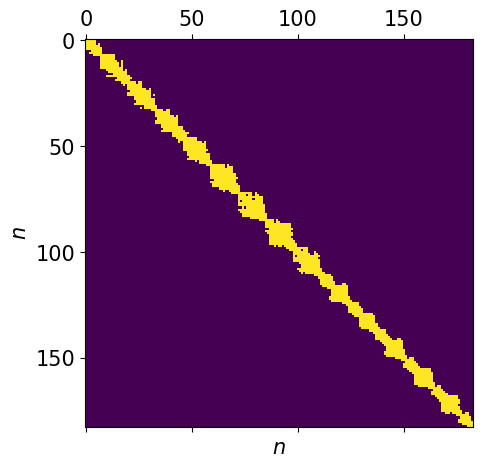

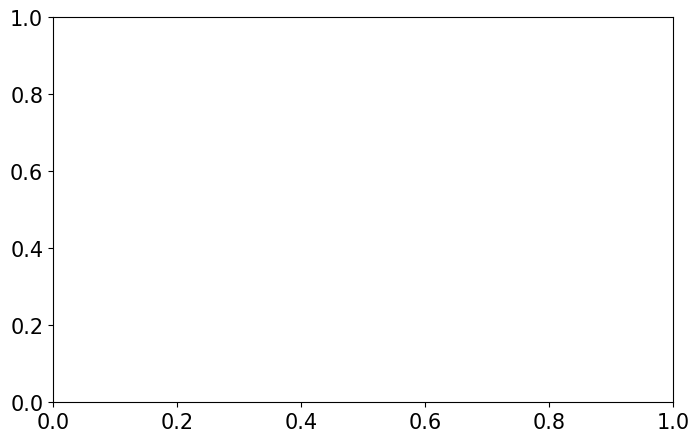

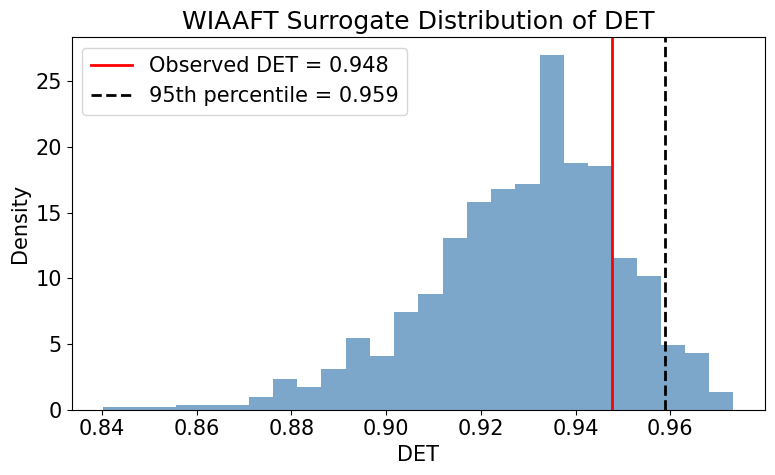

  1%|▍                                          | 1/100 [00:20<33:42, 20.43s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9477211796183129 
 Recurrence rate: 0.05001642330317418 
Threshold:1.0787999999998976 
 Laminarity:0.9862686567105298 
Shannon Entropy:2.3364977211758227 
Rank-order p-value (det):0.166 
Reject null (det) hypothesis:False

 
 

0
10
WIAAFT surrogate datasets generated


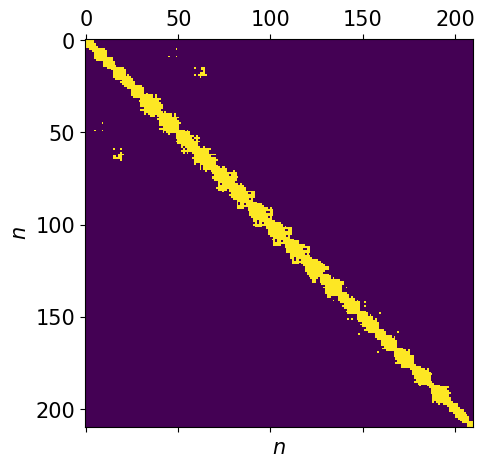

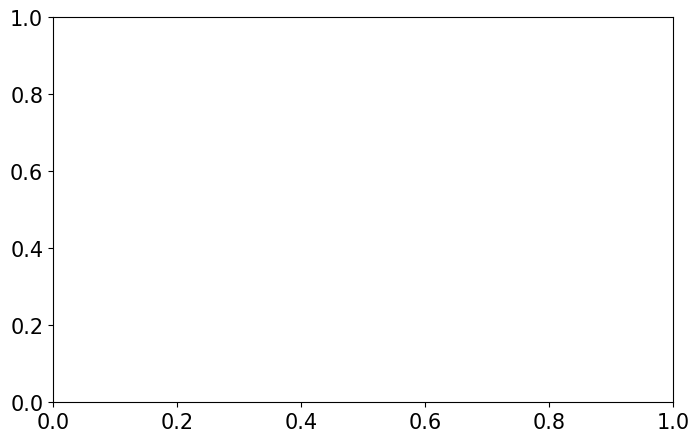

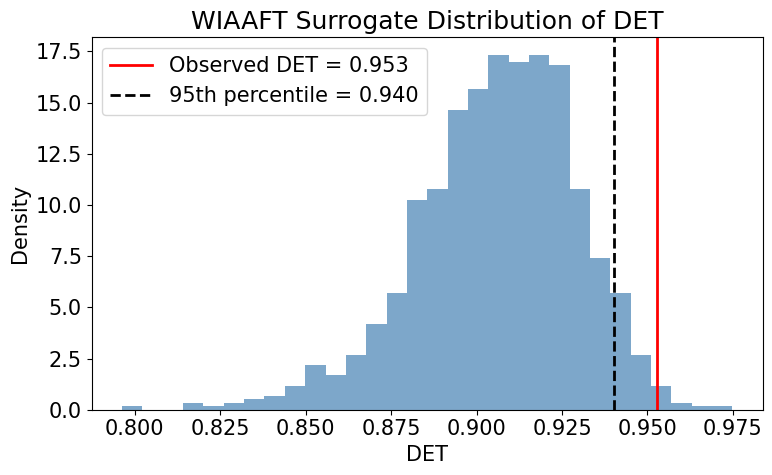

  2%|▊                                          | 2/100 [00:42<35:12, 21.56s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9529058116184724 
 Recurrence rate: 0.05002267573696145 
Threshold:0.9239999999999146 
 Laminarity:0.9669084315459343 
Shannon Entropy:1.930832191418118 
Rank-order p-value (det):0.009 
Reject null (det) hypothesis:True

 
 

1
10
WIAAFT surrogate datasets generated


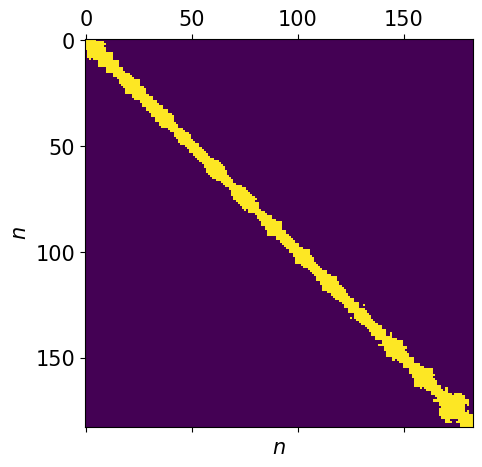

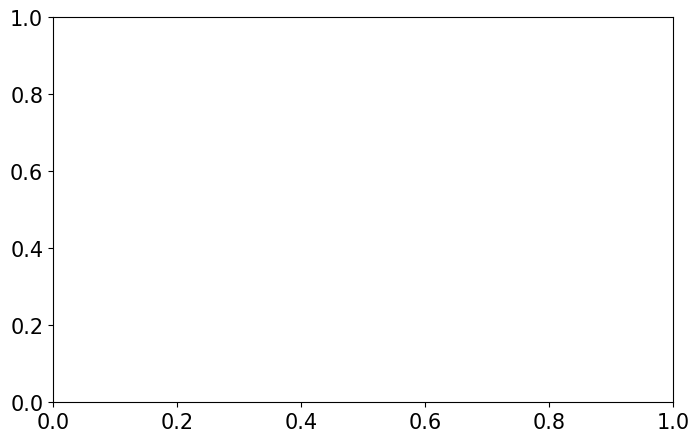

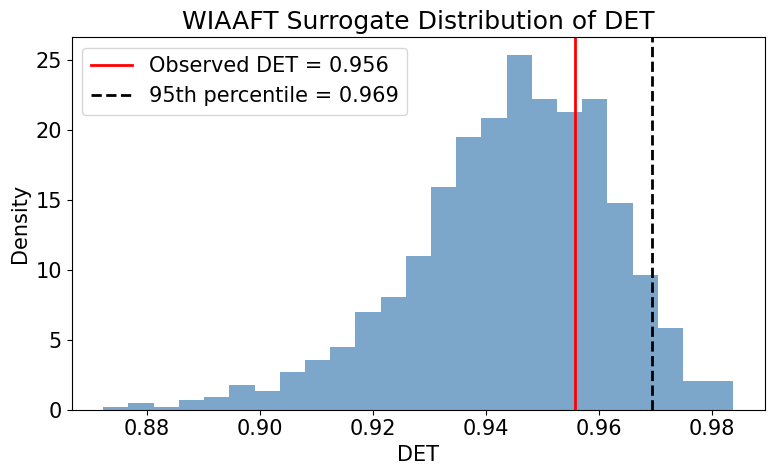

  3%|█▎                                         | 3/100 [01:04<35:08, 21.74s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9557640750606182 
 Recurrence rate: 0.05001642330317418 
Threshold:1.3548999999998672 
 Laminarity:0.9928358208895951 
Shannon Entropy:2.370285047501353 
Rank-order p-value (det):0.275 
Reject null (det) hypothesis:False

 
 

1
9
WIAAFT surrogate datasets generated


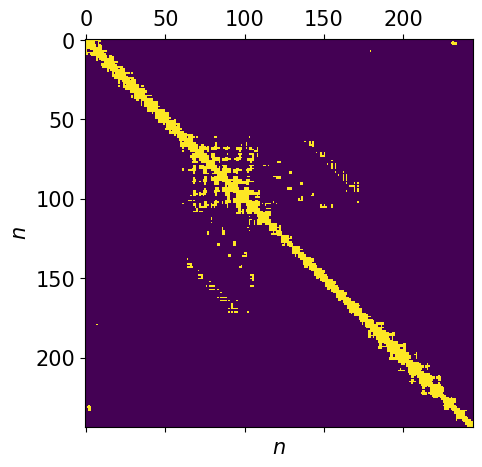

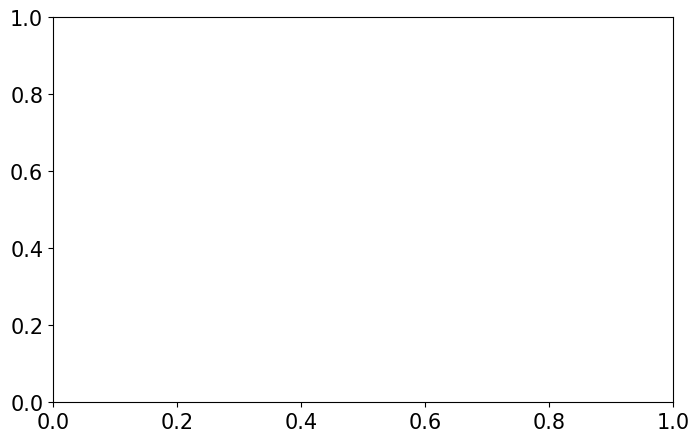

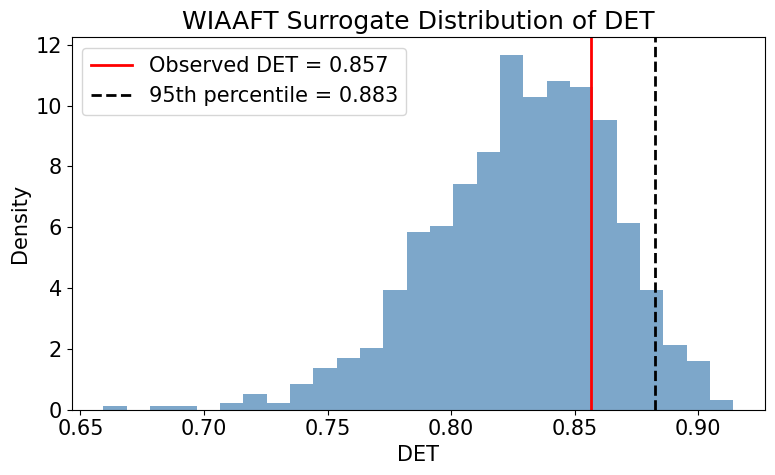

  4%|█▋                                         | 4/100 [01:33<38:55, 24.33s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8566203365001587 
 Recurrence rate: 0.0500201558720774 
Threshold:1.6337999999998365 
 Laminarity:0.9288112827369751 
Shannon Entropy:1.5072792417425143 
Rank-order p-value (det):0.23 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


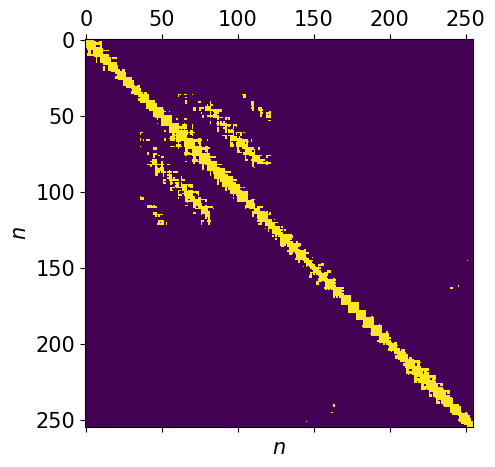

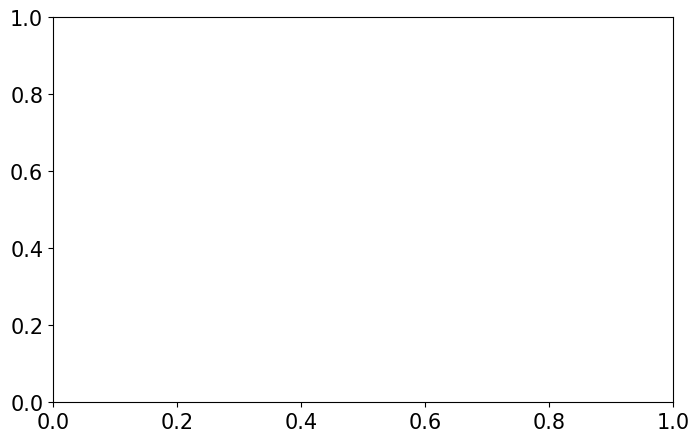

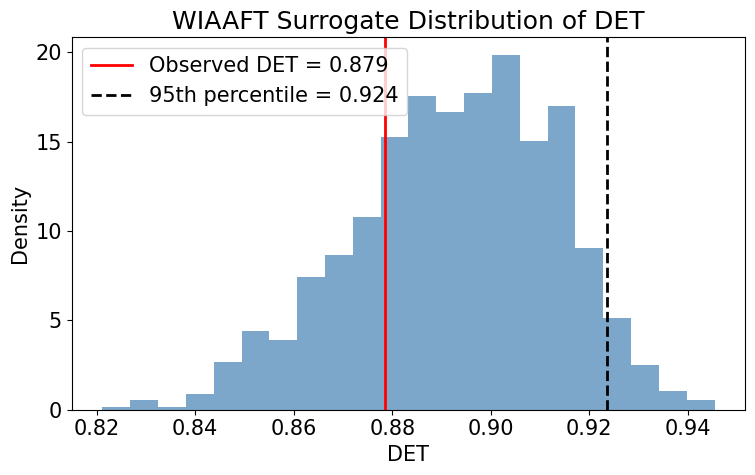

  5%|██▏                                        | 5/100 [02:01<40:57, 25.86s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8785857238129468 
 Recurrence rate: 0.050026912725874666 
Threshold:1.548399999999846 
 Laminarity:0.9332923455243367 
Shannon Entropy:1.3871518665543021 
Rank-order p-value (det):0.762 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


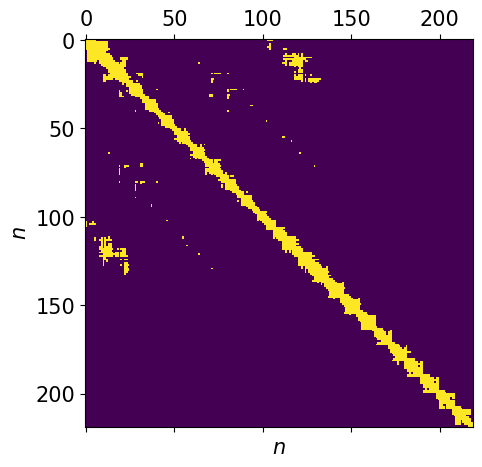

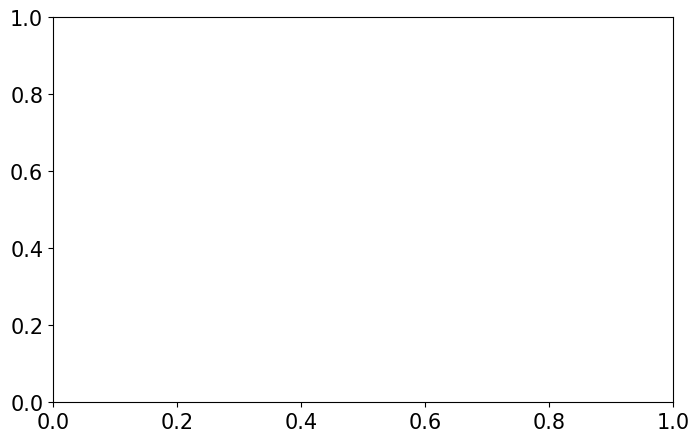

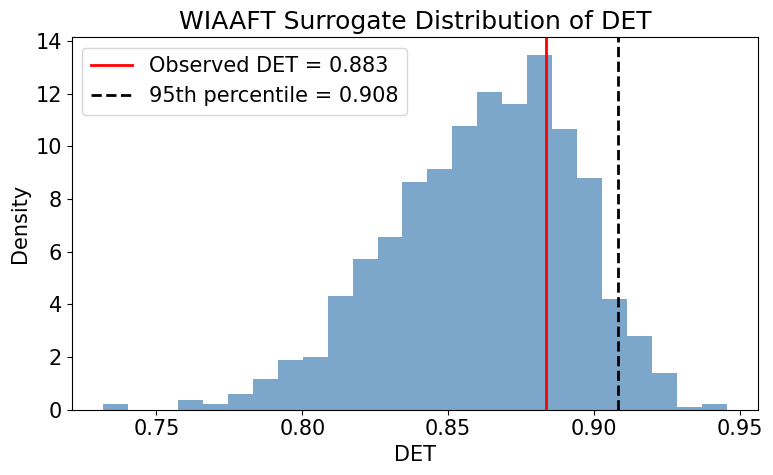

  6%|██▌                                        | 6/100 [02:25<39:12, 25.03s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8834862385280574 
 Recurrence rate: 0.05001980776047205 
Threshold:1.2239999999998816 
 Laminarity:0.9458107544770913 
Shannon Entropy:1.8555298296851799 
Rank-order p-value (det):0.27 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


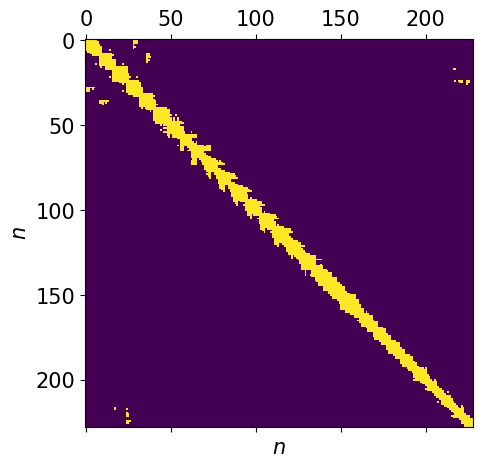

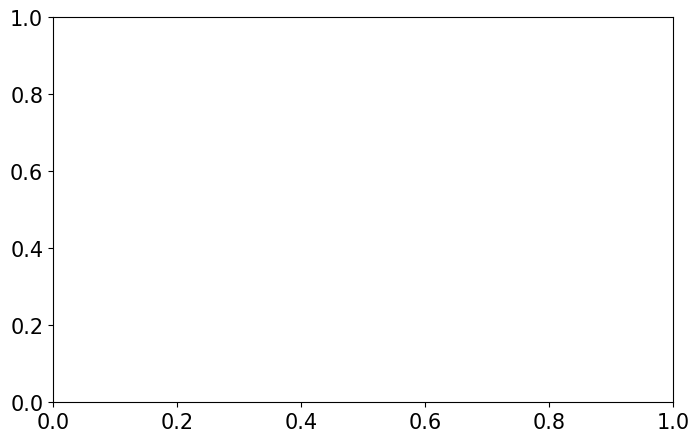

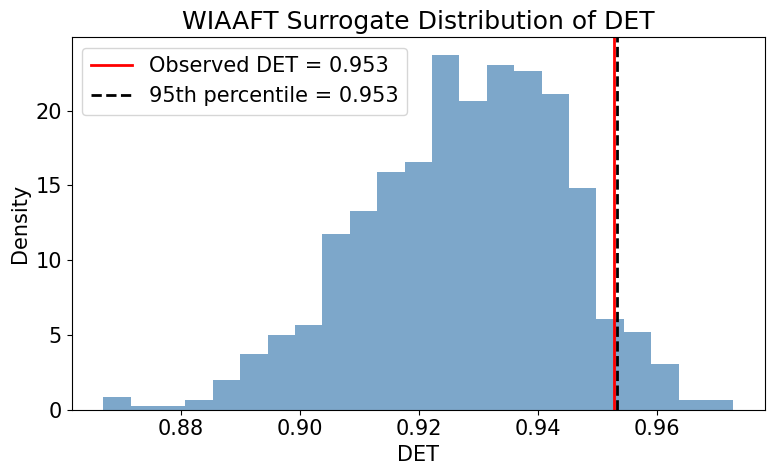

  7%|███                                        | 7/100 [02:48<37:55, 24.47s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9527824620533188 
 Recurrence rate: 0.05001538935056941 
Threshold:1.2808999999998754 
 Laminarity:0.9780769230731613 
Shannon Entropy:1.9527063269714997 
Rank-order p-value (det):0.056 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


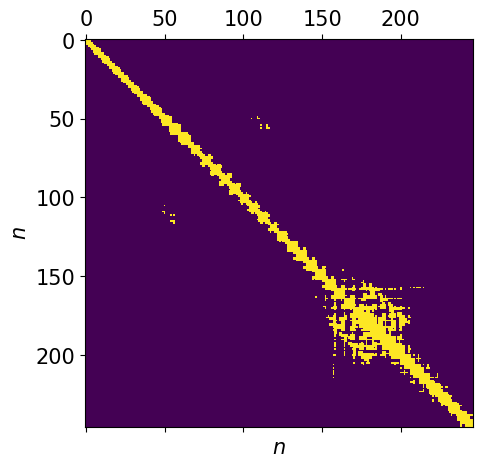

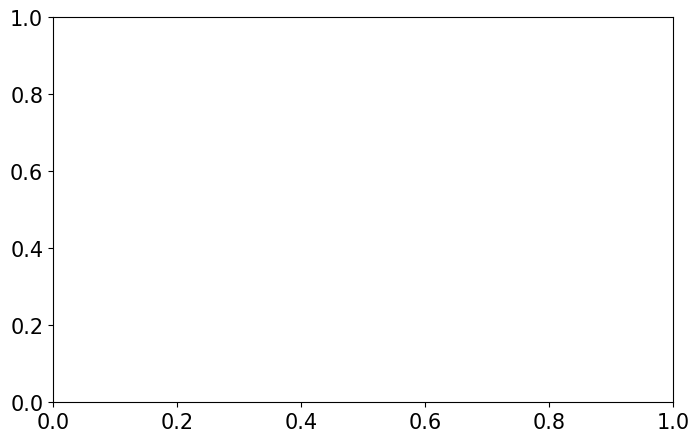

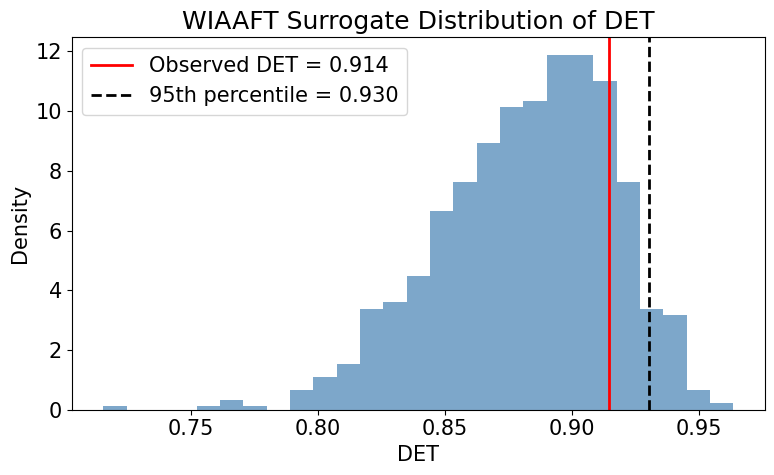

  8%|███▍                                       | 8/100 [03:16<39:12, 25.57s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.914388489205344 
 Recurrence rate: 0.05000330491109789 
Threshold:1.4585999999998558 
 Laminarity:0.9543952412394104 
Shannon Entropy:1.612234869031291 
Rank-order p-value (det):0.165 
Reject null (det) hypothesis:False

 
 

1
9
WIAAFT surrogate datasets generated


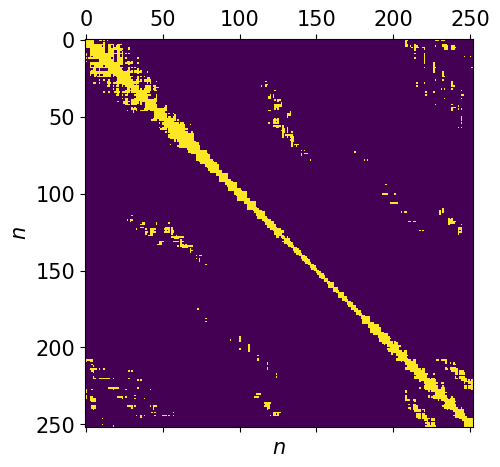

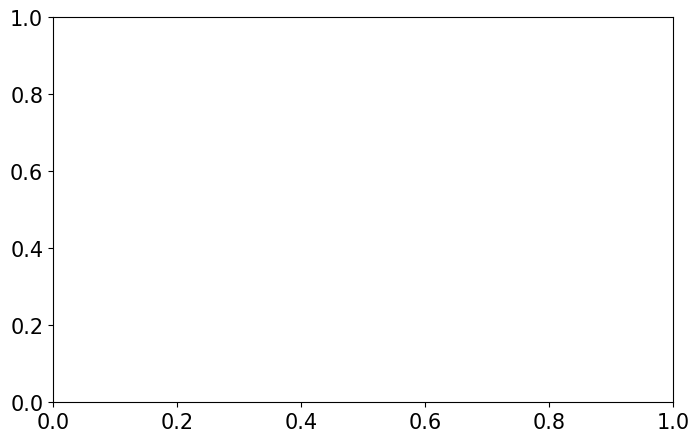

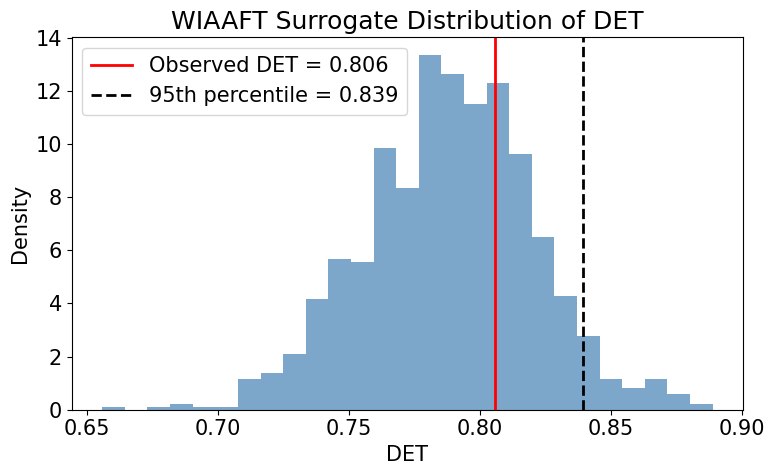

  9%|███▊                                       | 9/100 [03:49<42:34, 28.07s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8057455540328121 
 Recurrence rate: 0.05001259763164525 
Threshold:2.2294000000002803 
 Laminarity:0.8910579345060106 
Shannon Entropy:1.4261352845275779 
Rank-order p-value (det):0.301 
Reject null (det) hypothesis:False

 
 

1
7
WIAAFT surrogate datasets generated


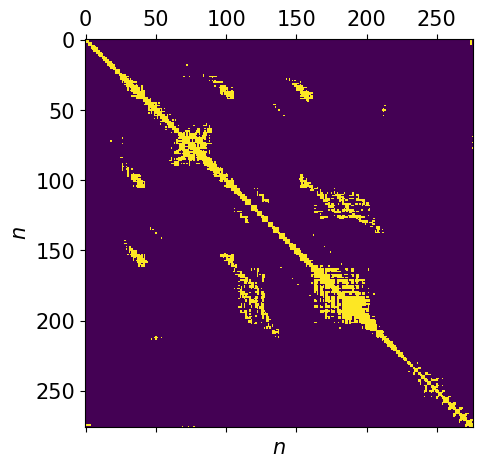

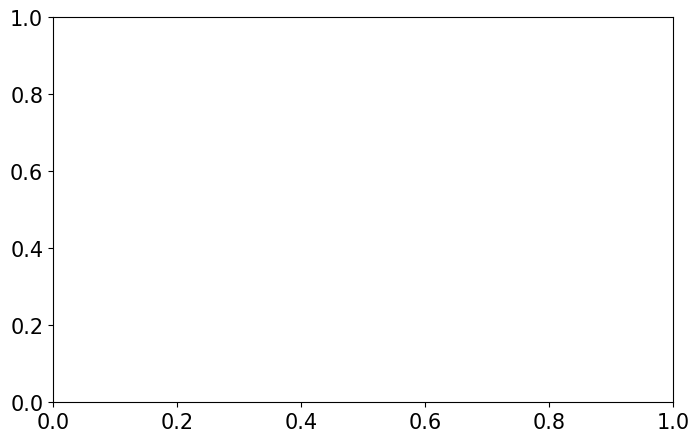

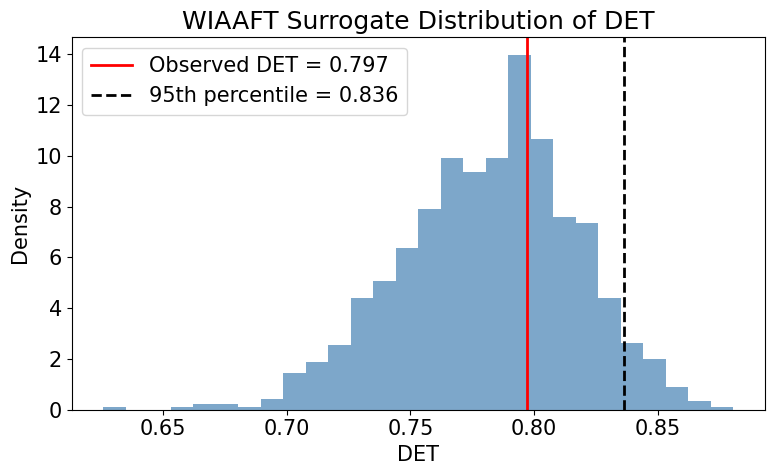

 10%|████▏                                     | 10/100 [04:14<40:35, 27.06s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.7969457013552123 
 Recurrence rate: 0.050042007981516486 
Threshold:1.157299999999889 
 Laminarity:0.8979538300081376 
Shannon Entropy:1.489907321661489 
Rank-order p-value (det):0.359 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


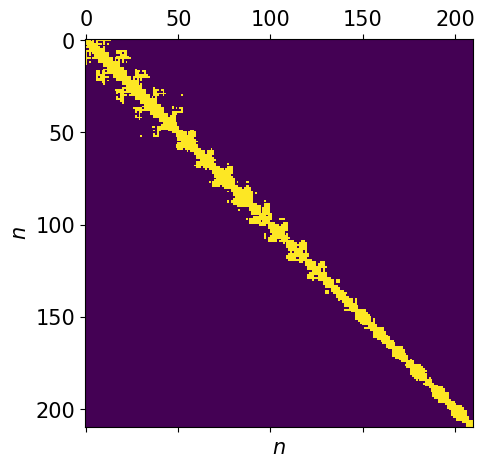

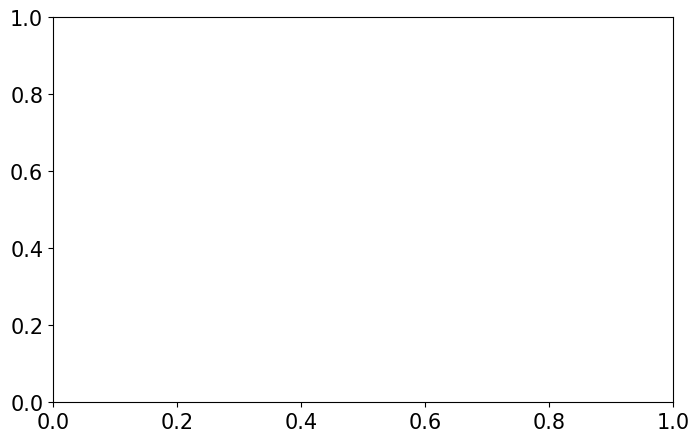

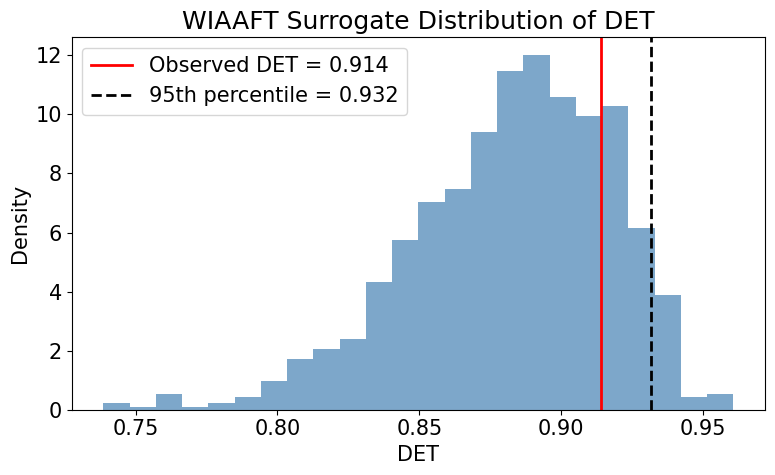

 11%|████▌                                     | 11/100 [04:35<37:15, 25.11s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.913827655306043 
 Recurrence rate: 0.05002267573696145 
Threshold:0.9944999999999068 
 Laminarity:0.9610154125069764 
Shannon Entropy:1.80356051590714 
Rank-order p-value (det):0.204 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


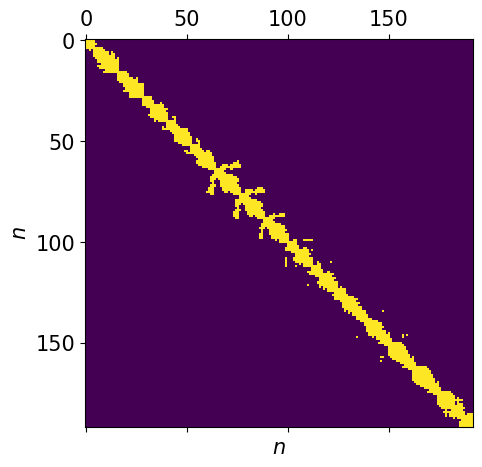

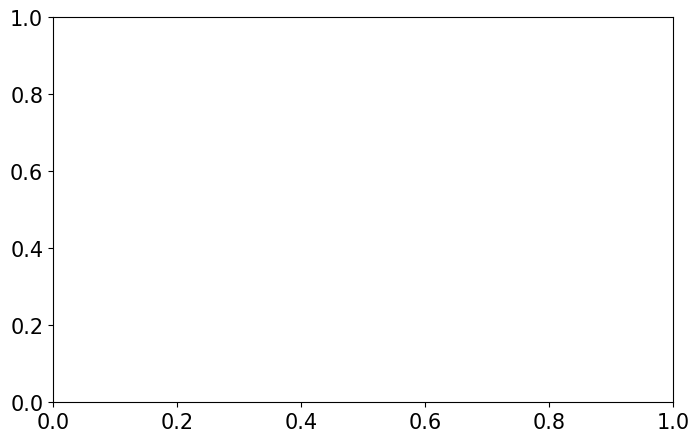

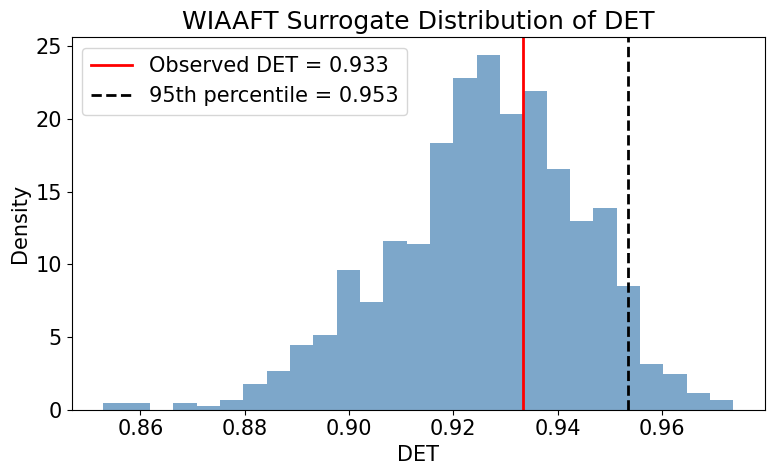

 12%|█████                                     | 12/100 [04:57<35:40, 24.32s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9334140435778849 
 Recurrence rate: 0.05002170138888889 
Threshold:1.557499999999845 
 Laminarity:0.9718004338342093 
Shannon Entropy:1.927986265420741 
Rank-order p-value (det):0.364 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


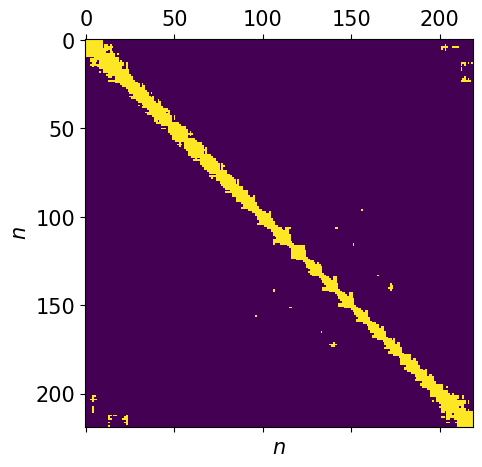

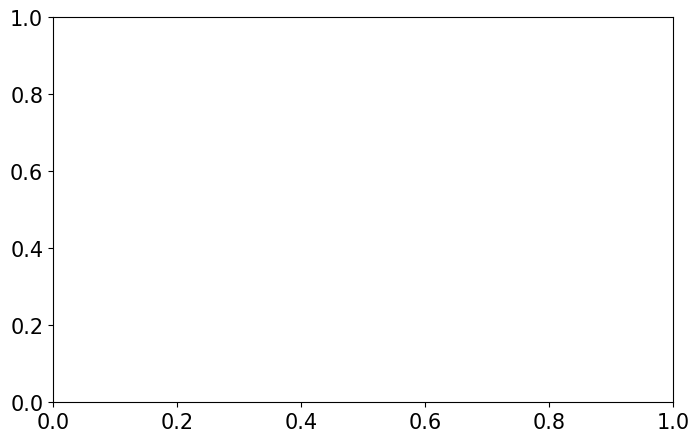

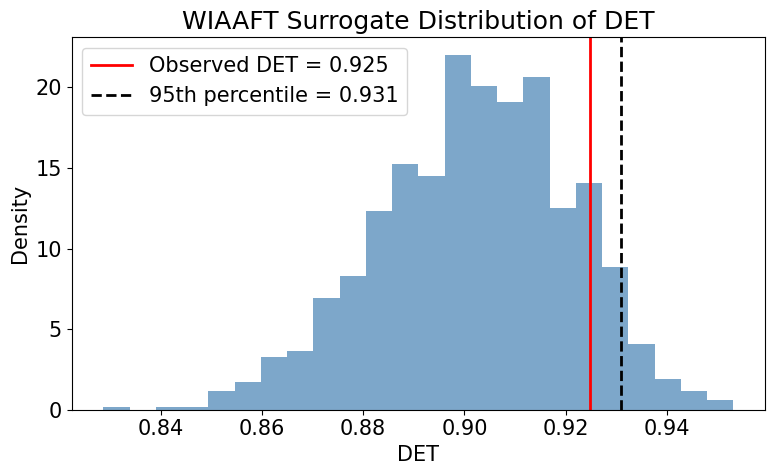

 13%|█████▍                                    | 13/100 [05:27<37:33, 25.90s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9247706421975929 
 Recurrence rate: 0.05001980776047205 
Threshold:2.0417999999998844 
 Laminarity:0.9654022509338667 
Shannon Entropy:1.9469540277030928 
Rank-order p-value (det):0.116 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


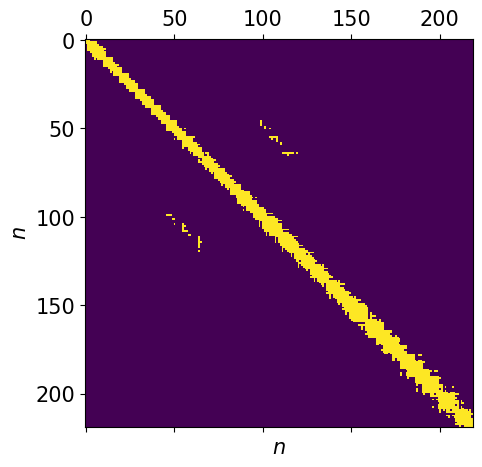

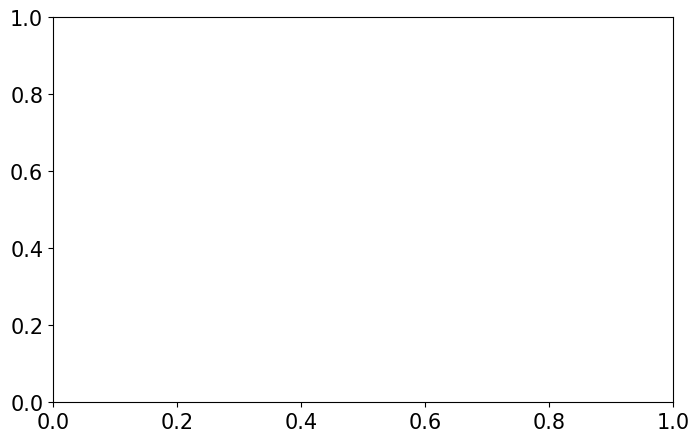

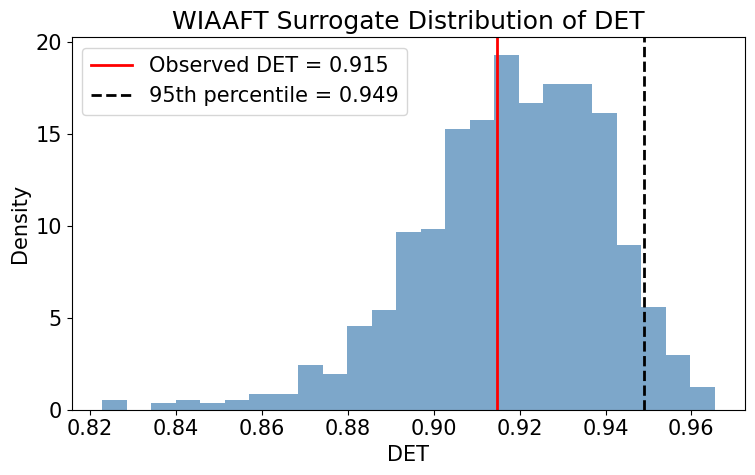

 14%|█████▉                                    | 14/100 [05:50<35:58, 25.09s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9146788990783731 
 Recurrence rate: 0.05001980776047205 
Threshold:1.2440999999998794 
 Laminarity:0.9599833263819926 
Shannon Entropy:2.0439693630008375 
Rank-order p-value (det):0.594 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


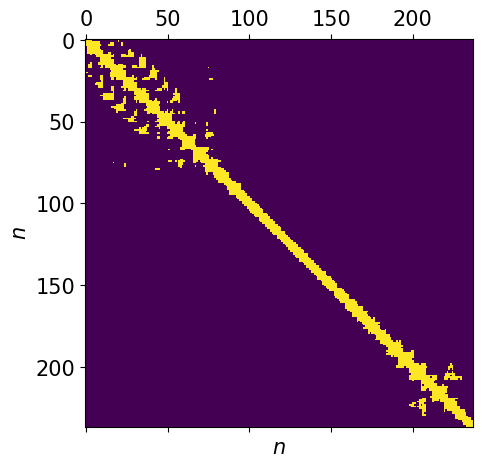

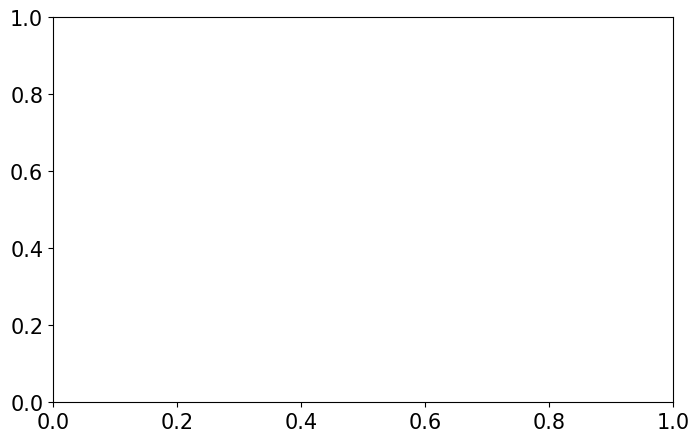

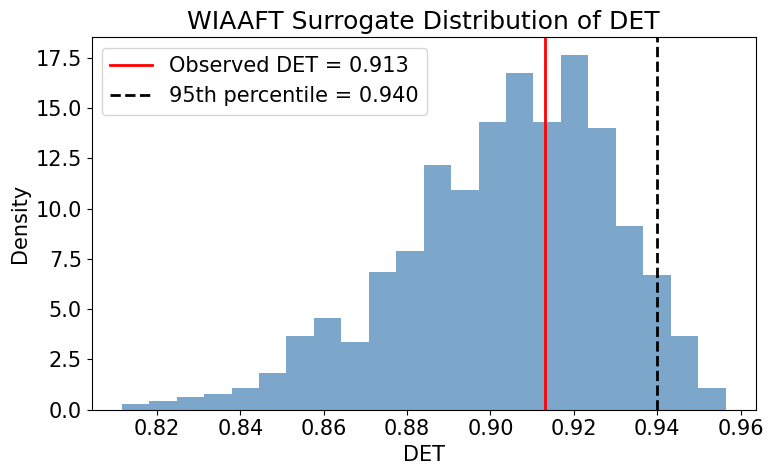

 15%|██████▎                                   | 15/100 [06:17<36:28, 25.75s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9129759129723661 
 Recurrence rate: 0.05004539870747209 
Threshold:1.6002999999998402 
 Laminarity:0.9690501600819316 
Shannon Entropy:1.58304974482323 
Rank-order p-value (det):0.406 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


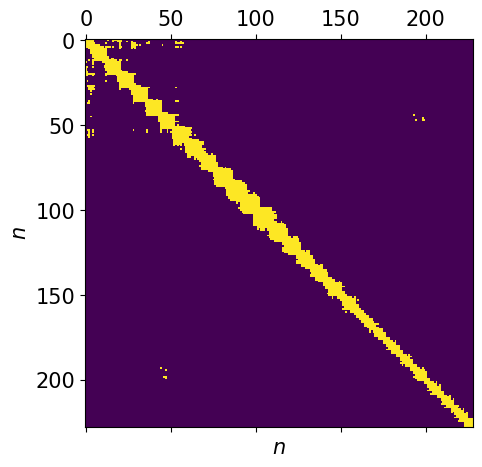

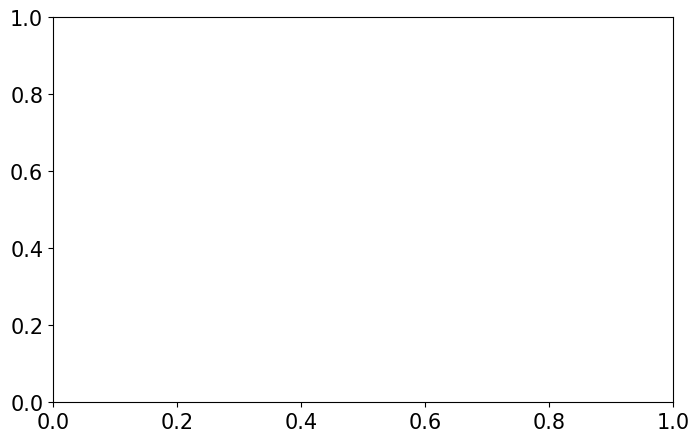

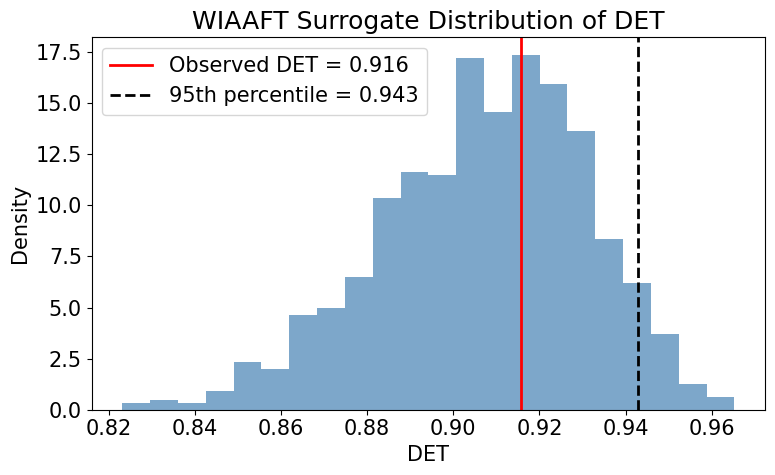

 16%|██████▋                                   | 16/100 [06:42<35:34, 25.41s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9156829679556675 
 Recurrence rate: 0.05001538935056941 
Threshold:1.3645999999998661 
 Laminarity:0.9661538461501302 
Shannon Entropy:2.034694172614102 
Rank-order p-value (det):0.397 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


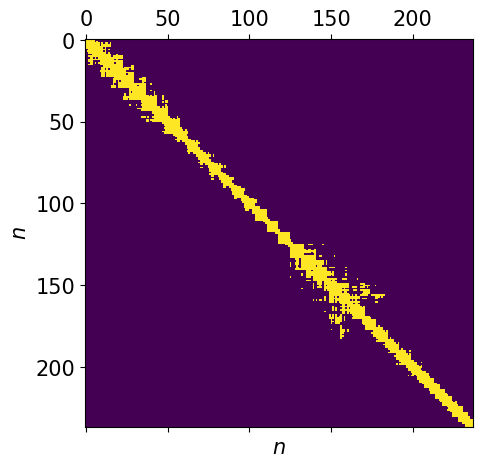

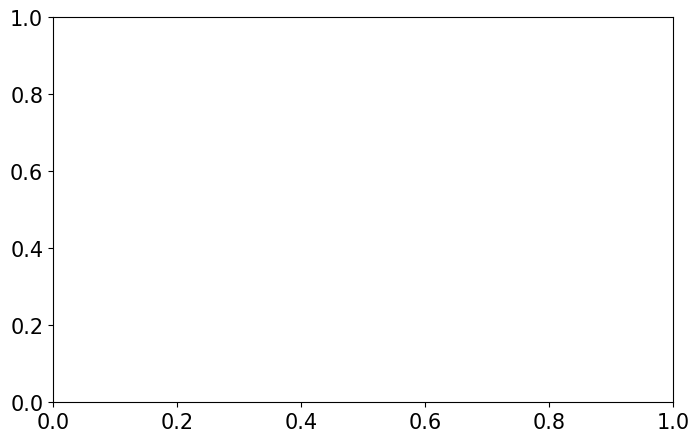

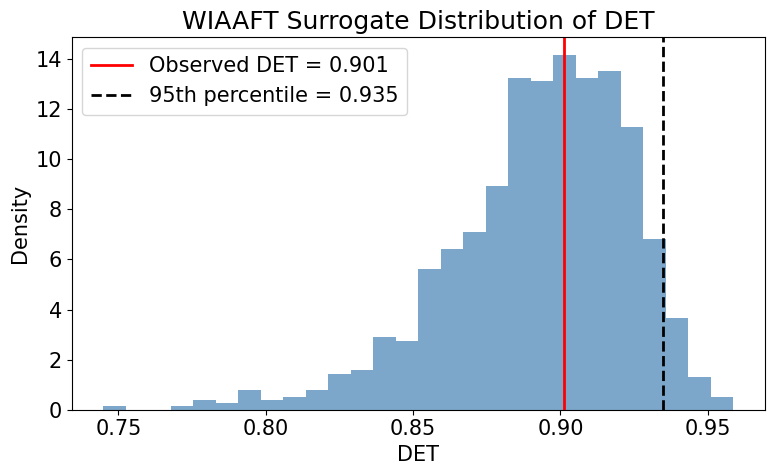

 17%|███████▏                                  | 17/100 [07:05<34:02, 24.60s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.901244167959171 
 Recurrence rate: 0.050009791878082216 
Threshold:0.801999999999928 
 Laminarity:0.9547881808438776 
Shannon Entropy:1.776108097779731 
Rank-order p-value (det):0.434 
Reject null (det) hypothesis:False

 
 

1
8
WIAAFT surrogate datasets generated


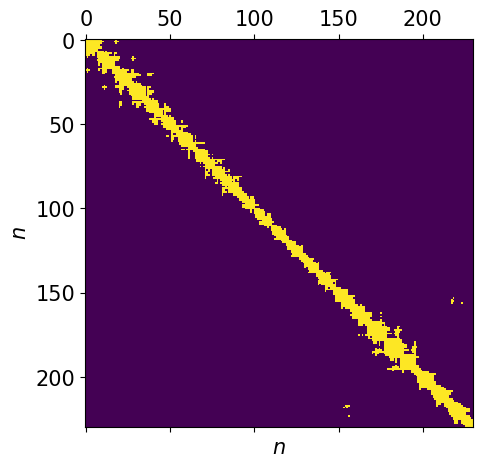

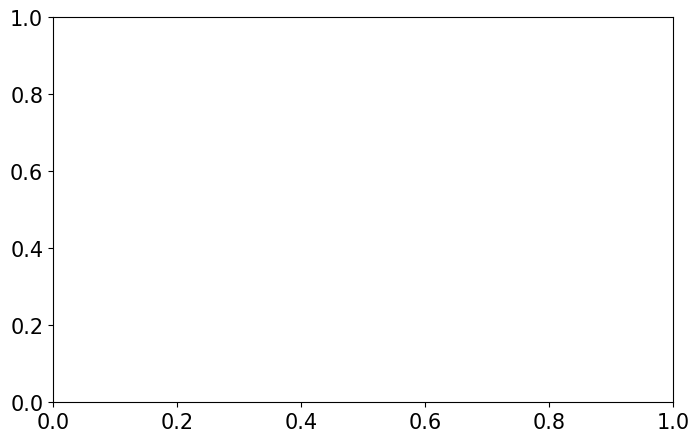

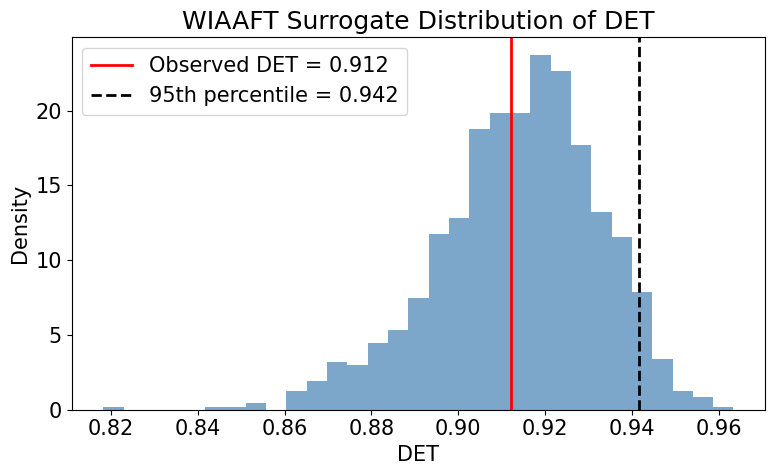

 18%|███████▌                                  | 18/100 [07:27<32:29, 23.78s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9122516556253633 
 Recurrence rate: 0.05001890359168242 
Threshold:1.0560999999999001 
 Laminarity:0.9588057445164067 
Shannon Entropy:2.0015670616171426 
Rank-order p-value (det):0.567 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


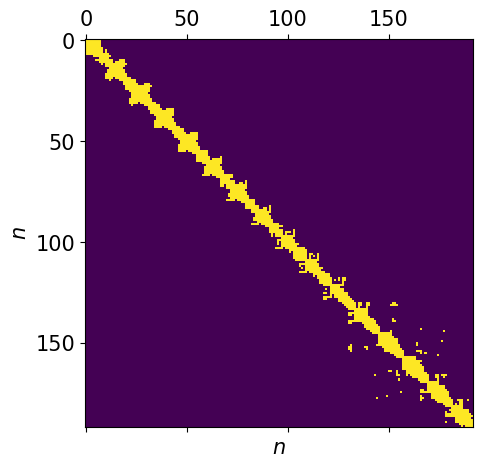

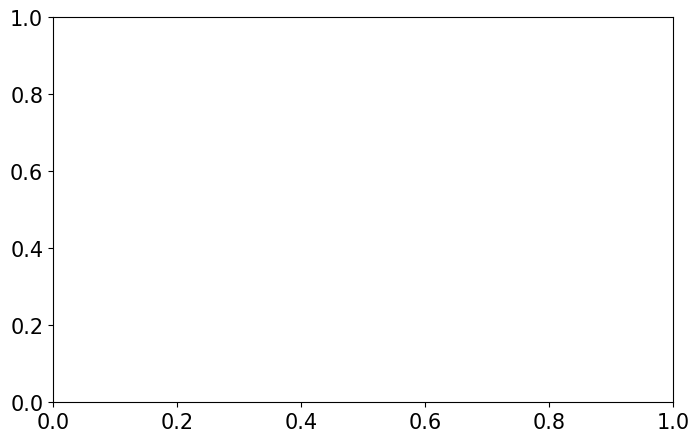

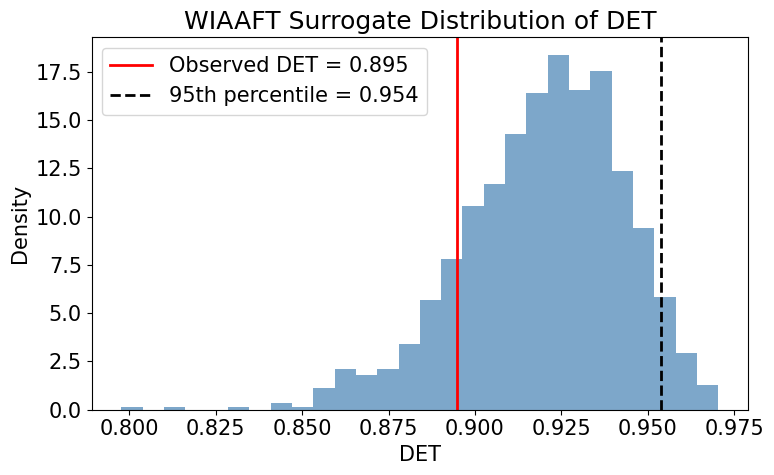

 19%|███████▉                                  | 19/100 [07:51<32:26, 24.03s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8946731234812672 
 Recurrence rate: 0.05002170138888889 
Threshold:1.847999999999813 
 Laminarity:0.9636659435956417 
Shannon Entropy:1.9734681718651907 
Rank-order p-value (det):0.863 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


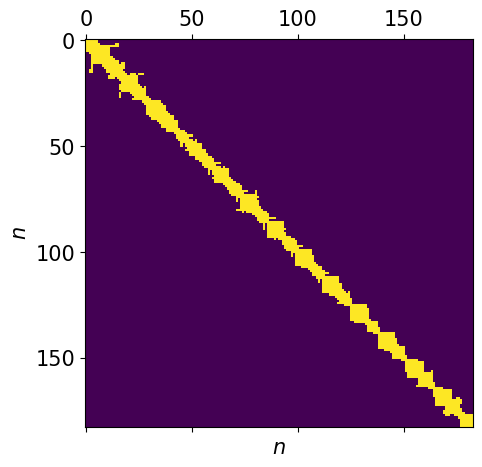

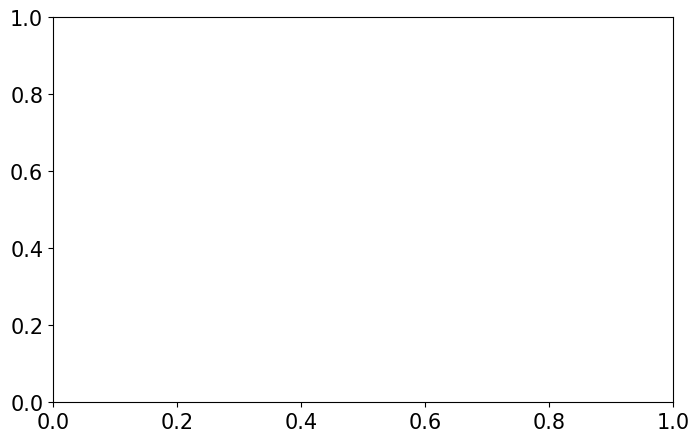

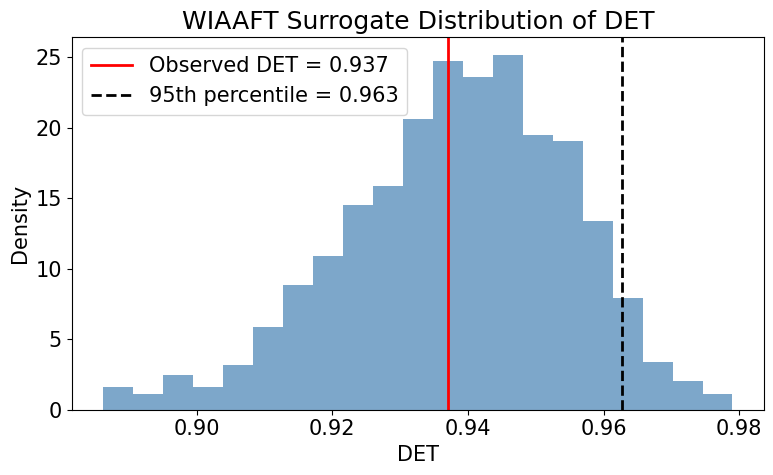

 20%|████████▍                                 | 20/100 [08:15<32:04, 24.06s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9369973190285724 
 Recurrence rate: 0.05001642330317418 
Threshold:1.8174999999998163 
 Laminarity:0.9838805970090515 
Shannon Entropy:2.1218814454399673 
Rank-order p-value (det):0.57 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


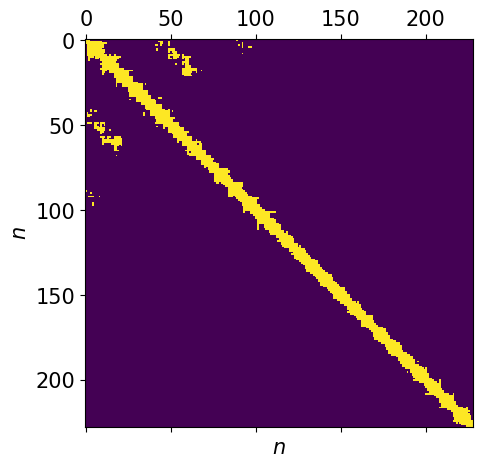

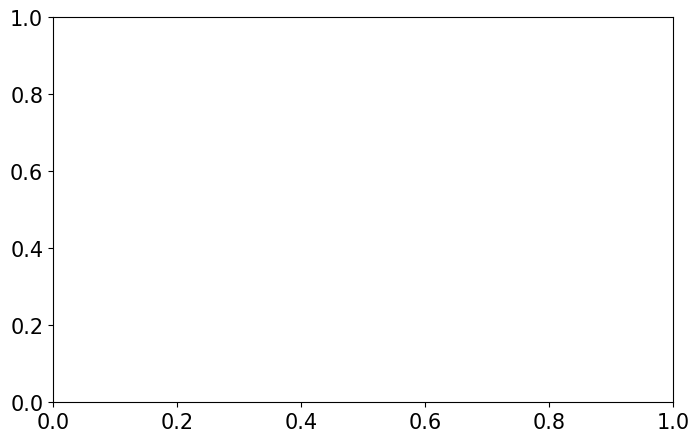

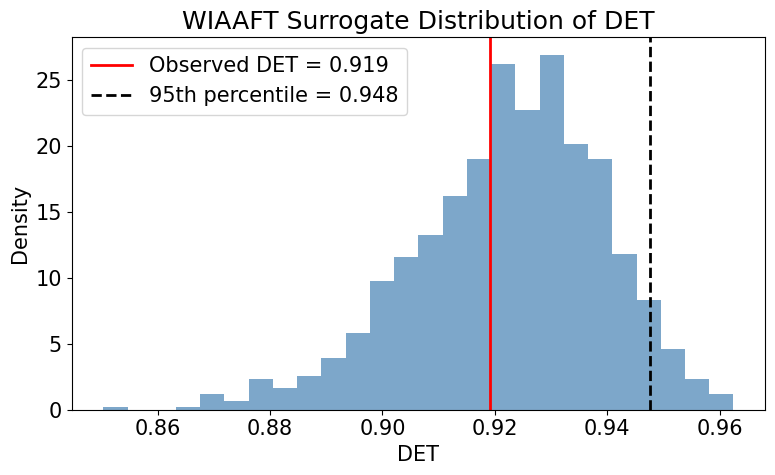

 21%|████████▊                                 | 21/100 [08:42<32:31, 24.70s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9190556492372721 
 Recurrence rate: 0.05001538935056941 
Threshold:1.6126999999998388 
 Laminarity:0.9723076923039528 
Shannon Entropy:1.9027972383807812 
Rank-order p-value (det):0.622 
Reject null (det) hypothesis:False

 
 

1
7
WIAAFT surrogate datasets generated


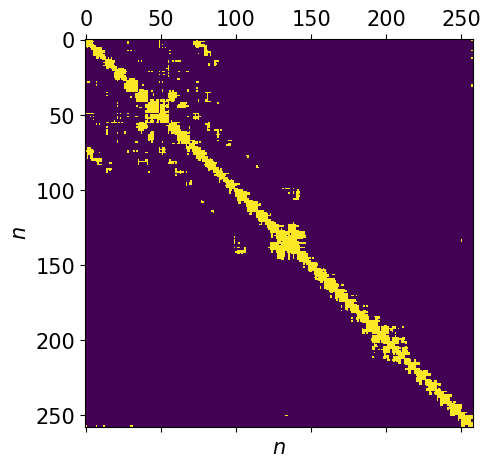

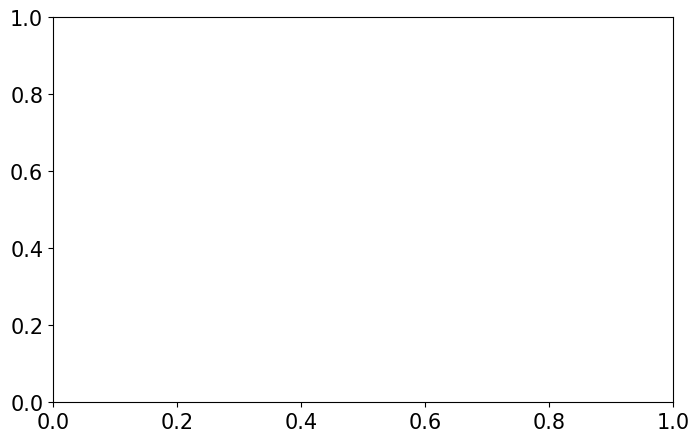

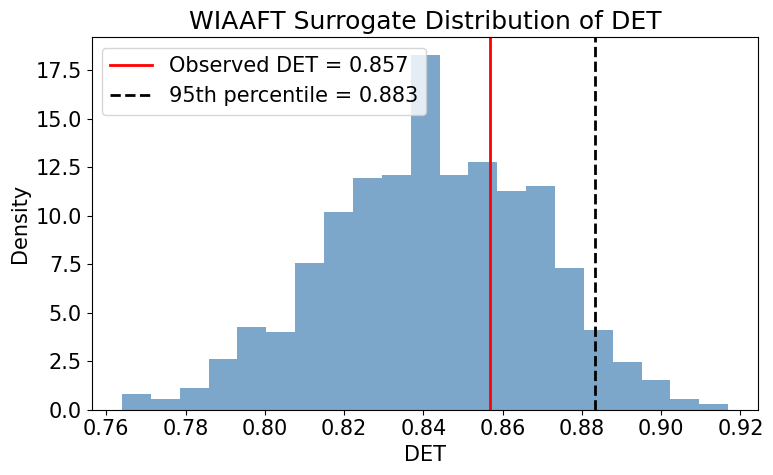

 22%|█████████▏                                | 22/100 [09:06<31:57, 24.59s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8567708333305444 
 Recurrence rate: 0.050027041644131964 
Threshold:1.1610999999998886 
 Laminarity:0.920120120117357 
Shannon Entropy:1.856351678664327 
Rank-order p-value (det):0.308 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


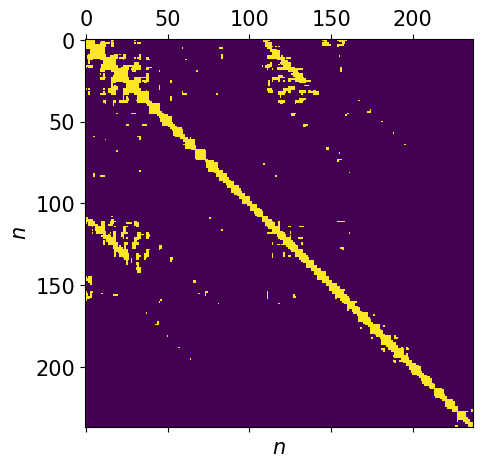

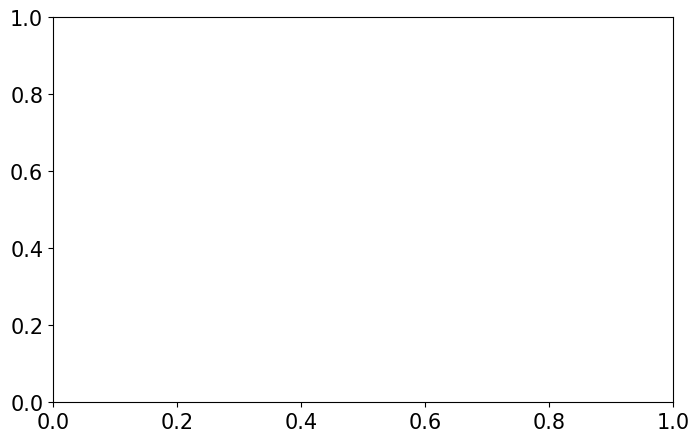

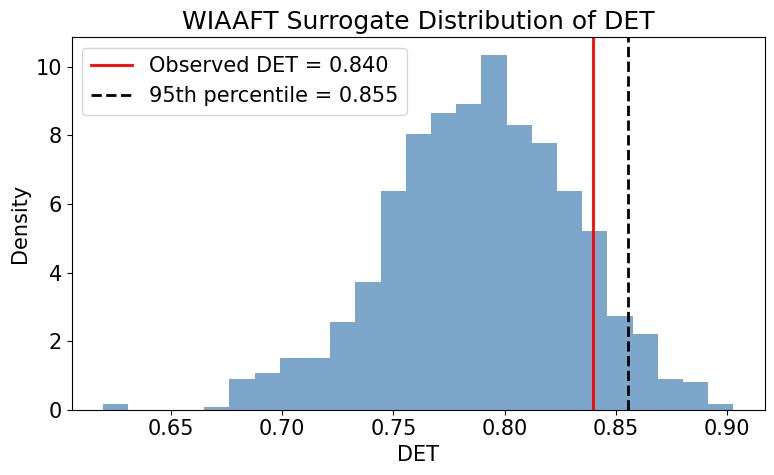

 23%|█████████▋                                | 23/100 [09:35<33:23, 26.02s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8398133748023335 
 Recurrence rate: 0.050009791878082216 
Threshold:1.928299999999804 
 Laminarity:0.9341402634356207 
Shannon Entropy:1.4402158862851613 
Rank-order p-value (det):0.111 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


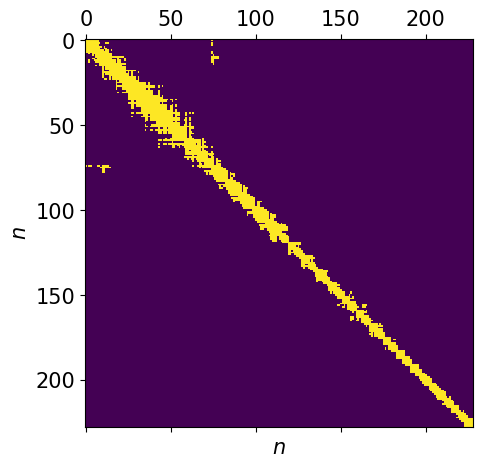

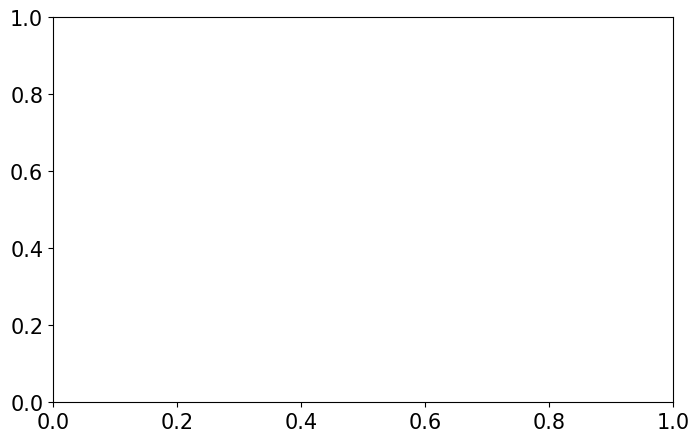

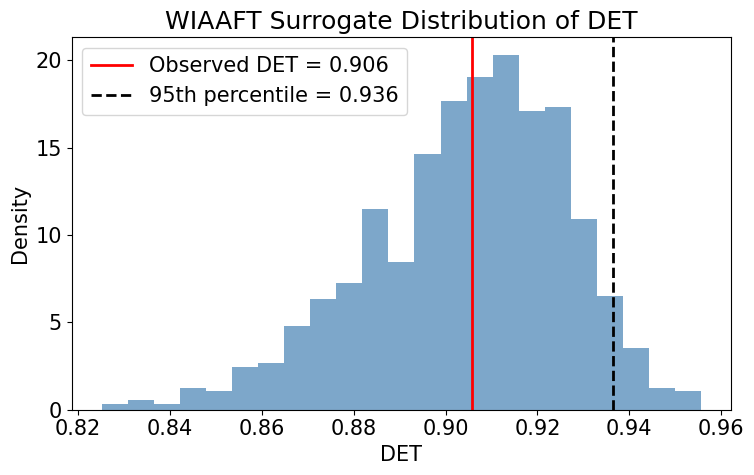

 24%|██████████                                | 24/100 [09:59<32:02, 25.30s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9056444818832956 
 Recurrence rate: 0.05005386272699292 
Threshold:1.2444999999998794 
 Laminarity:0.9500384319717524 
Shannon Entropy:1.728829152057188 
Rank-order p-value (det):0.53 
Reject null (det) hypothesis:False

 
 

1
9
WIAAFT surrogate datasets generated


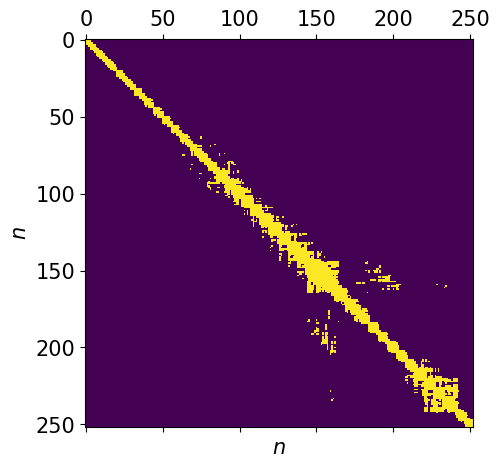

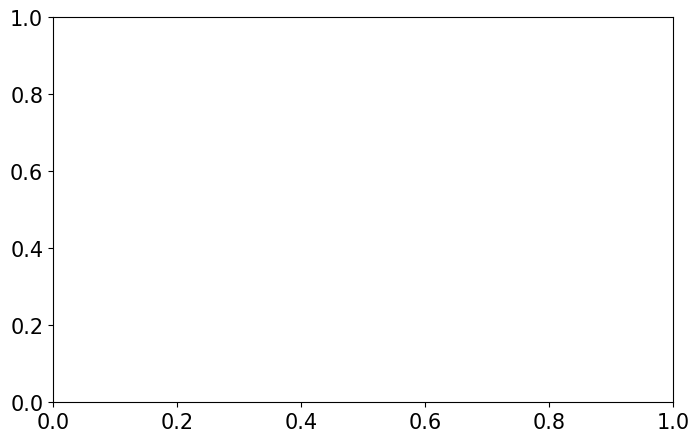

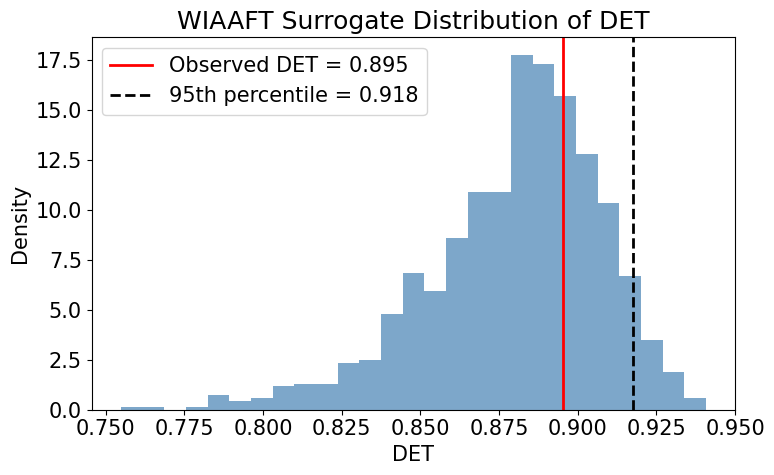

 25%|██████████▌                               | 25/100 [10:23<31:03, 24.85s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8954203691015195 
 Recurrence rate: 0.050044091710758375 
Threshold:1.1054999999998947 
 Laminarity:0.9465072372531577 
Shannon Entropy:1.7342733156173245 
Rank-order p-value (det):0.309 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


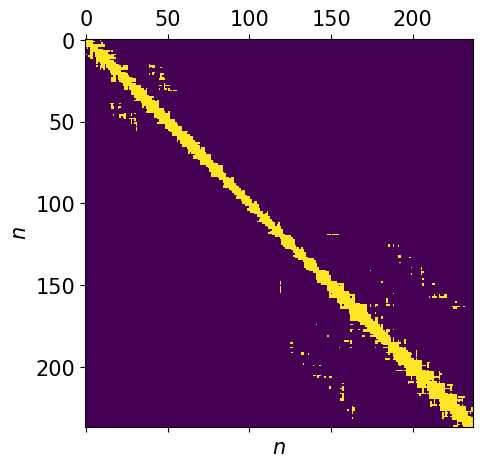

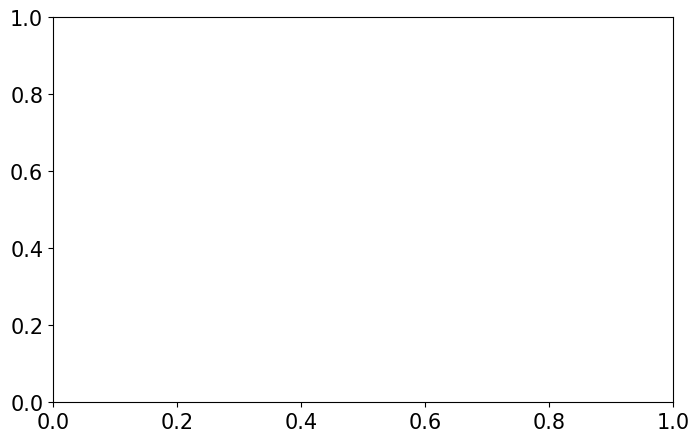

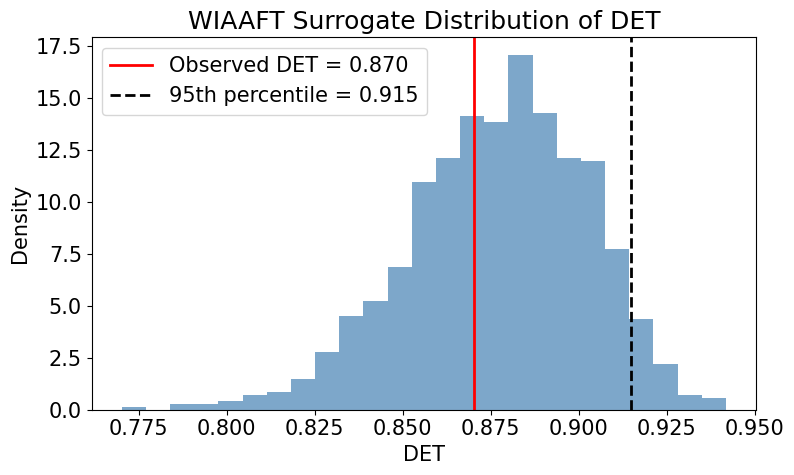

 26%|██████████▉                               | 26/100 [10:48<30:39, 24.86s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8701399688924178 
 Recurrence rate: 0.050009791878082216 
Threshold:1.347099999999868 
 Laminarity:0.9394802420756871 
Shannon Entropy:1.803430335670706 
Rank-order p-value (det):0.622 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


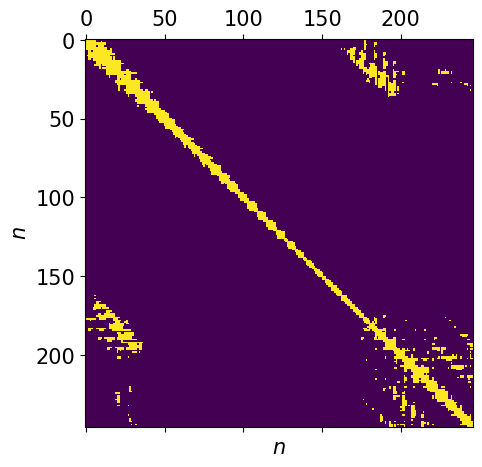

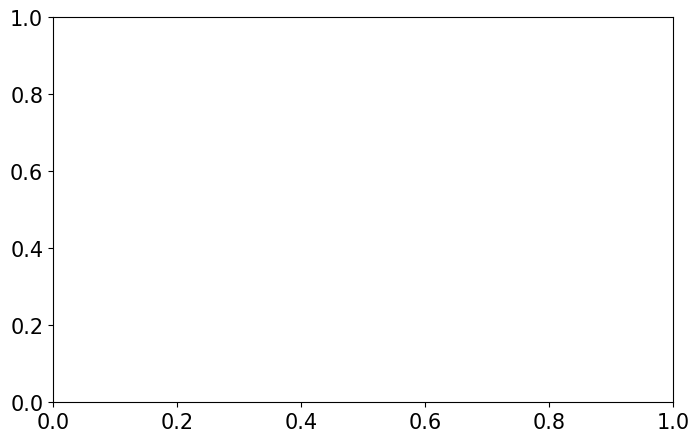

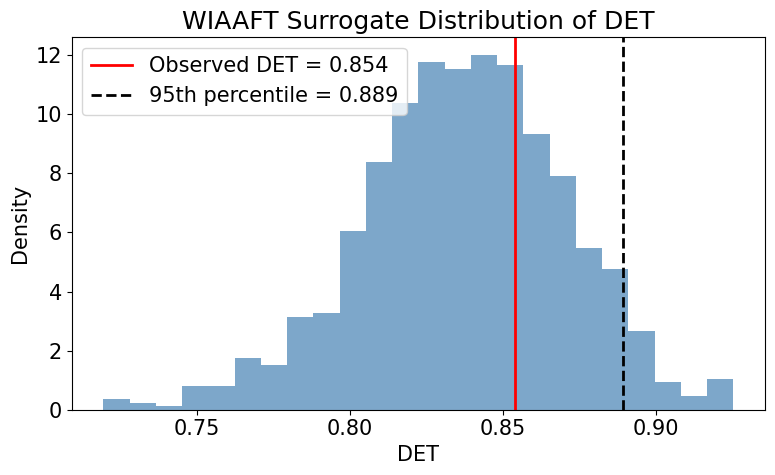

 27%|███████████▎                              | 27/100 [11:15<31:20, 25.76s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8539568345293024 
 Recurrence rate: 0.05000330491109789 
Threshold:1.6552999999998341 
 Laminarity:0.9348975545243394 
Shannon Entropy:1.5620008788909643 
Rank-order p-value (det):0.315 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


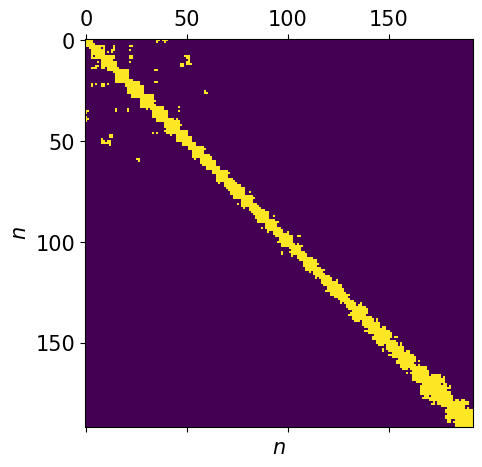

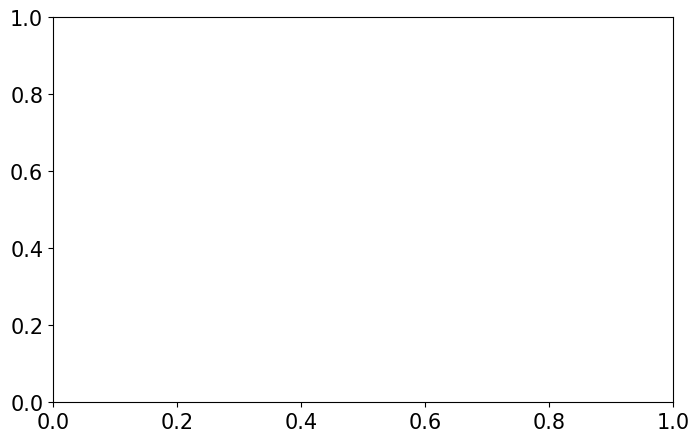

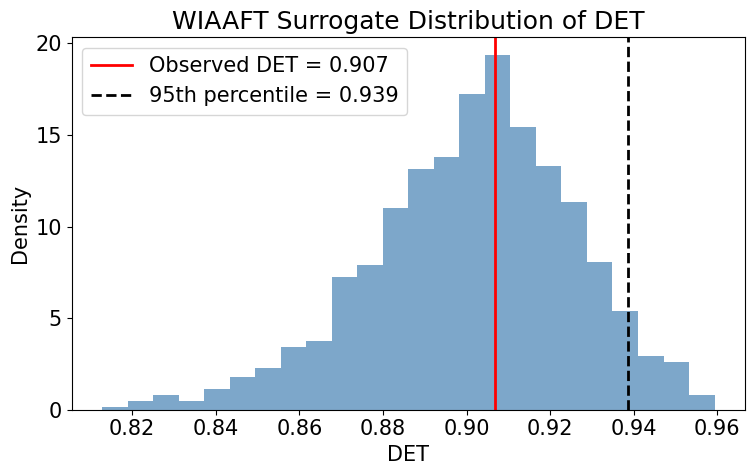

 28%|███████████▊                              | 28/100 [11:39<30:12, 25.17s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9067796610114602 
 Recurrence rate: 0.05002170138888889 
Threshold:1.5944999999998408 
 Laminarity:0.9647505422941175 
Shannon Entropy:1.740470970125533 
Rank-order p-value (det):0.443 
Reject null (det) hypothesis:False

 
 

1
9
WIAAFT surrogate datasets generated


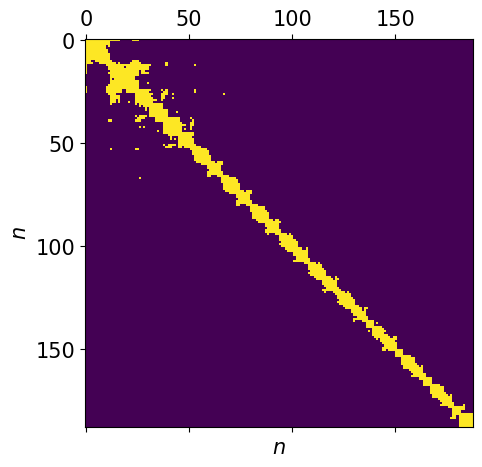

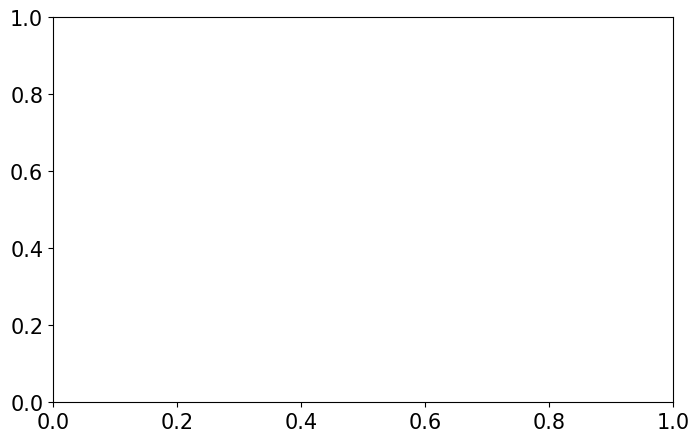

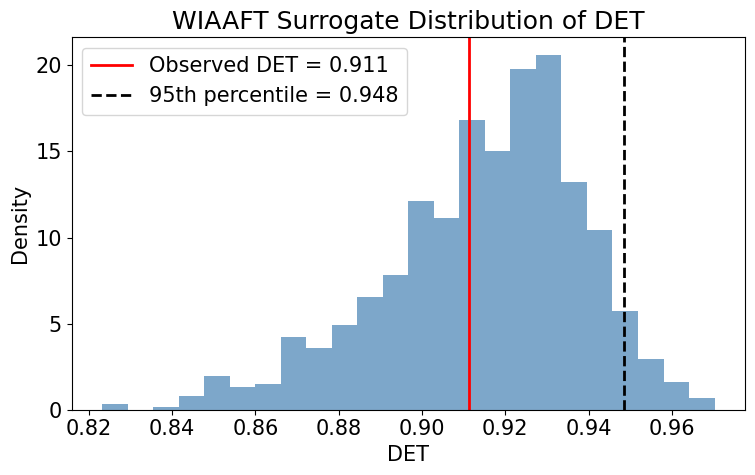

 29%|████████████▏                             | 29/100 [12:02<28:52, 24.40s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.911392405057523 
 Recurrence rate: 0.05002263467632413 
Threshold:1.5723999999998433 
 Laminarity:0.9649321266913748 
Shannon Entropy:2.0055515033168847 
Rank-order p-value (det):0.617 
Reject null (det) hypothesis:False

 
 

1
6
WIAAFT surrogate datasets generated


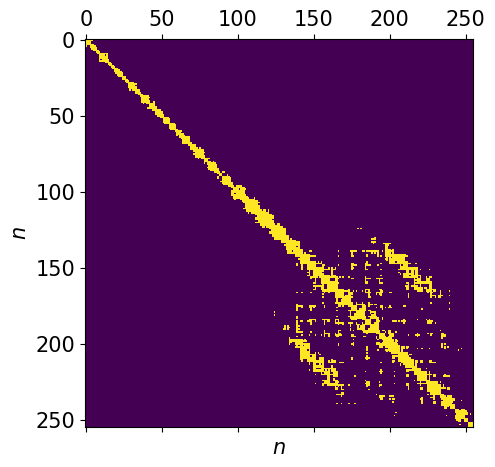

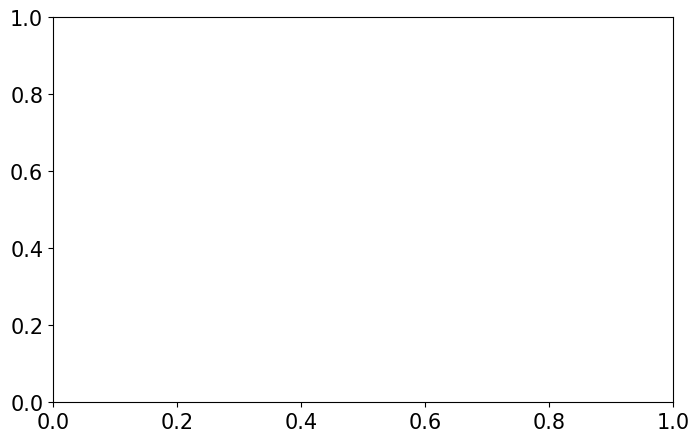

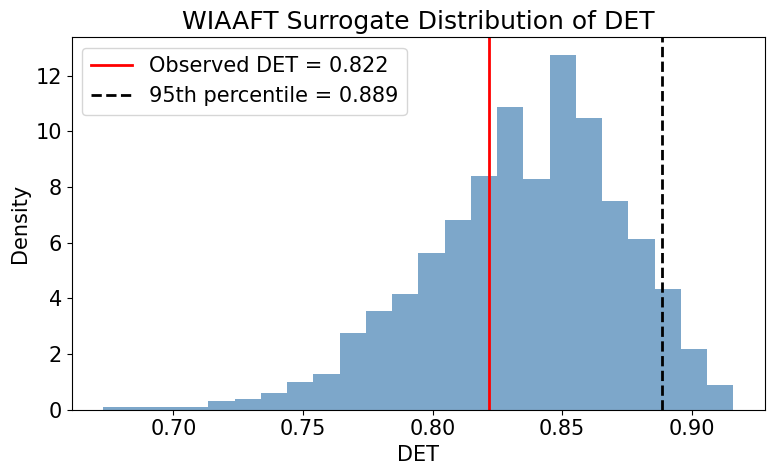

 30%|████████████▌                             | 30/100 [12:22<27:05, 23.22s/it]

RQA  ar1 Embedding dimensions:6 
 DET of original:0.8218812541667049 
 Recurrence rate: 0.050026912725874666 
Threshold:0.6889999999999404 
 Laminarity:0.893636643095931 
Shannon Entropy:1.6277742074369677 
Rank-order p-value (det):0.669 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


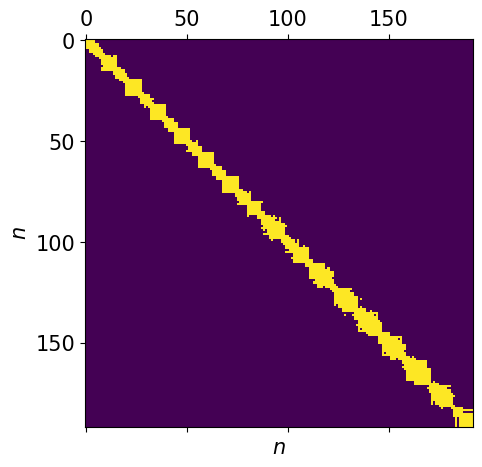

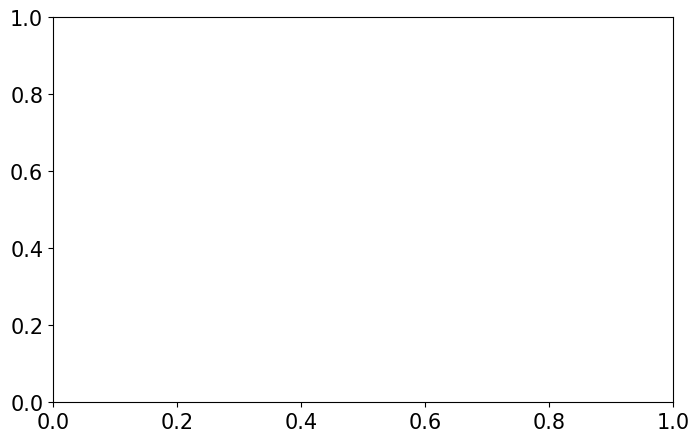

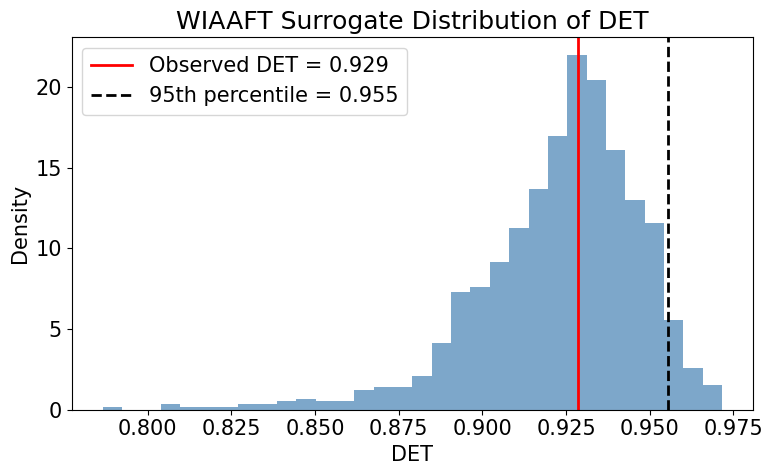

 31%|█████████████                             | 31/100 [12:45<26:38, 23.16s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9285714285658078 
 Recurrence rate: 0.05002170138888889 
Threshold:1.566199999999844 
 Laminarity:0.9826464208189661 
Shannon Entropy:2.2053471951591694 
Rank-order p-value (det):0.477 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


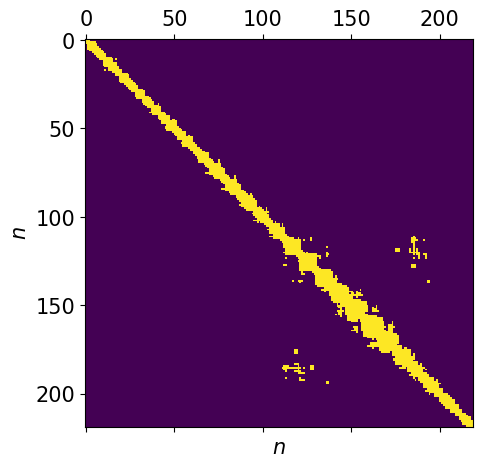

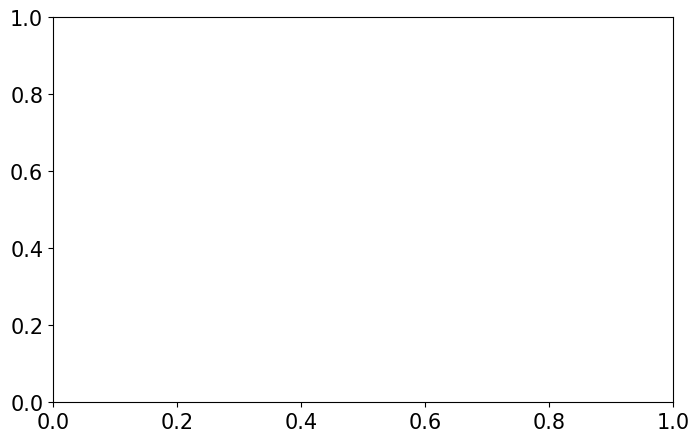

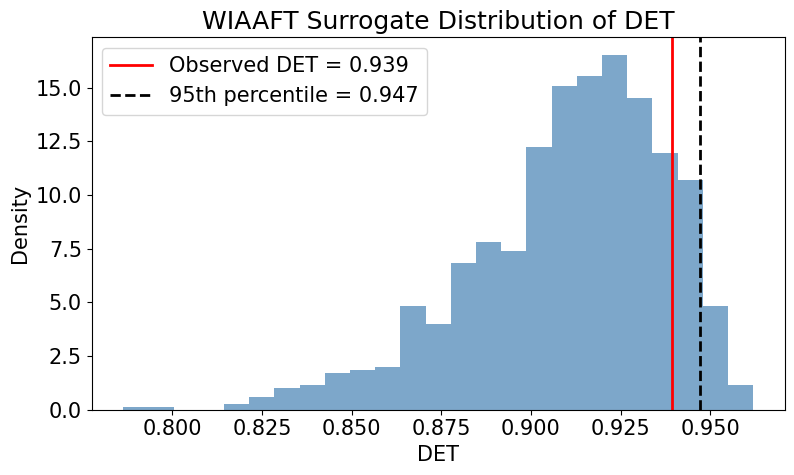

 32%|█████████████▍                            | 32/100 [13:08<26:10, 23.09s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9394495412800943 
 Recurrence rate: 0.05001980776047205 
Threshold:1.1459999999998902 
 Laminarity:0.9674864526845874 
Shannon Entropy:1.9582451971317087 
Rank-order p-value (det):0.128 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


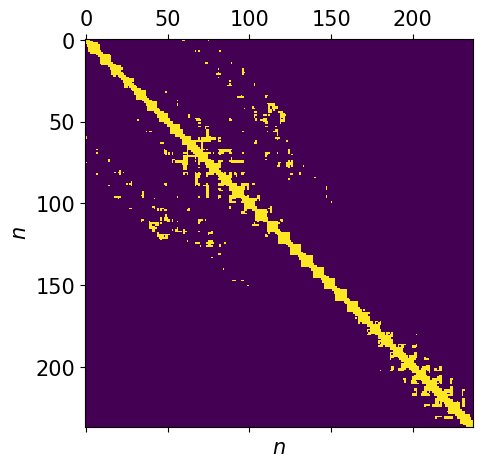

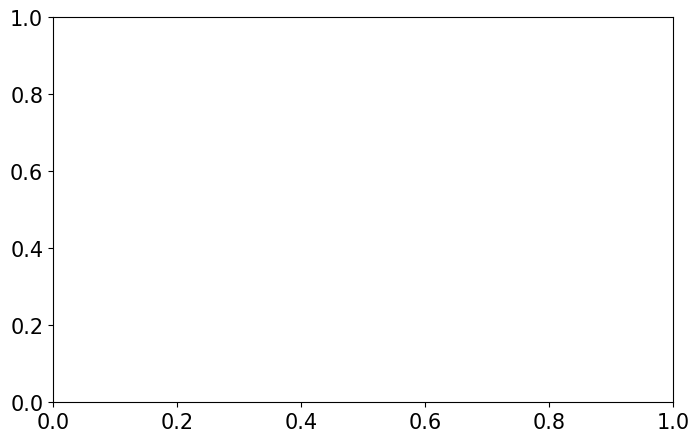

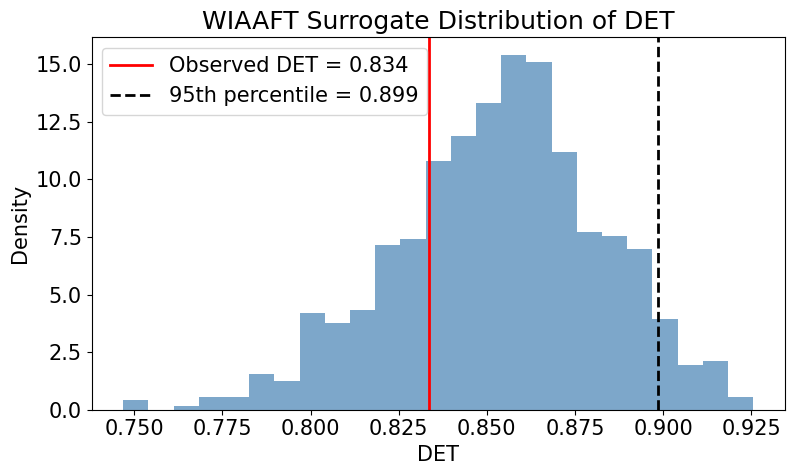

 33%|█████████████▊                            | 33/100 [13:36<27:13, 24.39s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8337218337185948 
 Recurrence rate: 0.05004539870747209 
Threshold:1.7623999999998223 
 Laminarity:0.9242262539988466 
Shannon Entropy:1.3011884483726082 
Rank-order p-value (det):0.766 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


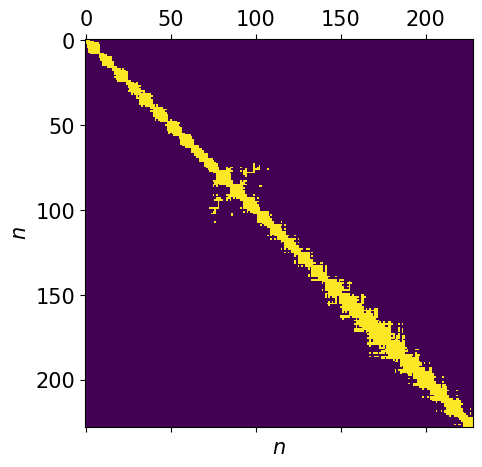

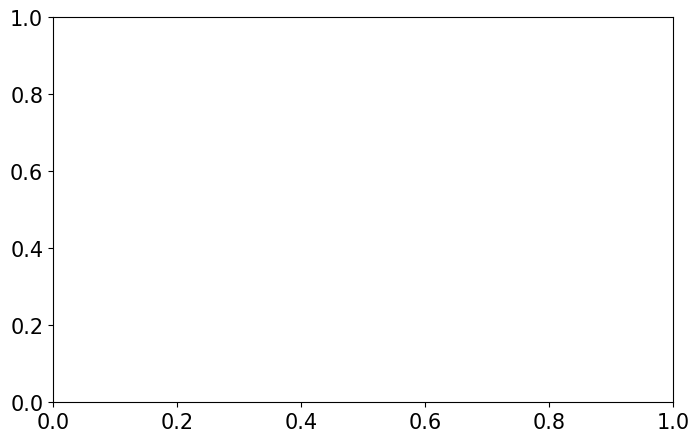

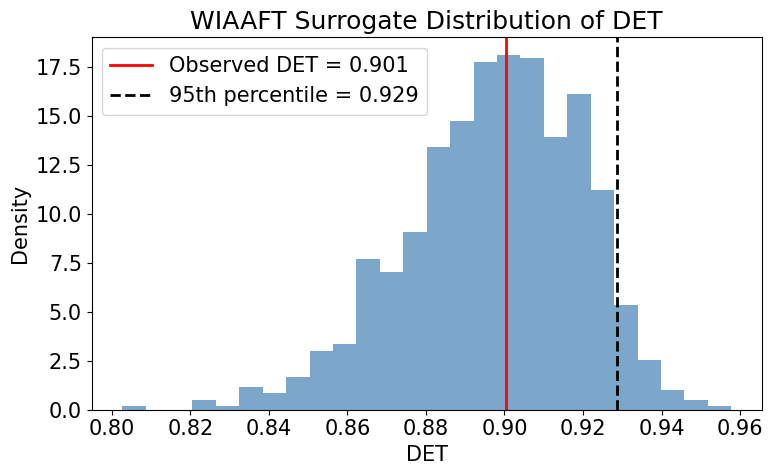

 34%|██████████████▎                           | 34/100 [14:00<26:49, 24.38s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9005059021884465 
 Recurrence rate: 0.05001538935056941 
Threshold:1.4007999999998622 
 Laminarity:0.9430769230732959 
Shannon Entropy:1.799445832866089 
Rank-order p-value (det):0.478 
Reject null (det) hypothesis:False

 
 

1
9
WIAAFT surrogate datasets generated


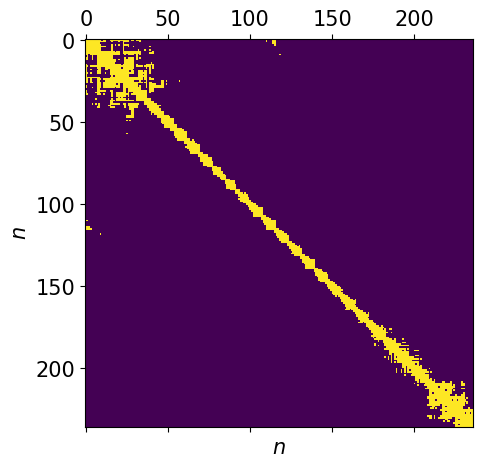

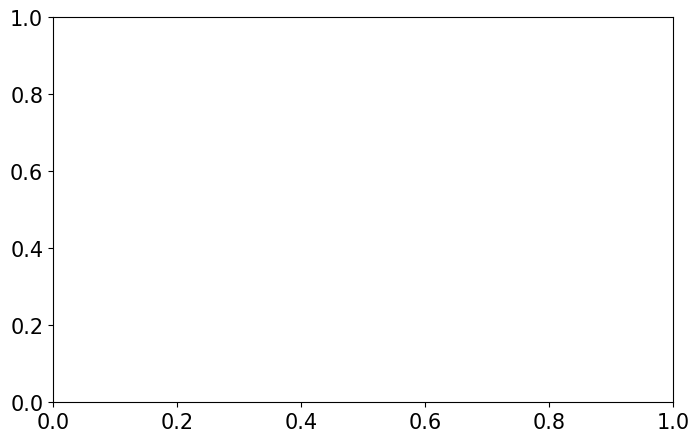

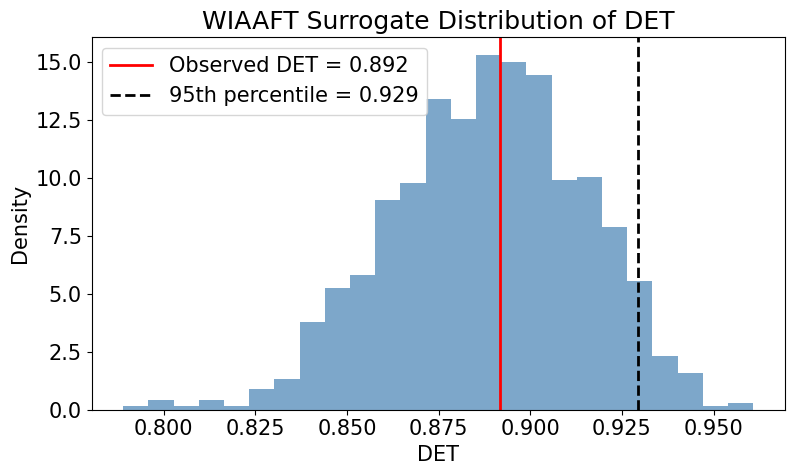

 35%|██████████████▋                           | 35/100 [14:28<27:31, 25.40s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8917647058788558 
 Recurrence rate: 0.05002154553289285 
Threshold:1.8402999999998138 
 Laminarity:0.9429289303627318 
Shannon Entropy:1.8192993153991417 
Rank-order p-value (det):0.467 
Reject null (det) hypothesis:False

 
 

1
9
WIAAFT surrogate datasets generated


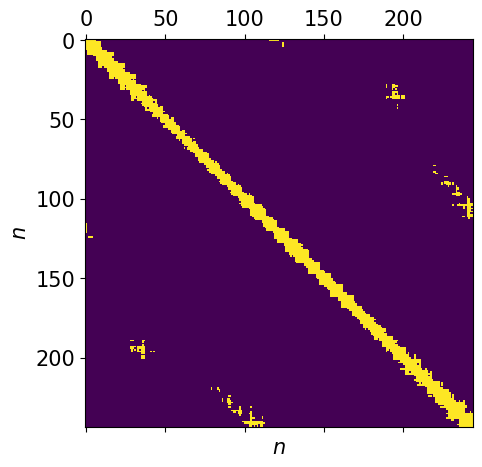

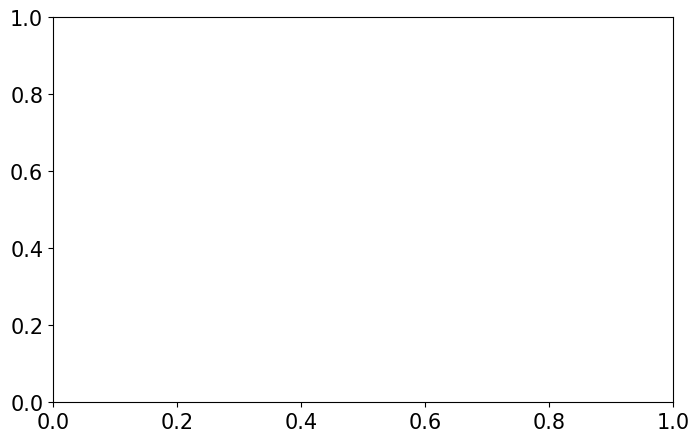

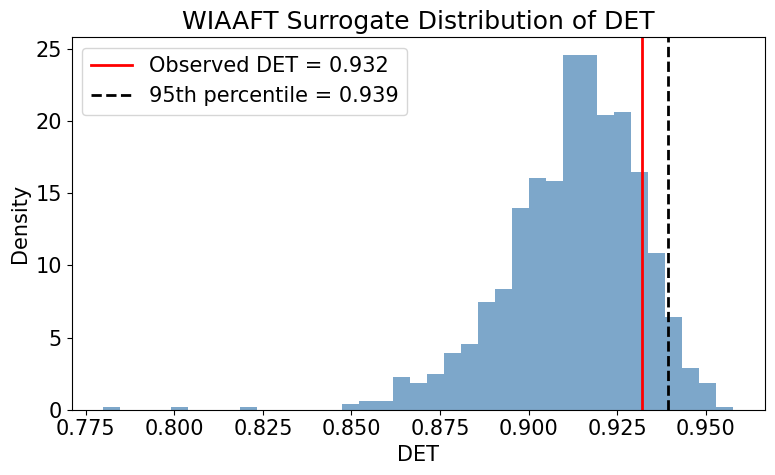

 36%|███████████████                           | 36/100 [14:56<28:07, 26.37s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.931967812725194 
 Recurrence rate: 0.0500201558720774 
Threshold:1.5760999999998428 
 Laminarity:0.9697783747448967 
Shannon Entropy:1.7827168891075131 
Rank-order p-value (det):0.139 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


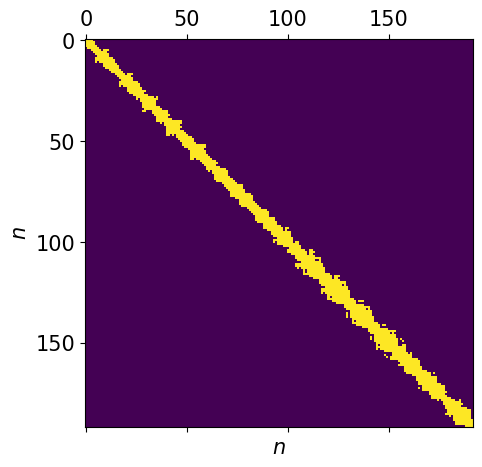

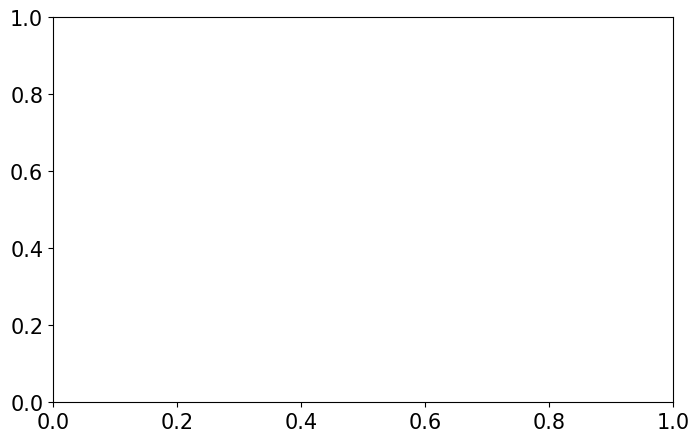

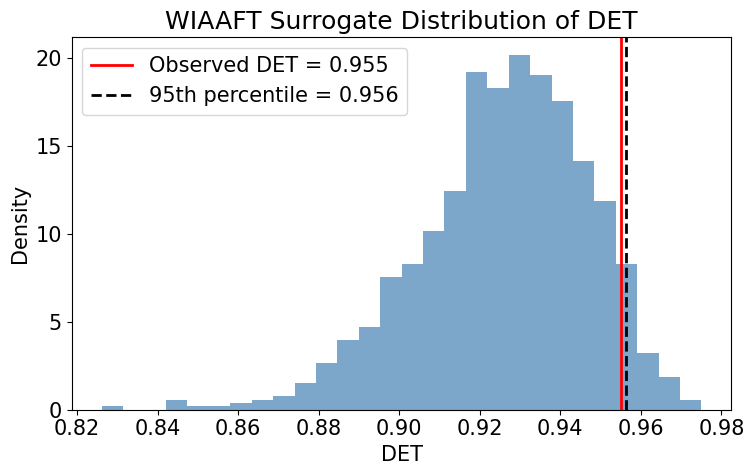

 37%|███████████████▌                          | 37/100 [15:17<25:59, 24.75s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9552058111322325 
 Recurrence rate: 0.05002170138888889 
Threshold:0.8227999999999257 
 Laminarity:0.9804772234220148 
Shannon Entropy:1.830409609175862 
Rank-order p-value (det):0.063 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


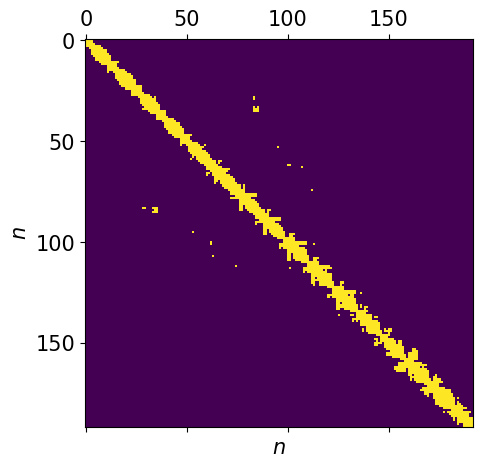

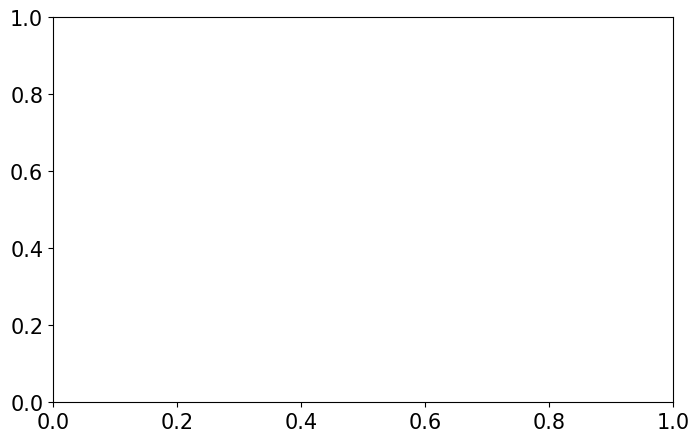

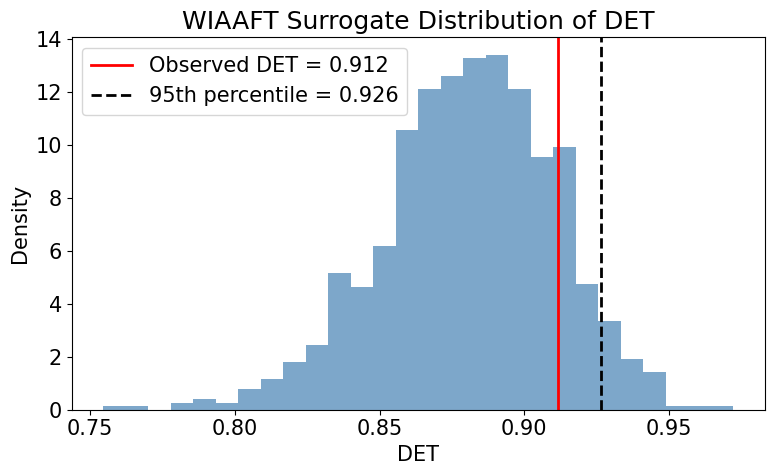

 38%|███████████████▉                          | 38/100 [15:41<25:21, 24.53s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9116222760235374 
 Recurrence rate: 0.05002170138888889 
Threshold:1.4613999999998555 
 Laminarity:0.9701735357864959 
Shannon Entropy:1.882905402326621 
Rank-order p-value (det):0.154 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


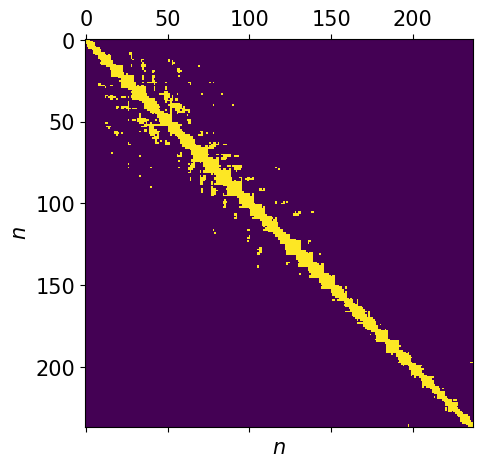

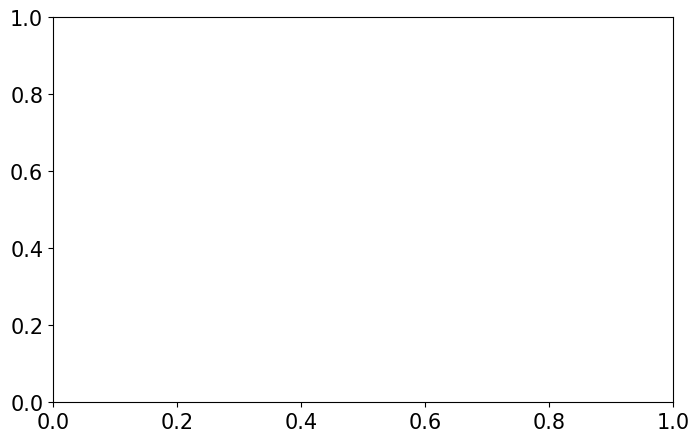

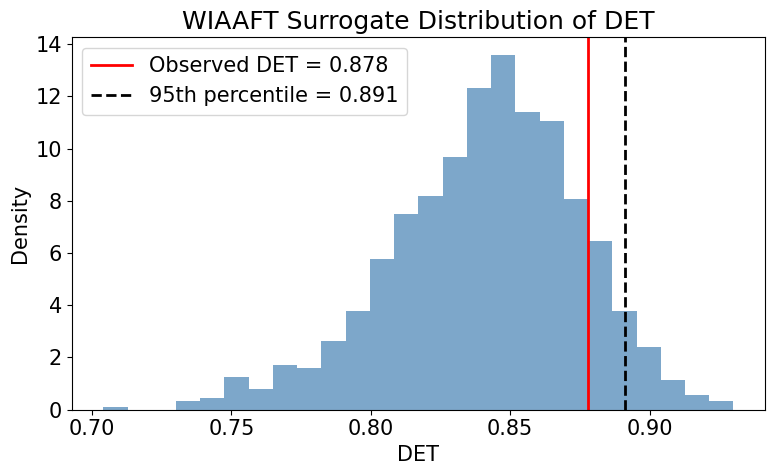

 39%|████████████████▍                         | 39/100 [16:06<24:59, 24.58s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.878010878007467 
 Recurrence rate: 0.05004539870747209 
Threshold:1.2340999999998805 
 Laminarity:0.9370330843082995 
Shannon Entropy:1.5346653202608898 
Rank-order p-value (det):0.128 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


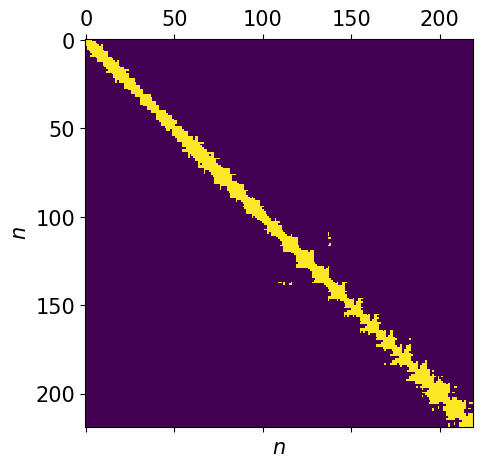

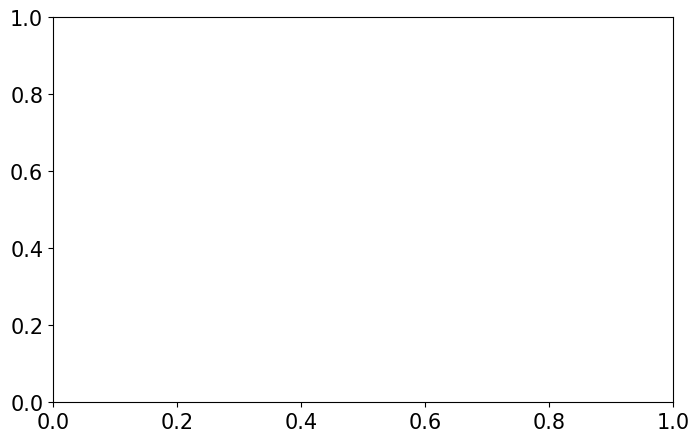

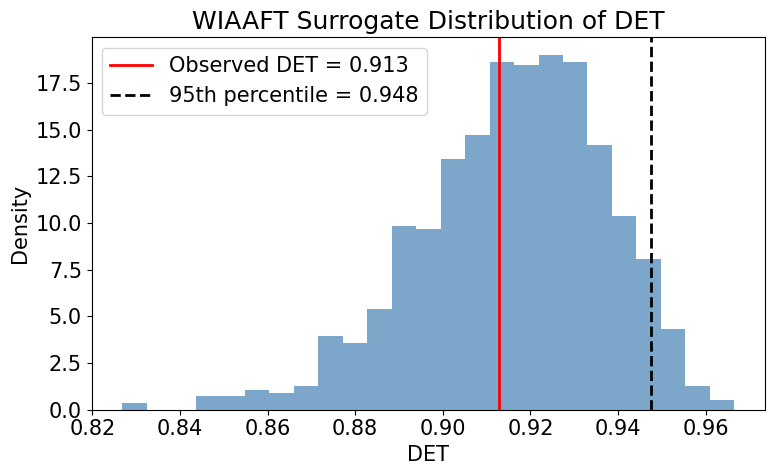

 40%|████████████████▊                         | 40/100 [16:31<24:35, 24.60s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9128440366930604 
 Recurrence rate: 0.05001980776047205 
Threshold:1.51069999999985 
 Laminarity:0.9729053772364614 
Shannon Entropy:2.0814285380920476 
Rank-order p-value (det):0.599 
Reject null (det) hypothesis:False

 
 

1
9
WIAAFT surrogate datasets generated


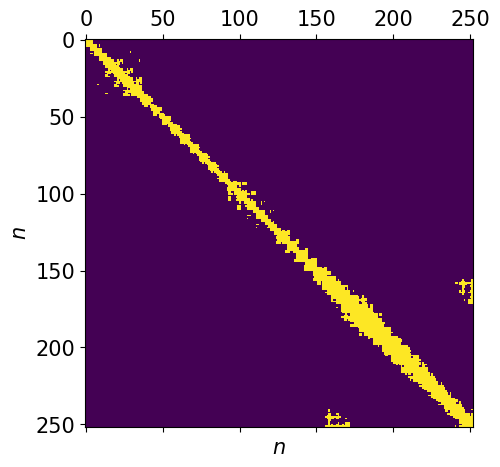

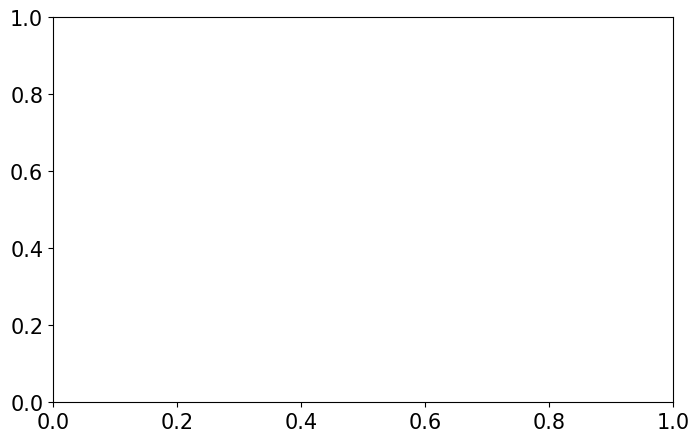

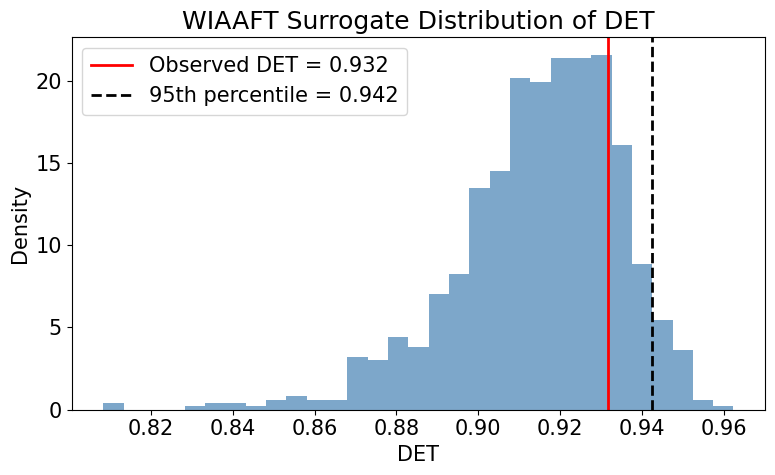

 41%|█████████████████▏                        | 41/100 [16:56<24:20, 24.75s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9316005471924365 
 Recurrence rate: 0.05001259763164525 
Threshold:1.2316999999998808 
 Laminarity:0.972292191432707 
Shannon Entropy:1.6820344473374413 
Rank-order p-value (det):0.193 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


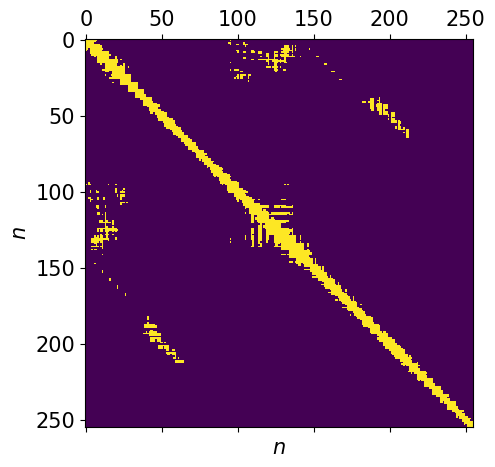

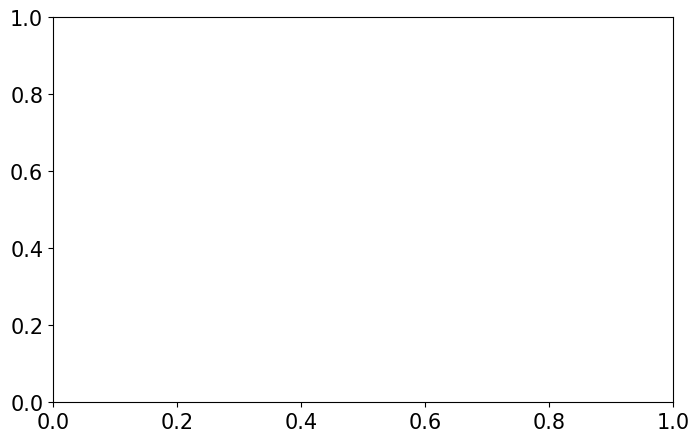

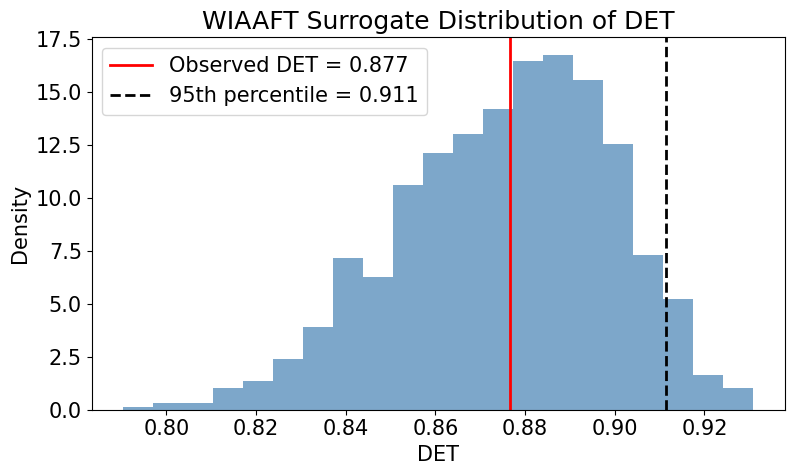

 42%|█████████████████▋                        | 42/100 [17:23<24:35, 25.45s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8765843895901382 
 Recurrence rate: 0.050026912725874666 
Threshold:1.5059999999998506 
 Laminarity:0.9391331078975127 
Shannon Entropy:1.3550686599523105 
Rank-order p-value (det):0.52 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


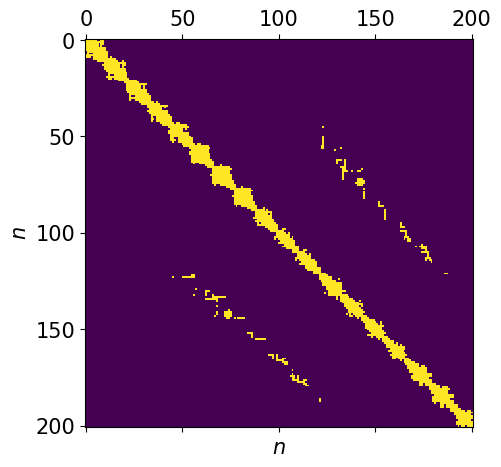

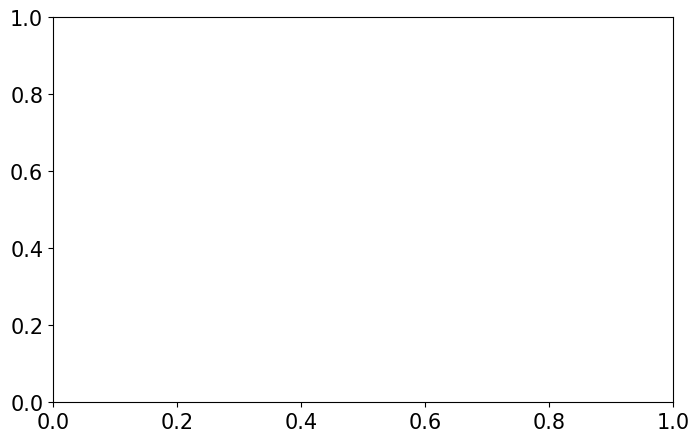

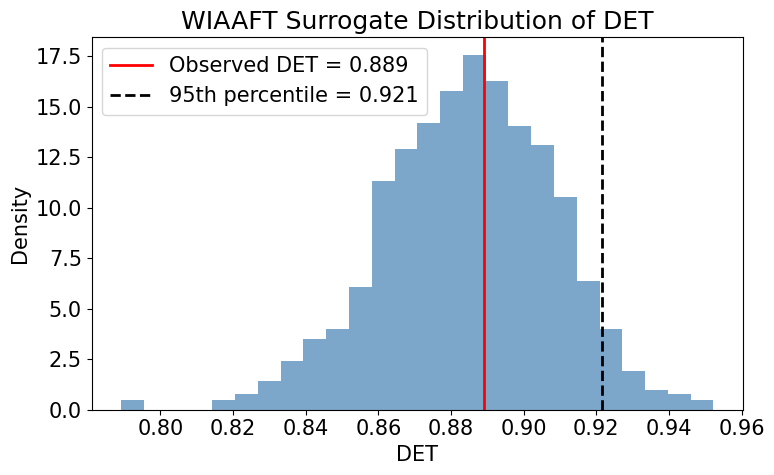

 43%|██████████████████                        | 43/100 [17:47<23:46, 25.03s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8890109890061044 
 Recurrence rate: 0.050023514269448774 
Threshold:1.5248999999998485 
 Laminarity:0.9411182582833196 
Shannon Entropy:1.9473091736635812 
Rank-order p-value (det):0.435 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


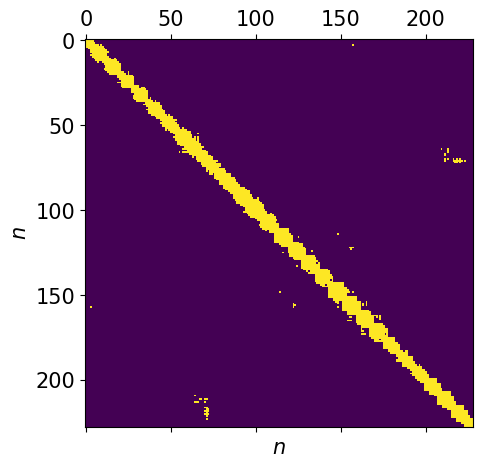

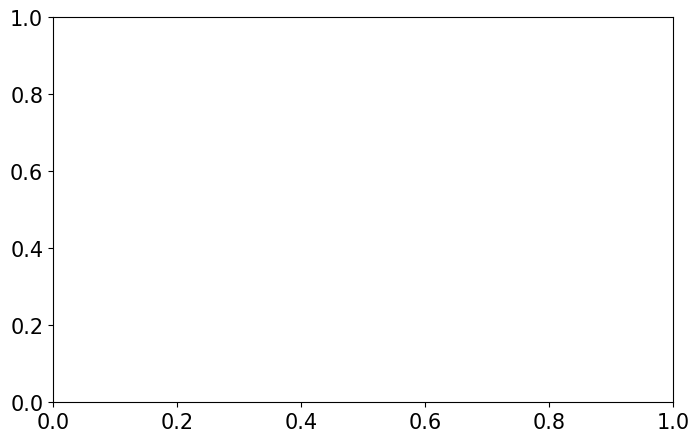

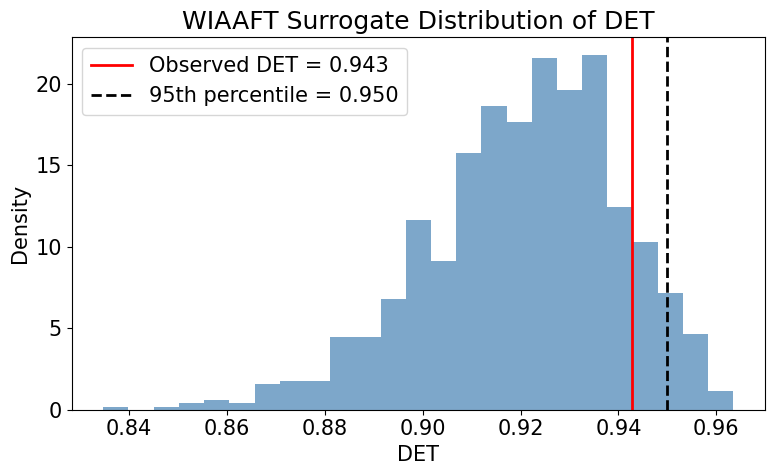

 44%|██████████████████▍                       | 44/100 [18:14<23:51, 25.57s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9426644182085049 
 Recurrence rate: 0.05001538935056941 
Threshold:1.846599999999813 
 Laminarity:0.9734615384577944 
Shannon Entropy:2.122170401565371 
Rank-order p-value (det):0.121 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


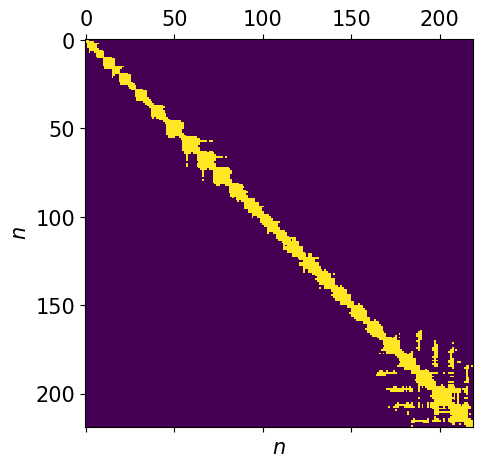

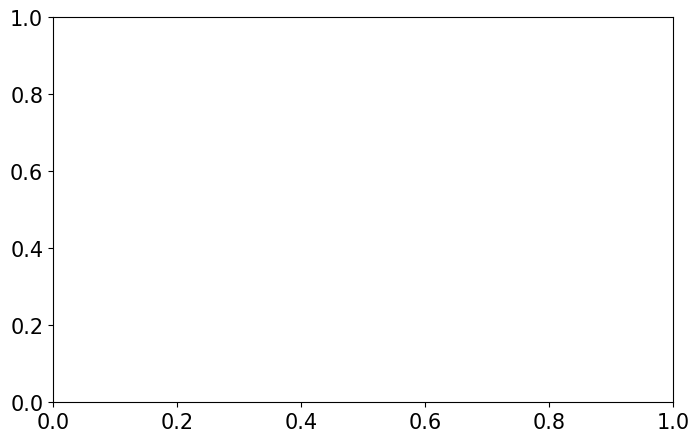

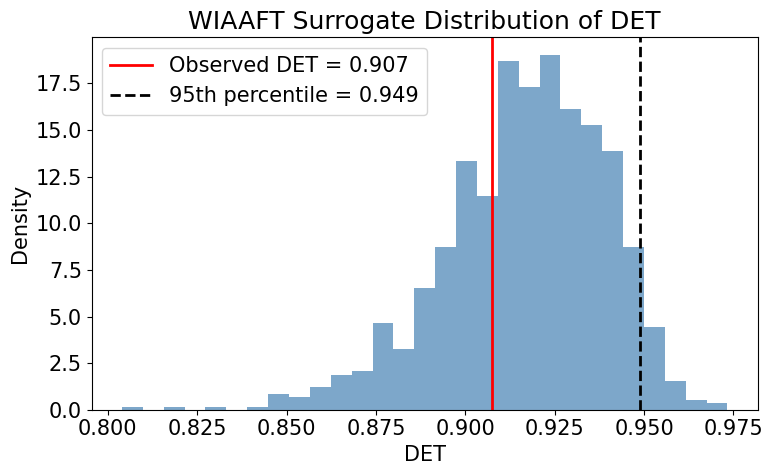

 45%|██████████████████▉                       | 45/100 [18:38<23:07, 25.22s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9073394495371223 
 Recurrence rate: 0.05001980776047205 
Threshold:1.4490999999998568 
 Laminarity:0.9566486035808394 
Shannon Entropy:1.9367631298825227 
Rank-order p-value (det):0.699 
Reject null (det) hypothesis:False

 
 

1
10
WIAAFT surrogate datasets generated


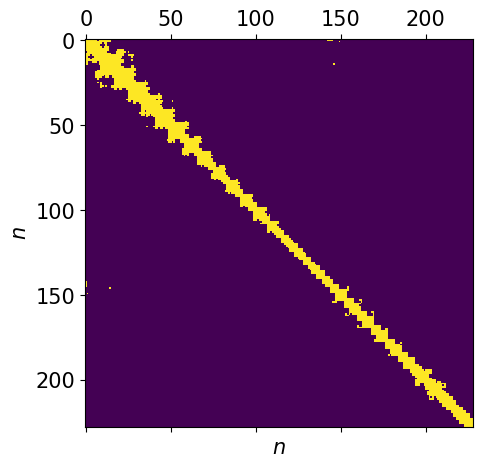

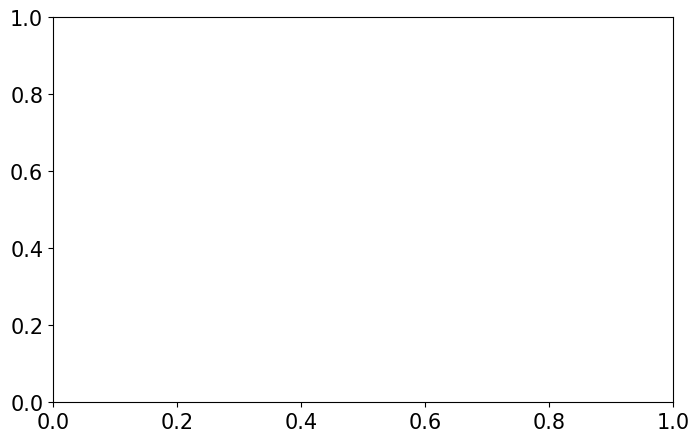

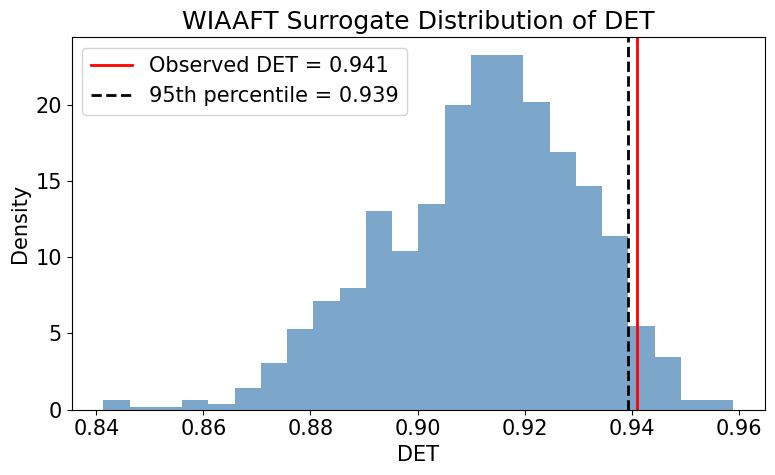

 46%|███████████████████▎                      | 46/100 [19:01<22:03, 24.51s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9409780775677025 
 Recurrence rate: 0.05001538935056941 
Threshold:1.0284999999999032 
 Laminarity:0.9819230769193004 
Shannon Entropy:1.7158039412626944 
Rank-order p-value (det):0.037 
Reject null (det) hypothesis:True

 
 

2
10
WIAAFT surrogate datasets generated


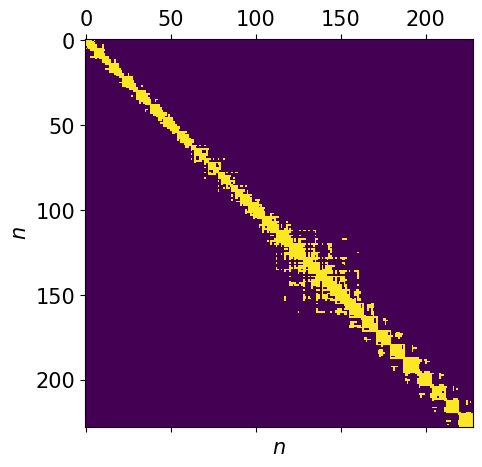

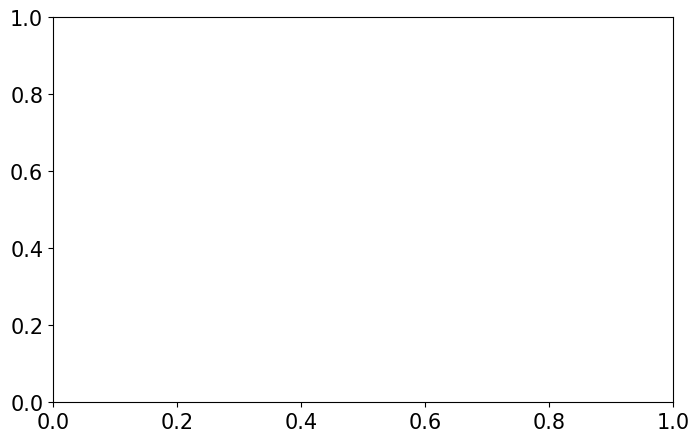

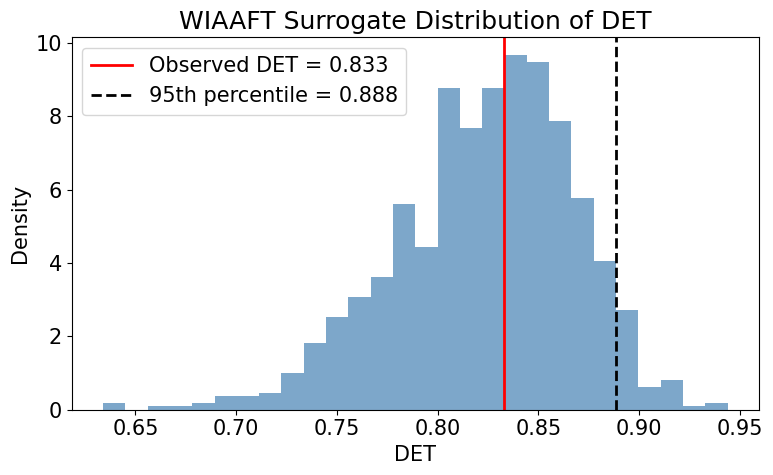

 47%|███████████████████▋                      | 47/100 [19:22<20:50, 23.58s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.833052276556353 
 Recurrence rate: 0.05001538935056941 
Threshold:0.810699999999927 
 Laminarity:0.9138461538426391 
Shannon Entropy:1.730210228302456 
Rank-order p-value (det):0.458 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


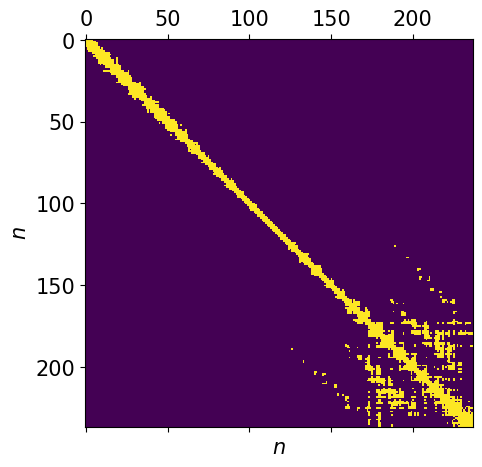

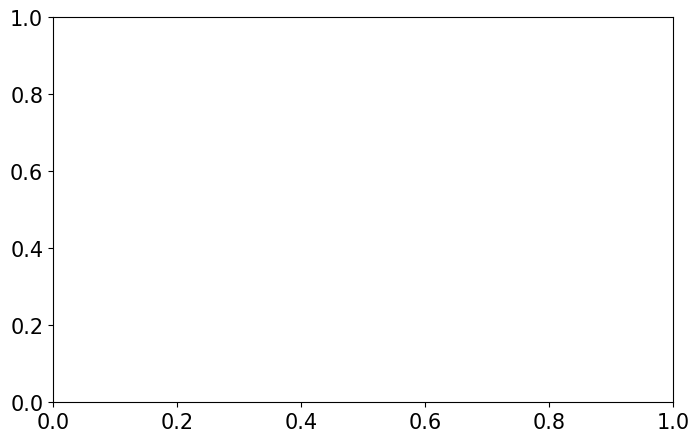

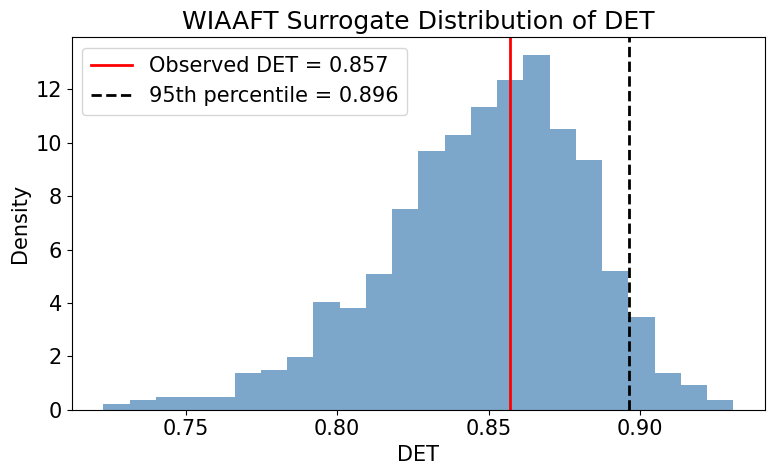

 48%|████████████████████▏                     | 48/100 [19:48<20:57, 24.18s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8569206842890478 
 Recurrence rate: 0.050009791878082216 
Threshold:1.4455999999998572 
 Laminarity:0.9231043075794835 
Shannon Entropy:1.505329722059259 
Rank-order p-value (det):0.44 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


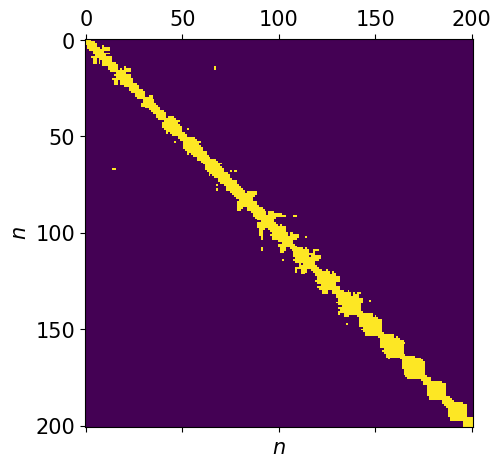

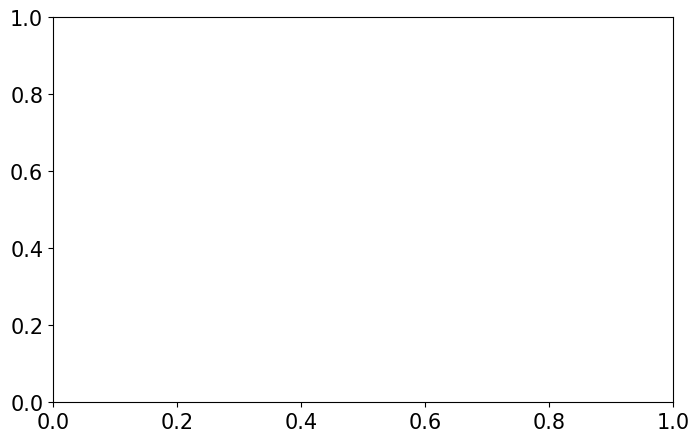

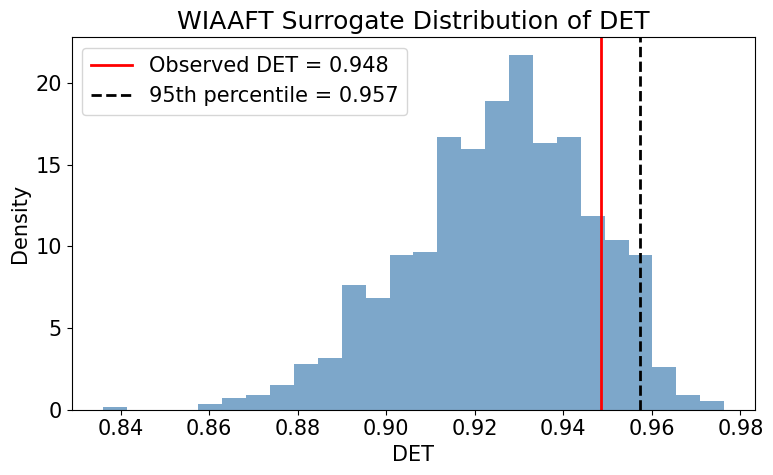

 49%|████████████████████▌                     | 49/100 [20:09<19:51, 23.36s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.948408342475585 
 Recurrence rate: 0.05007301799460409 
Threshold:1.1864999999998858 
 Laminarity:0.9812160158132417 
Shannon Entropy:2.1036449765127148 
Rank-order p-value (det):0.14 
Reject null (det) hypothesis:False

 
 

2
8
WIAAFT surrogate datasets generated


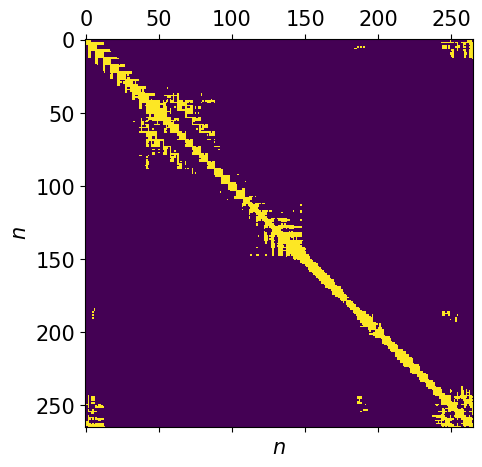

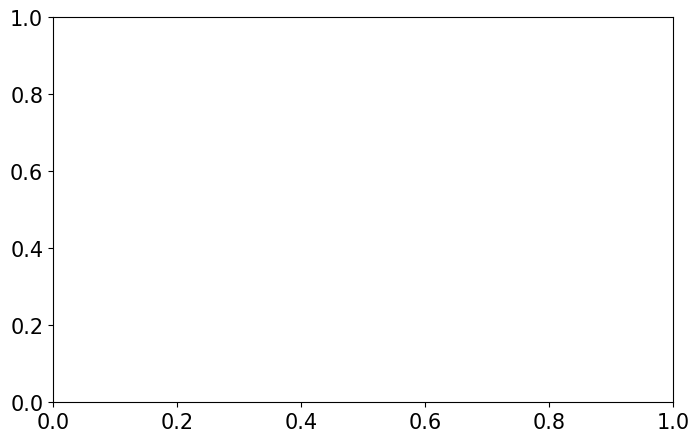

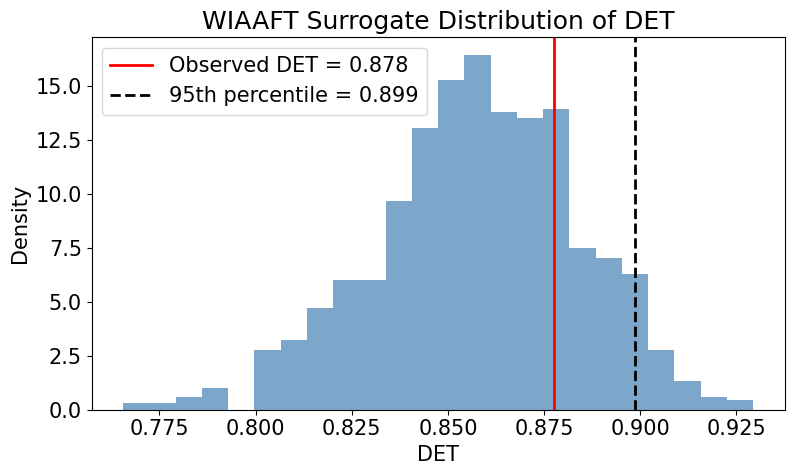

 50%|█████████████████████                     | 50/100 [20:35<19:54, 23.90s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.8775384615357614 
 Recurrence rate: 0.05005339978640085 
Threshold:1.2326999999998807 
 Laminarity:0.9302987197697573 
Shannon Entropy:1.4252725661557157 
Rank-order p-value (det):0.225 
Reject null (det) hypothesis:False

 
 

2
9
WIAAFT surrogate datasets generated


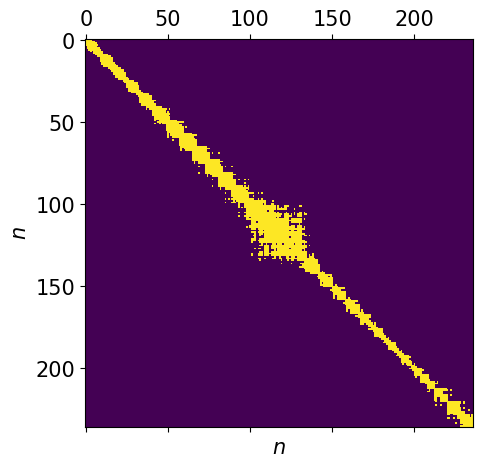

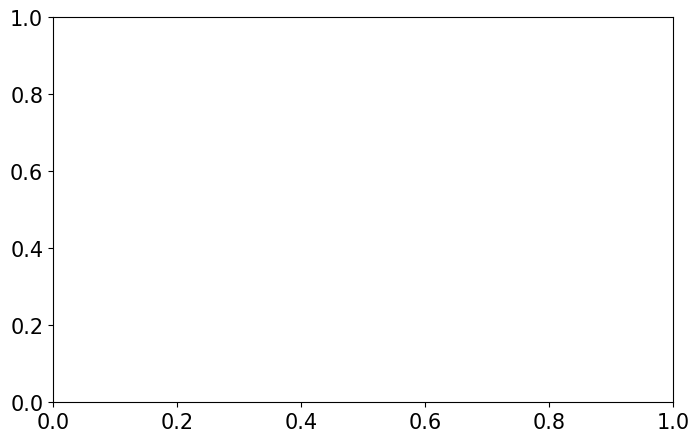

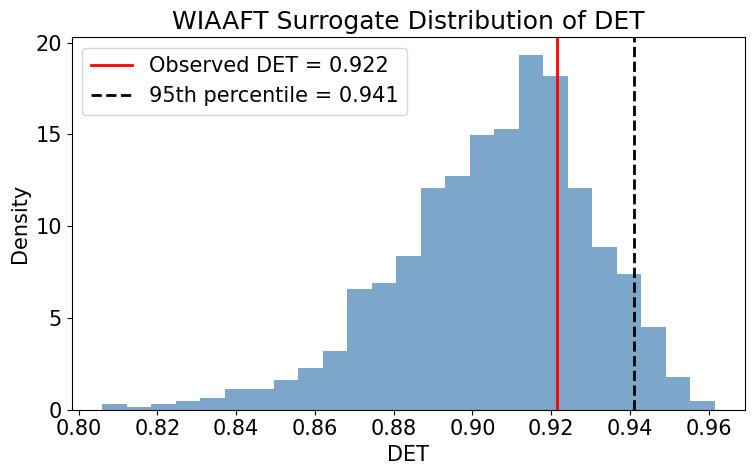

 51%|█████████████████████▍                    | 51/100 [20:57<19:13, 23.54s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9215686274473665 
 Recurrence rate: 0.05002154553289285 
Threshold:1.012299999999905 
 Laminarity:0.9547738693433067 
Shannon Entropy:1.916020917091782 
Rank-order p-value (det):0.261 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


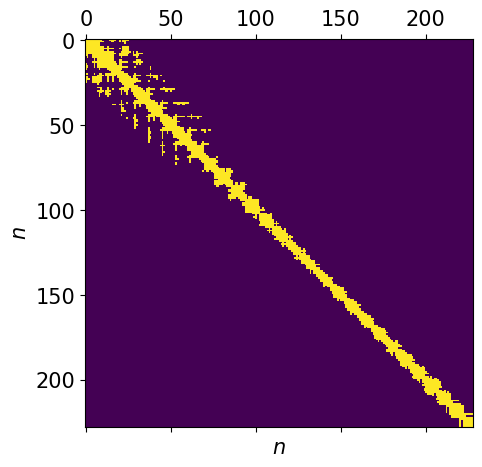

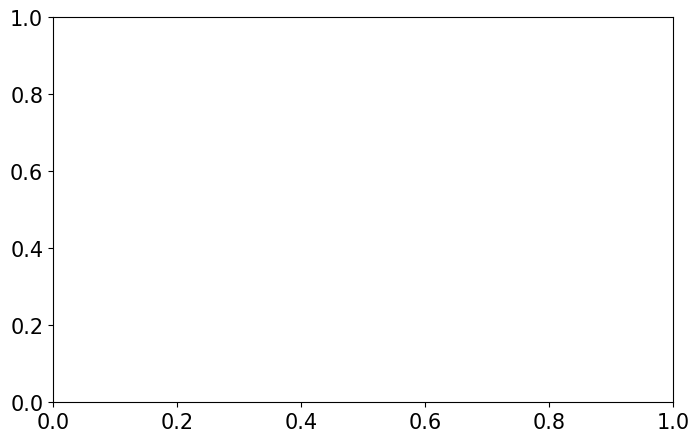

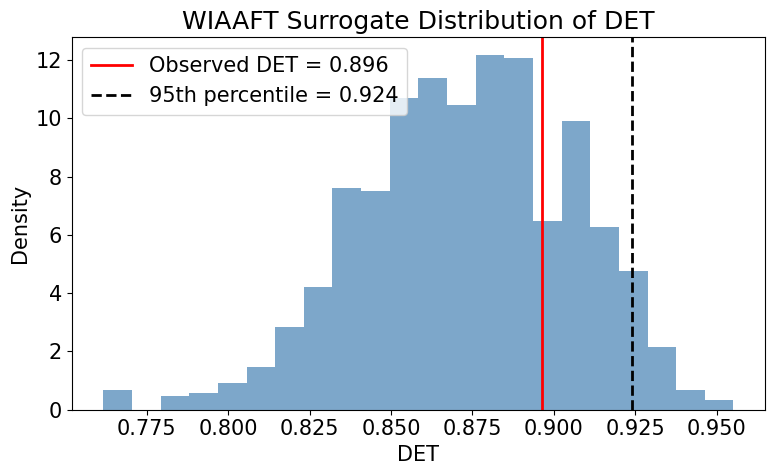

 52%|█████████████████████▊                    | 52/100 [21:20<18:39, 23.32s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8963774220686758 
 Recurrence rate: 0.05005386272699292 
Threshold:0.9883999999999075 
 Laminarity:0.9385088393507359 
Shannon Entropy:1.7744109956533416 
Rank-order p-value (det):0.251 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


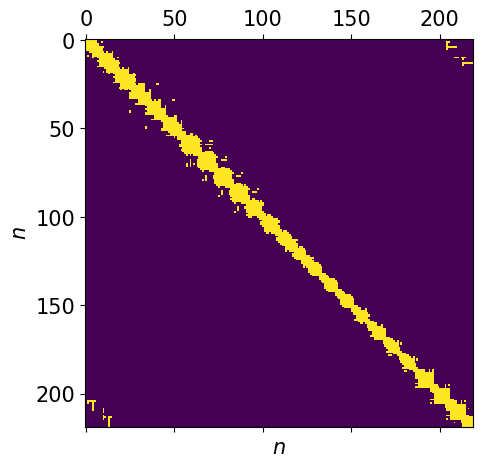

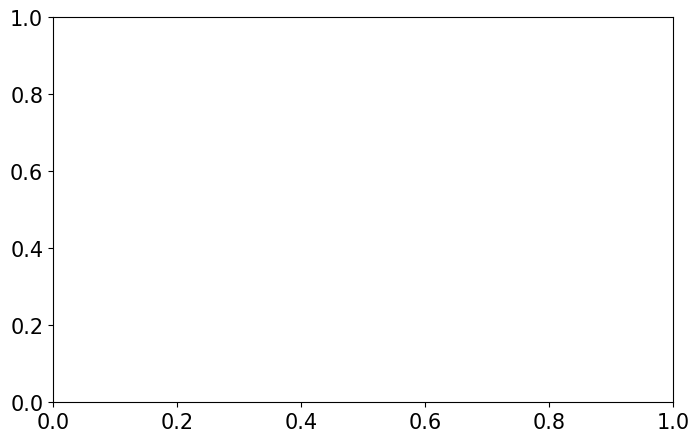

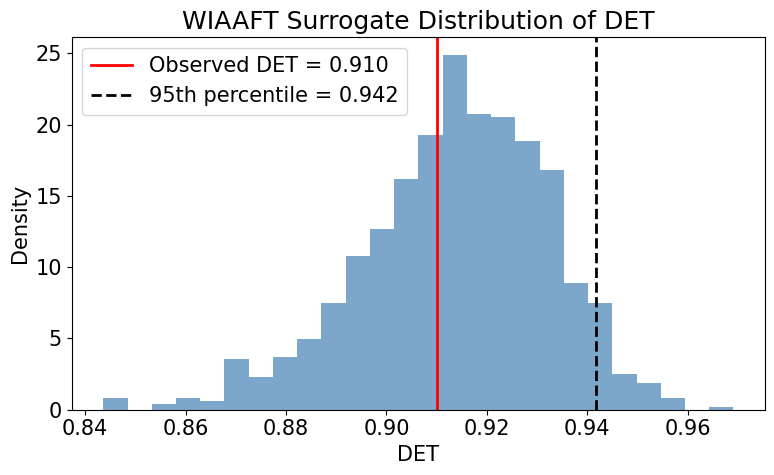

 53%|██████████████████████▎                   | 53/100 [21:45<18:35, 23.74s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9101741521498159 
 Recurrence rate: 0.05006150830883426 
Threshold:1.5398999999998468 
 Laminarity:0.9583506872096695 
Shannon Entropy:2.0392286670839814 
Rank-order p-value (det):0.617 
Reject null (det) hypothesis:False

 
 

2
8
WIAAFT surrogate datasets generated


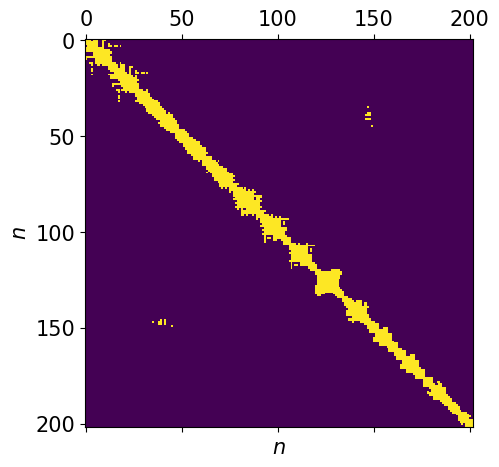

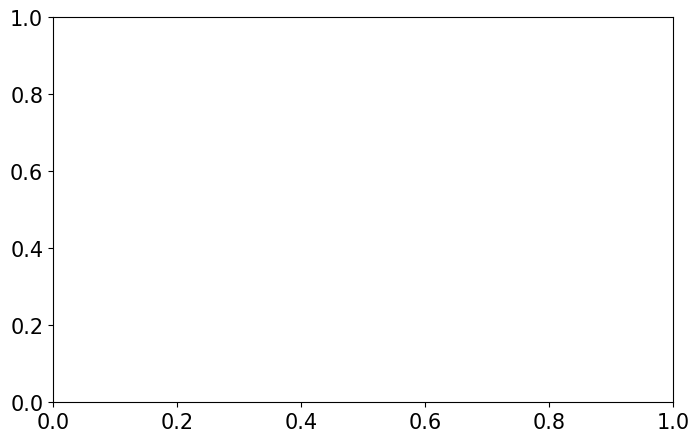

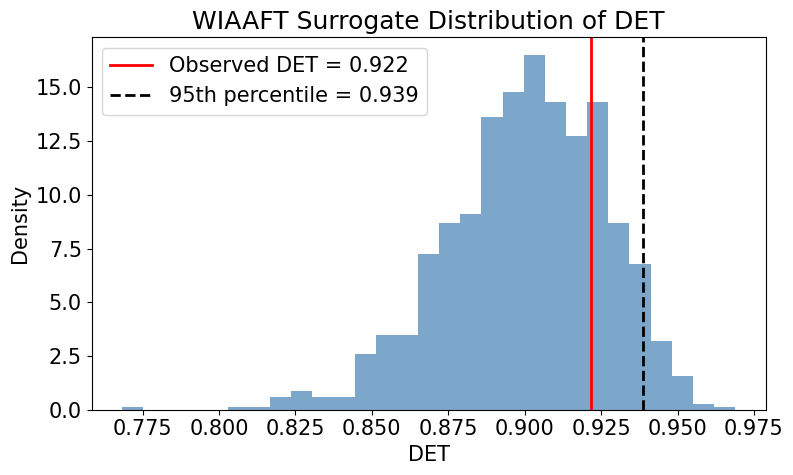

 54%|██████████████████████▋                   | 54/100 [22:07<17:46, 23.19s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9217391304297732 
 Recurrence rate: 0.05004411332222331 
Threshold:1.2057999999998836 
 Laminarity:0.9671890303576534 
Shannon Entropy:2.2510750015780947 
Rank-order p-value (det):0.221 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


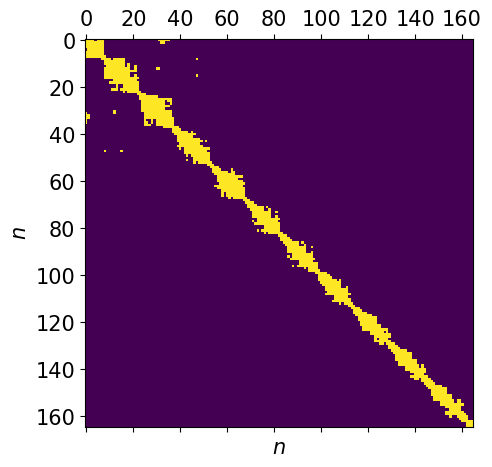

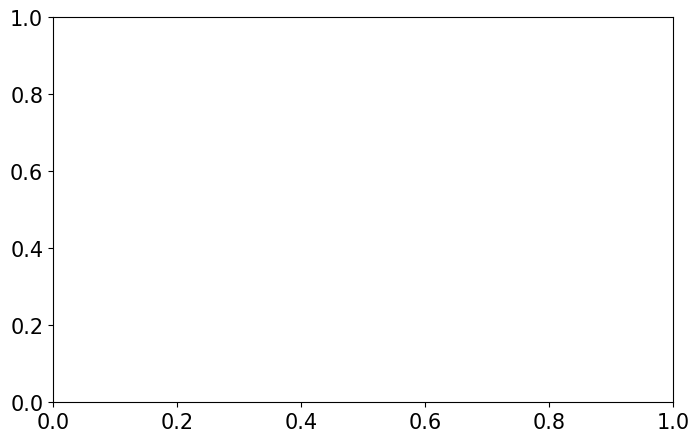

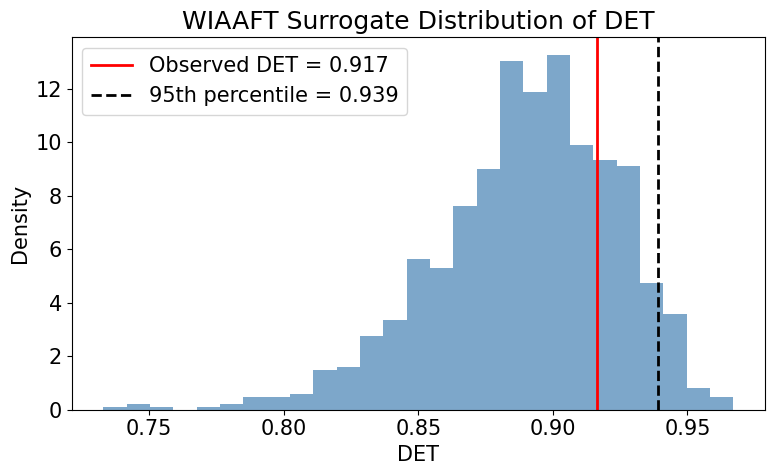

 55%|███████████████████████                   | 55/100 [22:27<16:37, 22.16s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9165275459021993 
 Recurrence rate: 0.05006427915518825 
Threshold:1.1686999999998877 
 Laminarity:0.961115187080256 
Shannon Entropy:2.125317138437203 
Rank-order p-value (det):0.233 
Reject null (det) hypothesis:False

 
 

2
7
WIAAFT surrogate datasets generated


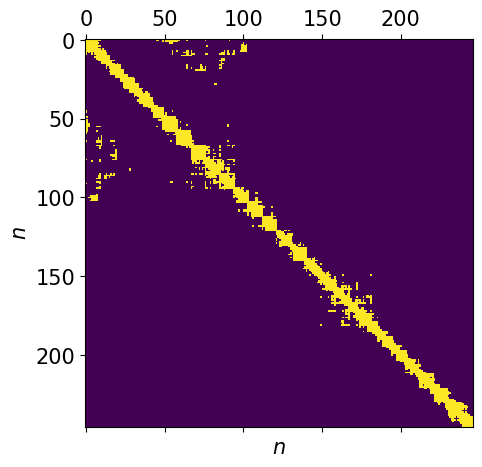

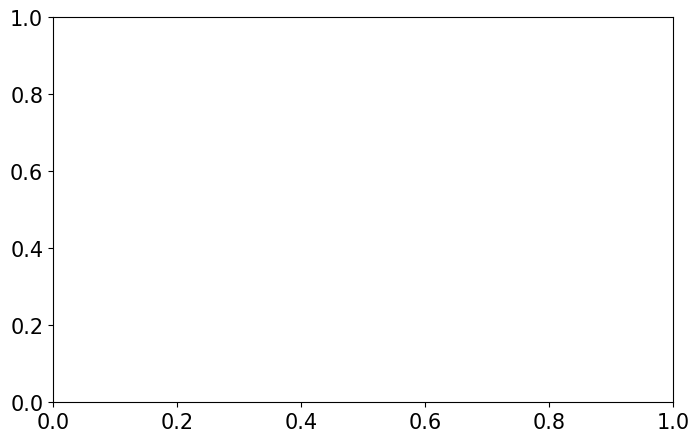

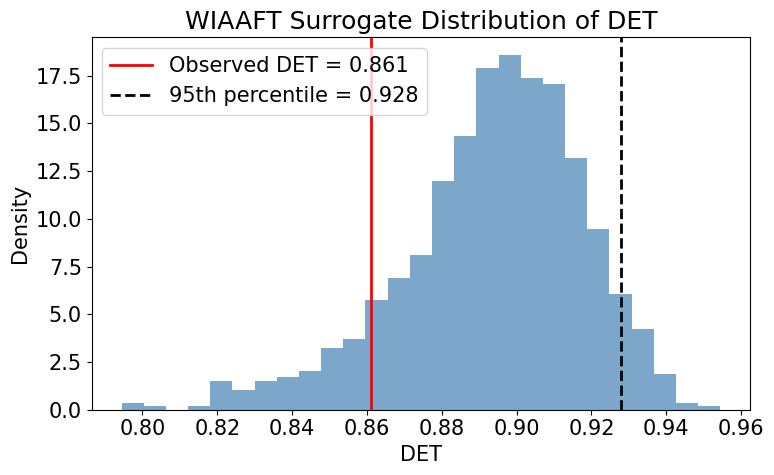

 56%|███████████████████████▌                  | 56/100 [22:51<16:42, 22.79s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.861151079133593 
 Recurrence rate: 0.05000330491109789 
Threshold:1.2401999999998798 
 Laminarity:0.9306014540616967 
Shannon Entropy:1.8262268173887595 
Rank-order p-value (det):0.9 
Reject null (det) hypothesis:False

 
 

2
8
WIAAFT surrogate datasets generated


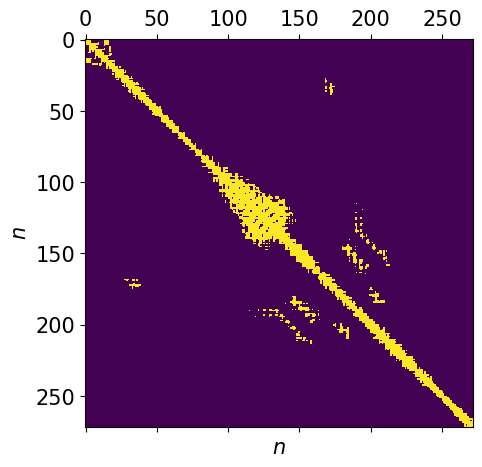

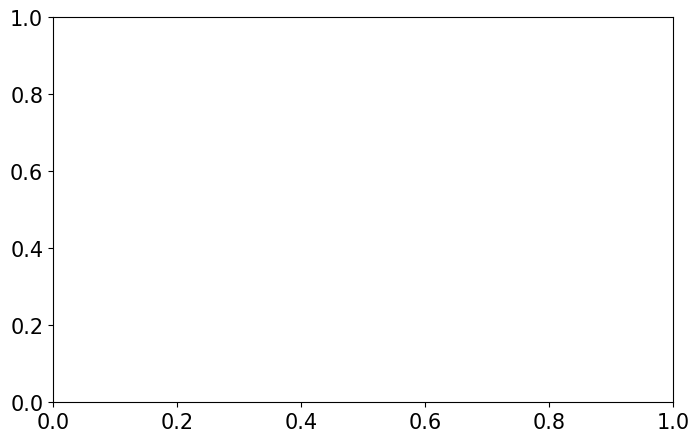

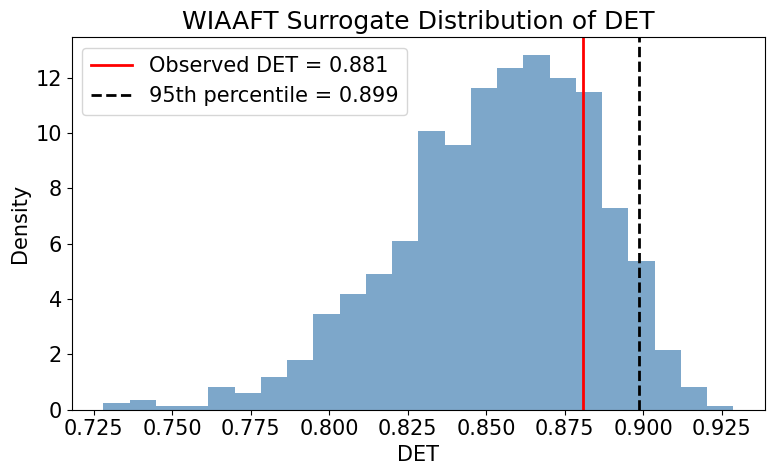

 57%|███████████████████████▉                  | 57/100 [23:13<16:16, 22.71s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.8809801633579901 
 Recurrence rate: 0.05001081314878893 
Threshold:0.8387999999999239 
 Laminarity:0.9408108108082681 
Shannon Entropy:1.5685865668472077 
Rank-order p-value (det):0.204 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


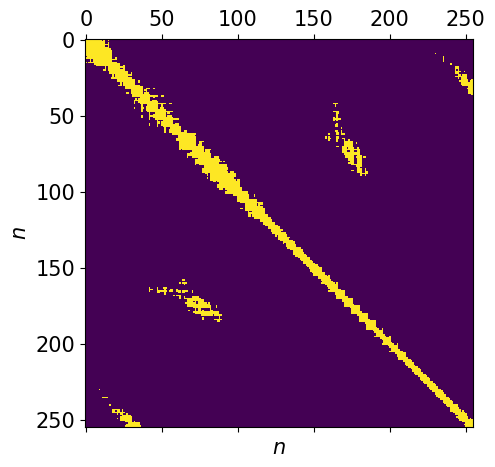

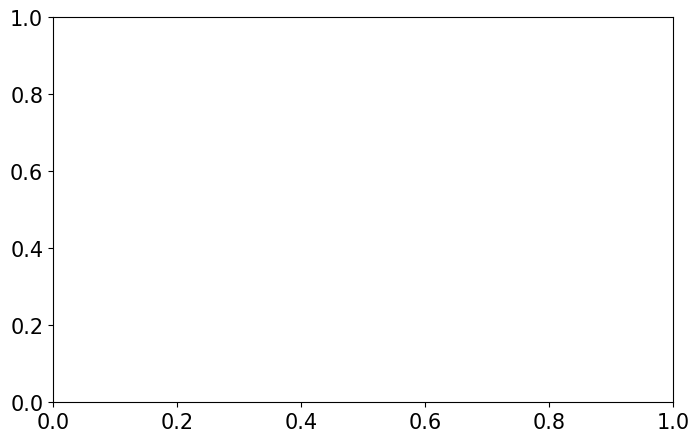

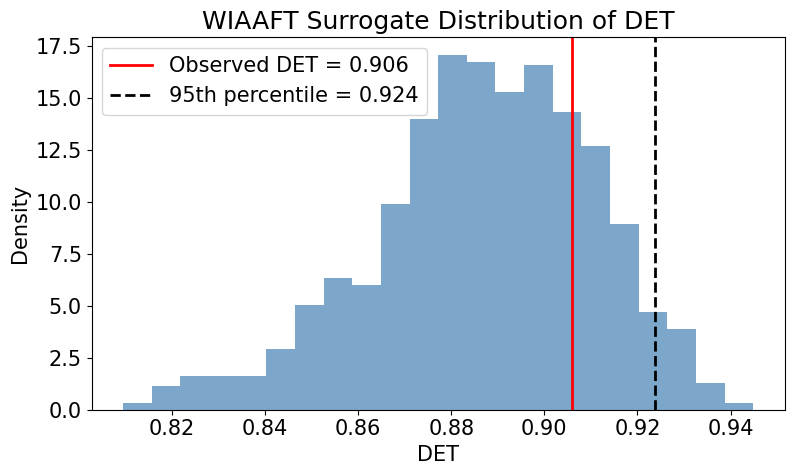

 58%|████████████████████████▎                 | 58/100 [23:42<17:14, 24.63s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9059372915246634 
 Recurrence rate: 0.050026912725874666 
Threshold:1.7415999999998246 
 Laminarity:0.9563479864710841 
Shannon Entropy:1.780750236416416 
Rank-order p-value (det):0.225 
Reject null (det) hypothesis:False

 
 

2
7
WIAAFT surrogate datasets generated


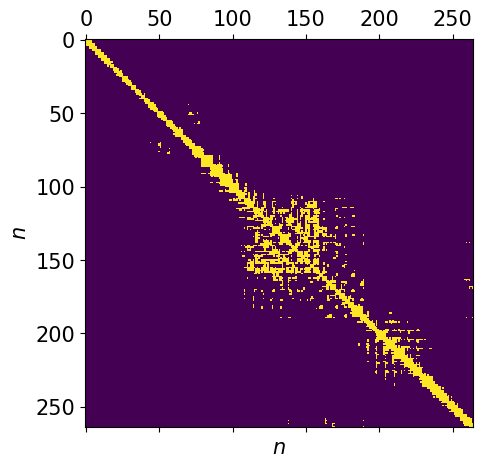

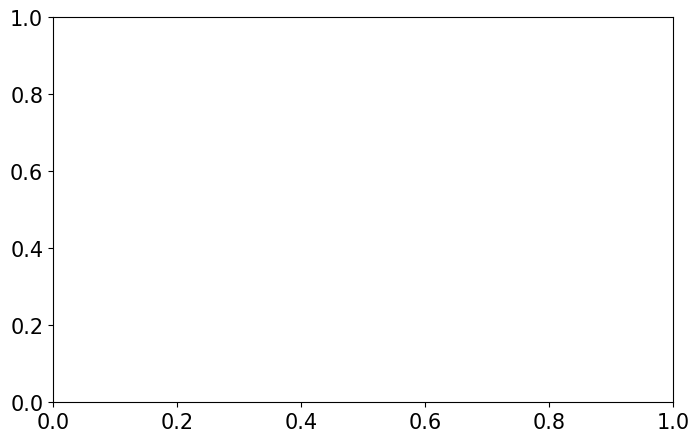

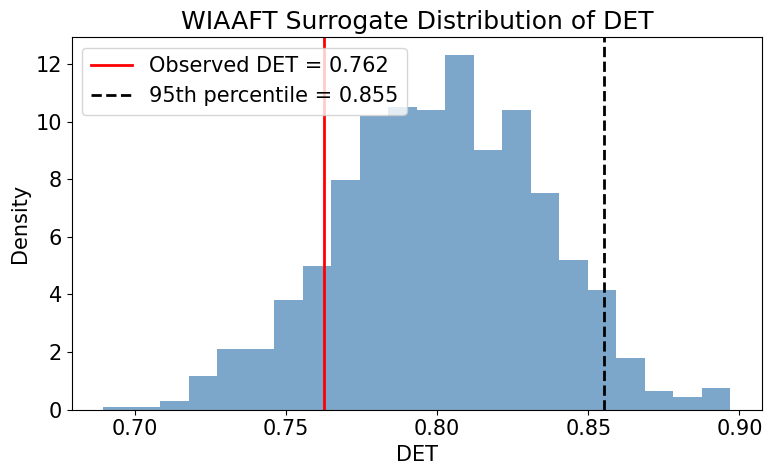

 59%|████████████████████████▊                 | 59/100 [24:06<16:36, 24.31s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.7624069478884541 
 Recurrence rate: 0.050045913682277315 
Threshold:0.956399999999911 
 Laminarity:0.8715596330250243 
Shannon Entropy:1.4224558087855506 
Rank-order p-value (det):0.872 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


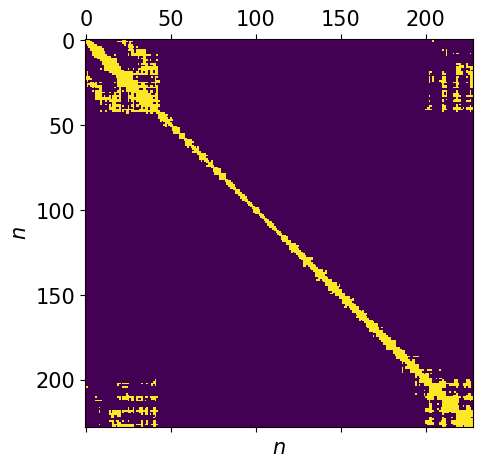

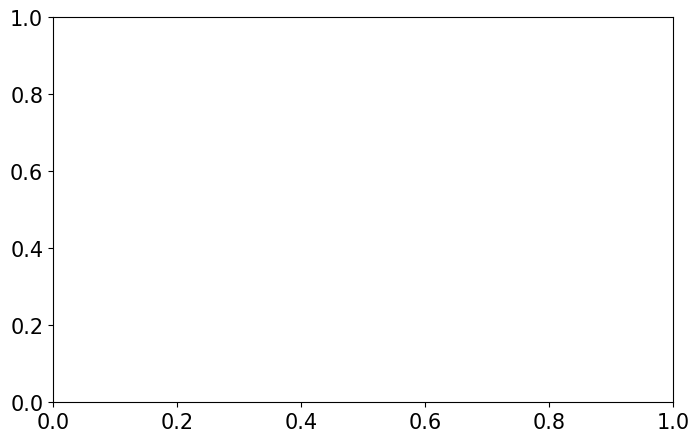

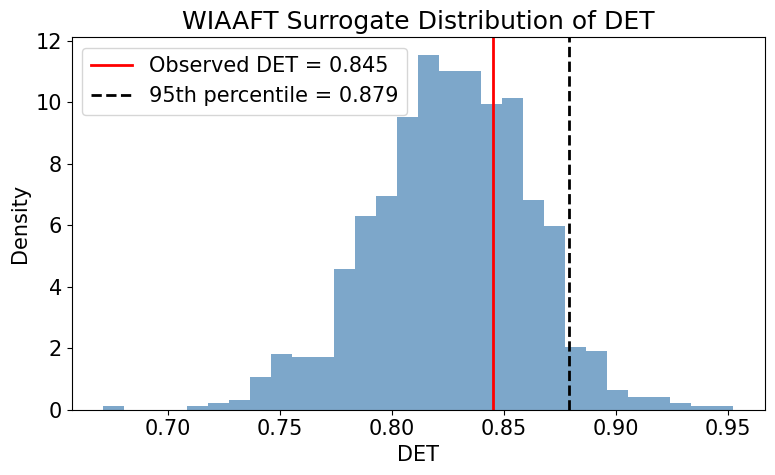

 60%|█████████████████████████▏                | 60/100 [24:31<16:25, 24.63s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8448566610419694 
 Recurrence rate: 0.05001538935056941 
Threshold:1.4873999999998526 
 Laminarity:0.9215384615349173 
Shannon Entropy:1.4341350283793473 
Rank-order p-value (det):0.315 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


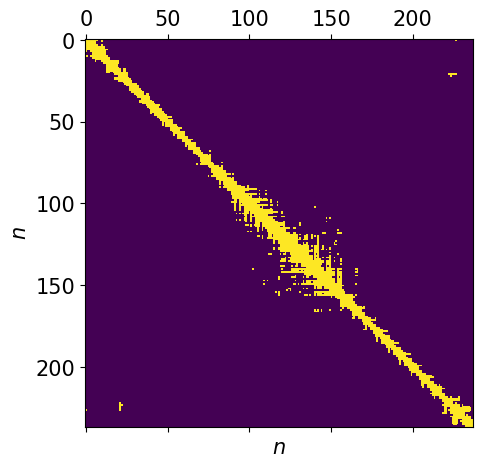

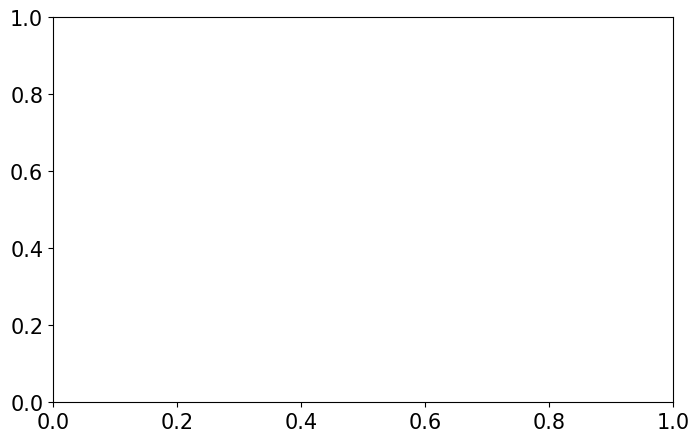

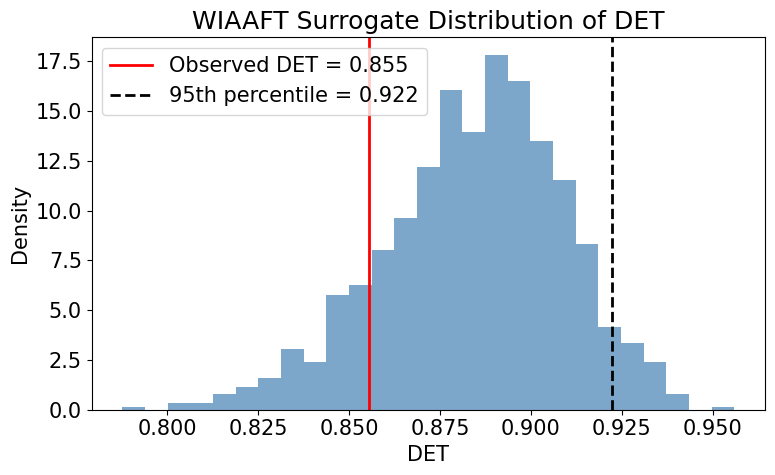

 61%|█████████████████████████▌                | 61/100 [24:57<16:08, 24.82s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8553654743357101 
 Recurrence rate: 0.050009791878082216 
Threshold:1.3145999999998716 
 Laminarity:0.9291562833715588 
Shannon Entropy:1.6869300319680554 
Rank-order p-value (det):0.869 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


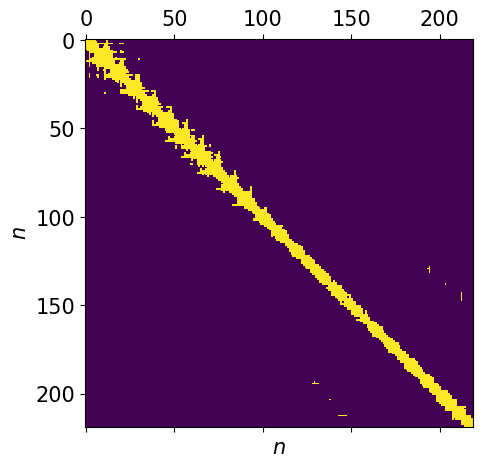

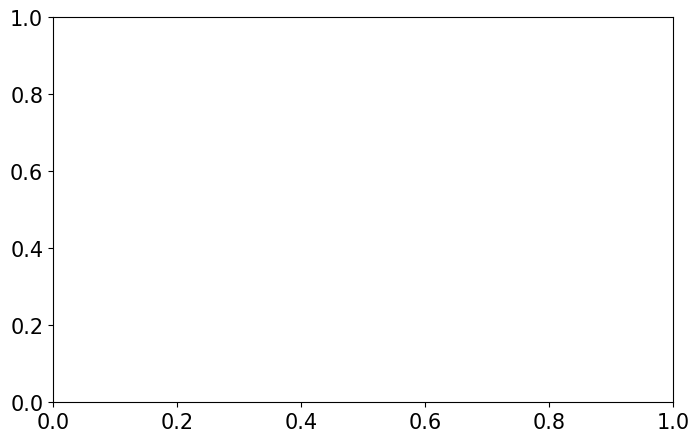

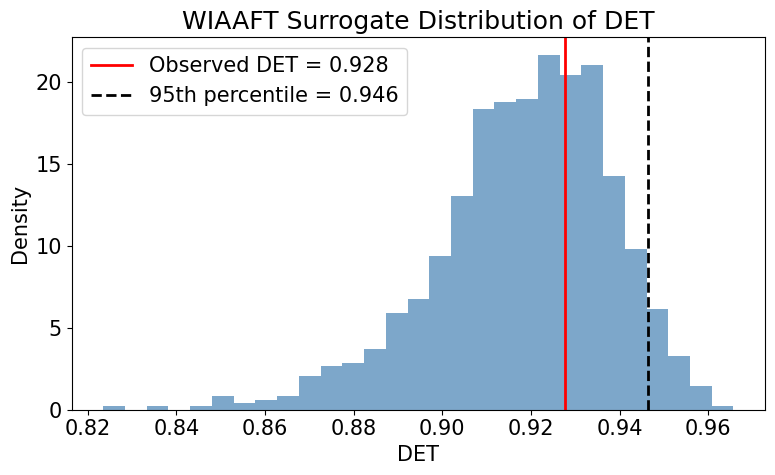

 62%|██████████████████████████                | 62/100 [25:20<15:31, 24.51s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9275893675484529 
 Recurrence rate: 0.05006150830883426 
Threshold:1.293699999999874 
 Laminarity:0.966264056639041 
Shannon Entropy:1.9596080038644288 
Rank-order p-value (det):0.351 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


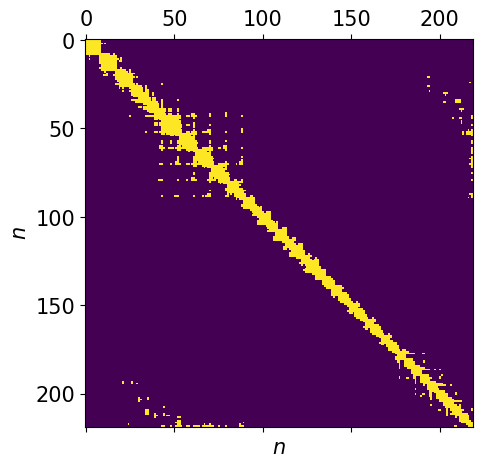

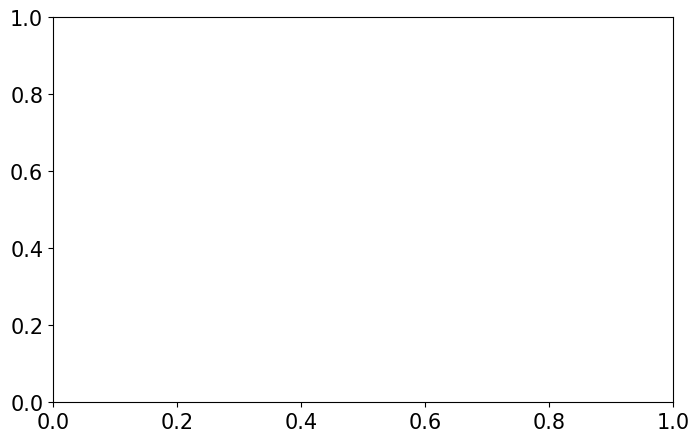

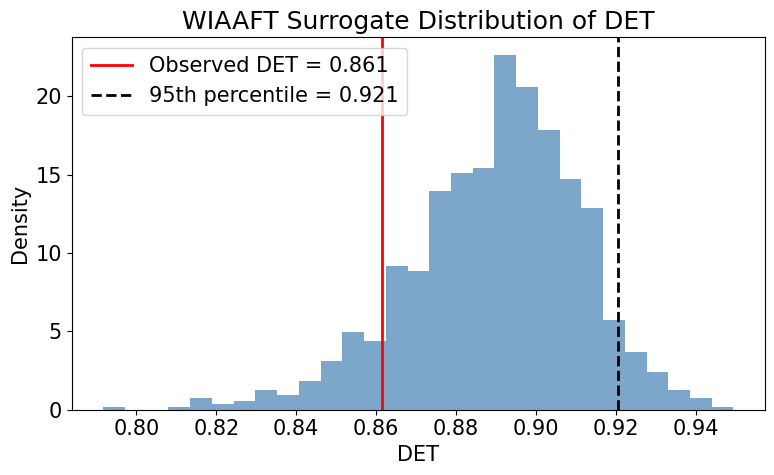

 63%|██████████████████████████▍               | 63/100 [25:48<15:40, 25.41s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8614678899043052 
 Recurrence rate: 0.05001980776047205 
Threshold:2.0195999999998375 
 Laminarity:0.923718215919451 
Shannon Entropy:1.6347633950059475 
Rank-order p-value (det):0.903 
Reject null (det) hypothesis:False

 
 

2
9
WIAAFT surrogate datasets generated


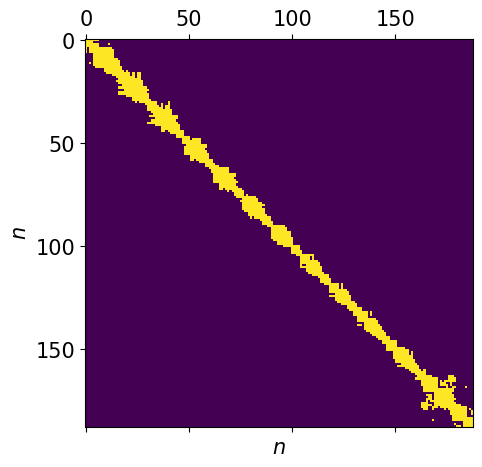

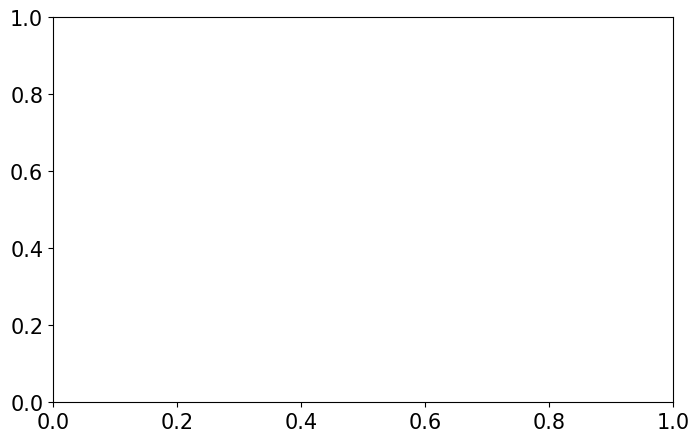

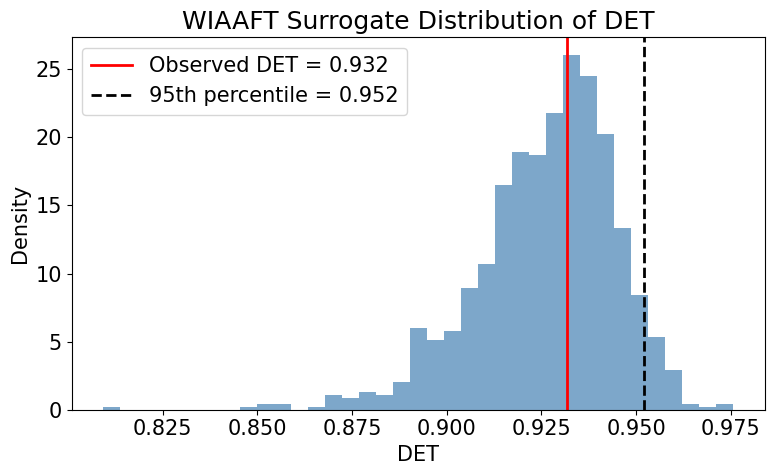

 64%|██████████████████████████▉               | 64/100 [26:09<14:26, 24.07s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9316455696143567 
 Recurrence rate: 0.05002263467632413 
Threshold:1.0435999999999015 
 Laminarity:0.9773755656053317 
Shannon Entropy:2.1113998920361006 
Rank-order p-value (det):0.436 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


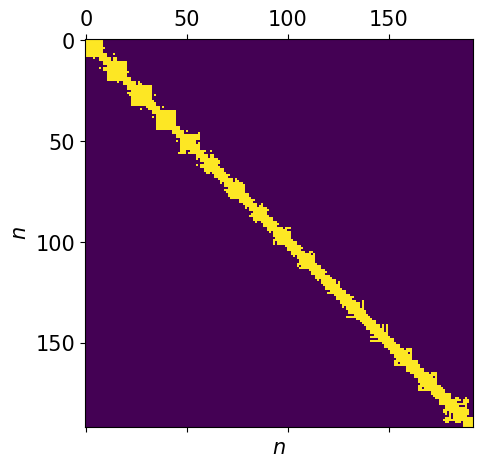

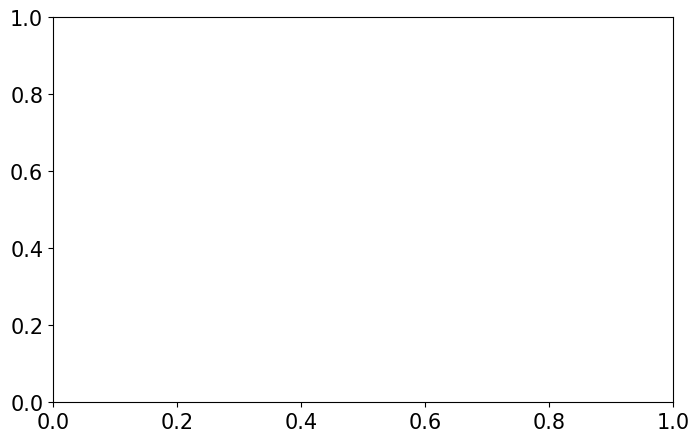

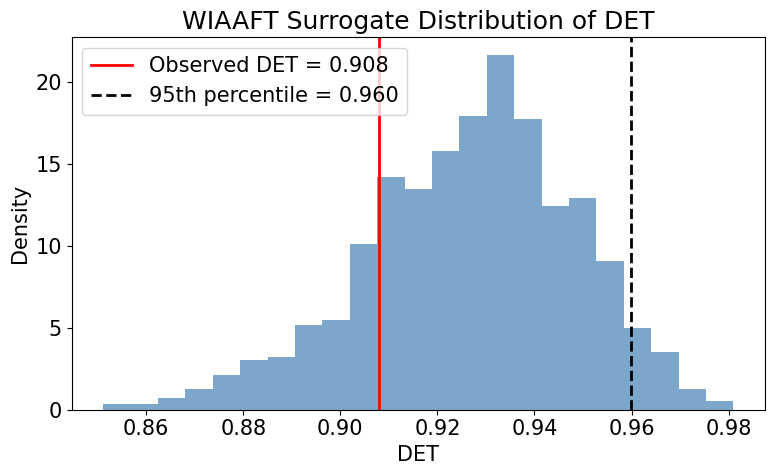

 65%|███████████████████████████▎              | 65/100 [26:32<13:47, 23.65s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9079903147644796 
 Recurrence rate: 0.05002170138888889 
Threshold:1.4603999999998556 
 Laminarity:0.9745119305803985 
Shannon Entropy:1.941913783692462 
Rank-order p-value (det):0.818 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


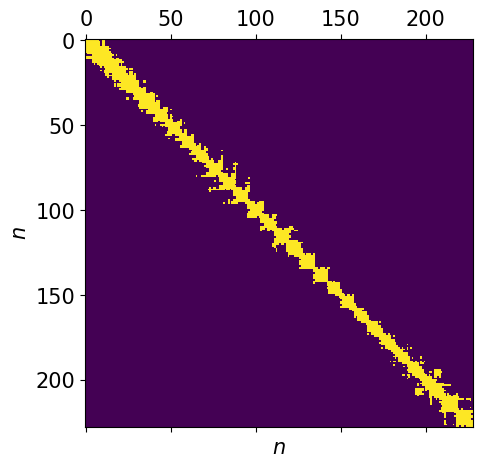

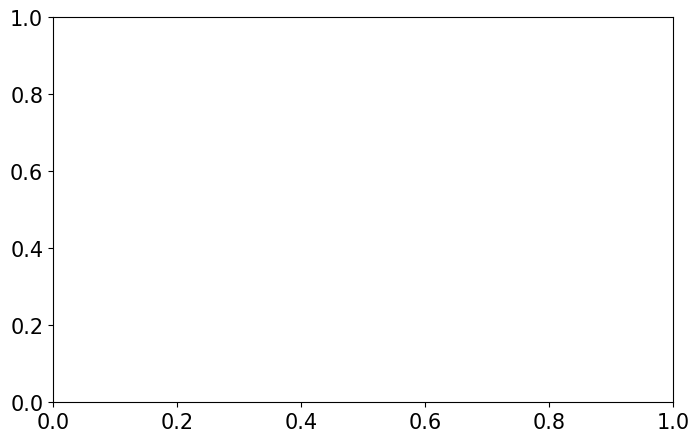

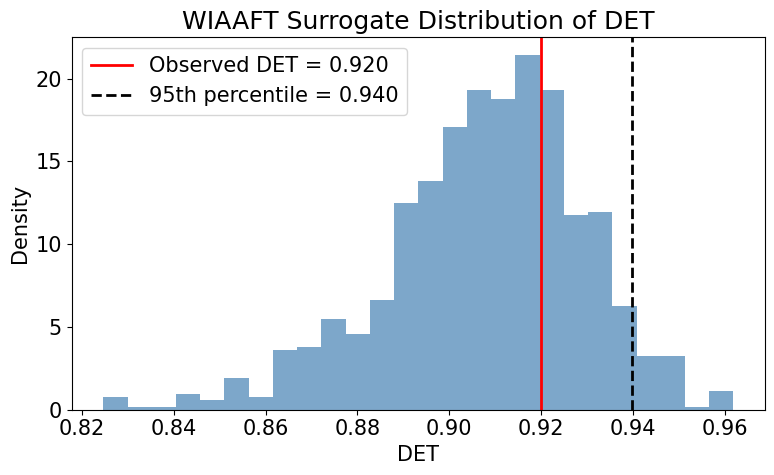

 66%|███████████████████████████▋              | 66/100 [26:55<13:26, 23.73s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9198988195576733 
 Recurrence rate: 0.05001538935056941 
Threshold:1.265699999999877 
 Laminarity:0.963076923073219 
Shannon Entropy:1.8064941618019308 
Rank-order p-value (det):0.302 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


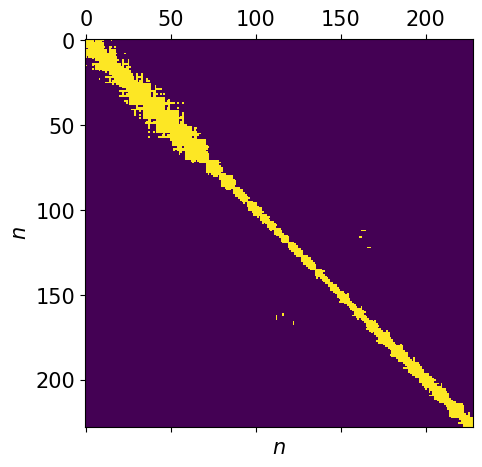

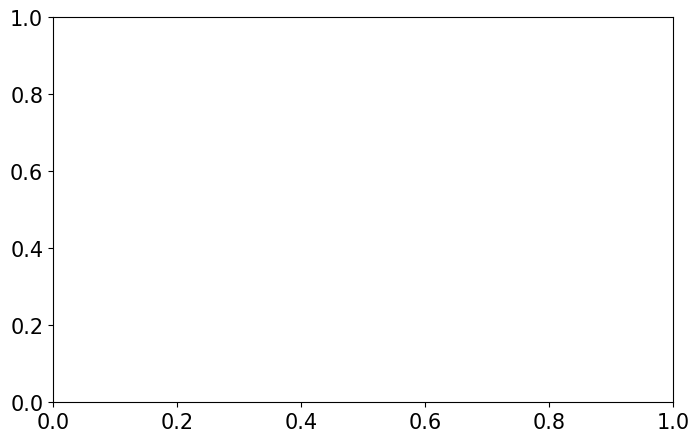

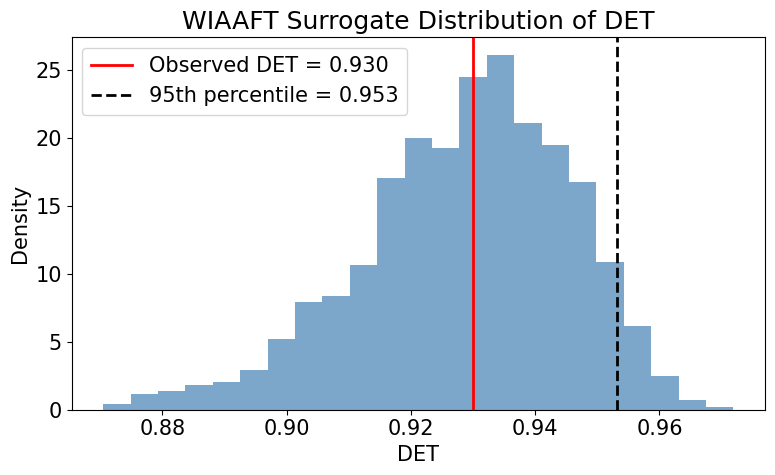

 67%|████████████████████████████▏             | 67/100 [27:21<13:24, 24.39s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9300168634024873 
 Recurrence rate: 0.05001538935056941 
Threshold:1.5124999999998499 
 Laminarity:0.9657692307655164 
Shannon Entropy:2.0139316239725114 
Rank-order p-value (det):0.52 
Reject null (det) hypothesis:False

 
 

2
9
WIAAFT surrogate datasets generated


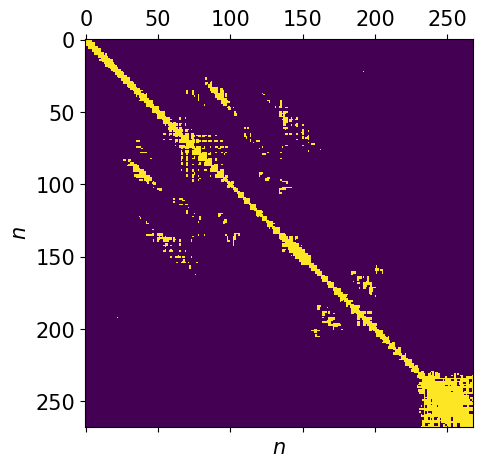

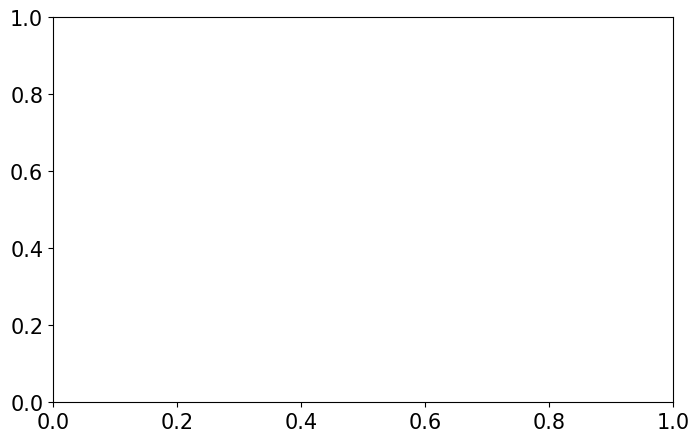

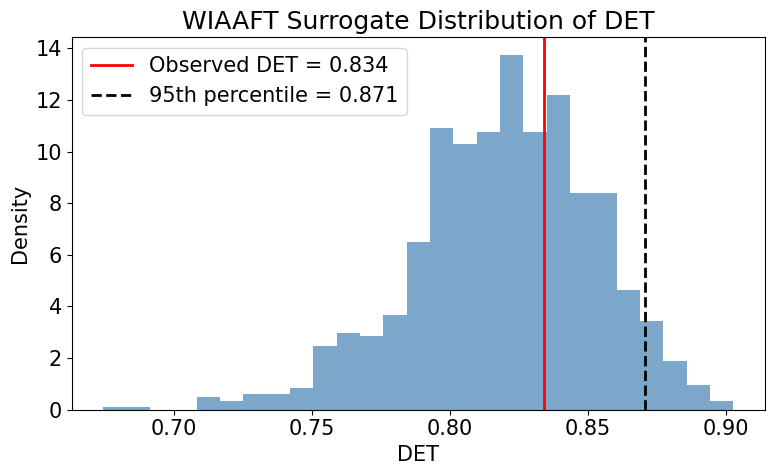

 68%|████████████████████████████▌             | 68/100 [27:48<13:22, 25.09s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8340348767262957 
 Recurrence rate: 0.050038984183559815 
Threshold:1.3239999999998706 
 Laminarity:0.9243183082890253 
Shannon Entropy:1.3915859084387923 
Rank-order p-value (det):0.347 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


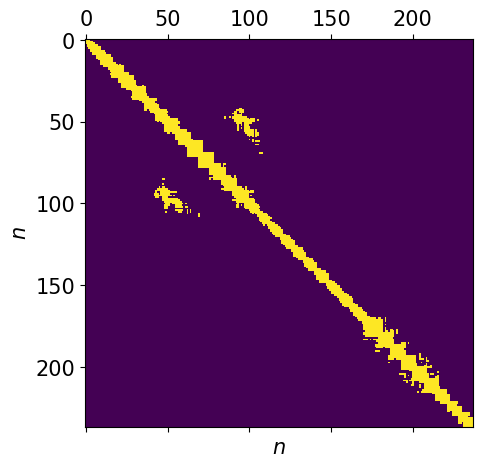

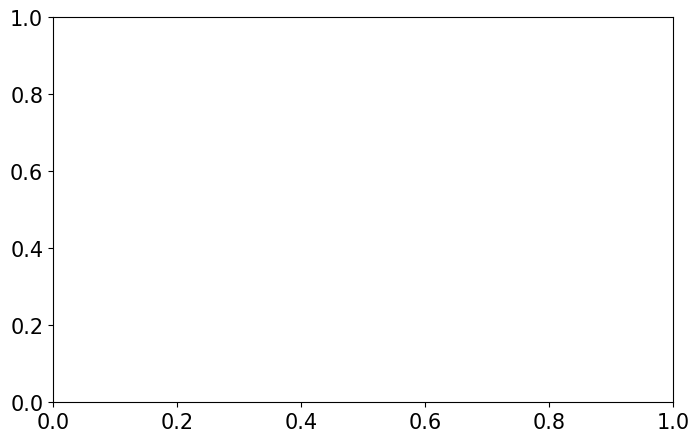

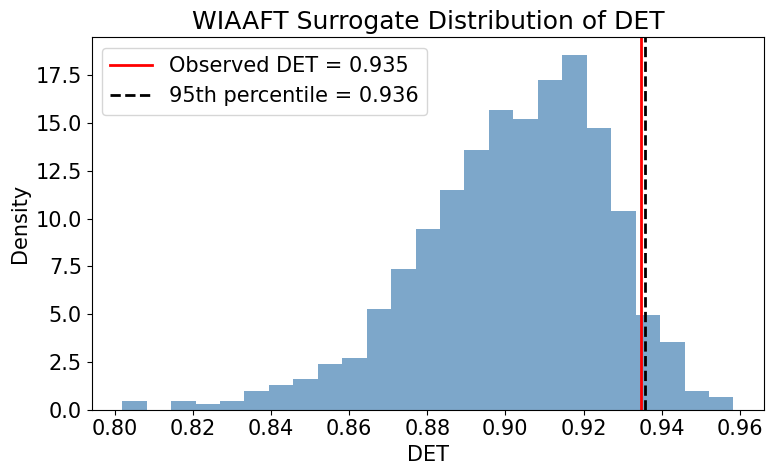

 69%|████████████████████████████▉             | 69/100 [28:14<13:02, 25.23s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9347319347283033 
 Recurrence rate: 0.05004539870747209 
Threshold:1.429199999999859 
 Laminarity:0.9722518676592947 
Shannon Entropy:1.8835370294822895 
Rank-order p-value (det):0.056 
Reject null (det) hypothesis:False

 
 

2
8
WIAAFT surrogate datasets generated


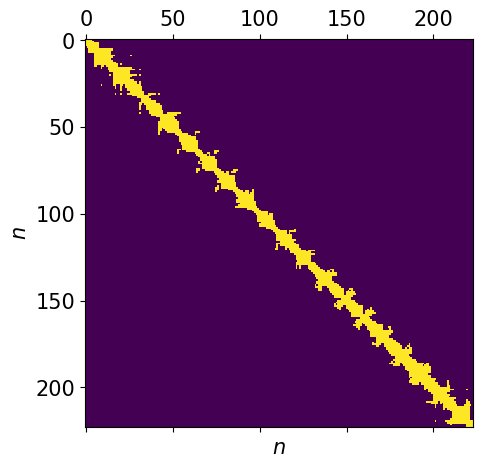

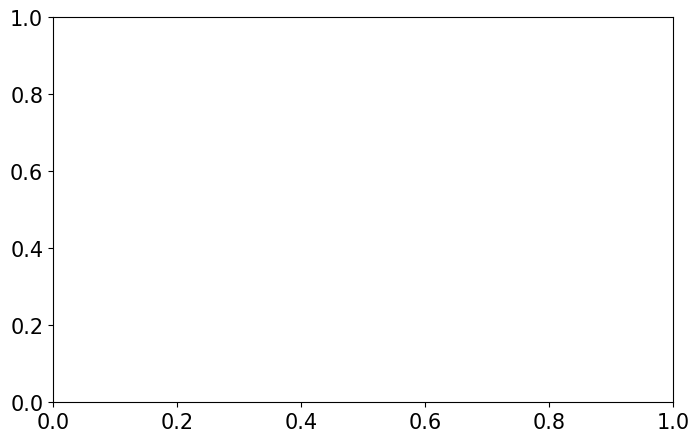

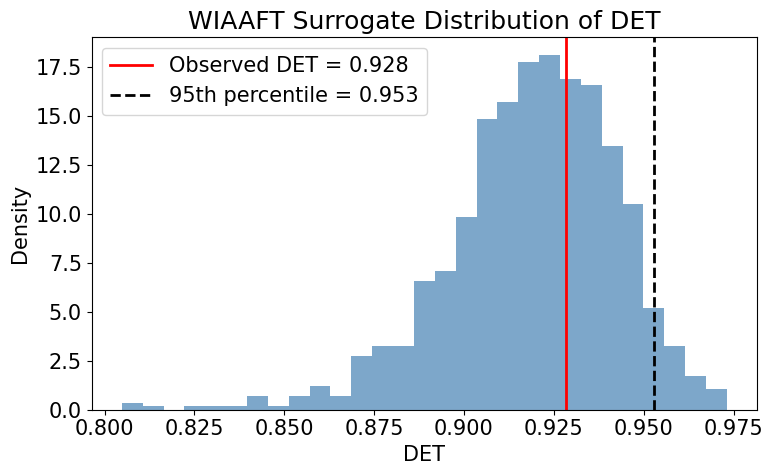

 70%|█████████████████████████████▍            | 70/100 [28:35<12:03, 24.11s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9284452296778779 
 Recurrence rate: 0.05001105994490136 
Threshold:1.0288999999999031 
 Laminarity:0.9718536389184887 
Shannon Entropy:1.9891642861829617 
Rank-order p-value (det):0.367 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


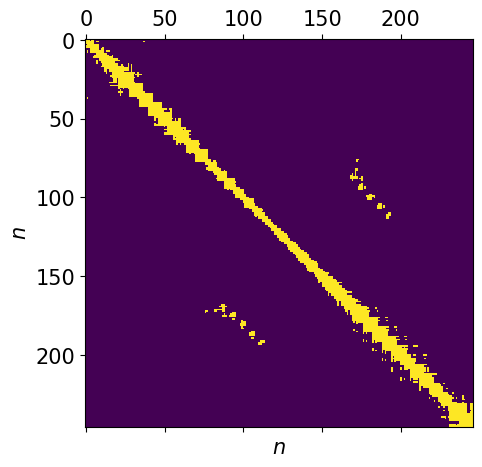

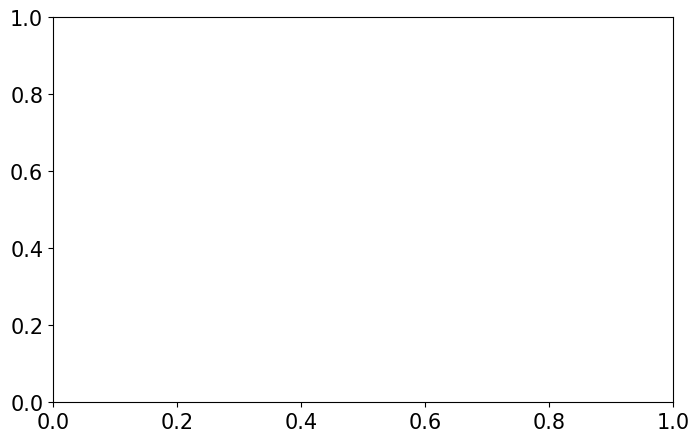

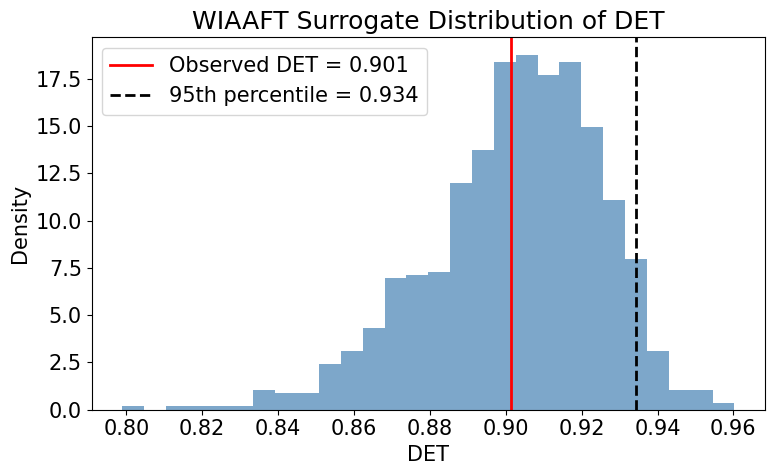

 71%|█████████████████████████████▊            | 71/100 [29:01<11:50, 24.49s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9014388489176207 
 Recurrence rate: 0.05000330491109789 
Threshold:1.2670999999998769 
 Laminarity:0.9567085261039104 
Shannon Entropy:1.6703203678815568 
Rank-order p-value (det):0.566 
Reject null (det) hypothesis:False

 
 

2
10
WIAAFT surrogate datasets generated


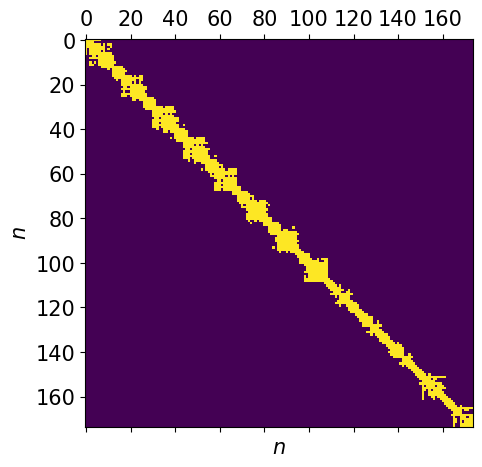

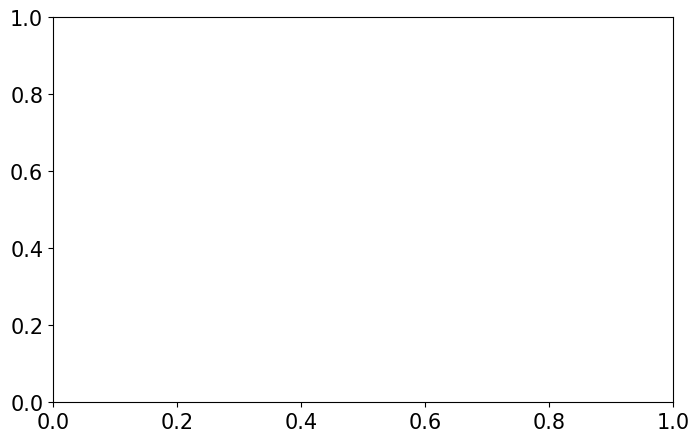

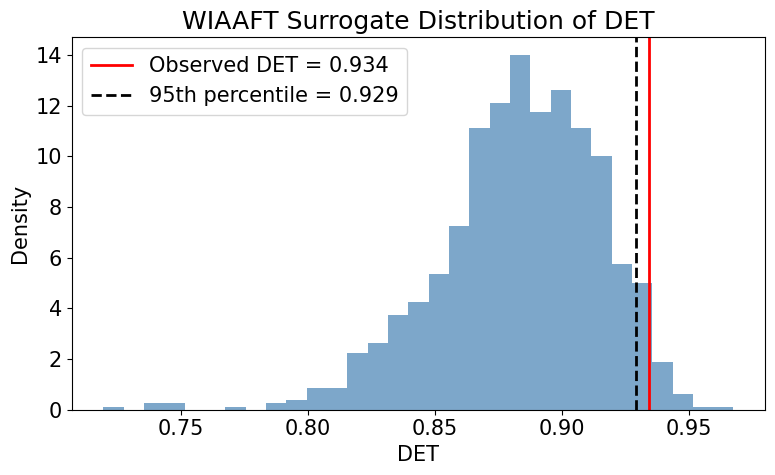

 72%|██████████████████████████████▏           | 72/100 [29:22<11:00, 23.61s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9343283582019827 
 Recurrence rate: 0.05000660589245607 
Threshold:1.2558999999998781 
 Laminarity:0.9570673711957922 
Shannon Entropy:1.7981406701949245 
Rank-order p-value (det):0.028 
Reject null (det) hypothesis:True

 
 

3
10
WIAAFT surrogate datasets generated


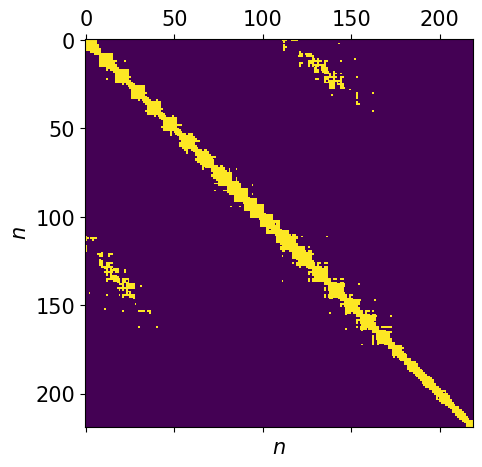

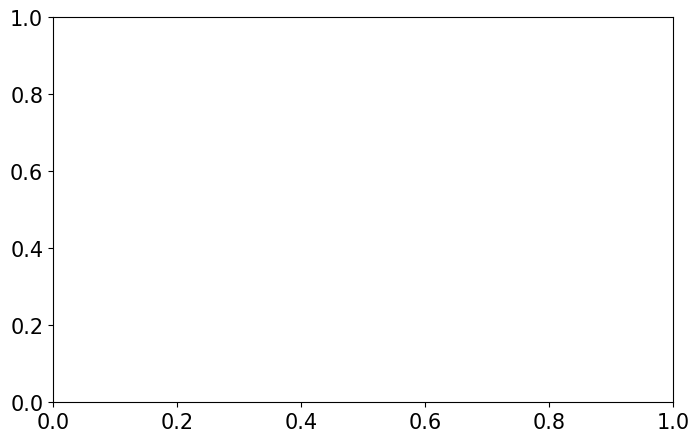

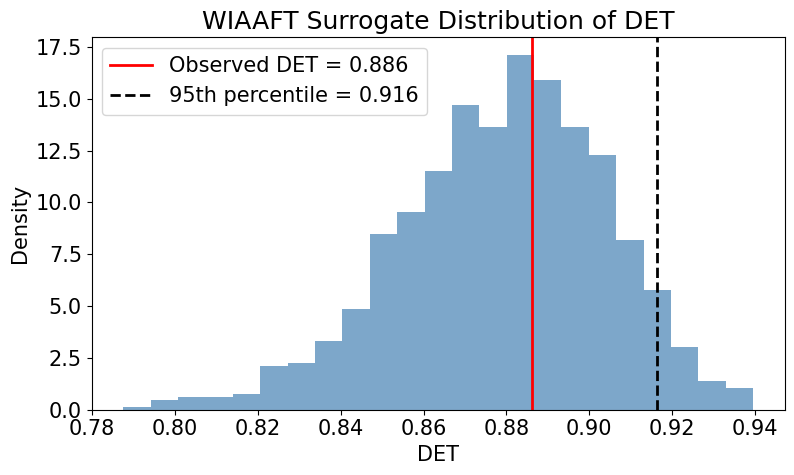

 73%|██████████████████████████████▋           | 73/100 [29:49<11:00, 24.47s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8862385321060264 
 Recurrence rate: 0.05001980776047205 
Threshold:1.847199999999813 
 Laminarity:0.9424760316759381 
Shannon Entropy:1.889065578574667 
Rank-order p-value (det):0.412 
Reject null (det) hypothesis:False

 
 

3
10
WIAAFT surrogate datasets generated


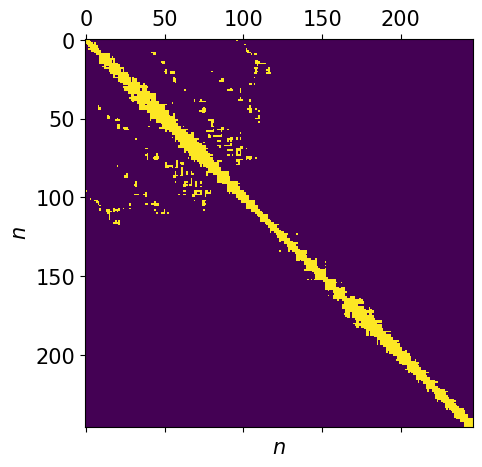

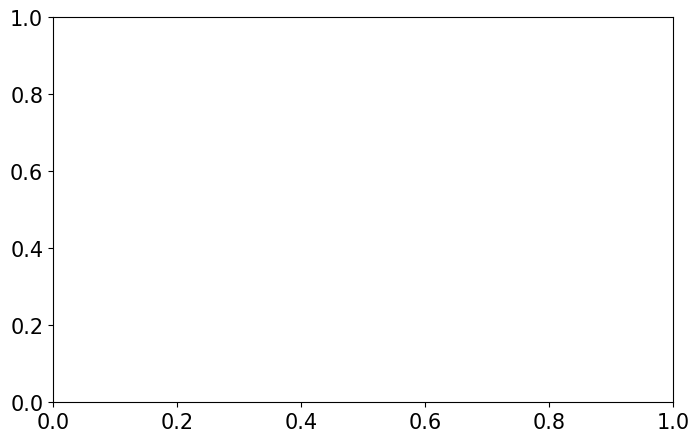

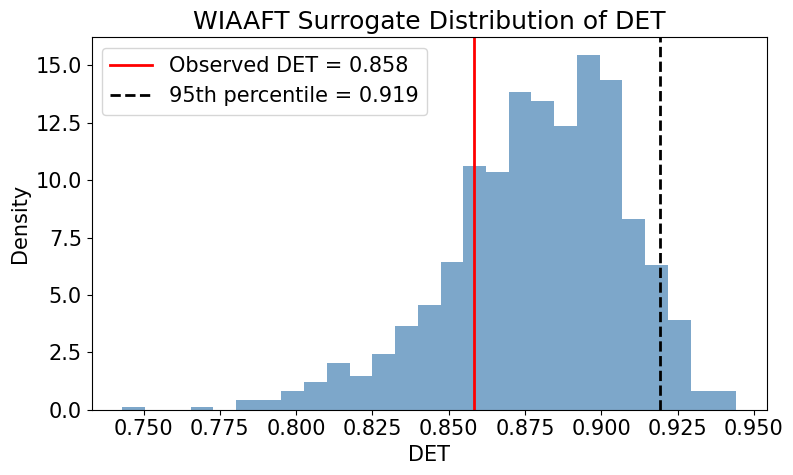

 74%|███████████████████████████████           | 74/100 [30:14<10:43, 24.74s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8582733812918768 
 Recurrence rate: 0.05000330491109789 
Threshold:1.3367999999998692 
 Laminarity:0.9342366159916251 
Shannon Entropy:1.5632927462468564 
Rank-order p-value (det):0.794 
Reject null (det) hypothesis:False

 
 

3
10
WIAAFT surrogate datasets generated


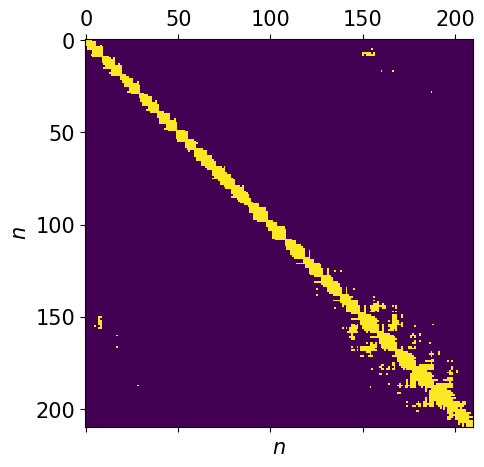

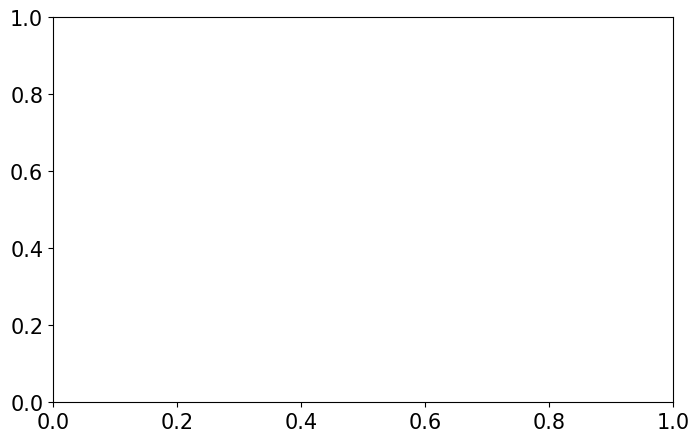

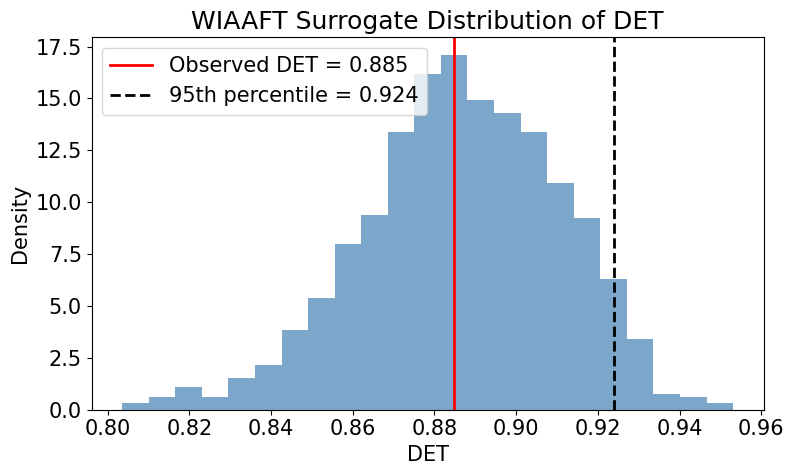

 75%|███████████████████████████████▌          | 75/100 [30:39<10:18, 24.72s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8847695390737237 
 Recurrence rate: 0.05002267573696145 
Threshold:1.6351999999998363 
 Laminarity:0.9410698096058883 
Shannon Entropy:1.8327029498735588 
Rank-order p-value (det):0.541 
Reject null (det) hypothesis:False

 
 

3
8
WIAAFT surrogate datasets generated


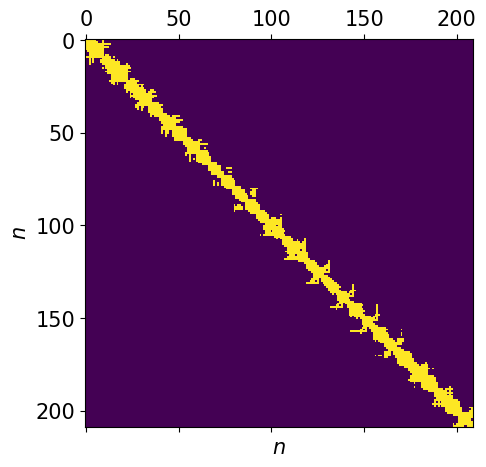

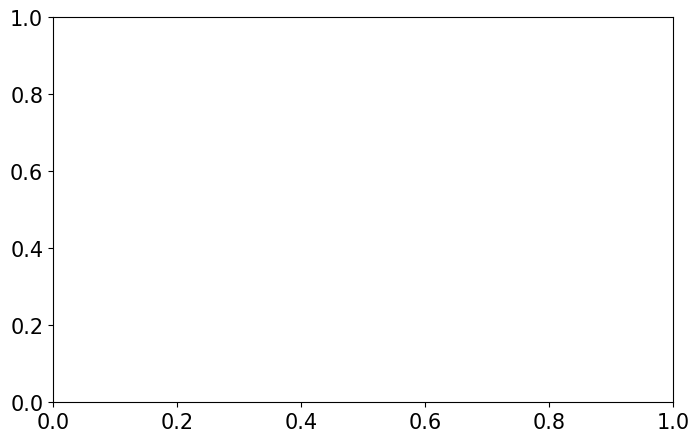

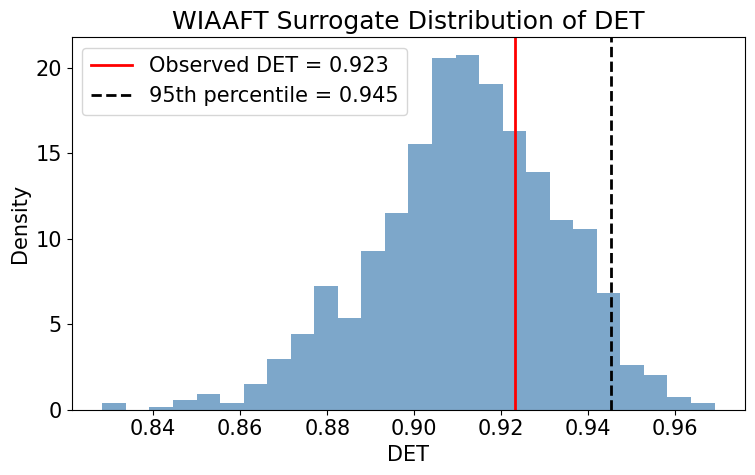

 76%|███████████████████████████████▉          | 76/100 [31:00<09:28, 23.69s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9230769230722516 
 Recurrence rate: 0.05002174858634189 
Threshold:1.0737999999998982 
 Laminarity:0.9597254004532736 
Shannon Entropy:1.857529072939112 
Rank-order p-value (det):0.296 
Reject null (det) hypothesis:False

 
 

3
10
WIAAFT surrogate datasets generated


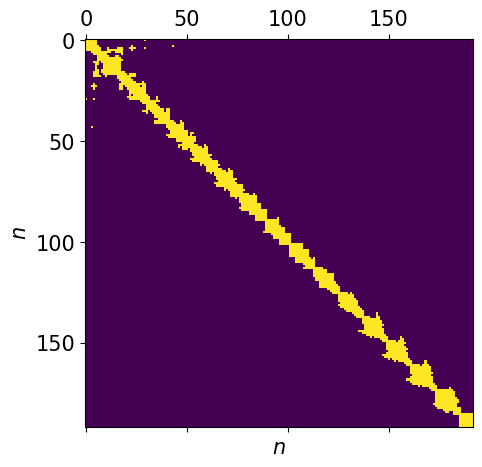

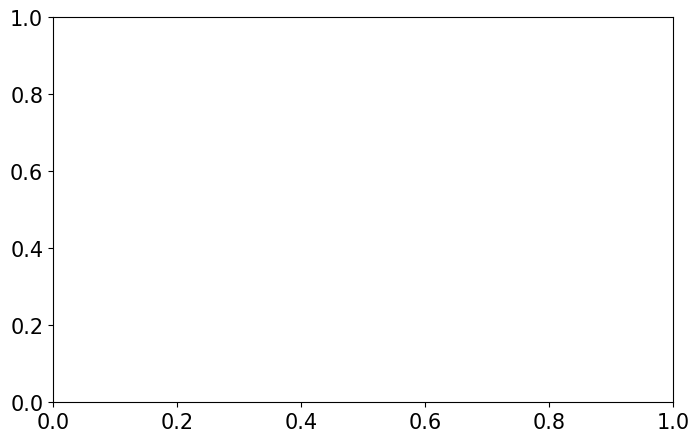

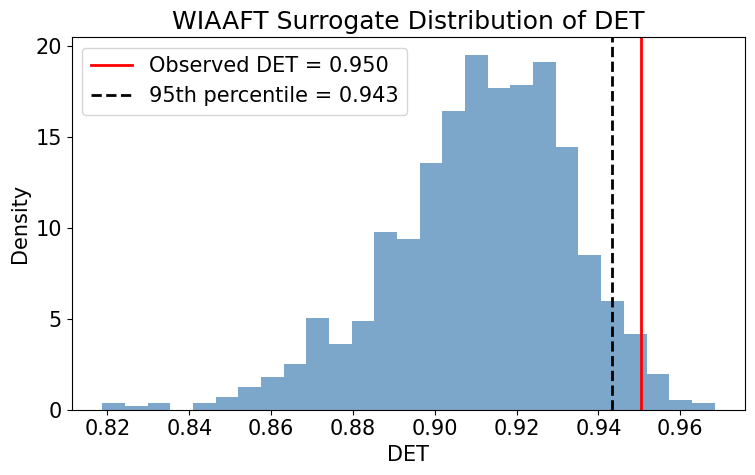

 77%|████████████████████████████████▎         | 77/100 [31:23<08:58, 23.42s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9503631961201553 
 Recurrence rate: 0.05002170138888889 
Threshold:1.4513999999998566 
 Laminarity:0.97668112797735 
Shannon Entropy:2.0316147951960257 
Rank-order p-value (det):0.026 
Reject null (det) hypothesis:True

 
 

4
10
WIAAFT surrogate datasets generated


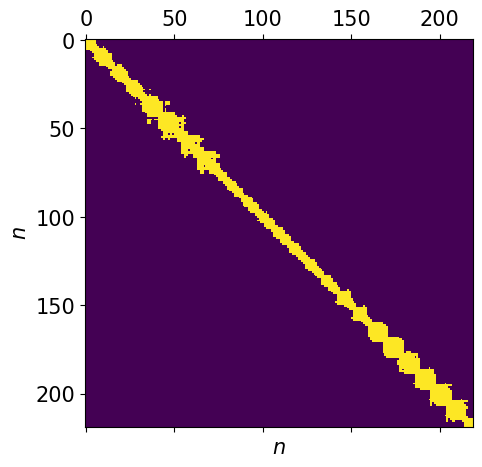

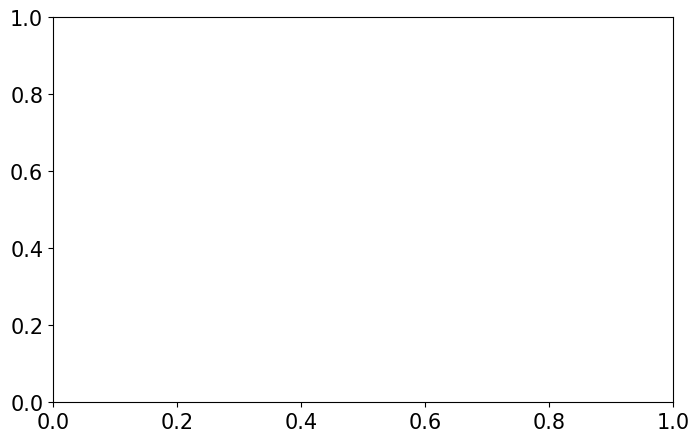

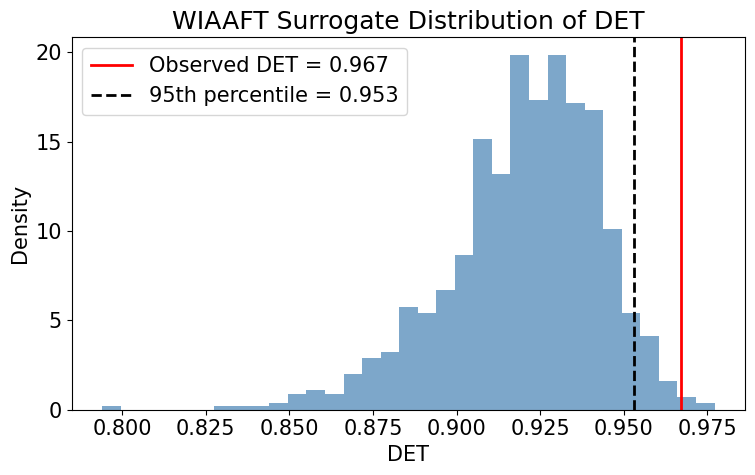

 78%|████████████████████████████████▊         | 78/100 [31:46<08:36, 23.47s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9669724770597846 
 Recurrence rate: 0.05001980776047205 
Threshold:1.0611999999998996 
 Laminarity:0.9899958315923719 
Shannon Entropy:2.1438870419923886 
Rank-order p-value (det):0.006 
Reject null (det) hypothesis:True

 
 

5
10
WIAAFT surrogate datasets generated


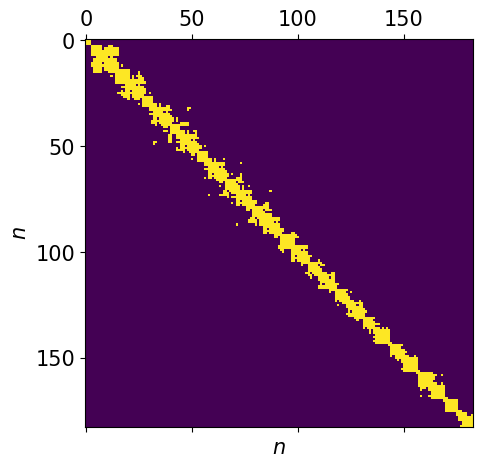

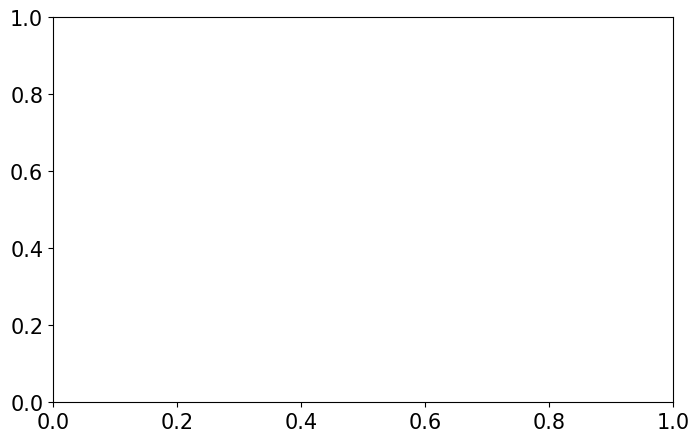

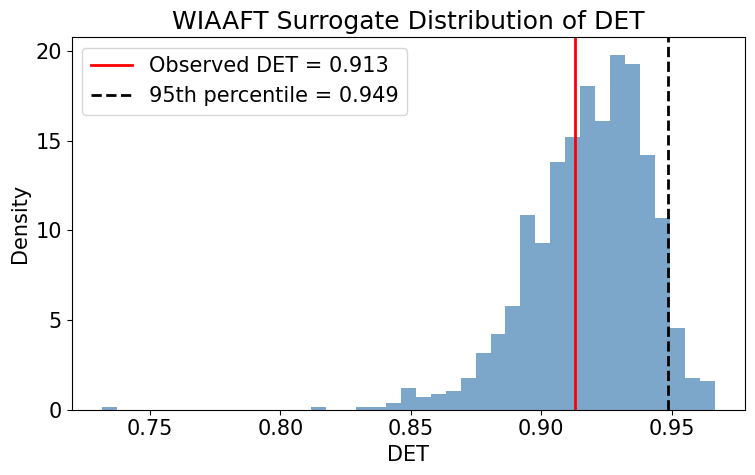

 79%|█████████████████████████████████▏        | 79/100 [32:06<07:48, 22.30s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9128686327016564 
 Recurrence rate: 0.05001642330317418 
Threshold:0.9776999999999086 
 Laminarity:0.9552238805913121 
Shannon Entropy:1.6761534577513029 
Rank-order p-value (det):0.65 
Reject null (det) hypothesis:False

 
 

5
10
WIAAFT surrogate datasets generated


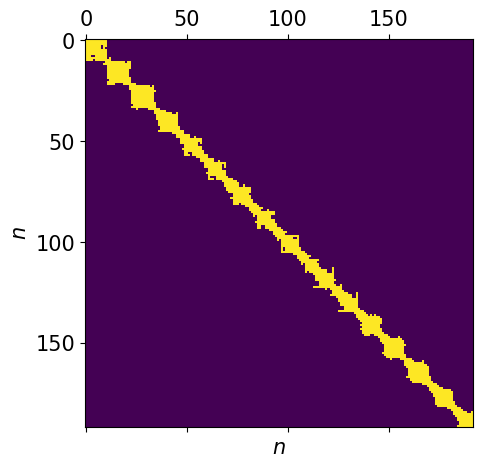

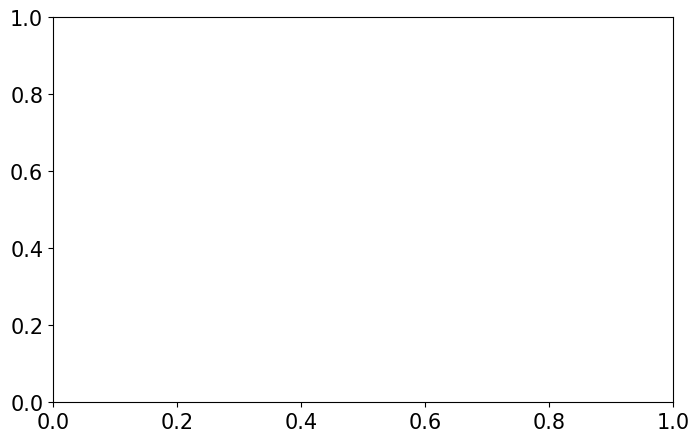

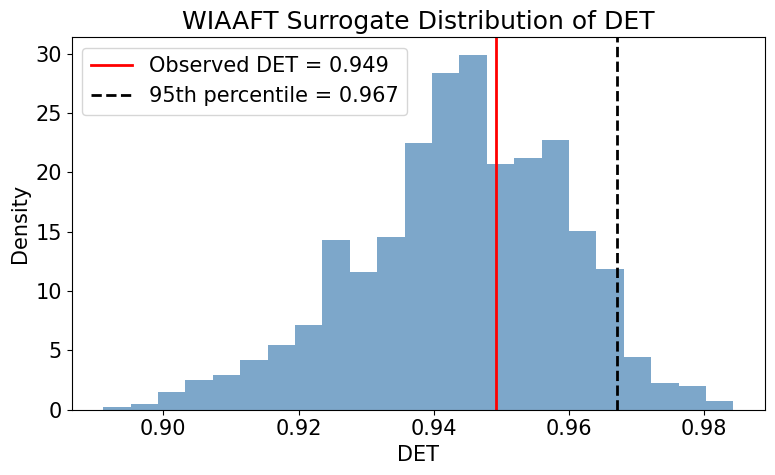

 80%|█████████████████████████████████▌        | 80/100 [32:28<07:22, 22.14s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.949152542367136 
 Recurrence rate: 0.05002170138888889 
Threshold:1.2680999999998768 
 Laminarity:0.9815618221204905 
Shannon Entropy:2.191006421443446 
Rank-order p-value (det):0.378 
Reject null (det) hypothesis:False

 
 

5
7
WIAAFT surrogate datasets generated


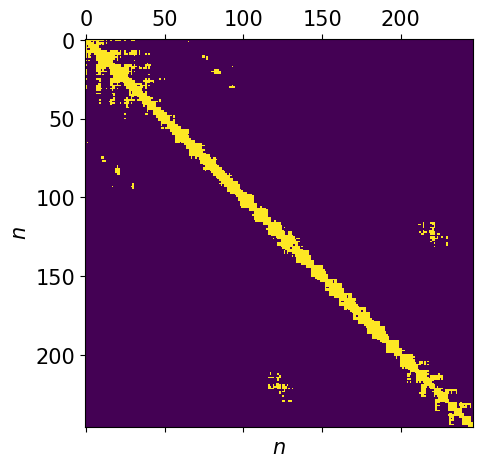

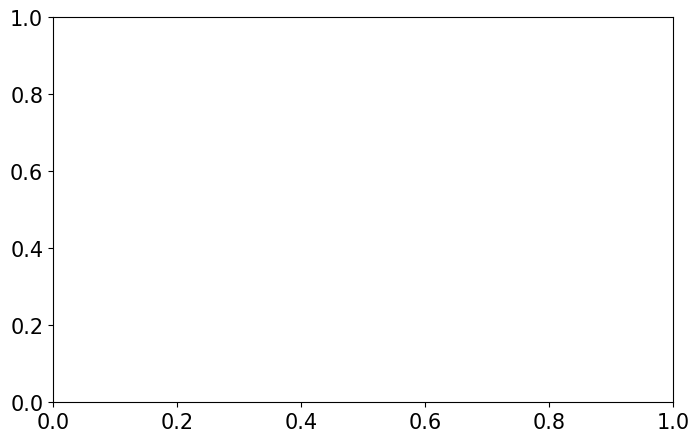

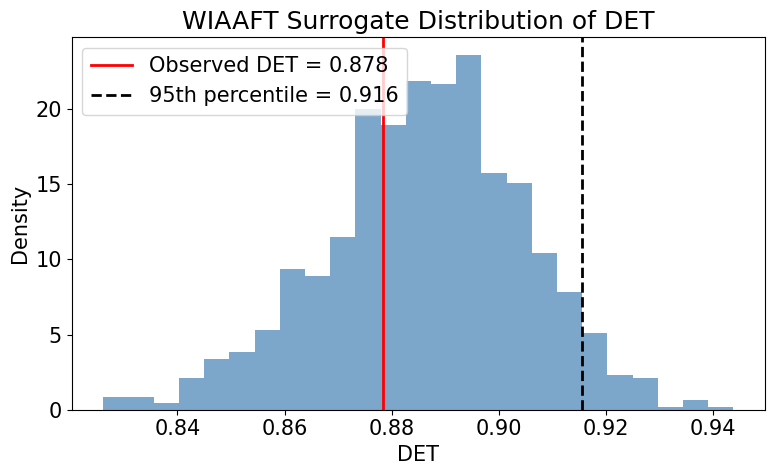

 81%|██████████████████████████████████        | 81/100 [32:50<07:03, 22.30s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8784172661838906 
 Recurrence rate: 0.05000330491109789 
Threshold:1.0409999999999018 
 Laminarity:0.9401850627860536 
Shannon Entropy:1.79458275014649 
Rank-order p-value (det):0.679 
Reject null (det) hypothesis:False

 
 

5
10
WIAAFT surrogate datasets generated


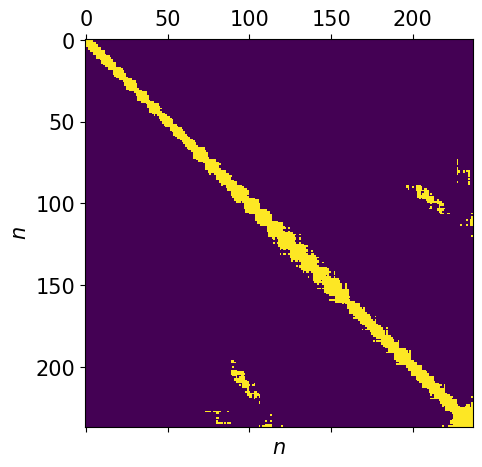

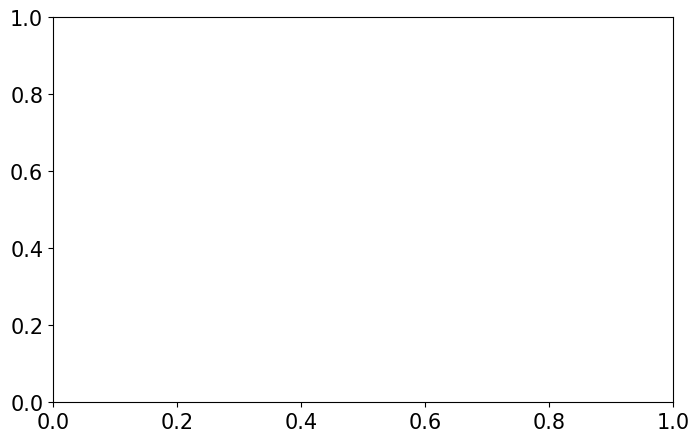

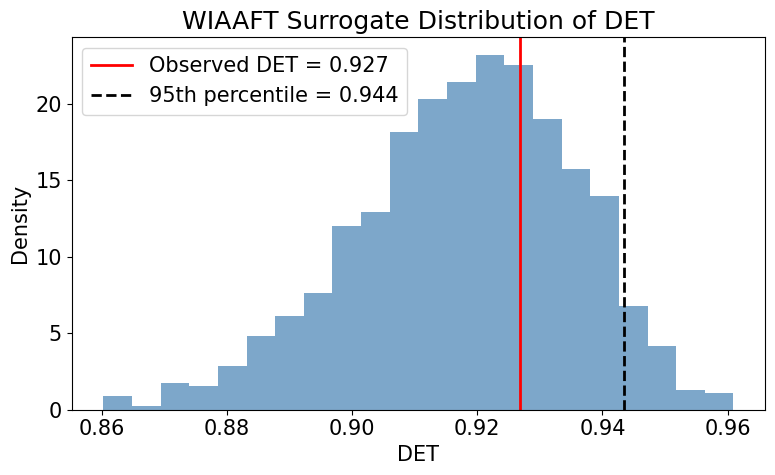

 82%|██████████████████████████████████▍       | 82/100 [33:21<07:26, 24.79s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9269051321892422 
 Recurrence rate: 0.050009791878082216 
Threshold:2.107100000000022 
 Laminarity:0.9647561409720016 
Shannon Entropy:2.02675032145298 
Rank-order p-value (det):0.325 
Reject null (det) hypothesis:False

 
 

5
10
WIAAFT surrogate datasets generated


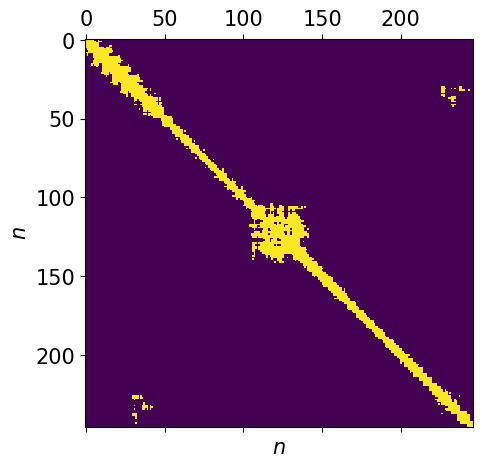

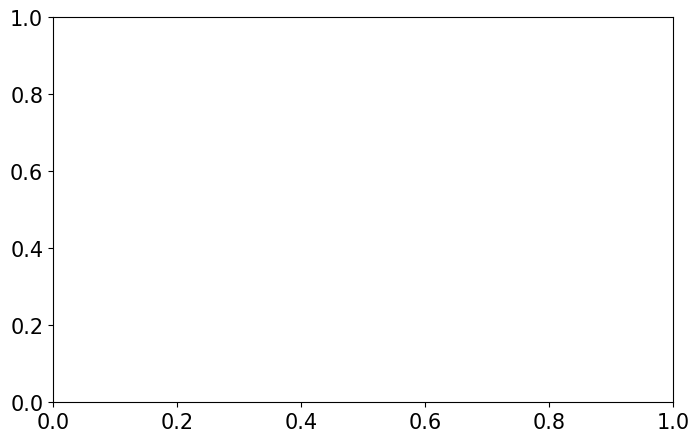

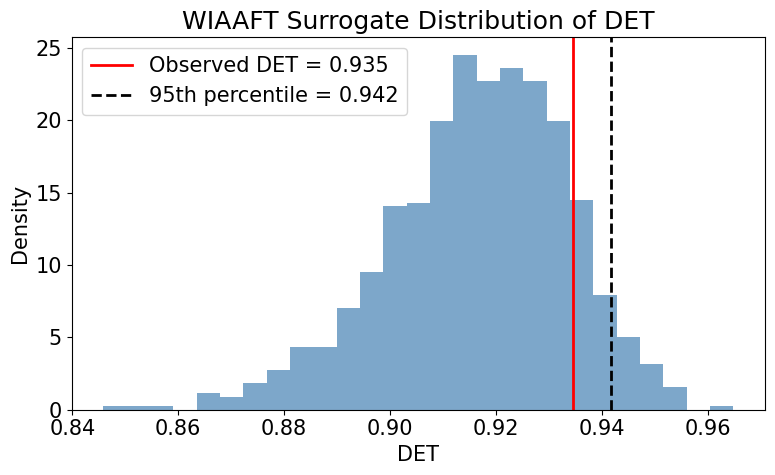

 83%|██████████████████████████████████▊       | 83/100 [33:44<06:55, 24.42s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9345323740973578 
 Recurrence rate: 0.05000330491109789 
Threshold:1.094499999999896 
 Laminarity:0.9695968274918387 
Shannon Entropy:2.1003583311603524 
Rank-order p-value (det):0.14 
Reject null (det) hypothesis:False

 
 

5
10
WIAAFT surrogate datasets generated


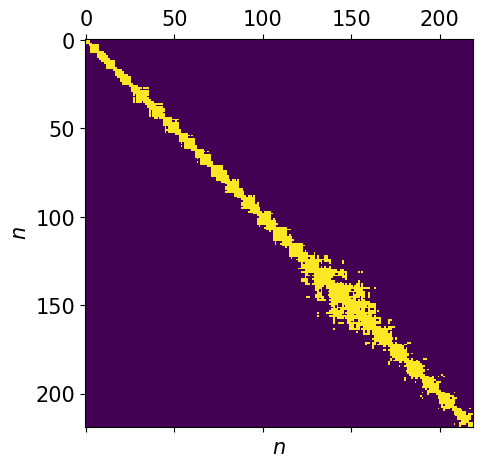

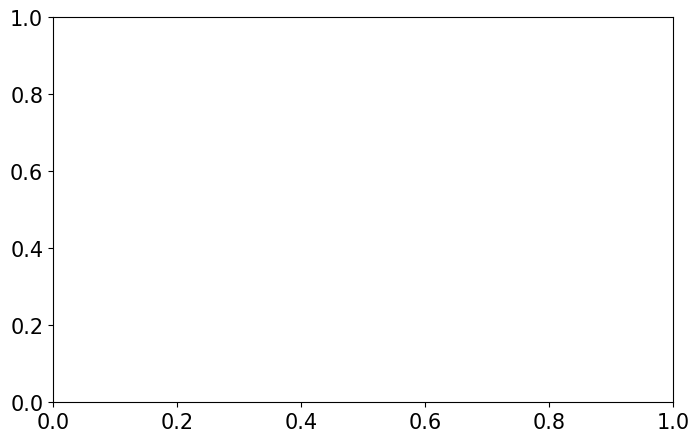

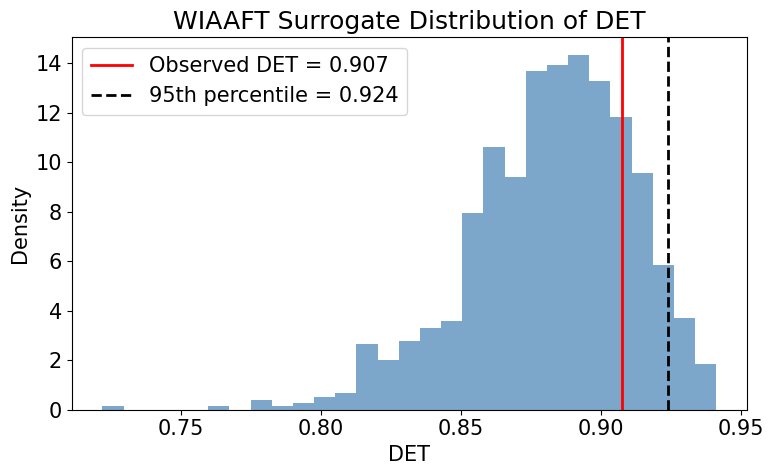

 84%|███████████████████████████████████▎      | 84/100 [34:09<06:32, 24.56s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9073394495371223 
 Recurrence rate: 0.05001980776047205 
Threshold:1.5234999999998486 
 Laminarity:0.947478115877668 
Shannon Entropy:1.8711328129593174 
Rank-order p-value (det):0.195 
Reject null (det) hypothesis:False

 
 

5
9
WIAAFT surrogate datasets generated


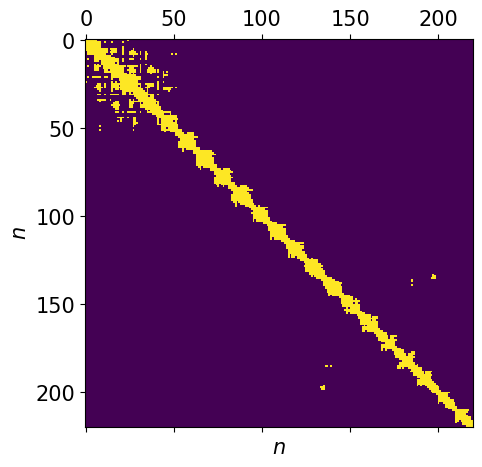

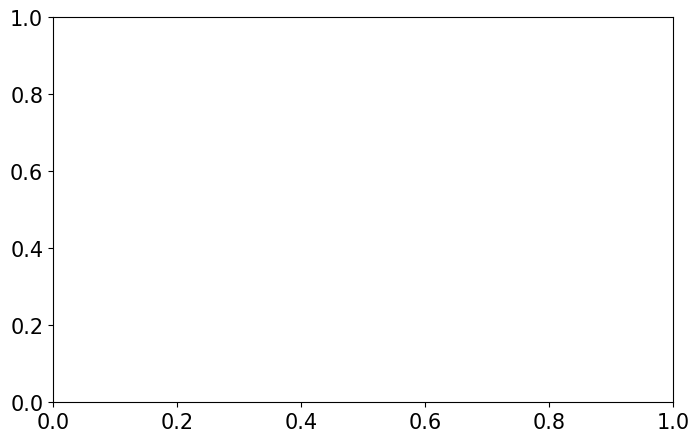

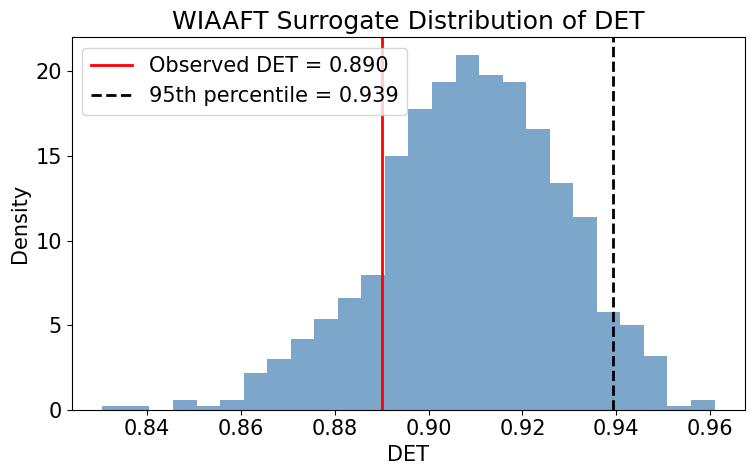

 85%|███████████████████████████████████▋      | 85/100 [34:32<05:58, 23.92s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8899999999959546 
 Recurrence rate: 0.05 
Threshold:1.1425999999998906 
 Laminarity:0.9466942148721211 
Shannon Entropy:1.8649240412665904 
Rank-order p-value (det):0.851 
Reject null (det) hypothesis:False

 
 

5
10
WIAAFT surrogate datasets generated


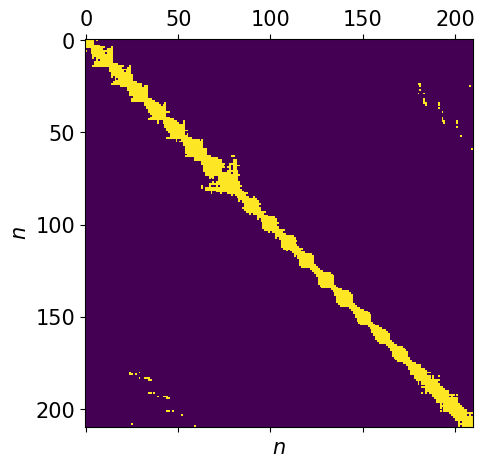

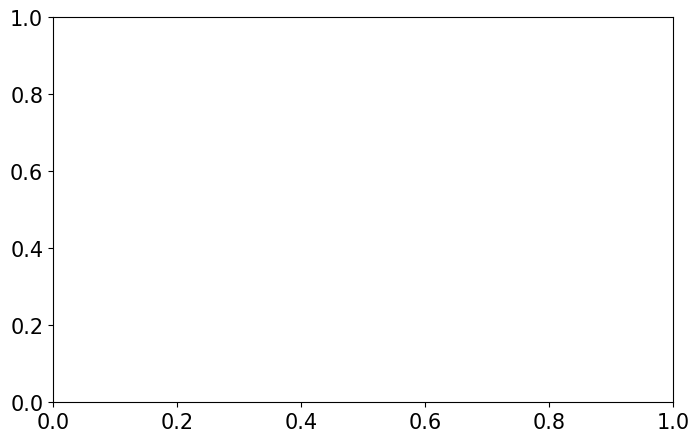

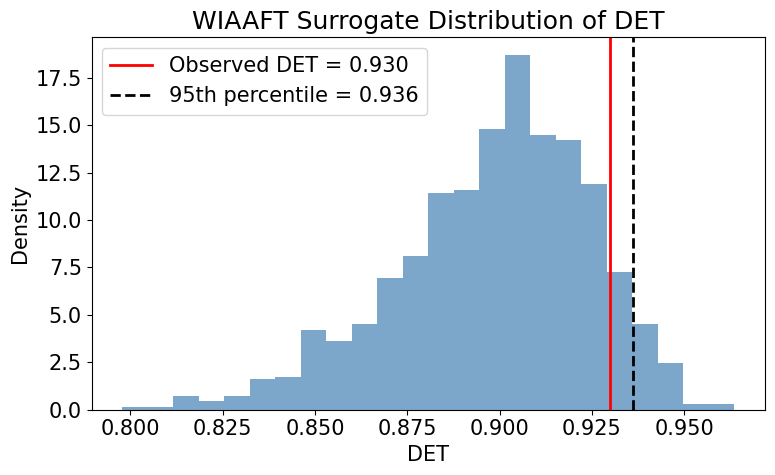

 86%|████████████████████████████████████      | 86/100 [34:59<05:46, 24.78s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9298597194342192 
 Recurrence rate: 0.05002267573696145 
Threshold:2.0299999999998595 
 Laminarity:0.9623753399775051 
Shannon Entropy:2.1874137065610313 
Rank-order p-value (det):0.098 
Reject null (det) hypothesis:False

 
 

5
10
WIAAFT surrogate datasets generated


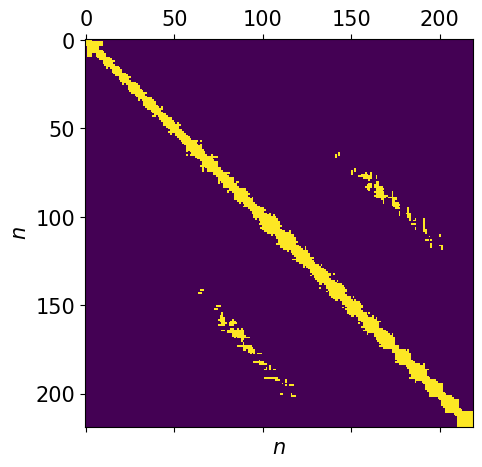

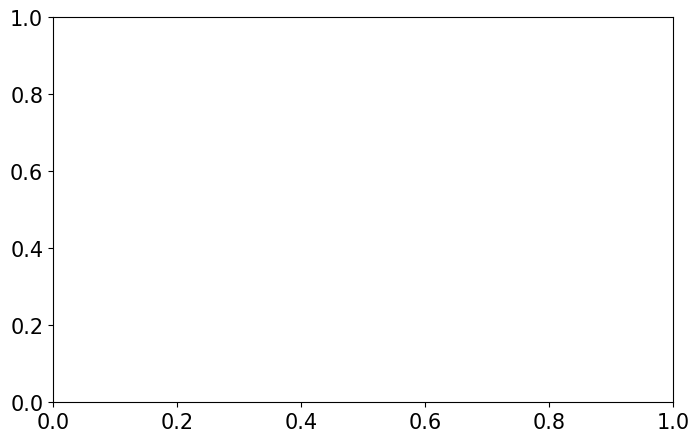

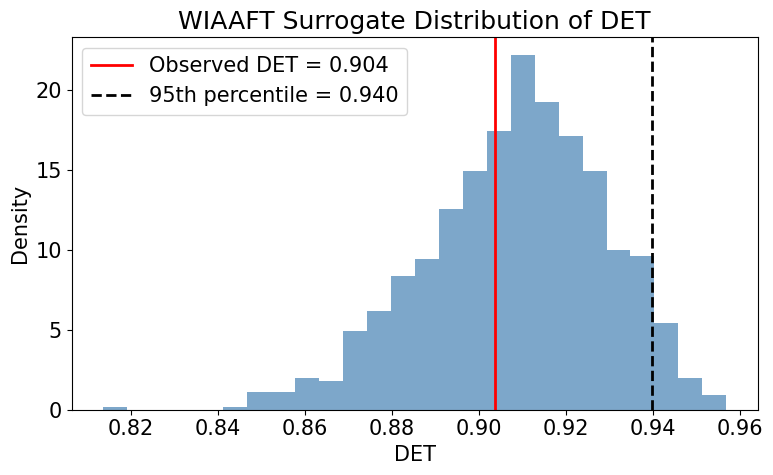

 87%|████████████████████████████████████▌     | 87/100 [35:23<05:22, 24.79s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.903669724766497 
 Recurrence rate: 0.05001980776047205 
Threshold:1.5825999999998421 
 Laminarity:0.9520633597292536 
Shannon Entropy:1.9120342530403927 
Rank-order p-value (det):0.624 
Reject null (det) hypothesis:False

 
 

5
10
WIAAFT surrogate datasets generated


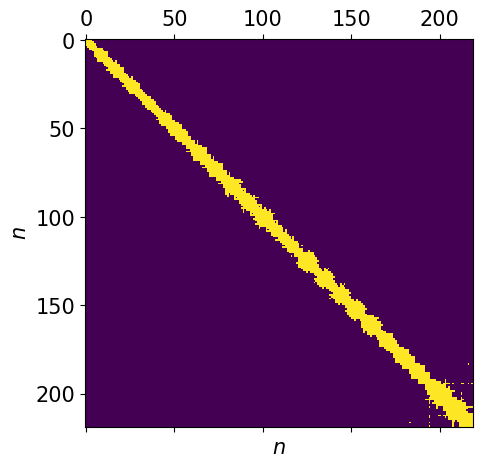

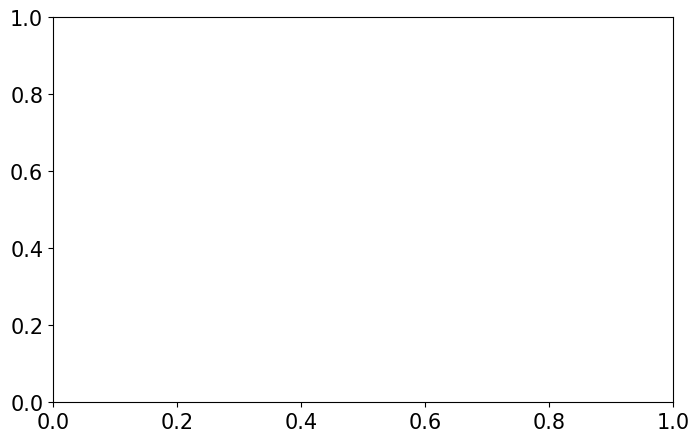

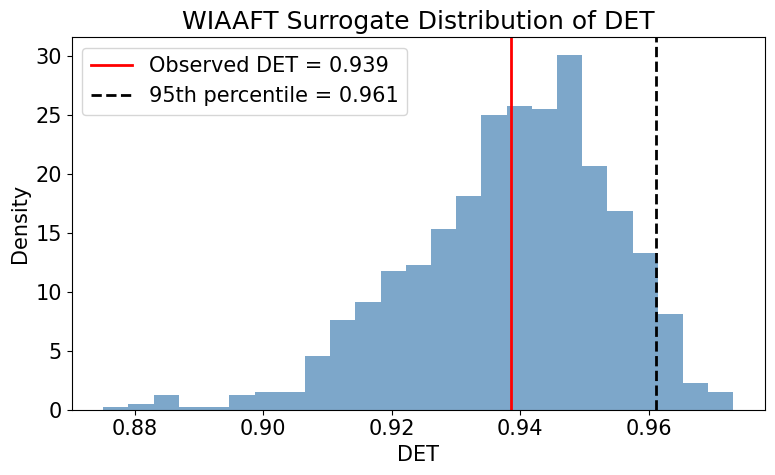

 88%|████████████████████████████████████▉     | 88/100 [35:47<04:54, 24.54s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.938532110087438 
 Recurrence rate: 0.05001980776047205 
Threshold:1.448599999999857 
 Laminarity:0.9724885368863173 
Shannon Entropy:2.0045765620410734 
Rank-order p-value (det):0.552 
Reject null (det) hypothesis:False

 
 

5
10
WIAAFT surrogate datasets generated


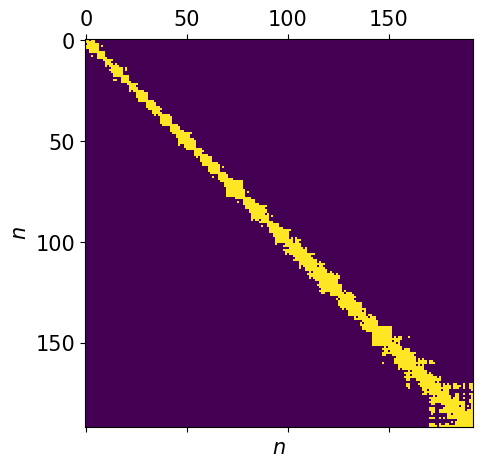

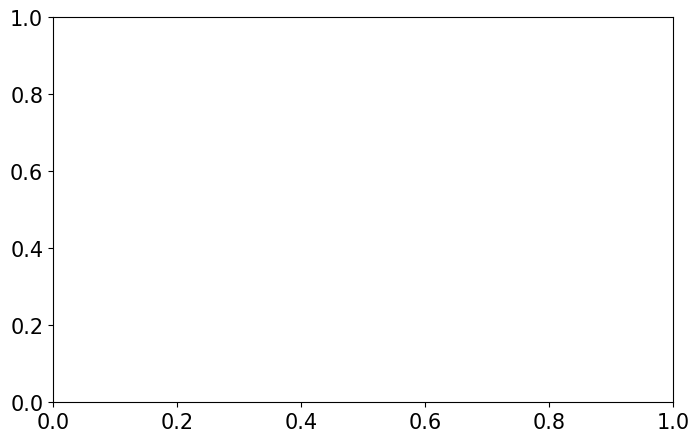

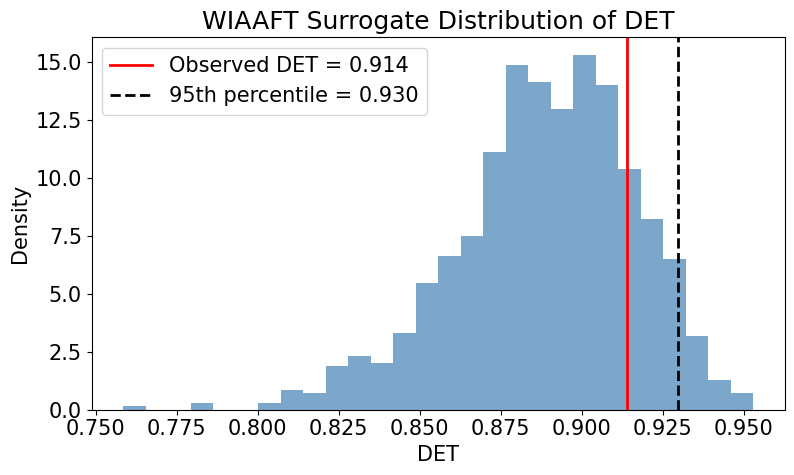

 89%|█████████████████████████████████████▍    | 89/100 [36:08<04:16, 23.36s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.914043583529576 
 Recurrence rate: 0.05002170138888889 
Threshold:1.2170999999998824 
 Laminarity:0.9614967461986904 
Shannon Entropy:1.8766477020590606 
Rank-order p-value (det):0.185 
Reject null (det) hypothesis:False

 
 

5
9
WIAAFT surrogate datasets generated


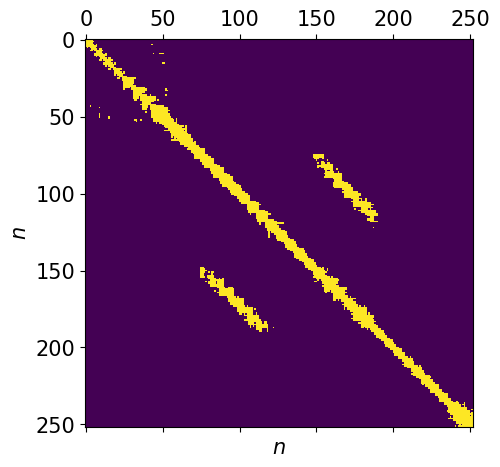

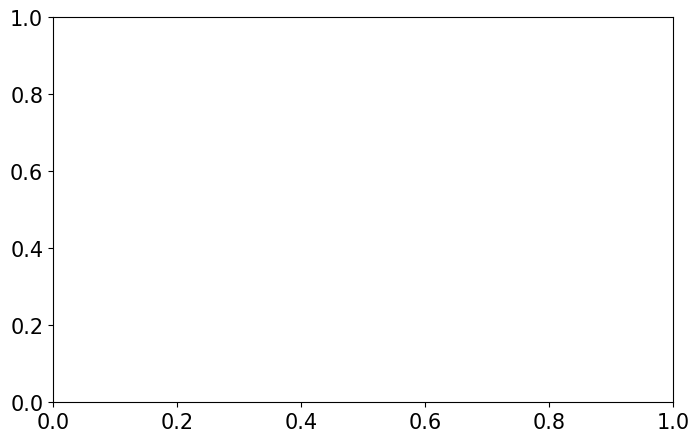

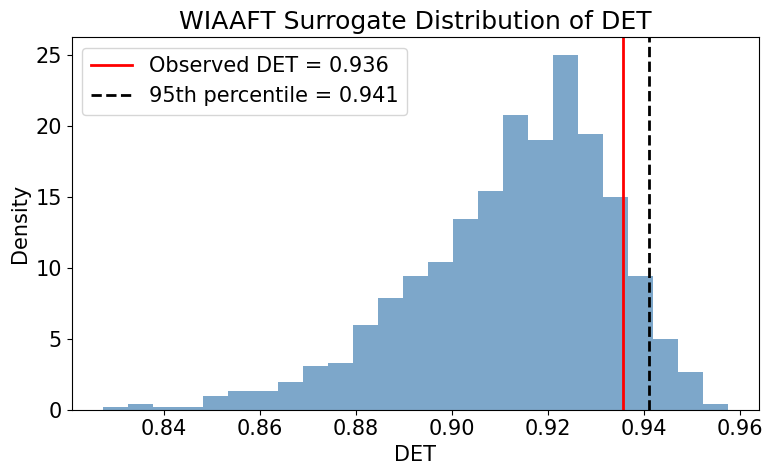

 90%|█████████████████████████████████████▊    | 90/100 [36:32<03:54, 23.47s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.935704514360685 
 Recurrence rate: 0.05001259763164525 
Threshold:1.1373999999998912 
 Laminarity:0.9681989924402765 
Shannon Entropy:1.8977283054684286 
Rank-order p-value (det):0.099 
Reject null (det) hypothesis:False

 
 

5
8
WIAAFT surrogate datasets generated


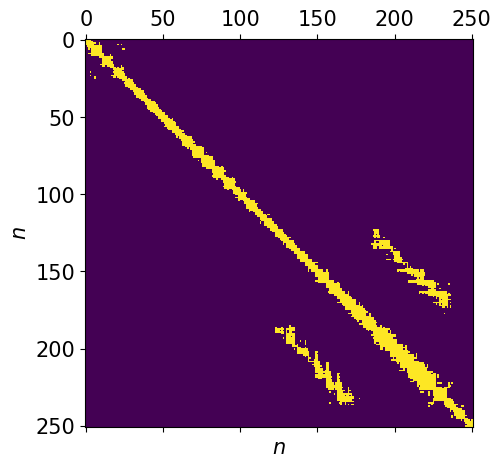

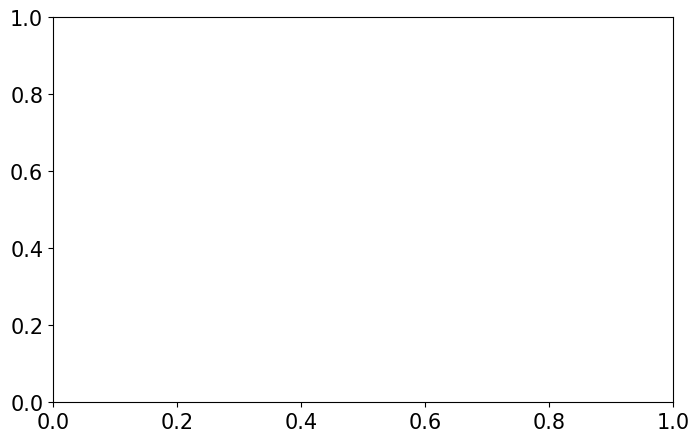

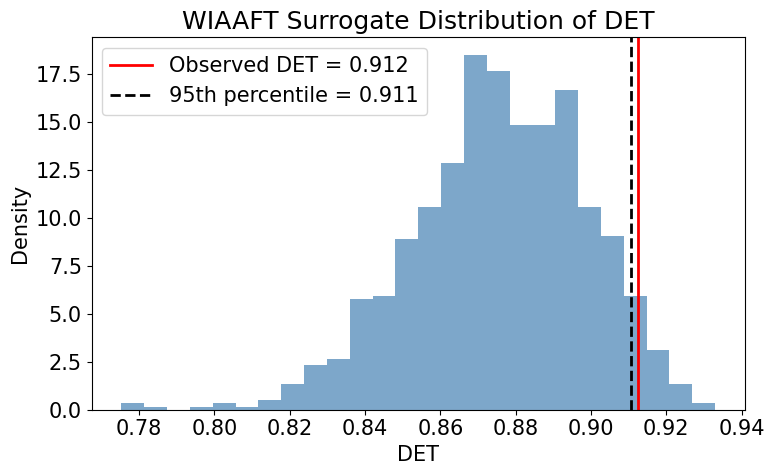

 91%|██████████████████████████████████████▏   | 91/100 [36:56<03:33, 23.68s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.912413793100302 
 Recurrence rate: 0.05001507912572816 
Threshold:1.1082999999998944 
 Laminarity:0.9555696604222292 
Shannon Entropy:1.897378810779591 
Rank-order p-value (det):0.044 
Reject null (det) hypothesis:True

 
 

6
9
WIAAFT surrogate datasets generated


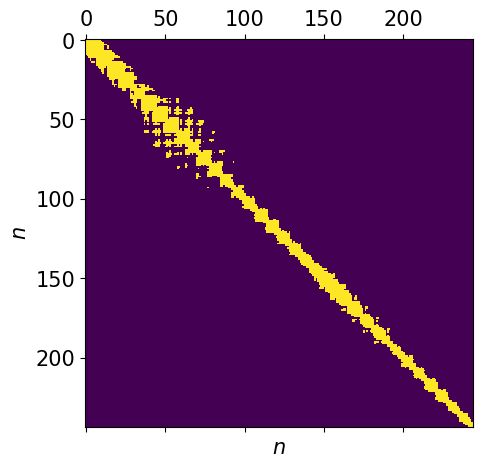

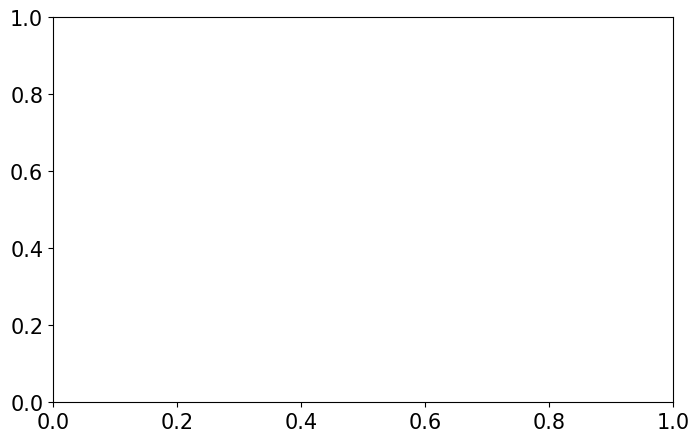

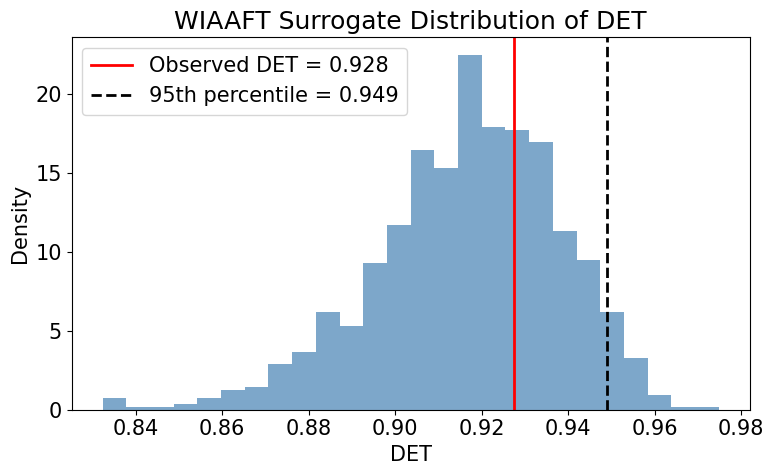

 92%|██████████████████████████████████████▋   | 92/100 [37:20<03:10, 23.85s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9275786393528619 
 Recurrence rate: 0.0500201558720774 
Threshold:1.1897999999998854 
 Laminarity:0.9644056413668086 
Shannon Entropy:1.8734591042253022 
Rank-order p-value (det):0.324 
Reject null (det) hypothesis:False

 
 

6
9
WIAAFT surrogate datasets generated


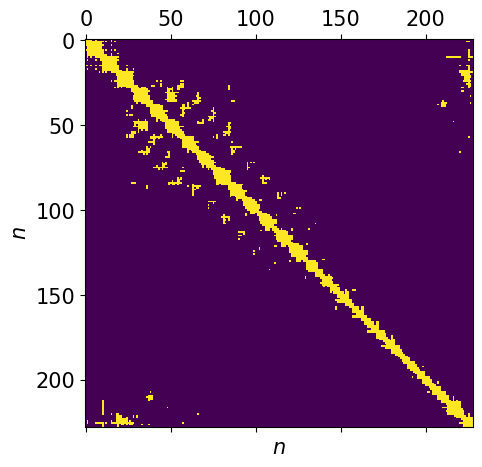

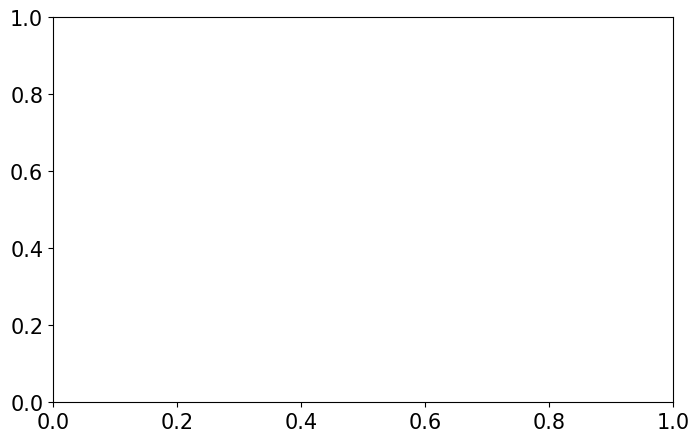

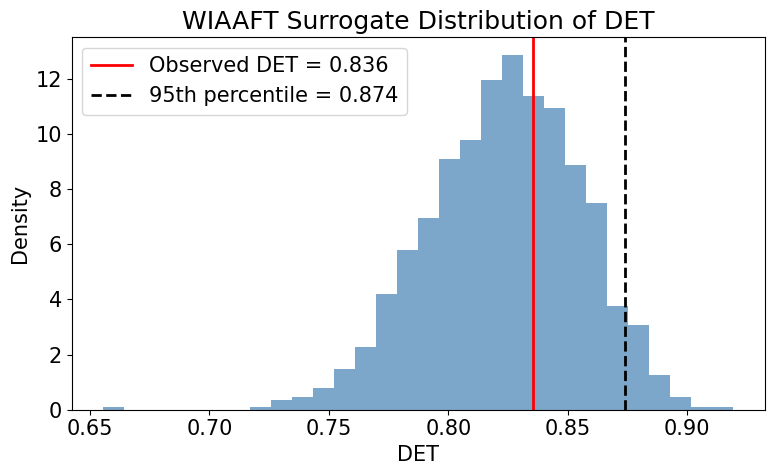

 93%|███████████████████████████████████████   | 93/100 [37:49<02:57, 25.31s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8355817875175566 
 Recurrence rate: 0.05001538935056941 
Threshold:1.918999999999805 
 Laminarity:0.9080769230734305 
Shannon Entropy:1.682958722090003 
Rank-order p-value (det):0.368 
Reject null (det) hypothesis:False

 
 

6
10
WIAAFT surrogate datasets generated


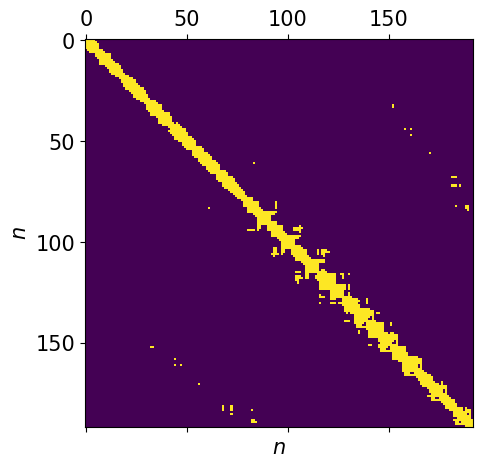

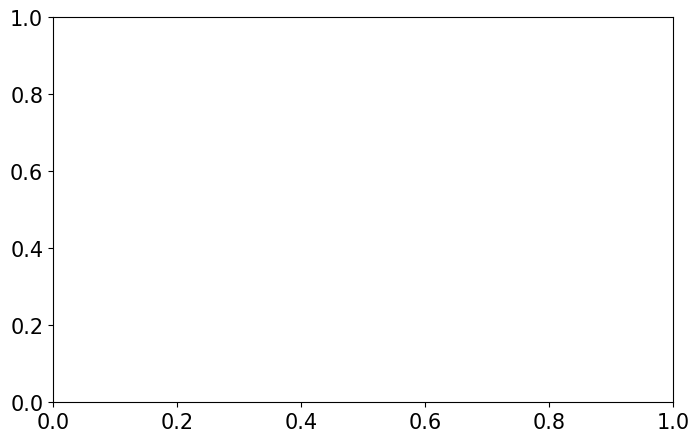

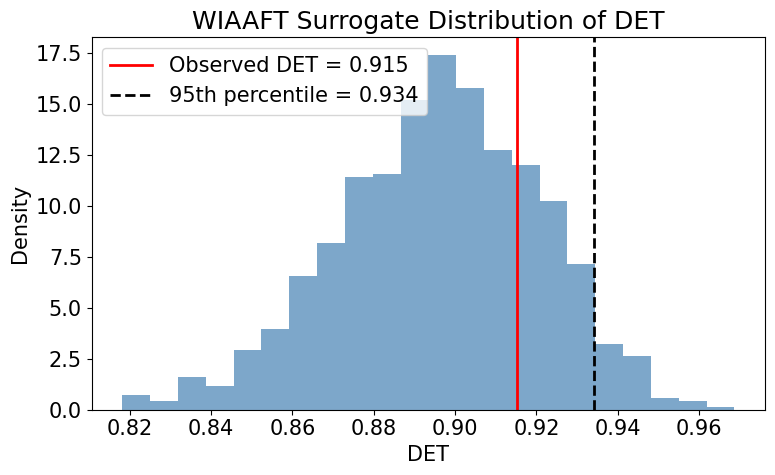

 94%|███████████████████████████████████████▍  | 94/100 [38:14<02:31, 25.18s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9152542372825954 
 Recurrence rate: 0.05002170138888889 
Threshold:1.711599999999828 
 Laminarity:0.963123644246404 
Shannon Entropy:1.7541758716117384 
Rank-order p-value (det):0.237 
Reject null (det) hypothesis:False

 
 

6
7
WIAAFT surrogate datasets generated


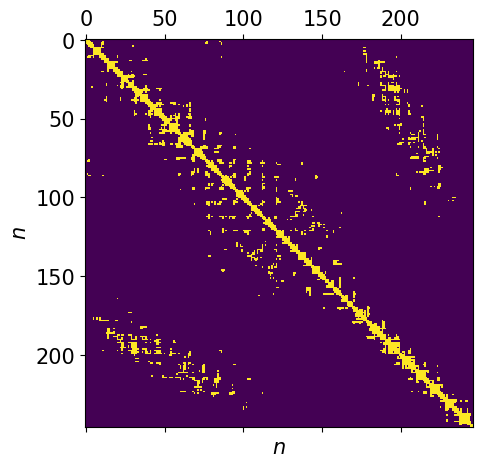

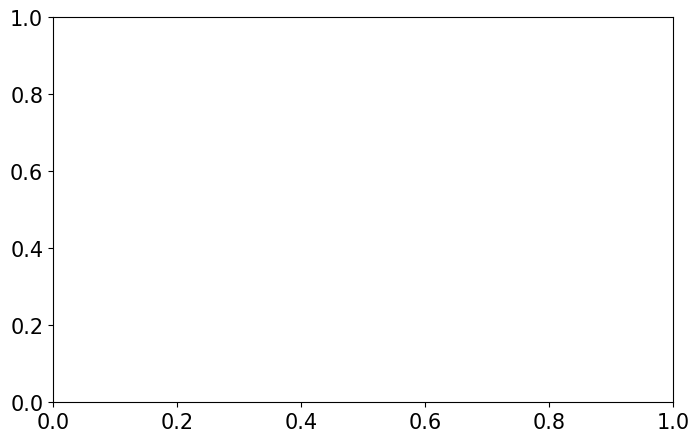

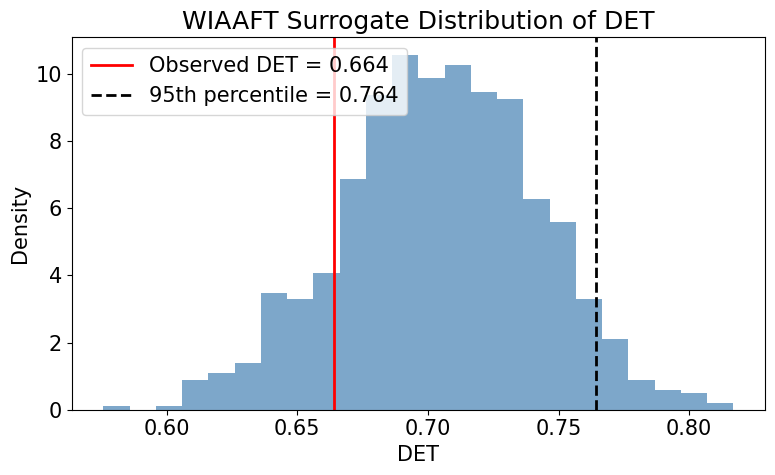

 95%|███████████████████████████████████████▉  | 95/100 [38:41<02:08, 25.74s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.6640287769760287 
 Recurrence rate: 0.05000330491109789 
Threshold:1.5307999999998478 
 Laminarity:0.8218770654301987 
Shannon Entropy:1.1359052962510217 
Rank-order p-value (det):0.862 
Reject null (det) hypothesis:False

 
 

6
8
WIAAFT surrogate datasets generated


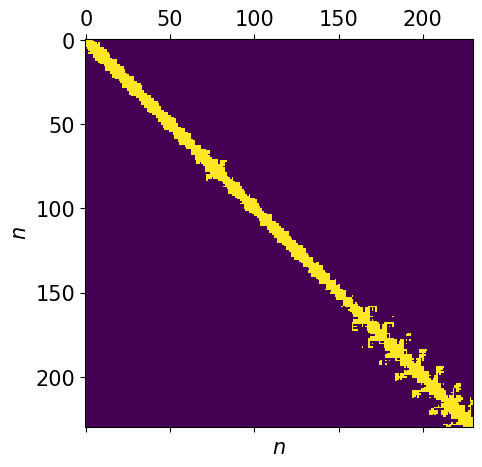

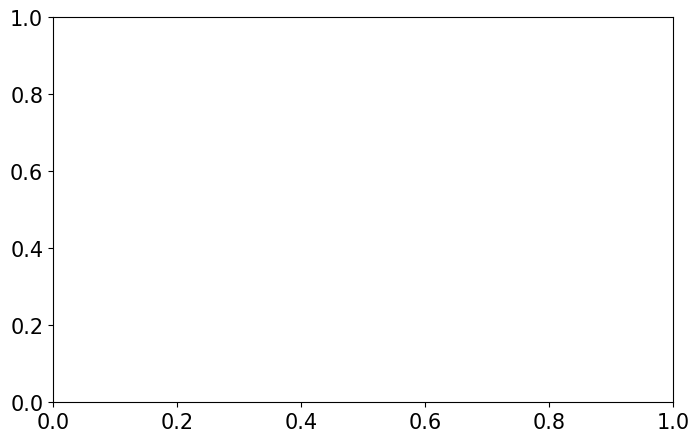

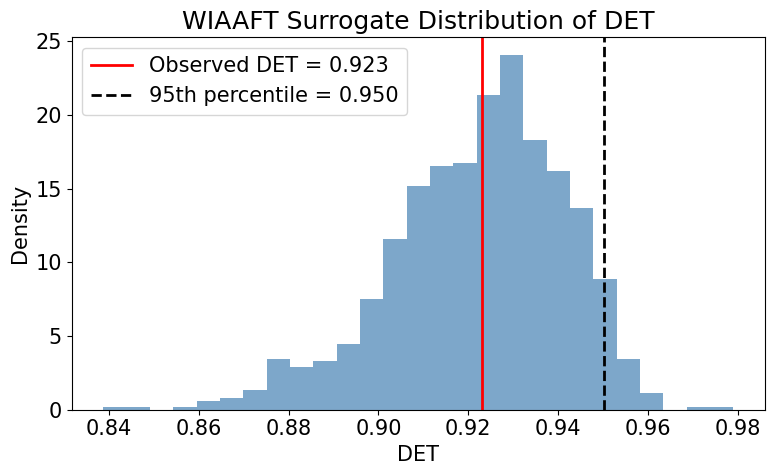

 96%|████████████████████████████████████████▎ | 96/100 [39:06<01:42, 25.54s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9230132450292922 
 Recurrence rate: 0.05001890359168242 
Threshold:1.4124999999998609 
 Laminarity:0.9746787603893625 
Shannon Entropy:1.8823631304528443 
Rank-order p-value (det):0.543 
Reject null (det) hypothesis:False

 
 

6
10
WIAAFT surrogate datasets generated


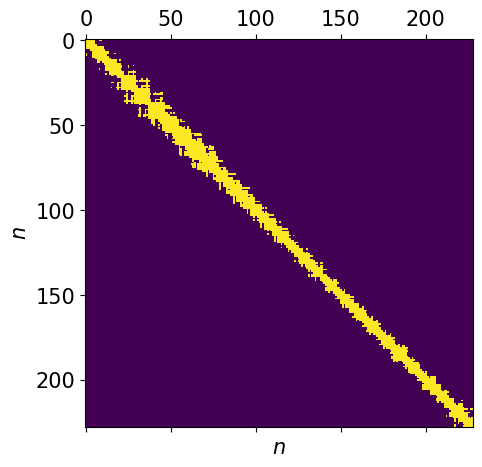

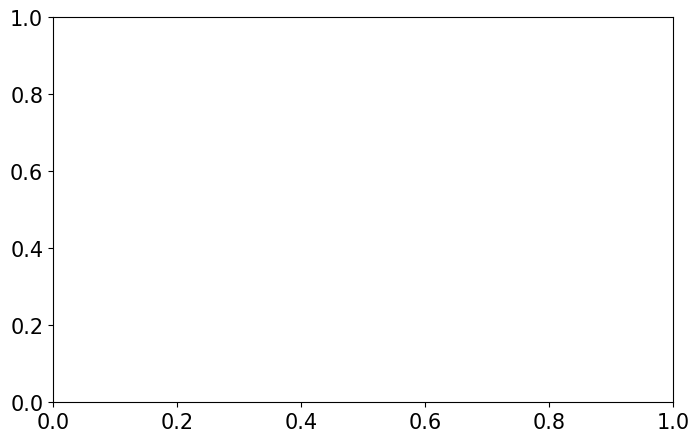

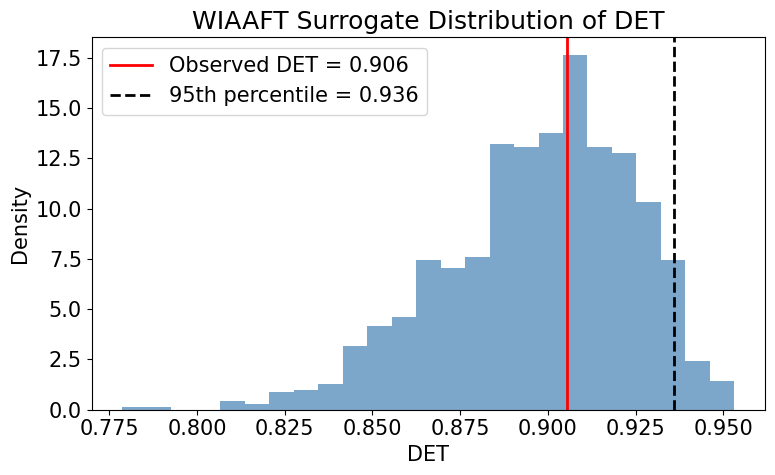

 97%|████████████████████████████████████████▋ | 97/100 [39:32<01:16, 25.66s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9055649241108534 
 Recurrence rate: 0.05001538935056941 
Threshold:1.0615999999998995 
 Laminarity:0.9503846153809601 
Shannon Entropy:1.7412705997122138 
Rank-order p-value (det):0.435 
Reject null (det) hypothesis:False

 
 

6
10
WIAAFT surrogate datasets generated


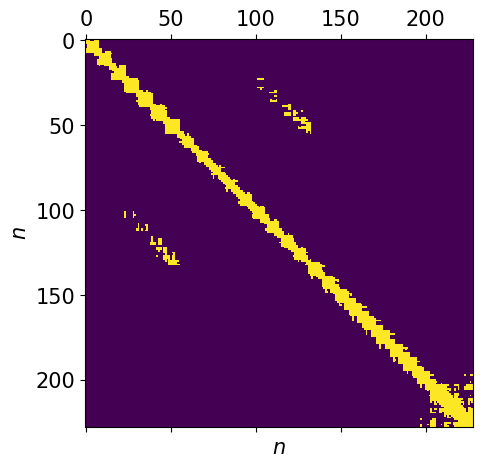

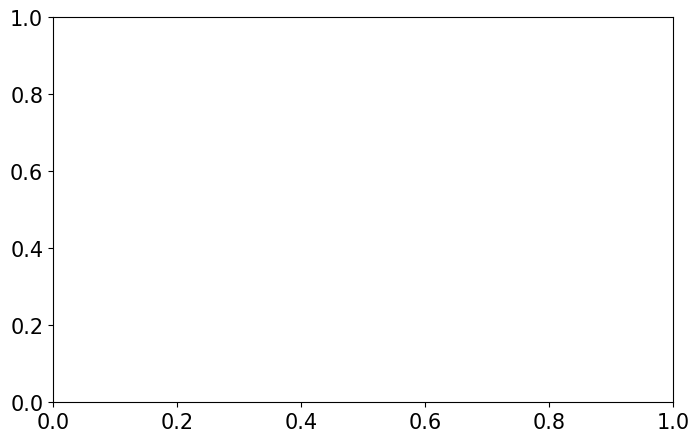

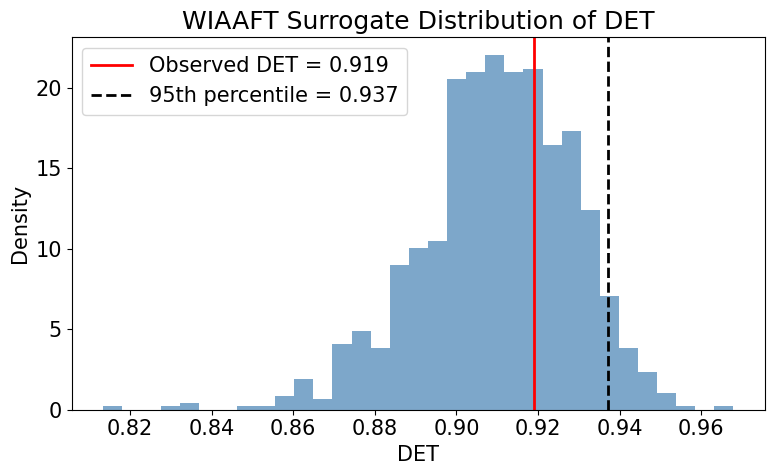

 98%|█████████████████████████████████████████▏| 98/100 [40:00<00:52, 26.34s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9190556492372721 
 Recurrence rate: 0.05001538935056941 
Threshold:1.8442999999998133 
 Laminarity:0.9634615384578329 
Shannon Entropy:1.7004648953102643 
Rank-order p-value (det):0.329 
Reject null (det) hypothesis:False

 
 

6
10
WIAAFT surrogate datasets generated


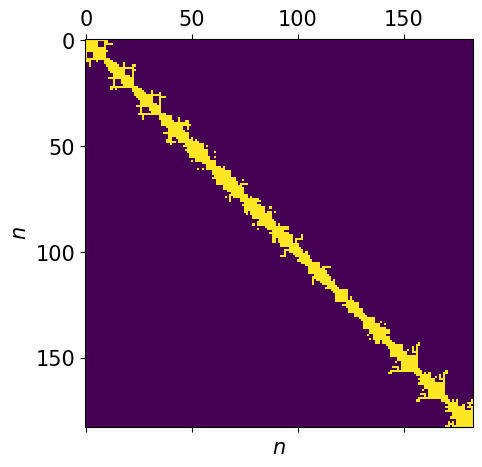

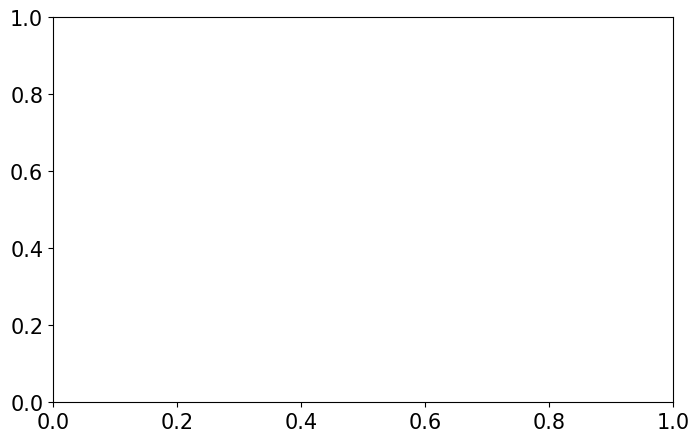

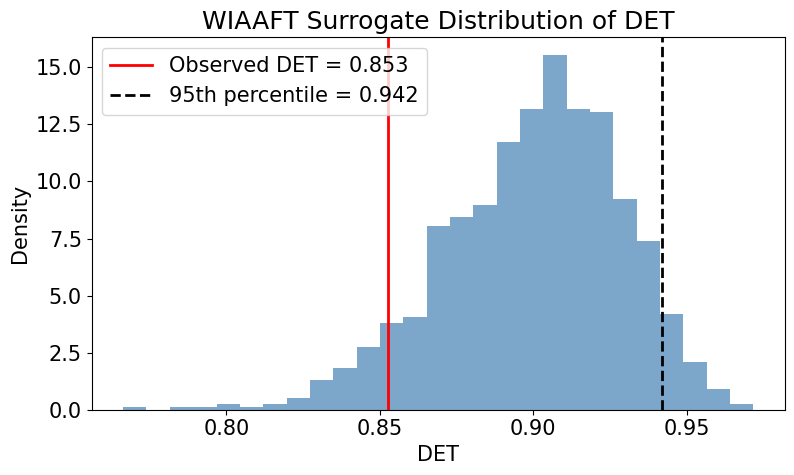

 99%|█████████████████████████████████████████▌| 99/100 [40:20<00:24, 24.60s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8527443105699282 
 Recurrence rate: 0.05007614440562573 
Threshold:1.165499999999888 
 Laminarity:0.9415623136497224 
Shannon Entropy:1.8460710707368406 
Rank-order p-value (det):0.93 
Reject null (det) hypothesis:False

 
 

6
10
WIAAFT surrogate datasets generated


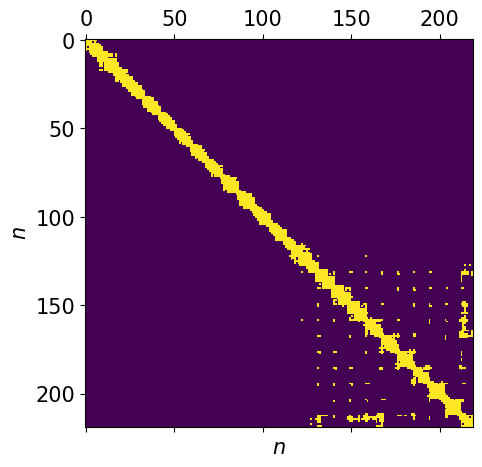

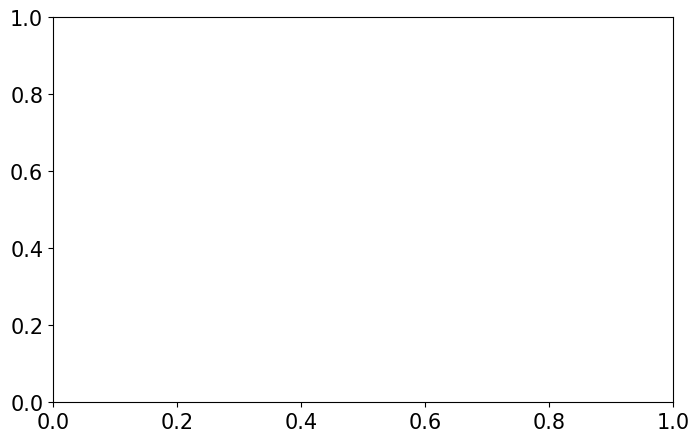

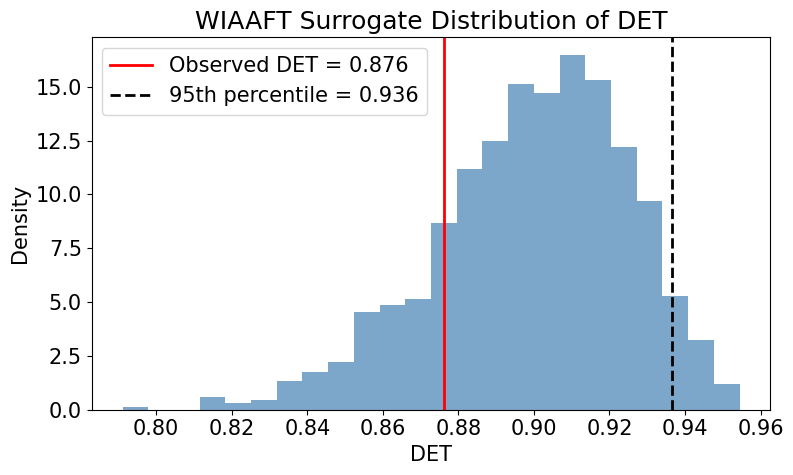

100%|█████████████████████████████████████████| 100/100 [40:42<00:00, 24.43s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8761467889868068 
 Recurrence rate: 0.05001980776047205 
Threshold:1.1103999999998941 
 Laminarity:0.9441433930765146 
Shannon Entropy:1.78961606043295 
Rank-order p-value (det):0.827 
Reject null (det) hypothesis:False

 
 

6
rejection rate:0.06


In [8]:
rejection = 0
for e in tqdm(range(0,100)):
    ar1(e, 0.99)
    os.system("./mutual ar1 -D20 -o files/mutual_ar1 -V0")
    m_site1 = np.loadtxt("files/mutual_ar1", delimiter =' ', usecols =(1) , skiprows=0)
    mn = np.where((m_site1[1:-1] < m_site1[:-2]) & (m_site1[1:-1] < m_site1[2:]))[0] + 1
    if mn.any() > 0:
        t_min=mn[0]
    else:
        t_min=min(m_site1)
    os.system("./false_nearest ar1 -M1,10 -d{} -o files/ar1.fnn -V0".format(t_min))
    res_1 = extract_embedding_dimension("ar1")
    dim = res_1['m']
    print(dim)
    k="ar1"
    det_j=[]
    embed=[]
    det_surro_ff=[]
    kkk=[]
    lam_j=[]
    ent_j=[]
    lam_surro = []
    ent_surro=[]
    s = lcurve(k)
    with open("test_output/stocks_WIAAFT", "w") as f:
        subprocess.run(["julia", "WIAAFT_surrogates.jl", "ar1"], text=True, check=True)
        
        tt1=0.001
        dimension=dim
        RR_orig = 0
        while RR_orig < 0.05:
            tt1 = tt1 + 0.0001
            det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
        det_j.append(det)
        embed.append(dim)
        lam_j.append(lam_orig)
        ent_j.append(entr_orig)
        pylab.matshow(matrix)
        pylab.xlabel("$n$")
        pylab.ylabel("$n$")
        pylab.savefig('test_output/WIAAFT/WIAAFT_RP_{}.pdf'.format(dim), format="pdf")
        det_ff, lam_ff, entr_ff = sur_test_WIAAFT(dim, tt1)
        fig2, axs = plt.subplots(1)
        #axs.plot(det_ff, label = 'DET of the each surrogate data')
        #axs.set_title('DET of the each surrogate data for m={}'.format(dim))
        #axs.axhline(y = det, color = 'r', linestyle = '-', label = 'DET of the original data' )
        #axs.legend(loc='lower right')
        #axs.set_xlabel("Surrogate data set no. ")
        #axs.set_xlim(0.1, 1000)
        #axs.set_ylabel("DET")
        q95 = np.percentile(det_ff, 95)
        plt.figure(figsize=(8,5))
        plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
        plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
        plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
        plt.xlabel("DET")
        plt.ylabel("Density")
        plt.title("WIAAFT Surrogate Distribution of DET")
        plt.legend()
        plt.tight_layout()
        plt.show()
        fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
        plt.show()
        plt.close()
        r = np.sum(det_ff >= det)
        p_rank = (r + 1) / (999 + 1)
        alpha = 0.05
        reject_null1 = p_rank < alpha
        print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
        det_surro_ff.append(det_ff)
        kkk.append(np.full(999, dimension))
        lam_surro.append(lam_ff)
        ent_surro.append(entr_ff)
        if reject_null1 == True:
            rejection = rejection + 1
        print(rejection)

print("rejection rate:{}".format(rejection/(e+1)))

  0%|                                                   | 0/100 [00:00<?, ?it/s]

10
Mean Nearest Neighbor Distance: 0.4429768403615105
Pseudo-periodic surrogates generated successfullly


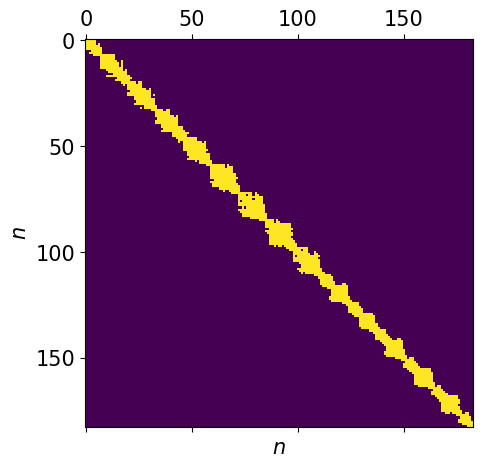

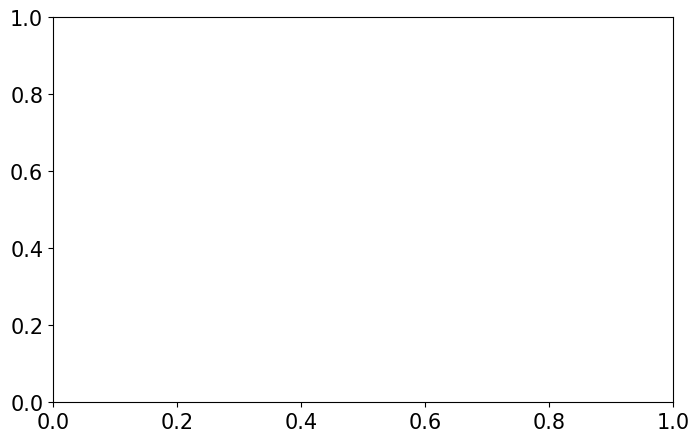

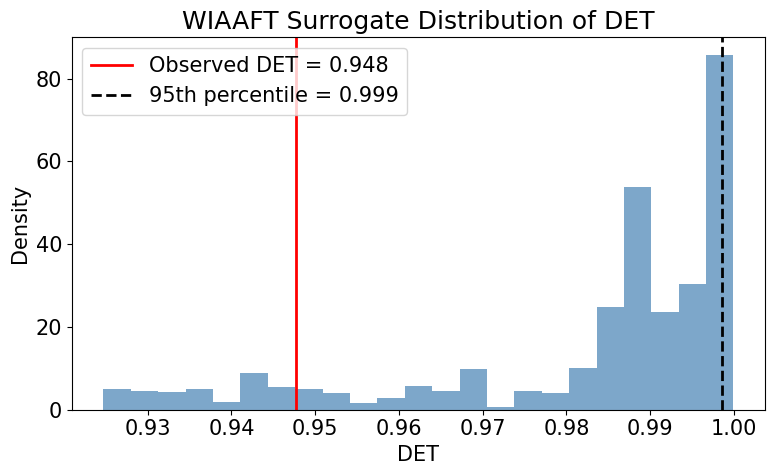

  1%|▍                                          | 1/100 [00:11<18:23, 11.15s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9477211796183129 
 Recurrence rate: 0.05001642330317418 
Threshold:1.0787999999998976 
 Laminarity:0.9862686567105298 
Shannon Entropy:2.3364977211758227 
Rank-order p-value (det):0.23 
Reject null (det) hypothesis:False

 
 

0
10
Mean Nearest Neighbor Distance: 0.37822589347988345
Pseudo-periodic surrogates generated successfullly


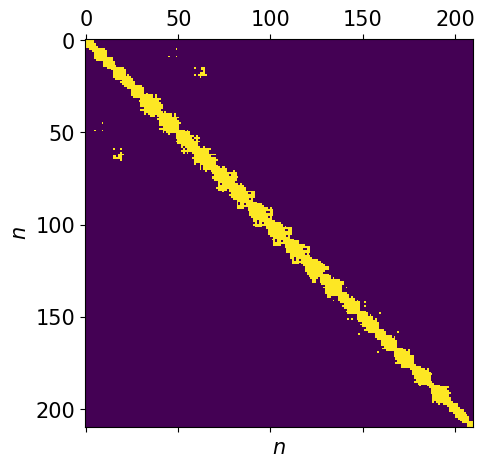

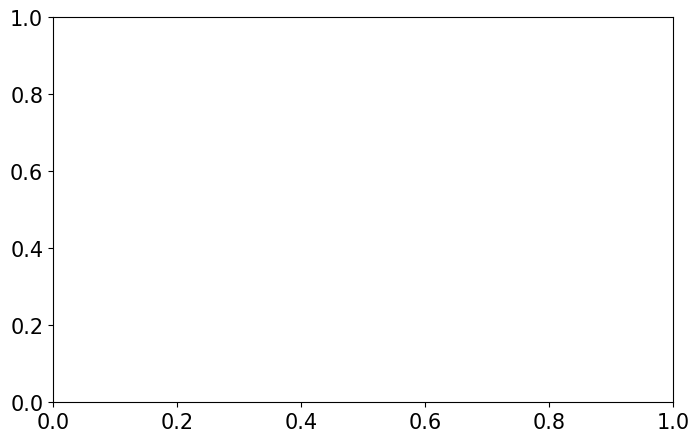

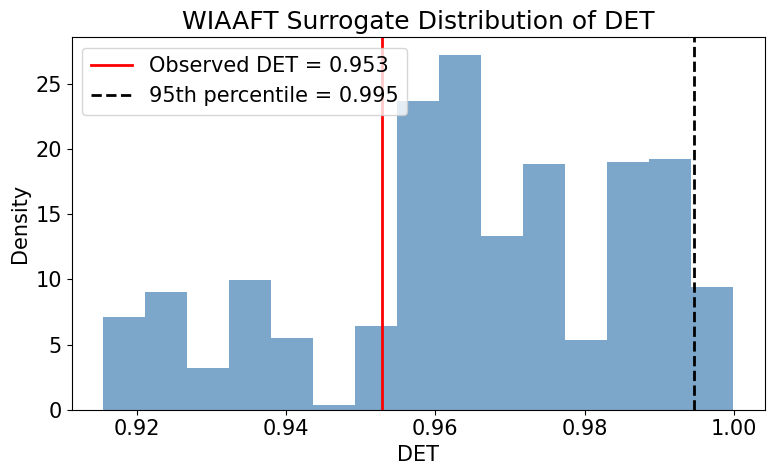

  2%|▊                                          | 2/100 [00:22<18:45, 11.48s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9529058116184724 
 Recurrence rate: 0.05002267573696145 
Threshold:0.9239999999999146 
 Laminarity:0.9669084315459343 
Shannon Entropy:1.930832191418118 
Rank-order p-value (det):0.416 
Reject null (det) hypothesis:False

 
 

0
10
Mean Nearest Neighbor Distance: 0.5134268033125207
Pseudo-periodic surrogates generated successfullly


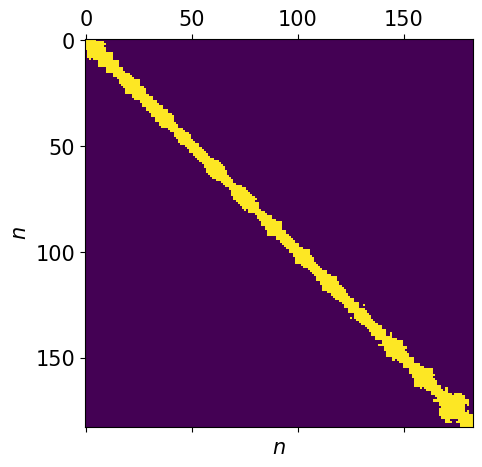

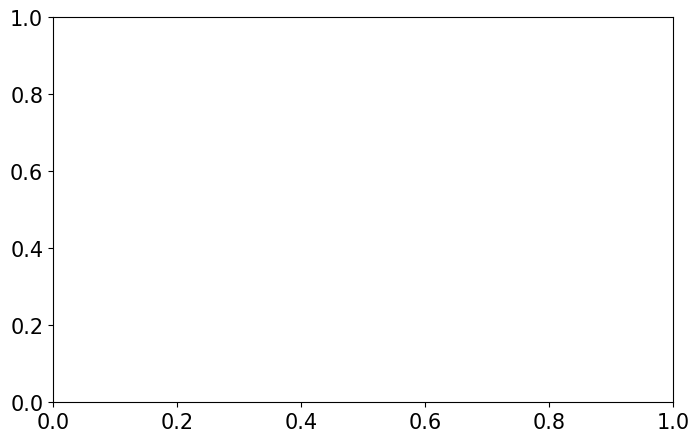

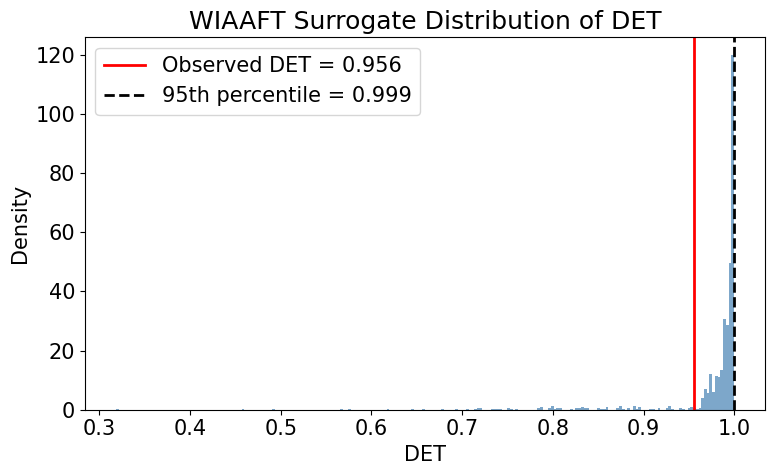

  3%|█▎                                         | 3/100 [00:34<18:57, 11.73s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9557640750606182 
 Recurrence rate: 0.05001642330317418 
Threshold:1.3548999999998672 
 Laminarity:0.9928358208895951 
Shannon Entropy:2.370285047501353 
Rank-order p-value (det):0.194 
Reject null (det) hypothesis:False

 
 

0
9
Mean Nearest Neighbor Distance: 0.6924921539015949
Pseudo-periodic surrogates generated successfullly


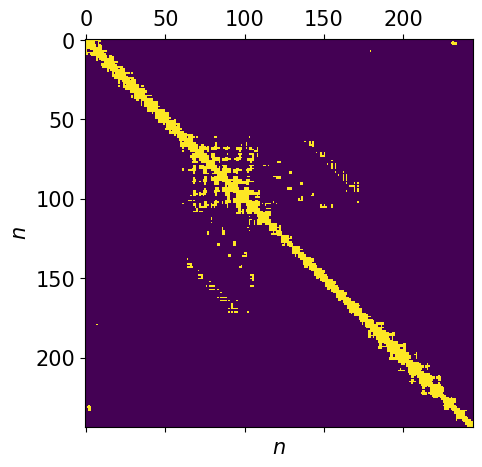

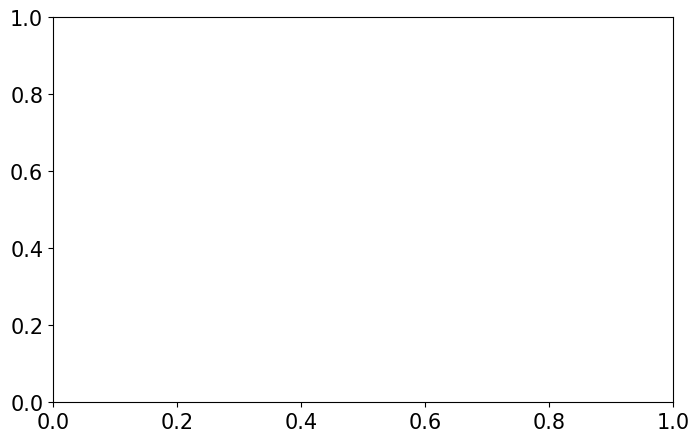

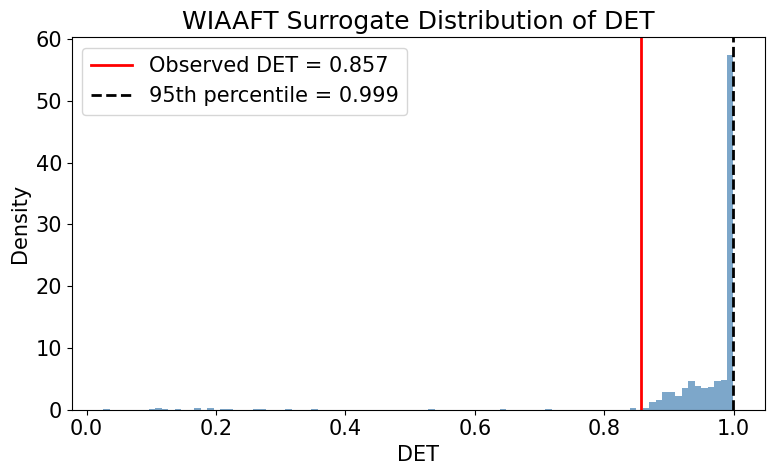

  4%|█▋                                         | 4/100 [00:53<23:02, 14.40s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8566203365001587 
 Recurrence rate: 0.0500201558720774 
Threshold:1.6337999999998365 
 Laminarity:0.9288112827369751 
Shannon Entropy:1.5072792417425143 
Rank-order p-value (det):0.044 
Reject null (det) hypothesis:True

 
 

1
10
Mean Nearest Neighbor Distance: 0.655077599915262
Pseudo-periodic surrogates generated successfullly


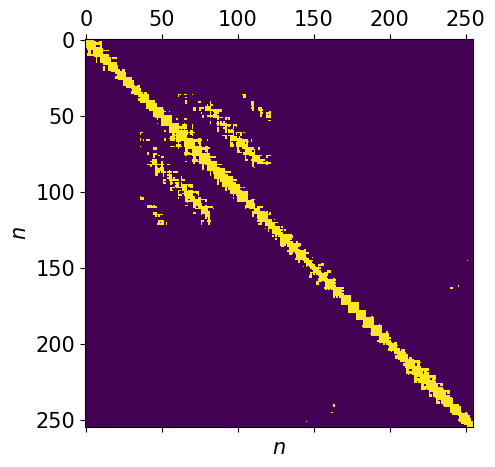

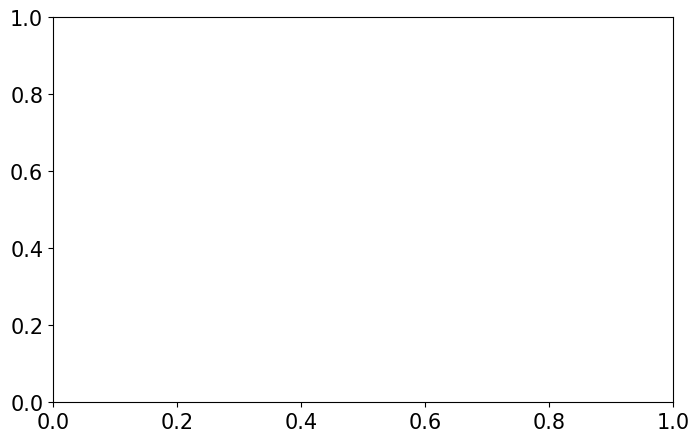

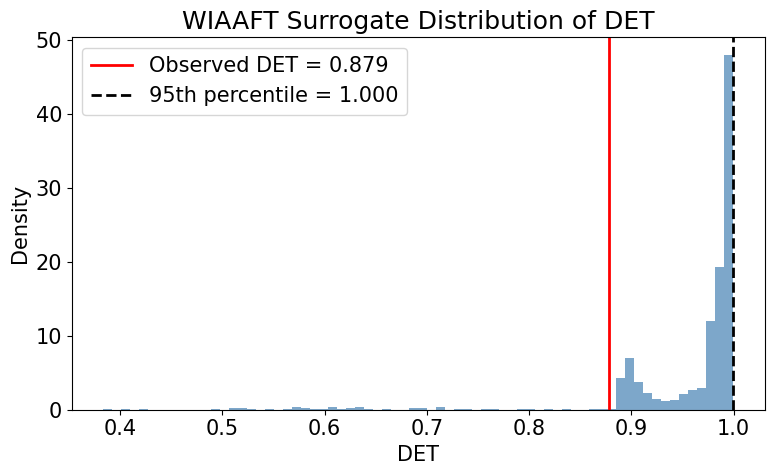

  5%|██▏                                        | 5/100 [01:11<25:12, 15.92s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8785857238129468 
 Recurrence rate: 0.050026912725874666 
Threshold:1.548399999999846 
 Laminarity:0.9332923455243367 
Shannon Entropy:1.3871518665543021 
Rank-order p-value (det):0.096 
Reject null (det) hypothesis:False

 
 

1
10
Mean Nearest Neighbor Distance: 0.47500691902719394
Pseudo-periodic surrogates generated successfullly


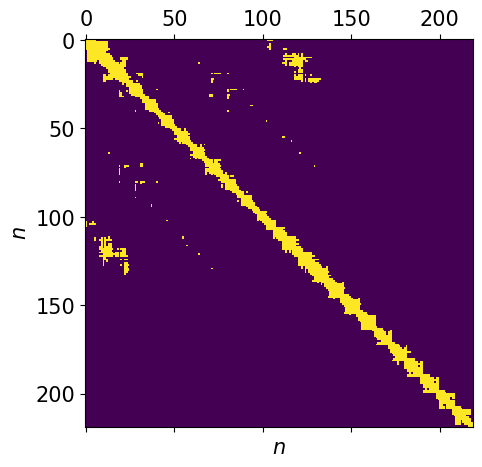

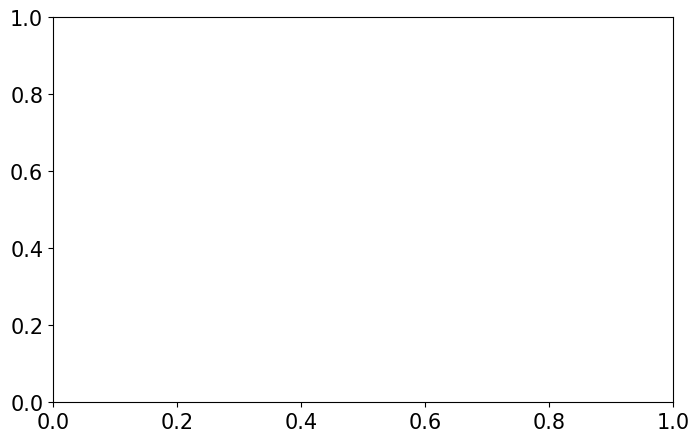

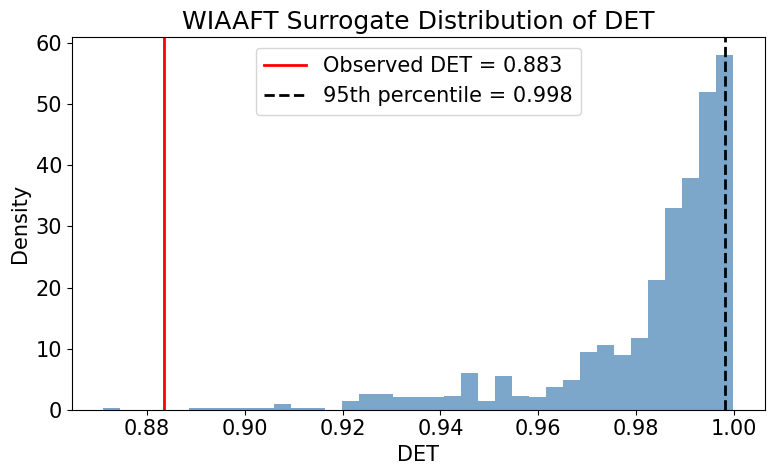

  6%|██▌                                        | 6/100 [01:25<23:32, 15.03s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8834862385280574 
 Recurrence rate: 0.05001980776047205 
Threshold:1.2239999999998816 
 Laminarity:0.9458107544770913 
Shannon Entropy:1.8555298296851799 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

2
10
Mean Nearest Neighbor Distance: 0.46409419923177114
Pseudo-periodic surrogates generated successfullly


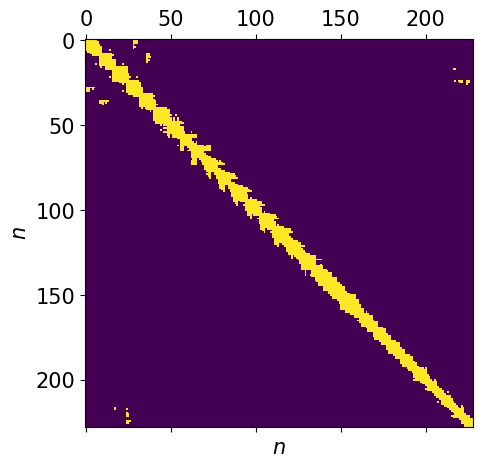

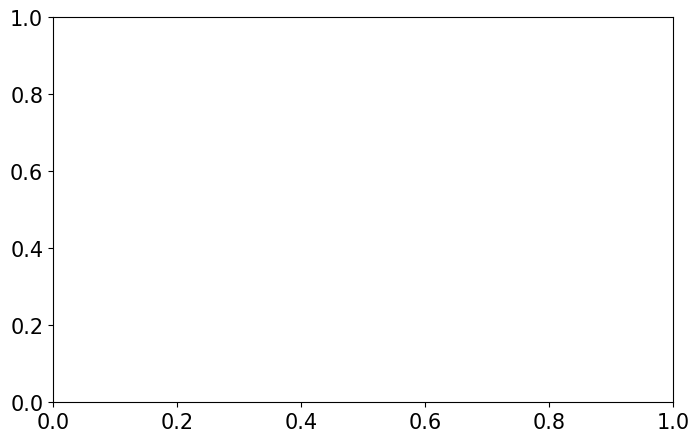

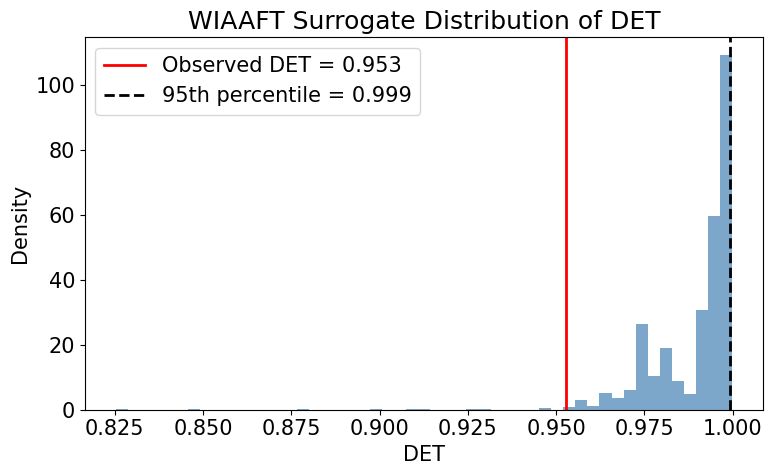

  7%|███                                        | 7/100 [01:39<23:00, 14.84s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9527824620533188 
 Recurrence rate: 0.05001538935056941 
Threshold:1.2808999999998754 
 Laminarity:0.9780769230731613 
Shannon Entropy:1.9527063269714997 
Rank-order p-value (det):0.022 
Reject null (det) hypothesis:True

 
 

3
10
Mean Nearest Neighbor Distance: 0.6002927652153508
Pseudo-periodic surrogates generated successfullly


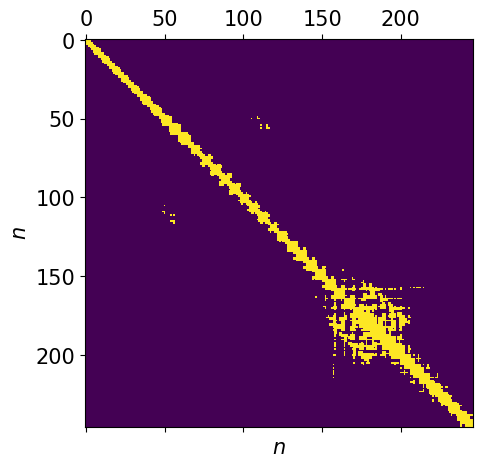

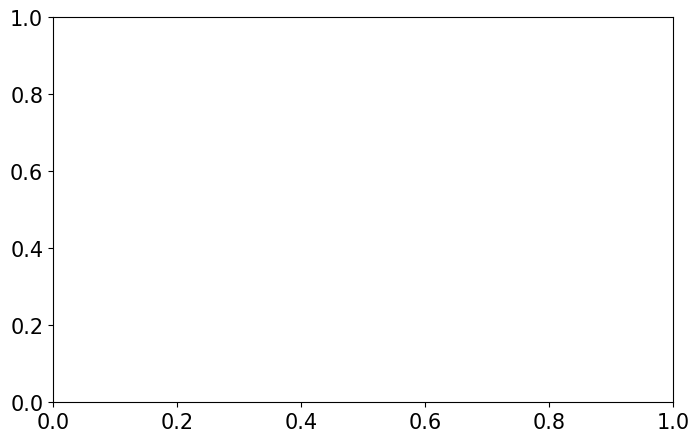

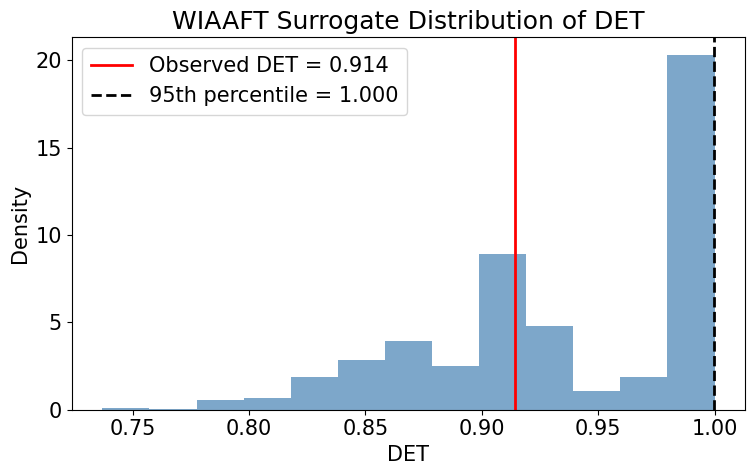

  8%|███▍                                       | 8/100 [01:56<23:37, 15.41s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.914388489205344 
 Recurrence rate: 0.05000330491109789 
Threshold:1.4585999999998558 
 Laminarity:0.9543952412394104 
Shannon Entropy:1.612234869031291 
Rank-order p-value (det):0.812 
Reject null (det) hypothesis:False

 
 

3
9
Mean Nearest Neighbor Distance: 1.001667011457989
Pseudo-periodic surrogates generated successfullly


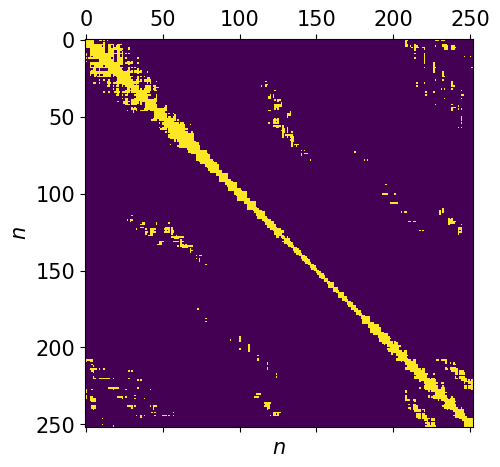

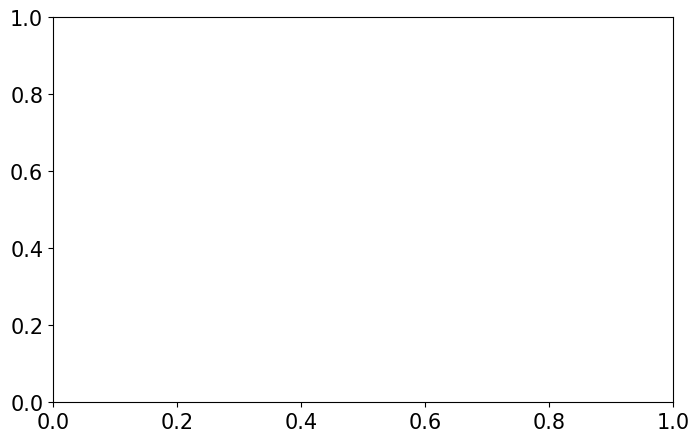

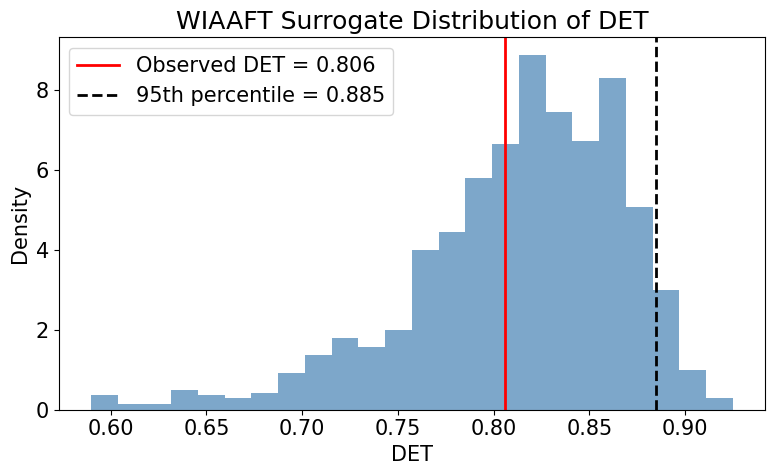

  9%|███▊                                       | 9/100 [02:18<26:44, 17.63s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8057455540328121 
 Recurrence rate: 0.05001259763164525 
Threshold:2.2294000000002803 
 Laminarity:0.8910579345060106 
Shannon Entropy:1.4261352845275779 
Rank-order p-value (det):0.756 
Reject null (det) hypothesis:False

 
 

3
7
Mean Nearest Neighbor Distance: 0.5823887752018606
Pseudo-periodic surrogates generated successfullly


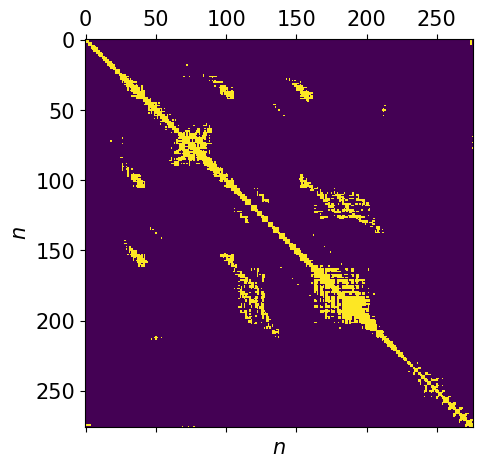

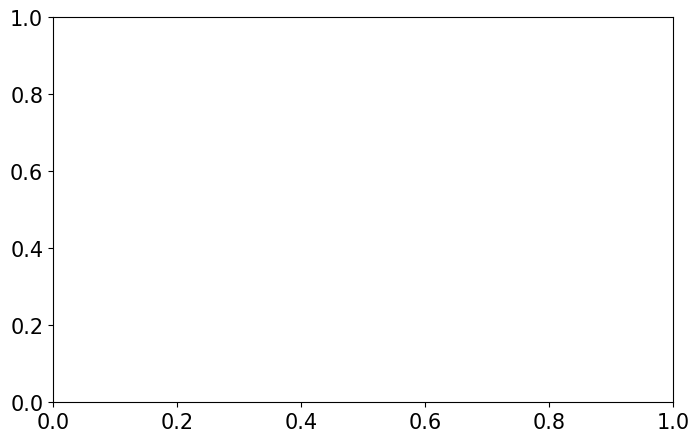

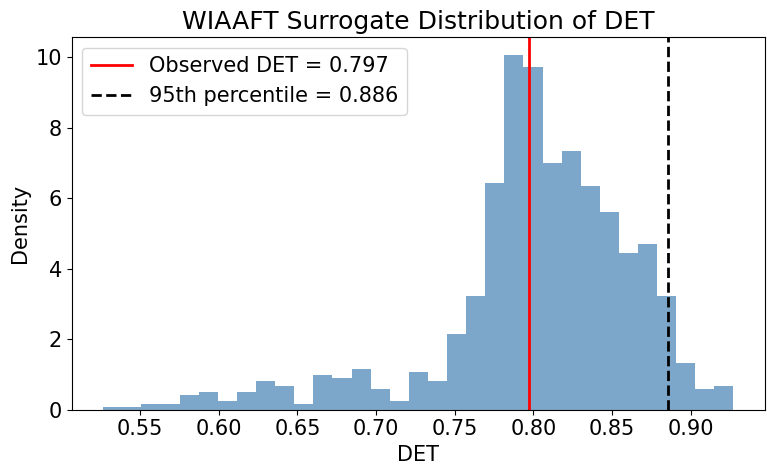

 10%|████▏                                     | 10/100 [02:34<25:24, 16.94s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.7969457013552123 
 Recurrence rate: 0.050042007981516486 
Threshold:1.157299999999889 
 Laminarity:0.8979538300081376 
Shannon Entropy:1.489907321661489 
Rank-order p-value (det):0.822 
Reject null (det) hypothesis:False

 
 

3
10
Mean Nearest Neighbor Distance: 0.4020162433141487
Pseudo-periodic surrogates generated successfullly


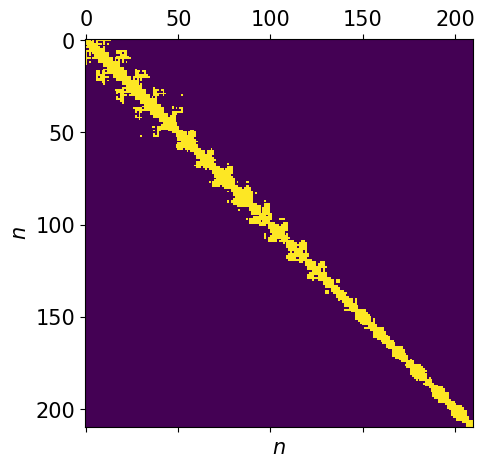

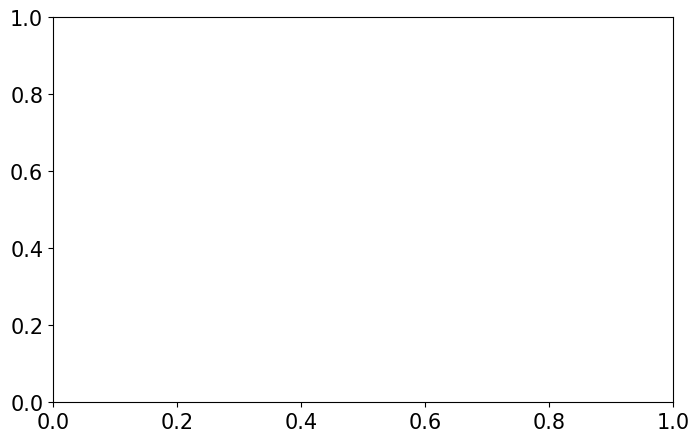

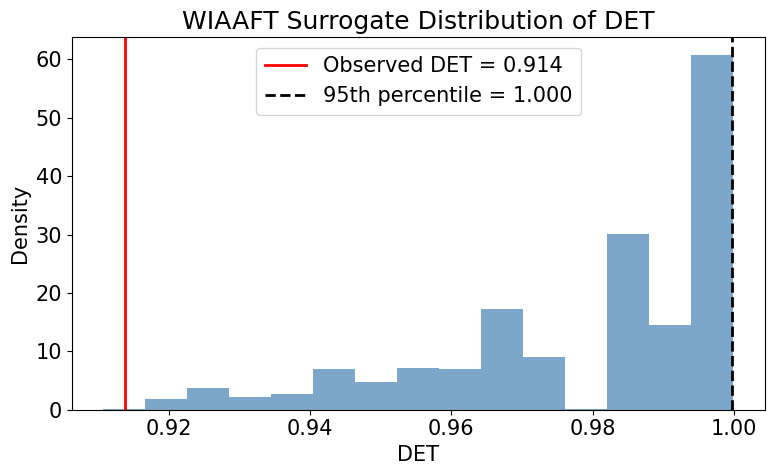

 11%|████▌                                     | 11/100 [02:45<22:25, 15.12s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.913827655306043 
 Recurrence rate: 0.05002267573696145 
Threshold:0.9944999999999068 
 Laminarity:0.9610154125069764 
Shannon Entropy:1.80356051590714 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

4
10
Mean Nearest Neighbor Distance: 0.6310983540682308
Pseudo-periodic surrogates generated successfullly


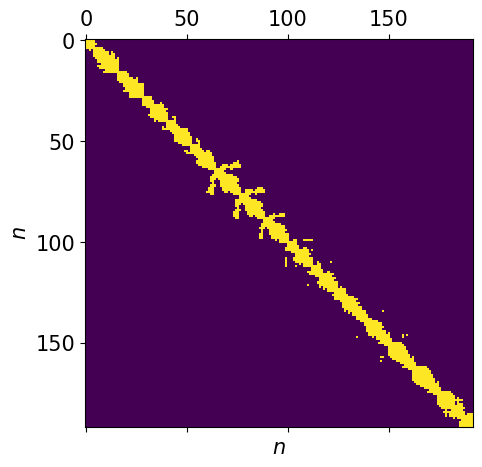

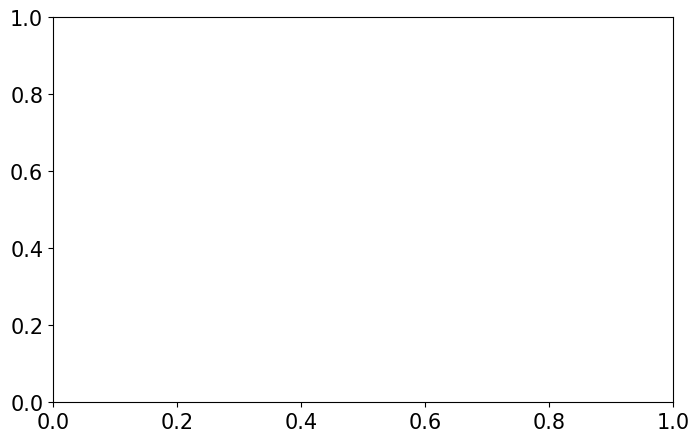

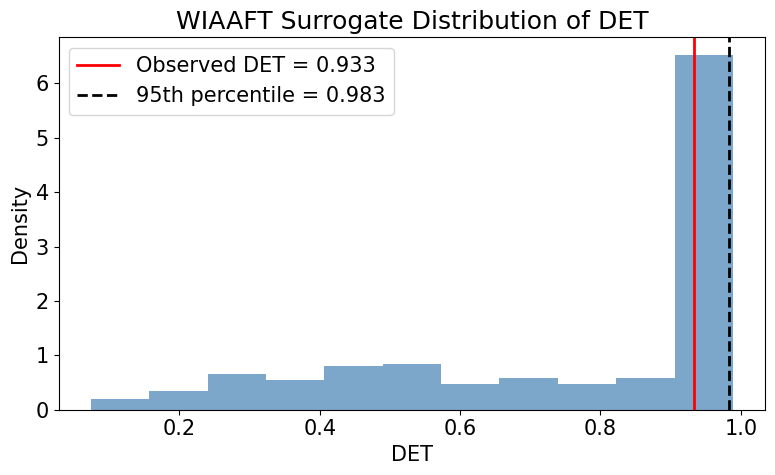

 12%|█████                                     | 12/100 [02:58<21:29, 14.65s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9334140435778849 
 Recurrence rate: 0.05002170138888889 
Threshold:1.557499999999845 
 Laminarity:0.9718004338342093 
Shannon Entropy:1.927986265420741 
Rank-order p-value (det):0.968 
Reject null (det) hypothesis:False

 
 

4
10
Mean Nearest Neighbor Distance: 0.7596257080902644
Pseudo-periodic surrogates generated successfullly


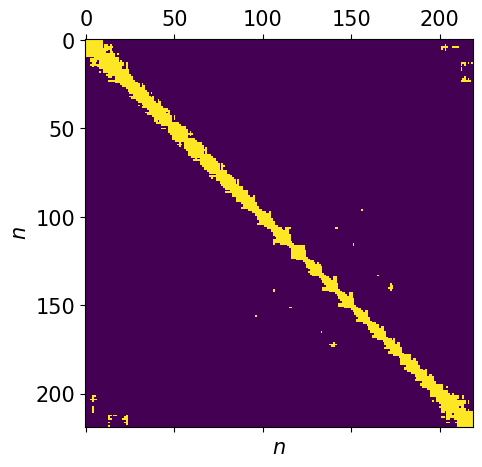

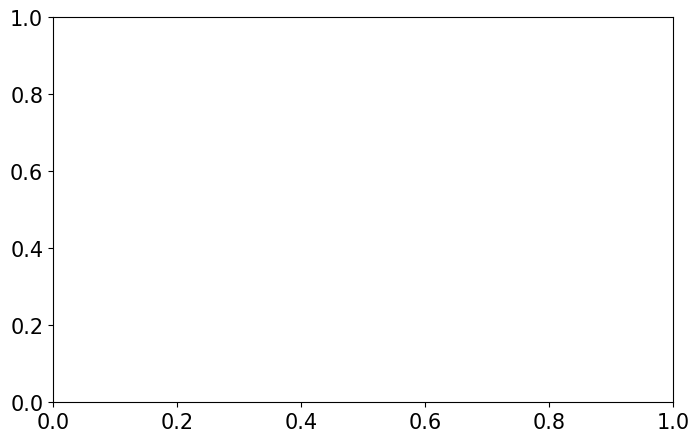

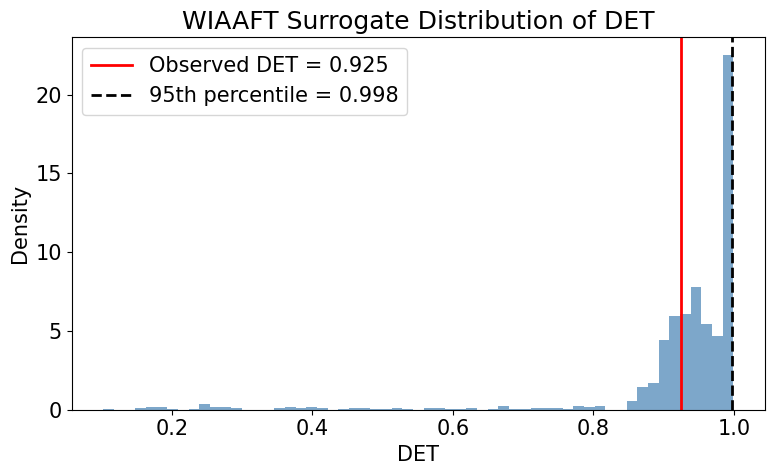

 13%|█████▍                                    | 13/100 [03:17<23:08, 15.96s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9247706421975929 
 Recurrence rate: 0.05001980776047205 
Threshold:2.0417999999998844 
 Laminarity:0.9654022509338667 
Shannon Entropy:1.9469540277030928 
Rank-order p-value (det):0.606 
Reject null (det) hypothesis:False

 
 

4
10
Mean Nearest Neighbor Distance: 0.5129426704613629
Pseudo-periodic surrogates generated successfullly


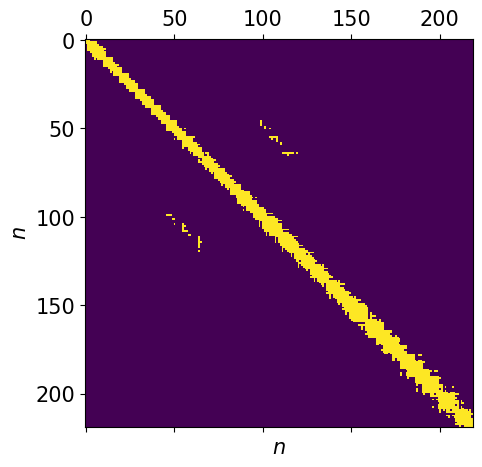

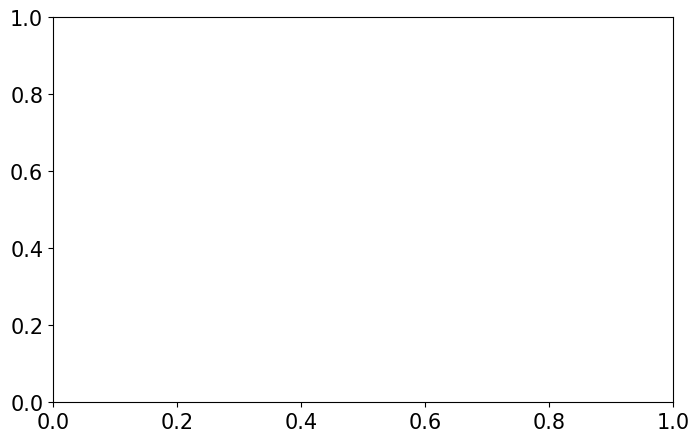

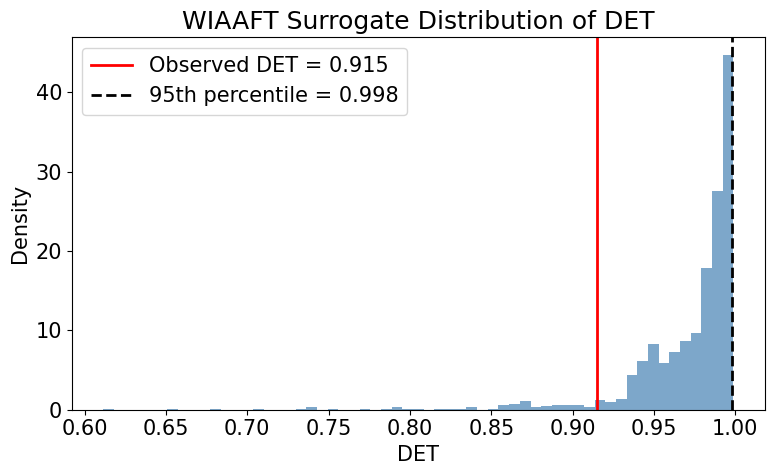

 14%|█████▉                                    | 14/100 [03:31<21:56, 15.31s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9146788990783731 
 Recurrence rate: 0.05001980776047205 
Threshold:1.2440999999998794 
 Laminarity:0.9599833263819926 
Shannon Entropy:2.0439693630008375 
Rank-order p-value (det):0.114 
Reject null (det) hypothesis:False

 
 

4
10
Mean Nearest Neighbor Distance: 0.5725738049002541
Pseudo-periodic surrogates generated successfullly


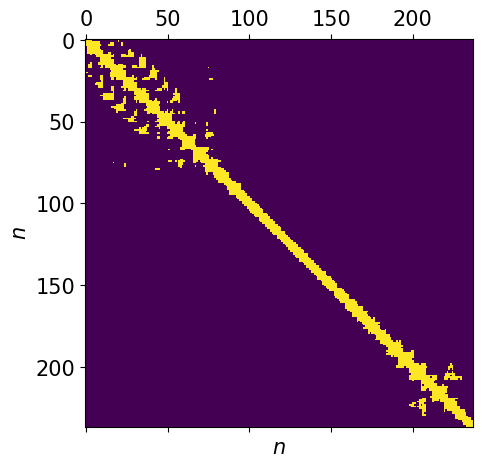

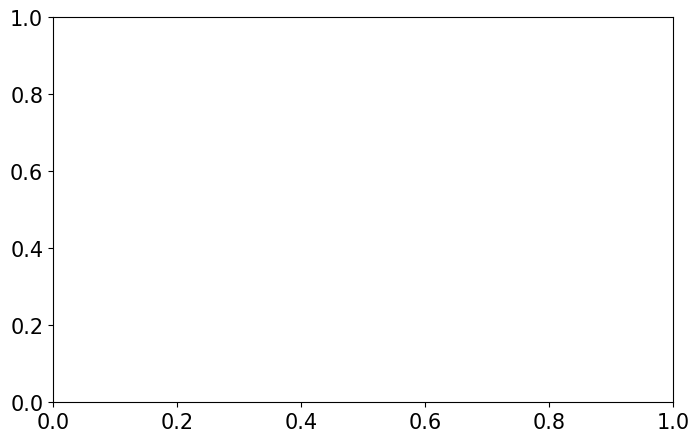

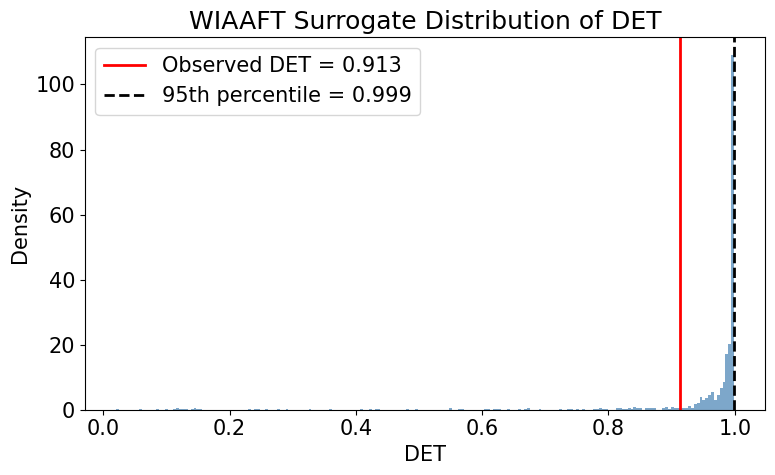

 15%|██████▎                                   | 15/100 [03:49<22:40, 16.00s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9129759129723661 
 Recurrence rate: 0.05004539870747209 
Threshold:1.6002999999998402 
 Laminarity:0.9690501600819316 
Shannon Entropy:1.58304974482323 
Rank-order p-value (det):0.206 
Reject null (det) hypothesis:False

 
 

4
10
Mean Nearest Neighbor Distance: 0.541299539446689
Pseudo-periodic surrogates generated successfullly


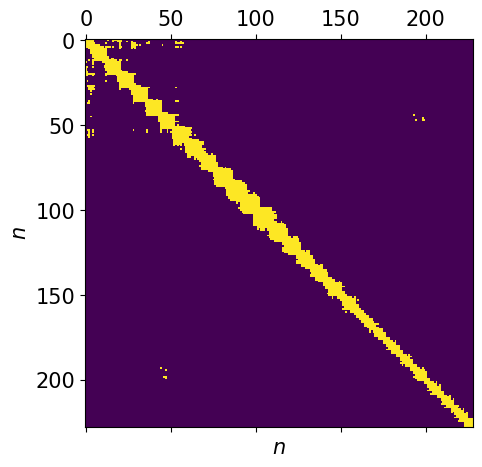

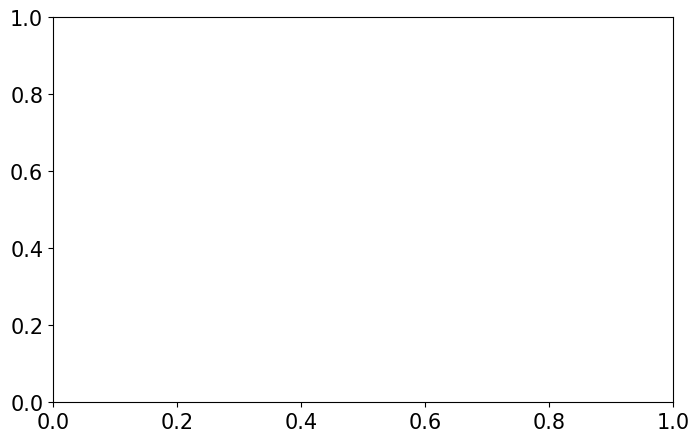

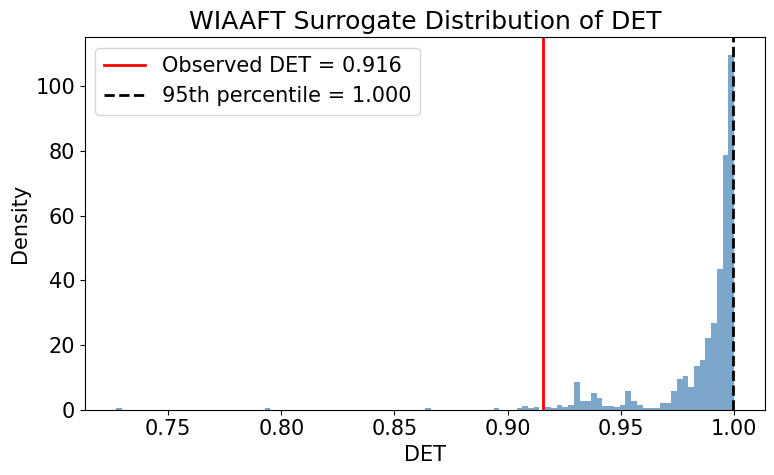

 16%|██████▋                                   | 16/100 [04:03<21:47, 15.57s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9156829679556675 
 Recurrence rate: 0.05001538935056941 
Threshold:1.3645999999998661 
 Laminarity:0.9661538461501302 
Shannon Entropy:2.034694172614102 
Rank-order p-value (det):0.024 
Reject null (det) hypothesis:True

 
 

5
10
Mean Nearest Neighbor Distance: 0.31617044588612314
Pseudo-periodic surrogates generated successfullly


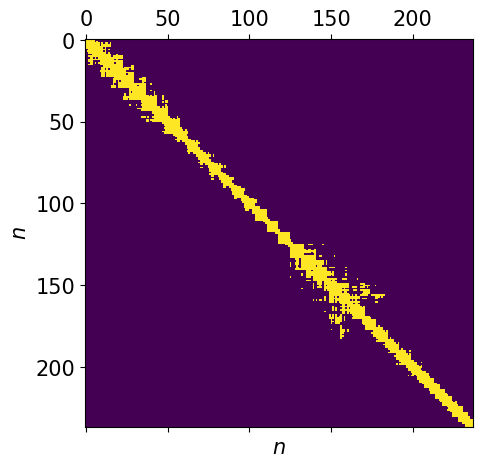

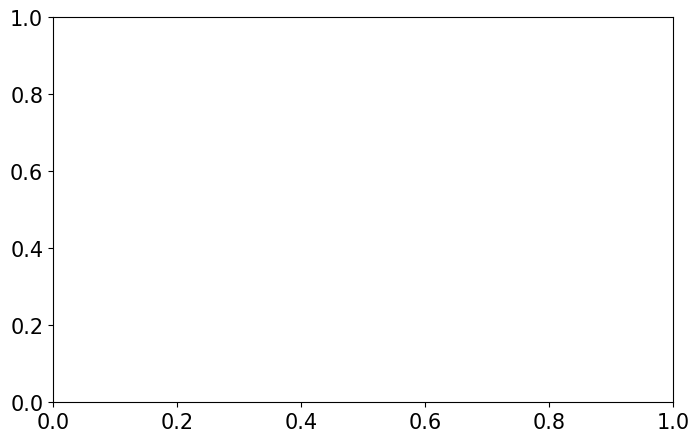

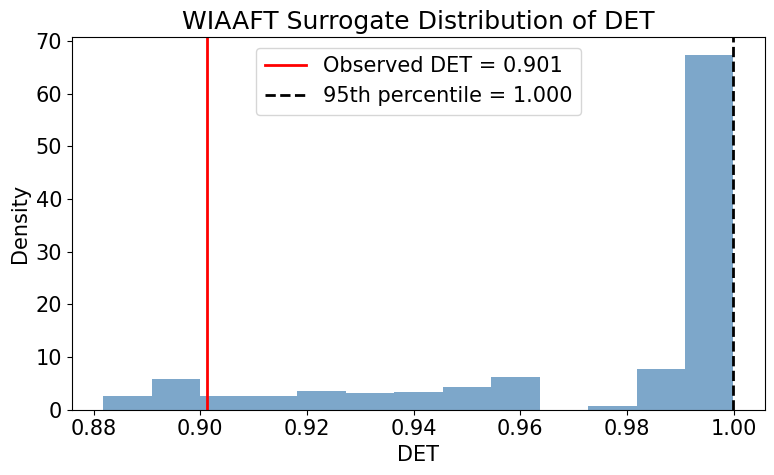

 17%|███████▏                                  | 17/100 [04:15<19:51, 14.35s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.901244167959171 
 Recurrence rate: 0.050009791878082216 
Threshold:0.801999999999928 
 Laminarity:0.9547881808438776 
Shannon Entropy:1.776108097779731 
Rank-order p-value (det):0.156 
Reject null (det) hypothesis:False

 
 

5
8
Mean Nearest Neighbor Distance: 0.42229797547637393
Pseudo-periodic surrogates generated successfullly


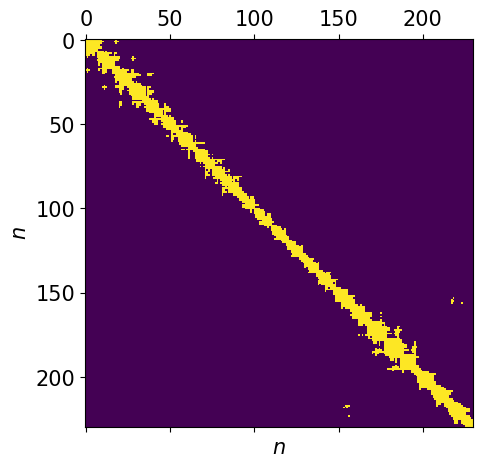

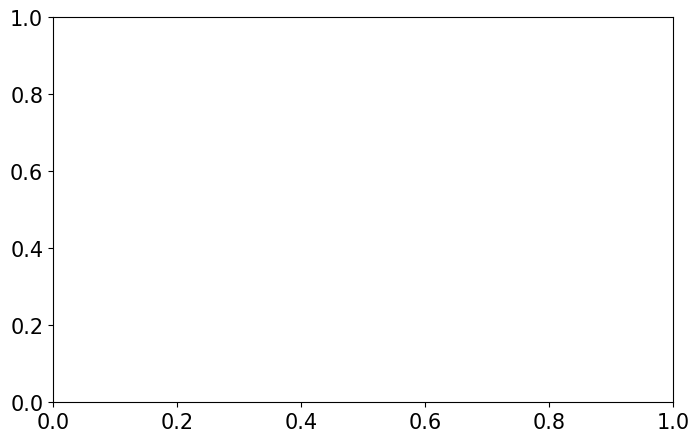

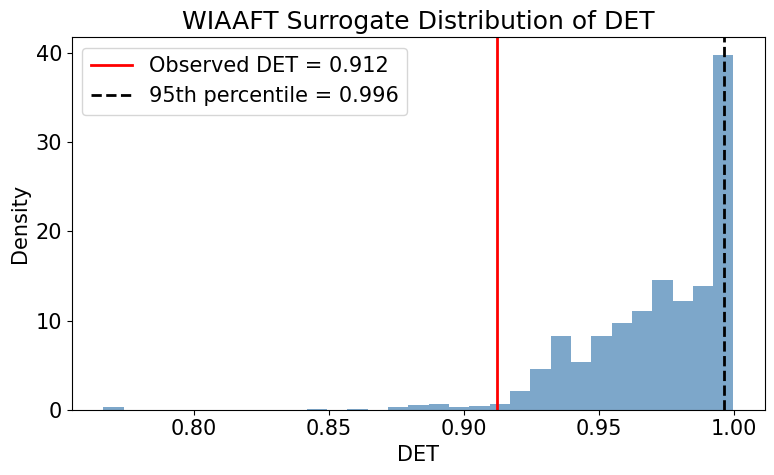

 18%|███████▌                                  | 18/100 [04:27<18:50, 13.78s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9122516556253633 
 Recurrence rate: 0.05001890359168242 
Threshold:1.0560999999999001 
 Laminarity:0.9588057445164067 
Shannon Entropy:2.0015670616171426 
Rank-order p-value (det):0.042 
Reject null (det) hypothesis:True

 
 

6
10
Mean Nearest Neighbor Distance: 0.7728020805356381
Pseudo-periodic surrogates generated successfullly


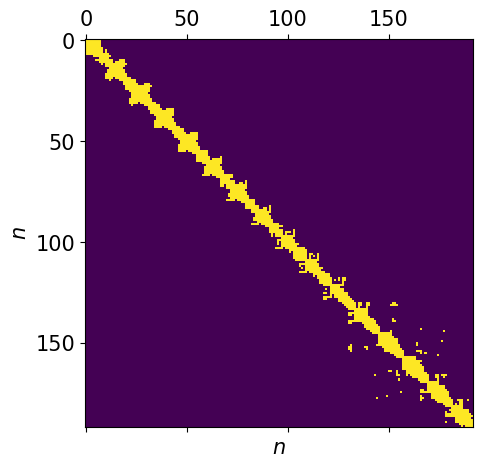

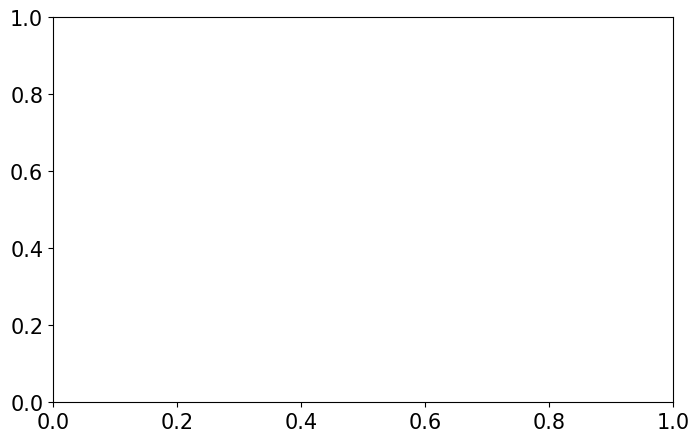

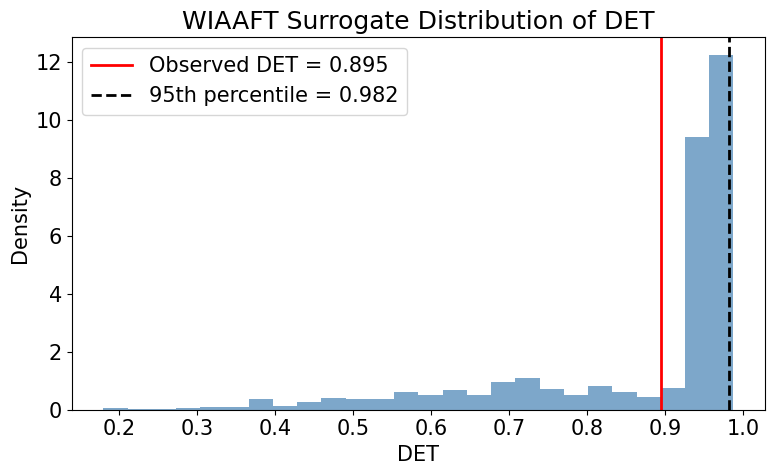

 19%|███████▉                                  | 19/100 [04:42<18:56, 14.02s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8946731234812672 
 Recurrence rate: 0.05002170138888889 
Threshold:1.847999999999813 
 Laminarity:0.9636659435956417 
Shannon Entropy:1.9734681718651907 
Rank-order p-value (det):0.612 
Reject null (det) hypothesis:False

 
 

6
10
Mean Nearest Neighbor Distance: 0.6778490852843624
Pseudo-periodic surrogates generated successfullly


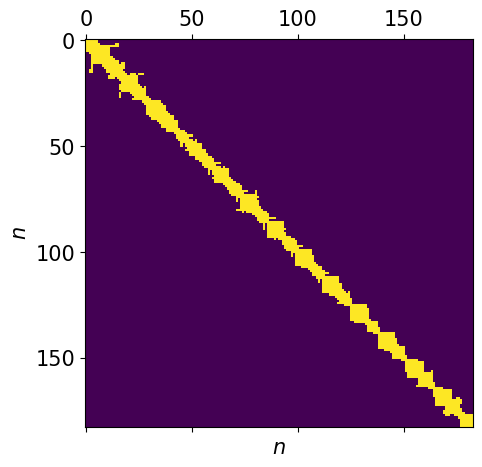

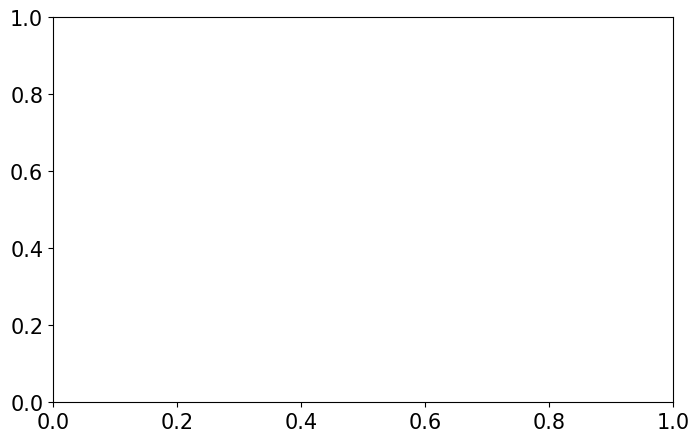

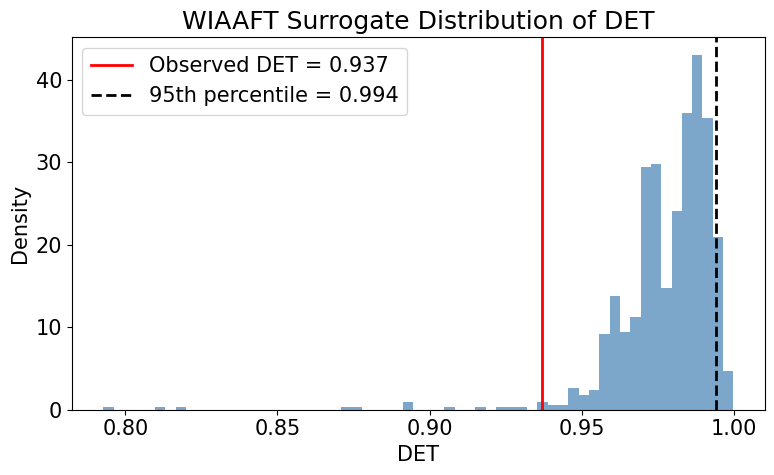

 20%|████████▍                                 | 20/100 [04:56<18:34, 13.93s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9369973190285724 
 Recurrence rate: 0.05001642330317418 
Threshold:1.8174999999998163 
 Laminarity:0.9838805970090515 
Shannon Entropy:2.1218814454399673 
Rank-order p-value (det):0.03 
Reject null (det) hypothesis:True

 
 

7
10
Mean Nearest Neighbor Distance: 0.5872767557654901
Pseudo-periodic surrogates generated successfullly


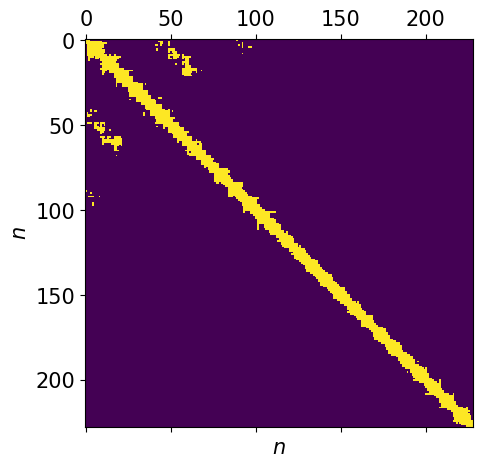

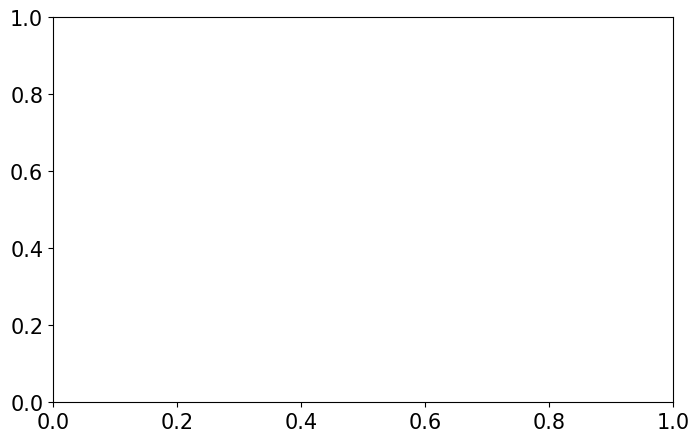

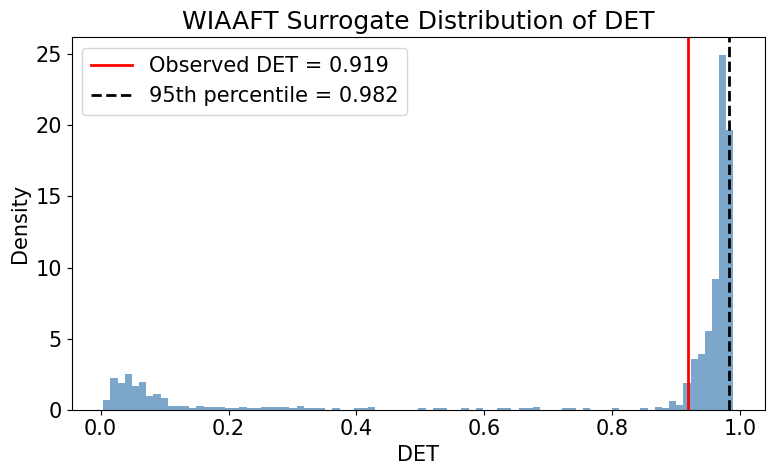

 21%|████████▊                                 | 21/100 [05:11<19:05, 14.50s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9190556492372721 
 Recurrence rate: 0.05001538935056941 
Threshold:1.6126999999998388 
 Laminarity:0.9723076923039528 
Shannon Entropy:1.9027972383807812 
Rank-order p-value (det):0.49 
Reject null (det) hypothesis:False

 
 

7
7
Mean Nearest Neighbor Distance: 0.46962181700533107
Pseudo-periodic surrogates generated successfullly


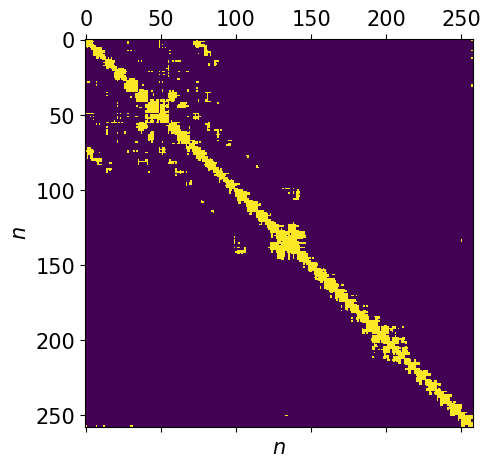

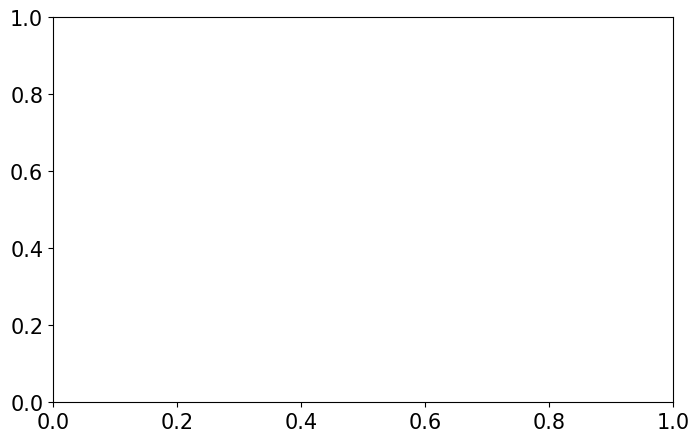

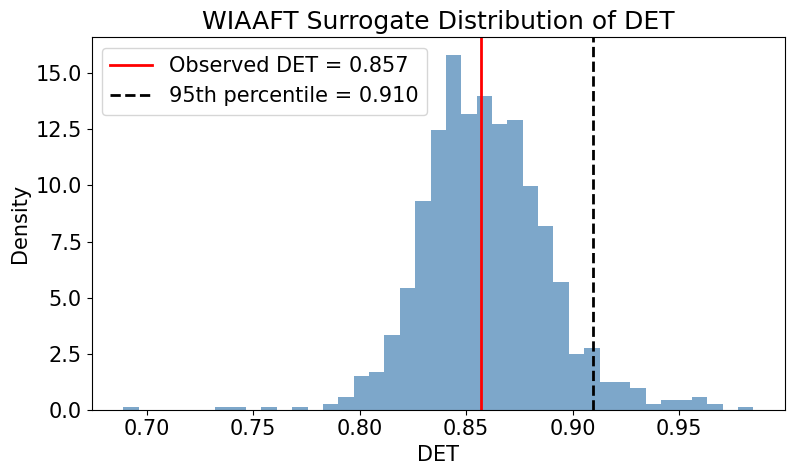

 22%|█████████▏                                | 22/100 [05:26<19:00, 14.62s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8567708333305444 
 Recurrence rate: 0.050027041644131964 
Threshold:1.1610999999998886 
 Laminarity:0.920120120117357 
Shannon Entropy:1.856351678664327 
Rank-order p-value (det):0.978 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.8210301321411628
Pseudo-periodic surrogates generated successfullly


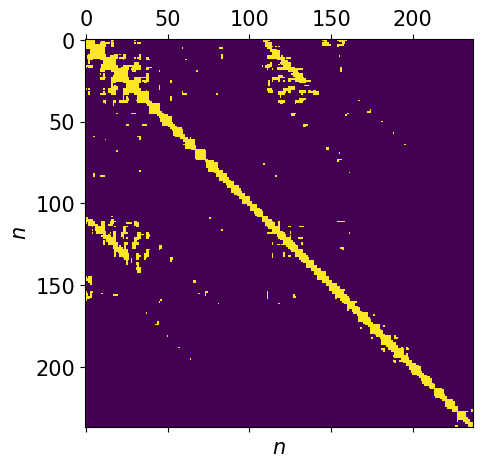

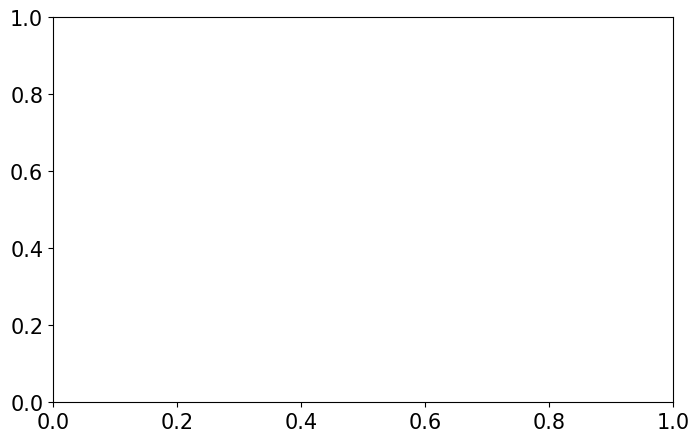

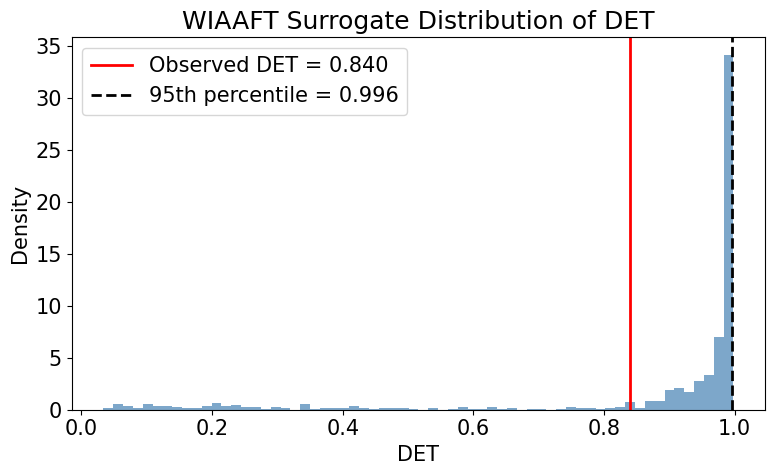

 23%|█████████▋                                | 23/100 [05:46<20:53, 16.28s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8398133748023335 
 Recurrence rate: 0.050009791878082216 
Threshold:1.928299999999804 
 Laminarity:0.9341402634356207 
Shannon Entropy:1.4402158862851613 
Rank-order p-value (det):0.336 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.5465385023442587
Pseudo-periodic surrogates generated successfullly


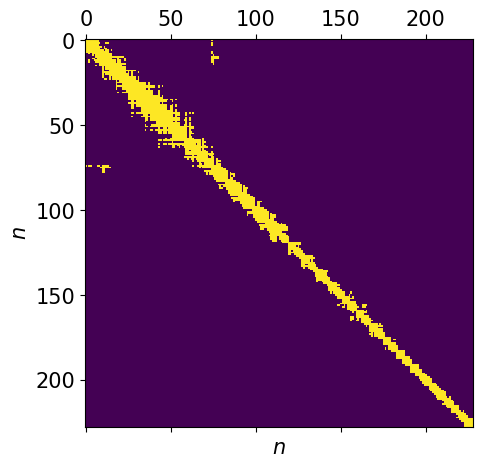

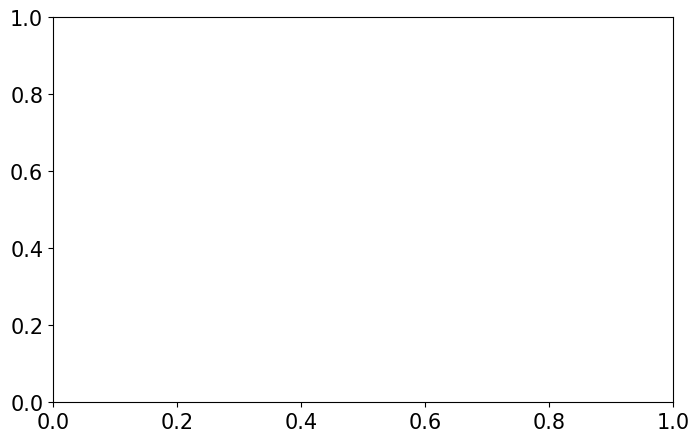

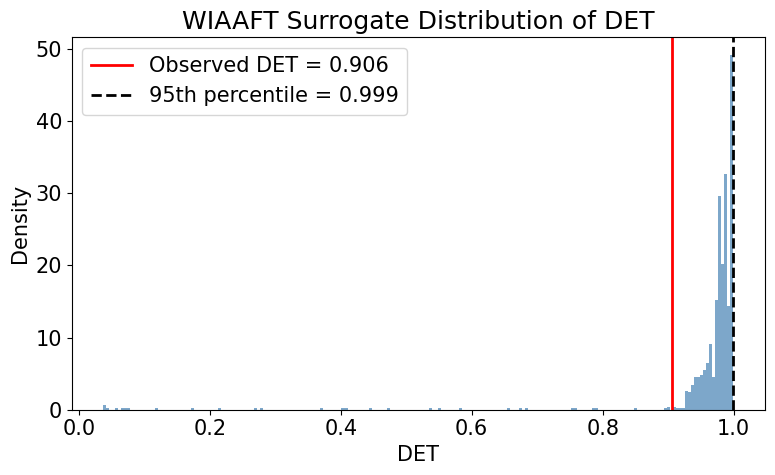

 24%|██████████                                | 24/100 [06:01<19:55, 15.73s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9056444818832956 
 Recurrence rate: 0.05005386272699292 
Threshold:1.2444999999998794 
 Laminarity:0.9500384319717524 
Shannon Entropy:1.728829152057188 
Rank-order p-value (det):0.066 
Reject null (det) hypothesis:False

 
 

7
9
Mean Nearest Neighbor Distance: 0.4531889971543736
Pseudo-periodic surrogates generated successfullly


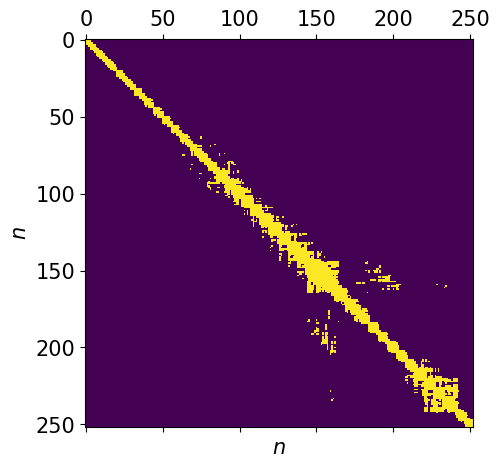

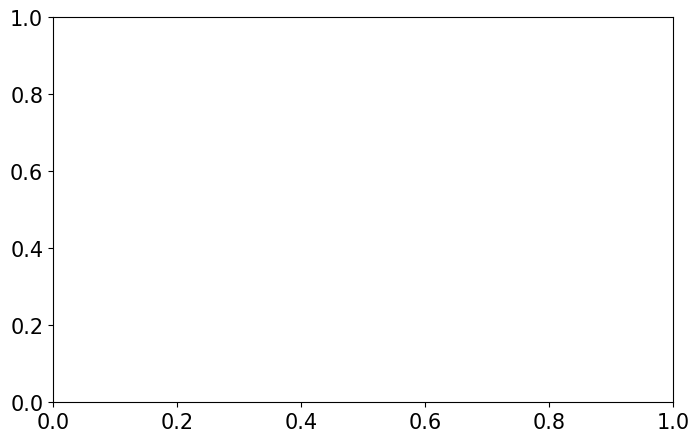

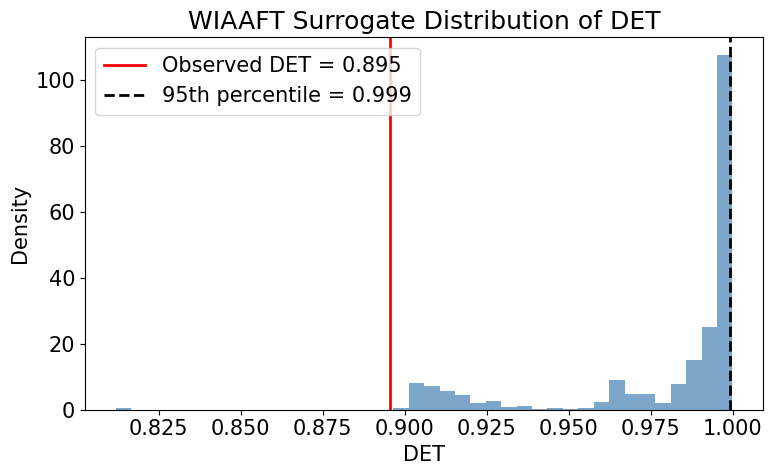

 25%|██████████▌                               | 25/100 [06:15<19:13, 15.37s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8954203691015195 
 Recurrence rate: 0.050044091710758375 
Threshold:1.1054999999998947 
 Laminarity:0.9465072372531577 
Shannon Entropy:1.7342733156173245 
Rank-order p-value (det):0.006 
Reject null (det) hypothesis:True

 
 

8
10
Mean Nearest Neighbor Distance: 0.5444869539631365
Pseudo-periodic surrogates generated successfullly


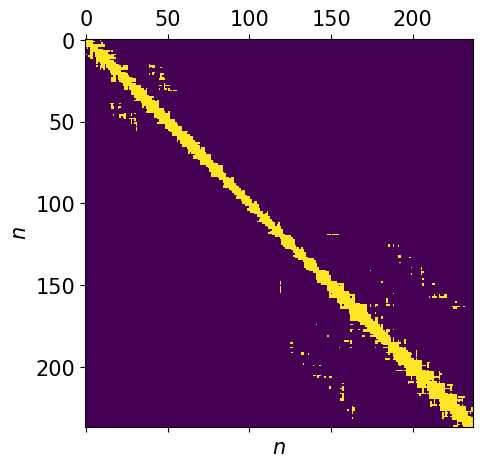

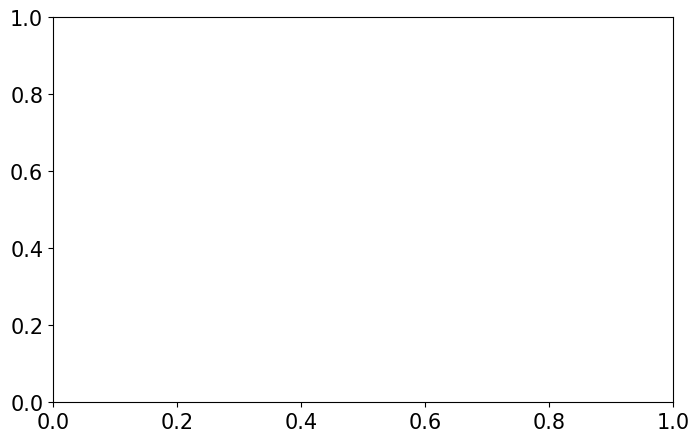

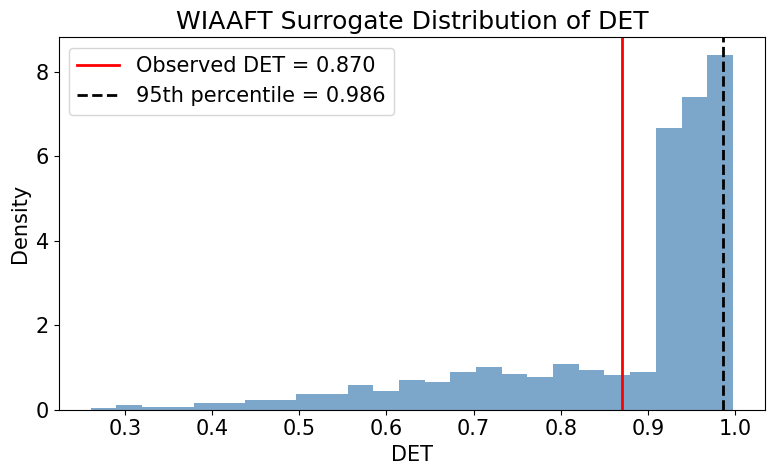

 26%|██████████▉                               | 26/100 [06:31<19:01, 15.43s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8701399688924178 
 Recurrence rate: 0.050009791878082216 
Threshold:1.347099999999868 
 Laminarity:0.9394802420756871 
Shannon Entropy:1.803430335670706 
Rank-order p-value (det):0.608 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.7491784215601858
Pseudo-periodic surrogates generated successfullly


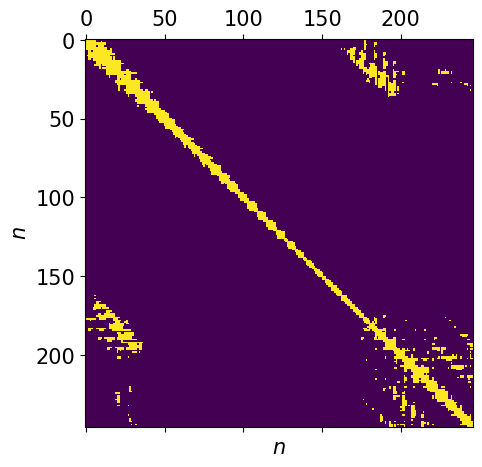

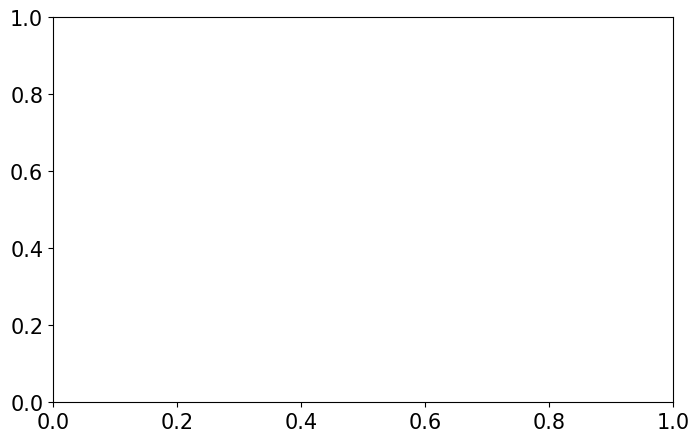

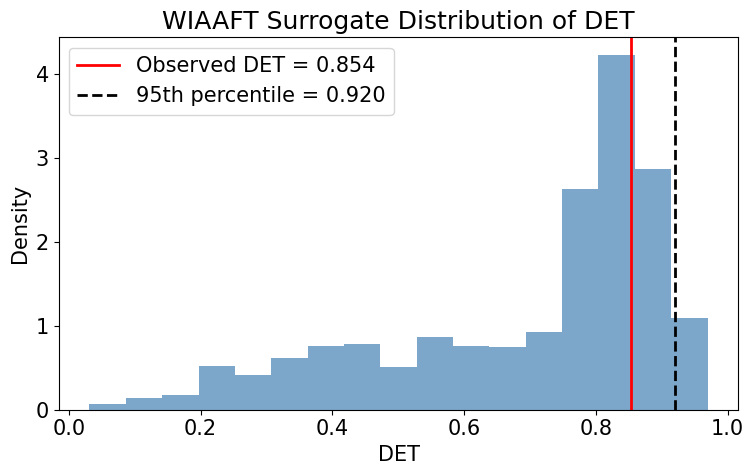

 27%|███████████▎                              | 27/100 [06:50<20:11, 16.60s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8539568345293024 
 Recurrence rate: 0.05000330491109789 
Threshold:1.6552999999998341 
 Laminarity:0.9348975545243394 
Shannon Entropy:1.5620008788909643 
Rank-order p-value (det):0.466 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.6338565908452743
Pseudo-periodic surrogates generated successfullly


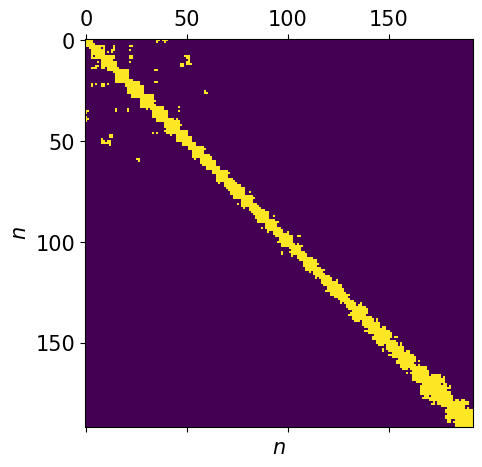

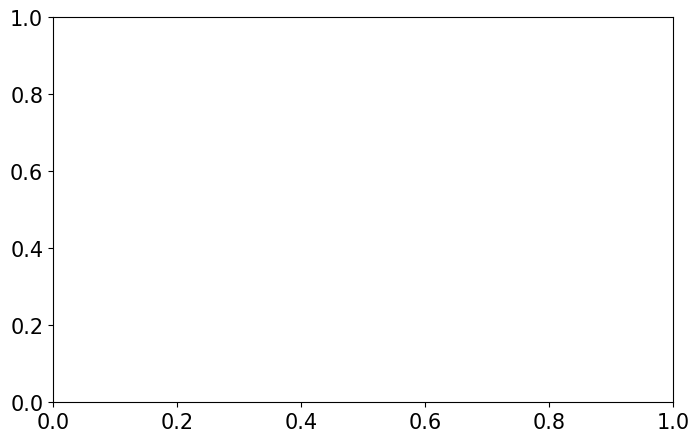

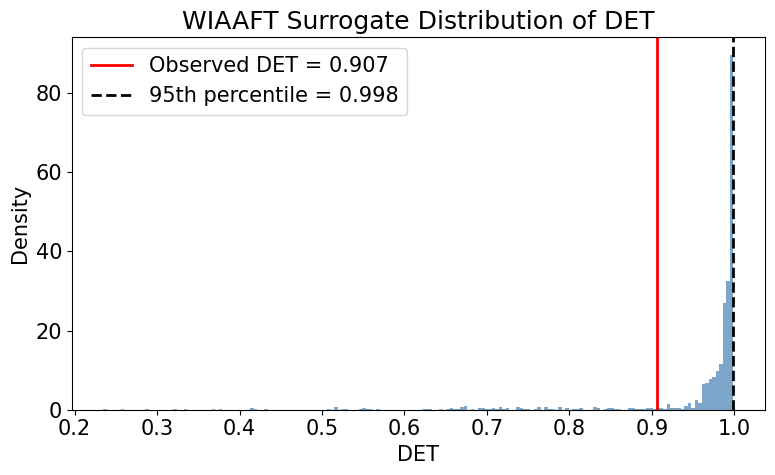

 28%|███████████▊                              | 28/100 [07:04<18:56, 15.79s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9067796610114602 
 Recurrence rate: 0.05002170138888889 
Threshold:1.5944999999998408 
 Laminarity:0.9647505422941175 
Shannon Entropy:1.740470970125533 
Rank-order p-value (det):0.212 
Reject null (det) hypothesis:False

 
 

8
9
Mean Nearest Neighbor Distance: 0.6669843166931007
Pseudo-periodic surrogates generated successfullly


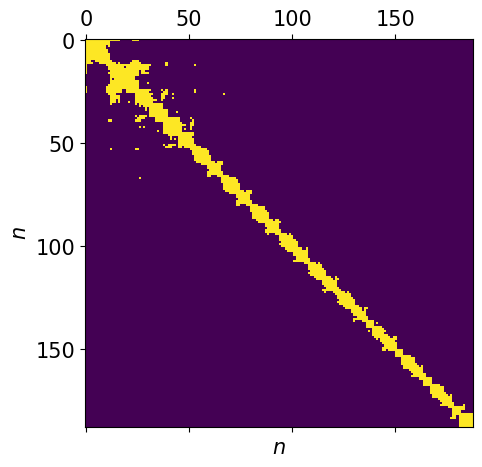

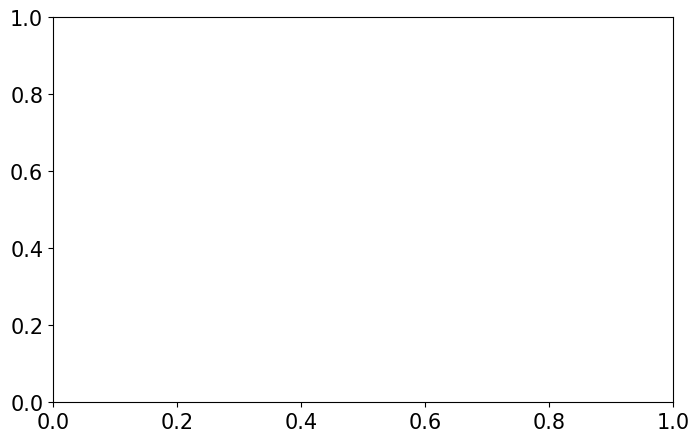

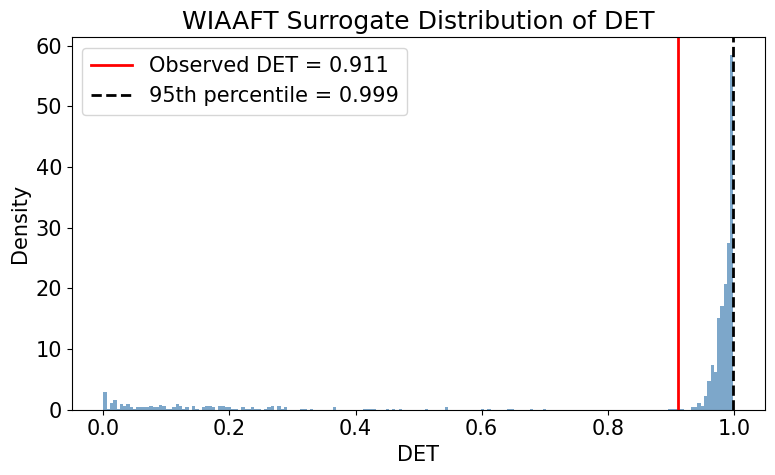

 29%|████████████▏                             | 29/100 [07:18<17:48, 15.05s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.911392405057523 
 Recurrence rate: 0.05002263467632413 
Threshold:1.5723999999998433 
 Laminarity:0.9649321266913748 
Shannon Entropy:2.0055515033168847 
Rank-order p-value (det):0.31 
Reject null (det) hypothesis:False

 
 

8
6
Mean Nearest Neighbor Distance: 0.30820111798877675
Pseudo-periodic surrogates generated successfullly


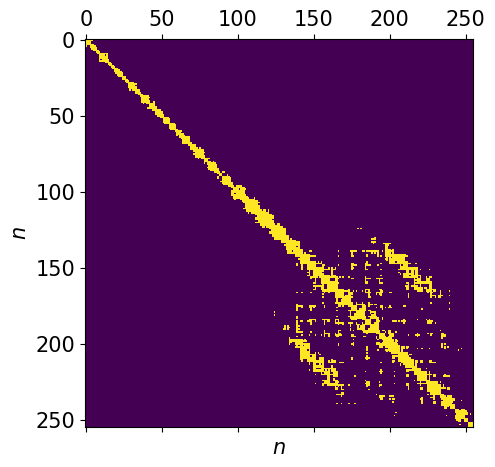

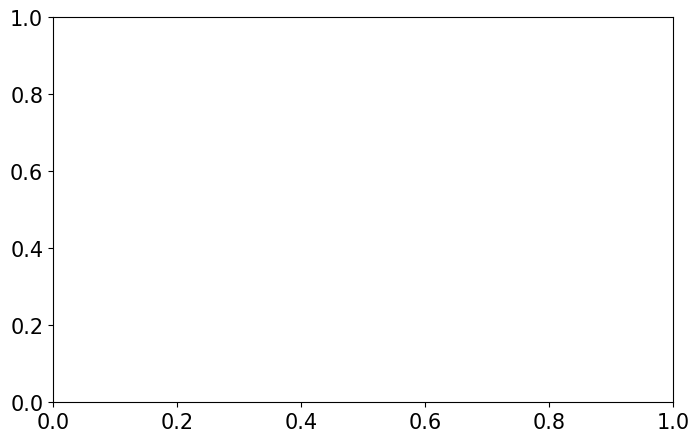

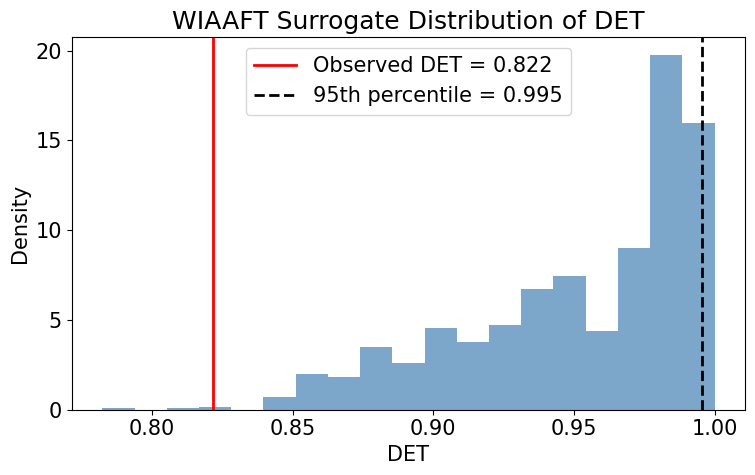

 30%|████████████▌                             | 30/100 [07:28<16:06, 13.81s/it]

RQA  ar1 Embedding dimensions:6 
 DET of original:0.8218812541667049 
 Recurrence rate: 0.050026912725874666 
Threshold:0.6889999999999404 
 Laminarity:0.893636643095931 
Shannon Entropy:1.6277742074369677 
Rank-order p-value (det):0.008 
Reject null (det) hypothesis:True

 
 

9
10
Mean Nearest Neighbor Distance: 0.6591559768022824
Pseudo-periodic surrogates generated successfullly


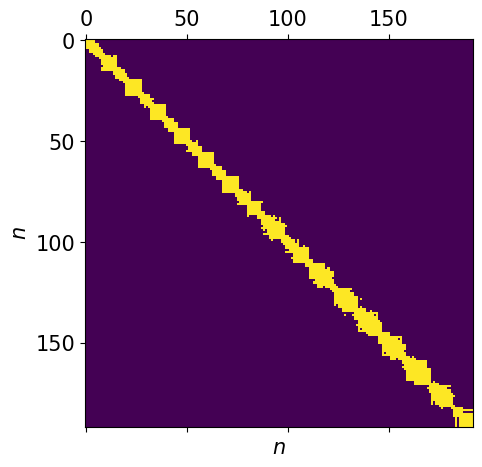

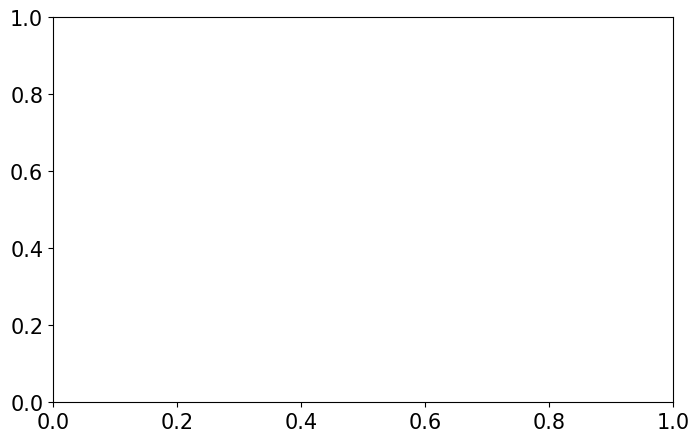

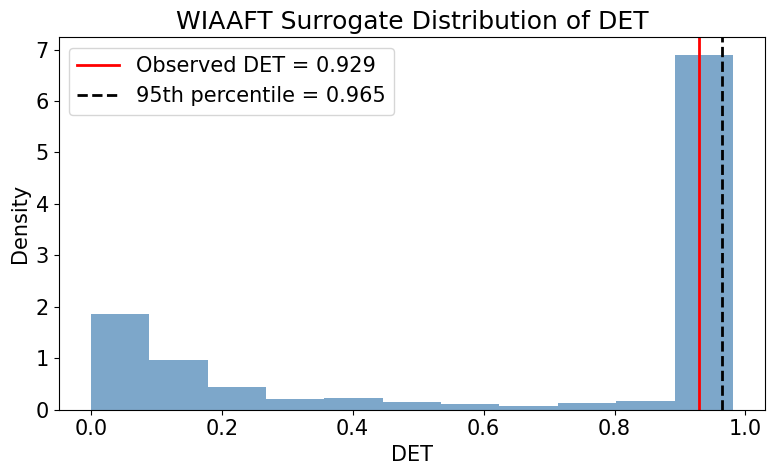

 31%|█████████████                             | 31/100 [07:42<15:37, 13.58s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9285714285658078 
 Recurrence rate: 0.05002170138888889 
Threshold:1.566199999999844 
 Laminarity:0.9826464208189661 
Shannon Entropy:2.2053471951591694 
Rank-order p-value (det):0.876 
Reject null (det) hypothesis:False

 
 

9
10
Mean Nearest Neighbor Distance: 0.40886954279632076
Pseudo-periodic surrogates generated successfullly


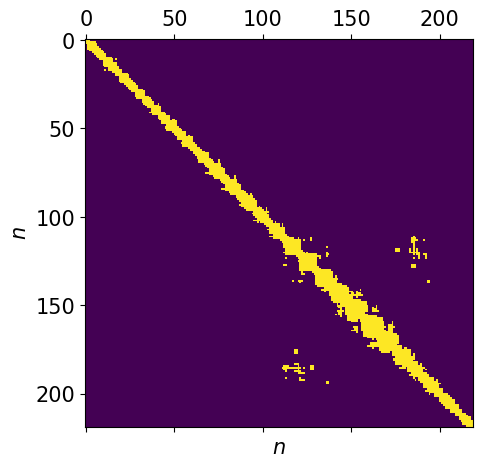

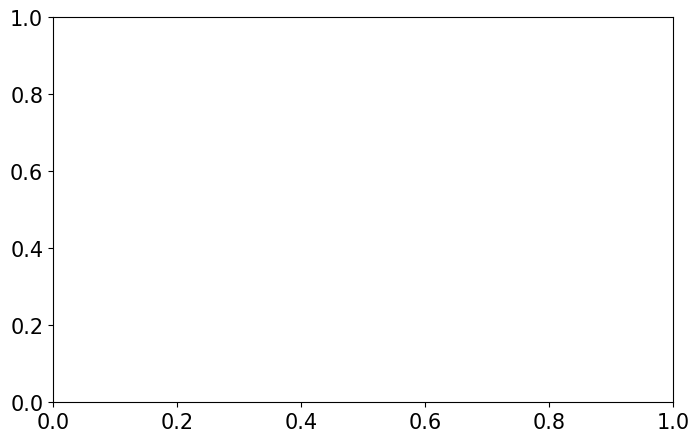

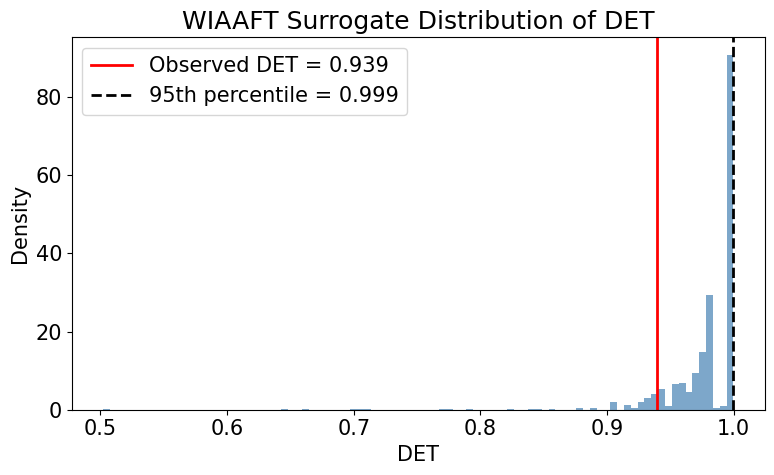

 32%|█████████████▍                            | 32/100 [07:54<14:57, 13.20s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9394495412800943 
 Recurrence rate: 0.05001980776047205 
Threshold:1.1459999999998902 
 Laminarity:0.9674864526845874 
Shannon Entropy:1.9582451971317087 
Rank-order p-value (det):0.148 
Reject null (det) hypothesis:False

 
 

9
10
Mean Nearest Neighbor Distance: 0.7573007413976935
Pseudo-periodic surrogates generated successfullly


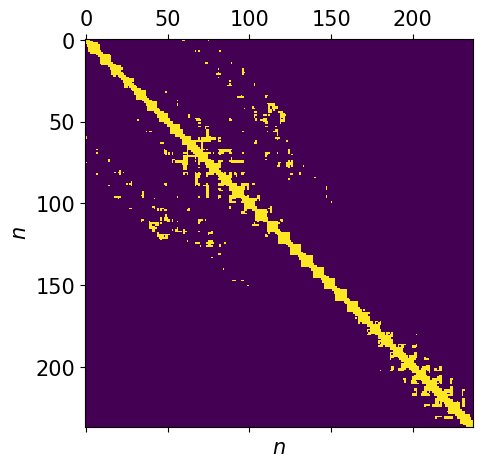

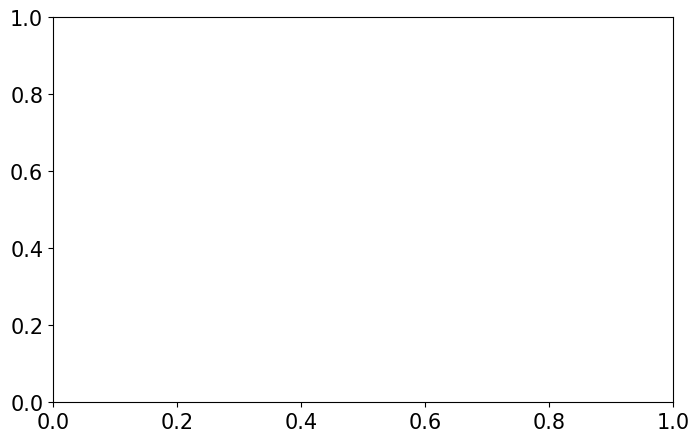

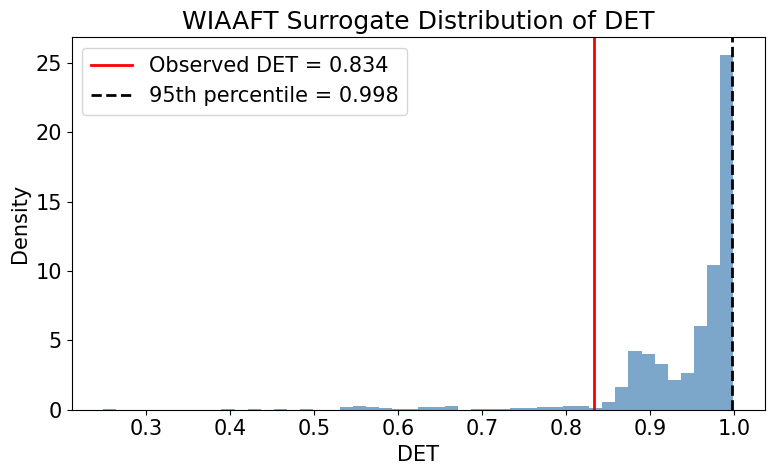

 33%|█████████████▊                            | 33/100 [08:11<16:08, 14.46s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8337218337185948 
 Recurrence rate: 0.05004539870747209 
Threshold:1.7623999999998223 
 Laminarity:0.9242262539988466 
Shannon Entropy:1.3011884483726082 
Rank-order p-value (det):0.102 
Reject null (det) hypothesis:False

 
 

9
10
Mean Nearest Neighbor Distance: 0.6197027286610749
Pseudo-periodic surrogates generated successfullly


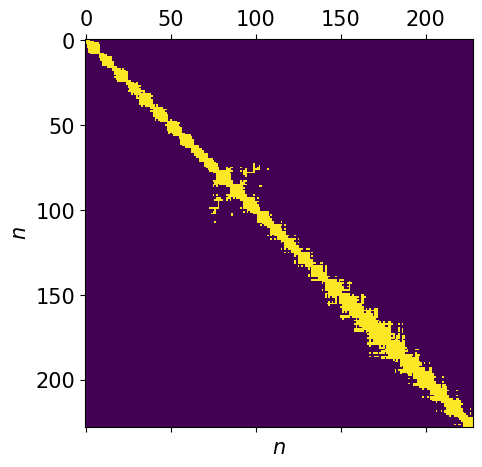

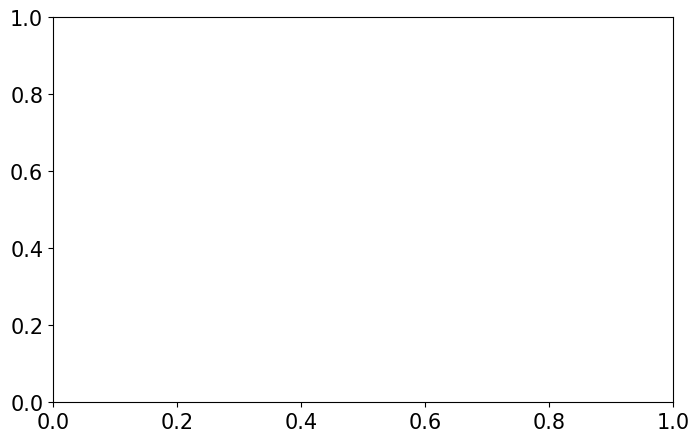

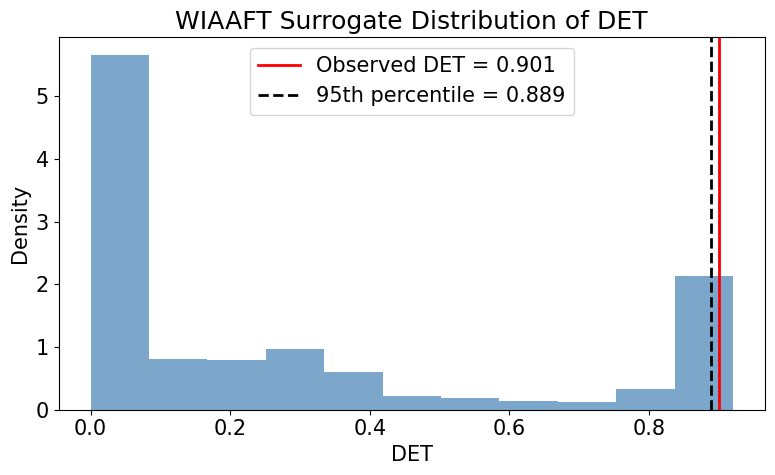

 34%|██████████████▎                           | 34/100 [08:26<15:52, 14.44s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9005059021884465 
 Recurrence rate: 0.05001538935056941 
Threshold:1.4007999999998622 
 Laminarity:0.9430769230732959 
Shannon Entropy:1.799445832866089 
Rank-order p-value (det):0.034 
Reject null (det) hypothesis:True

 
 

10
9
Mean Nearest Neighbor Distance: 0.7248282570024002
Pseudo-periodic surrogates generated successfullly


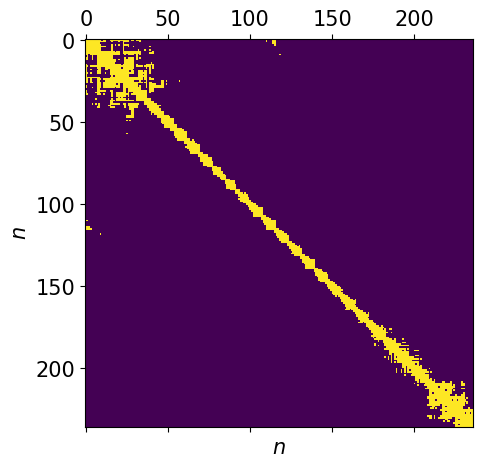

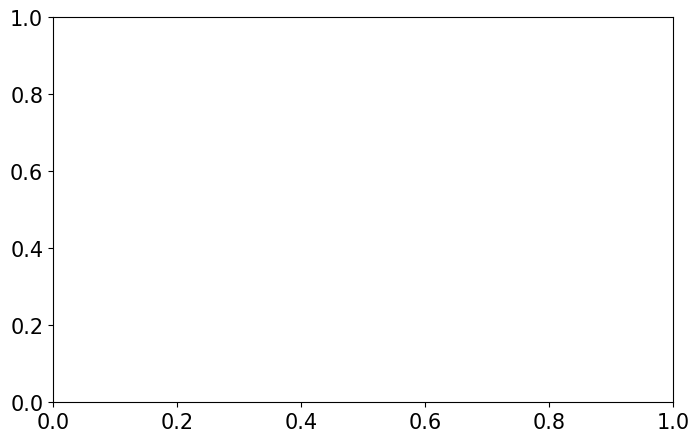

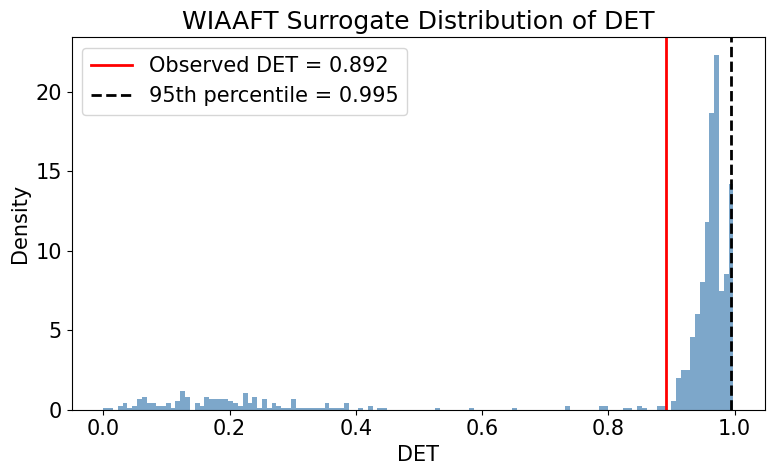

 35%|██████████████▋                           | 35/100 [08:43<16:42, 15.42s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8917647058788558 
 Recurrence rate: 0.05002154553289285 
Threshold:1.8402999999998138 
 Laminarity:0.9429289303627318 
Shannon Entropy:1.8192993153991417 
Rank-order p-value (det):0.338 
Reject null (det) hypothesis:False

 
 

10
9
Mean Nearest Neighbor Distance: 0.5851358081530917
Pseudo-periodic surrogates generated successfullly


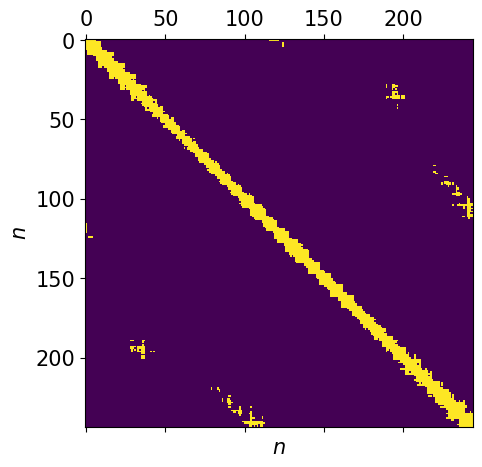

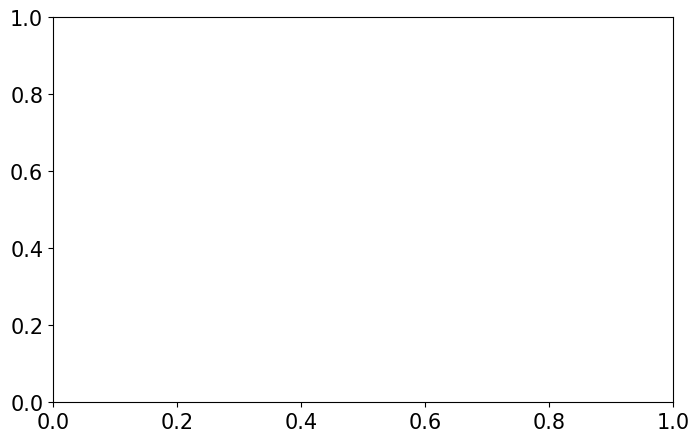

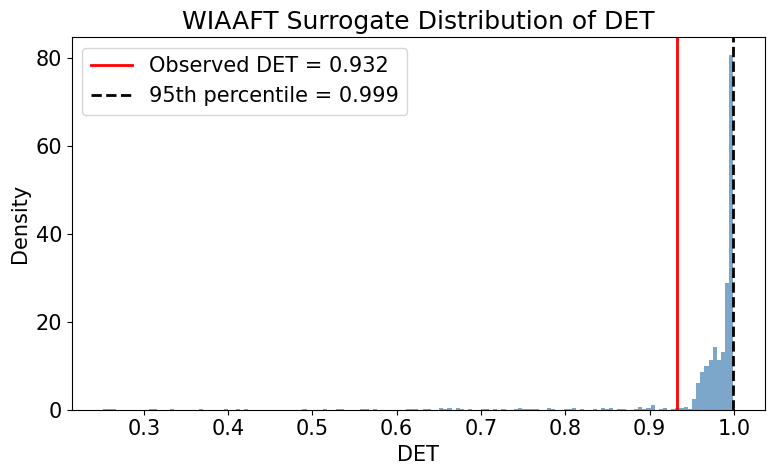

 36%|███████████████                           | 36/100 [09:00<16:55, 15.87s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.931967812725194 
 Recurrence rate: 0.0500201558720774 
Threshold:1.5760999999998428 
 Laminarity:0.9697783747448967 
Shannon Entropy:1.7827168891075131 
Rank-order p-value (det):0.15 
Reject null (det) hypothesis:False

 
 

10
10
Mean Nearest Neighbor Distance: 0.3250325586057951
Pseudo-periodic surrogates generated successfullly


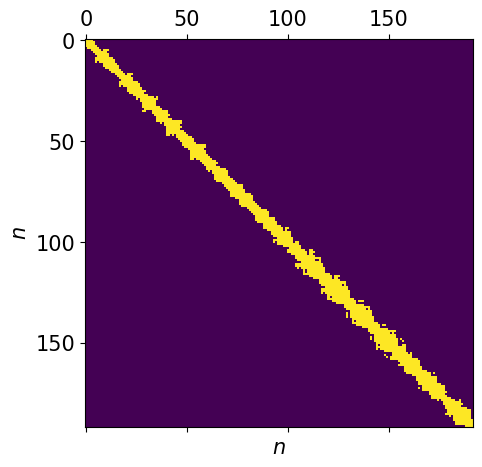

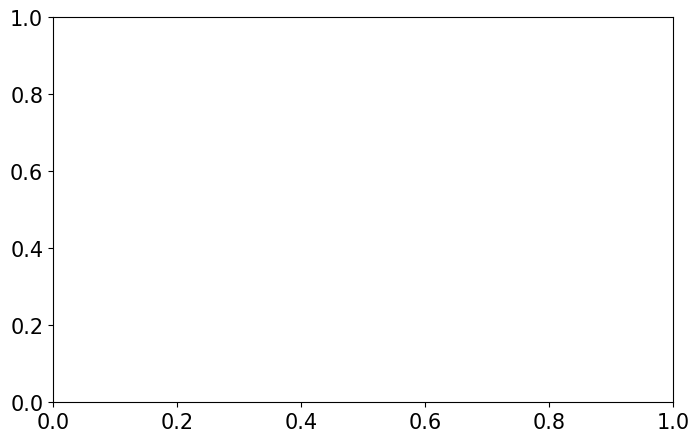

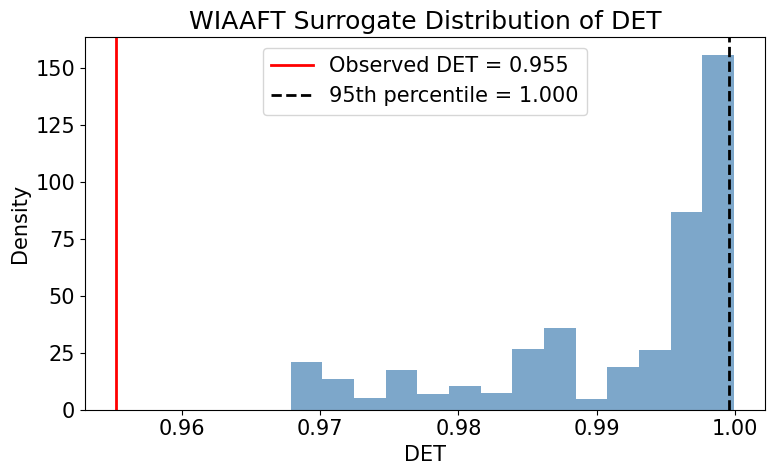

 37%|███████████████▌                          | 37/100 [09:10<14:38, 13.95s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9552058111322325 
 Recurrence rate: 0.05002170138888889 
Threshold:0.8227999999999257 
 Laminarity:0.9804772234220148 
Shannon Entropy:1.830409609175862 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

11
10
Mean Nearest Neighbor Distance: 0.625910055329674
Pseudo-periodic surrogates generated successfullly


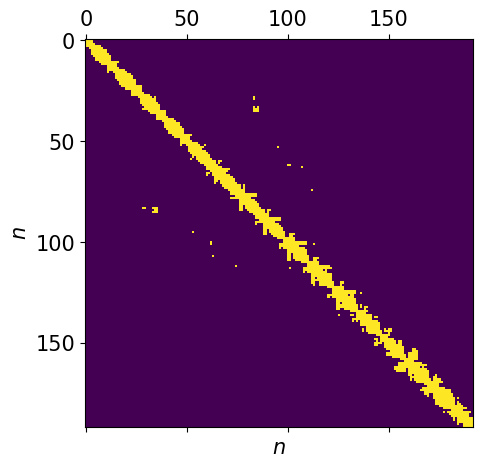

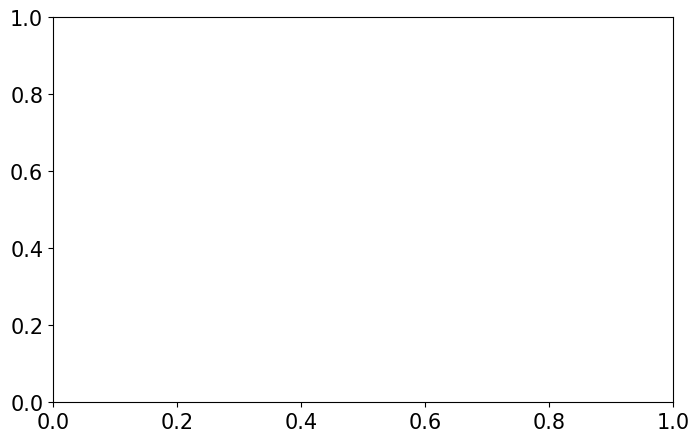

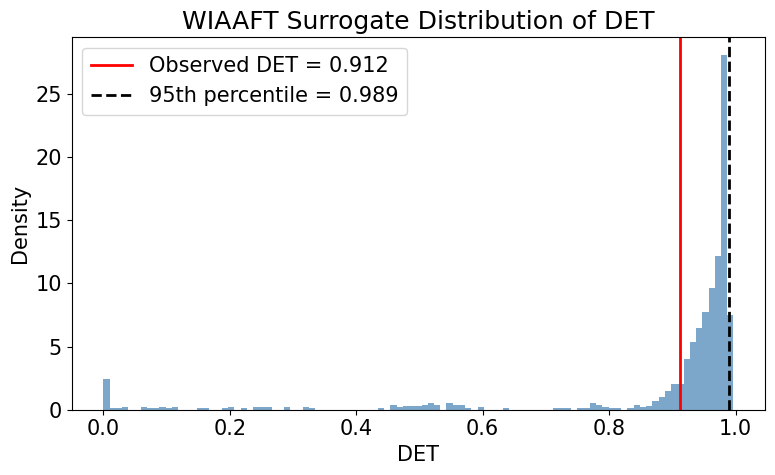

 38%|███████████████▉                          | 38/100 [09:22<14:00, 13.55s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9116222760235374 
 Recurrence rate: 0.05002170138888889 
Threshold:1.4613999999998555 
 Laminarity:0.9701735357864959 
Shannon Entropy:1.882905402326621 
Rank-order p-value (det):0.372 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.5122917385695226
Pseudo-periodic surrogates generated successfullly


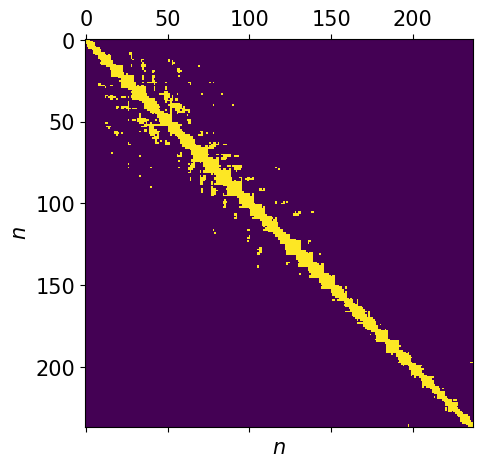

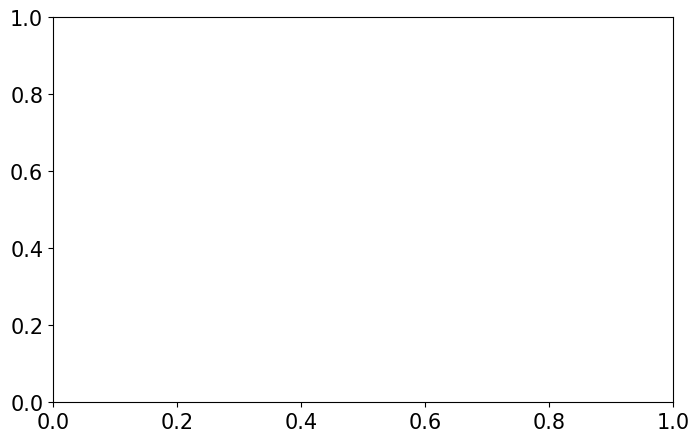

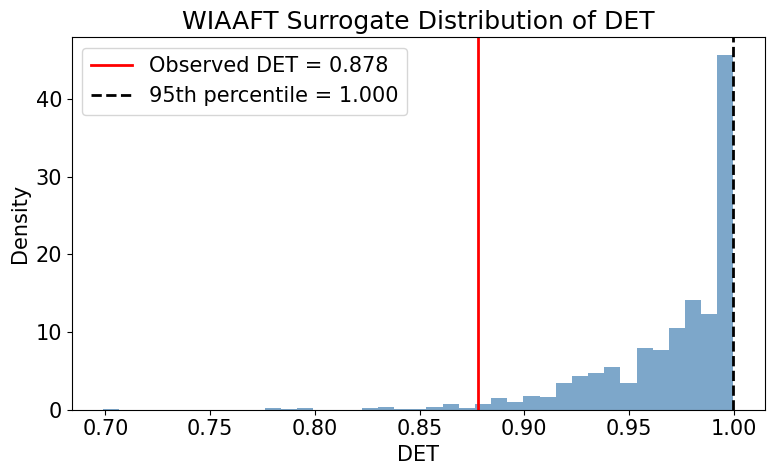

 39%|████████████████▍                         | 39/100 [09:37<13:58, 13.74s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.878010878007467 
 Recurrence rate: 0.05004539870747209 
Threshold:1.2340999999998805 
 Laminarity:0.9370330843082995 
Shannon Entropy:1.5346653202608898 
Rank-order p-value (det):0.052 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.6453256934322514
Pseudo-periodic surrogates generated successfullly


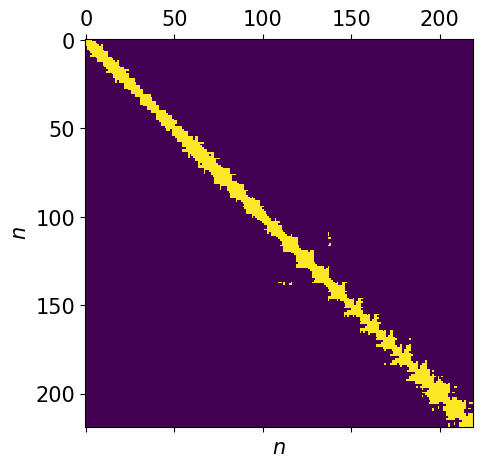

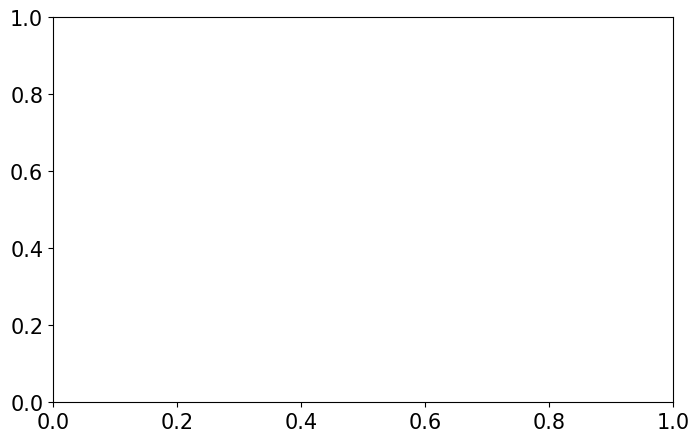

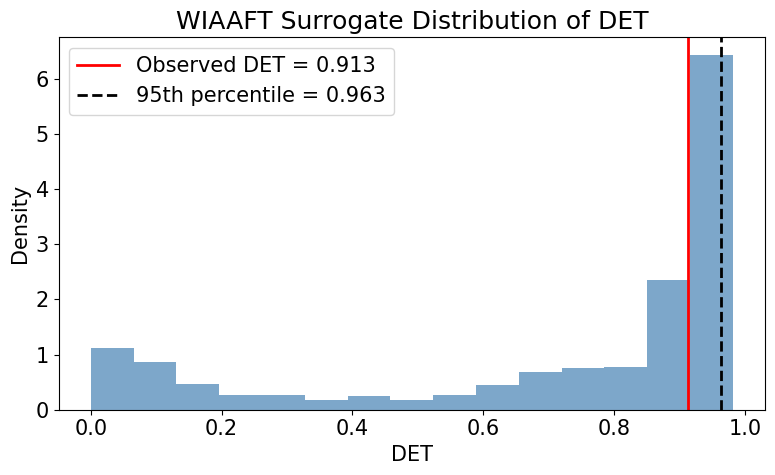

 40%|████████████████▊                         | 40/100 [09:52<14:13, 14.23s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9128440366930604 
 Recurrence rate: 0.05001980776047205 
Threshold:1.51069999999985 
 Laminarity:0.9729053772364614 
Shannon Entropy:2.0814285380920476 
Rank-order p-value (det):0.878 
Reject null (det) hypothesis:False

 
 

11
9
Mean Nearest Neighbor Distance: 0.4508889110456636
Pseudo-periodic surrogates generated successfullly


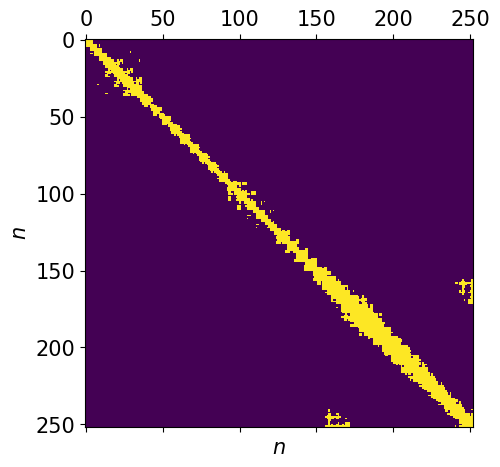

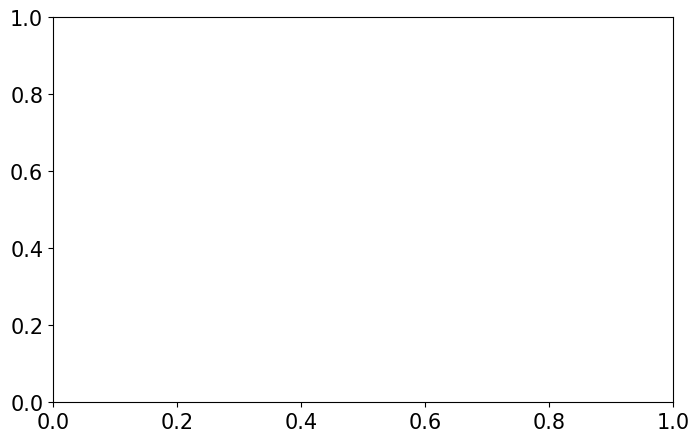

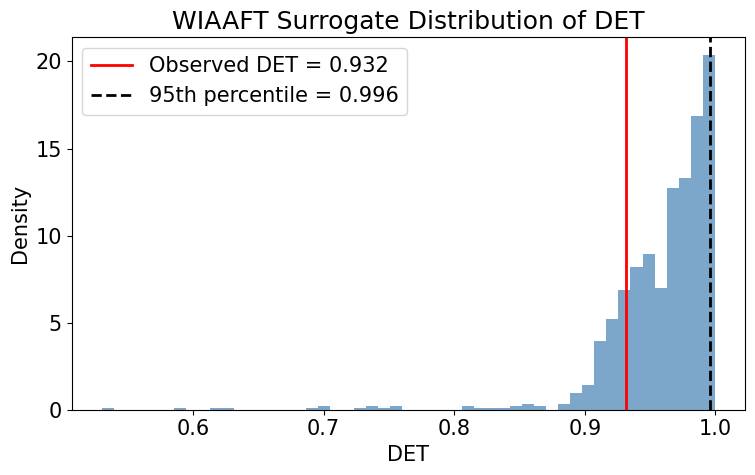

 41%|█████████████████▏                        | 41/100 [10:08<14:27, 14.70s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9316005471924365 
 Recurrence rate: 0.05001259763164525 
Threshold:1.2316999999998808 
 Laminarity:0.972292191432707 
Shannon Entropy:1.6820344473374413 
Rank-order p-value (det):0.344 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.6085164605441098
Pseudo-periodic surrogates generated successfullly


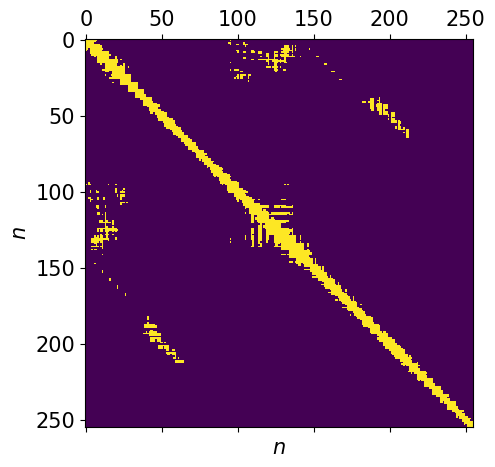

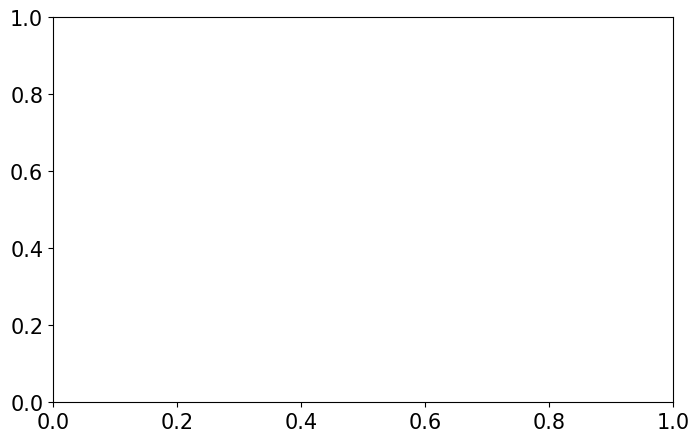

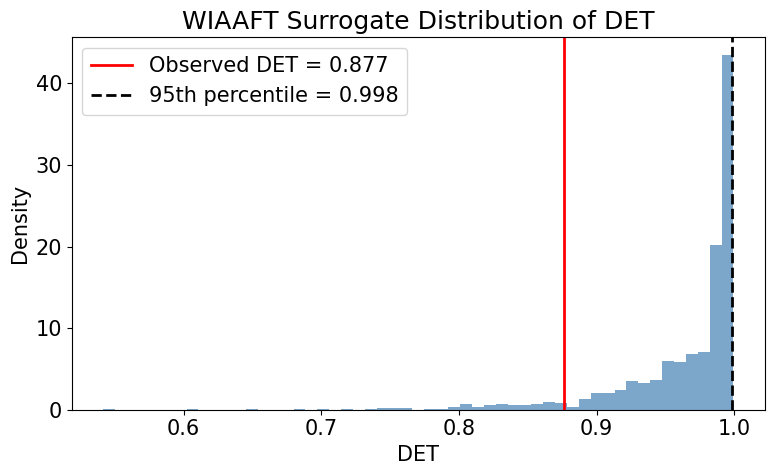

 42%|█████████████████▋                        | 42/100 [10:26<15:10, 15.70s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8765843895901382 
 Recurrence rate: 0.050026912725874666 
Threshold:1.5059999999998506 
 Laminarity:0.9391331078975127 
Shannon Entropy:1.3550686599523105 
Rank-order p-value (det):0.138 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.723276862875825
Pseudo-periodic surrogates generated successfullly


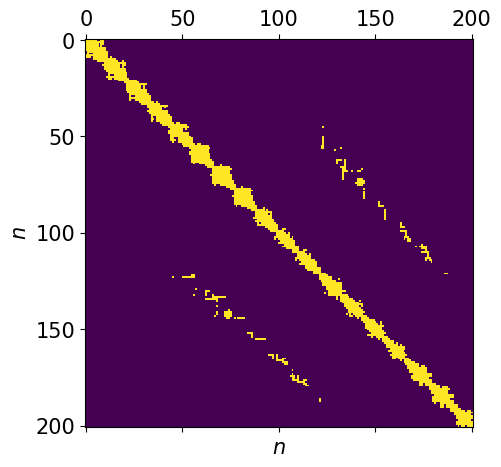

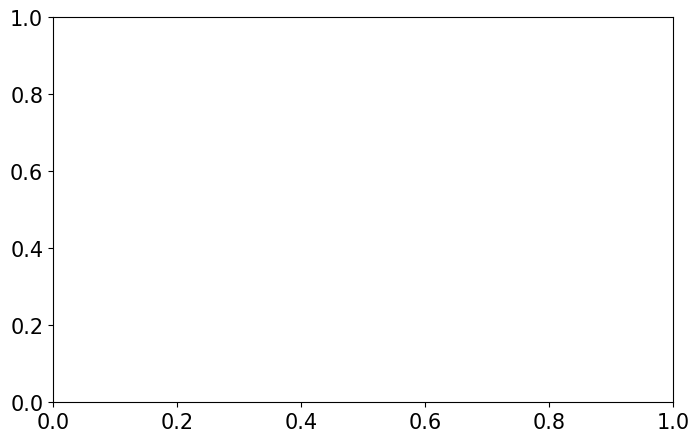

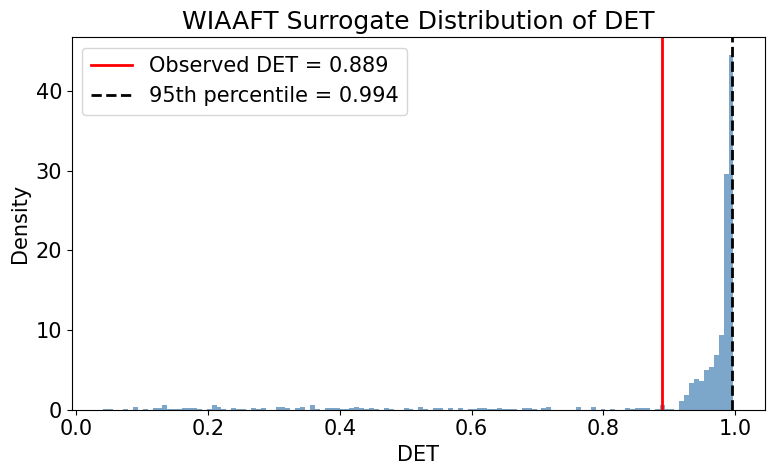

 43%|██████████████████                        | 43/100 [10:39<14:17, 15.04s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8890109890061044 
 Recurrence rate: 0.050023514269448774 
Threshold:1.5248999999998485 
 Laminarity:0.9411182582833196 
Shannon Entropy:1.9473091736635812 
Rank-order p-value (det):0.282 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.7006464363178345
Pseudo-periodic surrogates generated successfullly


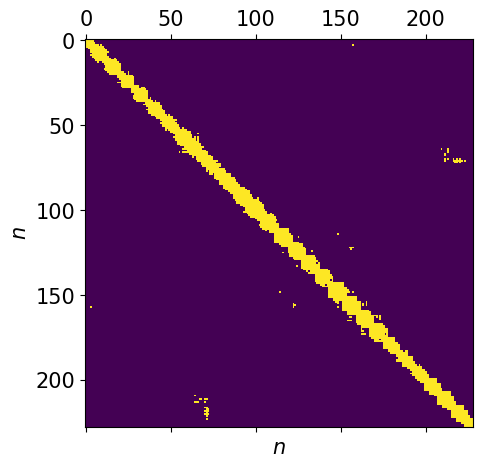

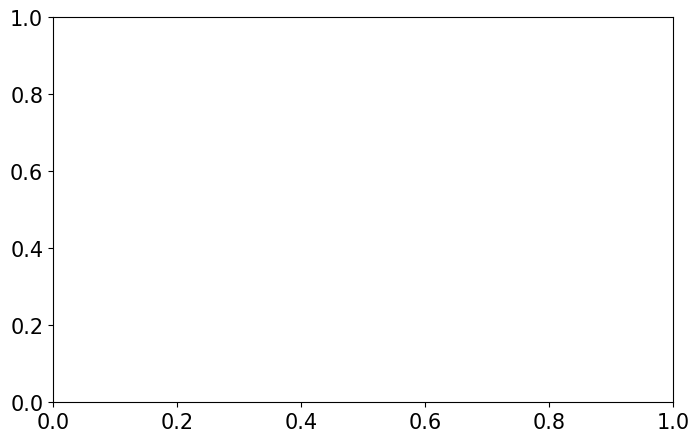

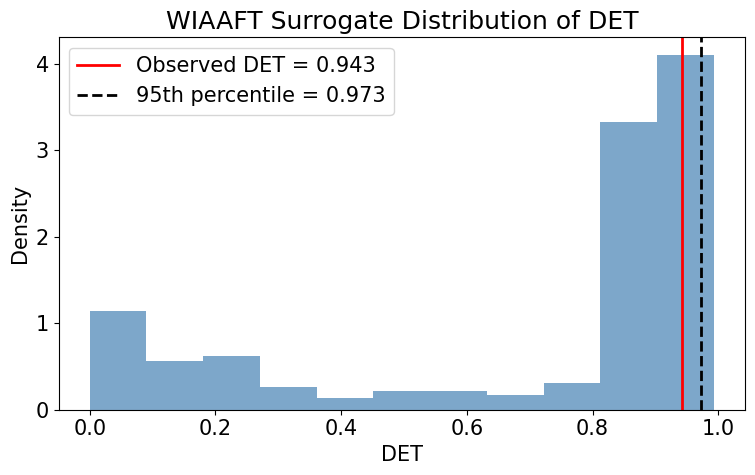

 44%|██████████████████▍                       | 44/100 [10:57<14:51, 15.91s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9426644182085049 
 Recurrence rate: 0.05001538935056941 
Threshold:1.846599999999813 
 Laminarity:0.9734615384577944 
Shannon Entropy:2.122170401565371 
Rank-order p-value (det):0.36 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.5569911263109502
Pseudo-periodic surrogates generated successfullly


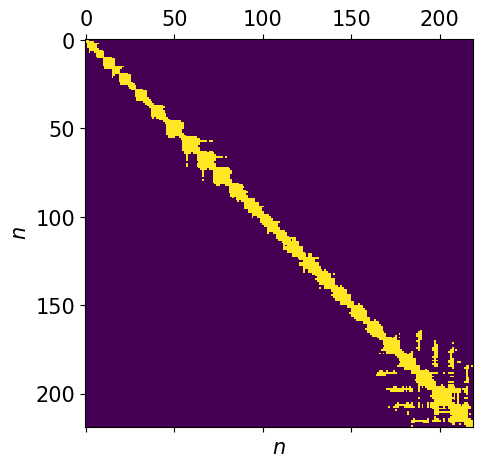

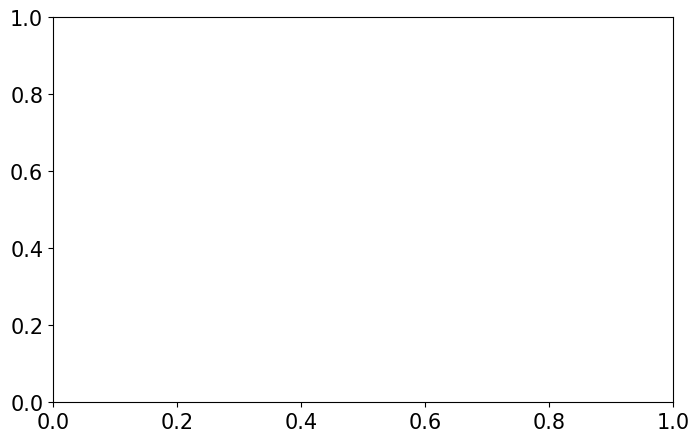

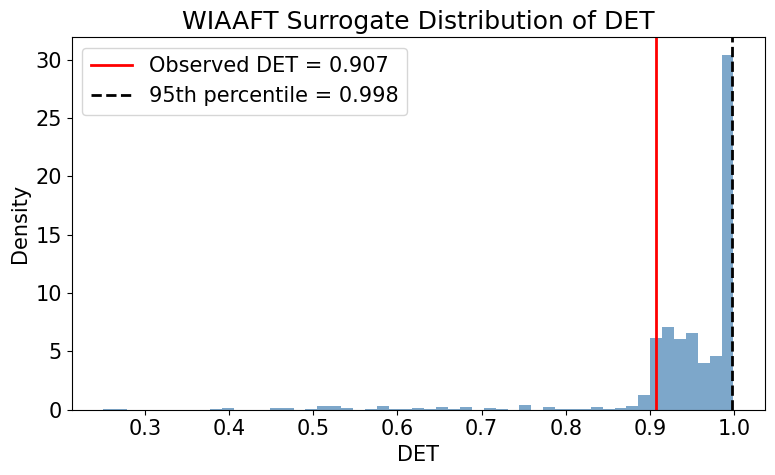

 45%|██████████████████▉                       | 45/100 [11:12<14:12, 15.51s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9073394495371223 
 Recurrence rate: 0.05001980776047205 
Threshold:1.4490999999998568 
 Laminarity:0.9566486035808394 
Shannon Entropy:1.9367631298825227 
Rank-order p-value (det):0.238 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.38051418050606645
Pseudo-periodic surrogates generated successfullly


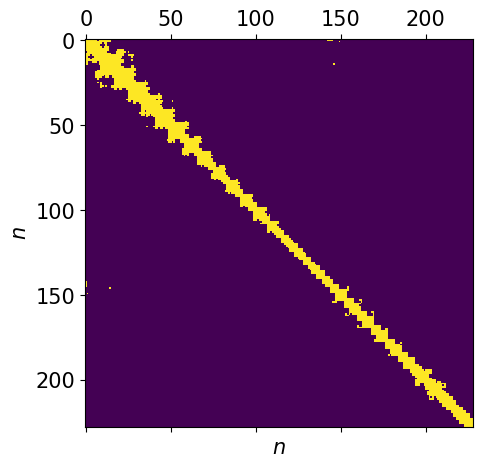

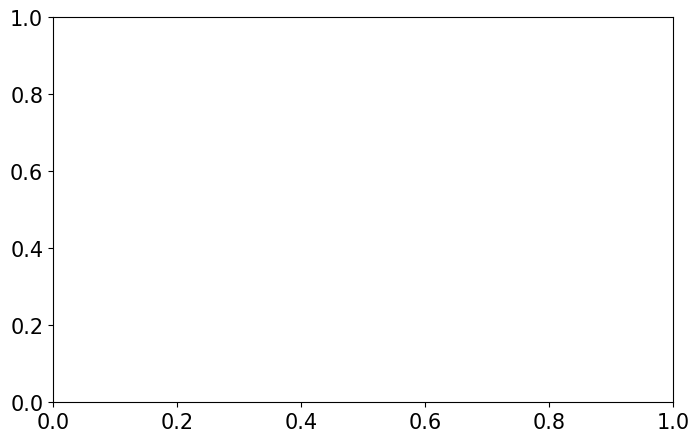

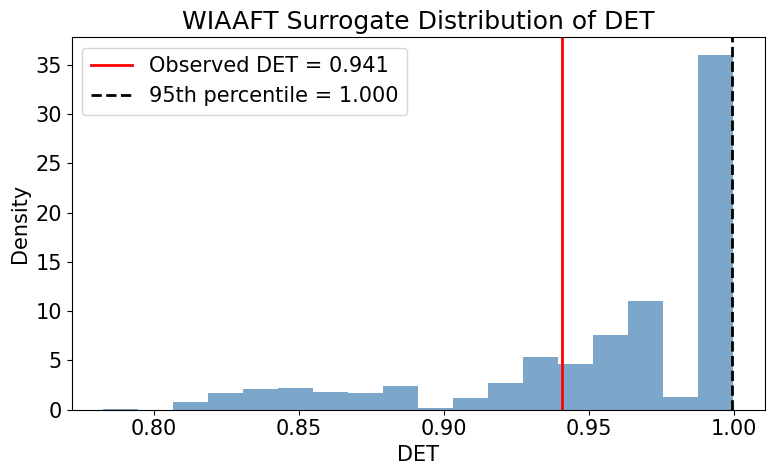

 46%|███████████████████▎                      | 46/100 [11:24<13:12, 14.68s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9409780775677025 
 Recurrence rate: 0.05001538935056941 
Threshold:1.0284999999999032 
 Laminarity:0.9819230769193004 
Shannon Entropy:1.7158039412626944 
Rank-order p-value (det):0.538 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.3748060110592022
Pseudo-periodic surrogates generated successfullly


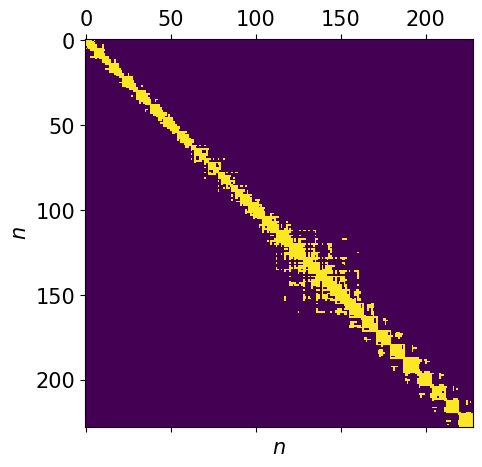

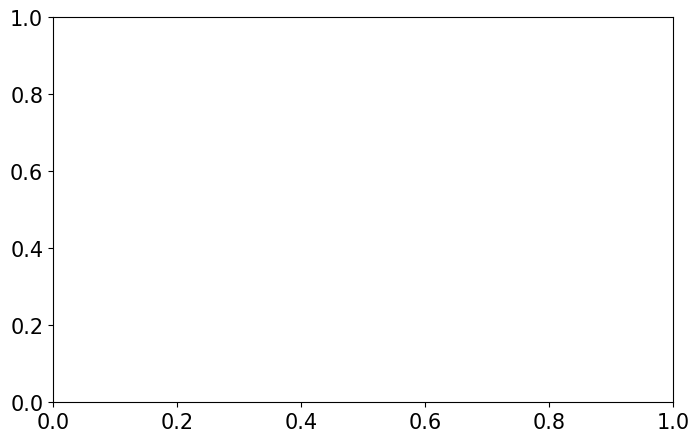

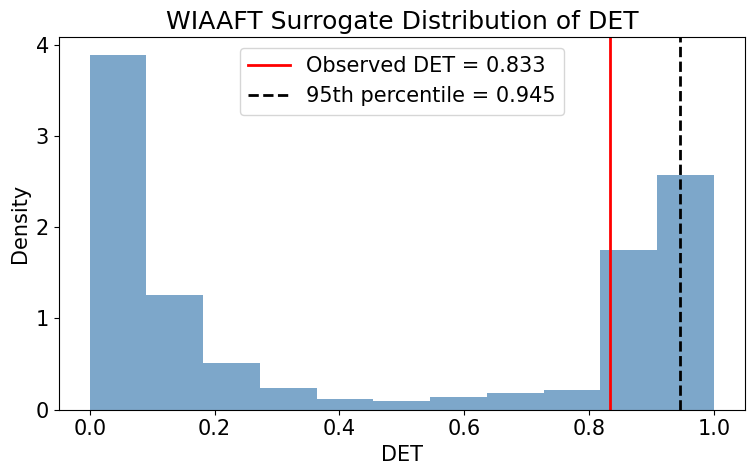

 47%|███████████████████▋                      | 47/100 [11:36<12:02, 13.63s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.833052276556353 
 Recurrence rate: 0.05001538935056941 
Threshold:0.810699999999927 
 Laminarity:0.9138461538426391 
Shannon Entropy:1.730210228302456 
Rank-order p-value (det):0.774 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.6725856798453914
Pseudo-periodic surrogates generated successfullly


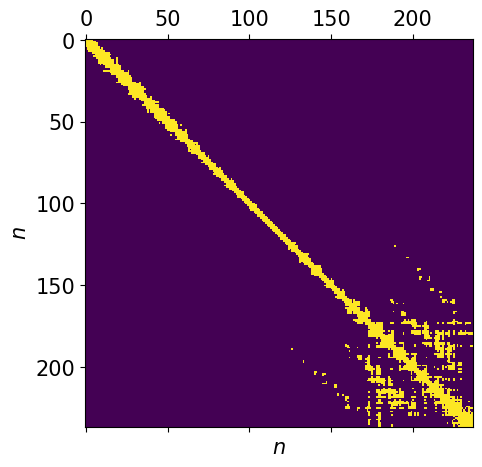

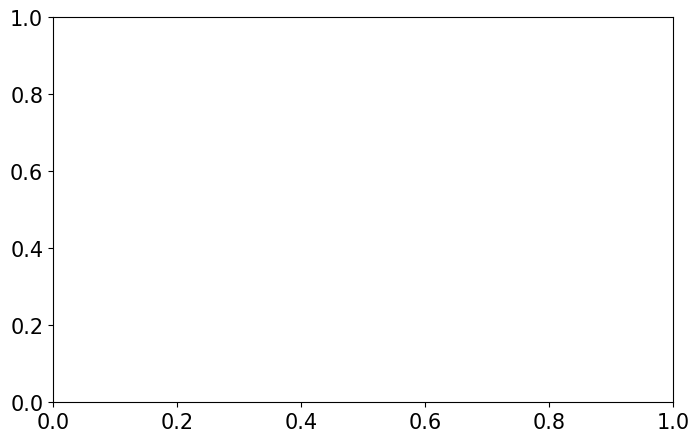

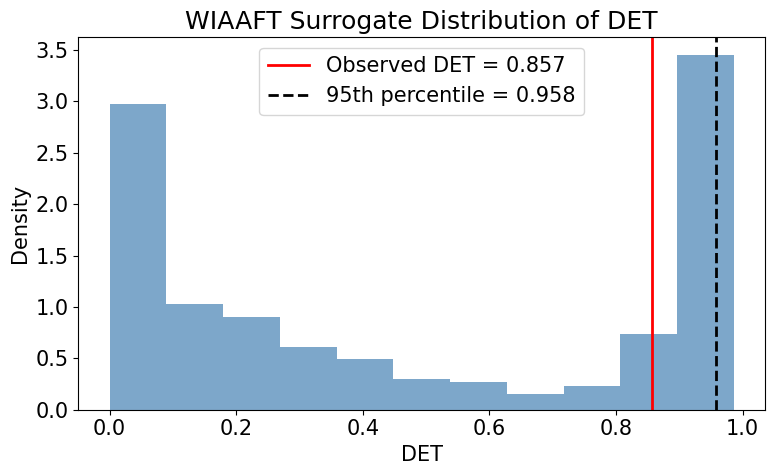

 48%|████████████████████▏                     | 48/100 [11:52<12:23, 14.29s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8569206842890478 
 Recurrence rate: 0.050009791878082216 
Threshold:1.4455999999998572 
 Laminarity:0.9231043075794835 
Shannon Entropy:1.505329722059259 
Rank-order p-value (det):0.694 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.47874027023822835
Pseudo-periodic surrogates generated successfullly


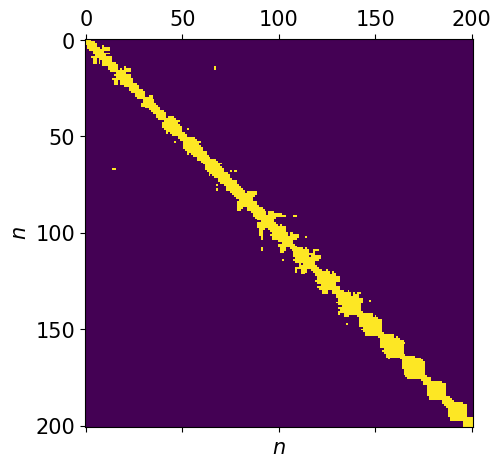

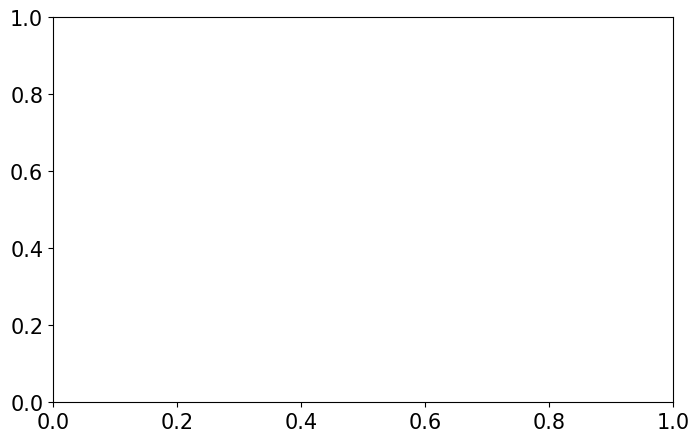

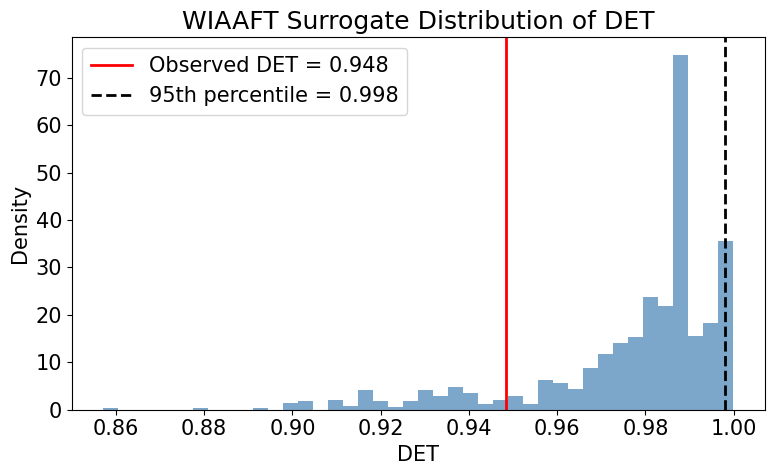

 49%|████████████████████▌                     | 49/100 [12:03<11:32, 13.58s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.948408342475585 
 Recurrence rate: 0.05007301799460409 
Threshold:1.1864999999998858 
 Laminarity:0.9812160158132417 
Shannon Entropy:2.1036449765127148 
Rank-order p-value (det):0.232 
Reject null (det) hypothesis:False

 
 

11
8
Mean Nearest Neighbor Distance: 0.4797286454308687
Pseudo-periodic surrogates generated successfullly


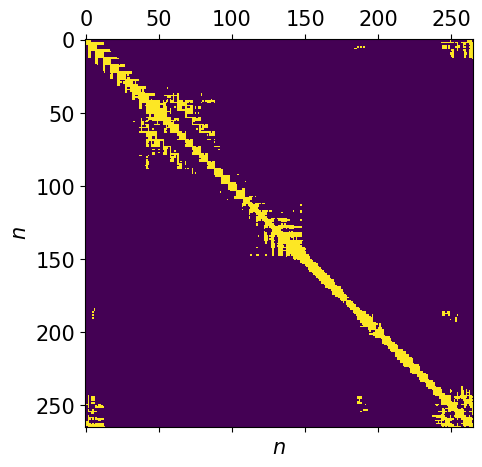

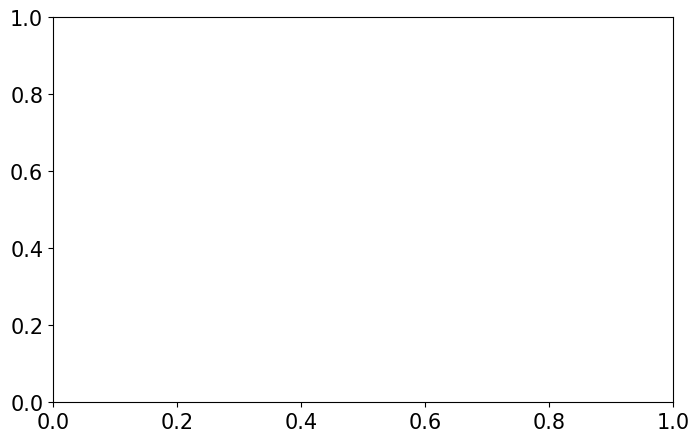

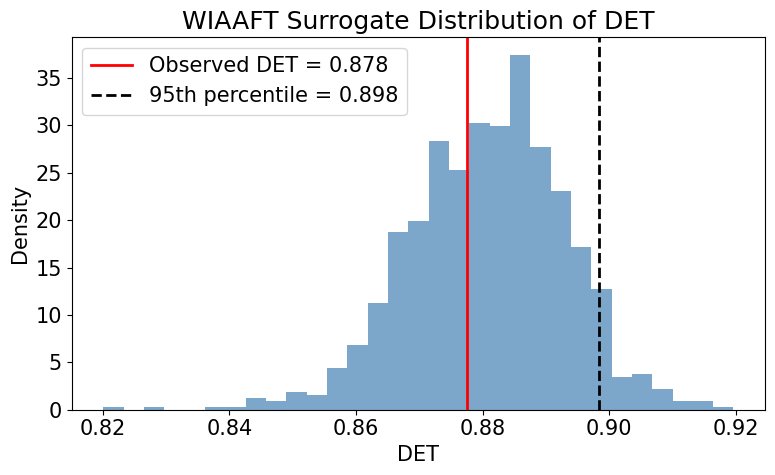

 50%|█████████████████████                     | 50/100 [12:20<12:00, 14.41s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.8775384615357614 
 Recurrence rate: 0.05005339978640085 
Threshold:1.2326999999998807 
 Laminarity:0.9302987197697573 
Shannon Entropy:1.4252725661557157 
Rank-order p-value (det):0.77 
Reject null (det) hypothesis:False

 
 

11
9
Mean Nearest Neighbor Distance: 0.426613752496101
Pseudo-periodic surrogates generated successfullly


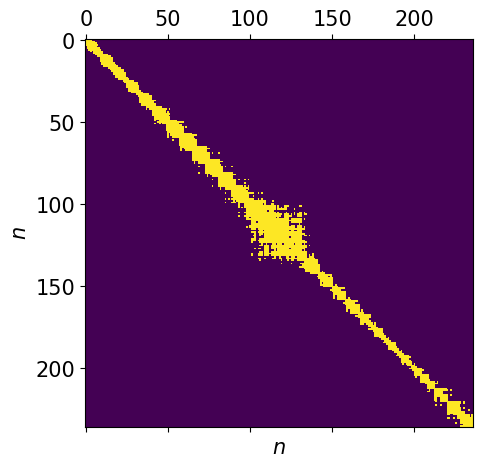

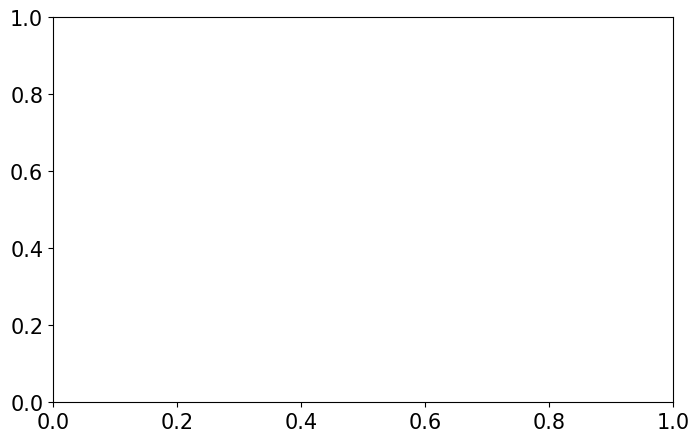

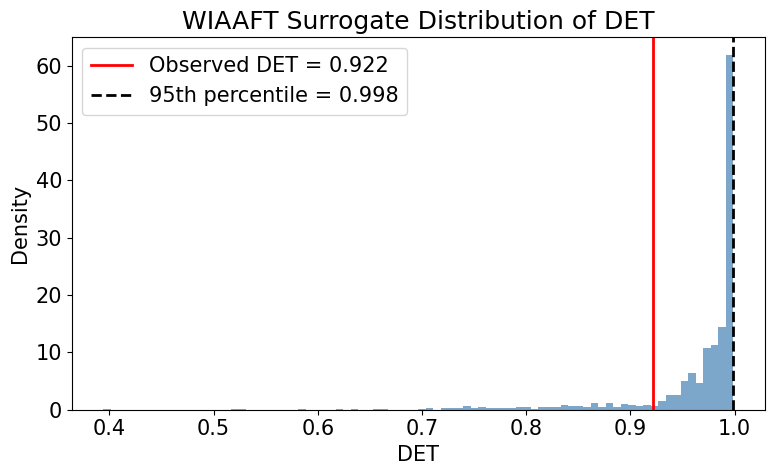

 51%|█████████████████████▍                    | 51/100 [12:32<11:20, 13.90s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9215686274473665 
 Recurrence rate: 0.05002154553289285 
Threshold:1.012299999999905 
 Laminarity:0.9547738693433067 
Shannon Entropy:1.916020917091782 
Rank-order p-value (det):0.248 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.38280956953886575
Pseudo-periodic surrogates generated successfullly


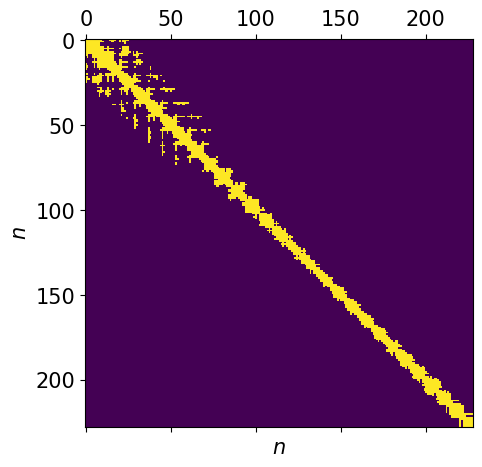

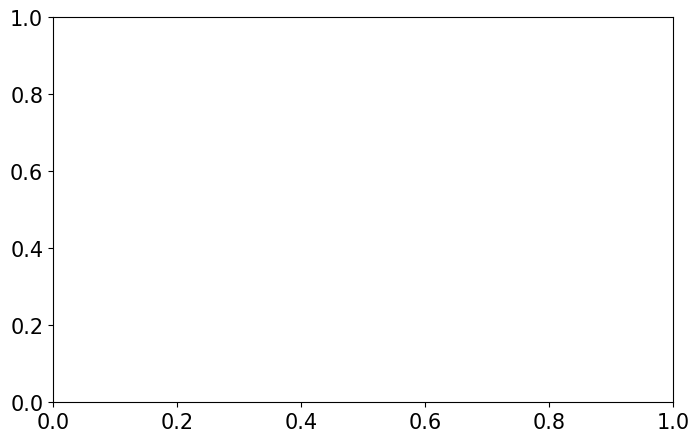

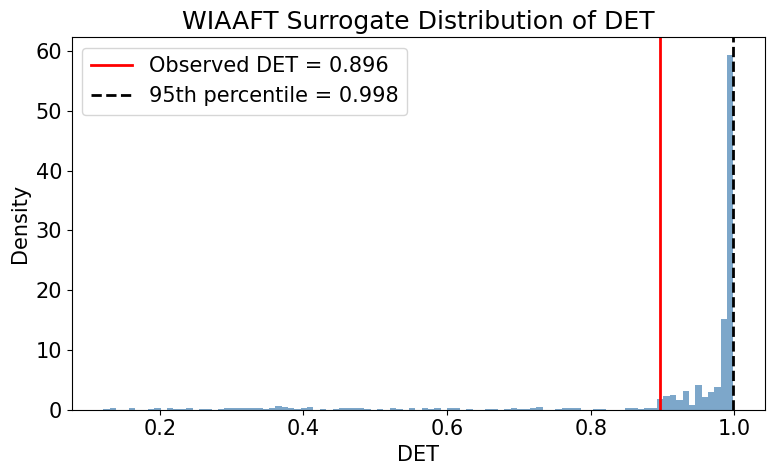

 52%|█████████████████████▊                    | 52/100 [12:45<10:48, 13.51s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8963774220686758 
 Recurrence rate: 0.05005386272699292 
Threshold:0.9883999999999075 
 Laminarity:0.9385088393507359 
Shannon Entropy:1.7744109956533416 
Rank-order p-value (det):0.248 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.5639919190541787
Pseudo-periodic surrogates generated successfullly


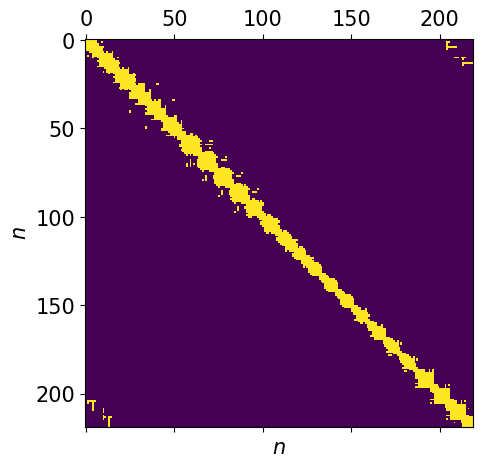

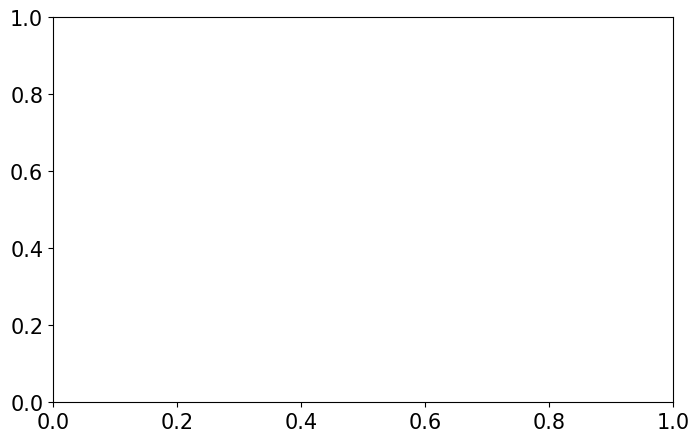

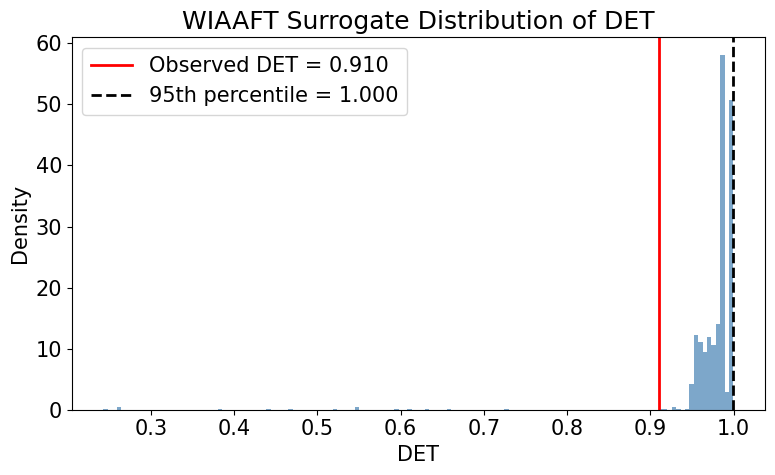

 53%|██████████████████████▎                   | 53/100 [13:00<10:57, 13.98s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9101741521498159 
 Recurrence rate: 0.05006150830883426 
Threshold:1.5398999999998468 
 Laminarity:0.9583506872096695 
Shannon Entropy:2.0392286670839814 
Rank-order p-value (det):0.03 
Reject null (det) hypothesis:True

 
 

12
8
Mean Nearest Neighbor Distance: 0.48570390057548685
Pseudo-periodic surrogates generated successfullly


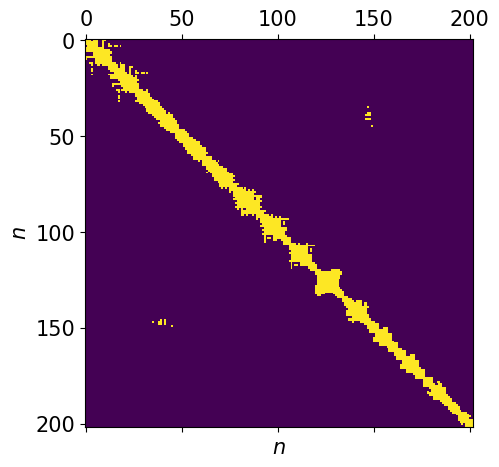

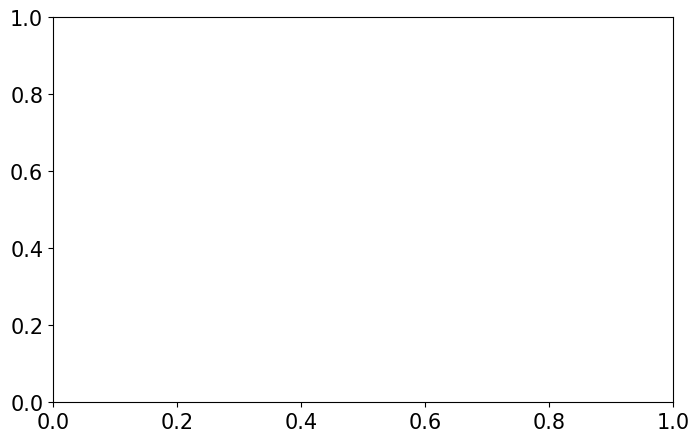

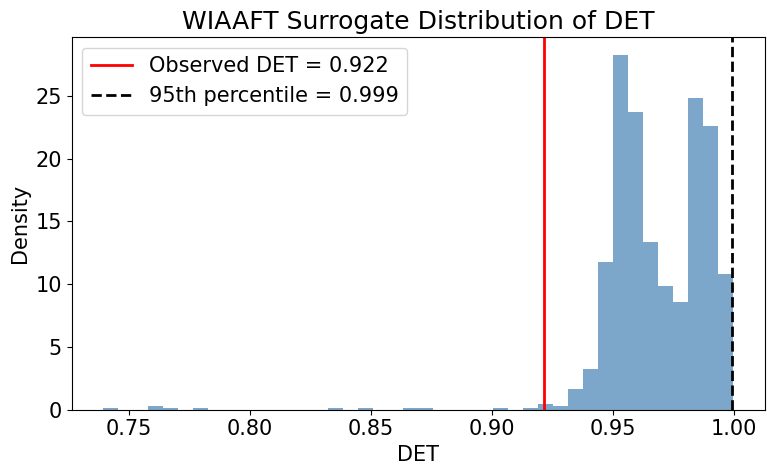

 54%|██████████████████████▋                   | 54/100 [13:12<10:18, 13.44s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9217391304297732 
 Recurrence rate: 0.05004411332222331 
Threshold:1.2057999999998836 
 Laminarity:0.9671890303576534 
Shannon Entropy:2.2510750015780947 
Rank-order p-value (det):0.024 
Reject null (det) hypothesis:True

 
 

13
10
Mean Nearest Neighbor Distance: 0.5482276159911611
Pseudo-periodic surrogates generated successfullly


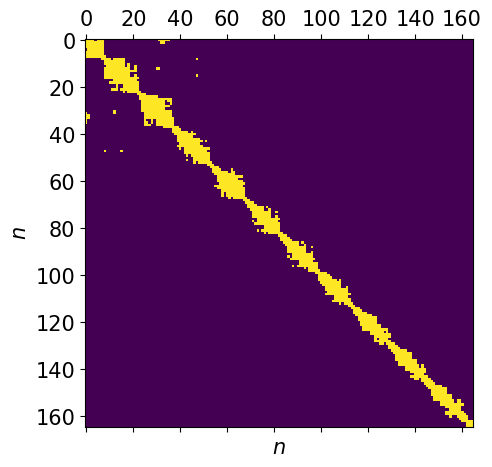

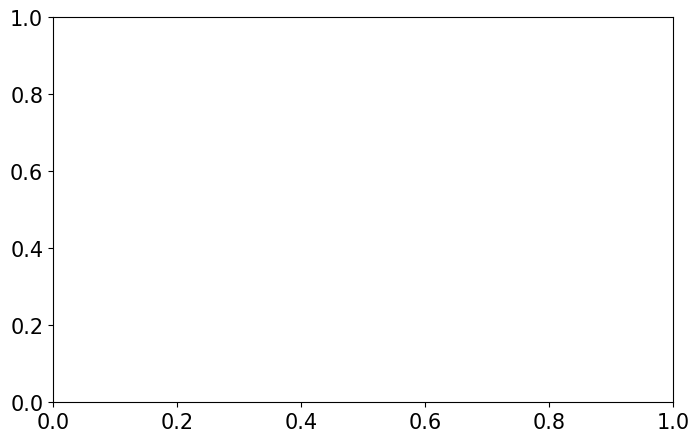

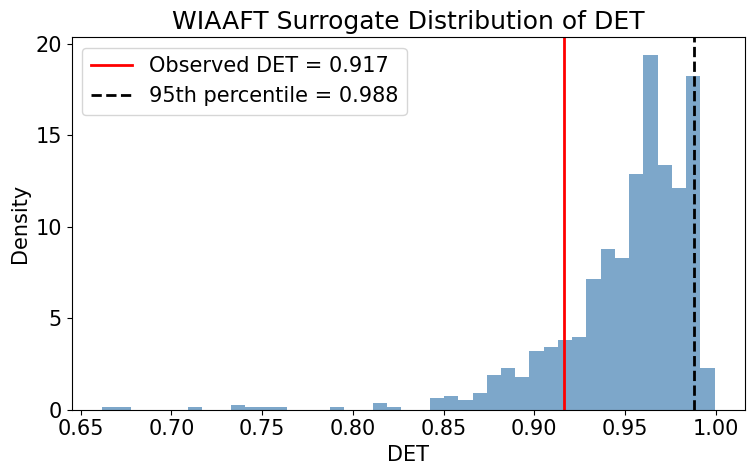

 55%|███████████████████████                   | 55/100 [13:23<09:24, 12.55s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9165275459021993 
 Recurrence rate: 0.05006427915518825 
Threshold:1.1686999999998877 
 Laminarity:0.961115187080256 
Shannon Entropy:2.125317138437203 
Rank-order p-value (det):0.3 
Reject null (det) hypothesis:False

 
 

13
7
Mean Nearest Neighbor Distance: 0.43759126473382237
Pseudo-periodic surrogates generated successfullly


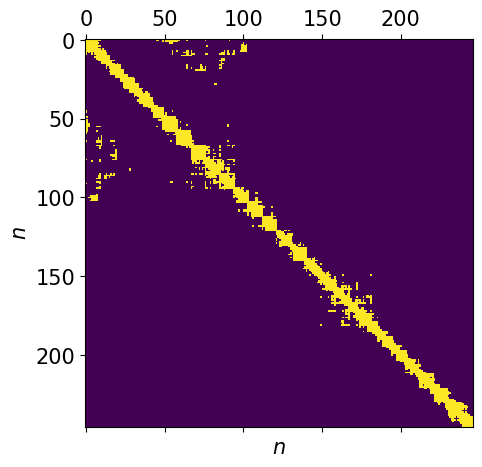

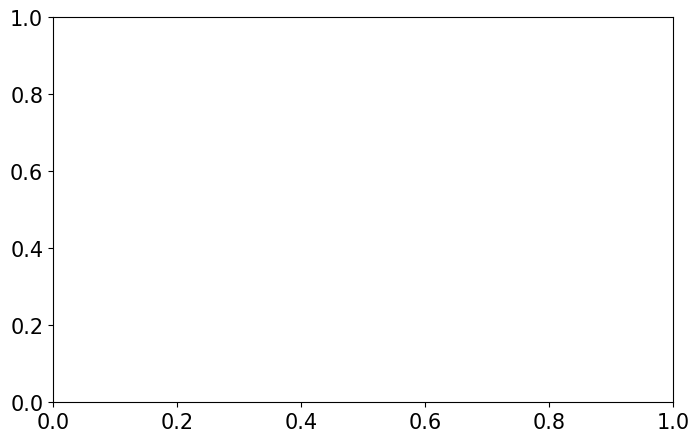

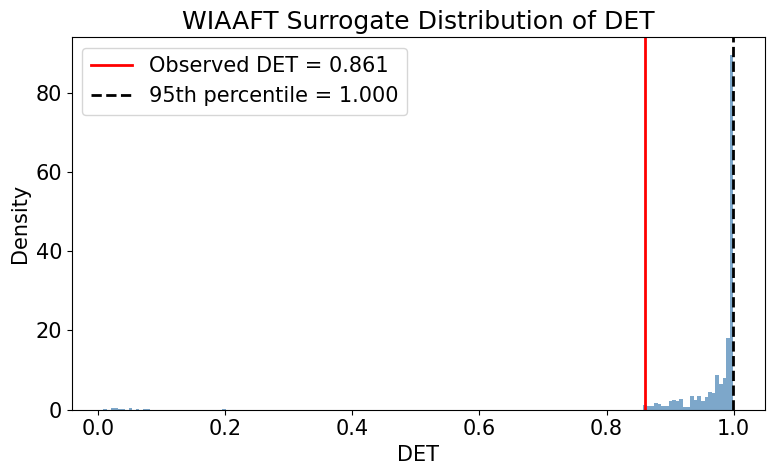

 56%|███████████████████████▌                  | 56/100 [13:38<09:42, 13.24s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.861151079133593 
 Recurrence rate: 0.05000330491109789 
Threshold:1.2401999999998798 
 Laminarity:0.9306014540616967 
Shannon Entropy:1.8262268173887595 
Rank-order p-value (det):0.032 
Reject null (det) hypothesis:True

 
 

14
8
Mean Nearest Neighbor Distance: 0.3603169222497031
Pseudo-periodic surrogates generated successfullly


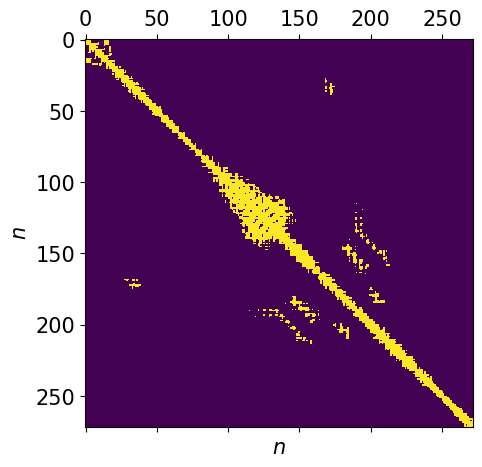

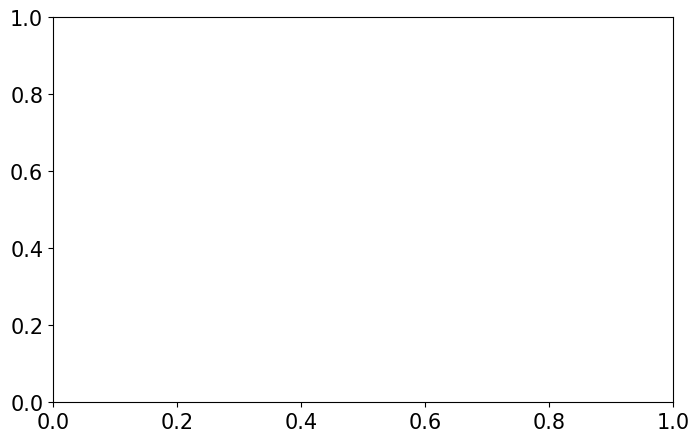

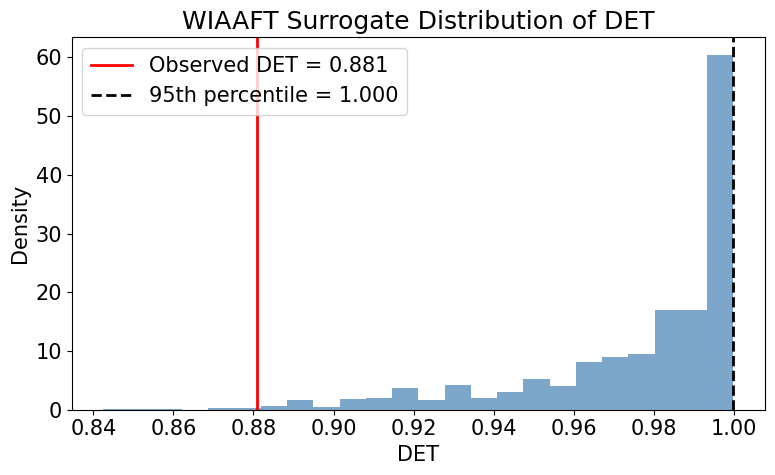

 57%|███████████████████████▉                  | 57/100 [13:50<09:21, 13.05s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.8809801633579901 
 Recurrence rate: 0.05001081314878893 
Threshold:0.8387999999999239 
 Laminarity:0.9408108108082681 
Shannon Entropy:1.5685865668472077 
Rank-order p-value (det):0.014 
Reject null (det) hypothesis:True

 
 

15
10
Mean Nearest Neighbor Distance: 0.6406124341436578
Pseudo-periodic surrogates generated successfullly


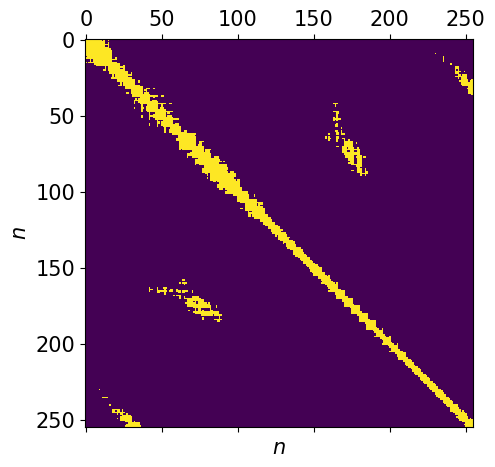

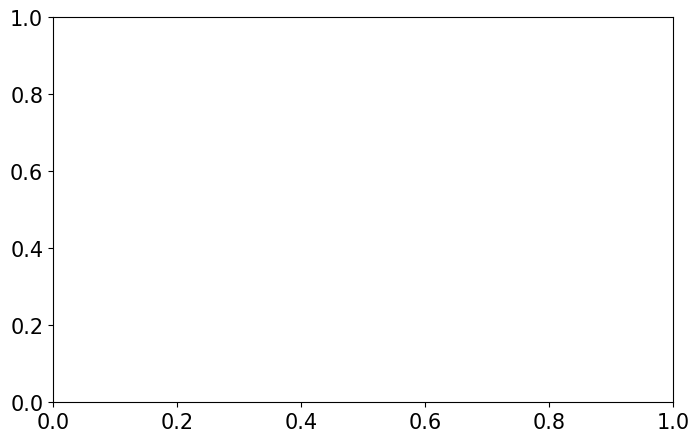

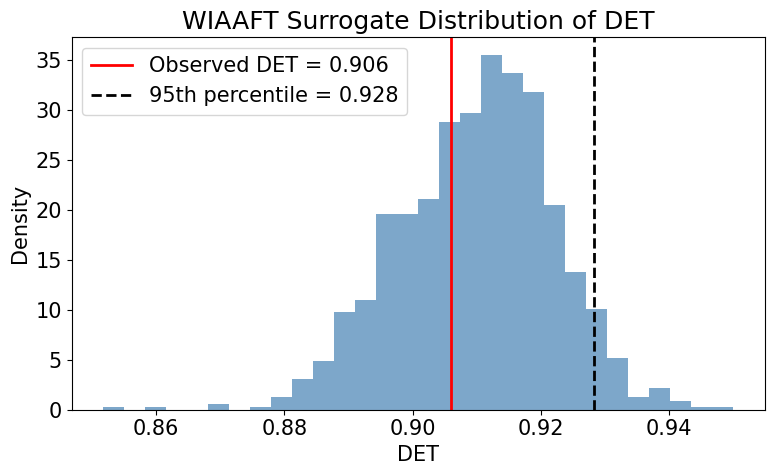

 58%|████████████████████████▎                 | 58/100 [14:10<10:27, 14.94s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9059372915246634 
 Recurrence rate: 0.050026912725874666 
Threshold:1.7415999999998246 
 Laminarity:0.9563479864710841 
Shannon Entropy:1.780750236416416 
Rank-order p-value (det):0.688 
Reject null (det) hypothesis:False

 
 

15
7
Mean Nearest Neighbor Distance: 0.44624122164668606
Pseudo-periodic surrogates generated successfullly


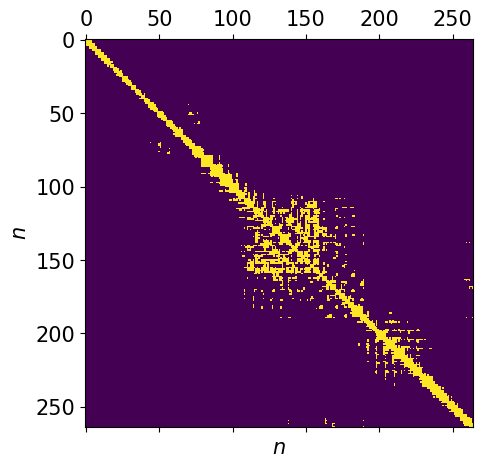

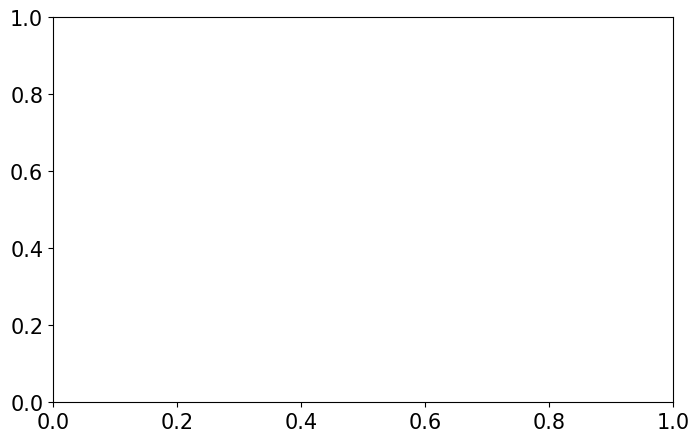

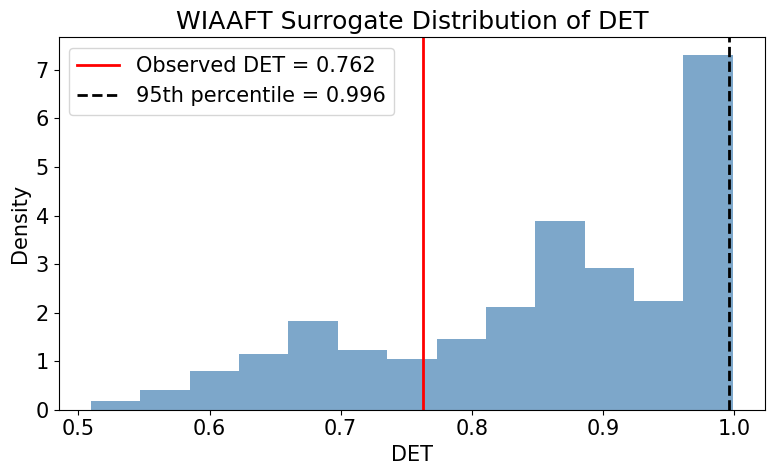

 59%|████████████████████████▊                 | 59/100 [14:23<09:58, 14.59s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.7624069478884541 
 Recurrence rate: 0.050045913682277315 
Threshold:0.956399999999911 
 Laminarity:0.8715596330250243 
Shannon Entropy:1.4224558087855506 
Rank-order p-value (det):0.478 
Reject null (det) hypothesis:False

 
 

15
10
Mean Nearest Neighbor Distance: 0.7531952737629211
Pseudo-periodic surrogates generated successfullly


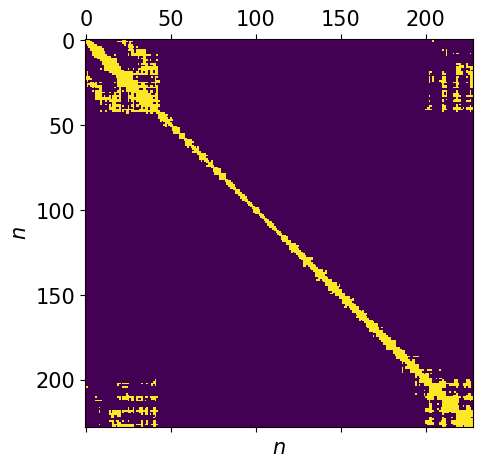

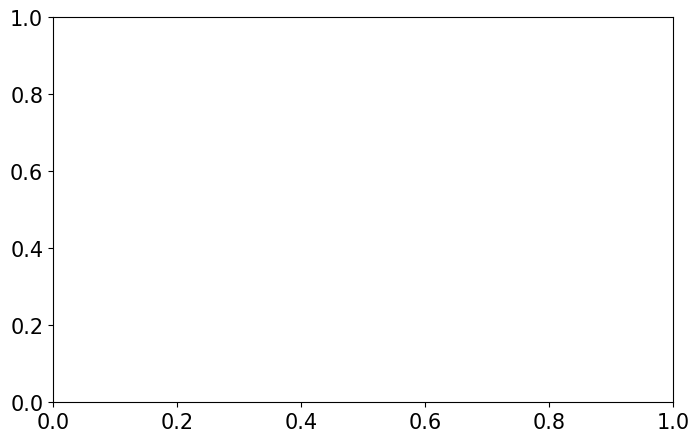

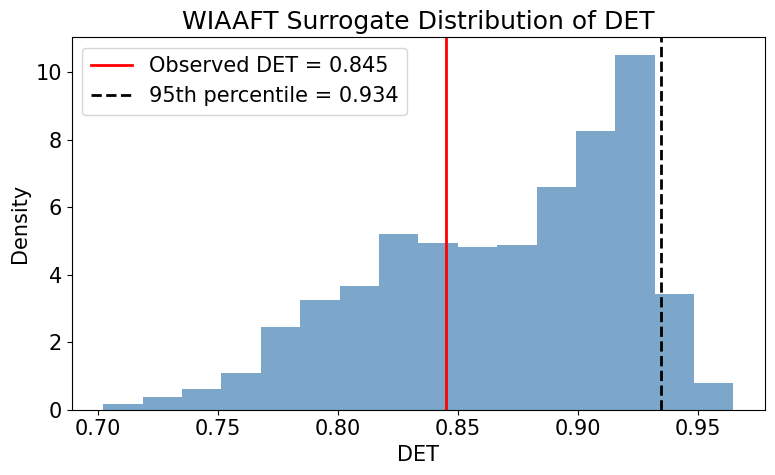

 60%|█████████████████████████▏                | 60/100 [14:40<10:06, 15.16s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8448566610419694 
 Recurrence rate: 0.05001538935056941 
Threshold:1.4873999999998526 
 Laminarity:0.9215384615349173 
Shannon Entropy:1.4341350283793473 
Rank-order p-value (det):0.658 
Reject null (det) hypothesis:False

 
 

15
10
Mean Nearest Neighbor Distance: 0.5551166121956812
Pseudo-periodic surrogates generated successfullly


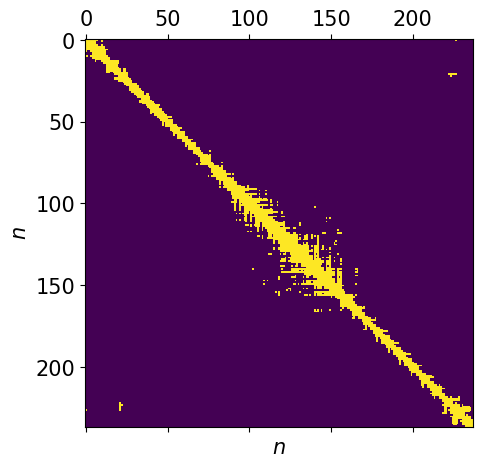

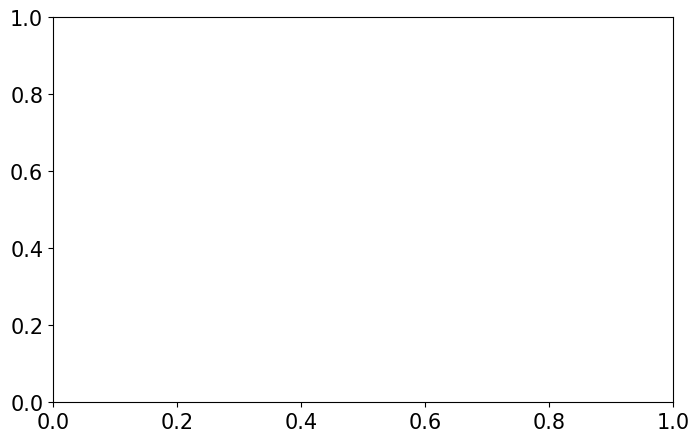

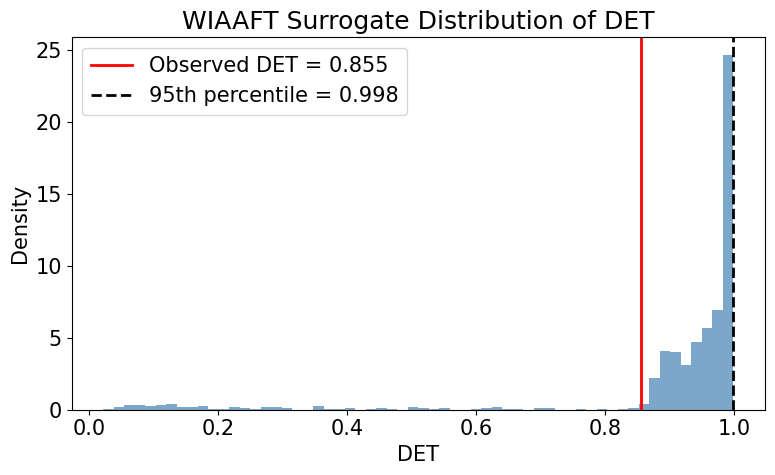

 61%|█████████████████████████▌                | 61/100 [14:55<09:55, 15.27s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8553654743357101 
 Recurrence rate: 0.050009791878082216 
Threshold:1.3145999999998716 
 Laminarity:0.9291562833715588 
Shannon Entropy:1.6869300319680554 
Rank-order p-value (det):0.186 
Reject null (det) hypothesis:False

 
 

15
10
Mean Nearest Neighbor Distance: 0.5545518105681407
Pseudo-periodic surrogates generated successfullly


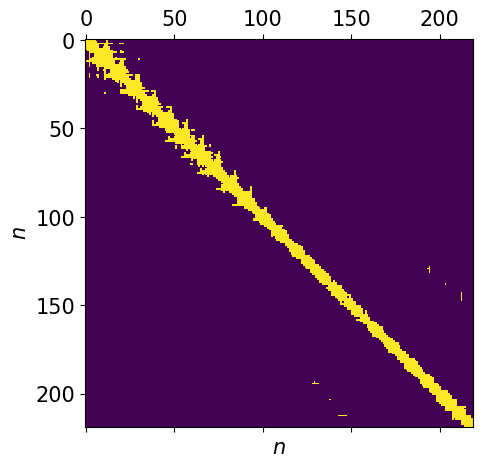

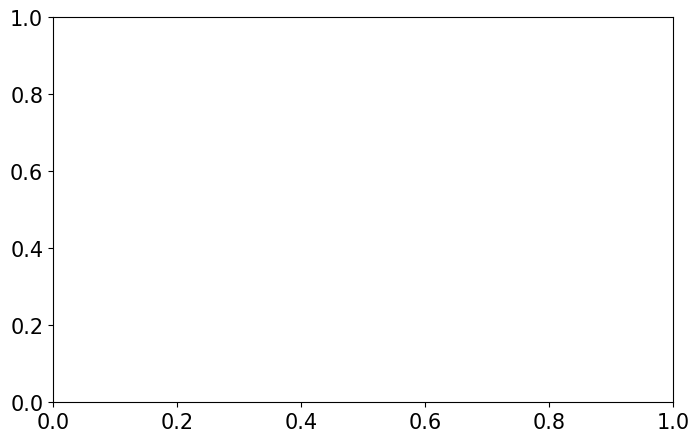

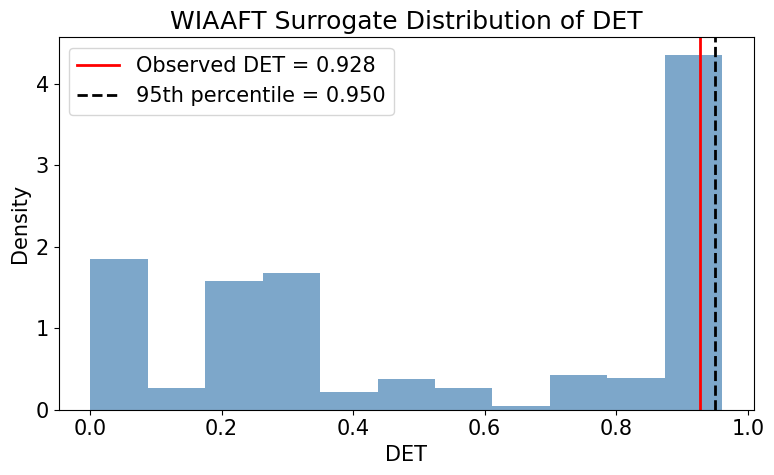

 62%|██████████████████████████                | 62/100 [15:10<09:26, 14.92s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9275893675484529 
 Recurrence rate: 0.05006150830883426 
Threshold:1.293699999999874 
 Laminarity:0.966264056639041 
Shannon Entropy:1.9596080038644288 
Rank-order p-value (det):0.478 
Reject null (det) hypothesis:False

 
 

15
10
Mean Nearest Neighbor Distance: 0.8275267047562326
Pseudo-periodic surrogates generated successfullly


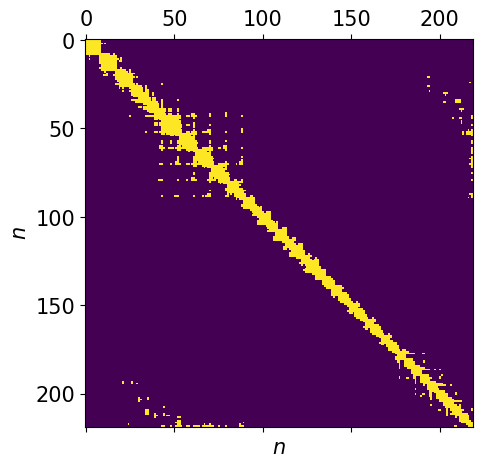

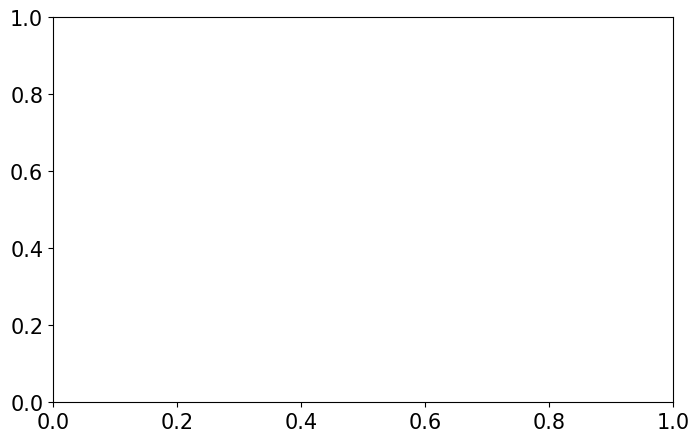

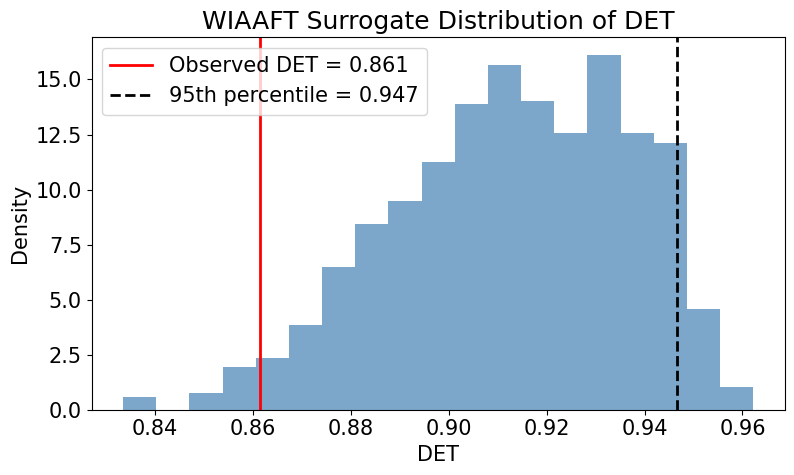

 63%|██████████████████████████▍               | 63/100 [15:29<09:58, 16.16s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8614678899043052 
 Recurrence rate: 0.05001980776047205 
Threshold:2.0195999999998375 
 Laminarity:0.923718215919451 
Shannon Entropy:1.6347633950059475 
Rank-order p-value (det):0.048 
Reject null (det) hypothesis:True

 
 

16
9
Mean Nearest Neighbor Distance: 0.4367600384095466
Pseudo-periodic surrogates generated successfullly


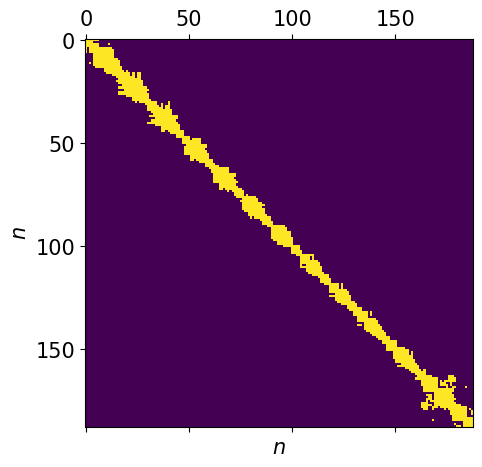

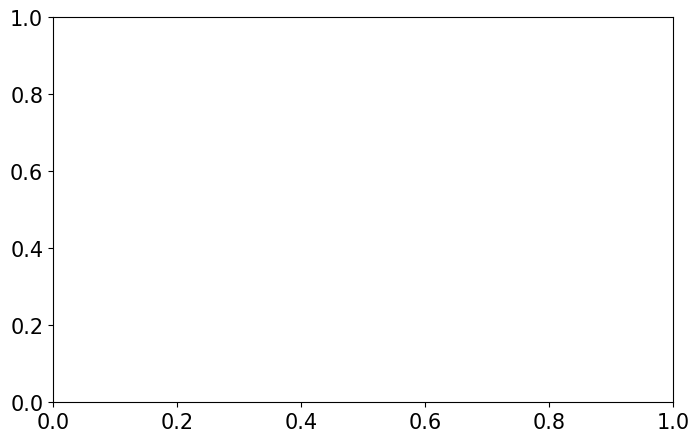

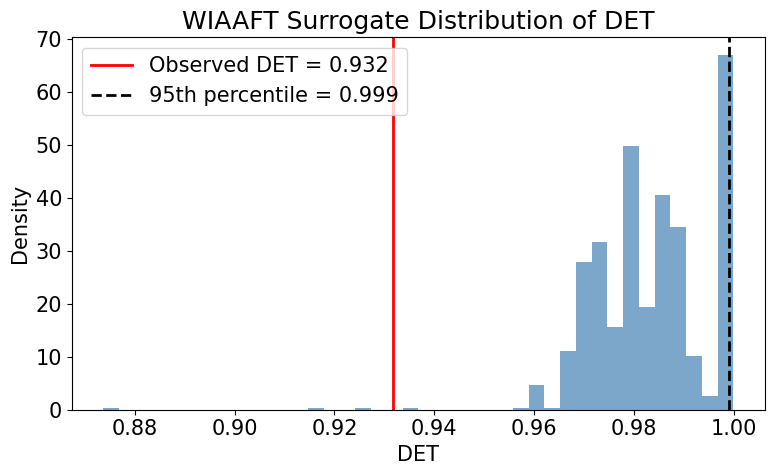

 64%|██████████████████████████▉               | 64/100 [15:39<08:41, 14.50s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9316455696143567 
 Recurrence rate: 0.05002263467632413 
Threshold:1.0435999999999015 
 Laminarity:0.9773755656053317 
Shannon Entropy:2.1113998920361006 
Rank-order p-value (det):0.008 
Reject null (det) hypothesis:True

 
 

17
10
Mean Nearest Neighbor Distance: 0.6073071594530006
Pseudo-periodic surrogates generated successfullly


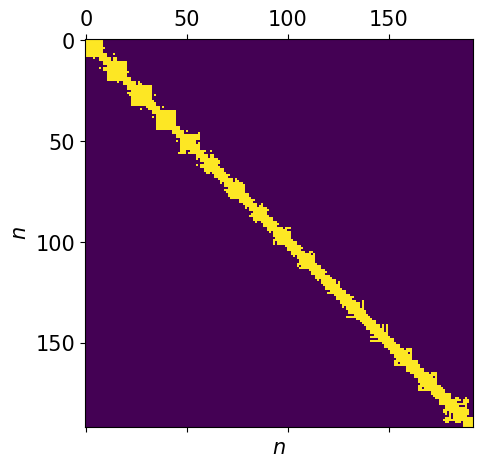

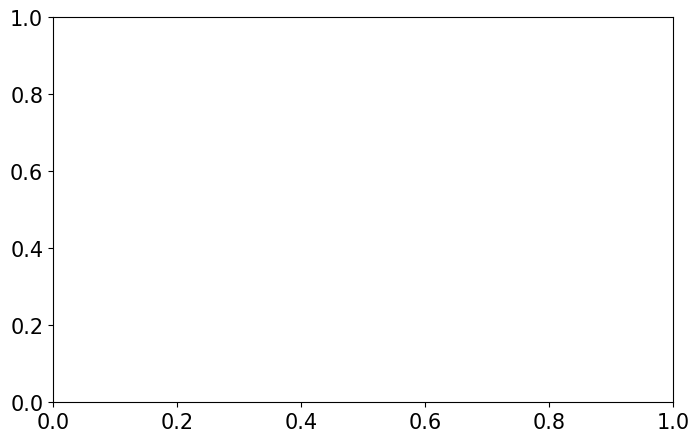

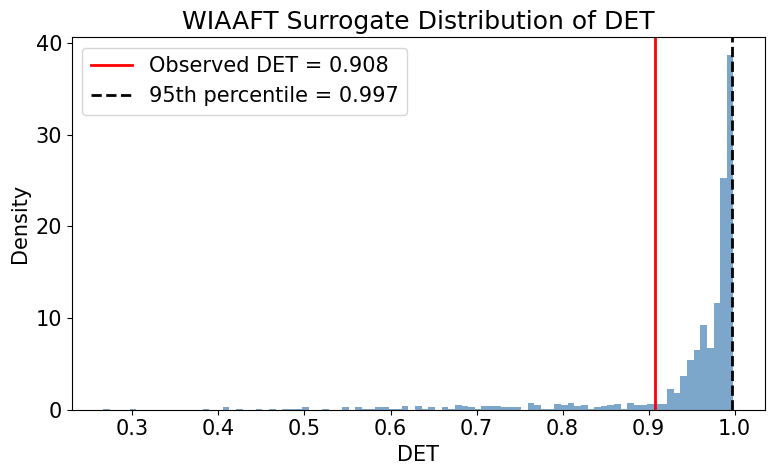

 65%|███████████████████████████▎              | 65/100 [15:52<08:11, 14.04s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9079903147644796 
 Recurrence rate: 0.05002170138888889 
Threshold:1.4603999999998556 
 Laminarity:0.9745119305803985 
Shannon Entropy:1.941913783692462 
Rank-order p-value (det):0.266 
Reject null (det) hypothesis:False

 
 

17
10
Mean Nearest Neighbor Distance: 0.5024527566167265
Pseudo-periodic surrogates generated successfullly


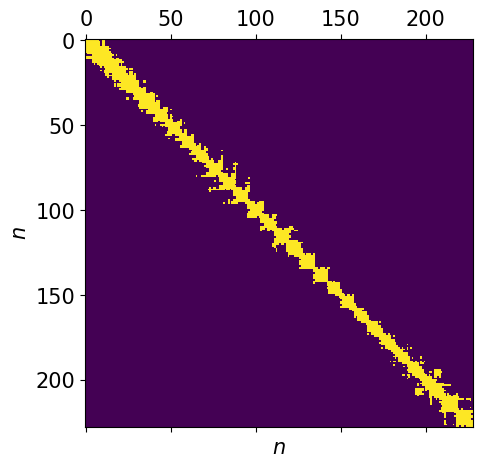

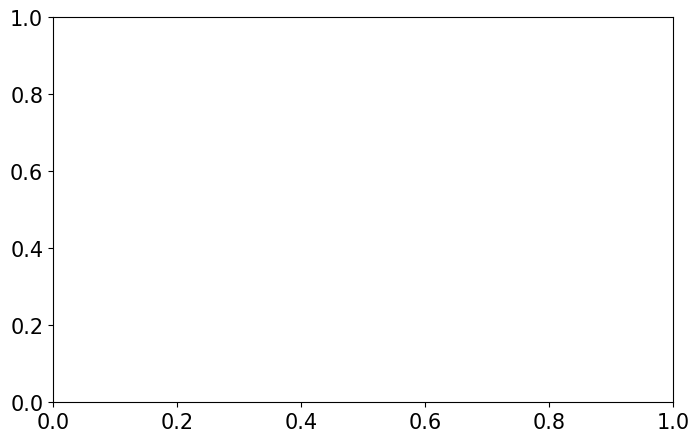

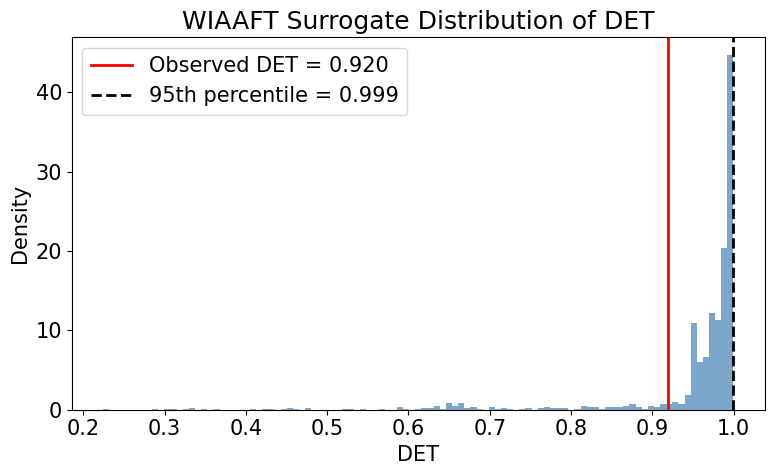

 66%|███████████████████████████▋              | 66/100 [16:06<07:54, 13.95s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9198988195576733 
 Recurrence rate: 0.05001538935056941 
Threshold:1.265699999999877 
 Laminarity:0.963076923073219 
Shannon Entropy:1.8064941618019308 
Rank-order p-value (det):0.26 
Reject null (det) hypothesis:False

 
 

17
10
Mean Nearest Neighbor Distance: 0.6049445439612819
Pseudo-periodic surrogates generated successfullly


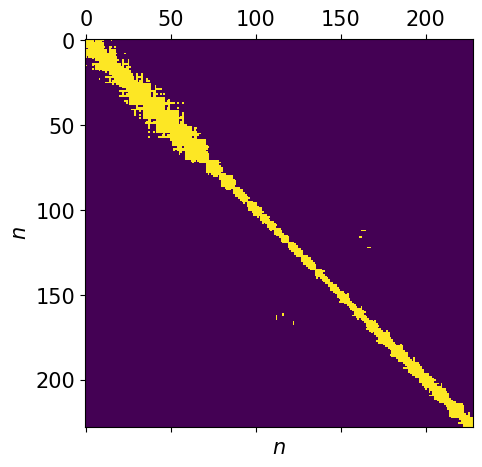

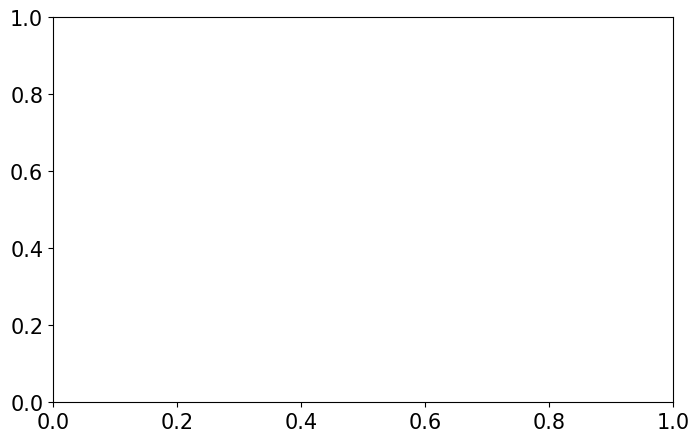

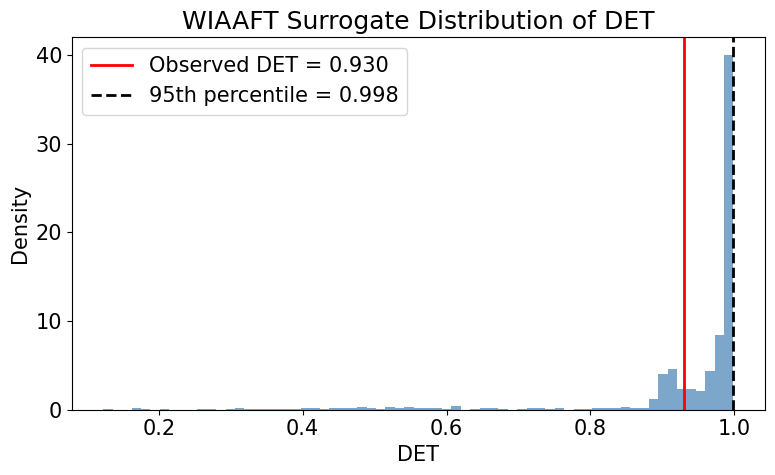

 67%|████████████████████████████▏             | 67/100 [16:21<07:54, 14.38s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9300168634024873 
 Recurrence rate: 0.05001538935056941 
Threshold:1.5124999999998499 
 Laminarity:0.9657692307655164 
Shannon Entropy:2.0139316239725114 
Rank-order p-value (det):0.502 
Reject null (det) hypothesis:False

 
 

17
9
Mean Nearest Neighbor Distance: 0.570243943175728
Pseudo-periodic surrogates generated successfullly


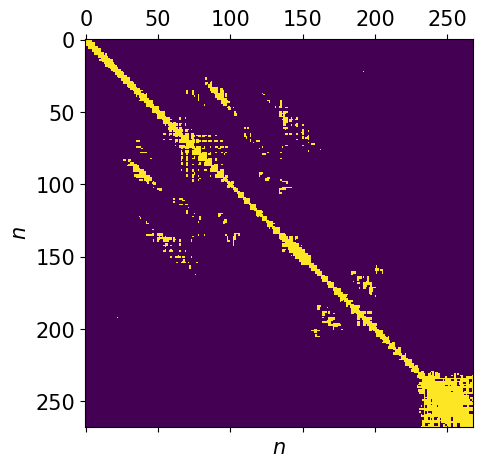

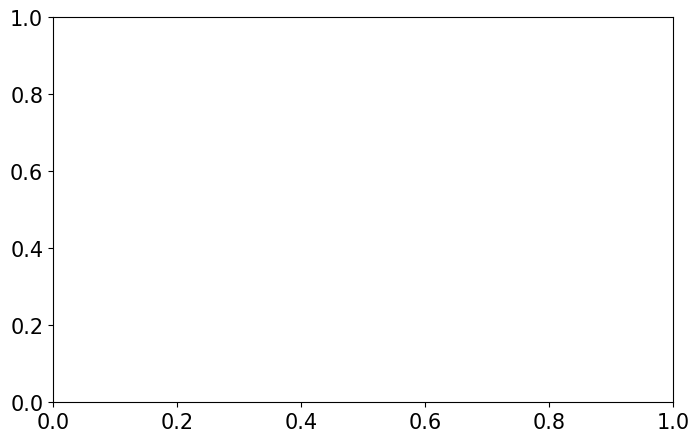

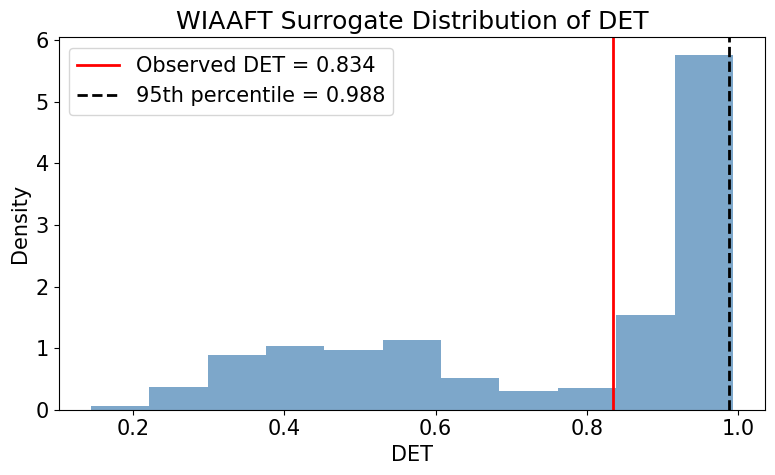

 68%|████████████████████████████▌             | 68/100 [16:38<08:05, 15.17s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8340348767262957 
 Recurrence rate: 0.050038984183559815 
Threshold:1.3239999999998706 
 Laminarity:0.9243183082890253 
Shannon Entropy:1.3915859084387923 
Rank-order p-value (det):0.868 
Reject null (det) hypothesis:False

 
 

17
10
Mean Nearest Neighbor Distance: 0.5432257694339365
Pseudo-periodic surrogates generated successfullly


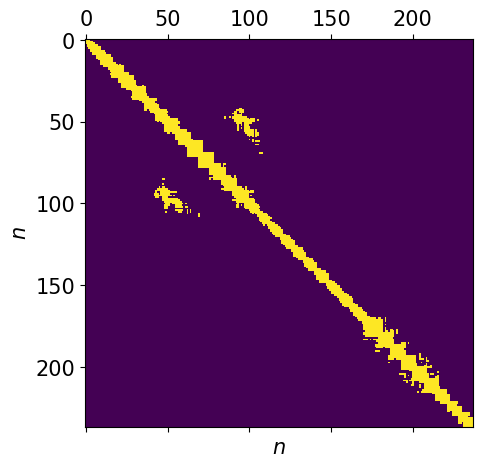

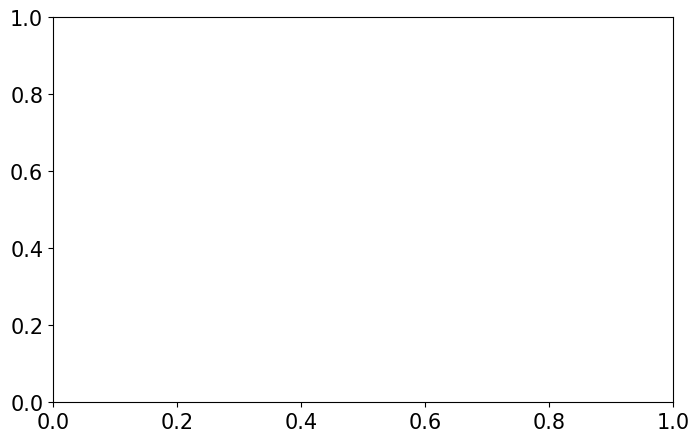

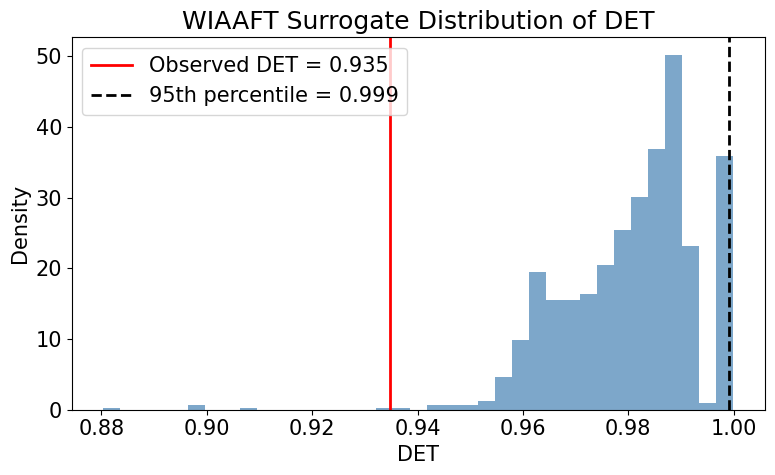

 69%|████████████████████████████▉             | 69/100 [16:54<07:52, 15.24s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9347319347283033 
 Recurrence rate: 0.05004539870747209 
Threshold:1.429199999999859 
 Laminarity:0.9722518676592947 
Shannon Entropy:1.8835370294822895 
Rank-order p-value (det):0.01 
Reject null (det) hypothesis:True

 
 

18
8
Mean Nearest Neighbor Distance: 0.4011998707642247
Pseudo-periodic surrogates generated successfullly


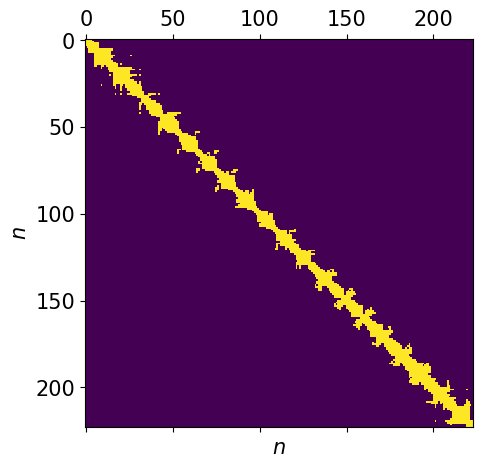

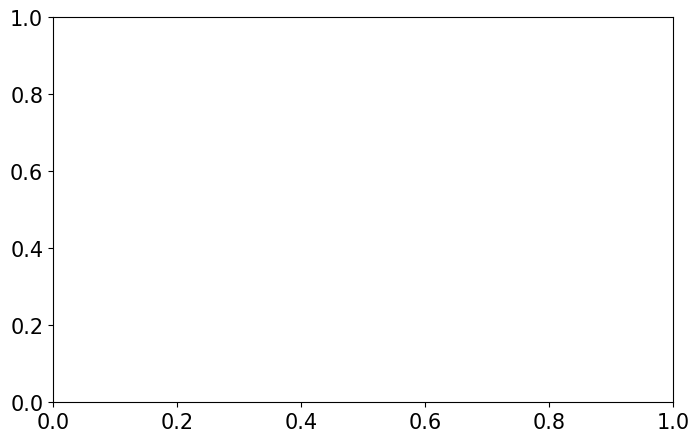

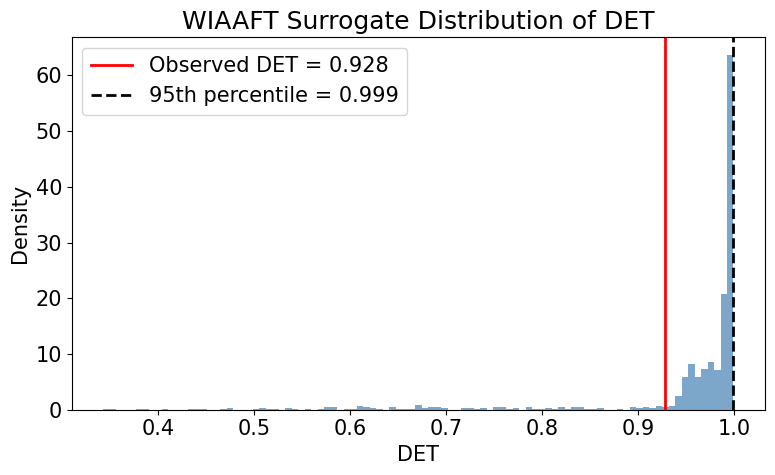

 70%|█████████████████████████████▍            | 70/100 [17:05<07:06, 14.20s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9284452296778779 
 Recurrence rate: 0.05001105994490136 
Threshold:1.0288999999999031 
 Laminarity:0.9718536389184887 
Shannon Entropy:1.9891642861829617 
Rank-order p-value (det):0.232 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.4943373079665591
Pseudo-periodic surrogates generated successfullly


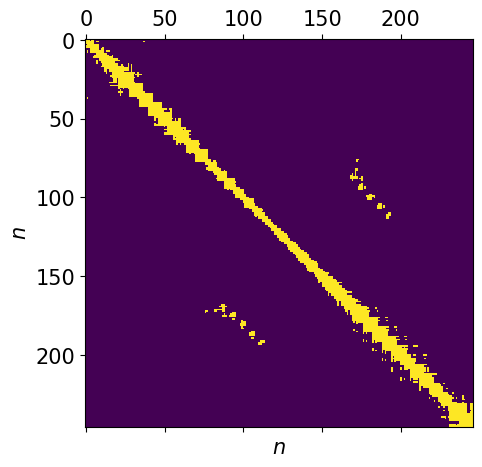

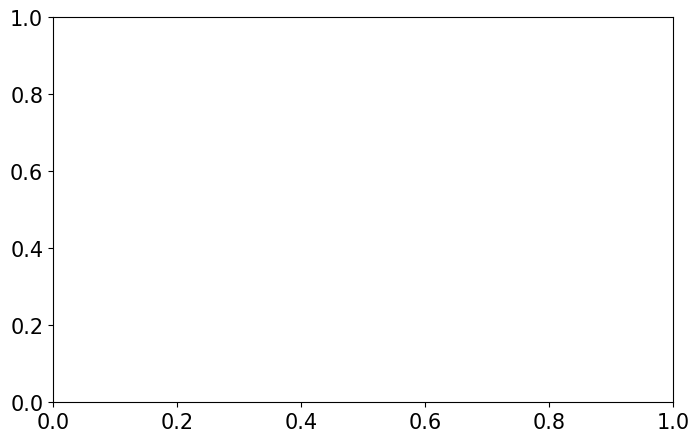

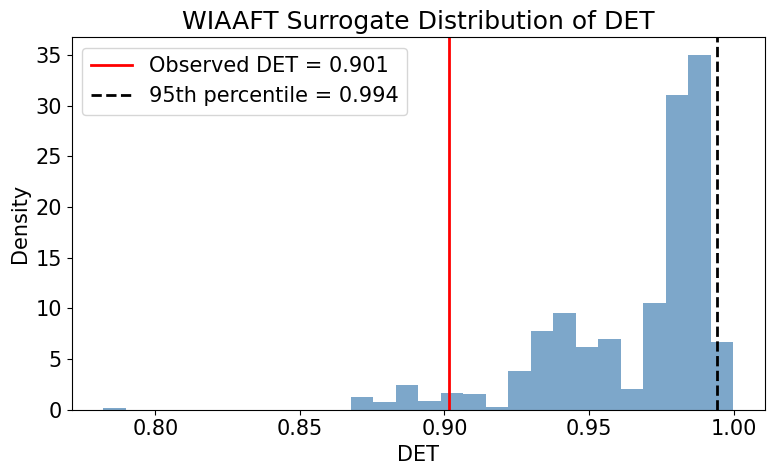

 71%|█████████████████████████████▊            | 71/100 [17:20<06:56, 14.38s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9014388489176207 
 Recurrence rate: 0.05000330491109789 
Threshold:1.2670999999998769 
 Laminarity:0.9567085261039104 
Shannon Entropy:1.6703203678815568 
Rank-order p-value (det):0.098 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.6139789665545304
Pseudo-periodic surrogates generated successfullly


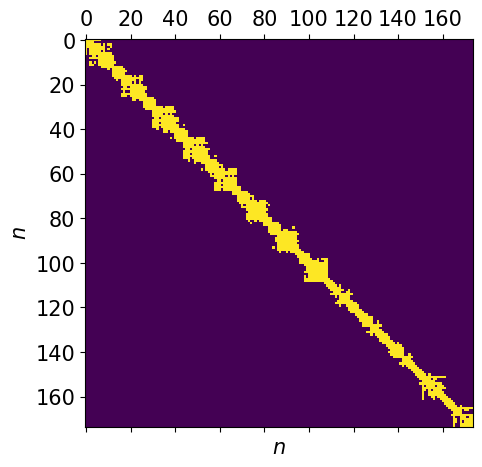

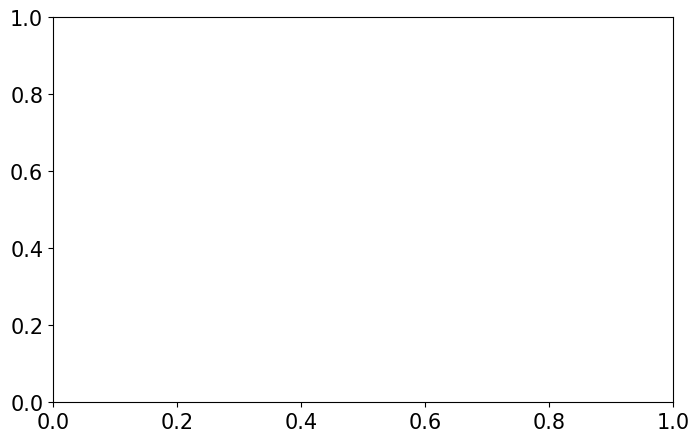

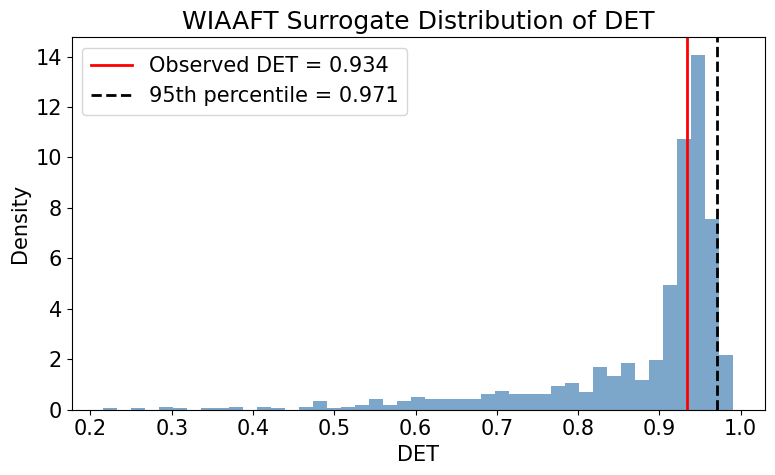

 72%|██████████████████████████████▏           | 72/100 [17:31<06:11, 13.26s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9343283582019827 
 Recurrence rate: 0.05000660589245607 
Threshold:1.2558999999998781 
 Laminarity:0.9570673711957922 
Shannon Entropy:1.7981406701949245 
Rank-order p-value (det):0.948 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.8122967886211185
Pseudo-periodic surrogates generated successfullly


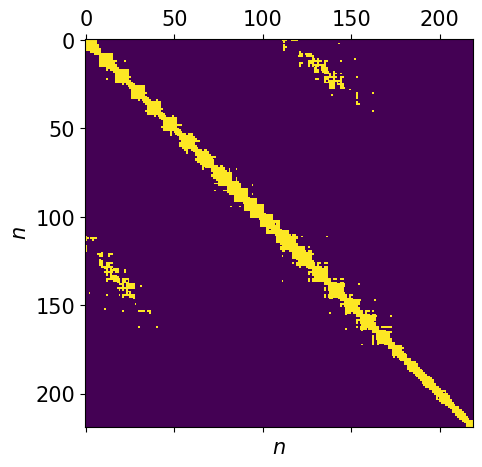

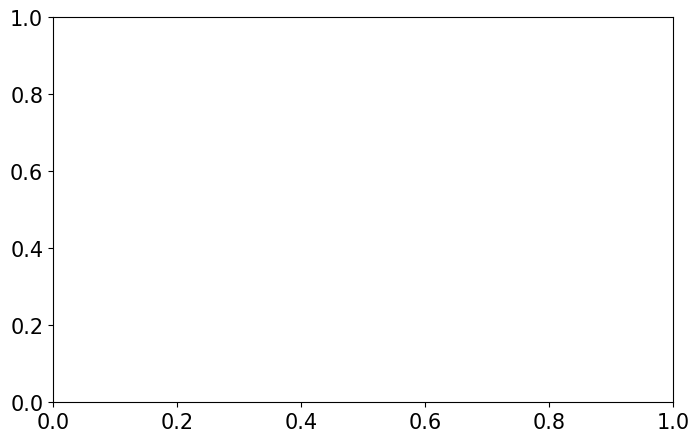

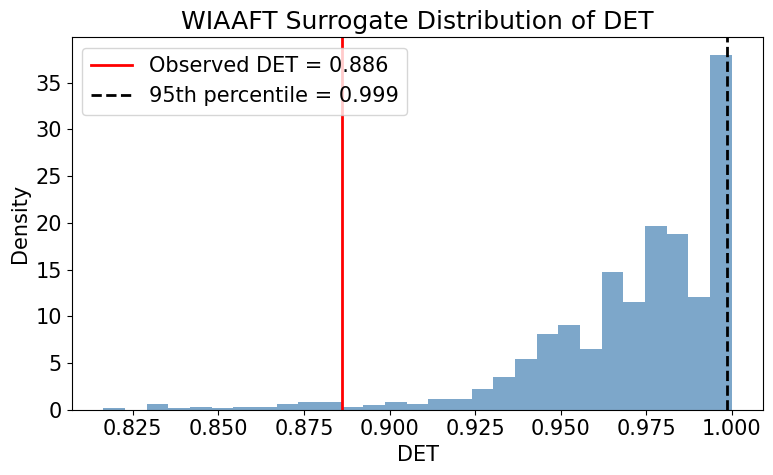

 73%|██████████████████████████████▋           | 73/100 [17:48<06:25, 14.28s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8862385321060264 
 Recurrence rate: 0.05001980776047205 
Threshold:1.847199999999813 
 Laminarity:0.9424760316759381 
Shannon Entropy:1.889065578574667 
Rank-order p-value (det):0.056 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.48740927606344003
Pseudo-periodic surrogates generated successfullly


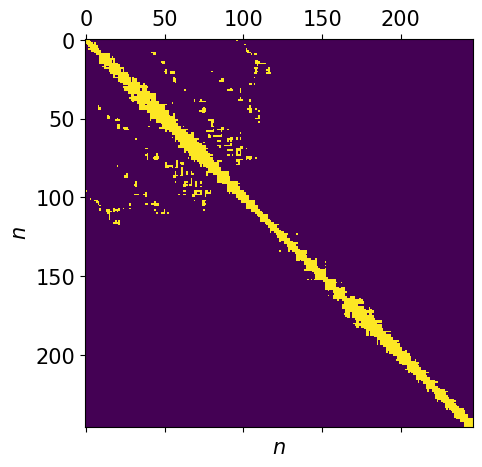

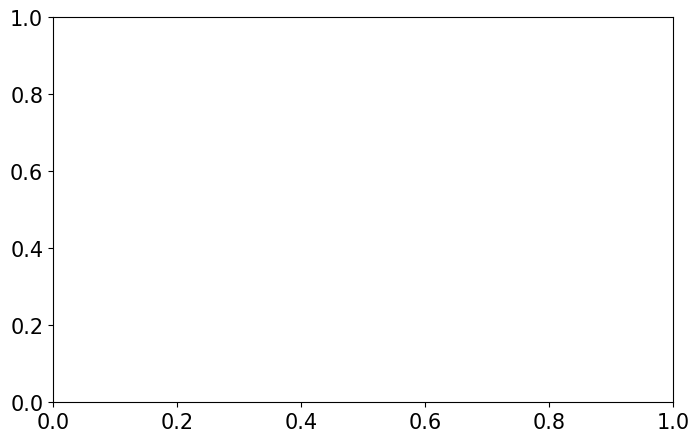

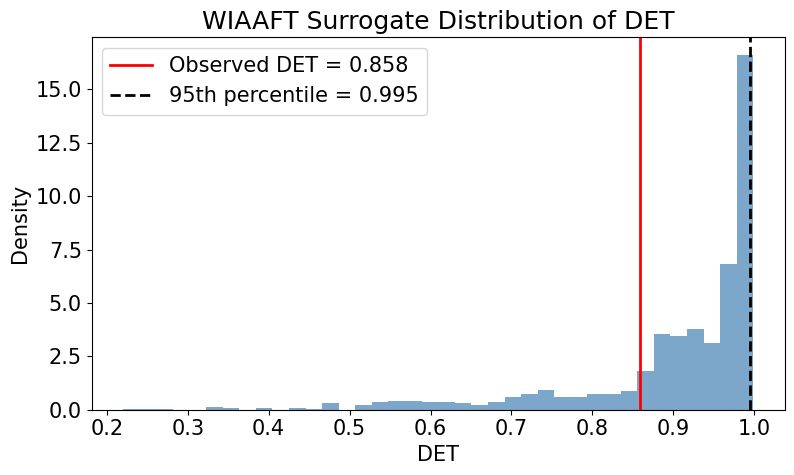

 74%|███████████████████████████████           | 74/100 [18:03<06:20, 14.64s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8582733812918768 
 Recurrence rate: 0.05000330491109789 
Threshold:1.3367999999998692 
 Laminarity:0.9342366159916251 
Shannon Entropy:1.5632927462468564 
Rank-order p-value (det):0.402 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.6613163438186962
Pseudo-periodic surrogates generated successfullly


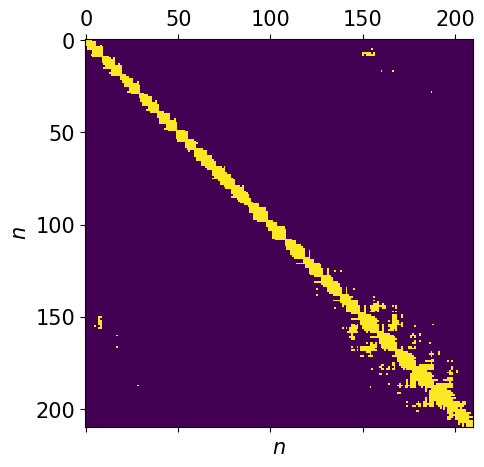

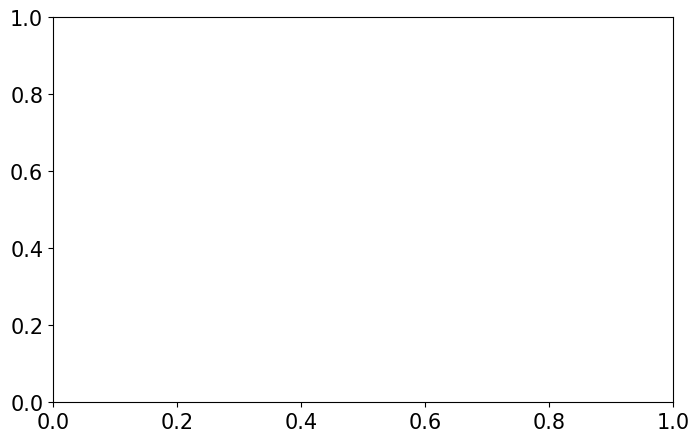

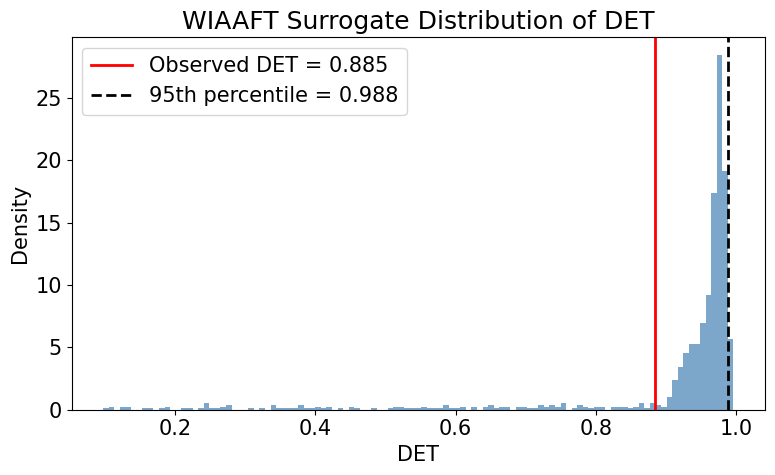

 75%|███████████████████████████████▌          | 75/100 [18:19<06:13, 14.94s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8847695390737237 
 Recurrence rate: 0.05002267573696145 
Threshold:1.6351999999998363 
 Laminarity:0.9410698096058883 
Shannon Entropy:1.8327029498735588 
Rank-order p-value (det):0.264 
Reject null (det) hypothesis:False

 
 

18
8
Mean Nearest Neighbor Distance: 0.3727262671246
Pseudo-periodic surrogates generated successfullly


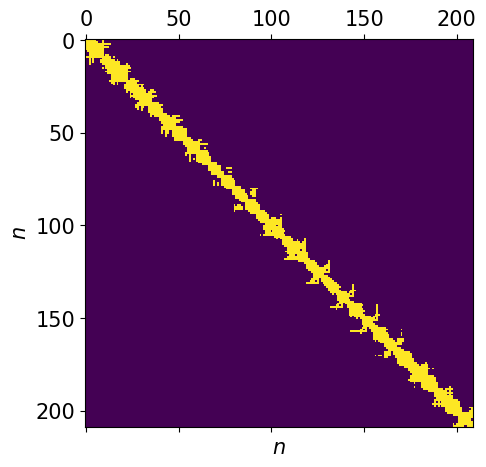

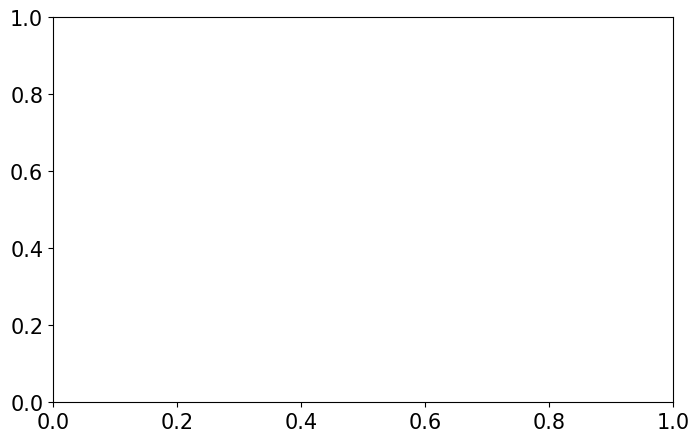

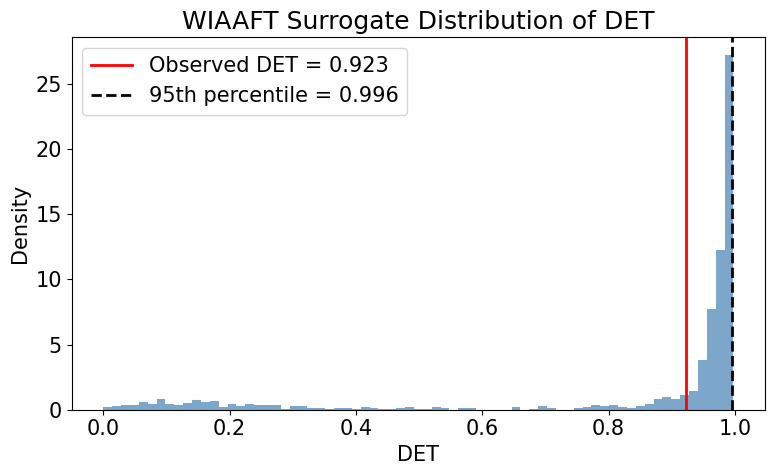

 76%|███████████████████████████████▉          | 76/100 [18:31<05:37, 14.07s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9230769230722516 
 Recurrence rate: 0.05002174858634189 
Threshold:1.0737999999998982 
 Laminarity:0.9597254004532736 
Shannon Entropy:1.857529072939112 
Rank-order p-value (det):0.516 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.6337772341176736
Pseudo-periodic surrogates generated successfullly


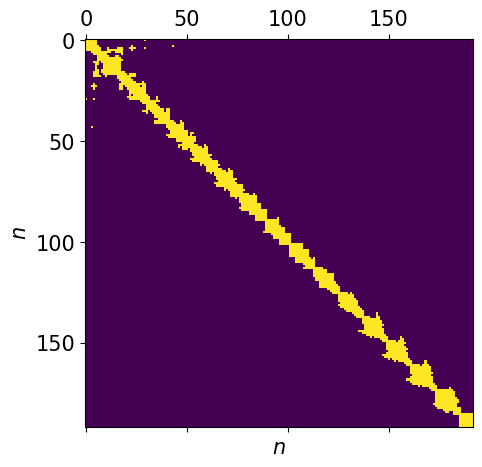

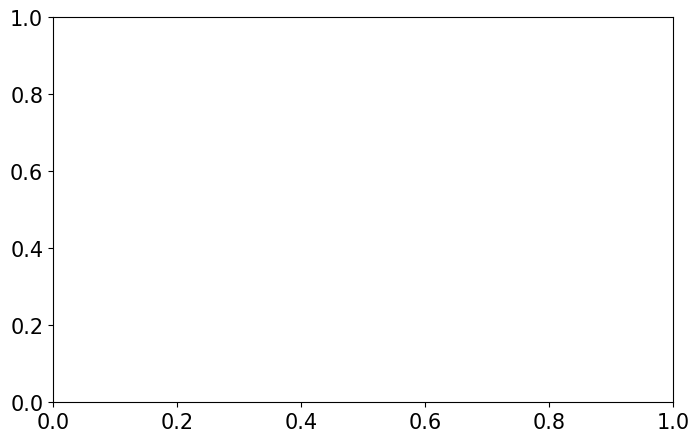

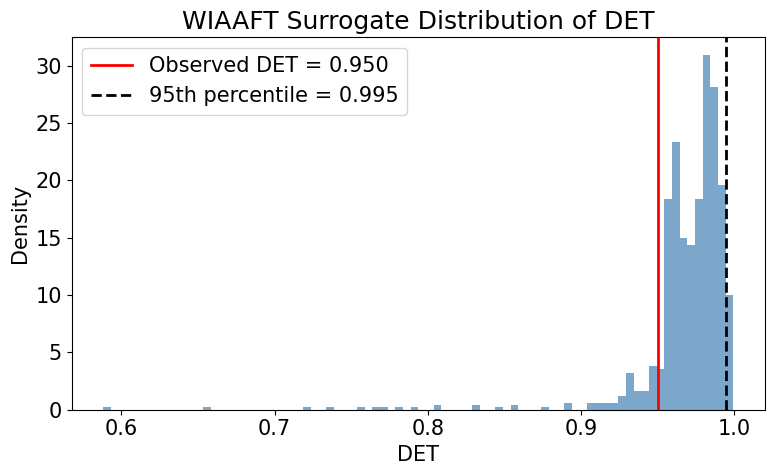

 77%|████████████████████████████████▎         | 77/100 [18:44<05:17, 13.79s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9503631961201553 
 Recurrence rate: 0.05002170138888889 
Threshold:1.4513999999998566 
 Laminarity:0.97668112797735 
Shannon Entropy:2.0316147951960257 
Rank-order p-value (det):0.186 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.3933179212712068
Pseudo-periodic surrogates generated successfullly


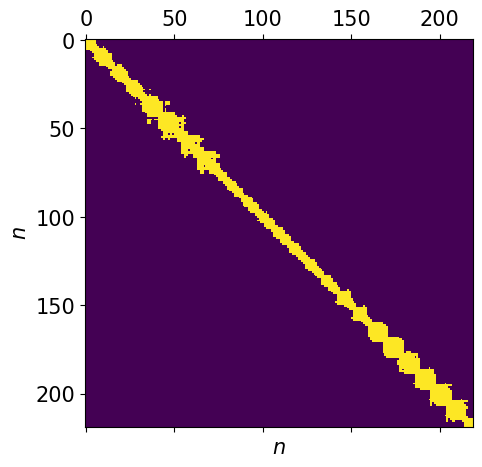

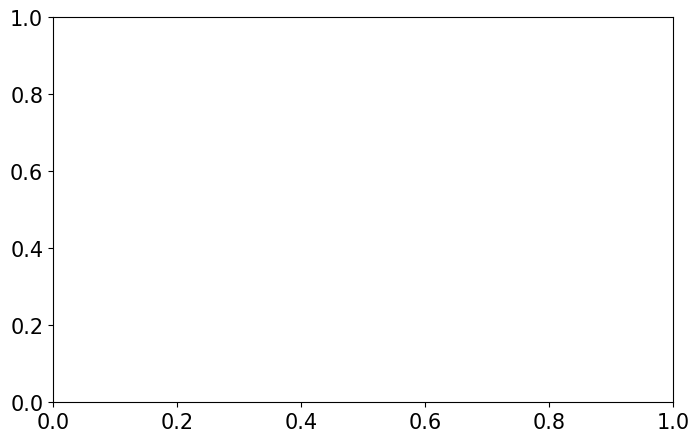

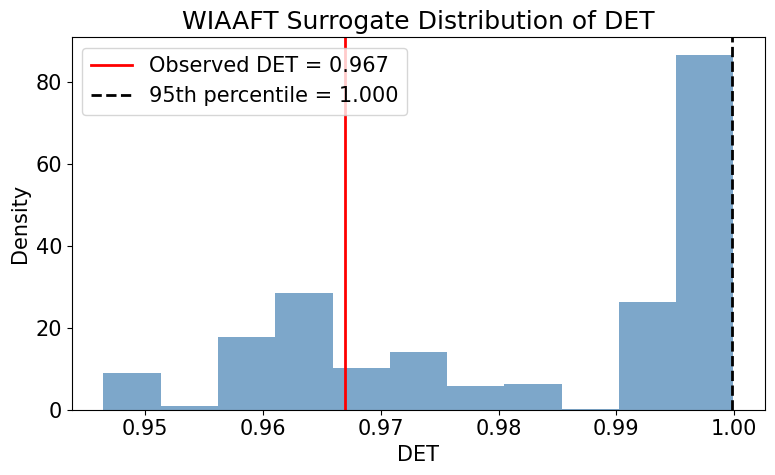

 78%|████████████████████████████████▊         | 78/100 [18:56<04:55, 13.43s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9669724770597846 
 Recurrence rate: 0.05001980776047205 
Threshold:1.0611999999998996 
 Laminarity:0.9899958315923719 
Shannon Entropy:2.1438870419923886 
Rank-order p-value (det):0.576 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.466577126895569
Pseudo-periodic surrogates generated successfullly


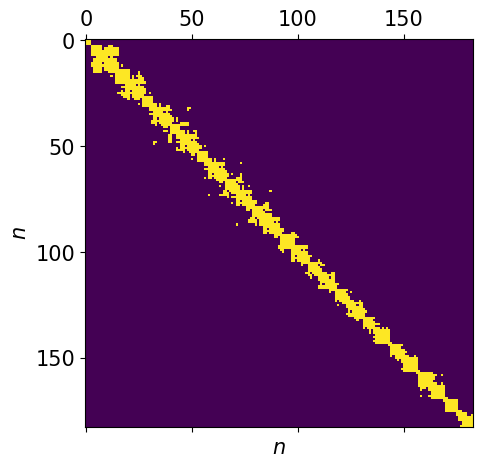

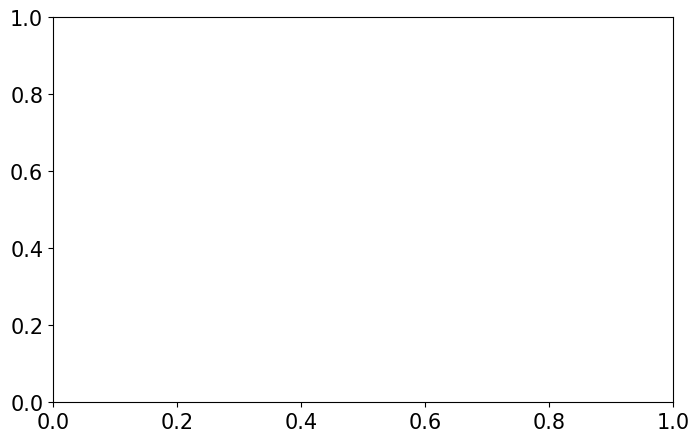

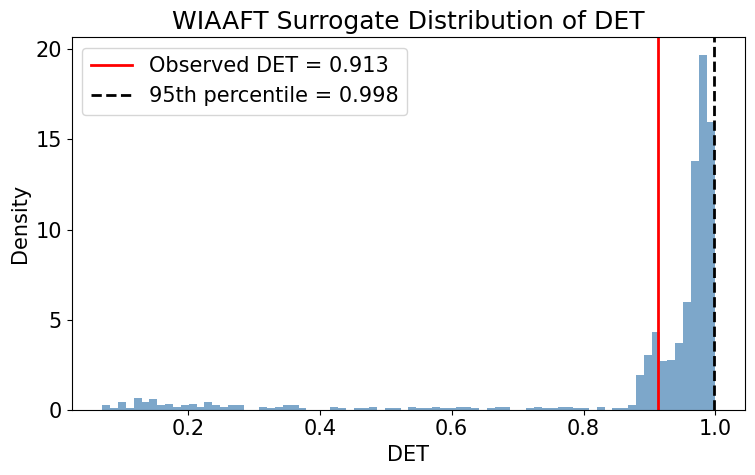

 79%|█████████████████████████████████▏        | 79/100 [19:07<04:20, 12.42s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9128686327016564 
 Recurrence rate: 0.05001642330317418 
Threshold:0.9776999999999086 
 Laminarity:0.9552238805913121 
Shannon Entropy:1.6761534577513029 
Rank-order p-value (det):0.446 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.5128726716126852
Pseudo-periodic surrogates generated successfullly


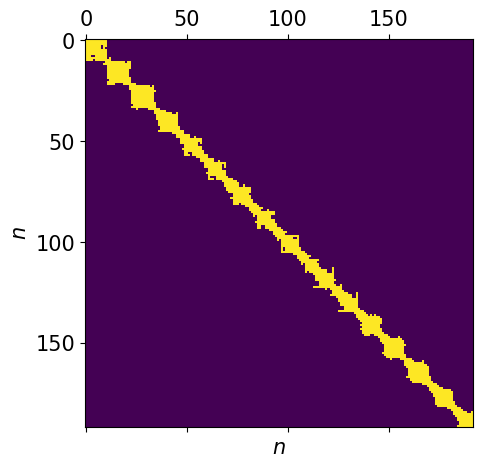

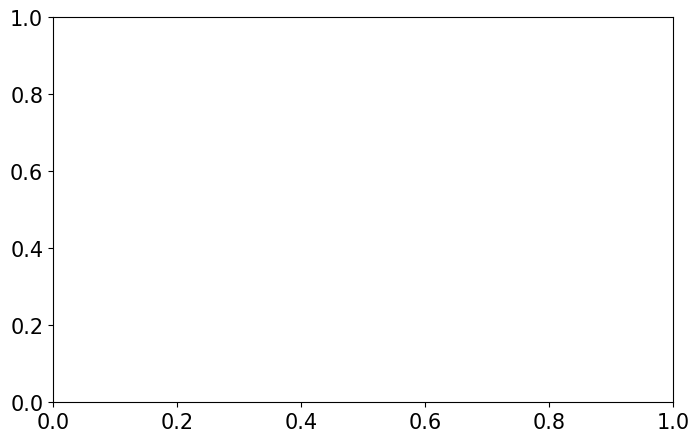

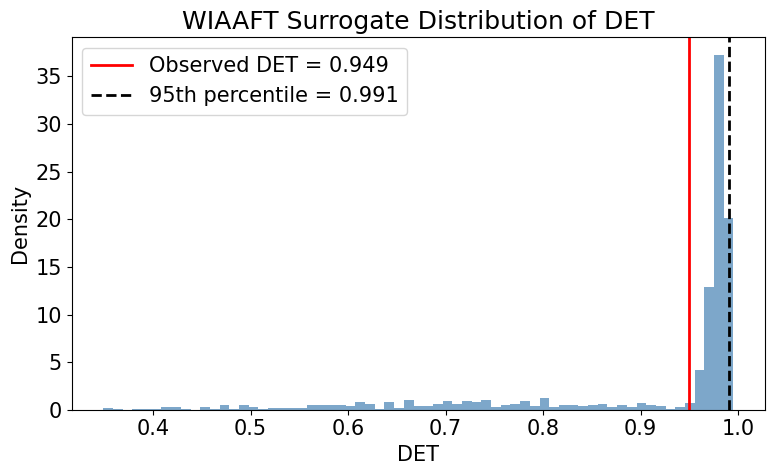

 80%|█████████████████████████████████▌        | 80/100 [19:19<04:07, 12.35s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.949152542367136 
 Recurrence rate: 0.05002170138888889 
Threshold:1.2680999999998768 
 Laminarity:0.9815618221204905 
Shannon Entropy:2.191006421443446 
Rank-order p-value (det):0.514 
Reject null (det) hypothesis:False

 
 

18
7
Mean Nearest Neighbor Distance: 0.43237101027738617
Pseudo-periodic surrogates generated successfullly


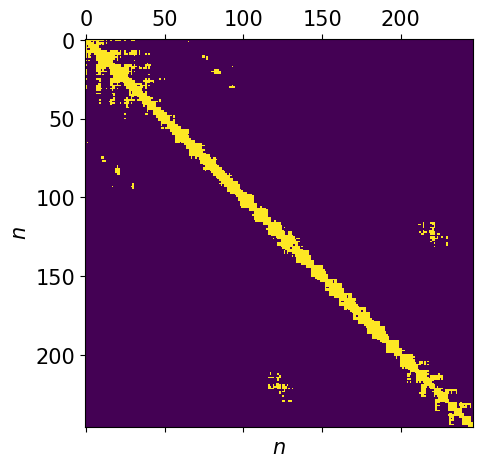

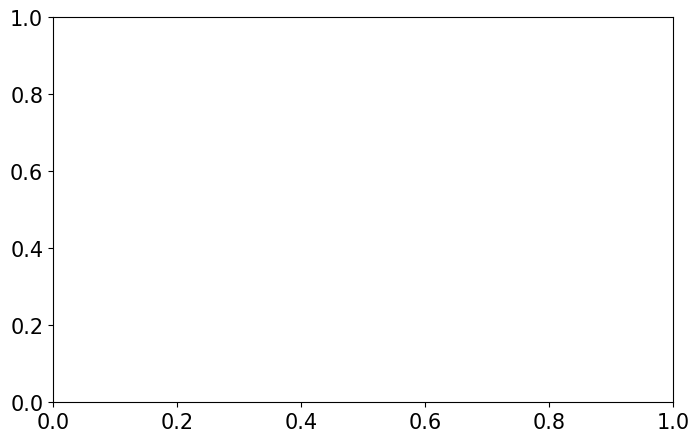

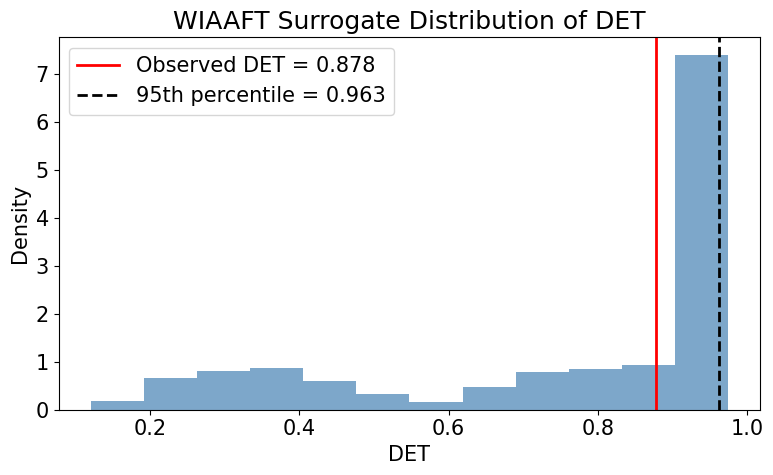

 81%|██████████████████████████████████        | 81/100 [19:32<04:02, 12.78s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8784172661838906 
 Recurrence rate: 0.05000330491109789 
Threshold:1.0409999999999018 
 Laminarity:0.9401850627860536 
Shannon Entropy:1.79458275014649 
Rank-order p-value (det):0.9 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.7394681836952471
Pseudo-periodic surrogates generated successfullly


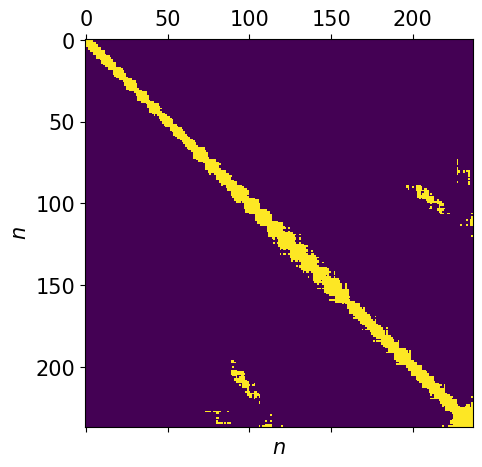

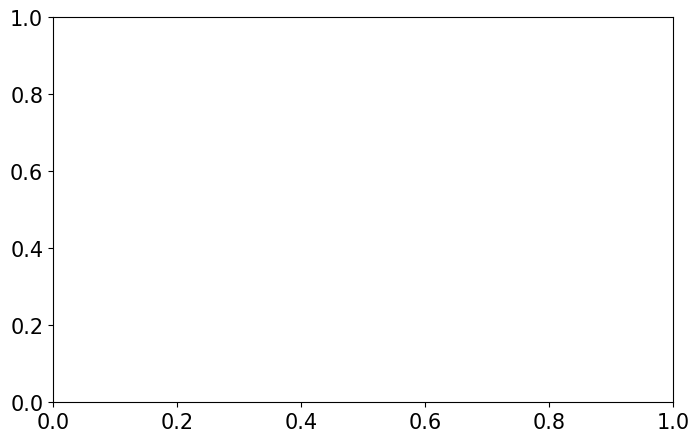

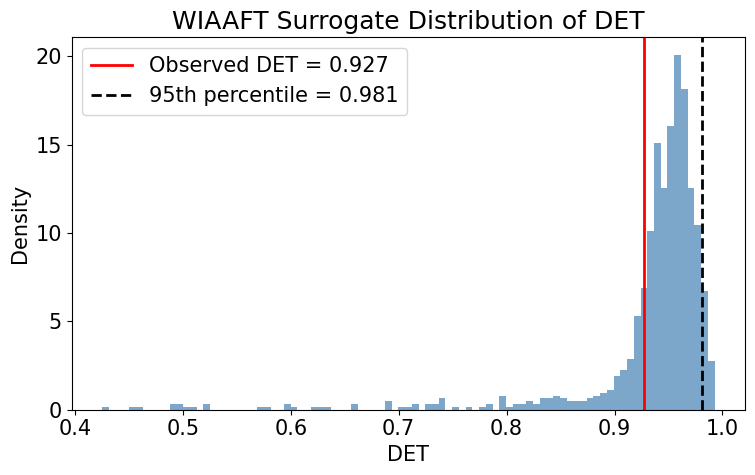

 82%|██████████████████████████████████▍       | 82/100 [19:54<04:39, 15.53s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9269051321892422 
 Recurrence rate: 0.050009791878082216 
Threshold:2.107100000000022 
 Laminarity:0.9647561409720016 
Shannon Entropy:2.02675032145298 
Rank-order p-value (det):0.388 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.44558700284340863
Pseudo-periodic surrogates generated successfullly


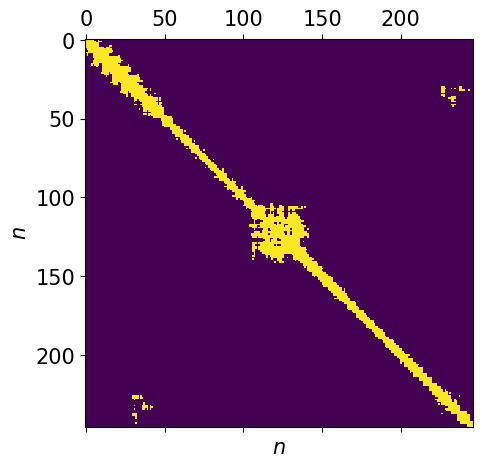

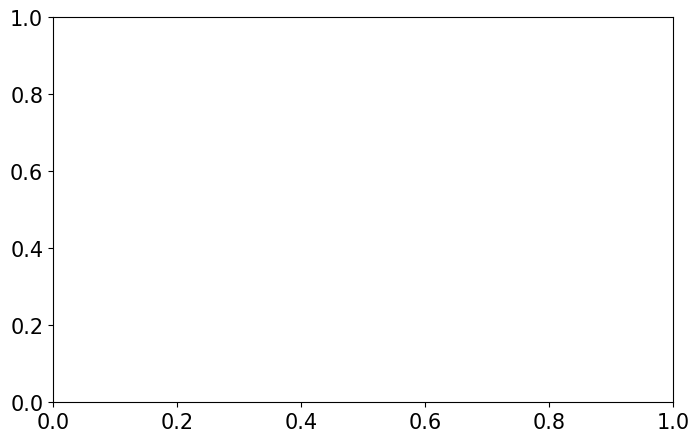

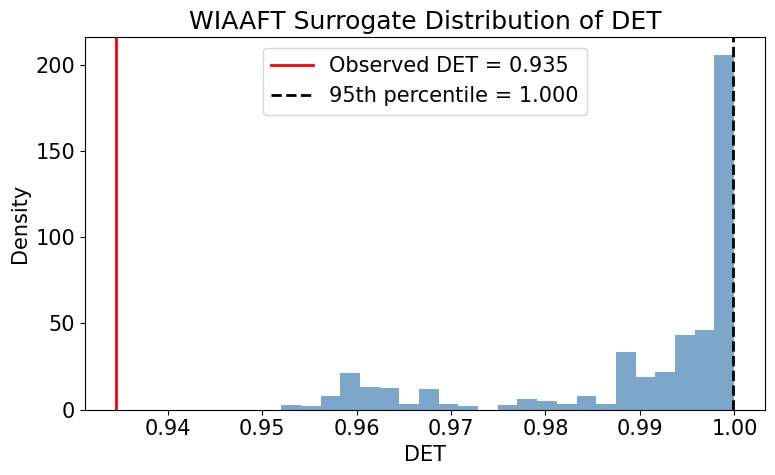

 83%|██████████████████████████████████▊       | 83/100 [20:09<04:18, 15.18s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9345323740973578 
 Recurrence rate: 0.05000330491109789 
Threshold:1.094499999999896 
 Laminarity:0.9695968274918387 
Shannon Entropy:2.1003583311603524 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

19
10
Mean Nearest Neighbor Distance: 0.7004403431702773
Pseudo-periodic surrogates generated successfullly


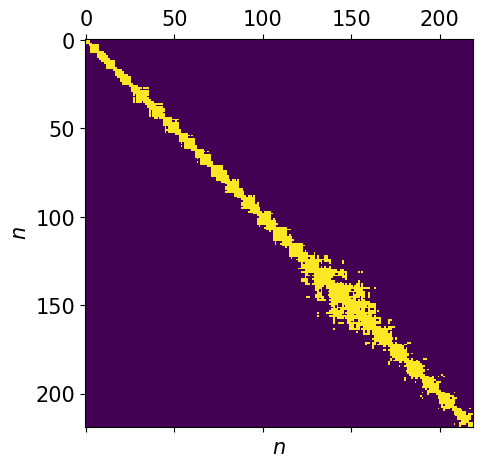

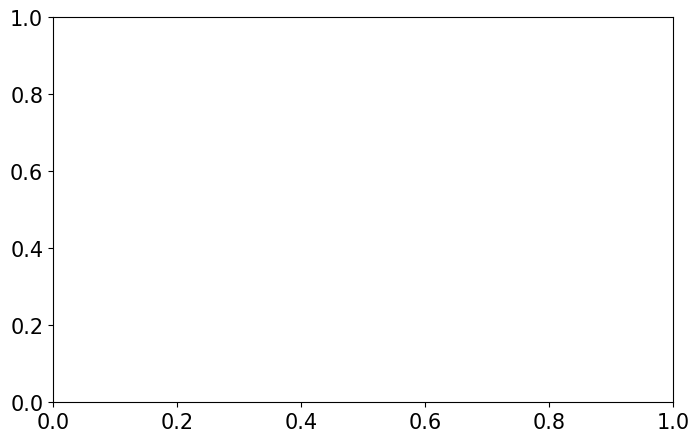

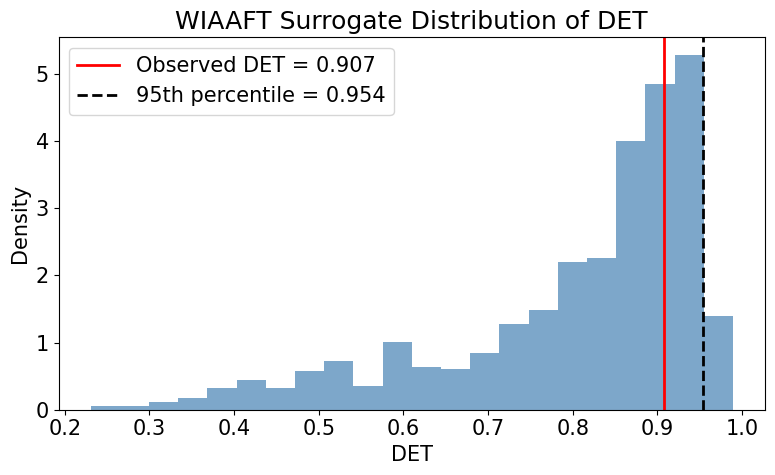

 84%|███████████████████████████████████▎      | 84/100 [20:24<04:03, 15.22s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9073394495371223 
 Recurrence rate: 0.05001980776047205 
Threshold:1.5234999999998486 
 Laminarity:0.947478115877668 
Shannon Entropy:1.8711328129593174 
Rank-order p-value (det):0.584 
Reject null (det) hypothesis:False

 
 

19
9
Mean Nearest Neighbor Distance: 0.4279142734493737
Pseudo-periodic surrogates generated successfullly


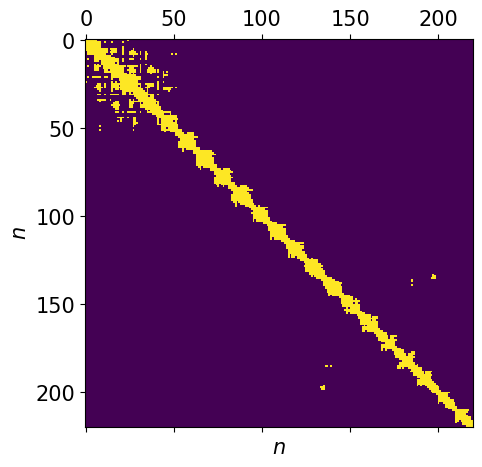

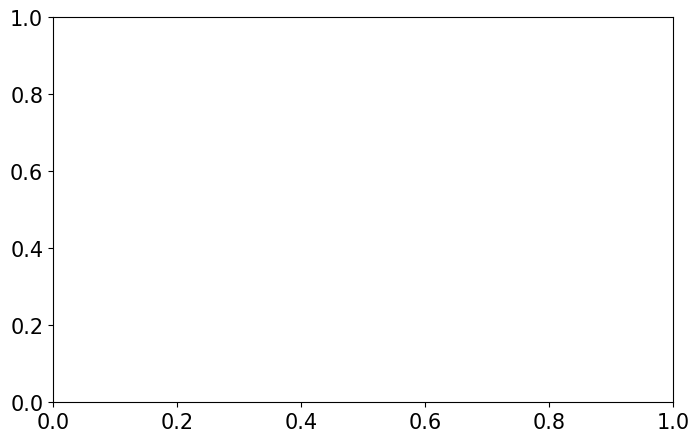

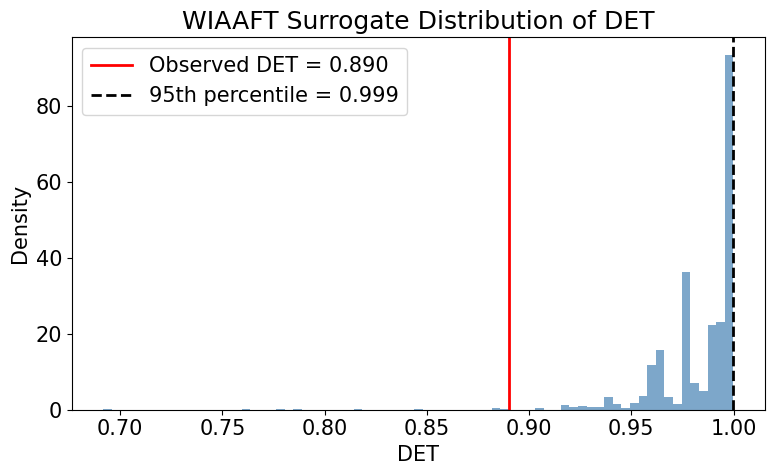

 85%|███████████████████████████████████▋      | 85/100 [20:37<03:39, 14.62s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8899999999959546 
 Recurrence rate: 0.05 
Threshold:1.1425999999998906 
 Laminarity:0.9466942148721211 
Shannon Entropy:1.8649240412665904 
Rank-order p-value (det):0.02 
Reject null (det) hypothesis:True

 
 

20
10
Mean Nearest Neighbor Distance: 0.803038780831699
Pseudo-periodic surrogates generated successfullly


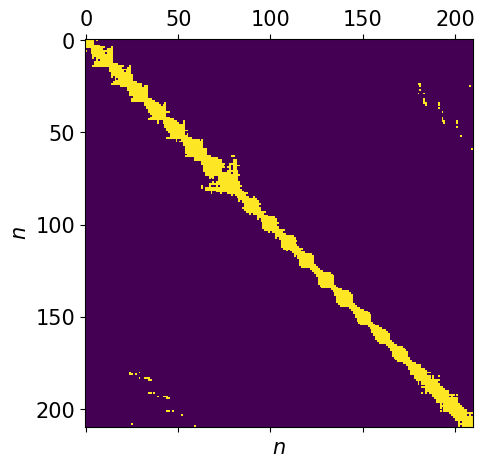

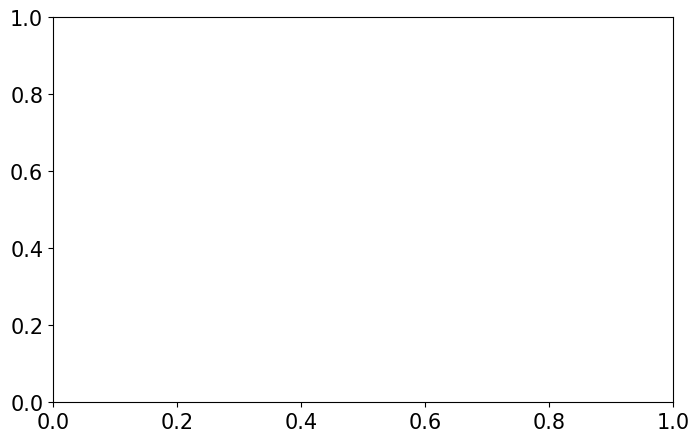

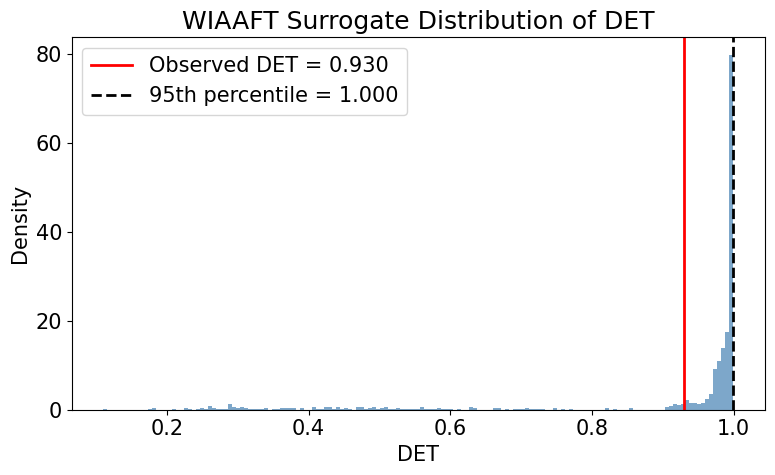

 86%|████████████████████████████████████      | 86/100 [20:55<03:37, 15.53s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9298597194342192 
 Recurrence rate: 0.05002267573696145 
Threshold:2.0299999999998595 
 Laminarity:0.9623753399775051 
Shannon Entropy:2.1874137065610313 
Rank-order p-value (det):0.35 
Reject null (det) hypothesis:False

 
 

20
10
Mean Nearest Neighbor Distance: 0.6459206232289851
Pseudo-periodic surrogates generated successfullly


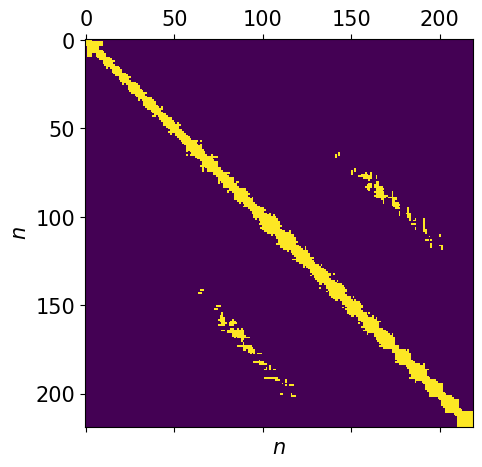

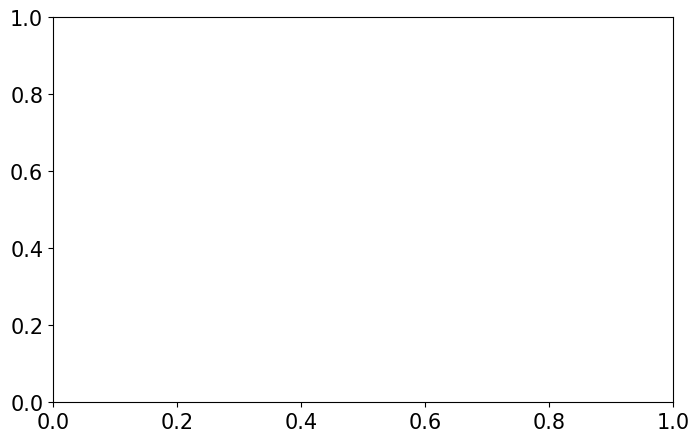

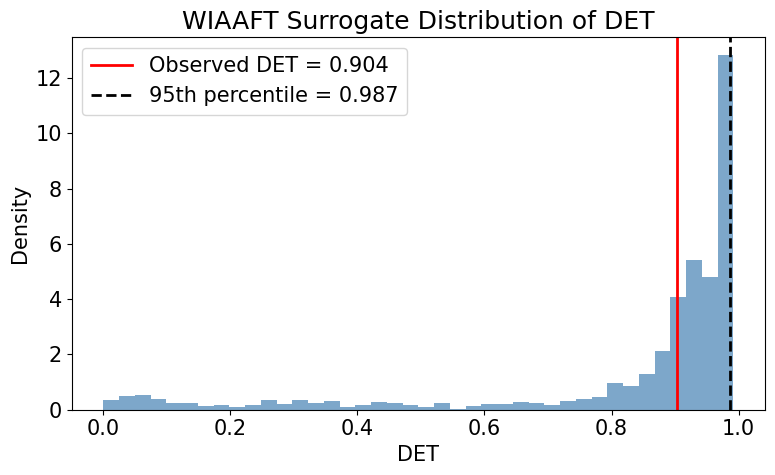

 87%|████████████████████████████████████▌     | 87/100 [21:11<03:21, 15.53s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.903669724766497 
 Recurrence rate: 0.05001980776047205 
Threshold:1.5825999999998421 
 Laminarity:0.9520633597292536 
Shannon Entropy:1.9120342530403927 
Rank-order p-value (det):0.706 
Reject null (det) hypothesis:False

 
 

20
10
Mean Nearest Neighbor Distance: 0.5328034253734631
Pseudo-periodic surrogates generated successfullly


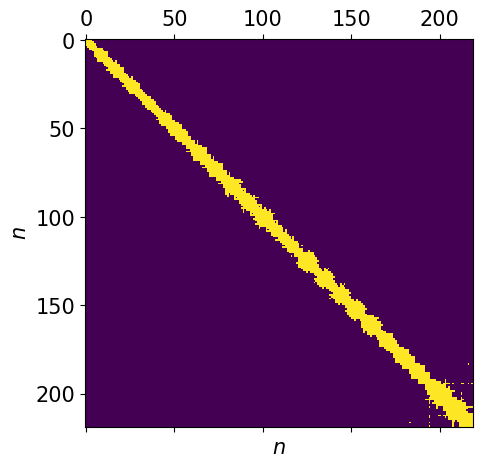

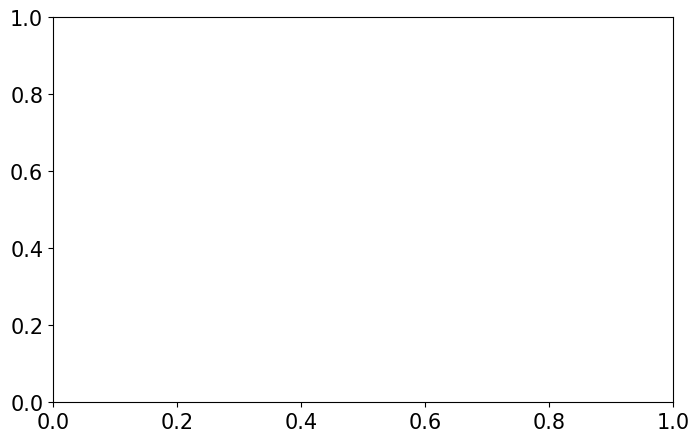

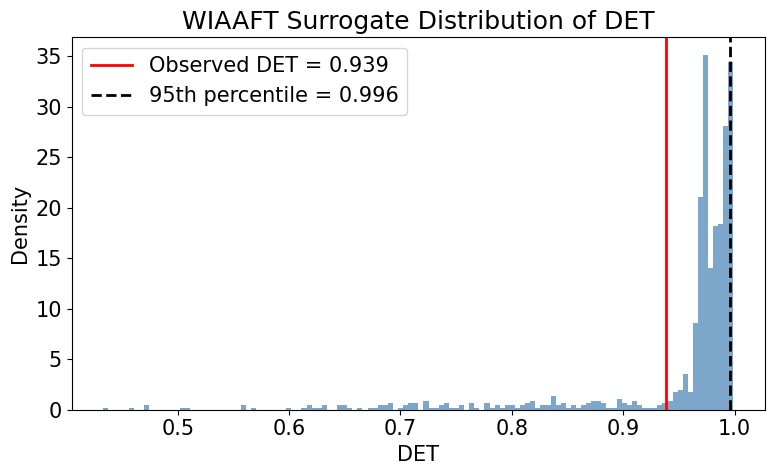

 88%|████████████████████████████████████▉     | 88/100 [21:25<03:04, 15.33s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.938532110087438 
 Recurrence rate: 0.05001980776047205 
Threshold:1.448599999999857 
 Laminarity:0.9724885368863173 
Shannon Entropy:2.0045765620410734 
Rank-order p-value (det):0.286 
Reject null (det) hypothesis:False

 
 

20
10
Mean Nearest Neighbor Distance: 0.5996689895058185
Pseudo-periodic surrogates generated successfullly


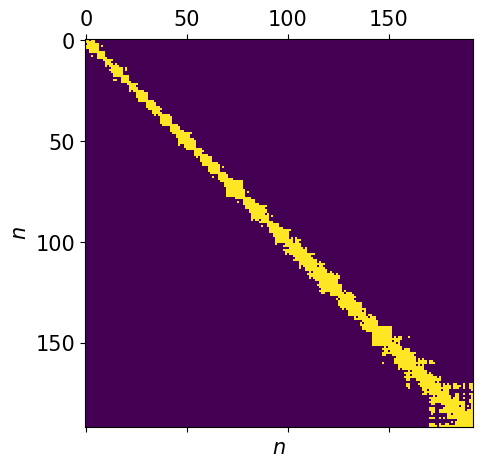

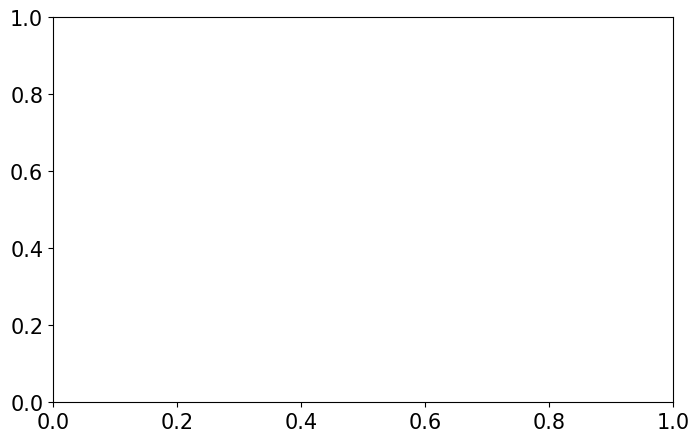

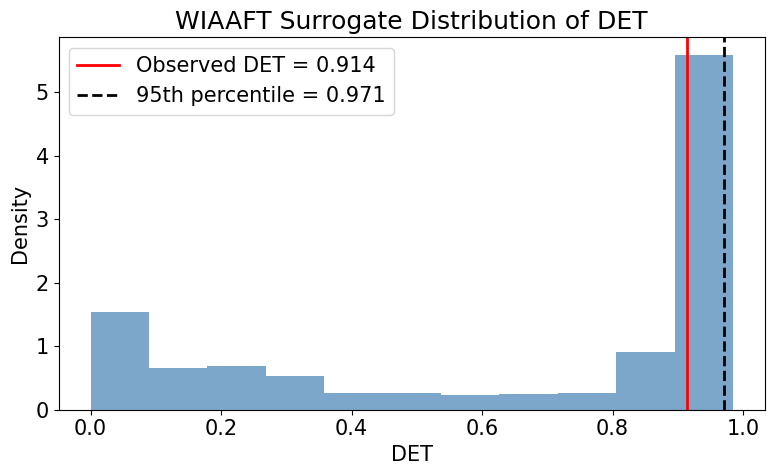

 89%|█████████████████████████████████████▍    | 89/100 [21:37<02:37, 14.29s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.914043583529576 
 Recurrence rate: 0.05002170138888889 
Threshold:1.2170999999998824 
 Laminarity:0.9614967461986904 
Shannon Entropy:1.8766477020590606 
Rank-order p-value (det):0.914 
Reject null (det) hypothesis:False

 
 

20
9
Mean Nearest Neighbor Distance: 0.4724045779476906
Pseudo-periodic surrogates generated successfullly


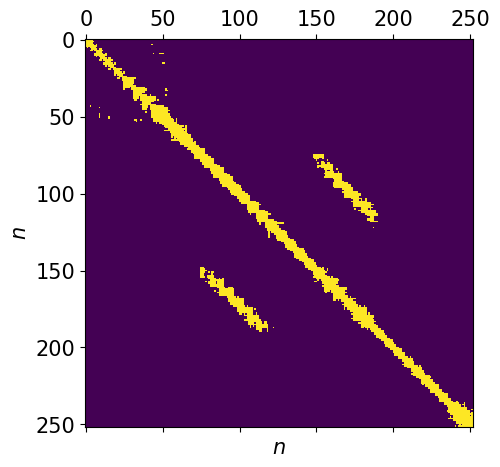

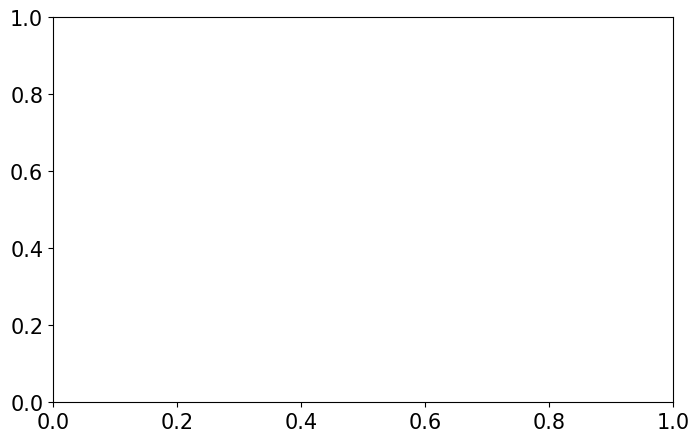

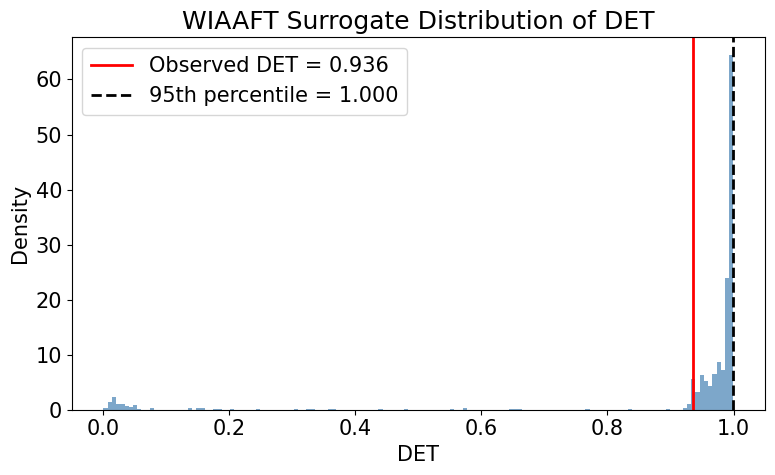

 90%|█████████████████████████████████████▊    | 90/100 [21:53<02:26, 14.63s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.935704514360685 
 Recurrence rate: 0.05001259763164525 
Threshold:1.1373999999998912 
 Laminarity:0.9681989924402765 
Shannon Entropy:1.8977283054684286 
Rank-order p-value (det):0.222 
Reject null (det) hypothesis:False

 
 

20
8
Mean Nearest Neighbor Distance: 0.43522768001195516
Pseudo-periodic surrogates generated successfullly


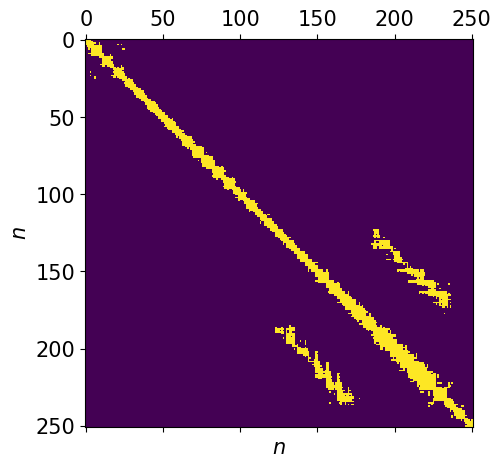

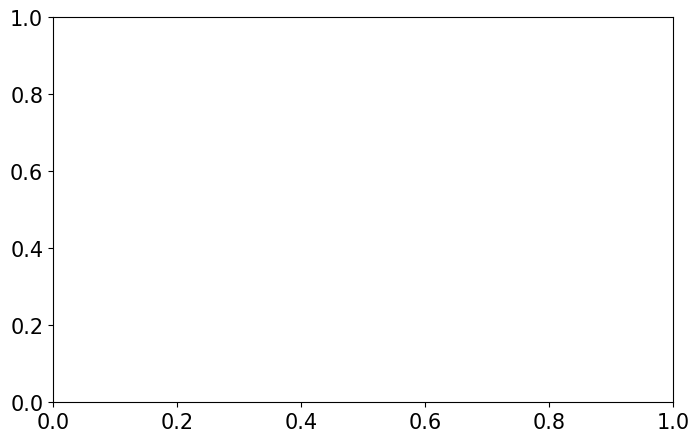

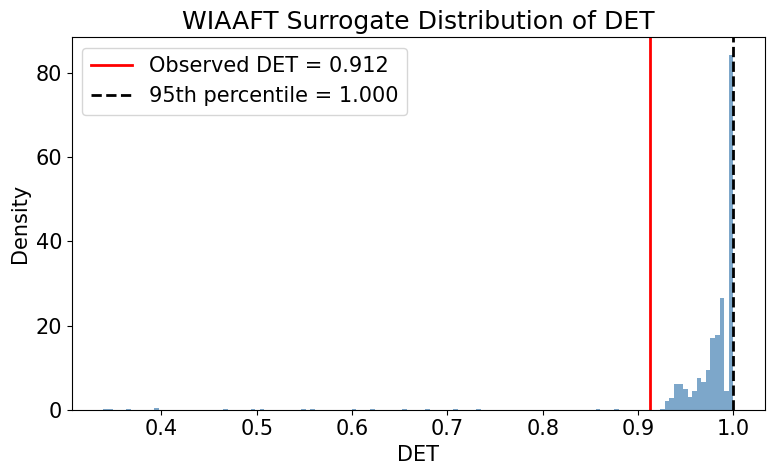

 91%|██████████████████████████████████████▏   | 91/100 [22:07<02:11, 14.62s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.912413793100302 
 Recurrence rate: 0.05001507912572816 
Threshold:1.1082999999998944 
 Laminarity:0.9555696604222292 
Shannon Entropy:1.897378810779591 
Rank-order p-value (det):0.038 
Reject null (det) hypothesis:True

 
 

21
9
Mean Nearest Neighbor Distance: 0.44769793603500074
Pseudo-periodic surrogates generated successfullly


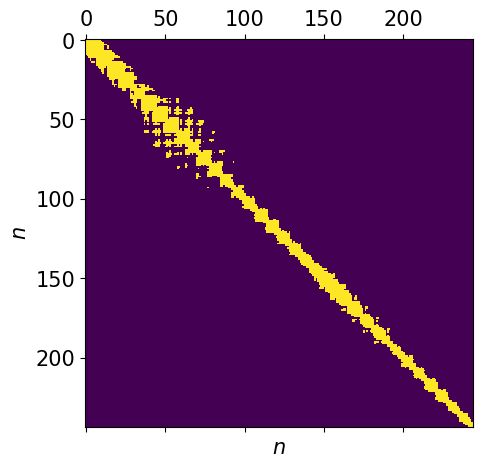

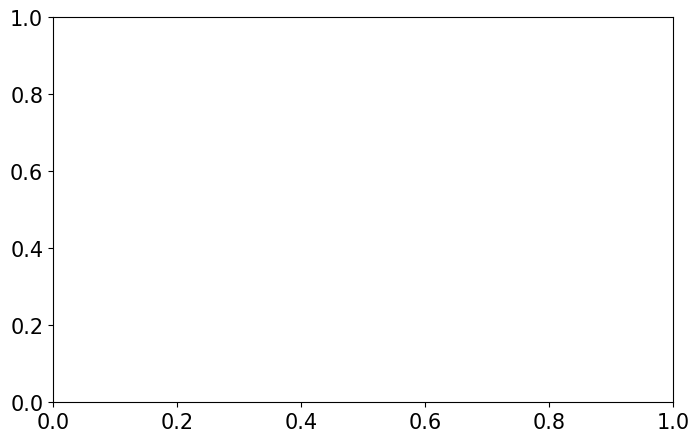

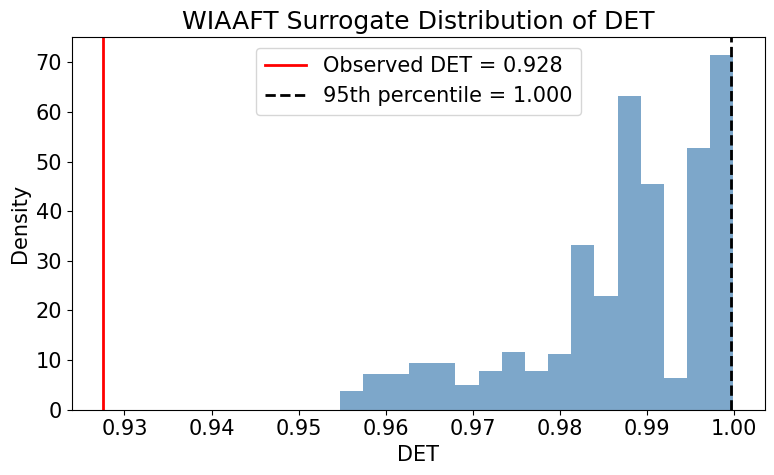

 92%|██████████████████████████████████████▋   | 92/100 [22:22<01:56, 14.59s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9275786393528619 
 Recurrence rate: 0.0500201558720774 
Threshold:1.1897999999998854 
 Laminarity:0.9644056413668086 
Shannon Entropy:1.8734591042253022 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

22
9
Mean Nearest Neighbor Distance: 0.816340725692759
Pseudo-periodic surrogates generated successfullly


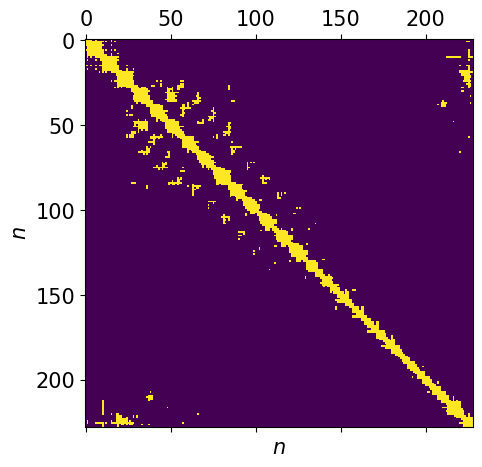

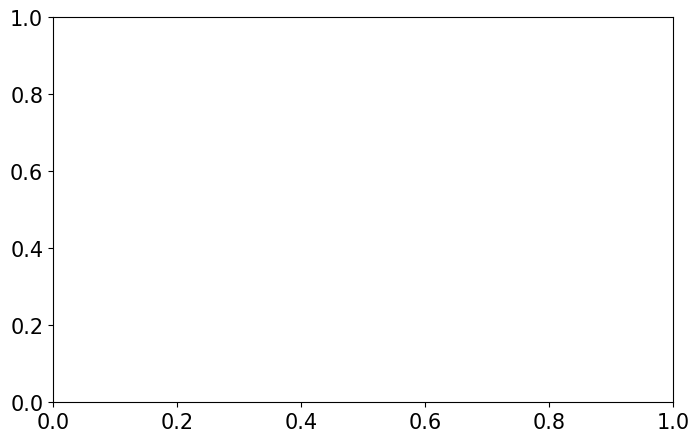

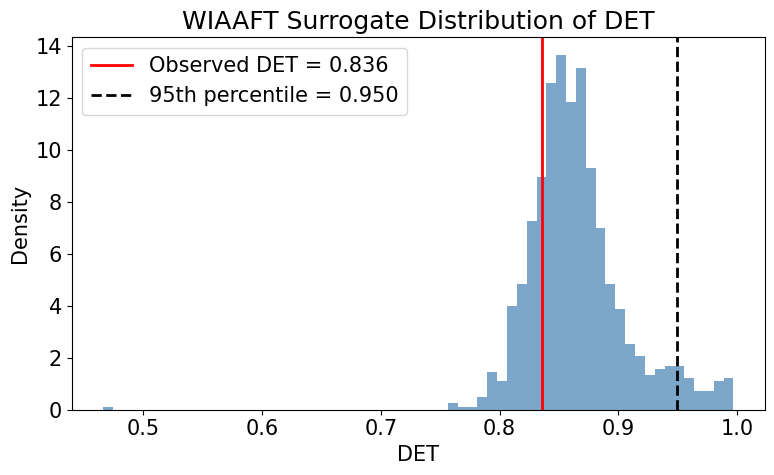

 93%|███████████████████████████████████████   | 93/100 [22:40<01:49, 15.67s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8355817875175566 
 Recurrence rate: 0.05001538935056941 
Threshold:1.918999999999805 
 Laminarity:0.9080769230734305 
Shannon Entropy:1.682958722090003 
Rank-order p-value (det):0.408 
Reject null (det) hypothesis:False

 
 

22
10
Mean Nearest Neighbor Distance: 0.7009233807068327
Pseudo-periodic surrogates generated successfullly


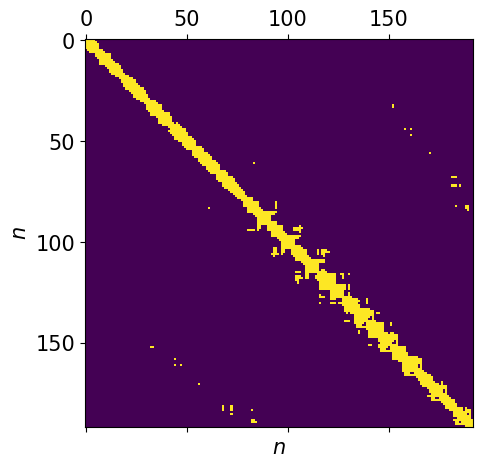

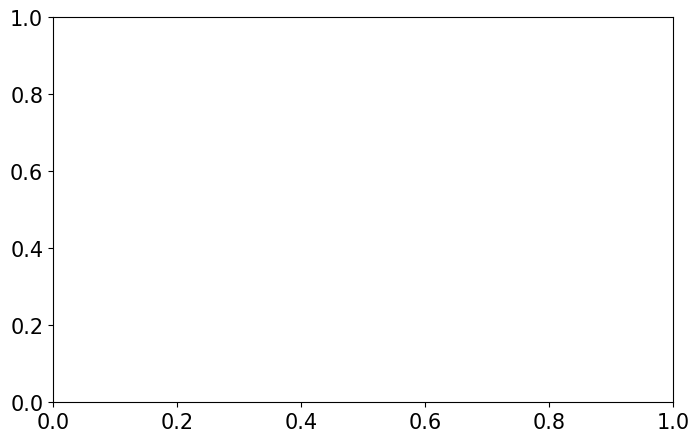

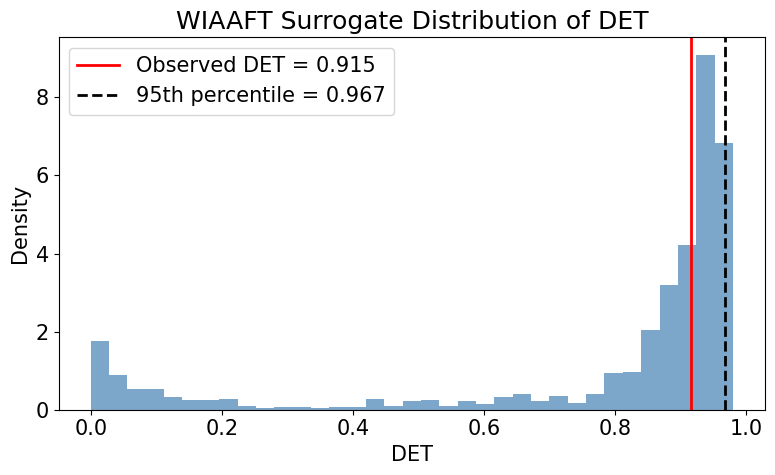

 94%|███████████████████████████████████████▍  | 94/100 [22:54<01:31, 15.25s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9152542372825954 
 Recurrence rate: 0.05002170138888889 
Threshold:1.711599999999828 
 Laminarity:0.963123644246404 
Shannon Entropy:1.7541758716117384 
Rank-order p-value (det):0.978 
Reject null (det) hypothesis:False

 
 

22
7
Mean Nearest Neighbor Distance: 0.8070144022355709
Pseudo-periodic surrogates generated successfullly


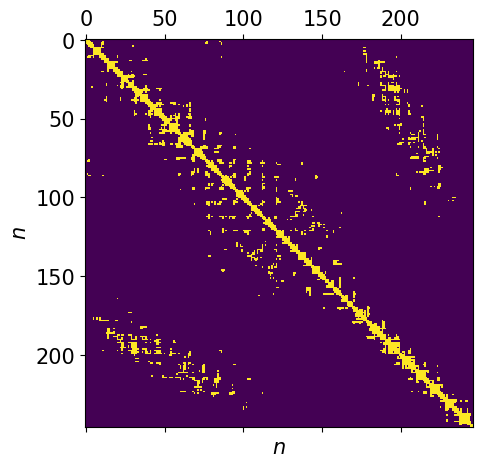

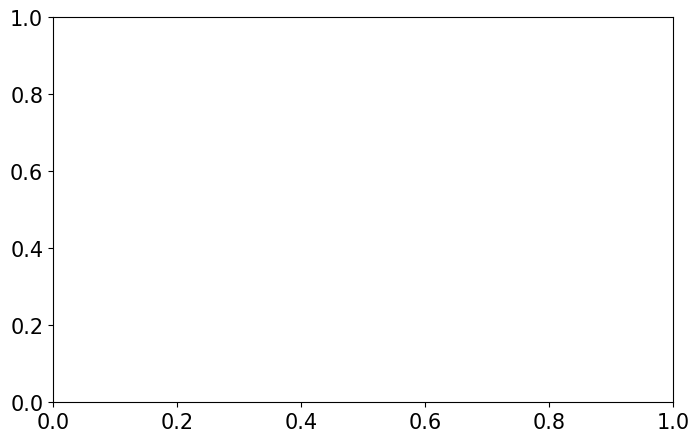

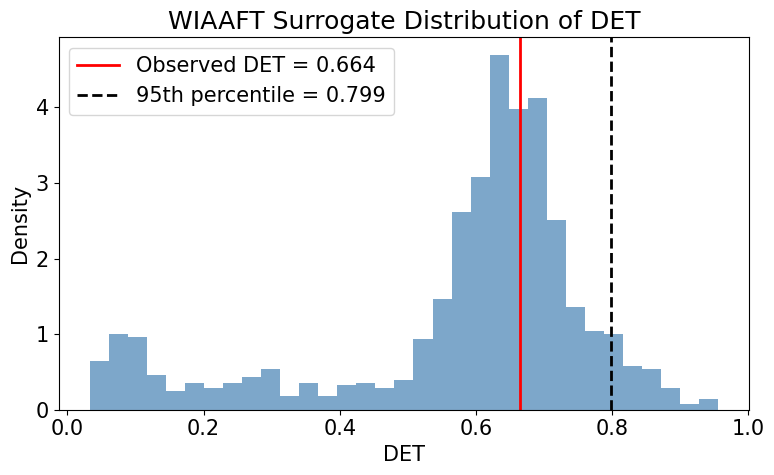

 95%|███████████████████████████████████████▉  | 95/100 [23:10<01:17, 15.48s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.6640287769760287 
 Recurrence rate: 0.05000330491109789 
Threshold:1.5307999999998478 
 Laminarity:0.8218770654301987 
Shannon Entropy:1.1359052962510217 
Rank-order p-value (det):0.746 
Reject null (det) hypothesis:False

 
 

22
8
Mean Nearest Neighbor Distance: 0.4816568003873713
Pseudo-periodic surrogates generated successfullly


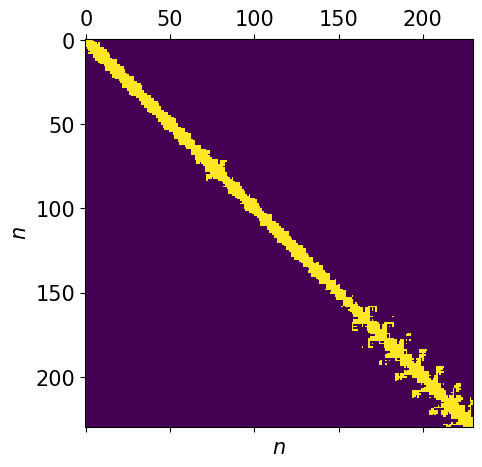

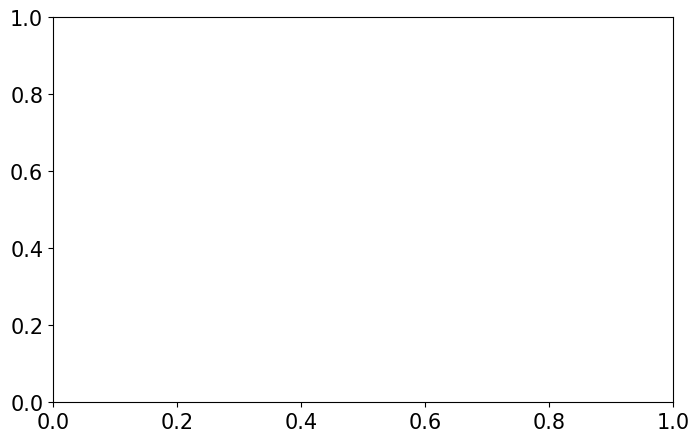

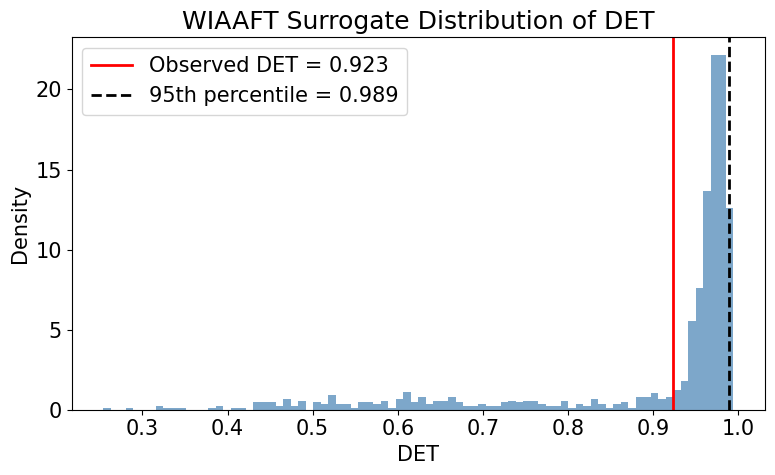

 96%|████████████████████████████████████████▎ | 96/100 [23:25<01:00, 15.16s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9230132450292922 
 Recurrence rate: 0.05001890359168242 
Threshold:1.4124999999998609 
 Laminarity:0.9746787603893625 
Shannon Entropy:1.8823631304528443 
Rank-order p-value (det):0.47 
Reject null (det) hypothesis:False

 
 

22
10
Mean Nearest Neighbor Distance: 0.4522739028799653
Pseudo-periodic surrogates generated successfullly


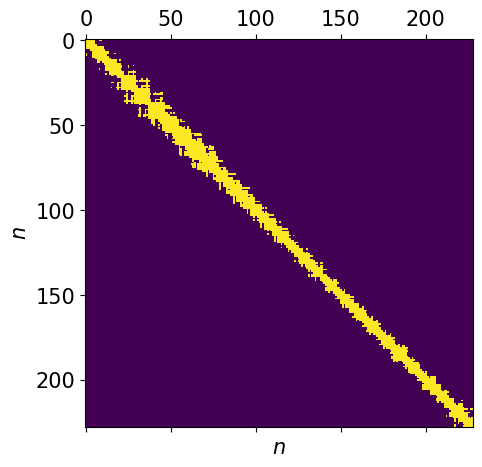

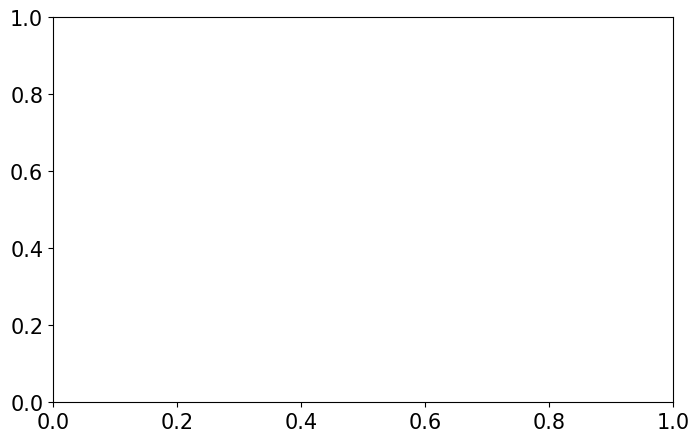

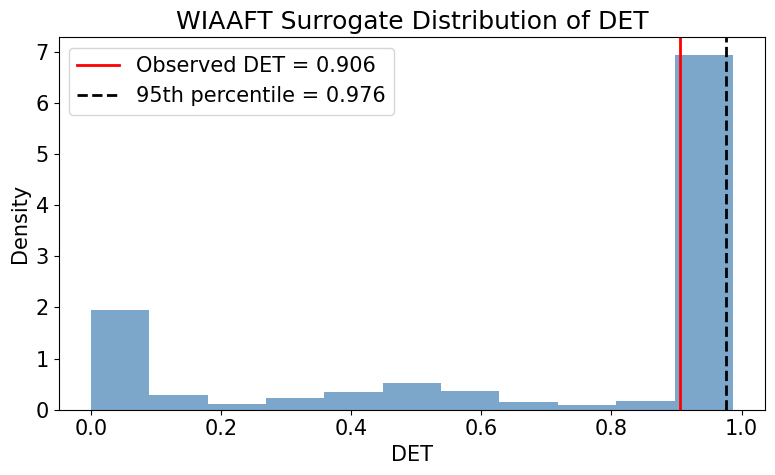

 97%|████████████████████████████████████████▋ | 97/100 [23:37<00:43, 14.36s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9055649241108534 
 Recurrence rate: 0.05001538935056941 
Threshold:1.0615999999998995 
 Laminarity:0.9503846153809601 
Shannon Entropy:1.7412705997122138 
Rank-order p-value (det):0.762 
Reject null (det) hypothesis:False

 
 

22
10
Mean Nearest Neighbor Distance: 0.8088171085638114
Pseudo-periodic surrogates generated successfullly


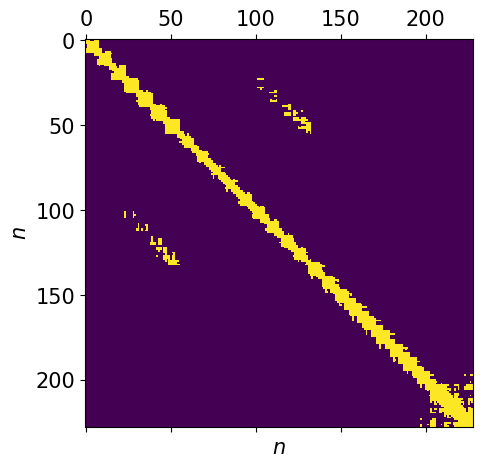

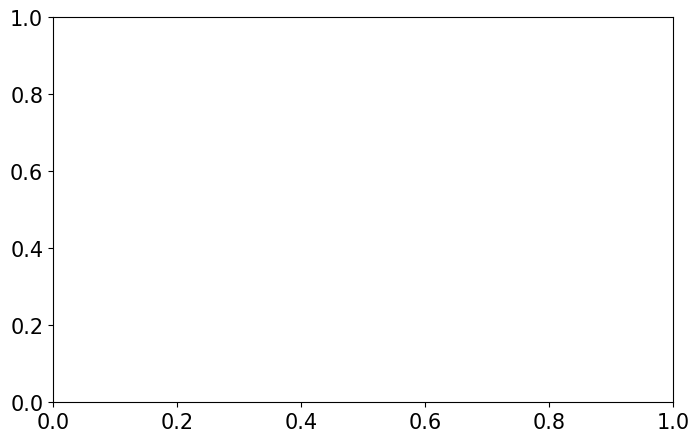

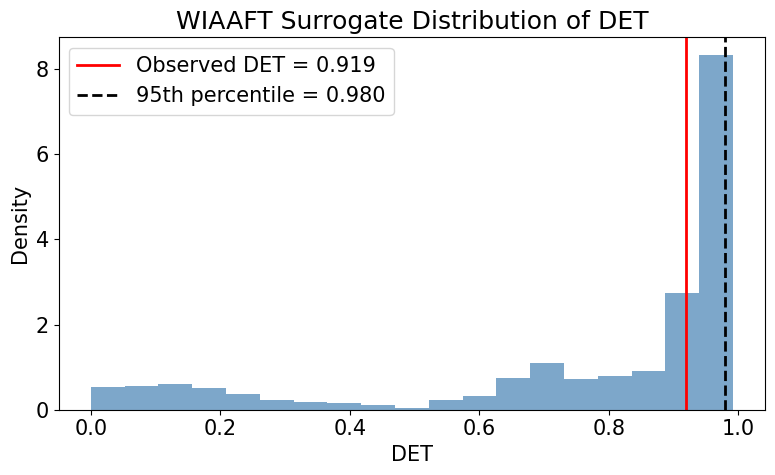

 98%|█████████████████████████████████████████▏| 98/100 [23:55<00:30, 15.39s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9190556492372721 
 Recurrence rate: 0.05001538935056941 
Threshold:1.8442999999998133 
 Laminarity:0.9634615384578329 
Shannon Entropy:1.7004648953102643 
Rank-order p-value (det):0.986 
Reject null (det) hypothesis:False

 
 

22
10
Mean Nearest Neighbor Distance: 0.48758731415670487
Pseudo-periodic surrogates generated successfullly


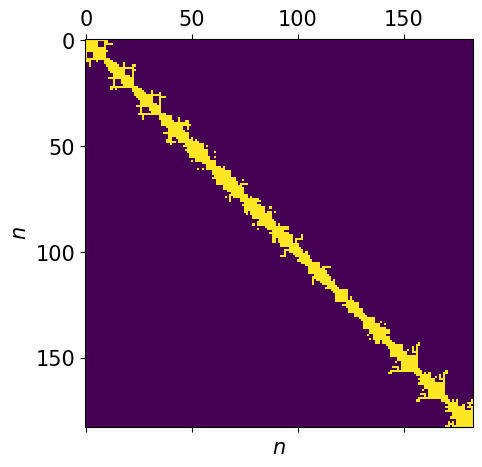

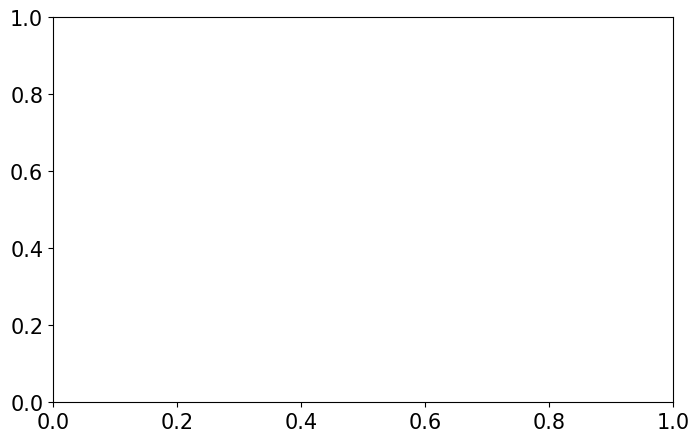

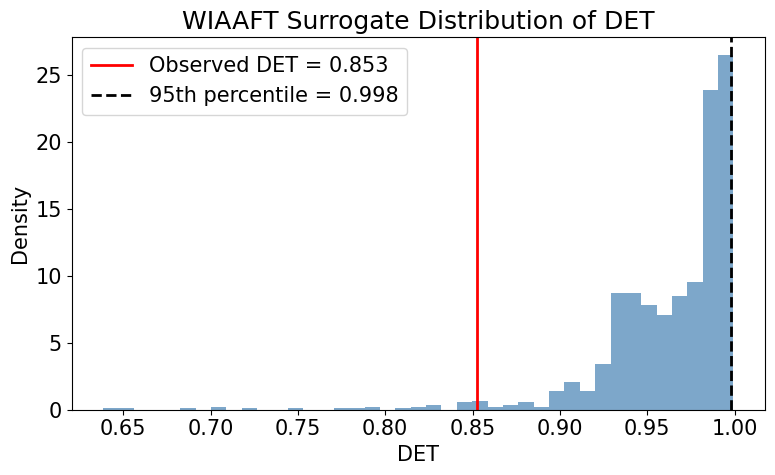

 99%|█████████████████████████████████████████▌| 99/100 [24:06<00:13, 13.97s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8527443105699282 
 Recurrence rate: 0.05007614440562573 
Threshold:1.165499999999888 
 Laminarity:0.9415623136497224 
Shannon Entropy:1.8460710707368406 
Rank-order p-value (det):0.052 
Reject null (det) hypothesis:False

 
 

22
10
Mean Nearest Neighbor Distance: 0.4405427215840223
Pseudo-periodic surrogates generated successfullly


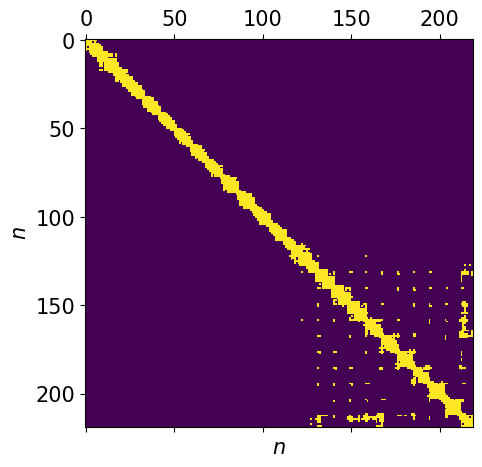

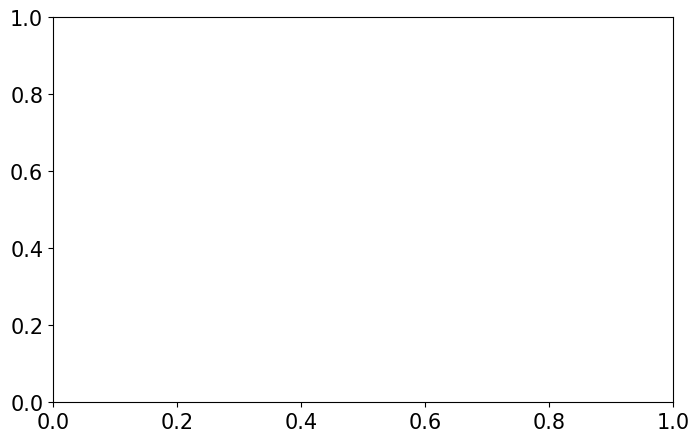

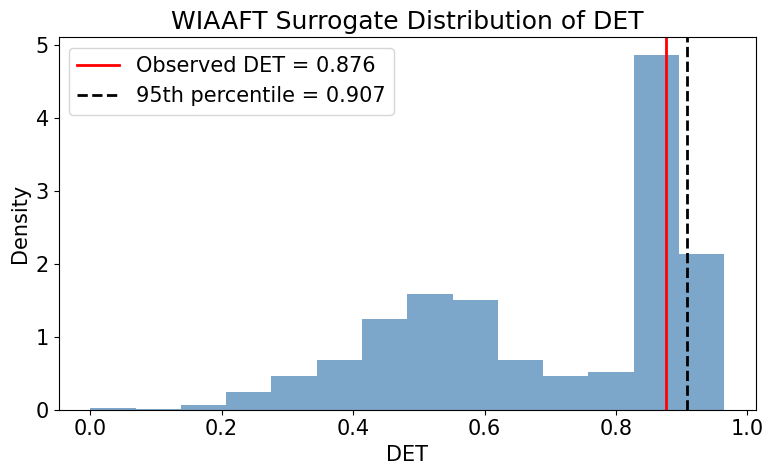

100%|█████████████████████████████████████████| 100/100 [24:18<00:00, 14.59s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8761467889868068 
 Recurrence rate: 0.05001980776047205 
Threshold:1.1103999999998941 
 Laminarity:0.9441433930765146 
Shannon Entropy:1.78961606043295 
Rank-order p-value (det):0.712 
Reject null (det) hypothesis:False

 
 

22
rejection rate:0.22


In [9]:
rejection = 0
for e in tqdm(range(0,100)):
    ar1(e, 0.99)
    os.system("./mutual ar1 -D20 -o files/mutual_ar1 -V0")
    m_site1 = np.loadtxt("files/mutual_ar1", delimiter =' ', usecols =(1) , skiprows=0)
    mn = np.where((m_site1[1:-1] < m_site1[:-2]) & (m_site1[1:-1] < m_site1[2:]))[0] + 1
    if mn.any() > 0:
        t_min=mn[0]
    else:
        t_min=min(m_site1)
    os.system("./false_nearest ar1 -M1,10 -d{} -o files/ar1.fnn -V0".format(t_min))
    res_1 = extract_embedding_dimension("ar1")
    dim = res_1['m']
    print(dim)
    k="ar1"
    det_j=[]
    embed=[]
    det_surro_ff=[]
    kkk=[]
    lam_j=[]
    ent_j=[]
    lam_surro = []
    ent_surro=[]
    s = lcurve(k)
    tt1=0.001
    dimension=dim
    RR_orig = 0
    while RR_orig < 0.05:
        tt1 = tt1 + 0.0001
        det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
    orig_rp=RecurrencePlot(s, dim=dimension , tau=t_min, metric = "euclidean", threshold=tt1, normalize=True, silence_level = 3)
    det_j.append(det)
    embed.append(dim)
    lam_j.append(lam_orig)
    ent_j.append(entr_orig)
    pylab.matshow(matrix)
    pylab.xlabel("$n$")
    pylab.ylabel("$n$")
    pylab.savefig('test_output/PP/PP_RP_{}.eps'.format(dim), format="eps", dpi=650)
    dist_matrix = orig_rp.euclidean_distance_matrix()
    np.fill_diagonal(dist_matrix, np.inf)
    nearest_neighbor_distances = np.min(dist_matrix, axis=1)
    mean_nn_distance = np.mean(nearest_neighbor_distances)
    print(f"Mean Nearest Neighbor Distance: {mean_nn_distance}")
    noise_rad = 0.7*mean_nn_distance
    subprocess.run(["julia", "PP.jl", str(noise_rad), str(dim), str(t_min), "ar1"], text=True, check=True)
    det_ff, lam_ff, entr_ff = sur_test_PP( dim, tt1)
    fig2, axs = plt.subplots(1)
    q95 = np.percentile(det_ff, 95)
    plt.figure(figsize=(8,5))
    plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
    plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
    plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
    plt.xlabel("DET")
    plt.ylabel("Density")
    plt.title("WIAAFT Surrogate Distribution of DET")
    plt.legend()
    plt.tight_layout()
    plt.show()
    fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
    plt.show()
    plt.close() 
    plt.show()
    plt.close()
    r_up = np.sum(det_ff > det)
    r_down = np.sum(det_ff <= det)
    p_rank = min(1.0, 2.0 * ((min(r_up, r_down) + 1) / (999 + 1)))
    alpha = 0.05
    reject_null1 = p_rank < alpha
    print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
    det_surro_ff.append(det_ff)
    kkk.append(np.full(999, dimension))
    lam_surro.append(lam_ff)
    ent_surro.append(entr_ff)
    if reject_null1 == True:
        rejection = rejection + 1
    print(rejection)


print("rejection rate:{}".format(rejection/(e+1)))

# Random Walk

  0%|                                                   | 0/100 [00:00<?, ?it/s]

No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


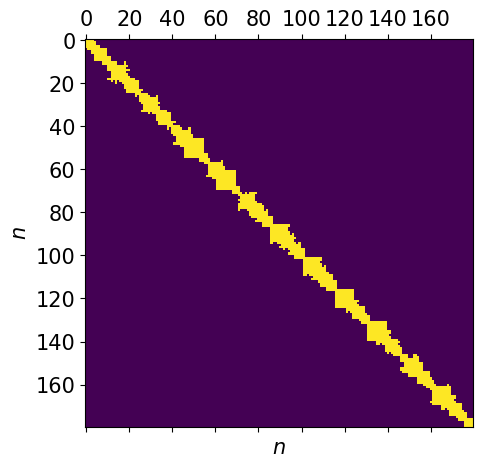

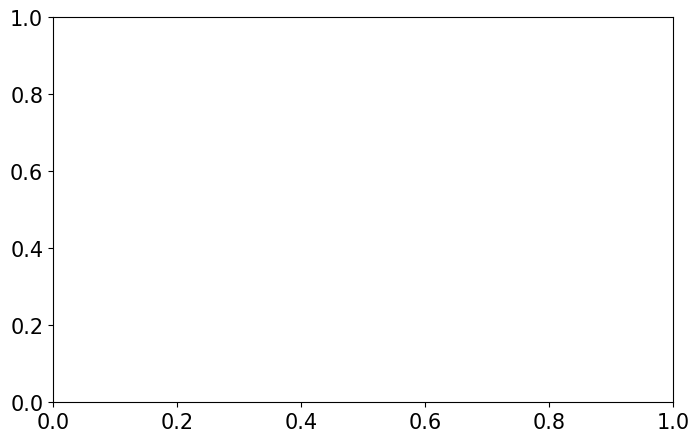

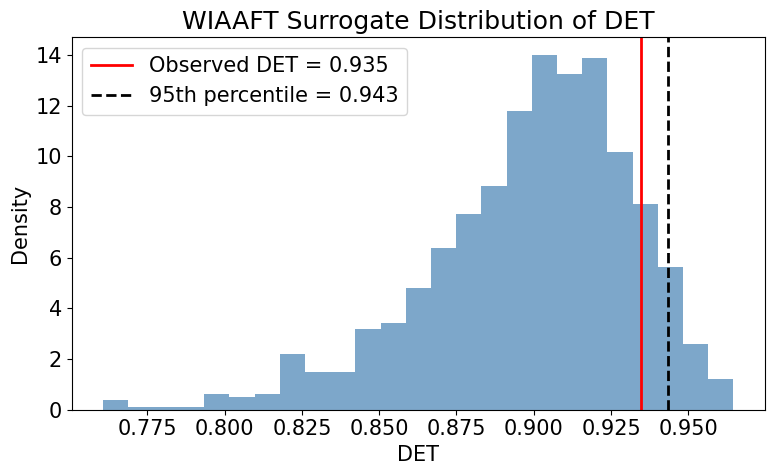

  1%|▍                                          | 1/100 [00:19<32:55, 19.96s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9347222222157312 
 Recurrence rate: 0.05 
Threshold:0.647399999999945 
 Laminarity:0.9864197530803308 
Shannon Entropy:2.2565039060697276 
Rank-order p-value (det):0.113 
Reject null (det) hypothesis:False

 
 

0
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


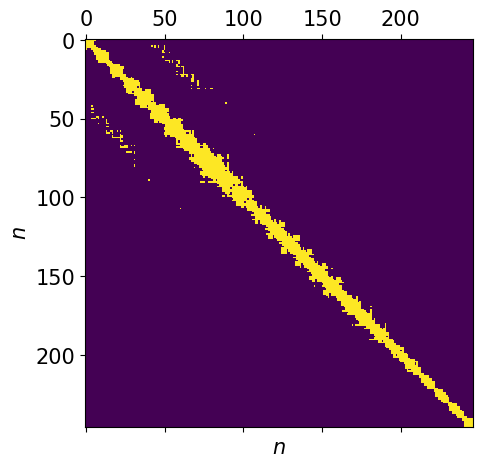

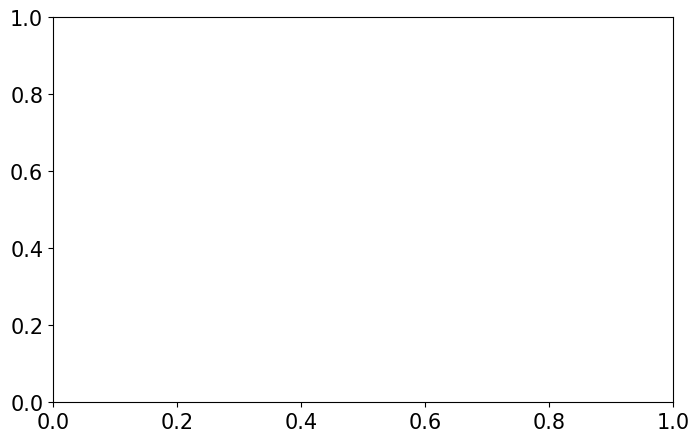

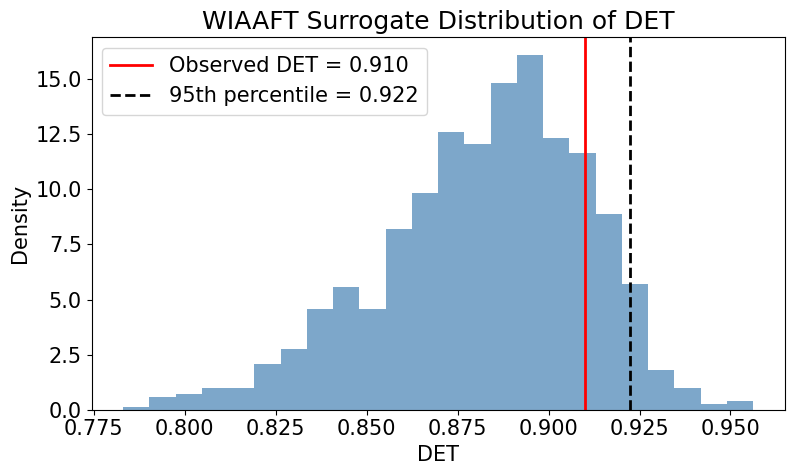

  2%|▊                                          | 2/100 [00:40<33:02, 20.23s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.9100719424427696 
 Recurrence rate: 0.05000330491109789 
Threshold:0.6132999999999488 
 Laminarity:0.9600132187674818 
Shannon Entropy:2.0851079821344096 
Rank-order p-value (det):0.157 
Reject null (det) hypothesis:False

 
 

0
Visible Saturation Plateau
6
WIAAFT surrogate datasets generated


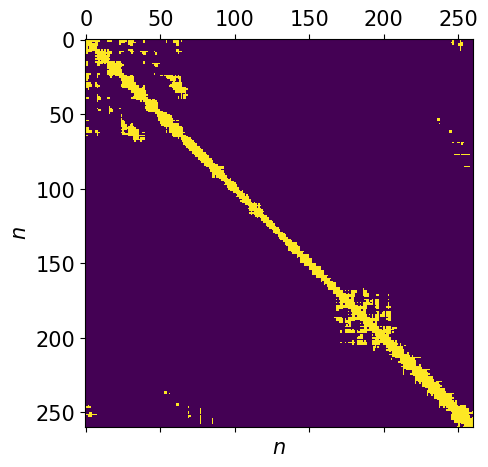

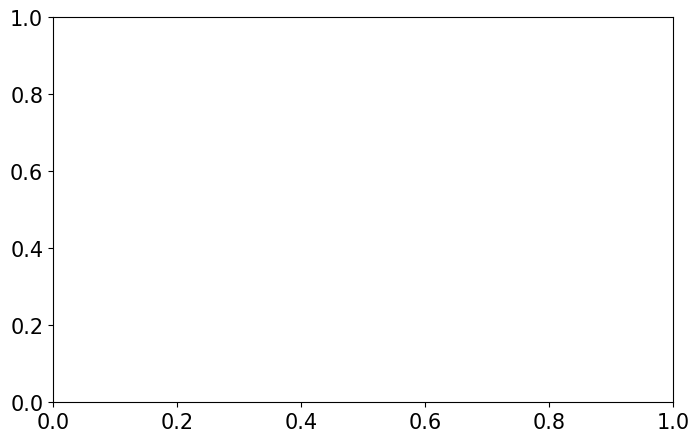

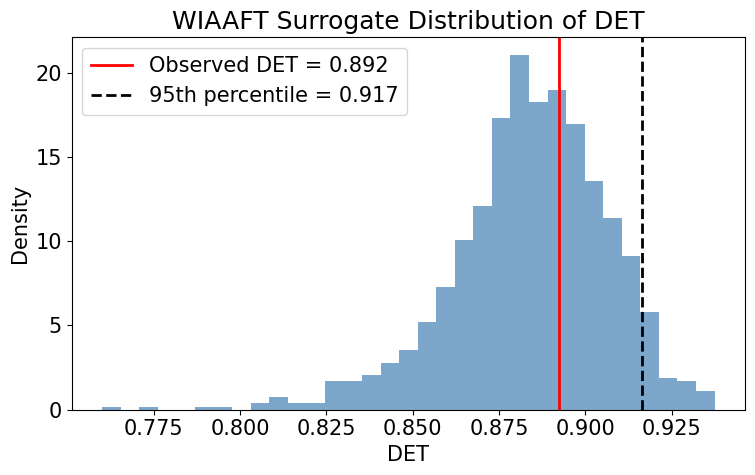

  3%|█▎                                         | 3/100 [01:03<35:03, 21.69s/it]

RQA  ar1 Embedding dimensions:6 
 DET of original:0.8923076923048324 
 Recurrence rate: 0.05 
Threshold:0.9840999999999079 
 Laminarity:0.9446745562102229 
Shannon Entropy:1.639222846379516 
Rank-order p-value (det):0.367 
Reject null (det) hypothesis:False

 
 

0
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


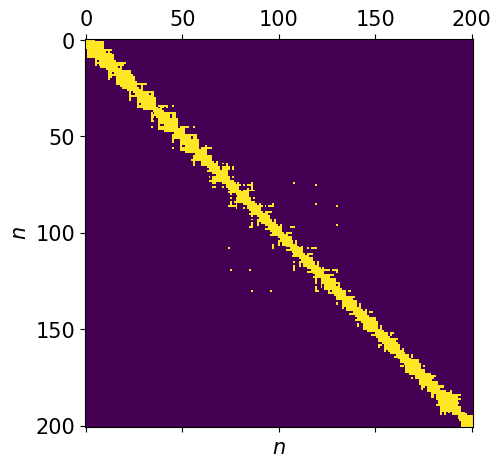

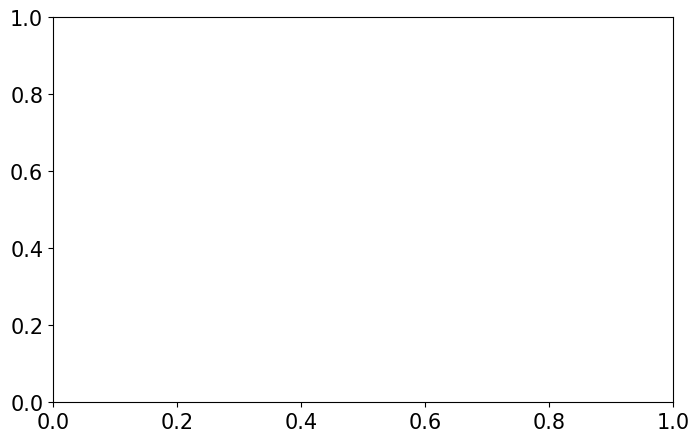

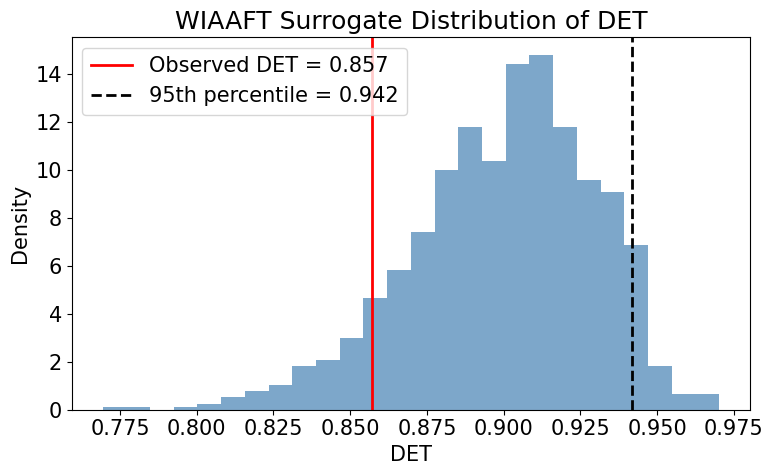

  4%|█▋                                         | 4/100 [01:26<35:08, 21.96s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8571428571381476 
 Recurrence rate: 0.050023514269448774 
Threshold:1.338399999999869 
 Laminarity:0.938149430970123 
Shannon Entropy:1.8908331434592147 
Rank-order p-value (det):0.913 
Reject null (det) hypothesis:False

 
 

0
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


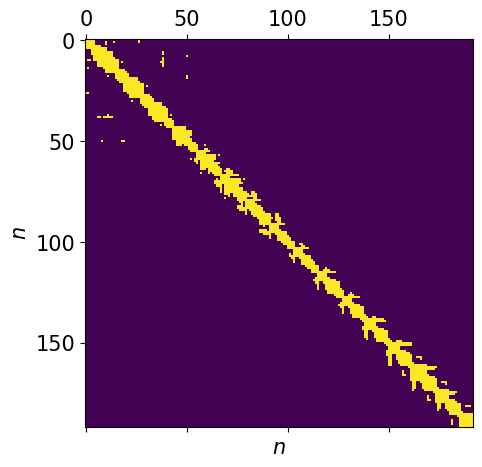

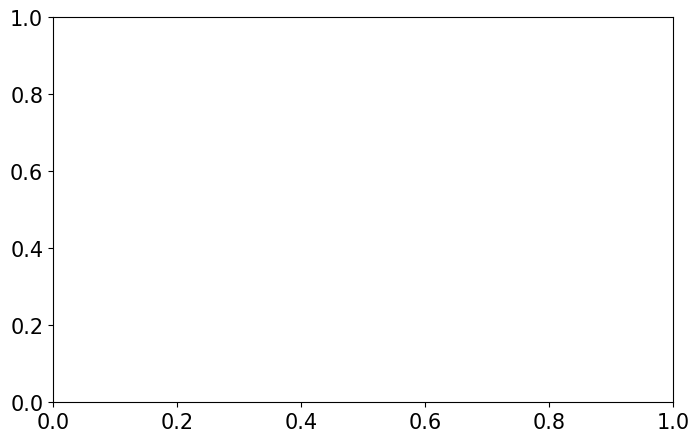

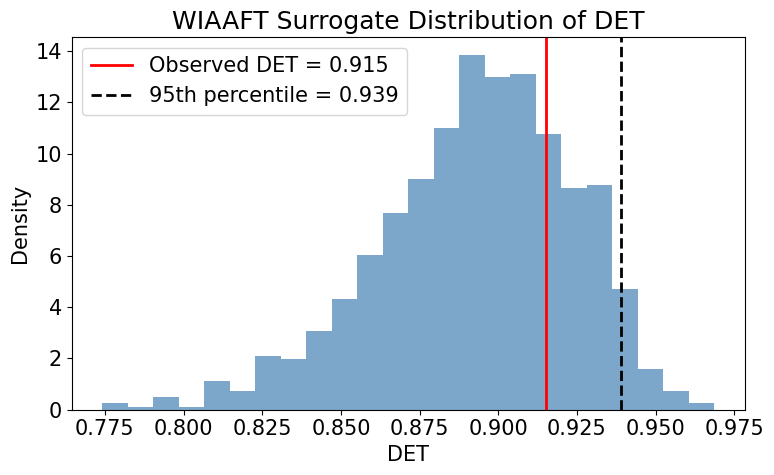

  5%|██▏                                        | 5/100 [01:46<34:06, 21.54s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9152542372825954 
 Recurrence rate: 0.05002170138888889 
Threshold:0.8300999999999249 
 Laminarity:0.9647505422941175 
Shannon Entropy:1.7568700551984886 
Rank-order p-value (det):0.253 
Reject null (det) hypothesis:False

 
 

0
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


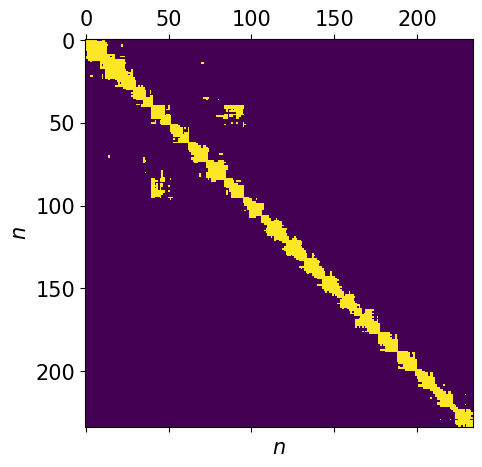

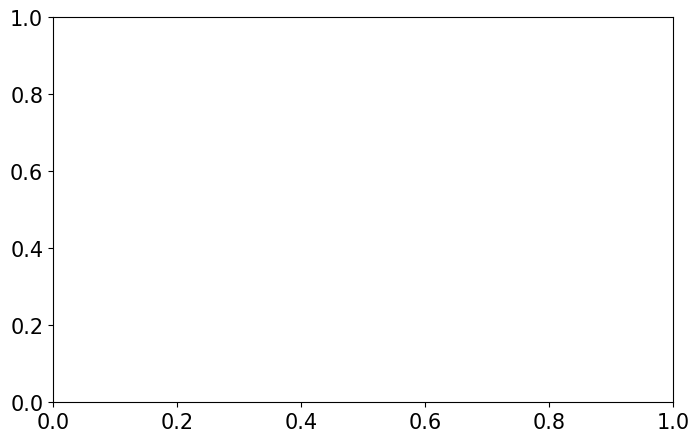

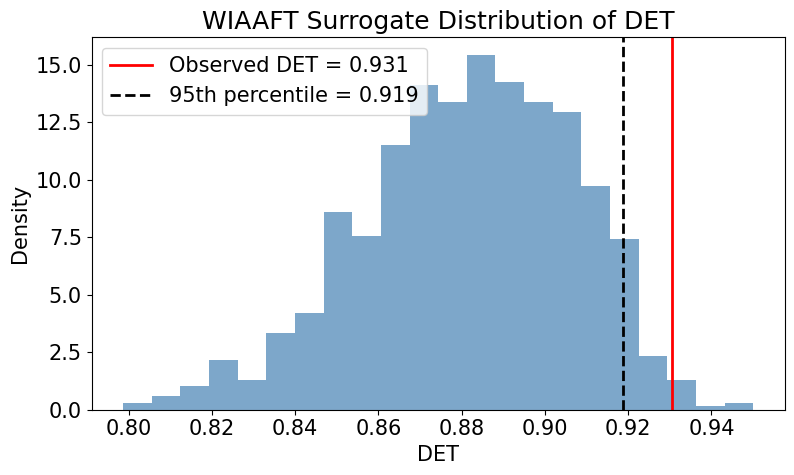

  6%|██▌                                        | 6/100 [02:08<33:52, 21.62s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.9305111821049101 
 Recurrence rate: 0.05000365256775513 
Threshold:1.0649999999998991 
 Laminarity:0.9642074506904157 
Shannon Entropy:2.16011305060796 
Rank-order p-value (det):0.012 
Reject null (det) hypothesis:True

 
 

1
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


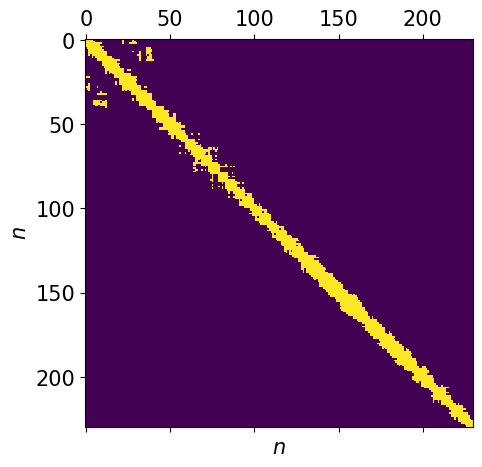

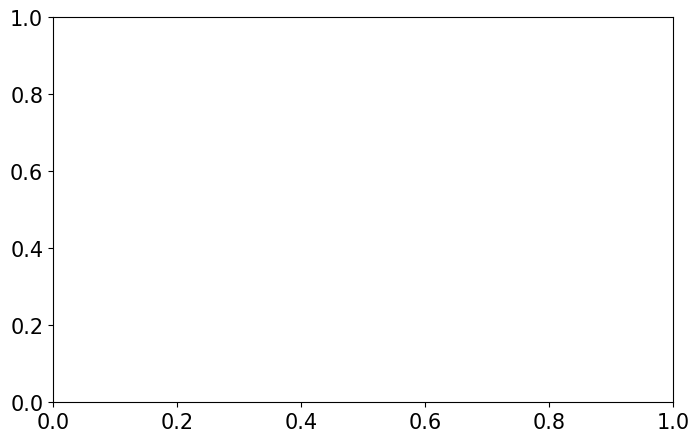

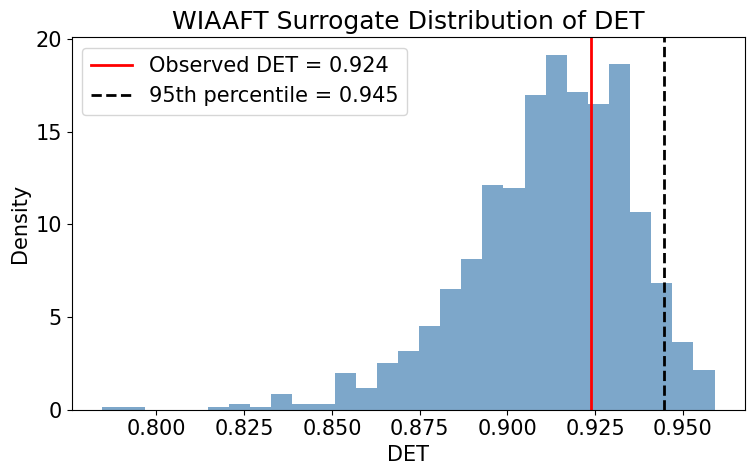

  7%|███                                        | 7/100 [02:30<33:39, 21.72s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9239040529324901 
 Recurrence rate: 0.05005671077504726 
Threshold:0.7623999999999324 
 Laminarity:0.9645015105703758 
Shannon Entropy:2.1371252266076985 
Rank-order p-value (det):0.337 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


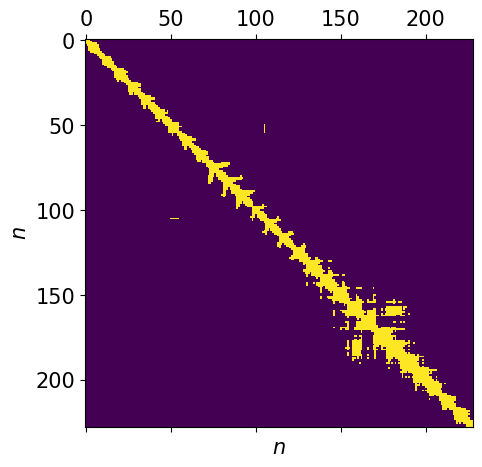

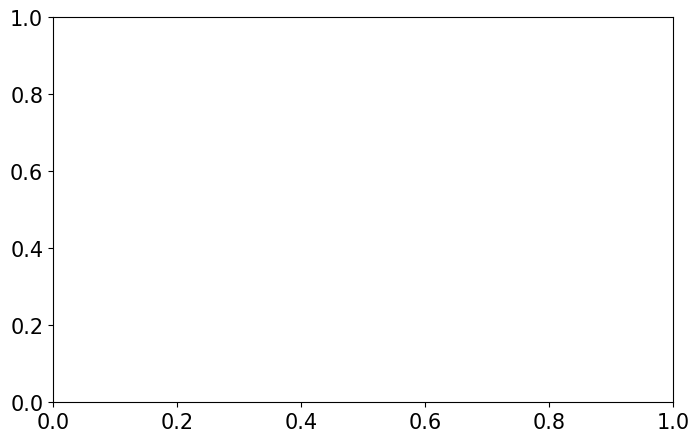

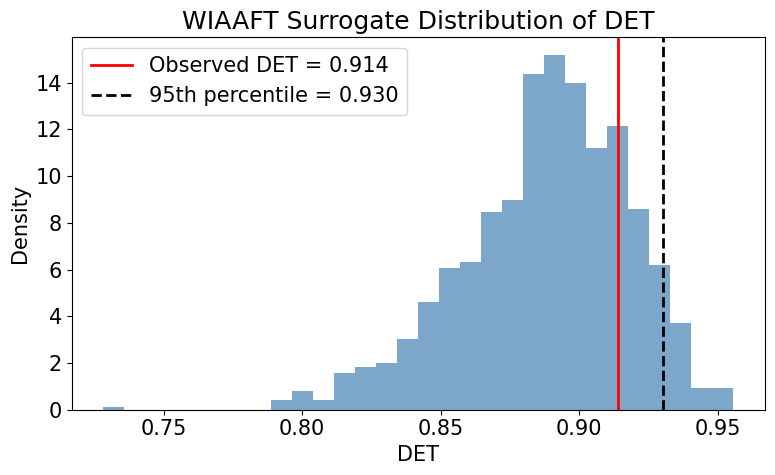

  8%|███▍                                       | 8/100 [02:54<34:30, 22.50s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9139966273148652 
 Recurrence rate: 0.05001538935056941 
Threshold:1.1716999999998874 
 Laminarity:0.9530769230732574 
Shannon Entropy:1.7503675388677198 
Rank-order p-value (det):0.203 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


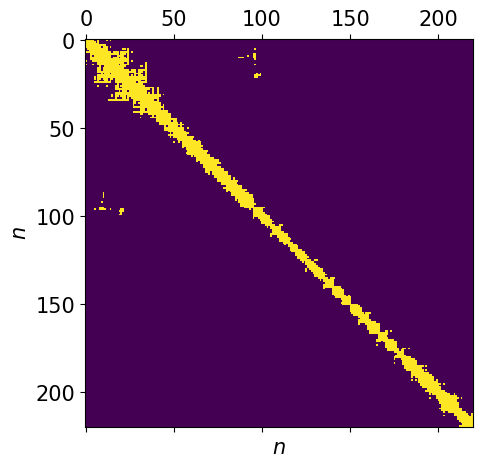

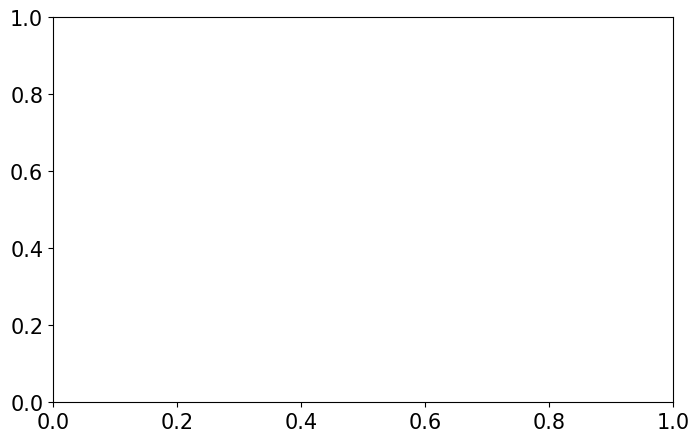

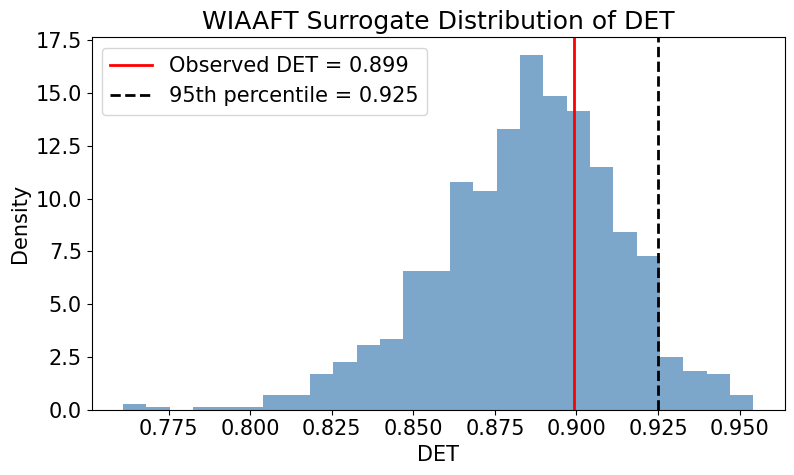

  9%|███▊                                       | 9/100 [03:21<36:06, 23.80s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8990909090868223 
 Recurrence rate: 0.05 
Threshold:1.5790999999998425 
 Laminarity:0.9512396694175569 
Shannon Entropy:2.067513313159867 
Rank-order p-value (det):0.303 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


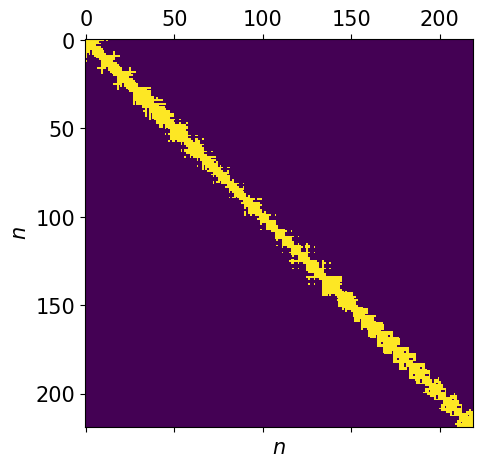

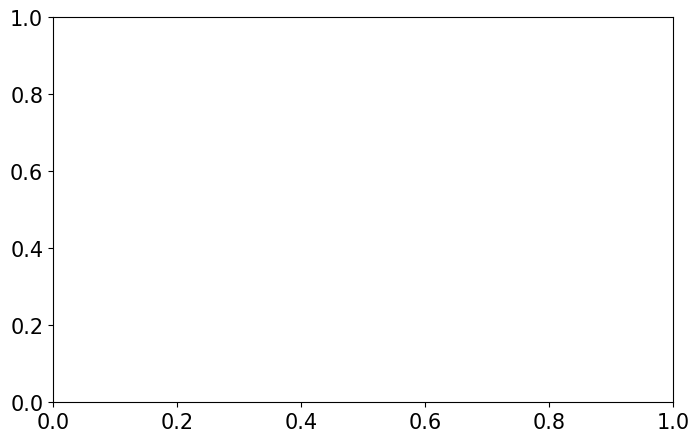

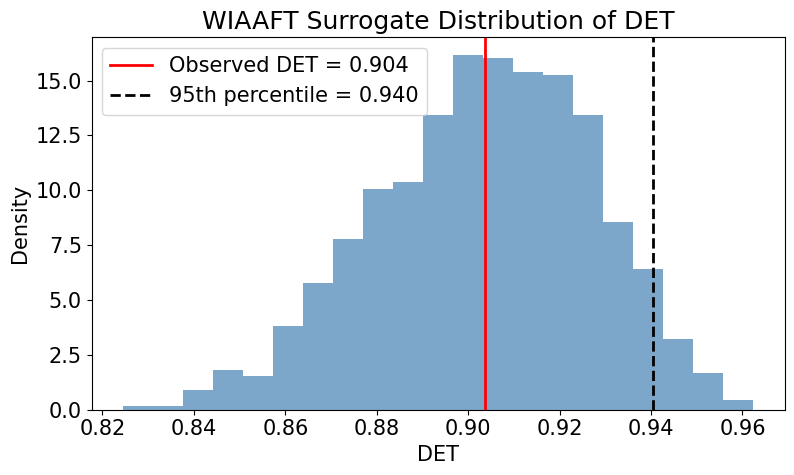

 10%|████▏                                     | 10/100 [03:45<35:47, 23.86s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.903669724766497 
 Recurrence rate: 0.05001980776047205 
Threshold:1.1776999999998867 
 Laminarity:0.9549812421802627 
Shannon Entropy:1.8556398499952342 
Rank-order p-value (det):0.519 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


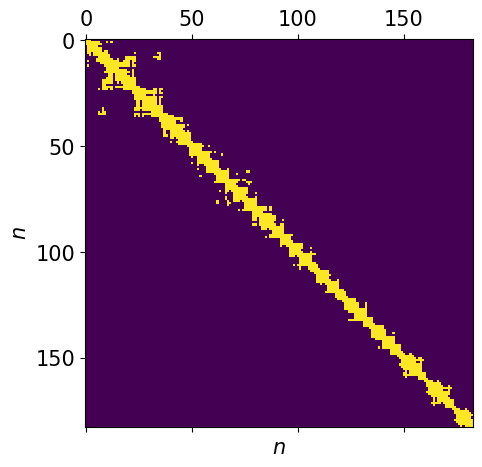

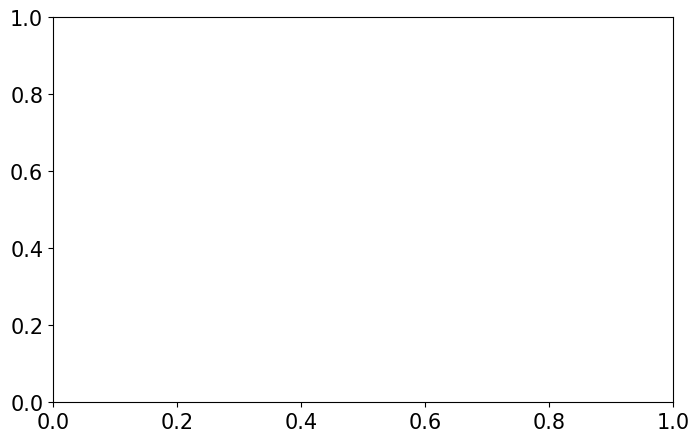

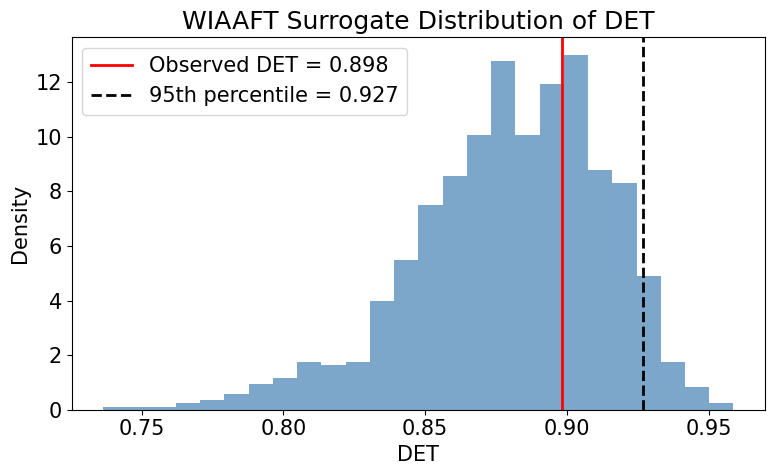

 11%|████▌                                     | 11/100 [04:04<33:22, 22.50s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8981233243907634 
 Recurrence rate: 0.05001642330317418 
Threshold:0.6416999999999456 
 Laminarity:0.949850746262986 
Shannon Entropy:1.2900448236166029 
Rank-order p-value (det):0.335 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


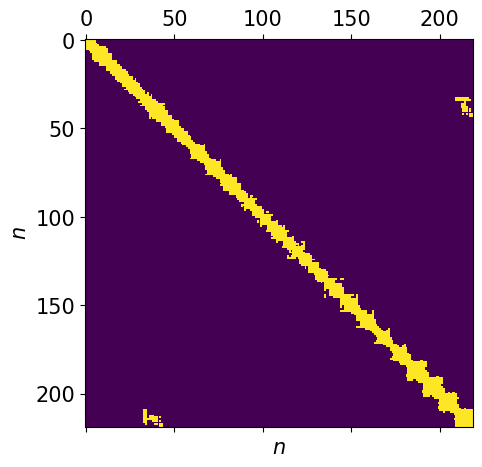

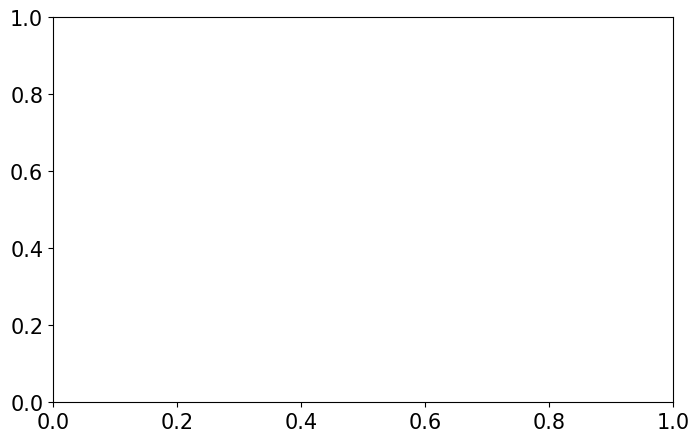

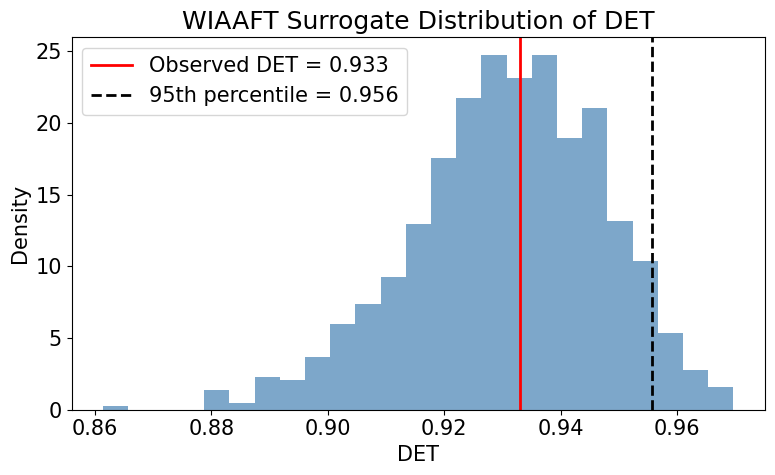

 12%|█████                                     | 12/100 [04:30<34:13, 23.34s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9330275229314999 
 Recurrence rate: 0.05001980776047205 
Threshold:1.60159999999984 
 Laminarity:0.9808253438892004 
Shannon Entropy:2.071170616050058 
Rank-order p-value (det):0.465 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


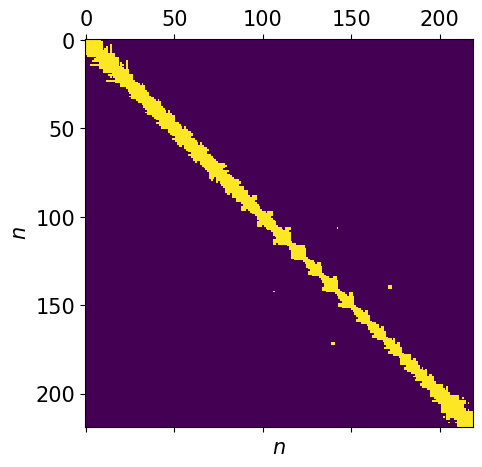

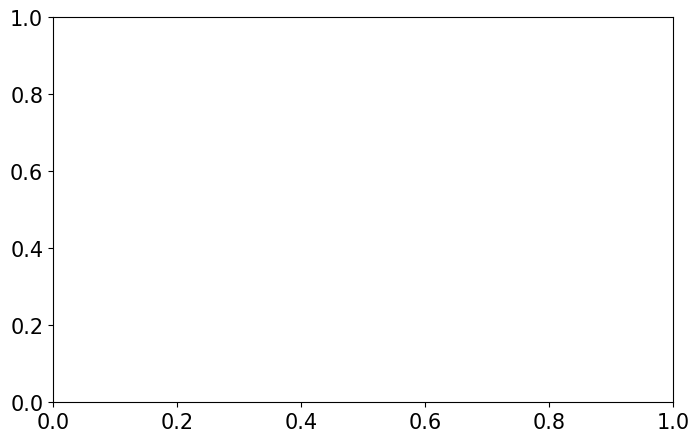

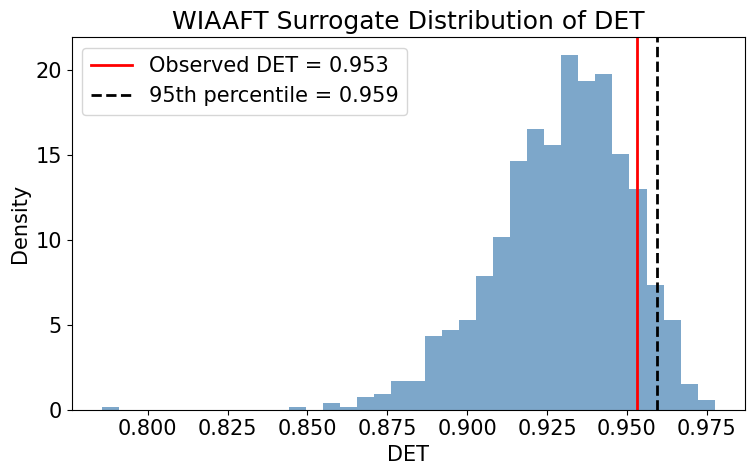

 13%|█████▍                                    | 13/100 [04:55<34:49, 24.02s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9532538955043389 
 Recurrence rate: 0.05006150830883426 
Threshold:1.4486999999998569 
 Laminarity:0.9850062473928155 
Shannon Entropy:1.955466786942281 
Rank-order p-value (det):0.11 
Reject null (det) hypothesis:False

 
 

1
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


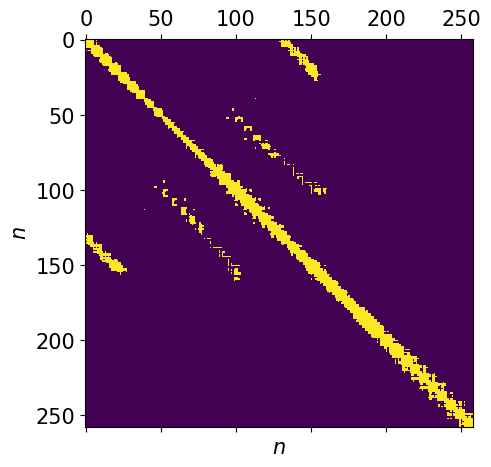

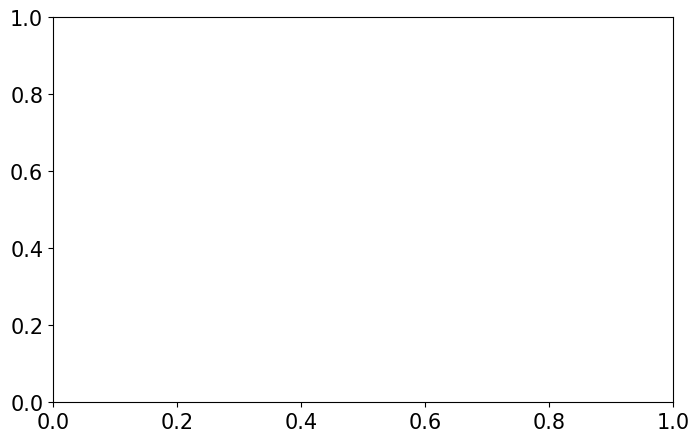

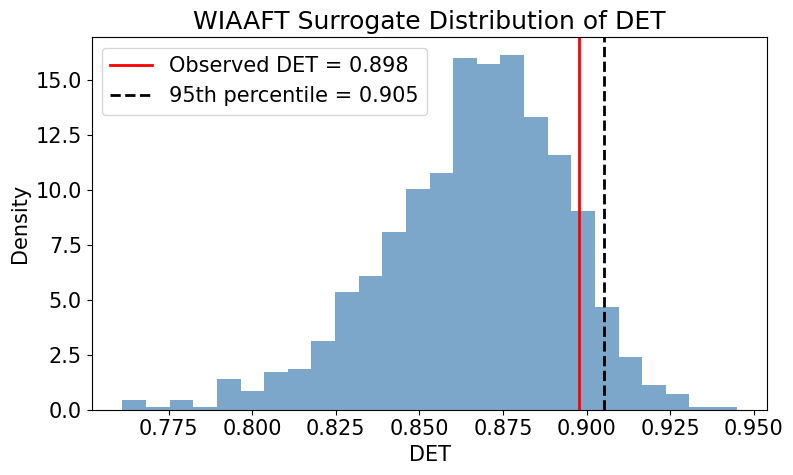

 14%|█████▉                                    | 14/100 [05:17<33:17, 23.23s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.8977864583304109 
 Recurrence rate: 0.050027041644131964 
Threshold:0.8003999999999282 
 Laminarity:0.9486486486457999 
Shannon Entropy:1.8238682770337196 
Rank-order p-value (det):0.113 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


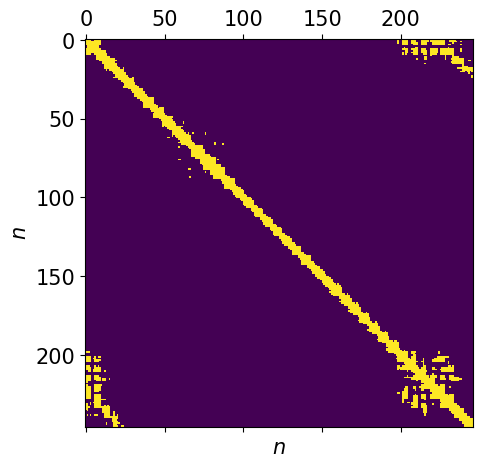

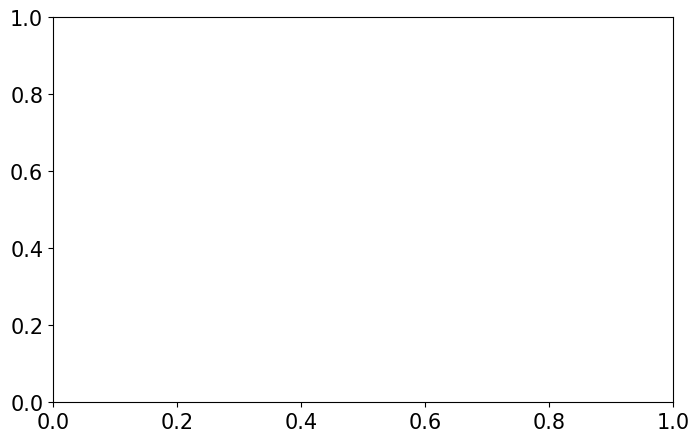

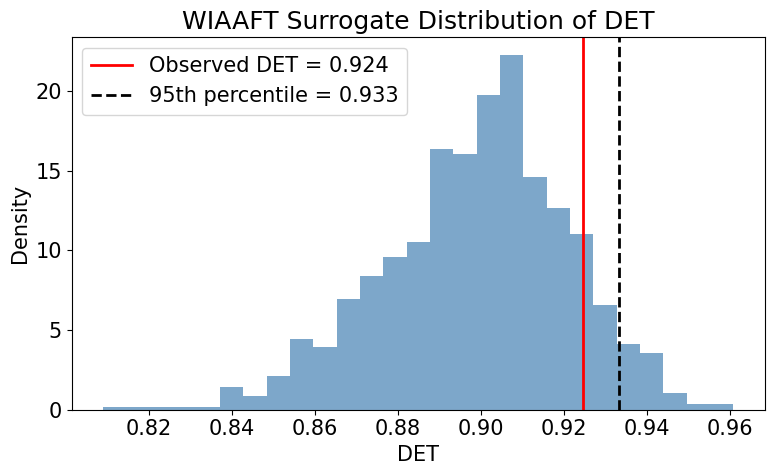

 15%|██████▎                                   | 15/100 [05:44<34:44, 24.53s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.924460431651351 
 Recurrence rate: 0.05000330491109789 
Threshold:1.5499999999998457 
 Laminarity:0.9695968274918387 
Shannon Entropy:1.50303316365287 
Rank-order p-value (det):0.114 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


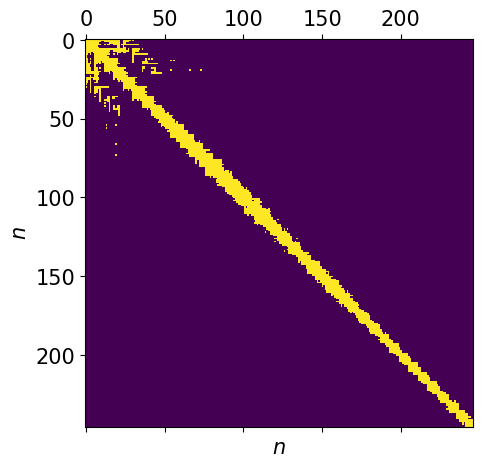

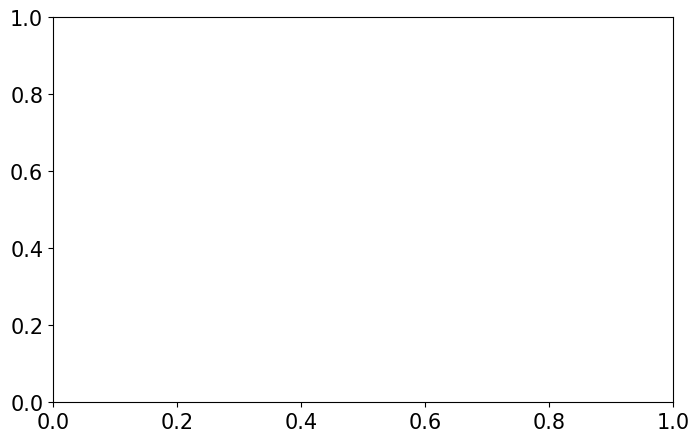

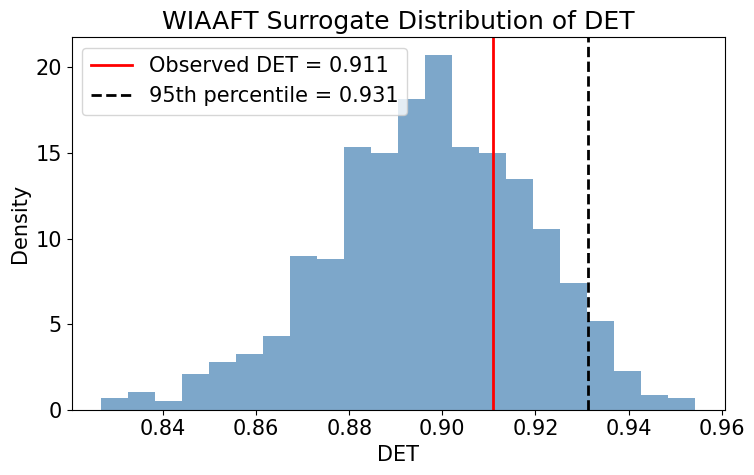

 16%|██████▋                                   | 16/100 [06:08<34:07, 24.38s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9108554996372723 
 Recurrence rate: 0.050036354022076804 
Threshold:1.0863999999998968 
 Laminarity:0.9610303830879755 
Shannon Entropy:1.711511423324801 
Rank-order p-value (det):0.283 
Reject null (det) hypothesis:False

 
 

1
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


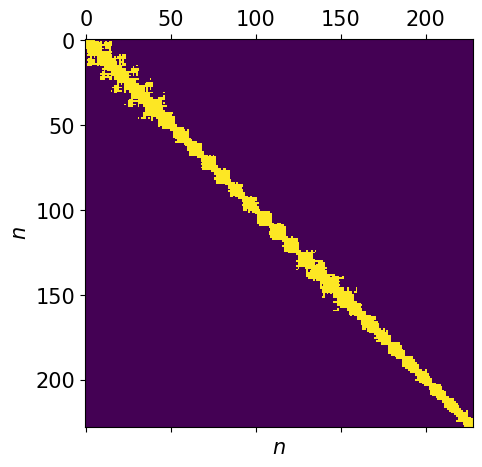

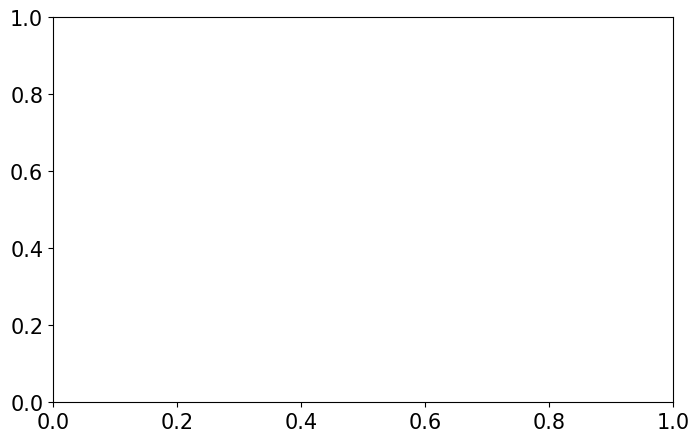

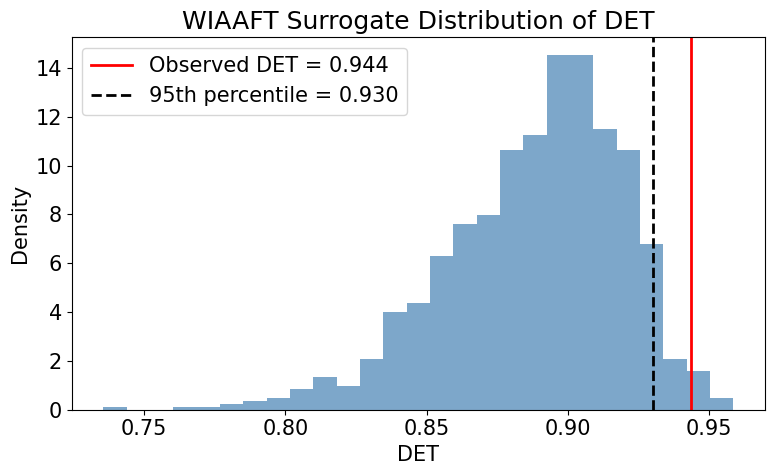

 17%|███████▏                                  | 17/100 [06:30<32:32, 23.52s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.943507588528906 
 Recurrence rate: 0.05001538935056941 
Threshold:0.5427999999999565 
 Laminarity:0.9723076923039528 
Shannon Entropy:1.9545942110383638 
Rank-order p-value (det):0.015 
Reject null (det) hypothesis:True

 
 

2
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


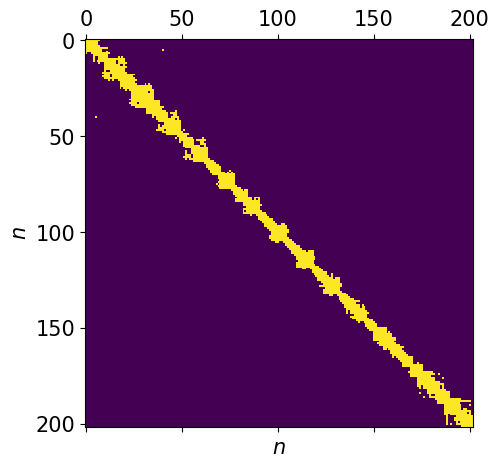

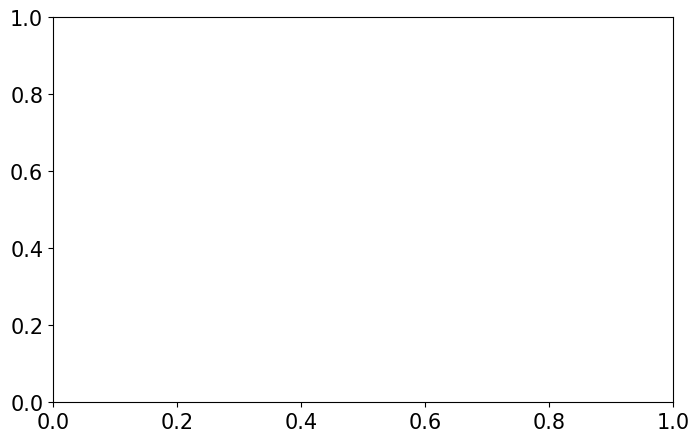

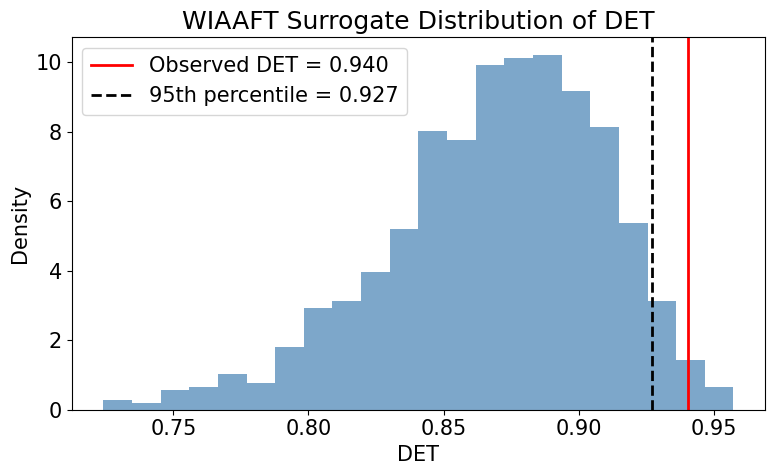

 18%|███████▌                                  | 18/100 [06:49<30:32, 22.35s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.940217391299238 
 Recurrence rate: 0.05004411332222331 
Threshold:0.5405999999999568 
 Laminarity:0.9681684622871295 
Shannon Entropy:1.9217021190962327 
Rank-order p-value (det):0.013 
Reject null (det) hypothesis:True

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


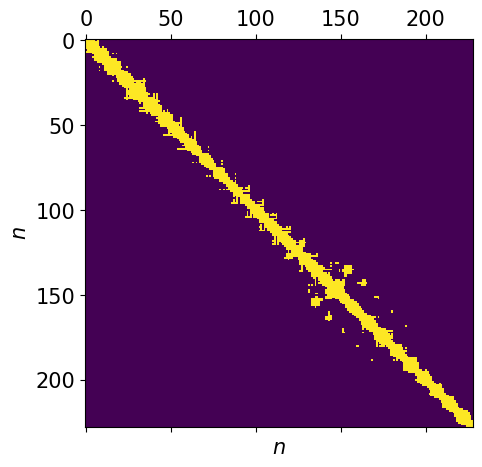

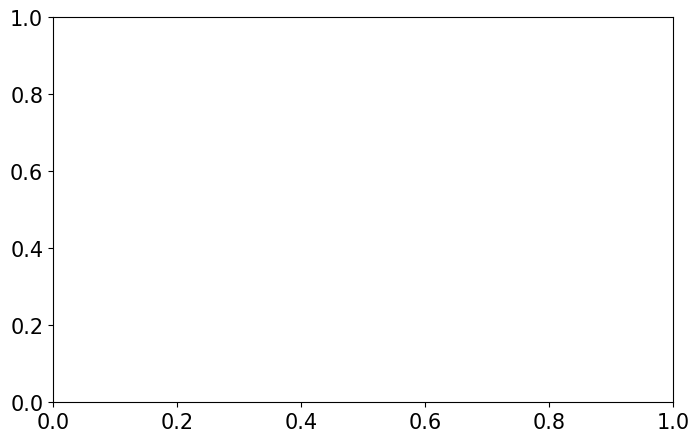

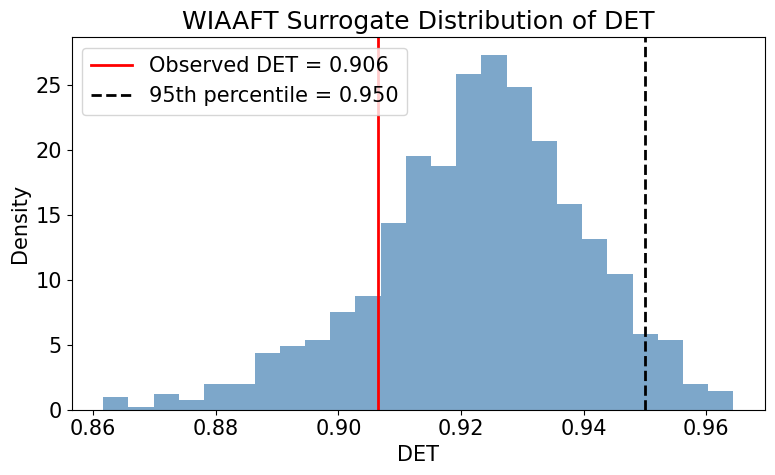

 19%|███████▉                                  | 19/100 [07:17<32:29, 24.07s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9064080944312547 
 Recurrence rate: 0.05001538935056941 
Threshold:2.0934999999999935 
 Laminarity:0.9542307692270992 
Shannon Entropy:2.0246054462028336 
Rank-order p-value (det):0.849 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


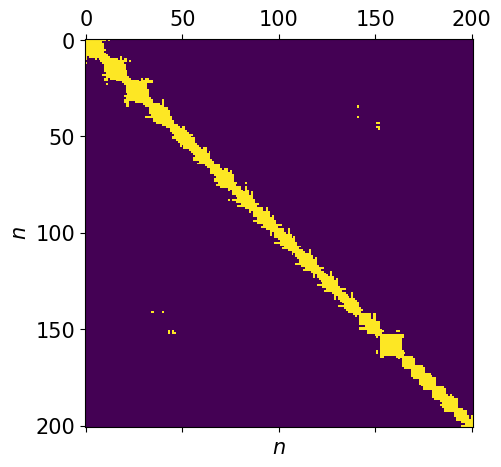

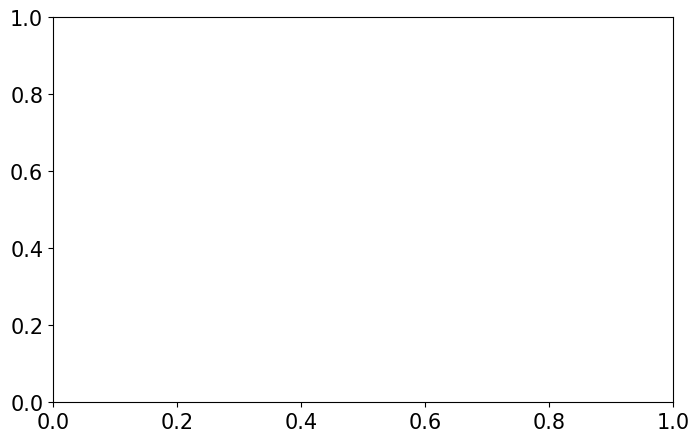

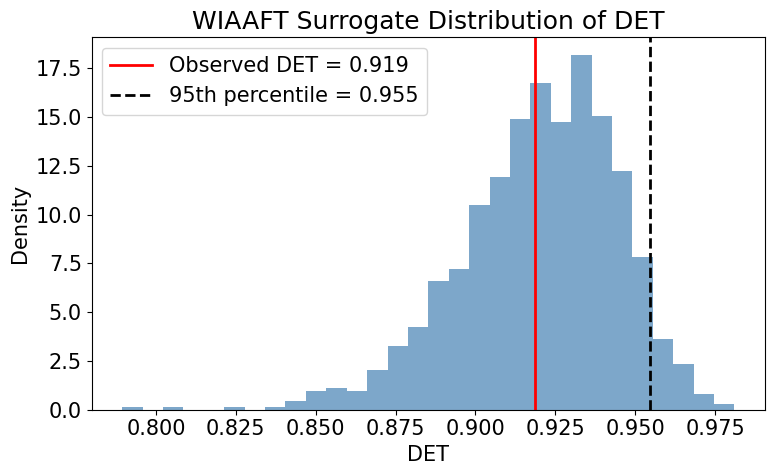

 20%|████████▍                                 | 20/100 [07:42<32:17, 24.22s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.918681318676271 
 Recurrence rate: 0.050023514269448774 
Threshold:1.455799999999856 
 Laminarity:0.9683325086542883 
Shannon Entropy:2.1289002541066306 
Rank-order p-value (det):0.567 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


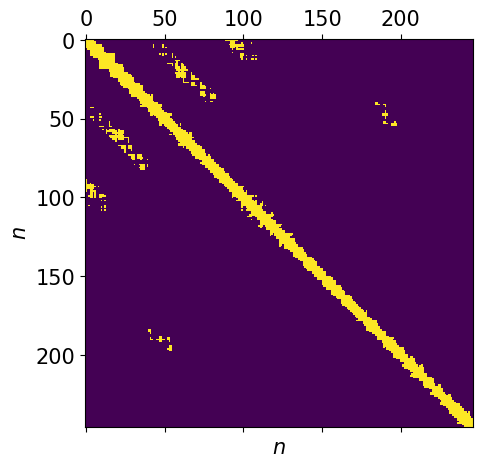

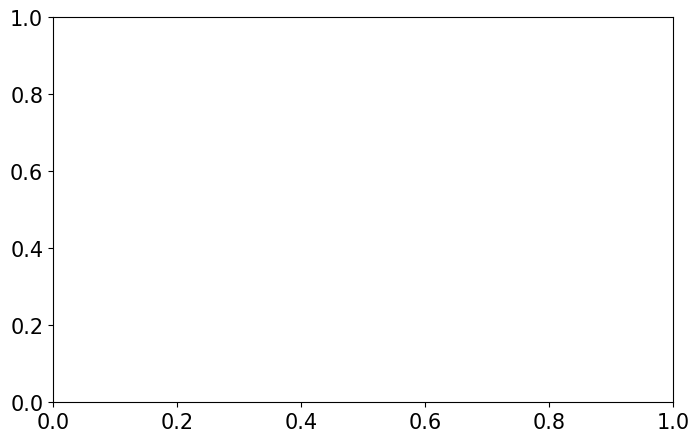

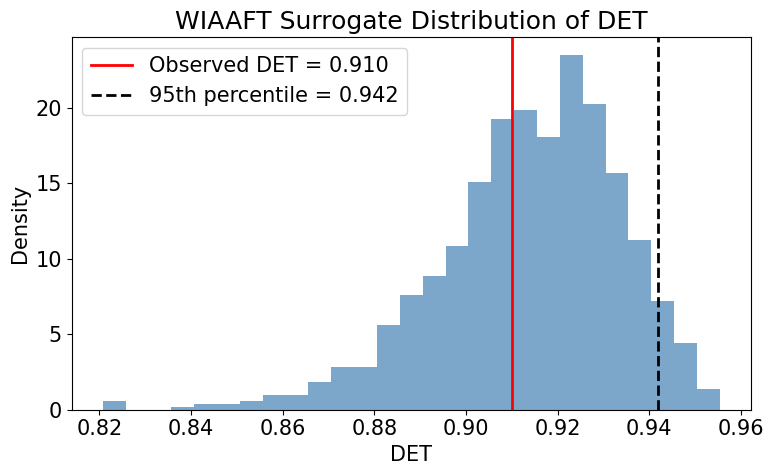

 21%|████████▊                                 | 21/100 [08:09<32:50, 24.94s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9100719424427696 
 Recurrence rate: 0.05000330491109789 
Threshold:1.429799999999859 
 Laminarity:0.9623265036319818 
Shannon Entropy:1.6209715558238977 
Rank-order p-value (det):0.624 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


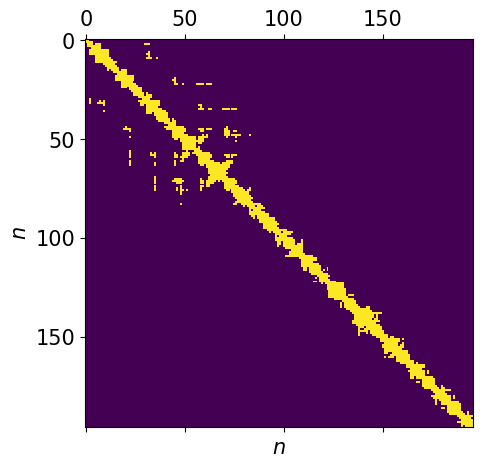

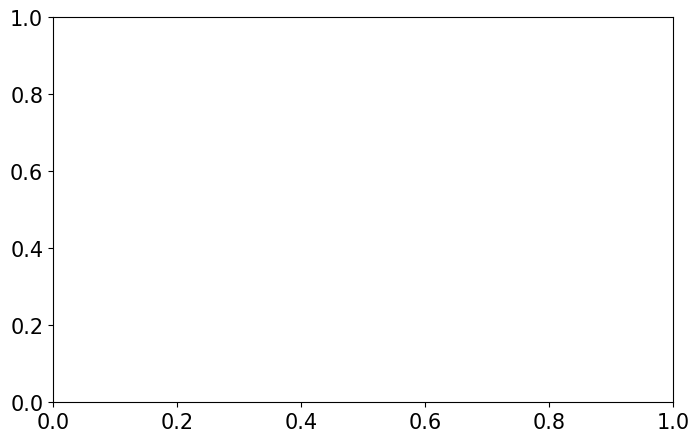

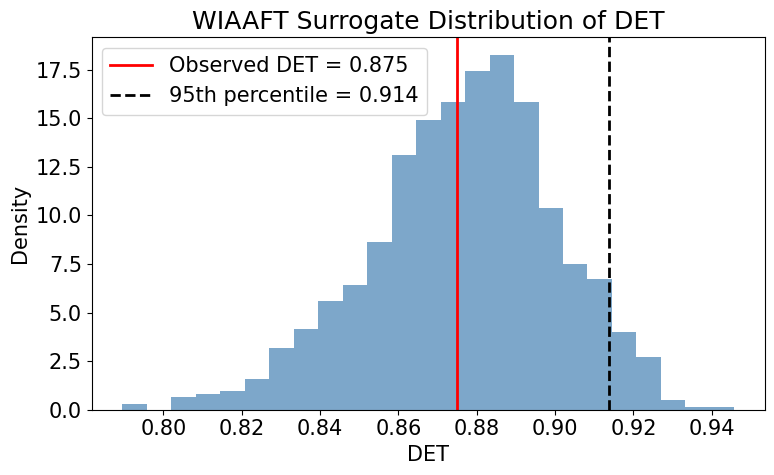

 22%|█████████▏                                | 22/100 [08:29<30:44, 23.65s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8748551564259859 
 Recurrence rate: 0.05003123698458976 
Threshold:1.0804999999998974 
 Laminarity:0.945889698226088 
Shannon Entropy:1.6620387877505738 
Rank-order p-value (det):0.566 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


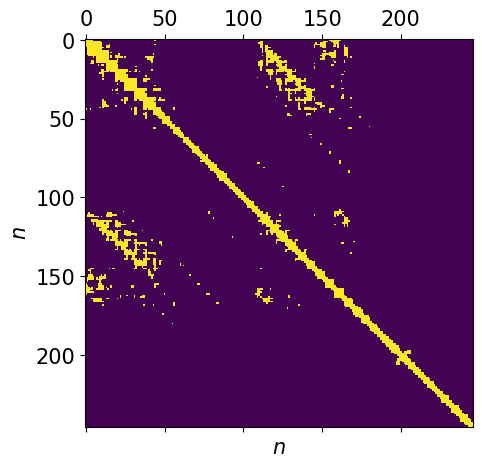

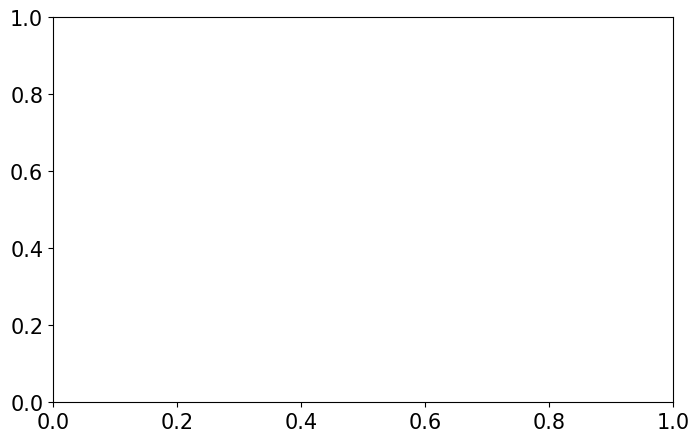

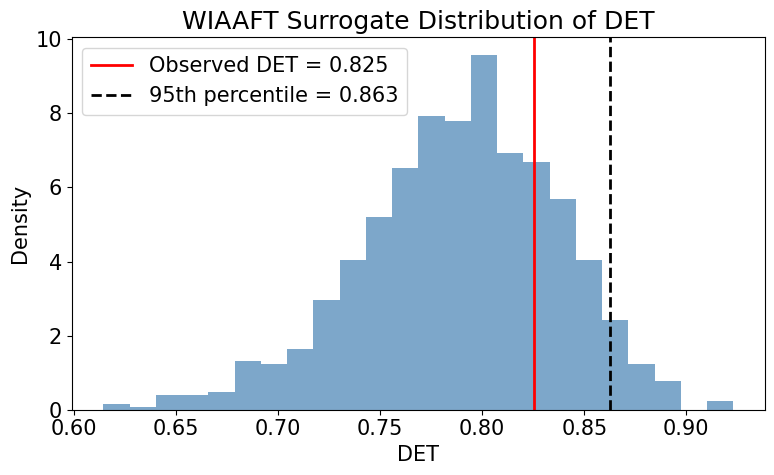

 23%|█████████▋                                | 23/100 [08:56<31:42, 24.71s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8251798561121396 
 Recurrence rate: 0.05000330491109789 
Threshold:1.456399999999856 
 Laminarity:0.9153998678092684 
Shannon Entropy:1.3934790335242626 
Rank-order p-value (det):0.238 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


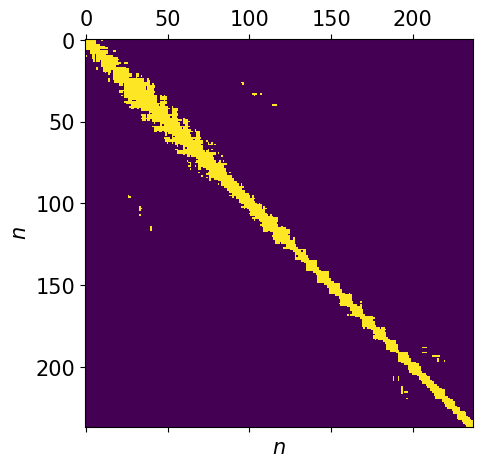

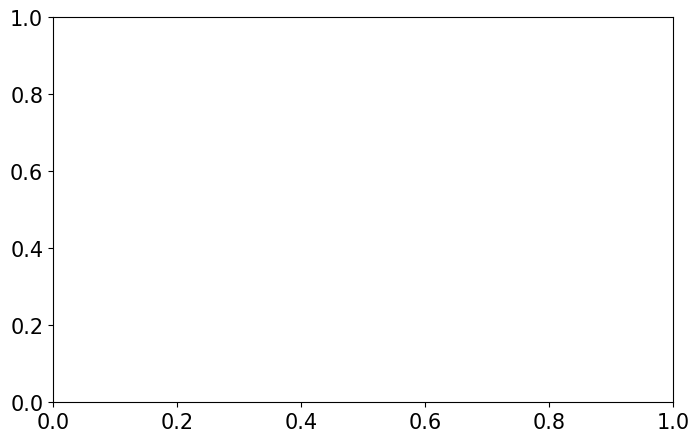

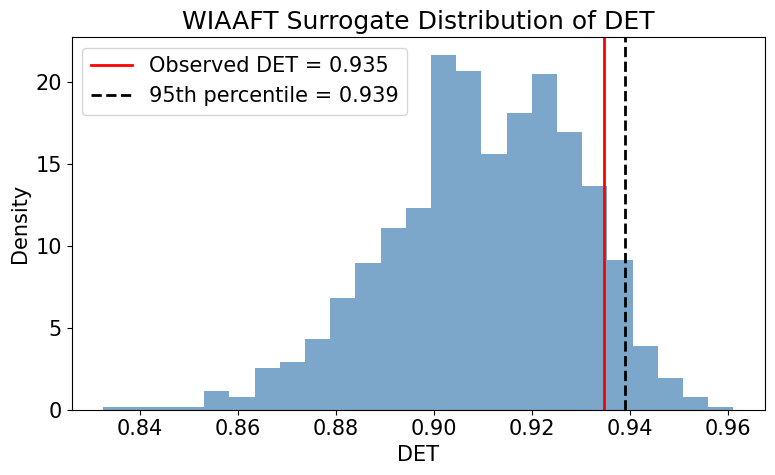

 24%|██████████                                | 24/100 [09:21<31:07, 24.57s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9346811819559305 
 Recurrence rate: 0.050009791878082216 
Threshold:1.2541999999998783 
 Laminarity:0.9647561409720016 
Shannon Entropy:1.8500755401703175 
Rank-order p-value (det):0.088 
Reject null (det) hypothesis:False

 
 

3
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


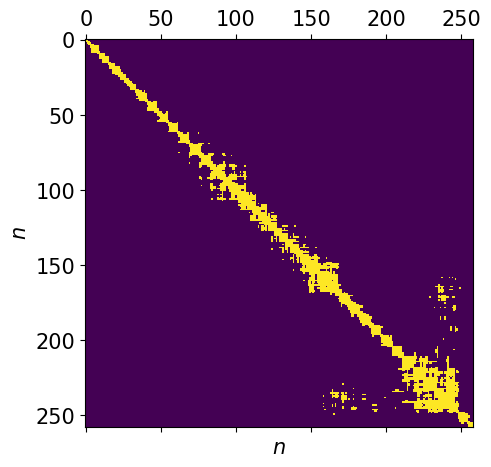

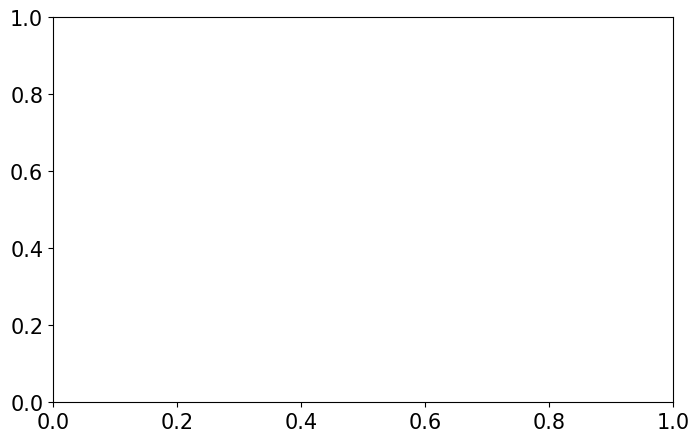

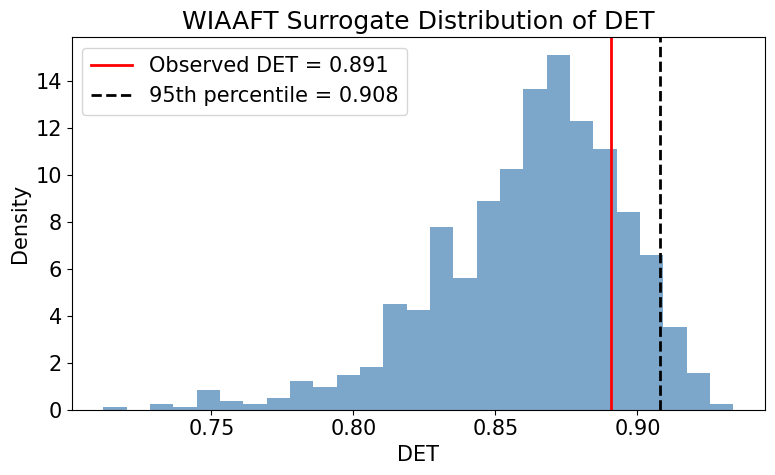

 25%|██████████▌                               | 25/100 [09:43<29:46, 23.82s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8906249999971009 
 Recurrence rate: 0.050027041644131964 
Threshold:0.8613999999999215 
 Laminarity:0.9402402402374167 
Shannon Entropy:1.8624922408824647 
Rank-order p-value (det):0.185 
Reject null (det) hypothesis:False

 
 

3
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


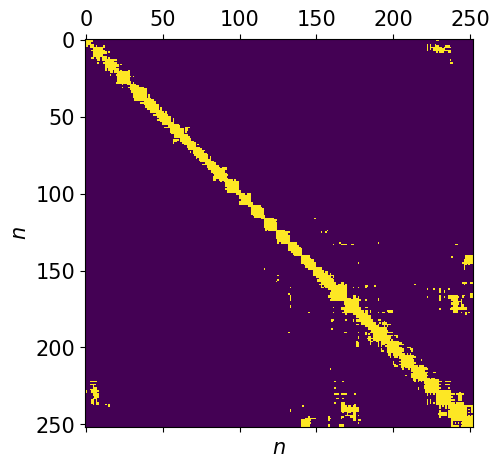

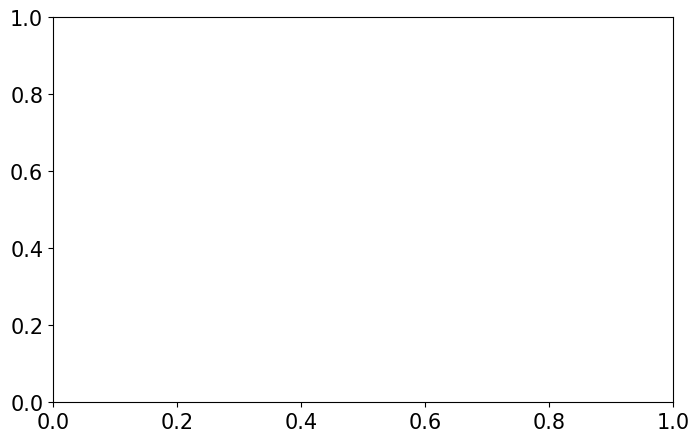

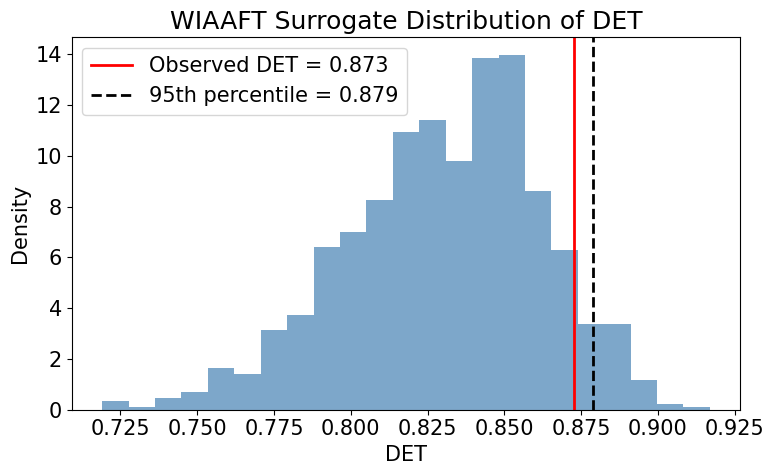

 26%|██████████▉                               | 26/100 [10:07<29:40, 24.06s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8727770177808729 
 Recurrence rate: 0.05001259763164525 
Threshold:1.2444999999998794 
 Laminarity:0.9310453400474463 
Shannon Entropy:1.9403210964324458 
Rank-order p-value (det):0.075 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


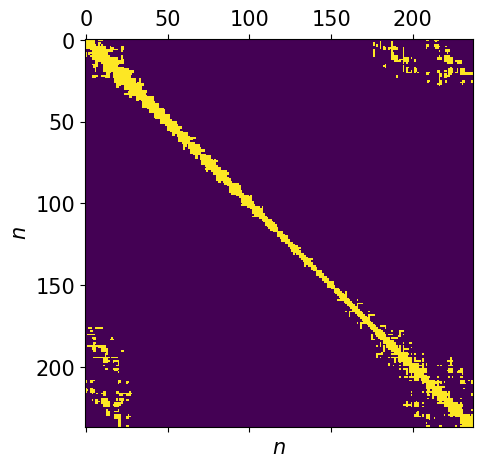

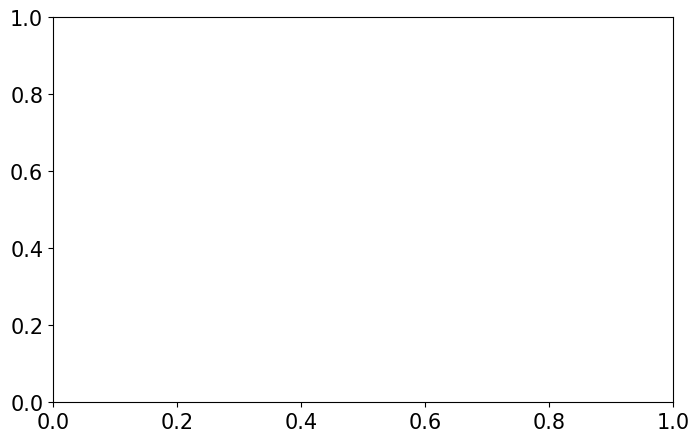

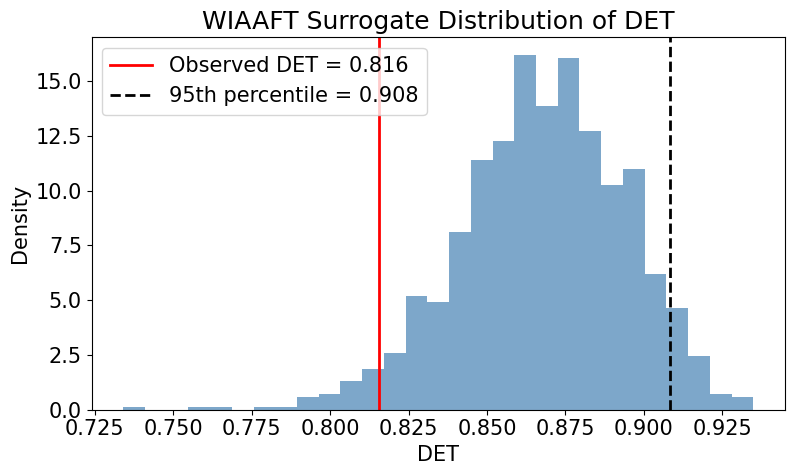

 27%|███████████▎                              | 27/100 [10:35<30:25, 25.01s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8157076205256 
 Recurrence rate: 0.050009791878082216 
Threshold:1.6520999999998345 
 Laminarity:0.9184763260914259 
Shannon Entropy:1.5649242505812508 
Rank-order p-value (det):0.969 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


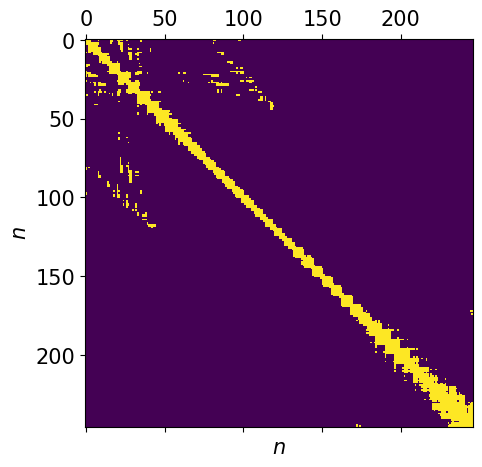

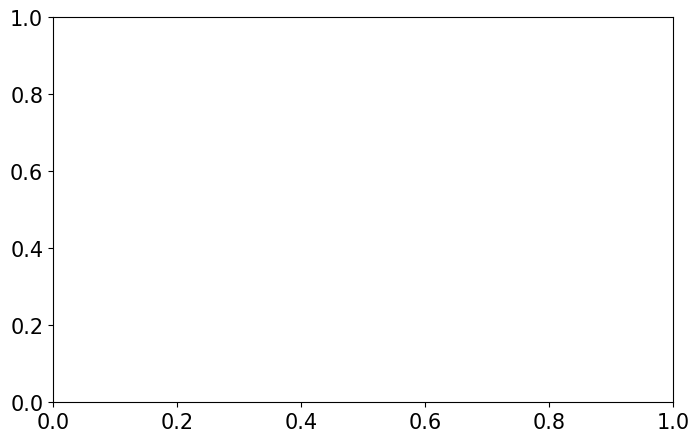

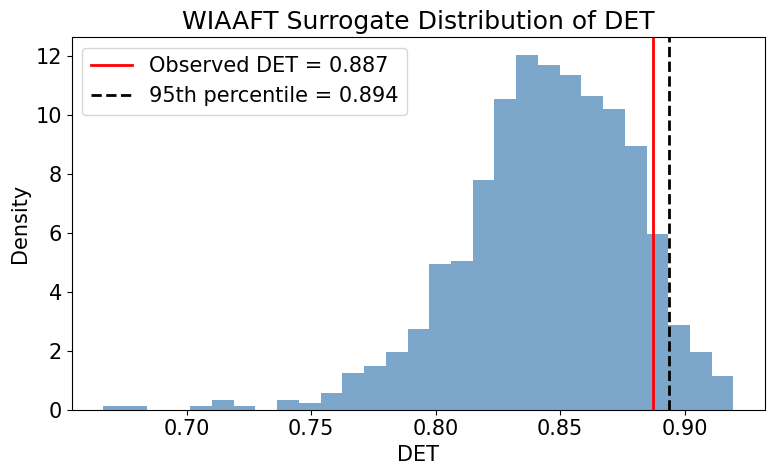

 28%|███████████▊                              | 28/100 [10:59<29:57, 24.97s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8871315600255675 
 Recurrence rate: 0.050036354022076804 
Threshold:1.2687999999998767 
 Laminarity:0.9435270805781257 
Shannon Entropy:1.5828347968018062 
Rank-order p-value (det):0.089 
Reject null (det) hypothesis:False

 
 

3
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


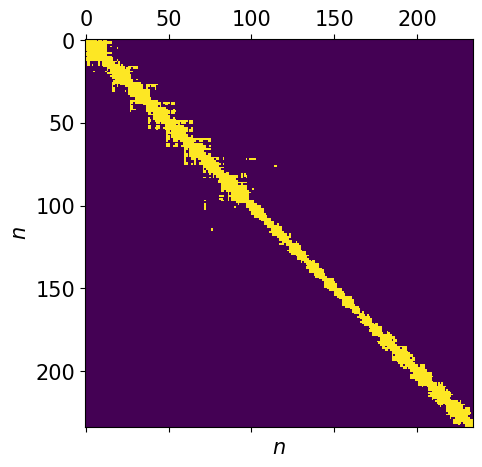

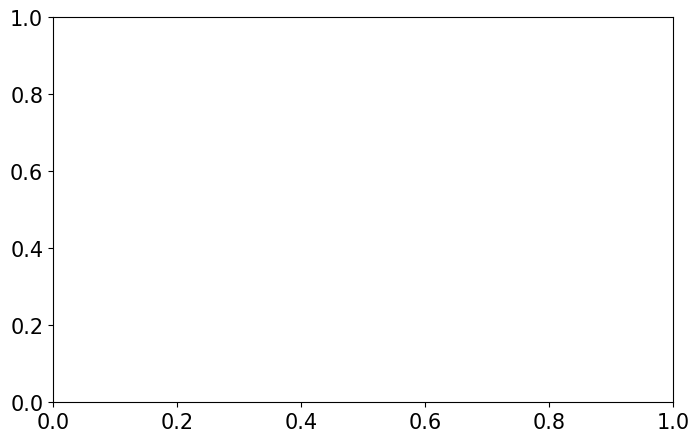

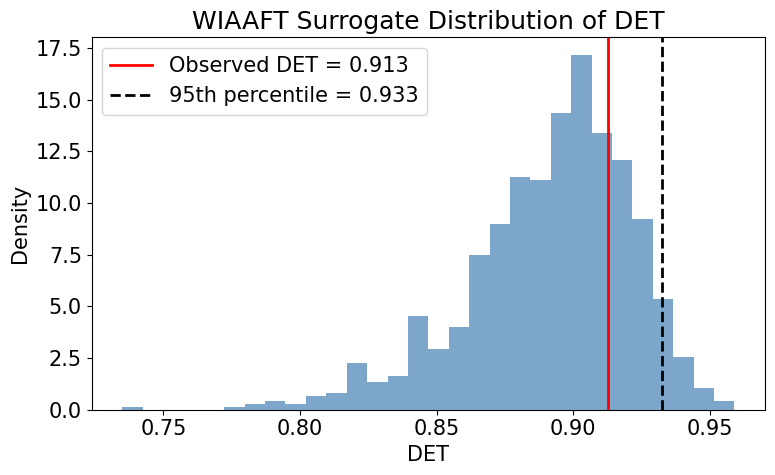

 29%|████████████▏                             | 29/100 [11:20<28:07, 23.77s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.9129392971209548 
 Recurrence rate: 0.05000365256775513 
Threshold:0.8551999999999221 
 Laminarity:0.9663988312601666 
Shannon Entropy:2.0449723005886518 
Rank-order p-value (det):0.244 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


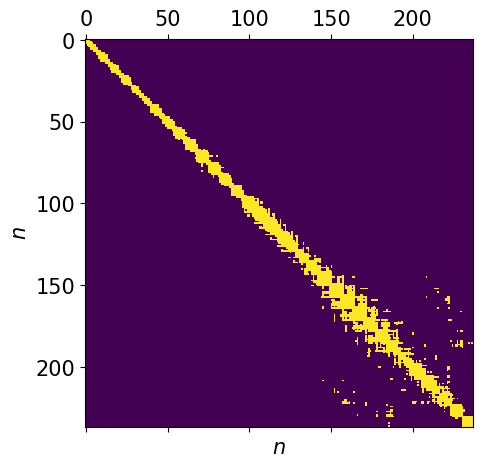

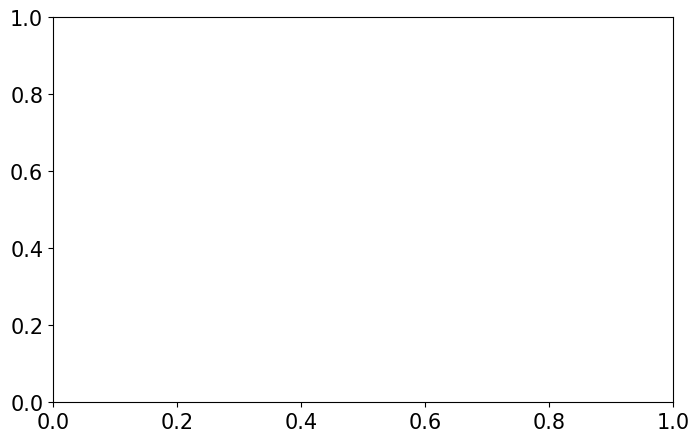

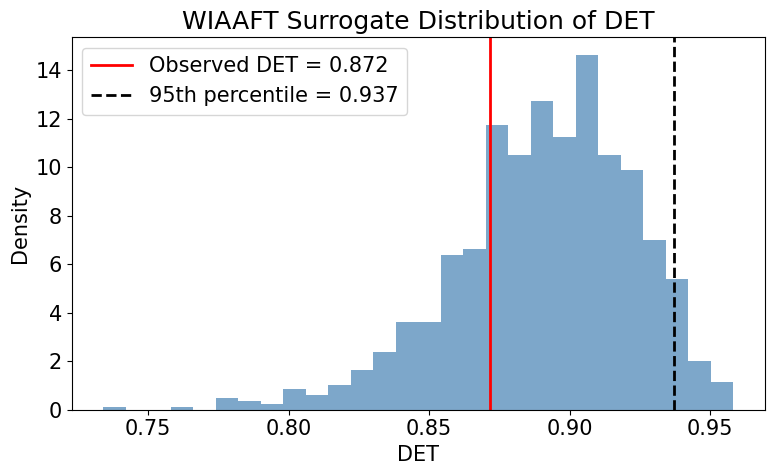

 30%|████████████▌                             | 30/100 [11:42<27:00, 23.14s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8716951788457555 
 Recurrence rate: 0.050009791878082216 
Threshold:1.0132999999999048 
 Laminarity:0.9298682805235676 
Shannon Entropy:1.6789821546046688 
Rank-order p-value (det):0.759 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


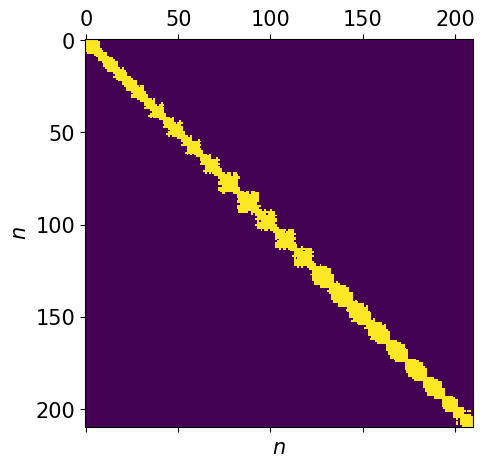

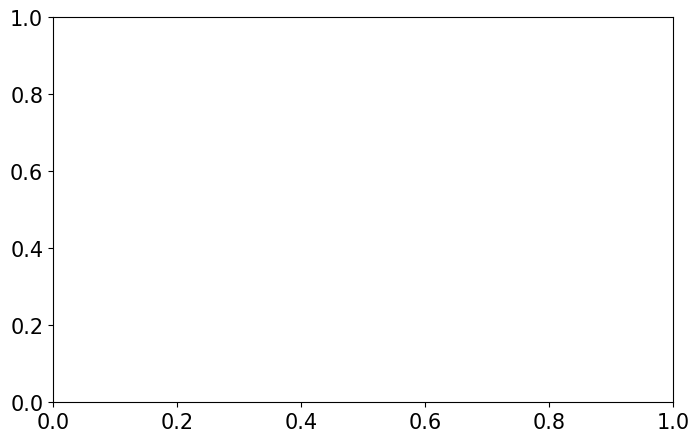

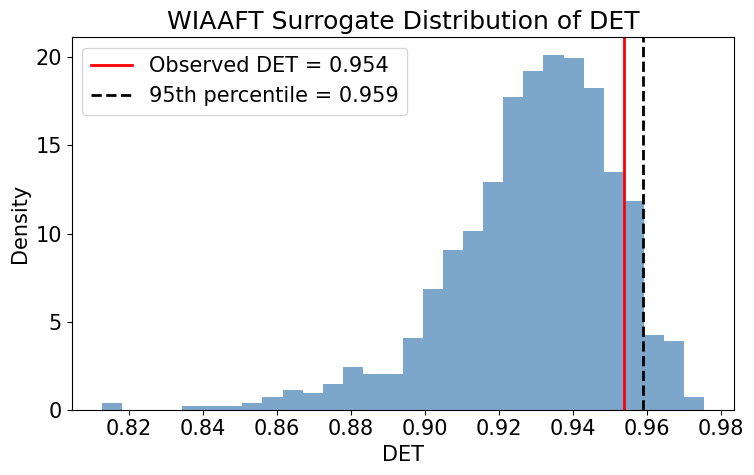

 31%|█████████████                             | 31/100 [12:05<26:28, 23.02s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9539078156264835 
 Recurrence rate: 0.05002267573696145 
Threshold:1.4552999999998562 
 Laminarity:0.9841341795059649 
Shannon Entropy:2.054798034238529 
Rank-order p-value (det):0.111 
Reject null (det) hypothesis:False

 
 

3
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


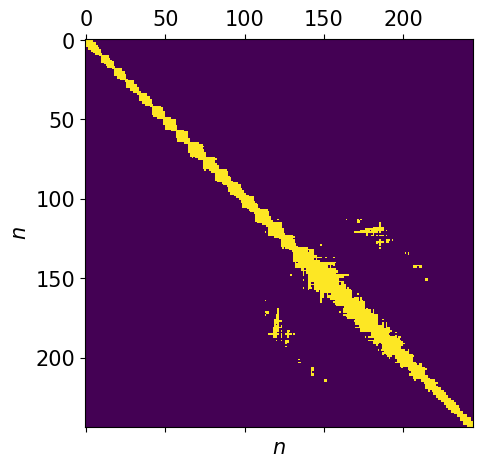

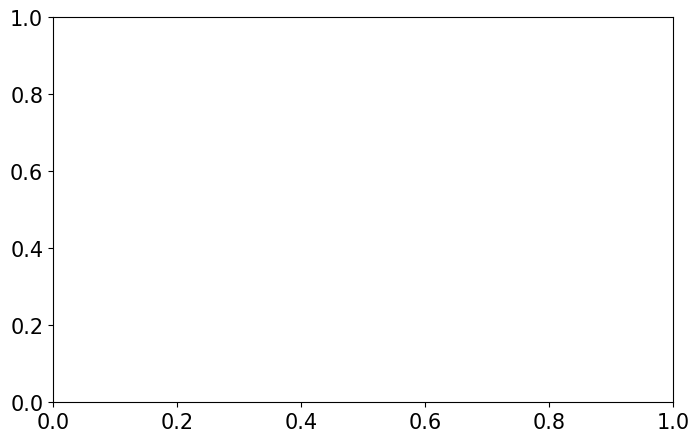

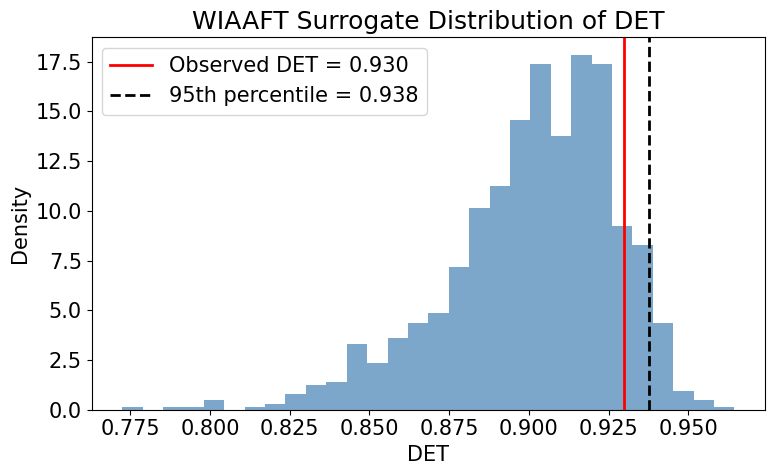

 32%|█████████████▍                            | 32/100 [12:28<26:14, 23.15s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9297732260390279 
 Recurrence rate: 0.0500201558720774 
Threshold:1.1821999999998862 
 Laminarity:0.9684351914003747 
Shannon Entropy:2.023057624131898 
Rank-order p-value (det):0.113 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


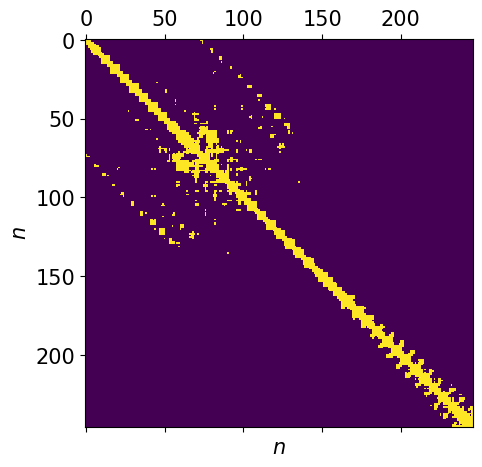

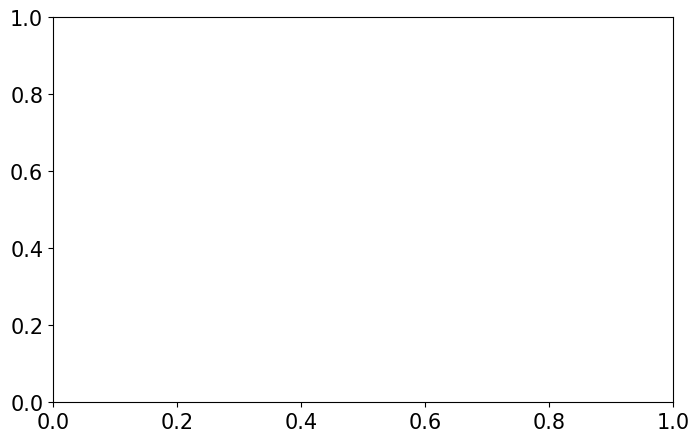

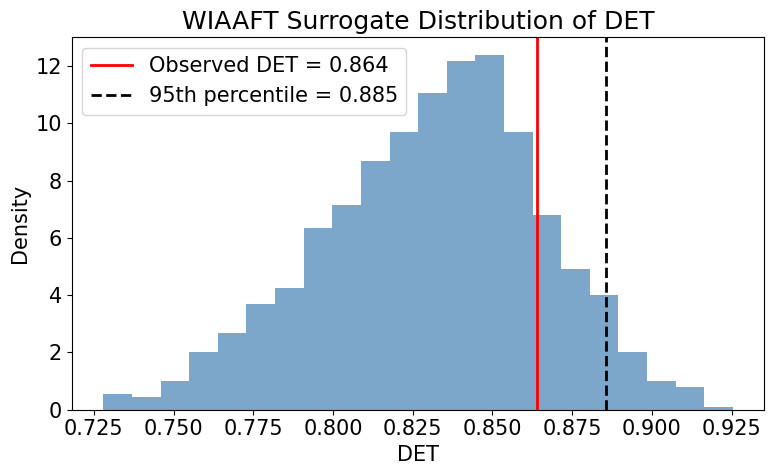

 33%|█████████████▊                            | 33/100 [12:52<25:55, 23.22s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8640287769753093 
 Recurrence rate: 0.05000330491109789 
Threshold:1.1422999999998906 
 Laminarity:0.9424983476505536 
Shannon Entropy:1.4350601022440093 
Rank-order p-value (det):0.168 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


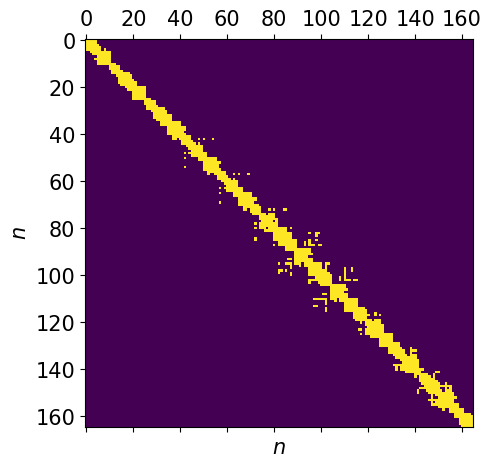

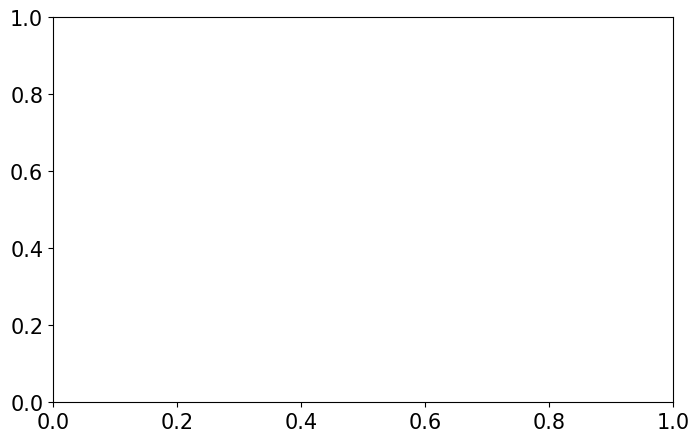

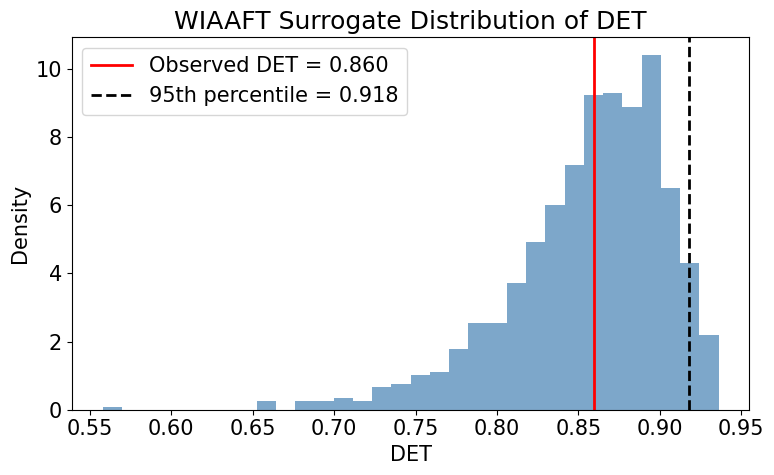

 34%|██████████████▎                           | 34/100 [13:10<23:58, 21.80s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.859766277121371 
 Recurrence rate: 0.05006427915518825 
Threshold:0.947499999999912 
 Laminarity:0.942773294197045 
Shannon Entropy:1.8383007836283367 
Rank-order p-value (det):0.548 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


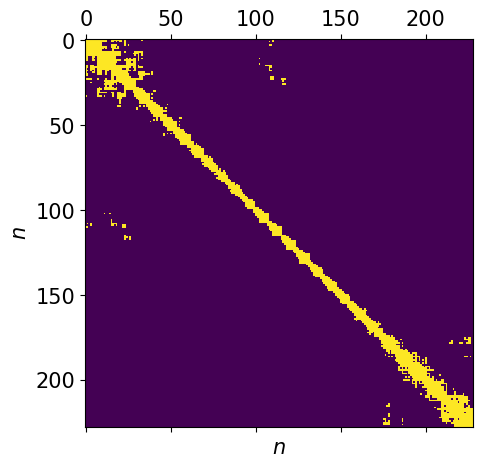

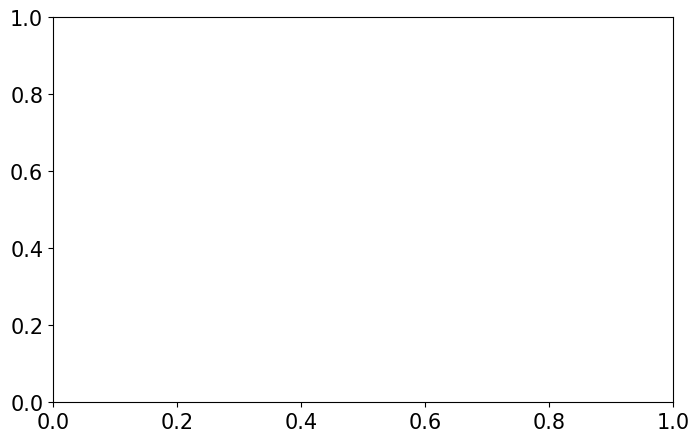

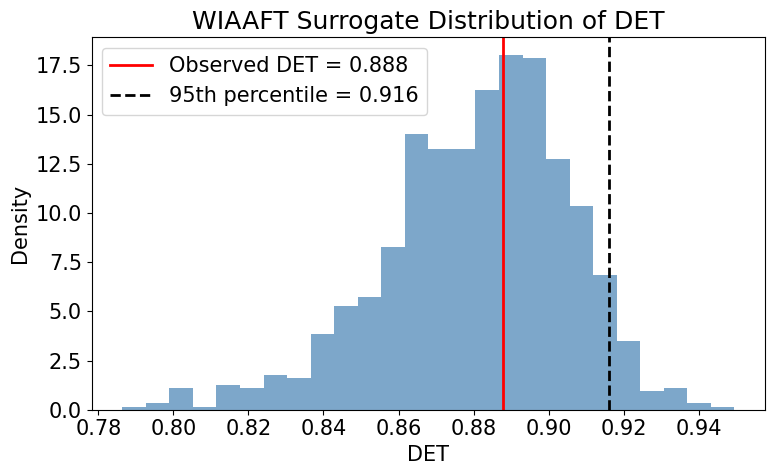

 35%|██████████████▋                           | 35/100 [13:33<24:02, 22.20s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.887858347382429 
 Recurrence rate: 0.05001538935056941 
Threshold:1.4215999999998599 
 Laminarity:0.9399999999963846 
Shannon Entropy:1.9604696322619246 
Rank-order p-value (det):0.436 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


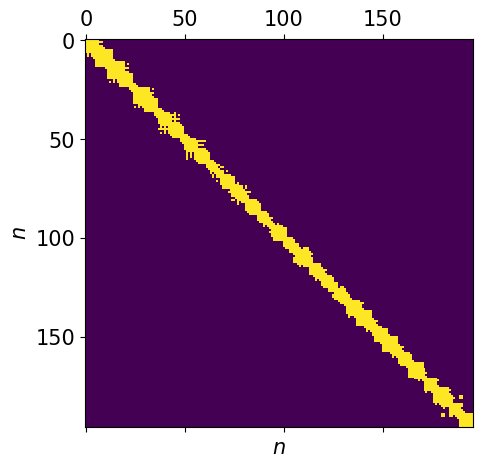

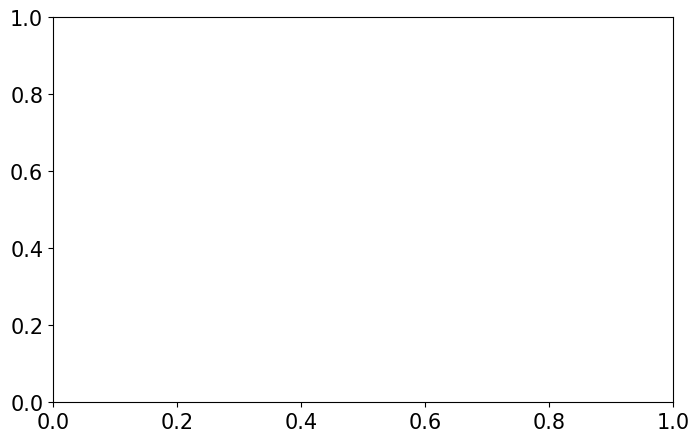

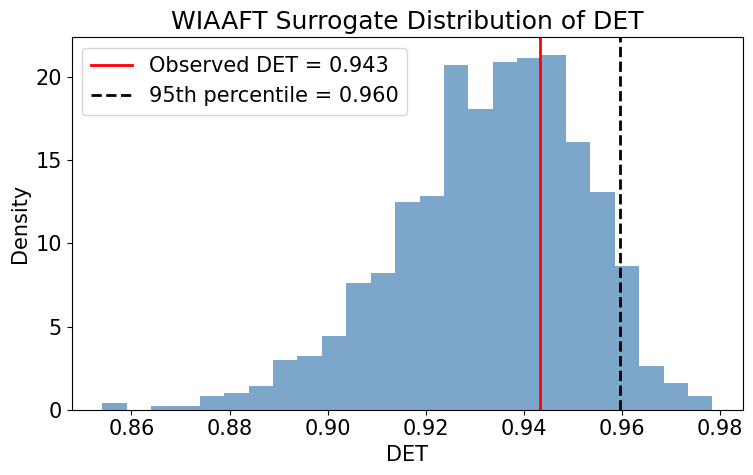

 36%|███████████████                           | 36/100 [13:54<23:19, 21.87s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.943221320967884 
 Recurrence rate: 0.05003123698458976 
Threshold:1.4400999999998578 
 Laminarity:0.9760665972894066 
Shannon Entropy:2.061695140685442 
Rank-order p-value (det):0.327 
Reject null (det) hypothesis:False

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


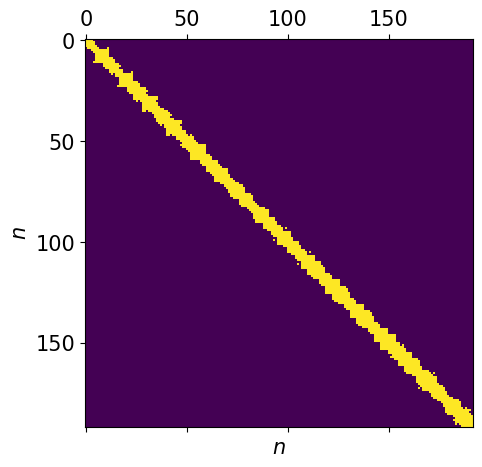

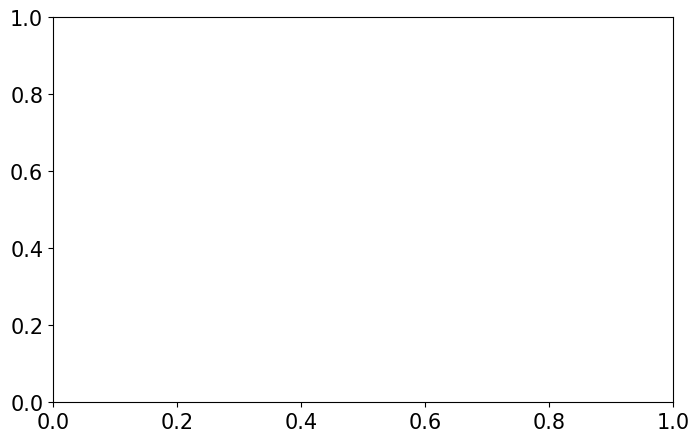

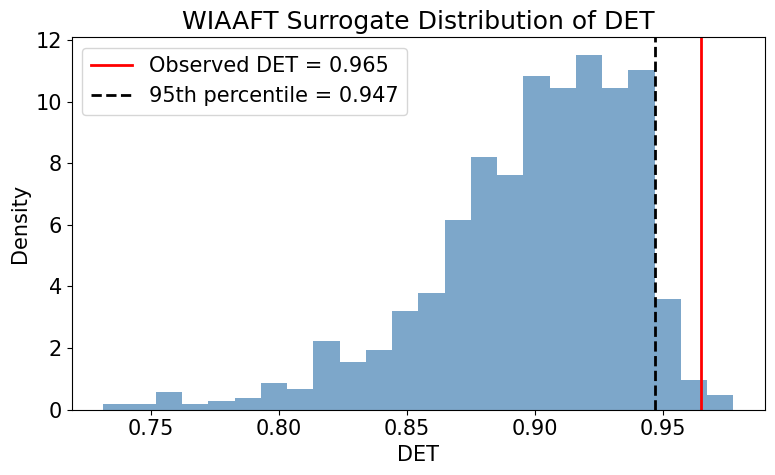

 37%|███████████████▌                          | 37/100 [14:13<21:45, 20.73s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9648910411563869 
 Recurrence rate: 0.05002170138888889 
Threshold:0.47479999999996403 
 Laminarity:0.9918655097560095 
Shannon Entropy:1.5785163523660026 
Rank-order p-value (det):0.007 
Reject null (det) hypothesis:True

 
 

4
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


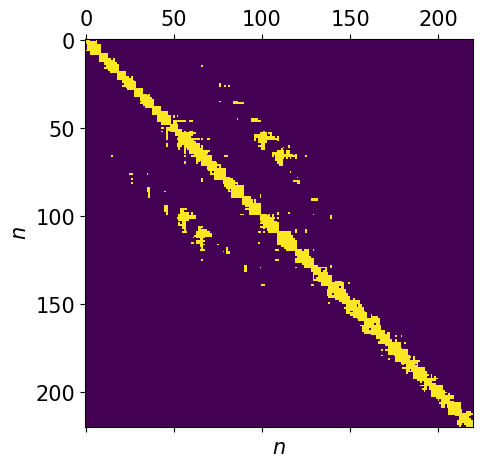

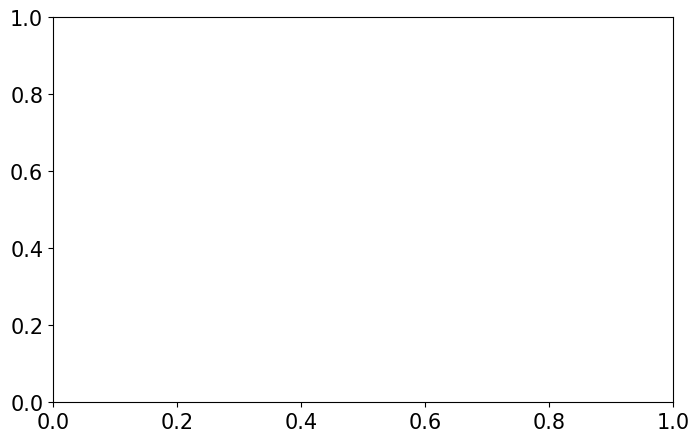

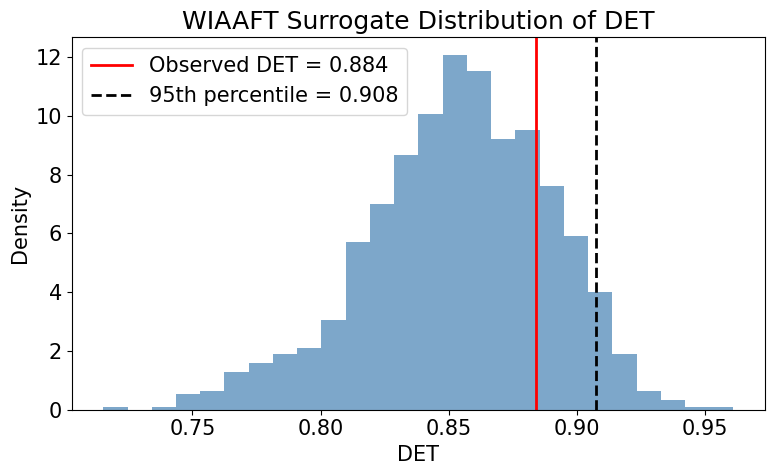

 38%|███████████████▉                          | 38/100 [14:35<21:49, 21.12s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8838475499052457 
 Recurrence rate: 0.05008264462809917 
Threshold:1.093999999999896 
 Laminarity:0.9447194719432974 
Shannon Entropy:1.8873354974287184 
Rank-order p-value (det):0.208 
Reject null (det) hypothesis:False

 
 

4
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


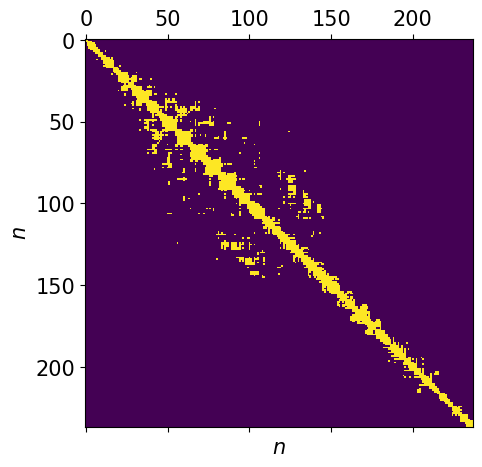

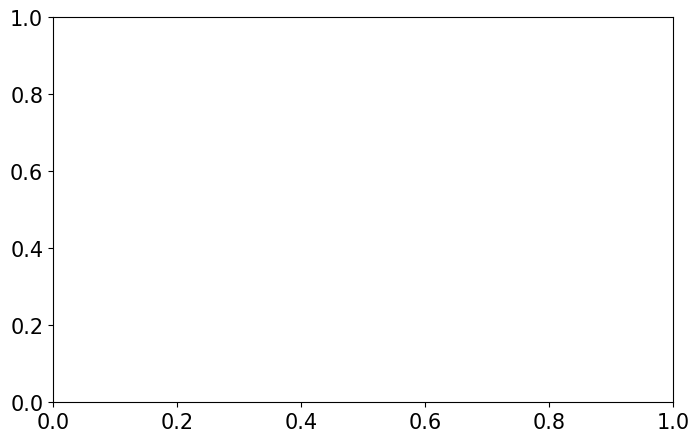

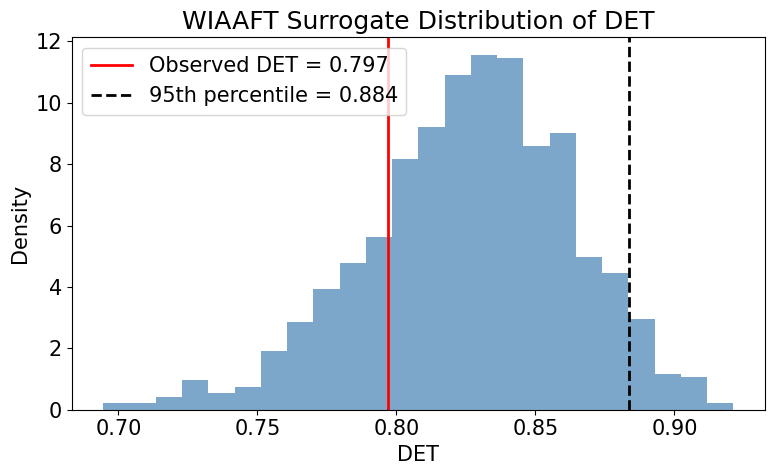

 39%|████████████████▍                         | 39/100 [14:58<22:09, 21.79s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.797045101085548 
 Recurrence rate: 0.050009791878082216 
Threshold:1.301499999999873 
 Laminarity:0.8985404058351779 
Shannon Entropy:1.805056838816959 
Rank-order p-value (det):0.799 
Reject null (det) hypothesis:False

 
 

4
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


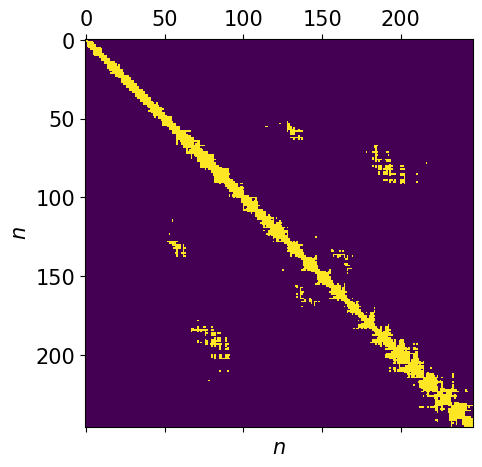

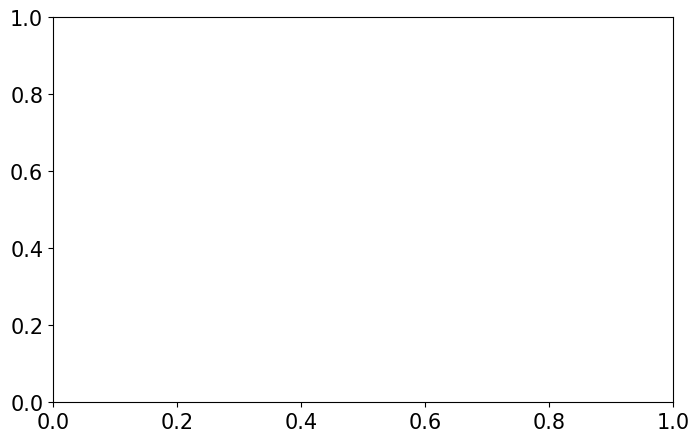

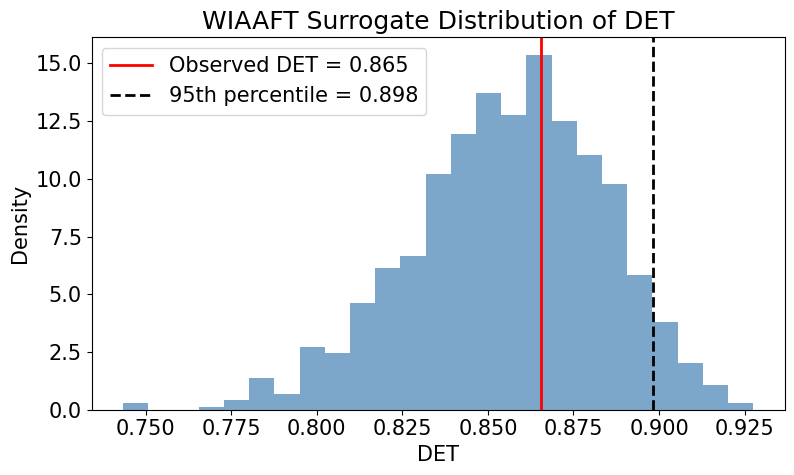

 40%|████████████████▊                         | 40/100 [15:19<21:43, 21.73s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8654676258961674 
 Recurrence rate: 0.05000330491109789 
Threshold:1.1080999999998944 
 Laminarity:0.9286186384635539 
Shannon Entropy:1.8248634784103646 
Rank-order p-value (det):0.397 
Reject null (det) hypothesis:False

 
 

4
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


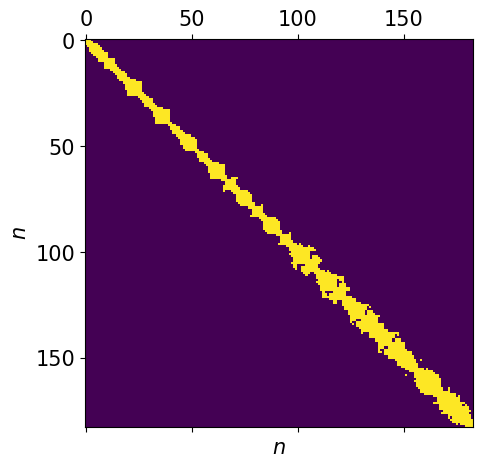

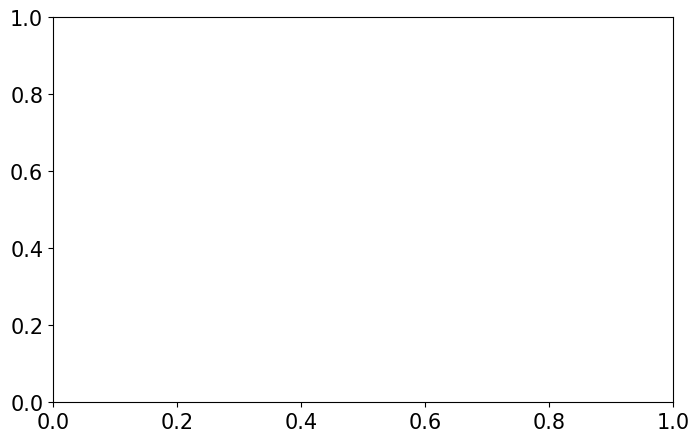

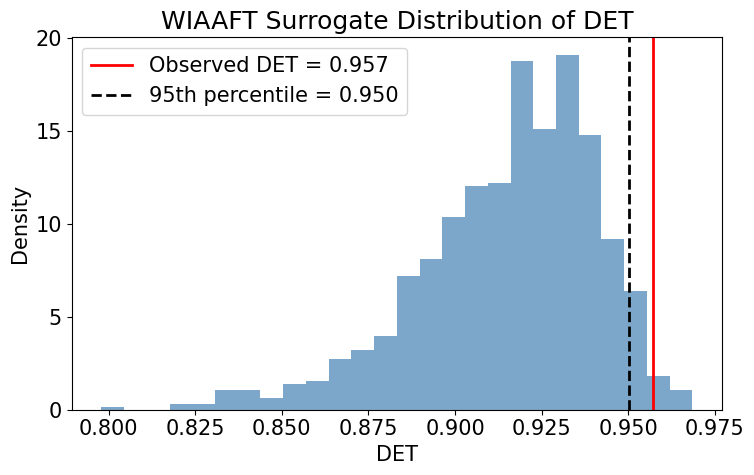

 41%|█████████████████▏                        | 41/100 [15:39<20:38, 20.98s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9571045576343358 
 Recurrence rate: 0.05001642330317418 
Threshold:0.9658999999999099 
 Laminarity:0.9850746268597906 
Shannon Entropy:2.2203442280853483 
Rank-order p-value (det):0.016 
Reject null (det) hypothesis:True

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


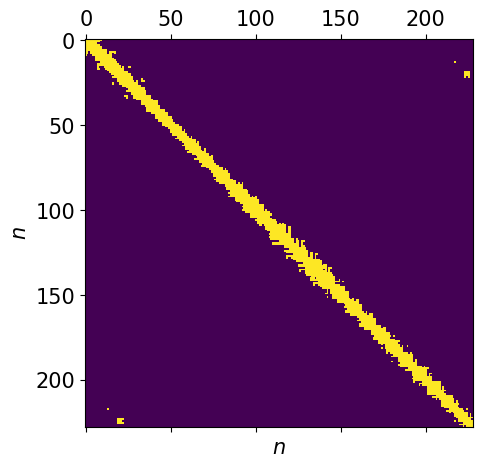

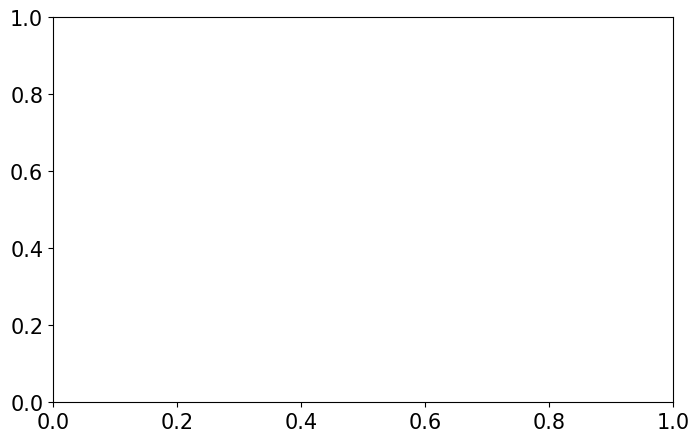

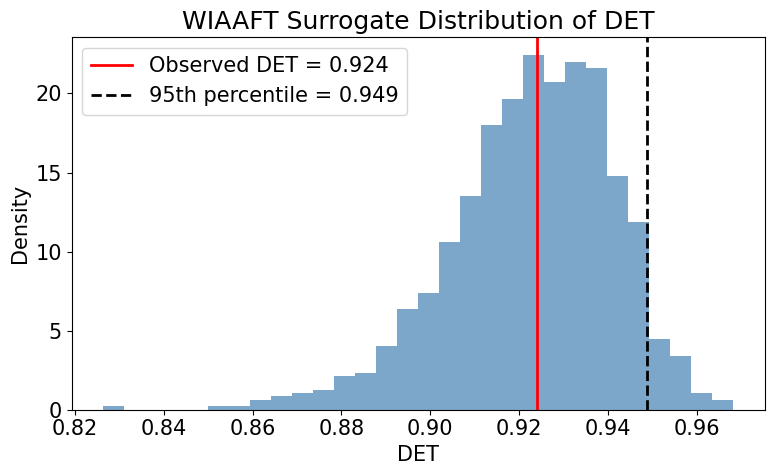

 42%|█████████████████▋                        | 42/100 [16:03<21:09, 21.90s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9241146711596792 
 Recurrence rate: 0.05001538935056941 
Threshold:1.5973999999998405 
 Laminarity:0.9730769230731805 
Shannon Entropy:1.7049904082870468 
Rank-order p-value (det):0.509 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


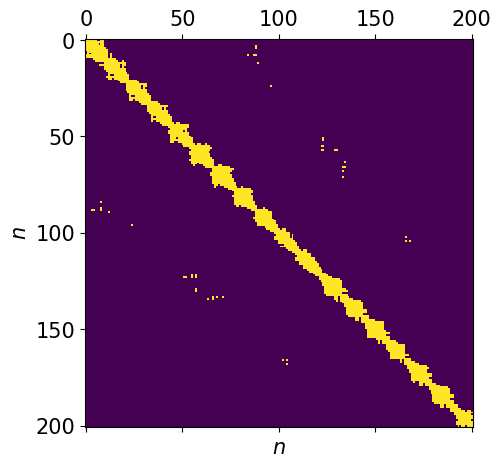

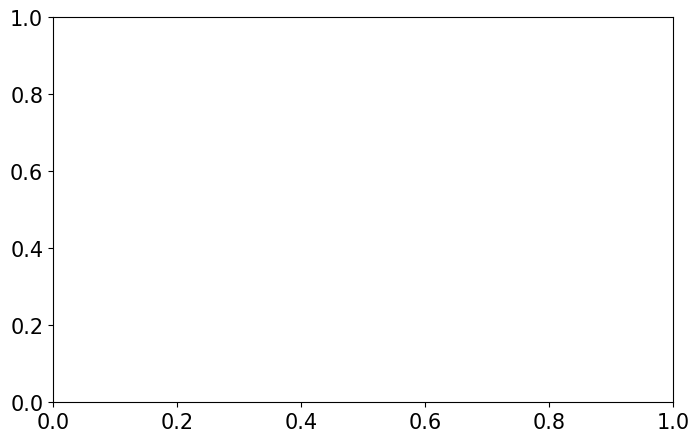

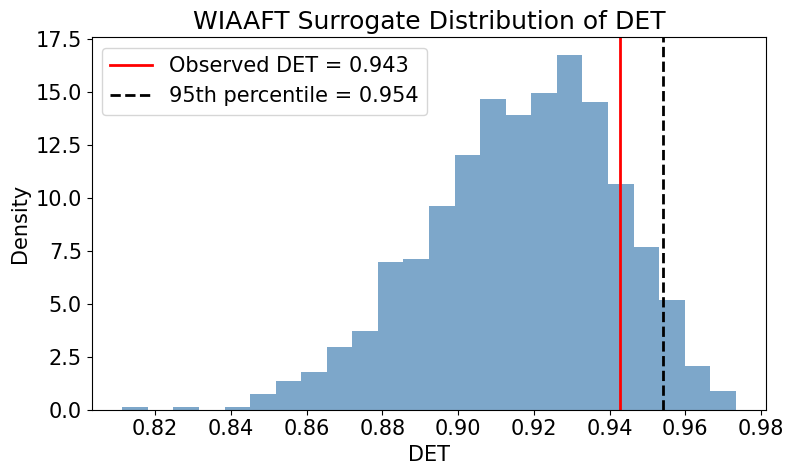

 43%|██████████████████                        | 43/100 [16:24<20:41, 21.78s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9428571428519624 
 Recurrence rate: 0.050023514269448774 
Threshold:1.2634999999998773 
 Laminarity:0.9703117268630861 
Shannon Entropy:2.177423220037279 
Rank-order p-value (det):0.148 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


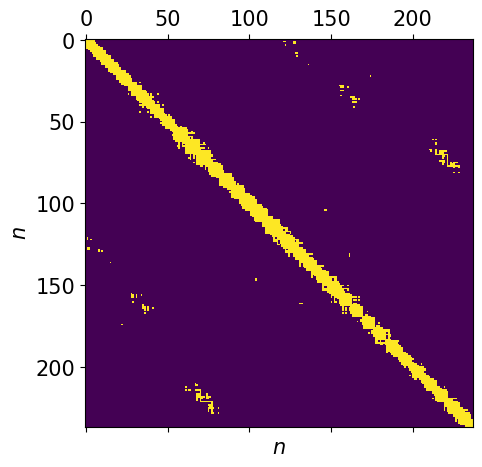

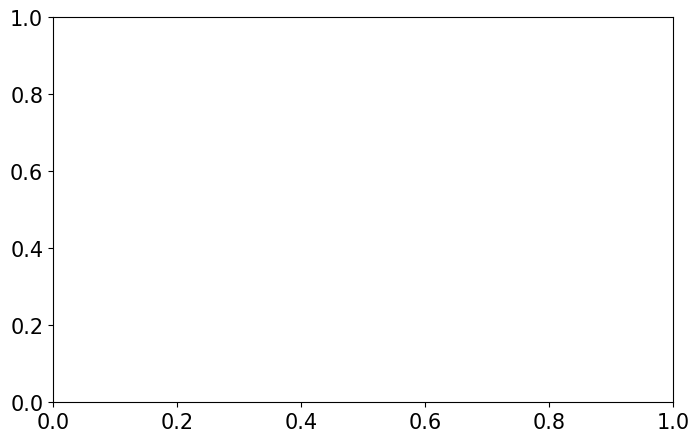

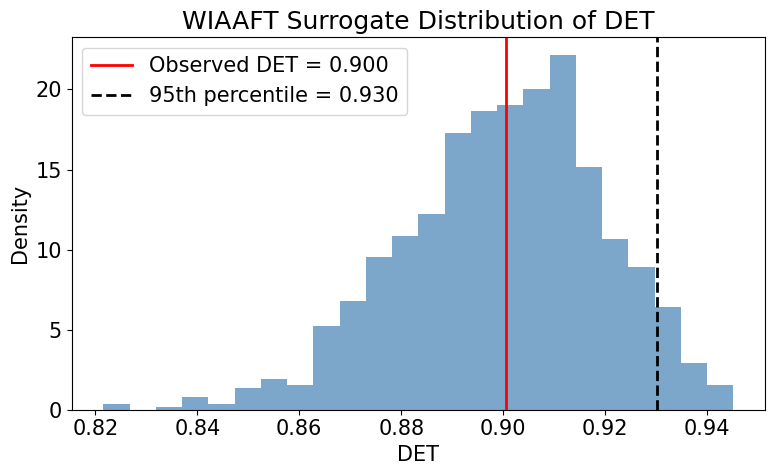

 44%|██████████████████▍                       | 44/100 [16:51<21:36, 23.15s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9004665629825022 
 Recurrence rate: 0.050009791878082216 
Threshold:1.819599999999816 
 Laminarity:0.9494482022038112 
Shannon Entropy:1.9636805314350096 
Rank-order p-value (det):0.527 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


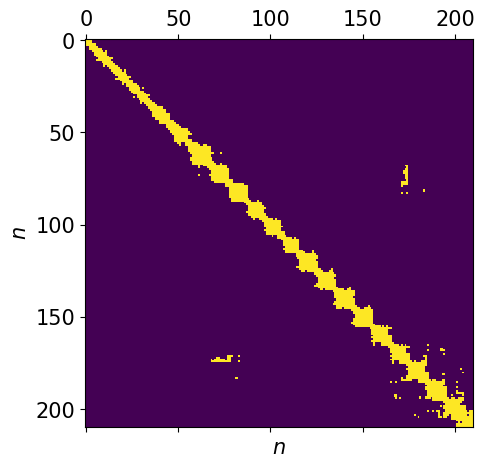

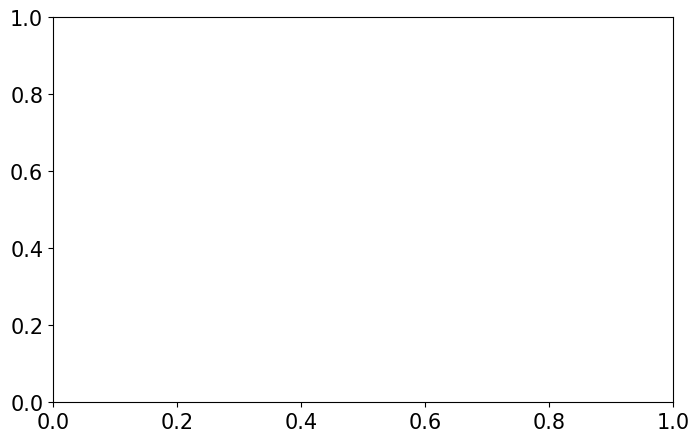

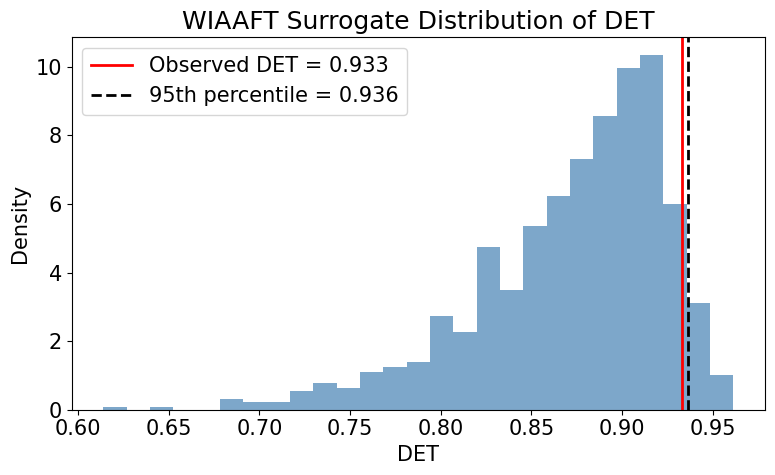

 45%|██████████████████▉                       | 45/100 [17:11<20:28, 22.33s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9328657314582522 
 Recurrence rate: 0.05002267573696145 
Threshold:0.856599999999922 
 Laminarity:0.968268359016463 
Shannon Entropy:2.0745110630329493 
Rank-order p-value (det):0.066 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


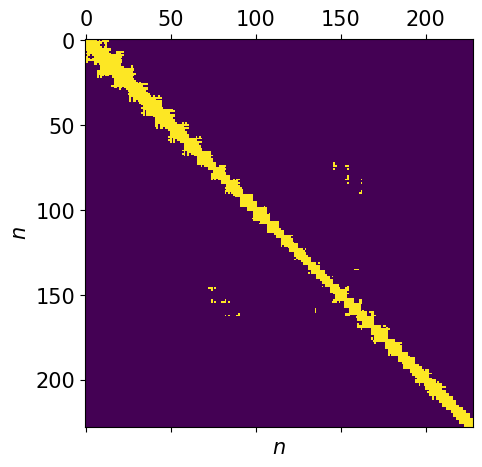

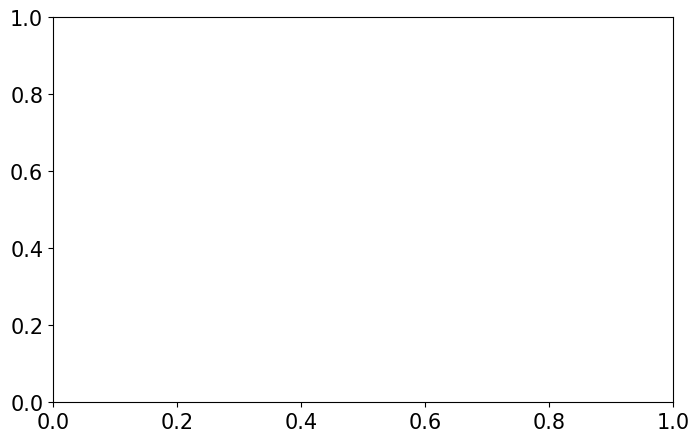

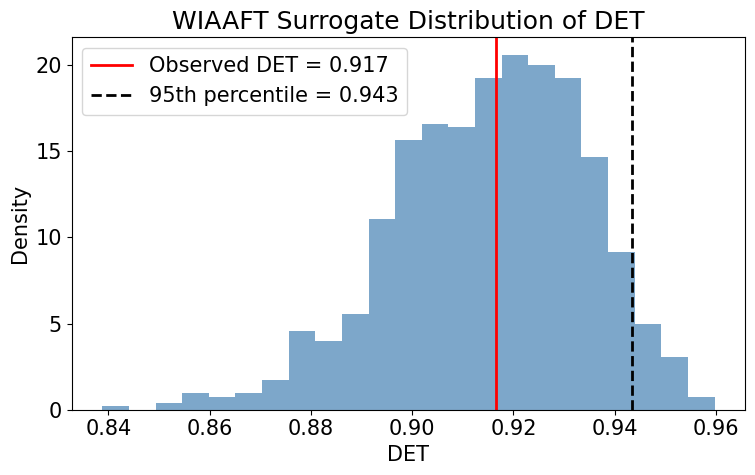

 46%|███████████████████▎                      | 46/100 [17:32<19:44, 21.94s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9165261382760687 
 Recurrence rate: 0.05001538935056941 
Threshold:1.0713999999998984 
 Laminarity:0.9684615384578137 
Shannon Entropy:1.8563979213137285 
Rank-order p-value (det):0.5 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


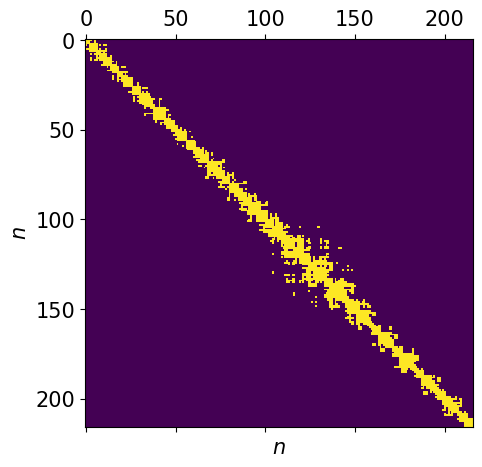

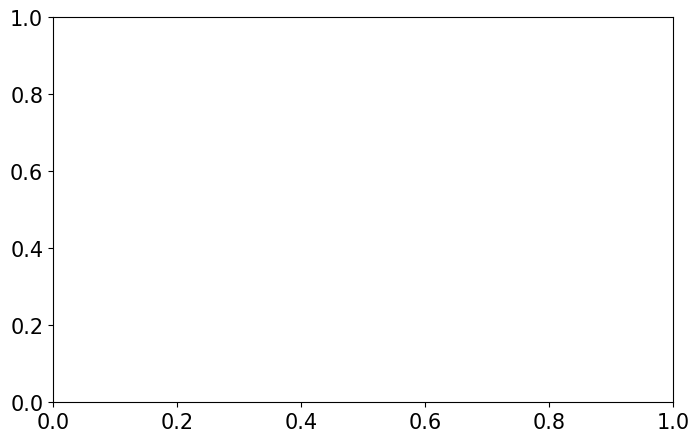

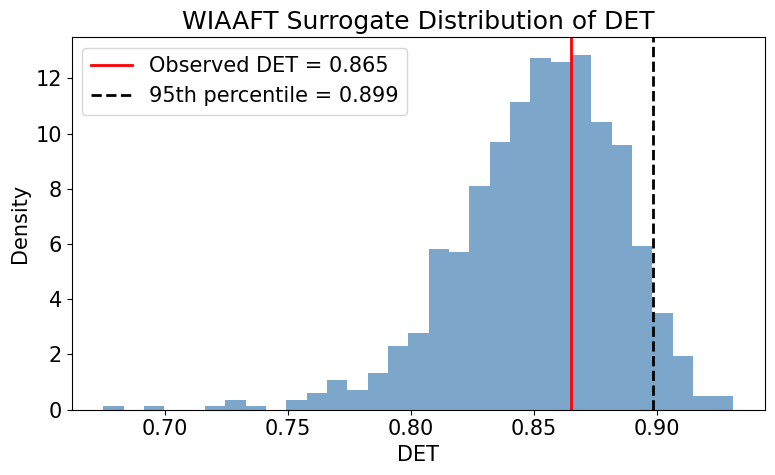

 47%|███████████████████▋                      | 47/100 [17:51<18:33, 21.01s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.865094339618561 
 Recurrence rate: 0.050068587105624146 
Threshold:0.6416999999999456 
 Laminarity:0.9362157534206498 
Shannon Entropy:1.6849687909032758 
Rank-order p-value (det):0.371 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


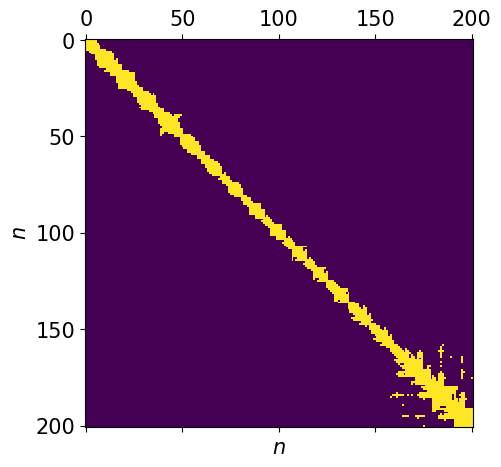

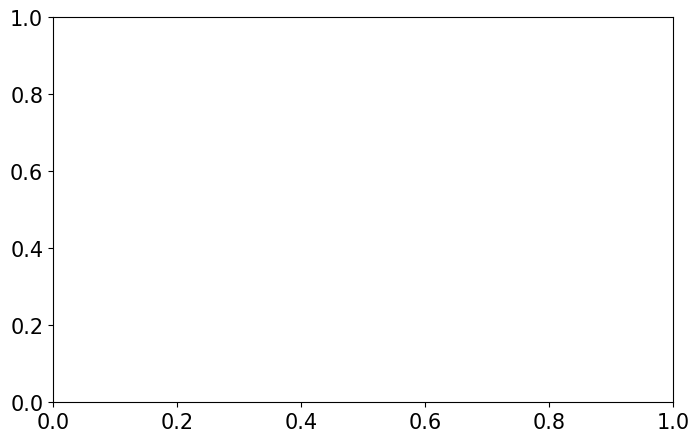

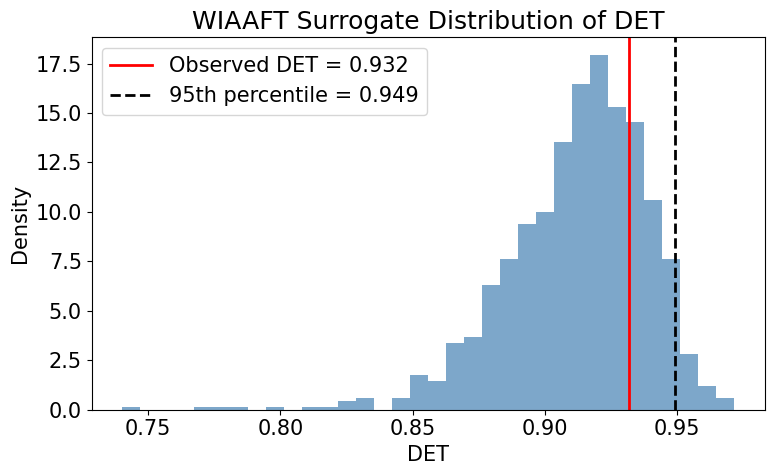

 48%|████████████████████▏                     | 48/100 [18:11<17:58, 20.75s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9318681318630118 
 Recurrence rate: 0.050023514269448774 
Threshold:0.8829999999999191 
 Laminarity:0.9703117268630861 
Shannon Entropy:1.937567927041435 
Rank-order p-value (det):0.247 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


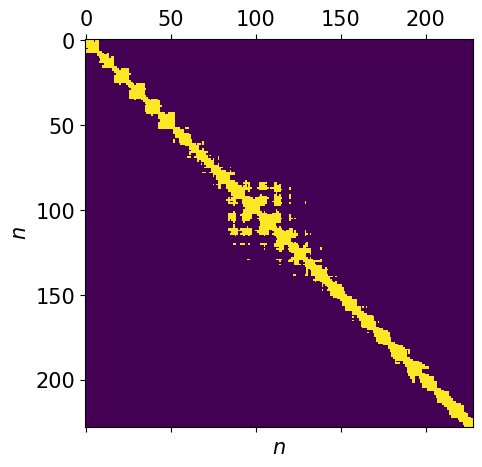

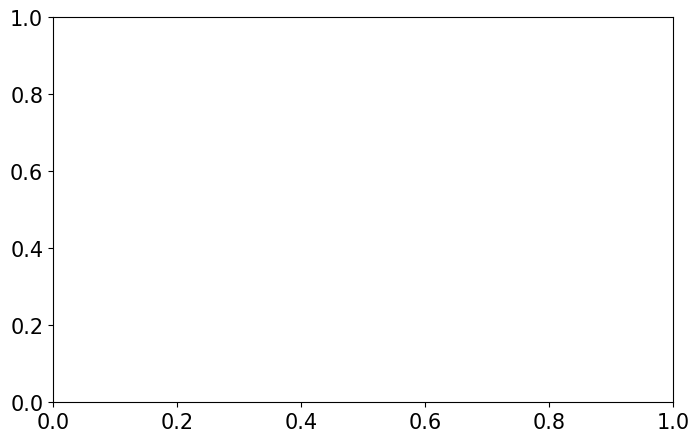

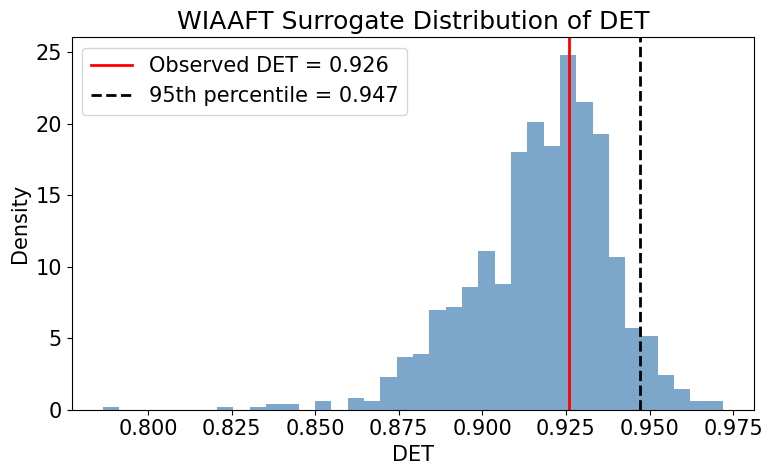

 49%|████████████████████▌                     | 49/100 [18:33<17:54, 21.07s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9258010118004815 
 Recurrence rate: 0.05001538935056941 
Threshold:1.220199999999882 
 Laminarity:0.963076923073219 
Shannon Entropy:1.9415100321928835 
Rank-order p-value (det):0.382 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


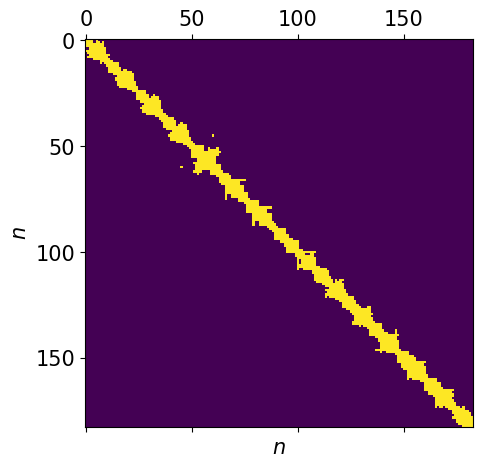

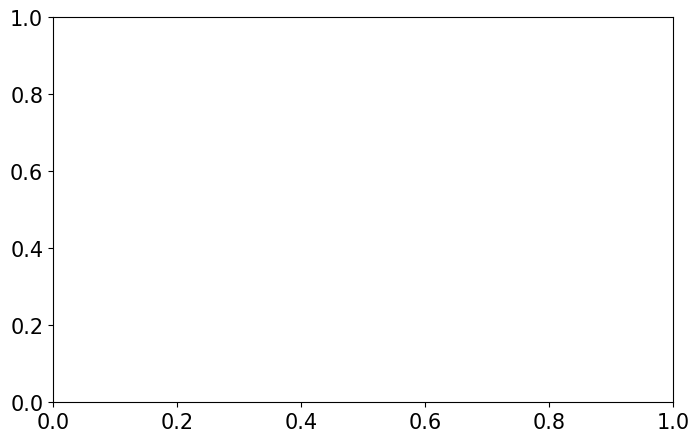

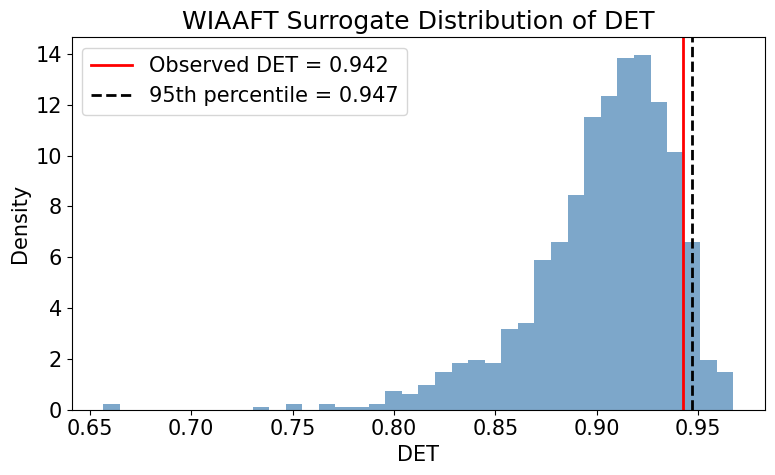

 50%|█████████████████████                     | 50/100 [18:53<17:18, 20.77s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9423592493234427 
 Recurrence rate: 0.05001642330317418 
Threshold:1.0821999999998972 
 Laminarity:0.9838805970090515 
Shannon Entropy:2.079599980048344 
Rank-order p-value (det):0.084 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


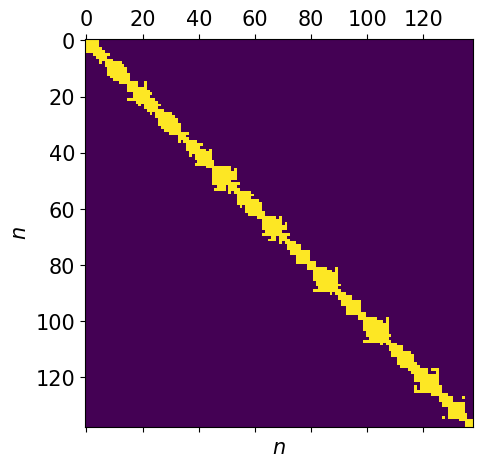

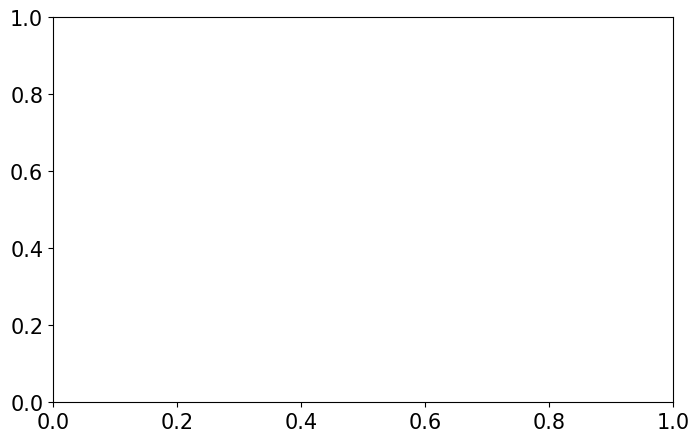

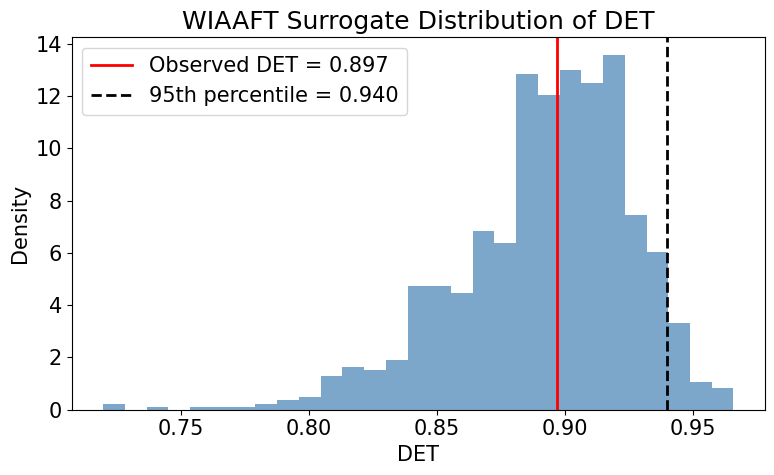

 51%|█████████████████████▍                    | 51/100 [19:10<16:05, 19.71s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8970588235184184 
 Recurrence rate: 0.0500945179584121 
Threshold:0.7641999999999322 
 Laminarity:0.9737945492560399 
Shannon Entropy:1.9233305352643253 
Rank-order p-value (det):0.498 
Reject null (det) hypothesis:False

 
 

5
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


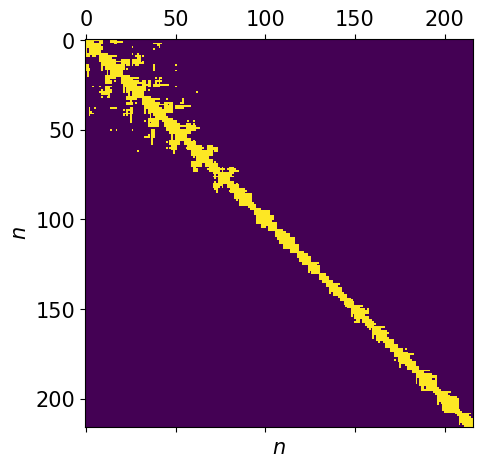

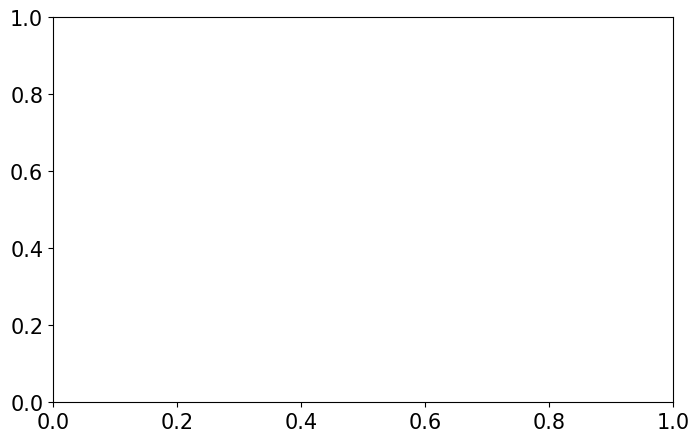

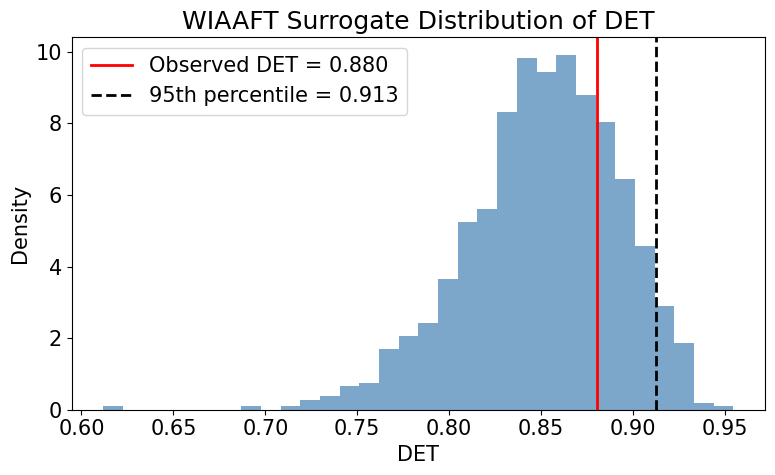

 52%|█████████████████████▊                    | 52/100 [19:29<15:32, 19.42s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.8801886792411312 
 Recurrence rate: 0.050068587105624146 
Threshold:0.5543999999999553 
 Laminarity:0.9477739725986826 
Shannon Entropy:1.8329866222198004 
Rank-order p-value (det):0.254 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


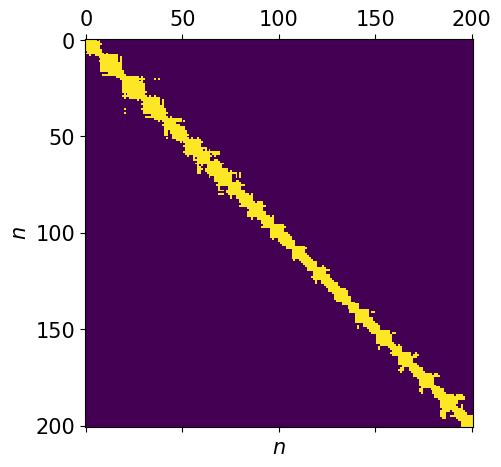

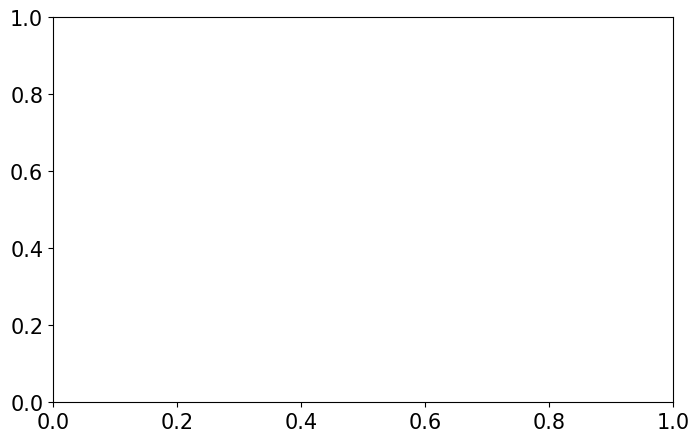

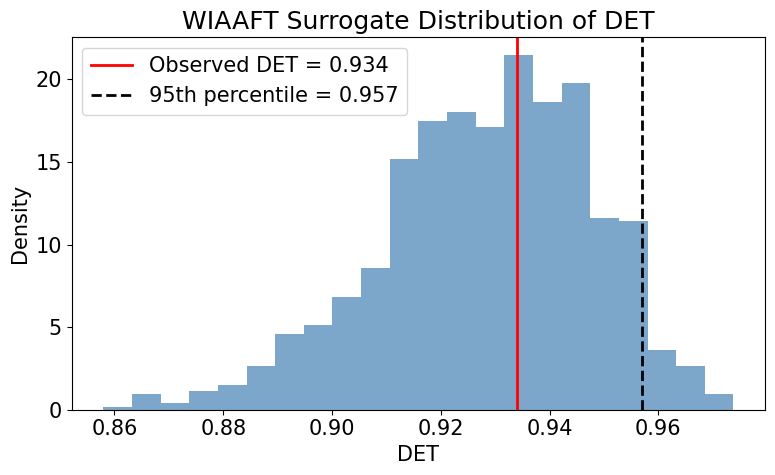

 53%|██████████████████████▎                   | 53/100 [19:50<15:36, 19.92s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9340659340608019 
 Recurrence rate: 0.050023514269448774 
Threshold:1.4048999999998617 
 Laminarity:0.9683325086542883 
Shannon Entropy:1.8699748550654818 
Rank-order p-value (det):0.436 
Reject null (det) hypothesis:False

 
 

5
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


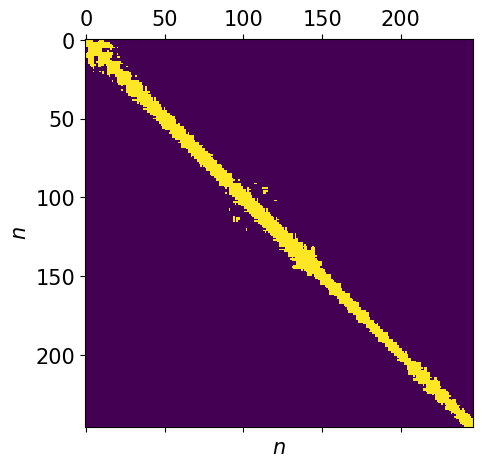

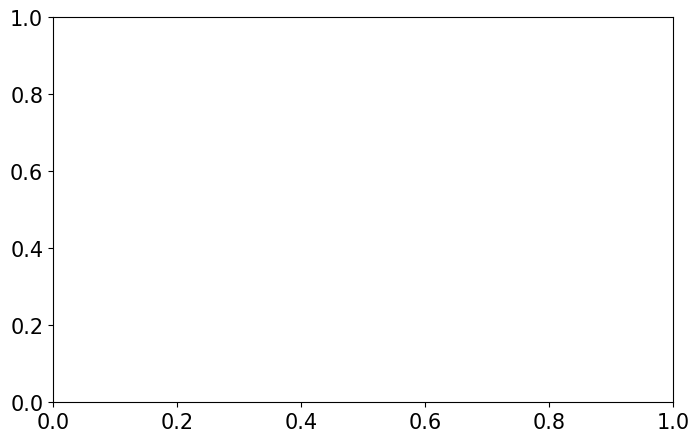

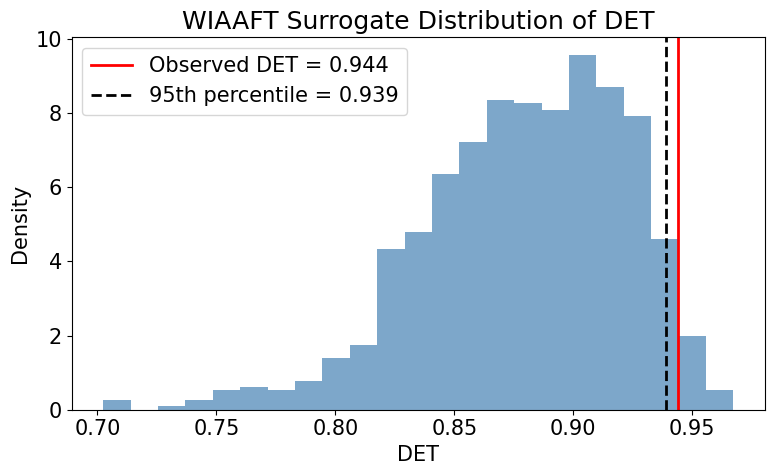

 54%|██████████████████████▋                   | 54/100 [20:10<15:20, 20.01s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9438848920829357 
 Recurrence rate: 0.05000330491109789 
Threshold:0.6080999999999493 
 Laminarity:0.9781890284171243 
Shannon Entropy:1.980203686046688 
Rank-order p-value (det):0.03 
Reject null (det) hypothesis:True

 
 

6
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


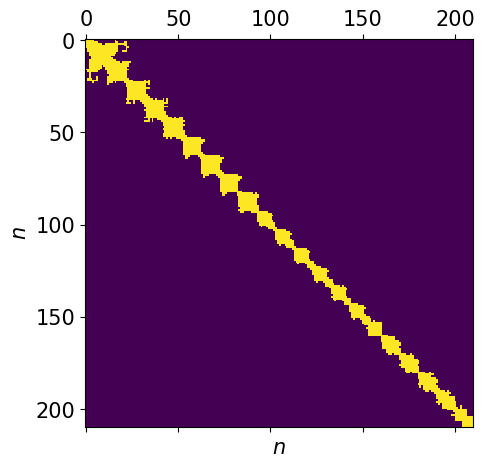

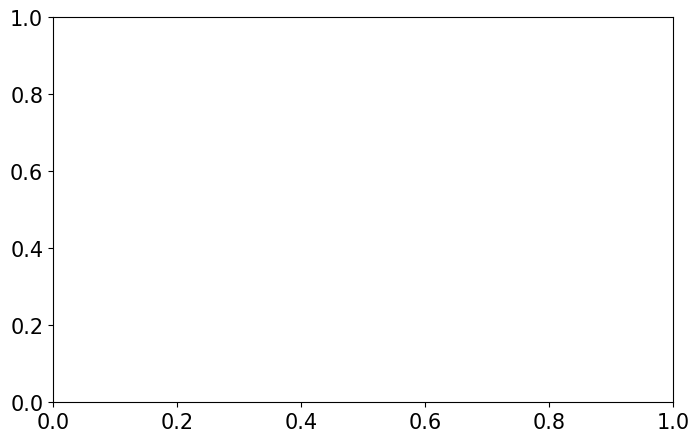

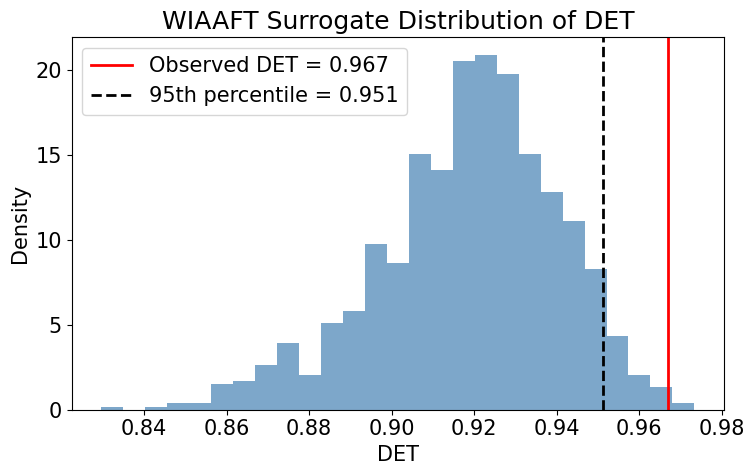

 55%|███████████████████████                   | 55/100 [20:31<15:09, 20.21s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9669338677306266 
 Recurrence rate: 0.05002267573696145 
Threshold:1.1977999999998845 
 Laminarity:0.9800543970943788 
Shannon Entropy:2.150240685349436 
Rank-order p-value (det):0.007 
Reject null (det) hypothesis:True

 
 

7
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


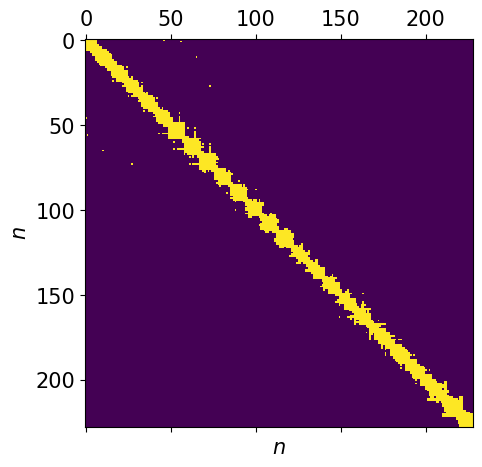

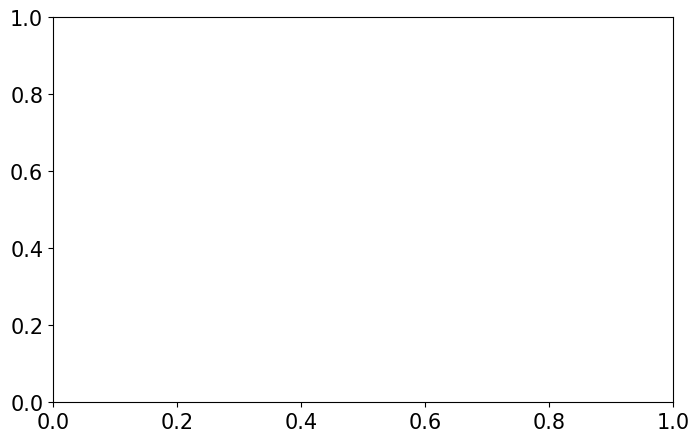

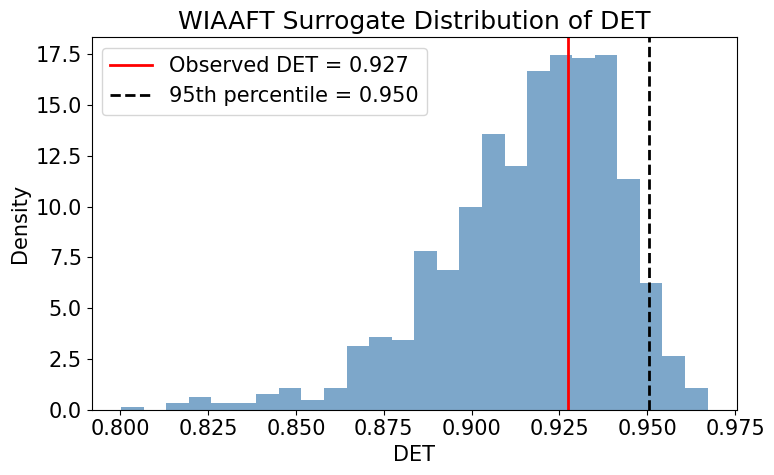

 56%|███████████████████████▌                  | 56/100 [20:53<15:08, 20.65s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9274873524412838 
 Recurrence rate: 0.05001538935056941 
Threshold:1.1348999999998914 
 Laminarity:0.9661538461501302 
Shannon Entropy:2.0744658794079593 
Rank-order p-value (det):0.376 
Reject null (det) hypothesis:False

 
 

7
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


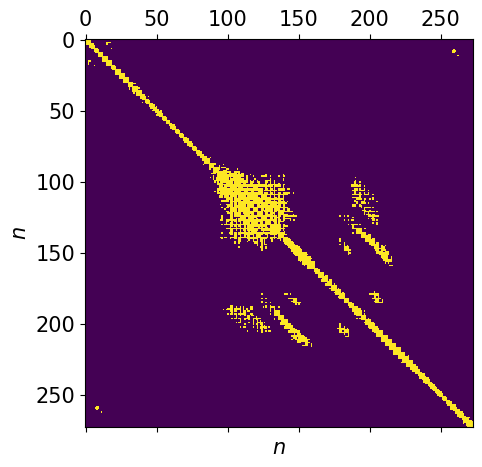

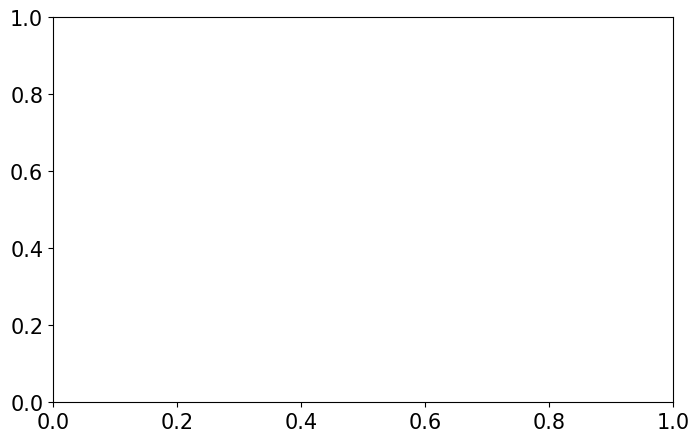

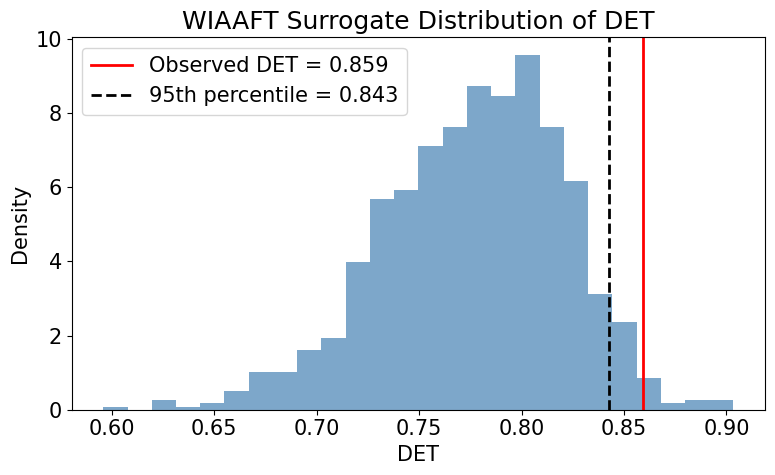

 57%|███████████████████████▉                  | 57/100 [21:13<14:46, 20.63s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.859293572666881 
 Recurrence rate: 0.050007379677709345 
Threshold:0.7625999999999323 
 Laminarity:0.9205795545990862 
Shannon Entropy:1.145712308178057 
Rank-order p-value (det):0.018 
Reject null (det) hypothesis:True

 
 

8
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


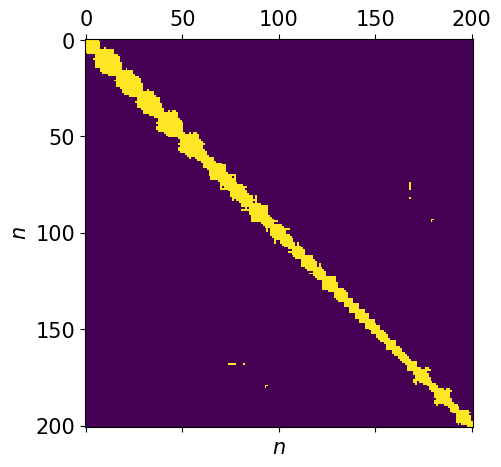

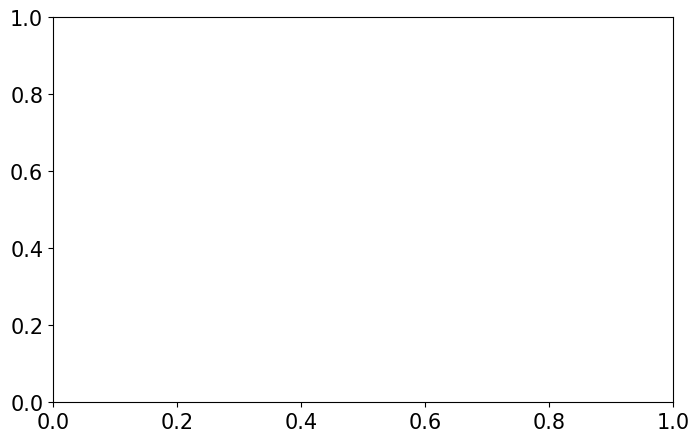

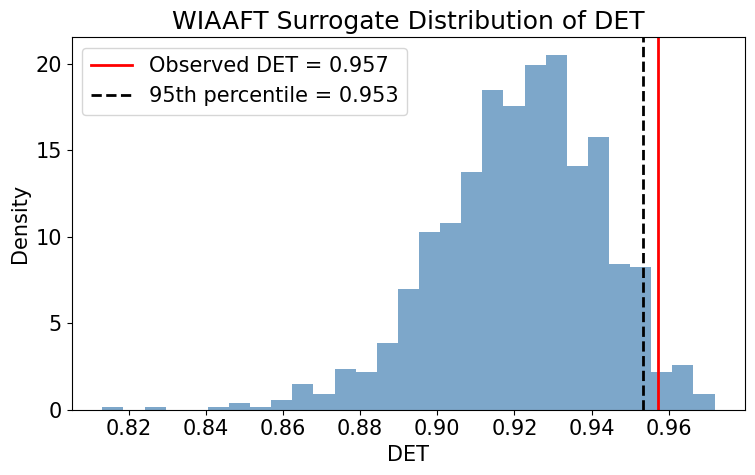

 58%|████████████████████████▎                 | 58/100 [21:36<14:48, 21.15s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9571428571375982 
 Recurrence rate: 0.050023514269448774 
Threshold:1.529599999999848 
 Laminarity:0.9841662543246702 
Shannon Entropy:2.1283378525903136 
Rank-order p-value (det):0.028 
Reject null (det) hypothesis:True

 
 

9
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


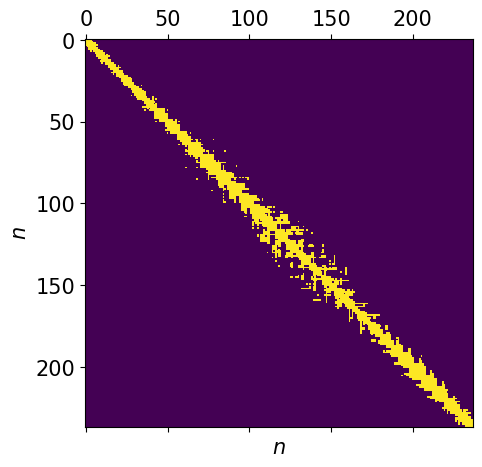

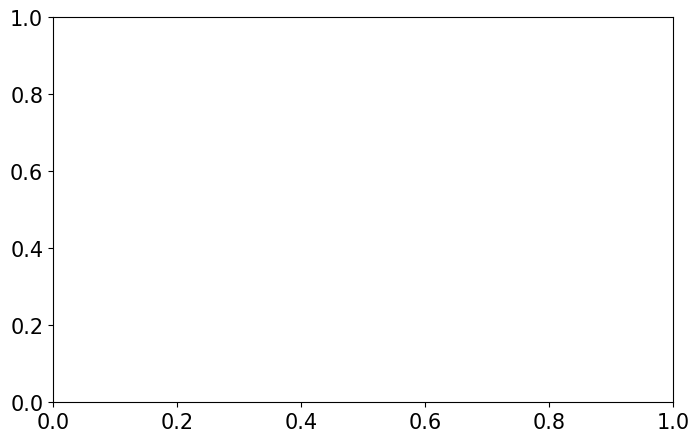

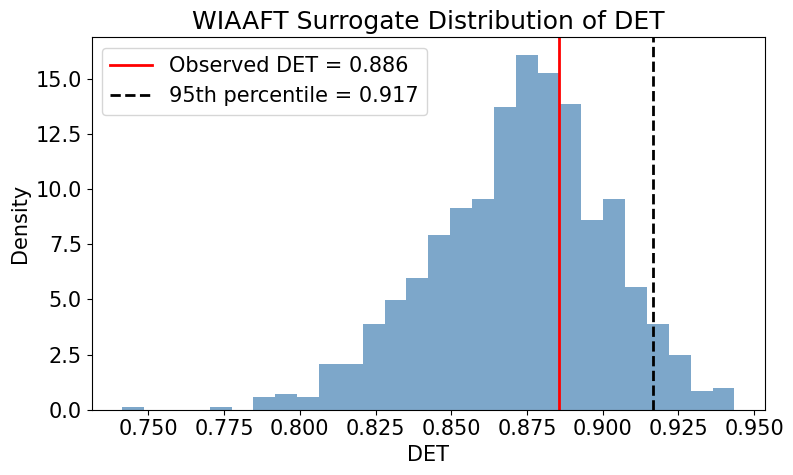

 59%|████████████████████████▊                 | 59/100 [21:57<14:25, 21.12s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8856920684257944 
 Recurrence rate: 0.050009791878082216 
Threshold:0.883599999999919 
 Laminarity:0.9391242434996827 
Shannon Entropy:1.7895458689057162 
Rank-order p-value (det):0.333 
Reject null (det) hypothesis:False

 
 

9
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


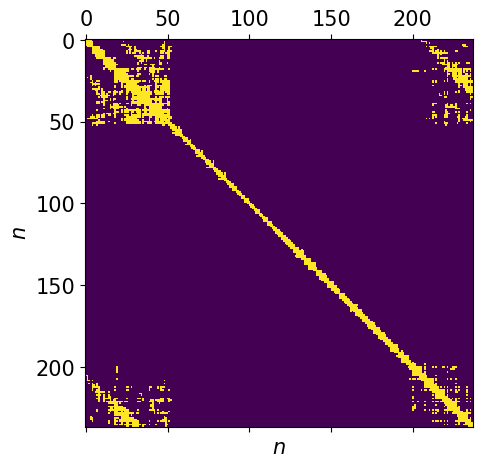

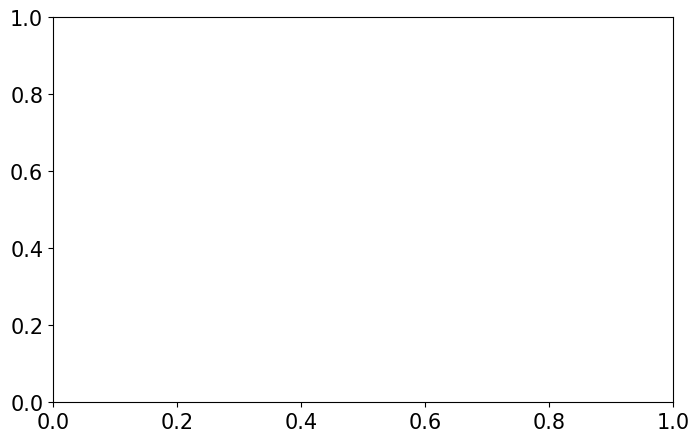

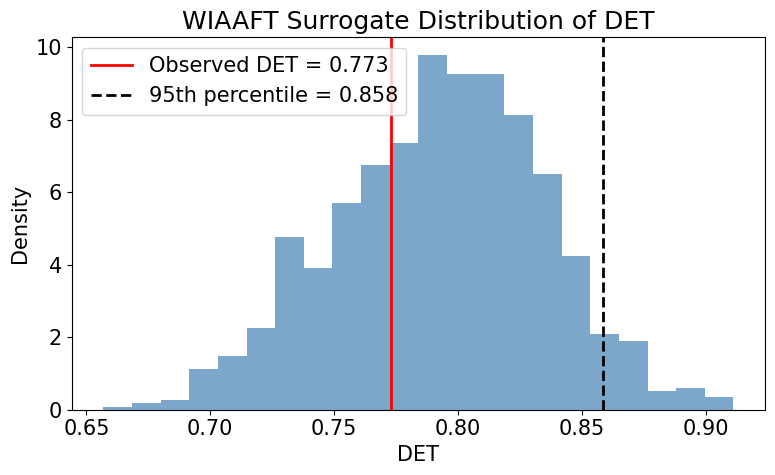

 60%|█████████████████████████▏                | 60/100 [22:21<14:39, 22.00s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.7731157731127696 
 Recurrence rate: 0.05004539870747209 
Threshold:1.3906999999998633 
 Laminarity:0.8712202063291669 
Shannon Entropy:1.3624714714883677 
Rank-order p-value (det):0.693 
Reject null (det) hypothesis:False

 
 

9
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


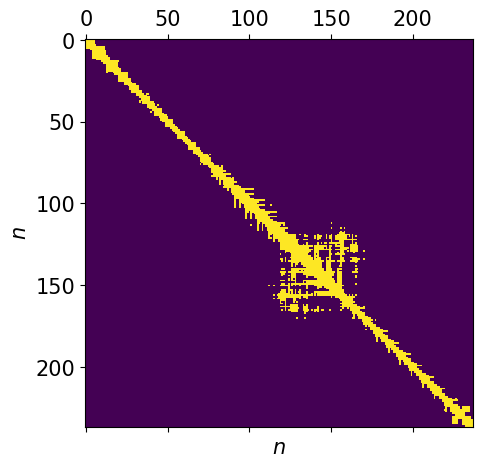

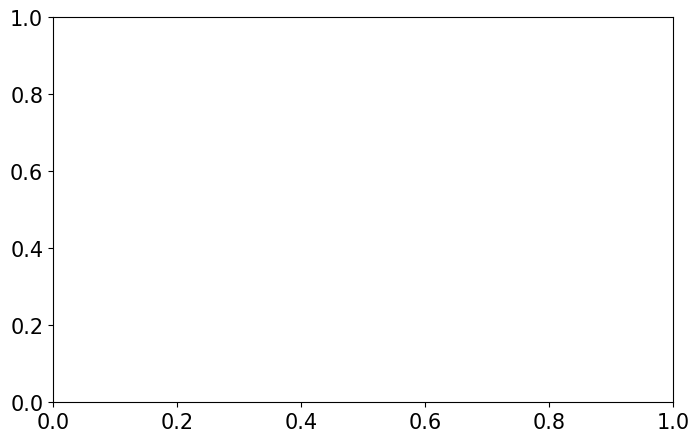

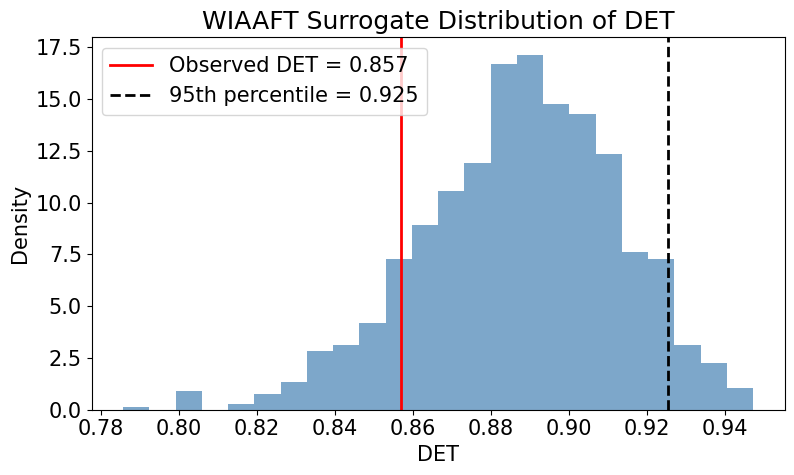

 61%|█████████████████████████▌                | 61/100 [22:42<14:13, 21.89s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8569206842890478 
 Recurrence rate: 0.050009791878082216 
Threshold:1.075299999999898 
 Laminarity:0.927732289067541 
Shannon Entropy:1.5992201366306193 
Rank-order p-value (det):0.88 
Reject null (det) hypothesis:False

 
 

9
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


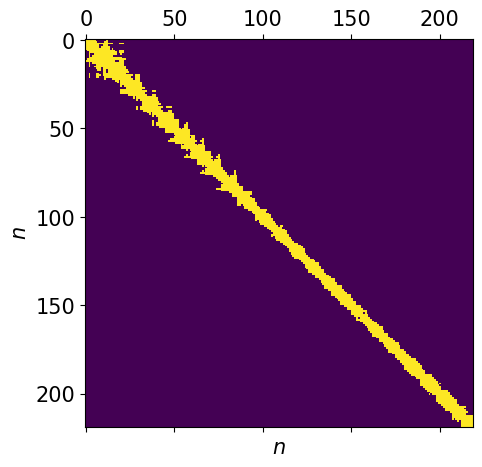

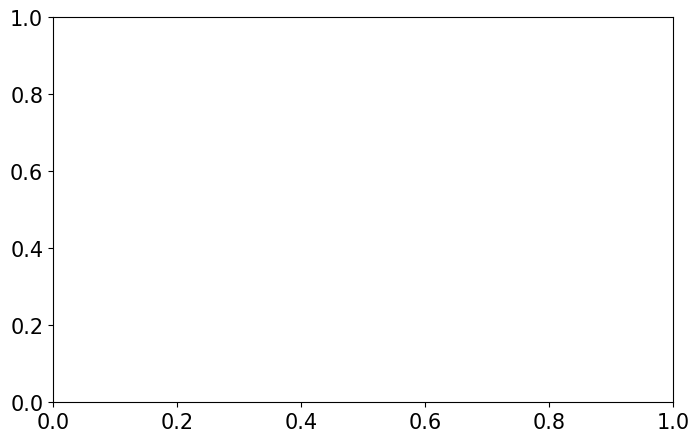

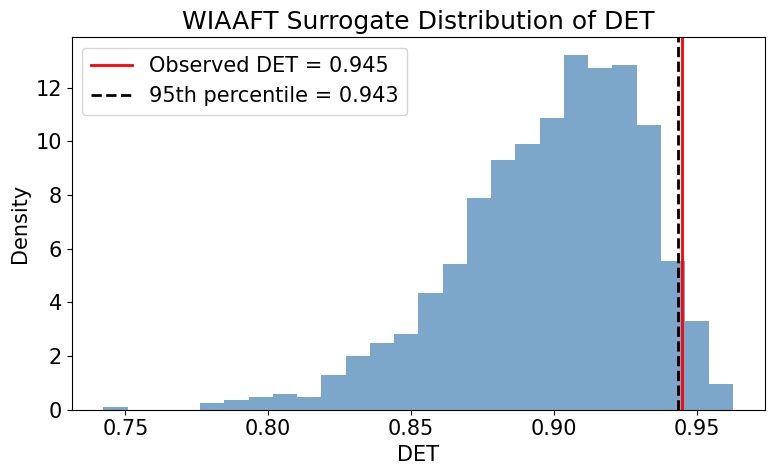

 62%|██████████████████████████                | 62/100 [23:02<13:25, 21.20s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9449541284360323 
 Recurrence rate: 0.05001980776047205 
Threshold:0.6986999999999394 
 Laminarity:0.9812421842393446 
Shannon Entropy:2.090282072633403 
Rank-order p-value (det):0.039 
Reject null (det) hypothesis:True

 
 

10
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


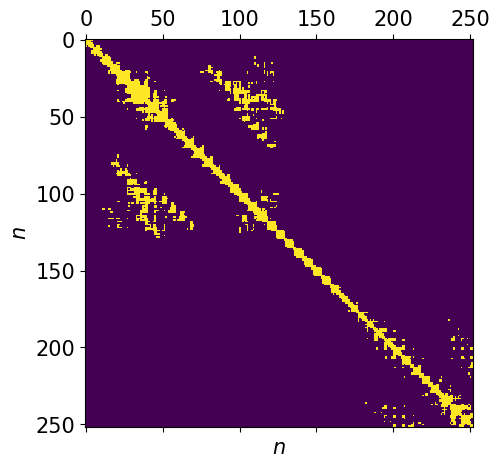

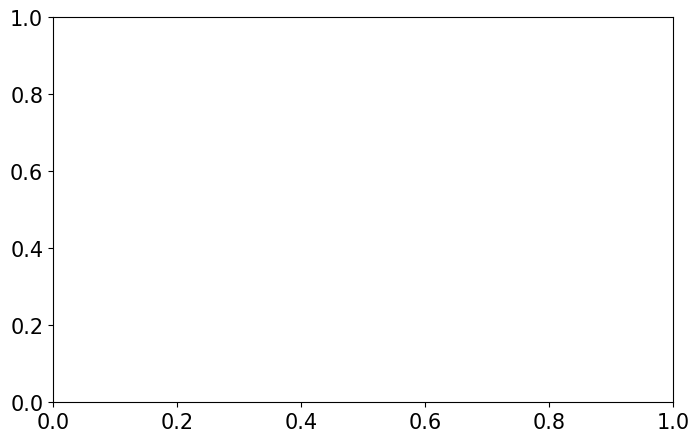

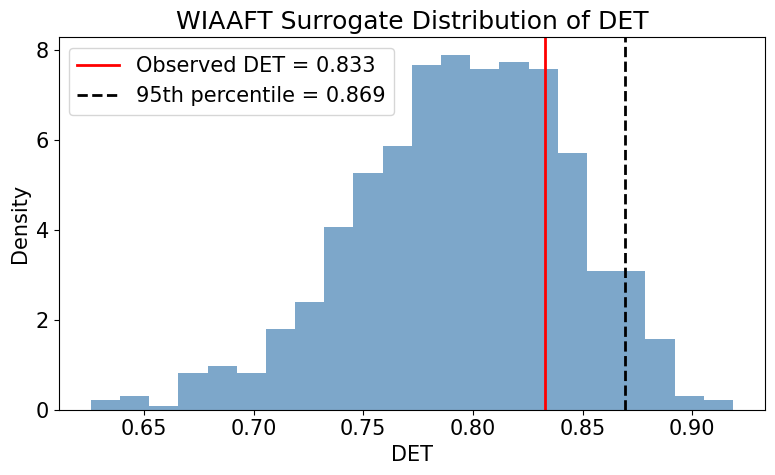

 63%|██████████████████████████▍               | 63/100 [23:25<13:24, 21.74s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8331053351544696 
 Recurrence rate: 0.05001259763164525 
Threshold:0.8970999999999175 
 Laminarity:0.9190806045311113 
Shannon Entropy:1.42481640626247 
Rank-order p-value (det):0.227 
Reject null (det) hypothesis:False

 
 

10
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


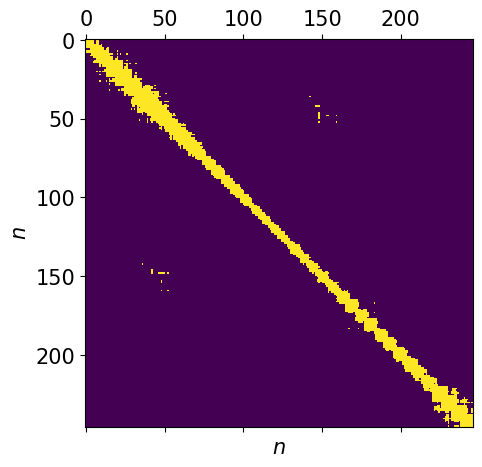

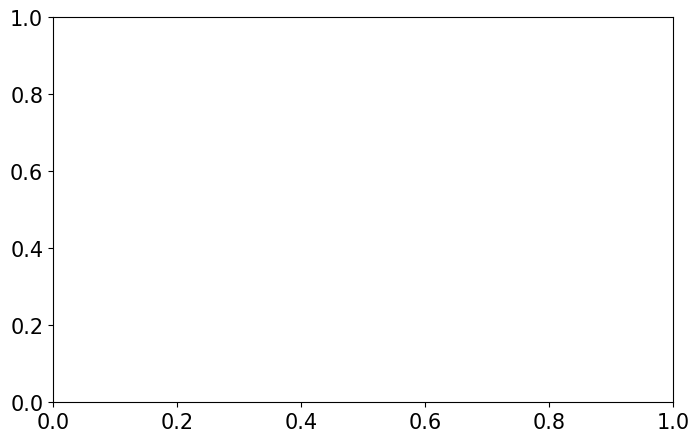

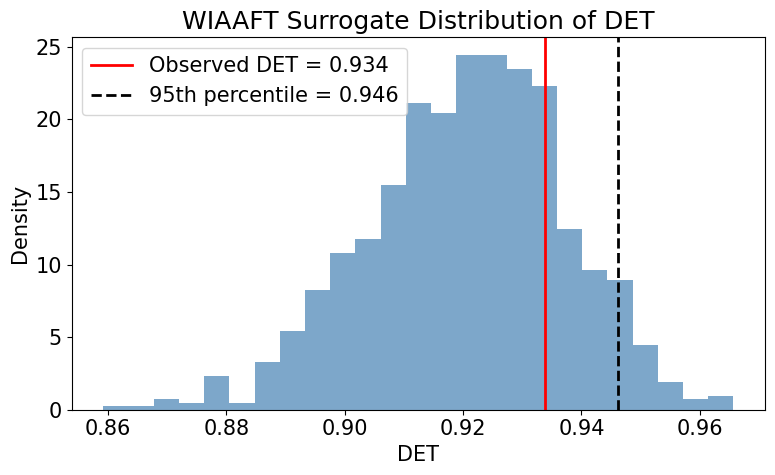

 64%|██████████████████████████▉               | 64/100 [23:48<13:18, 22.17s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9338129496369287 
 Recurrence rate: 0.05000330491109789 
Threshold:1.0906999999998963 
 Laminarity:0.9709187045572674 
Shannon Entropy:1.81708533169435 
Rank-order p-value (det):0.207 
Reject null (det) hypothesis:False

 
 

10
Visible Saturation Plateau
6
WIAAFT surrogate datasets generated


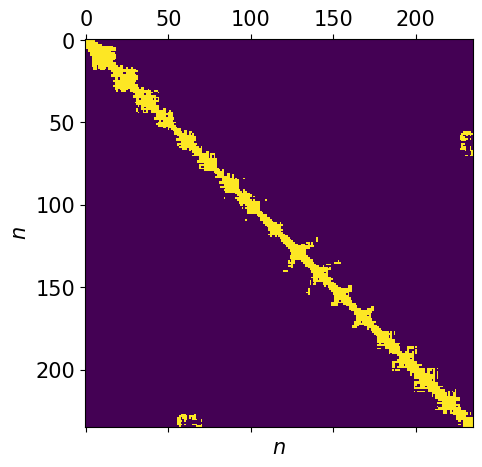

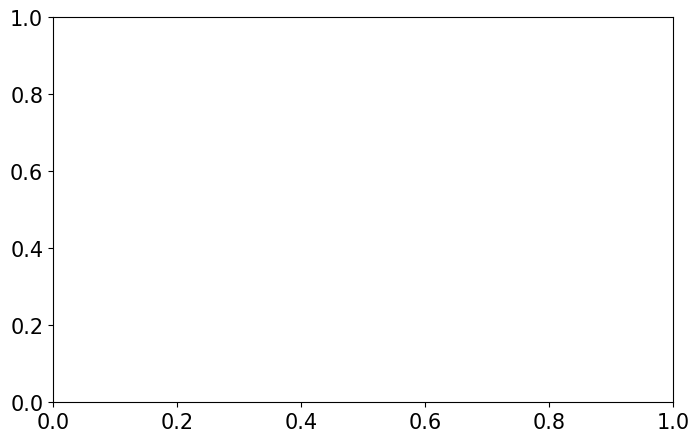

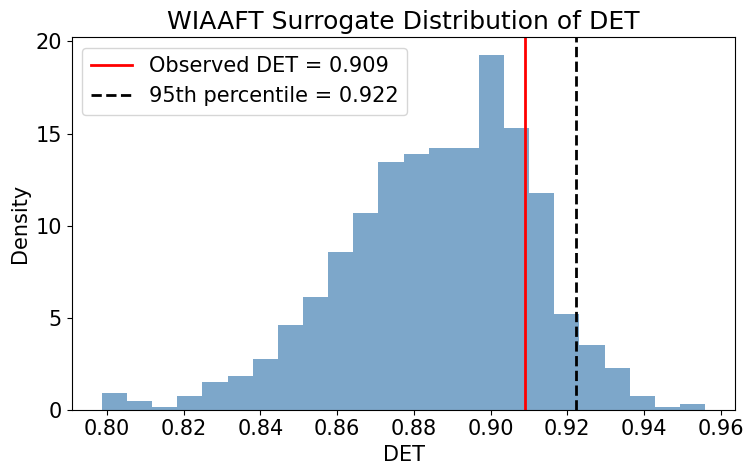

 65%|███████████████████████████▎              | 65/100 [24:09<12:42, 21.80s/it]

RQA  ar1 Embedding dimensions:6 
 DET of original:0.9090189873381764 
 Recurrence rate: 0.05003168854685378 
Threshold:1.012299999999905 
 Laminarity:0.9551212450200683 
Shannon Entropy:1.9784586750517648 
Rank-order p-value (det):0.178 
Reject null (det) hypothesis:False

 
 

10
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


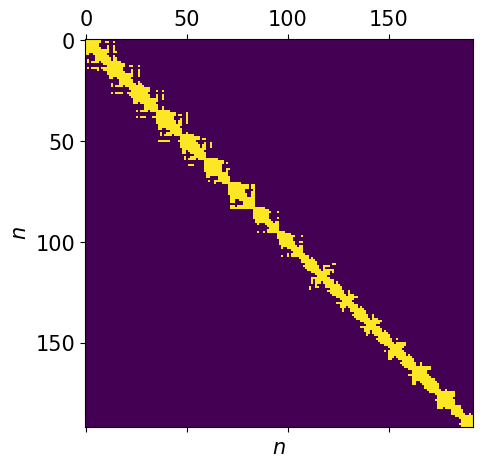

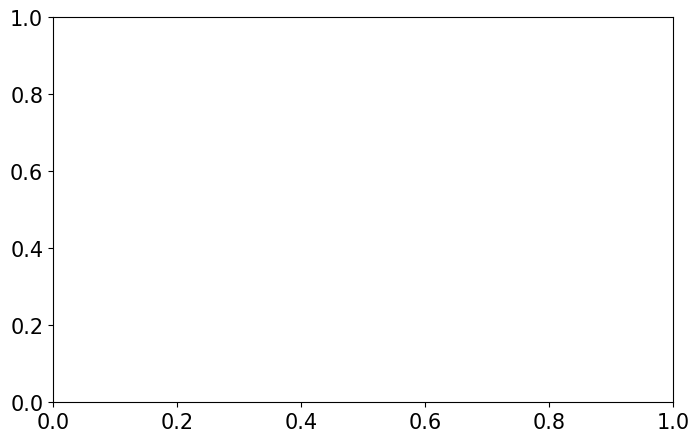

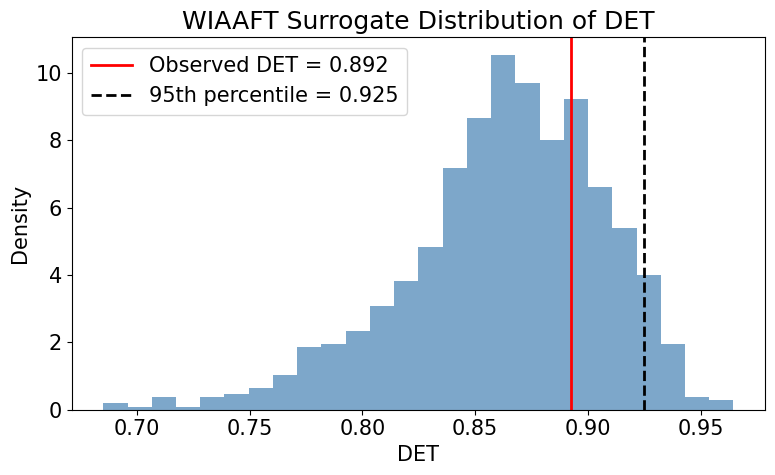

 66%|███████████████████████████▋              | 66/100 [24:28<11:57, 21.09s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8922518159752285 
 Recurrence rate: 0.05002170138888889 
Threshold:0.6050999999999497 
 Laminarity:0.9517353579124093 
Shannon Entropy:1.7362113198262 
Rank-order p-value (det):0.27 
Reject null (det) hypothesis:False

 
 

10
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


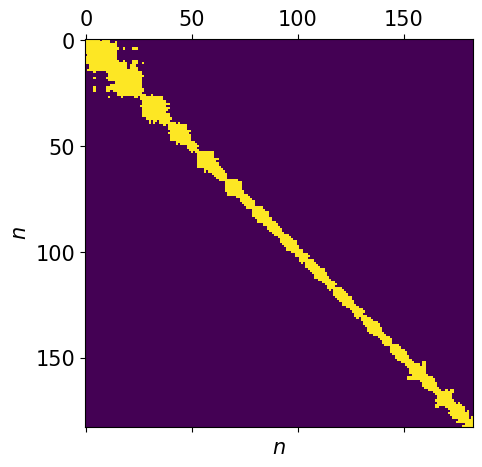

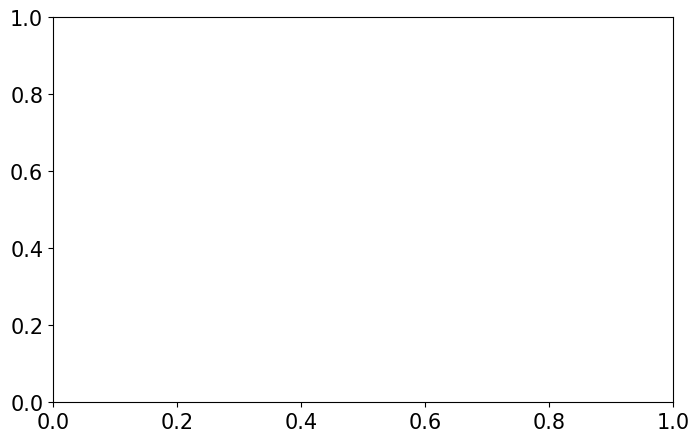

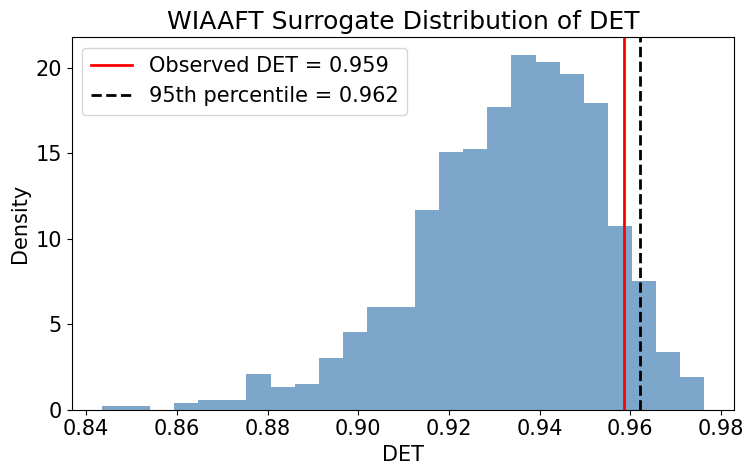

 67%|████████████████████████████▏             | 67/100 [24:48<11:22, 20.67s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9585006693376272 
 Recurrence rate: 0.05007614440562573 
Threshold:1.0051999999999057 
 Laminarity:0.9838998211032565 
Shannon Entropy:2.3872699809756917 
Rank-order p-value (det):0.086 
Reject null (det) hypothesis:False

 
 

10
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


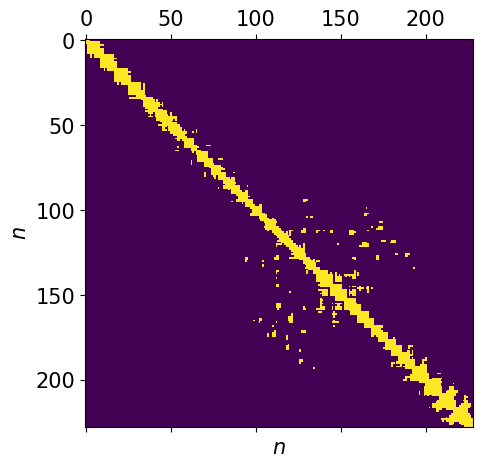

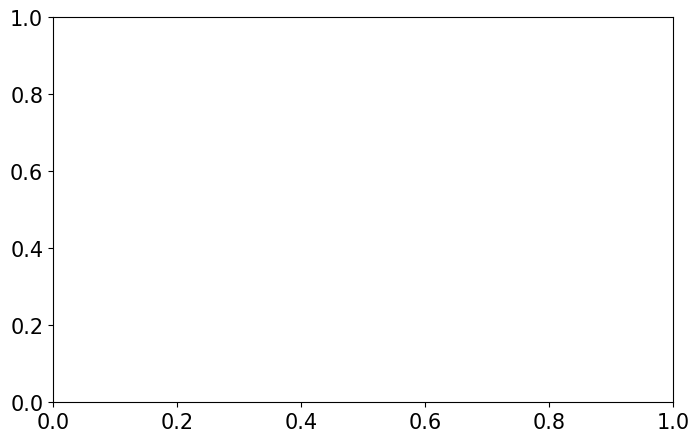

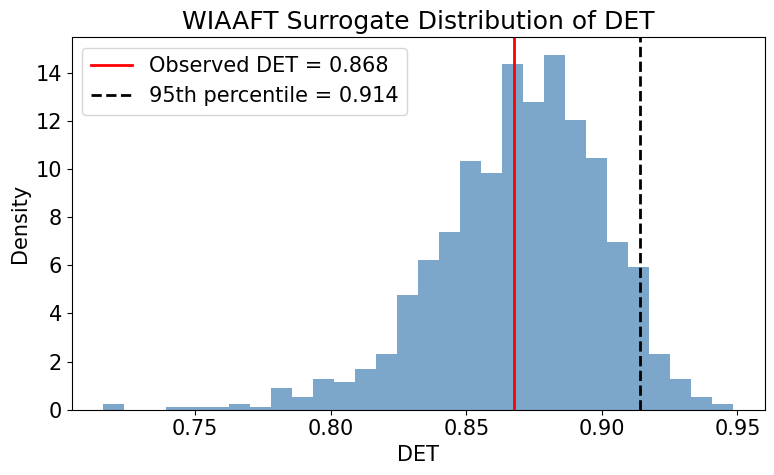

 68%|████████████████████████████▌             | 68/100 [25:13<11:39, 21.87s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8676222596928009 
 Recurrence rate: 0.05001538935056941 
Threshold:1.2010999999998841 
 Laminarity:0.9473076923040489 
Shannon Entropy:1.6438112338494943 
Rank-order p-value (det):0.562 
Reject null (det) hypothesis:False

 
 

10
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


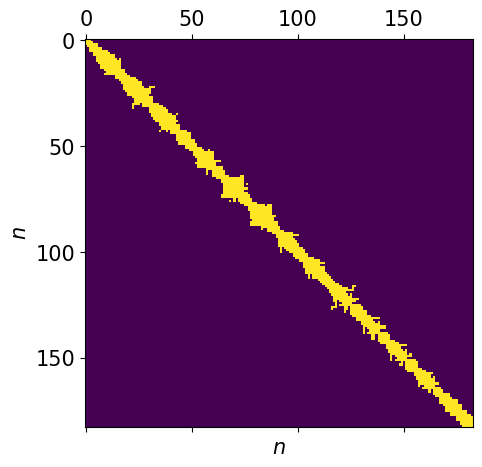

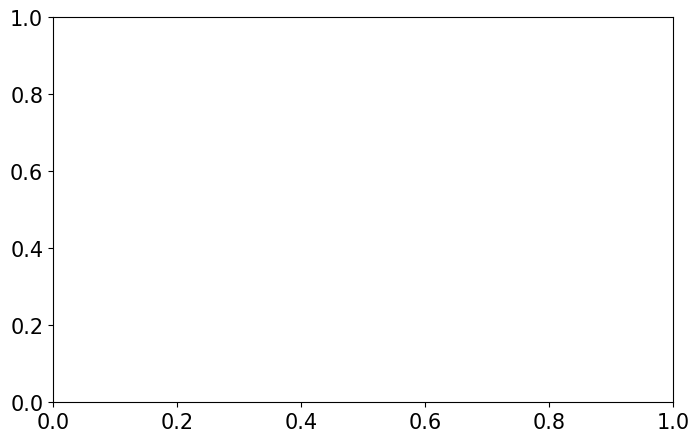

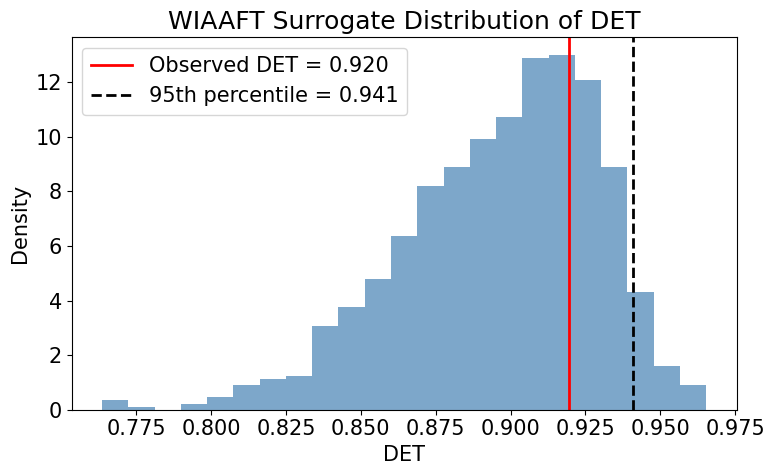

 69%|████████████████████████████▉             | 69/100 [25:33<11:06, 21.51s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9195710455702443 
 Recurrence rate: 0.05001642330317418 
Threshold:0.6856999999999408 
 Laminarity:0.9767164179046167 
Shannon Entropy:2.1586012113623196 
Rank-order p-value (det):0.278 
Reject null (det) hypothesis:False

 
 

10
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


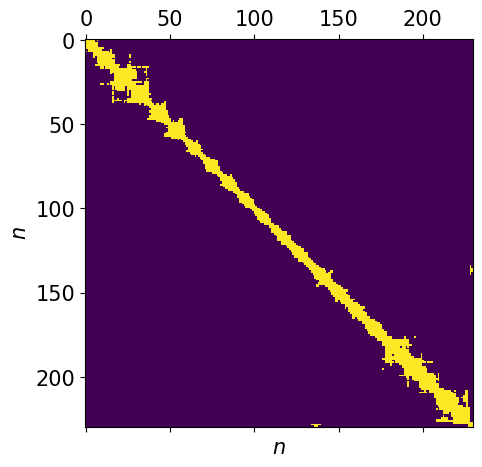

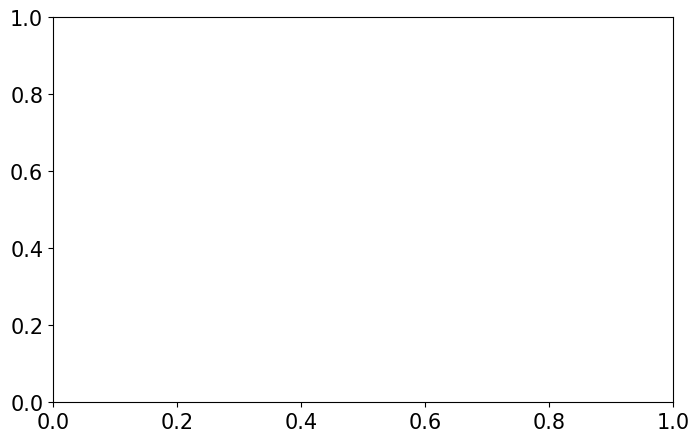

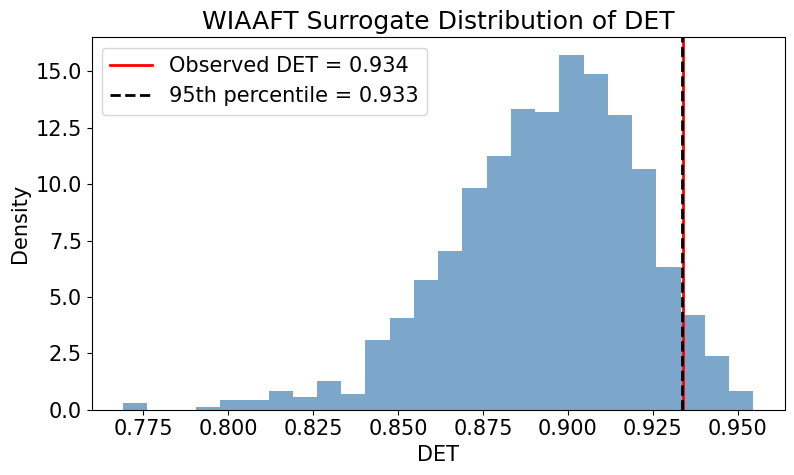

 70%|█████████████████████████████▍            | 70/100 [25:53<10:31, 21.06s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9337748344332212 
 Recurrence rate: 0.05001890359168242 
Threshold:0.765799999999932 
 Laminarity:0.9750566893387187 
Shannon Entropy:2.2085444816322406 
Rank-order p-value (det):0.05 
Reject null (det) hypothesis:False

 
 

10
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


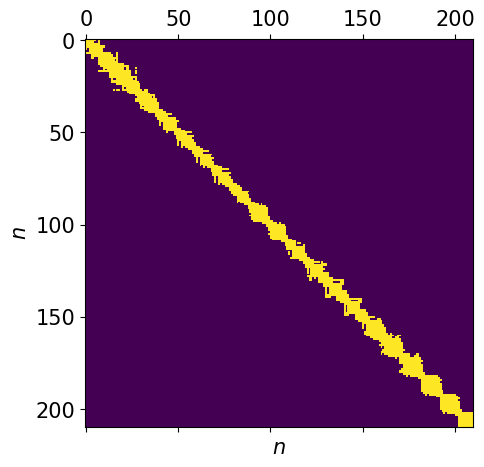

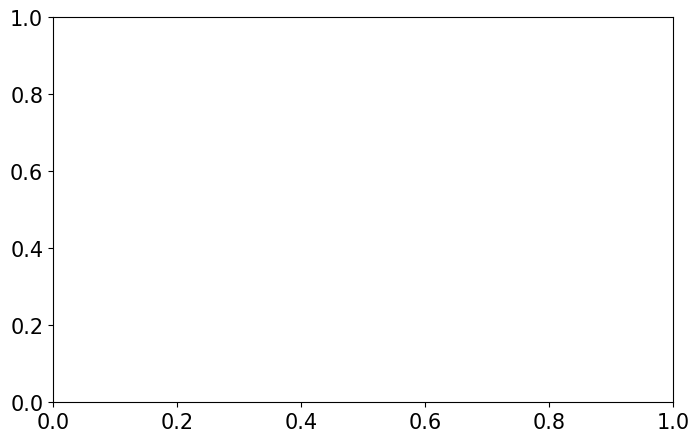

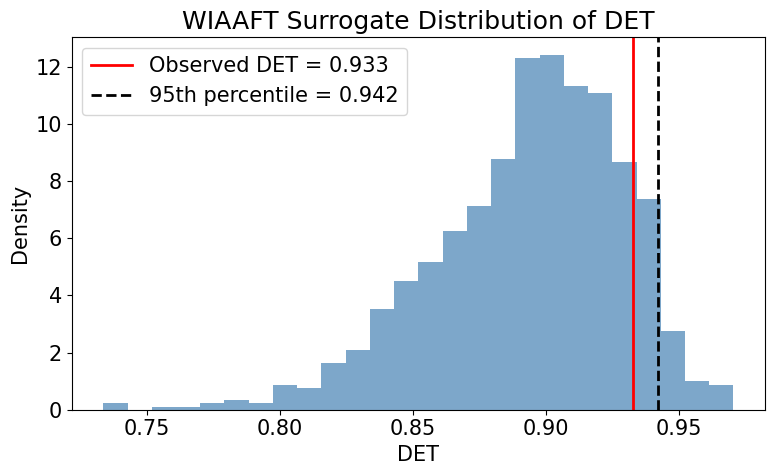

 71%|█████████████████████████████▊            | 71/100 [26:14<10:07, 20.94s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9328657314582522 
 Recurrence rate: 0.05002267573696145 
Threshold:0.7945999999999288 
 Laminarity:0.9714415231143634 
Shannon Entropy:1.9937910430772237 
Rank-order p-value (det):0.123 
Reject null (det) hypothesis:False

 
 

10
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


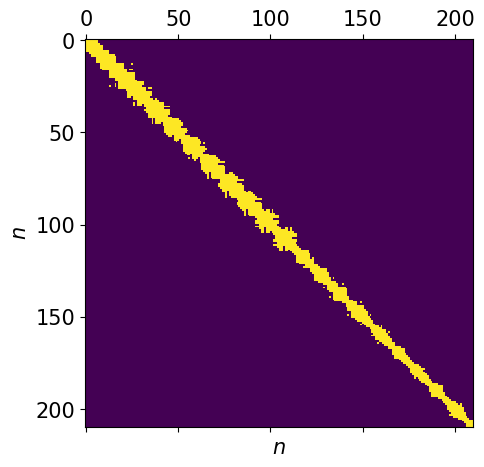

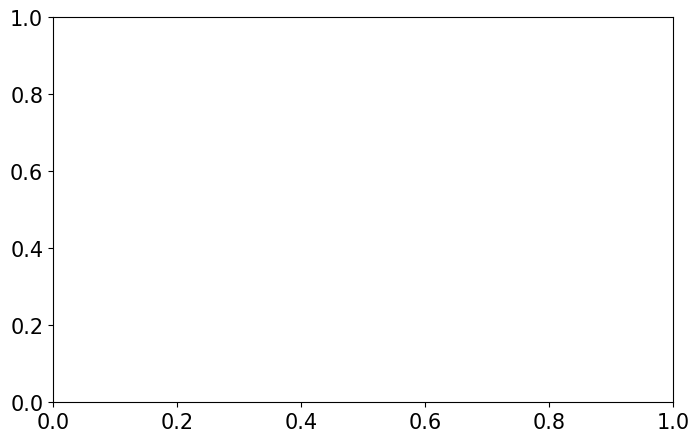

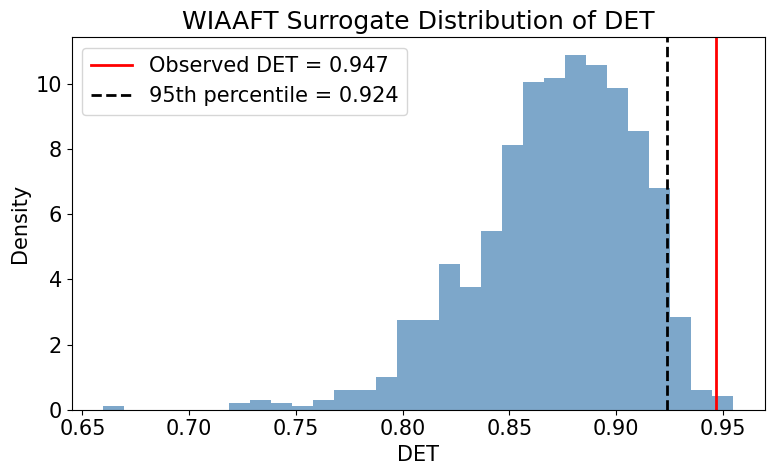

 72%|██████████████████████████████▏           | 72/100 [26:35<09:43, 20.83s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9468937875704064 
 Recurrence rate: 0.05002267573696145 
Threshold:0.7857999999999298 
 Laminarity:0.9814143245649075 
Shannon Entropy:2.192573770821791 
Rank-order p-value (det):0.005 
Reject null (det) hypothesis:True

 
 

11
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


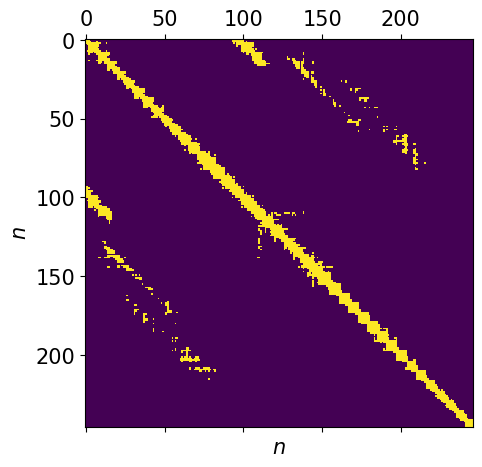

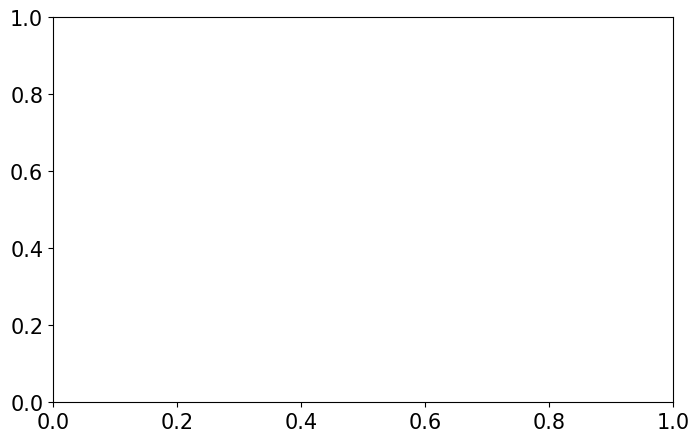

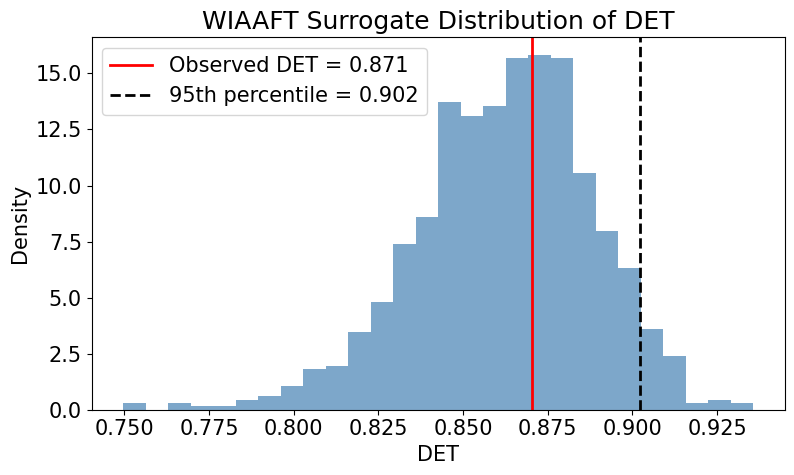

 73%|██████████████████████████████▋           | 73/100 [27:03<10:21, 23.03s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8705035971191709 
 Recurrence rate: 0.05000330491109789 
Threshold:1.7899999999998193 
 Laminarity:0.9388631857206251 
Shannon Entropy:1.6152332535320357 
Rank-order p-value (det):0.405 
Reject null (det) hypothesis:False

 
 

11
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


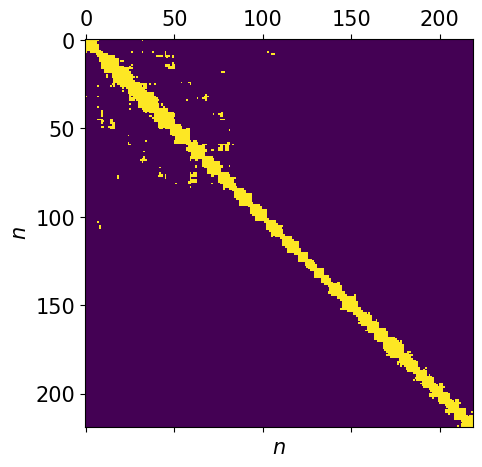

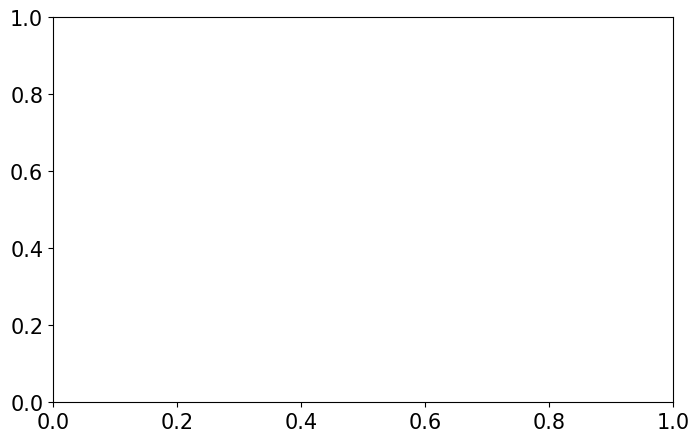

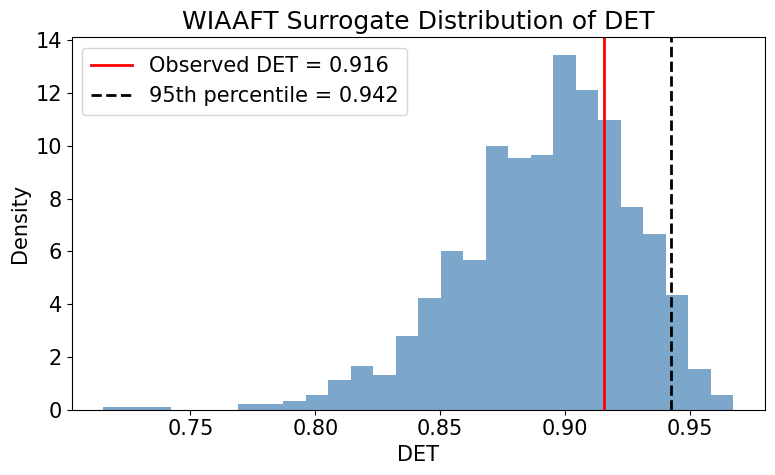

 74%|███████████████████████████████           | 74/100 [27:23<09:39, 22.29s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9155963302710294 
 Recurrence rate: 0.05001980776047205 
Threshold:1.0255999999999035 
 Laminarity:0.9624843684828576 
Shannon Entropy:1.7800260690132488 
Rank-order p-value (det):0.258 
Reject null (det) hypothesis:False

 
 

11
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


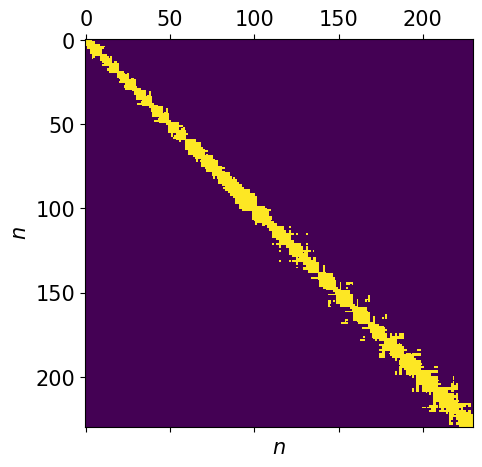

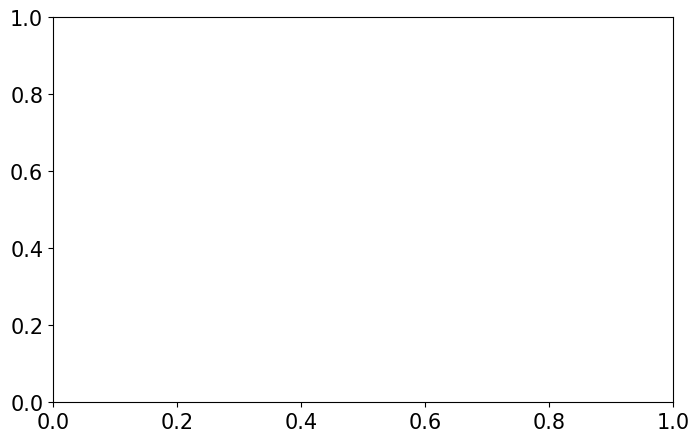

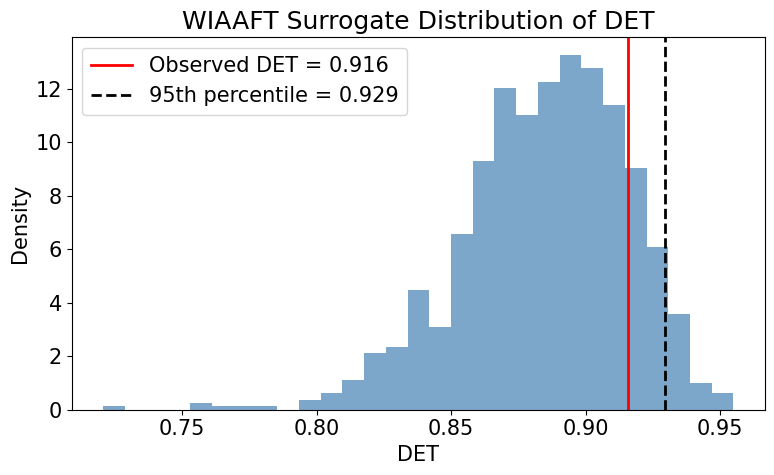

 75%|███████████████████████████████▌          | 75/100 [27:44<09:04, 21.78s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9155629139034952 
 Recurrence rate: 0.05001890359168242 
Threshold:0.7690999999999316 
 Laminarity:0.9644746787567481 
Shannon Entropy:2.108274237565714 
Rank-order p-value (det):0.153 
Reject null (det) hypothesis:False

 
 

11
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


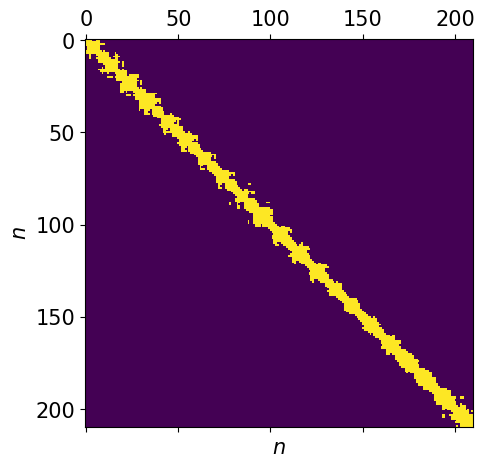

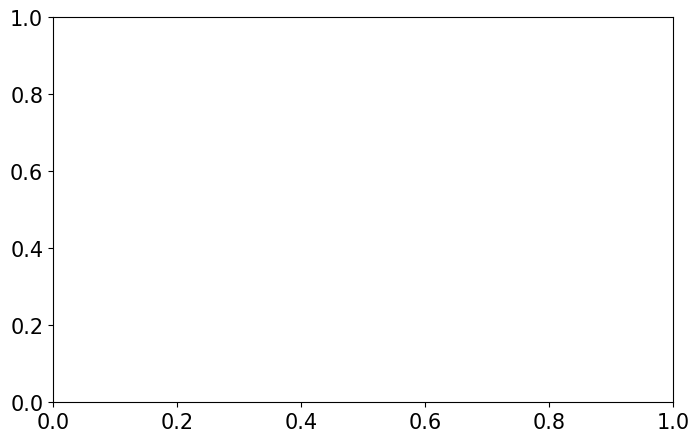

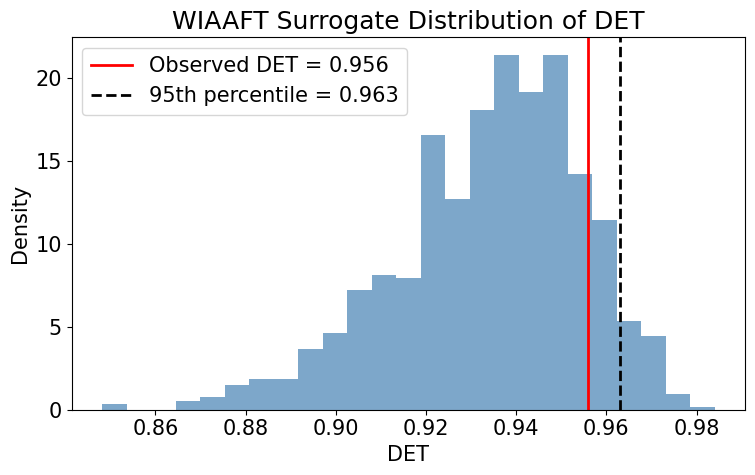

 76%|███████████████████████████████▉          | 76/100 [28:04<08:31, 21.32s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9559118236425055 
 Recurrence rate: 0.05002267573696145 
Threshold:1.0273999999999033 
 Laminarity:0.97869446962385 
Shannon Entropy:1.9038282523185113 
Rank-order p-value (det):0.136 
Reject null (det) hypothesis:False

 
 

11
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


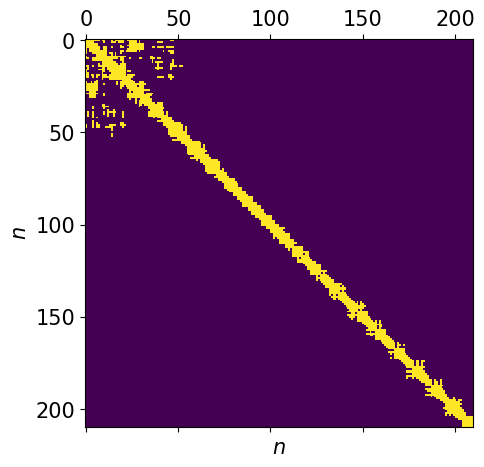

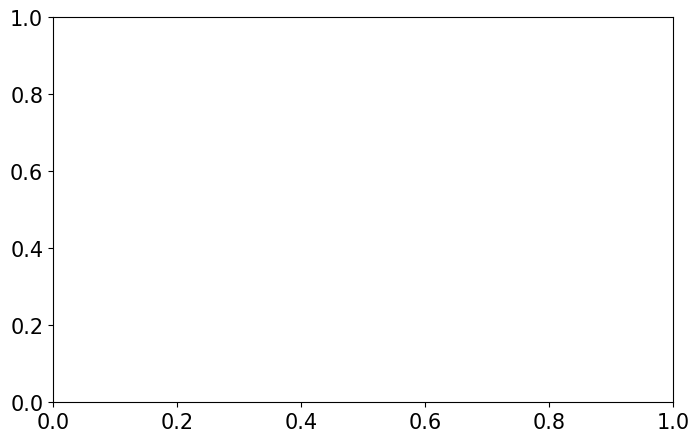

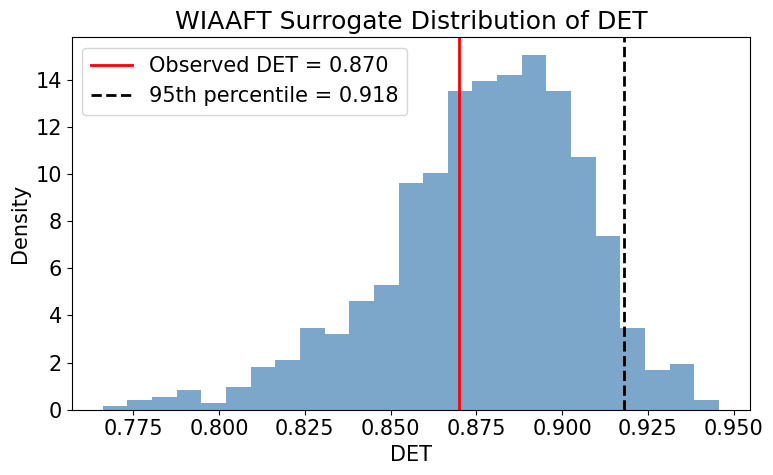

 77%|████████████████████████████████▎         | 77/100 [28:24<08:00, 20.91s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8698698698655162 
 Recurrence rate: 0.05006802721088435 
Threshold:1.011599999999905 
 Laminarity:0.9402173913000896 
Shannon Entropy:1.7214461428065917 
Rank-order p-value (det):0.651 
Reject null (det) hypothesis:False

 
 

11
Visible Saturation Plateau
4
WIAAFT surrogate datasets generated


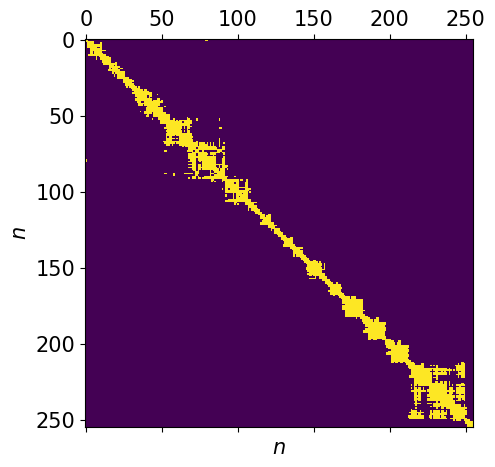

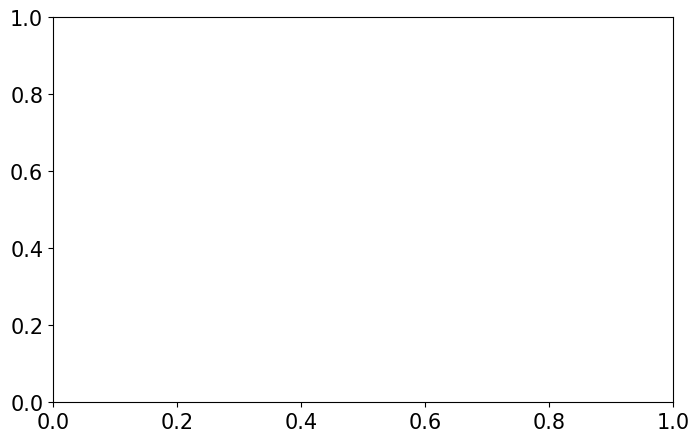

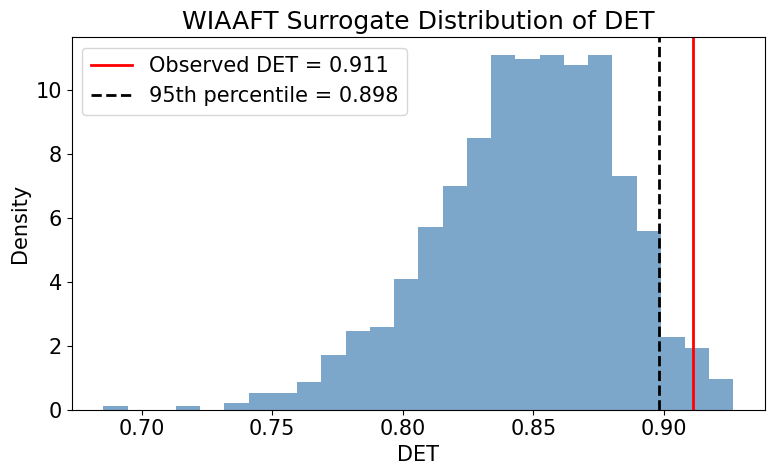

 78%|████████████████████████████████▊         | 78/100 [28:42<07:19, 19.98s/it]

RQA  ar1 Embedding dimensions:4 
 DET of original:0.9112741827854861 
 Recurrence rate: 0.050026912725874666 
Threshold:0.29569999999998375 
 Laminarity:0.9566553950170408 
Shannon Entropy:2.092490088254653 
Rank-order p-value (det):0.021 
Reject null (det) hypothesis:True

 
 

12
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


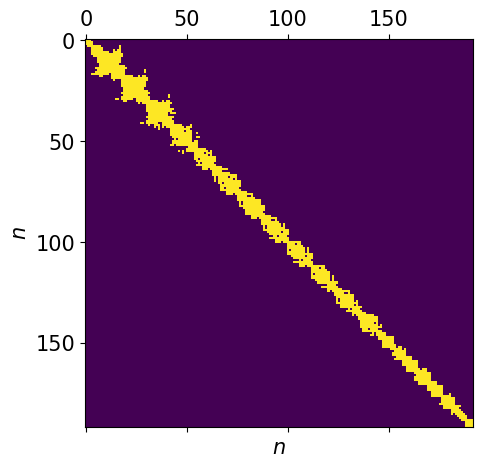

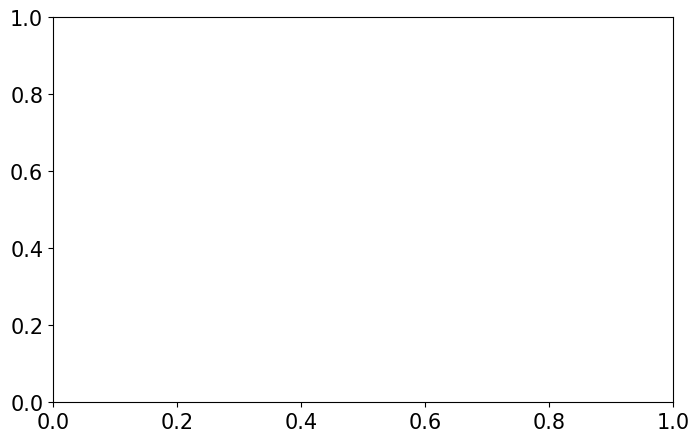

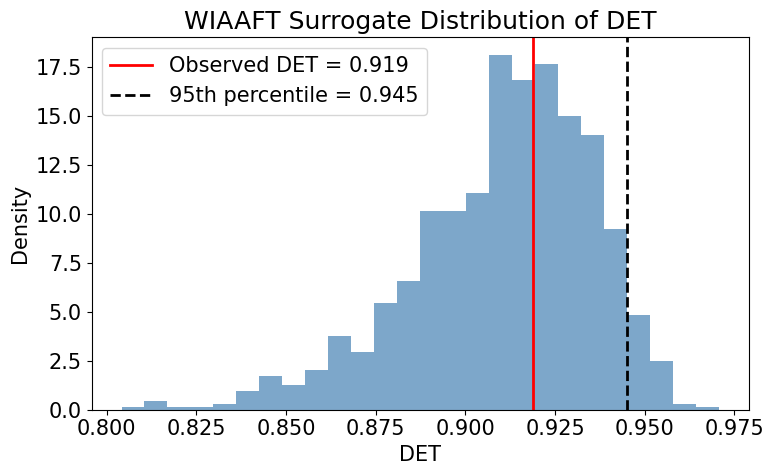

 79%|█████████████████████████████████▏        | 79/100 [29:03<07:06, 20.29s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9188861985416533 
 Recurrence rate: 0.05002170138888889 
Threshold:0.9456999999999122 
 Laminarity:0.9674620390403067 
Shannon Entropy:2.085519730444744 
Rank-order p-value (det):0.423 
Reject null (det) hypothesis:False

 
 

12
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


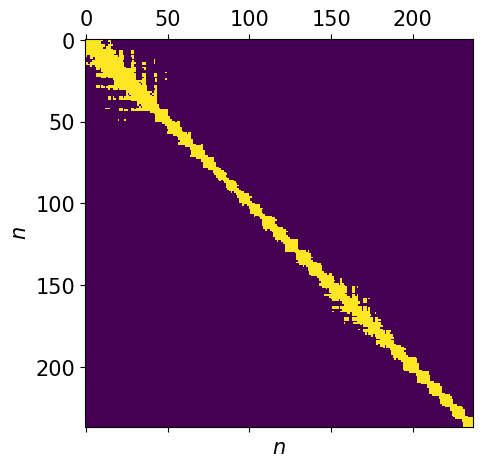

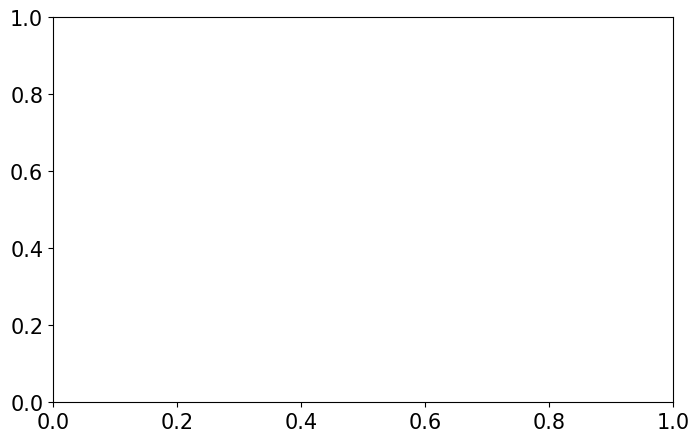

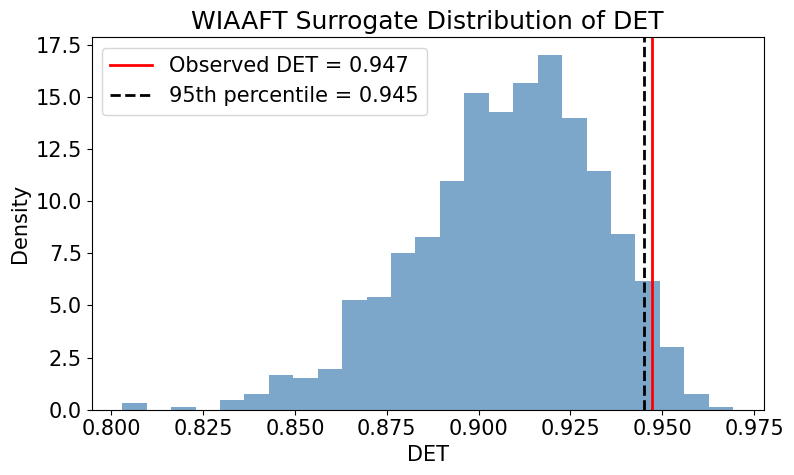

 80%|█████████████████████████████████▌        | 80/100 [29:25<06:58, 20.91s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9471228615826317 
 Recurrence rate: 0.050009791878082216 
Threshold:0.9789999999999085 
 Laminarity:0.9814880740442098 
Shannon Entropy:1.8447643212803304 
Rank-order p-value (det):0.037 
Reject null (det) hypothesis:True

 
 

13
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


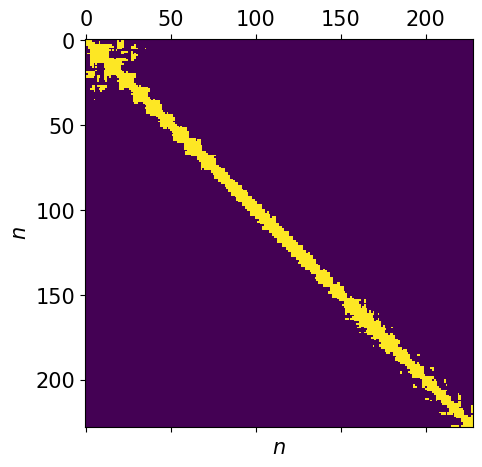

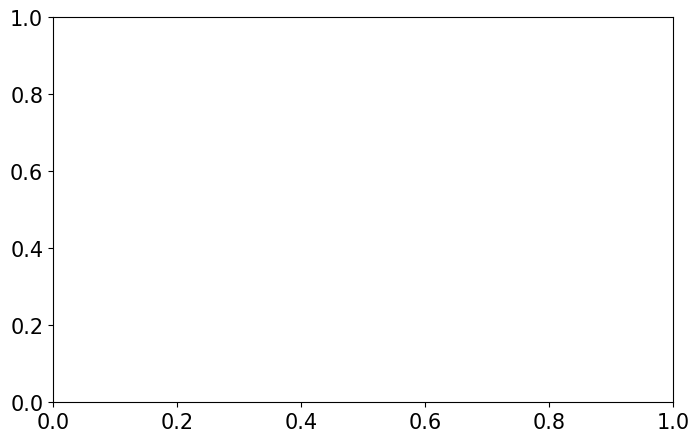

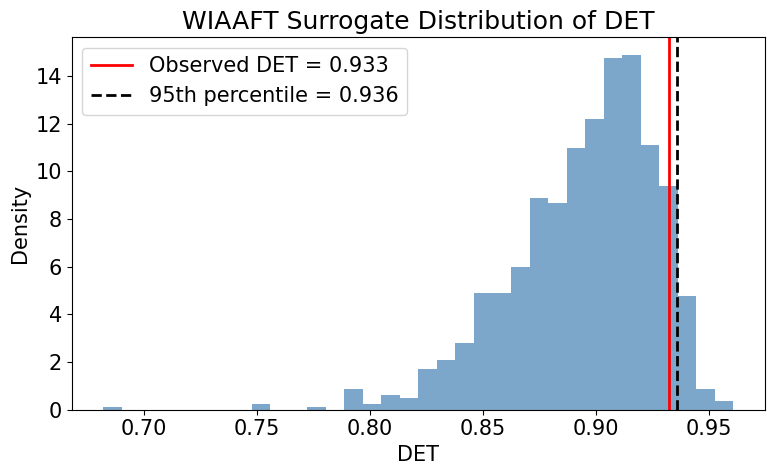

 81%|██████████████████████████████████        | 81/100 [29:46<06:37, 20.91s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9325463743636908 
 Recurrence rate: 0.05001538935056941 
Threshold:0.7900999999999293 
 Laminarity:0.975384615380864 
Shannon Entropy:1.7779183210431346 
Rank-order p-value (det):0.076 
Reject null (det) hypothesis:False

 
 

13
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


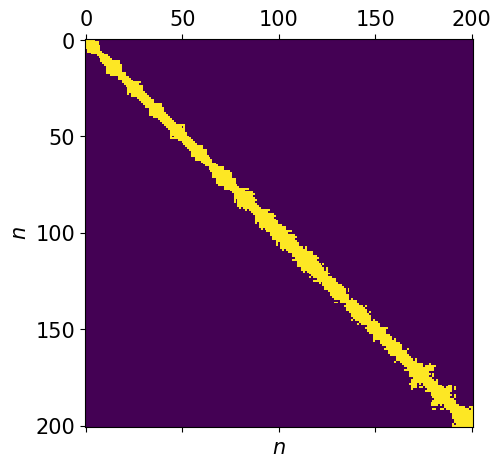

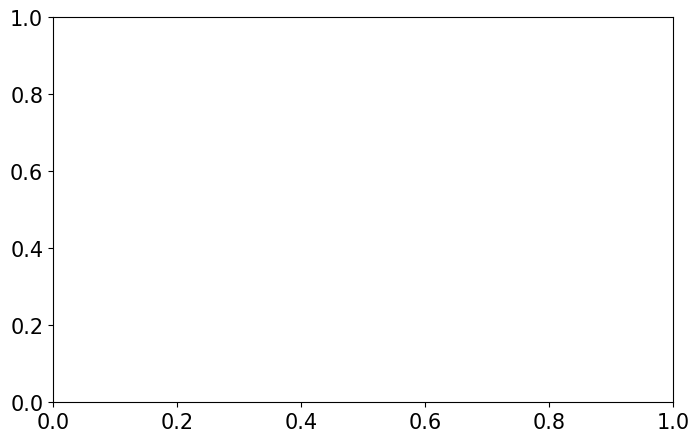

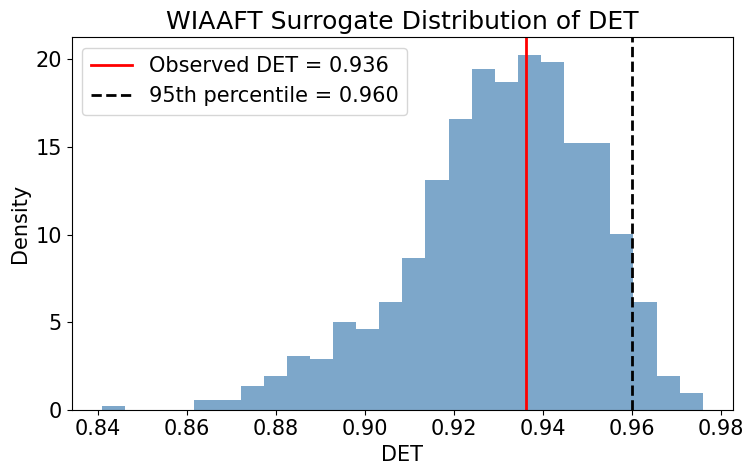

 82%|██████████████████████████████████▍       | 82/100 [30:08<06:23, 21.31s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.936263736258592 
 Recurrence rate: 0.050023514269448774 
Threshold:1.2449999999998793 
 Laminarity:0.9767441860416787 
Shannon Entropy:2.1652766840576634 
Rank-order p-value (det):0.428 
Reject null (det) hypothesis:False

 
 

13
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


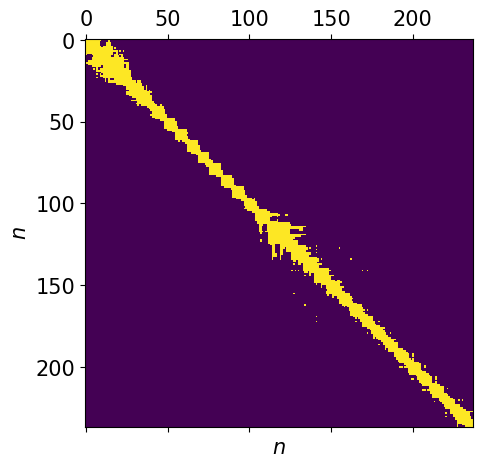

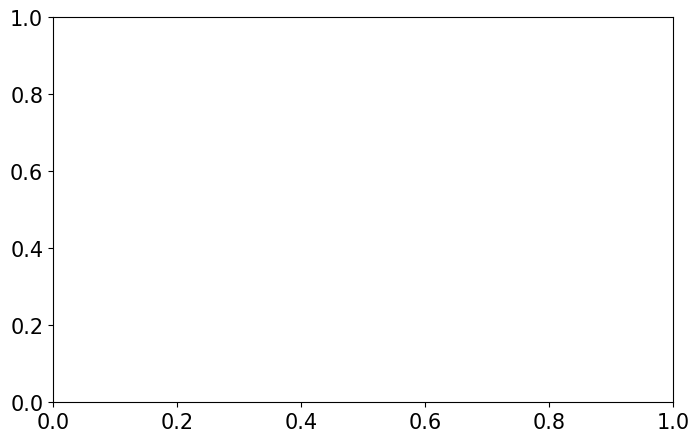

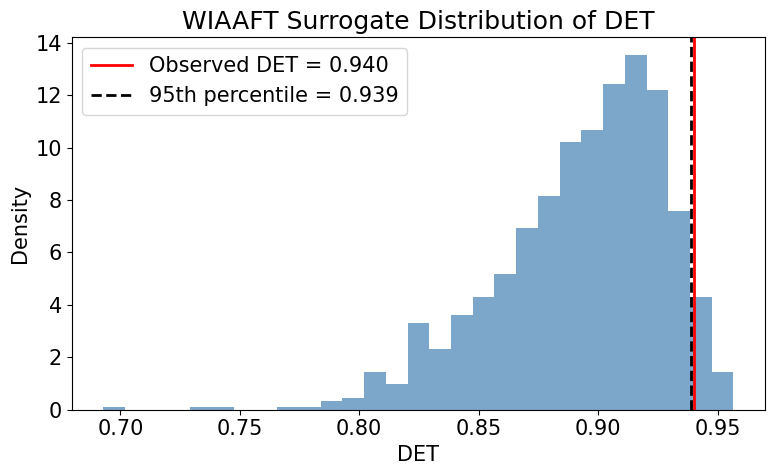

 83%|██████████████████████████████████▊       | 83/100 [30:30<06:02, 21.30s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9401709401672876 
 Recurrence rate: 0.05004539870747209 
Threshold:0.701899999999939 
 Laminarity:0.9694059053683053 
Shannon Entropy:2.0425499748448335 
Rank-order p-value (det):0.048 
Reject null (det) hypothesis:True

 
 

14
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


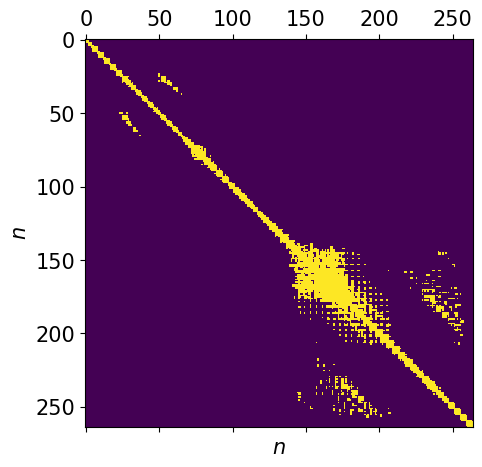

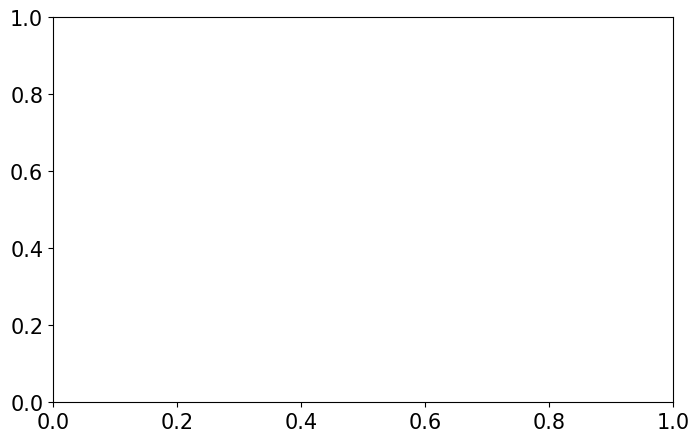

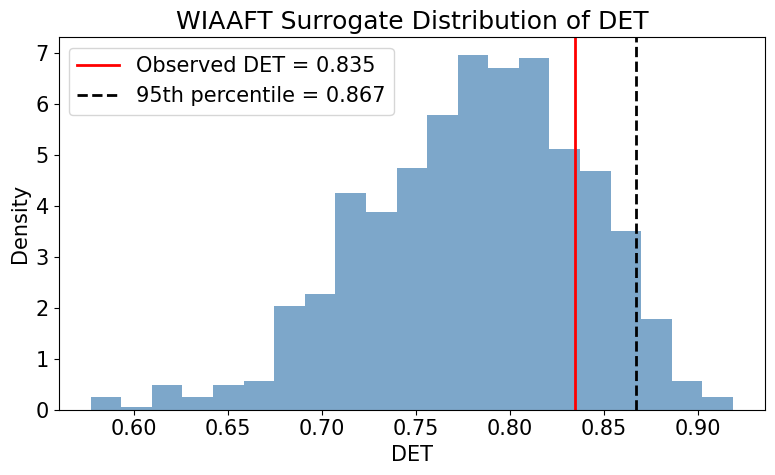

 84%|███████████████████████████████████▎      | 84/100 [30:53<05:49, 21.85s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8348851644915118 
 Recurrence rate: 0.050017217630854 
Threshold:0.6819999999999412 
 Laminarity:0.9122203098080545 
Shannon Entropy:1.5001369443138324 
Rank-order p-value (det):0.193 
Reject null (det) hypothesis:False

 
 

14
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


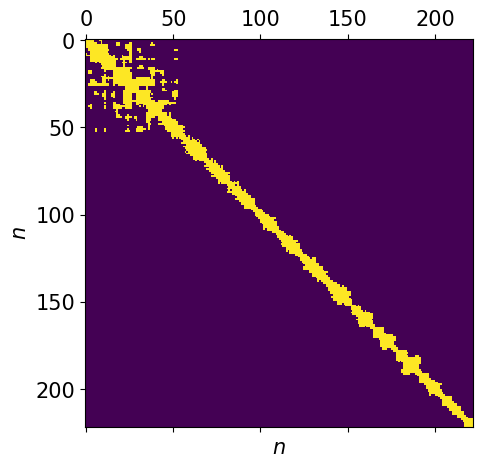

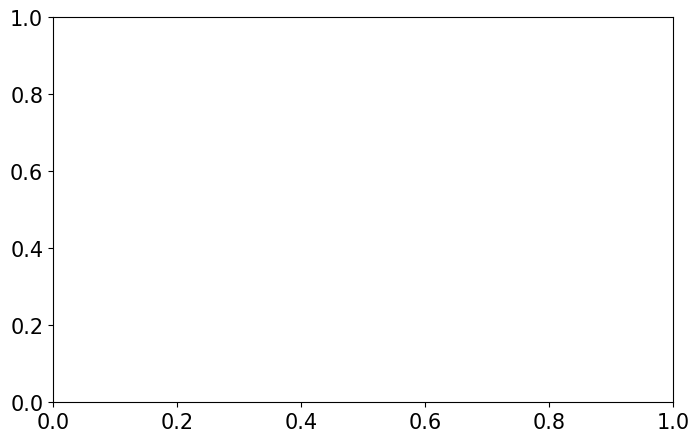

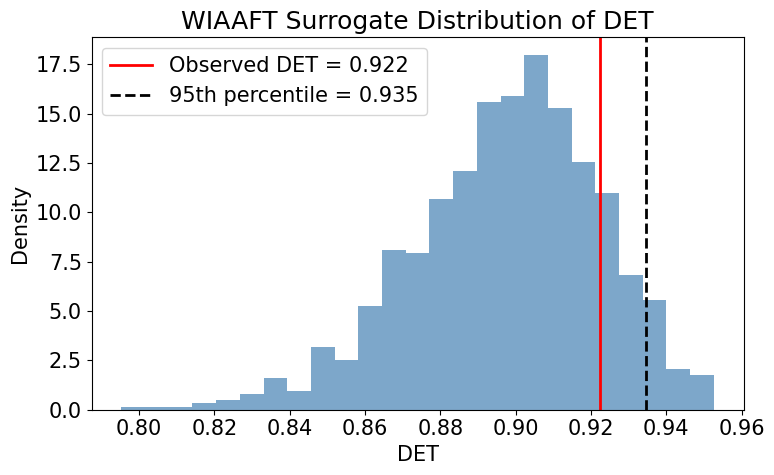

 85%|███████████████████████████████████▋      | 85/100 [31:12<05:17, 21.14s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.9224598930440177 
 Recurrence rate: 0.05003652300949598 
Threshold:0.557199999999955 
 Laminarity:0.963909164635183 
Shannon Entropy:2.020305538472089 
Rank-order p-value (det):0.163 
Reject null (det) hypothesis:False

 
 

14
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


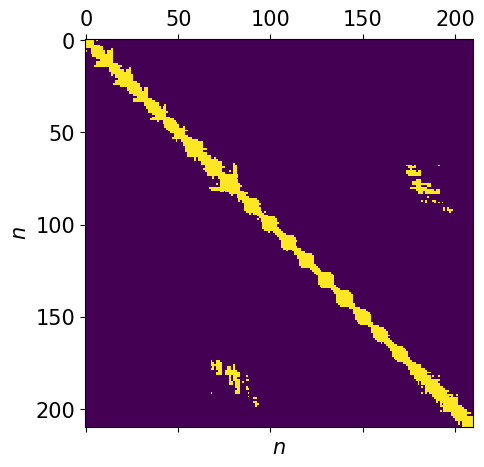

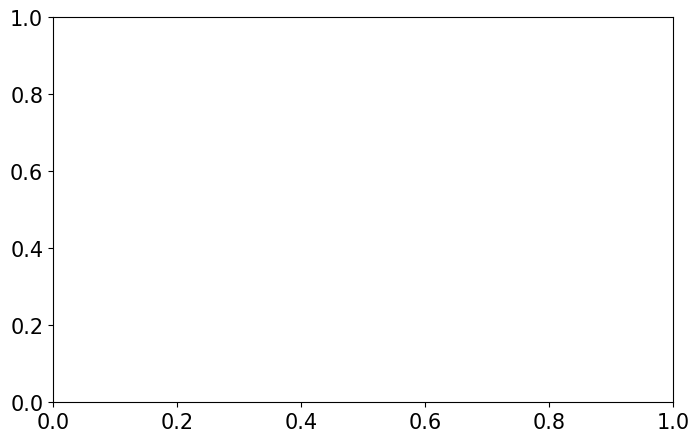

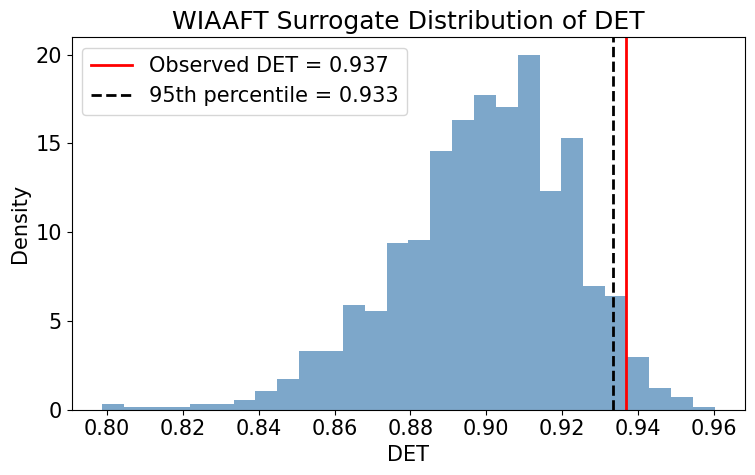

 86%|████████████████████████████████████      | 86/100 [31:35<05:02, 21.64s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9368737474902963 
 Recurrence rate: 0.05002267573696145 
Threshold:1.5318999999998477 
 Laminarity:0.968721668173306 
Shannon Entropy:1.9828729046367597 
Rank-order p-value (det):0.031 
Reject null (det) hypothesis:True

 
 

15
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


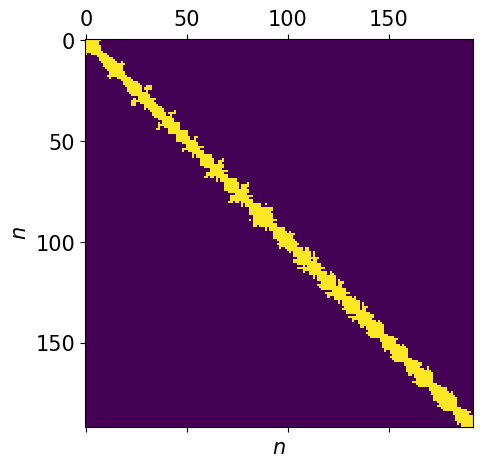

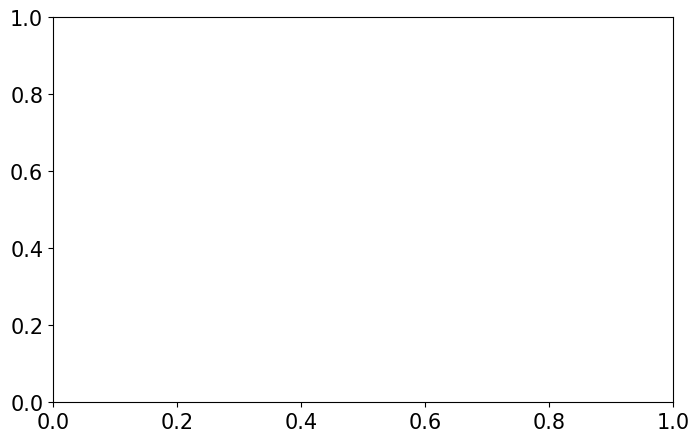

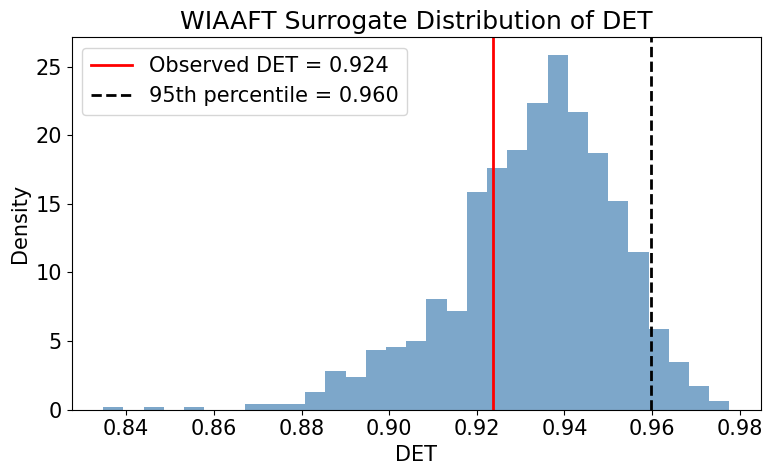

 87%|████████████████████████████████████▌     | 87/100 [31:57<04:40, 21.55s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9237288135537305 
 Recurrence rate: 0.05002170138888889 
Threshold:1.4966999999998516 
 Laminarity:0.9728850325326851 
Shannon Entropy:1.934068265392359 
Rank-order p-value (det):0.729 
Reject null (det) hypothesis:False

 
 

15
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


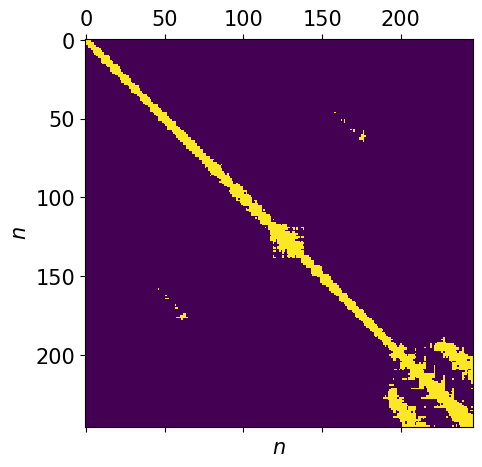

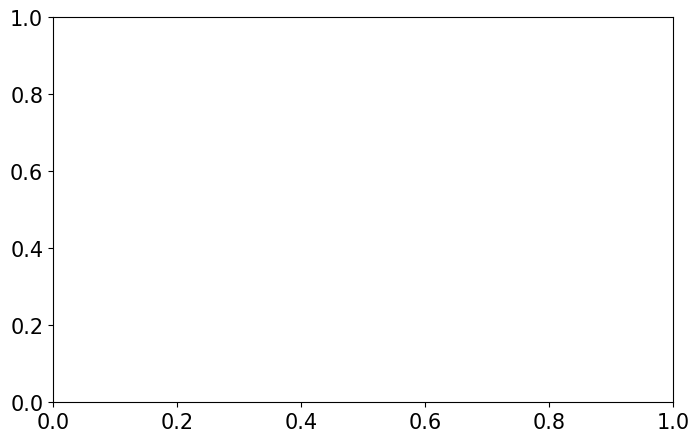

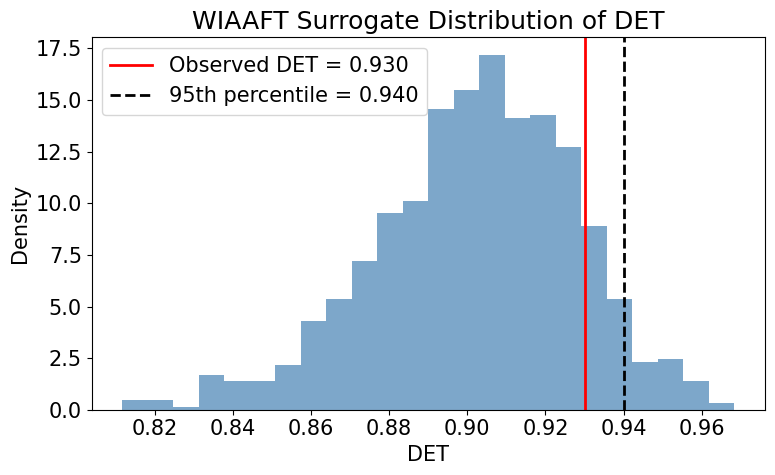

 88%|████████████████████████████████████▉     | 88/100 [32:18<04:19, 21.62s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9302158273347835 
 Recurrence rate: 0.05000330491109789 
Threshold:0.9277999999999141 
 Laminarity:0.9669530733609817 
Shannon Entropy:2.0338111423951117 
Rank-order p-value (det):0.126 
Reject null (det) hypothesis:False

 
 

15
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


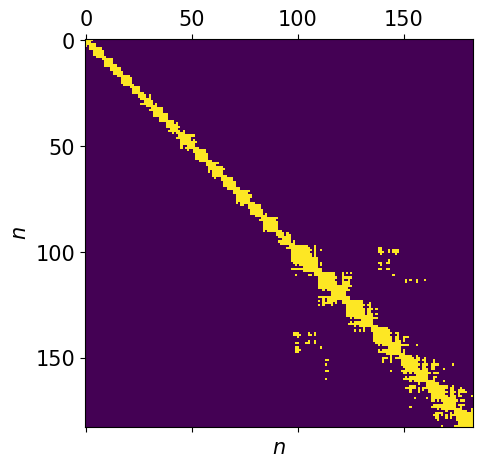

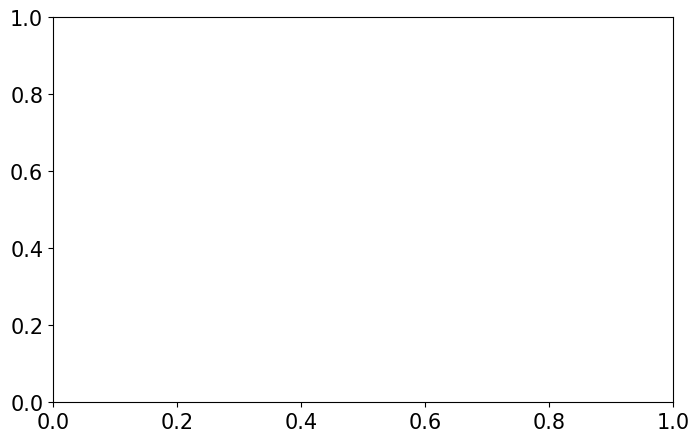

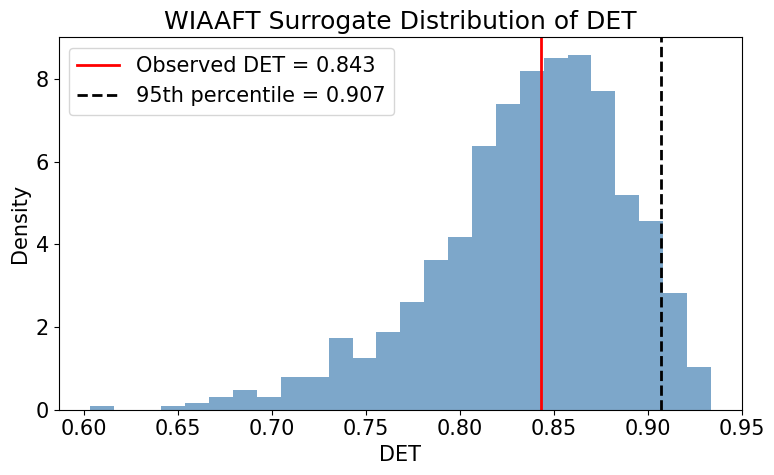

 89%|█████████████████████████████████████▍    | 89/100 [32:37<03:46, 20.64s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8431635388683435 
 Recurrence rate: 0.05001642330317418 
Threshold:0.5849999999999519 
 Laminarity:0.9217910447706162 
Shannon Entropy:1.7075908807913234 
Rank-order p-value (det):0.504 
Reject null (det) hypothesis:False

 
 

15
FNN <= 5% with saturation
8
WIAAFT surrogate datasets generated


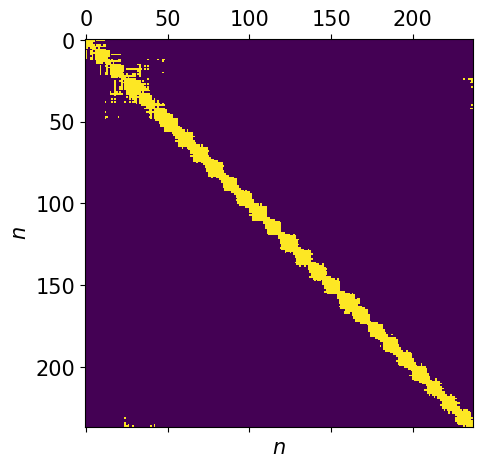

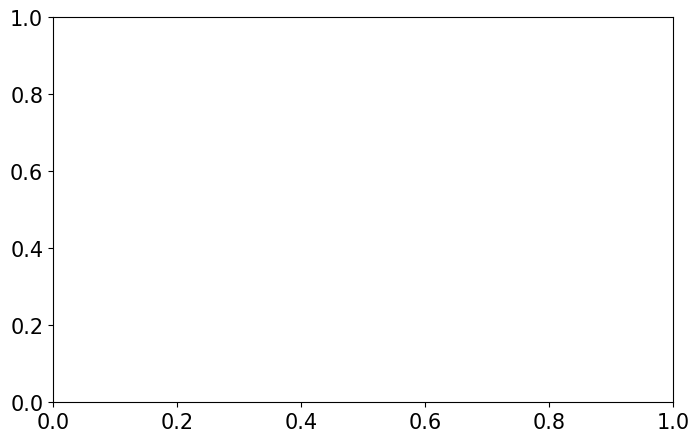

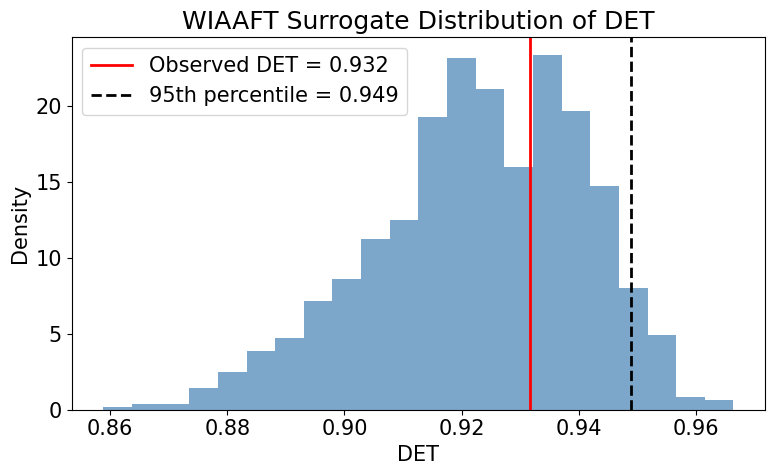

 90%|█████████████████████████████████████▊    | 90/100 [32:58<03:29, 20.96s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9315707620492552 
 Recurrence rate: 0.050009791878082216 
Threshold:1.1241999999998926 
 Laminarity:0.9594161623319352 
Shannon Entropy:2.0923894641349894 
Rank-order p-value (det):0.358 
Reject null (det) hypothesis:False

 
 

15
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


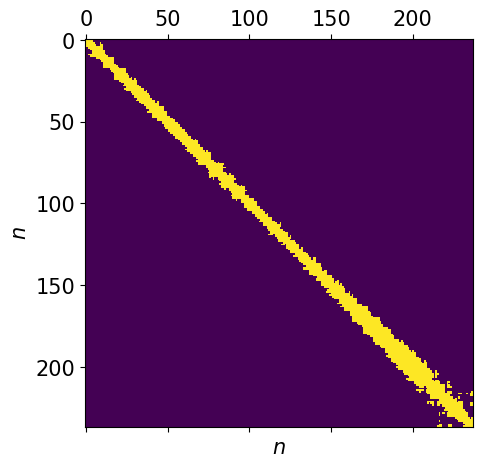

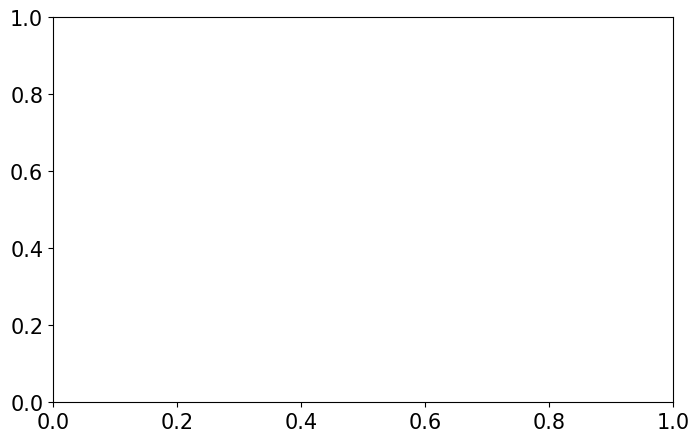

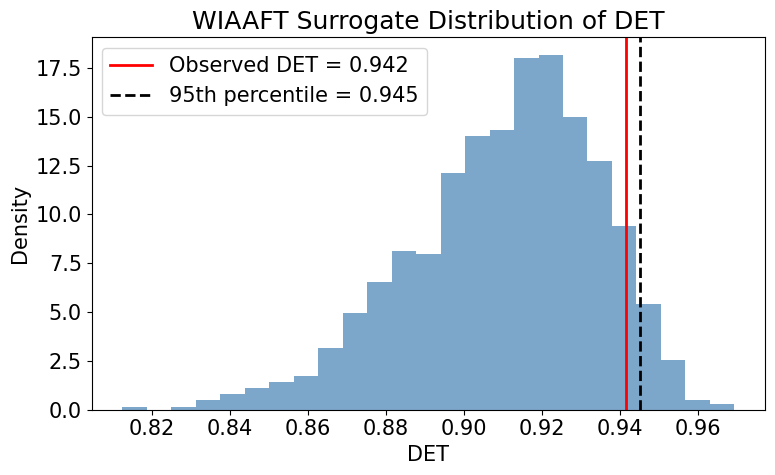

 91%|██████████████████████████████████████▏   | 91/100 [33:20<03:10, 21.20s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.94167962674595 
 Recurrence rate: 0.050009791878082216 
Threshold:0.8395999999999239 
 Laminarity:0.9846920612282496 
Shannon Entropy:1.8952215711529043 
Rank-order p-value (det):0.081 
Reject null (det) hypothesis:False

 
 

15
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


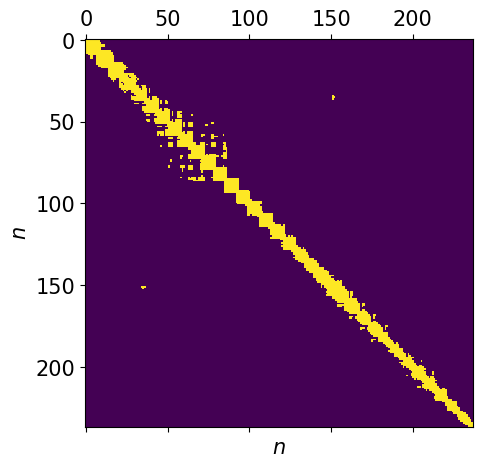

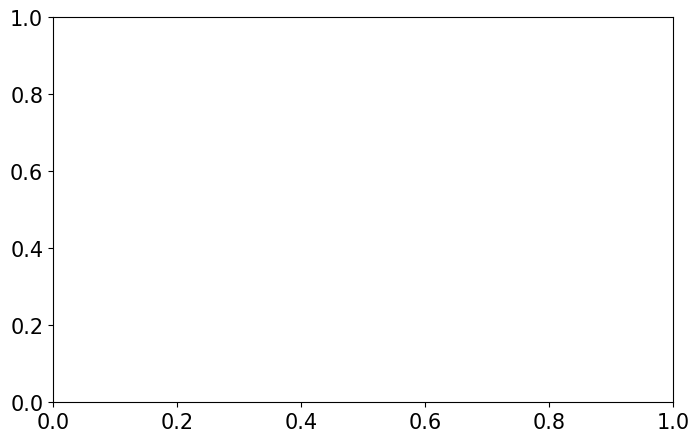

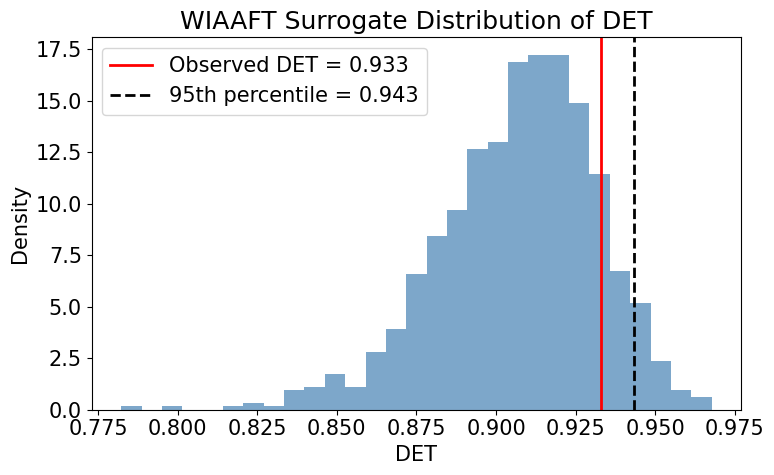

 92%|██████████████████████████████████████▋   | 92/100 [33:45<02:57, 22.24s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9331259720025928 
 Recurrence rate: 0.050009791878082216 
Threshold:1.3043999999998728 
 Laminarity:0.9733001067961079 
Shannon Entropy:1.8843773634685879 
Rank-order p-value (det):0.128 
Reject null (det) hypothesis:False

 
 

15
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


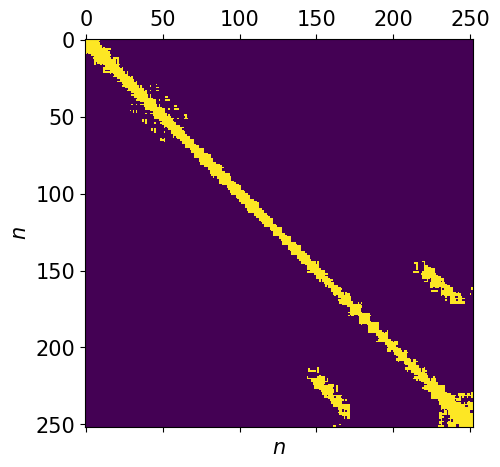

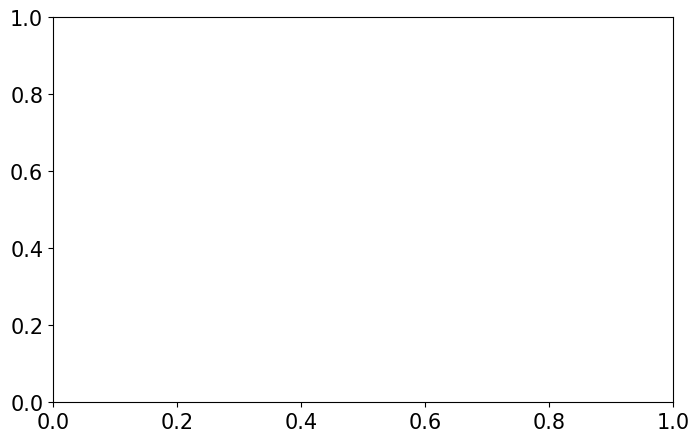

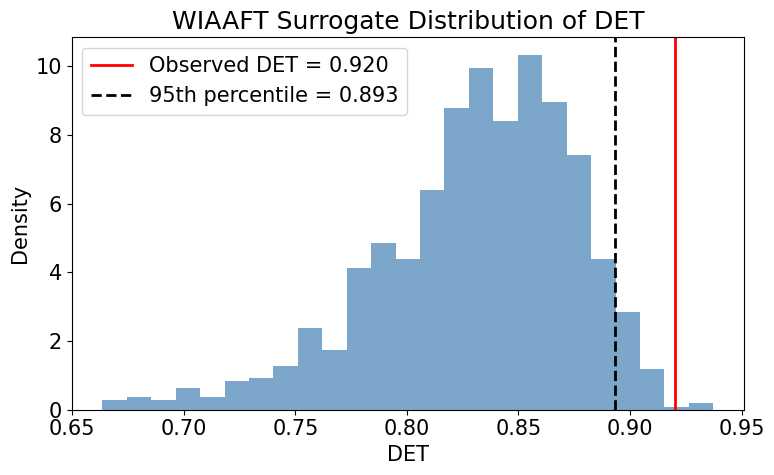

 93%|███████████████████████████████████████   | 93/100 [34:07<02:35, 22.16s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.919972640215732 
 Recurrence rate: 0.05001259763164525 
Threshold:0.7668999999999319 
 Laminarity:0.9622166246821089 
Shannon Entropy:1.8842086750708795 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

16
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


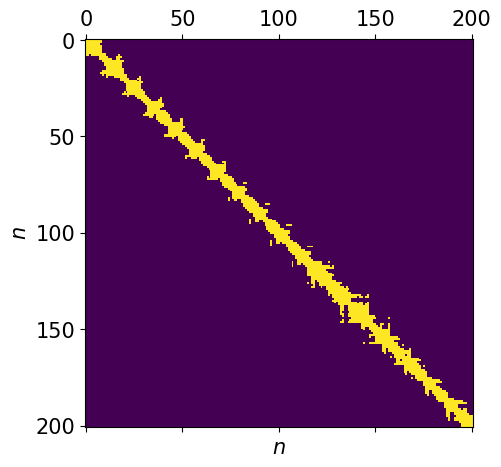

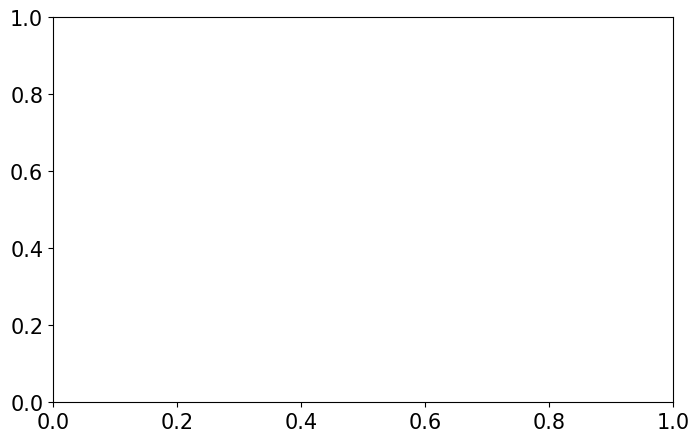

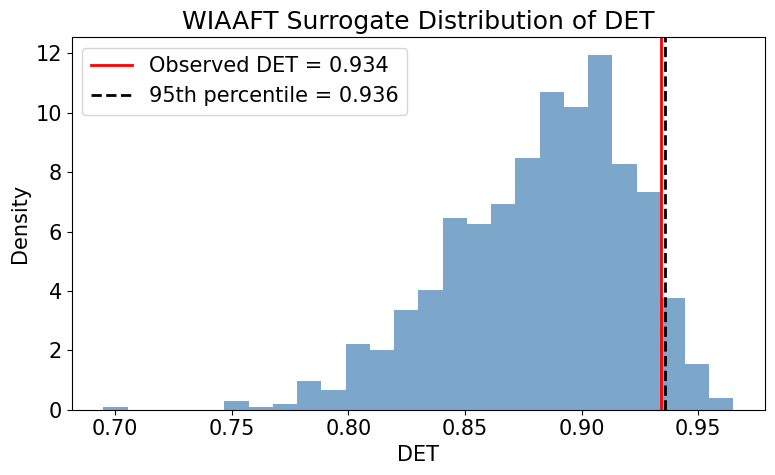

 94%|███████████████████████████████████████▍  | 94/100 [34:27<02:09, 21.55s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9340659340608019 
 Recurrence rate: 0.050023514269448774 
Threshold:0.7267999999999363 
 Laminarity:0.9727857496240833 
Shannon Entropy:1.8129721316644734 
Rank-order p-value (det):0.058 
Reject null (det) hypothesis:False

 
 

16
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


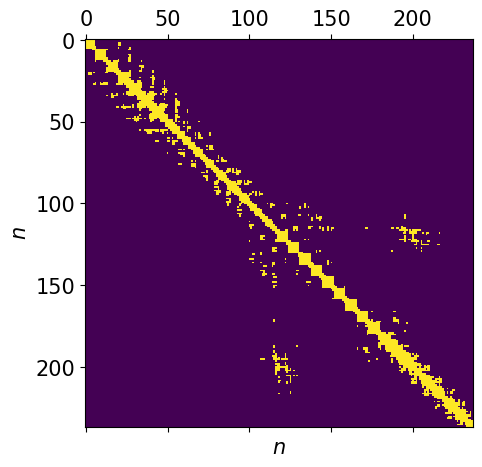

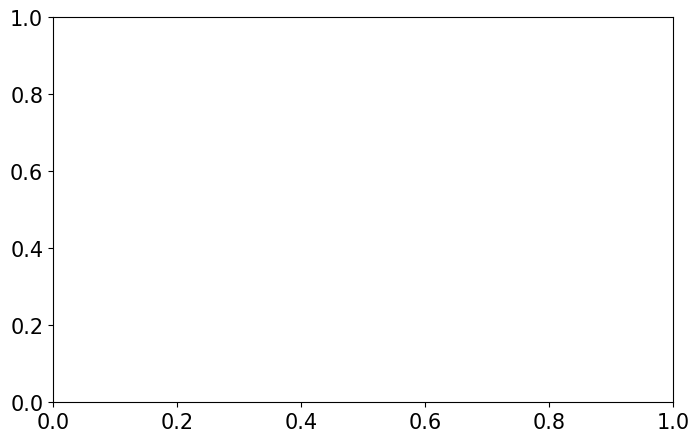

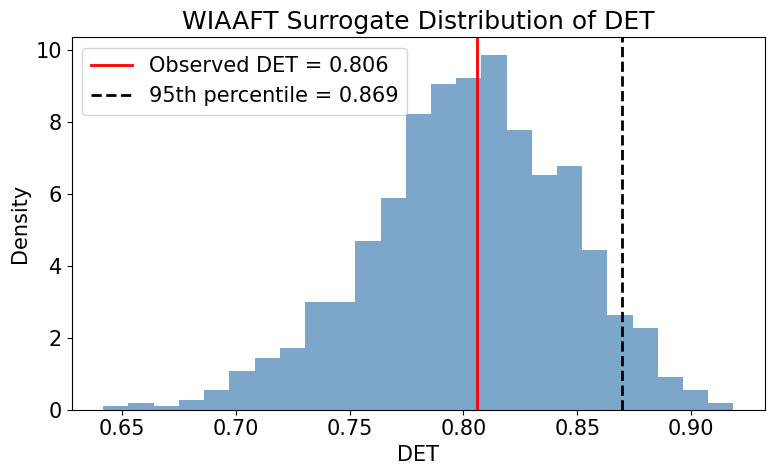

 95%|███████████████████████████████████████▉  | 95/100 [34:52<01:52, 22.50s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8057498057466754 
 Recurrence rate: 0.05004539870747209 
Threshold:1.3943999999998629 
 Laminarity:0.9096406972575253 
Shannon Entropy:1.3315030908664294 
Rank-order p-value (det):0.486 
Reject null (det) hypothesis:False

 
 

16
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


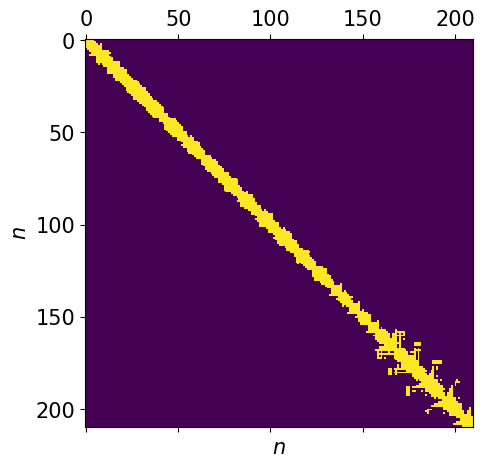

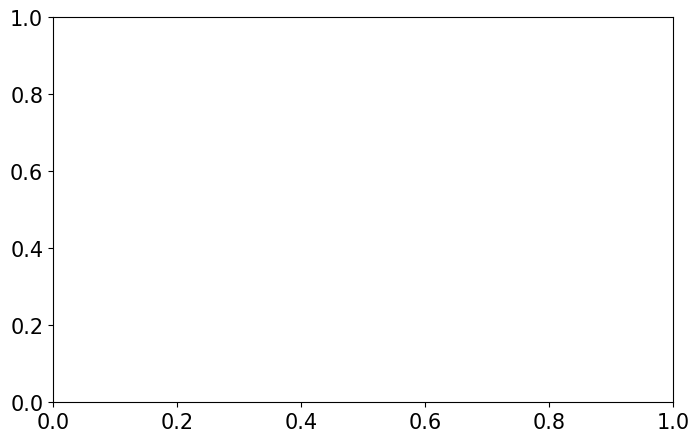

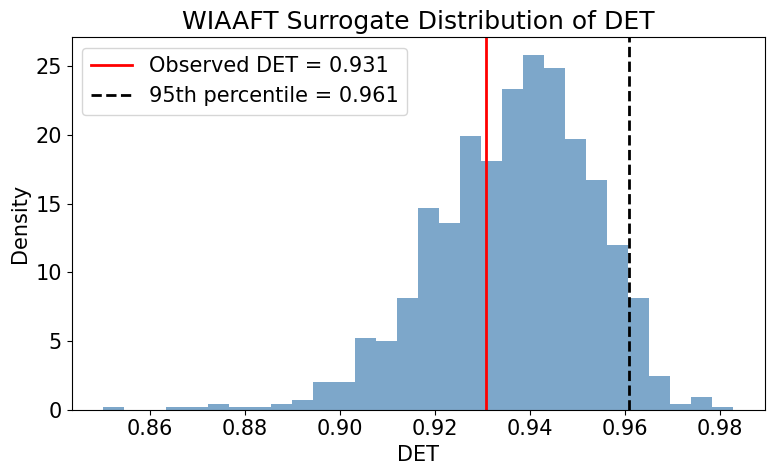

 96%|████████████████████████████████████████▎ | 96/100 [35:15<01:31, 22.86s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9308617234422302 
 Recurrence rate: 0.05002267573696145 
Threshold:1.6535999999998343 
 Laminarity:0.9723481414280493 
Shannon Entropy:1.9189478884938993 
Rank-order p-value (det):0.658 
Reject null (det) hypothesis:False

 
 

16
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


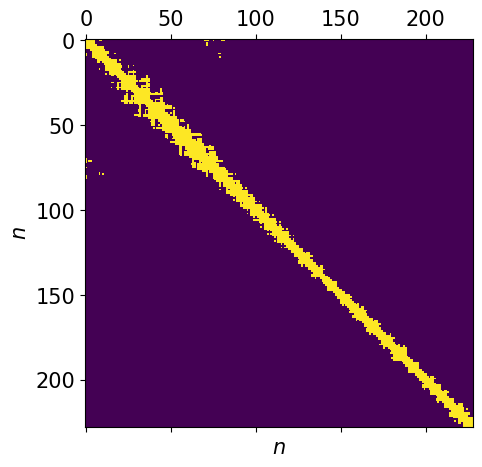

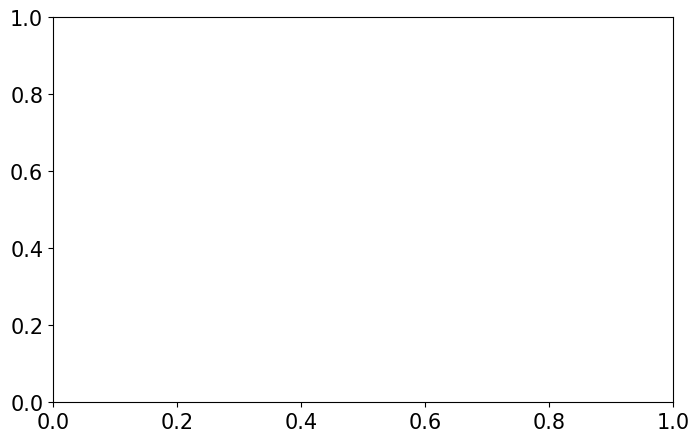

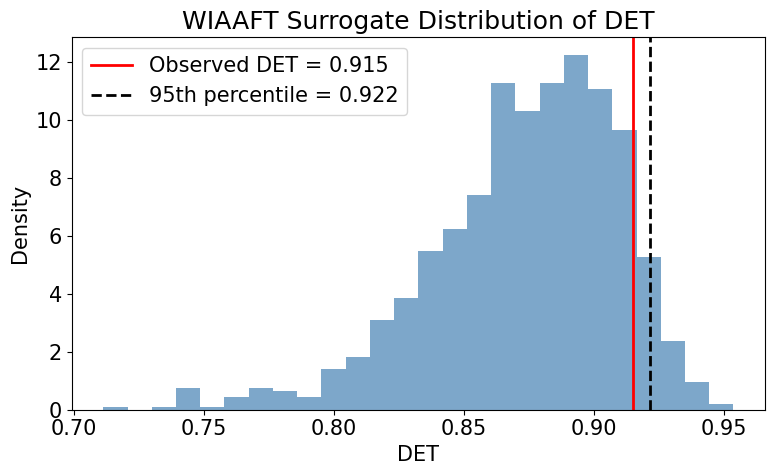

 97%|████████████████████████████████████████▋ | 97/100 [35:36<01:06, 22.06s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9148397976352663 
 Recurrence rate: 0.05001538935056941 
Threshold:0.6696999999999426 
 Laminarity:0.9569230769193965 
Shannon Entropy:1.7032714355407697 
Rank-order p-value (det):0.095 
Reject null (det) hypothesis:False

 
 

16
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


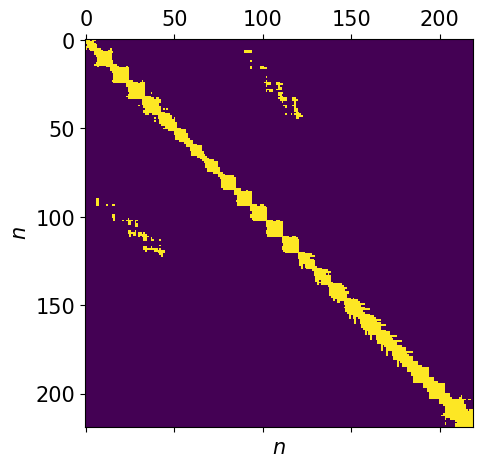

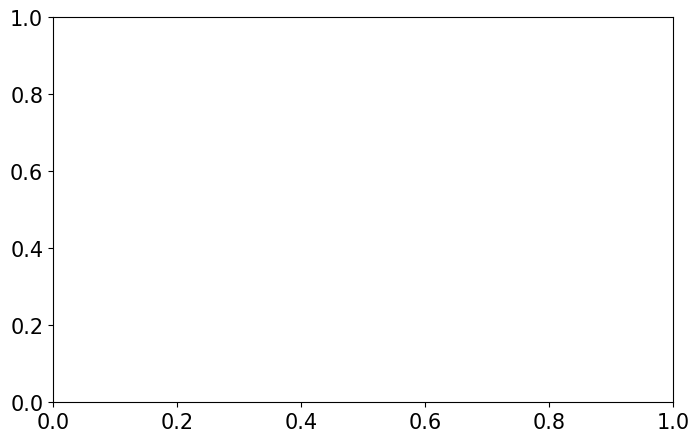

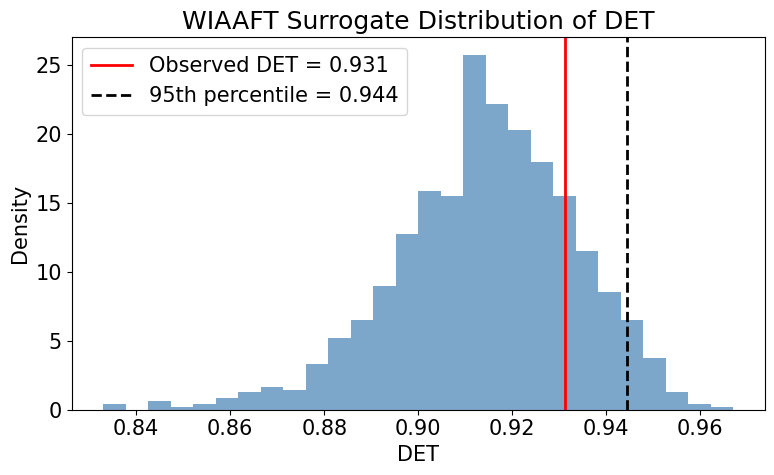

 98%|█████████████████████████████████████████▏| 98/100 [36:00<00:45, 22.77s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9311926605461872 
 Recurrence rate: 0.05001980776047205 
Threshold:1.529999999999848 
 Laminarity:0.9687369737350199 
Shannon Entropy:1.9734812279560985 
Rank-order p-value (det):0.186 
Reject null (det) hypothesis:False

 
 

16
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


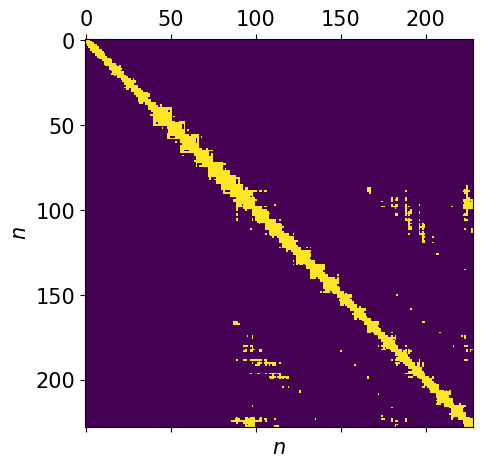

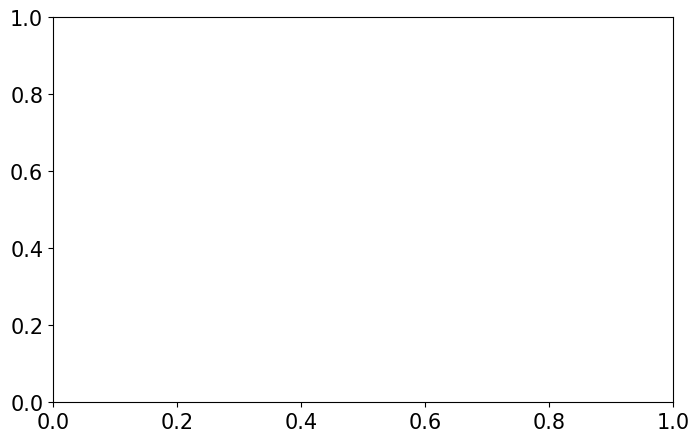

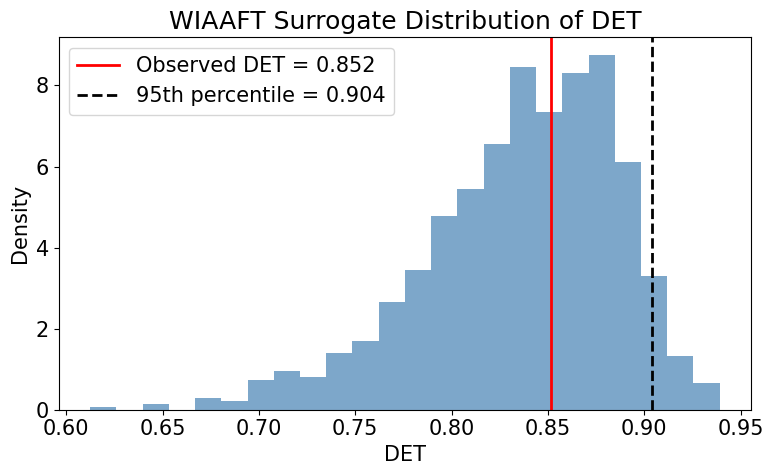

 99%|█████████████████████████████████████████▌| 99/100 [36:22<00:22, 22.51s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8516020236051788 
 Recurrence rate: 0.05001538935056941 
Threshold:0.8400999999999238 
 Laminarity:0.9280769230733535 
Shannon Entropy:1.6547030750888896 
Rank-order p-value (det):0.428 
Reject null (det) hypothesis:False

 
 

16
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


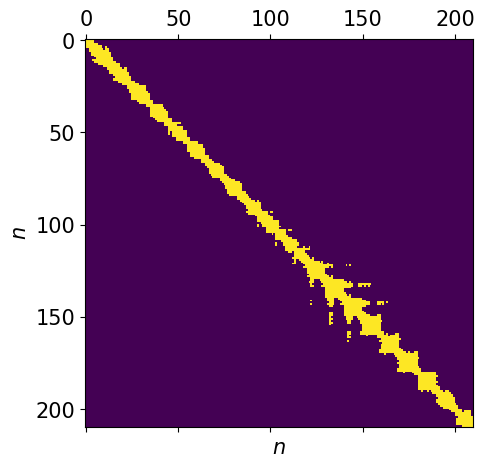

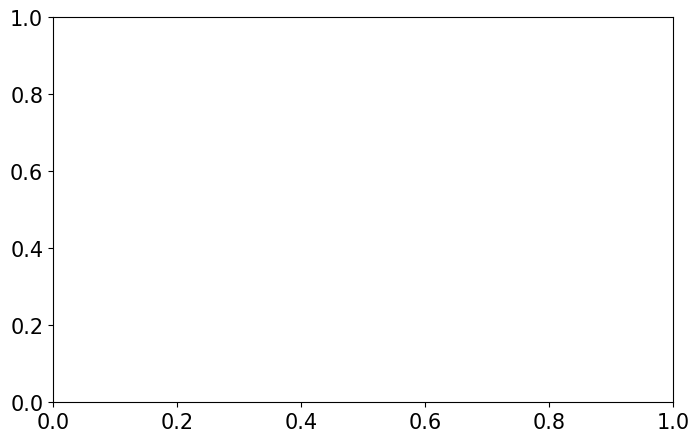

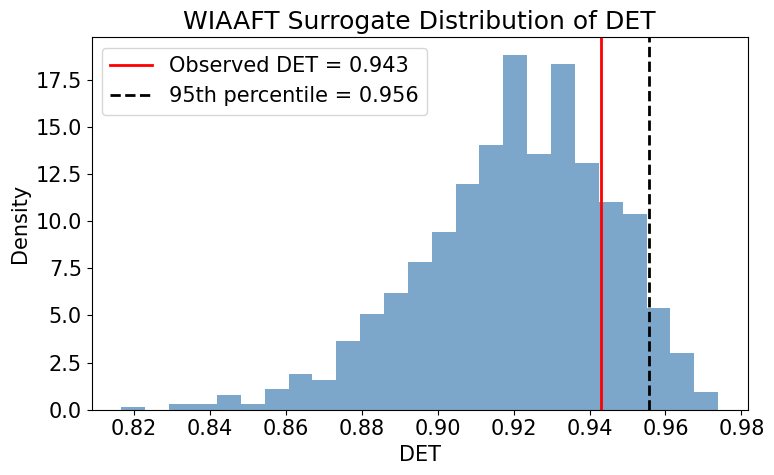

100%|█████████████████████████████████████████| 100/100 [36:43<00:00, 22.03s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9429429429382236 
 Recurrence rate: 0.05006802721088435 
Threshold:1.1458999999998902 
 Laminarity:0.981431159415845 
Shannon Entropy:2.0295882022695633 
Rank-order p-value (det):0.189 
Reject null (det) hypothesis:False

 
 

16


In [13]:
rejection = 0
for e in tqdm(range(0,100)):
    ar1(e, 1.0)
    os.system("./mutual ar1 -D20 -o files/mutual_ar1 -V0")
    m_site1 = np.loadtxt("files/mutual_ar1", delimiter =' ', usecols =(1) , skiprows=0)
    mn = np.where((m_site1[1:-1] < m_site1[:-2]) & (m_site1[1:-1] < m_site1[2:]))[0] + 1
    if mn.any()>0:
        t_min=mn[0]
    else:
        t_min = np.argmin(m_site1)
    os.system("./false_nearest ar1 -M1,10 -d{} -o files/ar1.fnn -V0".format(t_min))
    res_1 = extract_embedding_dimension("ar1")
    dim = res_1['m']
    print(res_1['method'])
    print(dim)
    k="ar1"
    det_j=[]
    embed=[]
    det_surro_ff=[]
    kkk=[]
    lam_j=[]
    ent_j=[]
    lam_surro = []
    ent_surro=[]
    s = lcurve(k)
    with open("test_output/stocks_WIAAFT", "w") as f:
        subprocess.run(["julia", "WIAAFT_surrogates.jl", "ar1"], text=True, check=True)
        tt1=0.001
        dimension=dim
        RR_orig = 0
        while RR_orig < 0.05:
            tt1 = tt1 + 0.0001
            det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
        det_j.append(det)
        embed.append(dim)
        lam_j.append(lam_orig)
        ent_j.append(entr_orig)
        pylab.matshow(matrix)
        pylab.xlabel("$n$")
        pylab.ylabel("$n$")
        pylab.savefig('test_output/WIAAFT/WIAAFT_RP_{}.pdf'.format(dim), format="pdf")
        det_ff, lam_ff, entr_ff = sur_test_WIAAFT(dim, tt1)
        fig2, axs = plt.subplots(1)
        q95 = np.percentile(det_ff, 95)
        plt.figure(figsize=(8,5))
        plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
        plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
        plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
        plt.xlabel("DET")
        plt.ylabel("Density")
        plt.title("WIAAFT Surrogate Distribution of DET")
        plt.legend()
        plt.tight_layout()
        plt.show()
        fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
        plt.show()
        plt.close()
        r = np.sum(det_ff >= det)
        p_rank = (r + 1) / (999 + 1)
        alpha = 0.05
        reject_null1 = p_rank < alpha
        print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
        det_surro_ff.append(det_ff)
        kkk.append(np.full(999, dimension))
        lam_surro.append(lam_ff)
        ent_surro.append(entr_ff)
        if reject_null1 == True:
            rejection = rejection + 1
        print(rejection)

In [14]:
print("rejection rate:{}".format(rejection/(e+1)))

rejection rate:0.16


  0%|                                                   | 0/100 [00:00<?, ?it/s]

9
Mean Nearest Neighbor Distance: 0.27319918978887253
Pseudo-periodic surrogates generated successfullly


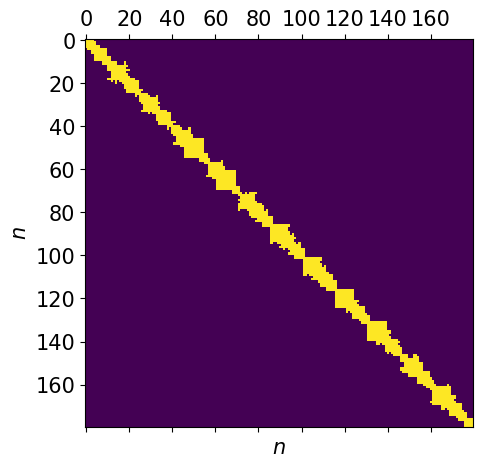

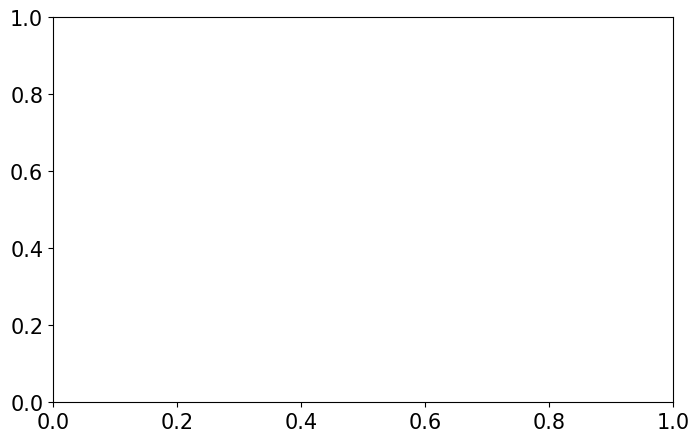

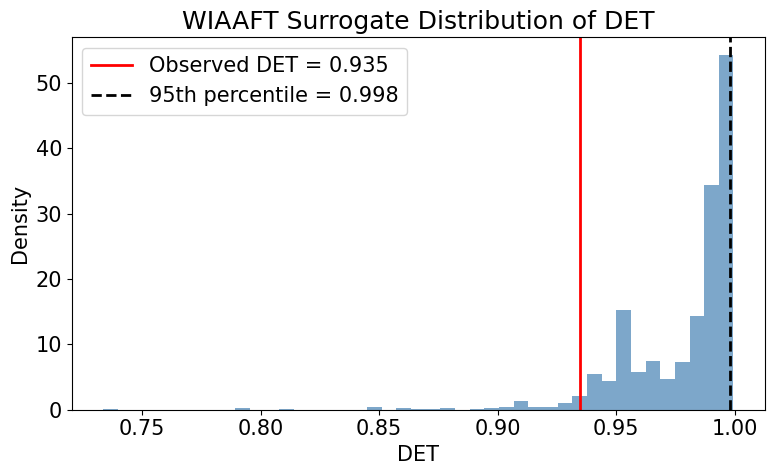

  1%|▍                                          | 1/100 [00:08<14:09,  8.58s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9347222222157312 
 Recurrence rate: 0.05 
Threshold:0.647399999999945 
 Laminarity:0.9864197530803308 
Shannon Entropy:2.2565039060697276 
Rank-order p-value (det):0.088 
Reject null (det) hypothesis:False

 
 

0
7
Mean Nearest Neighbor Distance: 0.21934498768272165
Pseudo-periodic surrogates generated successfullly


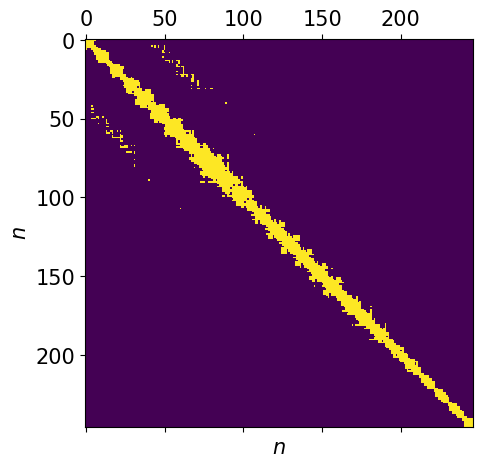

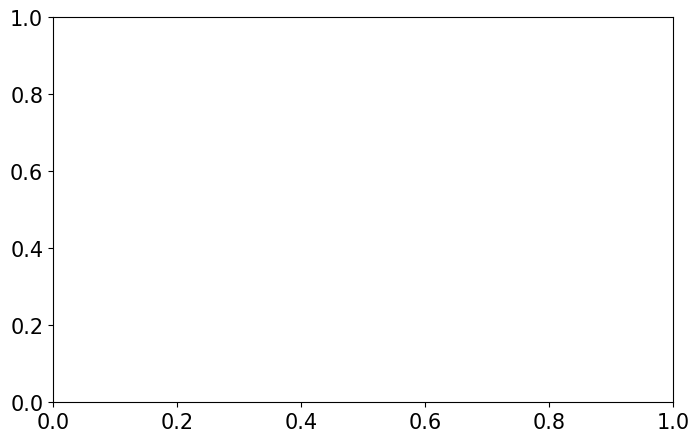

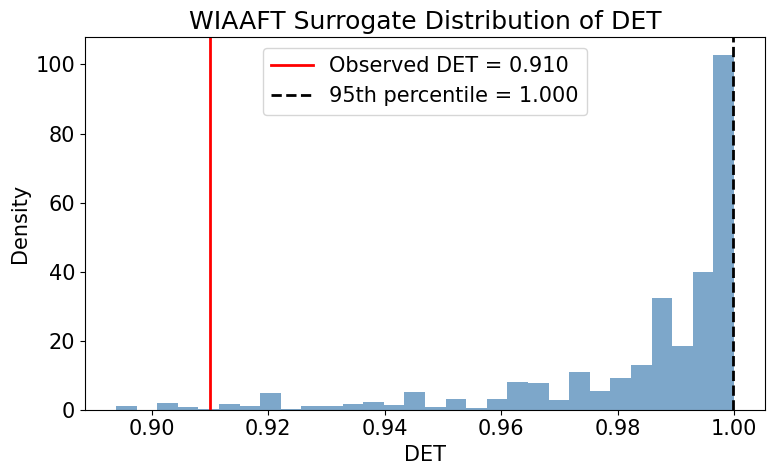

  2%|▊                                          | 2/100 [00:18<15:28,  9.48s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.9100719424427696 
 Recurrence rate: 0.05000330491109789 
Threshold:0.6132999999999488 
 Laminarity:0.9600132187674818 
Shannon Entropy:2.0851079821344096 
Rank-order p-value (det):0.03 
Reject null (det) hypothesis:True

 
 

1
6
Mean Nearest Neighbor Distance: 0.3493056454213199
Pseudo-periodic surrogates generated successfullly


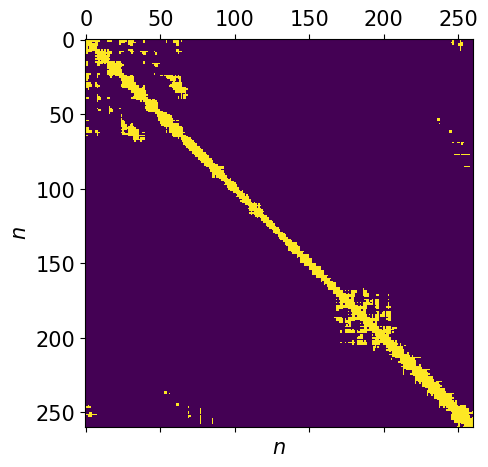

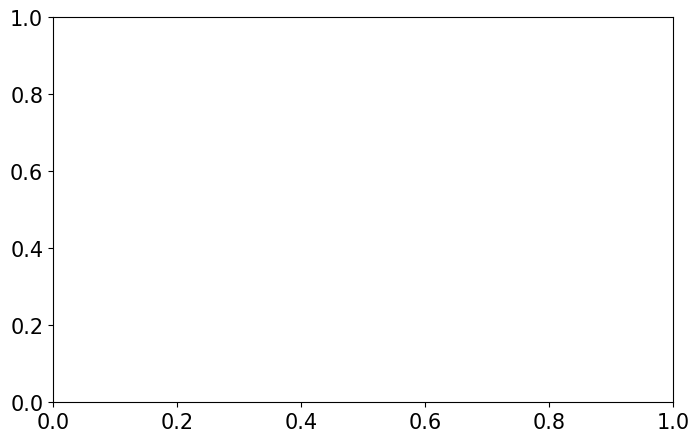

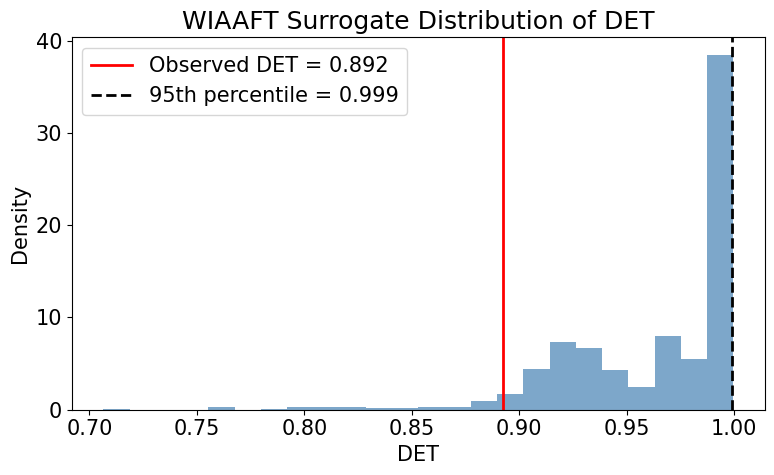

  3%|█▎                                         | 3/100 [00:32<18:11, 11.25s/it]

RQA  ar1 Embedding dimensions:6 
 DET of original:0.8923076923048324 
 Recurrence rate: 0.05 
Threshold:0.9840999999999079 
 Laminarity:0.9446745562102229 
Shannon Entropy:1.639222846379516 
Rank-order p-value (det):0.08 
Reject null (det) hypothesis:False

 
 

1
10
Mean Nearest Neighbor Distance: 0.5806097333187248
Pseudo-periodic surrogates generated successfullly


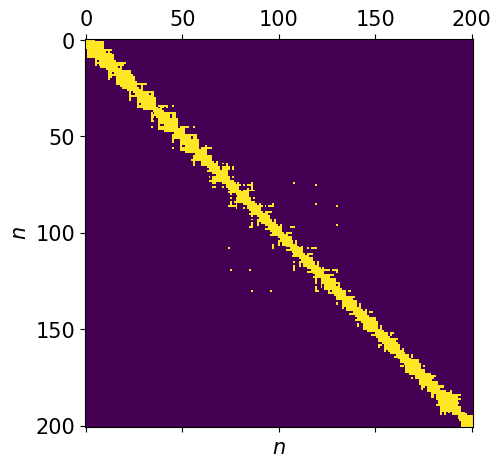

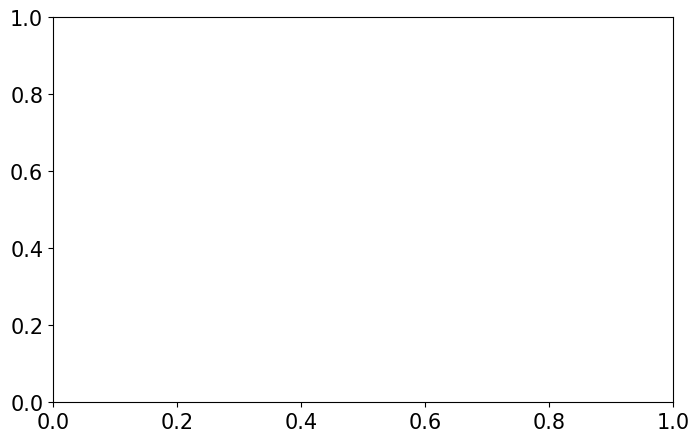

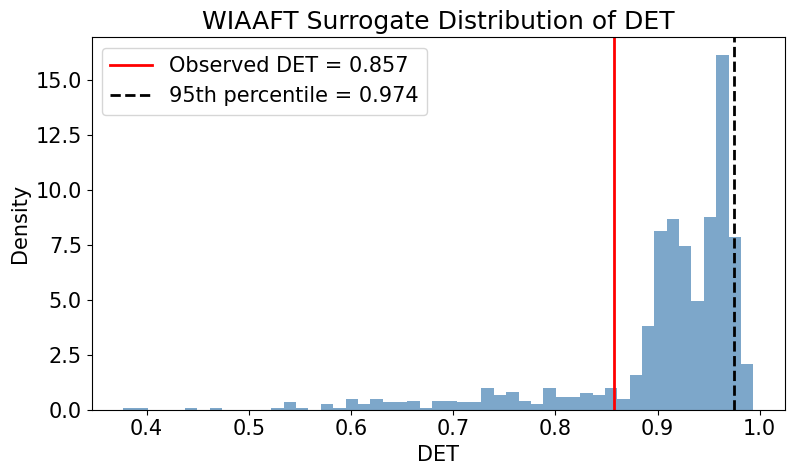

  4%|█▋                                         | 4/100 [00:45<19:15, 12.04s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8571428571381476 
 Recurrence rate: 0.050023514269448774 
Threshold:1.338399999999869 
 Laminarity:0.938149430970123 
Shannon Entropy:1.8908331434592147 
Rank-order p-value (det):0.3 
Reject null (det) hypothesis:False

 
 

1
10
Mean Nearest Neighbor Distance: 0.36147469004785643
Pseudo-periodic surrogates generated successfullly


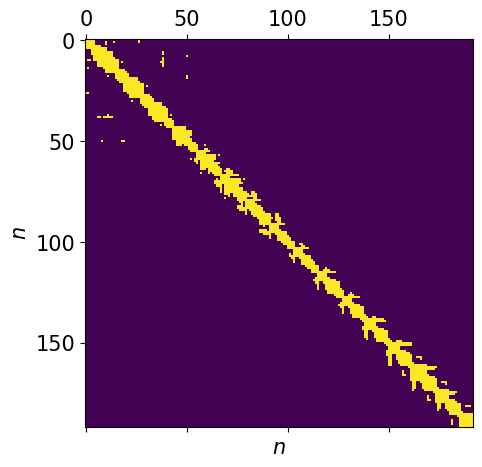

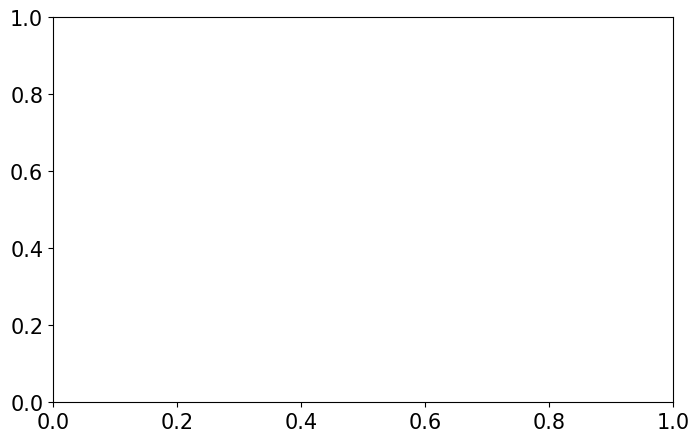

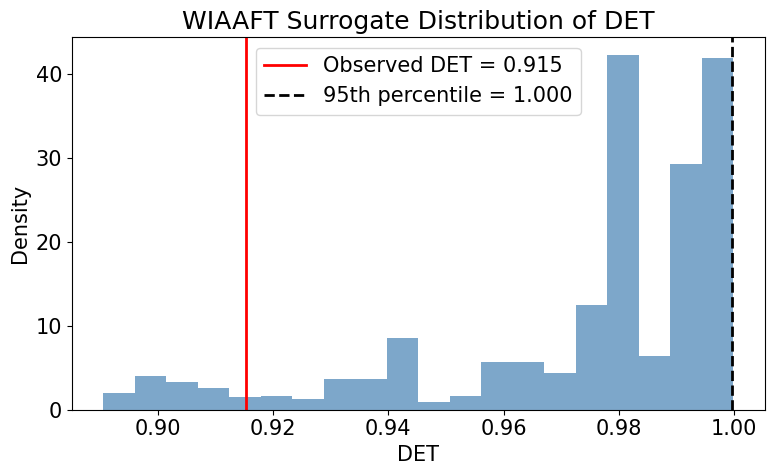

  5%|██▏                                        | 5/100 [00:55<17:48, 11.25s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9152542372825954 
 Recurrence rate: 0.05002170138888889 
Threshold:0.8300999999999249 
 Laminarity:0.9647505422941175 
Shannon Entropy:1.7568700551984886 
Rank-order p-value (det):0.134 
Reject null (det) hypothesis:False

 
 

1
7
Mean Nearest Neighbor Distance: 0.36295458269918585
Pseudo-periodic surrogates generated successfullly


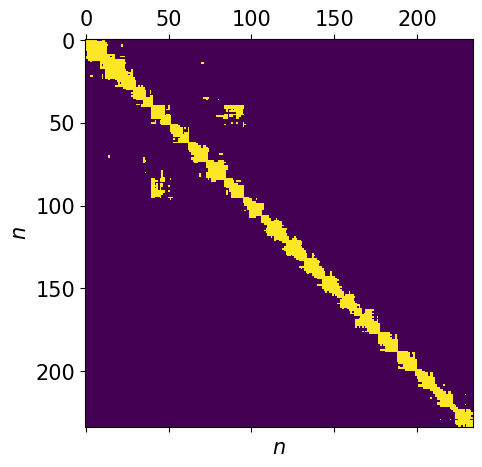

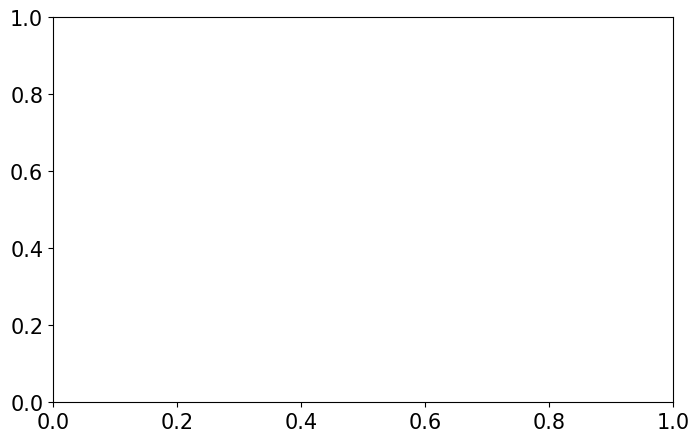

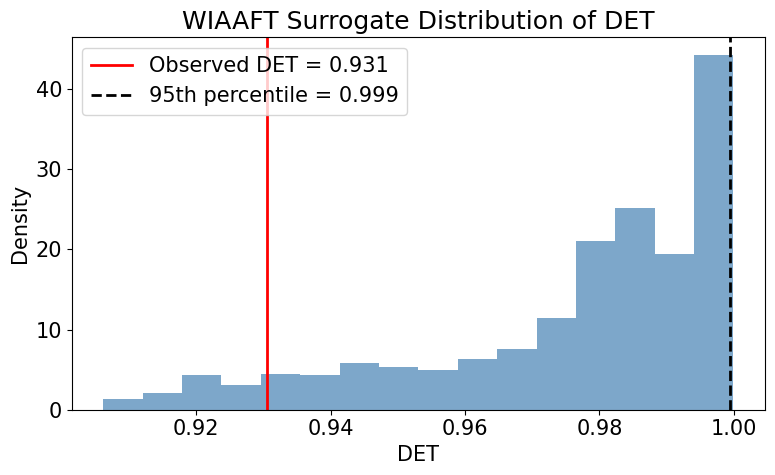

  6%|██▌                                        | 6/100 [01:07<18:08, 11.58s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.9305111821049101 
 Recurrence rate: 0.05000365256775513 
Threshold:1.0649999999998991 
 Laminarity:0.9642074506904157 
Shannon Entropy:2.16011305060796 
Rank-order p-value (det):0.136 
Reject null (det) hypothesis:False

 
 

1
8
Mean Nearest Neighbor Distance: 0.2506612790887059
Pseudo-periodic surrogates generated successfullly


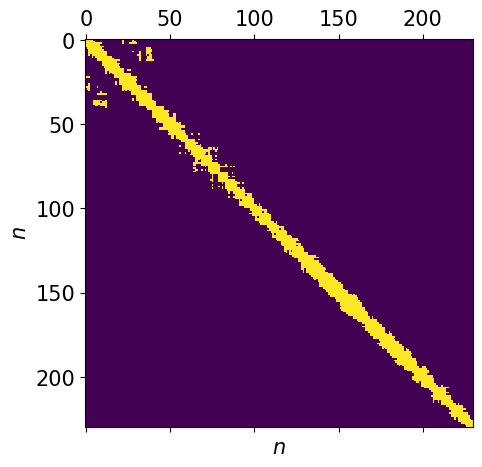

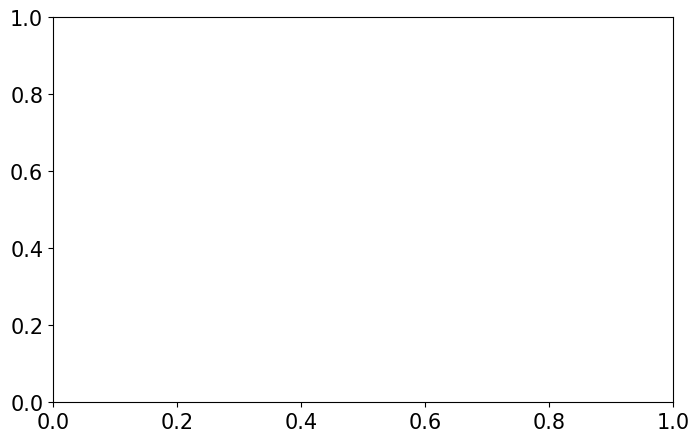

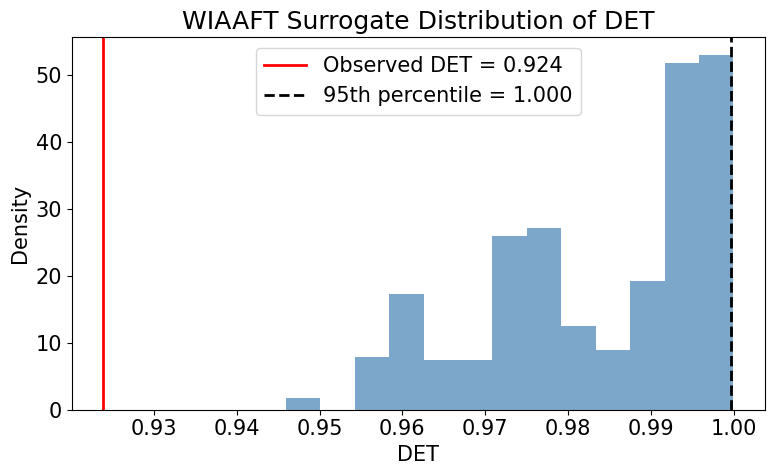

  7%|███                                        | 7/100 [01:18<17:35, 11.35s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9239040529324901 
 Recurrence rate: 0.05005671077504726 
Threshold:0.7623999999999324 
 Laminarity:0.9645015105703758 
Shannon Entropy:2.1371252266076985 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

2
10
Mean Nearest Neighbor Distance: 0.4750448027243601
Pseudo-periodic surrogates generated successfullly


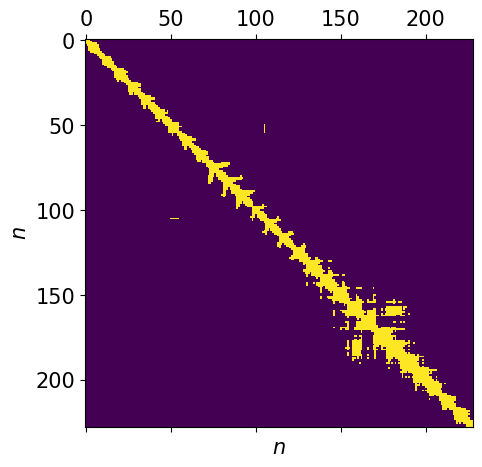

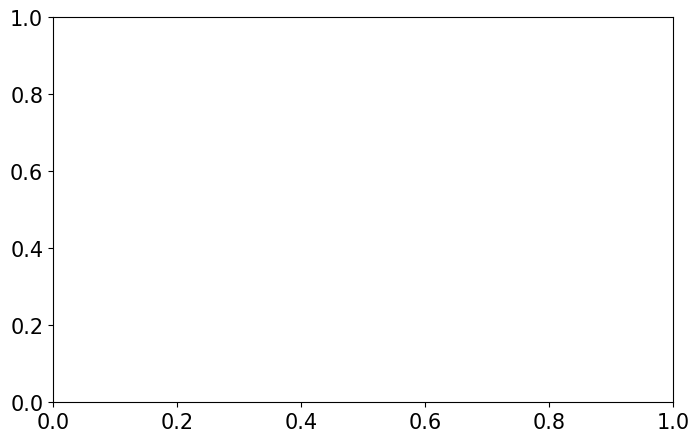

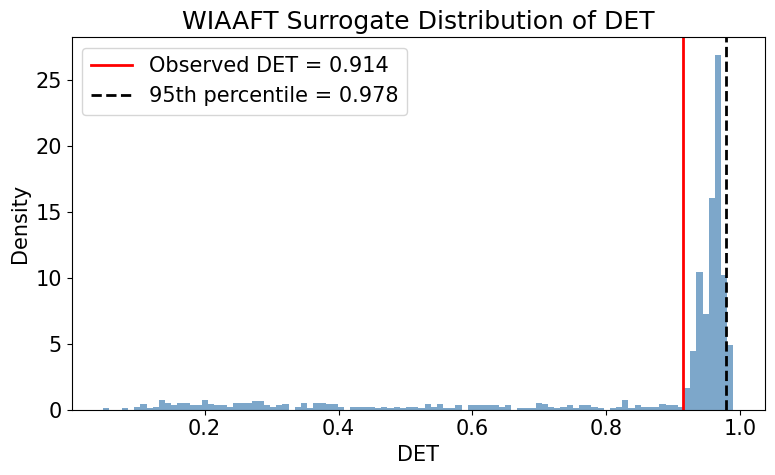

  8%|███▍                                       | 8/100 [01:32<18:49, 12.28s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9139966273148652 
 Recurrence rate: 0.05001538935056941 
Threshold:1.1716999999998874 
 Laminarity:0.9530769230732574 
Shannon Entropy:1.7503675388677198 
Rank-order p-value (det):0.492 
Reject null (det) hypothesis:False

 
 

2
9
Mean Nearest Neighbor Distance: 0.6413914482131539
Pseudo-periodic surrogates generated successfullly


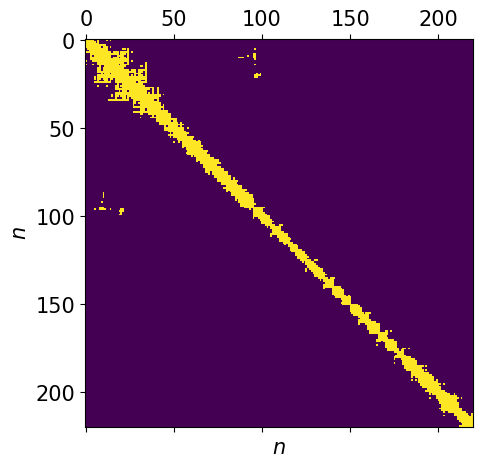

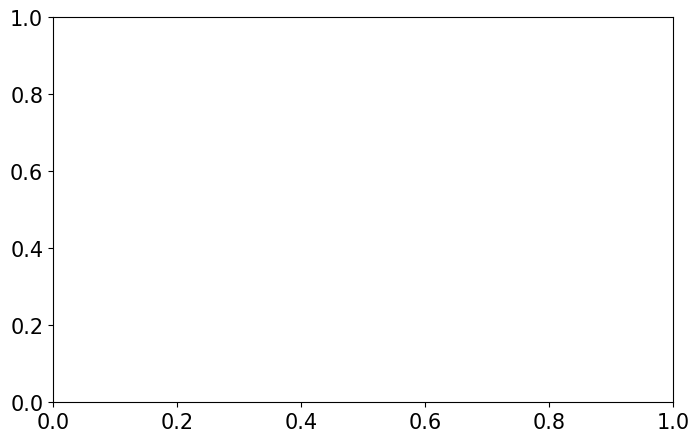

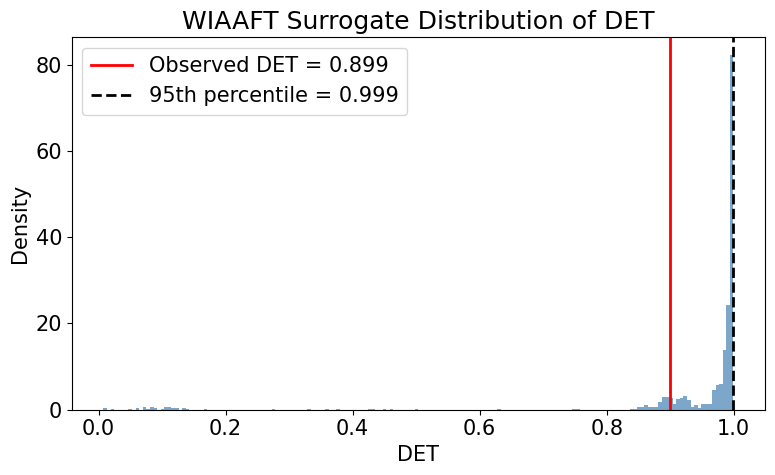

  9%|███▊                                       | 9/100 [01:48<20:18, 13.39s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8990909090868223 
 Recurrence rate: 0.05 
Threshold:1.5790999999998425 
 Laminarity:0.9512396694175569 
Shannon Entropy:2.067513313159867 
Rank-order p-value (det):0.232 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.47377074570614797
Pseudo-periodic surrogates generated successfullly


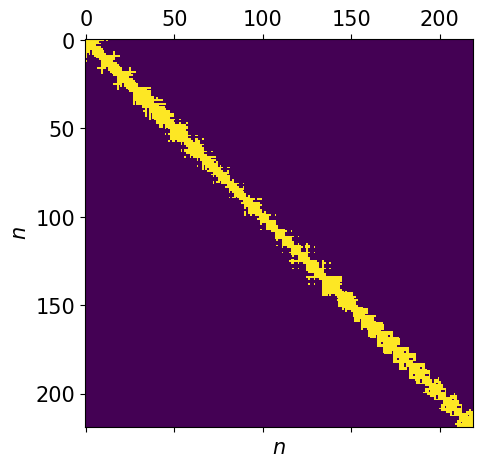

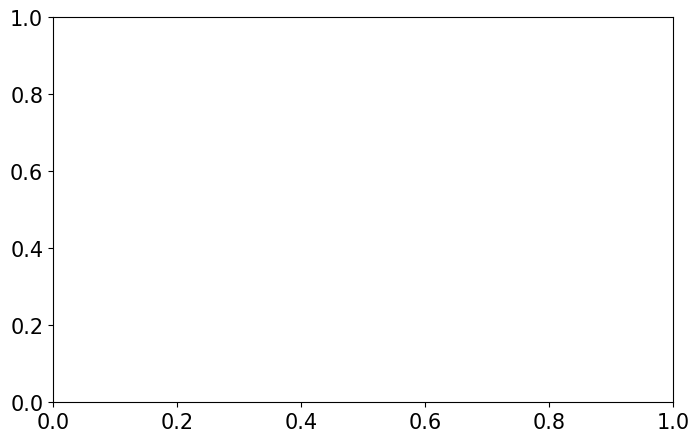

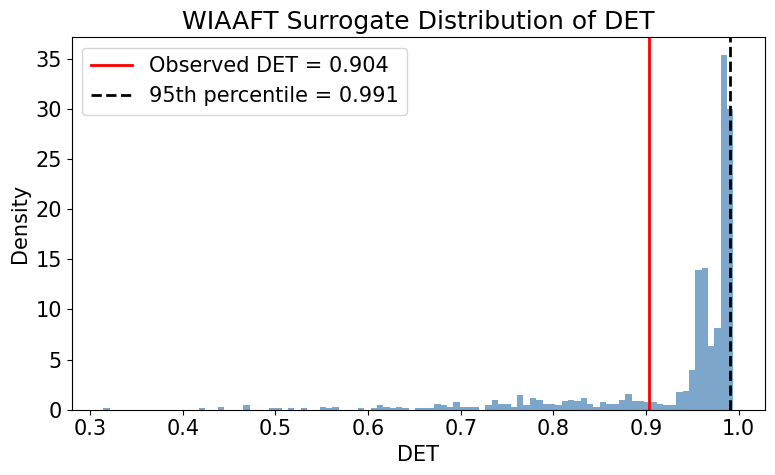

 10%|████▏                                     | 10/100 [02:01<20:08, 13.43s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.903669724766497 
 Recurrence rate: 0.05001980776047205 
Threshold:1.1776999999998867 
 Laminarity:0.9549812421802627 
Shannon Entropy:1.8556398499952342 
Rank-order p-value (det):0.374 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.2866170535829151
Pseudo-periodic surrogates generated successfullly


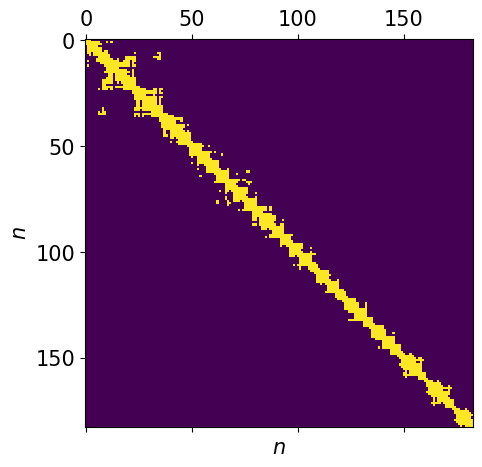

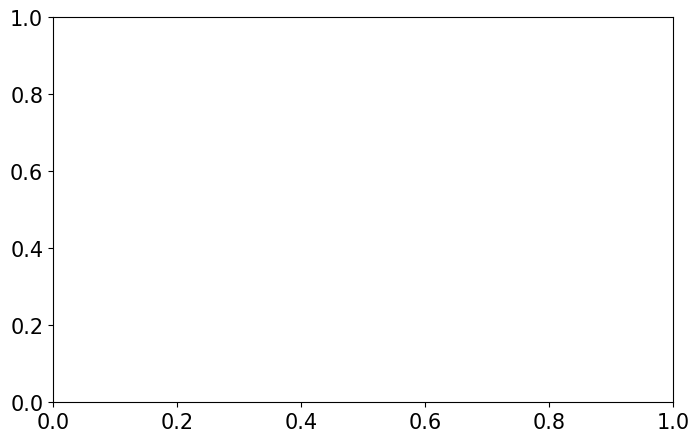

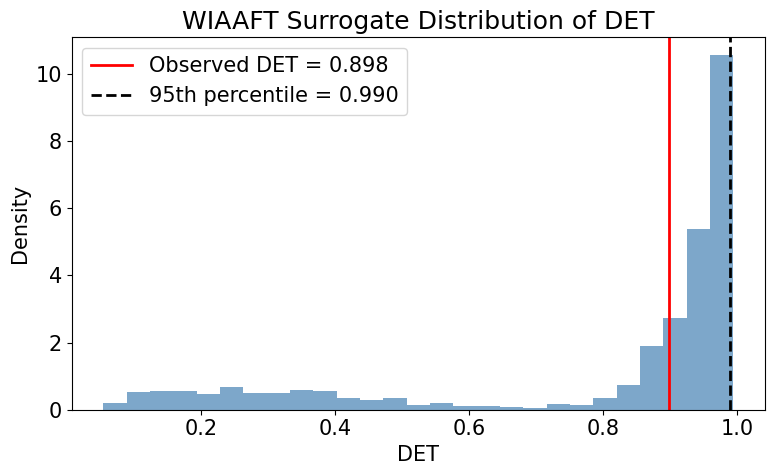

 11%|████▌                                     | 11/100 [02:10<17:43, 11.95s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8981233243907634 
 Recurrence rate: 0.05001642330317418 
Threshold:0.6416999999999456 
 Laminarity:0.949850746262986 
Shannon Entropy:1.2900448236166029 
Rank-order p-value (det):0.74 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.6086938868675931
Pseudo-periodic surrogates generated successfullly


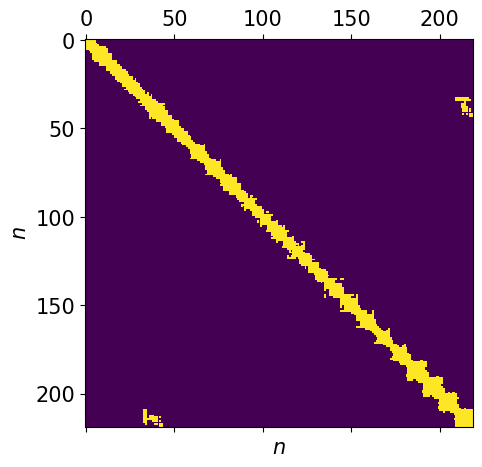

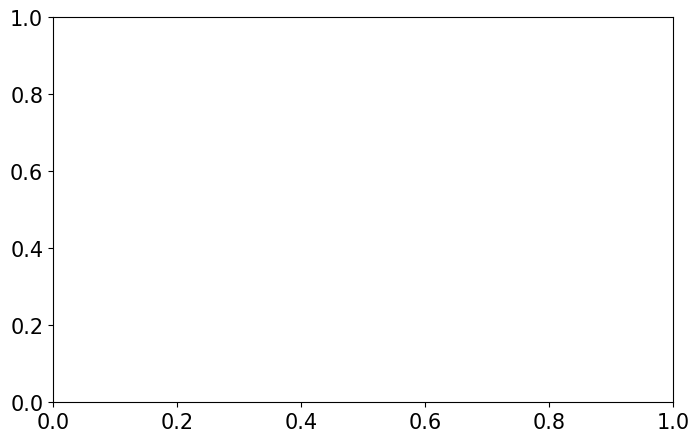

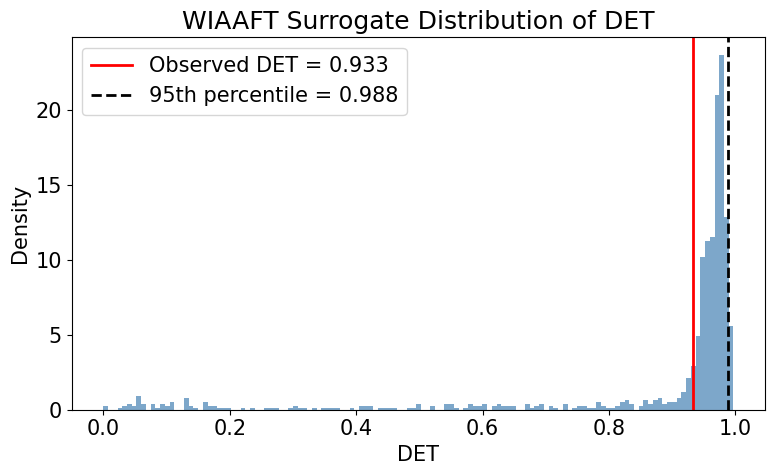

 12%|█████                                     | 12/100 [02:26<19:27, 13.26s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9330275229314999 
 Recurrence rate: 0.05001980776047205 
Threshold:1.60159999999984 
 Laminarity:0.9808253438892004 
Shannon Entropy:2.071170616050058 
Rank-order p-value (det):0.466 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.5177735278754261
Pseudo-periodic surrogates generated successfullly


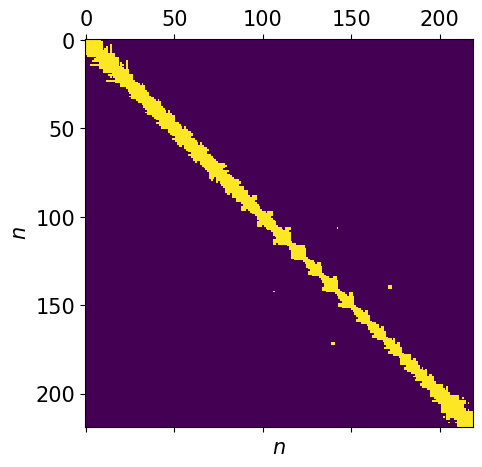

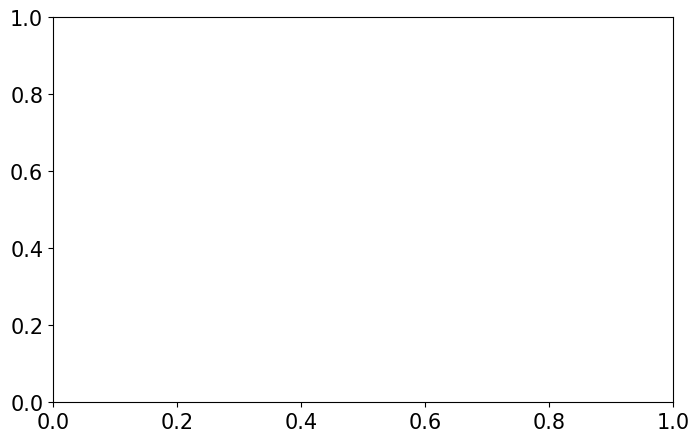

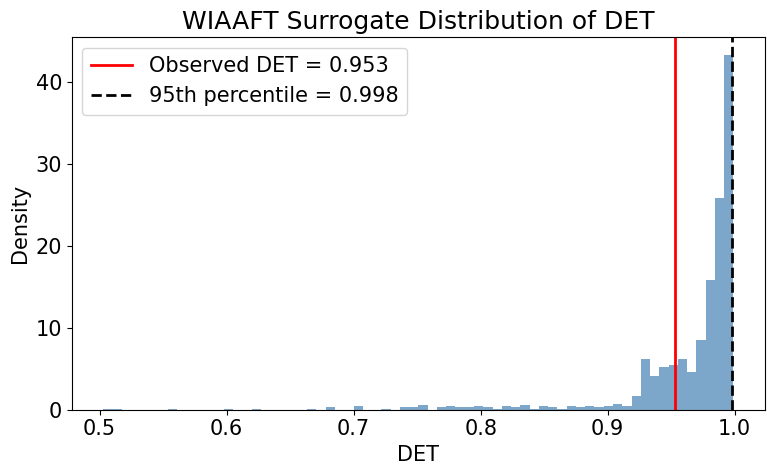

 13%|█████▍                                    | 13/100 [02:42<20:13, 13.95s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9532538955043389 
 Recurrence rate: 0.05006150830883426 
Threshold:1.4486999999998569 
 Laminarity:0.9850062473928155 
Shannon Entropy:1.955466786942281 
Rank-order p-value (det):0.458 
Reject null (det) hypothesis:False

 
 

2
8
Mean Nearest Neighbor Distance: 0.318410235400488
Pseudo-periodic surrogates generated successfullly


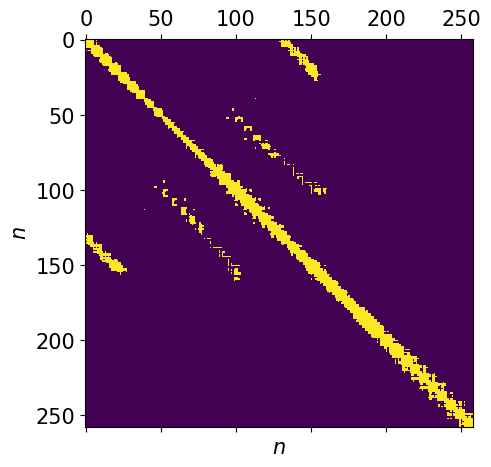

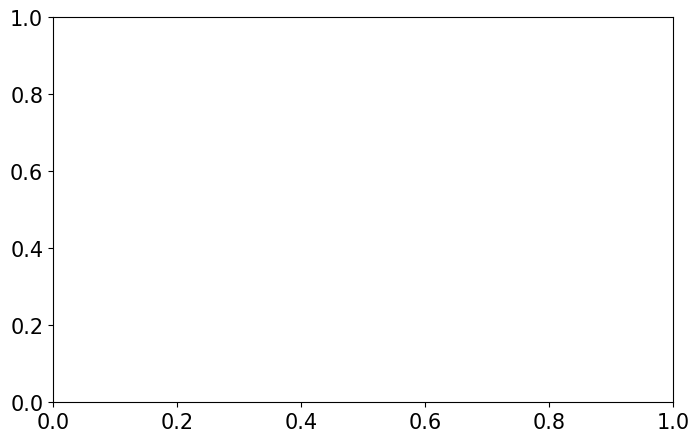

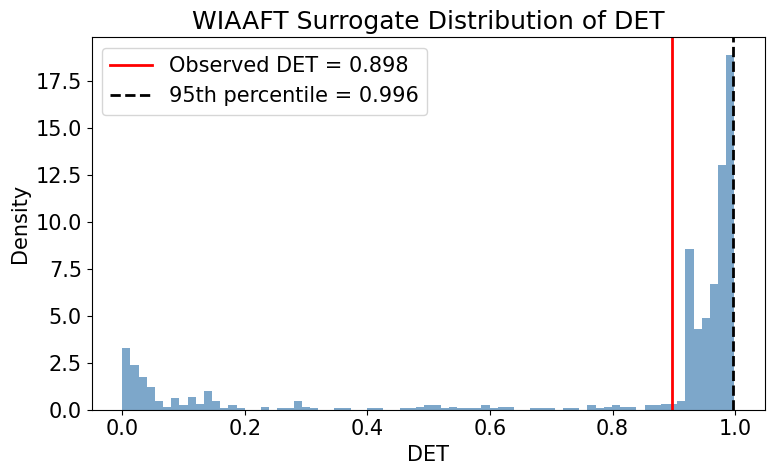

 14%|█████▉                                    | 14/100 [02:54<19:27, 13.57s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.8977864583304109 
 Recurrence rate: 0.050027041644131964 
Threshold:0.8003999999999282 
 Laminarity:0.9486486486457999 
Shannon Entropy:1.8238682770337196 
Rank-order p-value (det):0.484 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.5966806696984295
Pseudo-periodic surrogates generated successfullly


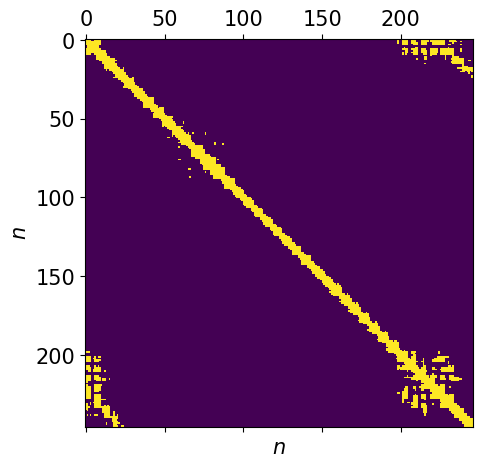

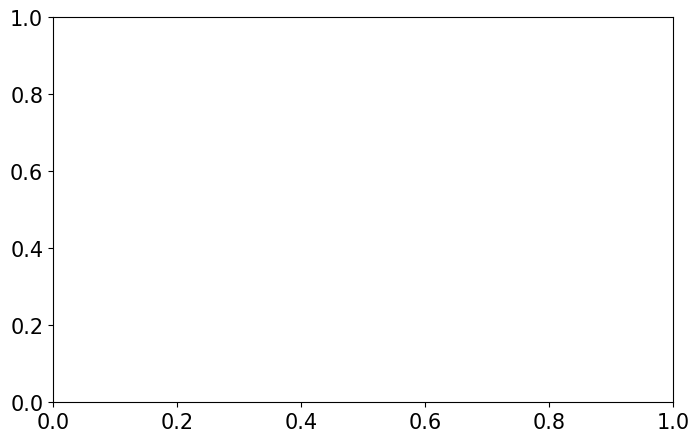

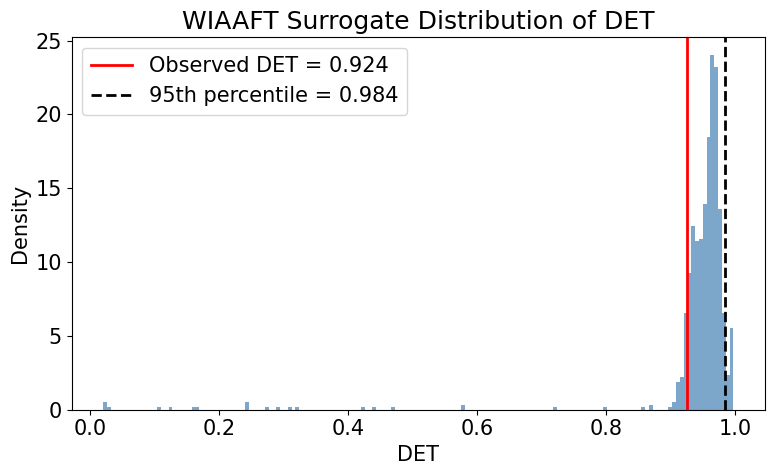

 15%|██████▎                                   | 15/100 [03:12<20:50, 14.71s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.924460431651351 
 Recurrence rate: 0.05000330491109789 
Threshold:1.5499999999998457 
 Laminarity:0.9695968274918387 
Shannon Entropy:1.50303316365287 
Rank-order p-value (det):0.17 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.40821041408904973
Pseudo-periodic surrogates generated successfullly


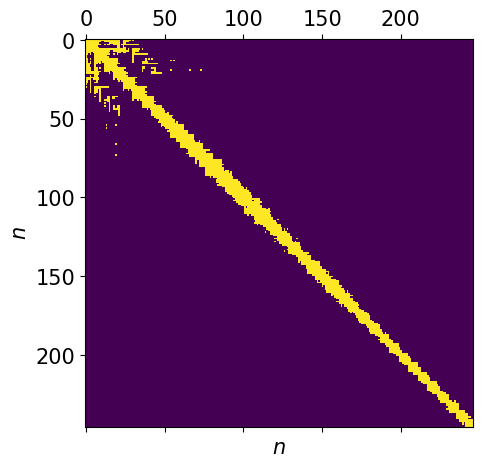

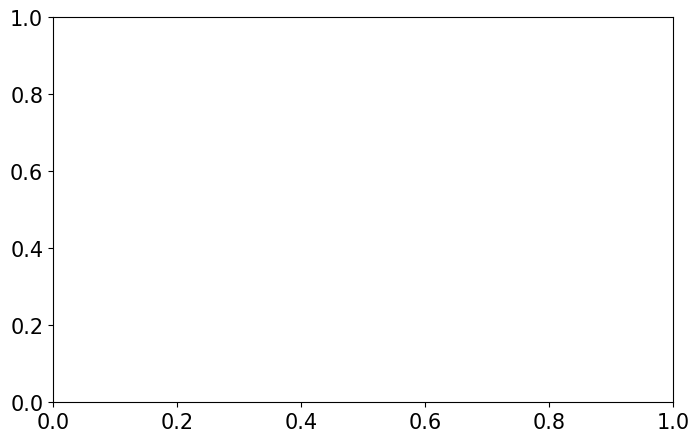

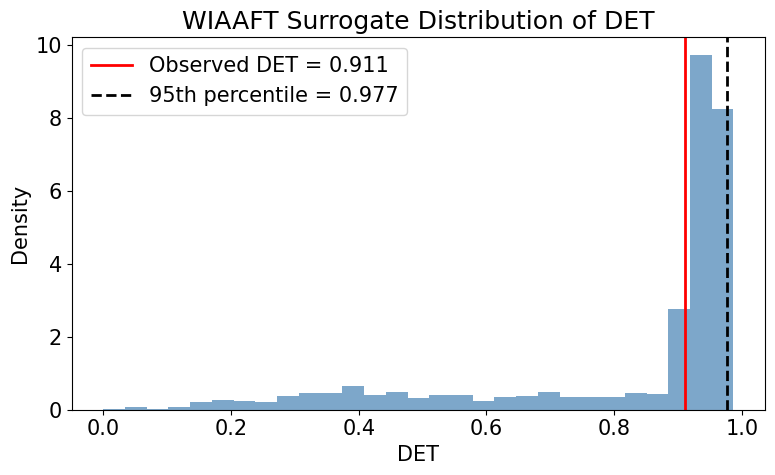

 16%|██████▋                                   | 16/100 [03:27<20:42, 14.79s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9108554996372723 
 Recurrence rate: 0.050036354022076804 
Threshold:1.0863999999998968 
 Laminarity:0.9610303830879755 
Shannon Entropy:1.711511423324801 
Rank-order p-value (det):0.686 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.21529512521598548
Pseudo-periodic surrogates generated successfullly


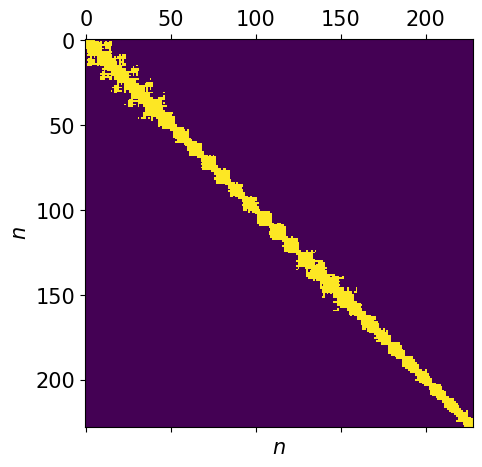

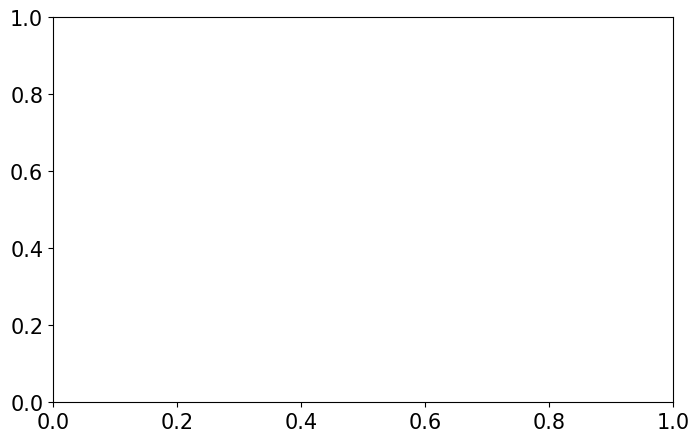

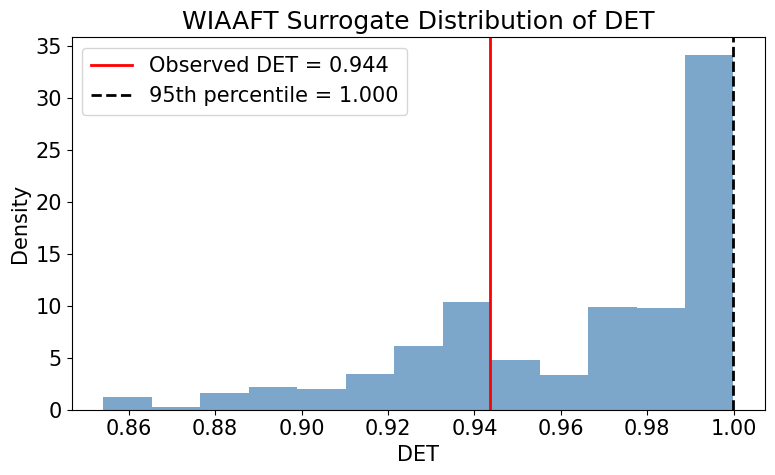

 17%|███████▏                                  | 17/100 [03:36<18:13, 13.18s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.943507588528906 
 Recurrence rate: 0.05001538935056941 
Threshold:0.5427999999999565 
 Laminarity:0.9723076923039528 
Shannon Entropy:1.9545942110383638 
Rank-order p-value (det):0.604 
Reject null (det) hypothesis:False

 
 

2
8
Mean Nearest Neighbor Distance: 0.22044247135612358
Pseudo-periodic surrogates generated successfullly


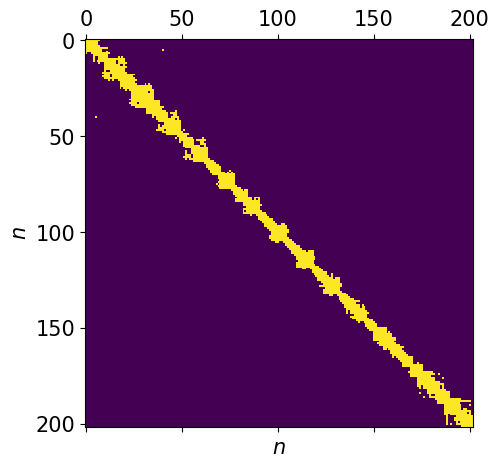

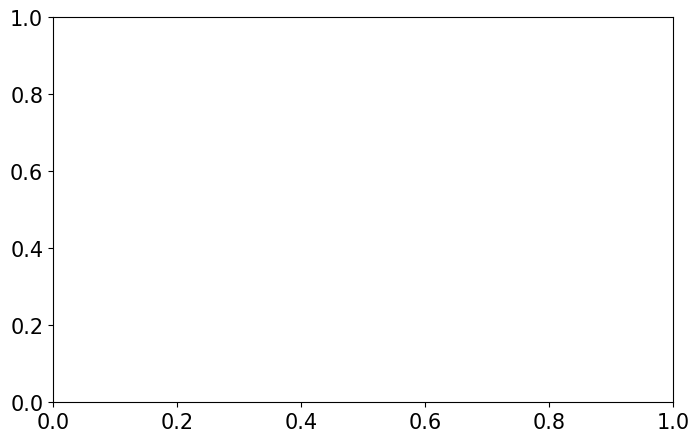

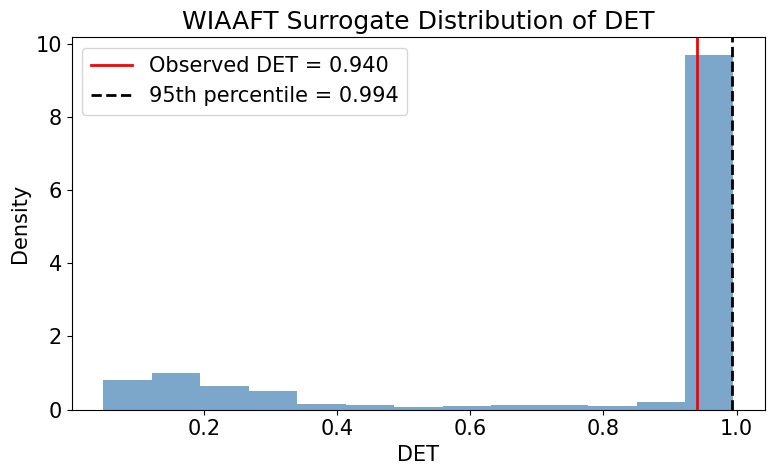

 18%|███████▌                                  | 18/100 [03:44<15:59, 11.70s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.940217391299238 
 Recurrence rate: 0.05004411332222331 
Threshold:0.5405999999999568 
 Laminarity:0.9681684622871295 
Shannon Entropy:1.9217021190962327 
Rank-order p-value (det):0.604 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.7889257471480307
Pseudo-periodic surrogates generated successfullly


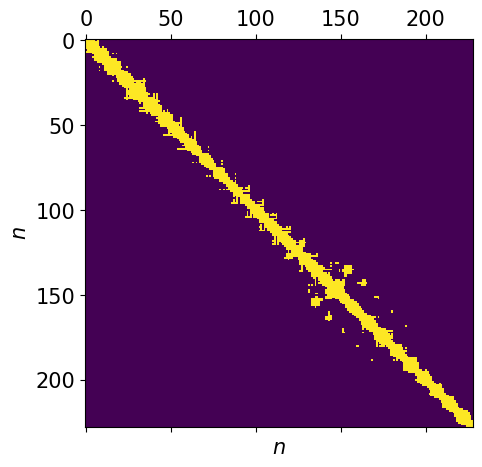

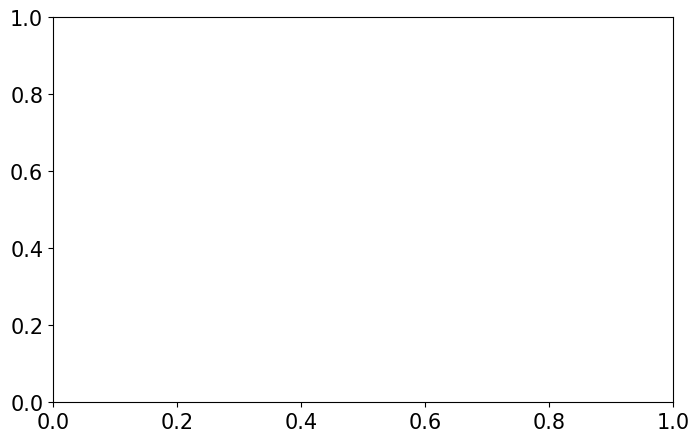

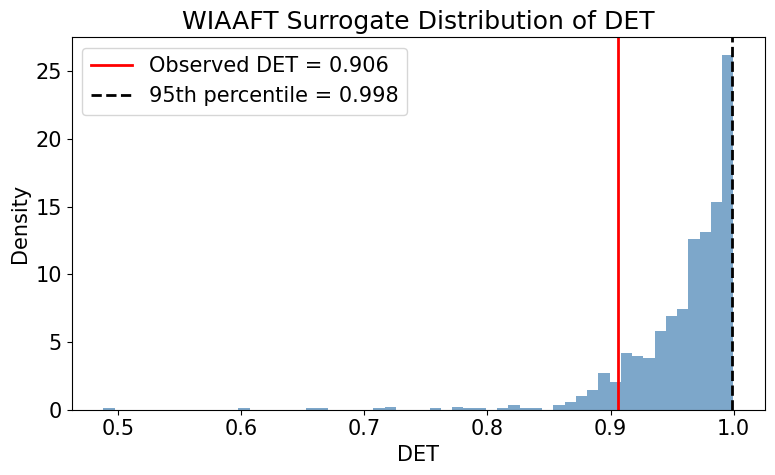

 19%|███████▉                                  | 19/100 [04:05<19:11, 14.22s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9064080944312547 
 Recurrence rate: 0.05001538935056941 
Threshold:2.0934999999999935 
 Laminarity:0.9542307692270992 
Shannon Entropy:2.0246054462028336 
Rank-order p-value (det):0.178 
Reject null (det) hypothesis:False

 
 

2
10
Mean Nearest Neighbor Distance: 0.5429115232400088
Pseudo-periodic surrogates generated successfullly


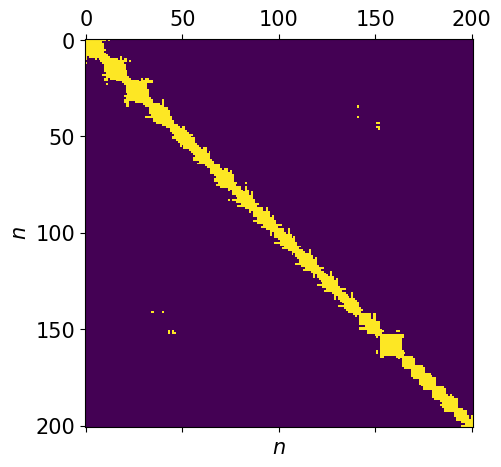

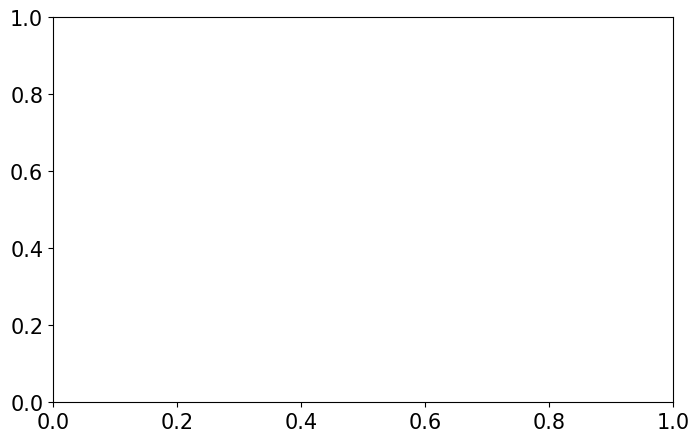

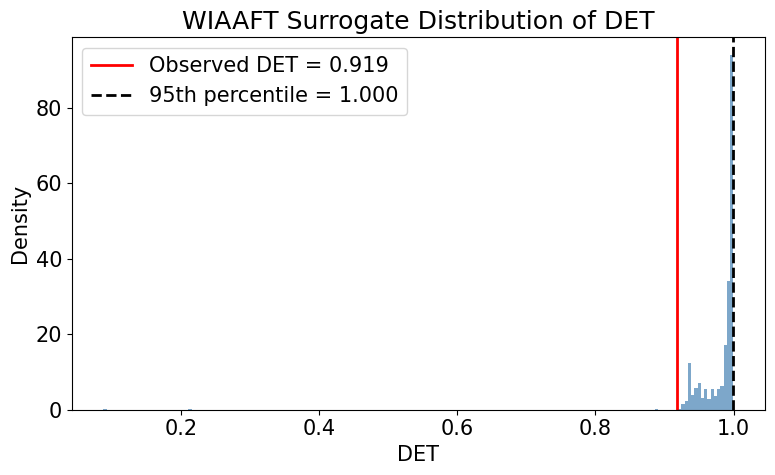

 20%|████████▍                                 | 20/100 [04:18<18:49, 14.12s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.918681318676271 
 Recurrence rate: 0.050023514269448774 
Threshold:1.455799999999856 
 Laminarity:0.9683325086542883 
Shannon Entropy:2.1289002541066306 
Rank-order p-value (det):0.008 
Reject null (det) hypothesis:True

 
 

3
10
Mean Nearest Neighbor Distance: 0.506810319056155
Pseudo-periodic surrogates generated successfullly


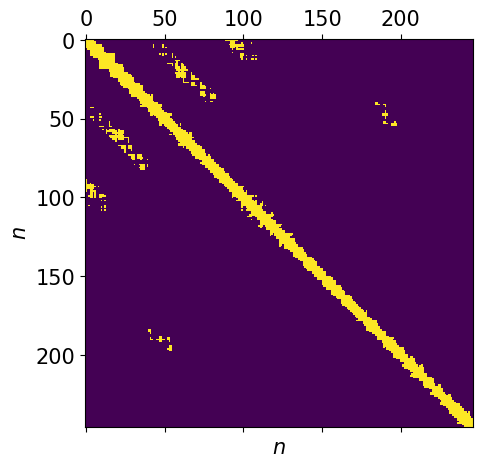

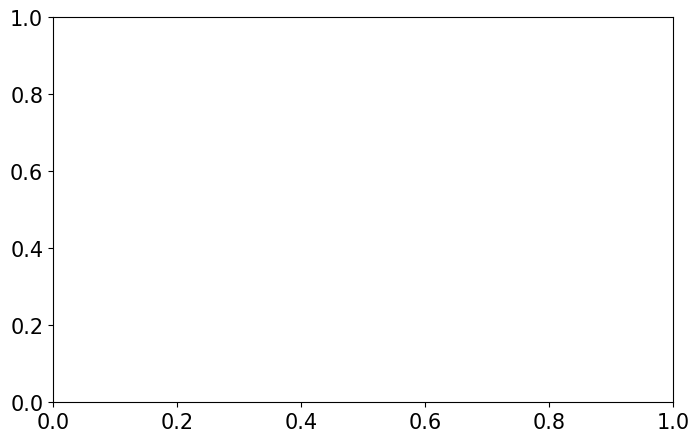

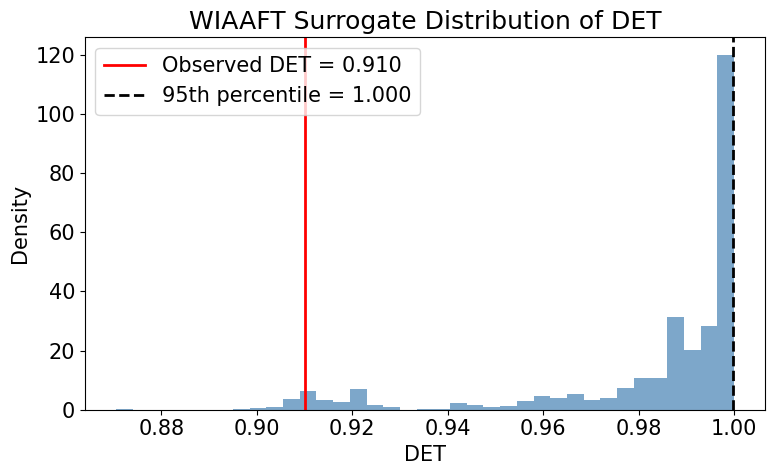

 21%|████████▊                                 | 21/100 [04:35<19:37, 14.91s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9100719424427696 
 Recurrence rate: 0.05000330491109789 
Threshold:1.429799999999859 
 Laminarity:0.9623265036319818 
Shannon Entropy:1.6209715558238977 
Rank-order p-value (det):0.048 
Reject null (det) hypothesis:True

 
 

4
9
Mean Nearest Neighbor Distance: 0.4557163479018963
Pseudo-periodic surrogates generated successfullly


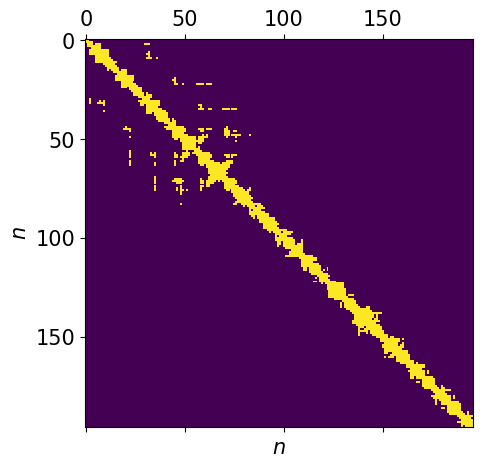

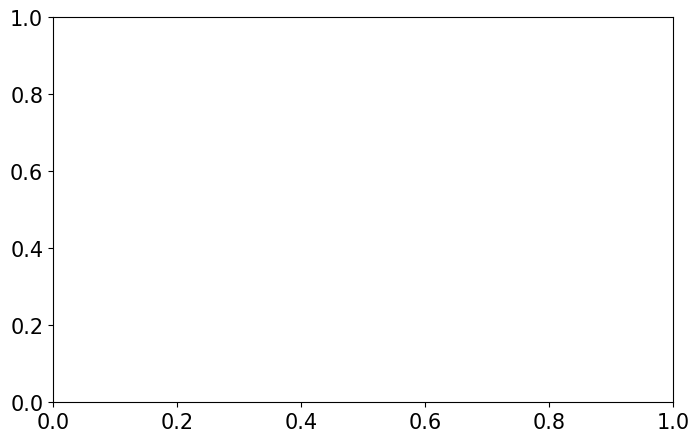

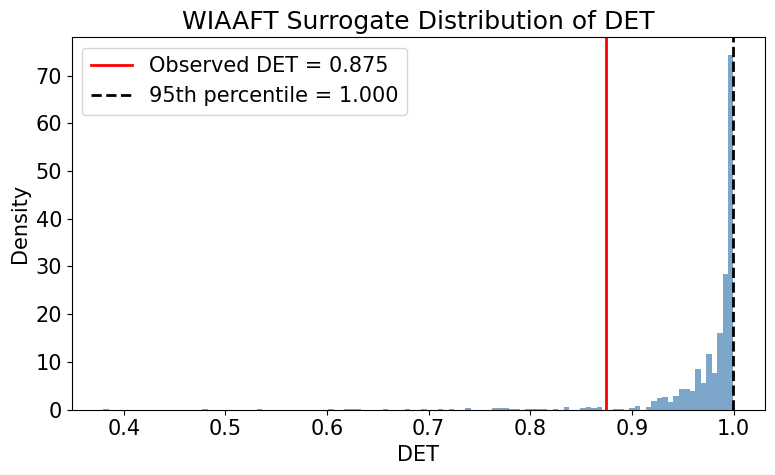

 22%|█████████▏                                | 22/100 [04:46<17:55, 13.78s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8748551564259859 
 Recurrence rate: 0.05003123698458976 
Threshold:1.0804999999998974 
 Laminarity:0.945889698226088 
Shannon Entropy:1.6620387877505738 
Rank-order p-value (det):0.082 
Reject null (det) hypothesis:False

 
 

4
10
Mean Nearest Neighbor Distance: 0.6260315944824191
Pseudo-periodic surrogates generated successfullly


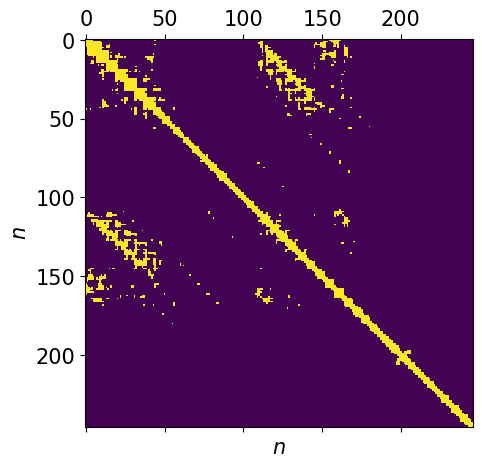

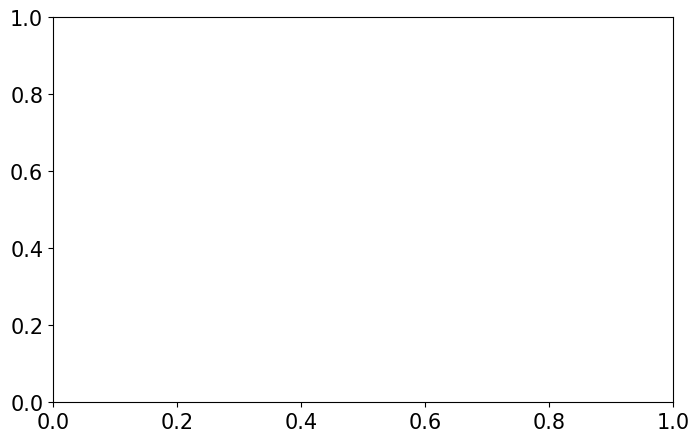

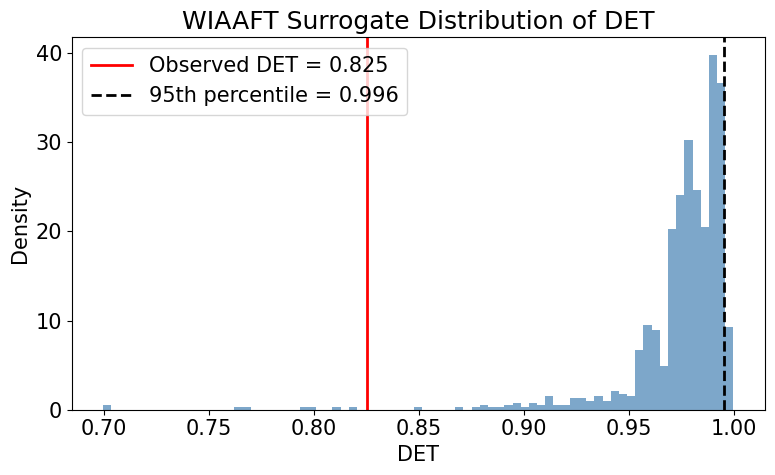

 23%|█████████▋                                | 23/100 [05:05<19:30, 15.20s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8251798561121396 
 Recurrence rate: 0.05000330491109789 
Threshold:1.456399999999856 
 Laminarity:0.9153998678092684 
Shannon Entropy:1.3934790335242626 
Rank-order p-value (det):0.018 
Reject null (det) hypothesis:True

 
 

5
10
Mean Nearest Neighbor Distance: 0.520729778431712
Pseudo-periodic surrogates generated successfullly


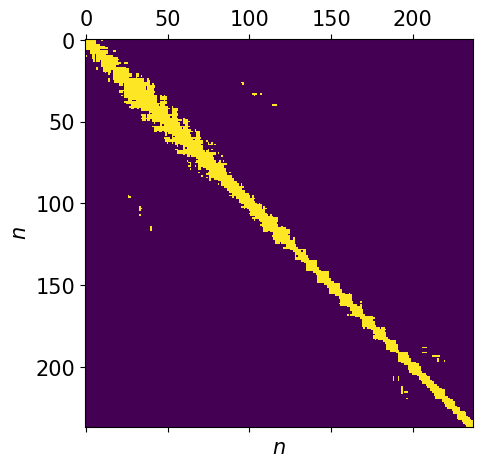

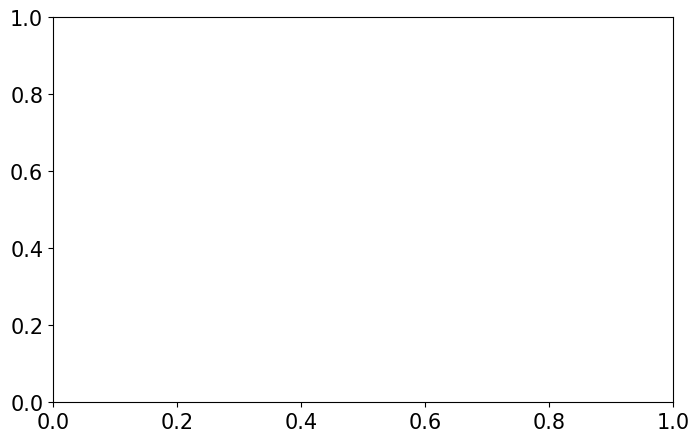

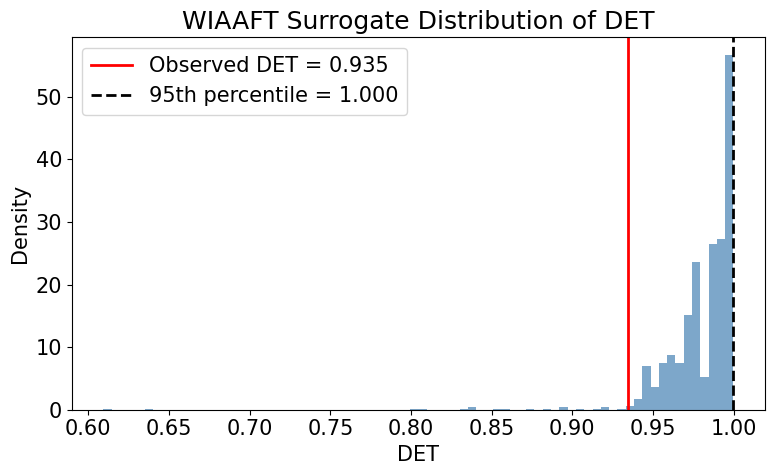

 24%|██████████                                | 24/100 [05:20<19:08, 15.11s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9346811819559305 
 Recurrence rate: 0.050009791878082216 
Threshold:1.2541999999998783 
 Laminarity:0.9647561409720016 
Shannon Entropy:1.8500755401703175 
Rank-order p-value (det):0.038 
Reject null (det) hypothesis:True

 
 

6
7
Mean Nearest Neighbor Distance: 0.3392499214157042
Pseudo-periodic surrogates generated successfullly


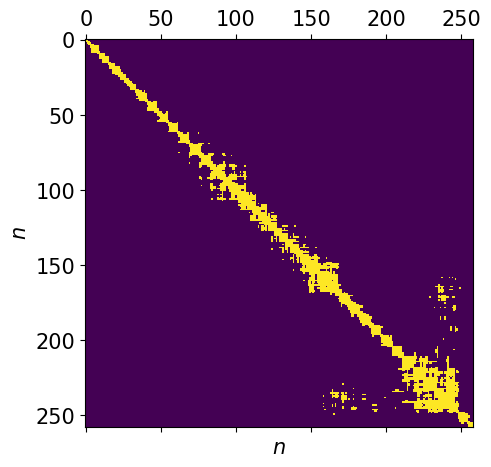

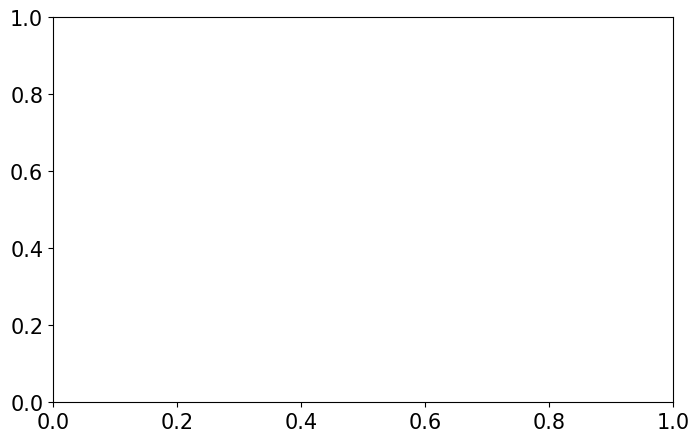

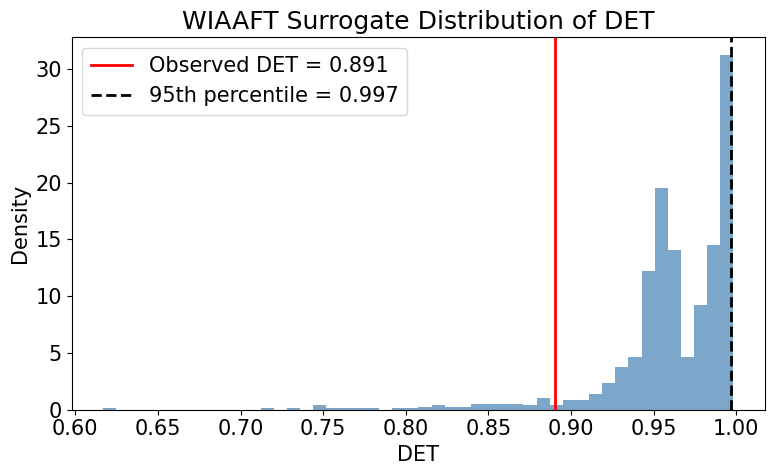

 25%|██████████▌                               | 25/100 [05:32<17:54, 14.33s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8906249999971009 
 Recurrence rate: 0.050027041644131964 
Threshold:0.8613999999999215 
 Laminarity:0.9402402402374167 
Shannon Entropy:1.8624922408824647 
Rank-order p-value (det):0.1 
Reject null (det) hypothesis:False

 
 

6
7
Mean Nearest Neighbor Distance: 0.49293130395558243
Pseudo-periodic surrogates generated successfullly


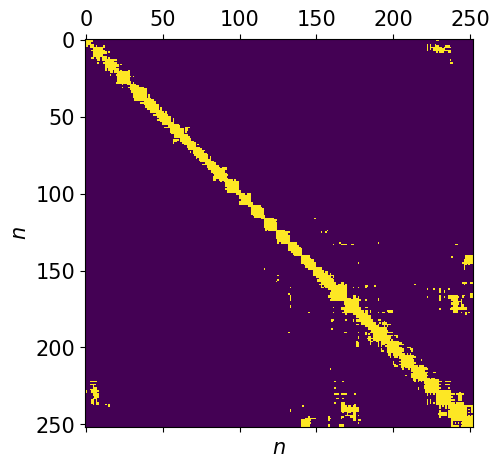

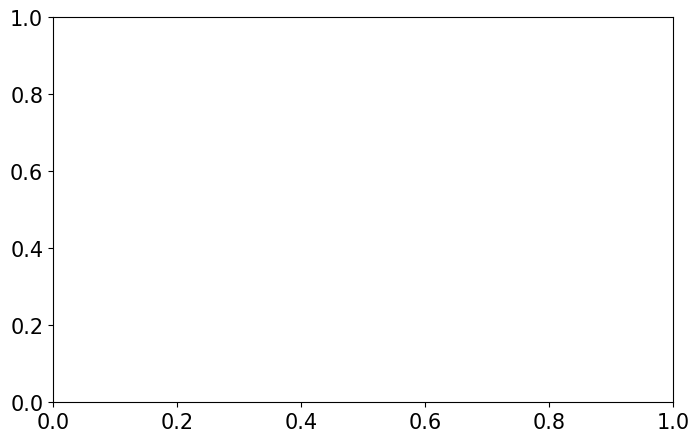

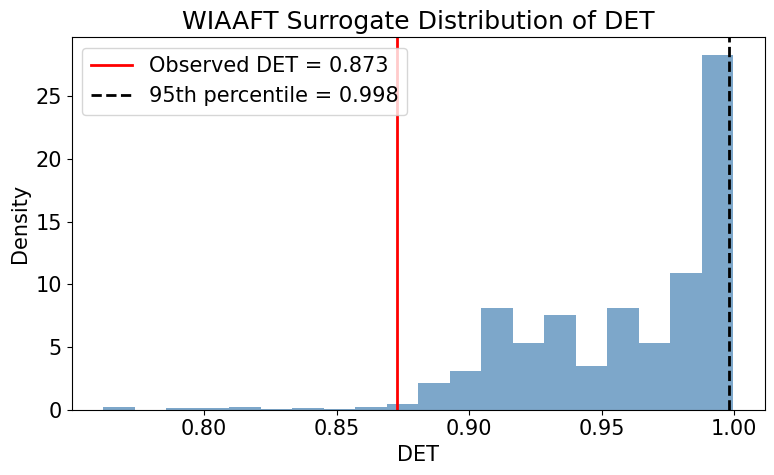

 26%|██████████▉                               | 26/100 [05:48<18:12, 14.77s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8727770177808729 
 Recurrence rate: 0.05001259763164525 
Threshold:1.2444999999998794 
 Laminarity:0.9310453400474463 
Shannon Entropy:1.9403210964324458 
Rank-order p-value (det):0.038 
Reject null (det) hypothesis:True

 
 

7
10
Mean Nearest Neighbor Distance: 0.7017754723281023
Pseudo-periodic surrogates generated successfullly


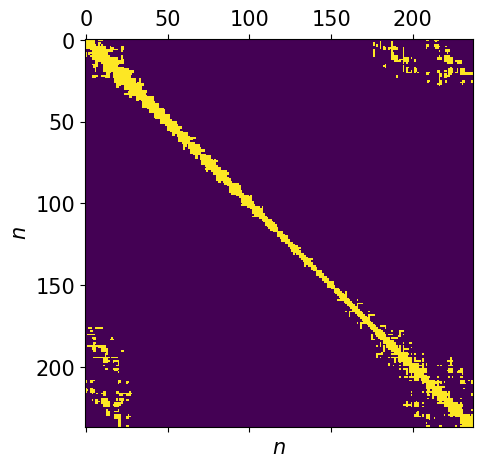

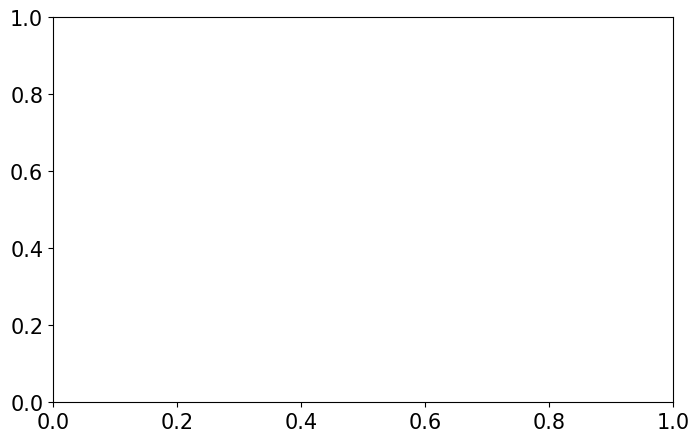

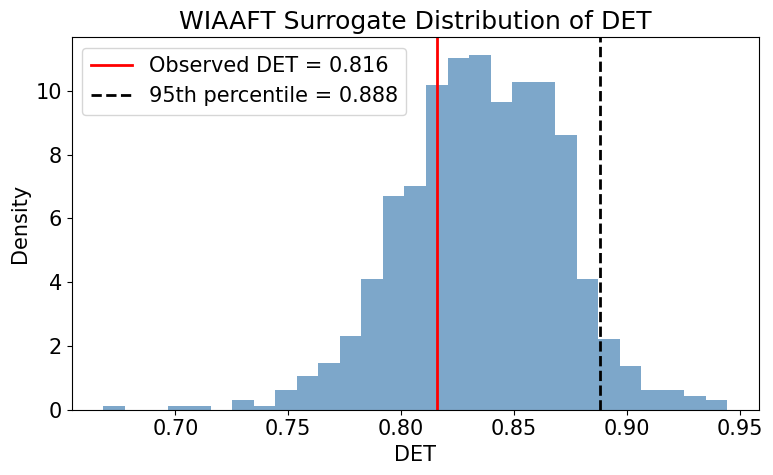

 27%|███████████▎                              | 27/100 [06:08<19:40, 16.17s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8157076205256 
 Recurrence rate: 0.050009791878082216 
Threshold:1.6520999999998345 
 Laminarity:0.9184763260914259 
Shannon Entropy:1.5649242505812508 
Rank-order p-value (det):0.578 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.49654575700819215
Pseudo-periodic surrogates generated successfullly


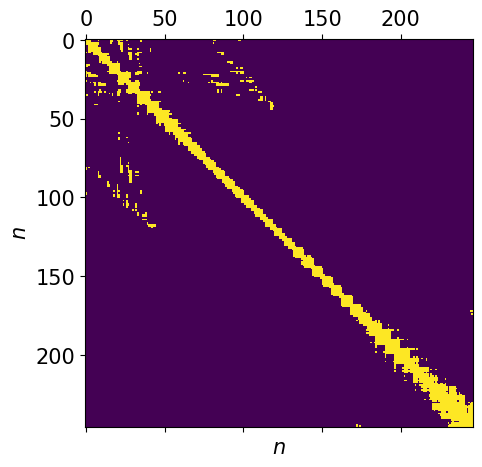

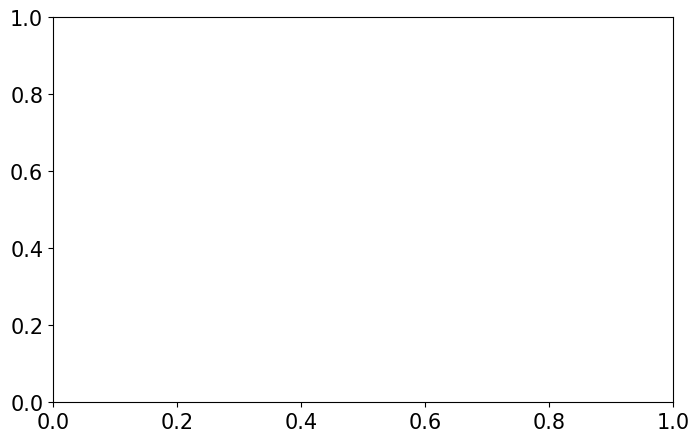

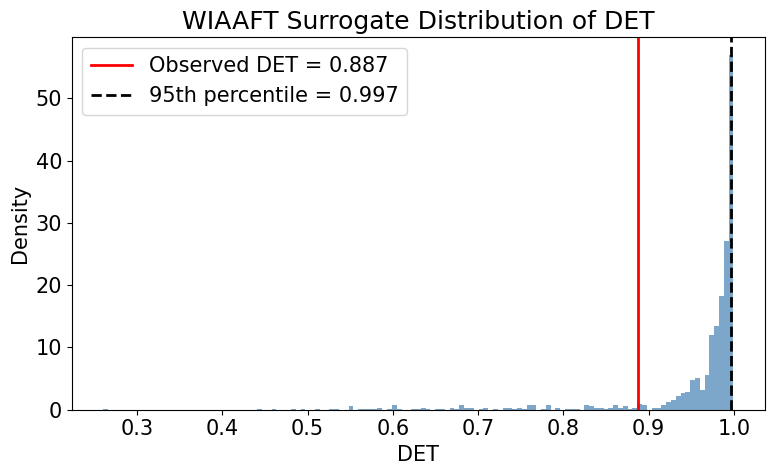

 28%|███████████▊                              | 28/100 [06:26<20:08, 16.78s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8871315600255675 
 Recurrence rate: 0.050036354022076804 
Threshold:1.2687999999998767 
 Laminarity:0.9435270805781257 
Shannon Entropy:1.5828347968018062 
Rank-order p-value (det):0.196 
Reject null (det) hypothesis:False

 
 

7
7
Mean Nearest Neighbor Distance: 0.30281557697776795
Pseudo-periodic surrogates generated successfullly


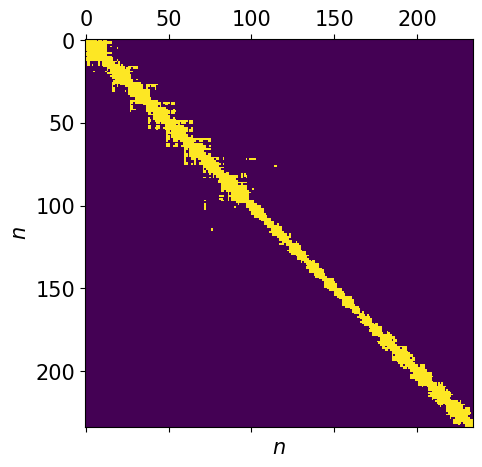

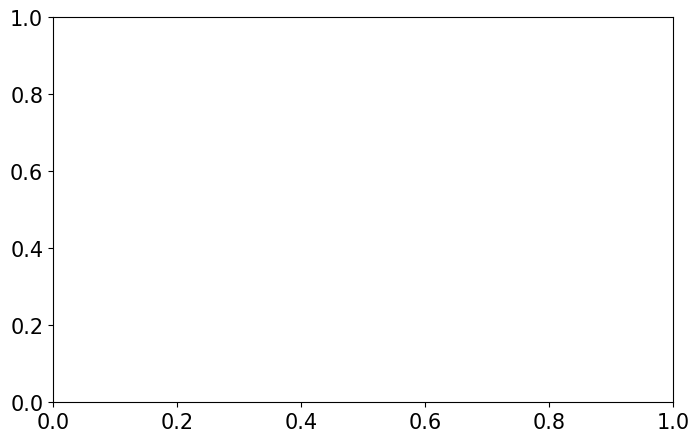

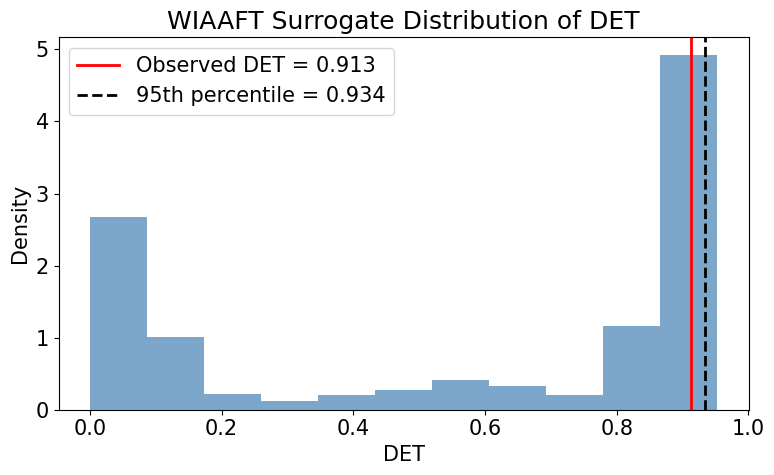

 29%|████████████▏                             | 29/100 [06:39<18:27, 15.60s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.9129392971209548 
 Recurrence rate: 0.05000365256775513 
Threshold:0.8551999999999221 
 Laminarity:0.9663988312601666 
Shannon Entropy:2.0449723005886518 
Rank-order p-value (det):0.292 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.41542976883526267
Pseudo-periodic surrogates generated successfullly


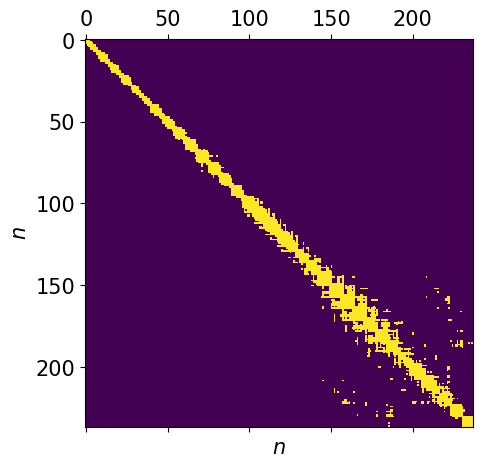

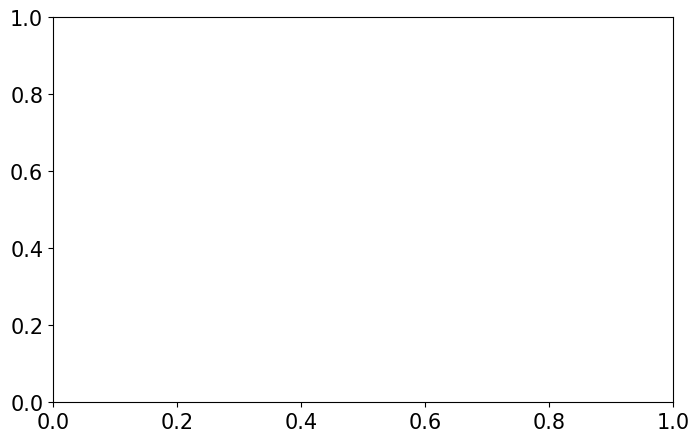

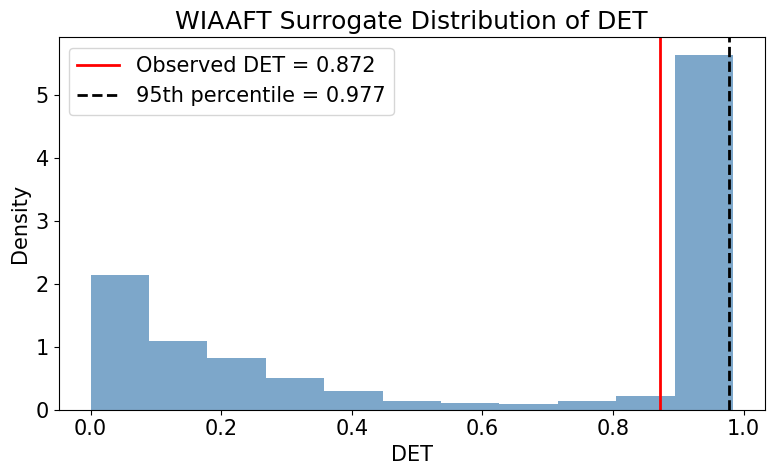

 30%|████████████▌                             | 30/100 [06:54<18:05, 15.50s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8716951788457555 
 Recurrence rate: 0.050009791878082216 
Threshold:1.0132999999999048 
 Laminarity:0.9298682805235676 
Shannon Entropy:1.6789821546046688 
Rank-order p-value (det):0.98 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.5908104392361272
Pseudo-periodic surrogates generated successfullly


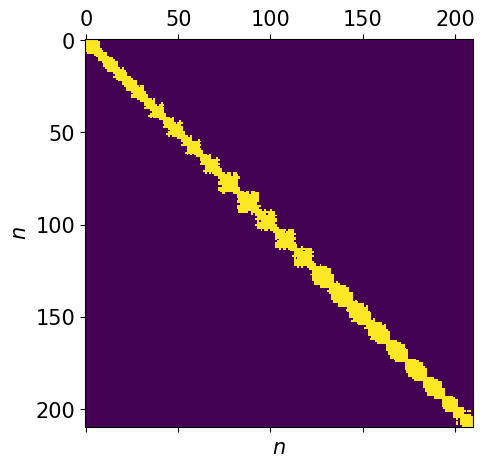

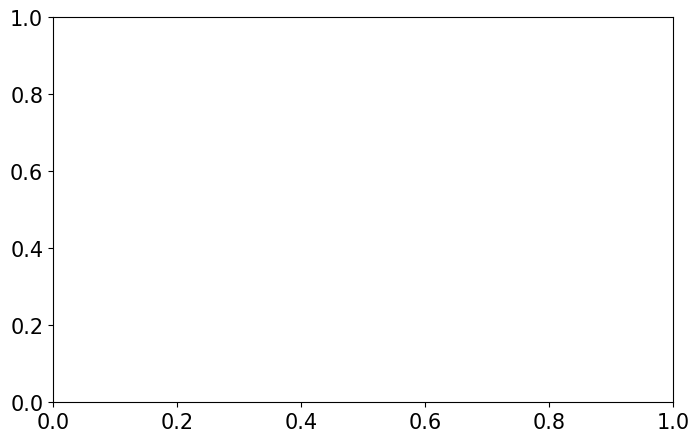

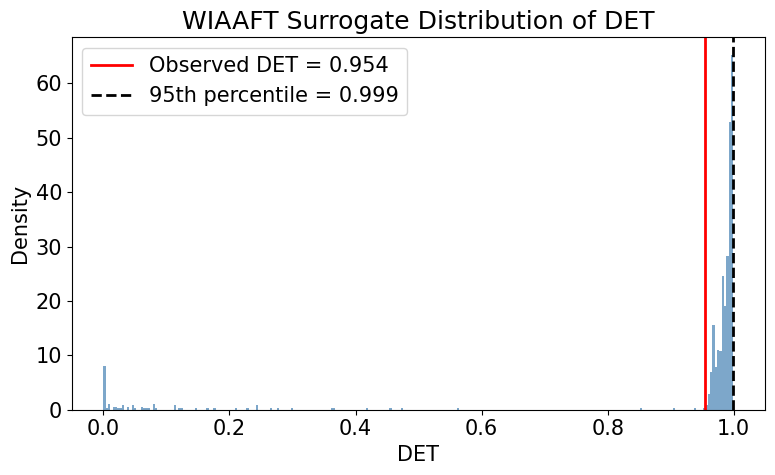

 31%|█████████████                             | 31/100 [07:11<18:15, 15.88s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9539078156264835 
 Recurrence rate: 0.05002267573696145 
Threshold:1.4552999999998562 
 Laminarity:0.9841341795059649 
Shannon Entropy:2.054798034238529 
Rank-order p-value (det):0.172 
Reject null (det) hypothesis:False

 
 

7
8
Mean Nearest Neighbor Distance: 0.39861818969662327
Pseudo-periodic surrogates generated successfullly


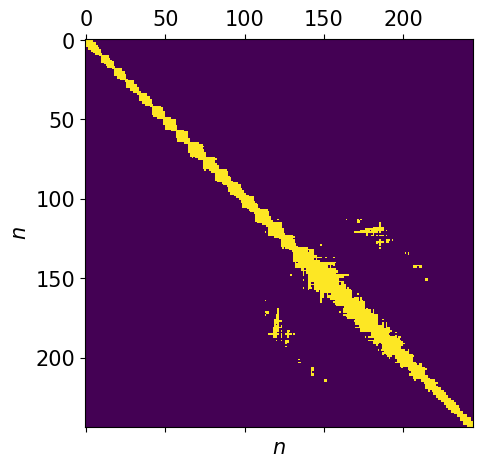

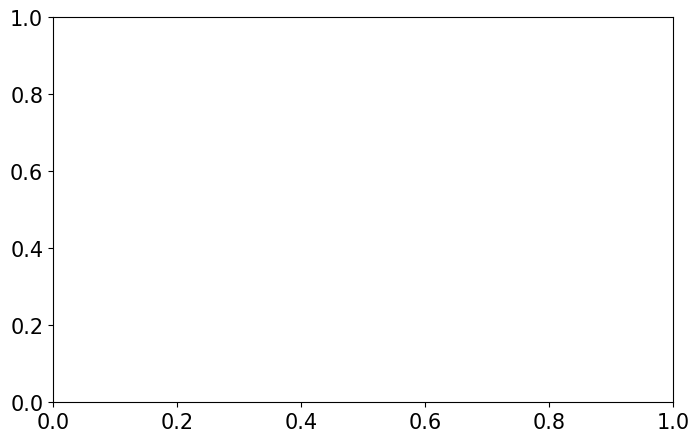

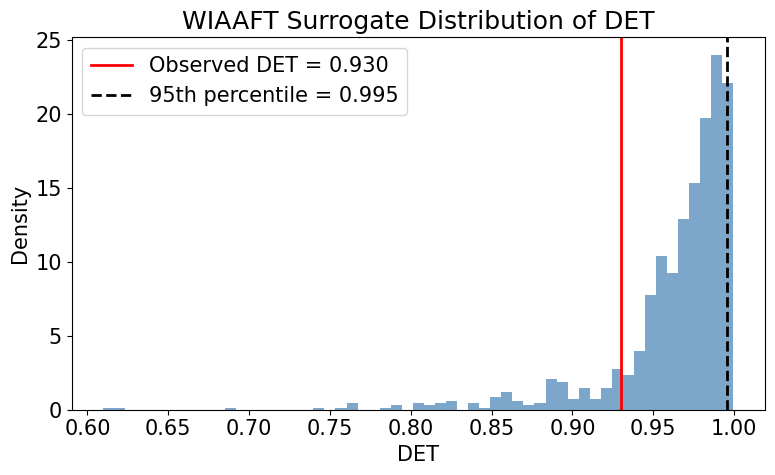

 32%|█████████████▍                            | 32/100 [07:27<18:06, 15.97s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9297732260390279 
 Recurrence rate: 0.0500201558720774 
Threshold:1.1821999999998862 
 Laminarity:0.9684351914003747 
Shannon Entropy:2.023057624131898 
Rank-order p-value (det):0.238 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.43632535089174695
Pseudo-periodic surrogates generated successfullly


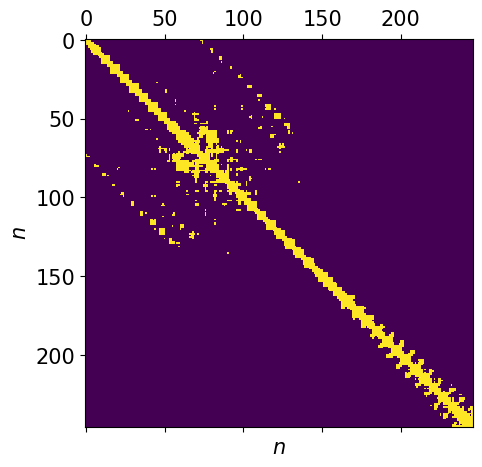

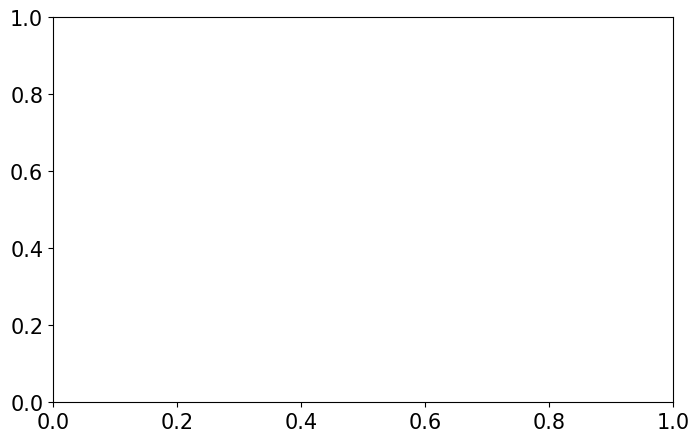

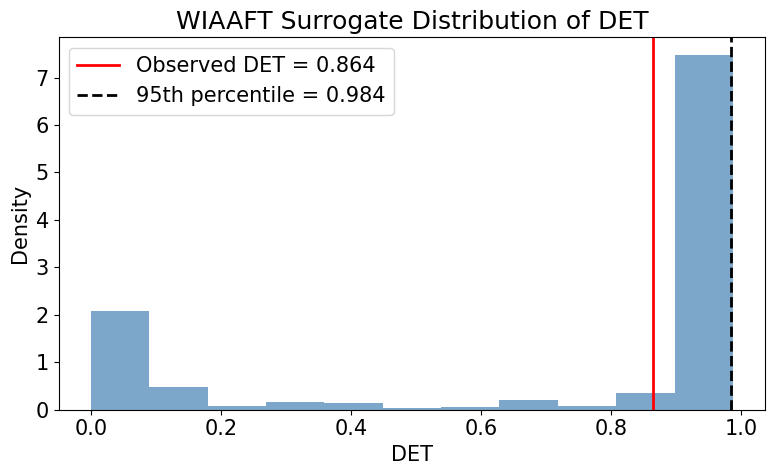

 33%|█████████████▊                            | 33/100 [07:44<18:06, 16.21s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8640287769753093 
 Recurrence rate: 0.05000330491109789 
Threshold:1.1422999999998906 
 Laminarity:0.9424983476505536 
Shannon Entropy:1.4350601022440093 
Rank-order p-value (det):0.608 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.4766251387478889
Pseudo-periodic surrogates generated successfullly


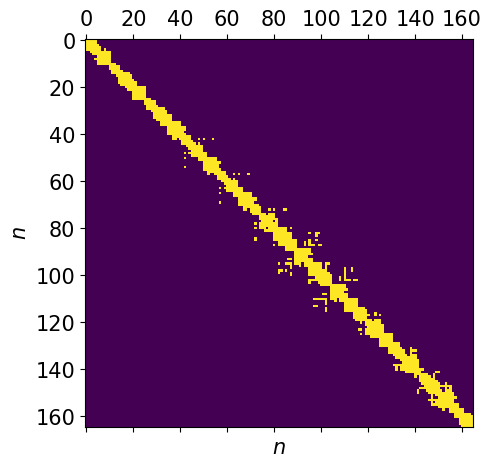

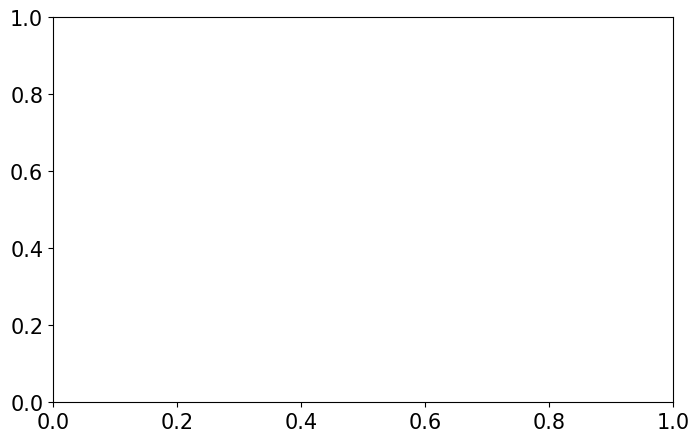

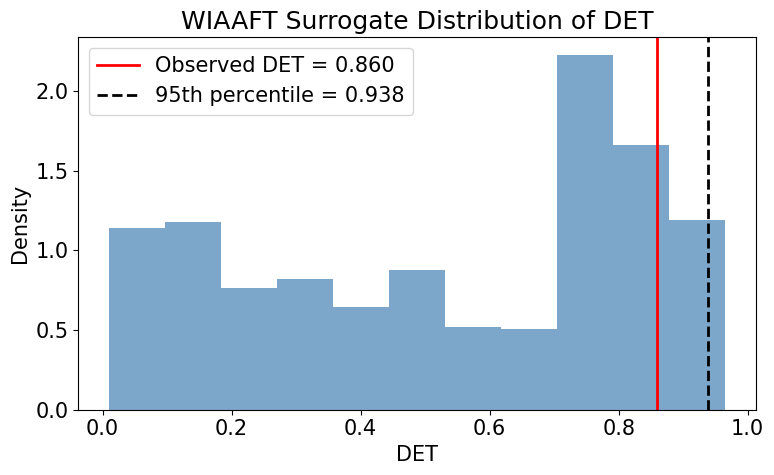

 34%|██████████████▎                           | 34/100 [07:54<15:58, 14.52s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.859766277121371 
 Recurrence rate: 0.05006427915518825 
Threshold:0.947499999999912 
 Laminarity:0.942773294197045 
Shannon Entropy:1.8383007836283367 
Rank-order p-value (det):0.232 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.5498898882864194
Pseudo-periodic surrogates generated successfullly


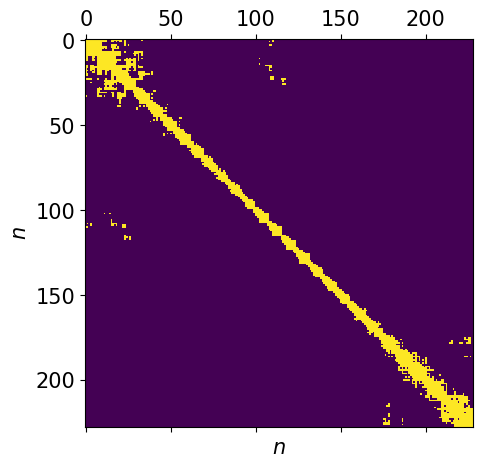

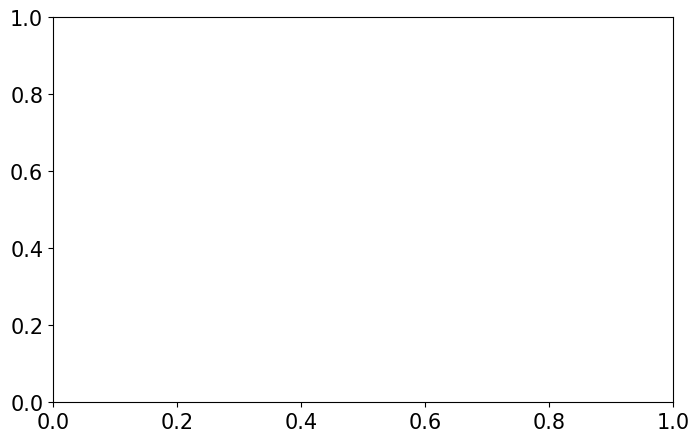

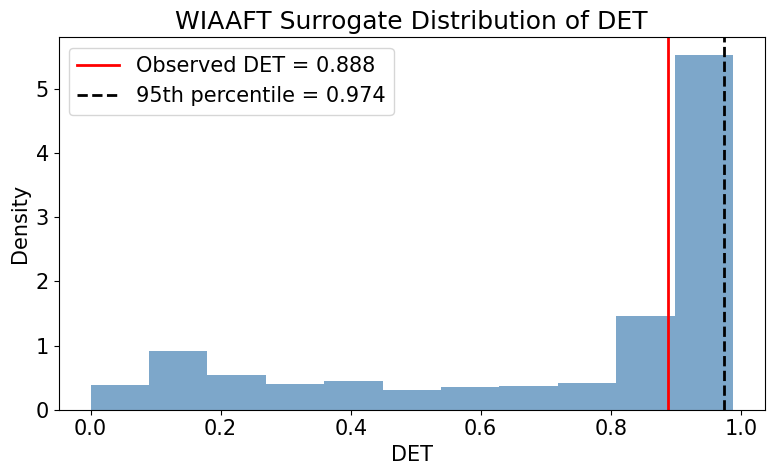

 35%|██████████████▋                           | 35/100 [08:12<16:43, 15.44s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.887858347382429 
 Recurrence rate: 0.05001538935056941 
Threshold:1.4215999999998599 
 Laminarity:0.9399999999963846 
Shannon Entropy:1.9604696322619246 
Rank-order p-value (det):0.942 
Reject null (det) hypothesis:False

 
 

7
9
Mean Nearest Neighbor Distance: 0.5202170273314455
Pseudo-periodic surrogates generated successfullly


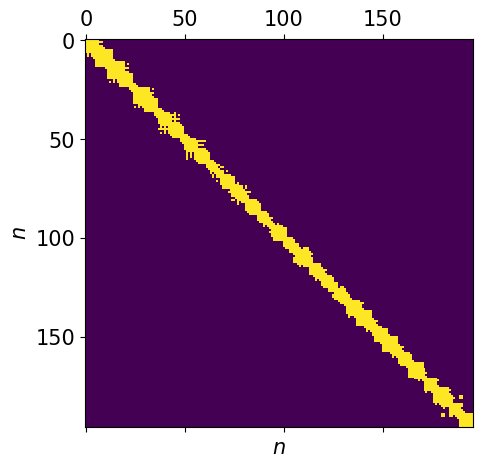

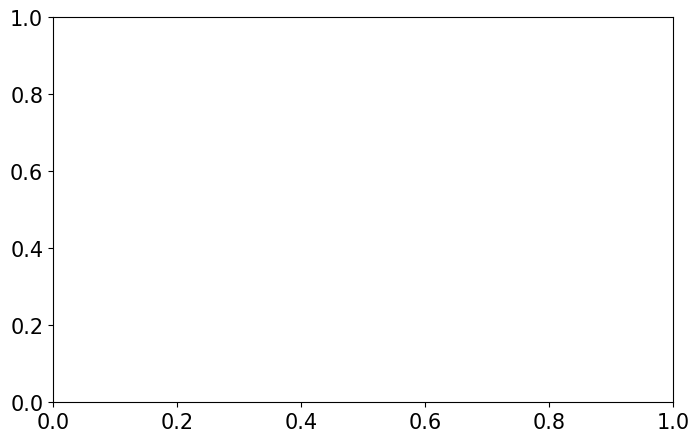

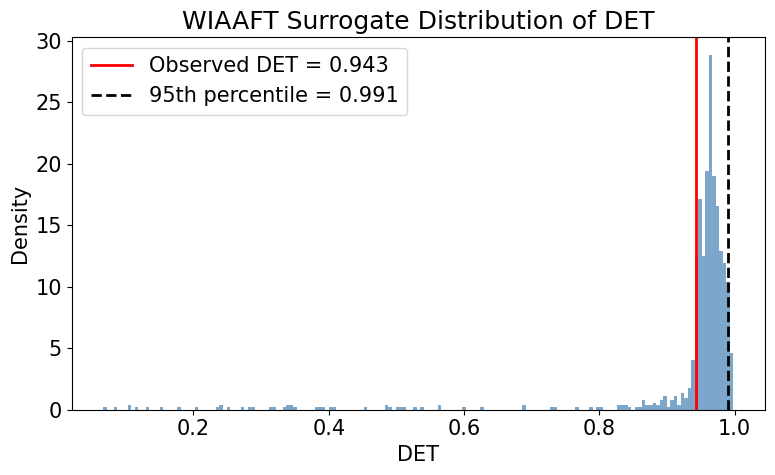

 36%|███████████████                           | 36/100 [08:27<16:19, 15.30s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.943221320967884 
 Recurrence rate: 0.05003123698458976 
Threshold:1.4400999999998578 
 Laminarity:0.9760665972894066 
Shannon Entropy:2.061695140685442 
Rank-order p-value (det):0.312 
Reject null (det) hypothesis:False

 
 

7
10
Mean Nearest Neighbor Distance: 0.17692400358885726
Pseudo-periodic surrogates generated successfullly


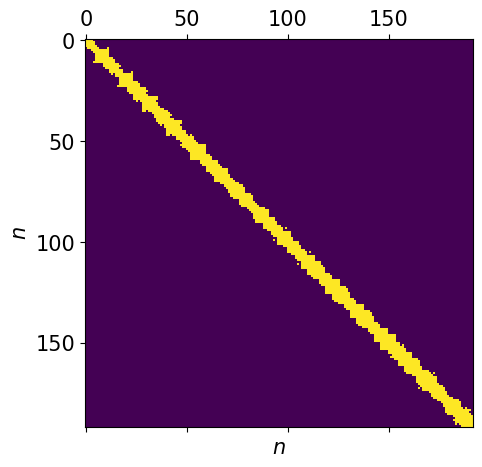

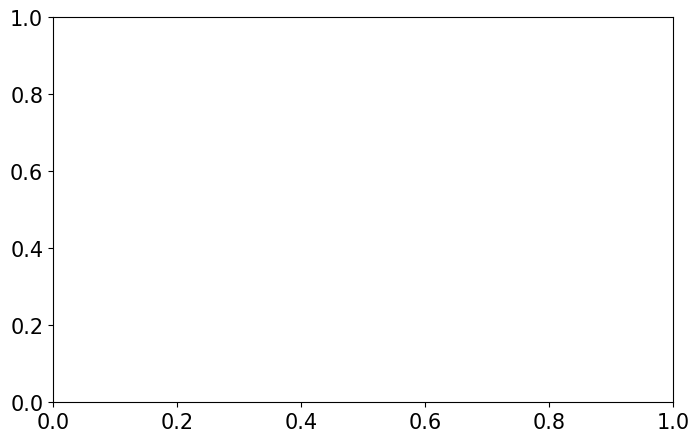

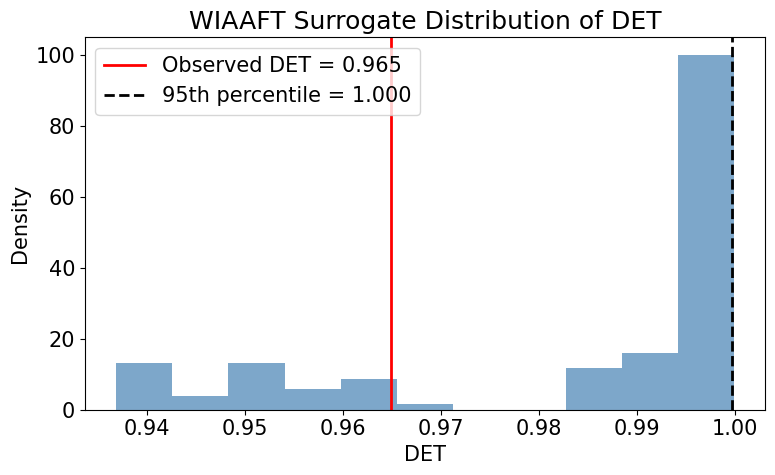

 37%|███████████████▌                          | 37/100 [08:36<14:09, 13.48s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9648910411563869 
 Recurrence rate: 0.05002170138888889 
Threshold:0.47479999999996403 
 Laminarity:0.9918655097560095 
Shannon Entropy:1.5785163523660026 
Rank-order p-value (det):0.514 
Reject null (det) hypothesis:False

 
 

7
9
Mean Nearest Neighbor Distance: 0.46008263147263767
Pseudo-periodic surrogates generated successfullly


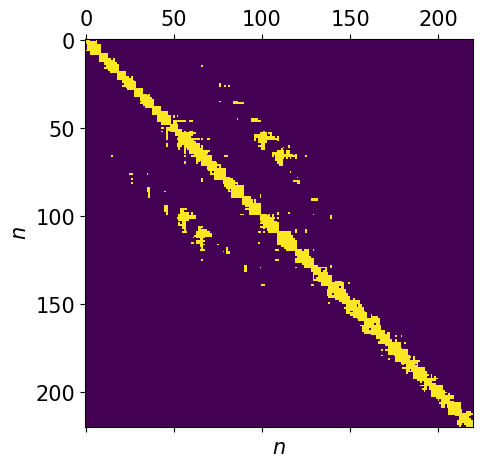

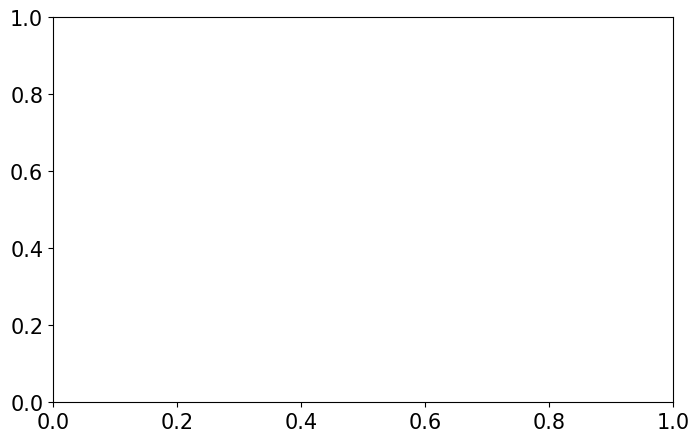

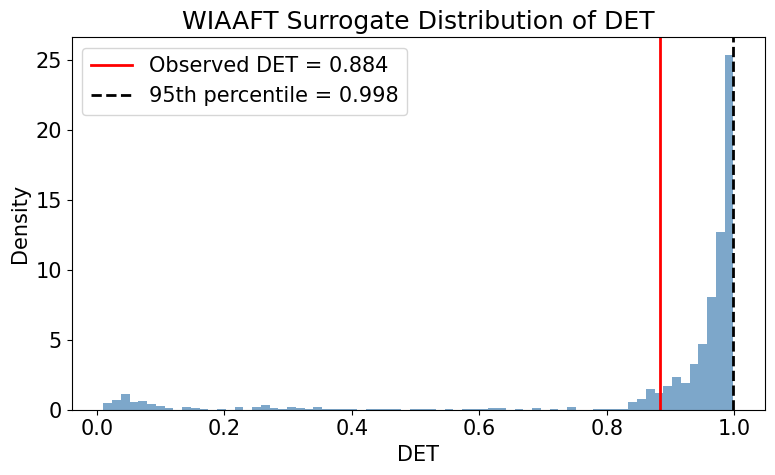

 38%|███████████████▉                          | 38/100 [08:50<14:11, 13.73s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8838475499052457 
 Recurrence rate: 0.05008264462809917 
Threshold:1.093999999999896 
 Laminarity:0.9447194719432974 
Shannon Entropy:1.8873354974287184 
Rank-order p-value (det):0.338 
Reject null (det) hypothesis:False

 
 

7
8
Mean Nearest Neighbor Distance: 0.5136223926108161
Pseudo-periodic surrogates generated successfullly


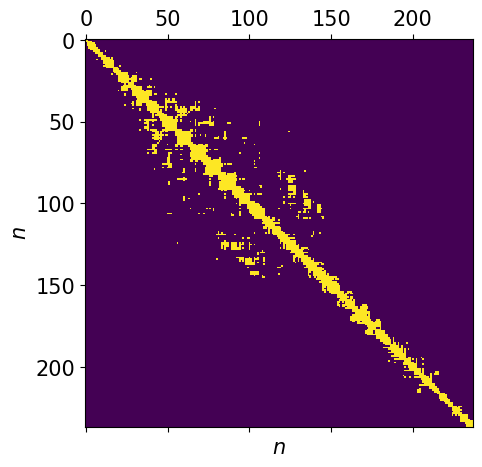

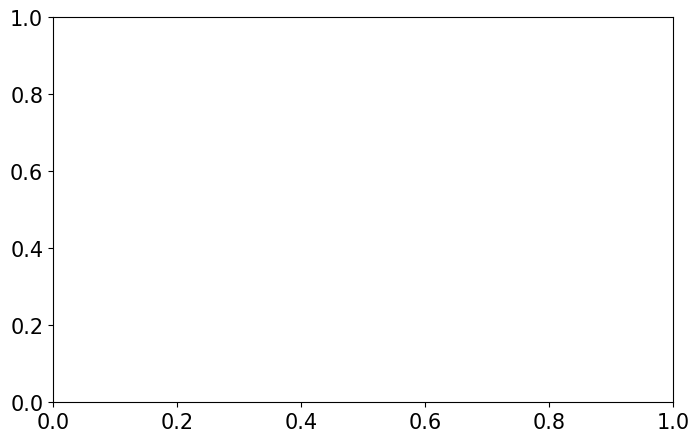

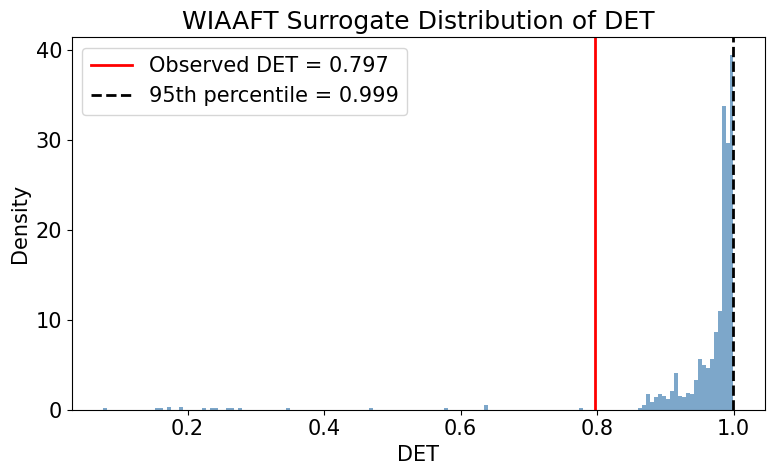

 39%|████████████████▍                         | 39/100 [09:07<14:50, 14.61s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.797045101085548 
 Recurrence rate: 0.050009791878082216 
Threshold:1.301499999999873 
 Laminarity:0.8985404058351779 
Shannon Entropy:1.805056838816959 
Rank-order p-value (det):0.042 
Reject null (det) hypothesis:True

 
 

8
7
Mean Nearest Neighbor Distance: 0.46900075867084284
Pseudo-periodic surrogates generated successfullly


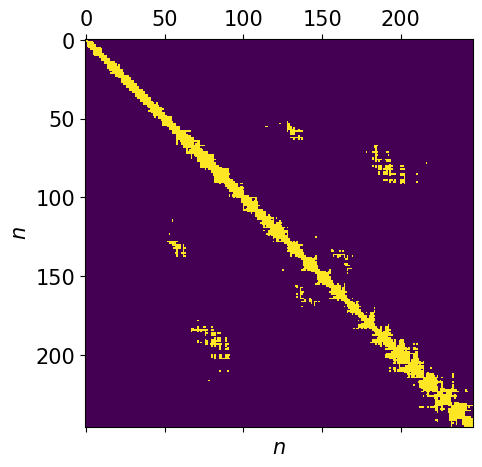

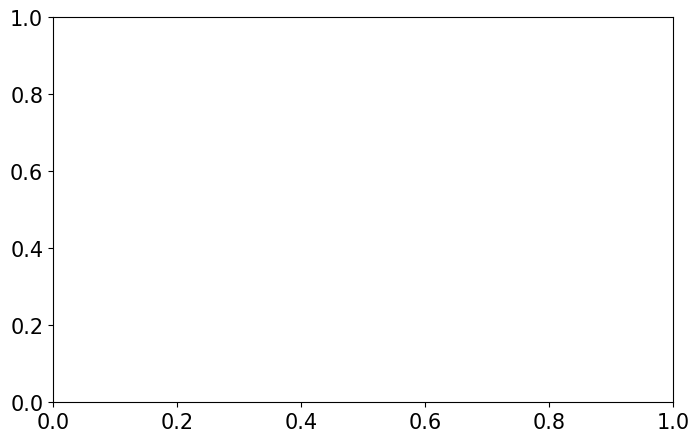

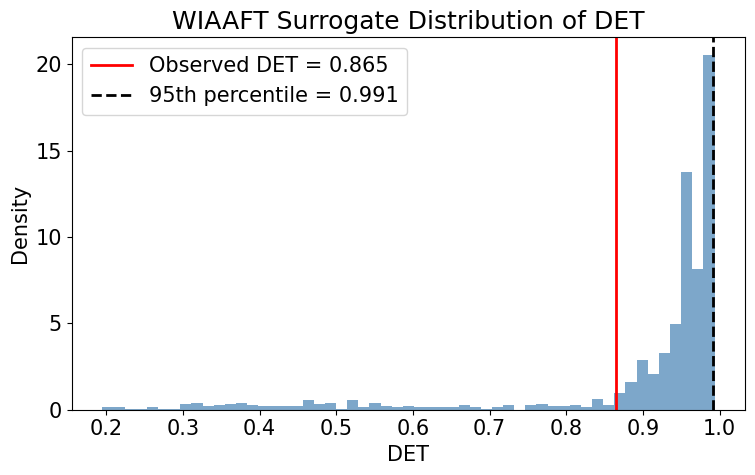

 40%|████████████████▊                         | 40/100 [09:22<14:53, 14.88s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.8654676258961674 
 Recurrence rate: 0.05000330491109789 
Threshold:1.1080999999998944 
 Laminarity:0.9286186384635539 
Shannon Entropy:1.8248634784103646 
Rank-order p-value (det):0.312 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.4028460214857778
Pseudo-periodic surrogates generated successfullly


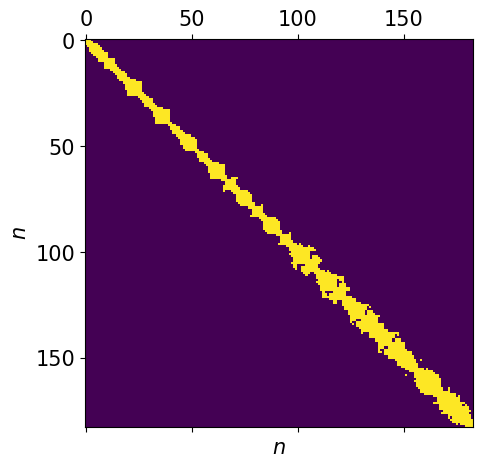

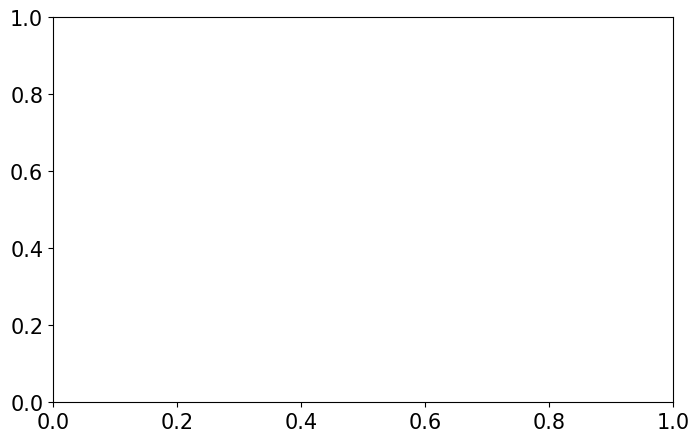

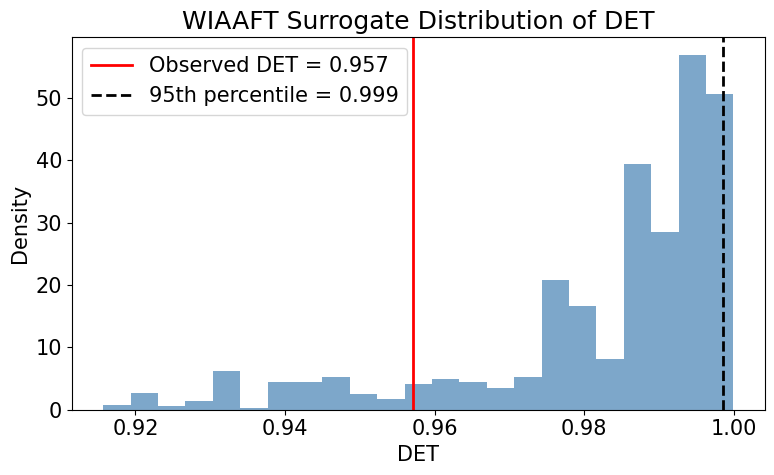

 41%|█████████████████▏                        | 41/100 [09:34<13:43, 13.96s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9571045576343358 
 Recurrence rate: 0.05001642330317418 
Threshold:0.9658999999999099 
 Laminarity:0.9850746268597906 
Shannon Entropy:2.2203442280853483 
Rank-order p-value (det):0.23 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.5857221046575024
Pseudo-periodic surrogates generated successfullly


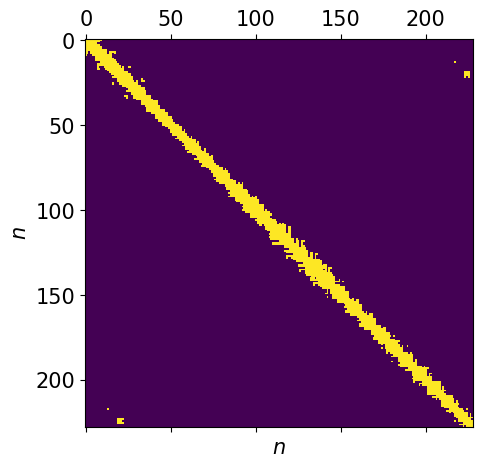

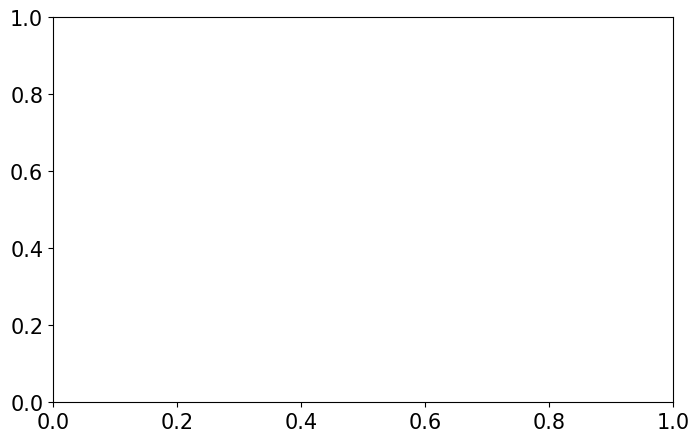

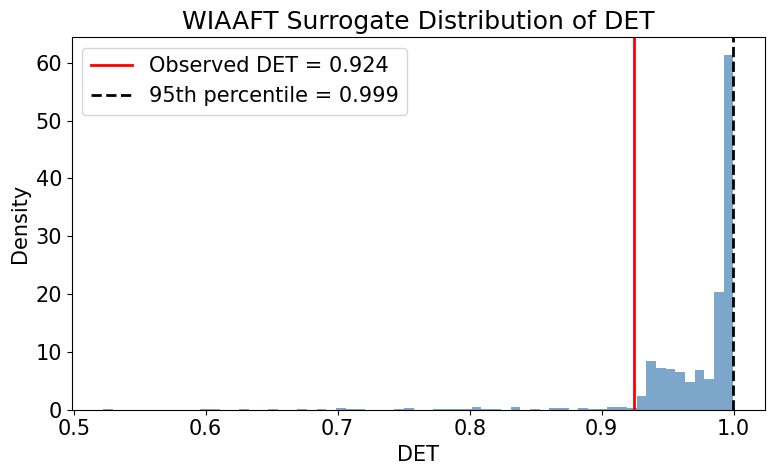

 42%|█████████████████▋                        | 42/100 [09:53<14:46, 15.28s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9241146711596792 
 Recurrence rate: 0.05001538935056941 
Threshold:1.5973999999998405 
 Laminarity:0.9730769230731805 
Shannon Entropy:1.7049904082870468 
Rank-order p-value (det):0.088 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.5616825357693719
Pseudo-periodic surrogates generated successfullly


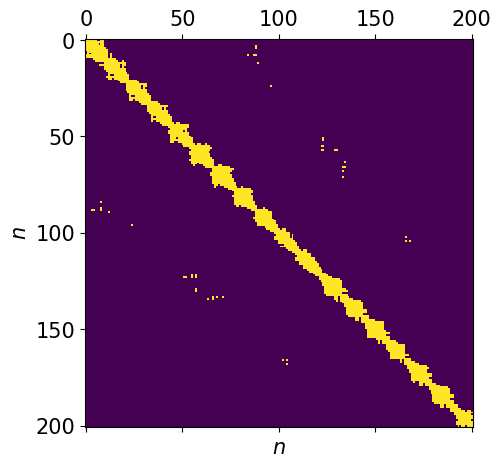

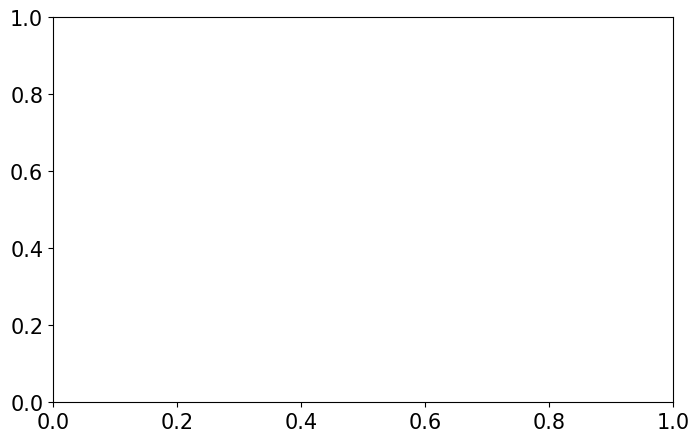

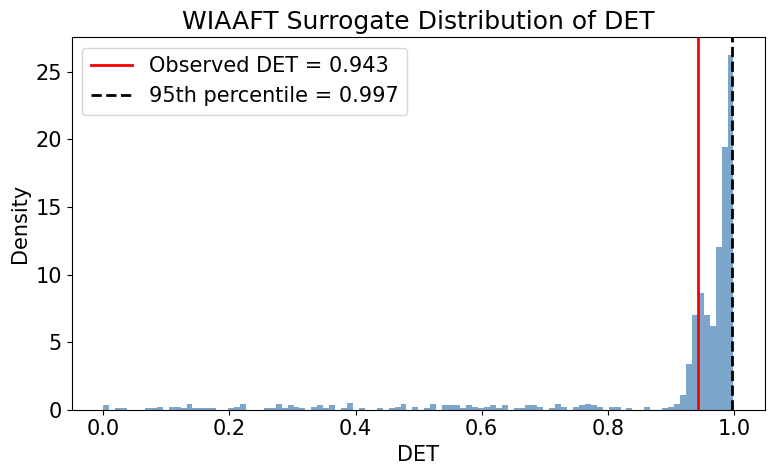

 43%|██████████████████                        | 43/100 [10:07<14:19, 15.07s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9428571428519624 
 Recurrence rate: 0.050023514269448774 
Threshold:1.2634999999998773 
 Laminarity:0.9703117268630861 
Shannon Entropy:2.177423220037279 
Rank-order p-value (det):0.504 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.6772107841055607
Pseudo-periodic surrogates generated successfullly


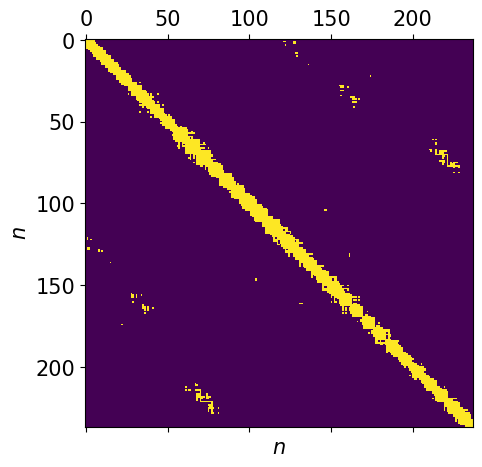

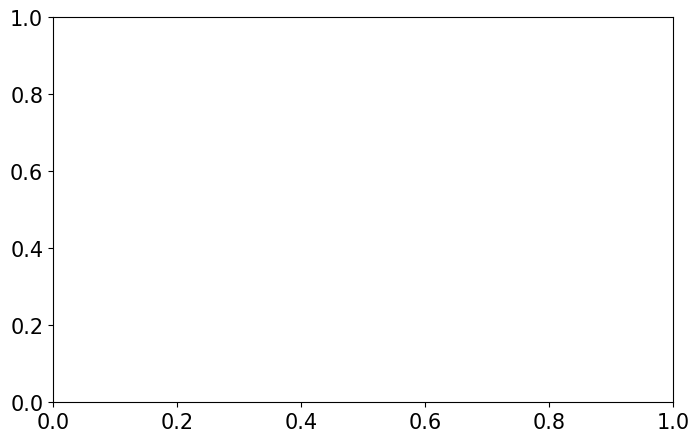

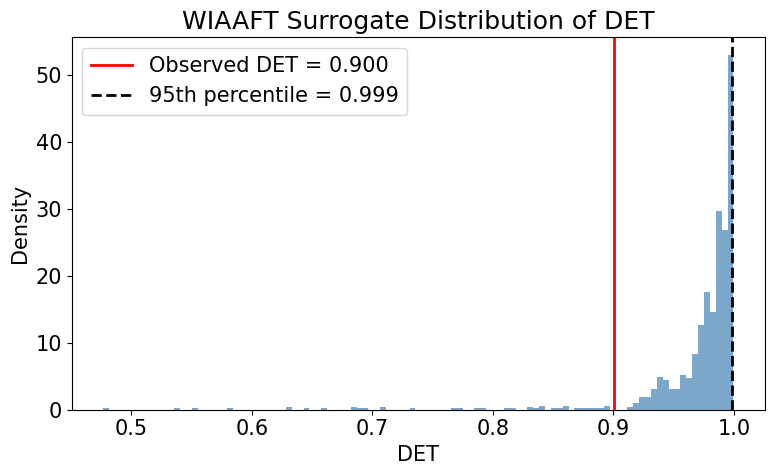

 44%|██████████████████▍                       | 44/100 [10:30<16:11, 17.34s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9004665629825022 
 Recurrence rate: 0.050009791878082216 
Threshold:1.819599999999816 
 Laminarity:0.9494482022038112 
Shannon Entropy:1.9636805314350096 
Rank-order p-value (det):0.082 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.3349133119314215
Pseudo-periodic surrogates generated successfullly


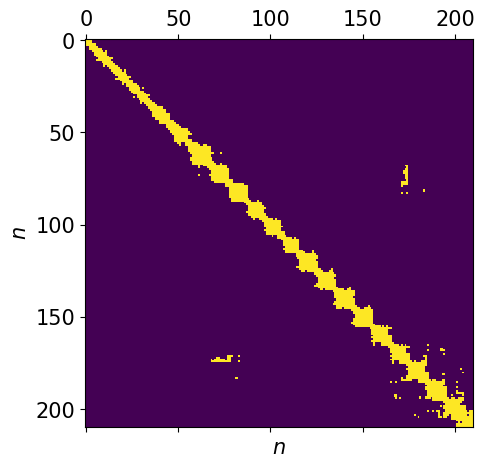

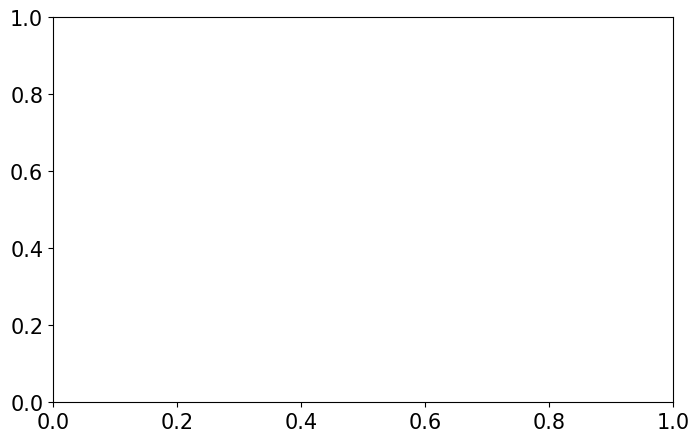

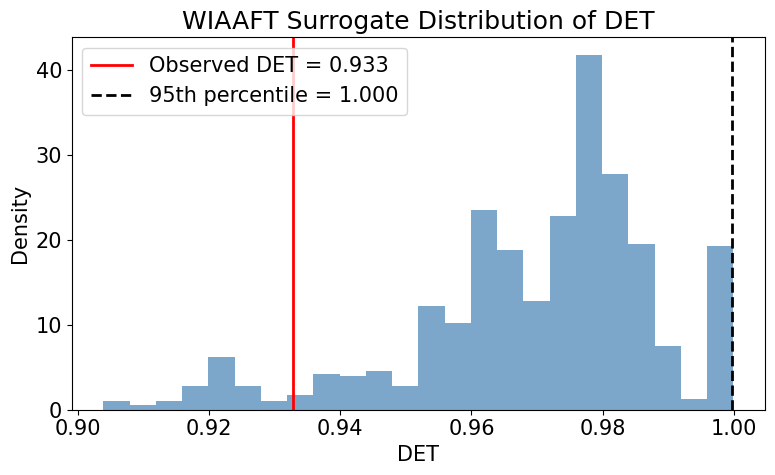

 45%|██████████████████▉                       | 45/100 [10:43<14:38, 15.97s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9328657314582522 
 Recurrence rate: 0.05002267573696145 
Threshold:0.856599999999922 
 Laminarity:0.968268359016463 
Shannon Entropy:2.0745110630329493 
Rank-order p-value (det):0.138 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.37498462206903854
Pseudo-periodic surrogates generated successfullly


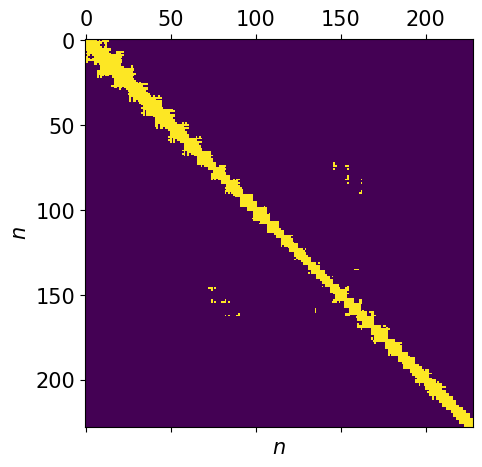

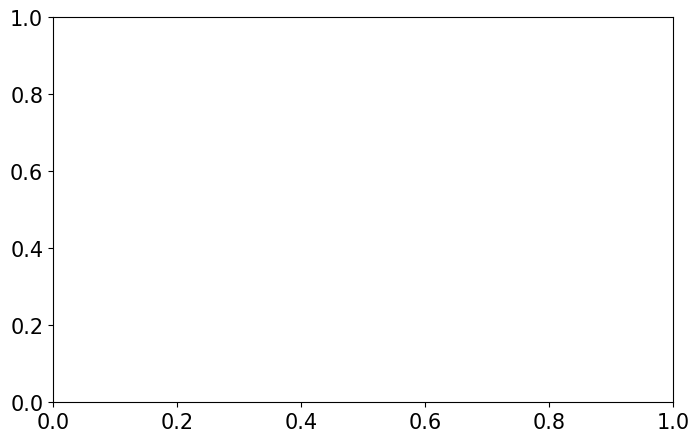

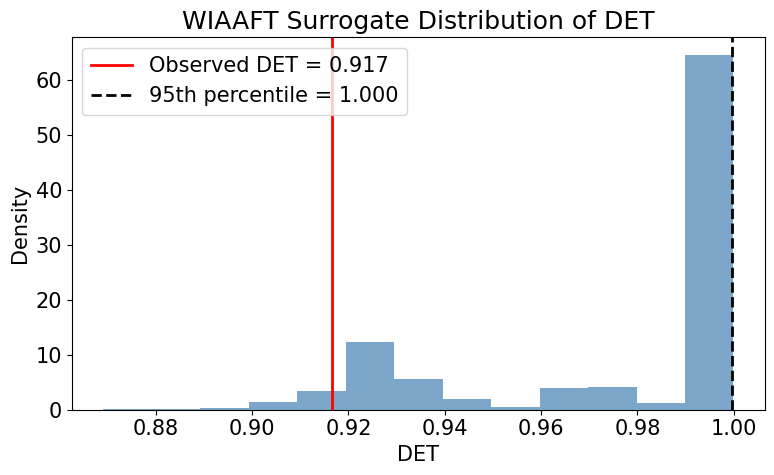

 46%|███████████████████▎                      | 46/100 [10:58<14:16, 15.86s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9165261382760687 
 Recurrence rate: 0.05001538935056941 
Threshold:1.0713999999998984 
 Laminarity:0.9684615384578137 
Shannon Entropy:1.8563979213137285 
Rank-order p-value (det):0.076 
Reject null (det) hypothesis:False

 
 

8
8
Mean Nearest Neighbor Distance: 0.2815230542910712
Pseudo-periodic surrogates generated successfullly


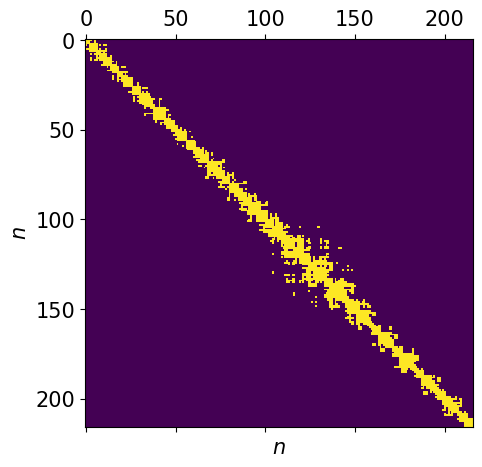

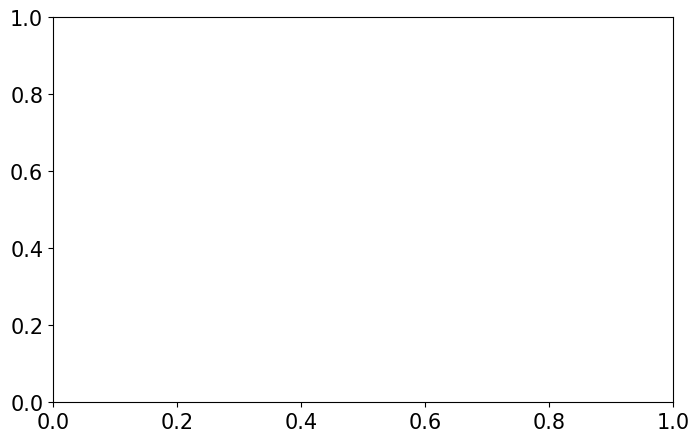

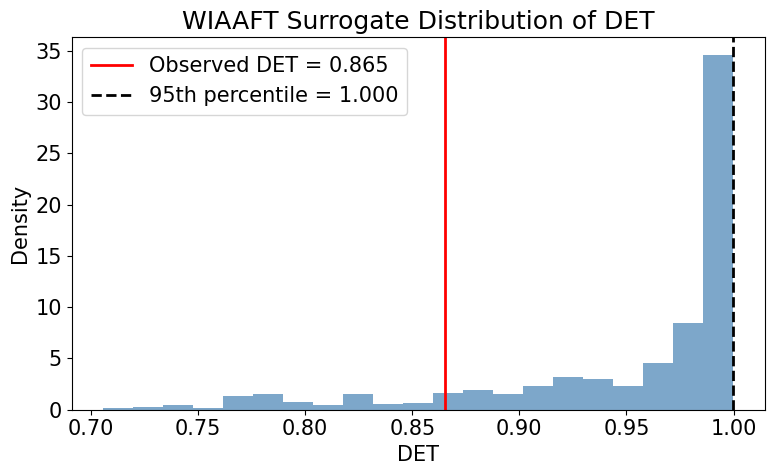

 47%|███████████████████▋                      | 47/100 [11:09<12:46, 14.46s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.865094339618561 
 Recurrence rate: 0.050068587105624146 
Threshold:0.6416999999999456 
 Laminarity:0.9362157534206498 
Shannon Entropy:1.6849687909032758 
Rank-order p-value (det):0.232 
Reject null (det) hypothesis:False

 
 

8
10
Mean Nearest Neighbor Distance: 0.3714968341634244
Pseudo-periodic surrogates generated successfullly


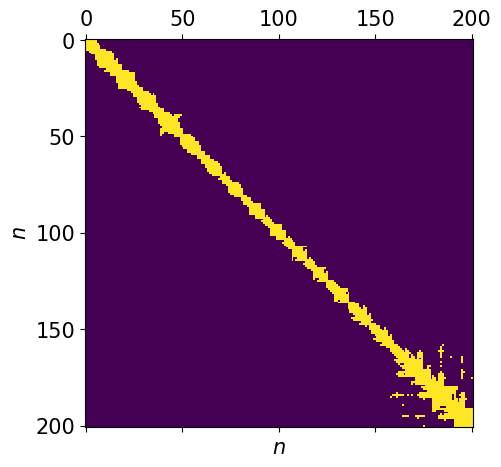

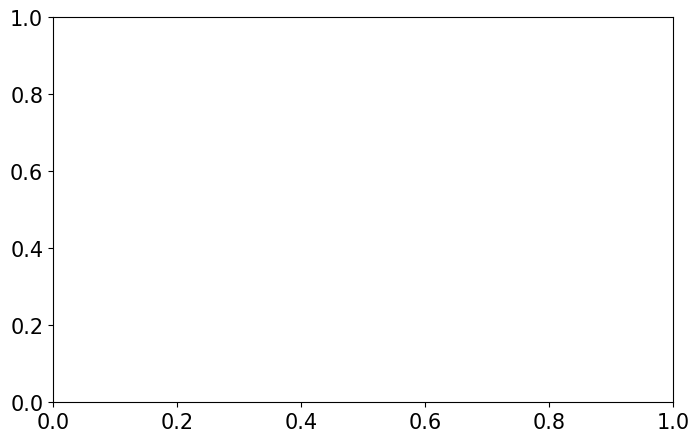

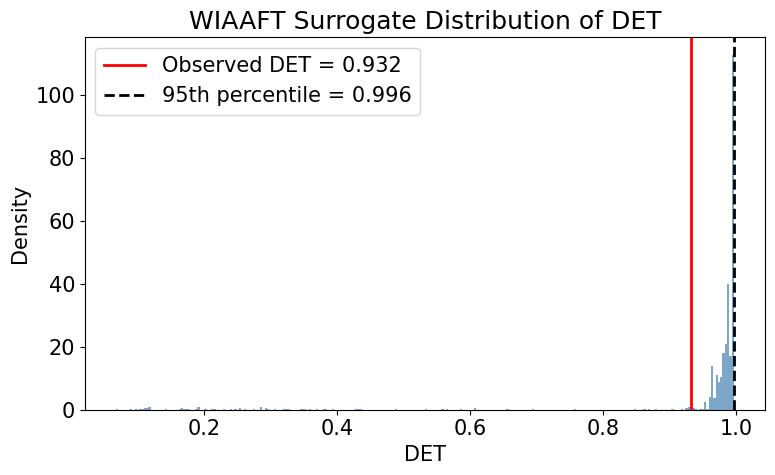

 48%|████████████████████▏                     | 48/100 [11:22<12:03, 13.90s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9318681318630118 
 Recurrence rate: 0.050023514269448774 
Threshold:0.8829999999999191 
 Laminarity:0.9703117268630861 
Shannon Entropy:1.937567927041435 
Rank-order p-value (det):0.154 
Reject null (det) hypothesis:False

 
 

8
9
Mean Nearest Neighbor Distance: 0.44992926214004453
Pseudo-periodic surrogates generated successfullly


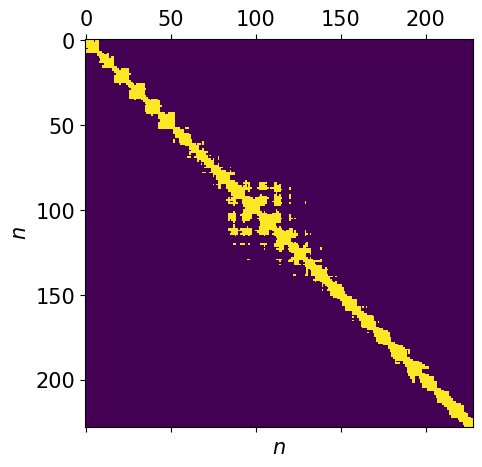

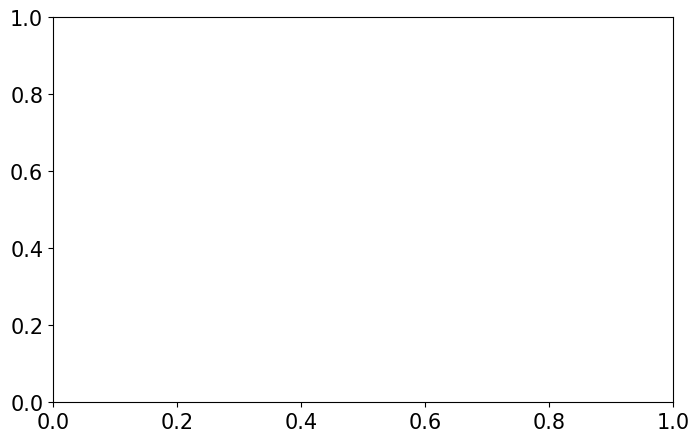

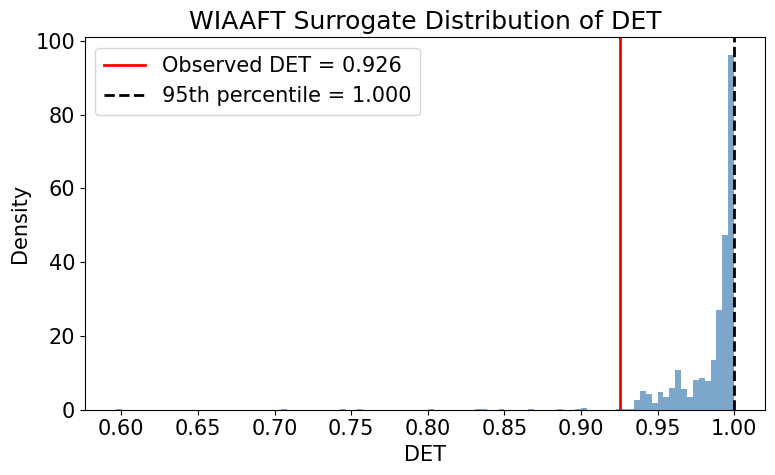

 49%|████████████████████▌                     | 49/100 [11:38<12:28, 14.69s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9258010118004815 
 Recurrence rate: 0.05001538935056941 
Threshold:1.220199999999882 
 Laminarity:0.963076923073219 
Shannon Entropy:1.9415100321928835 
Rank-order p-value (det):0.03 
Reject null (det) hypothesis:True

 
 

9
10
Mean Nearest Neighbor Distance: 0.4424684032932834
Pseudo-periodic surrogates generated successfullly


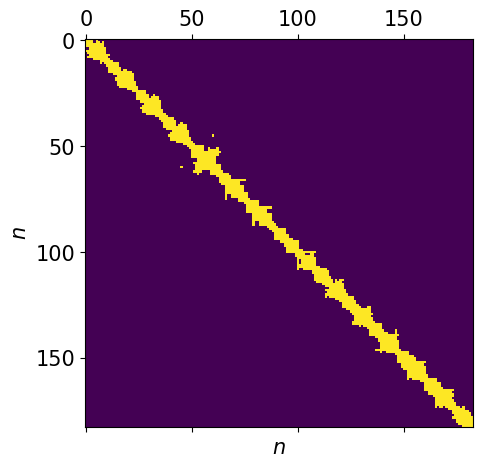

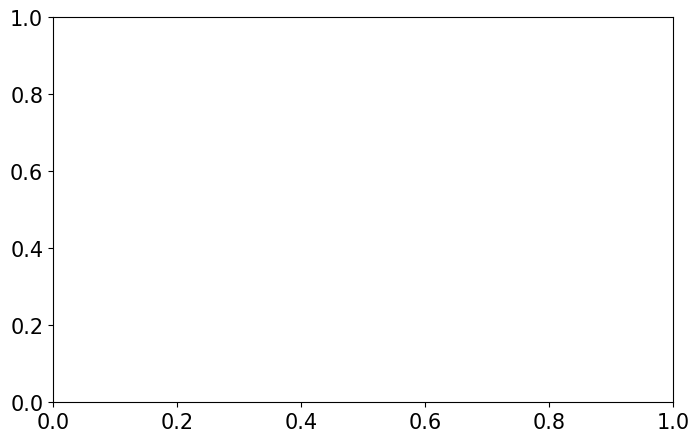

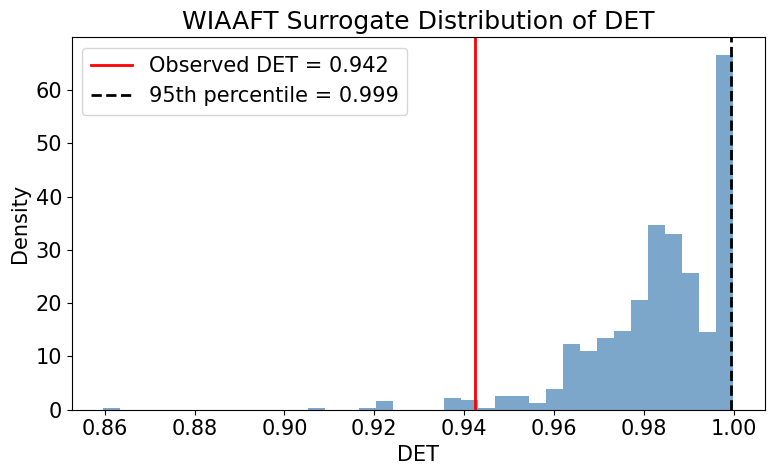

 50%|█████████████████████                     | 50/100 [11:51<11:36, 13.93s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9423592493234427 
 Recurrence rate: 0.05001642330317418 
Threshold:1.0821999999998972 
 Laminarity:0.9838805970090515 
Shannon Entropy:2.079599980048344 
Rank-order p-value (det):0.048 
Reject null (det) hypothesis:True

 
 

10
10
Mean Nearest Neighbor Distance: 0.3669986380887056
Pseudo-periodic surrogates generated successfullly


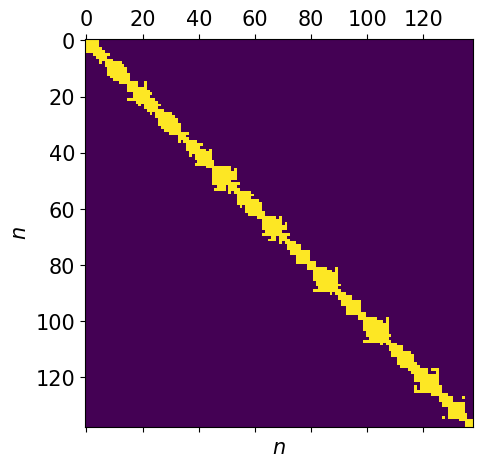

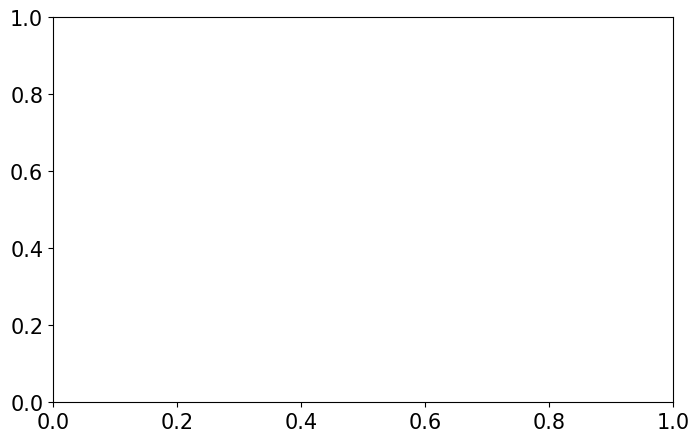

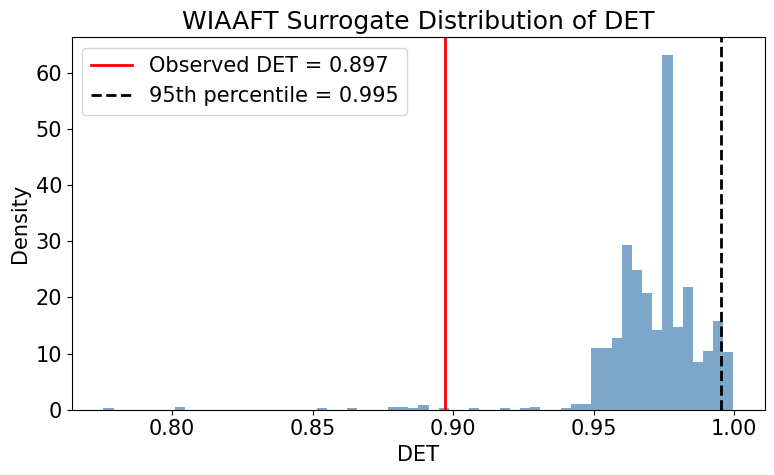

 51%|█████████████████████▍                    | 51/100 [11:59<10:07, 12.40s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8970588235184184 
 Recurrence rate: 0.0500945179584121 
Threshold:0.7641999999999322 
 Laminarity:0.9737945492560399 
Shannon Entropy:1.9233305352643253 
Rank-order p-value (det):0.03 
Reject null (det) hypothesis:True

 
 

11
8
Mean Nearest Neighbor Distance: 0.2169784925859177
Pseudo-periodic surrogates generated successfullly


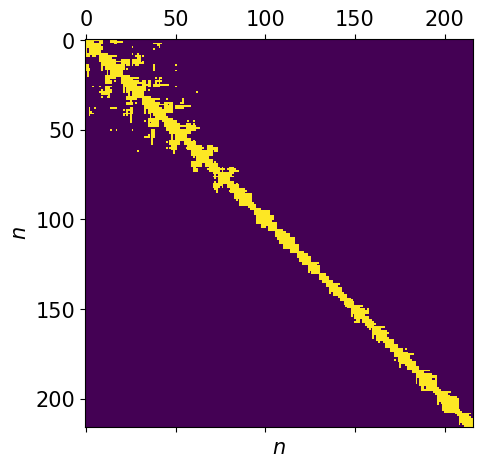

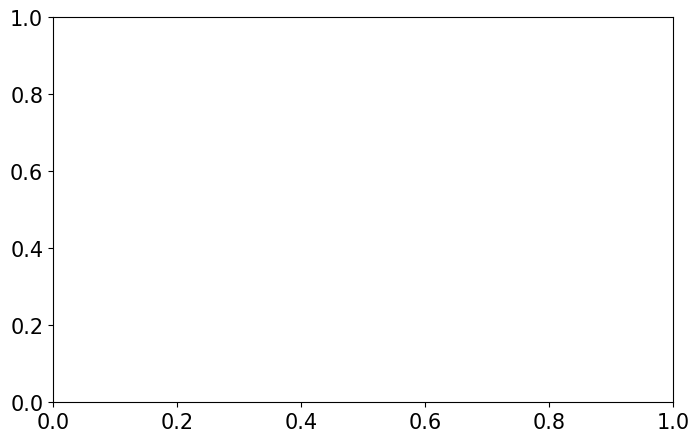

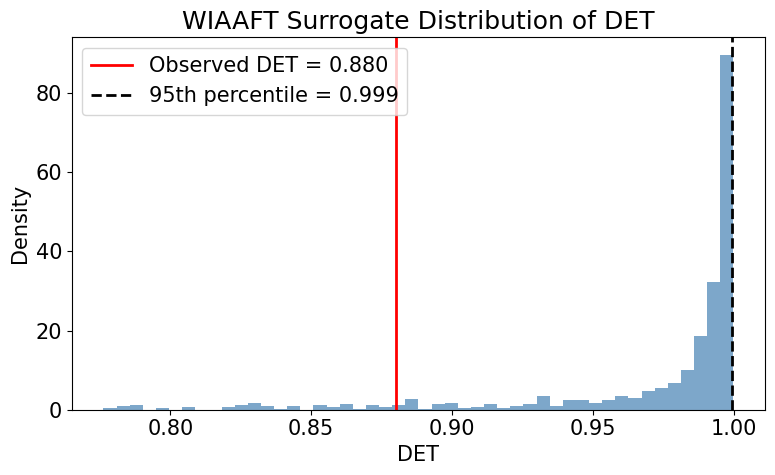

 52%|█████████████████████▊                    | 52/100 [12:09<09:19, 11.67s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.8801886792411312 
 Recurrence rate: 0.050068587105624146 
Threshold:0.5543999999999553 
 Laminarity:0.9477739725986826 
Shannon Entropy:1.8329866222198004 
Rank-order p-value (det):0.136 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.5115708008833401
Pseudo-periodic surrogates generated successfullly


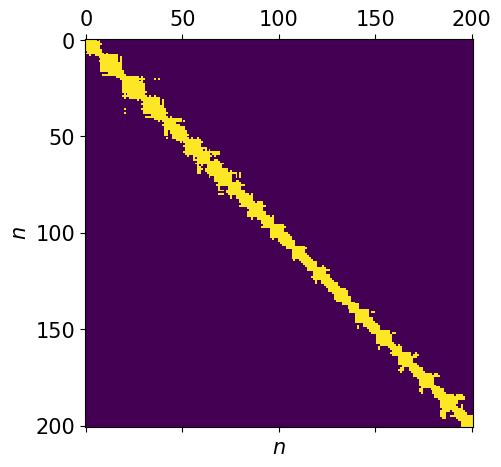

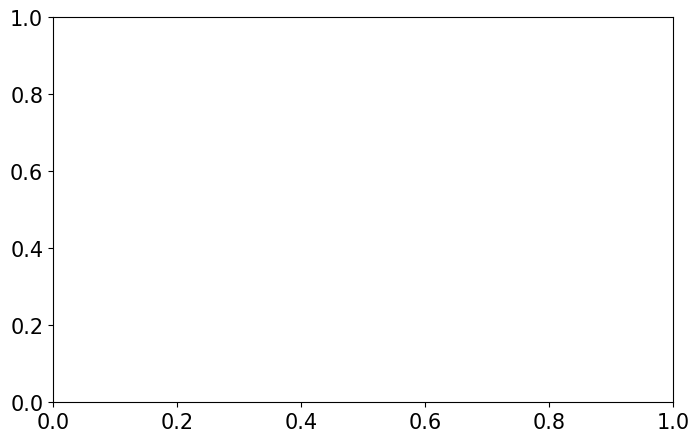

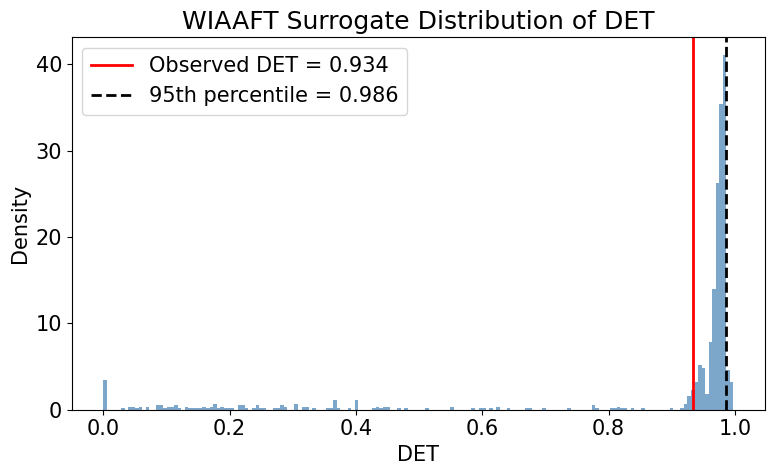

 53%|██████████████████████▎                   | 53/100 [12:25<09:58, 12.73s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9340659340608019 
 Recurrence rate: 0.050023514269448774 
Threshold:1.4048999999998617 
 Laminarity:0.9683325086542883 
Shannon Entropy:1.8699748550654818 
Rank-order p-value (det):0.334 
Reject null (det) hypothesis:False

 
 

11
10
Mean Nearest Neighbor Distance: 0.2104560130994568
Pseudo-periodic surrogates generated successfullly


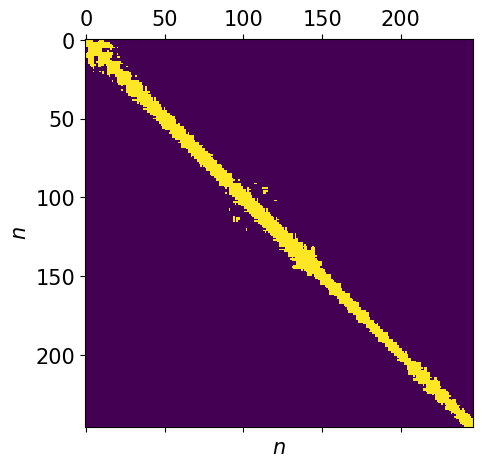

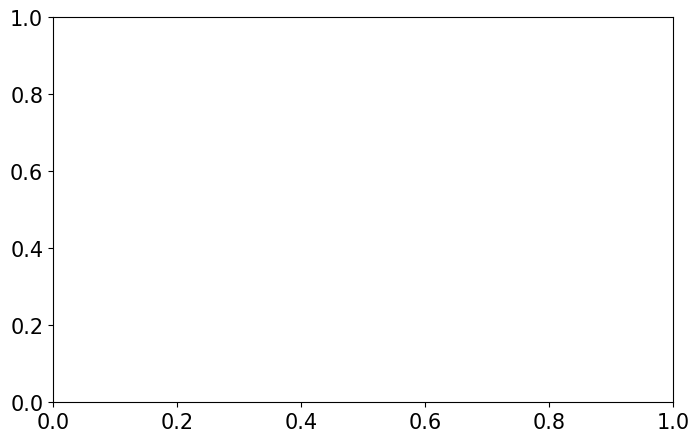

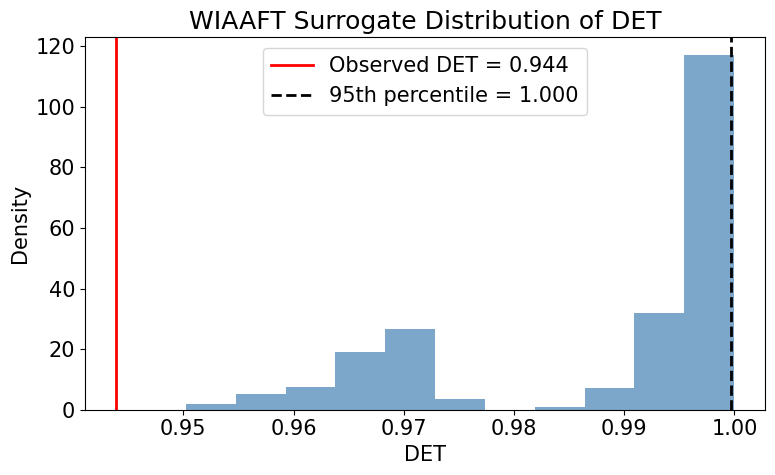

 54%|██████████████████████▋                   | 54/100 [12:37<09:42, 12.66s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9438848920829357 
 Recurrence rate: 0.05000330491109789 
Threshold:0.6080999999999493 
 Laminarity:0.9781890284171243 
Shannon Entropy:1.980203686046688 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

12
10
Mean Nearest Neighbor Distance: 0.5047005991019529
Pseudo-periodic surrogates generated successfullly


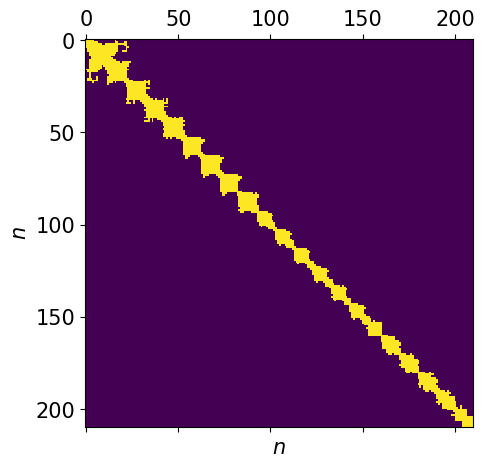

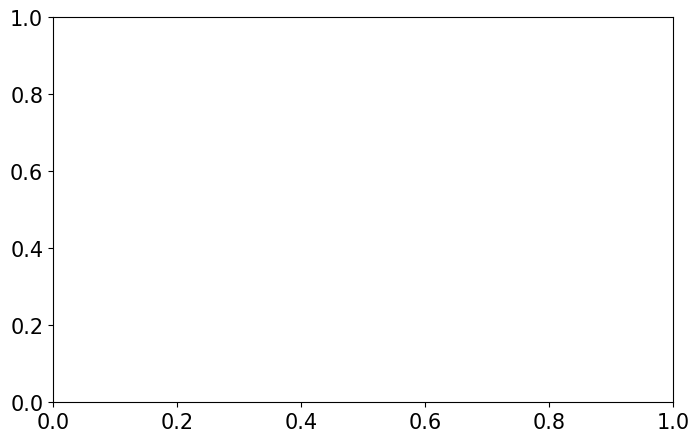

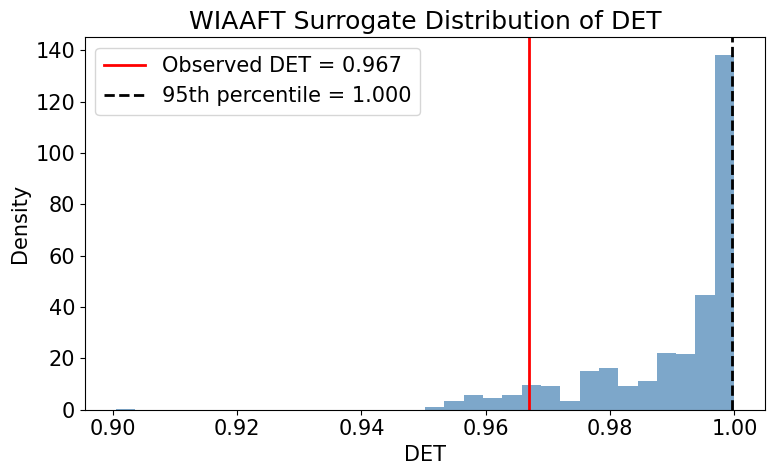

 55%|███████████████████████                   | 55/100 [12:52<09:57, 13.27s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9669338677306266 
 Recurrence rate: 0.05002267573696145 
Threshold:1.1977999999998845 
 Laminarity:0.9800543970943788 
Shannon Entropy:2.150240685349436 
Rank-order p-value (det):0.132 
Reject null (det) hypothesis:False

 
 

12
9
Mean Nearest Neighbor Distance: 0.40901422434306667
Pseudo-periodic surrogates generated successfullly


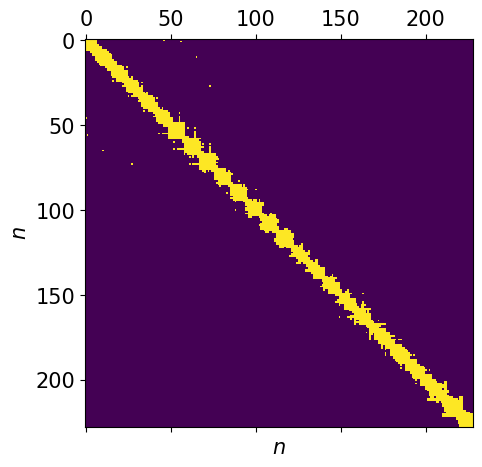

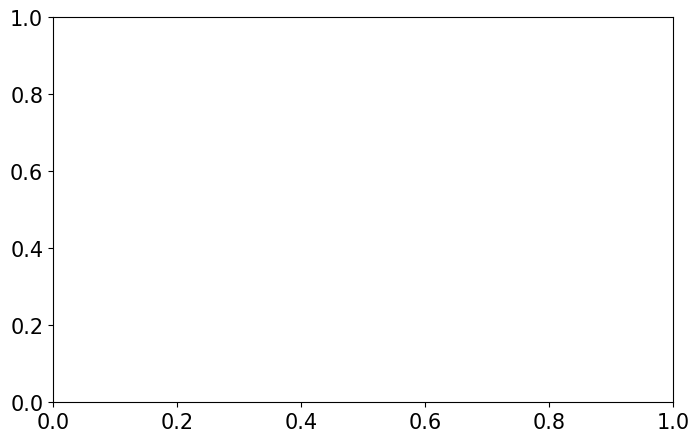

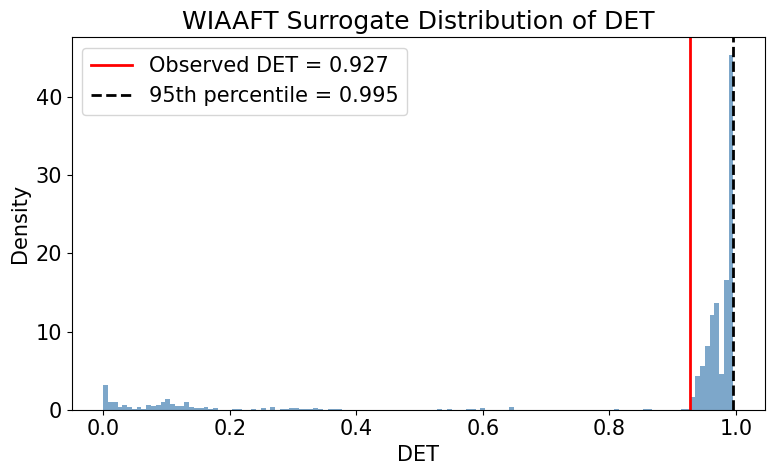

 56%|███████████████████████▌                  | 56/100 [13:07<10:09, 13.86s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.9274873524412838 
 Recurrence rate: 0.05001538935056941 
Threshold:1.1348999999998914 
 Laminarity:0.9661538461501302 
Shannon Entropy:2.0744658794079593 
Rank-order p-value (det):0.314 
Reject null (det) hypothesis:False

 
 

12
10
Mean Nearest Neighbor Distance: 0.390638146368336
Pseudo-periodic surrogates generated successfullly


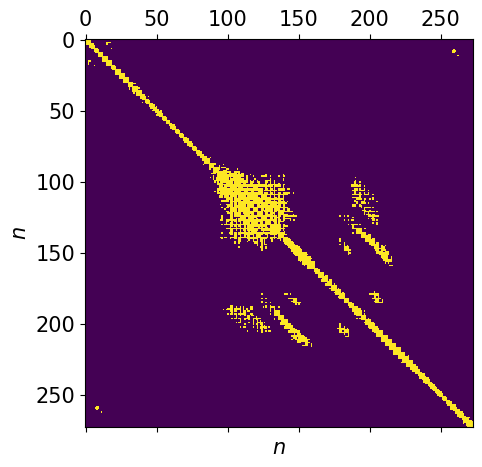

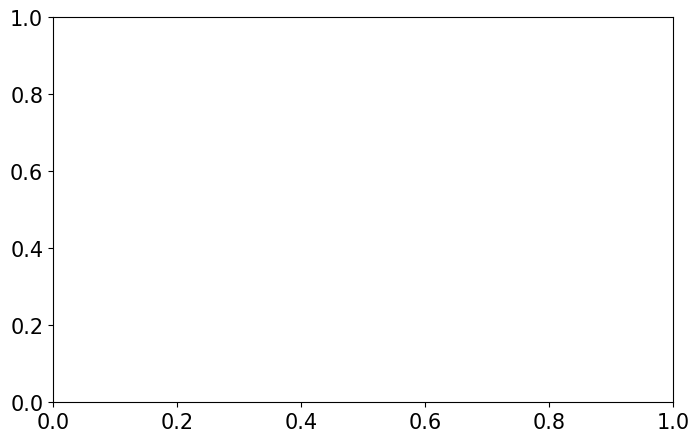

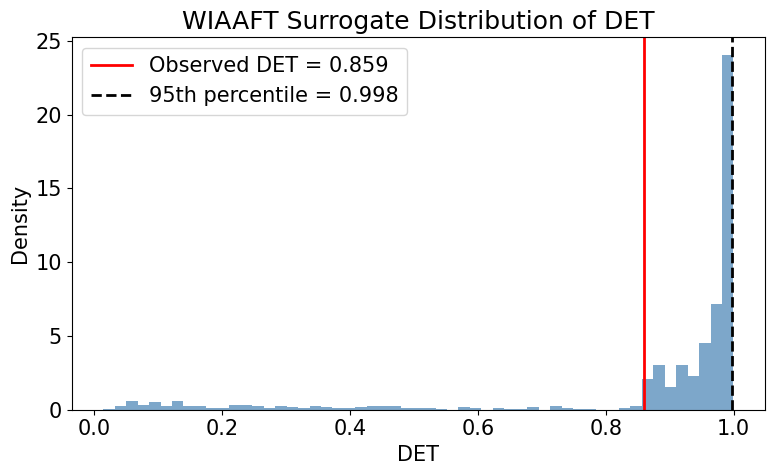

 57%|███████████████████████▉                  | 57/100 [13:22<10:11, 14.22s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.859293572666881 
 Recurrence rate: 0.050007379677709345 
Threshold:0.7625999999999323 
 Laminarity:0.9205795545990862 
Shannon Entropy:1.145712308178057 
Rank-order p-value (det):0.31 
Reject null (det) hypothesis:False

 
 

12
10
Mean Nearest Neighbor Distance: 0.54808372344549
Pseudo-periodic surrogates generated successfullly


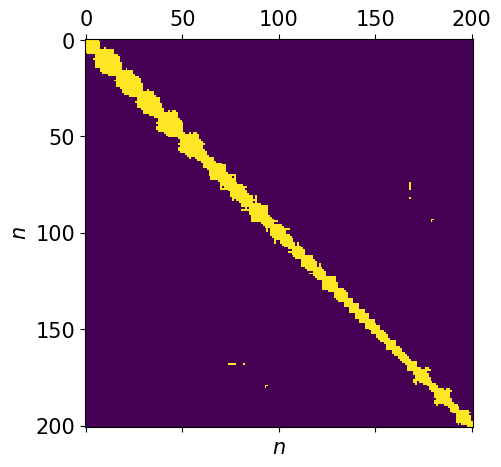

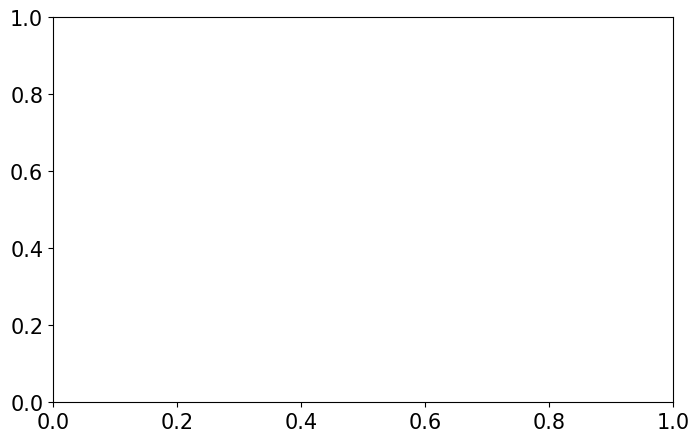

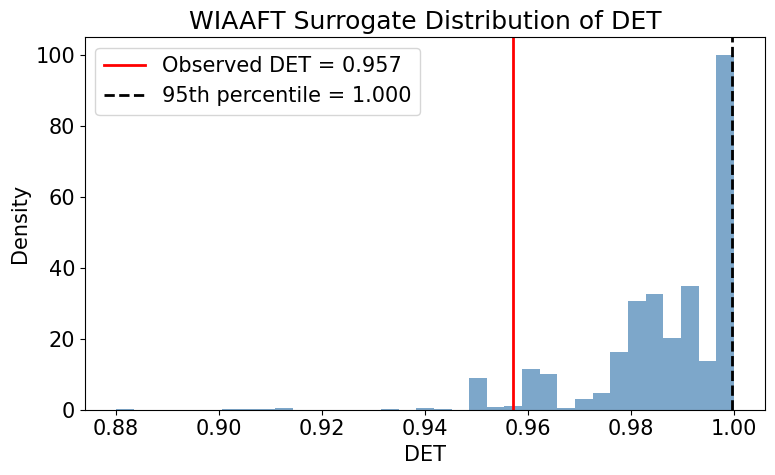

 58%|████████████████████████▎                 | 58/100 [13:40<10:37, 15.18s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9571428571375982 
 Recurrence rate: 0.050023514269448774 
Threshold:1.529599999999848 
 Laminarity:0.9841662543246702 
Shannon Entropy:2.1283378525903136 
Rank-order p-value (det):0.094 
Reject null (det) hypothesis:False

 
 

12
10
Mean Nearest Neighbor Distance: 0.40769598877537
Pseudo-periodic surrogates generated successfullly


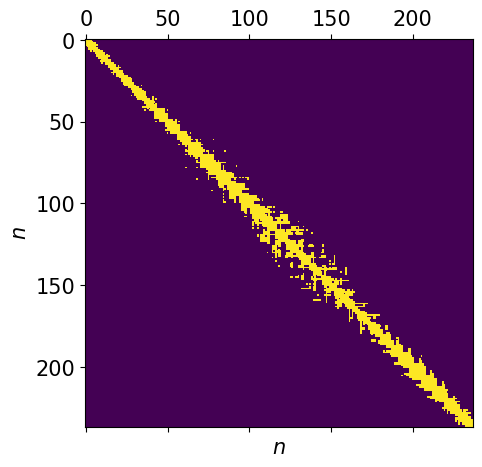

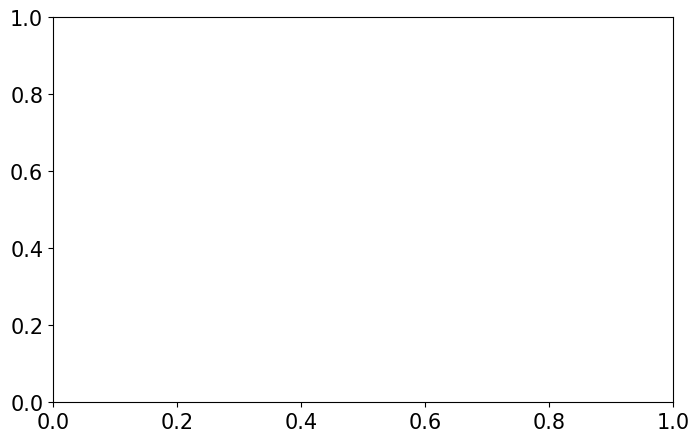

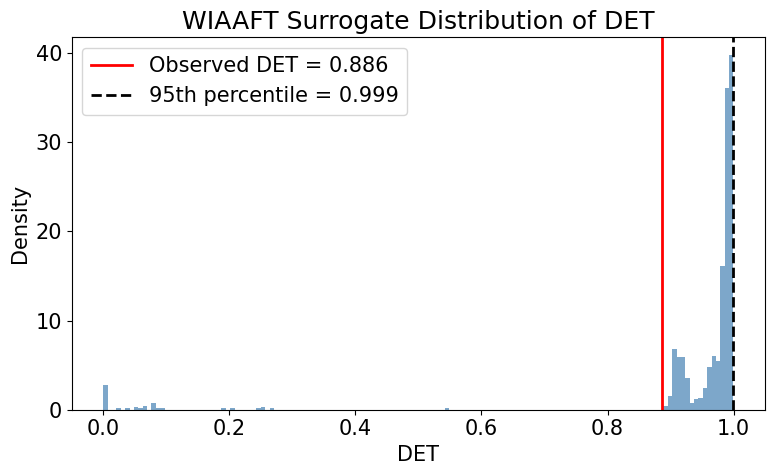

 59%|████████████████████████▊                 | 59/100 [13:53<09:57, 14.57s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8856920684257944 
 Recurrence rate: 0.050009791878082216 
Threshold:0.883599999999919 
 Laminarity:0.9391242434996827 
Shannon Entropy:1.7895458689057162 
Rank-order p-value (det):0.084 
Reject null (det) hypothesis:False

 
 

12
10
Mean Nearest Neighbor Distance: 0.7541962433344861
Pseudo-periodic surrogates generated successfullly


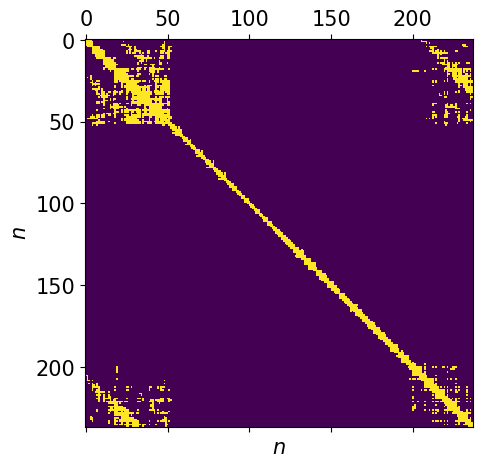

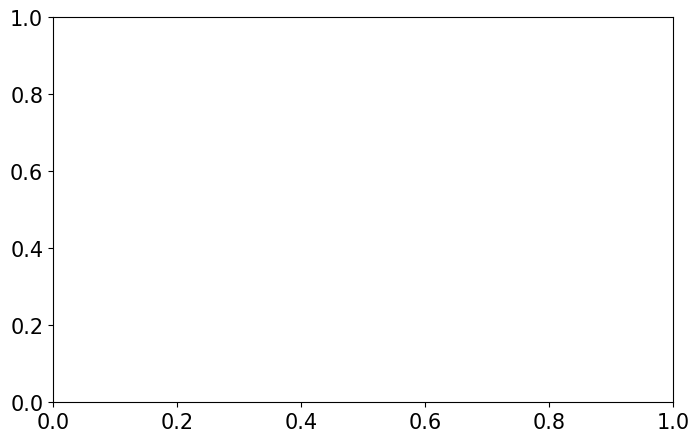

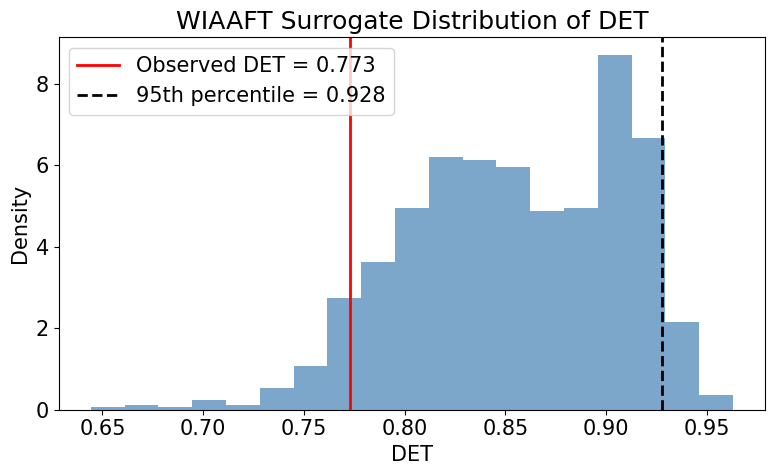

 60%|█████████████████████████▏                | 60/100 [14:11<10:28, 15.71s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.7731157731127696 
 Recurrence rate: 0.05004539870747209 
Threshold:1.3906999999998633 
 Laminarity:0.8712202063291669 
Shannon Entropy:1.3624714714883677 
Rank-order p-value (det):0.124 
Reject null (det) hypothesis:False

 
 

12
10
Mean Nearest Neighbor Distance: 0.47862052630325397
Pseudo-periodic surrogates generated successfullly


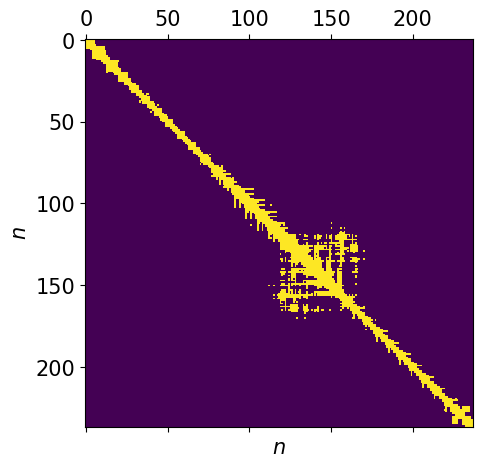

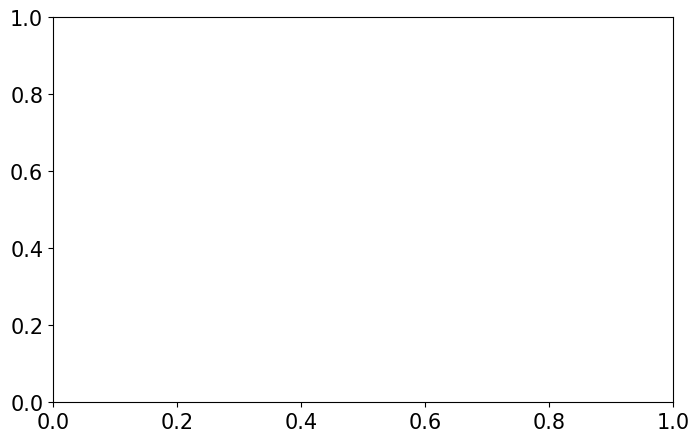

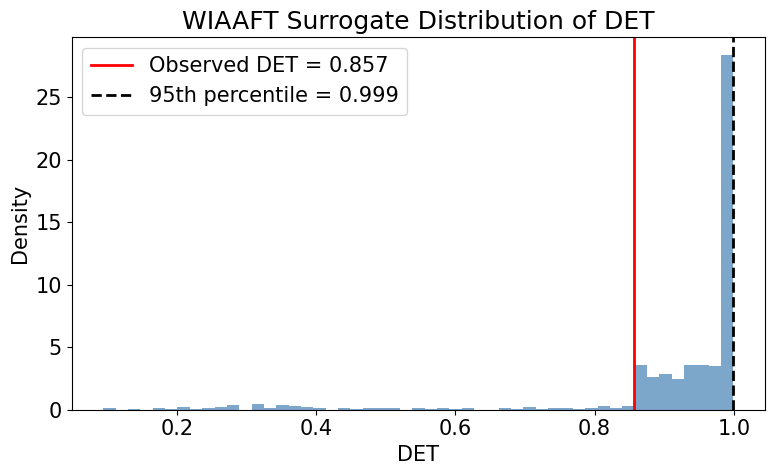

 61%|█████████████████████████▌                | 61/100 [14:27<10:13, 15.72s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8569206842890478 
 Recurrence rate: 0.050009791878082216 
Threshold:1.075299999999898 
 Laminarity:0.927732289067541 
Shannon Entropy:1.5992201366306193 
Rank-order p-value (det):0.202 
Reject null (det) hypothesis:False

 
 

12
10
Mean Nearest Neighbor Distance: 0.289265742872325
Pseudo-periodic surrogates generated successfullly


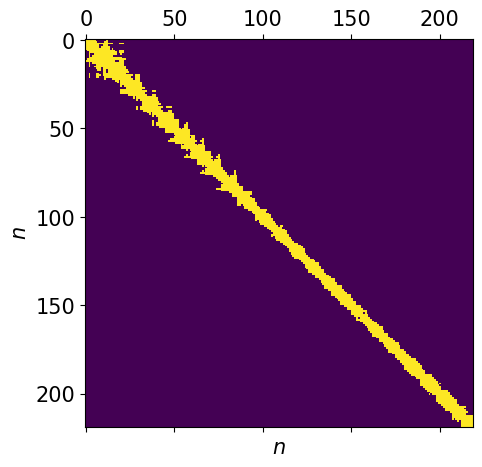

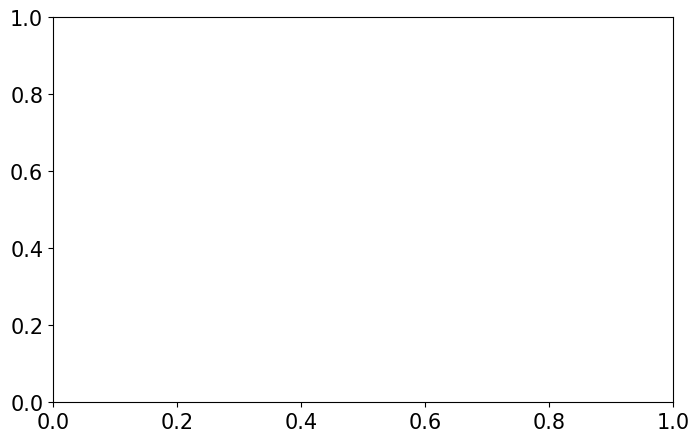

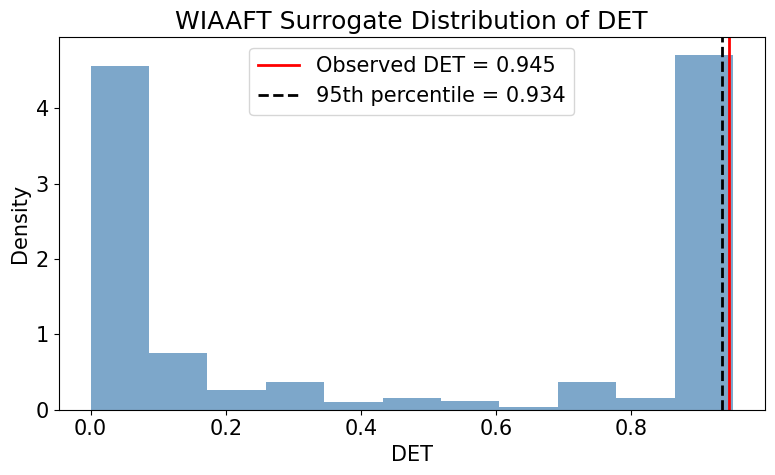

 62%|██████████████████████████                | 62/100 [14:38<09:04, 14.33s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9449541284360323 
 Recurrence rate: 0.05001980776047205 
Threshold:0.6986999999999394 
 Laminarity:0.9812421842393446 
Shannon Entropy:2.090282072633403 
Rank-order p-value (det):0.01 
Reject null (det) hypothesis:True

 
 

13
9
Mean Nearest Neighbor Distance: 0.4044183442466072
Pseudo-periodic surrogates generated successfullly


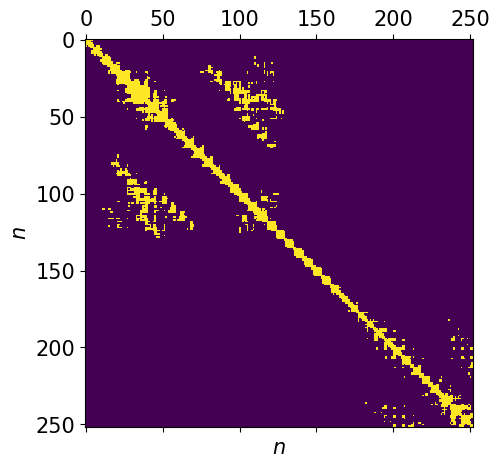

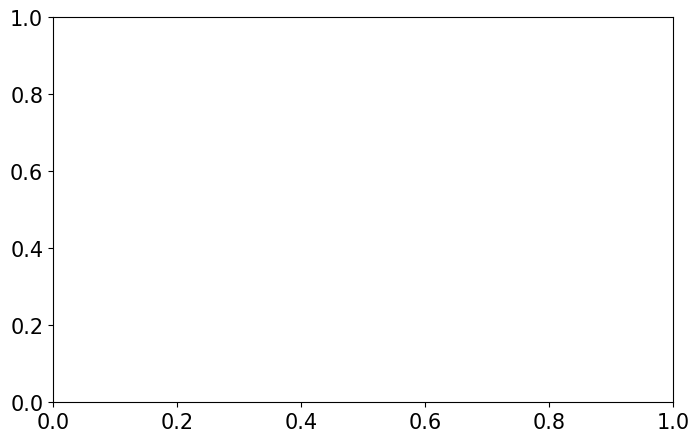

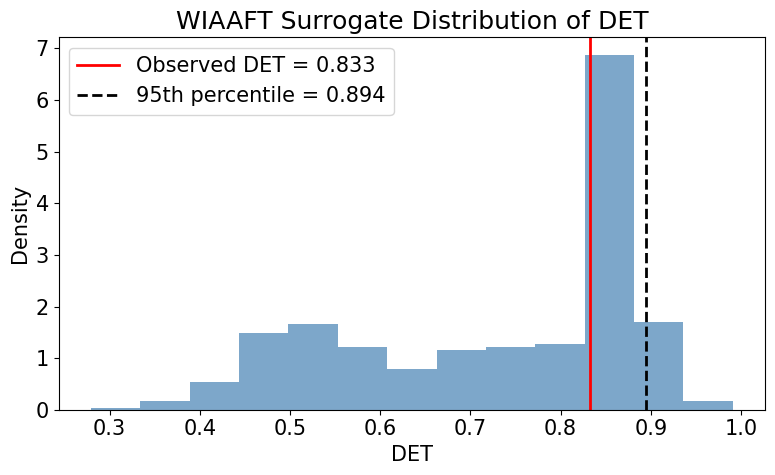

 63%|██████████████████████████▍               | 63/100 [14:52<08:48, 14.27s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.8331053351544696 
 Recurrence rate: 0.05001259763164525 
Threshold:0.8970999999999175 
 Laminarity:0.9190806045311113 
Shannon Entropy:1.42481640626247 
Rank-order p-value (det):0.914 
Reject null (det) hypothesis:False

 
 

13
10
Mean Nearest Neighbor Distance: 0.4202407607379631
Pseudo-periodic surrogates generated successfullly


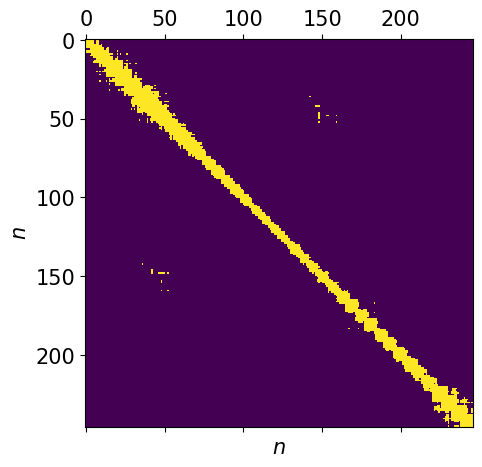

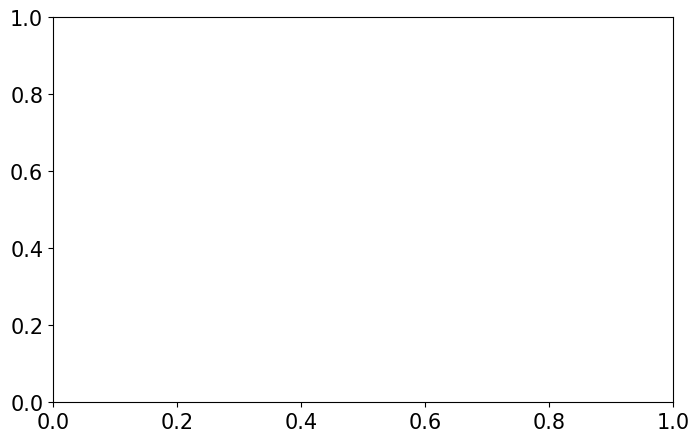

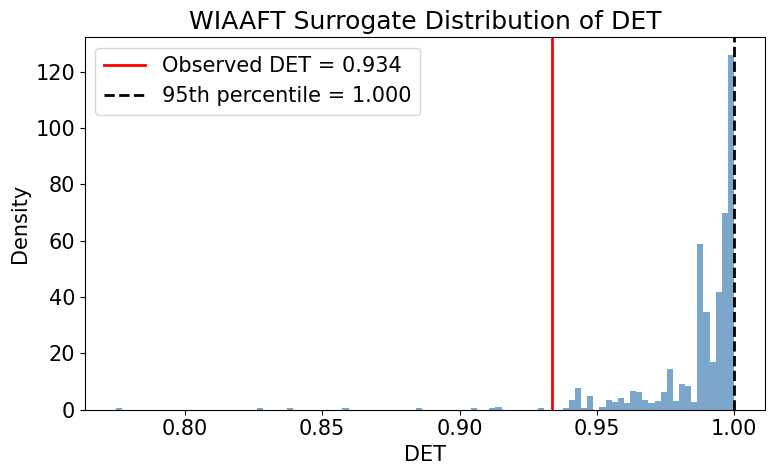

 64%|██████████████████████████▉               | 64/100 [15:08<08:55, 14.87s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9338129496369287 
 Recurrence rate: 0.05000330491109789 
Threshold:1.0906999999998963 
 Laminarity:0.9709187045572674 
Shannon Entropy:1.81708533169435 
Rank-order p-value (det):0.022 
Reject null (det) hypothesis:True

 
 

14
6
Mean Nearest Neighbor Distance: 0.3816059323885122
Pseudo-periodic surrogates generated successfullly


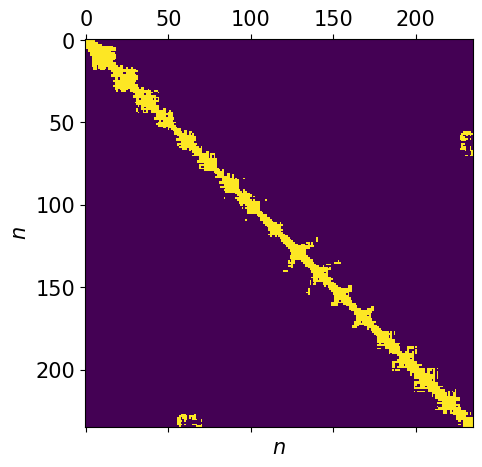

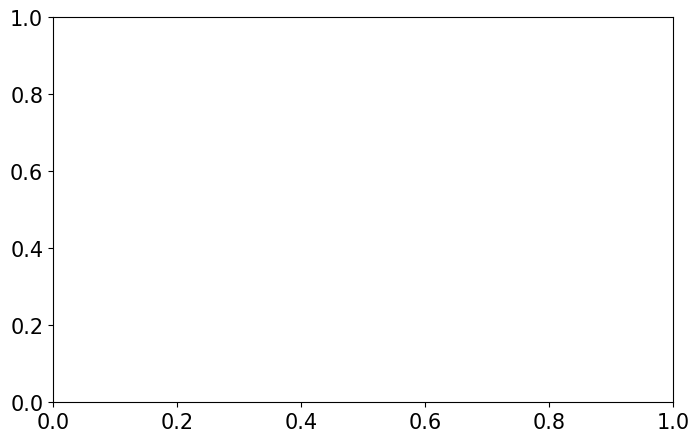

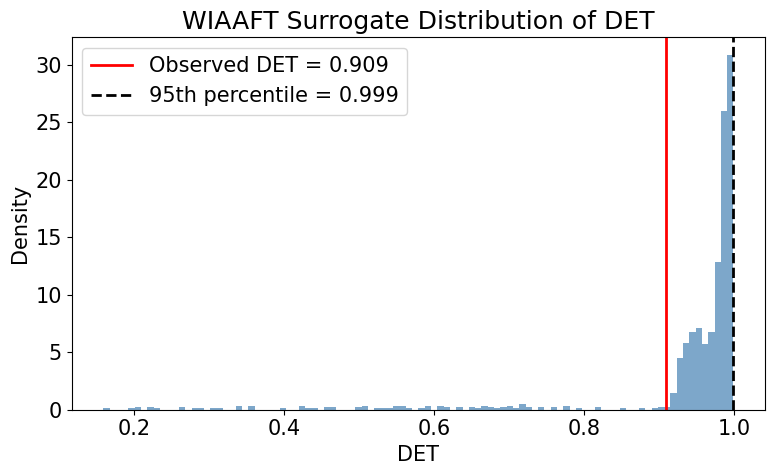

 65%|███████████████████████████▎              | 65/100 [15:23<08:36, 14.75s/it]

RQA  ar1 Embedding dimensions:6 
 DET of original:0.9090189873381764 
 Recurrence rate: 0.05003168854685378 
Threshold:1.012299999999905 
 Laminarity:0.9551212450200683 
Shannon Entropy:1.9784586750517648 
Rank-order p-value (det):0.186 
Reject null (det) hypothesis:False

 
 

14
10
Mean Nearest Neighbor Distance: 0.24629913661235037
Pseudo-periodic surrogates generated successfullly


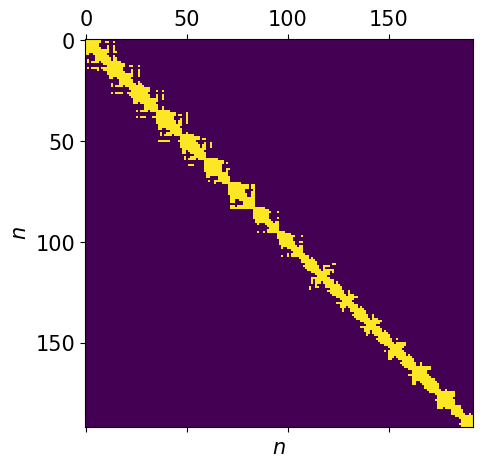

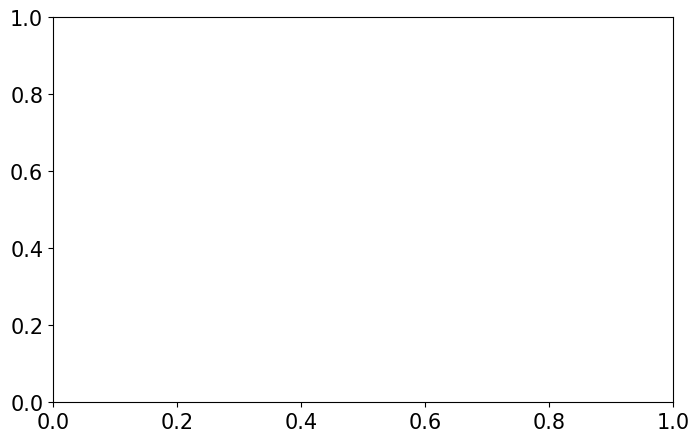

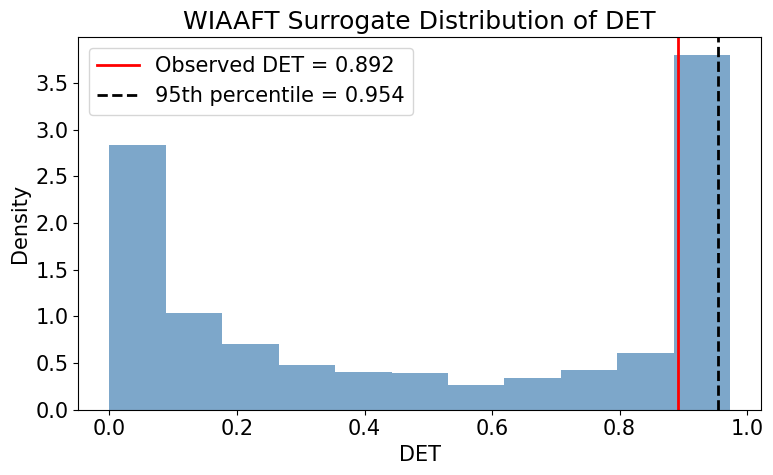

 66%|███████████████████████████▋              | 66/100 [15:33<07:34, 13.36s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8922518159752285 
 Recurrence rate: 0.05002170138888889 
Threshold:0.6050999999999497 
 Laminarity:0.9517353579124093 
Shannon Entropy:1.7362113198262 
Rank-order p-value (det):0.64 
Reject null (det) hypothesis:False

 
 

14
10
Mean Nearest Neighbor Distance: 0.4148780742543773
Pseudo-periodic surrogates generated successfullly


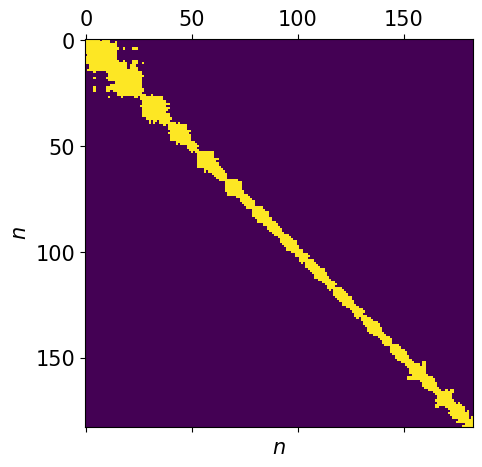

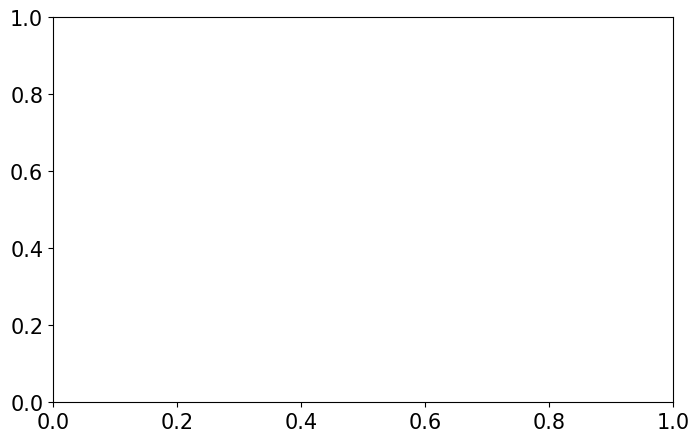

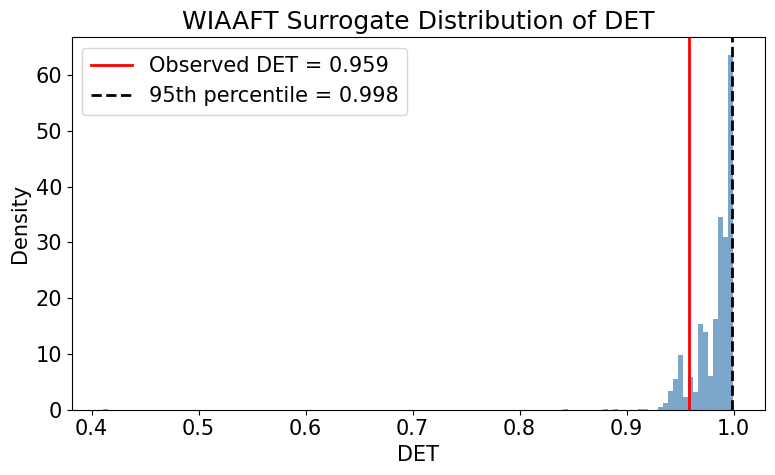

 67%|████████████████████████████▏             | 67/100 [15:45<07:09, 13.01s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9585006693376272 
 Recurrence rate: 0.05007614440562573 
Threshold:1.0051999999999057 
 Laminarity:0.9838998211032565 
Shannon Entropy:2.3872699809756917 
Rank-order p-value (det):0.256 
Reject null (det) hypothesis:False

 
 

14
10
Mean Nearest Neighbor Distance: 0.4564414872723651
Pseudo-periodic surrogates generated successfullly


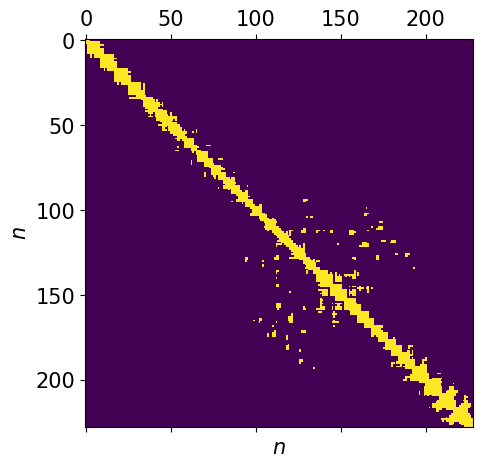

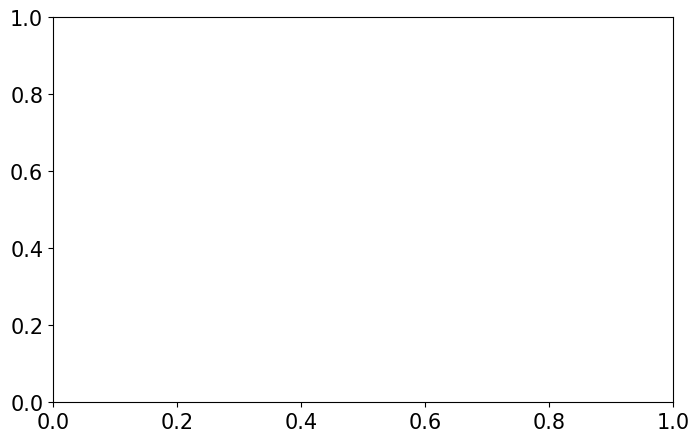

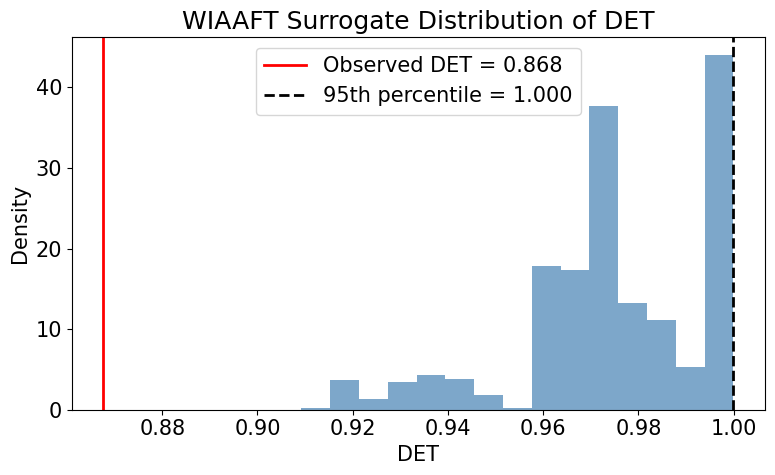

 68%|████████████████████████████▌             | 68/100 [16:01<07:23, 13.87s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8676222596928009 
 Recurrence rate: 0.05001538935056941 
Threshold:1.2010999999998841 
 Laminarity:0.9473076923040489 
Shannon Entropy:1.6438112338494943 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

15
10
Mean Nearest Neighbor Distance: 0.2917931456336193
Pseudo-periodic surrogates generated successfullly


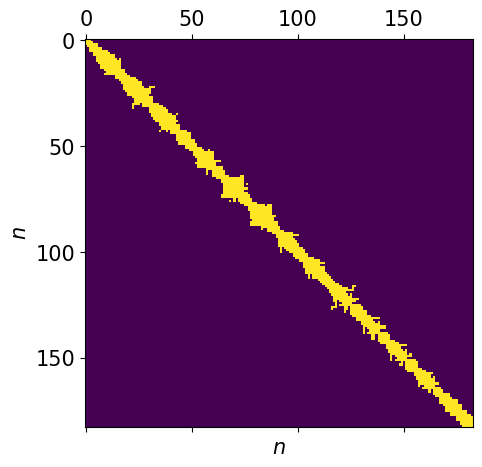

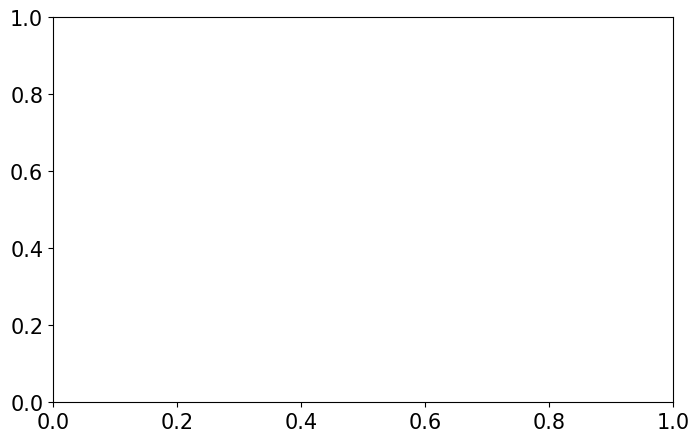

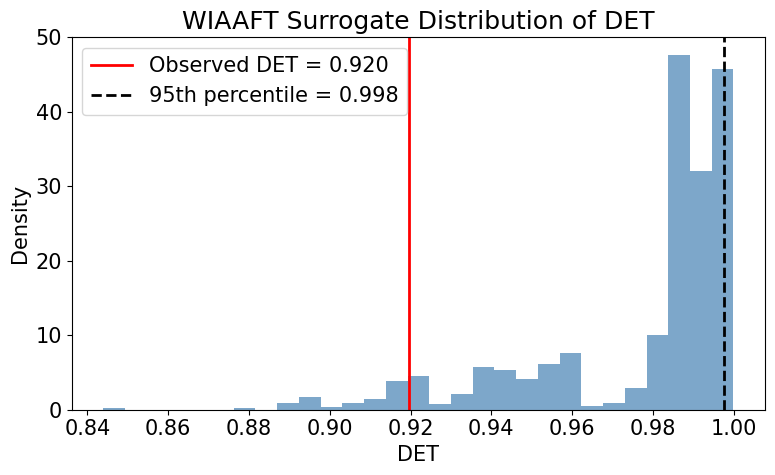

 69%|████████████████████████████▉             | 69/100 [16:11<06:37, 12.81s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9195710455702443 
 Recurrence rate: 0.05001642330317418 
Threshold:0.6856999999999408 
 Laminarity:0.9767164179046167 
Shannon Entropy:2.1586012113623196 
Rank-order p-value (det):0.11 
Reject null (det) hypothesis:False

 
 

15
8
Mean Nearest Neighbor Distance: 0.27741745549997004
Pseudo-periodic surrogates generated successfullly


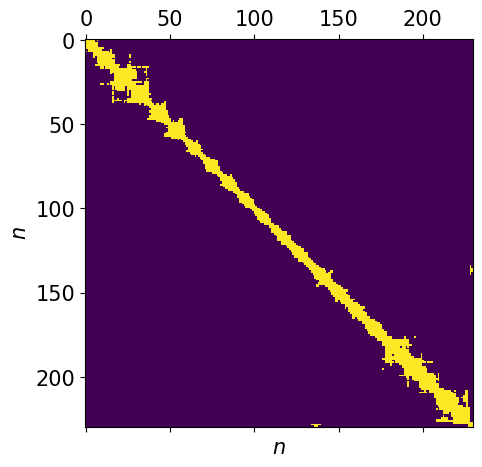

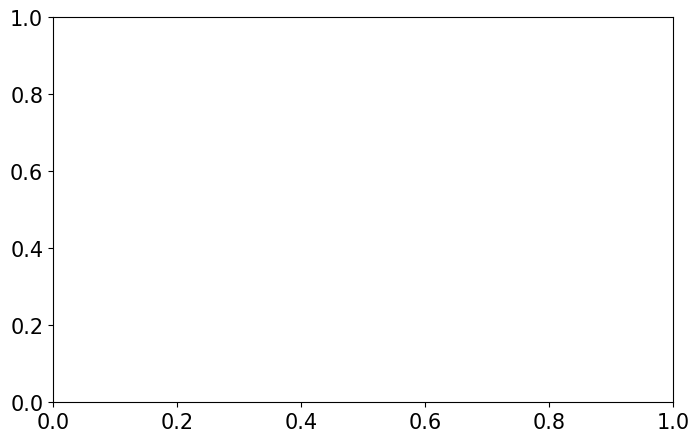

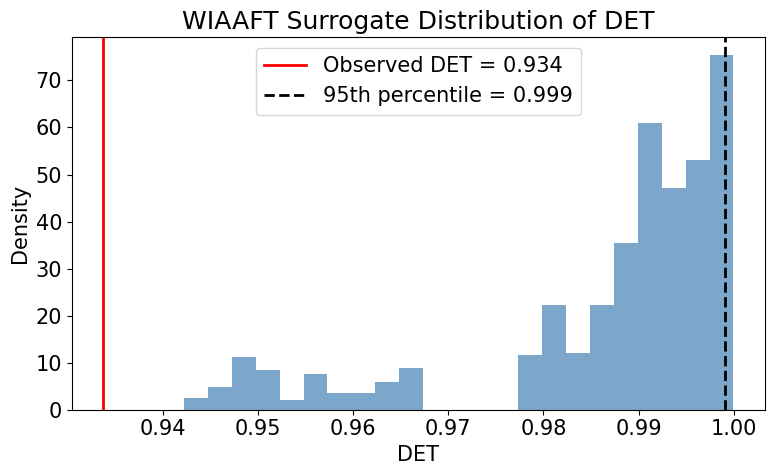

 70%|█████████████████████████████▍            | 70/100 [16:24<06:24, 12.81s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9337748344332212 
 Recurrence rate: 0.05001890359168242 
Threshold:0.765799999999932 
 Laminarity:0.9750566893387187 
Shannon Entropy:2.2085444816322406 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

16
10
Mean Nearest Neighbor Distance: 0.30462777365897387
Pseudo-periodic surrogates generated successfullly


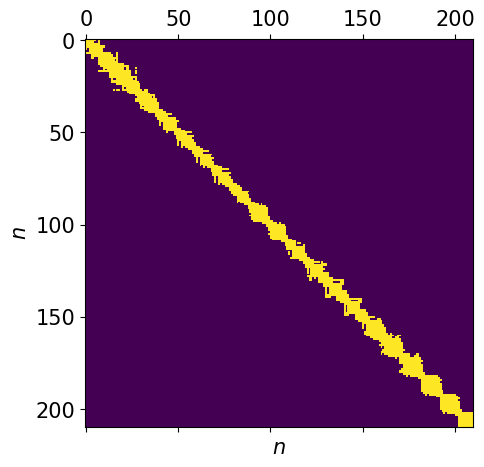

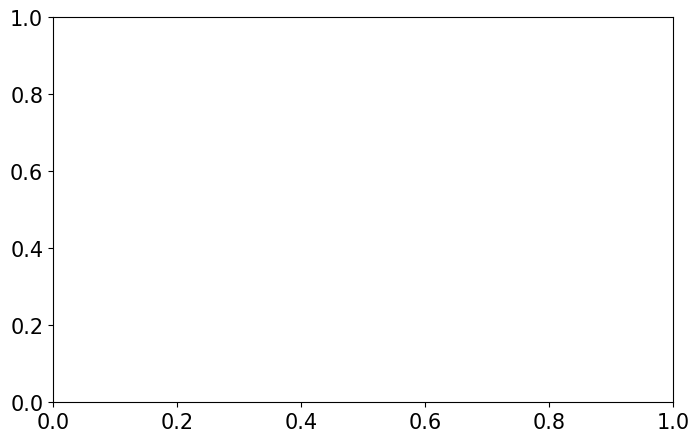

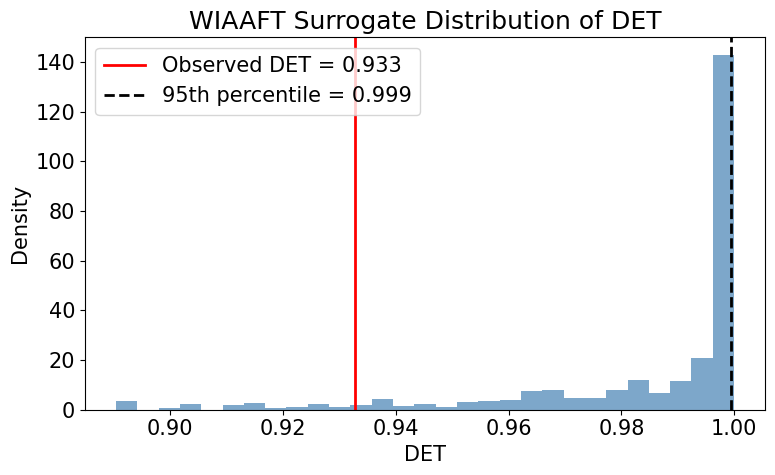

 71%|█████████████████████████████▊            | 71/100 [16:36<06:05, 12.61s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9328657314582522 
 Recurrence rate: 0.05002267573696145 
Threshold:0.7945999999999288 
 Laminarity:0.9714415231143634 
Shannon Entropy:1.9937910430772237 
Rank-order p-value (det):0.14 
Reject null (det) hypothesis:False

 
 

16
10
Mean Nearest Neighbor Distance: 0.3244191432636809
Pseudo-periodic surrogates generated successfullly


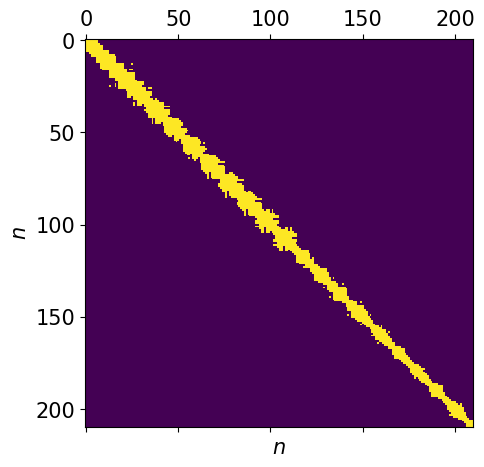

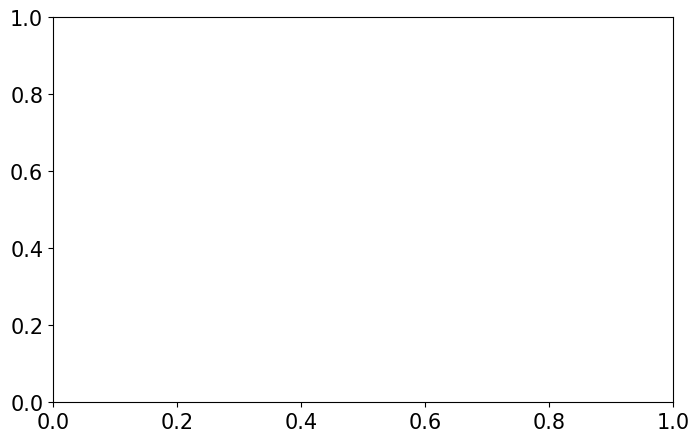

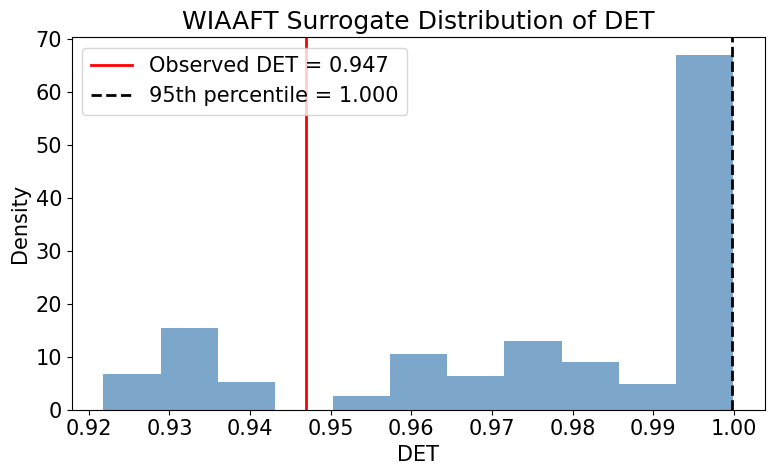

 72%|██████████████████████████████▏           | 72/100 [16:48<05:47, 12.41s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9468937875704064 
 Recurrence rate: 0.05002267573696145 
Threshold:0.7857999999999298 
 Laminarity:0.9814143245649075 
Shannon Entropy:2.192573770821791 
Rank-order p-value (det):0.392 
Reject null (det) hypothesis:False

 
 

16
10
Mean Nearest Neighbor Distance: 0.7523958319128401
Pseudo-periodic surrogates generated successfullly


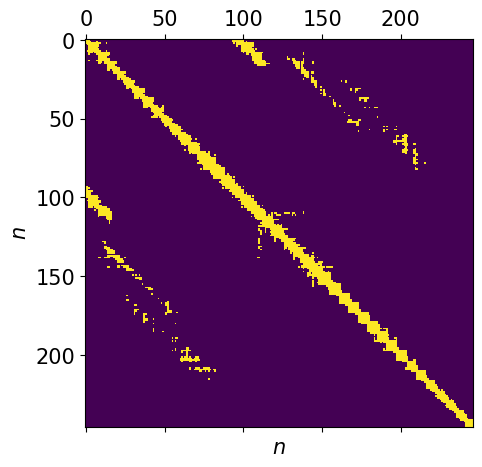

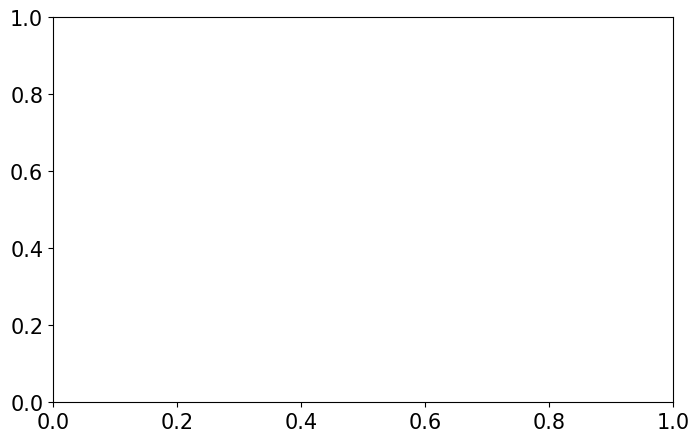

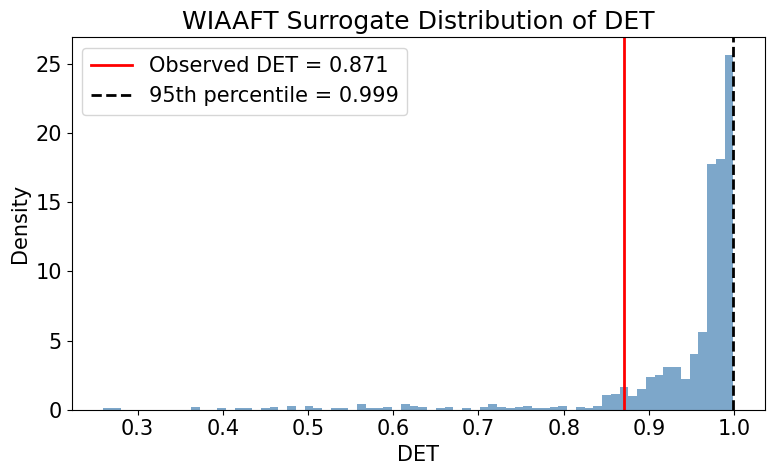

 73%|██████████████████████████████▋           | 73/100 [17:11<06:56, 15.44s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8705035971191709 
 Recurrence rate: 0.05000330491109789 
Threshold:1.7899999999998193 
 Laminarity:0.9388631857206251 
Shannon Entropy:1.6152332535320357 
Rank-order p-value (det):0.194 
Reject null (det) hypothesis:False

 
 

16
10
Mean Nearest Neighbor Distance: 0.3819383275536238
Pseudo-periodic surrogates generated successfullly


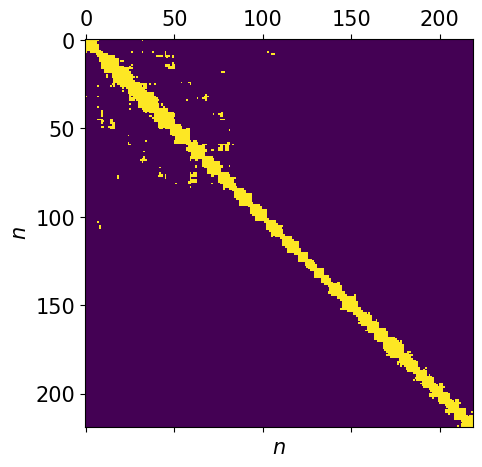

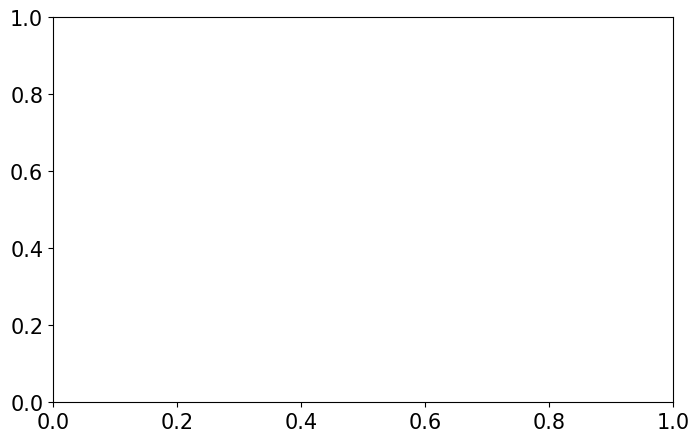

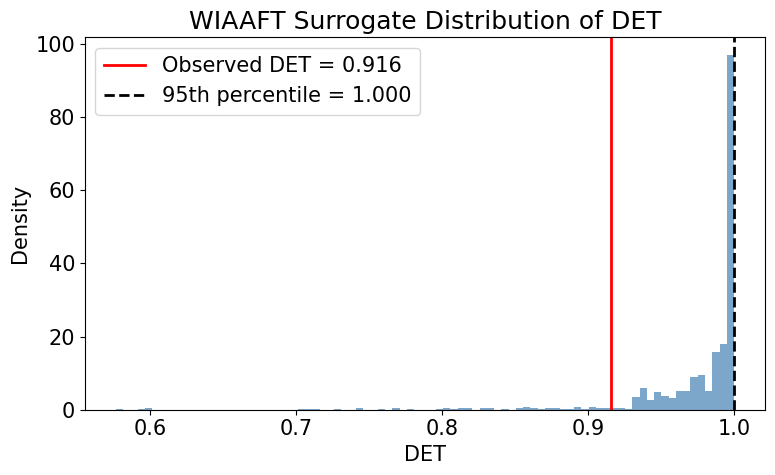

 74%|███████████████████████████████           | 74/100 [17:25<06:31, 15.07s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9155963302710294 
 Recurrence rate: 0.05001980776047205 
Threshold:1.0255999999999035 
 Laminarity:0.9624843684828576 
Shannon Entropy:1.7800260690132488 
Rank-order p-value (det):0.116 
Reject null (det) hypothesis:False

 
 

16
8
Mean Nearest Neighbor Distance: 0.27021949870360223
Pseudo-periodic surrogates generated successfullly


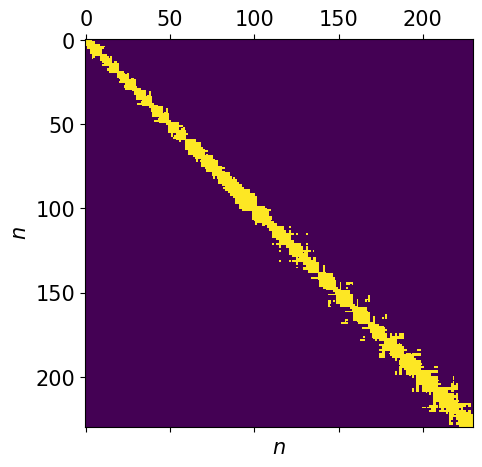

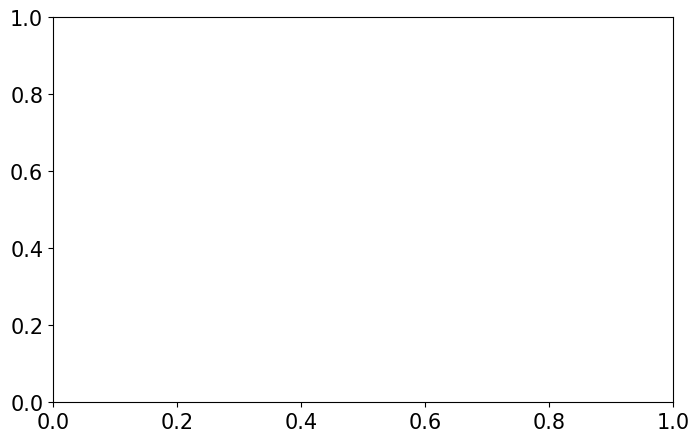

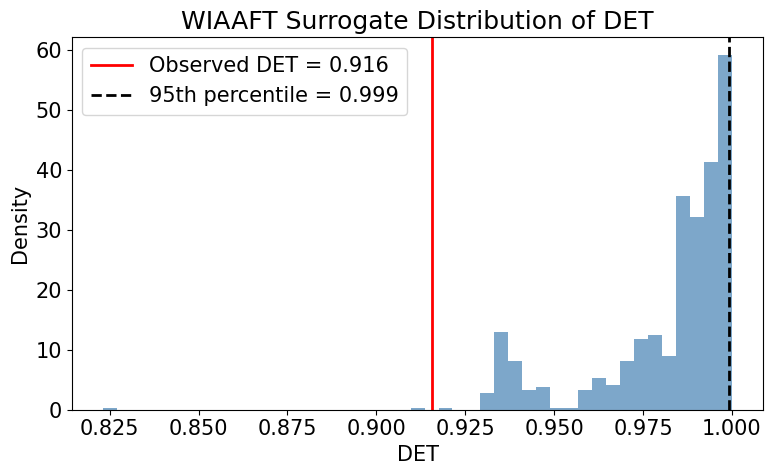

 75%|███████████████████████████████▌          | 75/100 [17:37<05:57, 14.30s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9155629139034952 
 Recurrence rate: 0.05001890359168242 
Threshold:0.7690999999999316 
 Laminarity:0.9644746787567481 
Shannon Entropy:2.108274237565714 
Rank-order p-value (det):0.006 
Reject null (det) hypothesis:True

 
 

17
10
Mean Nearest Neighbor Distance: 0.3761099251615035
Pseudo-periodic surrogates generated successfullly


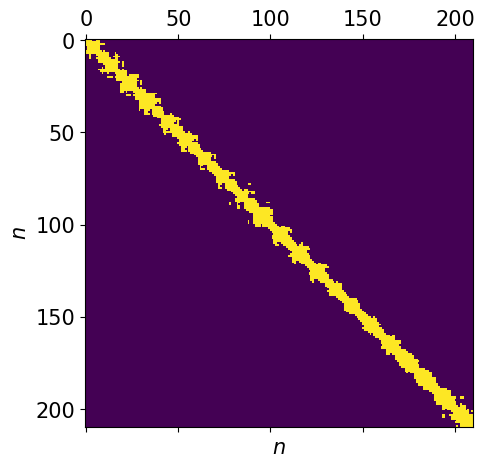

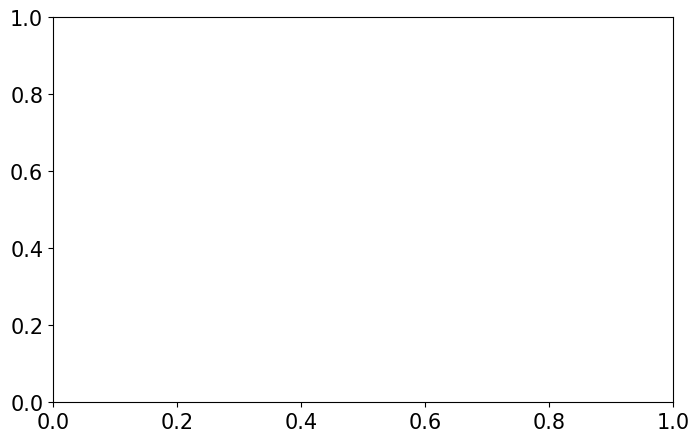

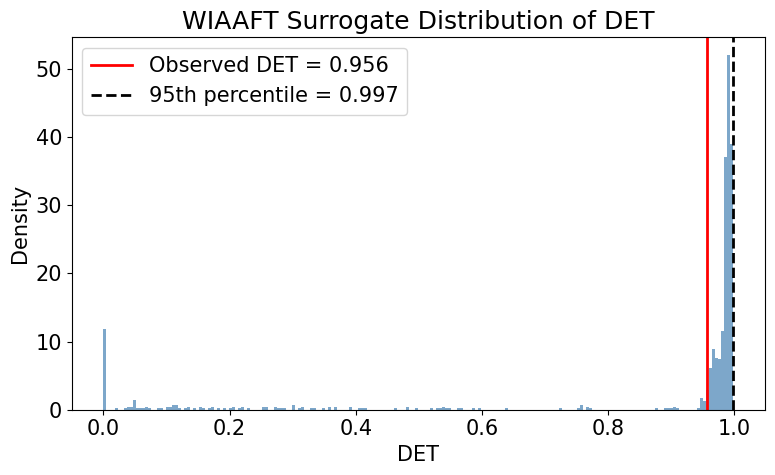

 76%|███████████████████████████████▉          | 76/100 [17:51<05:41, 14.22s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9559118236425055 
 Recurrence rate: 0.05002267573696145 
Threshold:1.0273999999999033 
 Laminarity:0.97869446962385 
Shannon Entropy:1.9038282523185113 
Rank-order p-value (det):0.362 
Reject null (det) hypothesis:False

 
 

17
10
Mean Nearest Neighbor Distance: 0.44532998662775003
Pseudo-periodic surrogates generated successfullly


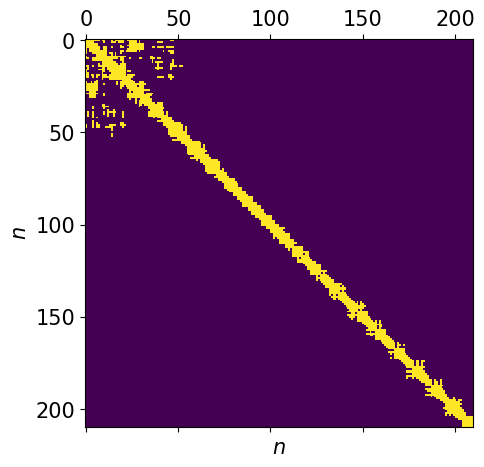

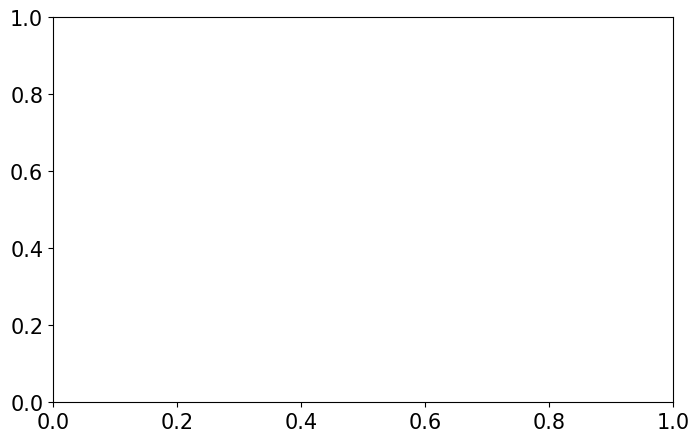

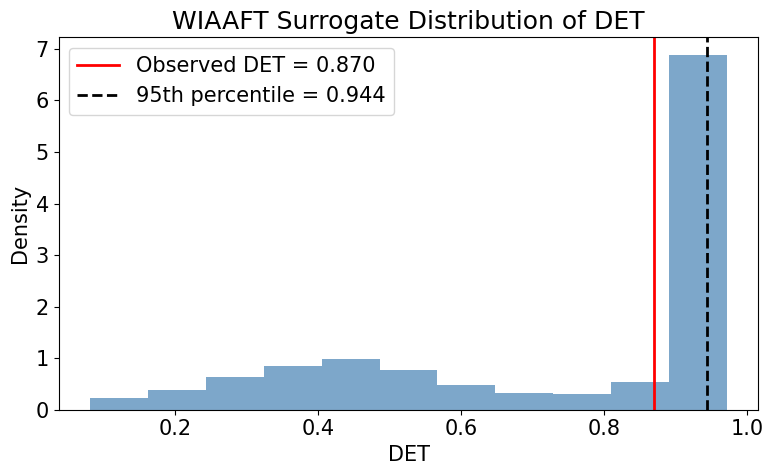

 77%|████████████████████████████████▎         | 77/100 [18:05<05:23, 14.06s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8698698698655162 
 Recurrence rate: 0.05006802721088435 
Threshold:1.011599999999905 
 Laminarity:0.9402173913000896 
Shannon Entropy:1.7214461428065917 
Rank-order p-value (det):0.822 
Reject null (det) hypothesis:False

 
 

17
4
Mean Nearest Neighbor Distance: 0.1033077205229369
Pseudo-periodic surrogates generated successfullly


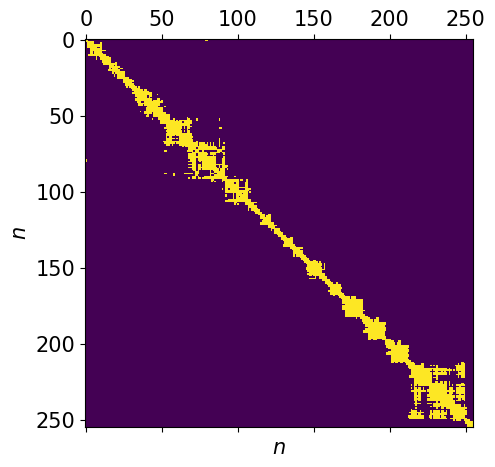

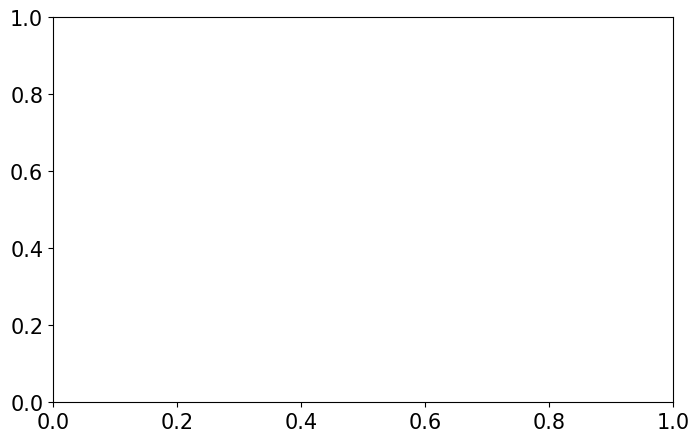

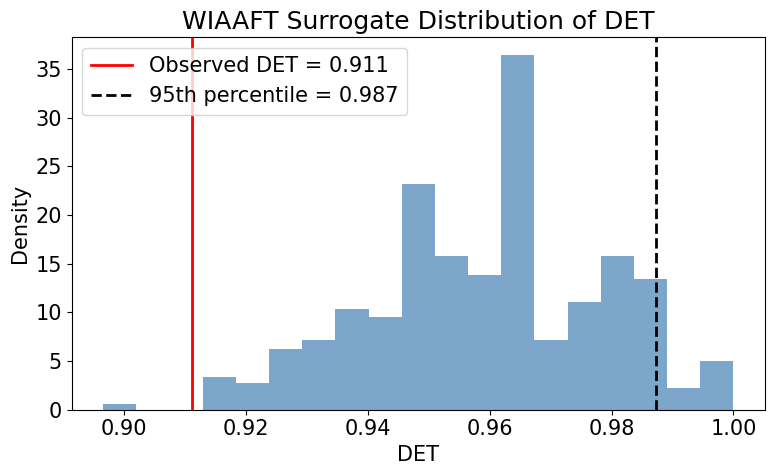

 78%|████████████████████████████████▊         | 78/100 [18:15<04:39, 12.68s/it]

RQA  ar1 Embedding dimensions:4 
 DET of original:0.9112741827854861 
 Recurrence rate: 0.050026912725874666 
Threshold:0.29569999999998375 
 Laminarity:0.9566553950170408 
Shannon Entropy:2.092490088254653 
Rank-order p-value (det):0.008 
Reject null (det) hypothesis:True

 
 

18
10
Mean Nearest Neighbor Distance: 0.44061494075542856
Pseudo-periodic surrogates generated successfullly


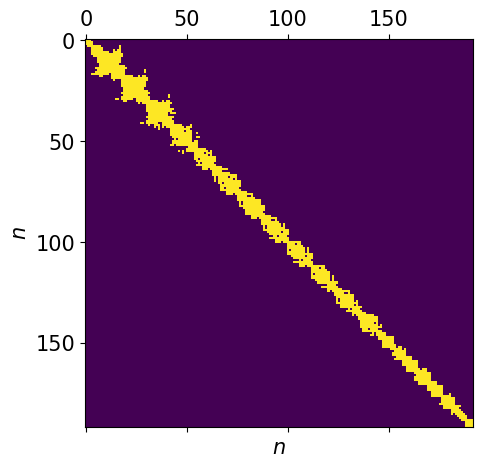

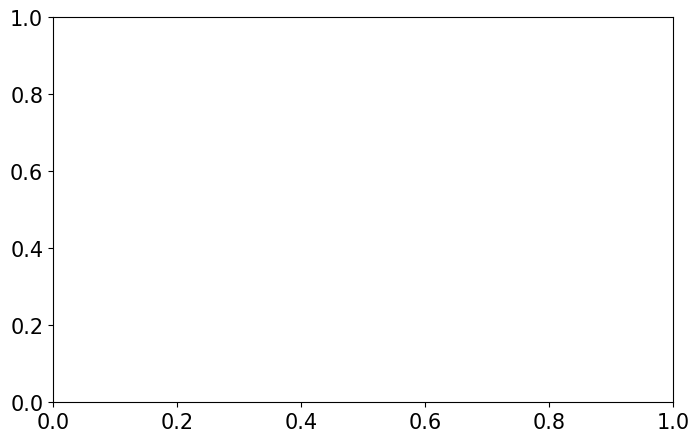

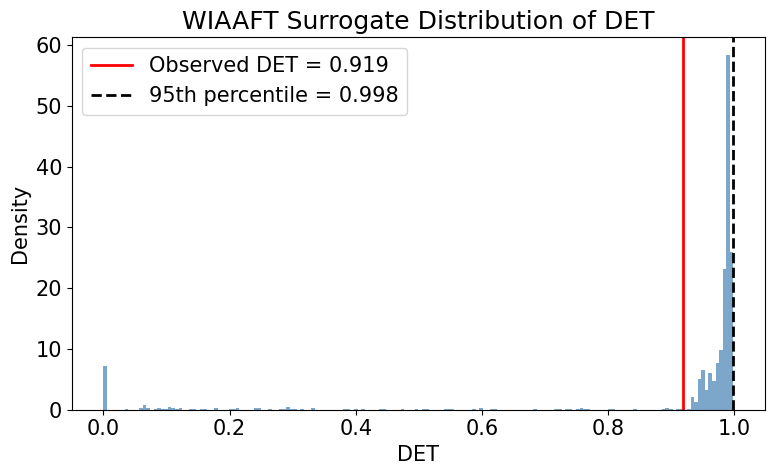

 79%|█████████████████████████████████▏        | 79/100 [18:26<04:21, 12.44s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9188861985416533 
 Recurrence rate: 0.05002170138888889 
Threshold:0.9456999999999122 
 Laminarity:0.9674620390403067 
Shannon Entropy:2.085519730444744 
Rank-order p-value (det):0.252 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.3527607667079638
Pseudo-periodic surrogates generated successfullly


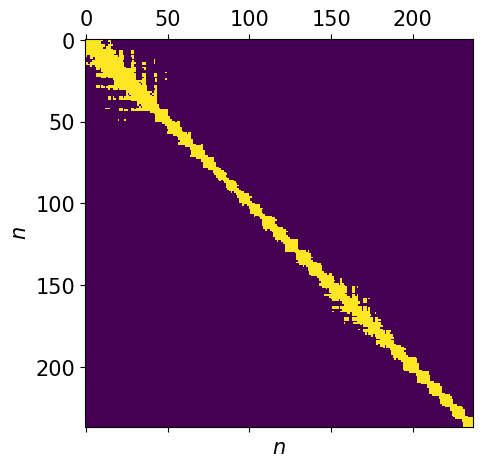

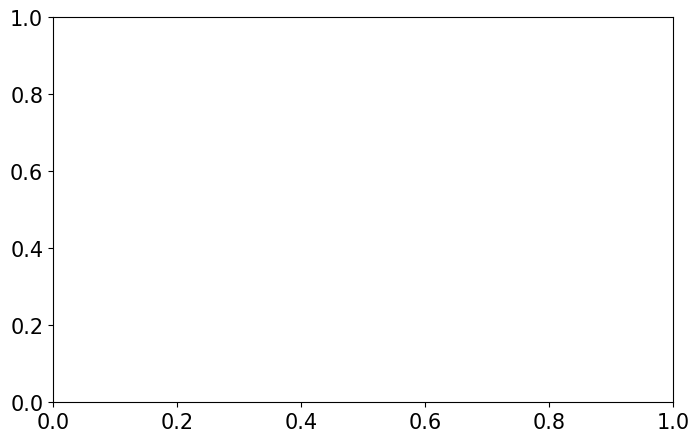

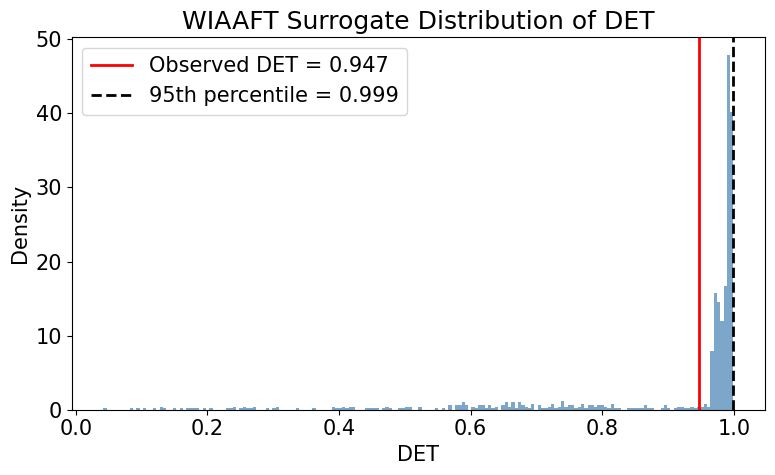

 80%|█████████████████████████████████▌        | 80/100 [18:41<04:22, 13.12s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9471228615826317 
 Recurrence rate: 0.050009791878082216 
Threshold:0.9789999999999085 
 Laminarity:0.9814880740442098 
Shannon Entropy:1.8447643212803304 
Rank-order p-value (det):0.426 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.3082663382398232
Pseudo-periodic surrogates generated successfullly


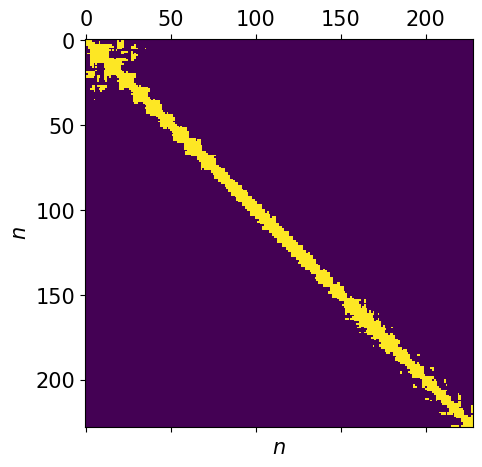

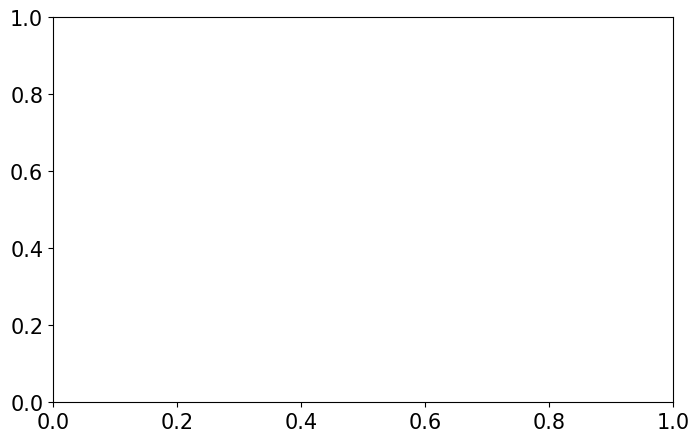

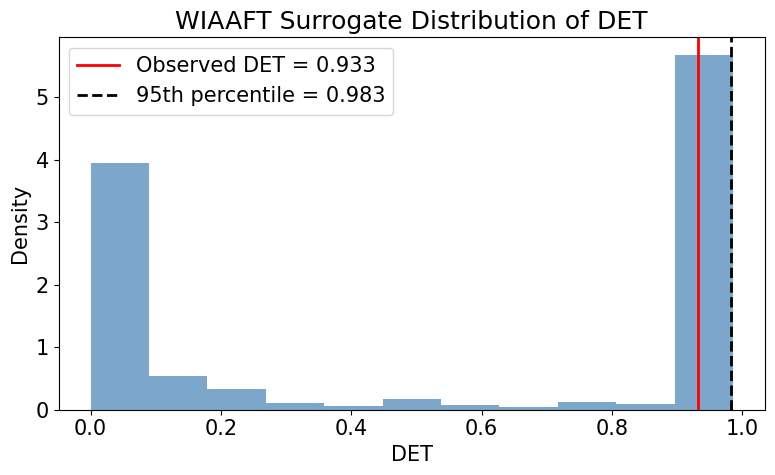

 81%|██████████████████████████████████        | 81/100 [18:53<04:03, 12.80s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9325463743636908 
 Recurrence rate: 0.05001538935056941 
Threshold:0.7900999999999293 
 Laminarity:0.975384615380864 
Shannon Entropy:1.7779183210431346 
Rank-order p-value (det):0.998 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.46606628225008484
Pseudo-periodic surrogates generated successfullly


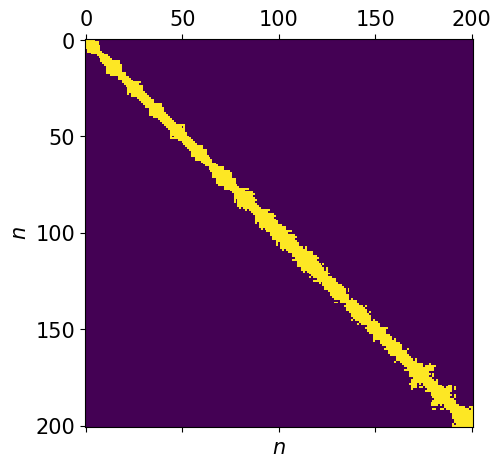

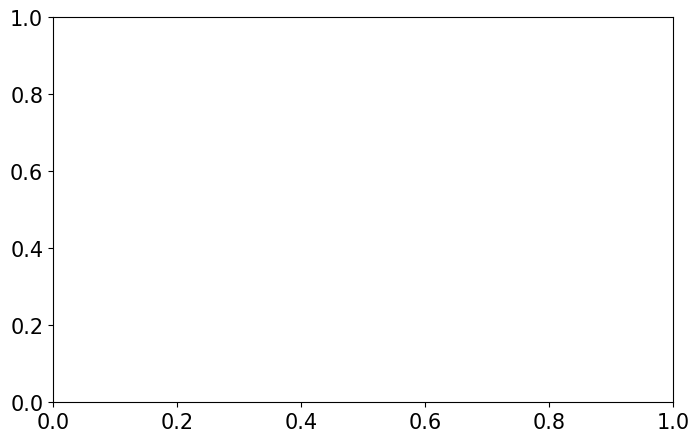

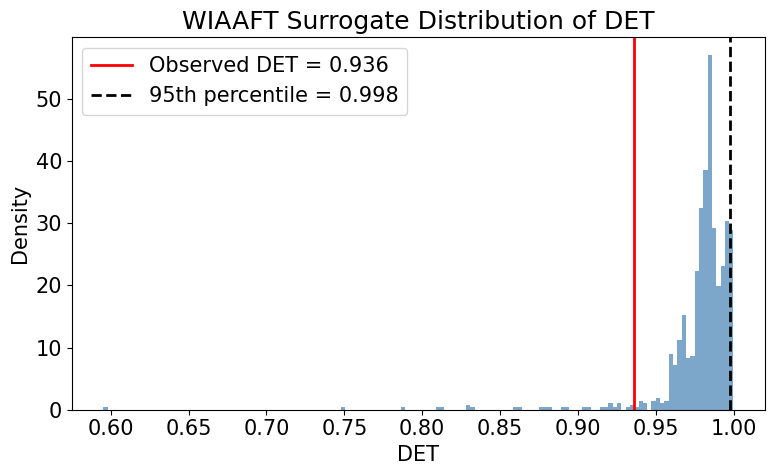

 82%|██████████████████████████████████▍       | 82/100 [19:09<04:04, 13.60s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.936263736258592 
 Recurrence rate: 0.050023514269448774 
Threshold:1.2449999999998793 
 Laminarity:0.9767441860416787 
Shannon Entropy:2.1652766840576634 
Rank-order p-value (det):0.06 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.26022434890550206
Pseudo-periodic surrogates generated successfullly


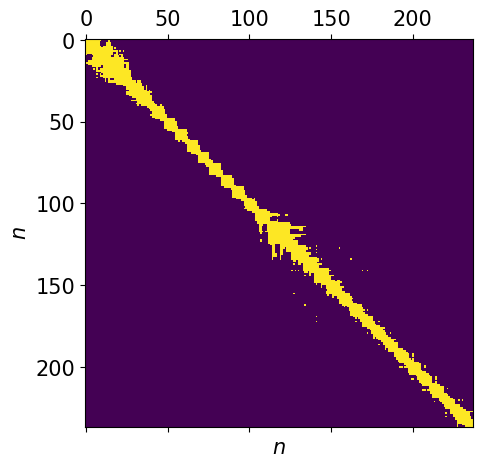

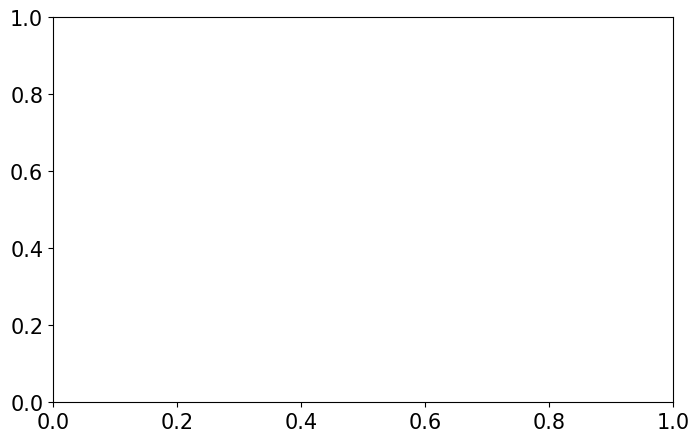

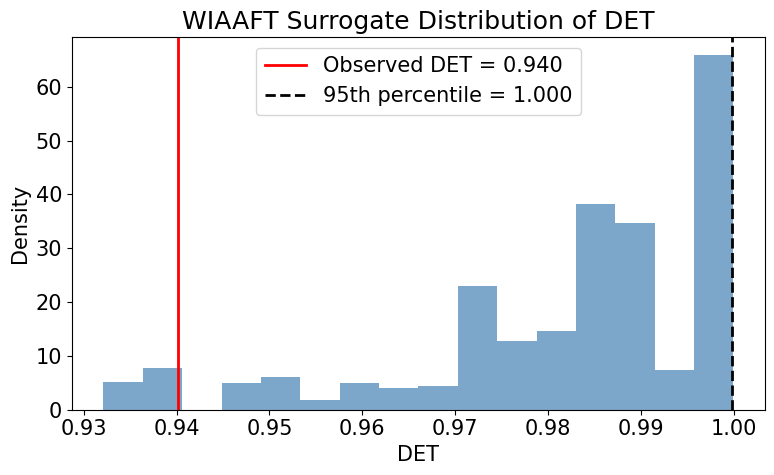

 83%|██████████████████████████████████▊       | 83/100 [19:22<03:47, 13.40s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9401709401672876 
 Recurrence rate: 0.05004539870747209 
Threshold:0.701899999999939 
 Laminarity:0.9694059053683053 
Shannon Entropy:2.0425499748448335 
Rank-order p-value (det):0.112 
Reject null (det) hypothesis:False

 
 

18
10
Mean Nearest Neighbor Distance: 0.3437723955198233
Pseudo-periodic surrogates generated successfullly


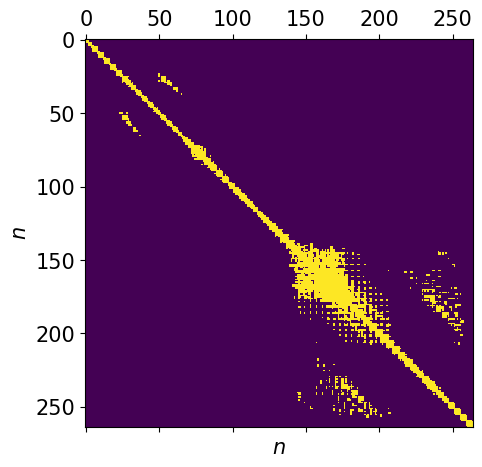

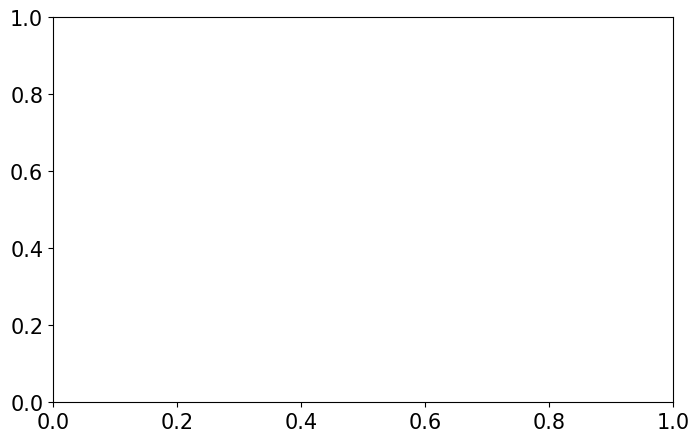

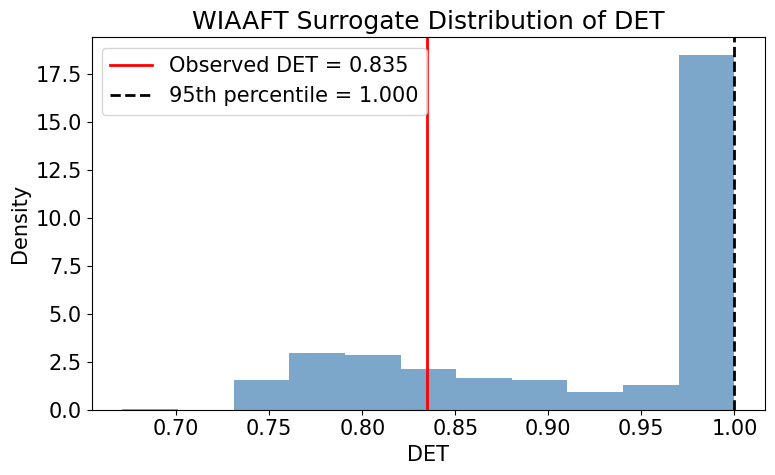

 84%|███████████████████████████████████▎      | 84/100 [19:35<03:34, 13.44s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8348851644915118 
 Recurrence rate: 0.050017217630854 
Threshold:0.6819999999999412 
 Laminarity:0.9122203098080545 
Shannon Entropy:1.5001369443138324 
Rank-order p-value (det):0.512 
Reject null (det) hypothesis:False

 
 

18
7
Mean Nearest Neighbor Distance: 0.2025527955433368
Pseudo-periodic surrogates generated successfullly


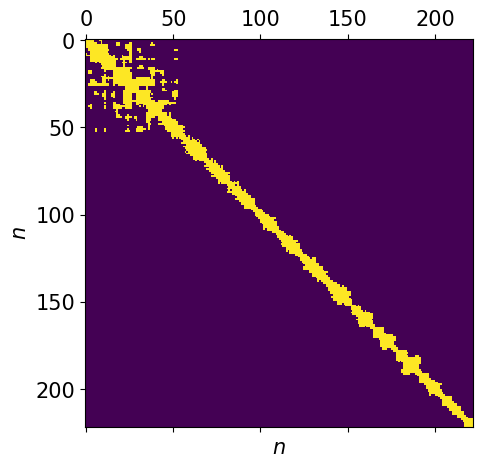

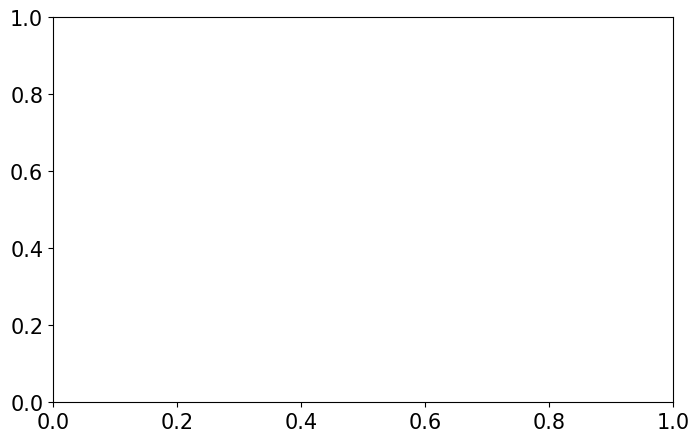

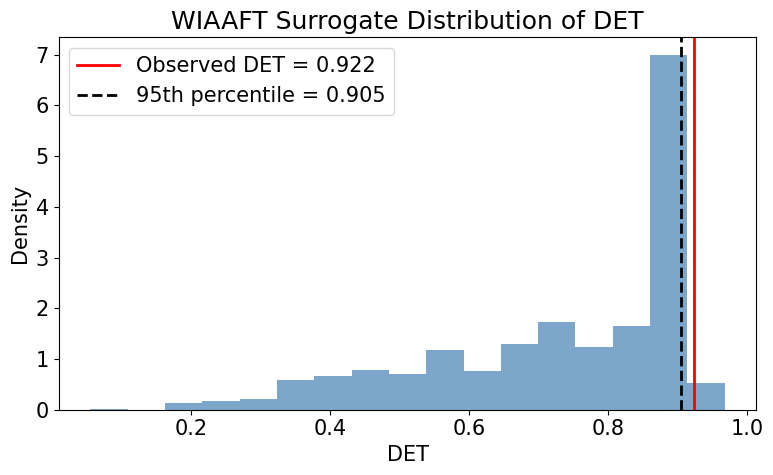

 85%|███████████████████████████████████▋      | 85/100 [19:45<03:07, 12.49s/it]

RQA  ar1 Embedding dimensions:7 
 DET of original:0.9224598930440177 
 Recurrence rate: 0.05003652300949598 
Threshold:0.557199999999955 
 Laminarity:0.963909164635183 
Shannon Entropy:2.020305538472089 
Rank-order p-value (det):0.042 
Reject null (det) hypothesis:True

 
 

19
10
Mean Nearest Neighbor Distance: 0.6315808714693162
Pseudo-periodic surrogates generated successfullly


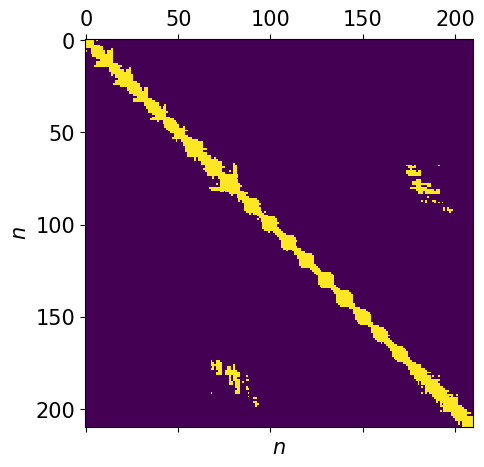

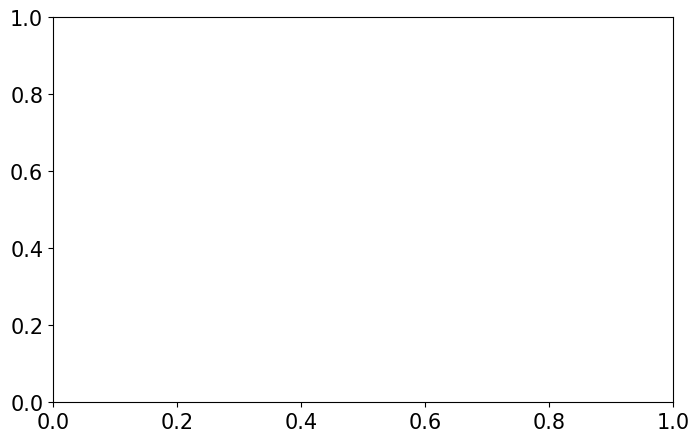

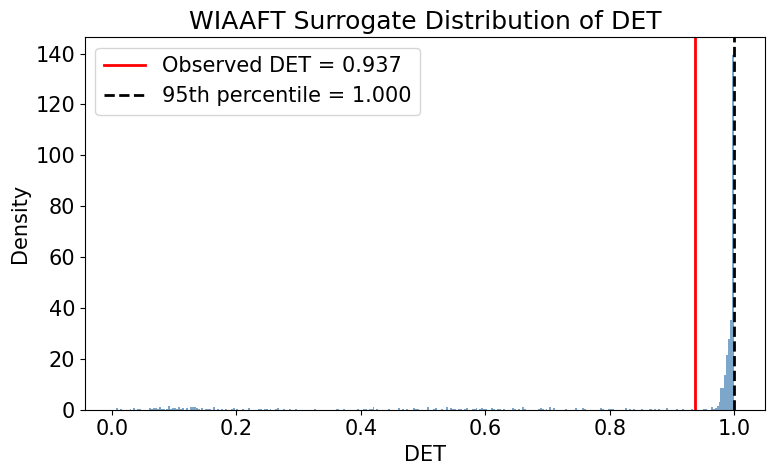

 86%|████████████████████████████████████      | 86/100 [20:02<03:13, 13.82s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9368737474902963 
 Recurrence rate: 0.05002267573696145 
Threshold:1.5318999999998477 
 Laminarity:0.968721668173306 
Shannon Entropy:1.9828729046367597 
Rank-order p-value (det):0.364 
Reject null (det) hypothesis:False

 
 

19
10
Mean Nearest Neighbor Distance: 0.6199561370700458
Pseudo-periodic surrogates generated successfullly


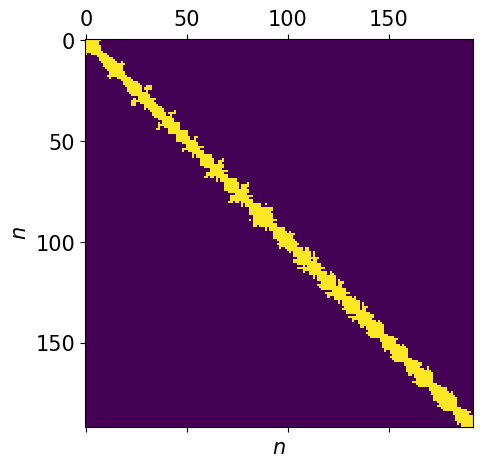

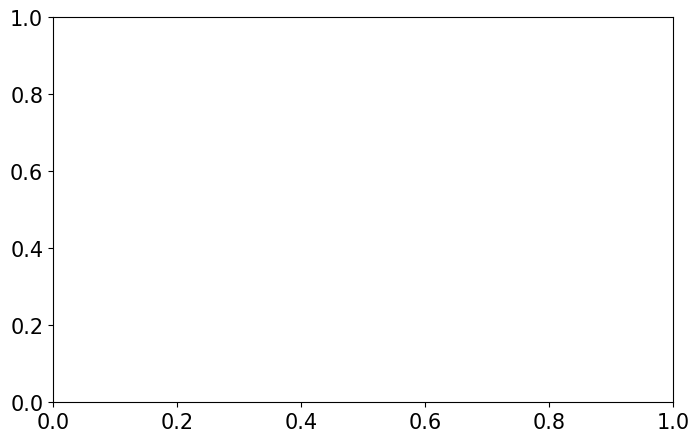

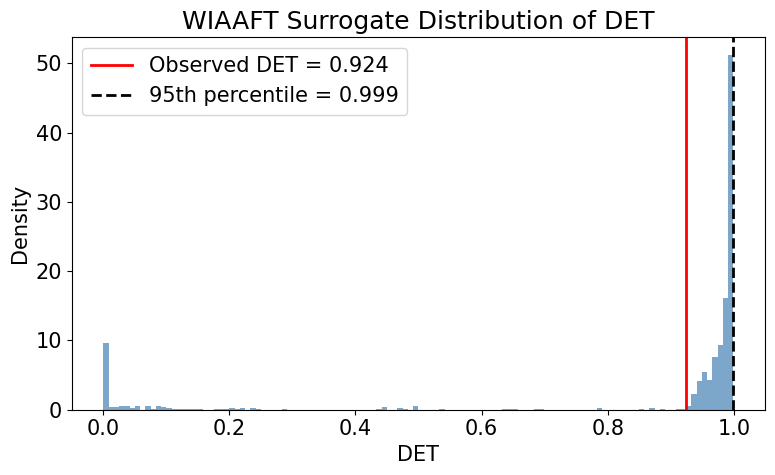

 87%|████████████████████████████████████▌     | 87/100 [20:17<03:02, 14.06s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9237288135537305 
 Recurrence rate: 0.05002170138888889 
Threshold:1.4966999999998516 
 Laminarity:0.9728850325326851 
Shannon Entropy:1.934068265392359 
Rank-order p-value (det):0.32 
Reject null (det) hypothesis:False

 
 

19
10
Mean Nearest Neighbor Distance: 0.3785651013227175
Pseudo-periodic surrogates generated successfullly


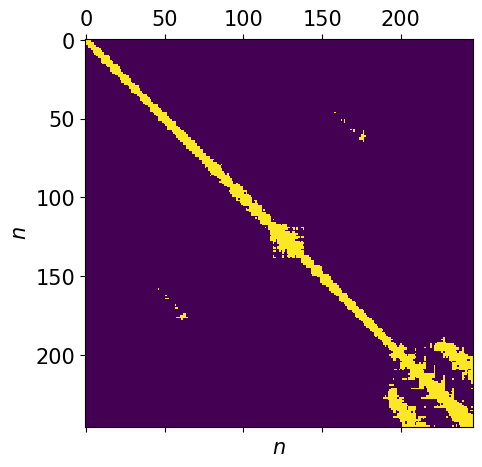

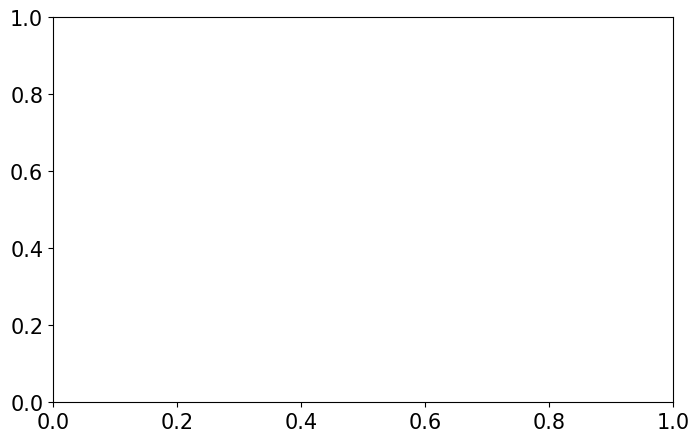

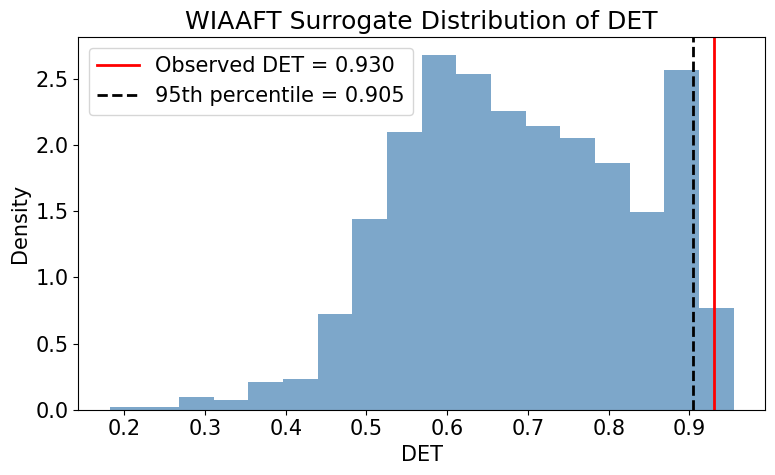

 88%|████████████████████████████████████▉     | 88/100 [20:32<02:53, 14.44s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9302158273347835 
 Recurrence rate: 0.05000330491109789 
Threshold:0.9277999999999141 
 Laminarity:0.9669530733609817 
Shannon Entropy:2.0338111423951117 
Rank-order p-value (det):0.022 
Reject null (det) hypothesis:True

 
 

20
10
Mean Nearest Neighbor Distance: 0.29660406332532135
Pseudo-periodic surrogates generated successfullly


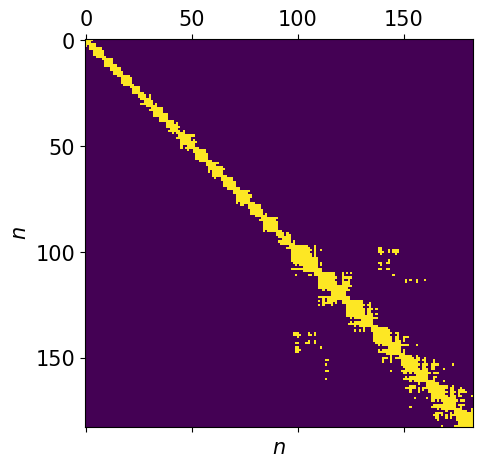

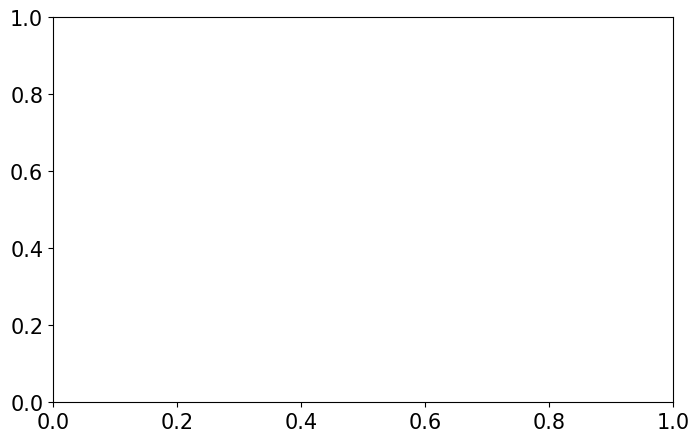

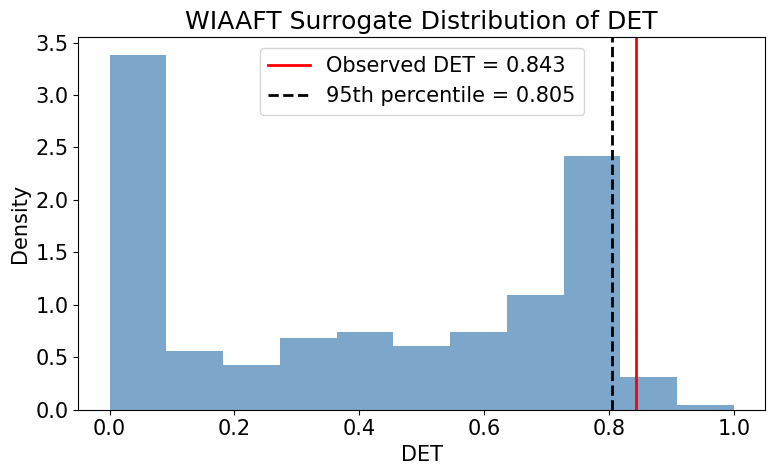

 89%|█████████████████████████████████████▍    | 89/100 [20:42<02:23, 13.01s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8431635388683435 
 Recurrence rate: 0.05001642330317418 
Threshold:0.5849999999999519 
 Laminarity:0.9217910447706162 
Shannon Entropy:1.7075908807913234 
Rank-order p-value (det):0.028 
Reject null (det) hypothesis:True

 
 

21
8
Mean Nearest Neighbor Distance: 0.3885074977043277
Pseudo-periodic surrogates generated successfullly


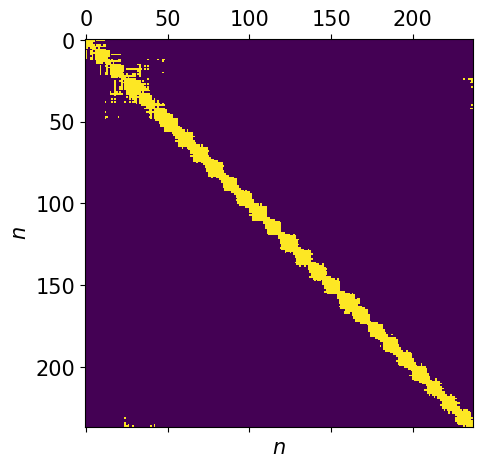

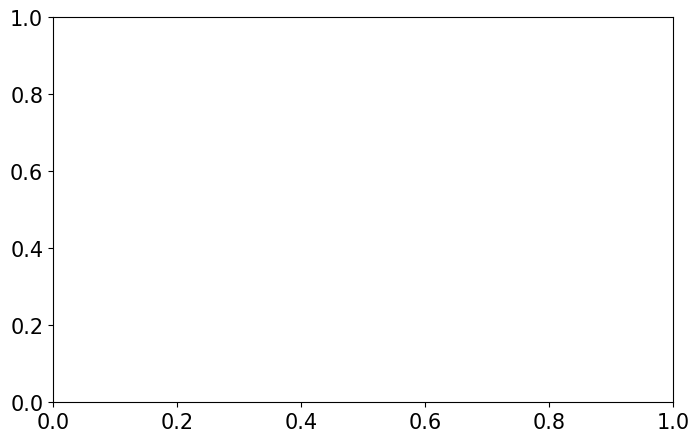

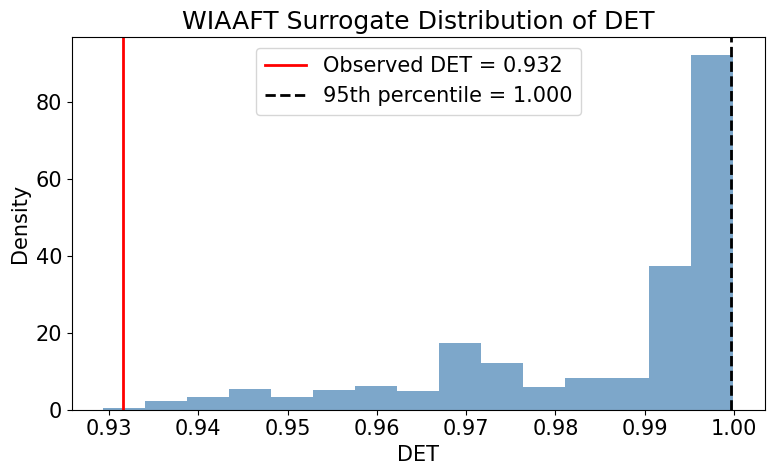

 90%|█████████████████████████████████████▊    | 90/100 [20:58<02:20, 14.03s/it]

RQA  ar1 Embedding dimensions:8 
 DET of original:0.9315707620492552 
 Recurrence rate: 0.050009791878082216 
Threshold:1.1241999999998926 
 Laminarity:0.9594161623319352 
Shannon Entropy:2.0923894641349894 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

22
10
Mean Nearest Neighbor Distance: 0.28718420478643564
Pseudo-periodic surrogates generated successfullly


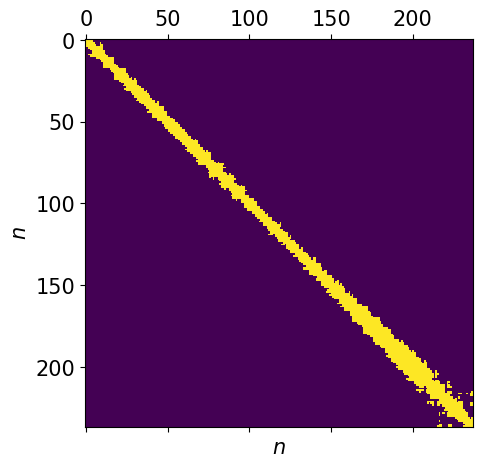

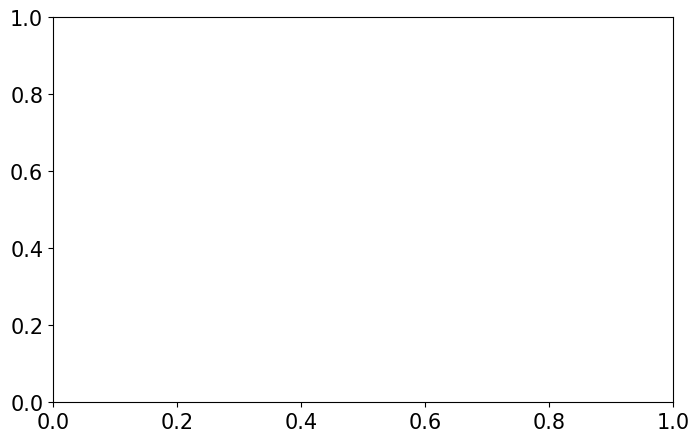

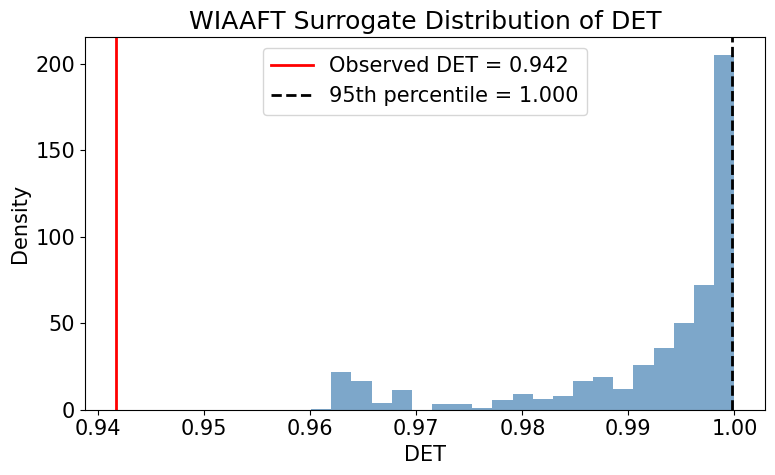

 91%|██████████████████████████████████████▏   | 91/100 [21:12<02:05, 13.98s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.94167962674595 
 Recurrence rate: 0.050009791878082216 
Threshold:0.8395999999999239 
 Laminarity:0.9846920612282496 
Shannon Entropy:1.8952215711529043 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

23
10
Mean Nearest Neighbor Distance: 0.484276626073499
Pseudo-periodic surrogates generated successfullly


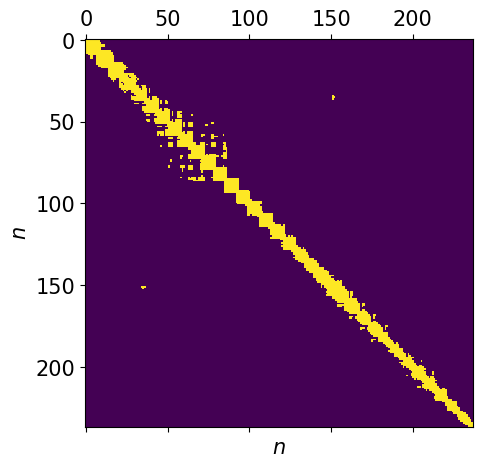

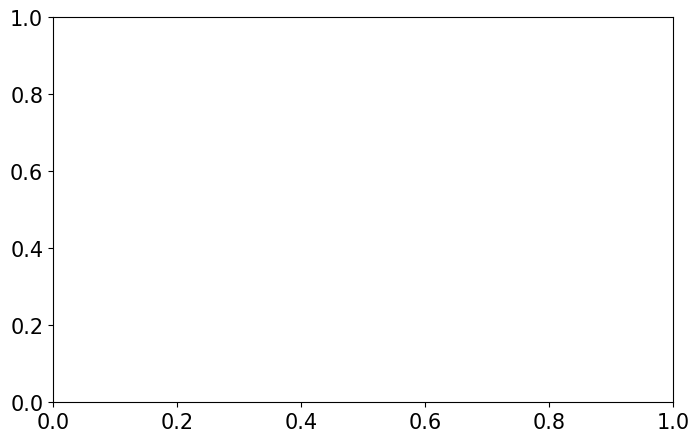

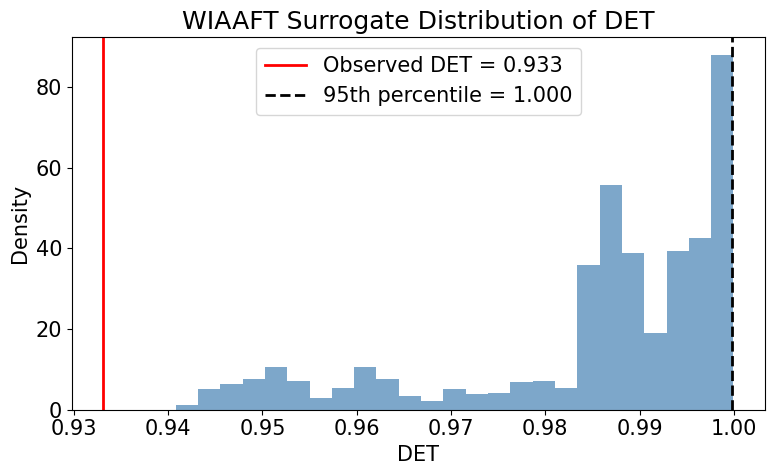

 92%|██████████████████████████████████████▋   | 92/100 [21:30<02:01, 15.20s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9331259720025928 
 Recurrence rate: 0.050009791878082216 
Threshold:1.3043999999998728 
 Laminarity:0.9733001067961079 
Shannon Entropy:1.8843773634685879 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

24
9
Mean Nearest Neighbor Distance: 0.2990419804883279
Pseudo-periodic surrogates generated successfullly


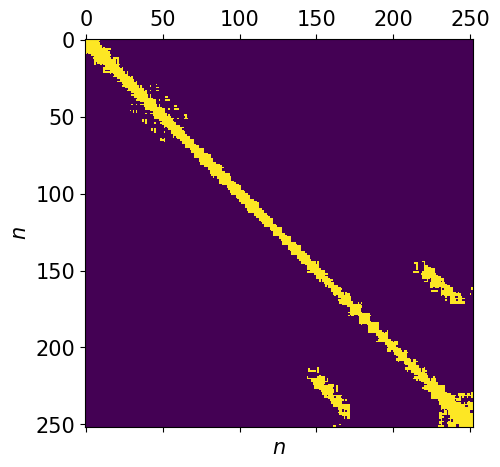

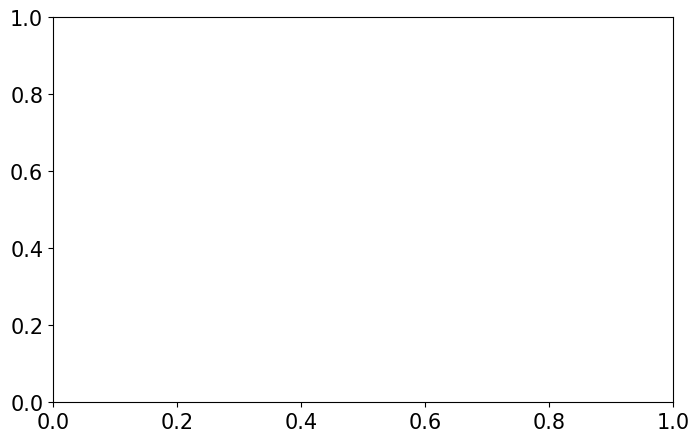

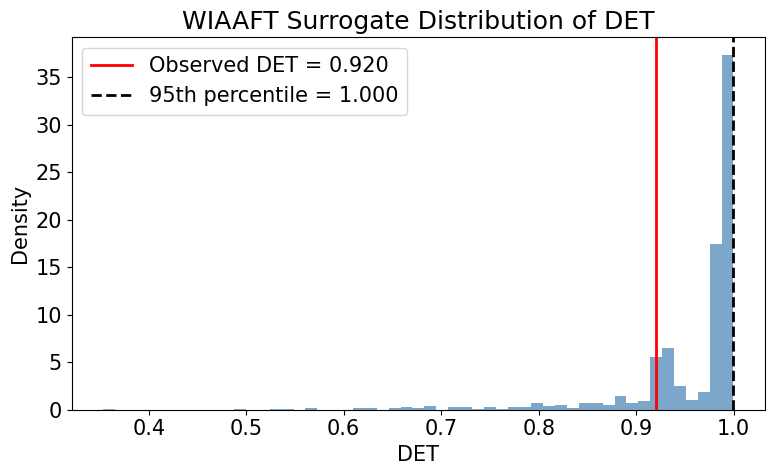

 93%|███████████████████████████████████████   | 93/100 [21:44<01:42, 14.66s/it]

RQA  ar1 Embedding dimensions:9 
 DET of original:0.919972640215732 
 Recurrence rate: 0.05001259763164525 
Threshold:0.7668999999999319 
 Laminarity:0.9622166246821089 
Shannon Entropy:1.8842086750708795 
Rank-order p-value (det):0.296 
Reject null (det) hypothesis:False

 
 

24
10
Mean Nearest Neighbor Distance: 0.2924473744337729
Pseudo-periodic surrogates generated successfullly


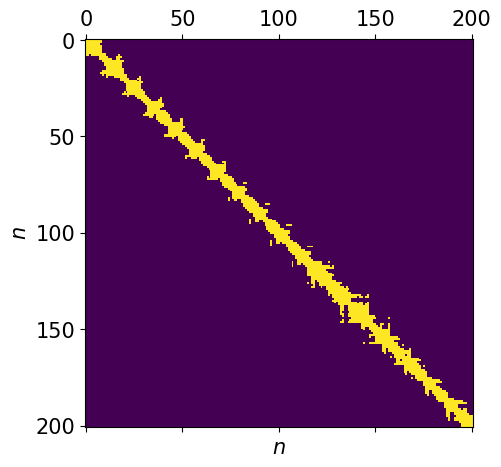

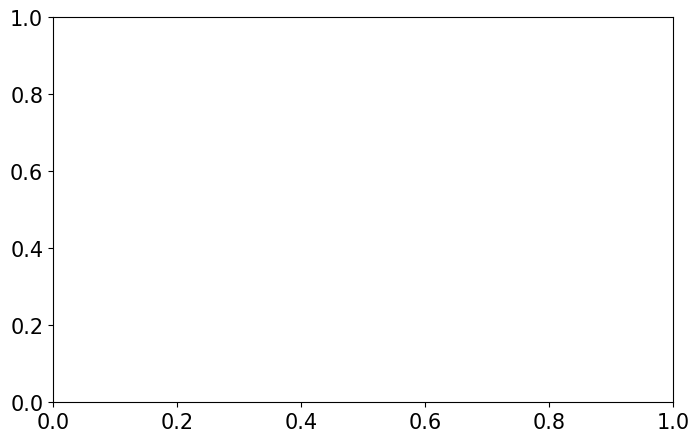

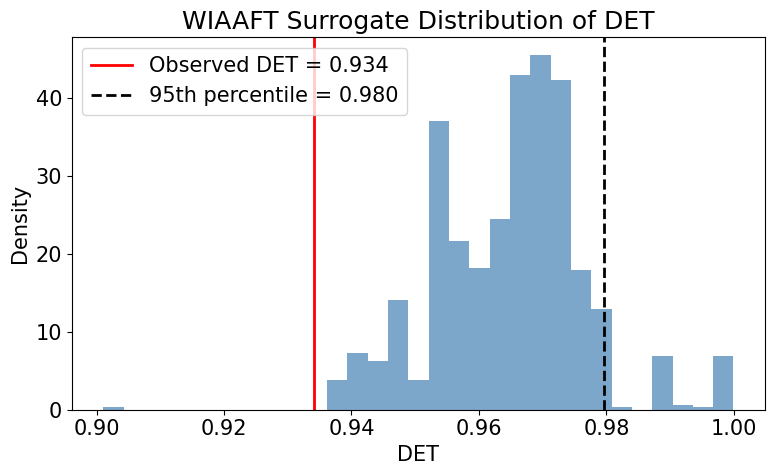

 94%|███████████████████████████████████████▍  | 94/100 [21:55<01:21, 13.56s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9340659340608019 
 Recurrence rate: 0.050023514269448774 
Threshold:0.7267999999999363 
 Laminarity:0.9727857496240833 
Shannon Entropy:1.8129721316644734 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

25
10
Mean Nearest Neighbor Distance: 0.6435765220284695
Pseudo-periodic surrogates generated successfullly


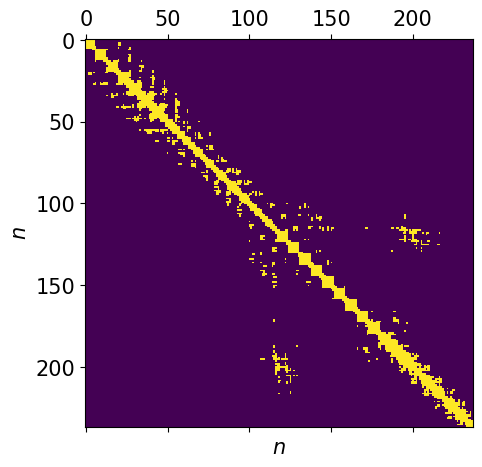

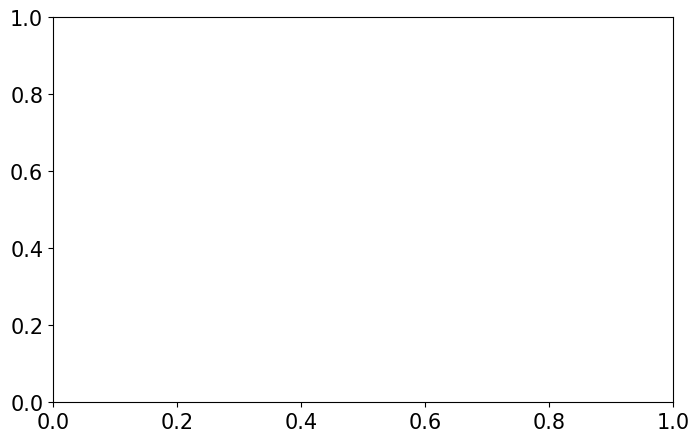

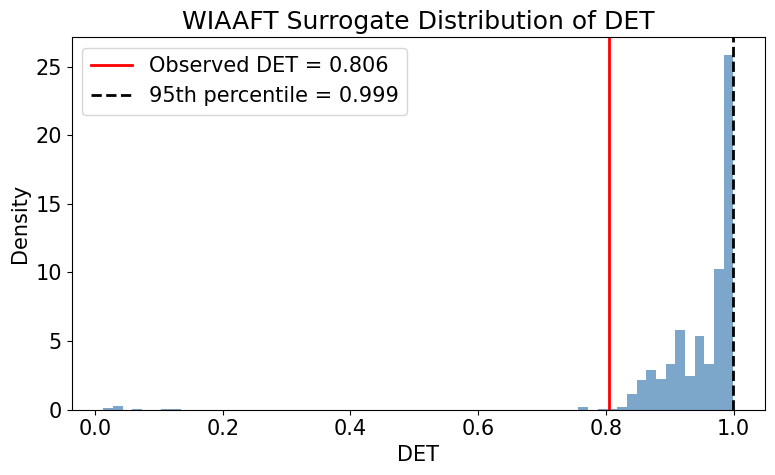

 95%|███████████████████████████████████████▉  | 95/100 [22:14<01:15, 15.16s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8057498057466754 
 Recurrence rate: 0.05004539870747209 
Threshold:1.3943999999998629 
 Laminarity:0.9096406972575253 
Shannon Entropy:1.3315030908664294 
Rank-order p-value (det):0.03 
Reject null (det) hypothesis:True

 
 

26
10
Mean Nearest Neighbor Distance: 0.6068362914466393
Pseudo-periodic surrogates generated successfullly


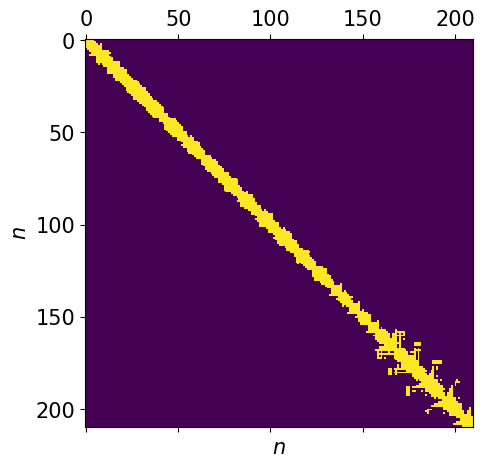

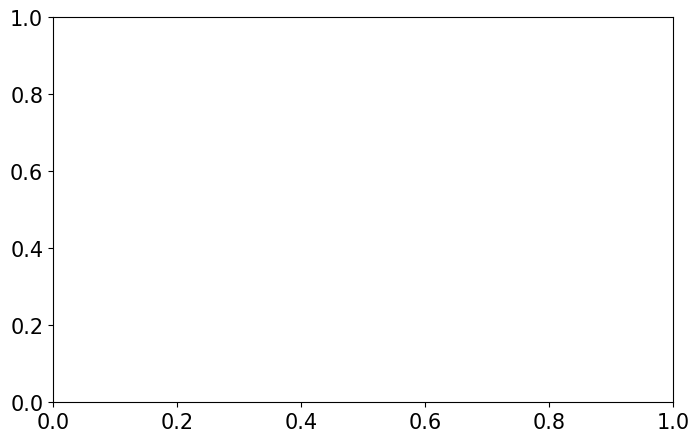

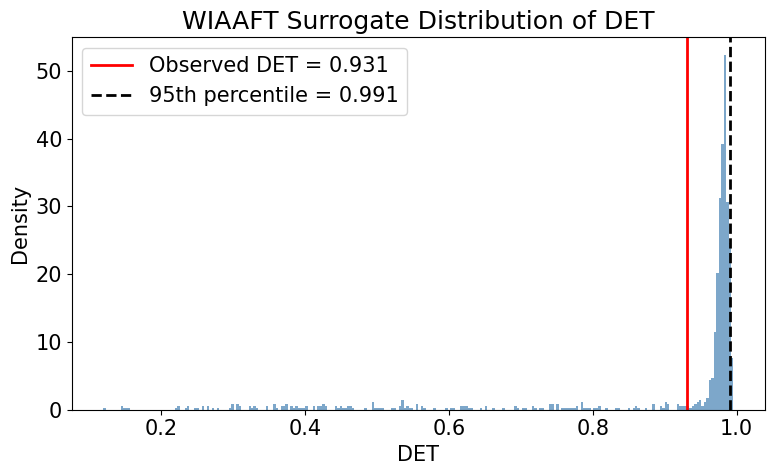

 96%|████████████████████████████████████████▎ | 96/100 [22:30<01:02, 15.62s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9308617234422302 
 Recurrence rate: 0.05002267573696145 
Threshold:1.6535999999998343 
 Laminarity:0.9723481414280493 
Shannon Entropy:1.9189478884938993 
Rank-order p-value (det):0.396 
Reject null (det) hypothesis:False

 
 

26
10
Mean Nearest Neighbor Distance: 0.28191316975501535
Pseudo-periodic surrogates generated successfullly


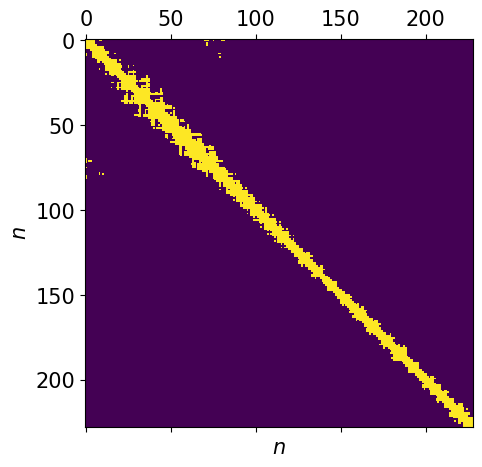

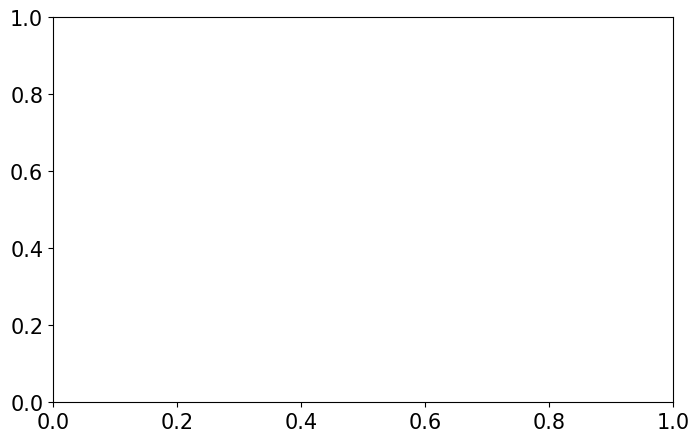

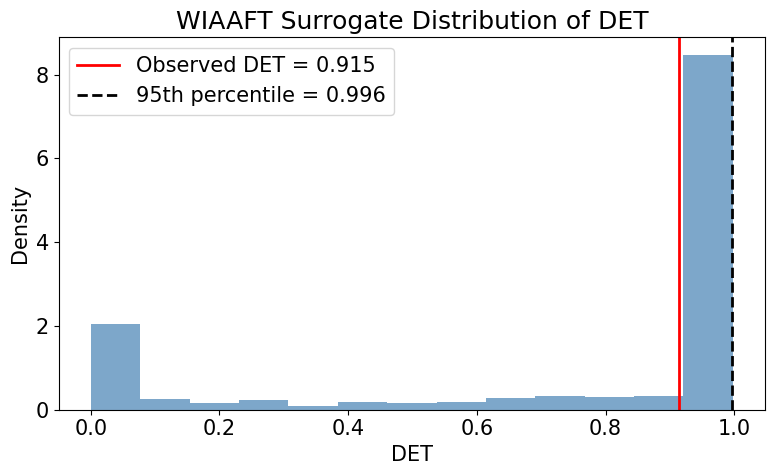

 97%|████████████████████████████████████████▋ | 97/100 [22:41<00:42, 14.16s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9148397976352663 
 Recurrence rate: 0.05001538935056941 
Threshold:0.6696999999999426 
 Laminarity:0.9569230769193965 
Shannon Entropy:1.7032714355407697 
Rank-order p-value (det):0.7 
Reject null (det) hypothesis:False

 
 

26
10
Mean Nearest Neighbor Distance: 0.6713090009645856
Pseudo-periodic surrogates generated successfullly


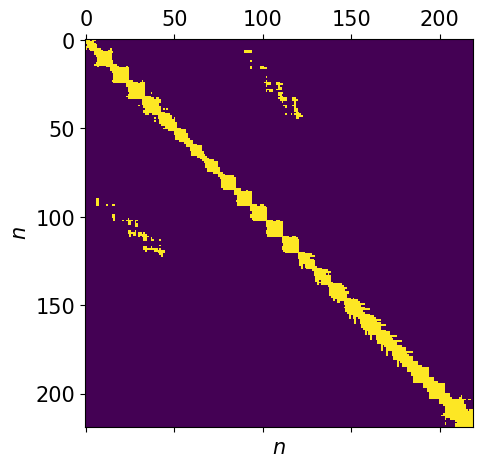

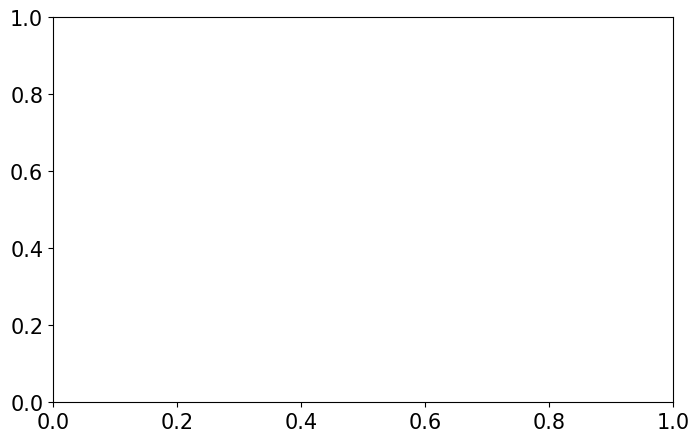

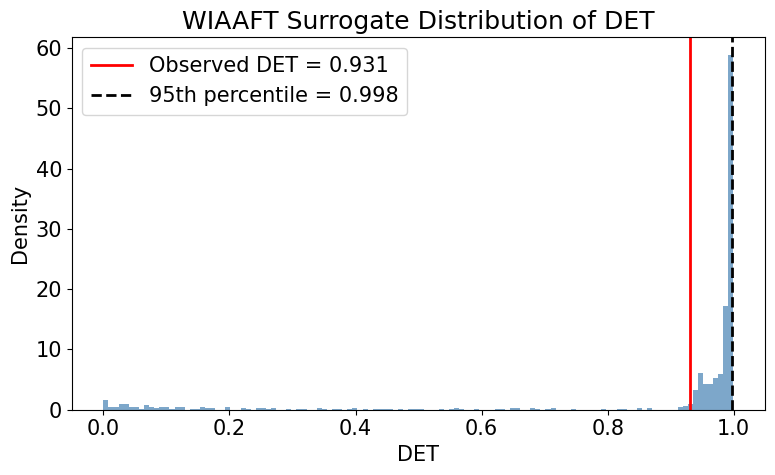

 98%|█████████████████████████████████████████▏| 98/100 [22:58<00:29, 15.00s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9311926605461872 
 Recurrence rate: 0.05001980776047205 
Threshold:1.529999999999848 
 Laminarity:0.9687369737350199 
Shannon Entropy:1.9734812279560985 
Rank-order p-value (det):0.296 
Reject null (det) hypothesis:False

 
 

26
10
Mean Nearest Neighbor Distance: 0.35066722376252624
Pseudo-periodic surrogates generated successfullly


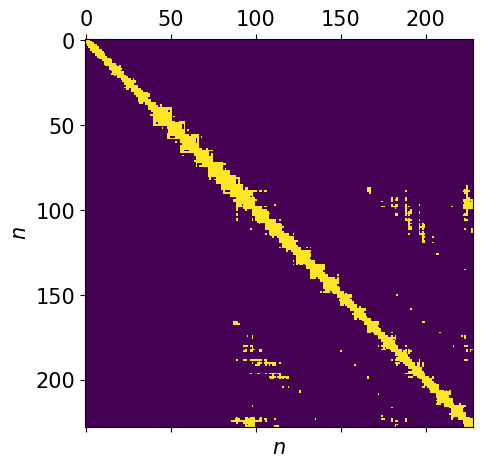

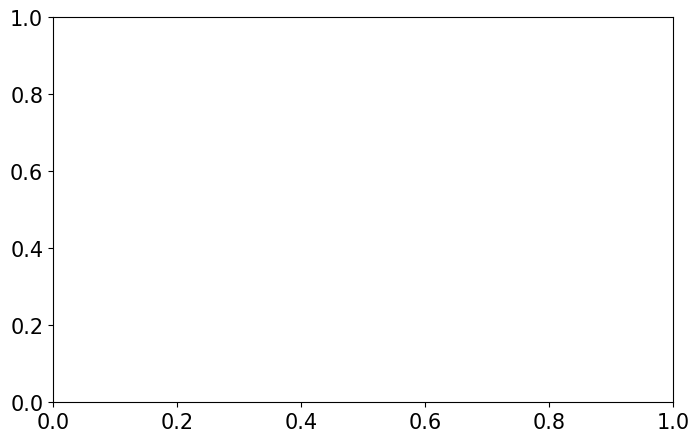

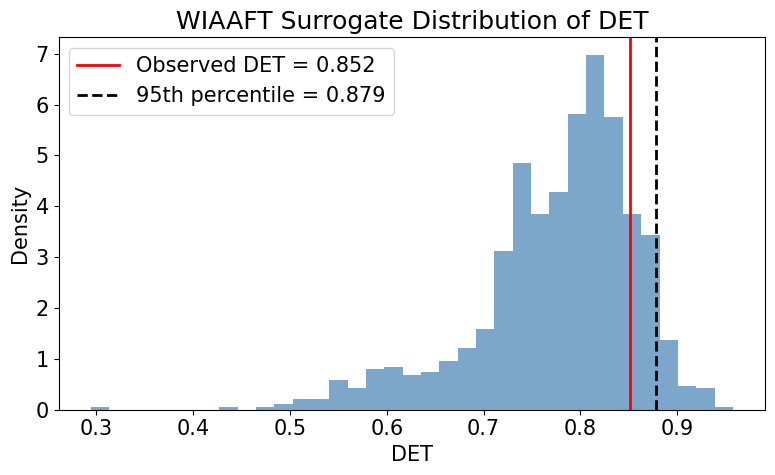

 99%|█████████████████████████████████████████▌| 99/100 [23:10<00:14, 14.23s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.8516020236051788 
 Recurrence rate: 0.05001538935056941 
Threshold:0.8400999999999238 
 Laminarity:0.9280769230733535 
Shannon Entropy:1.6547030750888896 
Rank-order p-value (det):0.298 
Reject null (det) hypothesis:False

 
 

26
10
Mean Nearest Neighbor Distance: 0.423005015834219
Pseudo-periodic surrogates generated successfullly


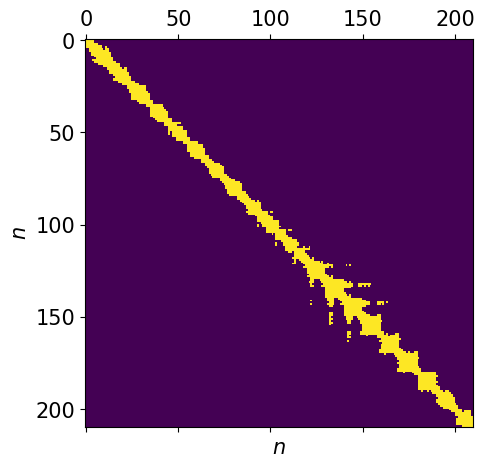

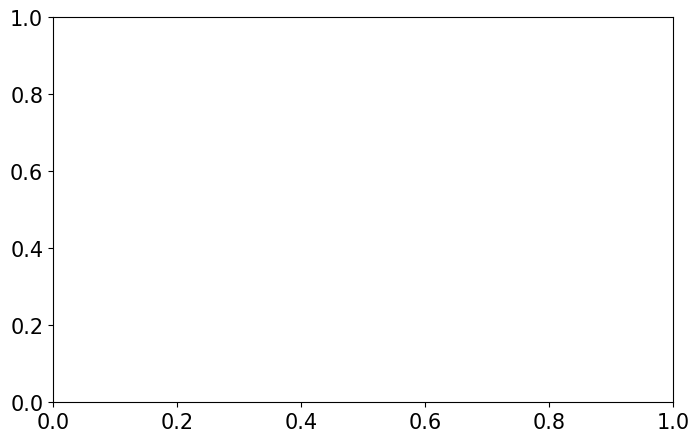

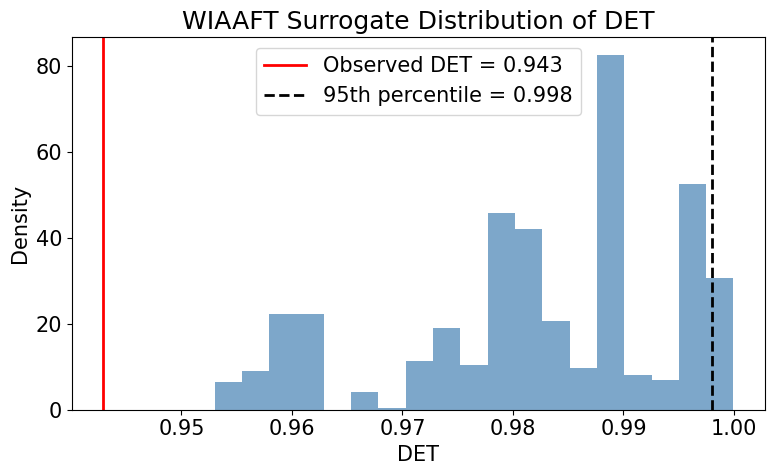

100%|█████████████████████████████████████████| 100/100 [23:24<00:00, 14.04s/it]

RQA  ar1 Embedding dimensions:10 
 DET of original:0.9429429429382236 
 Recurrence rate: 0.05006802721088435 
Threshold:1.1458999999998902 
 Laminarity:0.981431159415845 
Shannon Entropy:2.0295882022695633 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

27
rejection rate:0.27


In [10]:
rejection = 0
for e in tqdm(range(0,100)):
    ar1(e, 1.0)
    os.system("./mutual ar1 -D20 -o files/mutual_ar1 -V0")
    m_site1 = np.loadtxt("files/mutual_ar1", delimiter =' ', usecols =(1) , skiprows=0)
    mn = np.where((m_site1[1:-1] < m_site1[:-2]) & (m_site1[1:-1] < m_site1[2:]))[0] + 1
    if mn.any() > 0:
        t_min=mn[0]
    else:
        t_min=min(m_site1)
    os.system("./false_nearest ar1 -M1,10 -d{} -o files/ar1.fnn -V0".format(t_min))
    res_1 = extract_embedding_dimension("ar1")
    dim = res_1['m']
    print(dim)
    k="ar1"
    det_j=[]
    embed=[]
    det_surro_ff=[]
    kkk=[]
    lam_j=[]
    ent_j=[]
    lam_surro = []
    ent_surro=[]
    s = lcurve(k)
    tt1=0.001
    dimension=dim
    RR_orig = 0
    while RR_orig < 0.05:
        tt1 = tt1 + 0.0001
        det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
    orig_rp=RecurrencePlot(s, dim=dimension , tau=t_min, metric = "euclidean", threshold=tt1, normalize=True, silence_level = 3)
    det_j.append(det)
    embed.append(dim)
    lam_j.append(lam_orig)
    ent_j.append(entr_orig)
    pylab.matshow(matrix)
    pylab.xlabel("$n$")
    pylab.ylabel("$n$")
    pylab.savefig('test_output/PP/PP_RP_{}.eps'.format(dim), format="eps", dpi=650)
    dist_matrix = orig_rp.euclidean_distance_matrix()
    np.fill_diagonal(dist_matrix, np.inf)
    nearest_neighbor_distances = np.min(dist_matrix, axis=1)
    mean_nn_distance = np.mean(nearest_neighbor_distances)
    print(f"Mean Nearest Neighbor Distance: {mean_nn_distance}")
    noise_rad = 0.7*mean_nn_distance
    subprocess.run(["julia", "PP.jl", str(noise_rad), str(dim), str(t_min), "ar1"], text=True, check=True)
    det_ff, lam_ff, entr_ff = sur_test_PP( dim, tt1)
    fig2, axs = plt.subplots(1)
    q95 = np.percentile(det_ff, 95)
    plt.figure(figsize=(8,5))
    plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
    plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
    plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
    plt.xlabel("DET")
    plt.ylabel("Density")
    plt.title("WIAAFT Surrogate Distribution of DET")
    plt.legend()
    plt.tight_layout()
    plt.show()
    fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
    plt.show()
    plt.close() 
    plt.show()
    plt.close()
    r_up = np.sum(det_ff > det)
    r_down = np.sum(det_ff <= det)
    p_rank = min(1.0, 2.0 * ((min(r_up, r_down) + 1) / (999 + 1)))
    alpha = 0.05
    reject_null1 = p_rank < alpha
    print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
    det_surro_ff.append(det_ff)
    kkk.append(np.full(999, dimension))
    lam_surro.append(lam_ff)
    ent_surro.append(entr_ff)
    if reject_null1 == True:
        rejection = rejection + 1
    print(rejection)


print("rejection rate:{}".format(rejection/(e+1)))

# IGARCH(1,1)

In [11]:

def ig(e): # 1. Set Simulation Parameters
    rng = np.random.default_rng(1234+e)       # For reproducibility
    n_samples = 300         # Number of observations
    omega = 0.000001             # Constant variance component
    alpha = 0.10             # Shock parameter
    beta = 1.0 - alpha       # Strict IGARCH constraint (0.85)
    
    # 2. Initialize Arrays
    z = rng.normal(0, 1, n_samples)  # Standard normal innovations
    sigma2 = np.zeros(n_samples)           # Conditional variances
    epsilon = np.zeros(n_samples)          # Returns / Errors
    
    # Correct Initialization: Start the process variance at omega
    sigma2[0] = omega
    epsilon[0] = np.sqrt(sigma2[0]) * z[0]
    
    # 3. Simulation Loop
    for t in range(1, n_samples):
        # Update conditional variance mathematically using past parameters
        sigma2[t] = omega + alpha * (epsilon[t-1]**2) + beta * sigma2[t-1]
        # Calculate current return/error
        epsilon[t] = np.sqrt(sigma2[t]) * z[t]
    
    # 4. Convert to DataFrame
    df = pd.DataFrame({
        'Returns': epsilon,
        'Conditional Volatility': np.sqrt(sigma2)
    })
    
    # 5. Plotting
    #fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    #axes[0].plot(df['Returns'], color='royalblue', lw=0.8)
    #axes[0].set_title('Simulated IGARCH(1,1) Returns')
    #axes[1].plot(df['Conditional Volatility'], color='darkorange', lw=1)
    #axes[1].set_title('Conditional Volatility (Strict Unit Root Persistence)')
    #plt.tight_layout()
    #plt.show()
    np.savetxt("ig", epsilon)
    return


  0%|                                                   | 0/100 [00:00<?, ?it/s]Not enough points found!


No saturation detected (minimum FNN fallback)
6
WIAAFT surrogate datasets generated


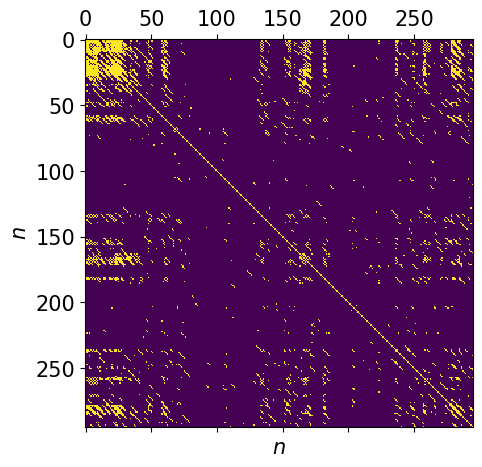

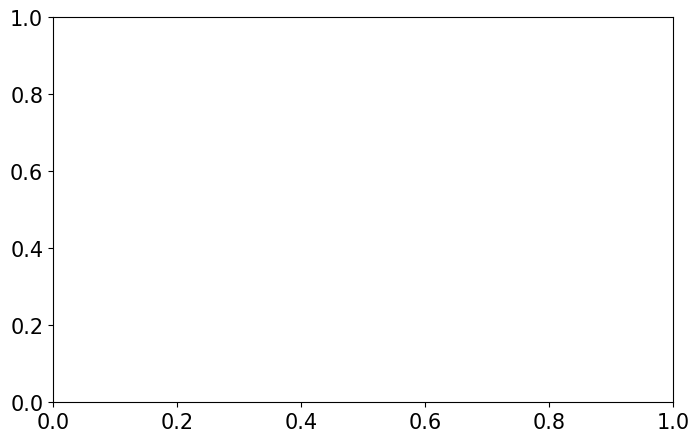

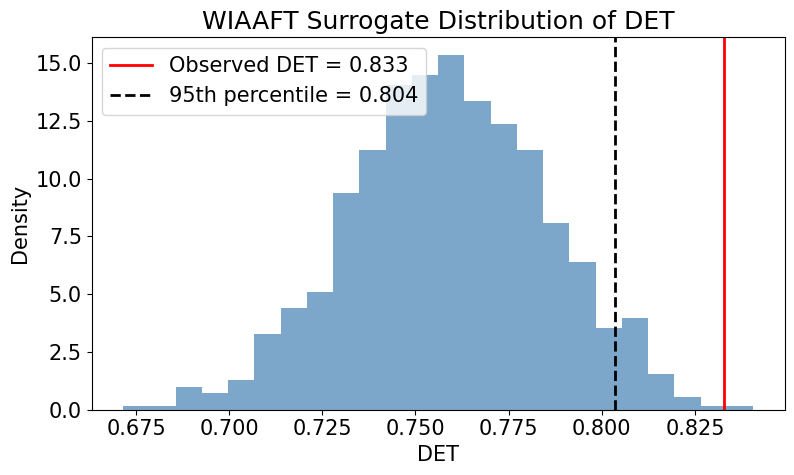

  1%|▍                                          | 1/100 [00:31<52:23, 31.75s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.8329226219792191 
 Recurrence rate: 0.05002010916403332 
Threshold:1.6178999999998382 
 Laminarity:0.4318860555928512 
Shannon Entropy:1.73557070853255 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

1
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


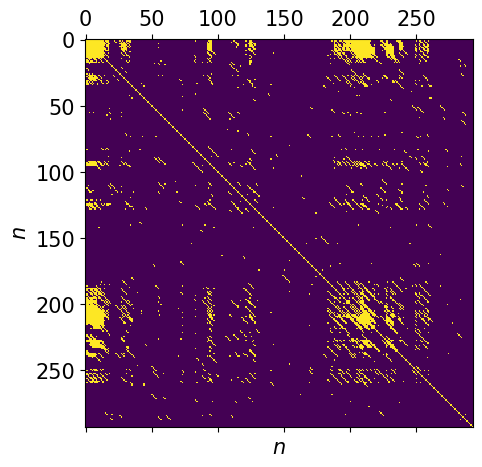

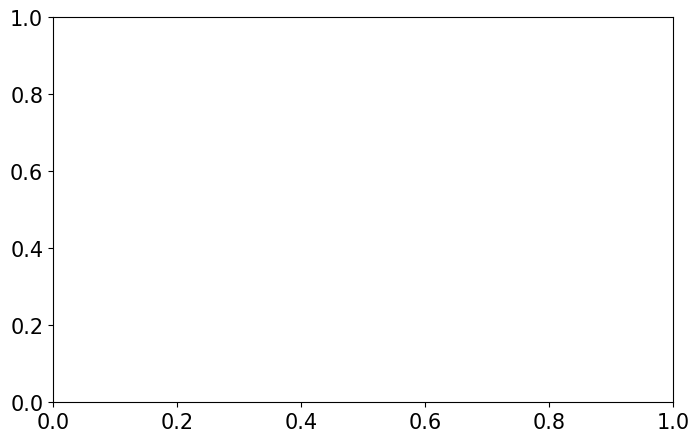

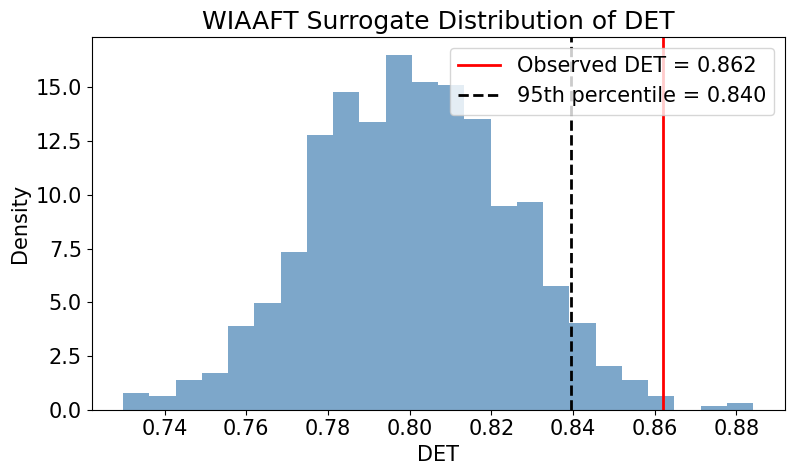

  2%|▊                                          | 2/100 [01:08<56:35, 34.65s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.861999999997845 
 Recurrence rate: 0.050006406597630726 
Threshold:2.106600000000021 
 Laminarity:0.49499184719195205 
Shannon Entropy:2.1006124819360275 
Rank-order p-value (det):0.005 
Reject null (det) hypothesis:True

 
 

2
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


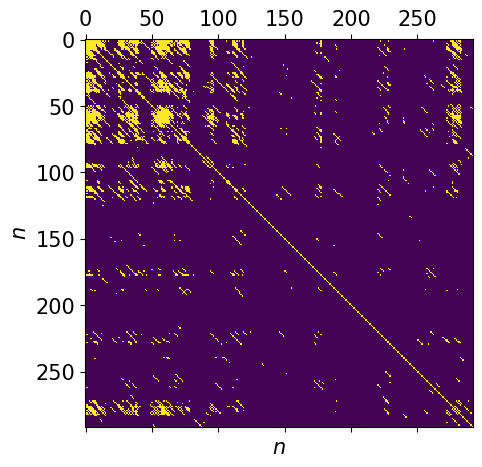

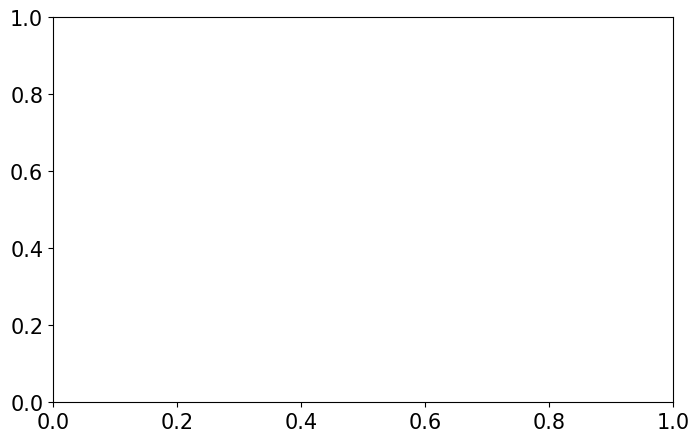

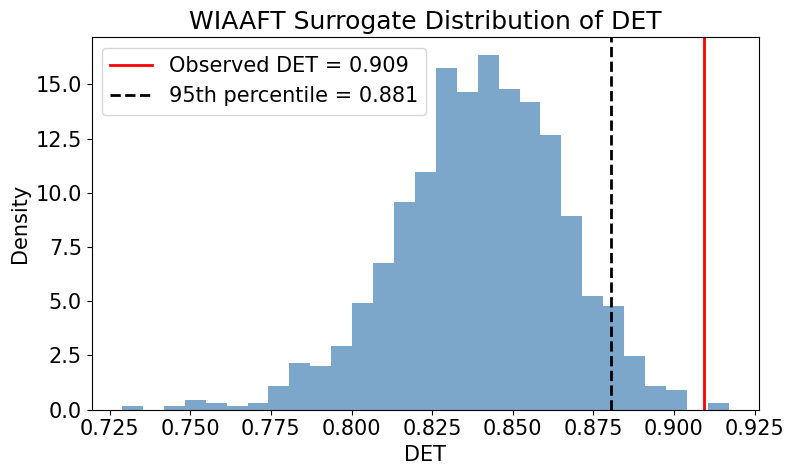

  3%|█▎                                         | 3/100 [01:46<58:15, 36.04s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9094111726197549 
 Recurrence rate: 0.050032839181835244 
Threshold:2.217000000000254 
 Laminarity:0.5398499765575718 
Shannon Entropy:2.065752168226221 
Rank-order p-value (det):0.003 
Reject null (det) hypothesis:True

 
 

3
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


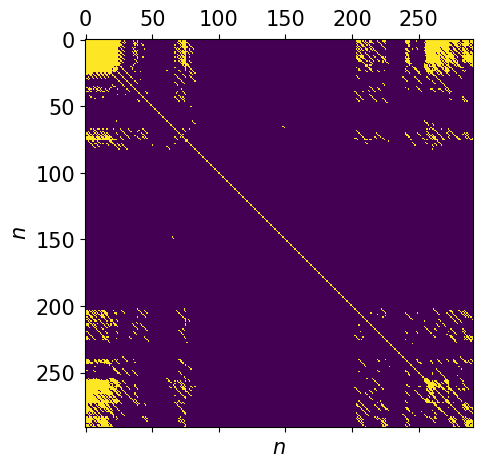

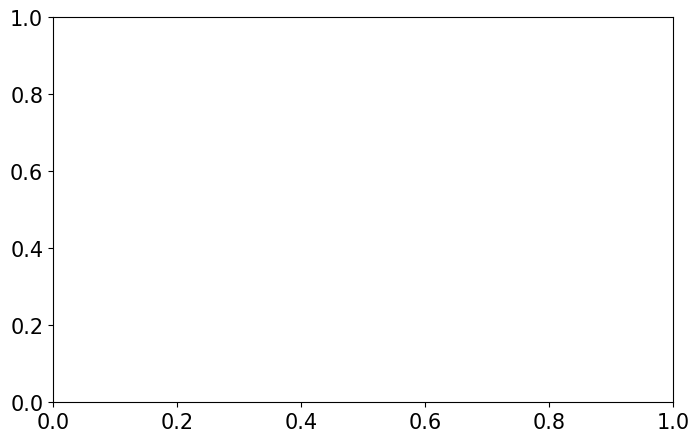

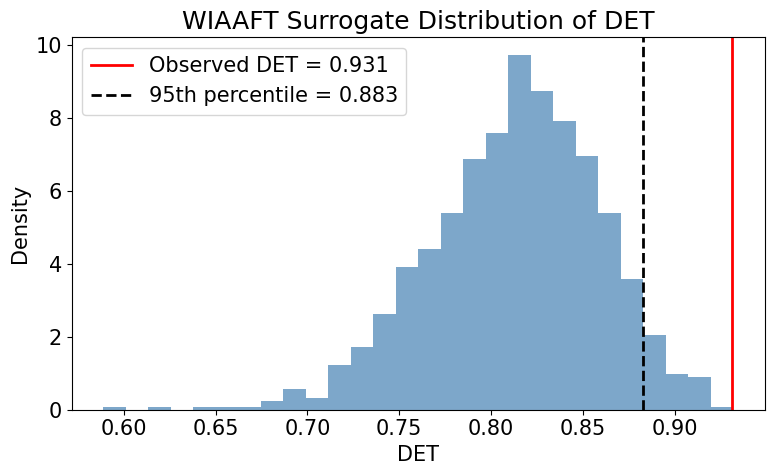

  4%|█▋                                         | 4/100 [02:21<56:56, 35.59s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9310344827562601 
 Recurrence rate: 0.050011218573233665 
Threshold:1.8994999999998072 
 Laminarity:0.6075560802819184 
Shannon Entropy:2.3854702261312433 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

4
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


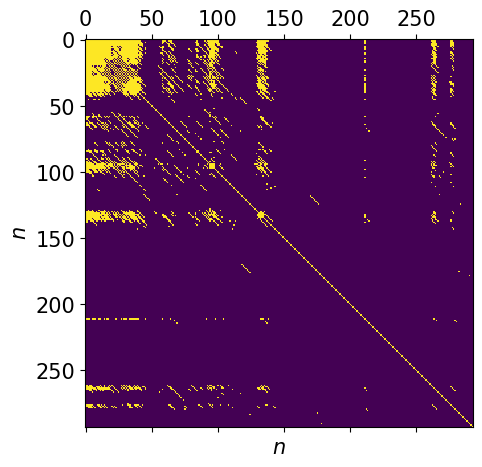

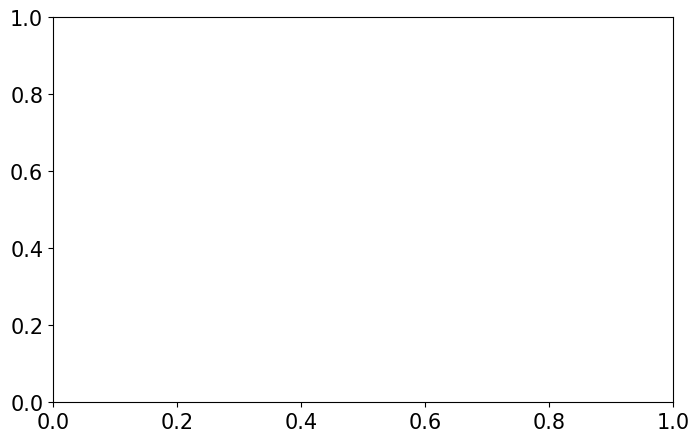

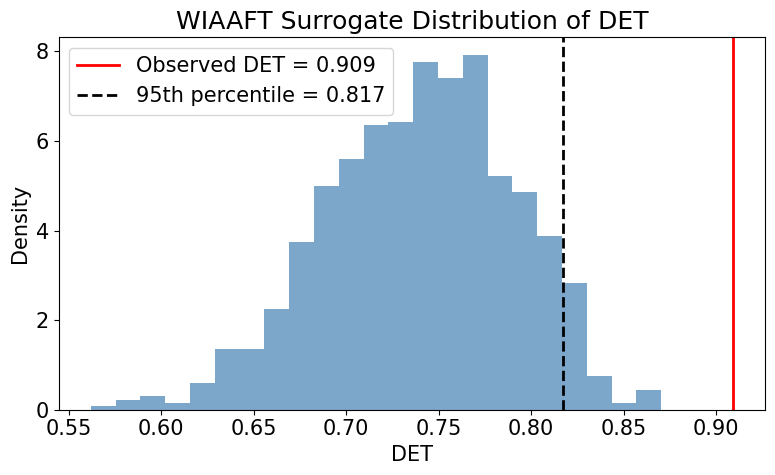

  5%|██▏                                        | 5/100 [02:51<53:14, 33.62s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.9089999999977275 
 Recurrence rate: 0.050006406597630726 
Threshold:1.4677999999998548 
 Laminarity:0.5979501514078781 
Shannon Entropy:2.3773280767687694 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

5
No saturation detected (minimum FNN fallback)
7
WIAAFT surrogate datasets generated


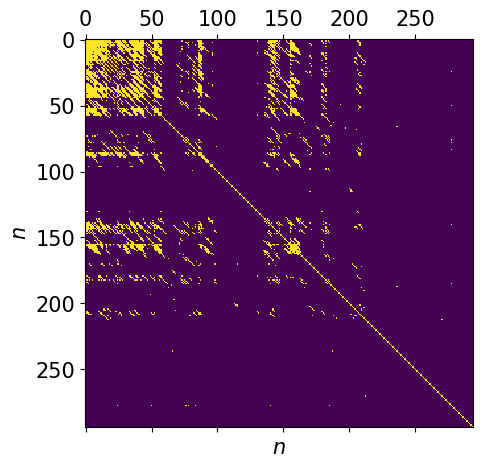

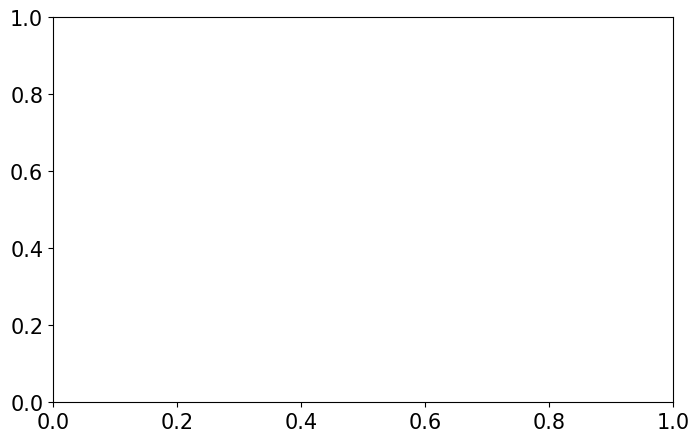

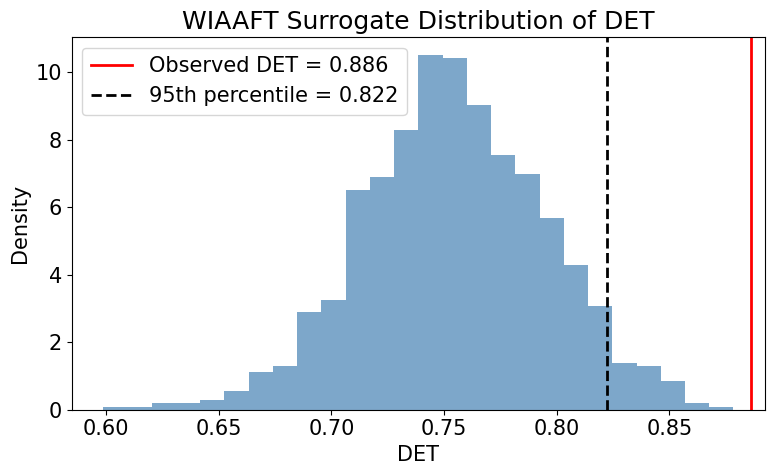

  6%|██▌                                        | 6/100 [03:19<50:01, 31.93s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8862959284982962 
 Recurrence rate: 0.05000231385071035 
Threshold:1.3405999999998688 
 Laminarity:0.6078204534923466 
Shannon Entropy:2.146217140871343 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

6
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


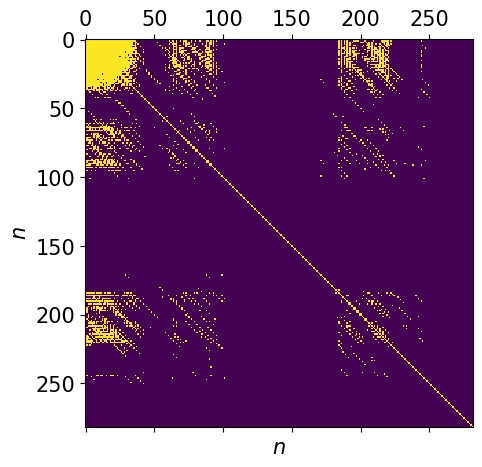

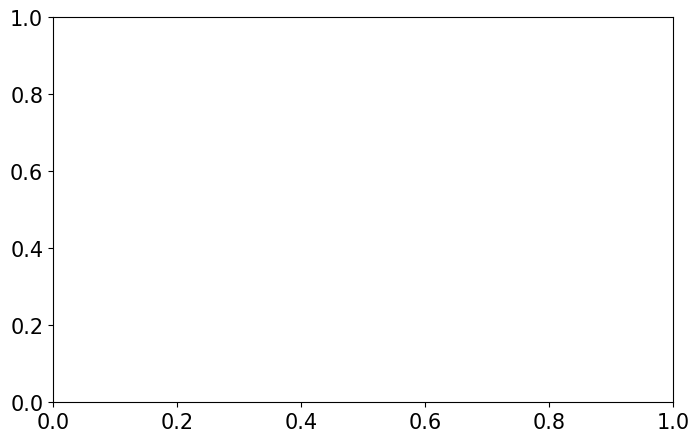

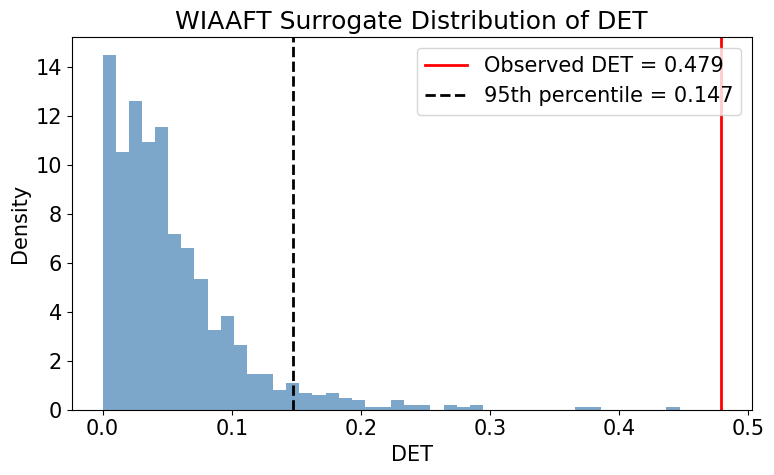

  7%|███                                        | 7/100 [03:53<50:34, 32.63s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.4788961038948082 
 Recurrence rate: 0.05002263467632413 
Threshold:1.929299999999804 
 Laminarity:0.5867269984902295 
Shannon Entropy:2.6058490698859638 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

7
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


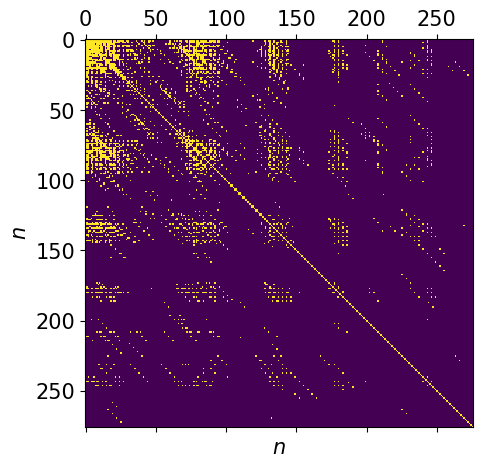

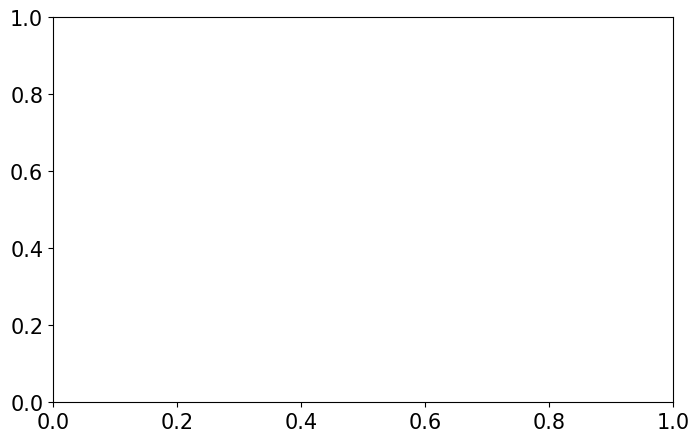

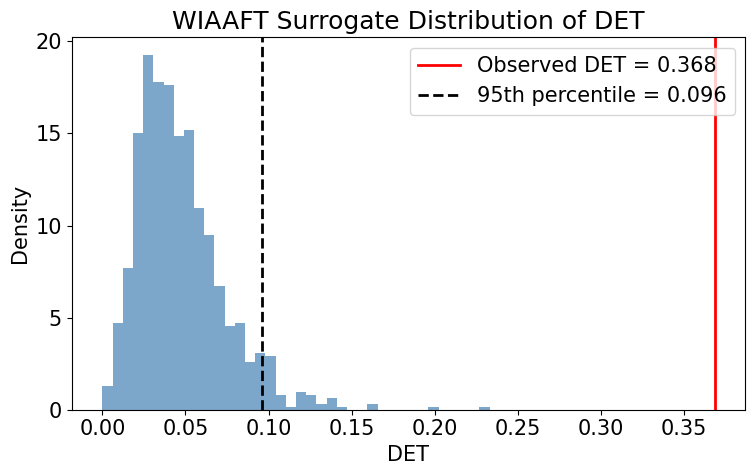

  8%|███▍                                       | 8/100 [04:29<51:19, 33.47s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.3684210526305364 
 Recurrence rate: 0.050015752993068686 
Threshold:2.190000000000197 
 Laminarity:0.45039370078621943 
Shannon Entropy:0.8433402558295201 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

8
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


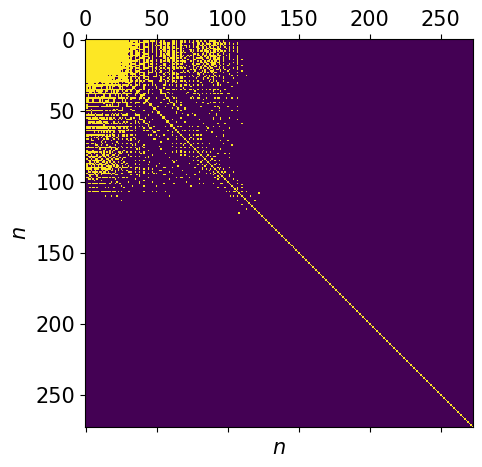

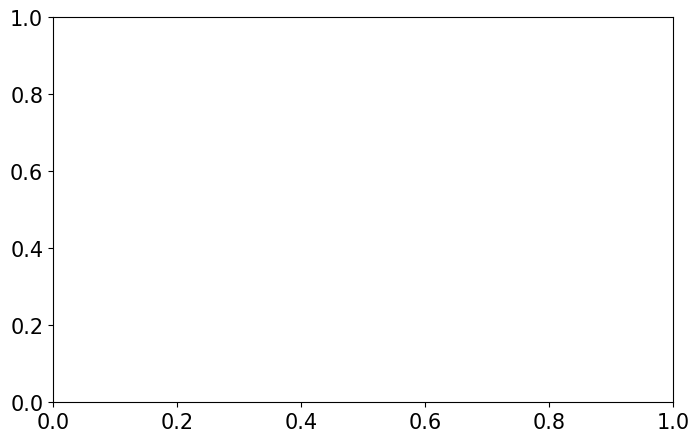

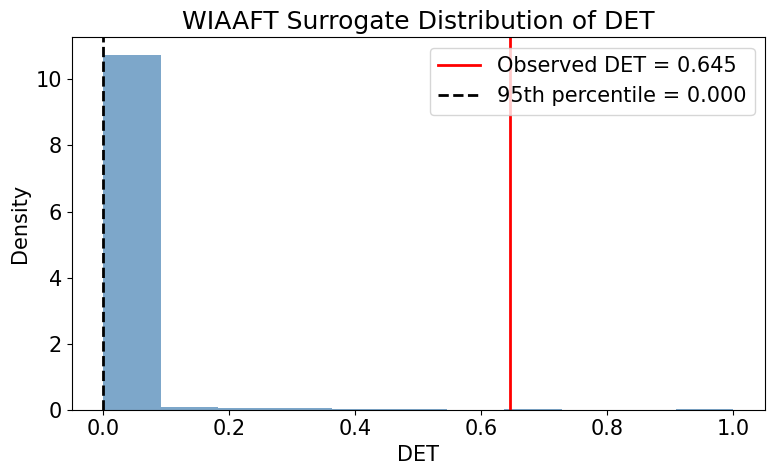

  9%|███▊                                       | 9/100 [04:52<45:48, 30.20s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.6450492182957585 
 Recurrence rate: 0.050007379677709345 
Threshold:0.6215999999999479 
 Laminarity:0.6396565602343985 
Shannon Entropy:1.0508931732553823 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

9
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


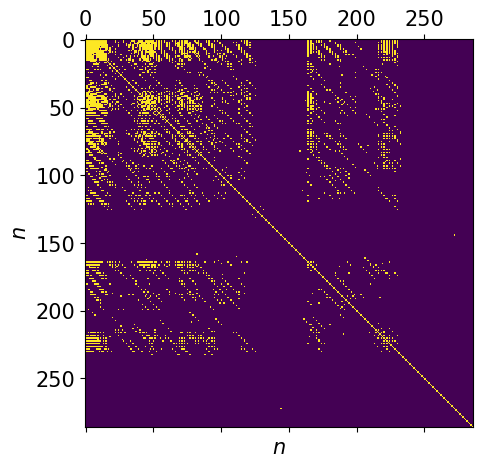

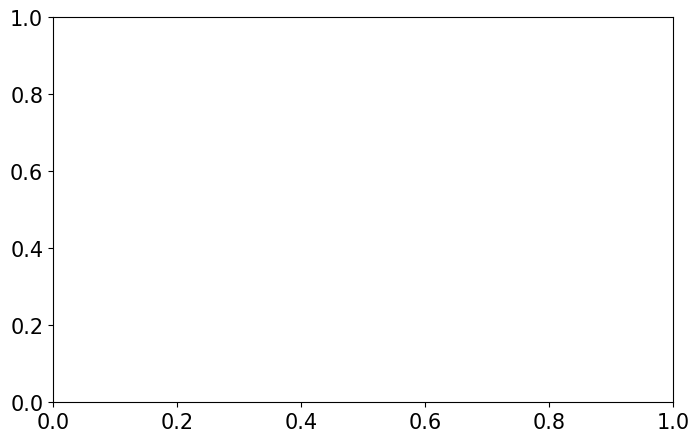

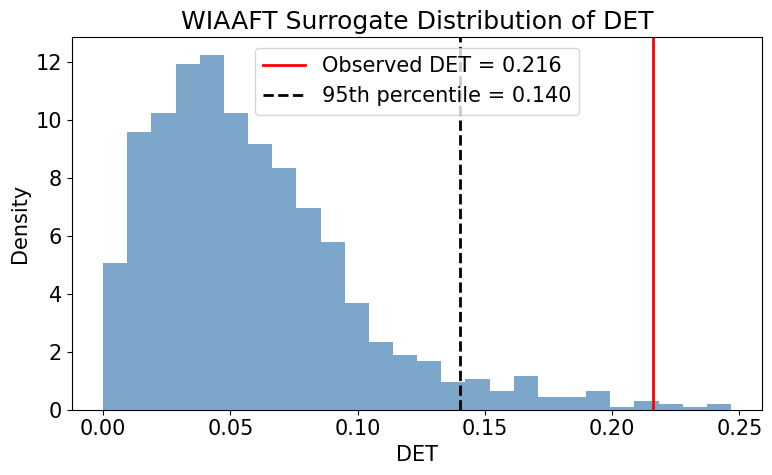

 10%|████▏                                     | 10/100 [05:23<45:41, 30.46s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.21586134453724826 
 Recurrence rate: 0.05005134725414446 
Threshold:1.5824999999998421 
 Laminarity:0.37225207620817724 
Shannon Entropy:2.160541995675194 
Rank-order p-value (det):0.007 
Reject null (det) hypothesis:True

 
 

10
No saturation detected (minimum FNN fallback)
9


Not enough points found!


WIAAFT surrogate datasets generated


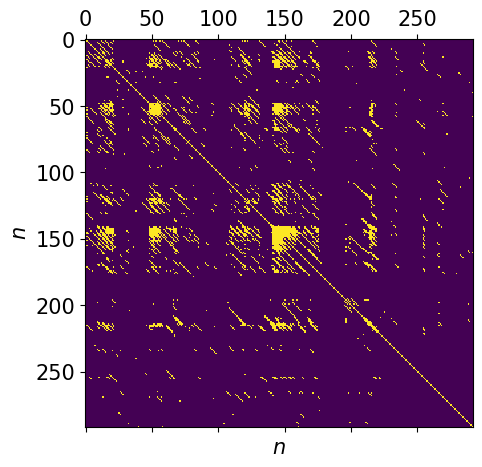

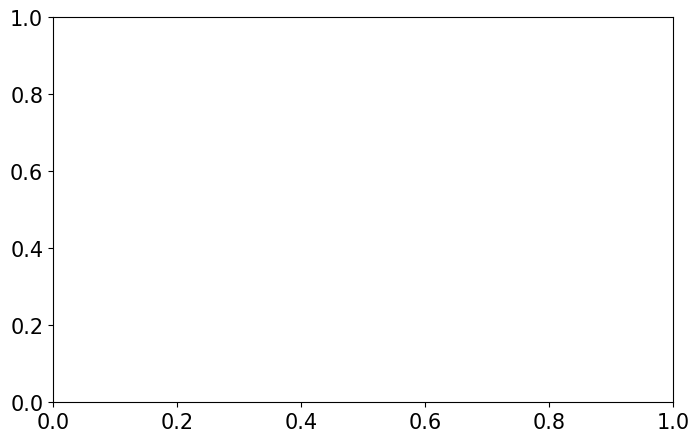

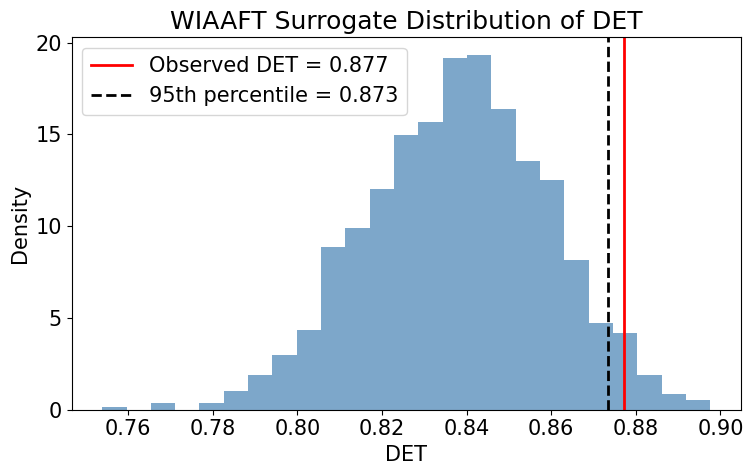

 11%|████▌                                     | 11/100 [06:03<49:26, 33.33s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8771399798568048 
 Recurrence rate: 0.0500093826233815 
Threshold:2.426800000000697 
 Laminarity:0.4455909943704372 
Shannon Entropy:1.9896426803351748 
Rank-order p-value (det):0.028 
Reject null (det) hypothesis:True

 
 

11
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


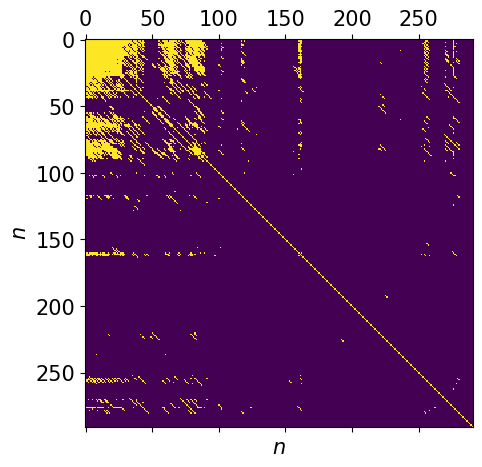

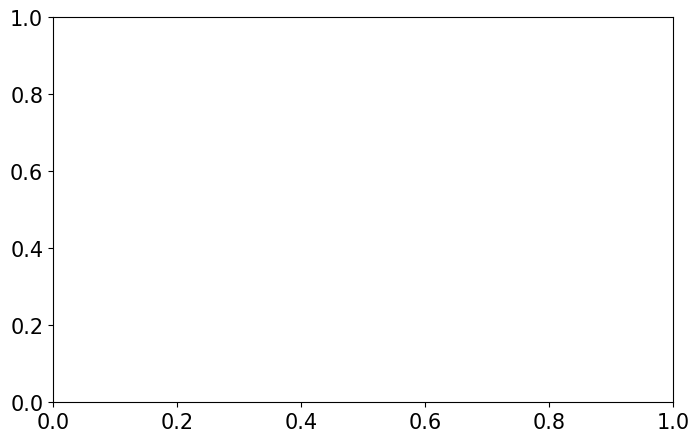

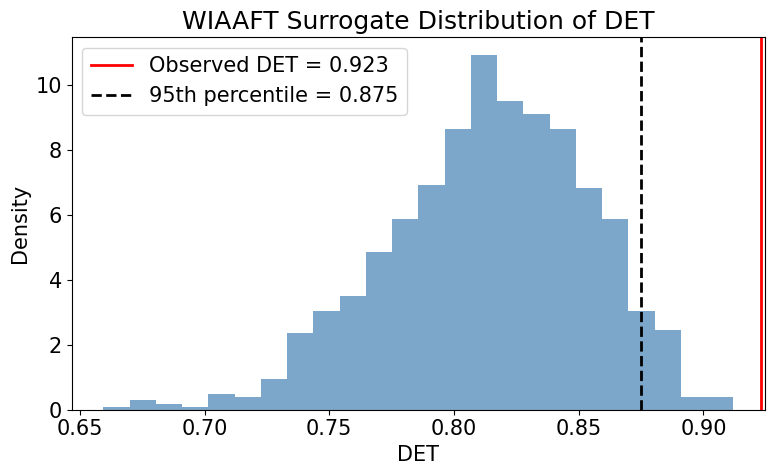

 12%|█████                                     | 12/100 [06:39<50:19, 34.31s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.922920892492589 
 Recurrence rate: 0.050011218573233665 
Threshold:2.1200000000000494 
 Laminarity:0.6479338842959907 
Shannon Entropy:2.4448441783898818 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

12
No saturation detected (minimum FNN fallback)
7
WIAAFT surrogate datasets generated


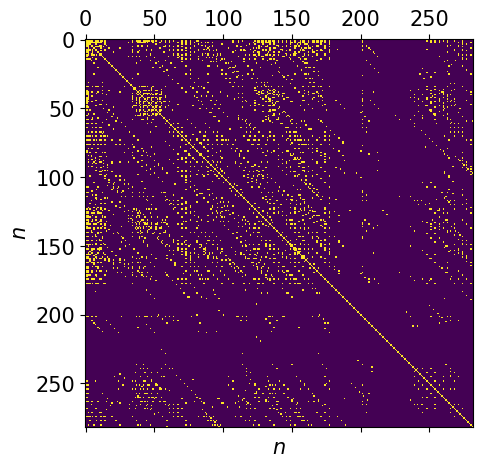

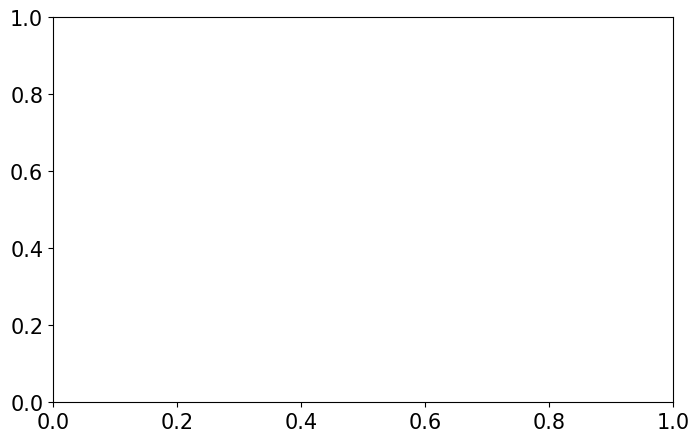

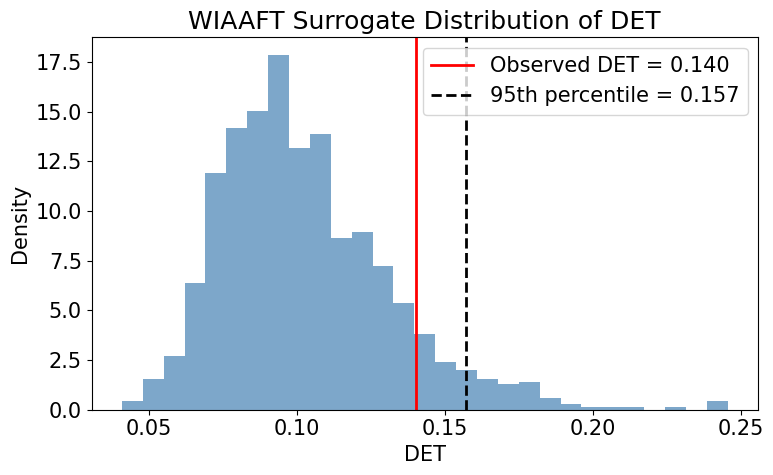

 13%|█████▍                                    | 13/100 [07:12<49:10, 33.92s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.14015151515113597 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9879999999997975 
 Laminarity:0.22699849170380343 
Shannon Entropy:0.2619479660140259 
Rank-order p-value (det):0.102 
Reject null (det) hypothesis:False

 
 

12
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


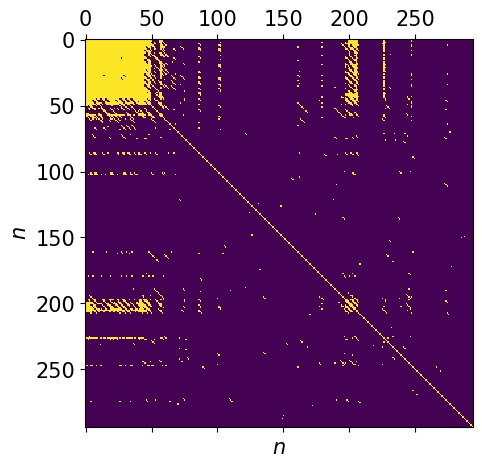

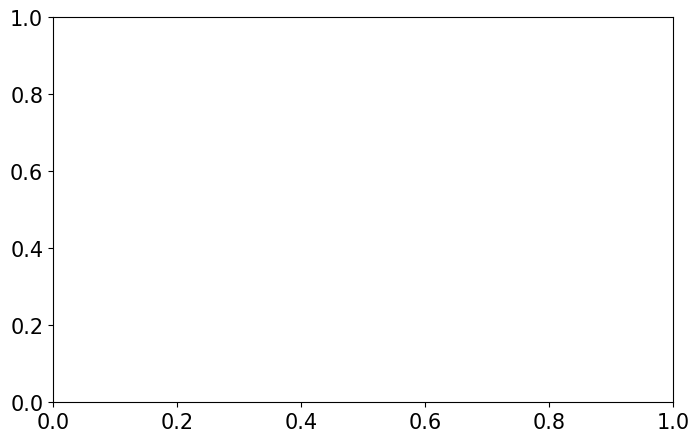

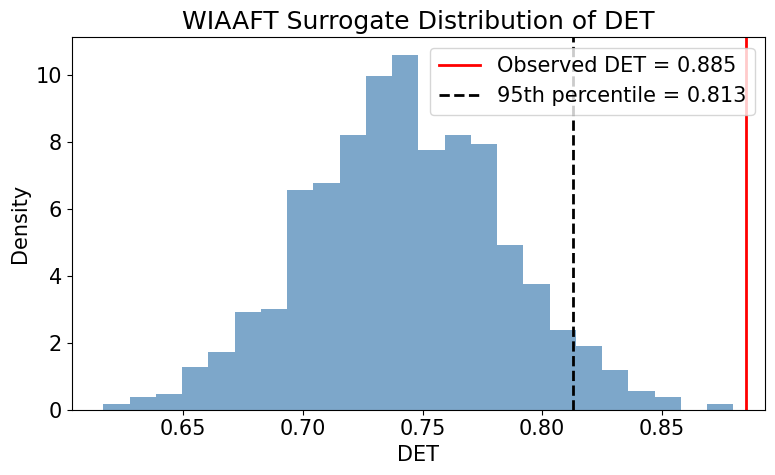

 14%|█████▉                                    | 14/100 [07:42<46:58, 32.77s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8853028798389143 
 Recurrence rate: 0.05000231385071035 
Threshold:1.5636999999998442 
 Laminarity:0.7561314206368438 
Shannon Entropy:2.4042634270437433 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

13
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


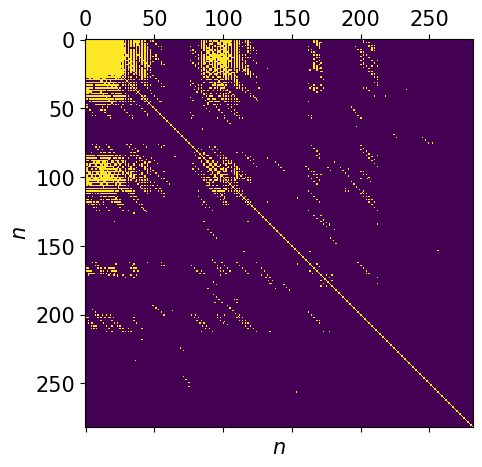

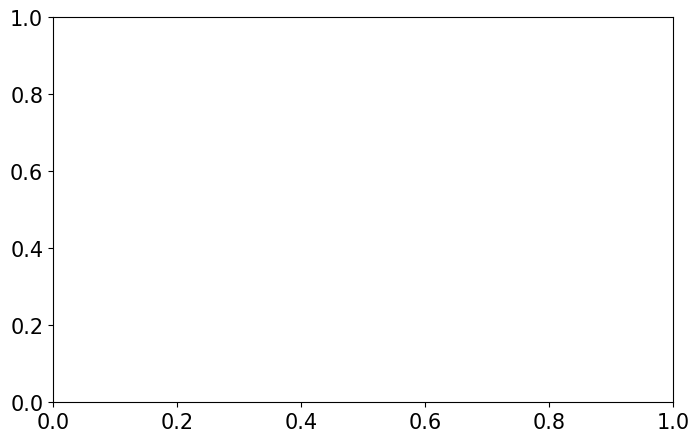

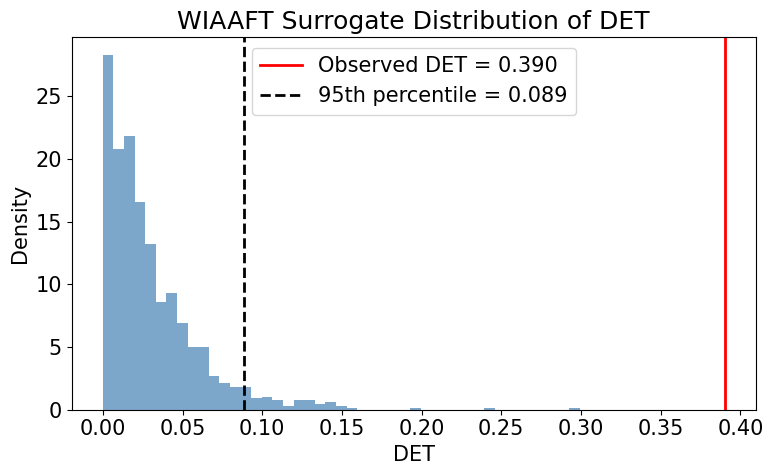

 15%|██████▎                                   | 15/100 [08:17<47:29, 33.52s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.39015151515045954 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9811999999997982 
 Laminarity:0.5480140774244645 
Shannon Entropy:2.7321024294460297 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

14
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


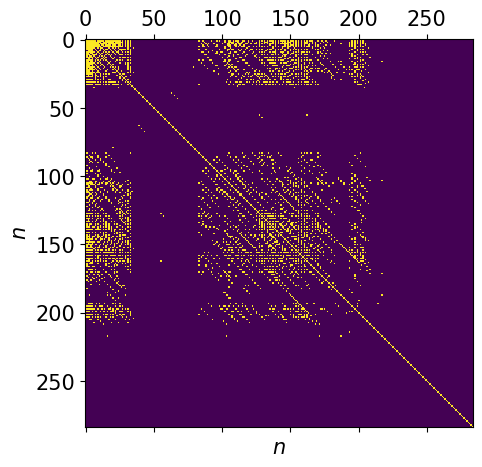

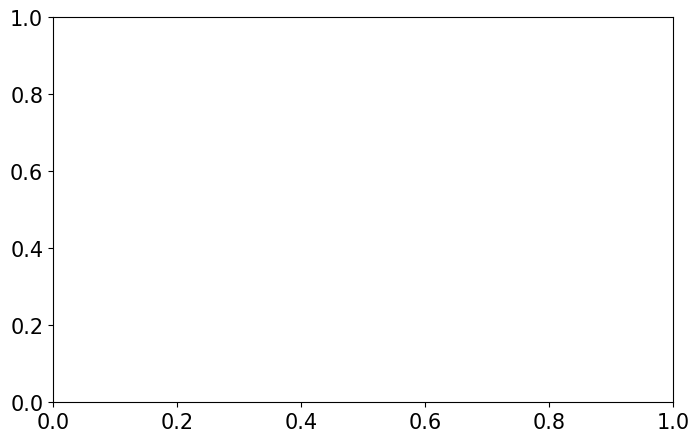

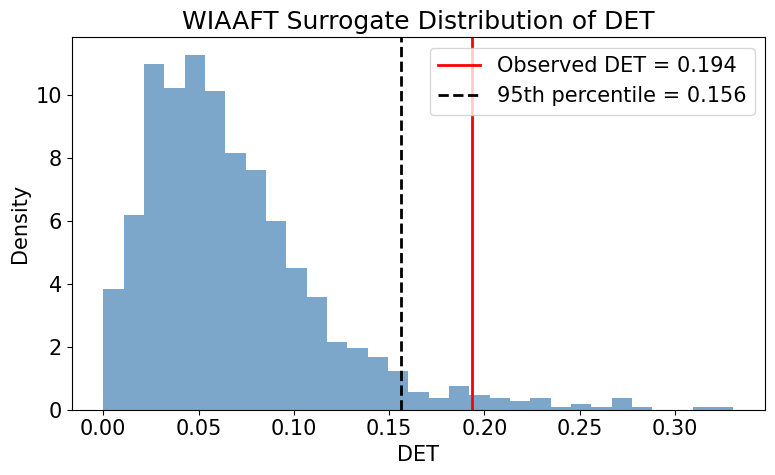

 16%|██████▋                                   | 16/100 [08:50<46:21, 33.11s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.19359999999948374 
 Recurrence rate: 0.050014878000396744 
Threshold:1.5775999999998427 
 Laminarity:0.30788299454559276 
Shannon Entropy:1.934487701257519 
Rank-order p-value (det):0.026 
Reject null (det) hypothesis:True

 
 

15
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


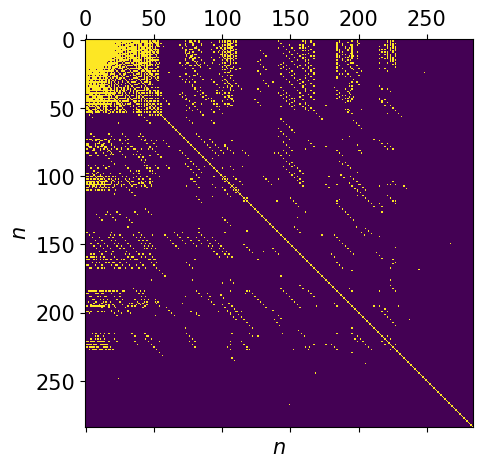

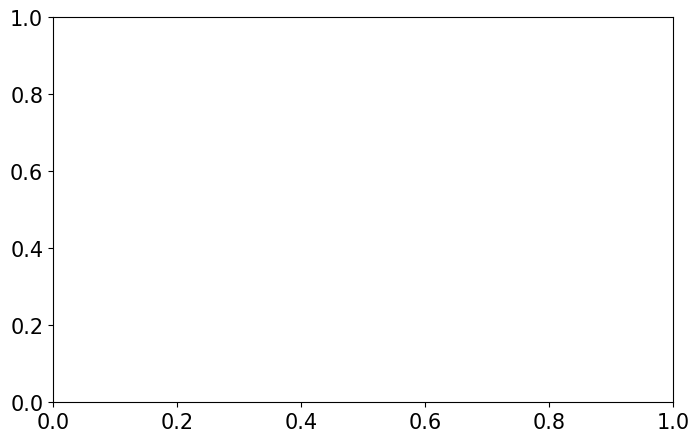

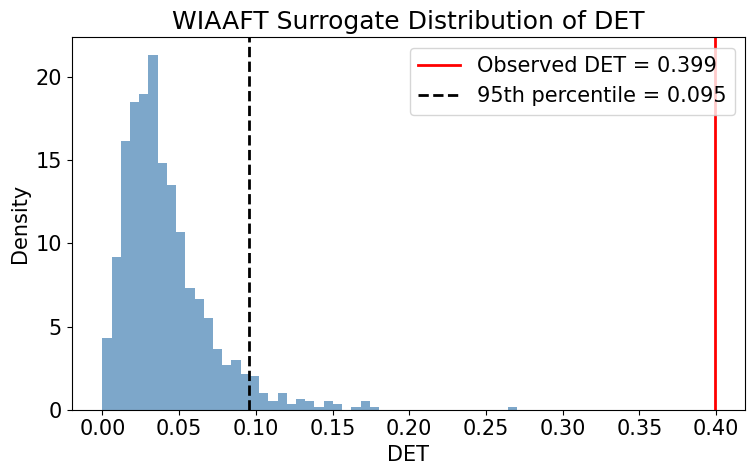

 17%|███████▏                                  | 17/100 [09:26<47:00, 33.98s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.39893333333226955 
 Recurrence rate: 0.050014878000396744 
Threshold:2.1873000000001914 
 Laminarity:0.469757064946778 
Shannon Entropy:2.7304237347090616 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

16
No saturation detected (minimum FNN fallback)
5
WIAAFT surrogate datasets generated


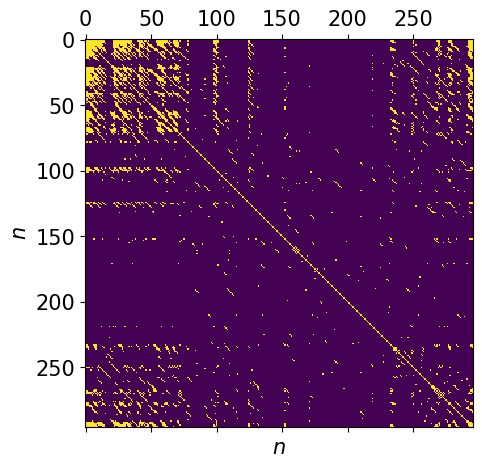

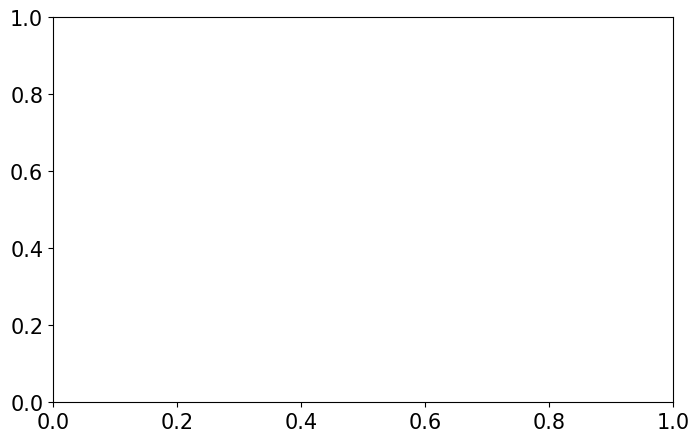

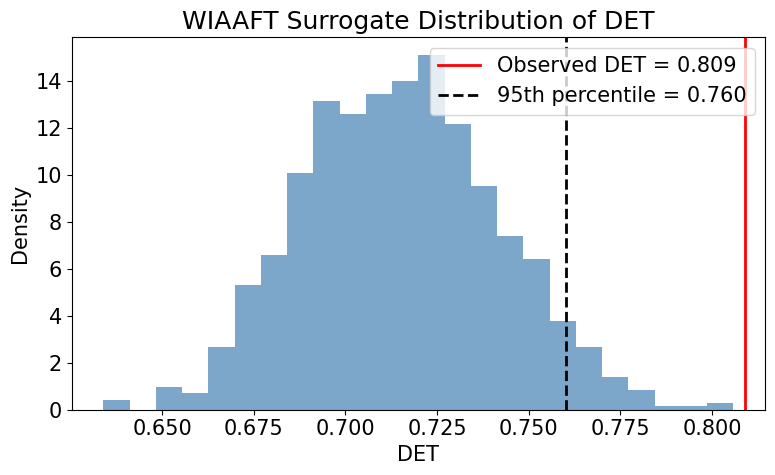

 18%|███████▌                                  | 18/100 [09:53<43:46, 32.03s/it]

RQA  ig Embedding dimensions:5 
 DET of original:0.8091042584414854 
 Recurrence rate: 0.05001369612856099 
Threshold:1.3181999999998713 
 Laminarity:0.5230488361466841 
Shannon Entropy:1.6994978820722233 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

17
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


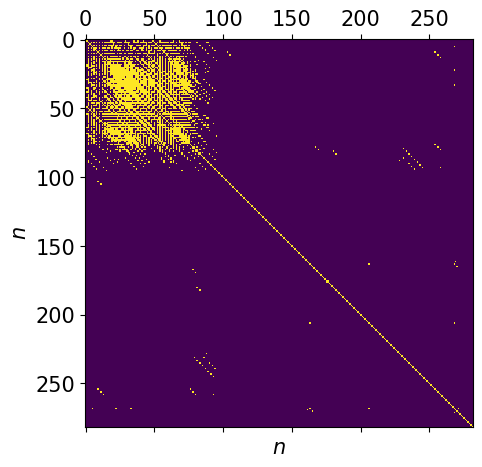

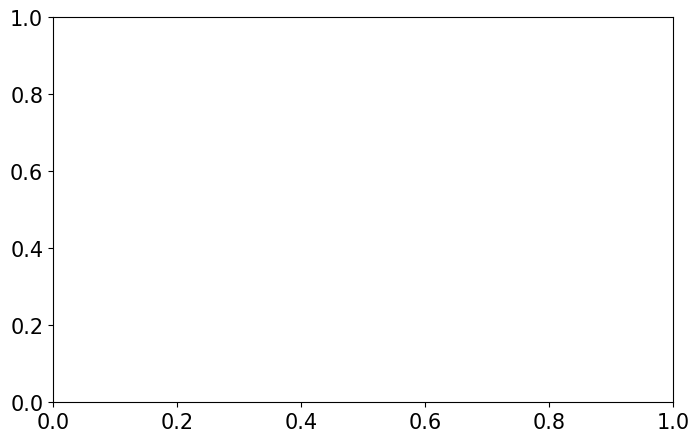

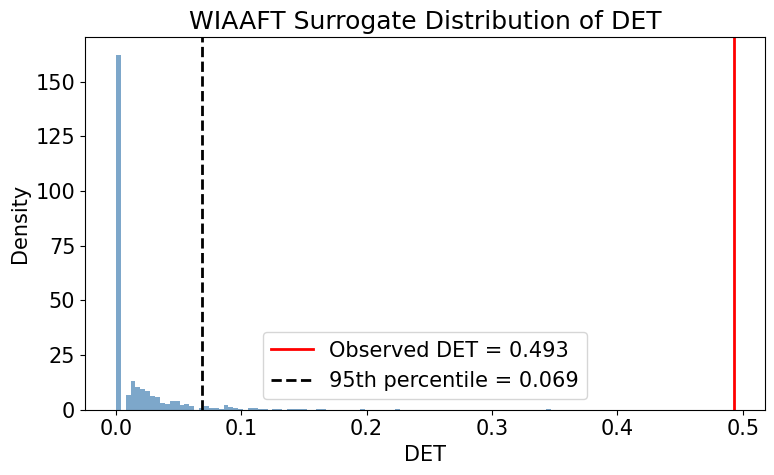

 19%|███████▉                                  | 19/100 [10:28<44:12, 32.75s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.4929653679640342 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9078999999998063 
 Laminarity:0.665158371039052 
Shannon Entropy:2.799125357156913 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

18
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


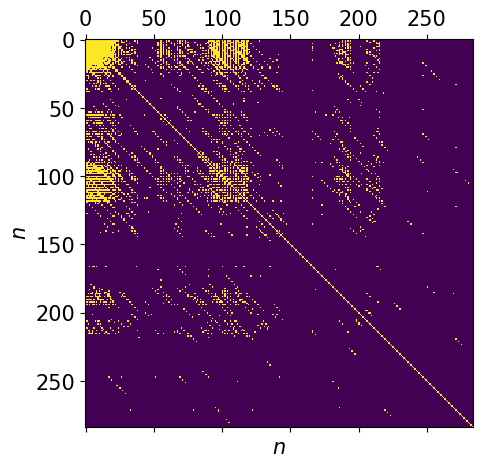

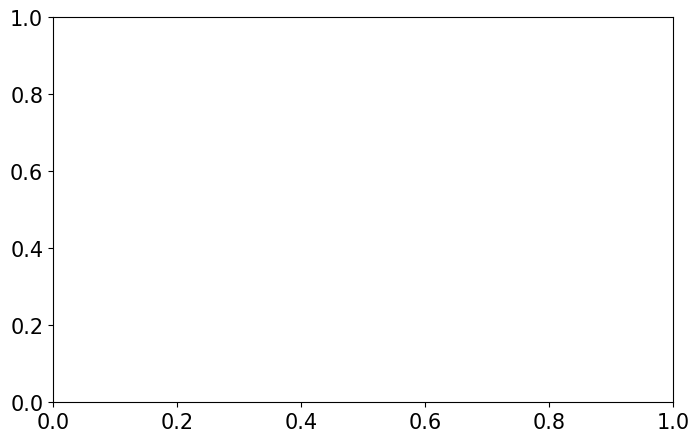

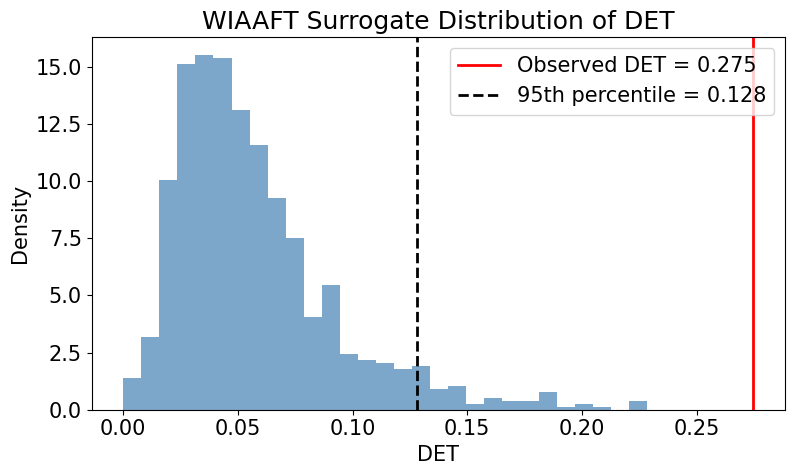

 20%|████████▍                                 | 20/100 [11:04<45:06, 33.84s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.27466666666593426 
 Recurrence rate: 0.050014878000396744 
Threshold:2.206000000000231 
 Laminarity:0.42736737729195 
Shannon Entropy:2.454379241549576 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

19
No saturation detected (minimum FNN fallback)
6
WIAAFT surrogate datasets generated


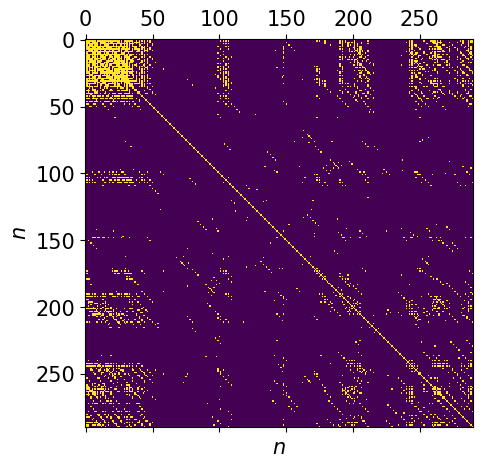

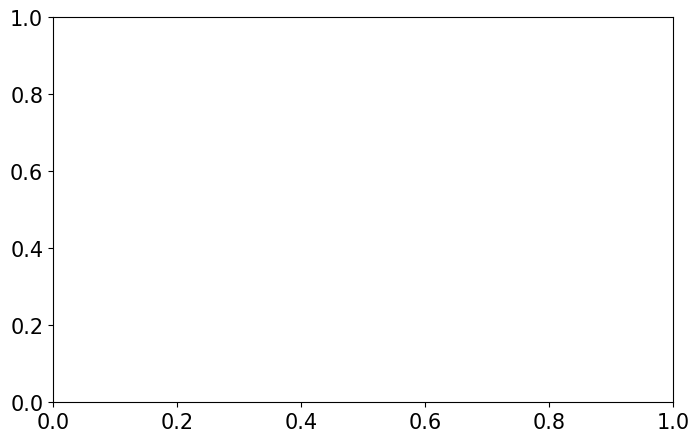

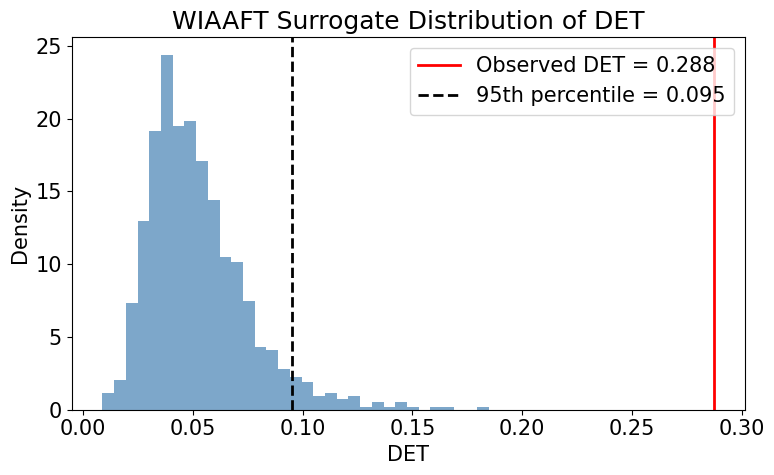

 21%|████████▊                                 | 21/100 [11:33<42:44, 32.46s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.28753830439150274 
 Recurrence rate: 0.05001189060642093 
Threshold:1.5710999999998434 
 Laminarity:0.42201616737893005 
Shannon Entropy:2.0546070020405502 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

20
No saturation detected (minimum FNN fallback)
6


Not enough points found!


WIAAFT surrogate datasets generated


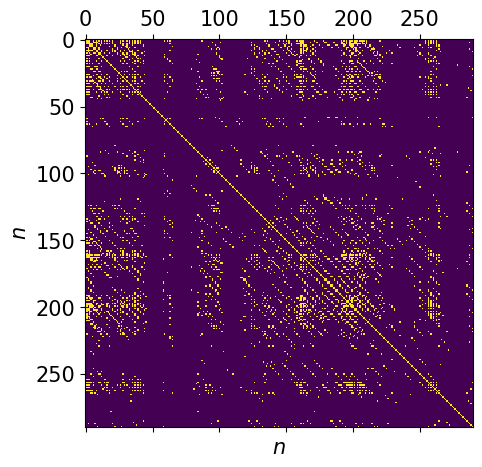

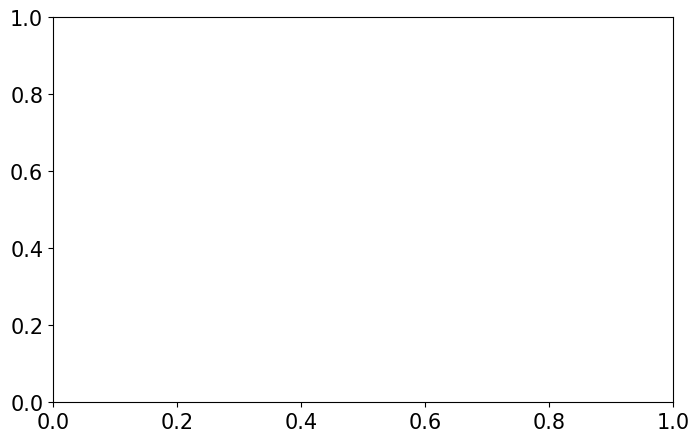

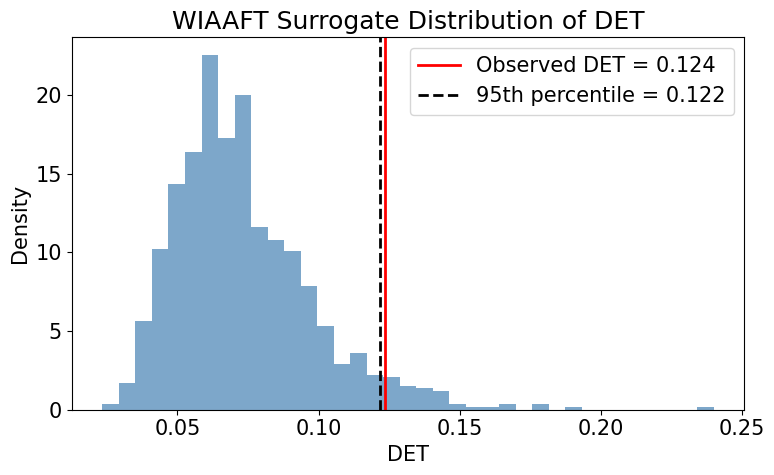

 22%|█████████▏                                | 22/100 [12:03<41:15, 31.73s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.12353241449687716 
 Recurrence rate: 0.05003567181926278 
Threshold:1.628399999999837 
 Laminarity:0.23574144486635992 
Shannon Entropy:1.5845594842459412 
Rank-order p-value (det):0.046 
Reject null (det) hypothesis:True

 
 

21
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


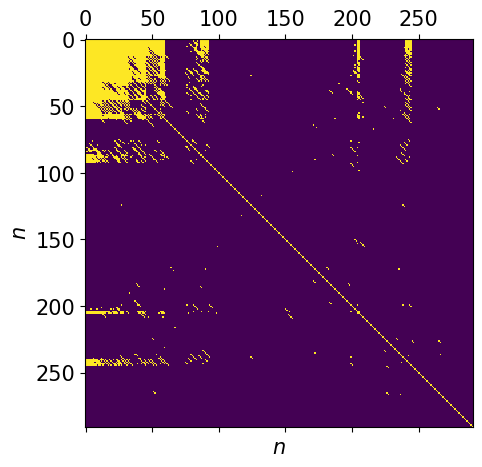

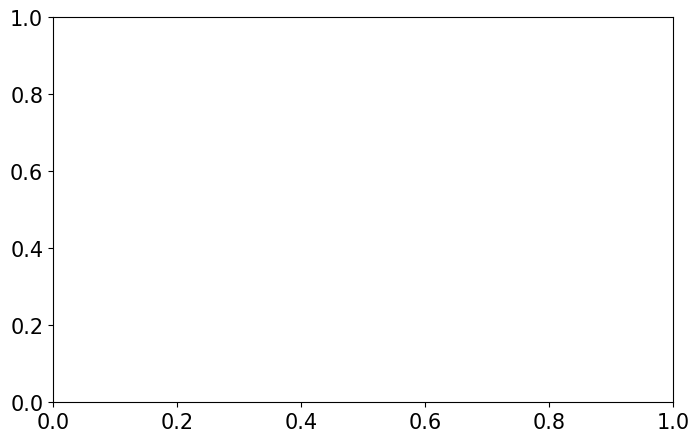

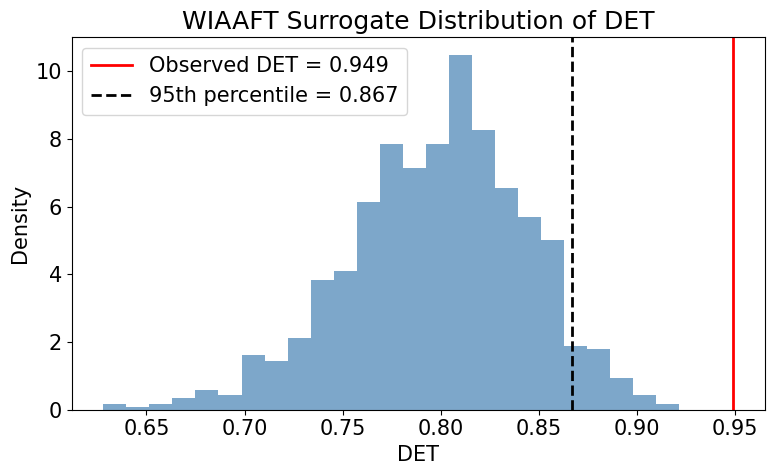

 23%|█████████▋                                | 23/100 [12:40<42:35, 33.19s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9492900608495201 
 Recurrence rate: 0.050011218573233665 
Threshold:2.02559999999985 
 Laminarity:0.7466351829970563 
Shannon Entropy:2.5235397918369995 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

22
No saturation detected (minimum FNN fallback)
7


Not enough points found!


WIAAFT surrogate datasets generated


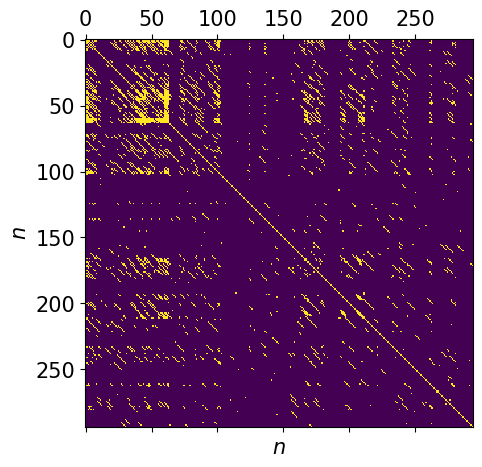

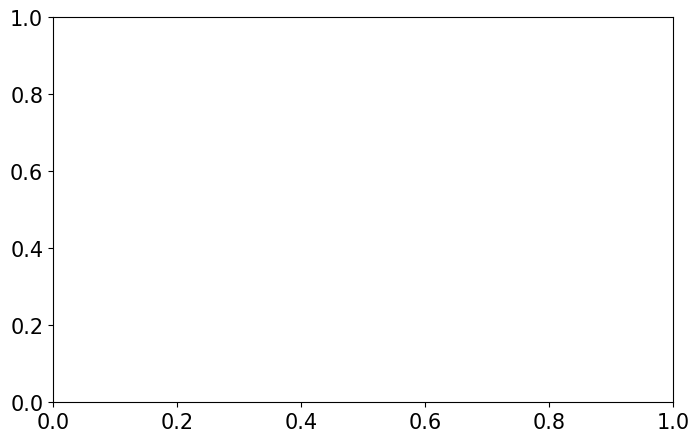

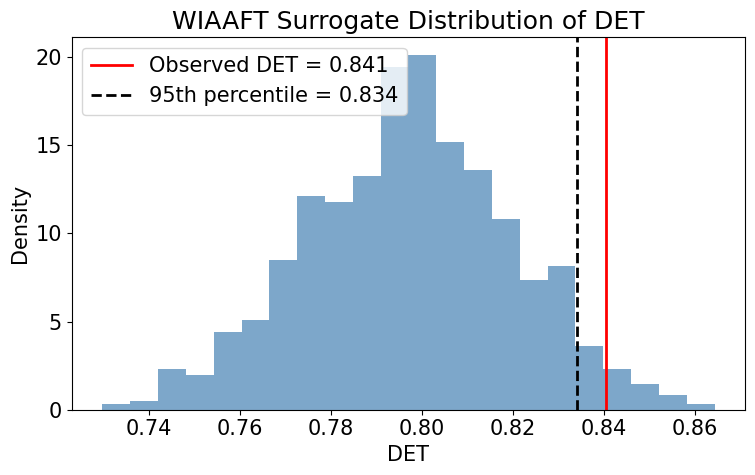

 24%|██████████                                | 24/100 [13:15<42:38, 33.66s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8406156901667313 
 Recurrence rate: 0.05000231385071035 
Threshold:1.9660999999998 
 Laminarity:0.2760296159179176 
Shannon Entropy:1.843775520441932 
Rank-order p-value (det):0.029 
Reject null (det) hypothesis:True

 
 

23
Visible Saturation Plateau
6


Not enough points found!


WIAAFT surrogate datasets generated


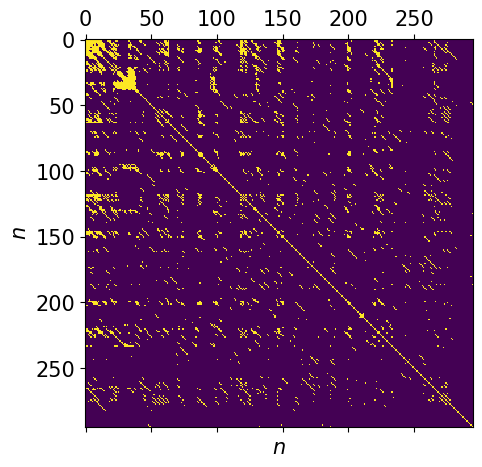

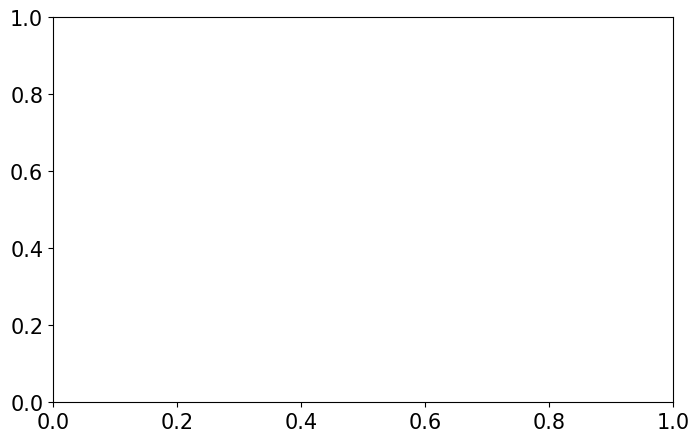

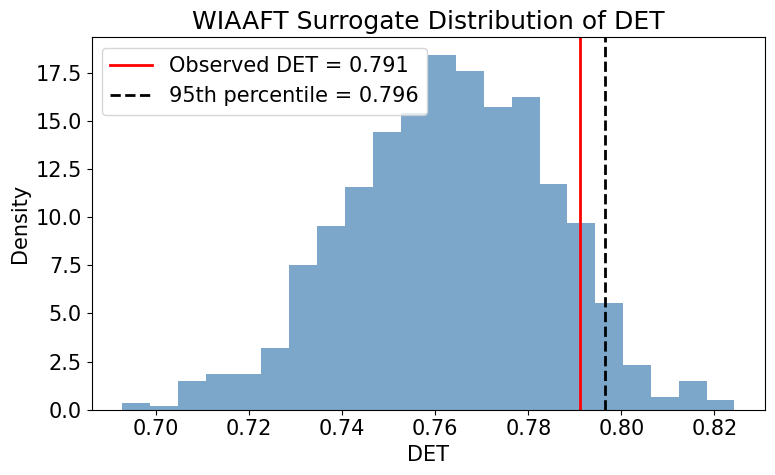

 25%|██████████▌                               | 25/100 [13:46<41:22, 33.10s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.7910300640690217 
 Recurrence rate: 0.05002010916403332 
Threshold:1.7137999999998277 
 Laminarity:0.4001837812993334 
Shannon Entropy:1.5869506083435818 
Rank-order p-value (det):0.093 
Reject null (det) hypothesis:False

 
 

23
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


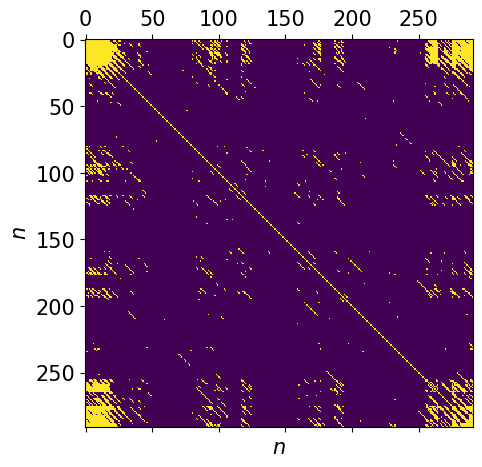

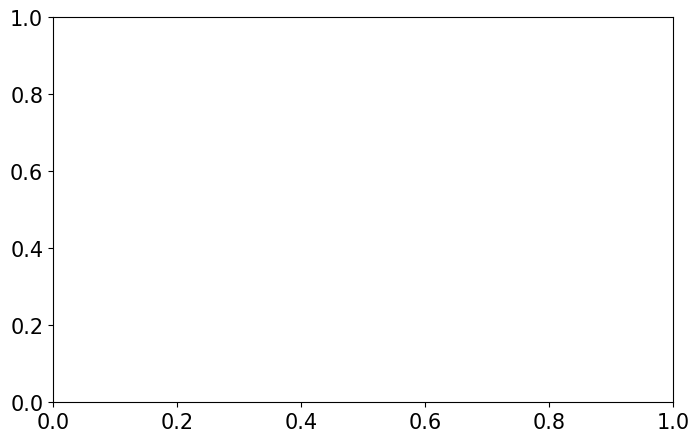

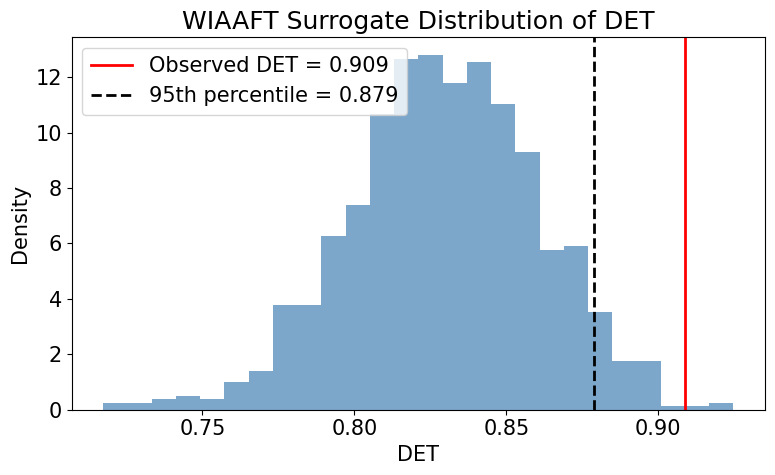

 26%|██████████▉                               | 26/100 [14:26<43:17, 35.10s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9087221095311645 
 Recurrence rate: 0.050011218573233665 
Threshold:2.3958000000006314 
 Laminarity:0.6044864226668135 
Shannon Entropy:2.2923515213105894 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

24
No saturation detected (minimum FNN fallback)
7
WIAAFT surrogate datasets generated


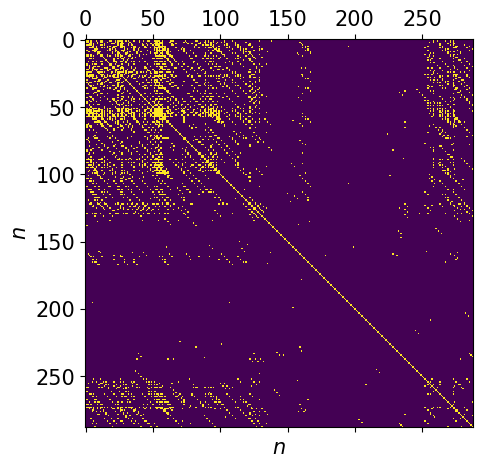

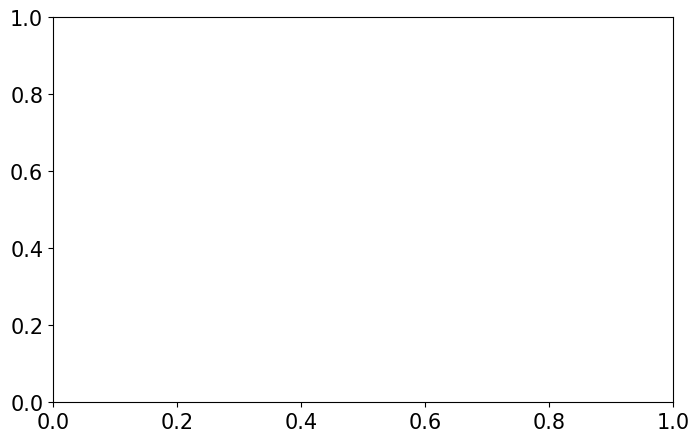

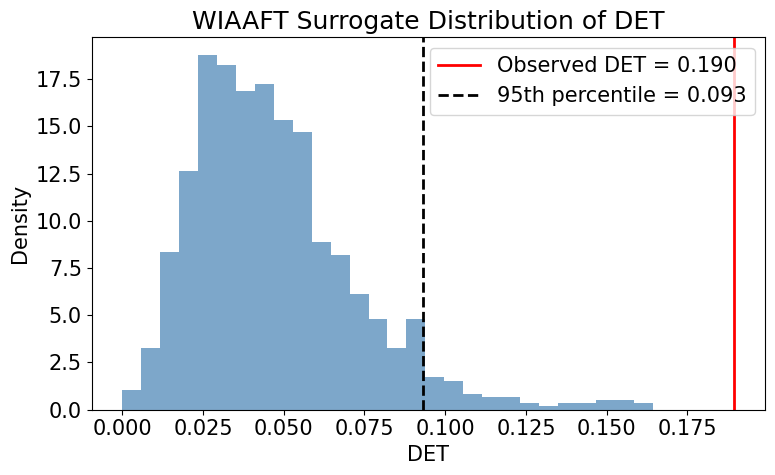

 27%|███████████▎                              | 27/100 [14:57<41:15, 33.90s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.1895390989119898 
 Recurrence rate: 0.050033757716049385 
Threshold:1.69219999999983 
 Laminarity:0.3650602409629758 
Shannon Entropy:1.7343216512324373 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

25
Visible Saturation Plateau
5
WIAAFT surrogate datasets generated


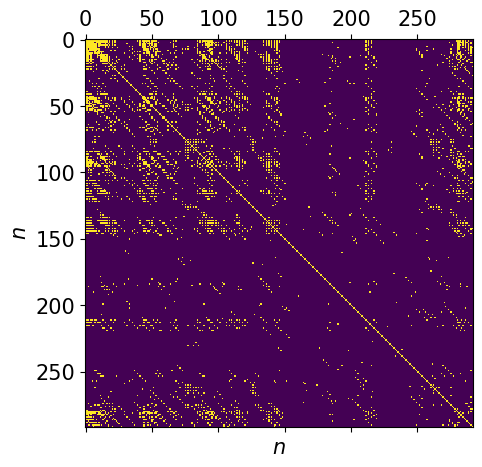

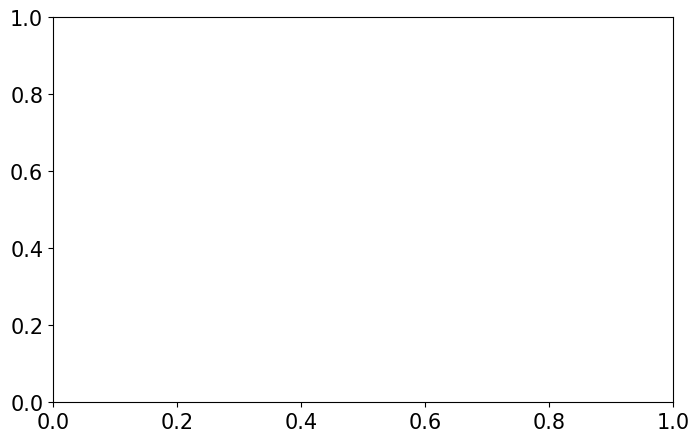

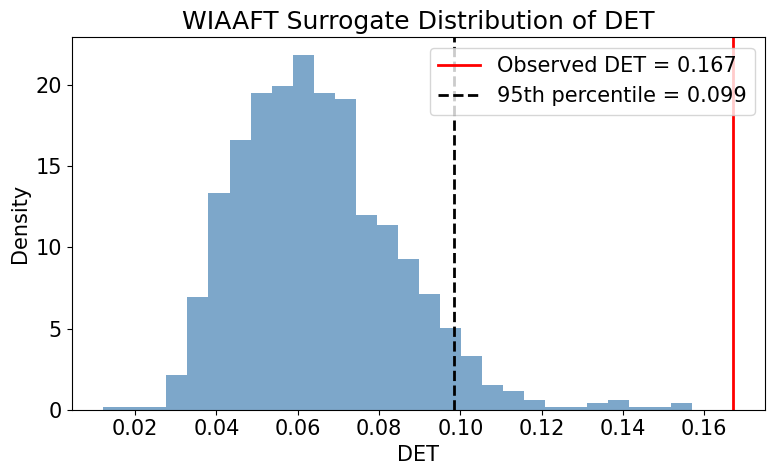

 28%|███████████▊                              | 28/100 [15:25<38:30, 32.08s/it]

RQA  ig Embedding dimensions:5 
 DET of original:0.16717019133895475 
 Recurrence rate: 0.0500093826233815 
Threshold:1.3551999999998672 
 Laminarity:0.2915103189486597 
Shannon Entropy:1.6022117662594244 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

26
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


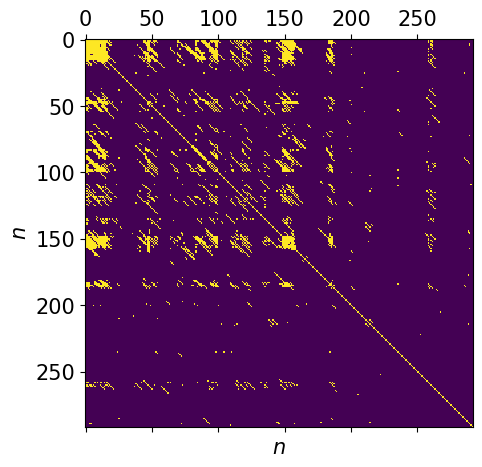

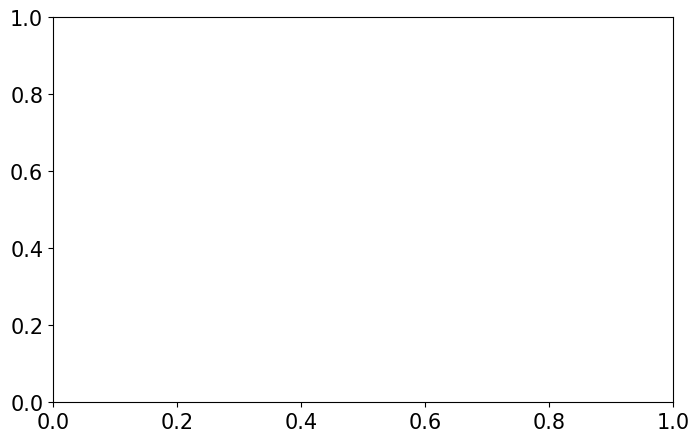

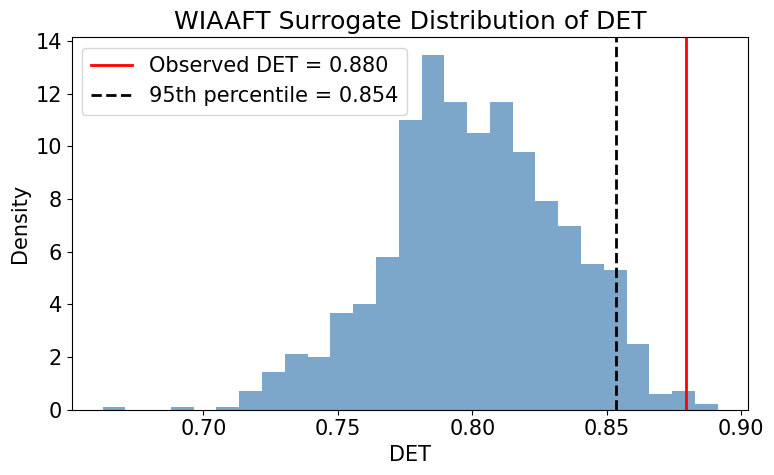

 29%|████████████▏                             | 29/100 [16:01<39:16, 33.19s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8796576032203433 
 Recurrence rate: 0.0500093826233815 
Threshold:2.0716999999999475 
 Laminarity:0.5229831144453025 
Shannon Entropy:2.1214472372963487 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

27
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


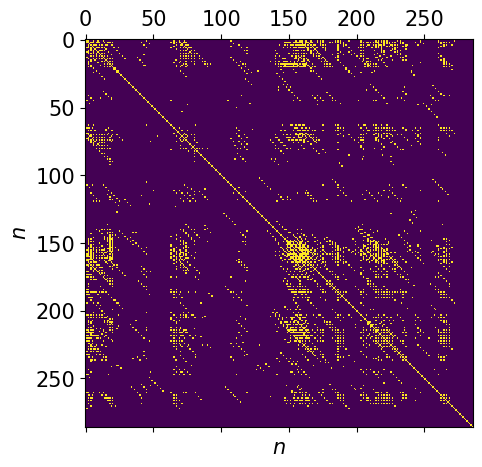

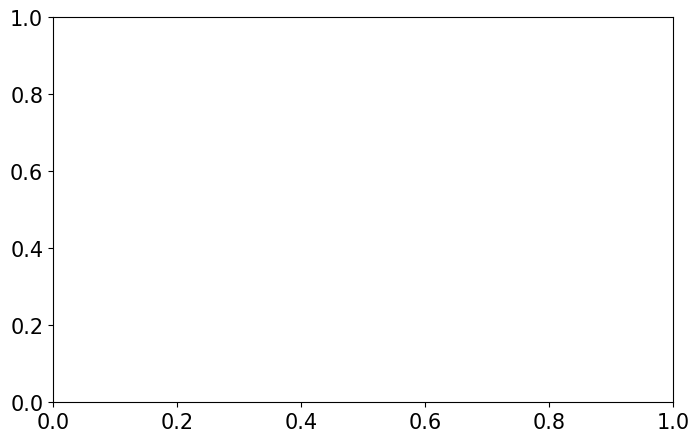

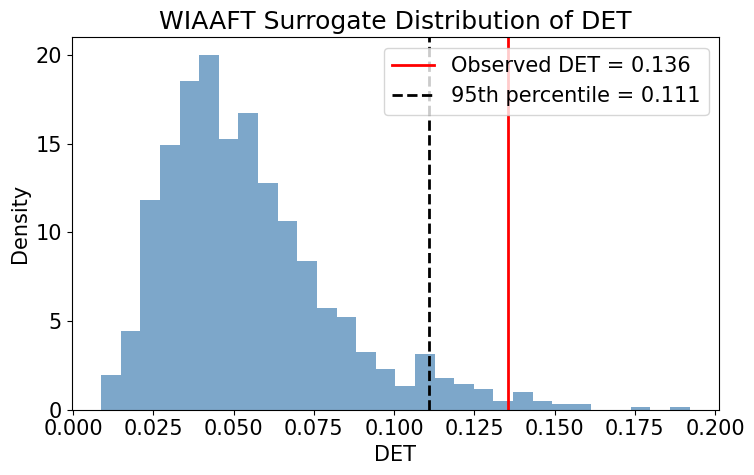

 30%|████████████▌                             | 30/100 [16:35<39:13, 33.62s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.13557540725135162 
 Recurrence rate: 0.05002689618074233 
Threshold:2.061899999999927 
 Laminarity:0.22531769305907792 
Shannon Entropy:1.8220385485328274 
Rank-order p-value (det):0.017 
Reject null (det) hypothesis:True

 
 

28
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


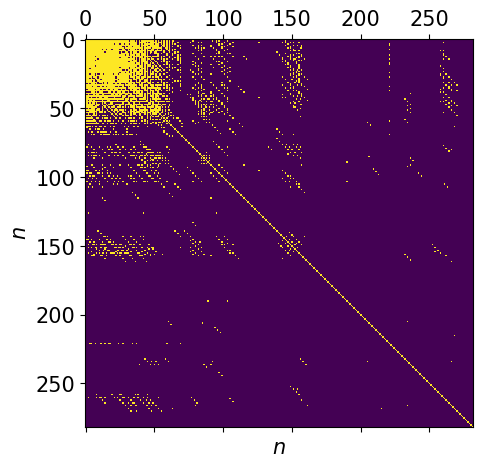

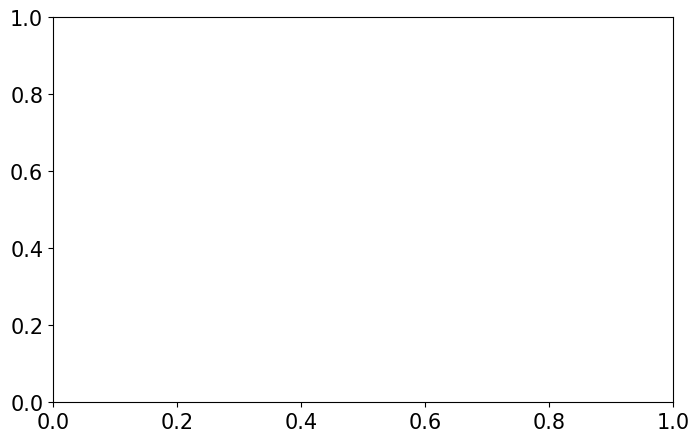

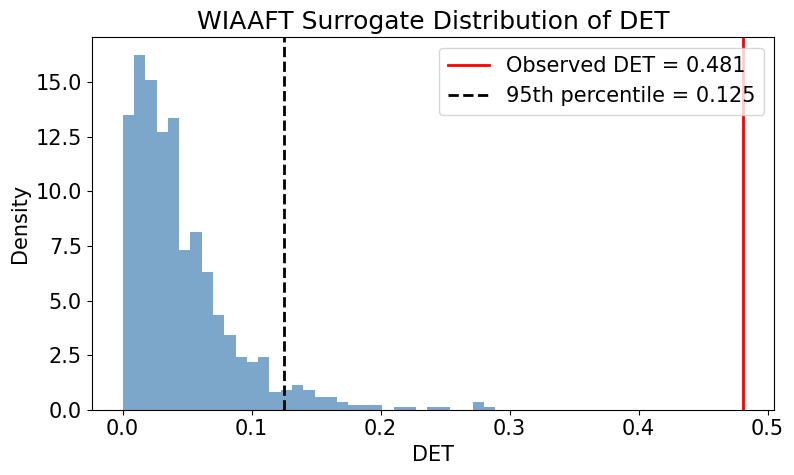

 31%|█████████████                             | 31/100 [17:10<38:53, 33.82s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.4810606060593045 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9954999999997967 
 Laminarity:0.584213172446998 
Shannon Entropy:2.7329134802532633 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

29
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


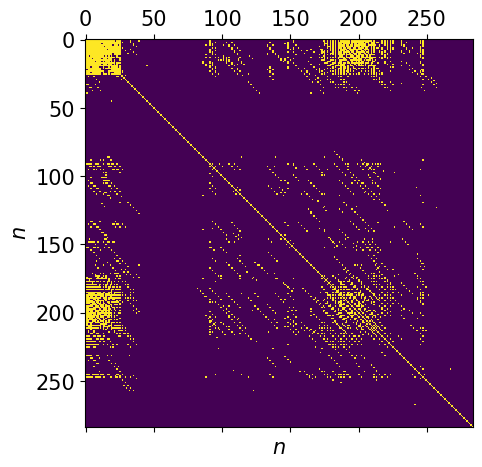

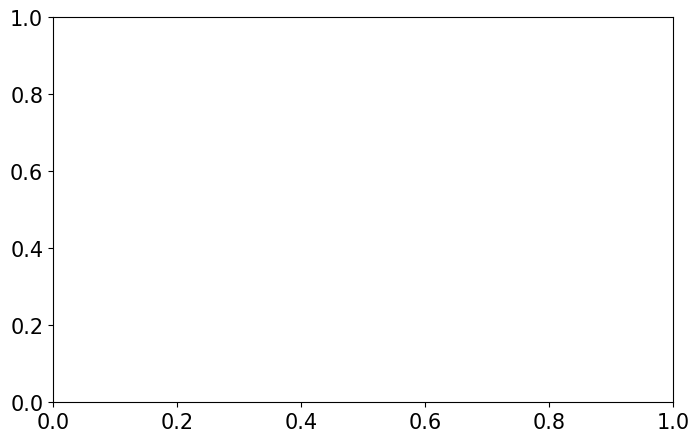

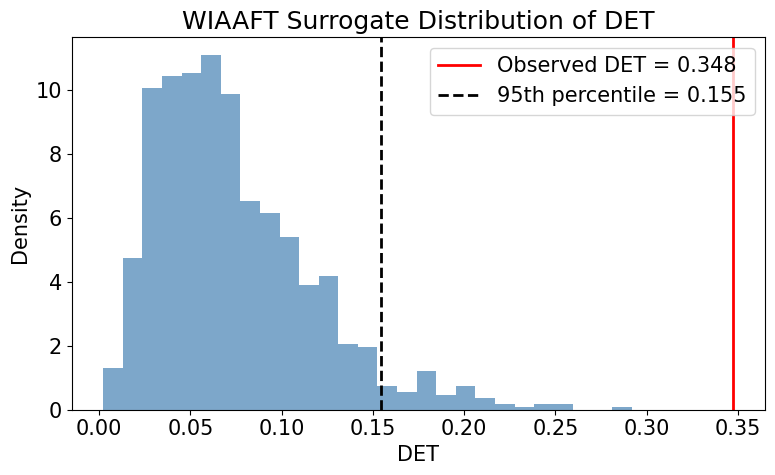

 32%|█████████████▍                            | 32/100 [17:44<38:32, 34.01s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.3475479744127198 
 Recurrence rate: 0.05003967466772466 
Threshold:1.9230999999998046 
 Laminarity:0.4717542120900105 
Shannon Entropy:2.4430937931753425 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

30
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


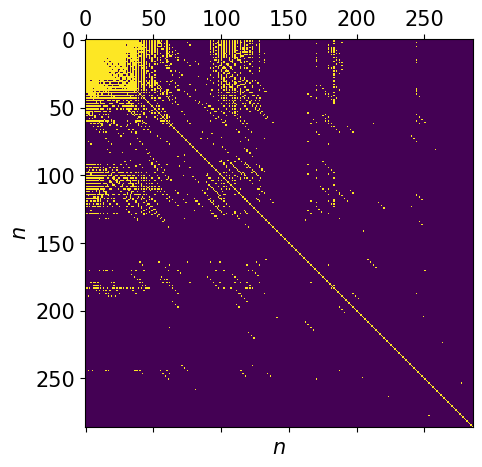

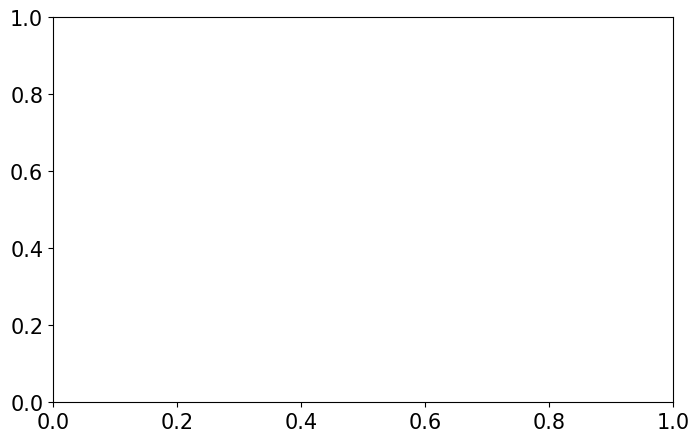

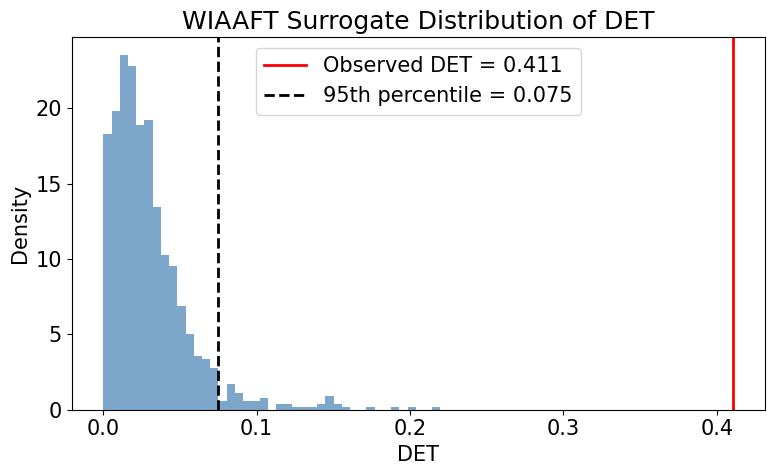

 33%|█████████████▊                            | 33/100 [18:16<37:07, 33.25s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.41093011035099597 
 Recurrence rate: 0.05002689618074233 
Threshold:1.7903999999998192 
 Laminarity:0.5303030303017343 
Shannon Entropy:2.8025756606392638 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

31
Visible Saturation Plateau
8
WIAAFT surrogate datasets generated


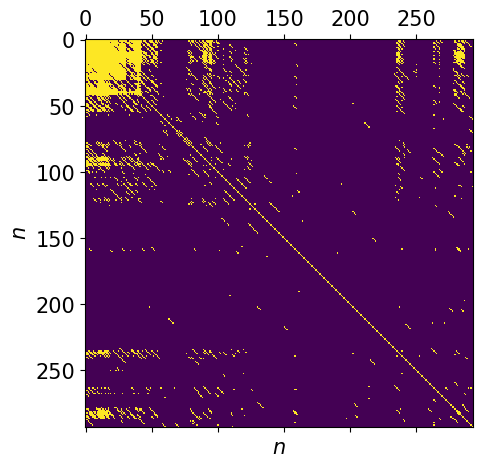

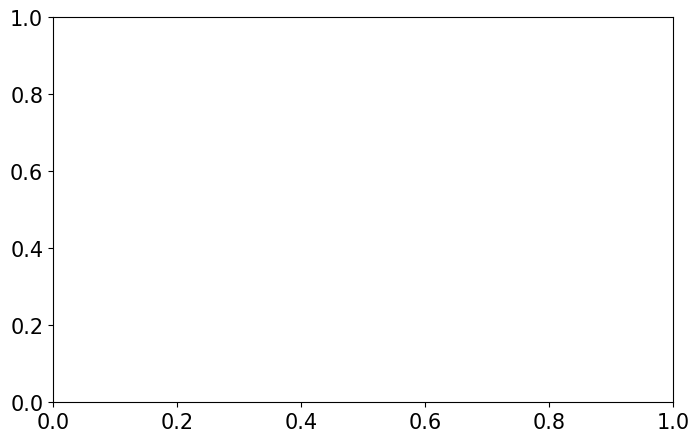

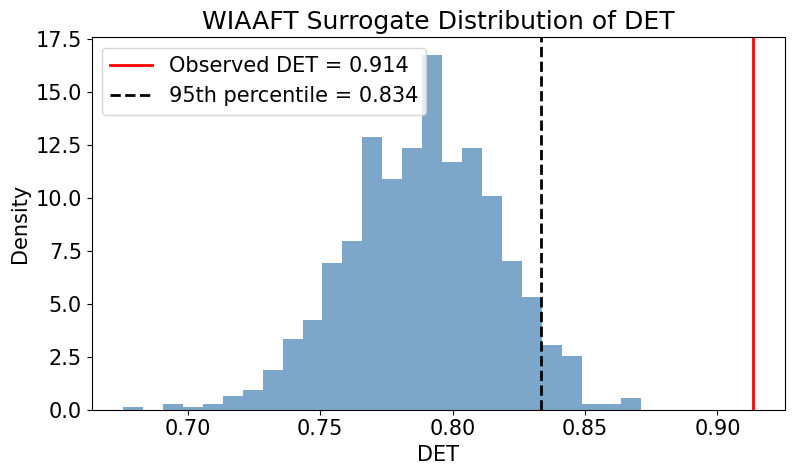

 34%|██████████████▎                           | 34/100 [18:48<36:25, 33.11s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.9135432283835244 
 Recurrence rate: 0.0500297033162879 
Threshold:1.882599999999809 
 Laminarity:0.5643771827693496 
Shannon Entropy:2.2729543566617374 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

32
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


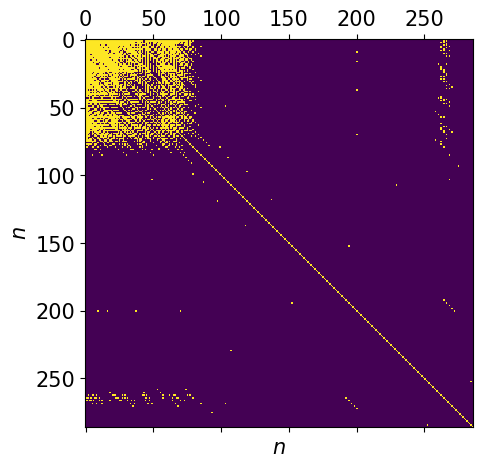

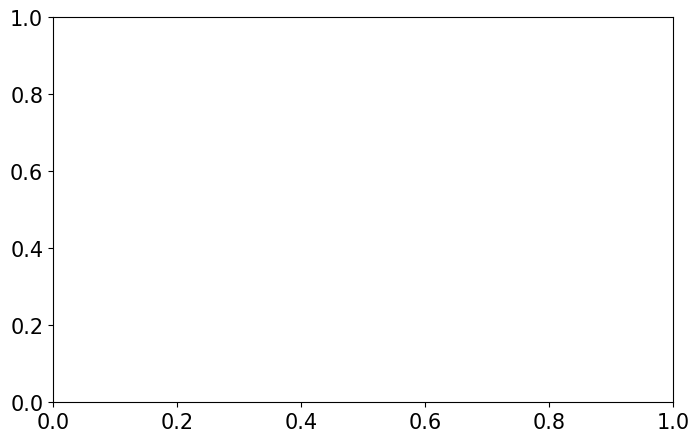

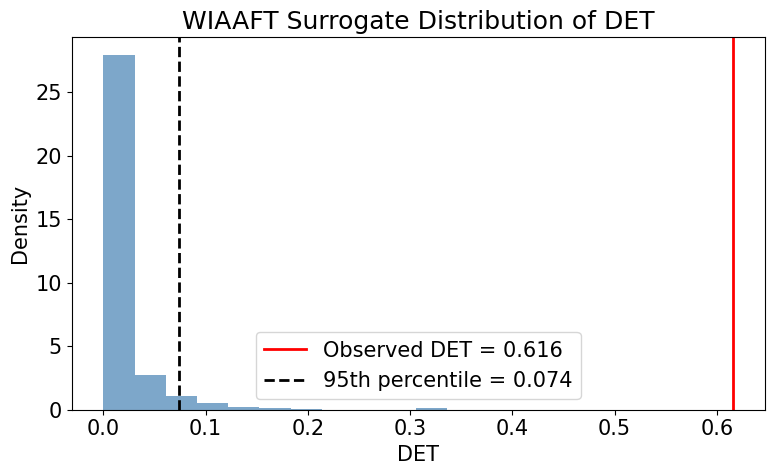

 35%|██████████████▋                           | 35/100 [19:16<34:03, 31.44s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.616193480545173 
 Recurrence rate: 0.05000244510734021 
Threshold:1.2794999999998755 
 Laminarity:0.7171149144236746 
Shannon Entropy:2.66721095670911 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

33
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


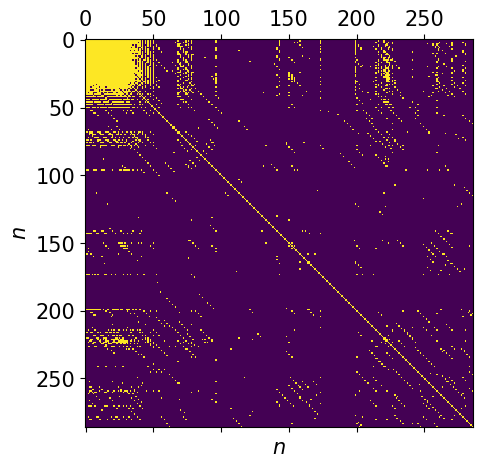

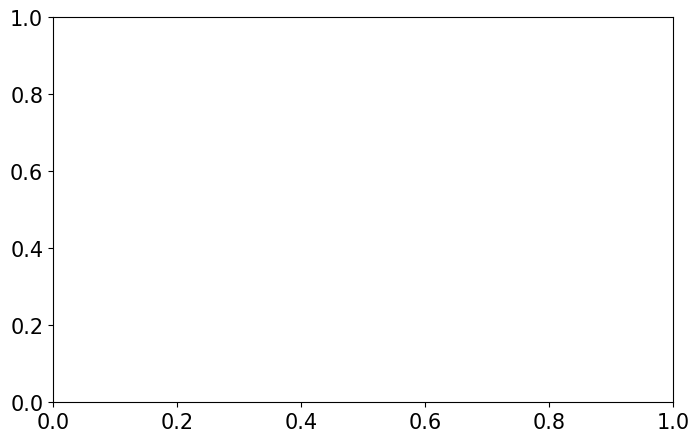

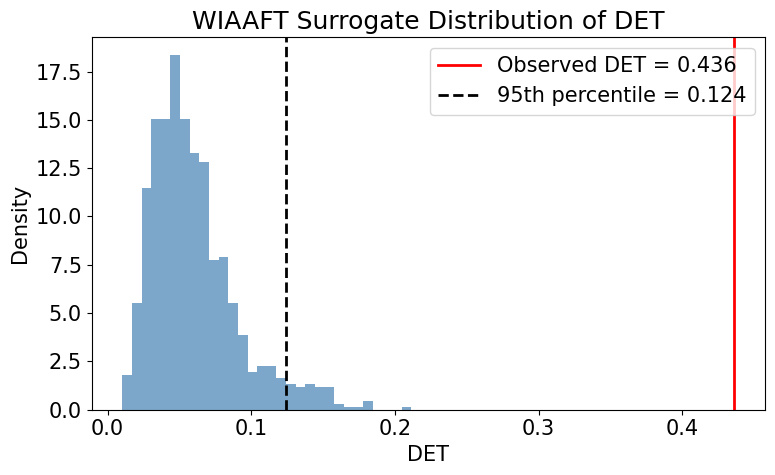

 36%|███████████████                           | 36/100 [19:51<34:34, 32.41s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.43638275499359525 
 Recurrence rate: 0.05000244510734021 
Threshold:2.0651999999999338 
 Laminarity:0.5398533007321764 
Shannon Entropy:2.7642358635914692 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

34
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


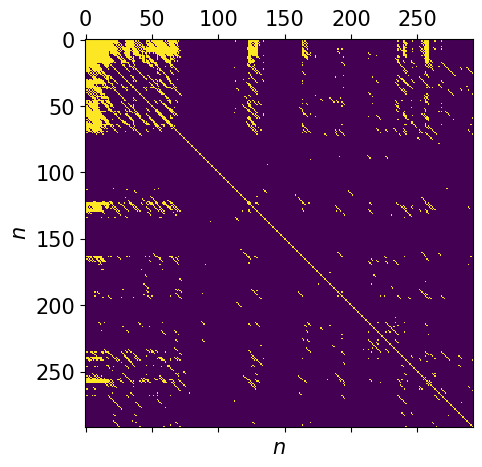

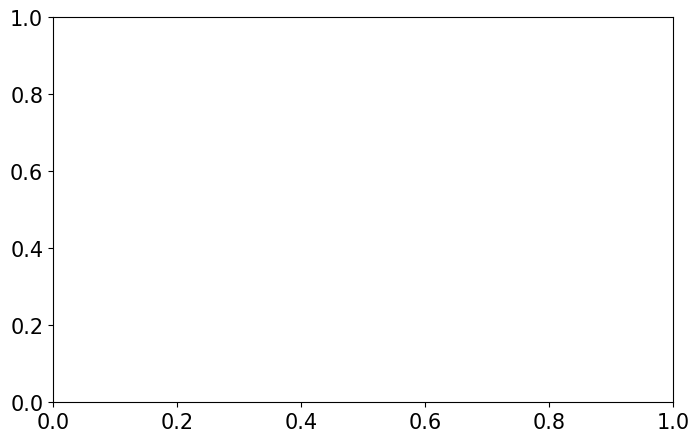

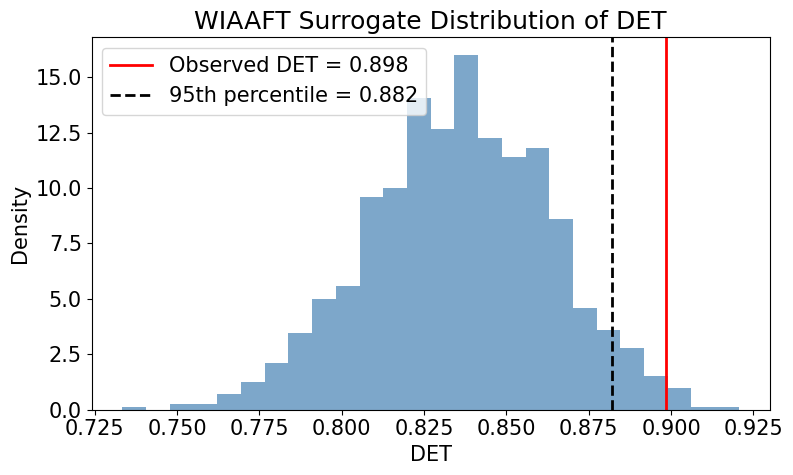

 37%|███████████████▌                          | 37/100 [20:29<35:48, 34.10s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.898288016110528 
 Recurrence rate: 0.0500093826233815 
Threshold:2.2424000000003077 
 Laminarity:0.5583958724189532 
Shannon Entropy:2.260783591079702 
Rank-order p-value (det):0.01 
Reject null (det) hypothesis:True

 
 

35
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


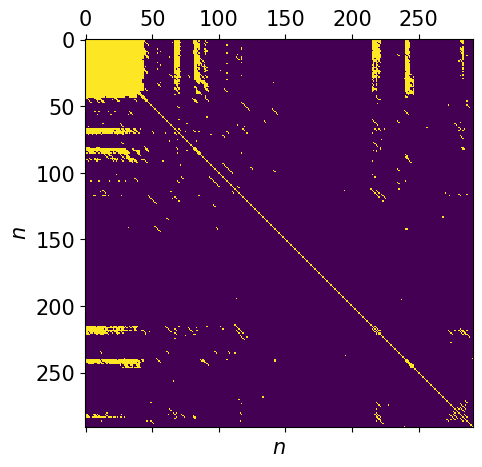

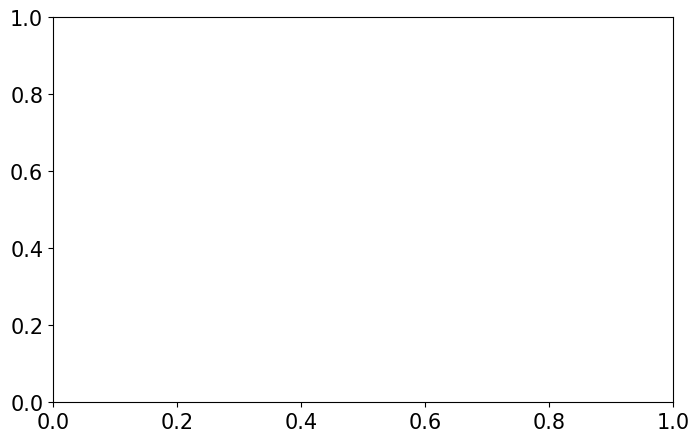

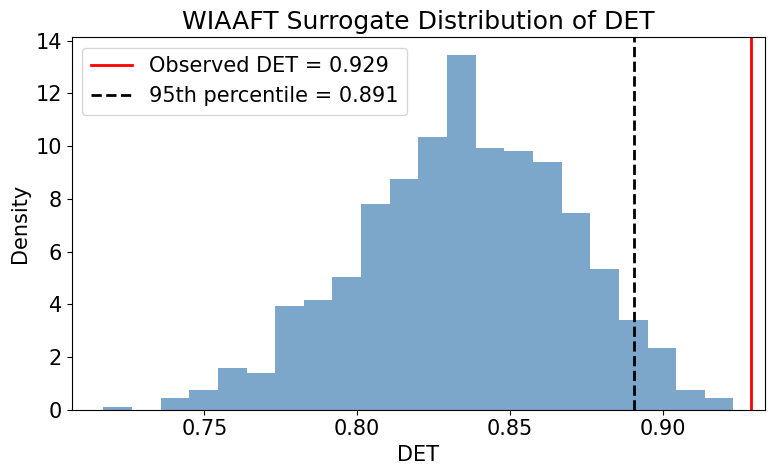

 38%|███████████████▉                          | 38/100 [21:05<35:59, 34.83s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9290060851903423 
 Recurrence rate: 0.050011218573233665 
Threshold:2.1162000000000414 
 Laminarity:0.8004722550158194 
Shannon Entropy:2.3020499834303054 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

36
No saturation detected (minimum FNN fallback)
7
WIAAFT surrogate datasets generated


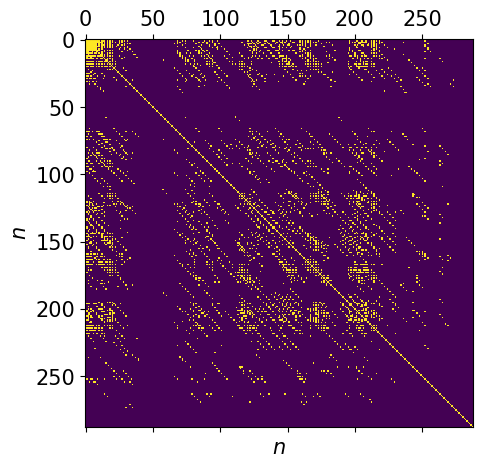

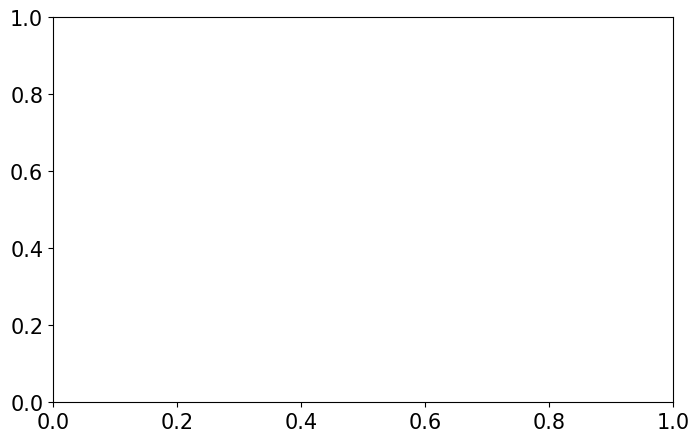

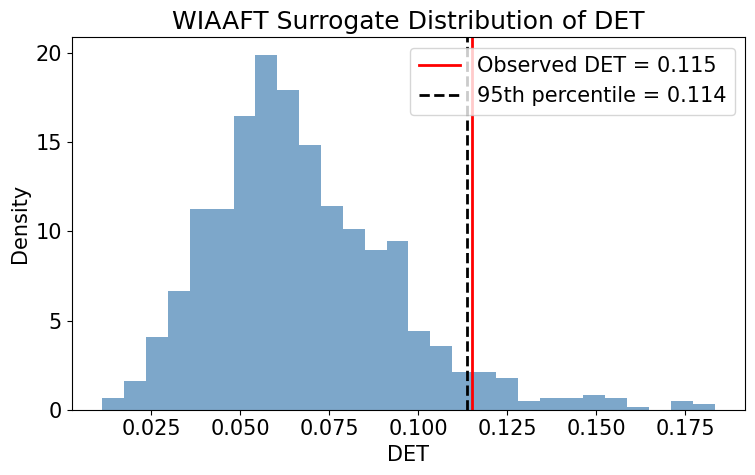

 39%|████████████████▍                         | 39/100 [21:37<34:36, 34.03s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.1150259067354533 
 Recurrence rate: 0.05000964506172839 
Threshold:1.6760999999998318 
 Laminarity:0.2287849566050415 
Shannon Entropy:1.6535359066374822 
Rank-order p-value (det):0.051 
Reject null (det) hypothesis:False

 
 

36
Visible Saturation Plateau
7
WIAAFT surrogate datasets generated


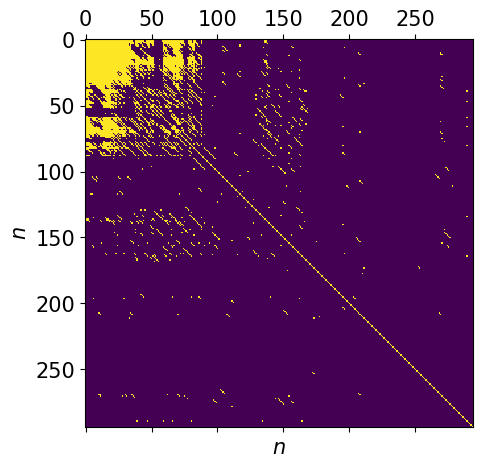

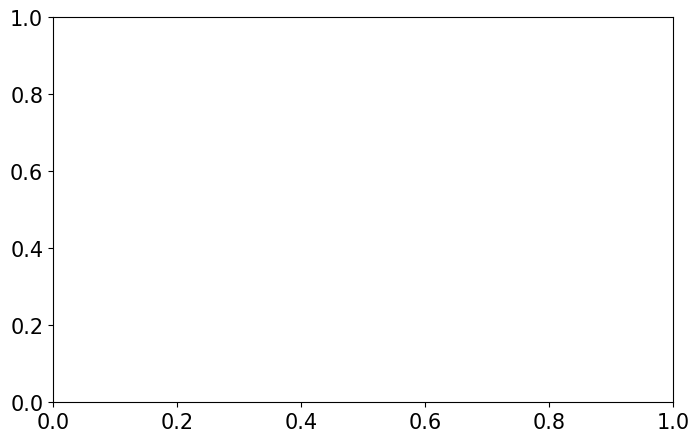

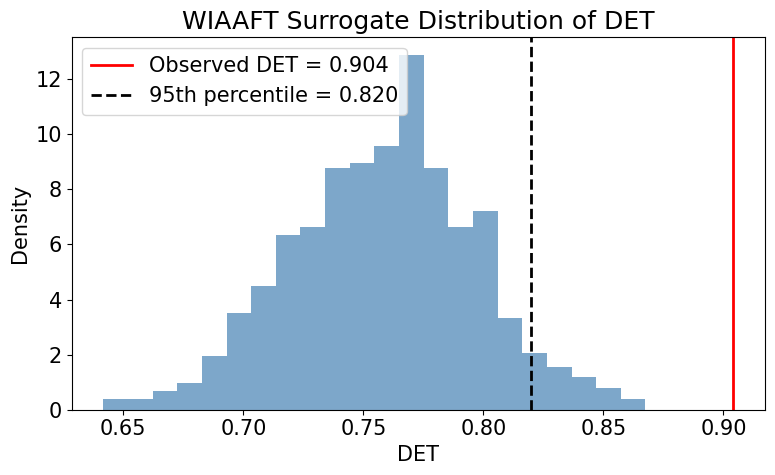

 40%|████████████████▊                         | 40/100 [22:06<32:28, 32.48s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.9041708043671695 
 Recurrence rate: 0.05000231385071035 
Threshold:1.4304999999998589 
 Laminarity:0.6429893567777811 
Shannon Entropy:2.4237493342014904 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

37
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


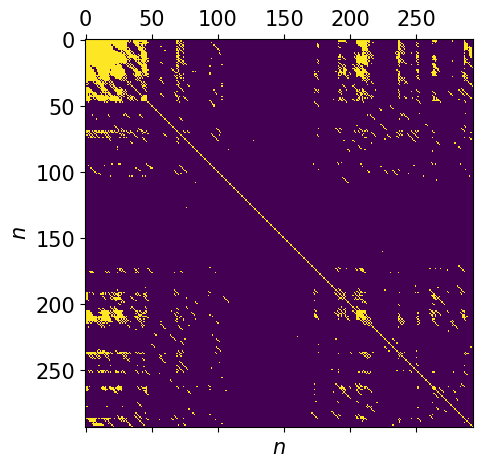

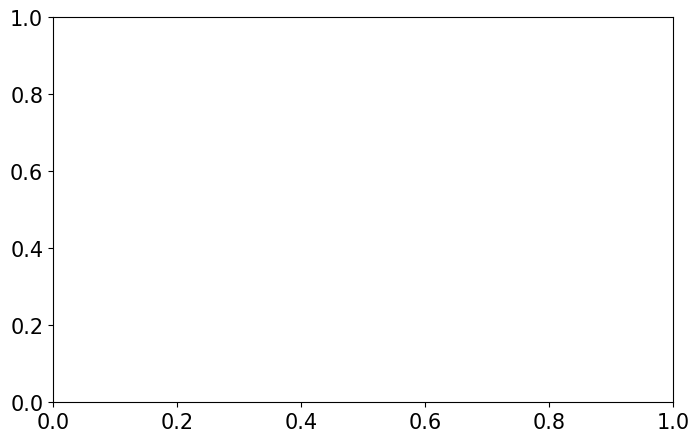

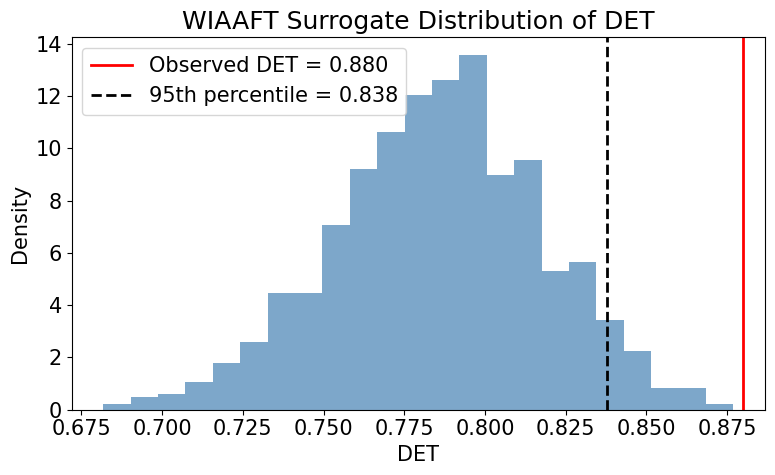

 41%|█████████████████▏                        | 41/100 [22:40<32:17, 32.83s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.8799999999978 
 Recurrence rate: 0.050006406597630726 
Threshold:1.87389999999981 
 Laminarity:0.5618448637303475 
Shannon Entropy:2.0139620045106144 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

38
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


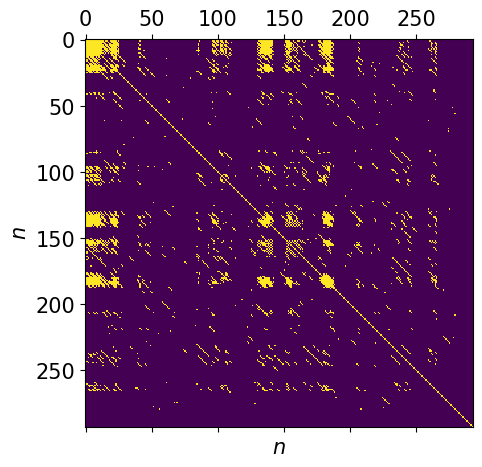

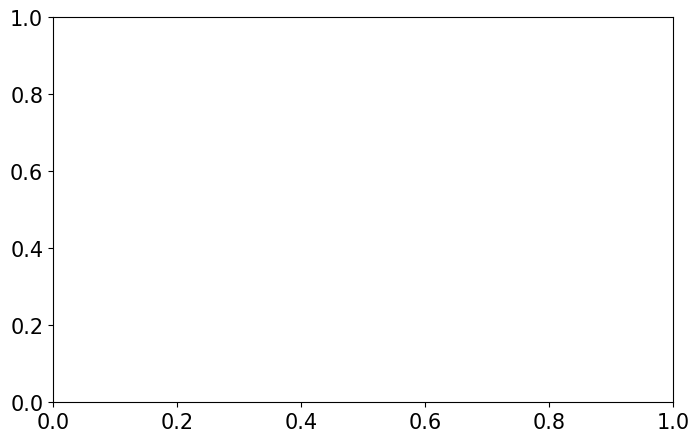

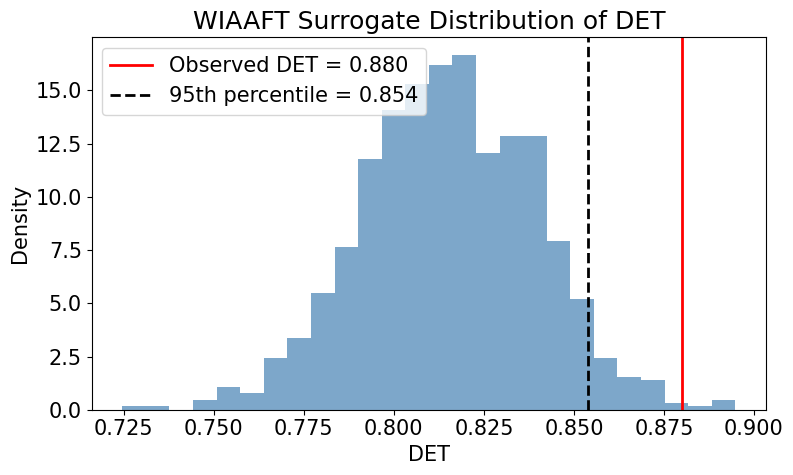

 42%|█████████████████▋                        | 42/100 [23:15<32:17, 33.40s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.8800599700127935 
 Recurrence rate: 0.0500297033162879 
Threshold:1.9428999999998025 
 Laminarity:0.4786961583225176 
Shannon Entropy:2.0033128813811394 
Rank-order p-value (det):0.005 
Reject null (det) hypothesis:True

 
 

39
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


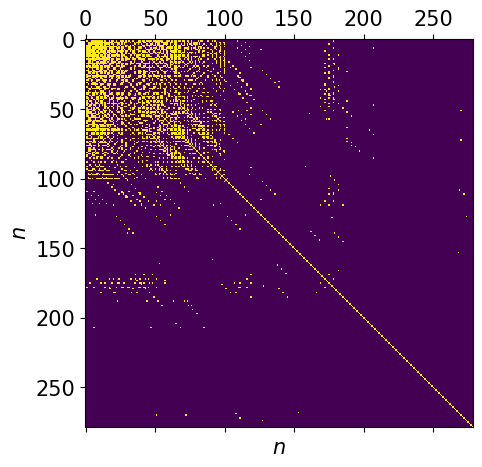

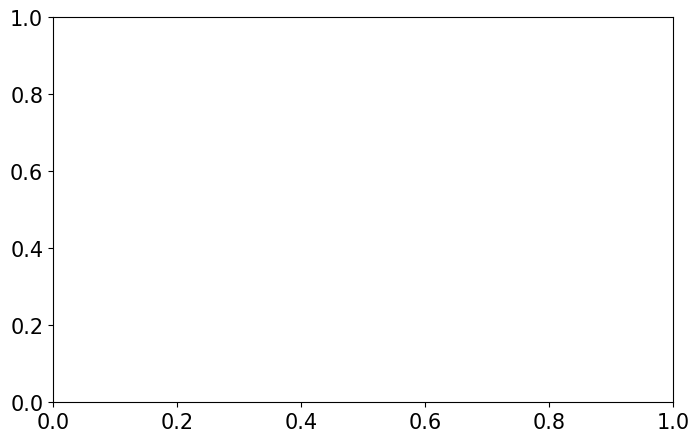

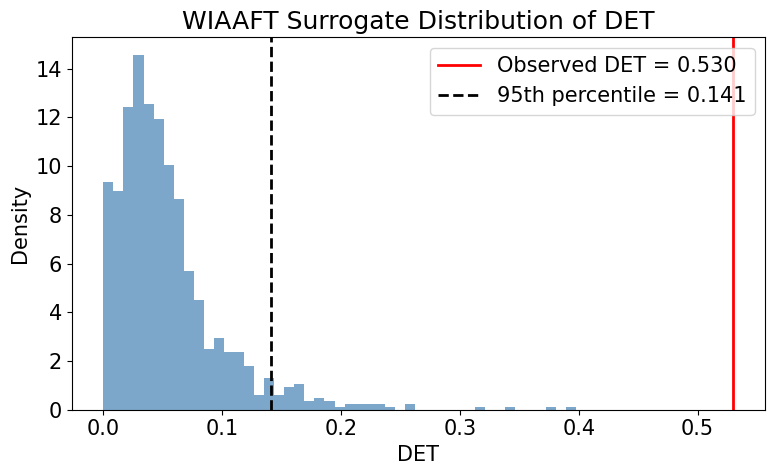

 43%|██████████████████                        | 43/100 [23:44<30:32, 32.15s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.5301604869935524 
 Recurrence rate: 0.050012204365308774 
Threshold:1.564699999999844 
 Laminarity:0.5530439249921576 
Shannon Entropy:0.666920489641907 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

40
No saturation detected (minimum FNN fallback)
7


Not enough points found!


WIAAFT surrogate datasets generated


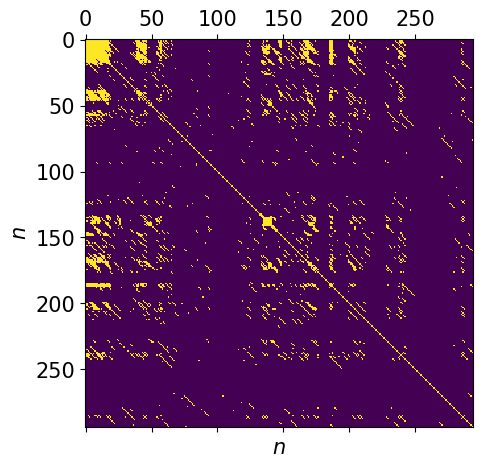

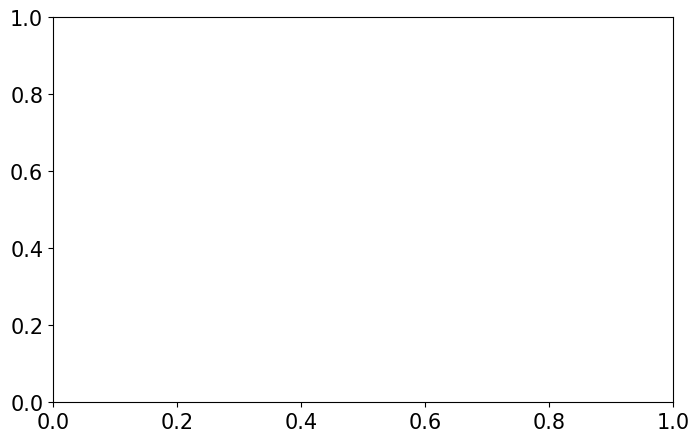

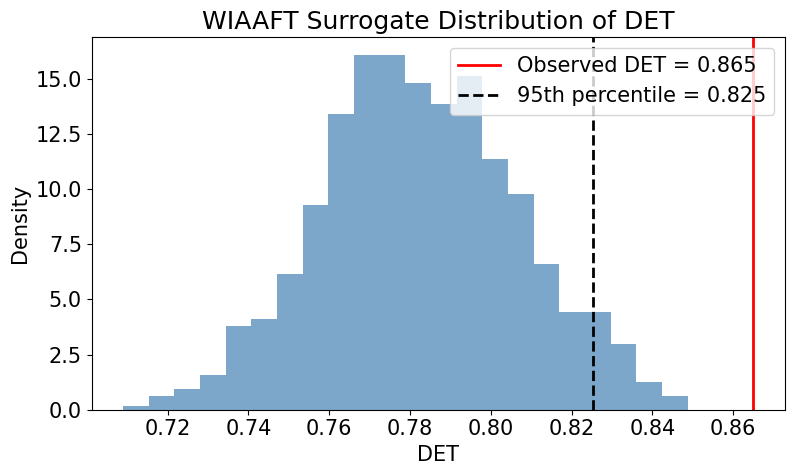

 44%|██████████████████▍                       | 44/100 [24:17<30:22, 32.55s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8649453823215866 
 Recurrence rate: 0.05000231385071035 
Threshold:1.8638999999998112 
 Laminarity:0.4352151781572531 
Shannon Entropy:1.8080275315174583 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

41
No saturation detected (minimum FNN fallback)
7


Not enough points found!


WIAAFT surrogate datasets generated


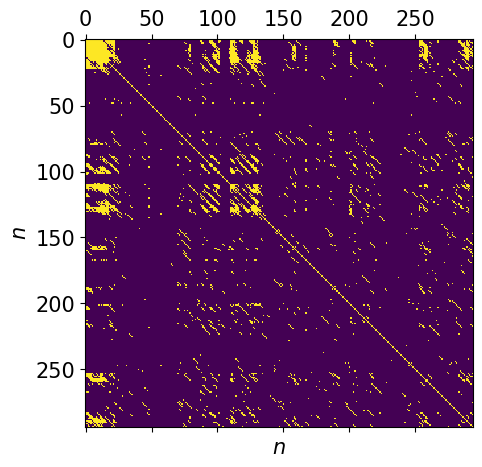

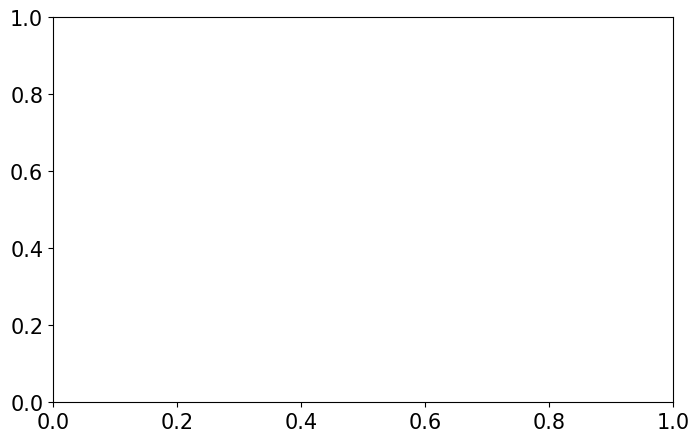

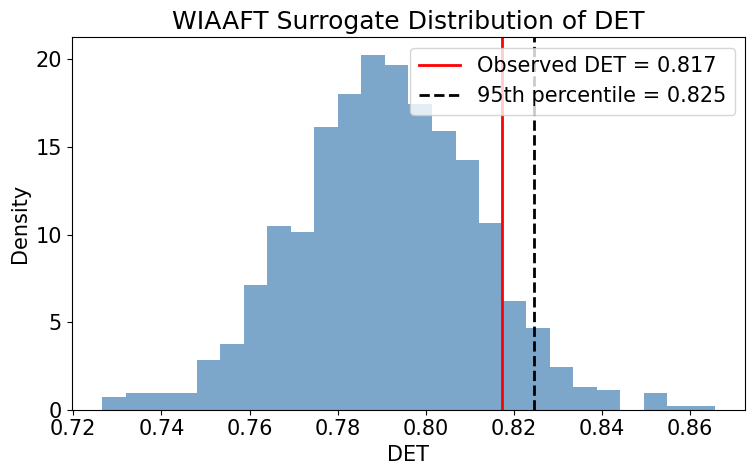

 45%|██████████████████▉                       | 45/100 [24:52<30:23, 33.16s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8172790466712581 
 Recurrence rate: 0.05000231385071035 
Threshold:1.946199999999802 
 Laminarity:0.4905136510863246 
Shannon Entropy:1.887058430534764 
Rank-order p-value (det):0.093 
Reject null (det) hypothesis:False

 
 

41
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


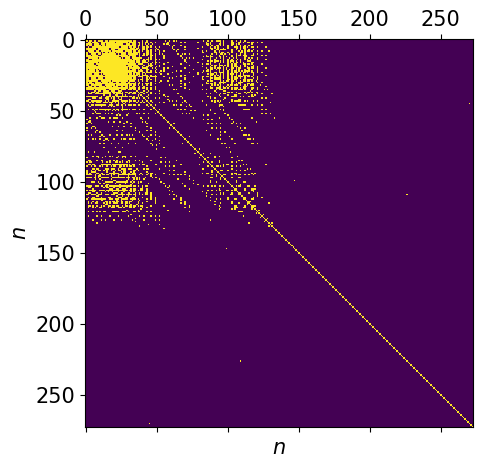

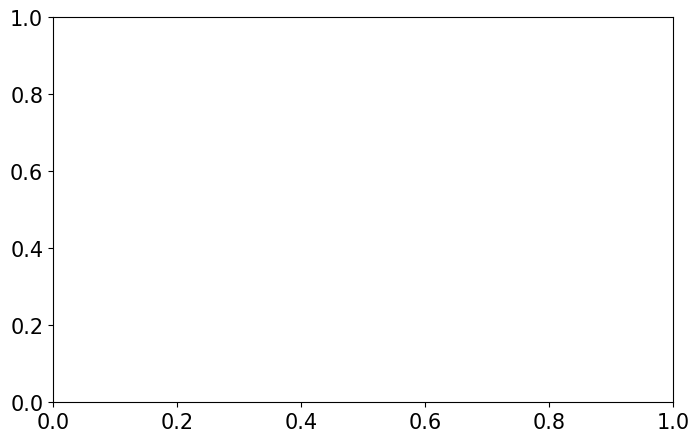

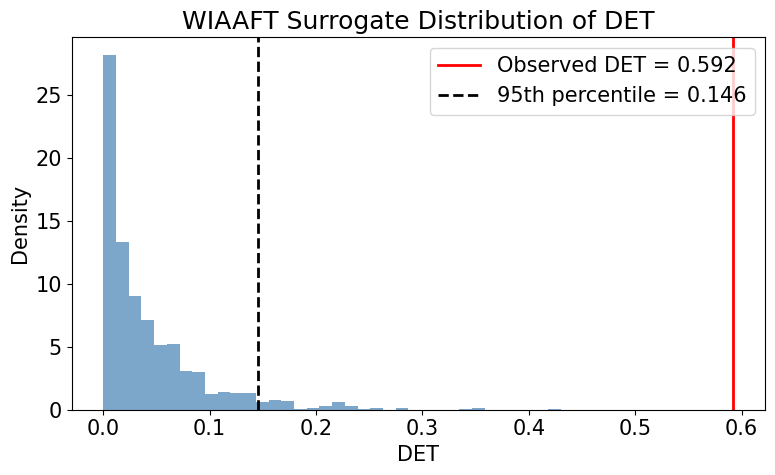

 46%|███████████████████▎                      | 46/100 [25:24<29:29, 32.76s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.5923566878963742 
 Recurrence rate: 0.050007379677709345 
Threshold:1.6515999999998345 
 Laminarity:0.6069224577391819 
Shannon Entropy:0.8087127589930283 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

42
No saturation detected (minimum FNN fallback)
9


Not enough points found!


WIAAFT surrogate datasets generated


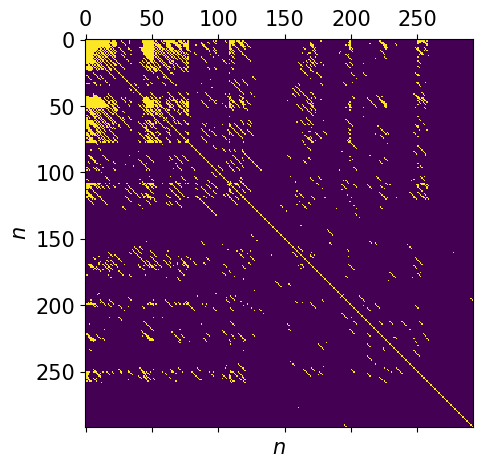

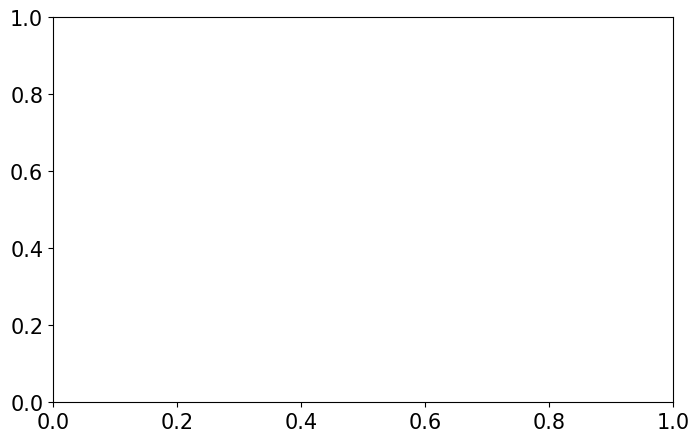

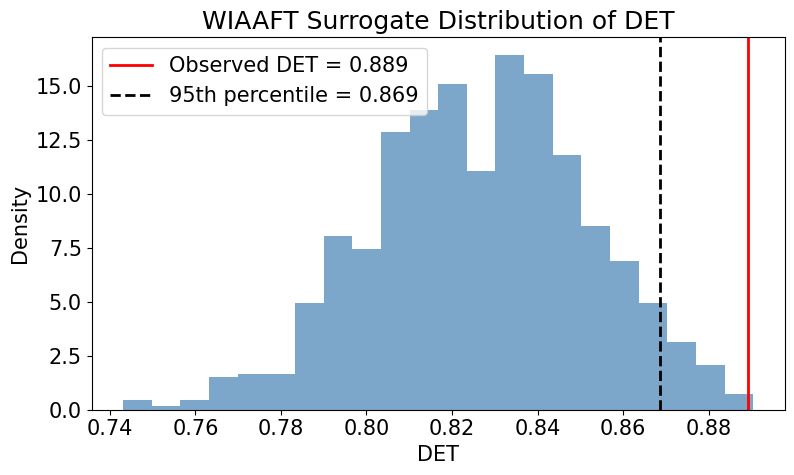

 47%|███████████████████▋                      | 47/100 [26:01<30:10, 34.17s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8892245720017895 
 Recurrence rate: 0.0500093826233815 
Threshold:2.2272000000002756 
 Laminarity:0.3968105065656735 
Shannon Entropy:2.116285589099938 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

43
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


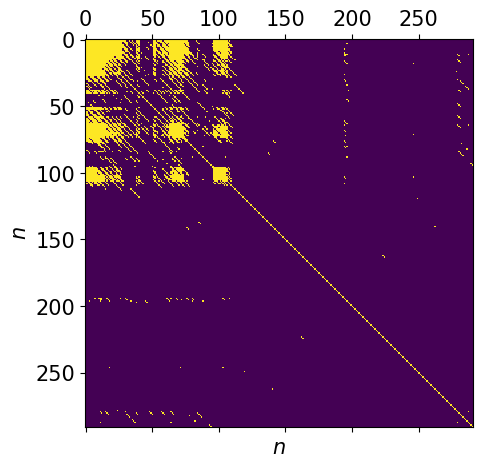

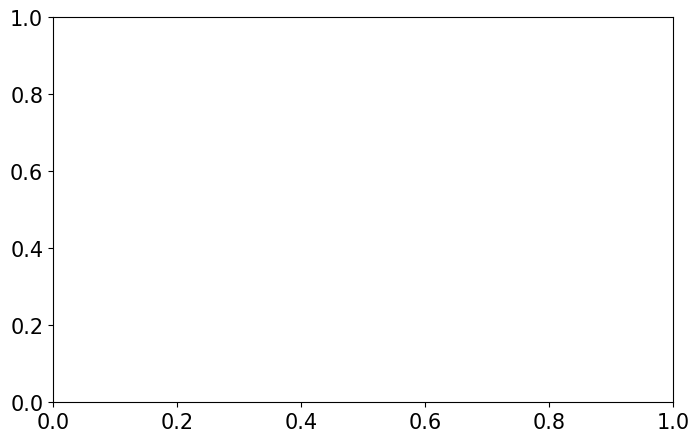

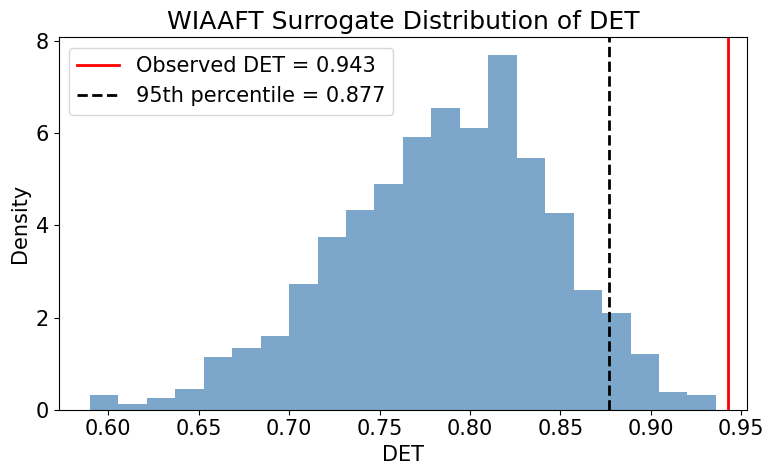

 48%|████████████████████▏                     | 48/100 [26:35<29:35, 34.14s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9427268119590909 
 Recurrence rate: 0.050034836622146646 
Threshold:1.8045999999998177 
 Laminarity:0.7030918102414372 
Shannon Entropy:2.5529384146585157 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

44
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


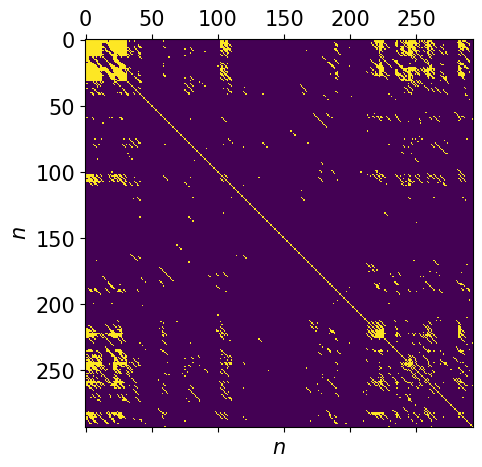

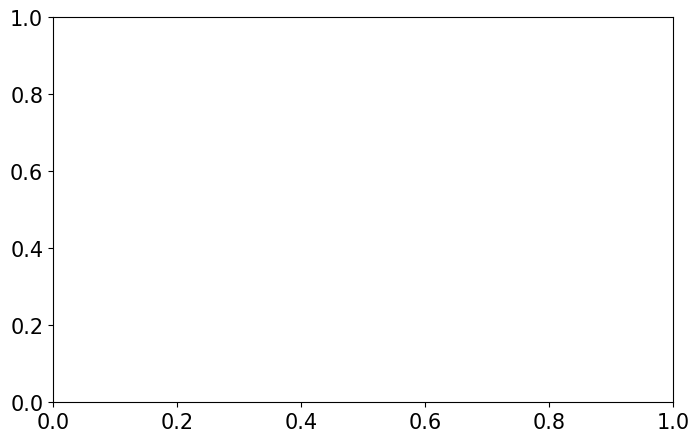

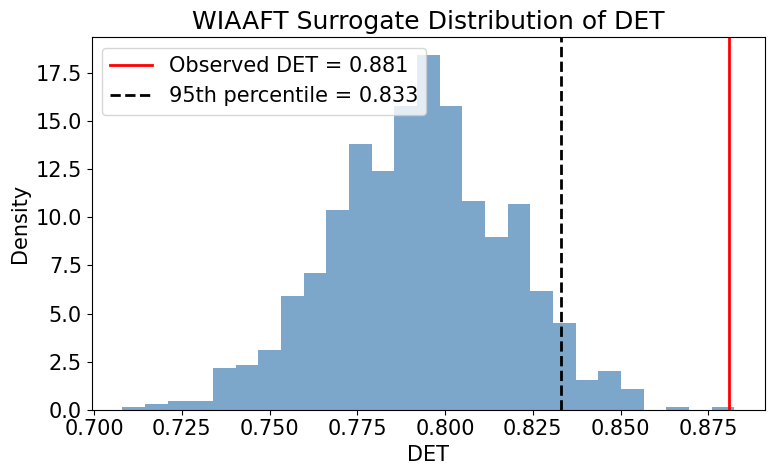

 49%|████████████████████▌                     | 49/100 [27:10<29:15, 34.42s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.8809999999977975 
 Recurrence rate: 0.050006406597630726 
Threshold:2.03489999999987 
 Laminarity:0.5457721872803499 
Shannon Entropy:2.0461583030066532 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

45
No saturation detected (minimum FNN fallback)
6


Not enough points found!


WIAAFT surrogate datasets generated


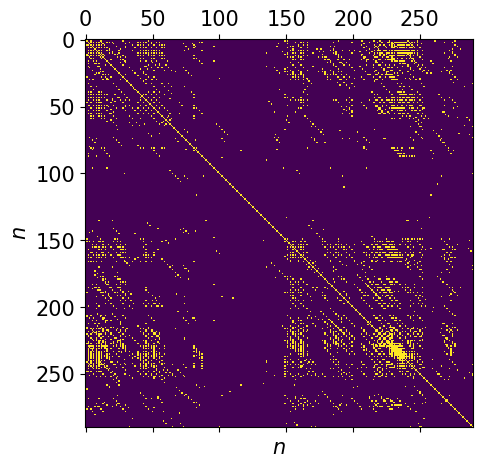

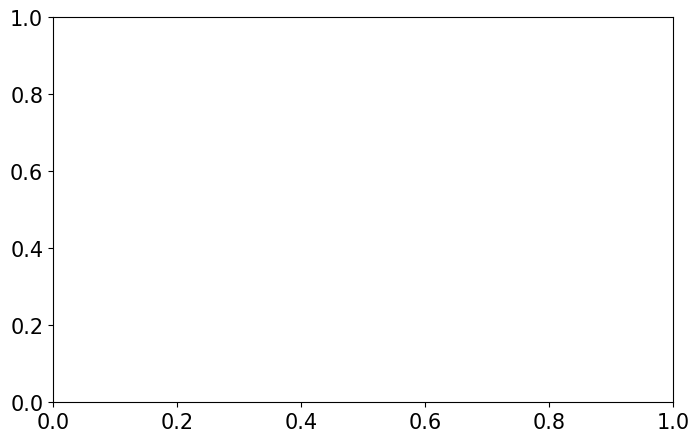

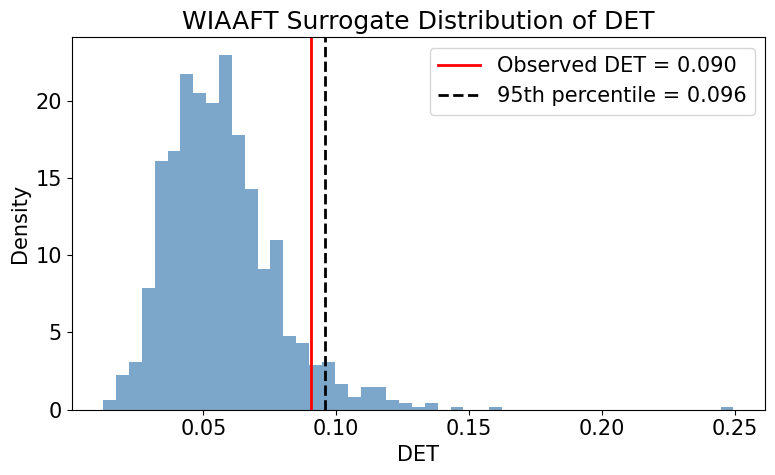

 50%|█████████████████████                     | 50/100 [27:40<27:34, 33.09s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.09039836567903371 
 Recurrence rate: 0.05001189060642093 
Threshold:1.6363999999998362 
 Laminarity:0.23728007608122378 
Shannon Entropy:1.7139464254563381 
Rank-order p-value (det):0.065 
Reject null (det) hypothesis:False

 
 

45
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


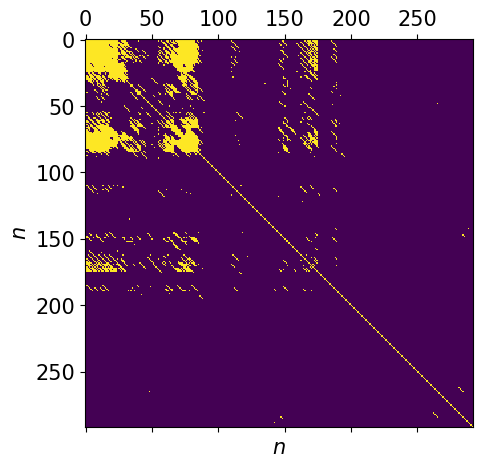

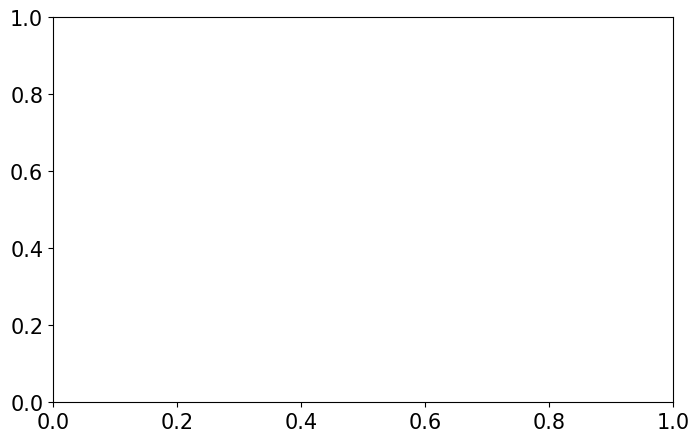

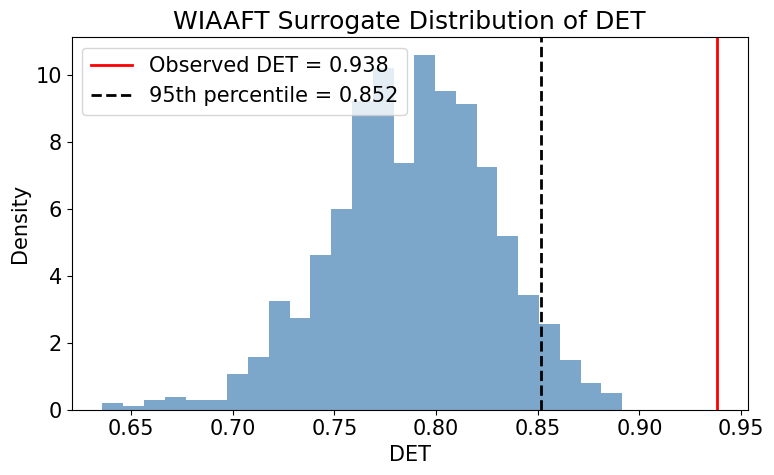

 51%|█████████████████████▍                    | 51/100 [28:15<27:16, 33.40s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9380664652544359 
 Recurrence rate: 0.0500093826233815 
Threshold:1.8698999999998105 
 Laminarity:0.7098968105049017 
Shannon Entropy:2.6184436723858004 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

46
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


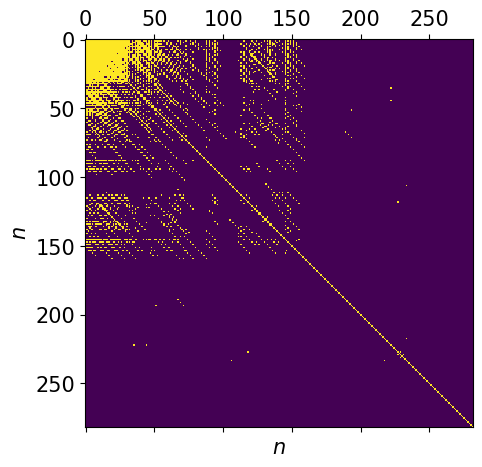

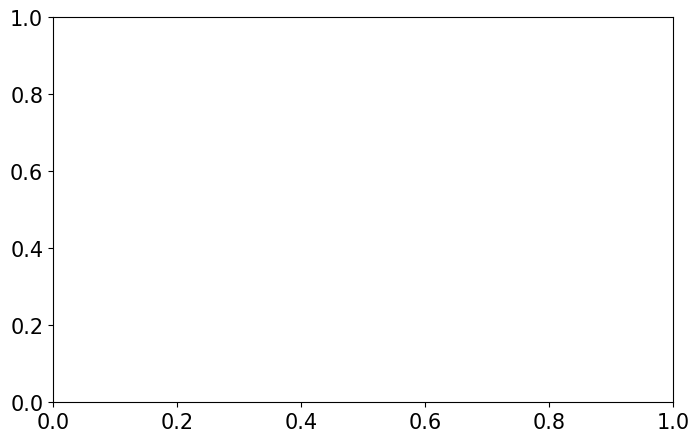

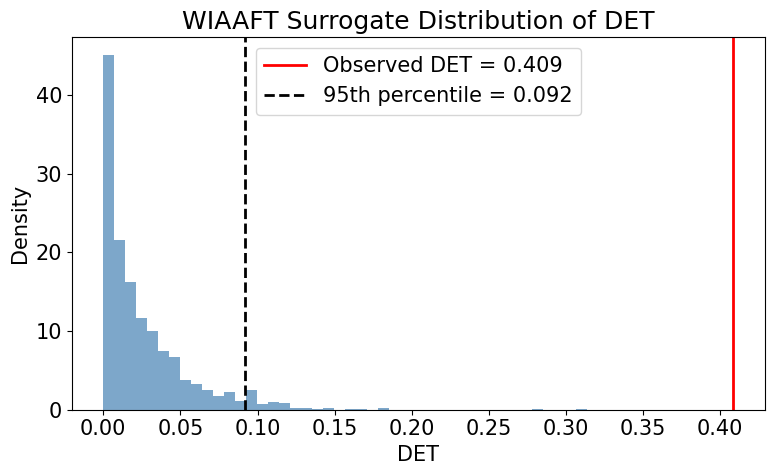

 52%|█████████████████████▊                    | 52/100 [28:49<26:53, 33.61s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.40854978354867816 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9521999999998014 
 Laminarity:0.5500251382590498 
Shannon Entropy:2.8511278043881276 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

47
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


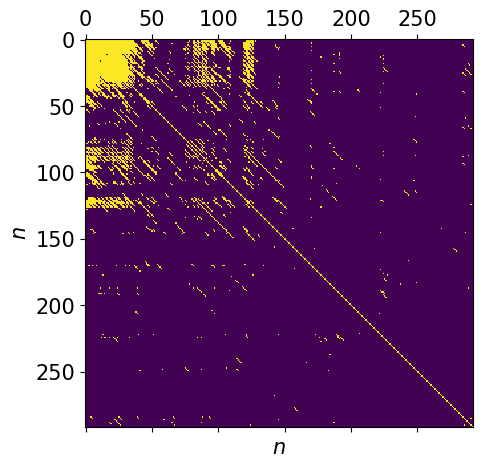

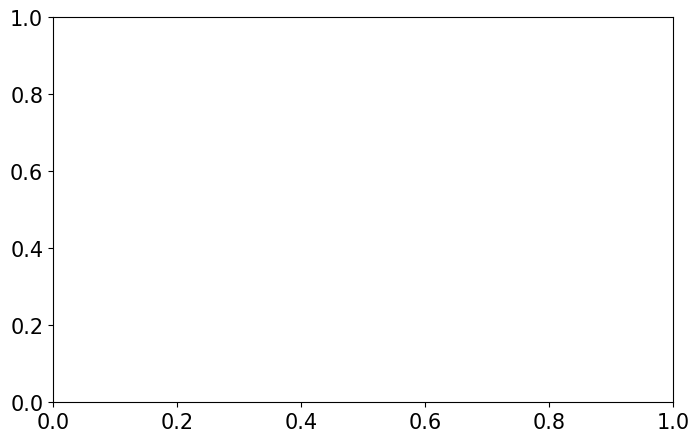

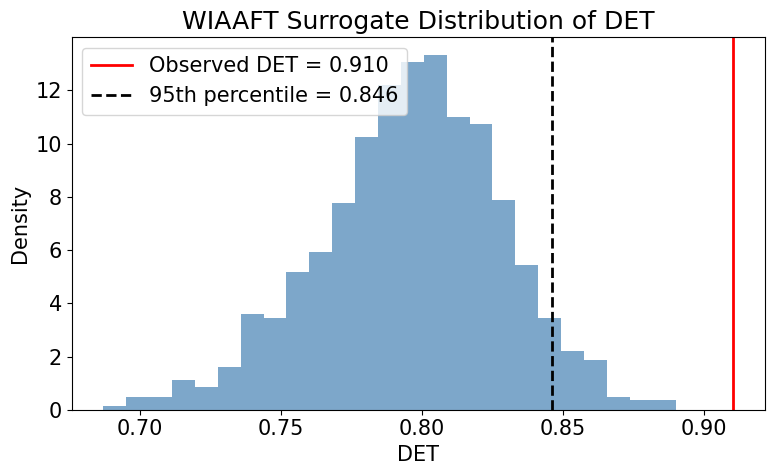

 53%|██████████████████████▎                   | 53/100 [29:25<26:51, 34.29s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9103726082555127 
 Recurrence rate: 0.0500093826233815 
Threshold:1.9605999999998005 
 Laminarity:0.602485928704028 
Shannon Entropy:2.4012844967585667 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

48
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


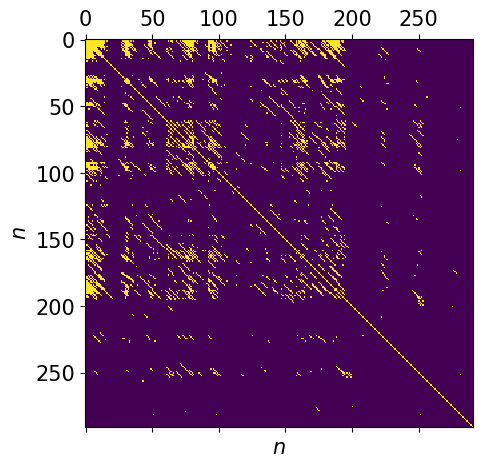

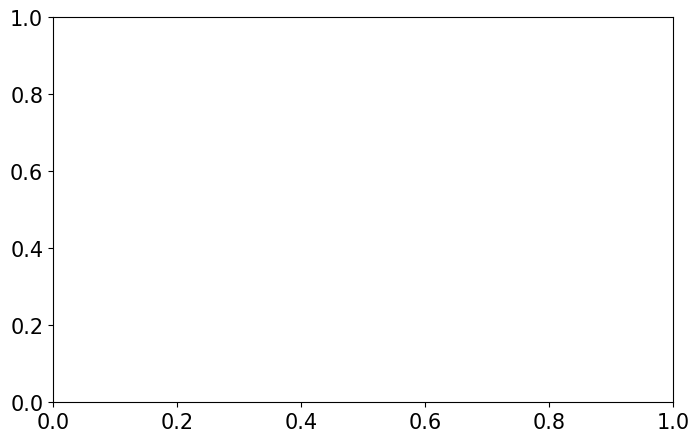

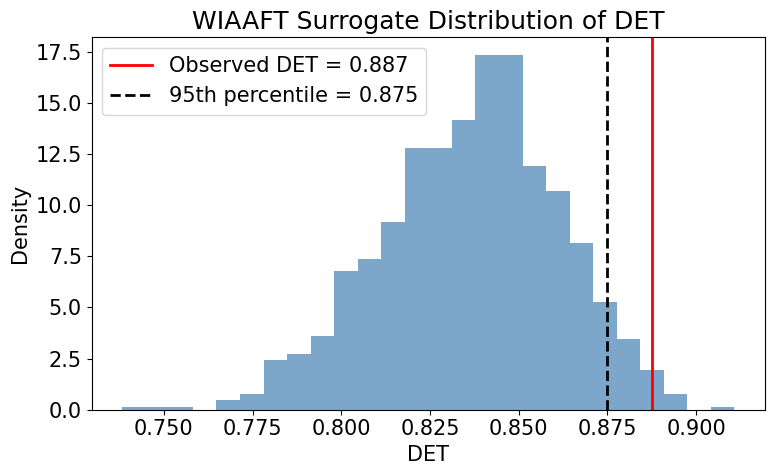

 54%|██████████████████████▋                   | 54/100 [30:05<27:40, 36.10s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.8874809934088002 
 Recurrence rate: 0.050034836622146646 
Threshold:2.5101000000008726 
 Laminarity:0.37573755015252364 
Shannon Entropy:2.023504967725555 
Rank-order p-value (det):0.014 
Reject null (det) hypothesis:True

 
 

49
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


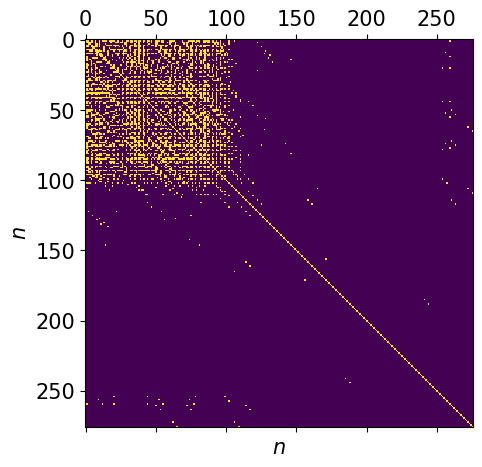

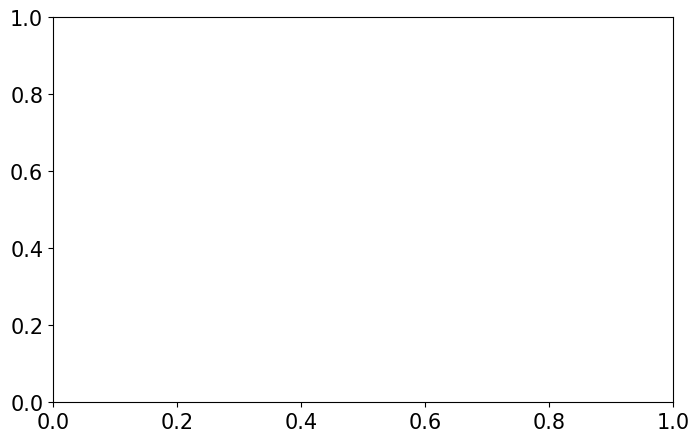

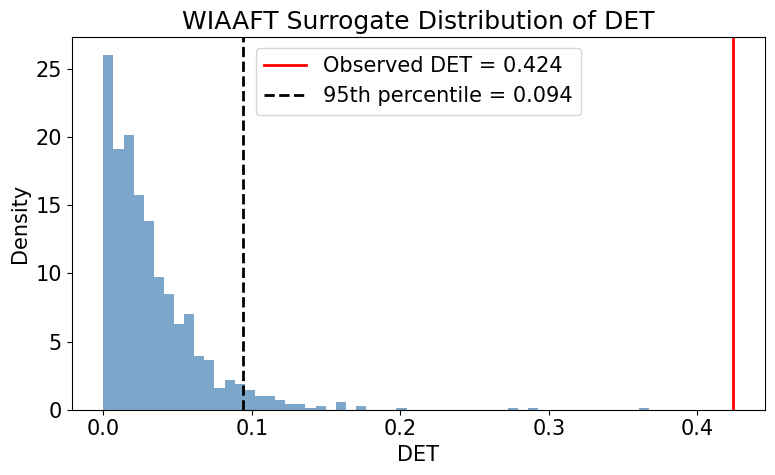

 55%|███████████████████████                   | 55/100 [30:37<26:10, 34.91s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.42444821731628624 
 Recurrence rate: 0.050015752993068686 
Threshold:1.8415999999998136 
 Laminarity:0.5391076115471415 
Shannon Entropy:0.29708594904421315 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

50
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


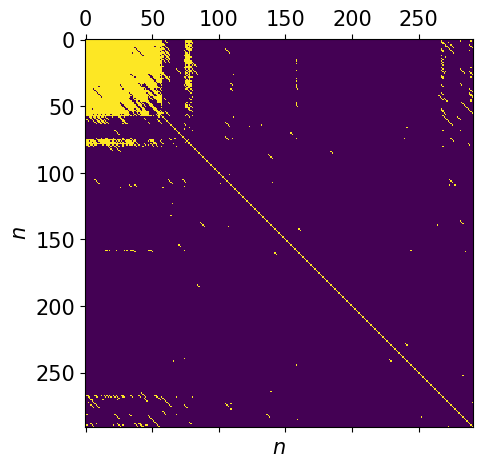

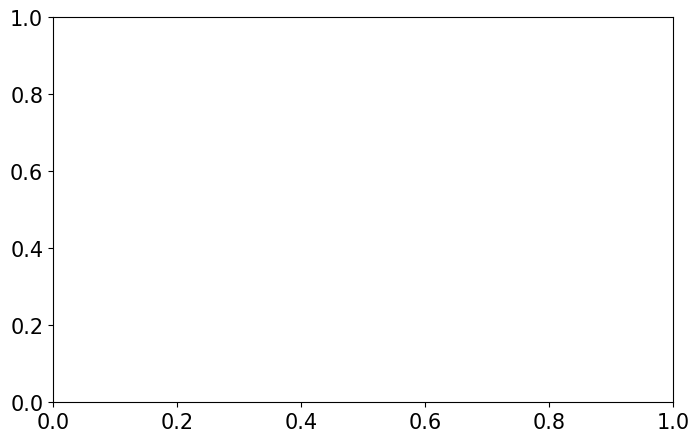

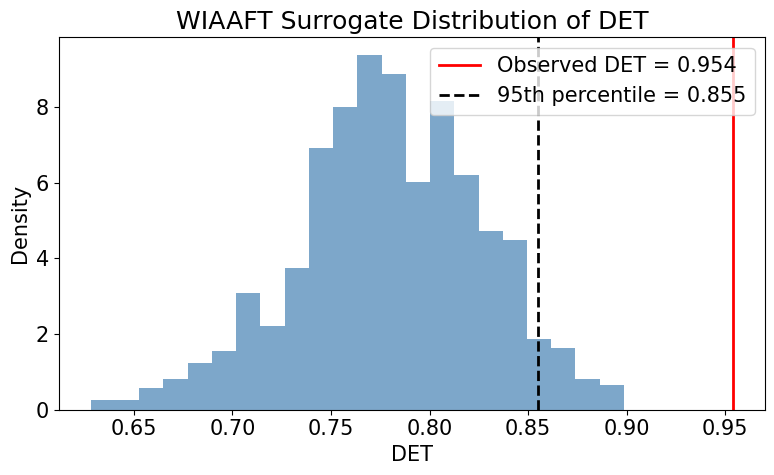

 56%|███████████████████████▌                  | 56/100 [31:13<25:49, 35.23s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9538539553728351 
 Recurrence rate: 0.050011218573233665 
Threshold:2.0262999999998517 
 Laminarity:0.8240850059012419 
Shannon Entropy:2.894304280876645 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

51
No saturation detected (minimum FNN fallback)
9


Not enough points found!


WIAAFT surrogate datasets generated


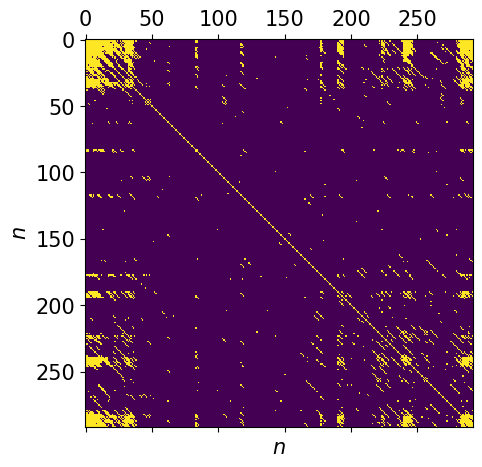

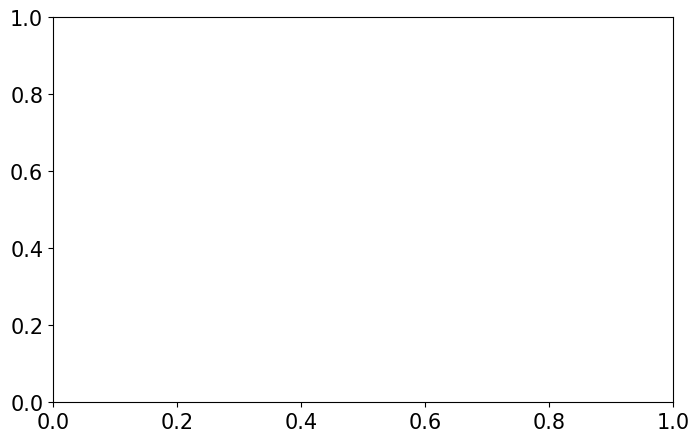

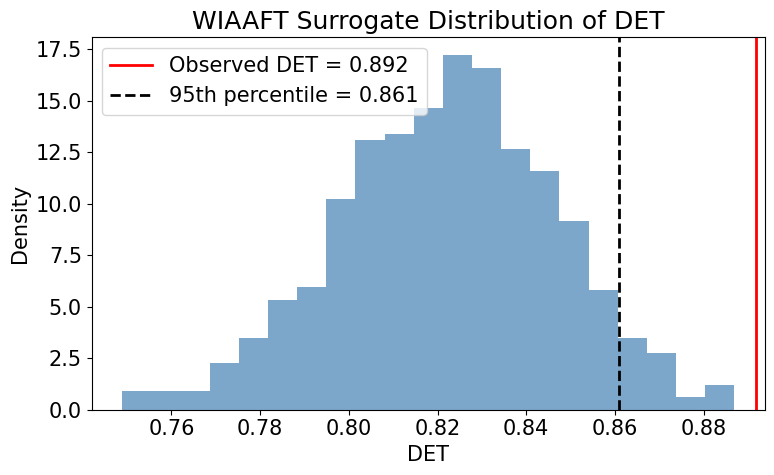

 57%|███████████████████████▉                  | 57/100 [31:50<25:37, 35.76s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.891742195365328 
 Recurrence rate: 0.0500093826233815 
Threshold:2.227800000000277 
 Laminarity:0.5715290806740818 
Shannon Entropy:2.16645826541275 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

52
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


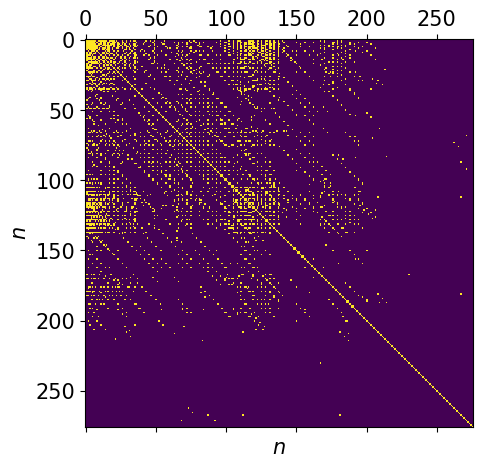

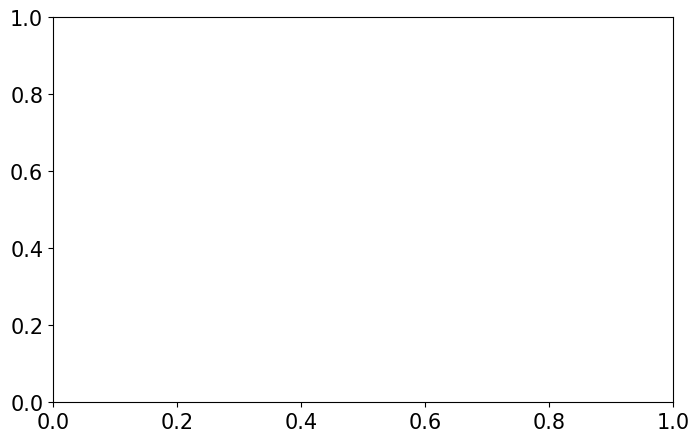

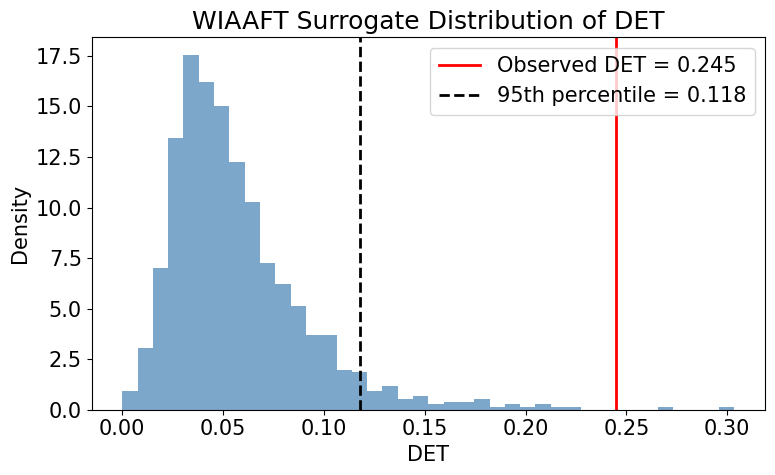

 58%|████████████████████████▎                 | 58/100 [32:24<24:42, 35.31s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.2450481041306026 
 Recurrence rate: 0.050015752993068686 
Threshold:2.0589999999999207 
 Laminarity:0.30026246719081295 
Shannon Entropy:0.5517416046296062 
Rank-order p-value (det):0.003 
Reject null (det) hypothesis:True

 
 

53
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


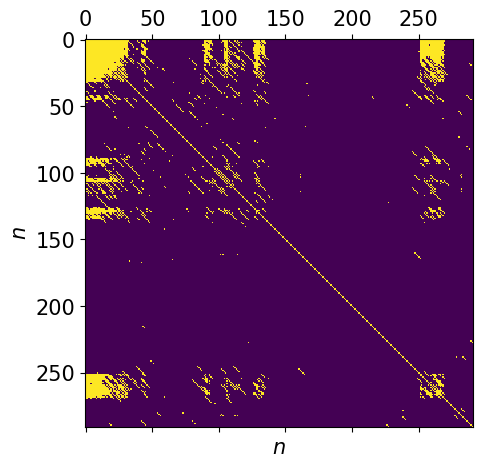

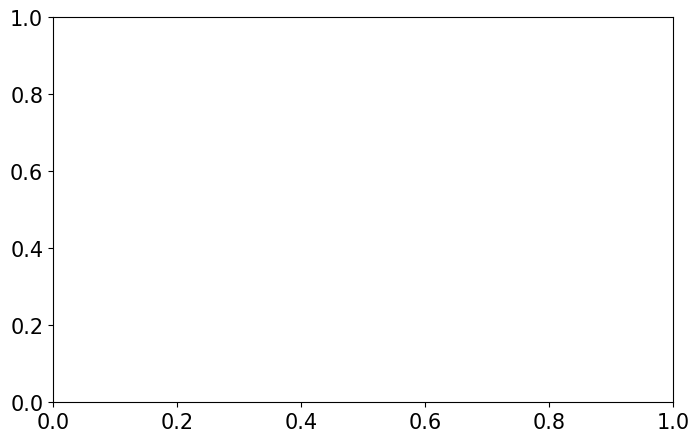

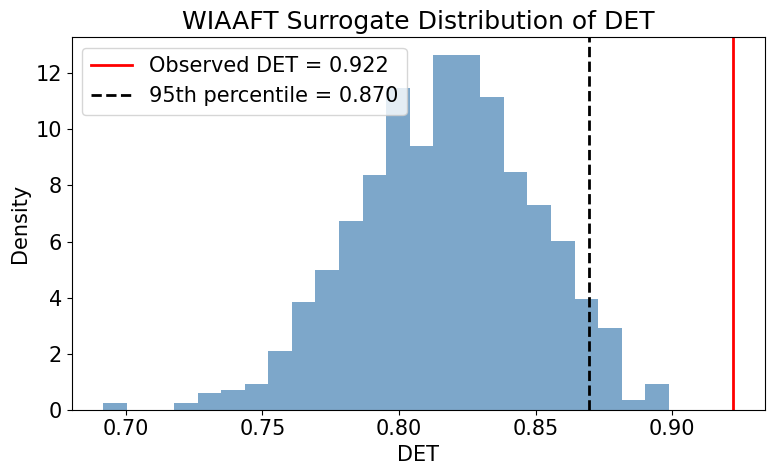

 59%|████████████████████████▊                 | 59/100 [33:02<24:32, 35.92s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9224137931011095 
 Recurrence rate: 0.050011218573233665 
Threshold:2.193800000000205 
 Laminarity:0.6075560802819184 
Shannon Entropy:2.445498469470082 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

54
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


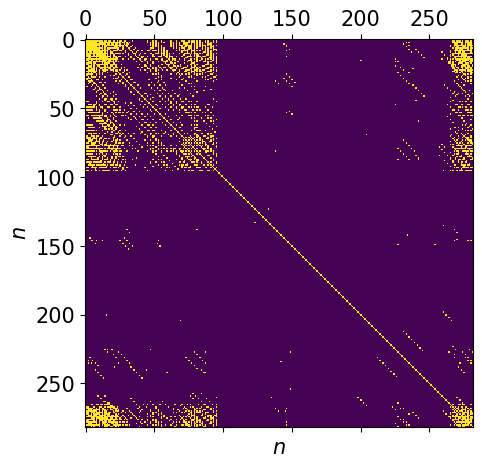

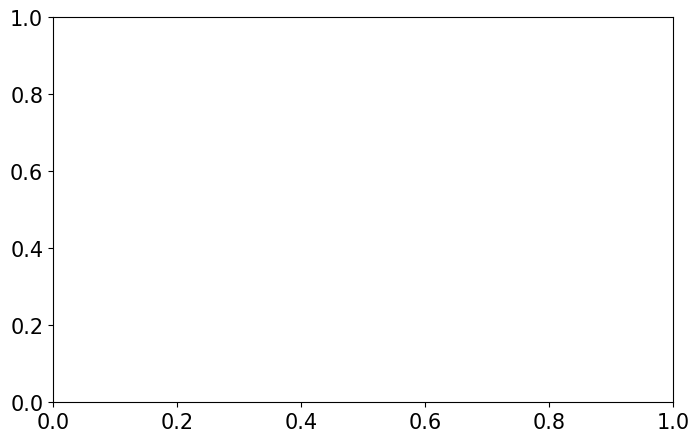

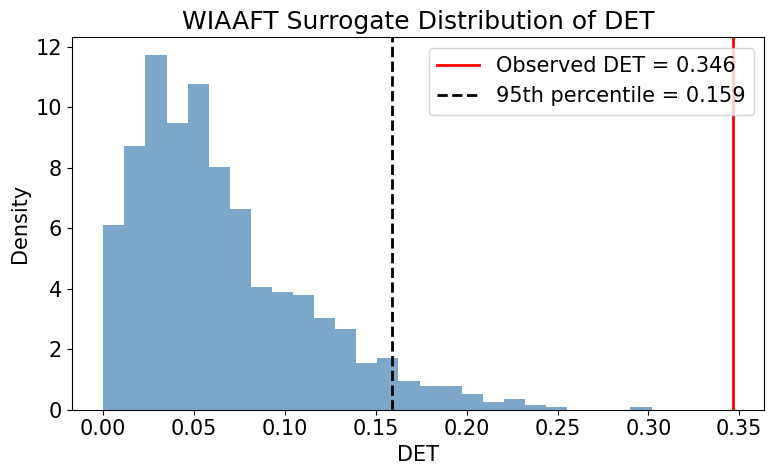

 60%|█████████████████████████▏                | 60/100 [33:36<23:42, 35.57s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.34632034631940933 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9619999999998003 
 Laminarity:0.496480643538219 
Shannon Entropy:2.4410038145578246 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

55
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


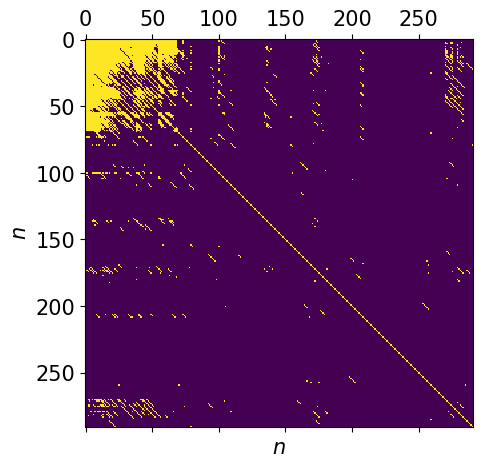

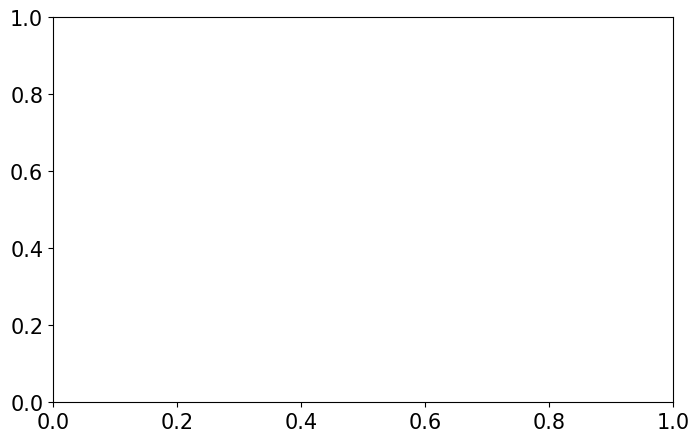

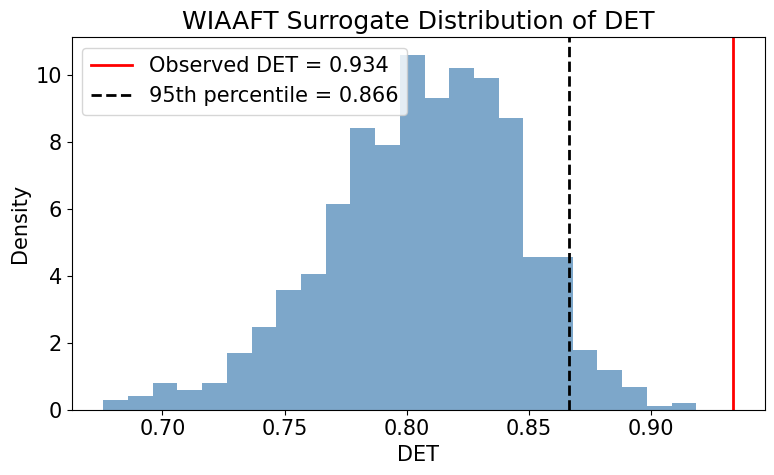

 61%|█████████████████████████▌                | 61/100 [34:12<23:05, 35.52s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9336036492627127 
 Recurrence rate: 0.050034836622146646 
Threshold:1.9947999999997967 
 Laminarity:0.6915270238359889 
Shannon Entropy:2.7435280477032635 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

56
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


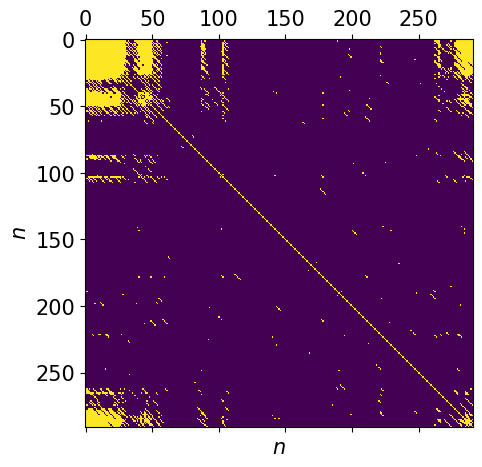

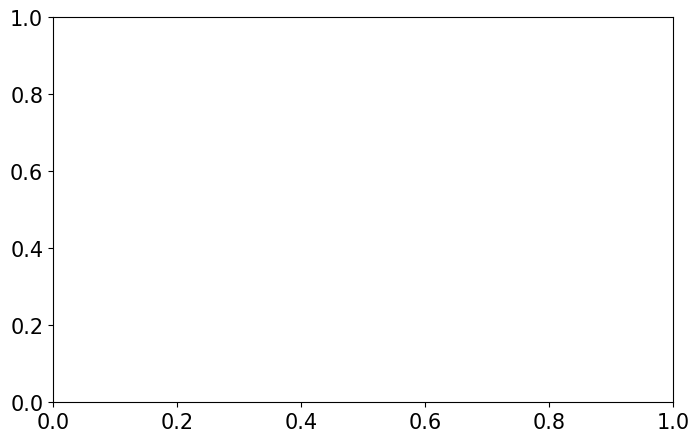

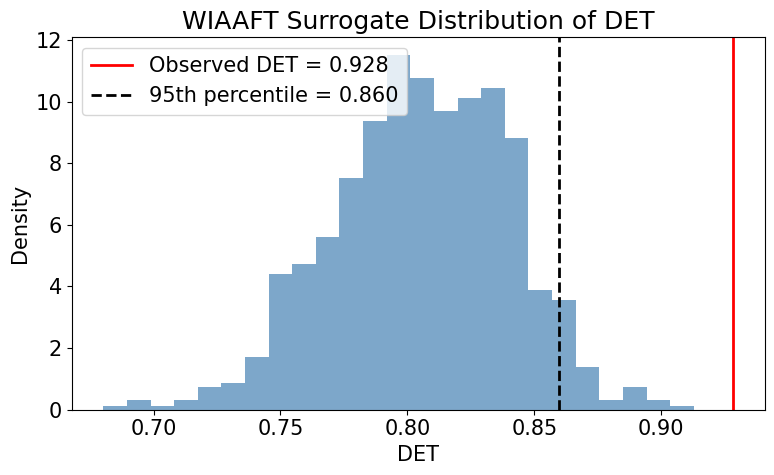

 62%|██████████████████████████                | 62/100 [34:50<23:00, 36.32s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9284989857988628 
 Recurrence rate: 0.050011218573233665 
Threshold:2.249600000000323 
 Laminarity:0.6753246753230807 
Shannon Entropy:2.6053321756523147 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

57
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


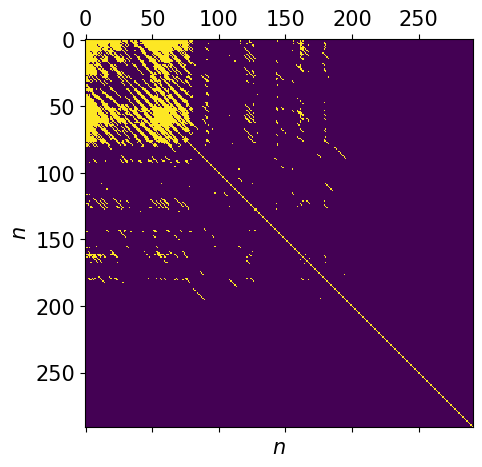

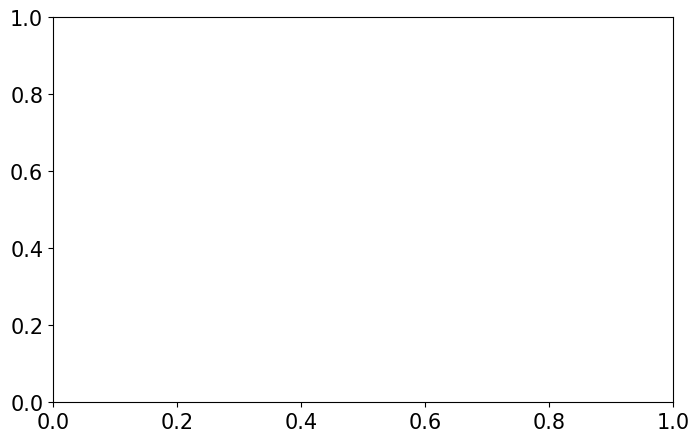

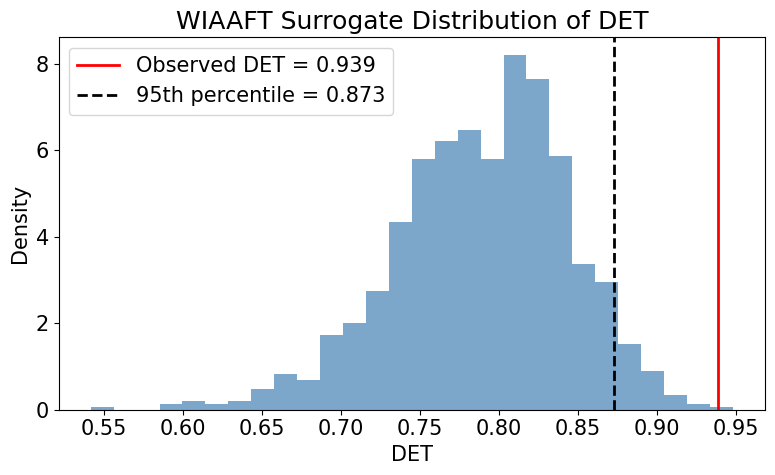

 63%|██████████████████████████▍               | 63/100 [35:24<21:54, 35.52s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9386409736284518 
 Recurrence rate: 0.050011218573233665 
Threshold:1.7498999999998237 
 Laminarity:0.7376623376605959 
Shannon Entropy:2.527631774908235 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

58
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


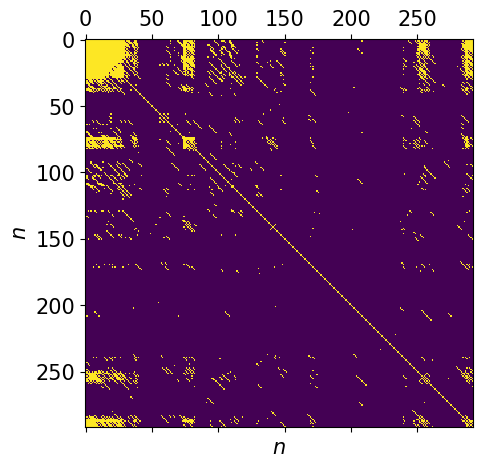

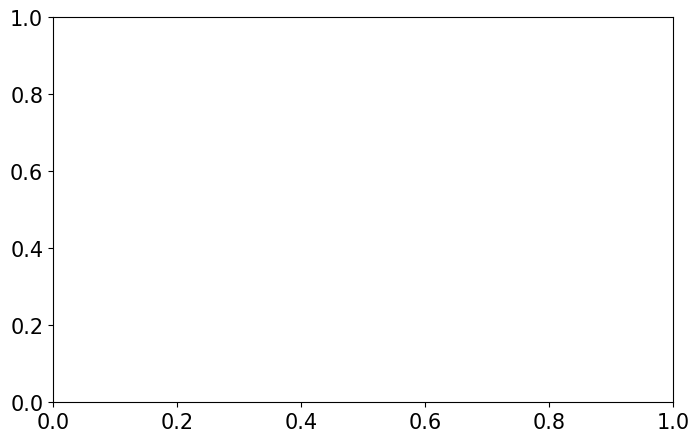

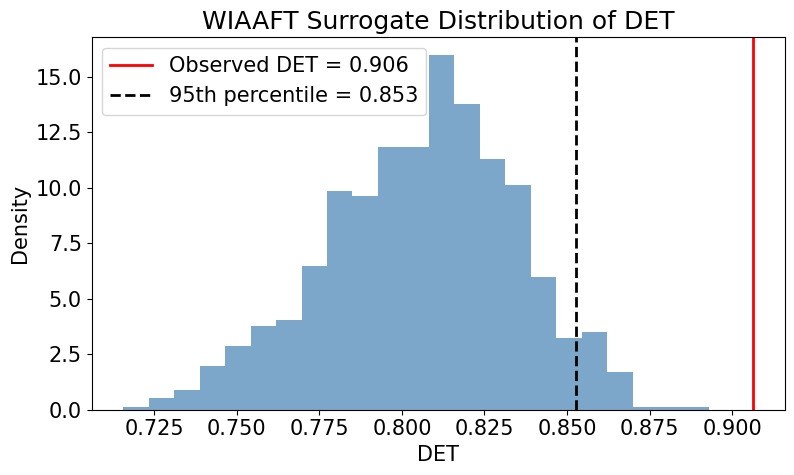

 64%|██████████████████████████▉               | 64/100 [36:00<21:26, 35.74s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9063444108738511 
 Recurrence rate: 0.0500093826233815 
Threshold:2.1551000000001235 
 Laminarity:0.5234521575972715 
Shannon Entropy:2.2391744803841998 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

59
No saturation detected (minimum FNN fallback)
9


Not enough points found!


WIAAFT surrogate datasets generated


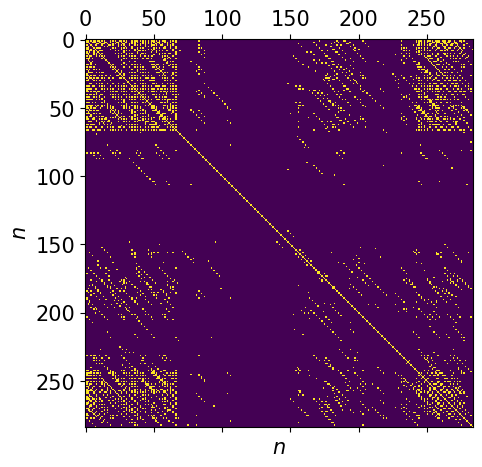

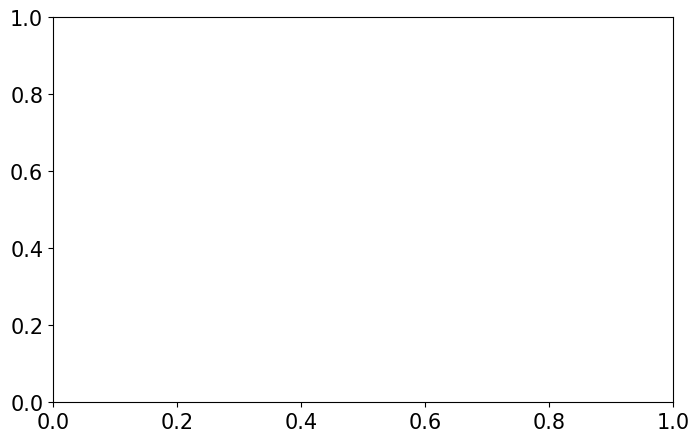

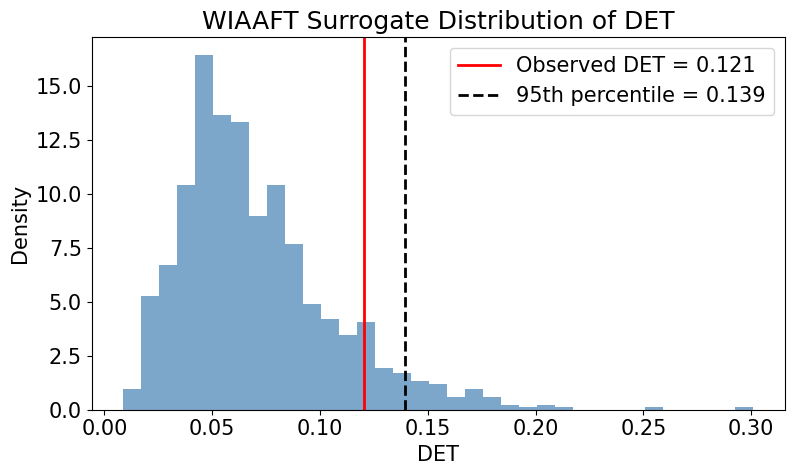

 65%|███████████████████████████▎              | 65/100 [36:36<21:00, 36.01s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.12053333333301192 
 Recurrence rate: 0.050014878000396744 
Threshold:2.228800000000279 
 Laminarity:0.25880019831368667 
Shannon Entropy:1.6580115159199071 
Rank-order p-value (det):0.096 
Reject null (det) hypothesis:False

 
 

59
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


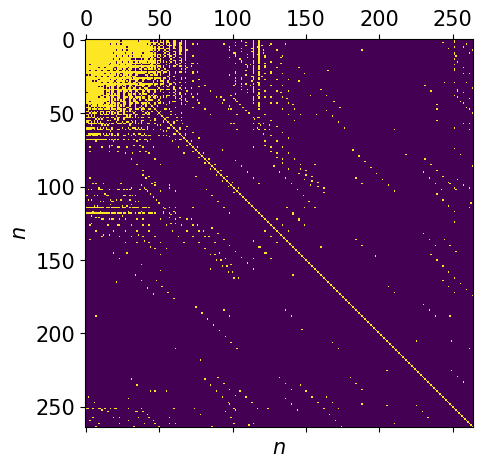

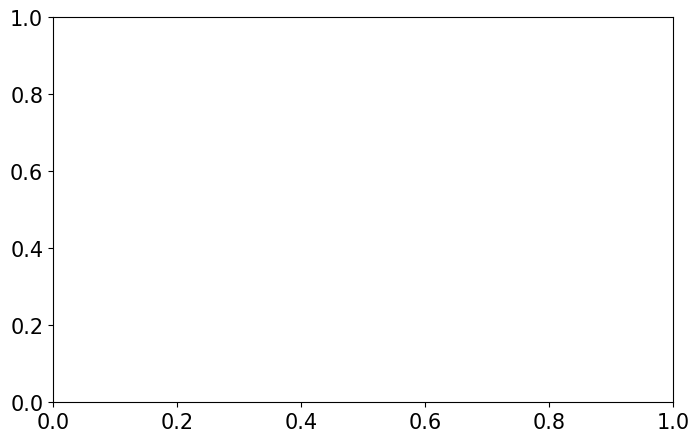

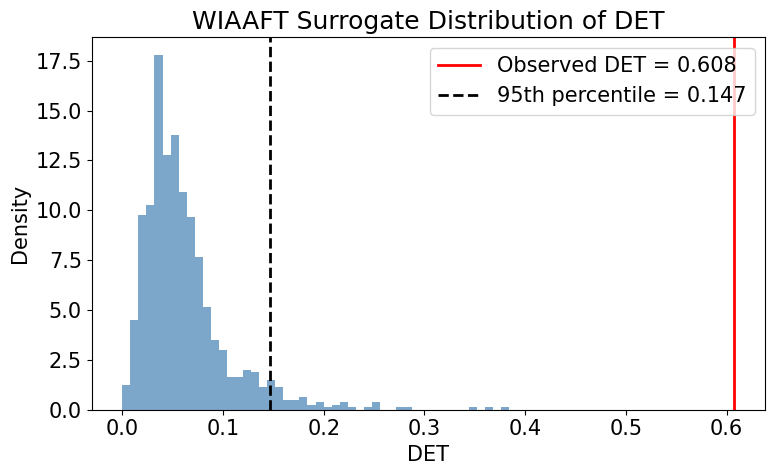

 66%|███████████████████████████▋              | 66/100 [37:12<20:20, 35.90s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.6076970825555317 
 Recurrence rate: 0.050017217630854 
Threshold:2.383300000000605 
 Laminarity:0.5983935742954722 
Shannon Entropy:1.5419215238894528 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

60
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


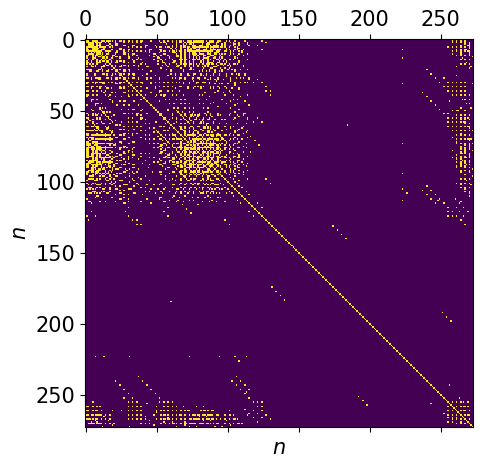

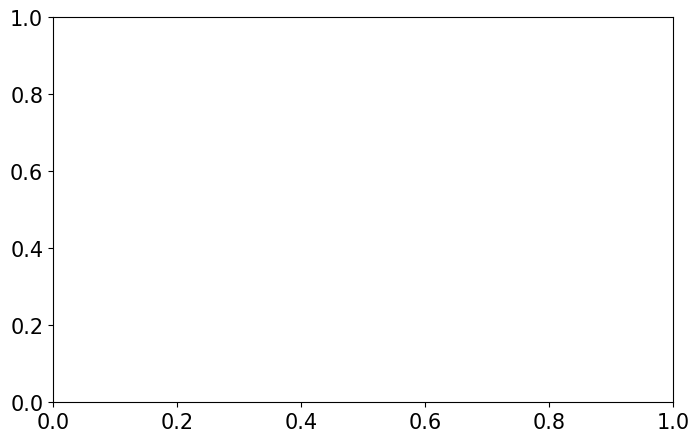

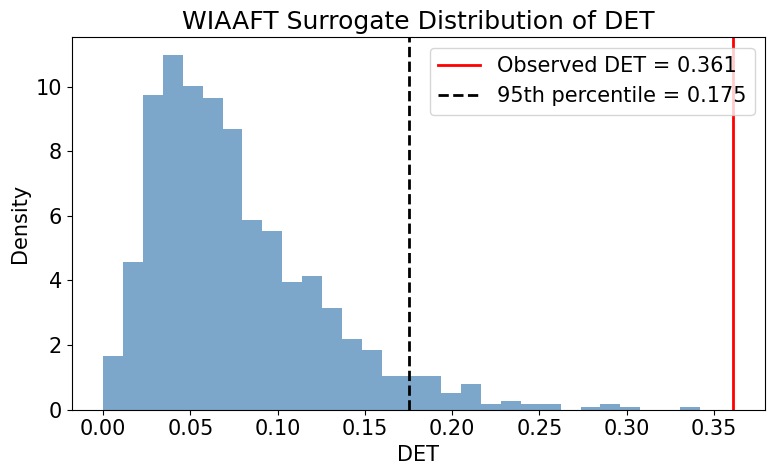

 67%|████████████████████████████▏             | 67/100 [37:48<19:41, 35.81s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.36132020845292034 
 Recurrence rate: 0.050007379677709345 
Threshold:2.179900000000176 
 Laminarity:0.4260799570688863 
Shannon Entropy:0.6583796679221635 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

61
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


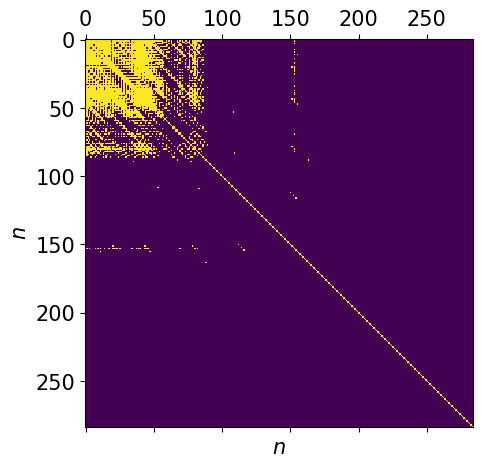

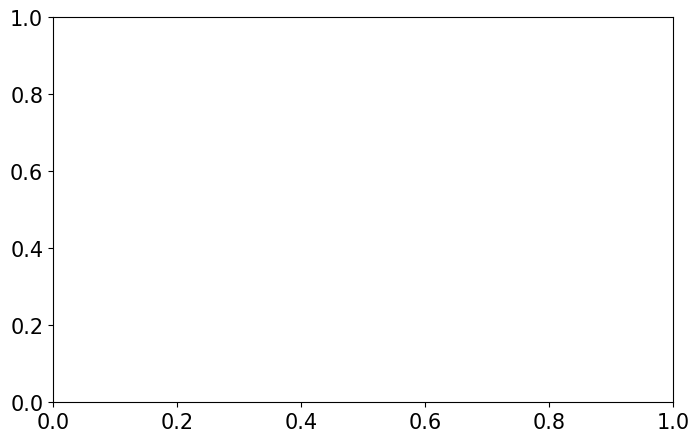

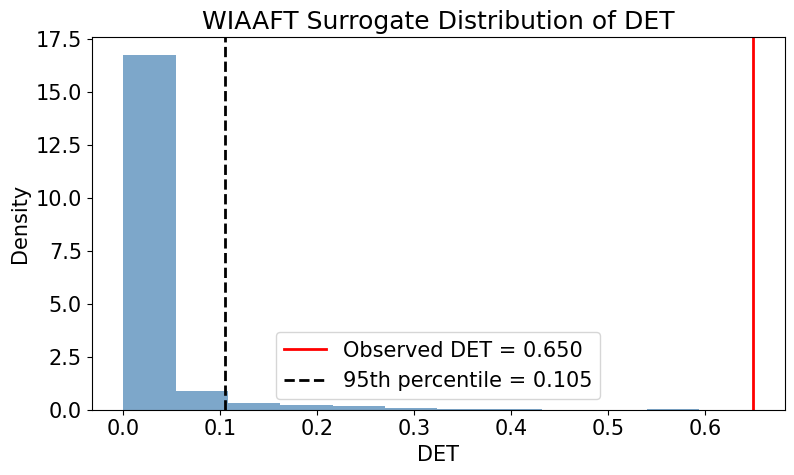

 68%|████████████████████████████▌             | 68/100 [38:15<17:40, 33.13s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.6495999999982678 
 Recurrence rate: 0.050014878000396744 
Threshold:1.1447999999998903 
 Laminarity:0.7491323748122233 
Shannon Entropy:2.8491044850876586 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

62
No saturation detected (minimum FNN fallback)
5


Not enough points found!


WIAAFT surrogate datasets generated


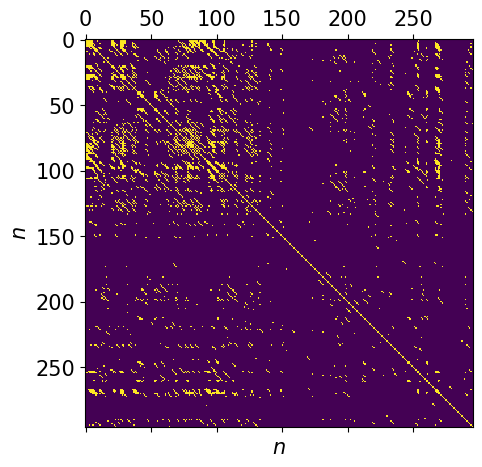

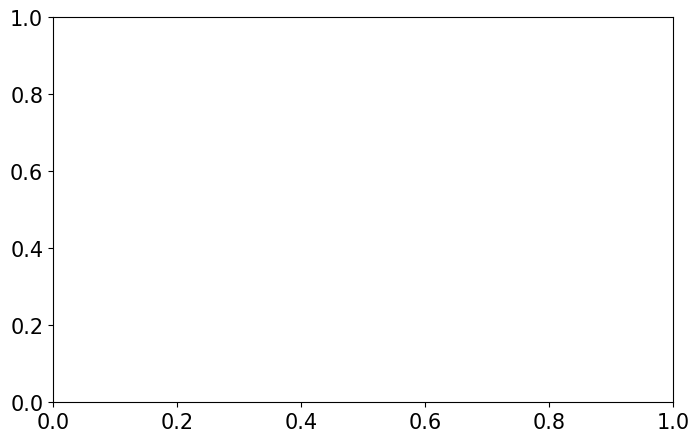

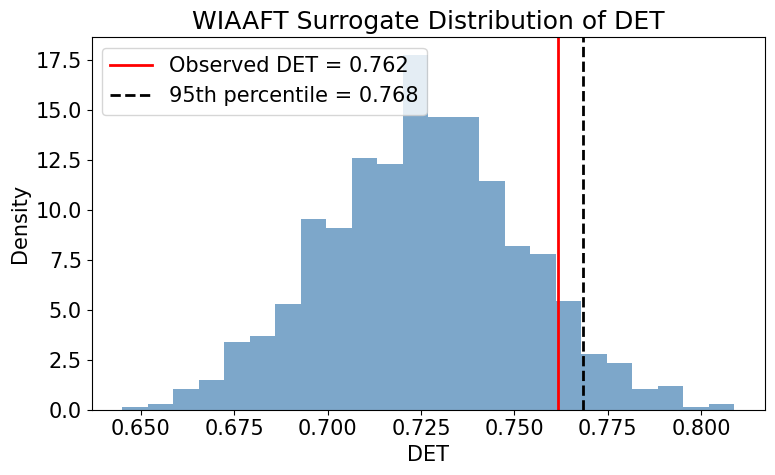

 69%|████████████████████████████▉             | 69/100 [38:42<16:17, 31.54s/it]

RQA  ig Embedding dimensions:5 
 DET of original:0.7616250611826686 
 Recurrence rate: 0.05001369612856099 
Threshold:1.320099999999871 
 Laminarity:0.3425376540384698 
Shannon Entropy:1.4911492913486954 
Rank-order p-value (det):0.088 
Reject null (det) hypothesis:False

 
 

62
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


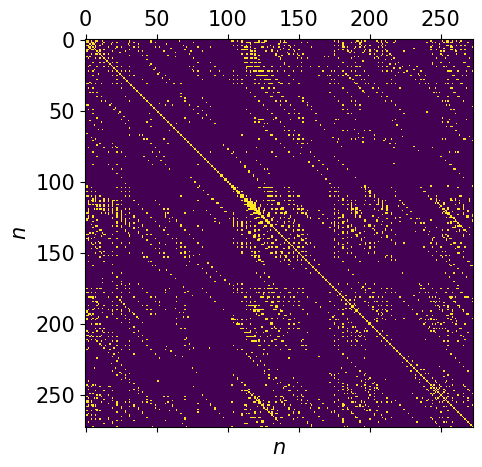

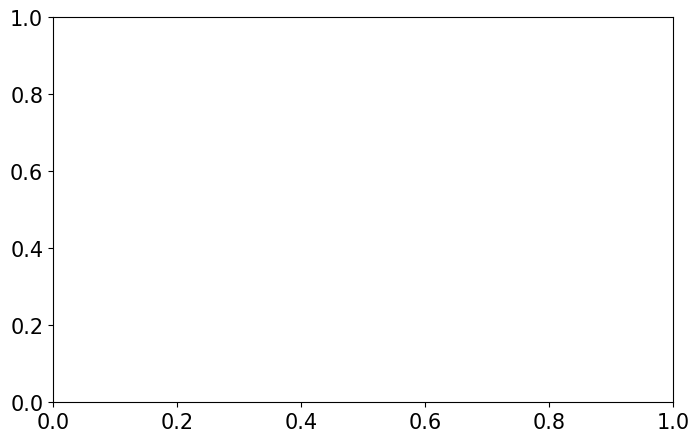

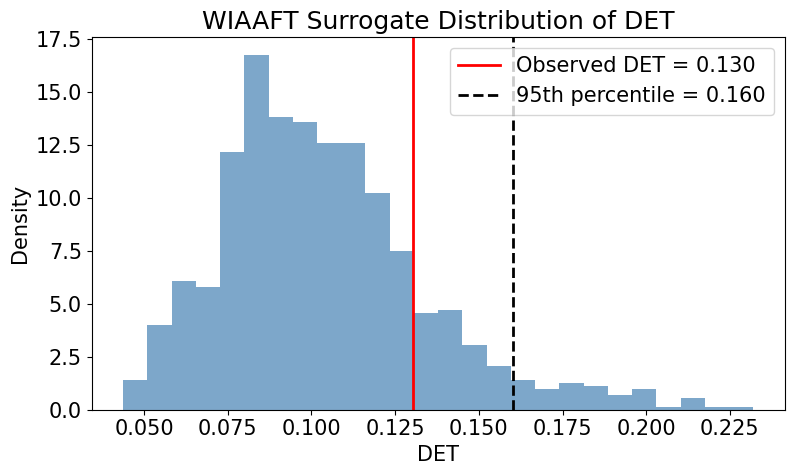

 70%|█████████████████████████████▍            | 70/100 [39:23<17:07, 34.24s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.13028372900946647 
 Recurrence rate: 0.050007379677709345 
Threshold:2.7892000000014616 
 Laminarity:0.23262677756846625 
Shannon Entropy:0.3258772394230109 
Rank-order p-value (det):0.159 
Reject null (det) hypothesis:False

 
 

62
No saturation detected (minimum FNN fallback)
8


Not enough points found!


WIAAFT surrogate datasets generated


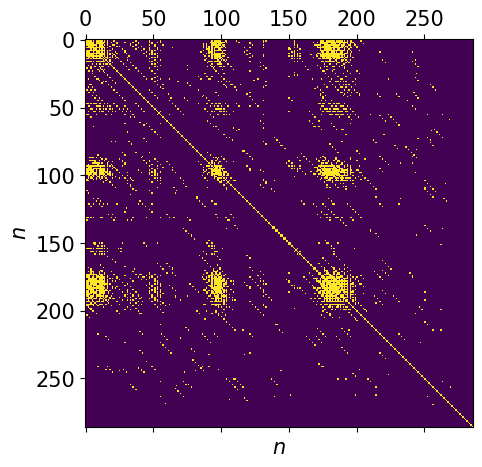

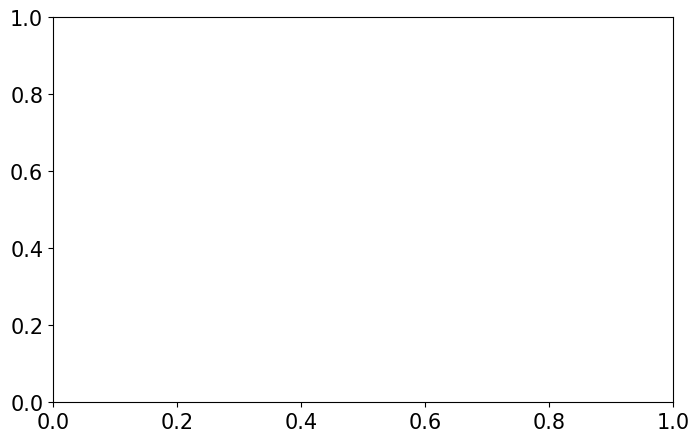

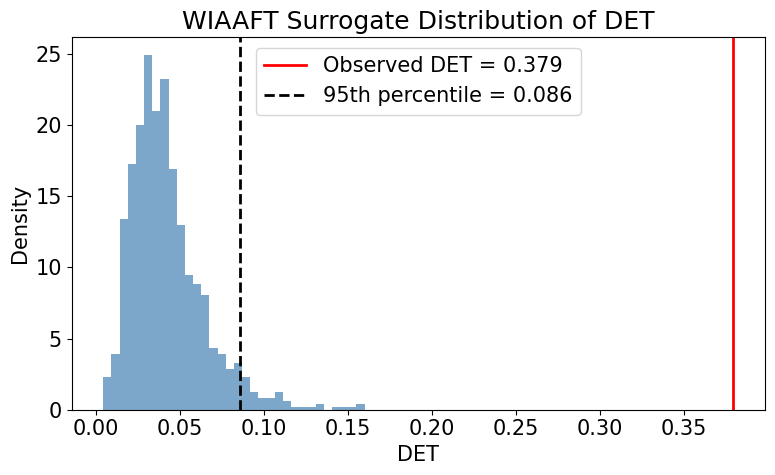

 71%|█████████████████████████████▊            | 71/100 [39:58<16:36, 34.36s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.37940094587393747 
 Recurrence rate: 0.05002689618074233 
Threshold:2.0895999999999852 
 Laminarity:0.4843597262940265 
Shannon Entropy:2.373608895959 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

63
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


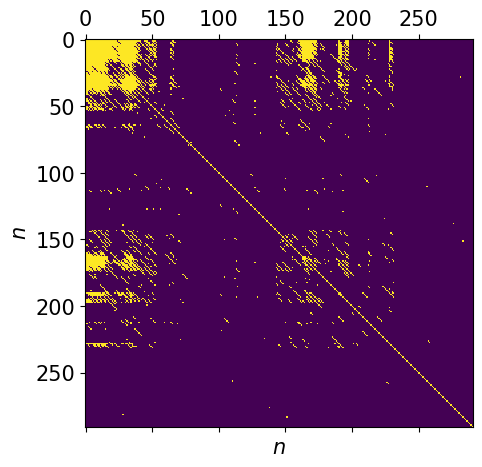

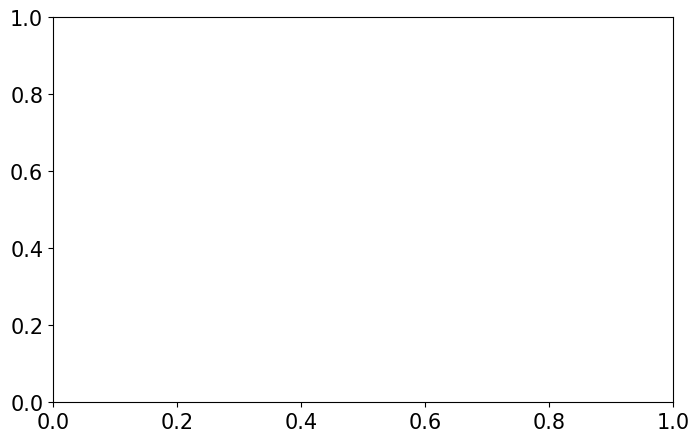

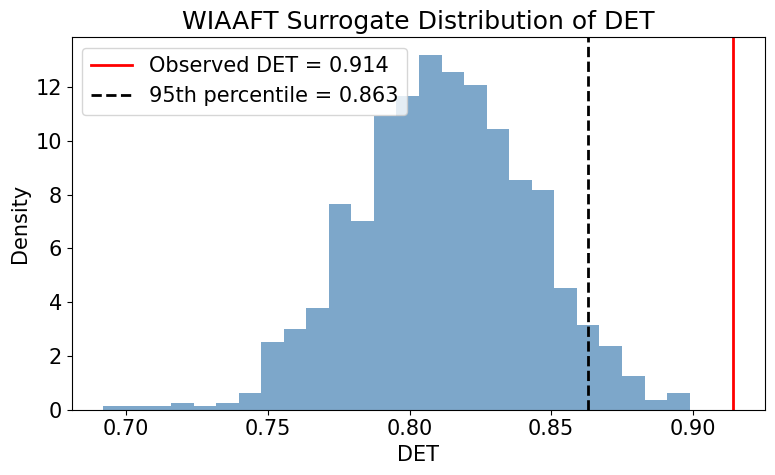

 72%|██████████████████████████████▏           | 72/100 [40:36<16:39, 35.71s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.914387031405992 
 Recurrence rate: 0.05005845467105963 
Threshold:2.323100000000478 
 Laminarity:0.5546119367762335 
Shannon Entropy:2.3675898670441153 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

64
No saturation detected (minimum FNN fallback)
7
WIAAFT surrogate datasets generated


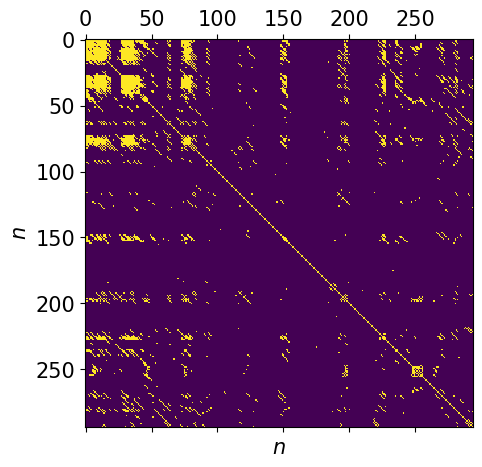

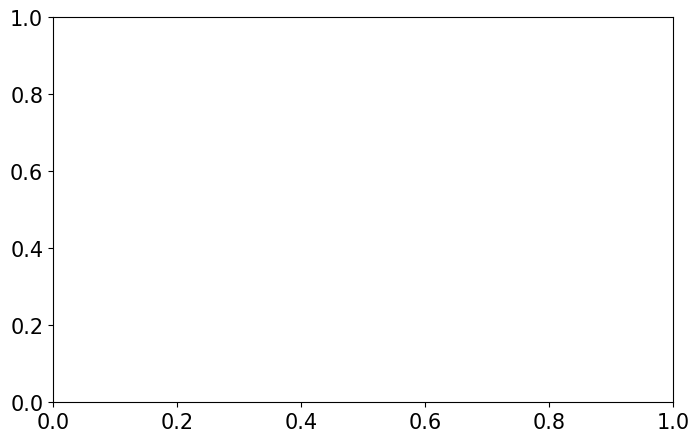

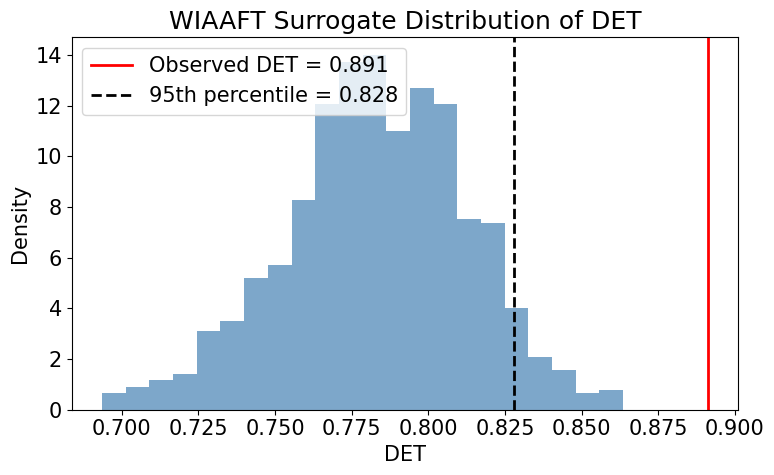

 73%|██████████████████████████████▋           | 73/100 [41:08<15:32, 34.52s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8912611717952055 
 Recurrence rate: 0.05000231385071035 
Threshold:1.6806999999998313 
 Laminarity:0.5120314669122813 
Shannon Entropy:1.941273330246954 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

65
No saturation detected (minimum FNN fallback)
7
WIAAFT surrogate datasets generated


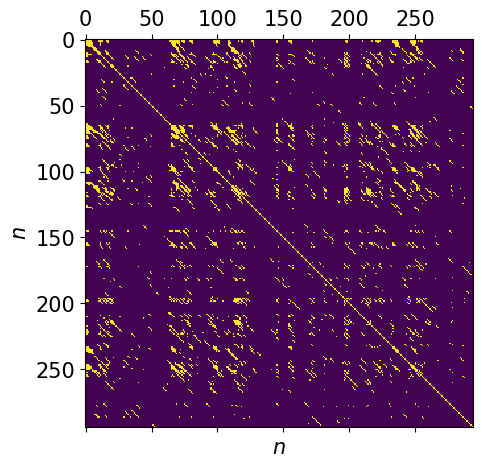

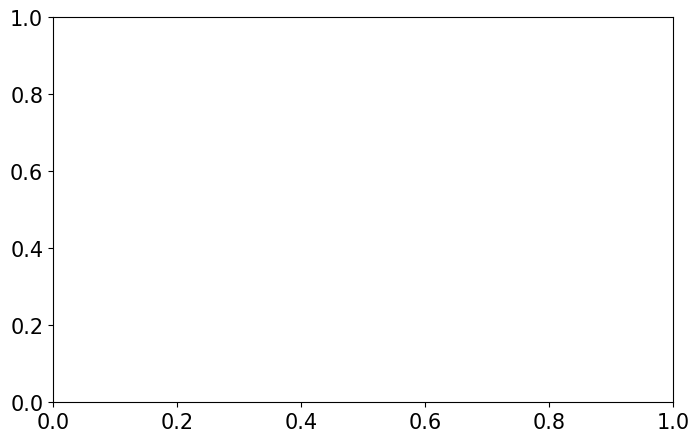

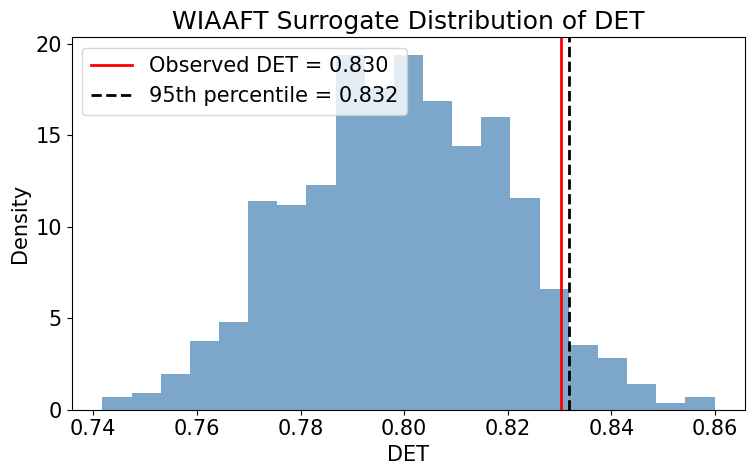

 74%|███████████████████████████████           | 74/100 [41:43<14:57, 34.51s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.830188679243222 
 Recurrence rate: 0.05000231385071035 
Threshold:2.010299999999818 
 Laminarity:0.3831559463202611 
Shannon Entropy:1.625061835334437 
Rank-order p-value (det):0.059 
Reject null (det) hypothesis:False

 
 

65
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


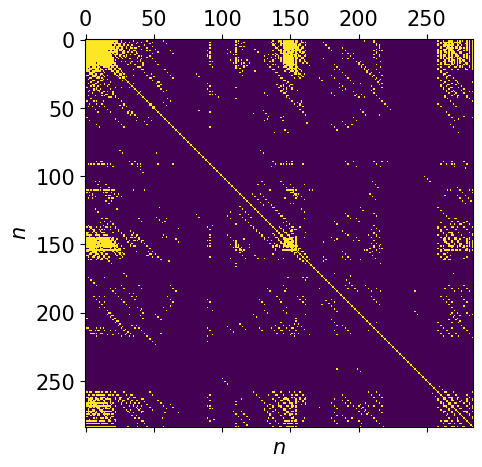

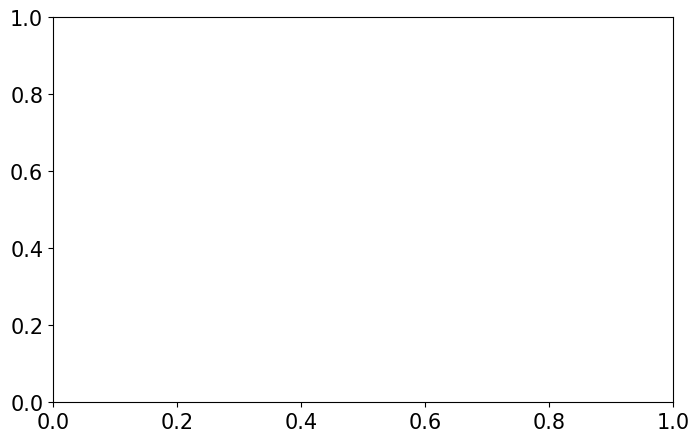

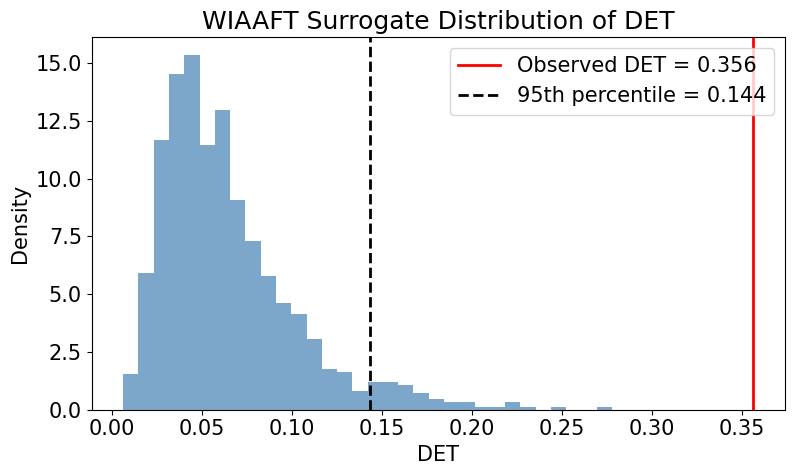

 75%|███████████████████████████████▌          | 75/100 [42:18<14:31, 34.84s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.35626666666571666 
 Recurrence rate: 0.050014878000396744 
Threshold:2.1736000000001625 
 Laminarity:0.4826474962804099 
Shannon Entropy:2.4897563544263437 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

66
No saturation detected (minimum FNN fallback)
7


Not enough points found!


WIAAFT surrogate datasets generated


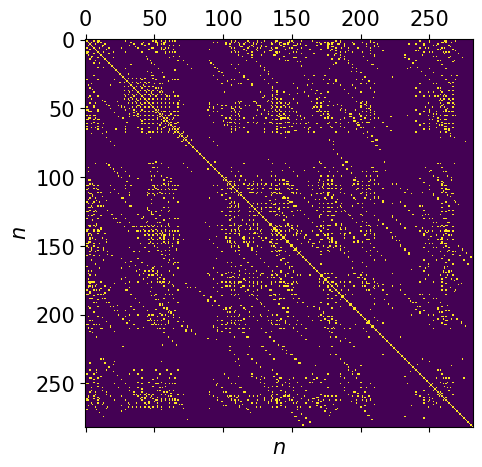

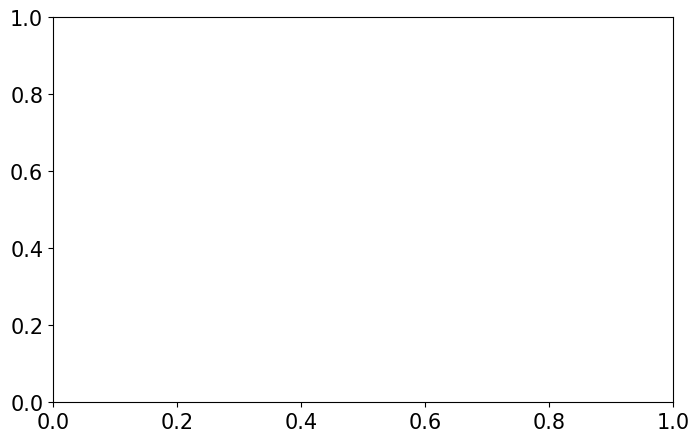

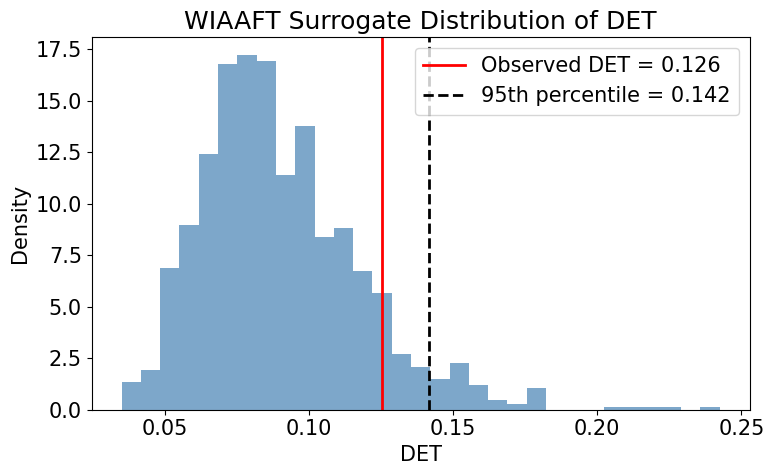

 76%|███████████████████████████████▉          | 76/100 [42:51<13:42, 34.28s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.12554112554078586 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9656999999998 
 Laminarity:0.15108094519821247 
Shannon Entropy:0.04991801434392776 
Rank-order p-value (det):0.1 
Reject null (det) hypothesis:False

 
 

66
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


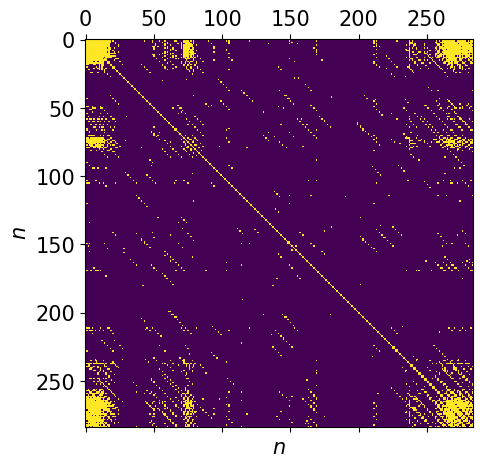

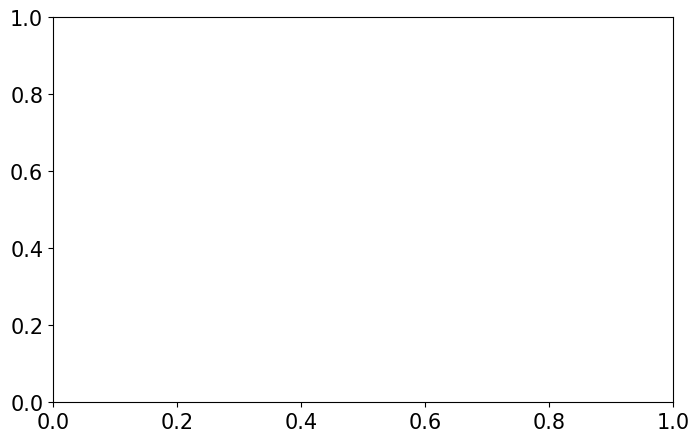

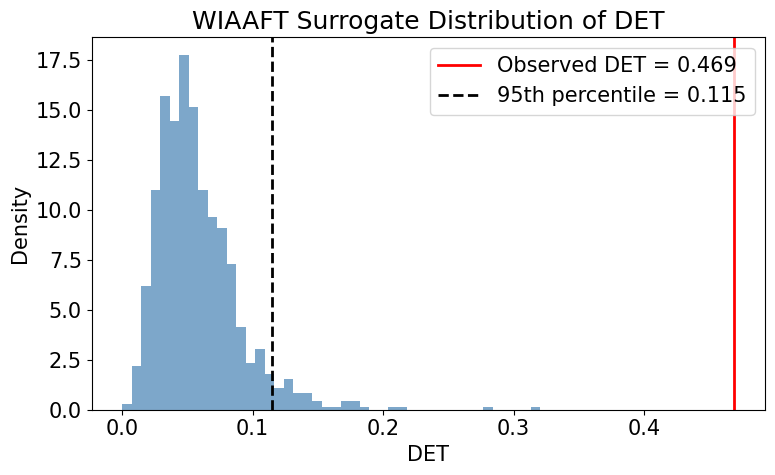

 77%|████████████████████████████████▎         | 77/100 [43:29<13:30, 35.22s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.46933333333208177 
 Recurrence rate: 0.050014878000396744 
Threshold:2.321600000000475 
 Laminarity:0.5632126921156093 
Shannon Entropy:2.5713515186012406 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

67
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


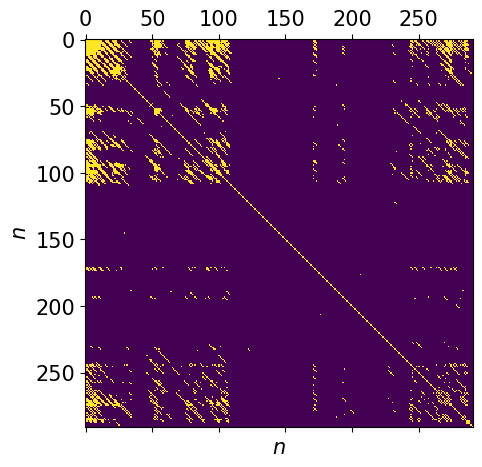

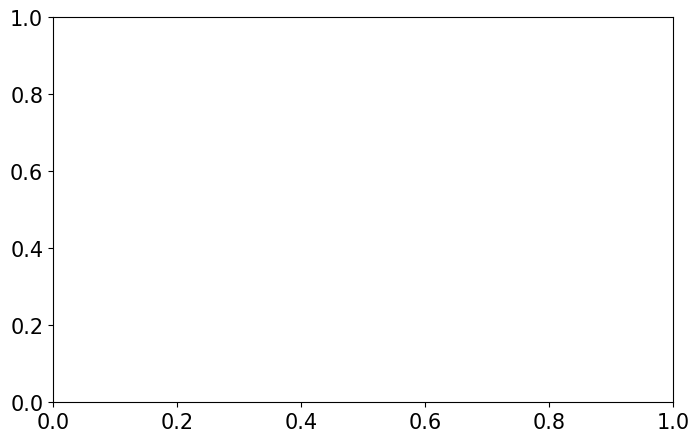

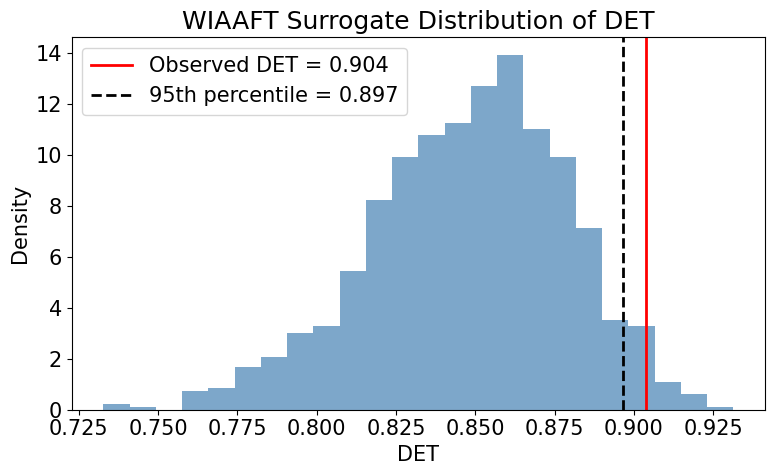

 78%|████████████████████████████████▊         | 78/100 [44:05<13:01, 35.51s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9036999493134726 
 Recurrence rate: 0.050034836622146646 
Threshold:2.0028999999998023 
 Laminarity:0.5057823932015441 
Shannon Entropy:2.1403039406925117 
Rank-order p-value (det):0.025 
Reject null (det) hypothesis:True

 
 

68
No saturation detected (minimum FNN fallback)
9


Not enough points found!


WIAAFT surrogate datasets generated


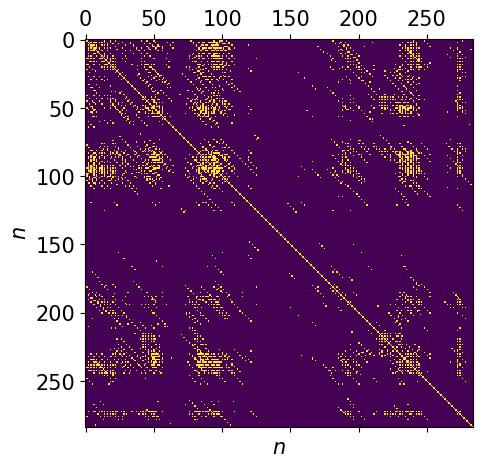

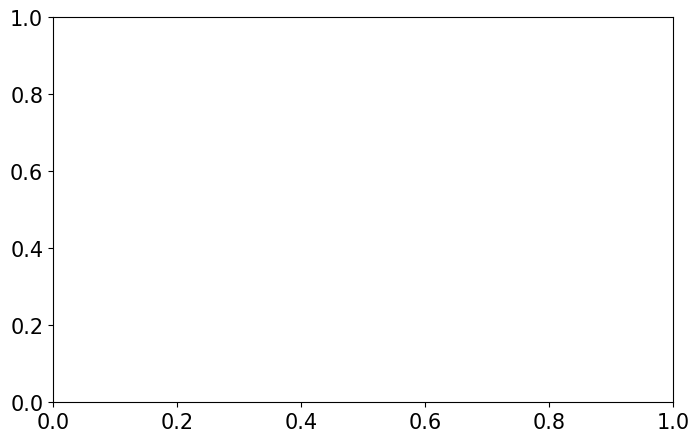

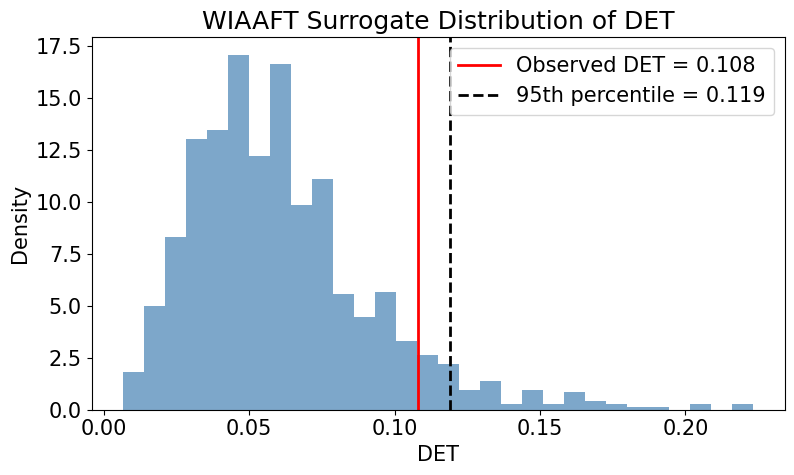

 79%|█████████████████████████████████▏        | 79/100 [44:42<12:33, 35.88s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.1082089552235922 
 Recurrence rate: 0.05003967466772466 
Threshold:2.2054000000002296 
 Laminarity:0.2195242814662549 
Shannon Entropy:1.5949399159822746 
Rank-order p-value (det):0.081 
Reject null (det) hypothesis:False

 
 

68
No saturation detected (minimum FNN fallback)
6


Not enough points found!


WIAAFT surrogate datasets generated


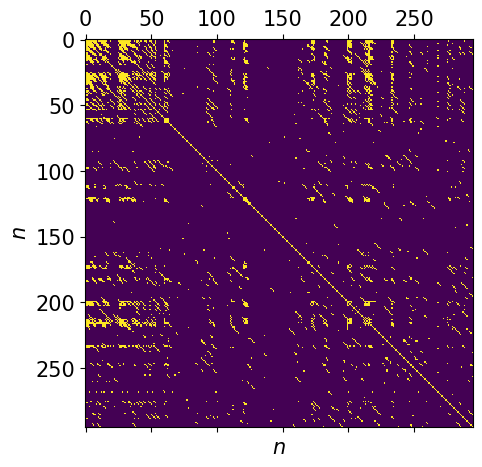

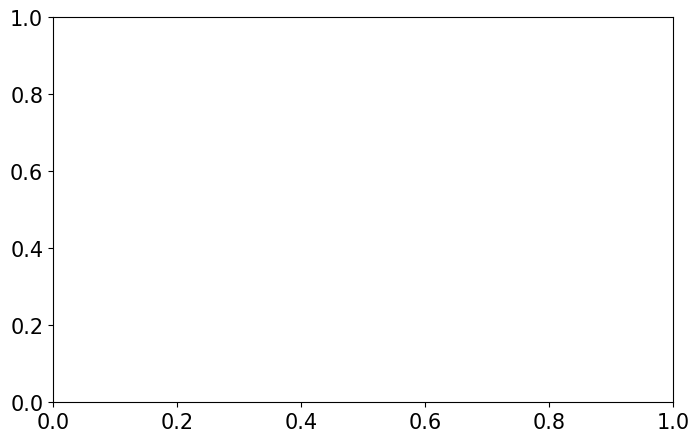

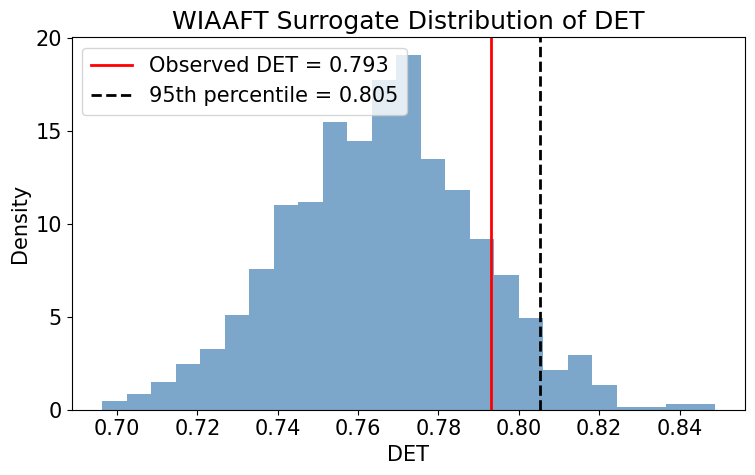

 80%|█████████████████████████████████▌        | 80/100 [45:12<11:27, 34.38s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.7930014785589132 
 Recurrence rate: 0.05002010916403332 
Threshold:1.6552999999998341 
 Laminarity:0.42430507695744474 
Shannon Entropy:1.5696967327479951 
Rank-order p-value (det):0.126 
Reject null (det) hypothesis:False

 
 

68
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


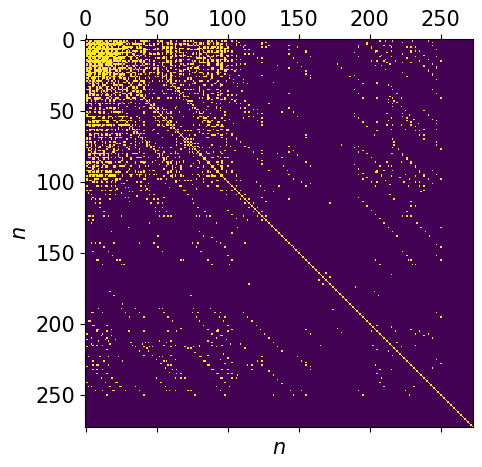

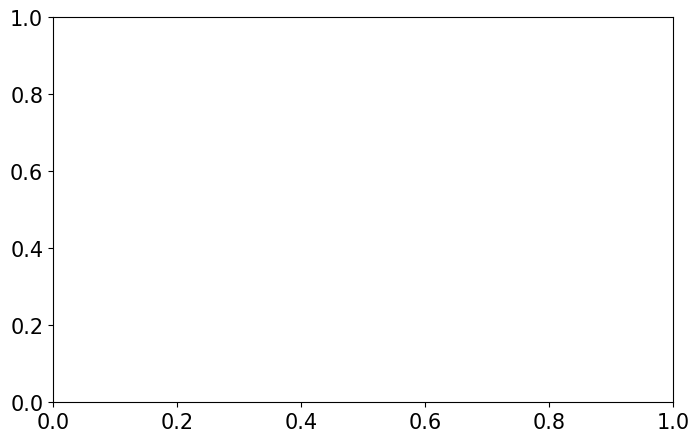

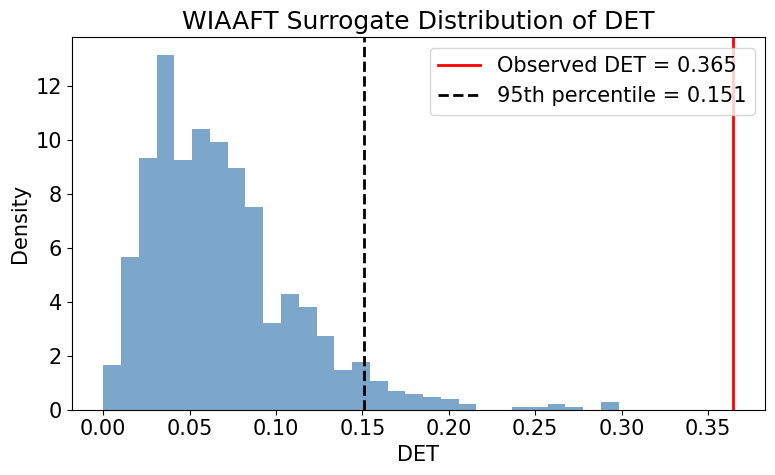

 81%|██████████████████████████████████        | 81/100 [45:47<10:54, 34.47s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.3647944412265061 
 Recurrence rate: 0.050007379677709345 
Threshold:2.117400000000044 
 Laminarity:0.44539844378737486 
Shannon Entropy:0.5420874251680946 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

69
No saturation detected (minimum FNN fallback)
6
WIAAFT surrogate datasets generated


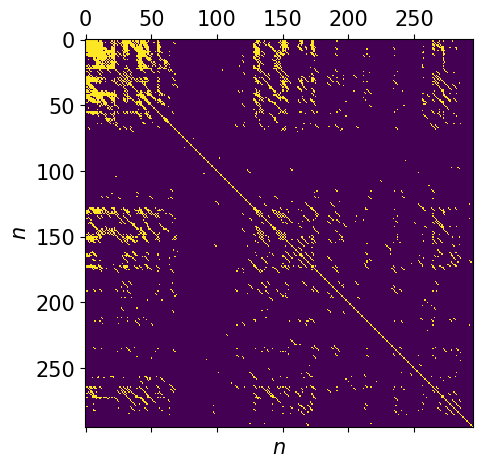

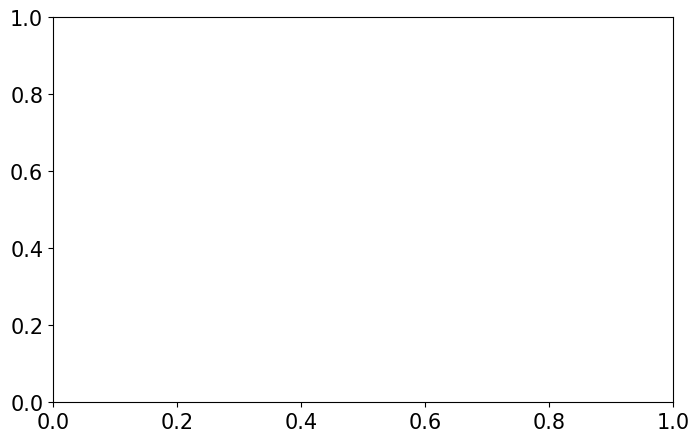

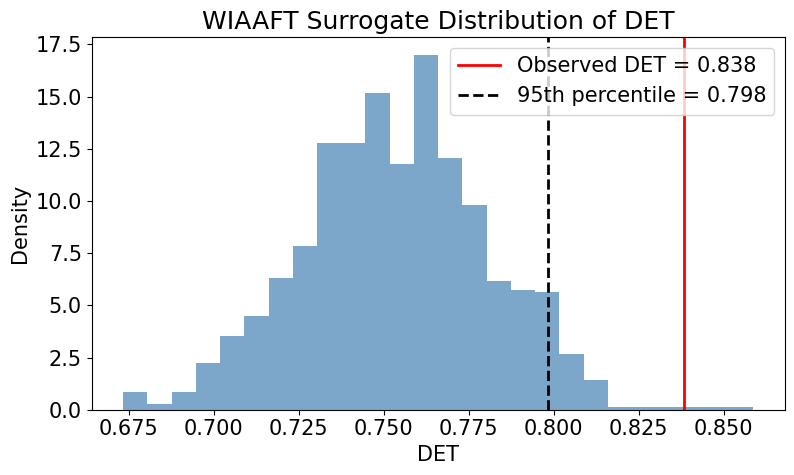

 82%|██████████████████████████████████▍       | 82/100 [46:17<09:57, 33.20s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.838423645318132 
 Recurrence rate: 0.050043091065785694 
Threshold:1.5370999999998471 
 Laminarity:0.45350172215739726 
Shannon Entropy:1.826818958725913 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

70
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


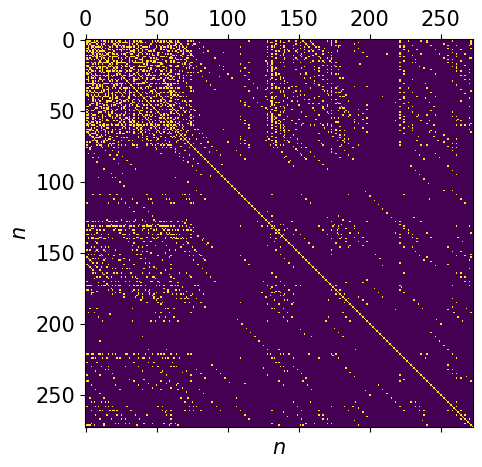

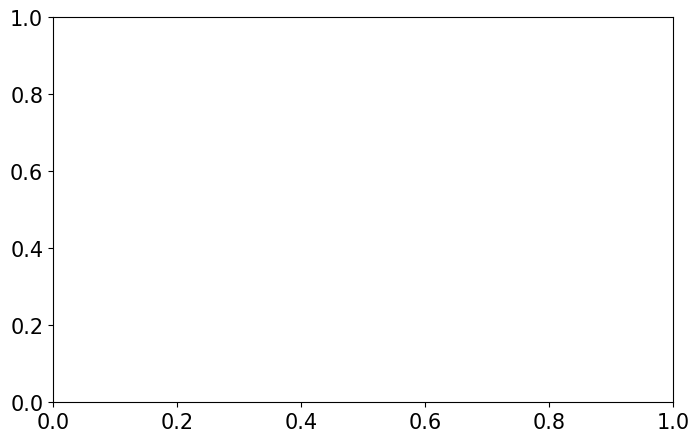

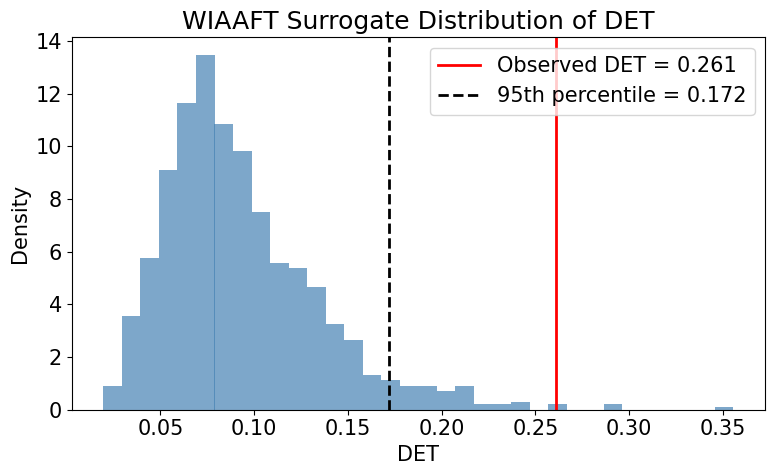

 83%|██████████████████████████████████▊       | 83/100 [46:56<09:51, 34.80s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.2609953703696152 
 Recurrence rate: 0.05003421486937971 
Threshold:2.6404000000011476 
 Laminarity:0.2000536336814158 
Shannon Entropy:0.4674638974196791 
Rank-order p-value (det):0.005 
Reject null (det) hypothesis:True

 
 

71
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


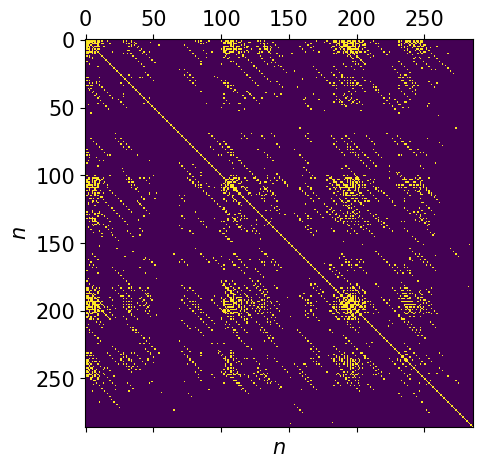

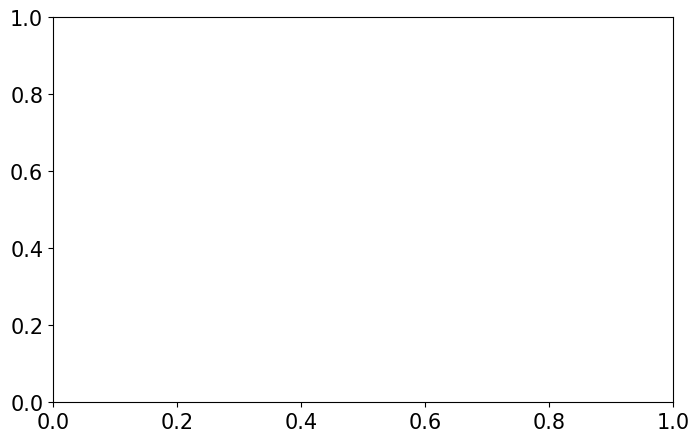

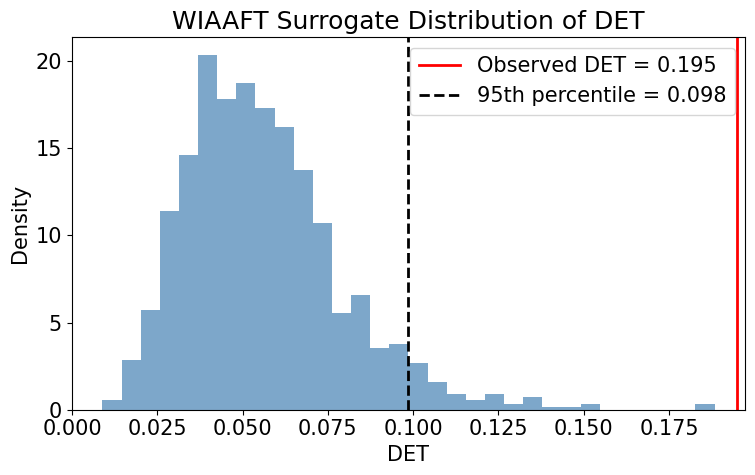

 84%|███████████████████████████████████▎      | 84/100 [47:31<09:20, 35.02s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.1950578338585829 
 Recurrence rate: 0.05000244510734021 
Threshold:2.1693000000001534 
 Laminarity:0.2929095354516066 
Shannon Entropy:1.7417022290515718 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

72
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


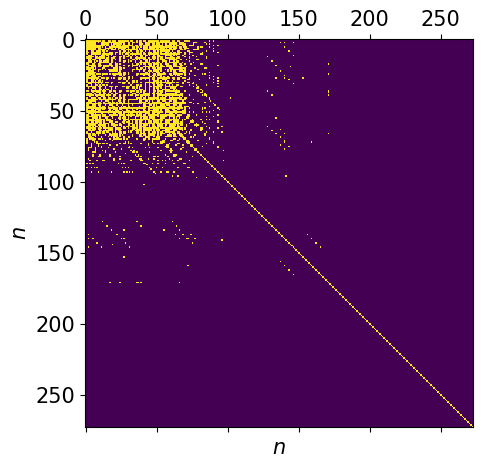

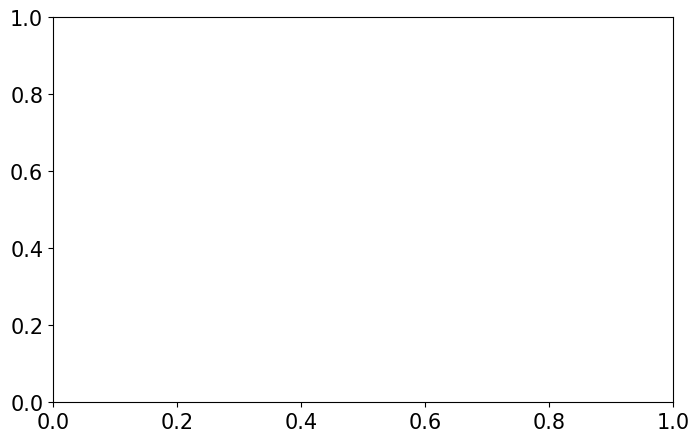

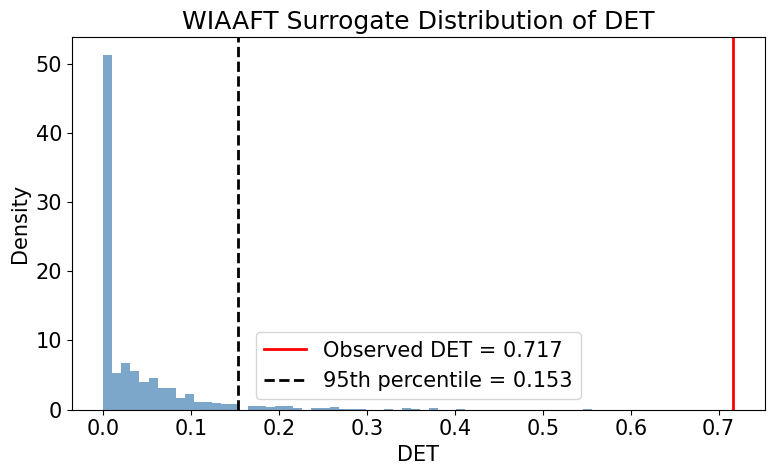

 85%|███████████████████████████████████▋      | 85/100 [47:59<08:12, 32.84s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.7168500289498644 
 Recurrence rate: 0.050007379677709345 
Threshold:1.2128999999998828 
 Laminarity:0.7512744834967768 
Shannon Entropy:1.0672837866756335 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

73
No saturation detected (minimum FNN fallback)
7
WIAAFT surrogate datasets generated


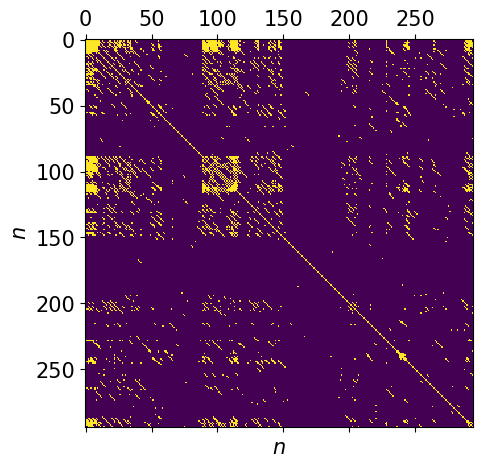

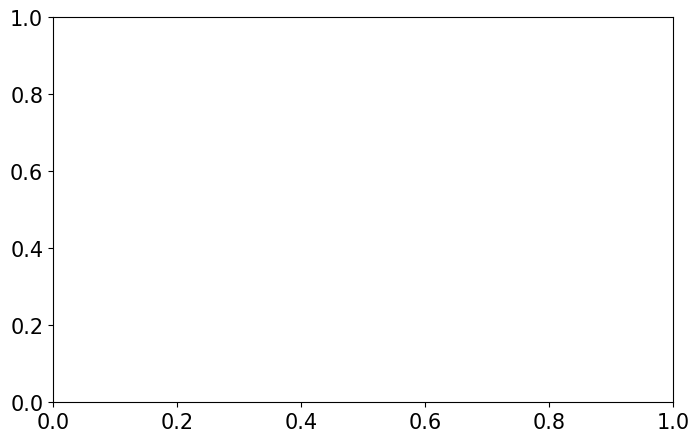

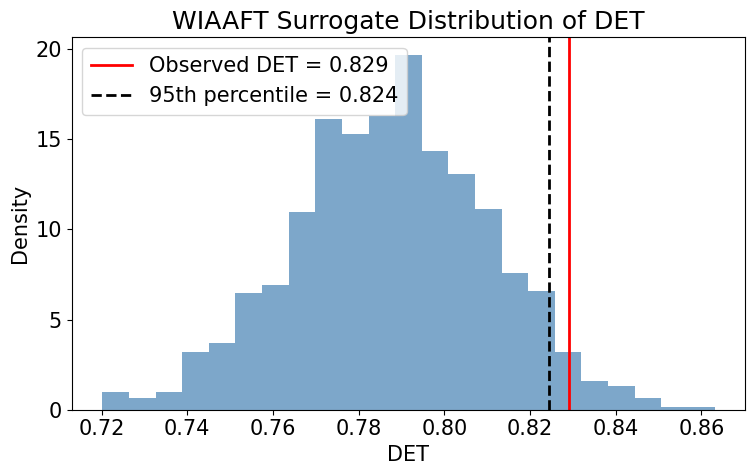

 86%|████████████████████████████████████      | 86/100 [48:33<07:44, 33.18s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8291956305838402 
 Recurrence rate: 0.05000231385071035 
Threshold:1.8773999999998097 
 Laminarity:0.3322535863018689 
Shannon Entropy:1.8039666683292699 
Rank-order p-value (det):0.031 
Reject null (det) hypothesis:True

 
 

74
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


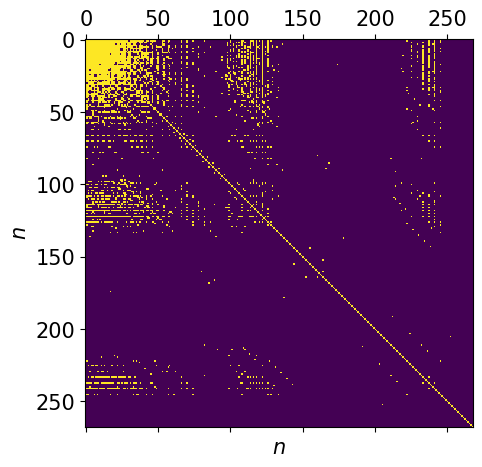

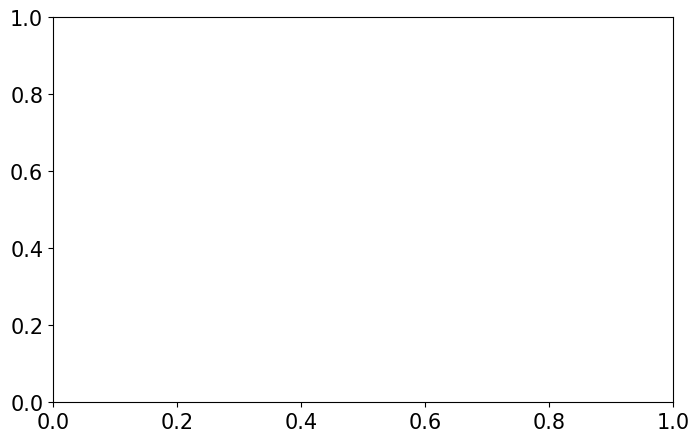

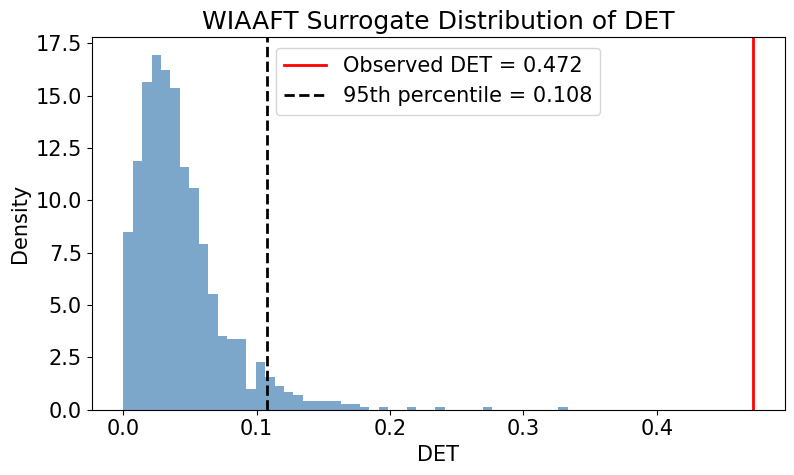

 87%|████████████████████████████████████▌     | 87/100 [49:07<07:13, 33.32s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.4723225030070027 
 Recurrence rate: 0.05001113833815995 
Threshold:2.0390999999998787 
 Laminarity:0.5545657015574762 
Shannon Entropy:1.2687783813599003 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

75
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


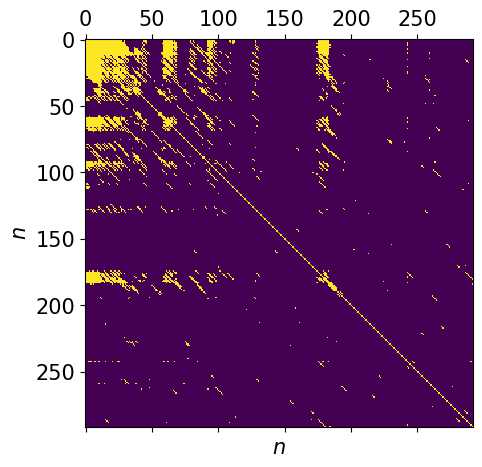

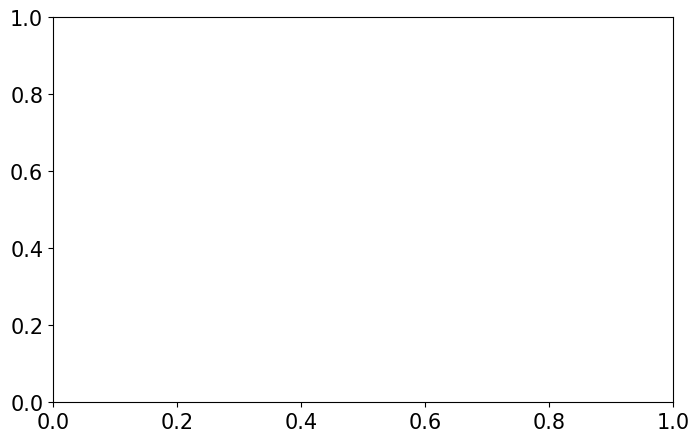

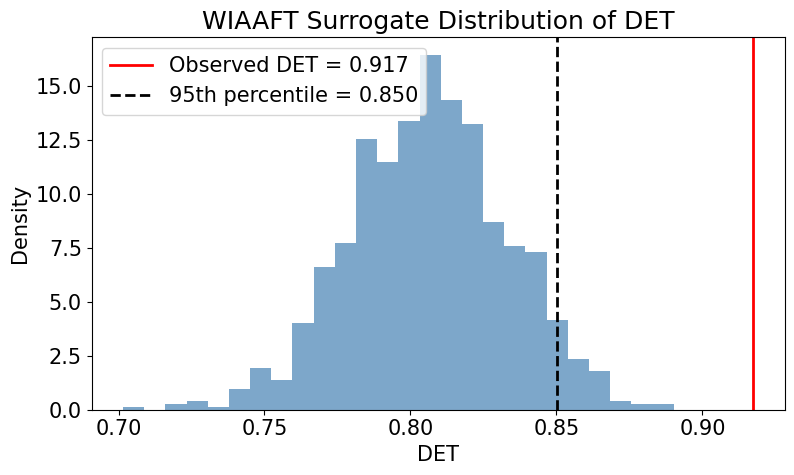

 88%|████████████████████████████████████▉     | 88/100 [49:45<06:55, 34.63s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9174219536734204 
 Recurrence rate: 0.0500093826233815 
Threshold:2.224100000000269 
 Laminarity:0.6468105065650872 
Shannon Entropy:2.419622137281509 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

76
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


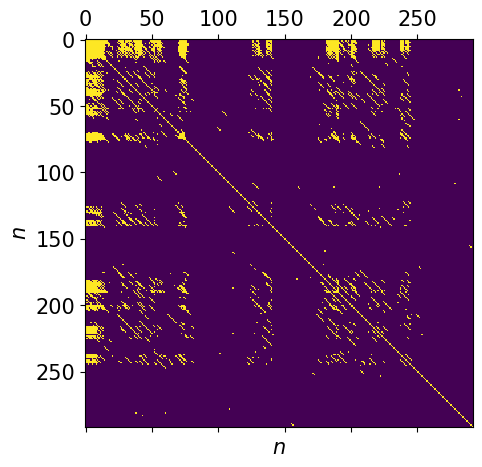

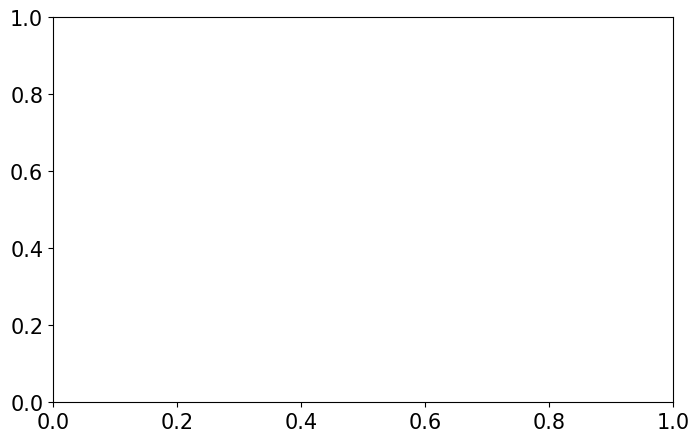

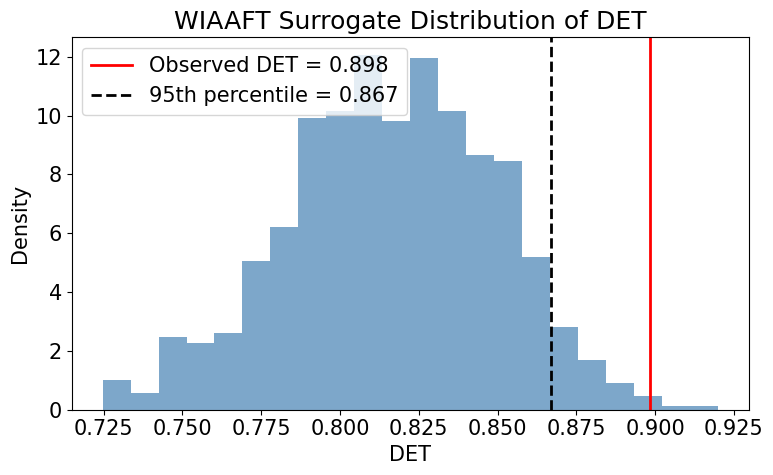

 89%|█████████████████████████████████████▍    | 89/100 [50:21<06:28, 35.30s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8983392048291436 
 Recurrence rate: 0.050032839181835244 
Threshold:2.0180999999998344 
 Laminarity:0.5154711673686933 
Shannon Entropy:2.048543921135092 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

77
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


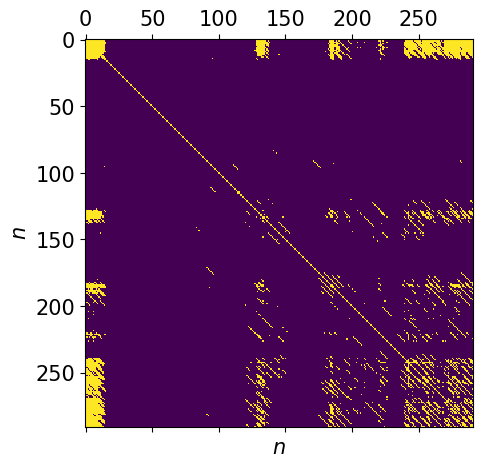

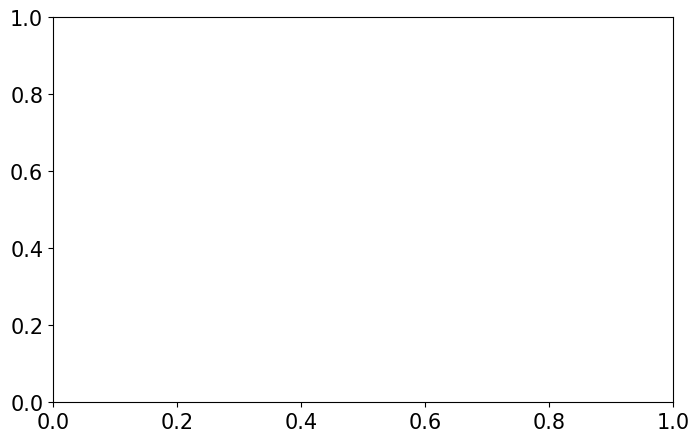

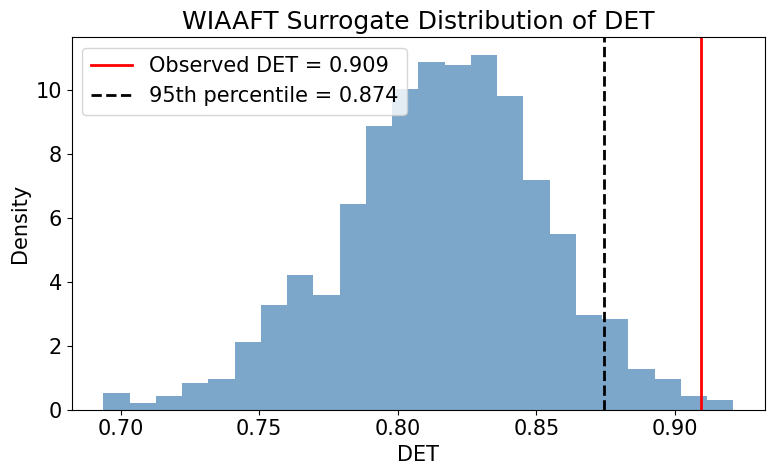

 90%|█████████████████████████████████████▊    | 90/100 [50:59<06:00, 36.04s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9092292089226439 
 Recurrence rate: 0.050011218573233665 
Threshold:2.1228000000000553 
 Laminarity:0.6011806375428543 
Shannon Entropy:2.356103470650148 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

78
No saturation detected (minimum FNN fallback)
10
WIAAFT surrogate datasets generated


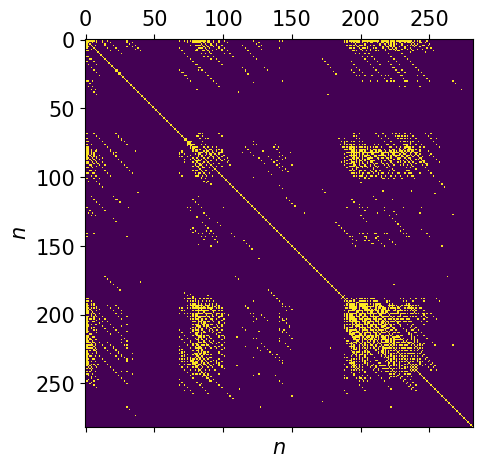

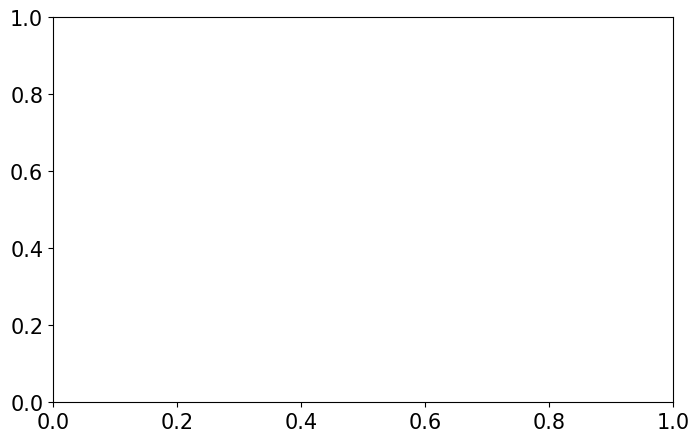

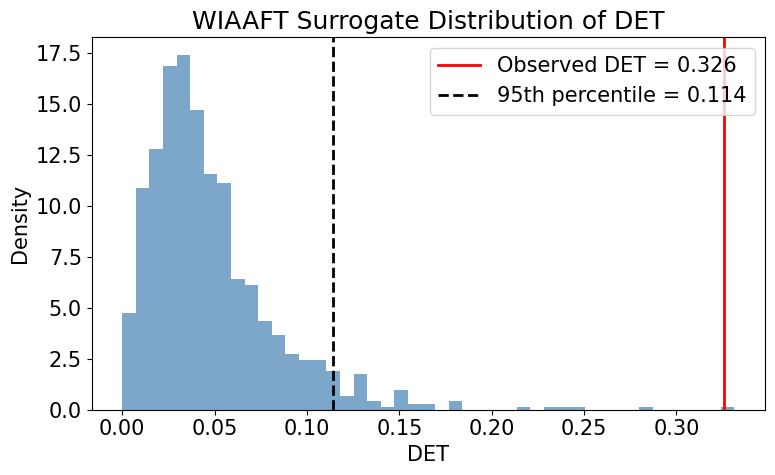

 91%|██████████████████████████████████████▏   | 91/100 [51:38<05:30, 36.77s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.32558139534795677 
 Recurrence rate: 0.050047784316684274 
Threshold:2.3251000000004822 
 Laminarity:0.42286432160697773 
Shannon Entropy:2.0621060437280896 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

79
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


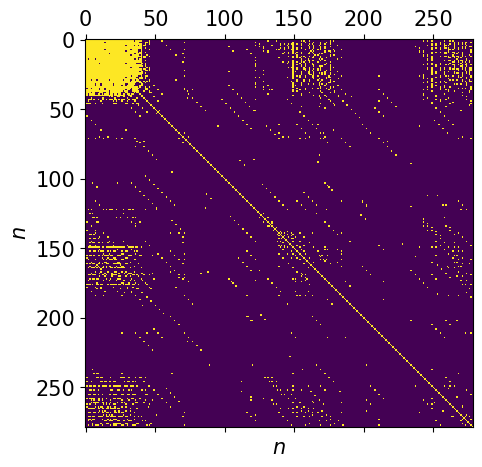

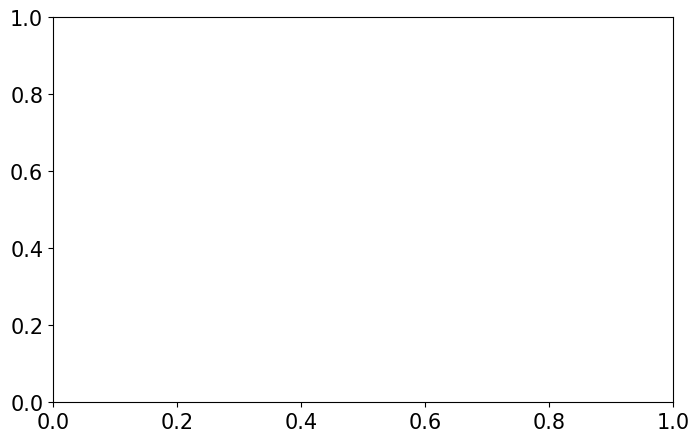

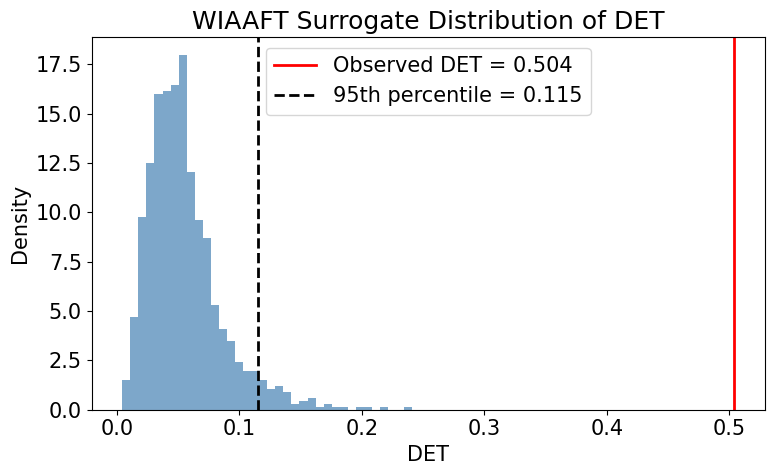

 92%|██████████████████████████████████████▋   | 92/100 [52:11<04:45, 35.64s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.5041505257318646 
 Recurrence rate: 0.050012204365308774 
Threshold:1.9892999999997973 
 Laminarity:0.5345491908540083 
Shannon Entropy:1.4191389057220147 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

80
No saturation detected (minimum FNN fallback)
8
WIAAFT surrogate datasets generated


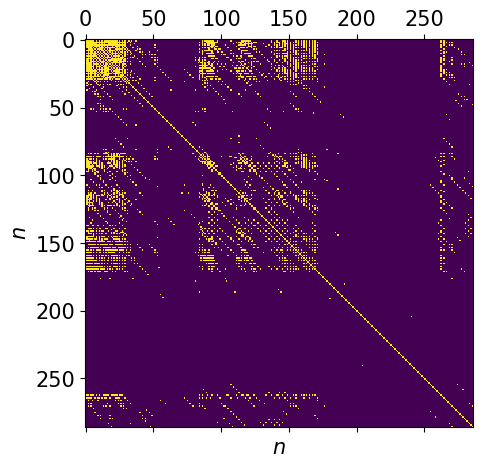

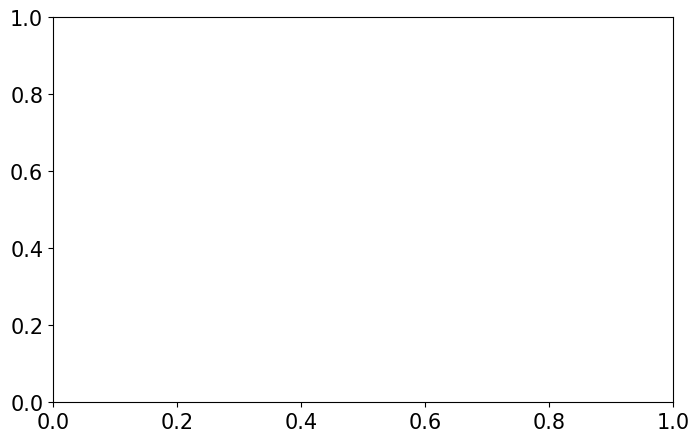

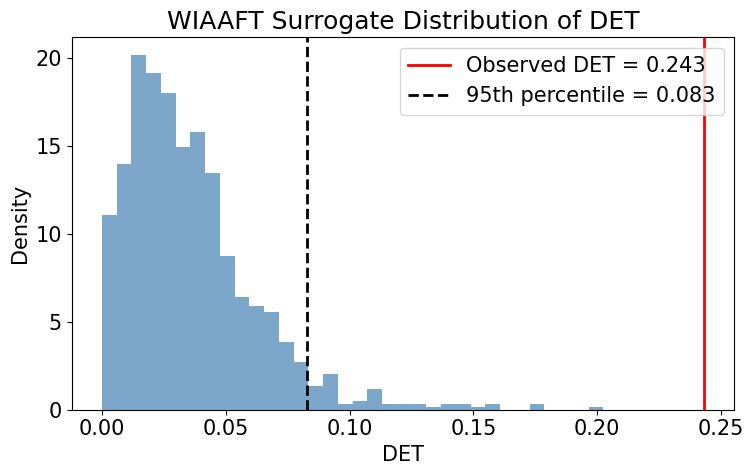

 93%|███████████████████████████████████████   | 93/100 [52:43<04:01, 34.55s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.24317226890692445 
 Recurrence rate: 0.05005134725414446 
Threshold:1.7081999999998283 
 Laminarity:0.3544211040538485 
Shannon Entropy:2.1607550375568856 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

81
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


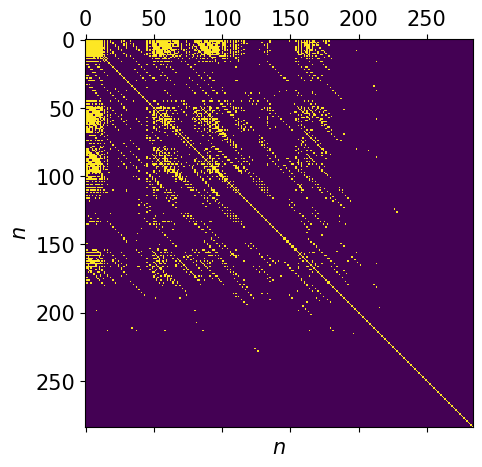

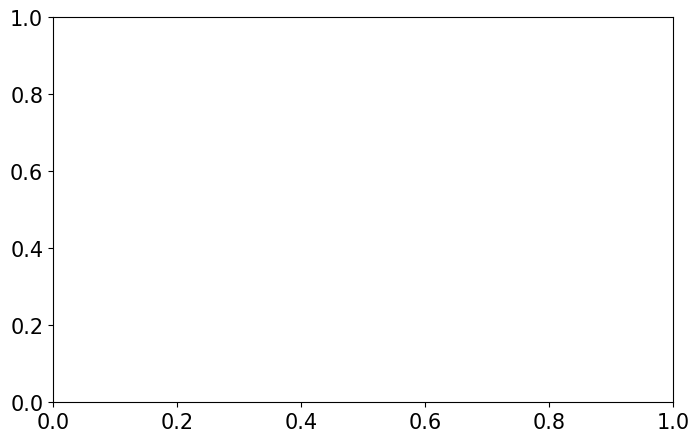

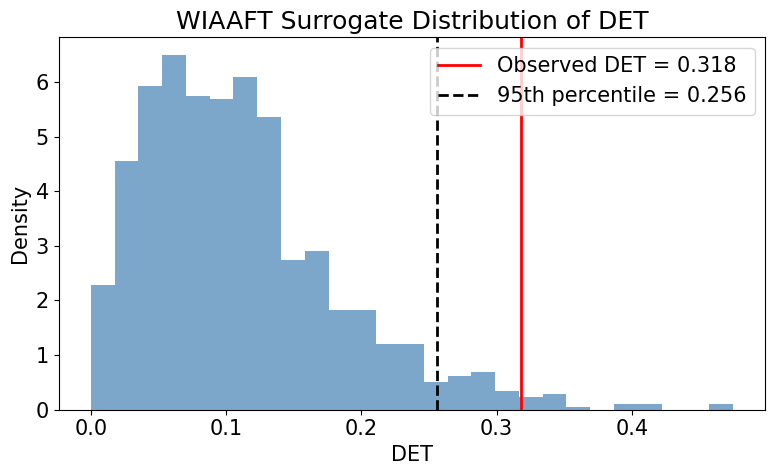

 94%|███████████████████████████████████████▍  | 94/100 [53:12<03:18, 33.08s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.31786666666581903 
 Recurrence rate: 0.050014878000396744 
Threshold:1.3969999999998626 
 Laminarity:0.45116509667711663 
Shannon Entropy:2.3533534647996137 
Rank-order p-value (det):0.016 
Reject null (det) hypothesis:True

 
 

82
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


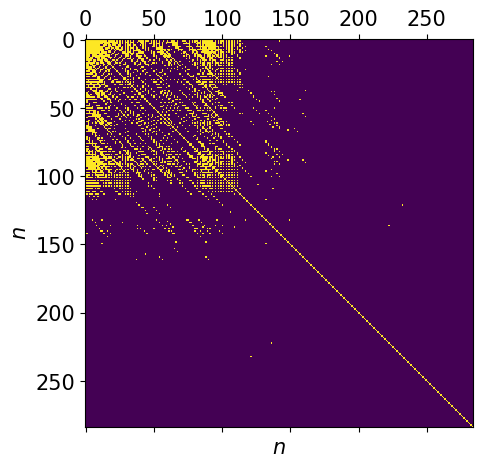

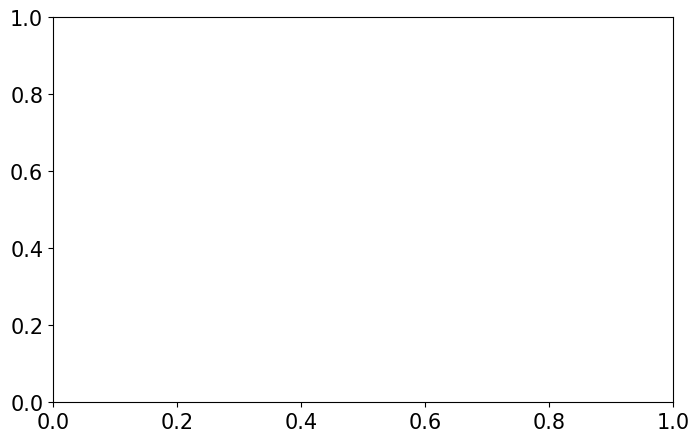

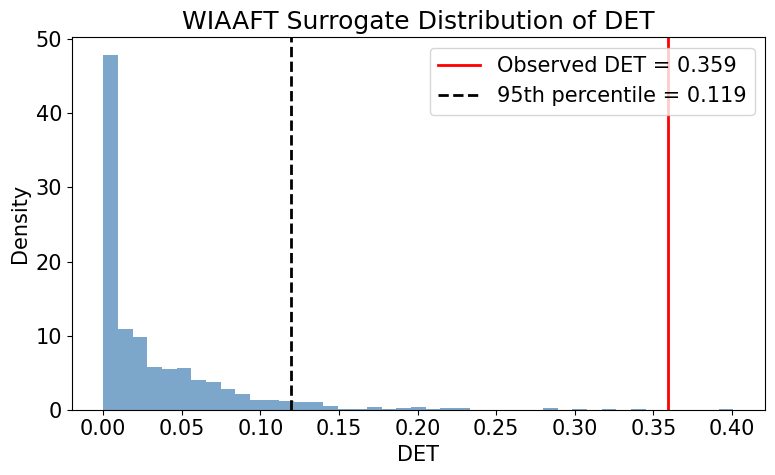

 95%|███████████████████████████████████████▉  | 95/100 [53:43<02:41, 32.26s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.3594666666657081 
 Recurrence rate: 0.050014878000396744 
Threshold:1.446899999999857 
 Laminarity:0.5208230044607813 
Shannon Entropy:2.377064908411592 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

83
No saturation detected (minimum FNN fallback)
9


Not enough points found!


WIAAFT surrogate datasets generated


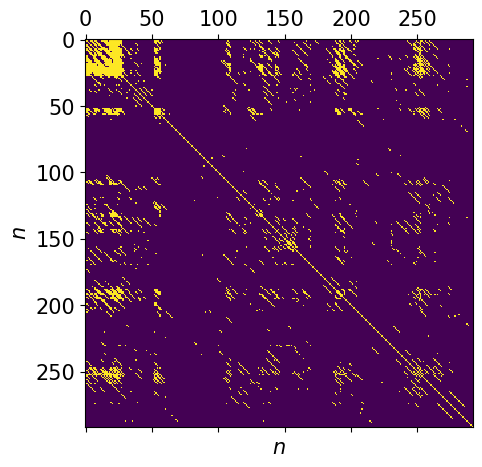

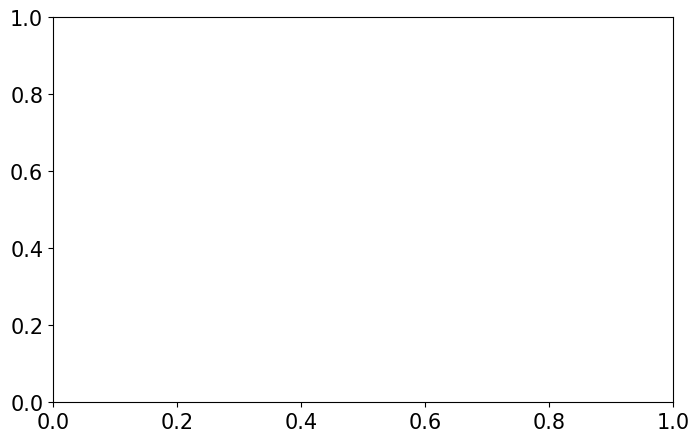

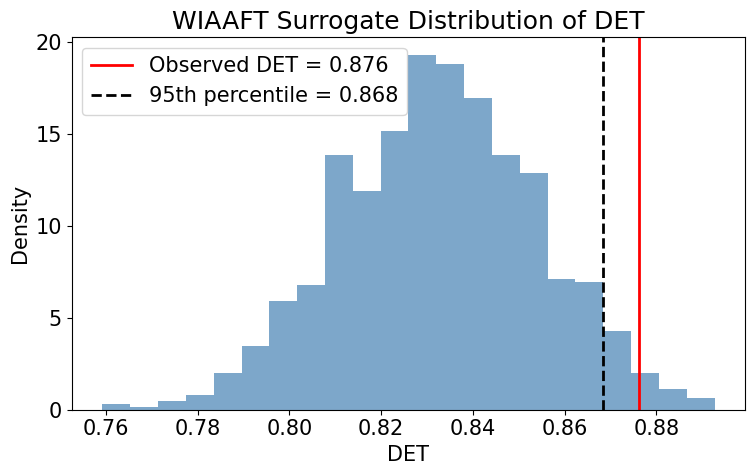

 96%|████████████████████████████████████████▎ | 96/100 [54:23<02:18, 34.70s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8761329305113894 
 Recurrence rate: 0.0500093826233815 
Threshold:2.407500000000656 
 Laminarity:0.4352720450271218 
Shannon Entropy:2.0859248664496697 
Rank-order p-value (det):0.017 
Reject null (det) hypothesis:True

 
 

84
No saturation detected (minimum FNN fallback)
7


Not enough points found!


WIAAFT surrogate datasets generated


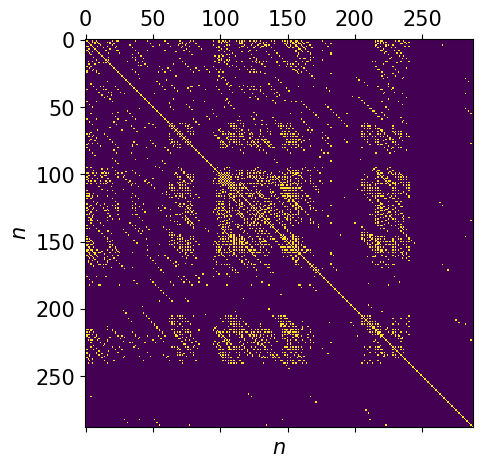

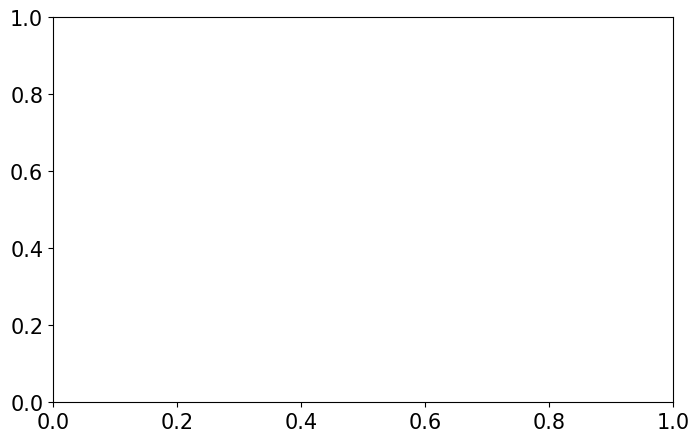

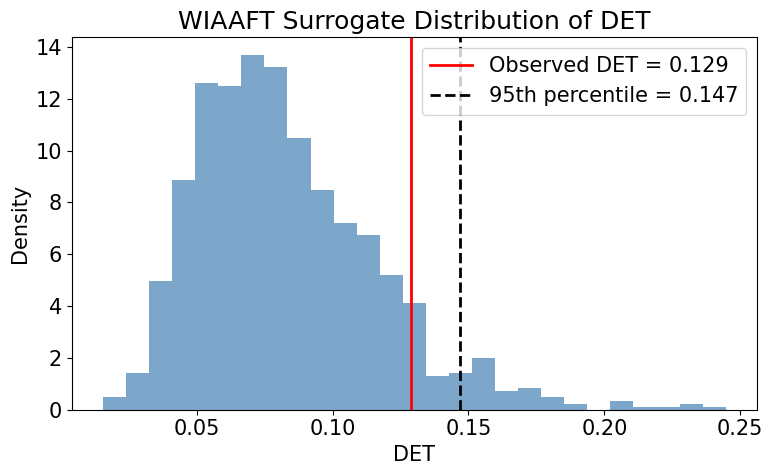

 97%|████████████████████████████████████████▋ | 97/100 [54:54<01:40, 33.66s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.12901554404111654 
 Recurrence rate: 0.05000964506172839 
Threshold:1.7732999999998211 
 Laminarity:0.16224686595910742 
Shannon Entropy:1.666951592225529 
Rank-order p-value (det):0.086 
Reject null (det) hypothesis:False

 
 

84
No saturation detected (minimum FNN fallback)
9
WIAAFT surrogate datasets generated


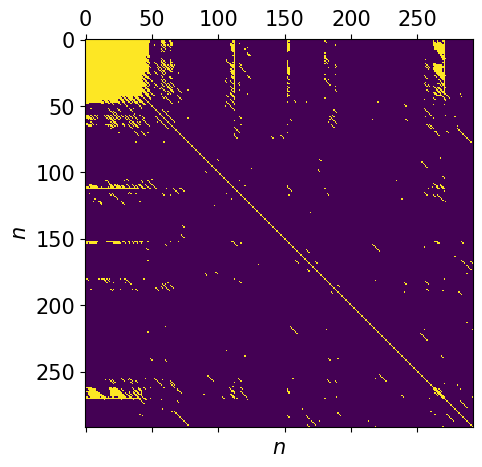

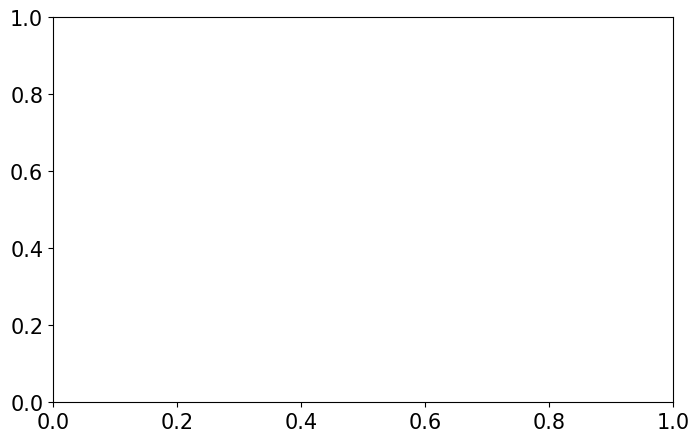

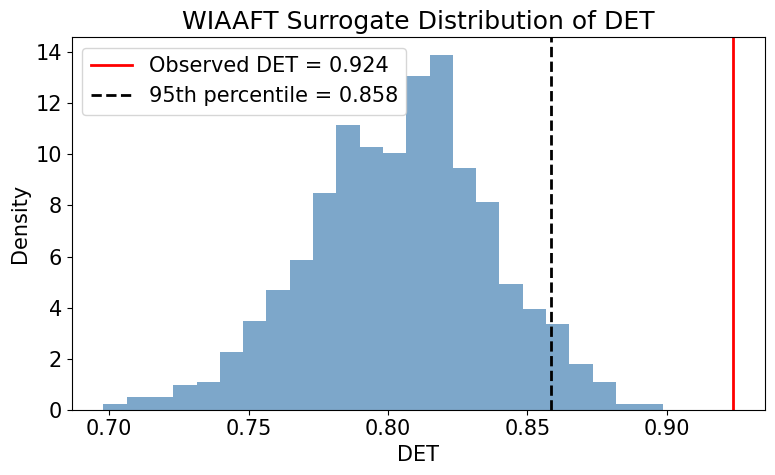

 98%|█████████████████████████████████████████▏| 98/100 [55:30<01:08, 34.41s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9239677744186204 
 Recurrence rate: 0.0500093826233815 
Threshold:2.137400000000086 
 Laminarity:0.720684803000186 
Shannon Entropy:2.424920723395423 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 

85
No saturation detected (minimum FNN fallback)
6


Not enough points found!


WIAAFT surrogate datasets generated


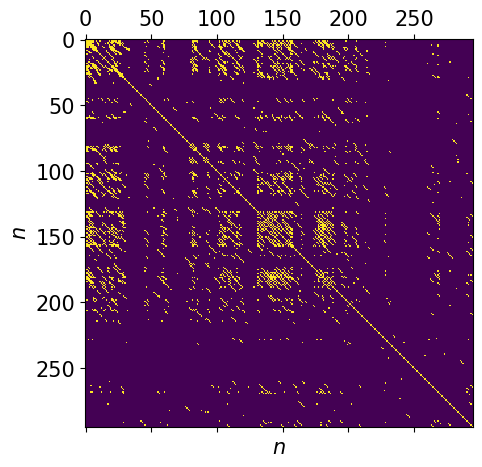

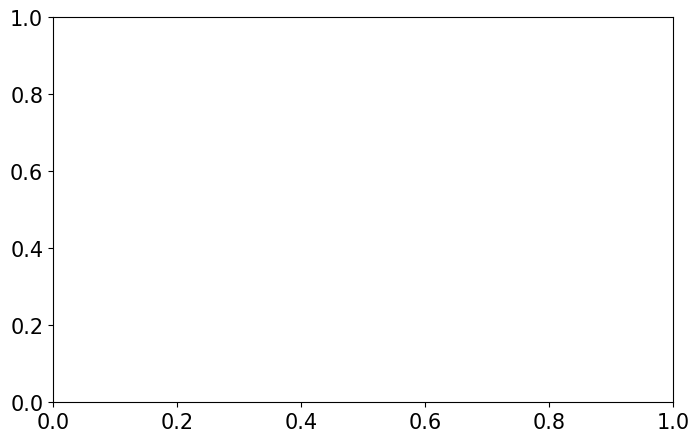

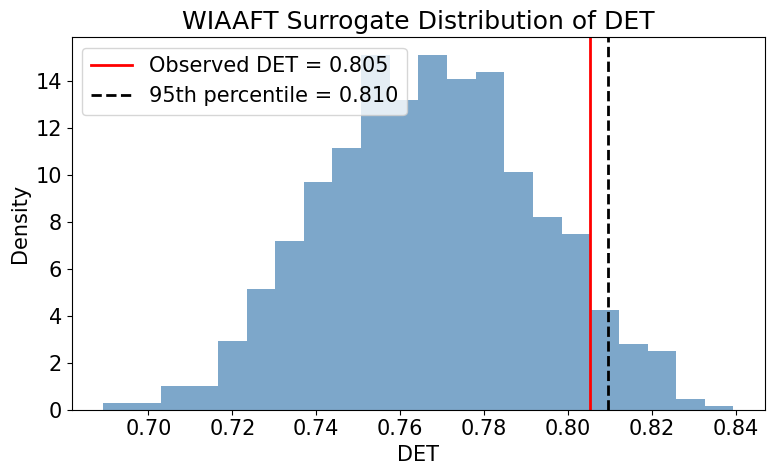

 99%|█████████████████████████████████████████▌| 99/100 [56:00<00:33, 33.01s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.805322819120736 
 Recurrence rate: 0.05002010916403332 
Threshold:1.538399999999847 
 Laminarity:0.29290144727706663 
Shannon Entropy:1.7085013606910748 
Rank-order p-value (det):0.07 
Reject null (det) hypothesis:False

 
 

85
No saturation detected (minimum FNN fallback)
9


Not enough points found!


WIAAFT surrogate datasets generated


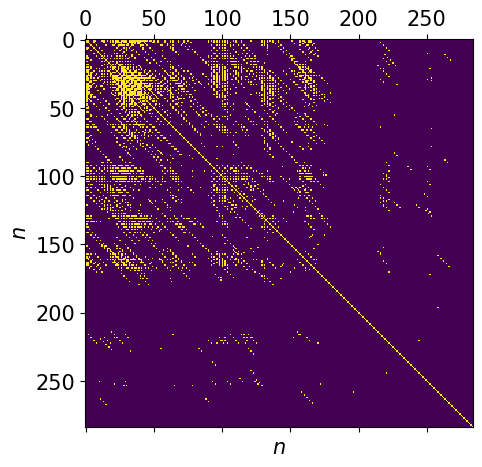

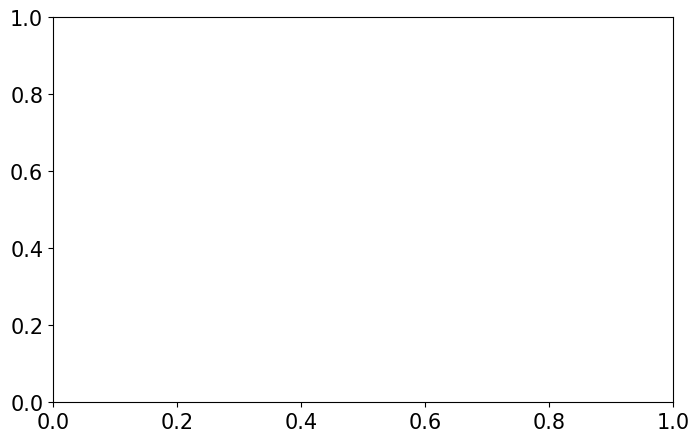

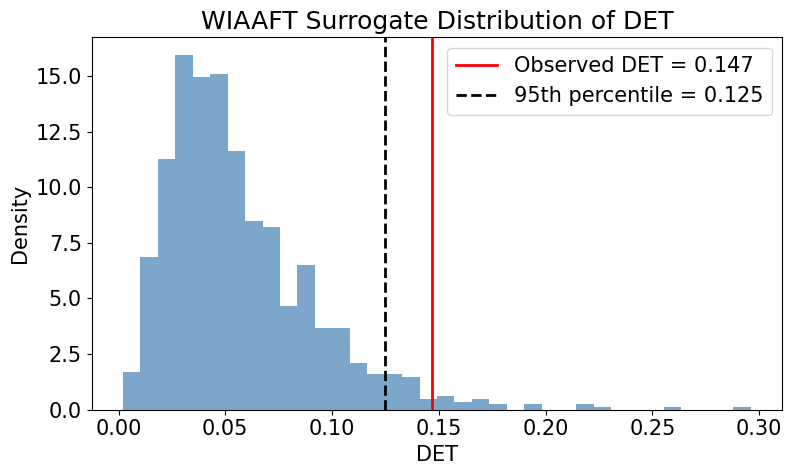

100%|█████████████████████████████████████████| 100/100 [56:36<00:00, 33.96s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.14666666666627556 
 Recurrence rate: 0.050014878000396744 
Threshold:2.085599999999977 
 Laminarity:0.31011403073795213 
Shannon Entropy:1.8368238381395035 
Rank-order p-value (det):0.023 
Reject null (det) hypothesis:True

 
 

86


In [18]:
rejection = 0
for e in tqdm(range(0,100)):
    ig(e)
    os.system("./mutual ig -D20 -o files/mutual_ig -V0")
    m_site1 = np.loadtxt("files/mutual_ig", delimiter =' ', usecols =(1) , skiprows=0)
    mn = np.where((m_site1[1:-1] < m_site1[:-2]) & (m_site1[1:-1] < m_site1[2:]))[0] + 1
    t_min = mn[0]
    os.system("./false_nearest ig -M1,10 -d{} -o files/ig.fnn -V0".format(t_min))
    res_1 = extract_embedding_dimension("ig")
    dim = res_1['m']
    print(res_1['method'])
    print(dim)
    k="ig"
    det_j=[]
    embed=[]
    det_surro_ff=[]
    kkk=[]
    lam_j=[]
    ent_j=[]
    lam_surro = []
    ent_surro=[]
    s = lcurve(k)
    with open("test_output/stocks_WIAAFT", "w") as f:
        subprocess.run(["julia", "WIAAFT_surrogates.jl", "ig"], text=True, check=True)
        tt1=0.001
        dimension=dim
        RR_orig = 0
        while RR_orig < 0.05:
            tt1 = tt1 + 0.0001
            det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
        det_j.append(det)
        embed.append(dim)
        lam_j.append(lam_orig)
        ent_j.append(entr_orig)
        pylab.matshow(matrix)
        pylab.xlabel("$n$")
        pylab.ylabel("$n$")
        pylab.savefig('test_output/WIAAFT/WIAAFT_RP_{}.pdf'.format(dim), format="pdf")
        det_ff, lam_ff, entr_ff = sur_test_WIAAFT(dim, tt1)
        fig2, axs = plt.subplots(1)
        q95 = np.percentile(det_ff, 95)
        plt.figure(figsize=(8,5))
        plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
        plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
        plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
        plt.xlabel("DET")
        plt.ylabel("Density")
        plt.title("WIAAFT Surrogate Distribution of DET")
        plt.legend()
        plt.tight_layout()
        plt.show()
        fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
        plt.show()
        plt.close()
        r = np.sum(det_ff >= det)
        p_rank = (r + 1) / (999 + 1)
        alpha = 0.05
        reject_null1 = p_rank < alpha
        print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
        det_surro_ff.append(det_ff)
        kkk.append(np.full(999, dimension))
        lam_surro.append(lam_ff)
        ent_surro.append(entr_ff)
        if reject_null1 == True:
            rejection = rejection + 1
        print(rejection)

  0%|                                                   | 0/100 [00:00<?, ?it/s]Not enough points found!


6
Mean Nearest Neighbor Distance: 1.1740174810762536
Pseudo-periodic surrogates generated successfullly


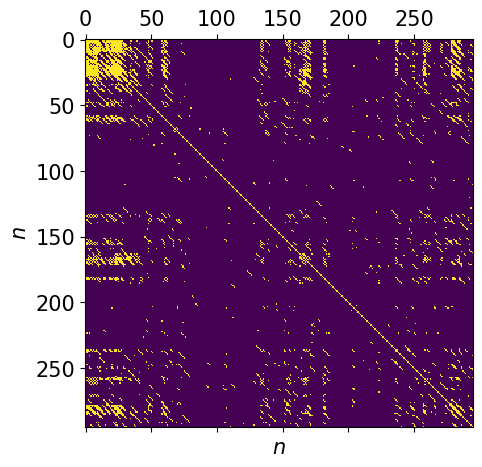

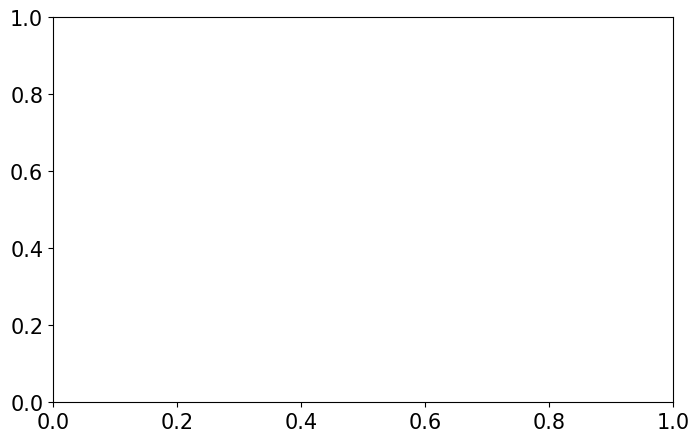

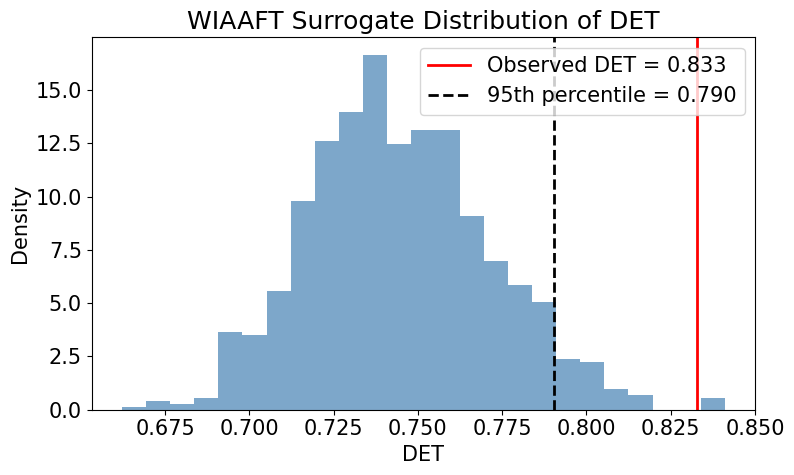

  1%|▍                                          | 1/100 [00:25<41:27, 25.12s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.8329226219792191 
 Recurrence rate: 0.05002010916403332 
Threshold:1.6178999999998382 
 Laminarity:0.4318860555928512 
Shannon Entropy:1.73557070853255 
Rank-order p-value (det):0.01 
Reject null (det) hypothesis:True

 
 

1
8
Mean Nearest Neighbor Distance: 1.5885750301749686
Pseudo-periodic surrogates generated successfullly


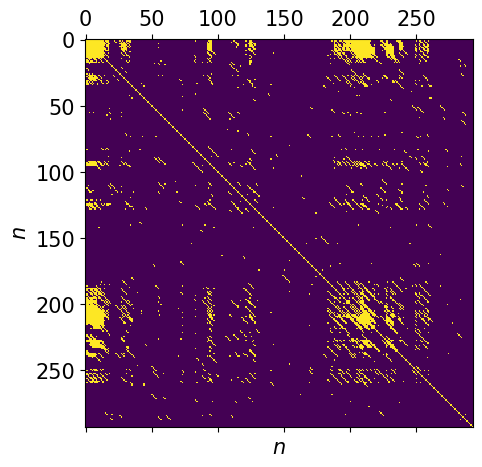

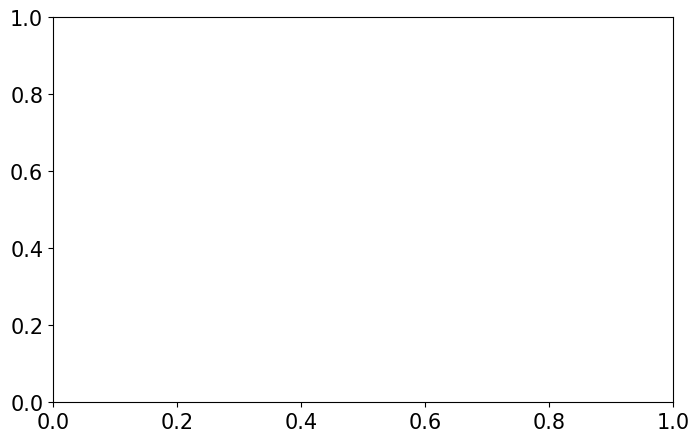

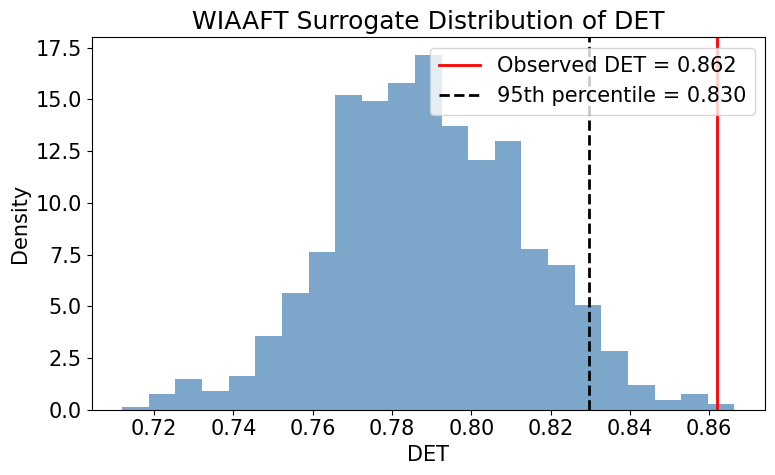

  2%|▊                                          | 2/100 [00:57<48:26, 29.65s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.861999999997845 
 Recurrence rate: 0.050006406597630726 
Threshold:2.106600000000021 
 Laminarity:0.49499184719195205 
Shannon Entropy:2.1006124819360275 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

2
9
Mean Nearest Neighbor Distance: 1.8578003253373672
Pseudo-periodic surrogates generated successfullly


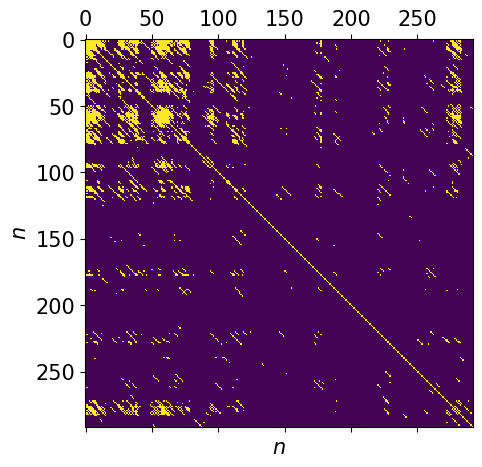

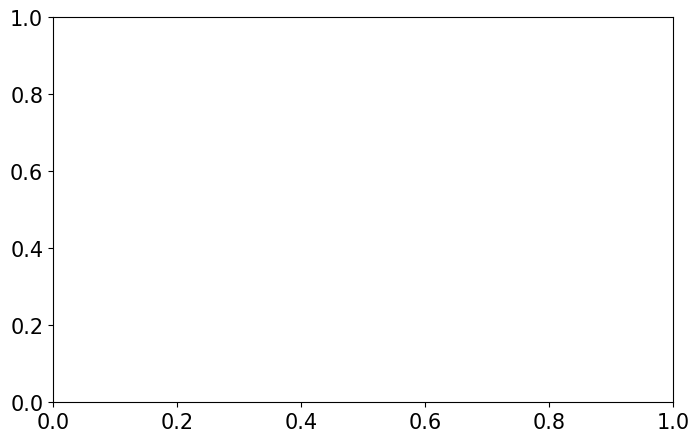

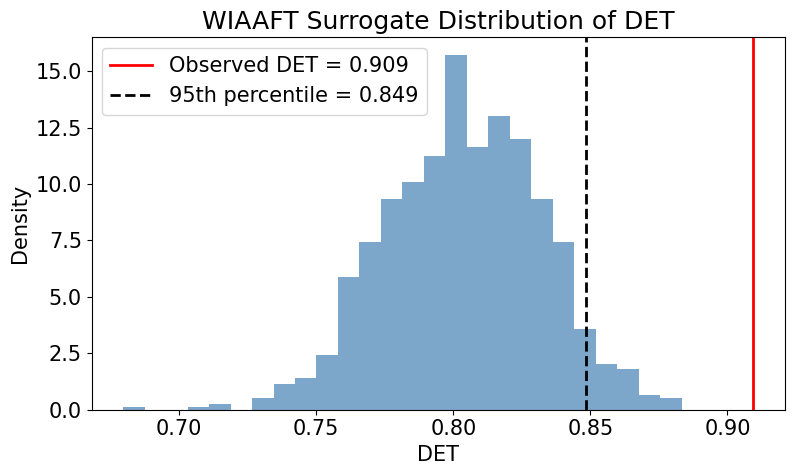

  3%|█▎                                         | 3/100 [01:30<50:08, 31.02s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9094111726197549 
 Recurrence rate: 0.050032839181835244 
Threshold:2.217000000000254 
 Laminarity:0.5398499765575718 
Shannon Entropy:2.065752168226221 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

3
10
Mean Nearest Neighbor Distance: 2.066870410856727
Pseudo-periodic surrogates generated successfullly


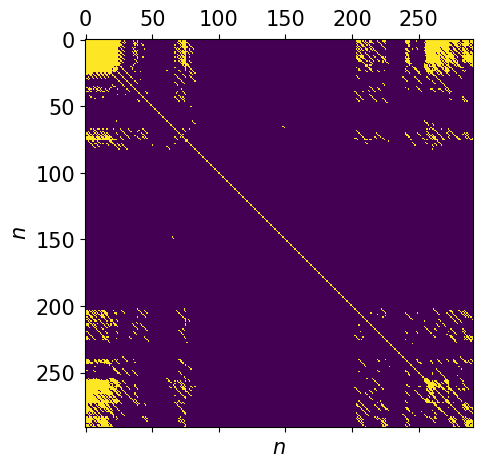

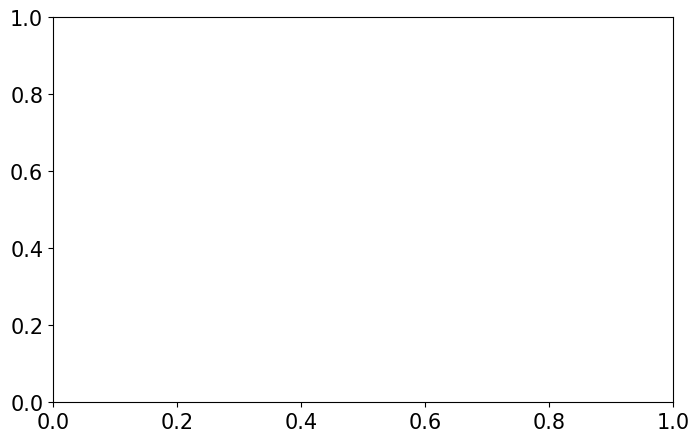

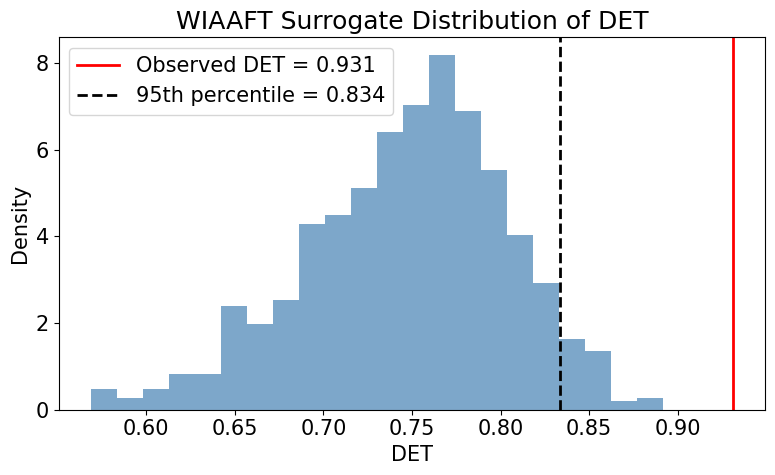

  4%|█▋                                         | 4/100 [01:59<47:59, 29.99s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9310344827562601 
 Recurrence rate: 0.050011218573233665 
Threshold:1.8994999999998072 
 Laminarity:0.6075560802819184 
Shannon Entropy:2.3854702261312433 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

4
8
Mean Nearest Neighbor Distance: 1.5663399939689417
Pseudo-periodic surrogates generated successfullly


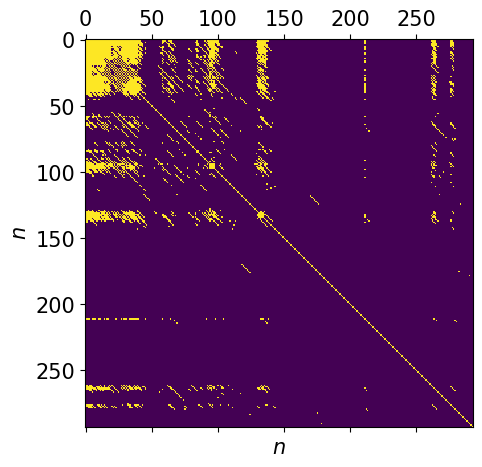

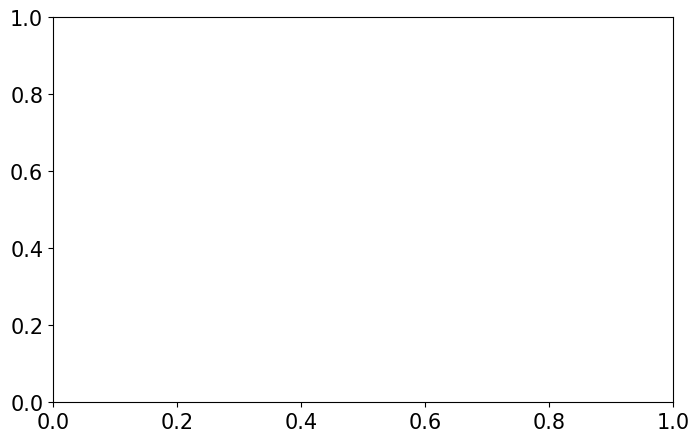

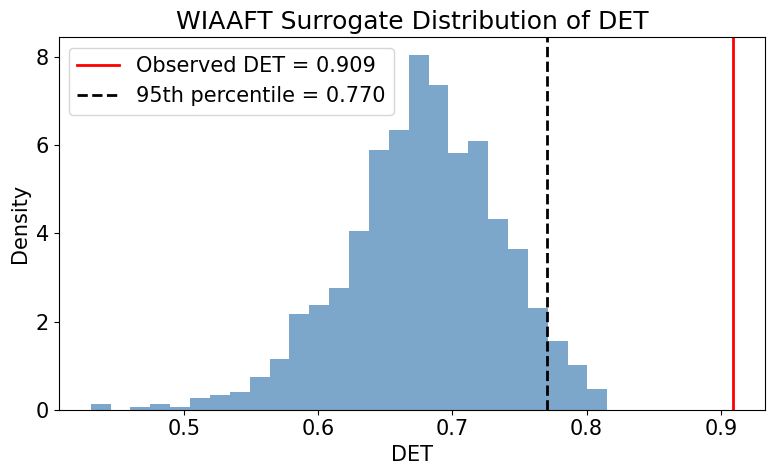

  5%|██▏                                        | 5/100 [02:22<43:36, 27.54s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.9089999999977275 
 Recurrence rate: 0.050006406597630726 
Threshold:1.4677999999998548 
 Laminarity:0.5979501514078781 
Shannon Entropy:2.3773280767687694 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

5
7
Mean Nearest Neighbor Distance: 1.3600047219132436
Pseudo-periodic surrogates generated successfullly


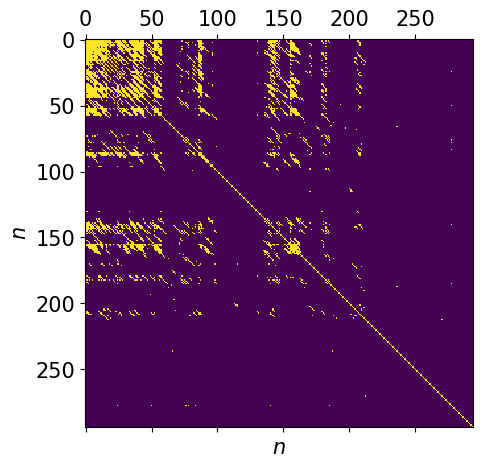

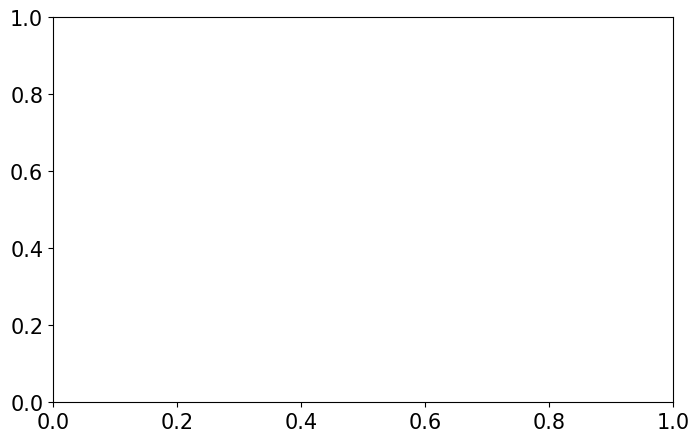

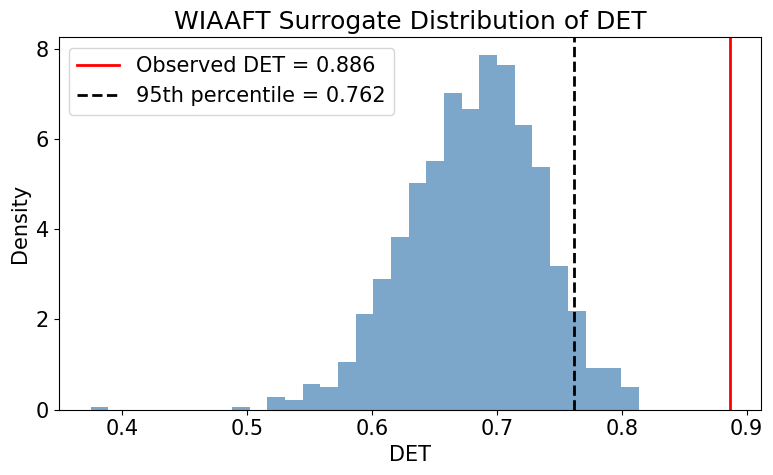

  6%|██▌                                        | 6/100 [02:43<39:52, 25.45s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8862959284982962 
 Recurrence rate: 0.05000231385071035 
Threshold:1.3405999999998688 
 Laminarity:0.6078204534923466 
Shannon Entropy:2.146217140871343 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

6
10
Mean Nearest Neighbor Distance: 1.9747702185002
Pseudo-periodic surrogates generated successfullly


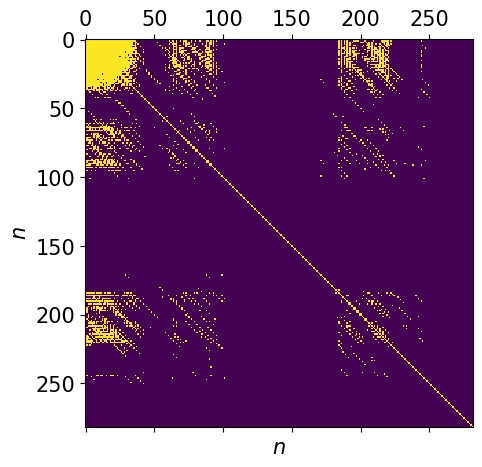

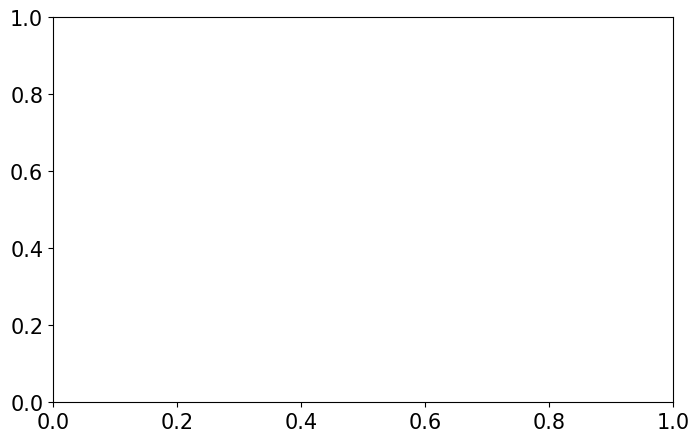

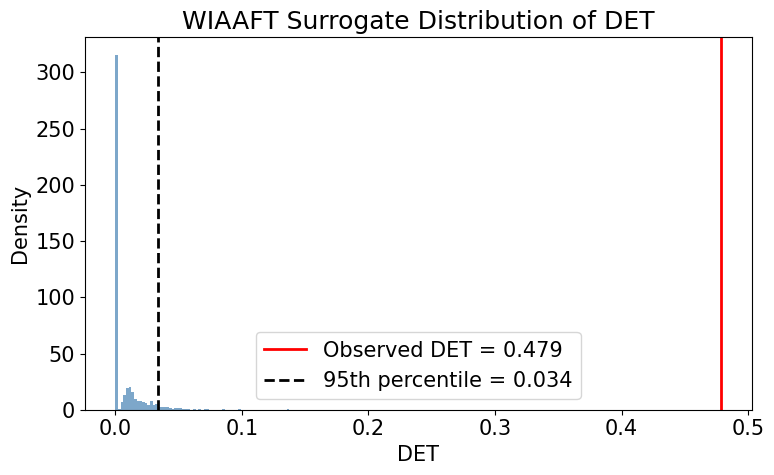

  7%|███                                        | 7/100 [03:11<40:43, 26.28s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.4788961038948082 
 Recurrence rate: 0.05002263467632413 
Threshold:1.929299999999804 
 Laminarity:0.5867269984902295 
Shannon Entropy:2.6058490698859638 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

7
9
Mean Nearest Neighbor Distance: 1.8819554933623914
Pseudo-periodic surrogates generated successfullly


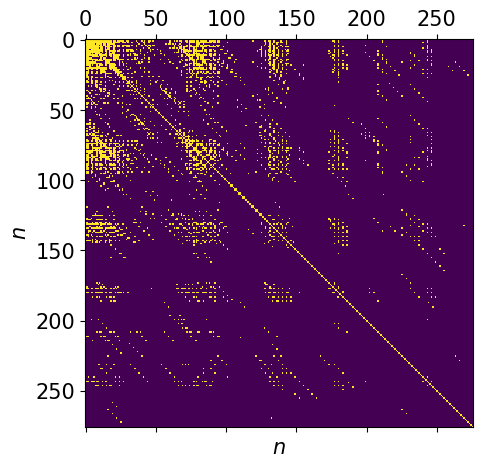

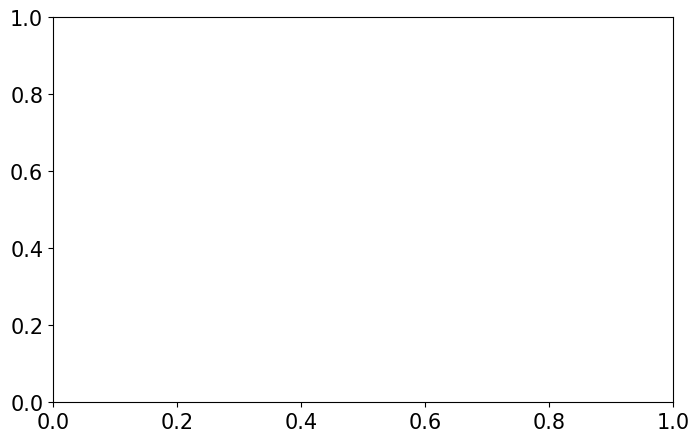

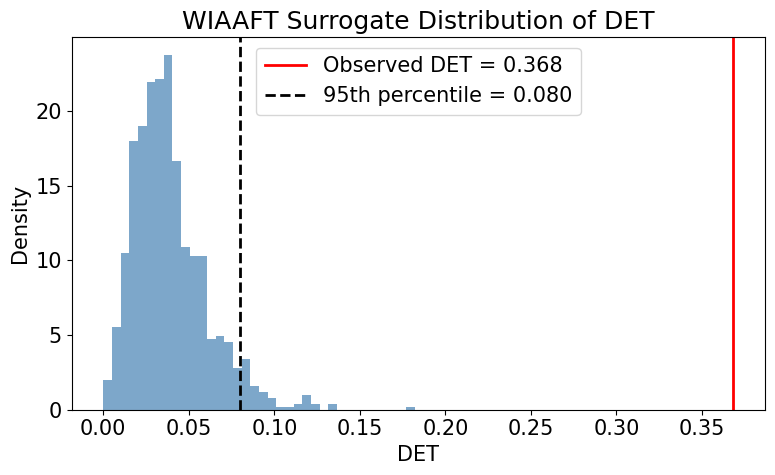

  8%|███▍                                       | 8/100 [03:41<42:14, 27.54s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.3684210526305364 
 Recurrence rate: 0.050015752993068686 
Threshold:2.190000000000197 
 Laminarity:0.45039370078621943 
Shannon Entropy:0.8433402558295201 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

8
10
Mean Nearest Neighbor Distance: 1.757761825358198
Pseudo-periodic surrogates generated successfullly


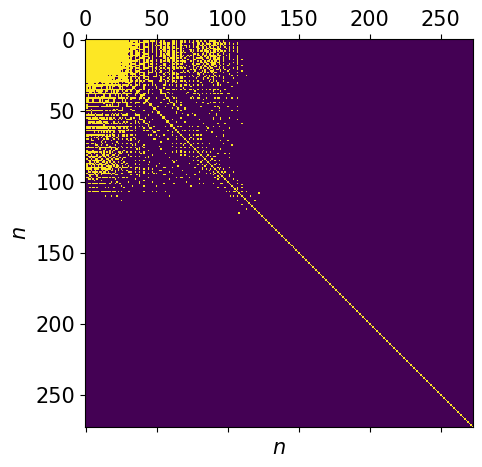

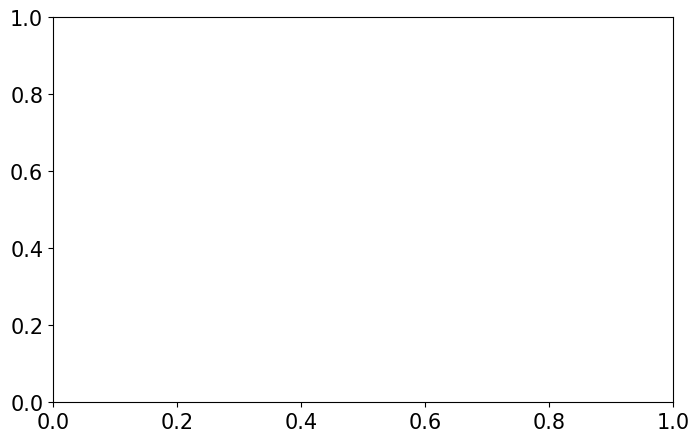

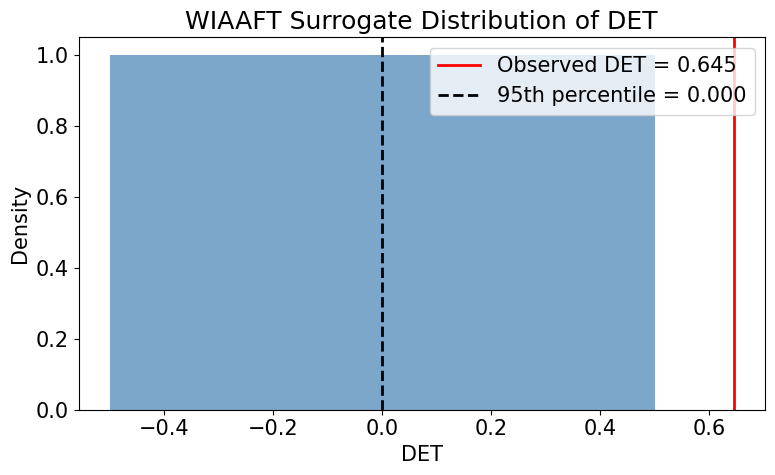

  9%|███▊                                       | 9/100 [03:55<35:03, 23.12s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.6450492182957585 
 Recurrence rate: 0.050007379677709345 
Threshold:0.6215999999999479 
 Laminarity:0.6396565602343985 
Shannon Entropy:1.0508931732553823 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

9
8
Mean Nearest Neighbor Distance: 1.5171789728253129
Pseudo-periodic surrogates generated successfullly


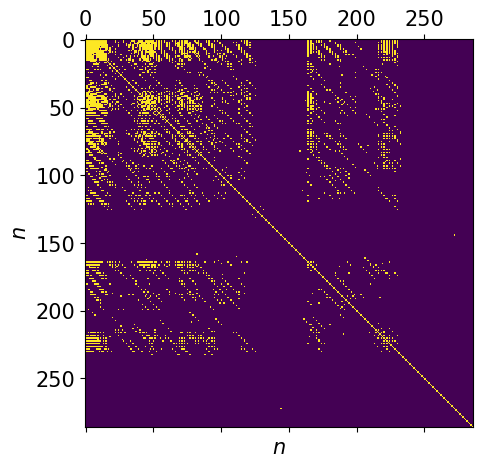

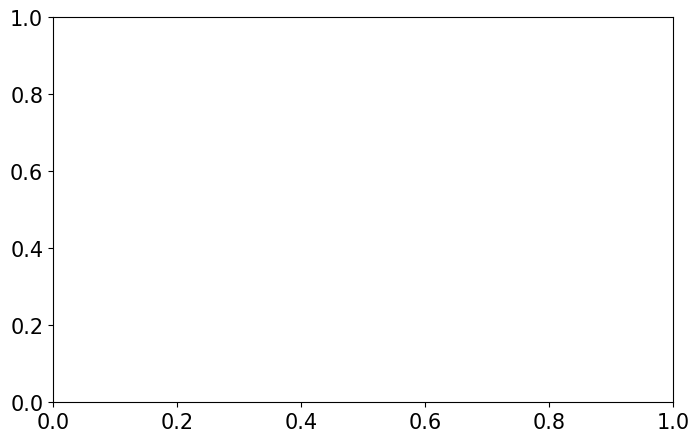

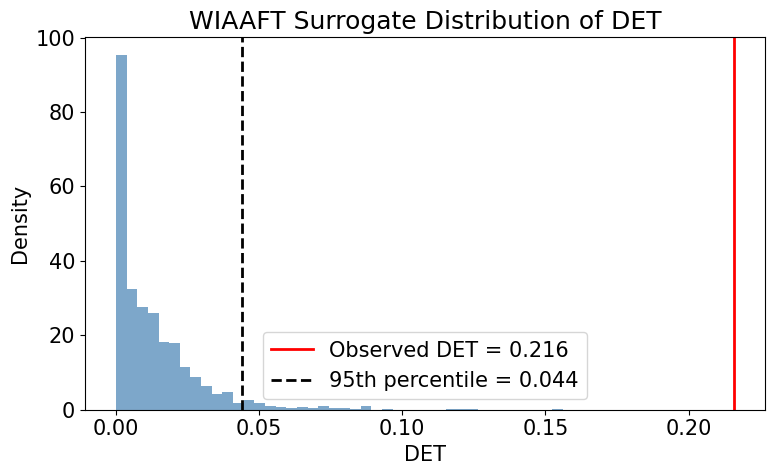

 10%|████▏                                     | 10/100 [04:18<34:49, 23.22s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.21586134453724826 
 Recurrence rate: 0.05005134725414446 
Threshold:1.5824999999998421 
 Laminarity:0.37225207620817724 
Shannon Entropy:2.160541995675194 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

10
9


Not enough points found!


Mean Nearest Neighbor Distance: 1.9195424373691414
Pseudo-periodic surrogates generated successfullly


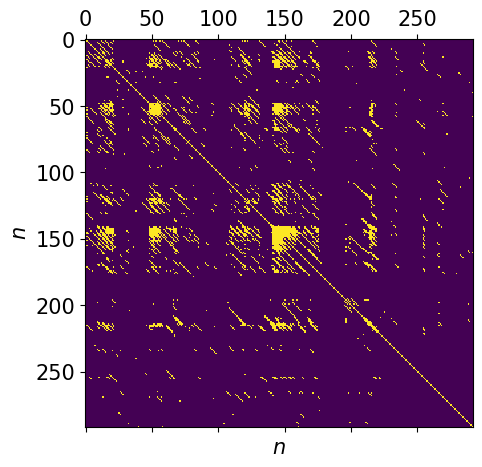

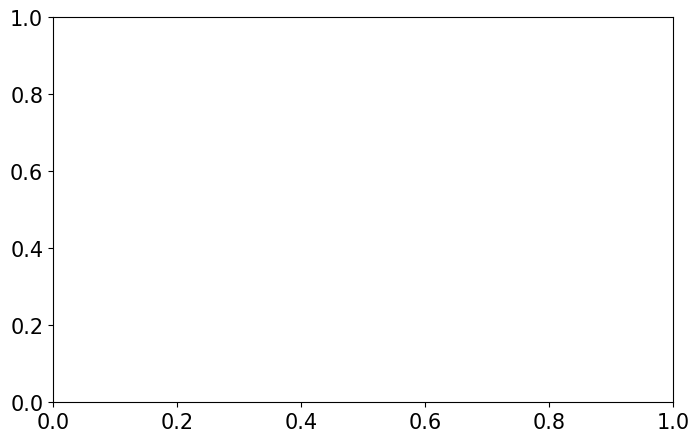

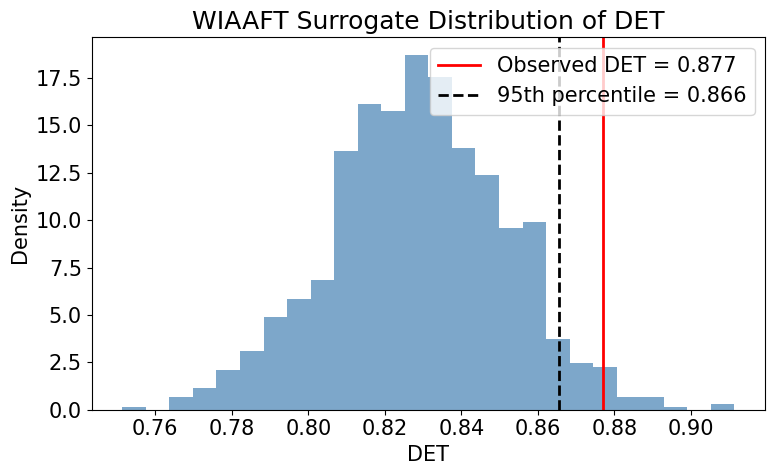

 11%|████▌                                     | 11/100 [04:52<39:21, 26.53s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8771399798568048 
 Recurrence rate: 0.0500093826233815 
Threshold:2.426800000000697 
 Laminarity:0.4455909943704372 
Shannon Entropy:1.9896426803351748 
Rank-order p-value (det):0.038 
Reject null (det) hypothesis:True

 
 

11
10
Mean Nearest Neighbor Distance: 2.0671462614557123
Pseudo-periodic surrogates generated successfullly


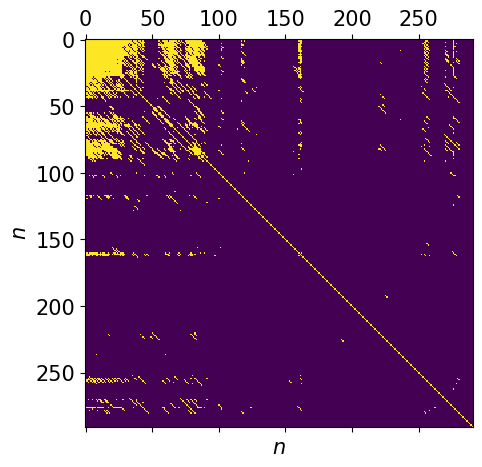

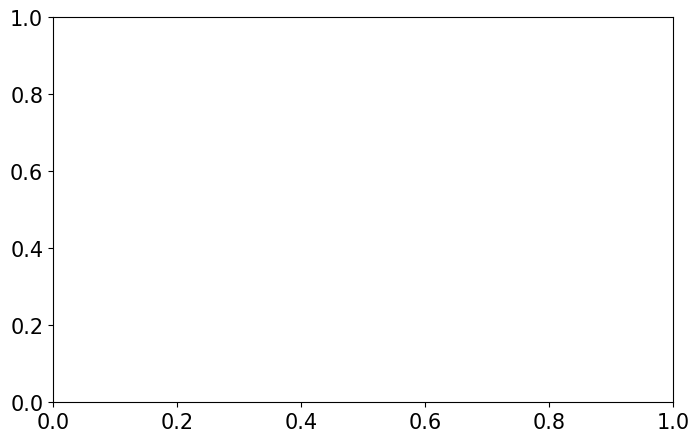

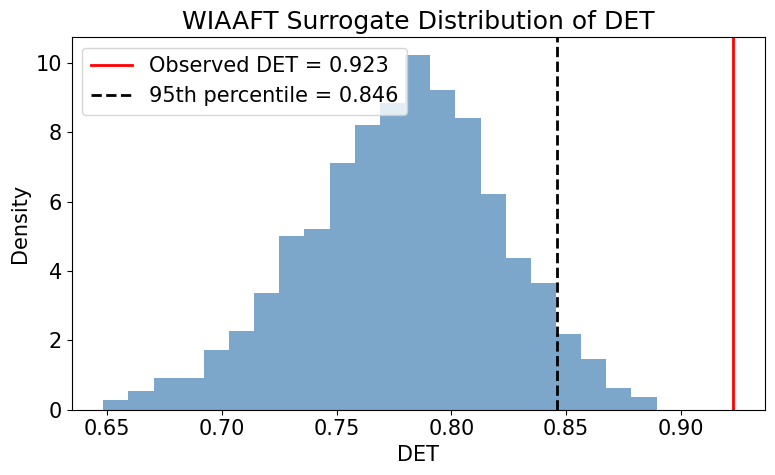

 12%|█████                                     | 12/100 [05:25<41:41, 28.43s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.922920892492589 
 Recurrence rate: 0.050011218573233665 
Threshold:2.1200000000000494 
 Laminarity:0.6479338842959907 
Shannon Entropy:2.4448441783898818 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

12
7
Mean Nearest Neighbor Distance: 1.442380347421558
Pseudo-periodic surrogates generated successfullly


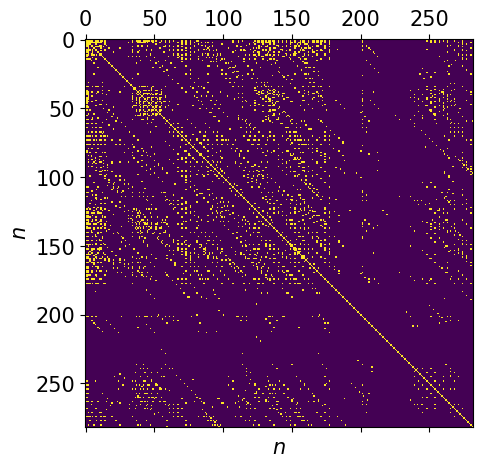

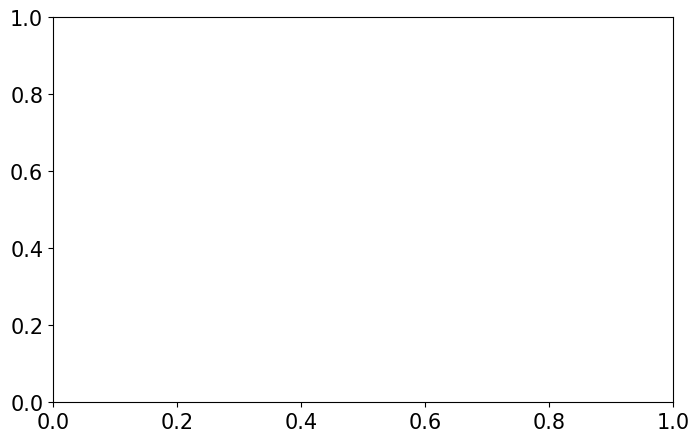

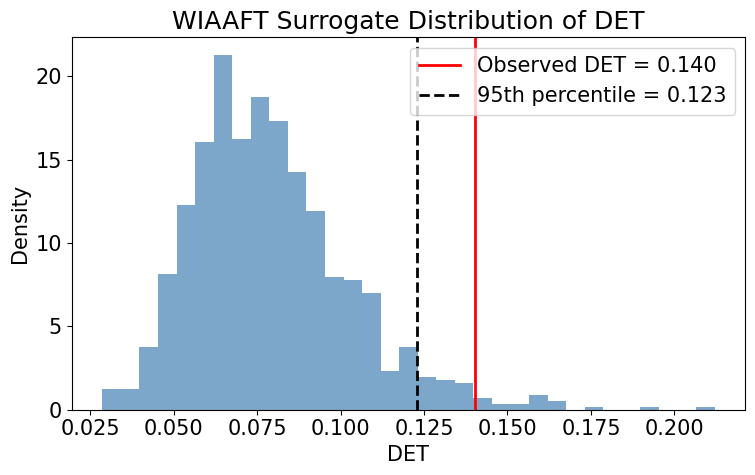

 13%|█████▍                                    | 13/100 [05:52<40:23, 27.86s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.14015151515113597 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9879999999997975 
 Laminarity:0.22699849170380343 
Shannon Entropy:0.2619479660140259 
Rank-order p-value (det):0.038 
Reject null (det) hypothesis:True

 
 

13
7
Mean Nearest Neighbor Distance: 1.3757668527671398
Pseudo-periodic surrogates generated successfullly


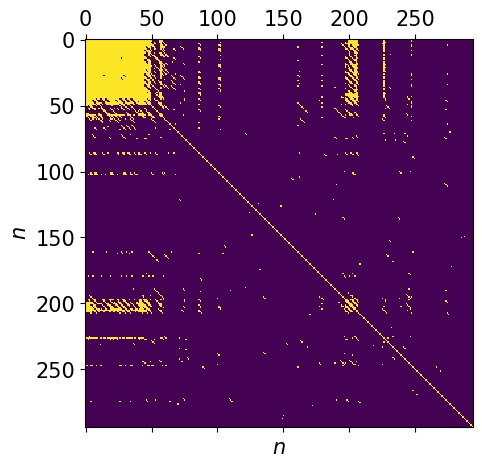

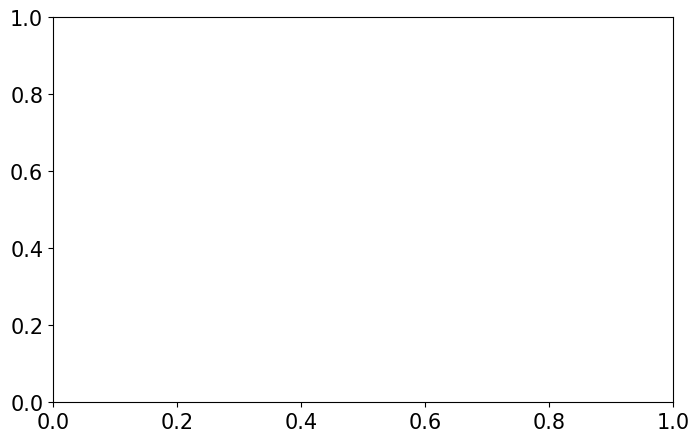

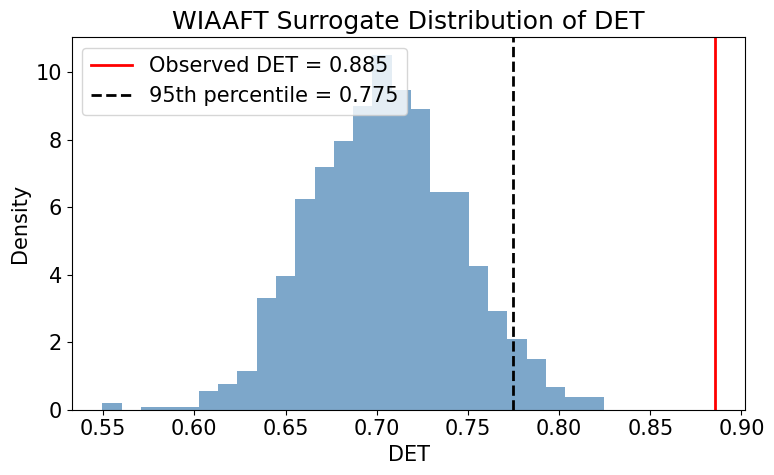

 14%|█████▉                                    | 14/100 [06:15<37:59, 26.50s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8853028798389143 
 Recurrence rate: 0.05000231385071035 
Threshold:1.5636999999998442 
 Laminarity:0.7561314206368438 
Shannon Entropy:2.4042634270437433 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

14
10
Mean Nearest Neighbor Distance: 1.910167955812468
Pseudo-periodic surrogates generated successfullly


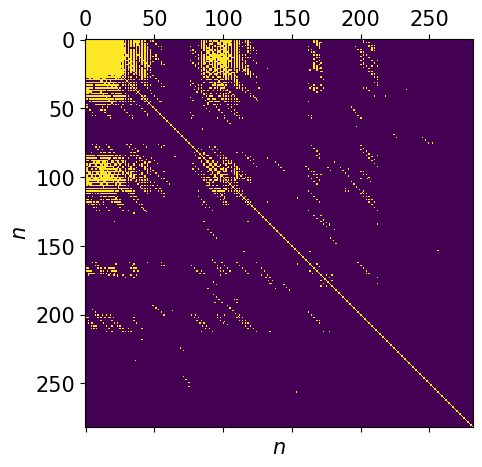

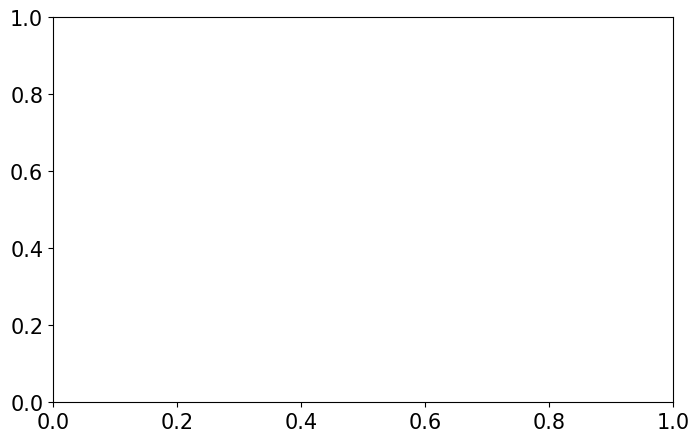

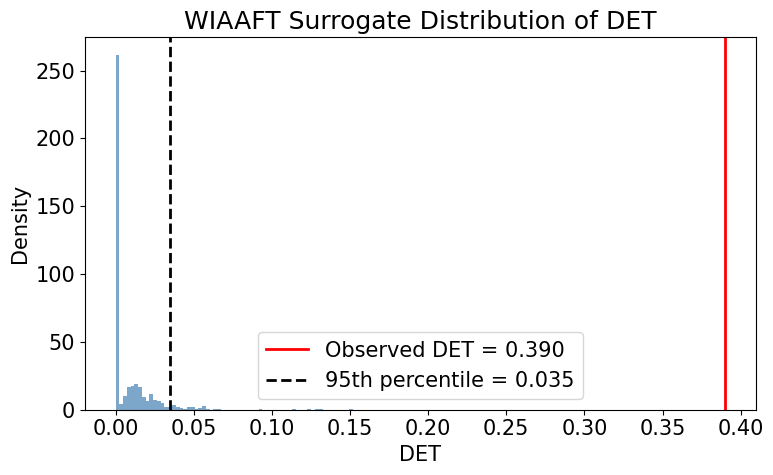

 15%|██████▎                                   | 15/100 [06:43<38:18, 27.04s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.39015151515045954 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9811999999997982 
 Laminarity:0.5480140774244645 
Shannon Entropy:2.7321024294460297 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

15
9
Mean Nearest Neighbor Distance: 1.708972646623522
Pseudo-periodic surrogates generated successfullly


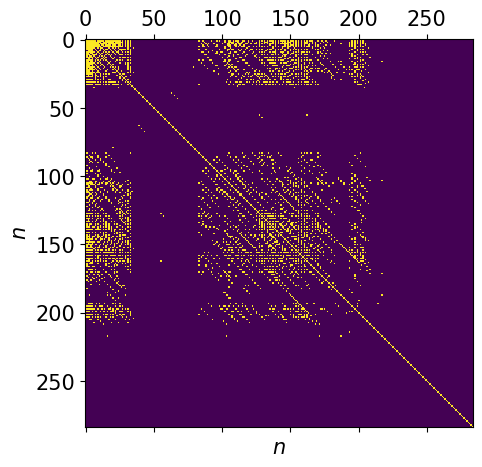

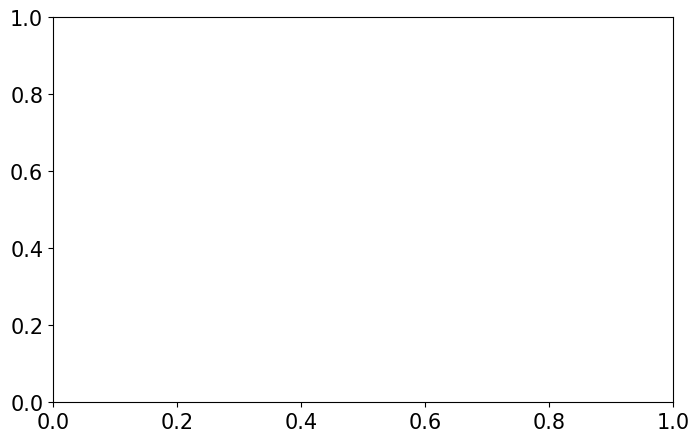

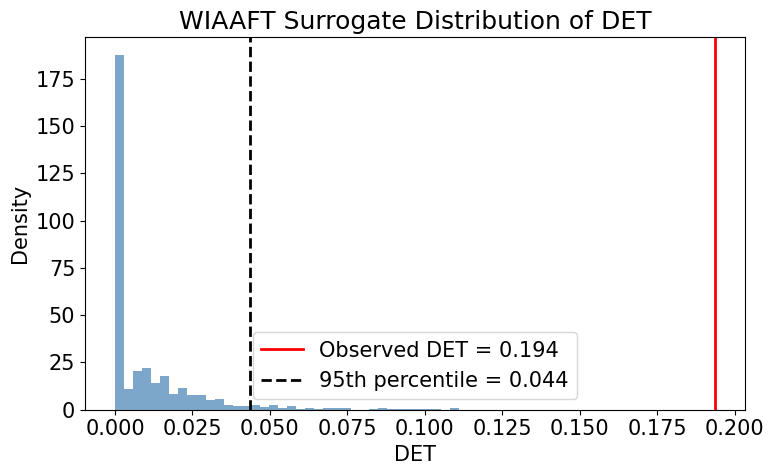

 16%|██████▋                                   | 16/100 [07:07<36:28, 26.06s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.19359999999948374 
 Recurrence rate: 0.050014878000396744 
Threshold:1.5775999999998427 
 Laminarity:0.30788299454559276 
Shannon Entropy:1.934487701257519 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

16
9
Mean Nearest Neighbor Distance: 1.8692925676578915
Pseudo-periodic surrogates generated successfullly


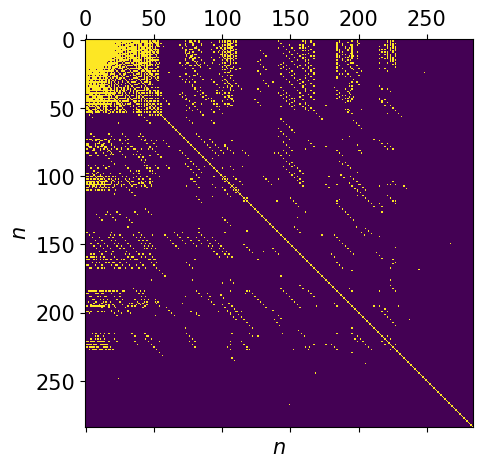

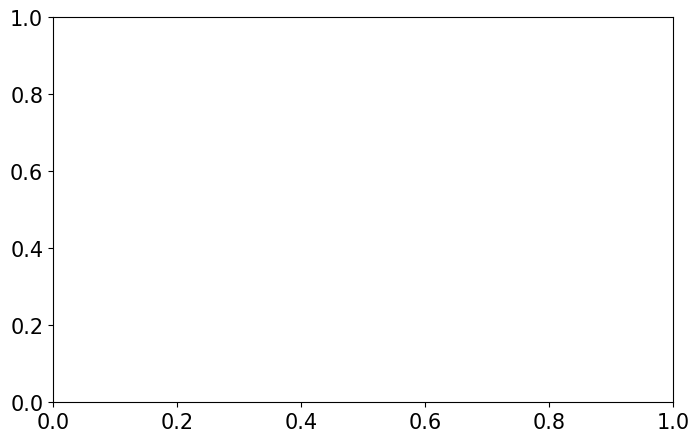

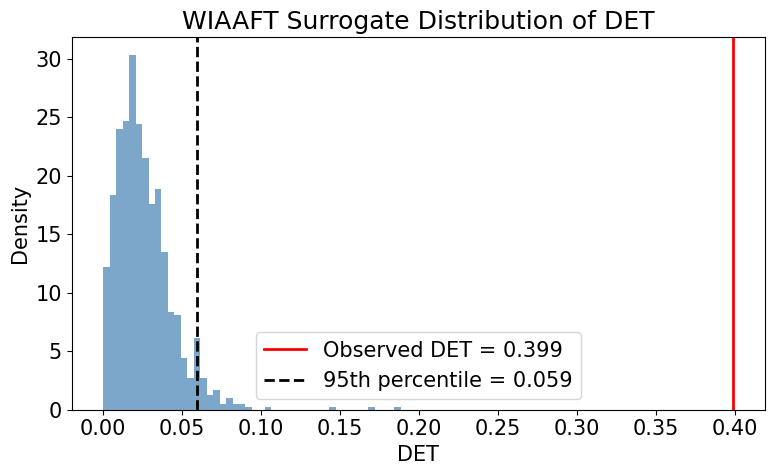

 17%|███████▏                                  | 17/100 [07:37<37:41, 27.24s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.39893333333226955 
 Recurrence rate: 0.050014878000396744 
Threshold:2.1873000000001914 
 Laminarity:0.469757064946778 
Shannon Entropy:2.7304237347090616 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

17
5
Mean Nearest Neighbor Distance: 0.917724603518986
Pseudo-periodic surrogates generated successfullly


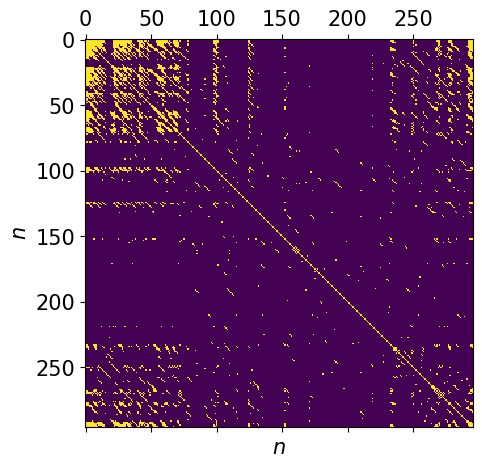

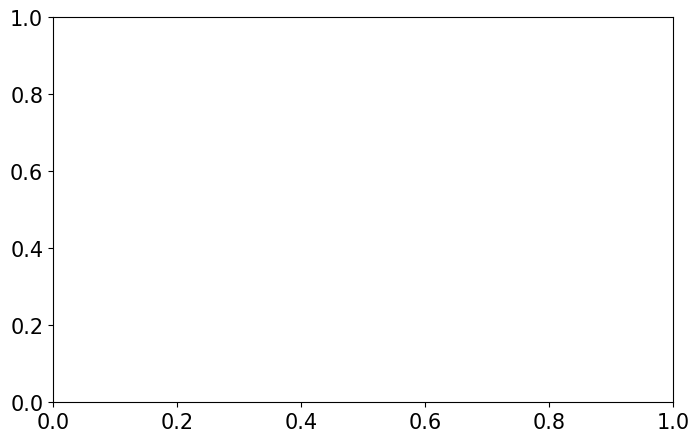

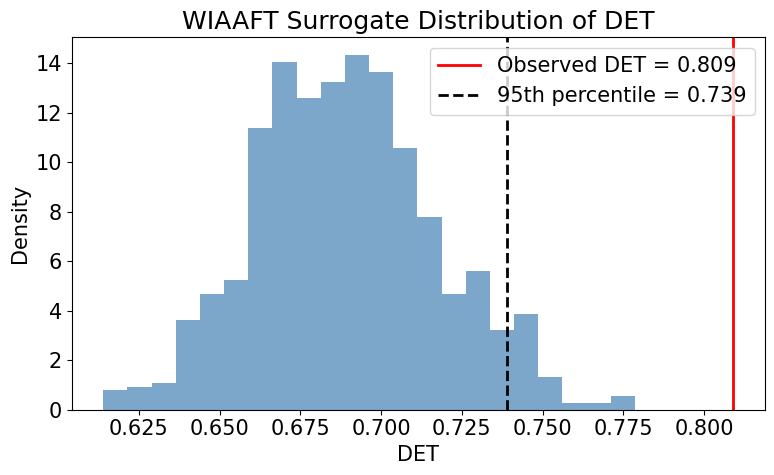

 18%|███████▌                                  | 18/100 [07:57<34:20, 25.12s/it]

RQA  ig Embedding dimensions:5 
 DET of original:0.8091042584414854 
 Recurrence rate: 0.05001369612856099 
Threshold:1.3181999999998713 
 Laminarity:0.5230488361466841 
Shannon Entropy:1.6994978820722233 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

18
10
Mean Nearest Neighbor Distance: 2.045137813885641
Pseudo-periodic surrogates generated successfullly


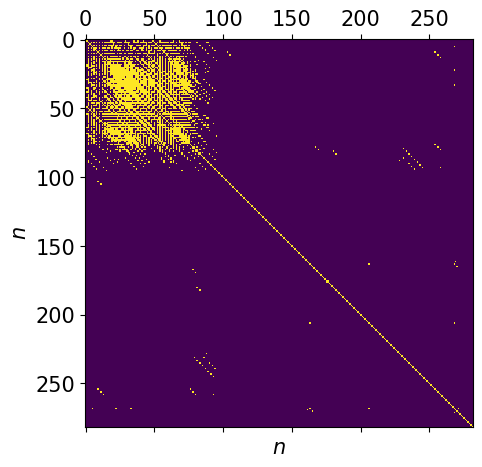

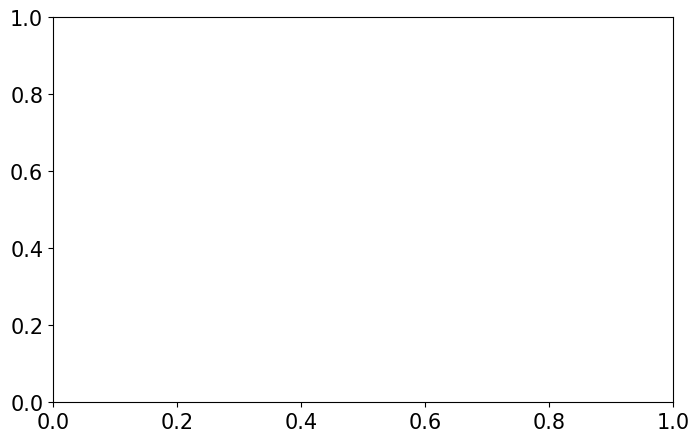

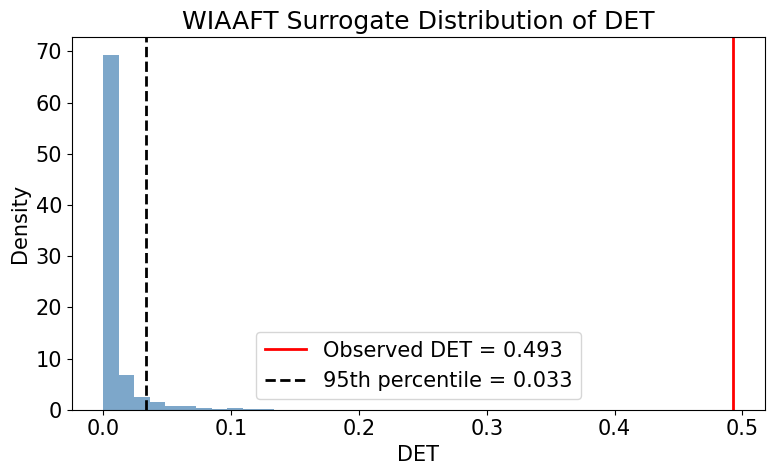

 19%|███████▉                                  | 19/100 [08:25<34:51, 25.82s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.4929653679640342 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9078999999998063 
 Laminarity:0.665158371039052 
Shannon Entropy:2.799125357156913 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

19
9
Mean Nearest Neighbor Distance: 1.8410513166450762
Pseudo-periodic surrogates generated successfullly


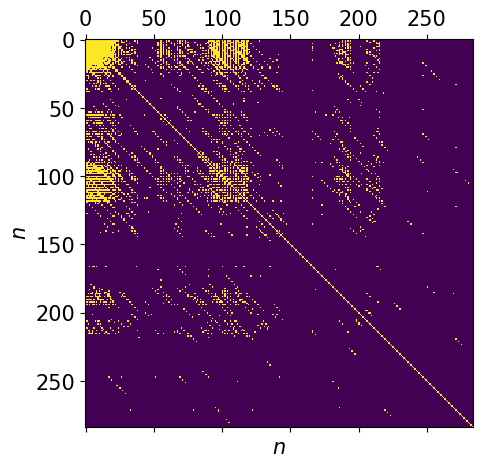

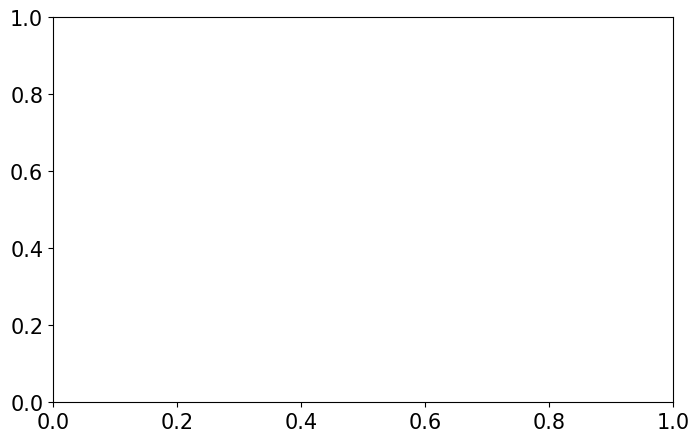

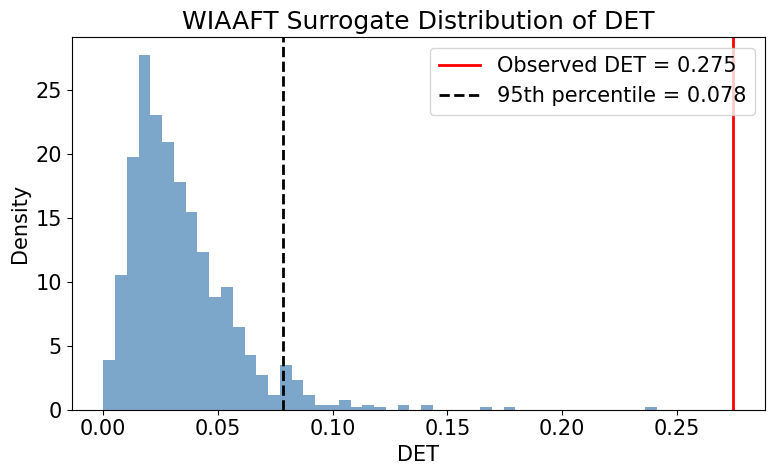

 20%|████████▍                                 | 20/100 [08:55<36:11, 27.14s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.27466666666593426 
 Recurrence rate: 0.050014878000396744 
Threshold:2.206000000000231 
 Laminarity:0.42736737729195 
Shannon Entropy:2.454379241549576 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

20
6
Mean Nearest Neighbor Distance: 1.1835421240378705
Pseudo-periodic surrogates generated successfullly


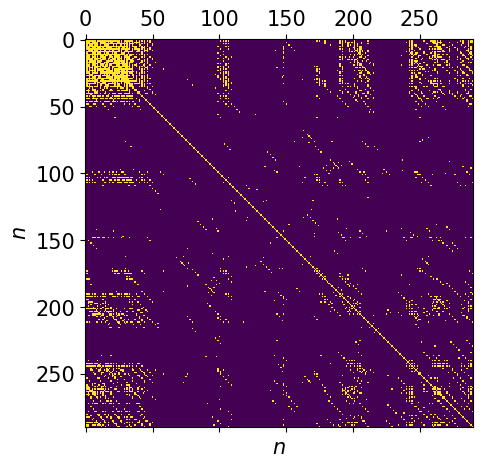

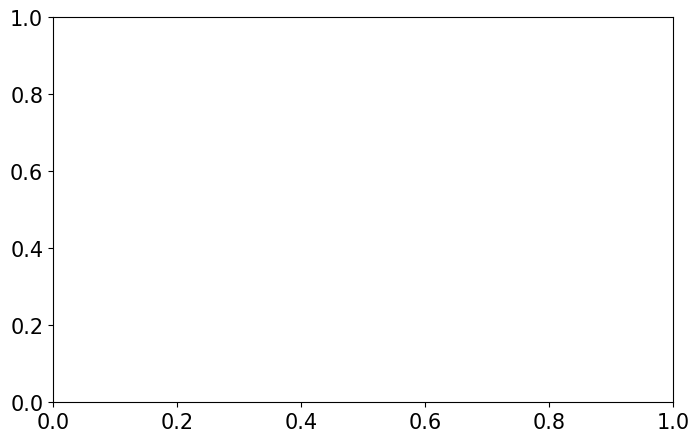

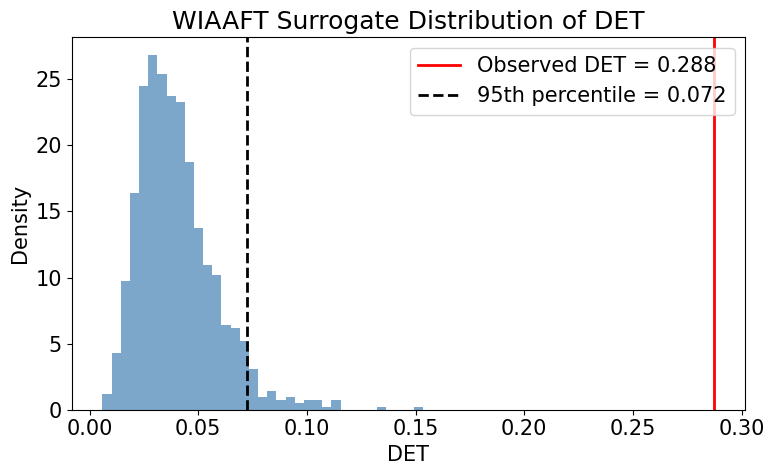

 21%|████████▊                                 | 21/100 [09:18<34:02, 25.86s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.28753830439150274 
 Recurrence rate: 0.05001189060642093 
Threshold:1.5710999999998434 
 Laminarity:0.42201616737893005 
Shannon Entropy:2.0546070020405502 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

21
6


Not enough points found!


Mean Nearest Neighbor Distance: 1.1929661618807328
Pseudo-periodic surrogates generated successfullly


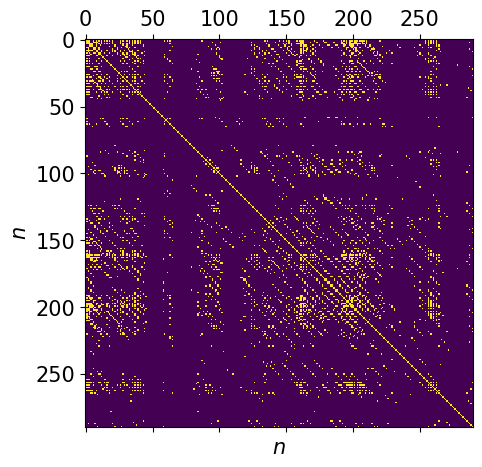

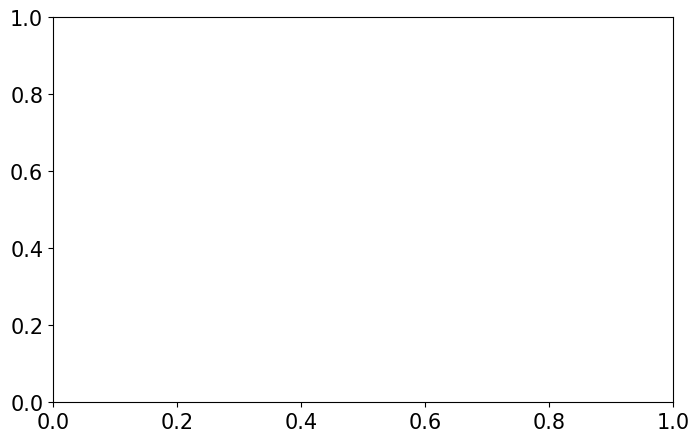

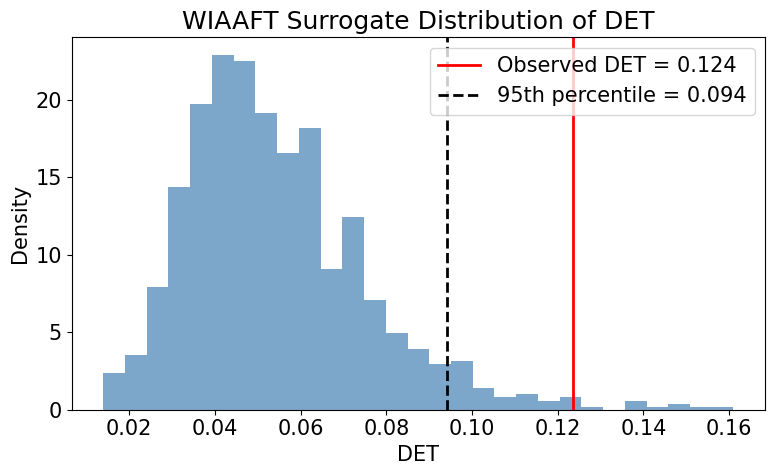

 22%|█████████▏                                | 22/100 [09:41<32:39, 25.12s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.12353241449687716 
 Recurrence rate: 0.05003567181926278 
Threshold:1.628399999999837 
 Laminarity:0.23574144486635992 
Shannon Entropy:1.5845594842459412 
Rank-order p-value (det):0.024 
Reject null (det) hypothesis:True

 
 

22
10
Mean Nearest Neighbor Distance: 1.9571811870834923
Pseudo-periodic surrogates generated successfullly


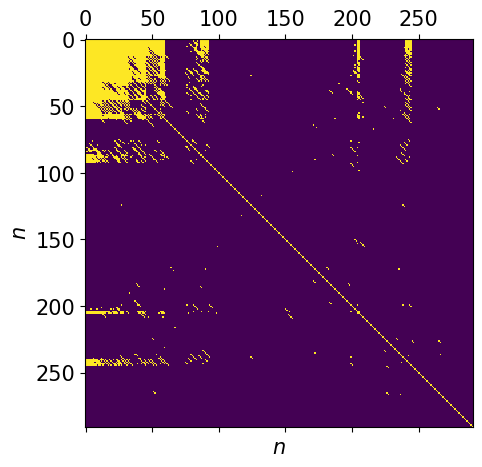

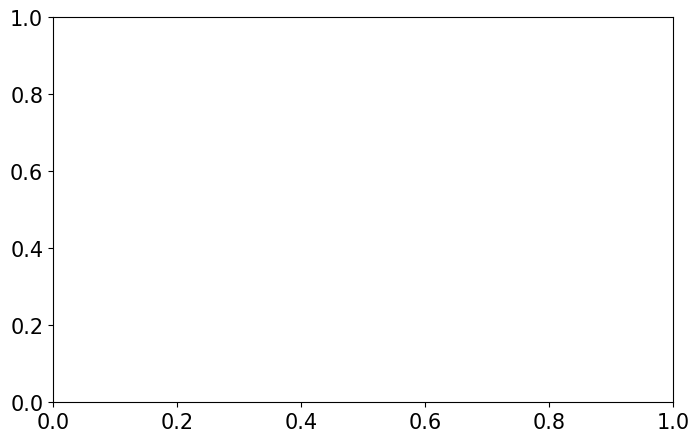

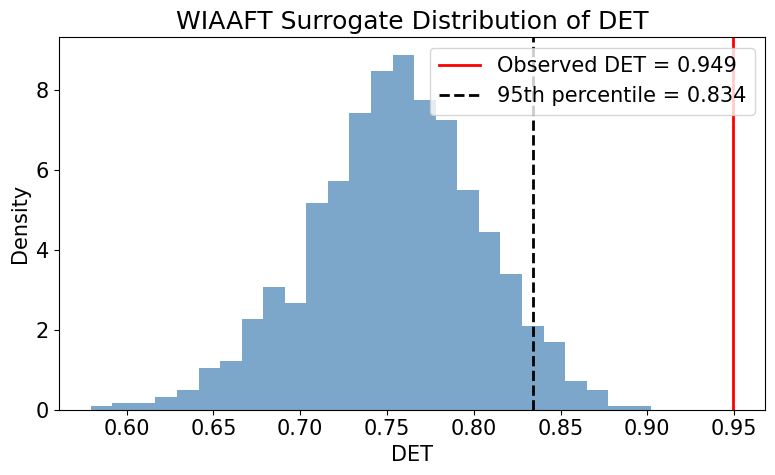

 23%|█████████▋                                | 23/100 [10:11<34:05, 26.56s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9492900608495201 
 Recurrence rate: 0.050011218573233665 
Threshold:2.02559999999985 
 Laminarity:0.7466351829970563 
Shannon Entropy:2.5235397918369995 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

23
7


Not enough points found!


Mean Nearest Neighbor Distance: 1.3927562842795589
Pseudo-periodic surrogates generated successfullly


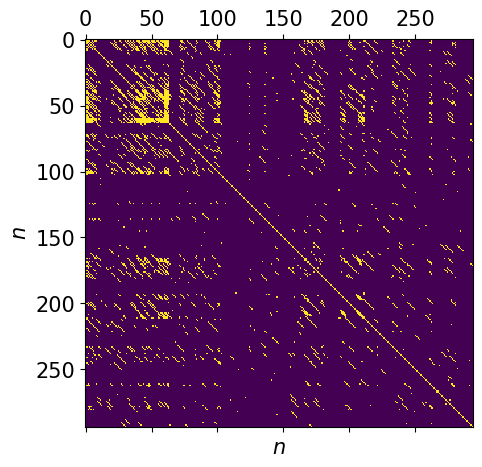

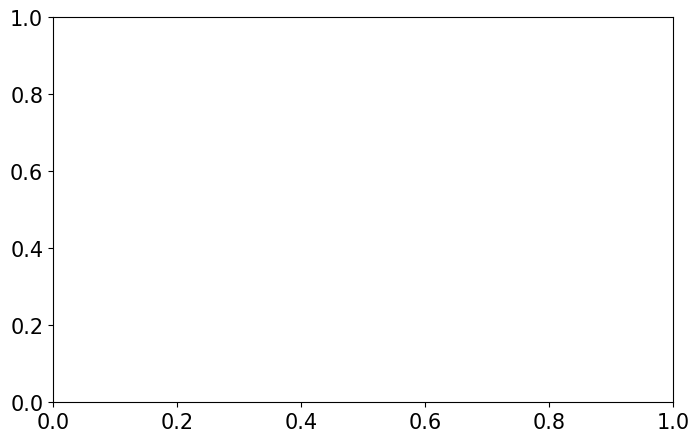

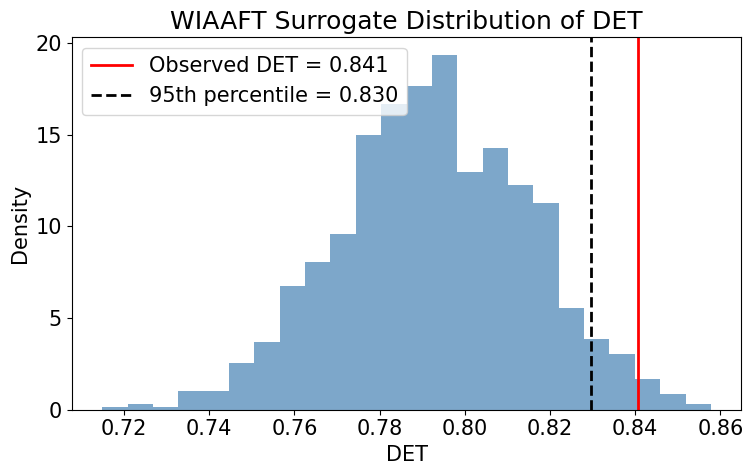

 24%|██████████                                | 24/100 [10:38<34:00, 26.85s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8406156901667313 
 Recurrence rate: 0.05000231385071035 
Threshold:1.9660999999998 
 Laminarity:0.2760296159179176 
Shannon Entropy:1.843775520441932 
Rank-order p-value (det):0.032 
Reject null (det) hypothesis:True

 
 

24
6


Not enough points found!


Mean Nearest Neighbor Distance: 1.1544893549285504
Pseudo-periodic surrogates generated successfullly


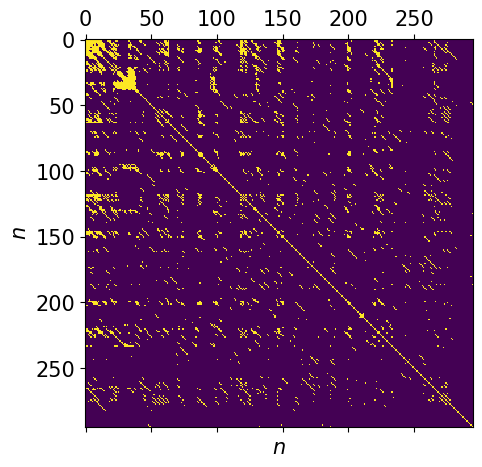

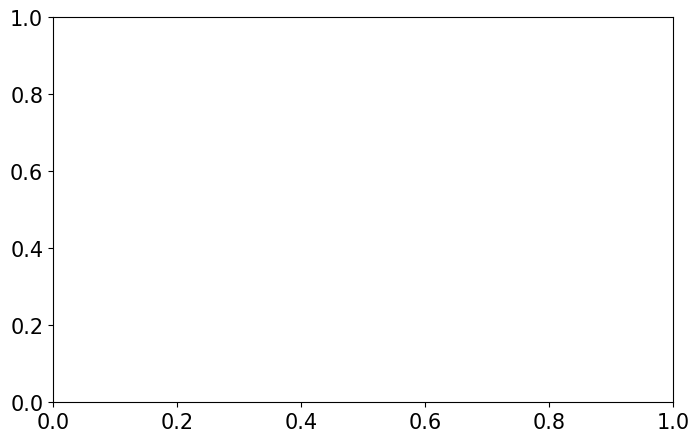

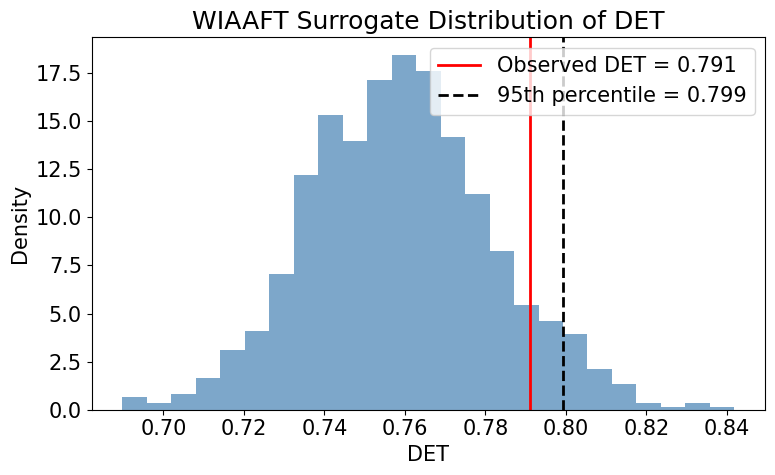

 25%|██████████▌                               | 25/100 [11:04<32:52, 26.30s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.7910300640690217 
 Recurrence rate: 0.05002010916403332 
Threshold:1.7137999999998277 
 Laminarity:0.4001837812993334 
Shannon Entropy:1.5869506083435818 
Rank-order p-value (det):0.186 
Reject null (det) hypothesis:False

 
 

24
10
Mean Nearest Neighbor Distance: 2.0404122506723468
Pseudo-periodic surrogates generated successfullly


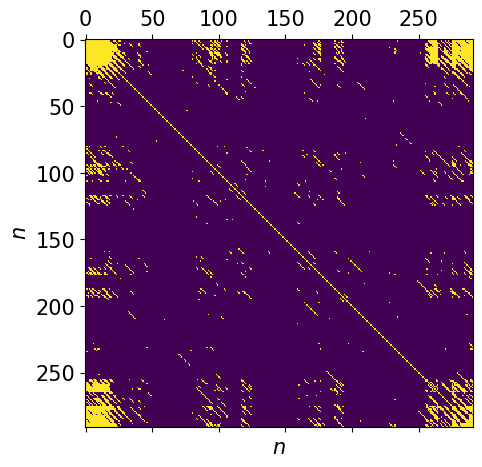

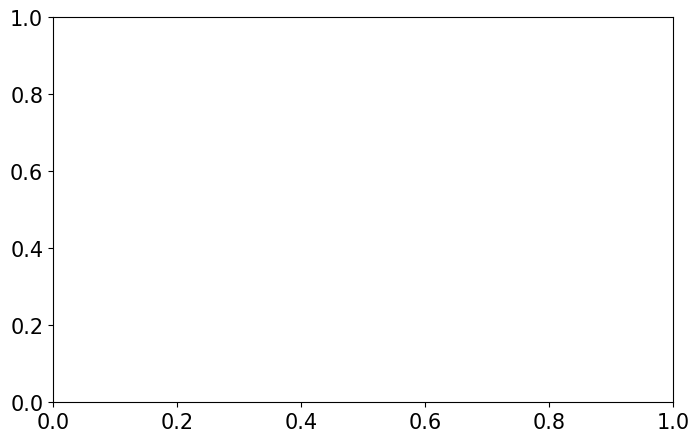

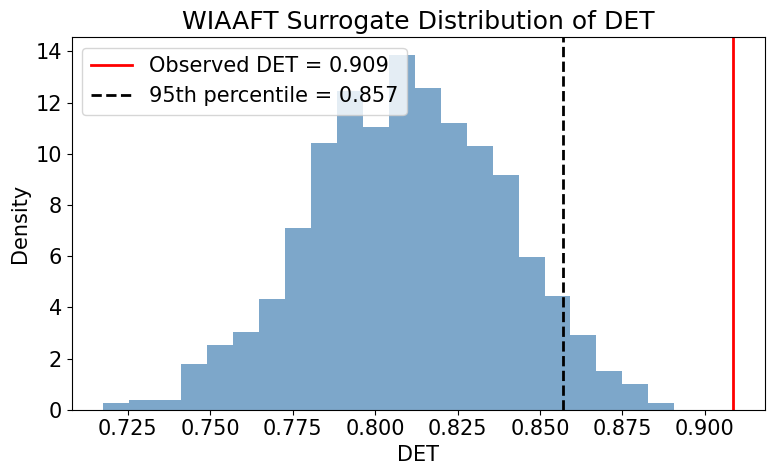

 26%|██████████▉                               | 26/100 [11:39<35:51, 29.07s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9087221095311645 
 Recurrence rate: 0.050011218573233665 
Threshold:2.3958000000006314 
 Laminarity:0.6044864226668135 
Shannon Entropy:2.2923515213105894 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

25
7
Mean Nearest Neighbor Distance: 1.3544701527562126
Pseudo-periodic surrogates generated successfullly


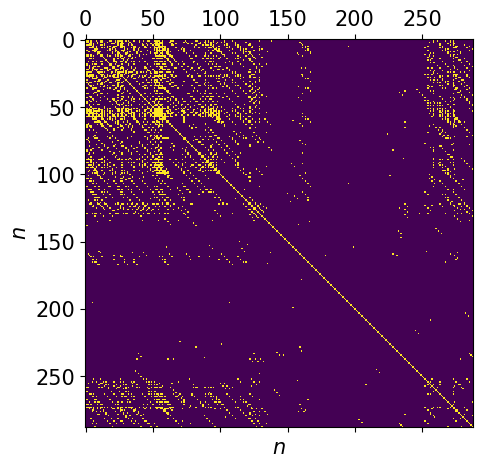

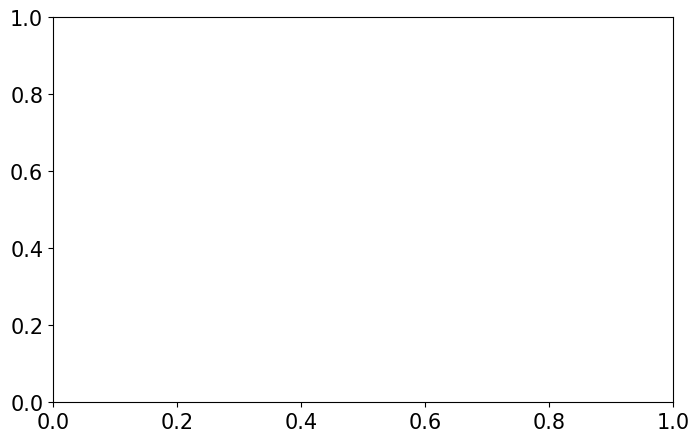

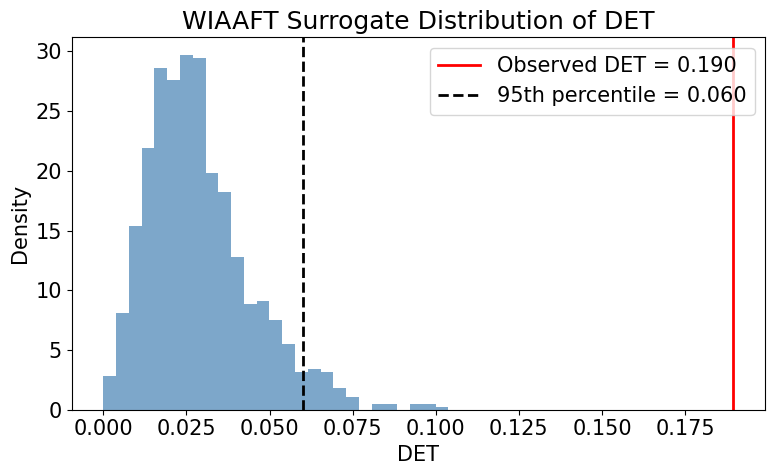

 27%|███████████▎                              | 27/100 [12:03<33:38, 27.64s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.1895390989119898 
 Recurrence rate: 0.050033757716049385 
Threshold:1.69219999999983 
 Laminarity:0.3650602409629758 
Shannon Entropy:1.7343216512324373 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

26
5
Mean Nearest Neighbor Distance: 0.9220674366445856
Pseudo-periodic surrogates generated successfullly


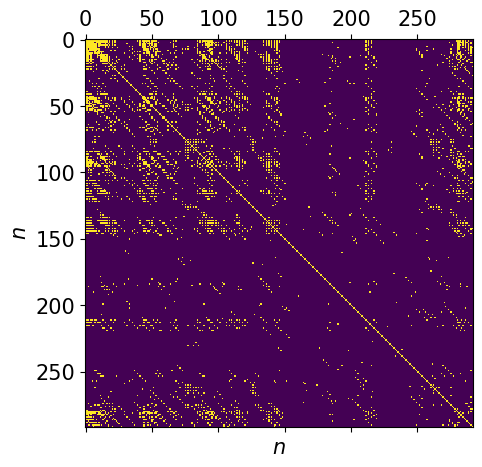

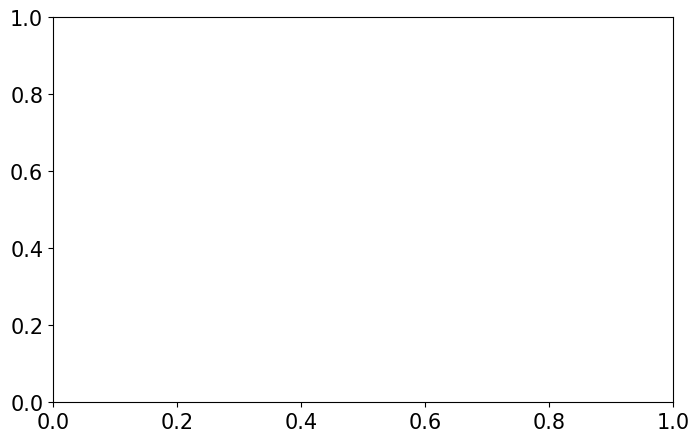

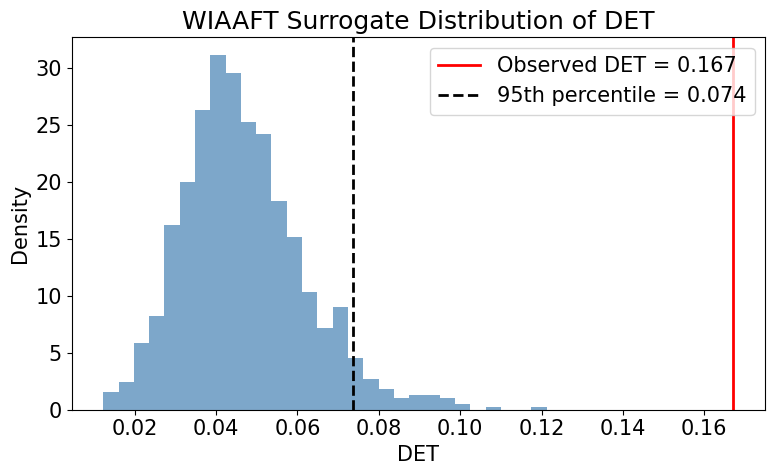

 28%|███████████▊                              | 28/100 [12:24<30:33, 25.47s/it]

RQA  ig Embedding dimensions:5 
 DET of original:0.16717019133895475 
 Recurrence rate: 0.0500093826233815 
Threshold:1.3551999999998672 
 Laminarity:0.2915103189486597 
Shannon Entropy:1.6022117662594244 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

27
9
Mean Nearest Neighbor Distance: 1.826867125682024
Pseudo-periodic surrogates generated successfullly


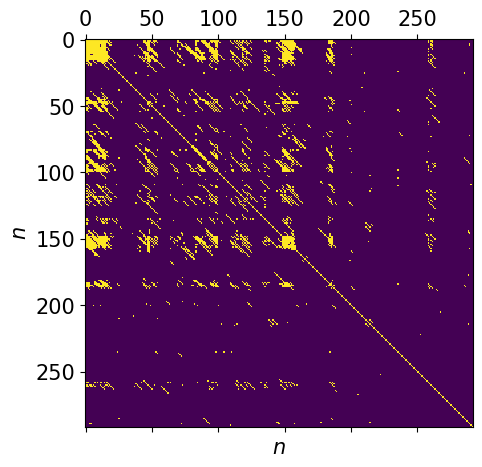

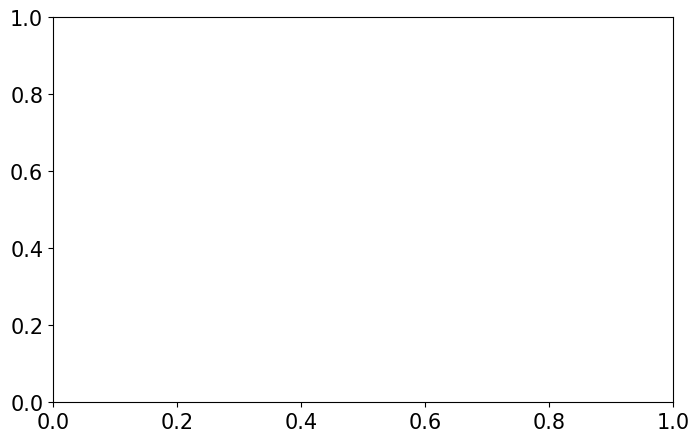

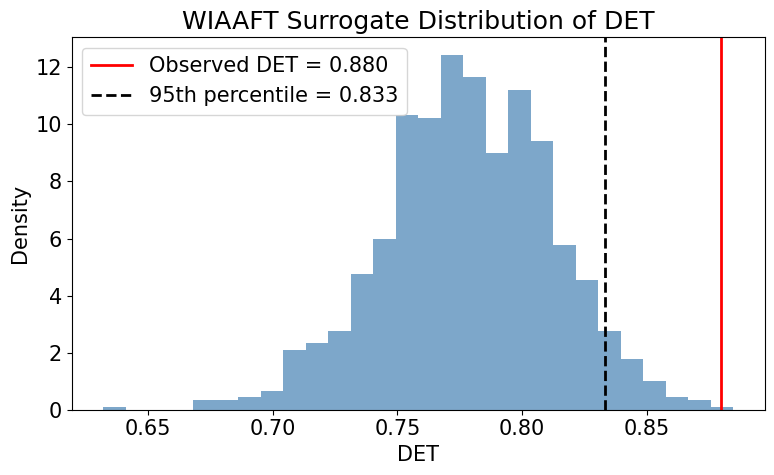

 29%|████████████▏                             | 29/100 [12:54<31:52, 26.94s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8796576032203433 
 Recurrence rate: 0.0500093826233815 
Threshold:2.0716999999999475 
 Laminarity:0.5229831144453025 
Shannon Entropy:2.1214472372963487 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

28
8
Mean Nearest Neighbor Distance: 1.6000239567196664
Pseudo-periodic surrogates generated successfullly


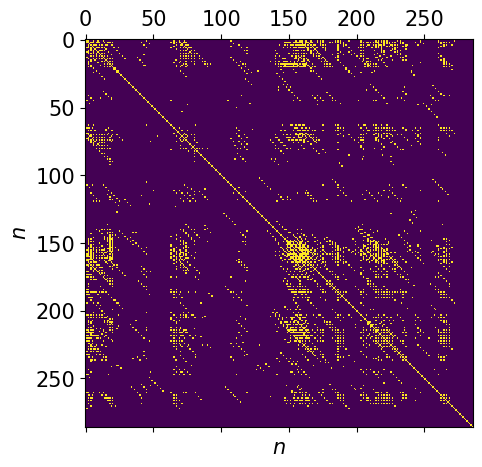

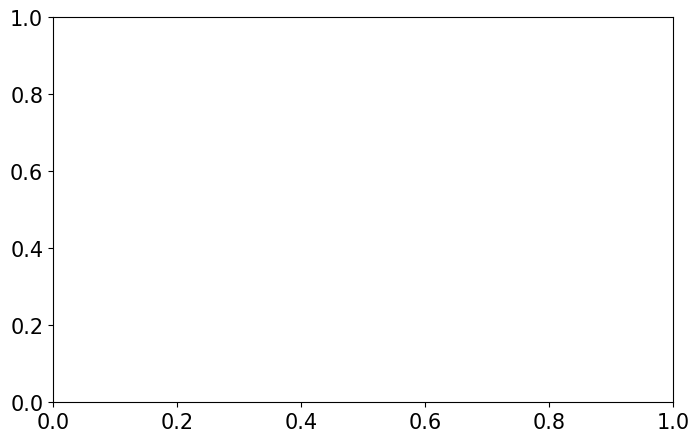

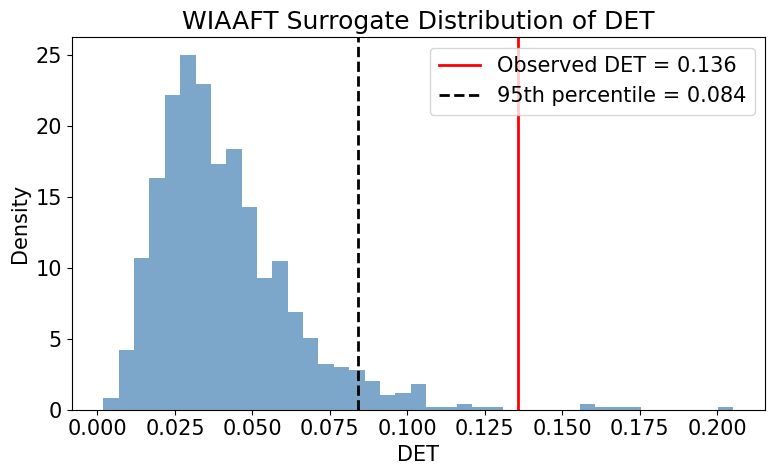

 30%|████████████▌                             | 30/100 [13:25<32:50, 28.15s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.13557540725135162 
 Recurrence rate: 0.05002689618074233 
Threshold:2.061899999999927 
 Laminarity:0.22531769305907792 
Shannon Entropy:1.8220385485328274 
Rank-order p-value (det):0.014 
Reject null (det) hypothesis:True

 
 

29
10
Mean Nearest Neighbor Distance: 1.9993252698357094
Pseudo-periodic surrogates generated successfullly


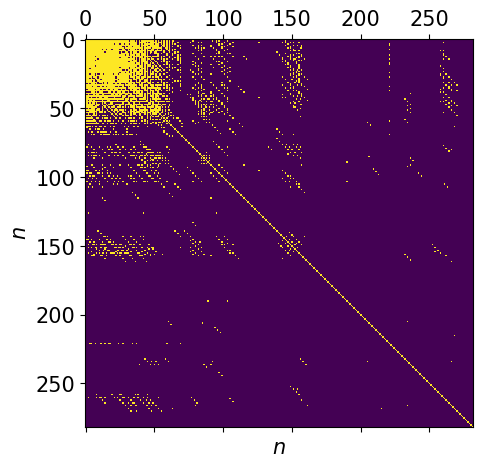

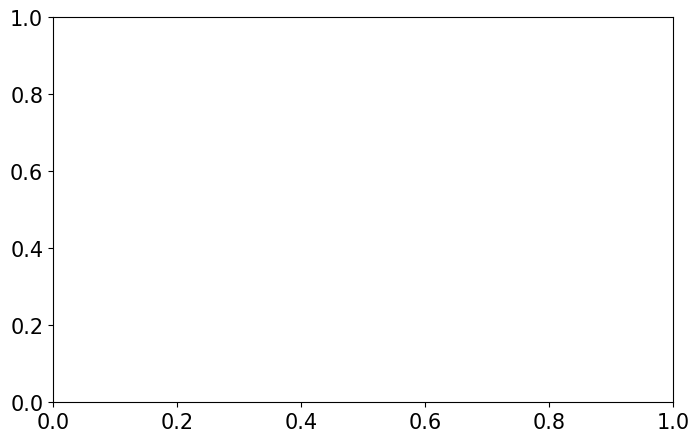

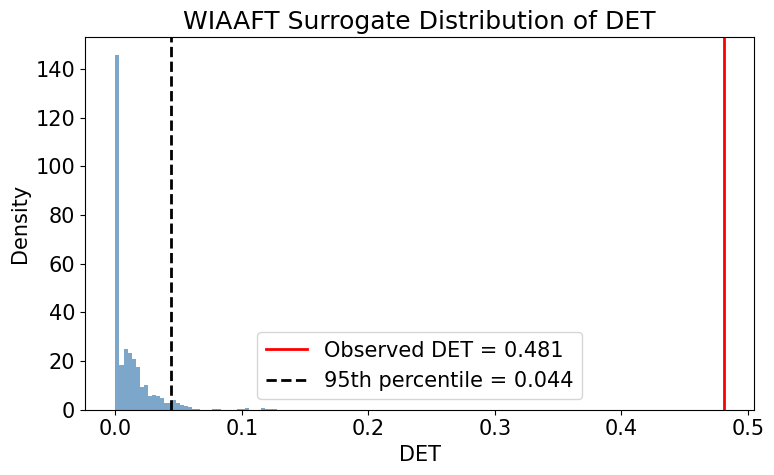

 31%|█████████████                             | 31/100 [13:55<33:02, 28.73s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.4810606060593045 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9954999999997967 
 Laminarity:0.584213172446998 
Shannon Entropy:2.7329134802532633 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

30
9
Mean Nearest Neighbor Distance: 1.7630092667773647
Pseudo-periodic surrogates generated successfullly


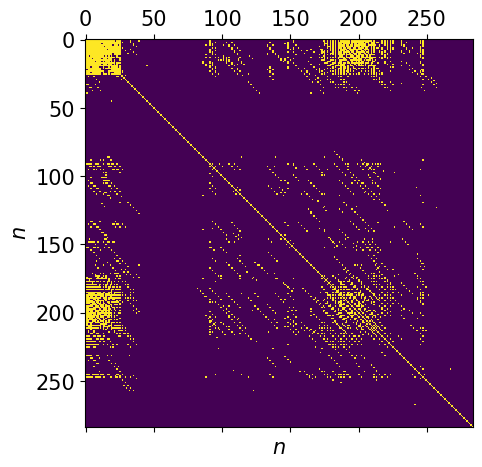

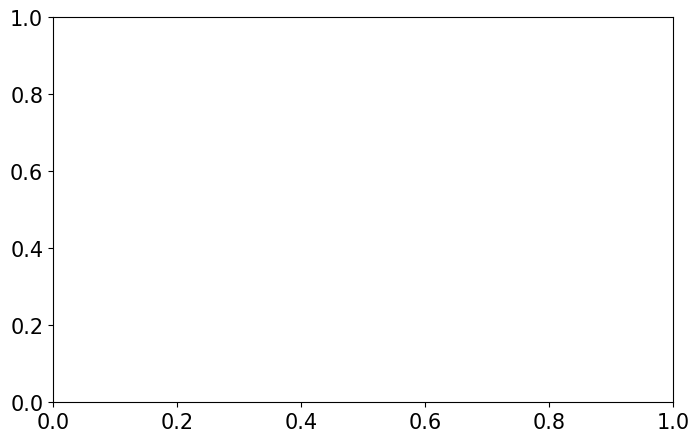

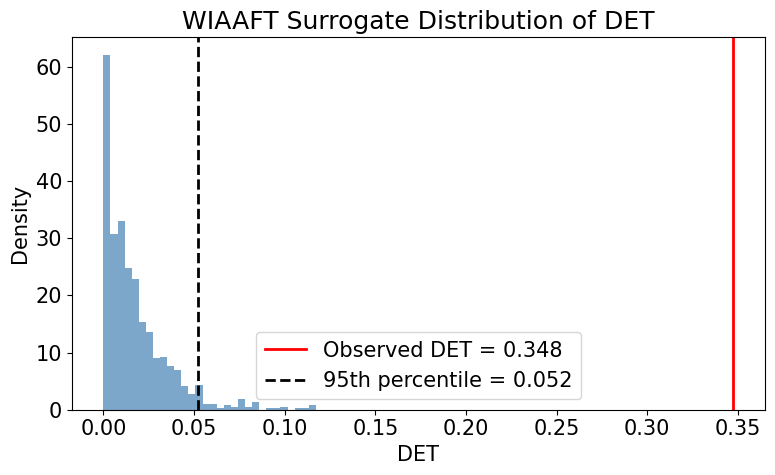

 32%|█████████████▍                            | 32/100 [14:24<32:36, 28.78s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.3475479744127198 
 Recurrence rate: 0.05003967466772466 
Threshold:1.9230999999998046 
 Laminarity:0.4717542120900105 
Shannon Entropy:2.4430937931753425 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

31
8
Mean Nearest Neighbor Distance: 1.600246484640284
Pseudo-periodic surrogates generated successfullly


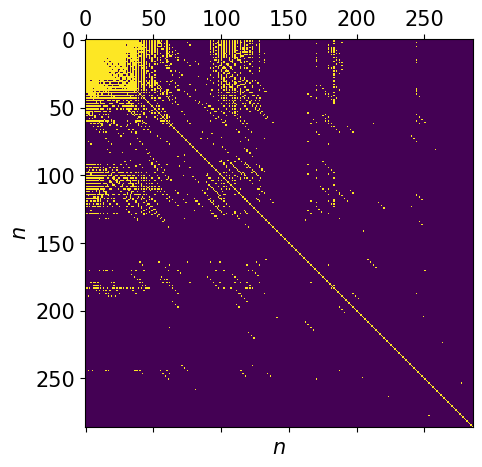

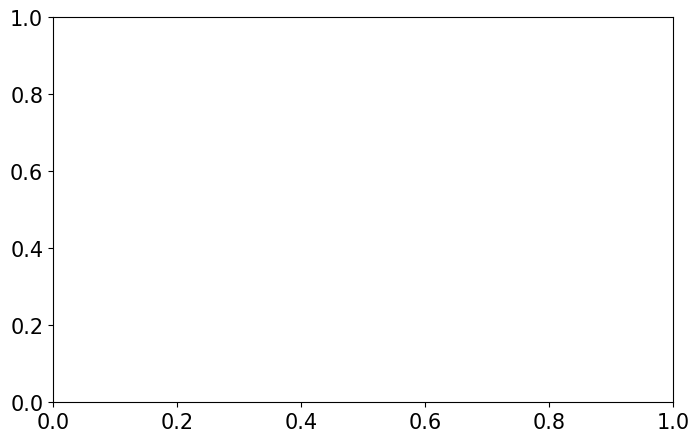

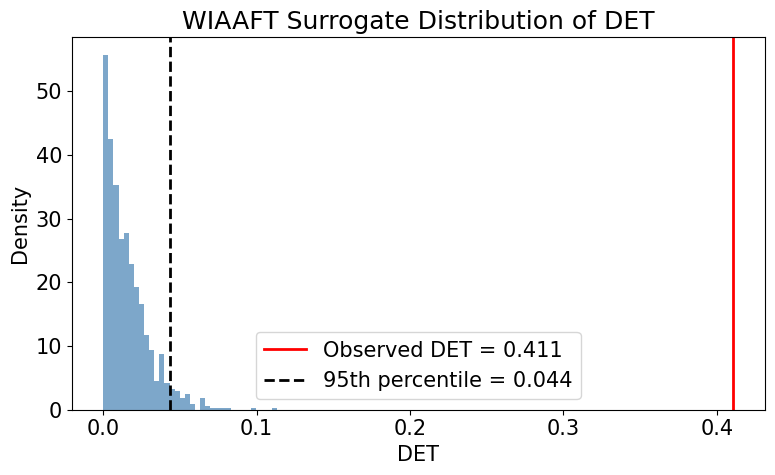

 33%|█████████████▊                            | 33/100 [14:50<31:14, 27.98s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.41093011035099597 
 Recurrence rate: 0.05002689618074233 
Threshold:1.7903999999998192 
 Laminarity:0.5303030303017343 
Shannon Entropy:2.8025756606392638 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

32
8
Mean Nearest Neighbor Distance: 1.5574174098523754
Pseudo-periodic surrogates generated successfullly


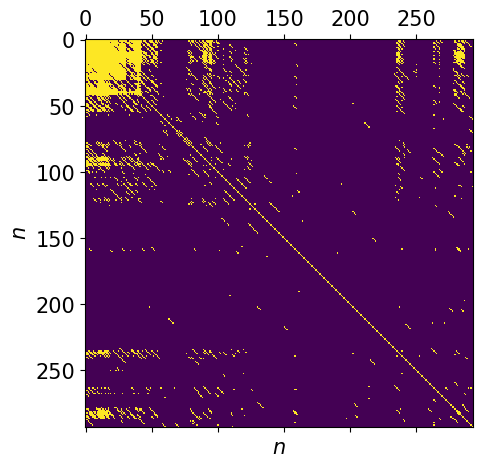

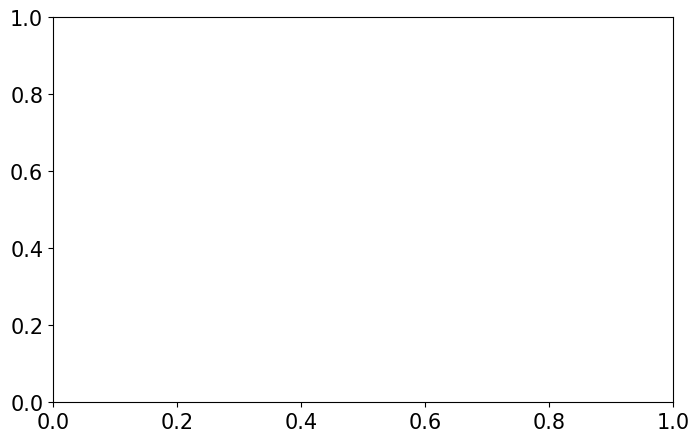

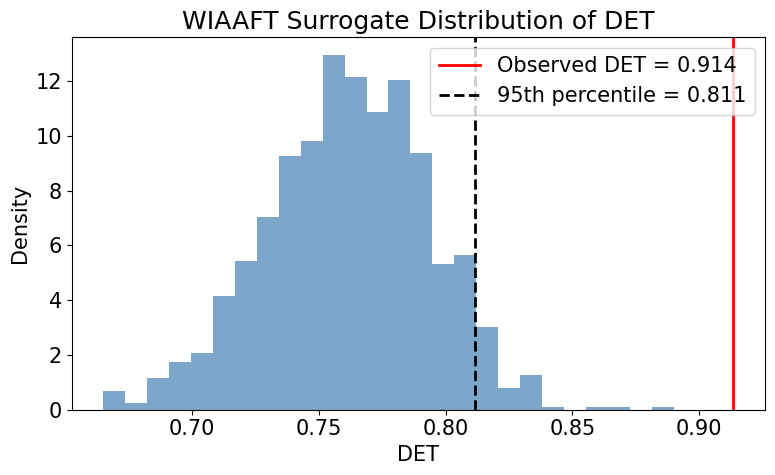

 34%|██████████████▎                           | 34/100 [15:19<31:04, 28.25s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.9135432283835244 
 Recurrence rate: 0.0500297033162879 
Threshold:1.882599999999809 
 Laminarity:0.5643771827693496 
Shannon Entropy:2.2729543566617374 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

33
8
Mean Nearest Neighbor Distance: 1.5600737663487074
Pseudo-periodic surrogates generated successfullly


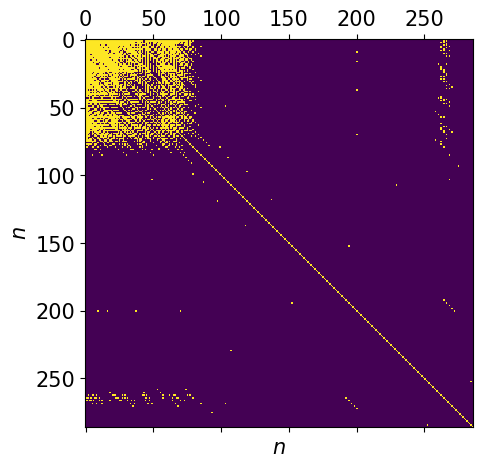

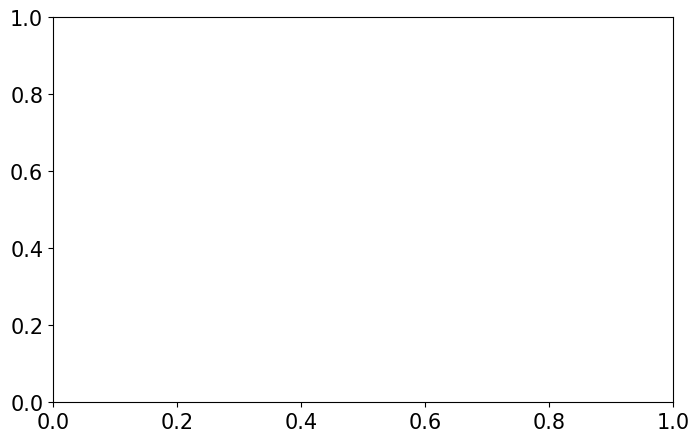

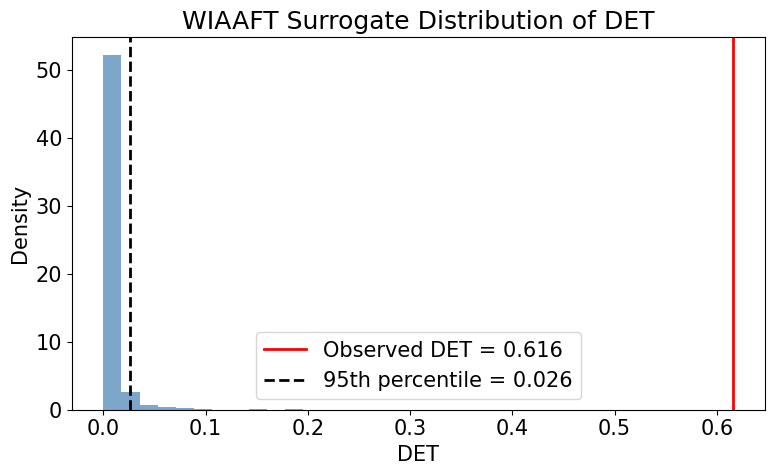

 35%|██████████████▋                           | 35/100 [15:40<28:13, 26.05s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.616193480545173 
 Recurrence rate: 0.05000244510734021 
Threshold:1.2794999999998755 
 Laminarity:0.7171149144236746 
Shannon Entropy:2.66721095670911 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

34
8
Mean Nearest Neighbor Distance: 1.6519513505814092
Pseudo-periodic surrogates generated successfullly


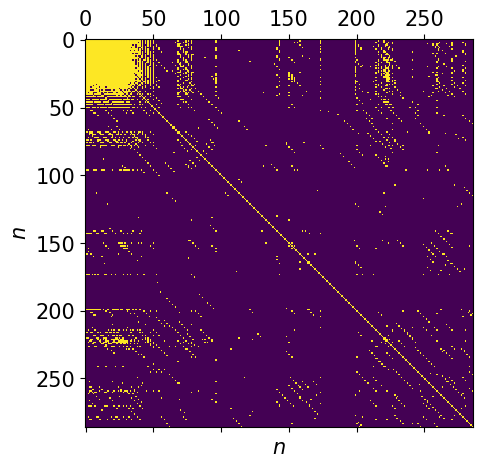

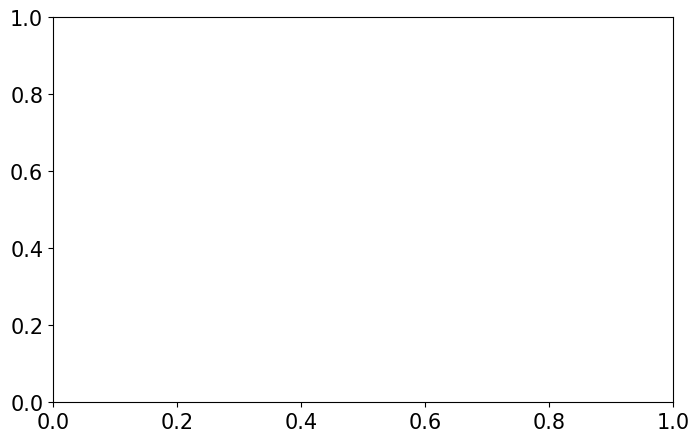

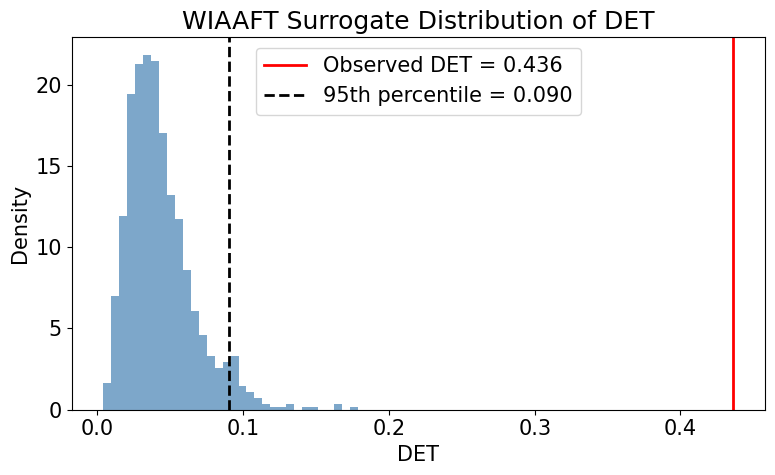

 36%|███████████████                           | 36/100 [16:10<28:54, 27.10s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.43638275499359525 
 Recurrence rate: 0.05000244510734021 
Threshold:2.0651999999999338 
 Laminarity:0.5398533007321764 
Shannon Entropy:2.7642358635914692 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

35
9
Mean Nearest Neighbor Distance: 1.8605910489842938
Pseudo-periodic surrogates generated successfullly


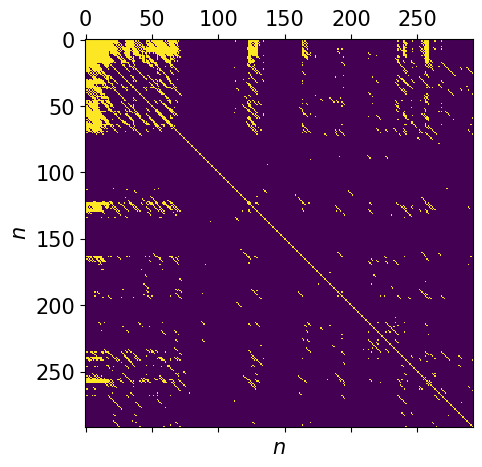

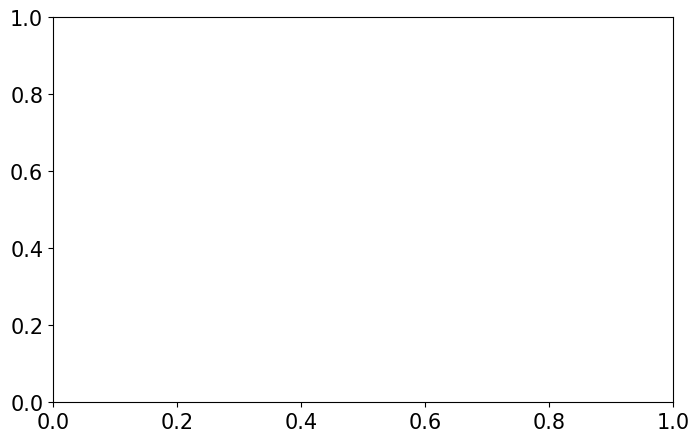

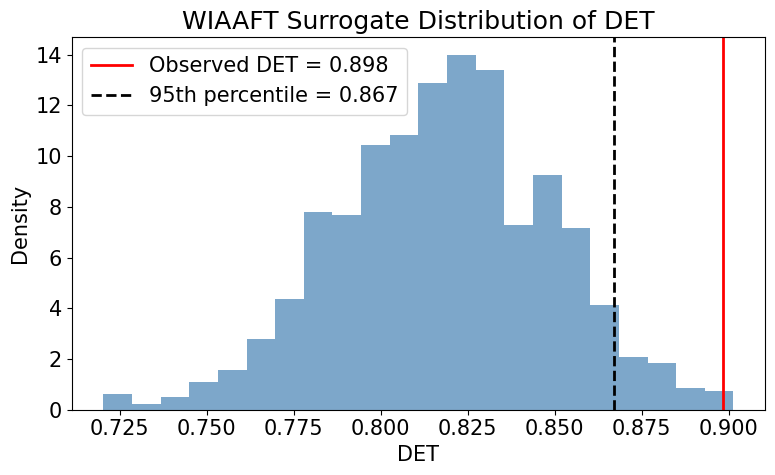

 37%|███████████████▌                          | 37/100 [16:43<30:21, 28.92s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.898288016110528 
 Recurrence rate: 0.0500093826233815 
Threshold:2.2424000000003077 
 Laminarity:0.5583958724189532 
Shannon Entropy:2.260783591079702 
Rank-order p-value (det):0.006 
Reject null (det) hypothesis:True

 
 

36
10
Mean Nearest Neighbor Distance: 2.020190644730547
Pseudo-periodic surrogates generated successfullly


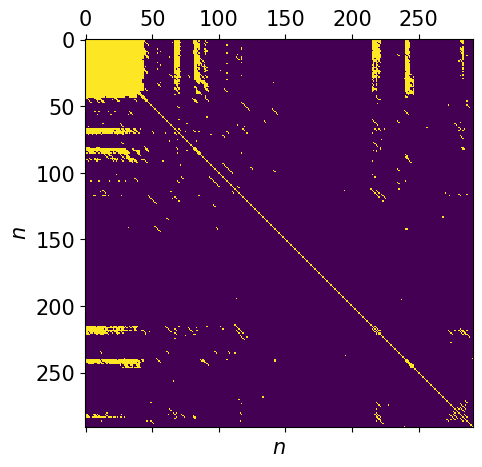

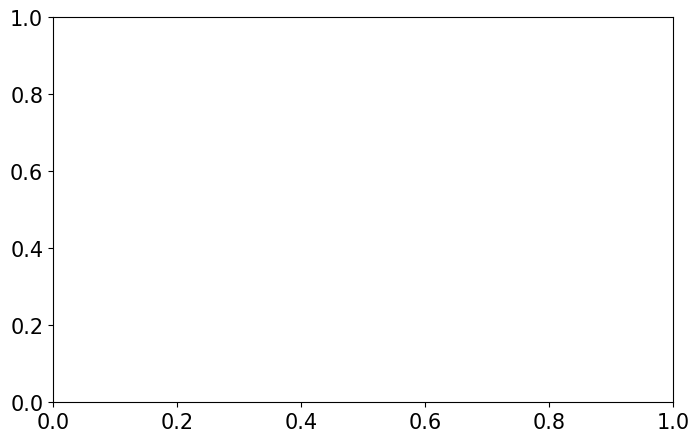

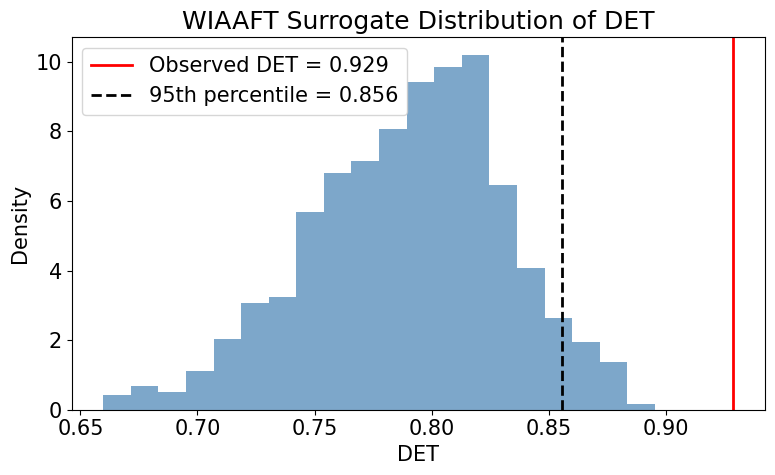

 38%|███████████████▉                          | 38/100 [17:16<31:18, 30.29s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9290060851903423 
 Recurrence rate: 0.050011218573233665 
Threshold:2.1162000000000414 
 Laminarity:0.8004722550158194 
Shannon Entropy:2.3020499834303054 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

37
7
Mean Nearest Neighbor Distance: 1.363574698261786
Pseudo-periodic surrogates generated successfullly


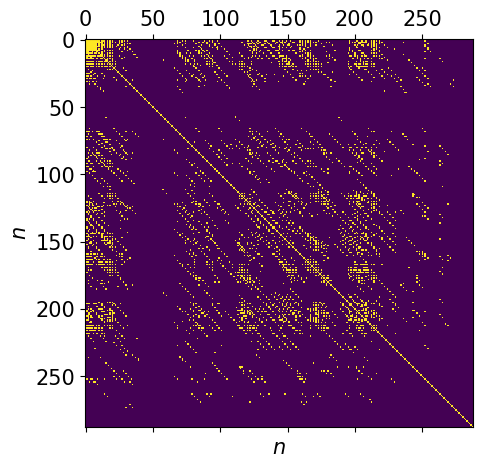

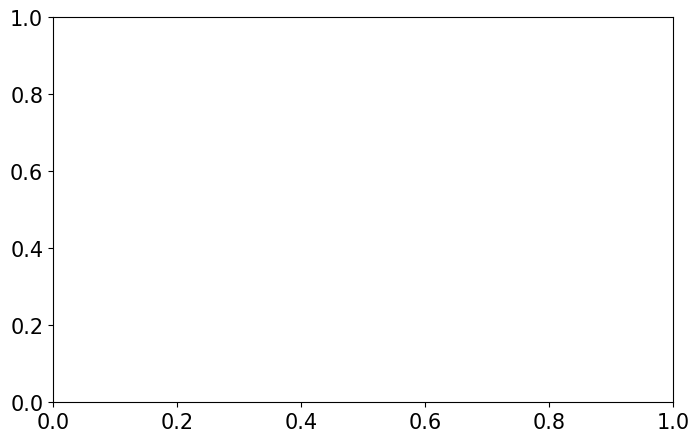

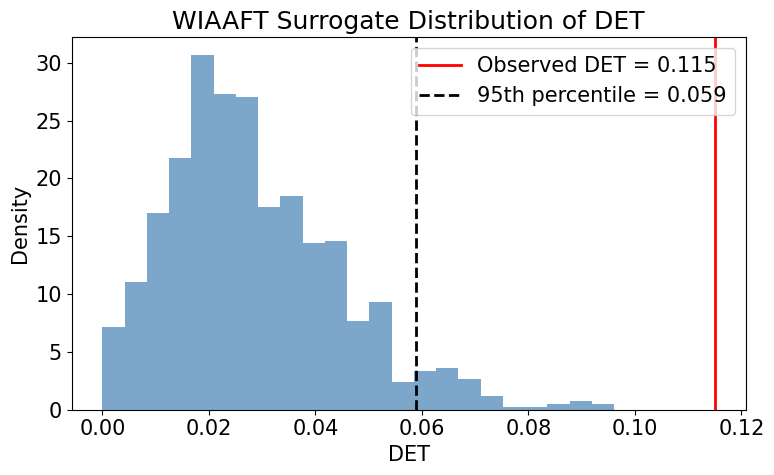

 39%|████████████████▍                         | 39/100 [17:43<29:41, 29.21s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.1150259067354533 
 Recurrence rate: 0.05000964506172839 
Threshold:1.6760999999998318 
 Laminarity:0.2287849566050415 
Shannon Entropy:1.6535359066374822 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

38
7
Mean Nearest Neighbor Distance: 1.3320124451883433
Pseudo-periodic surrogates generated successfullly


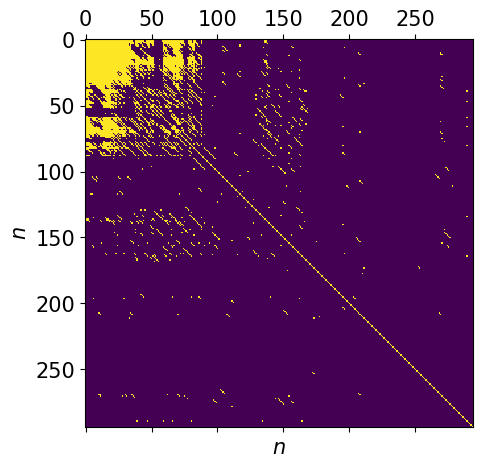

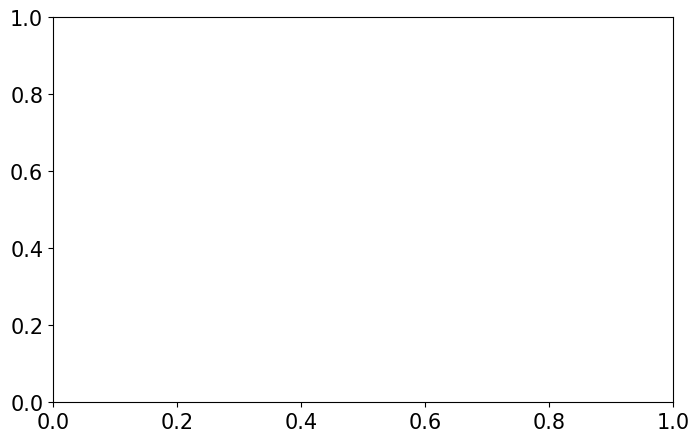

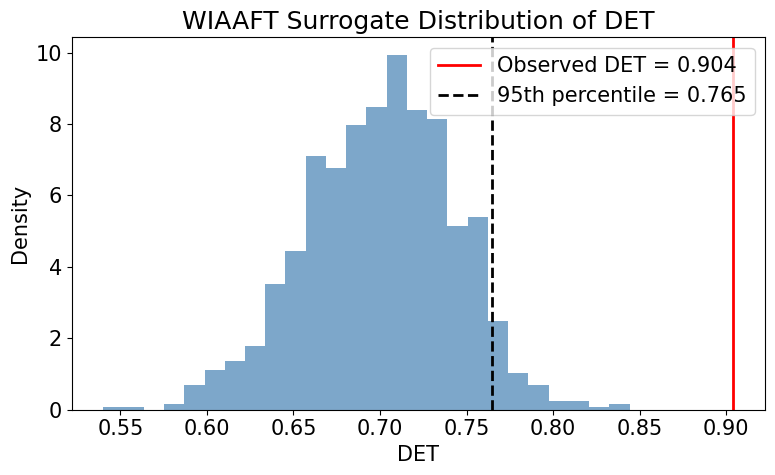

 40%|████████████████▊                         | 40/100 [18:05<26:56, 26.94s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.9041708043671695 
 Recurrence rate: 0.05000231385071035 
Threshold:1.4304999999998589 
 Laminarity:0.6429893567777811 
Shannon Entropy:2.4237493342014904 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

39
8
Mean Nearest Neighbor Distance: 1.5949392774110775
Pseudo-periodic surrogates generated successfullly


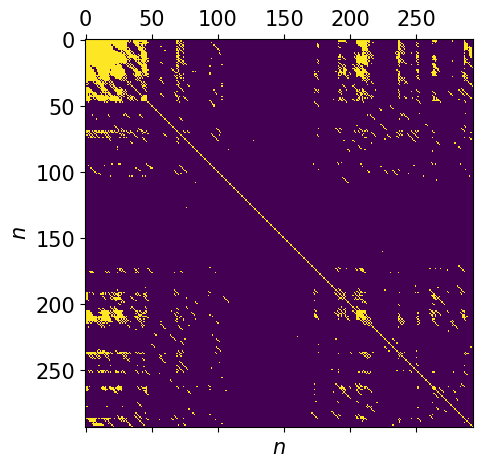

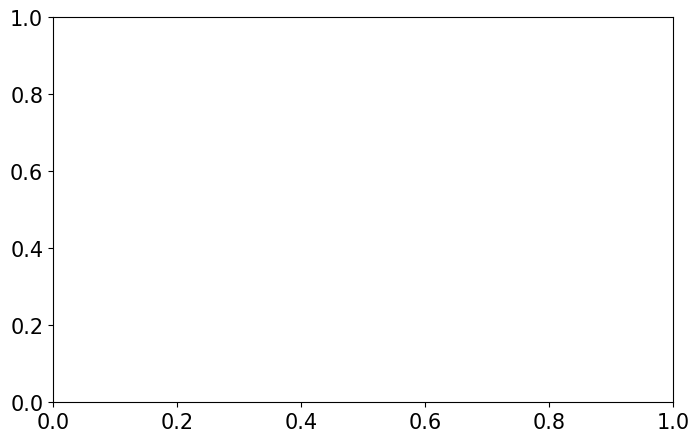

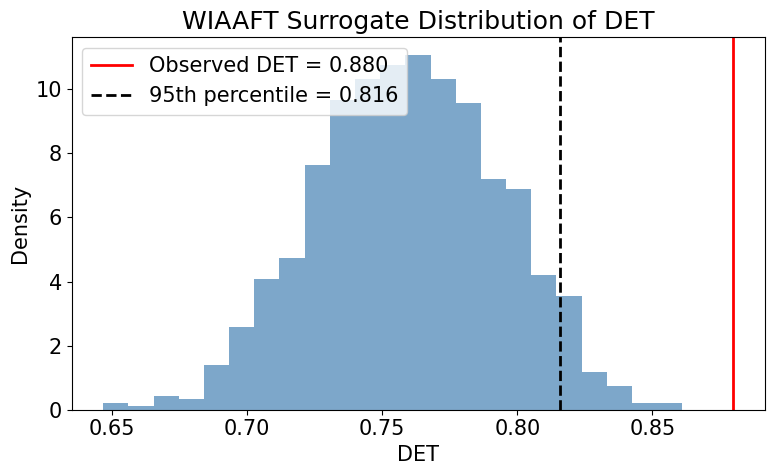

 41%|█████████████████▏                        | 41/100 [18:31<26:24, 26.86s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.8799999999978 
 Recurrence rate: 0.050006406597630726 
Threshold:1.87389999999981 
 Laminarity:0.5618448637303475 
Shannon Entropy:2.0139620045106144 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

40
8
Mean Nearest Neighbor Distance: 1.5658151118262666
Pseudo-periodic surrogates generated successfullly


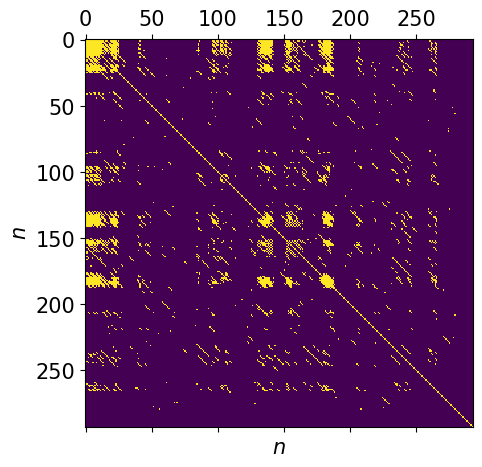

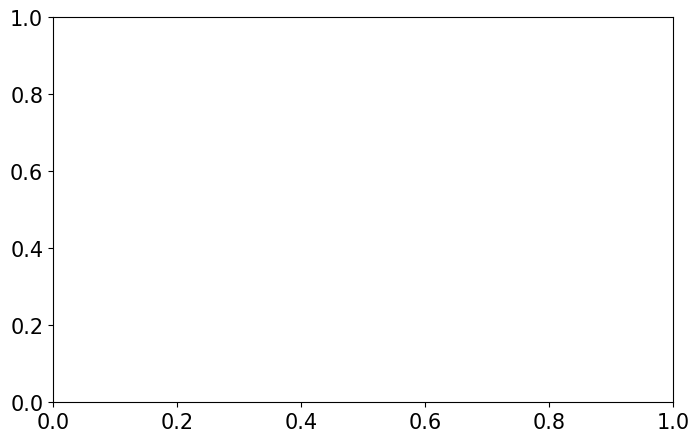

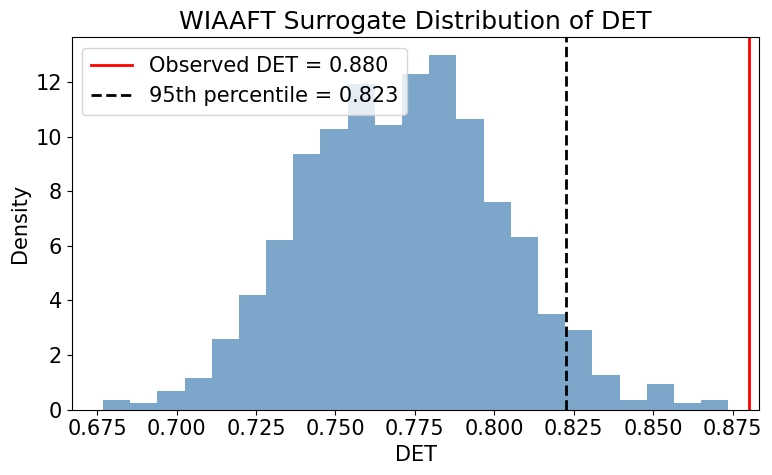

 42%|█████████████████▋                        | 42/100 [18:58<25:57, 26.85s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.8800599700127935 
 Recurrence rate: 0.0500297033162879 
Threshold:1.9428999999998025 
 Laminarity:0.4786961583225176 
Shannon Entropy:2.0033128813811394 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

41
8
Mean Nearest Neighbor Distance: 1.5834045188064259
Pseudo-periodic surrogates generated successfullly


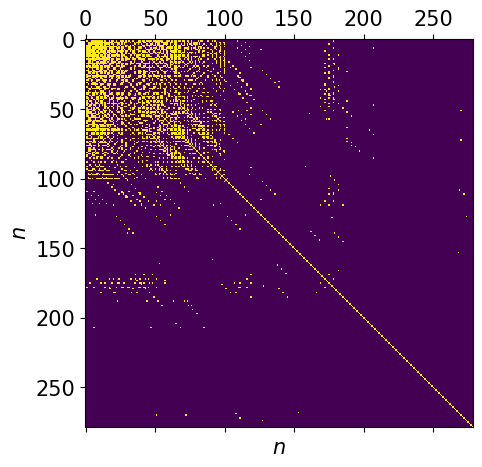

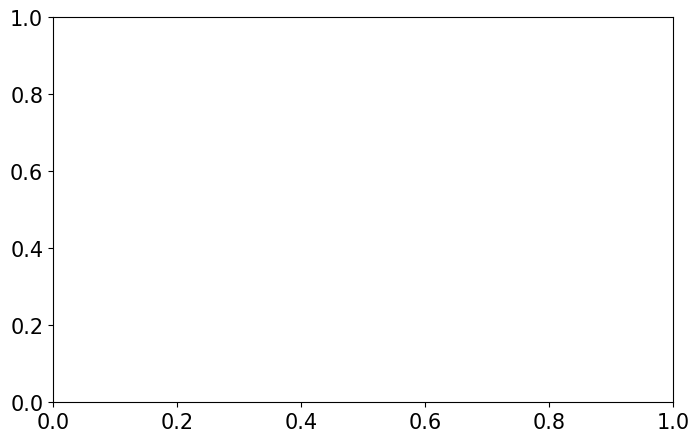

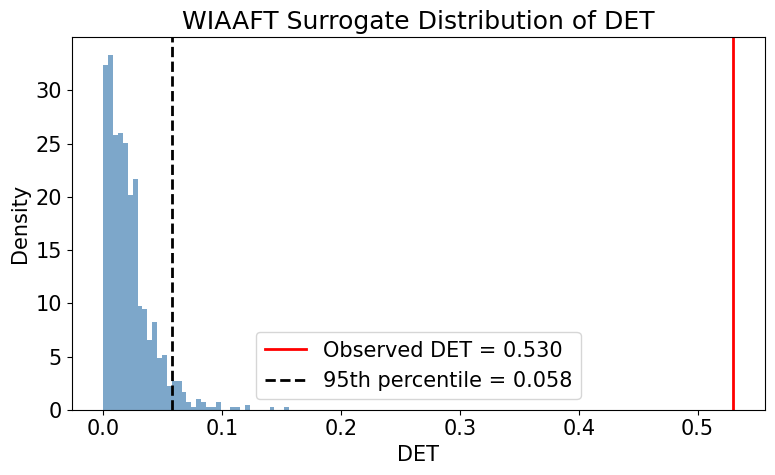

 43%|██████████████████                        | 43/100 [19:19<23:57, 25.22s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.5301604869935524 
 Recurrence rate: 0.050012204365308774 
Threshold:1.564699999999844 
 Laminarity:0.5530439249921576 
Shannon Entropy:0.666920489641907 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

42
7


Not enough points found!


Mean Nearest Neighbor Distance: 1.4286429978012154
Pseudo-periodic surrogates generated successfullly


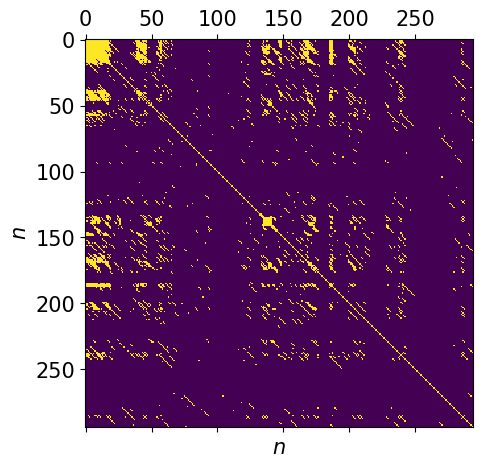

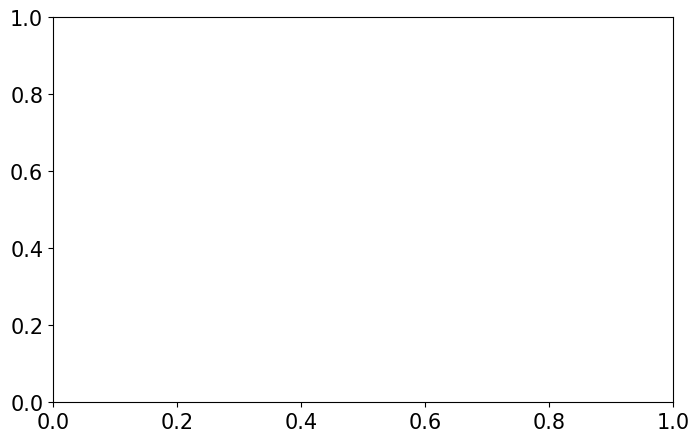

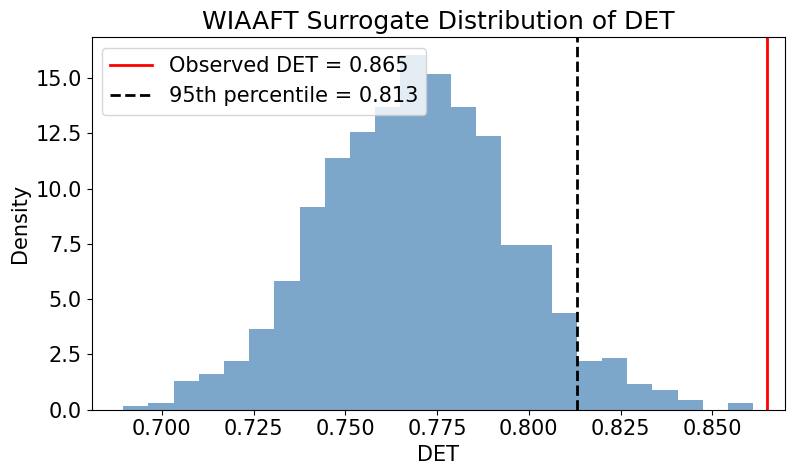

 44%|██████████████████▍                       | 44/100 [19:45<23:36, 25.30s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8649453823215866 
 Recurrence rate: 0.05000231385071035 
Threshold:1.8638999999998112 
 Laminarity:0.4352151781572531 
Shannon Entropy:1.8080275315174583 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

43
7


Not enough points found!


Mean Nearest Neighbor Distance: 1.429287517767822
Pseudo-periodic surrogates generated successfullly


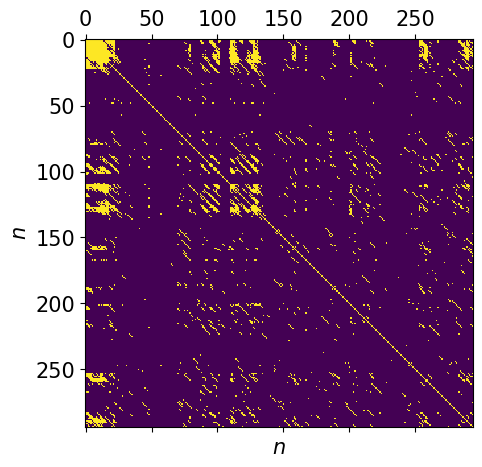

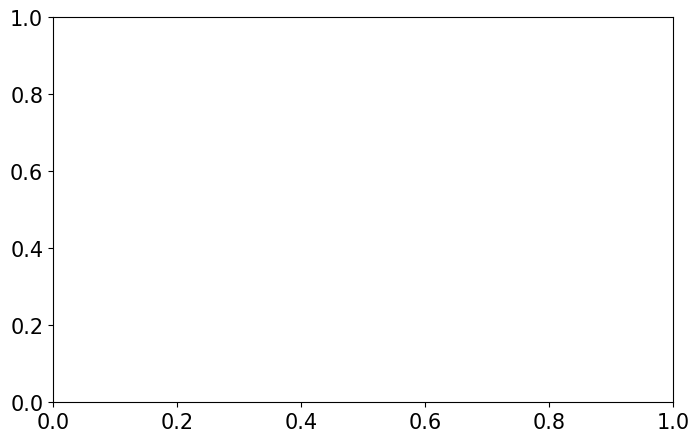

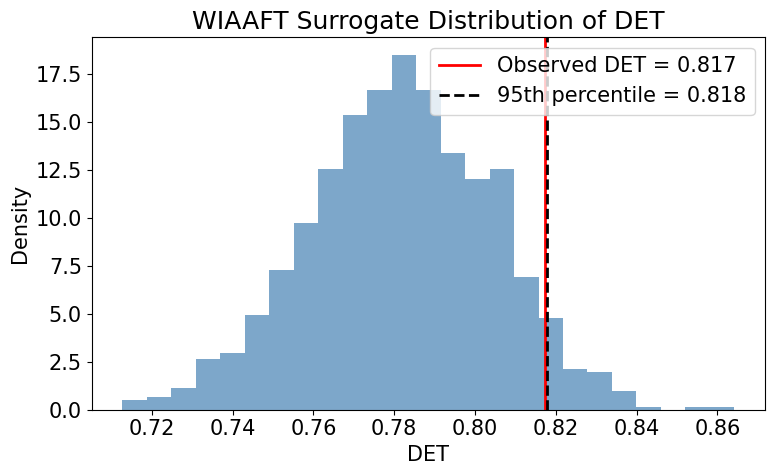

 45%|██████████████████▉                       | 45/100 [20:11<23:26, 25.57s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8172790466712581 
 Recurrence rate: 0.05000231385071035 
Threshold:1.946199999999802 
 Laminarity:0.4905136510863246 
Shannon Entropy:1.887058430534764 
Rank-order p-value (det):0.112 
Reject null (det) hypothesis:False

 
 

43
10
Mean Nearest Neighbor Distance: 1.9866751881500464
Pseudo-periodic surrogates generated successfullly


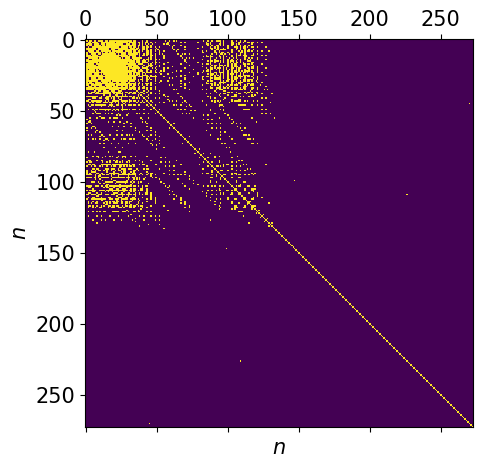

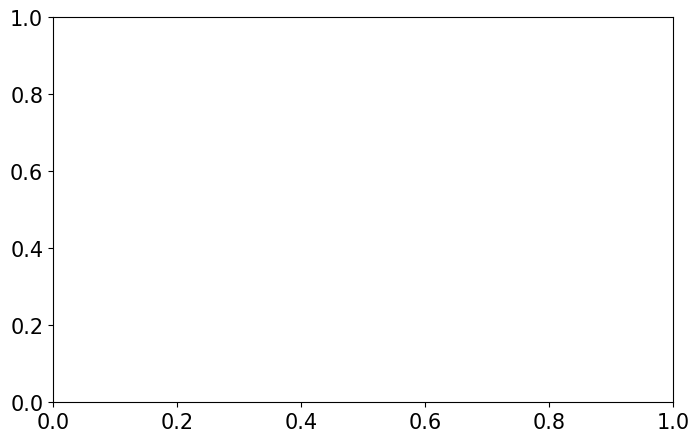

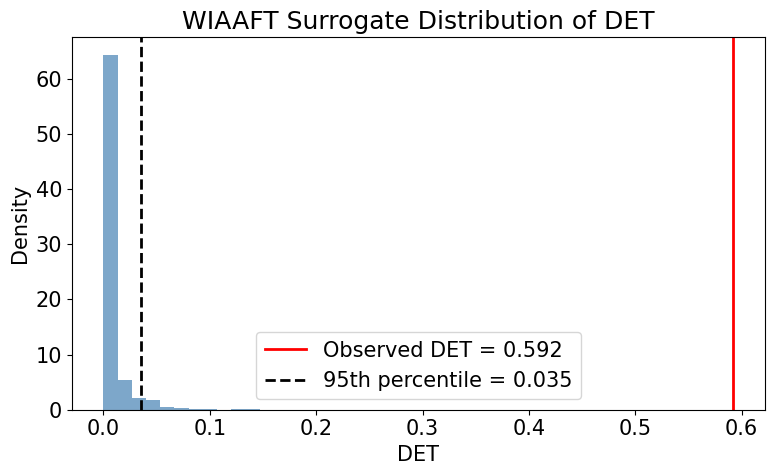

 46%|███████████████████▎                      | 46/100 [20:35<22:31, 25.03s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.5923566878963742 
 Recurrence rate: 0.050007379677709345 
Threshold:1.6515999999998345 
 Laminarity:0.6069224577391819 
Shannon Entropy:0.8087127589930283 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

44
9


Not enough points found!


Mean Nearest Neighbor Distance: 1.7675993007131157
Pseudo-periodic surrogates generated successfullly


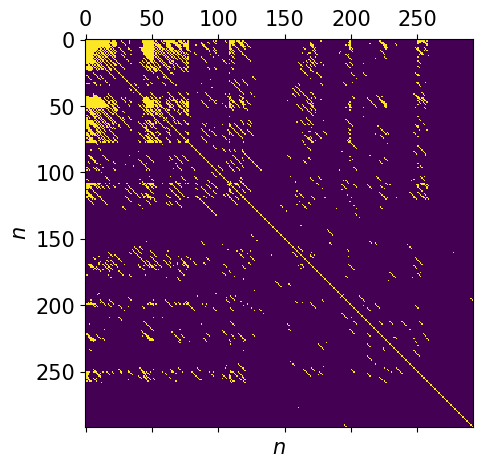

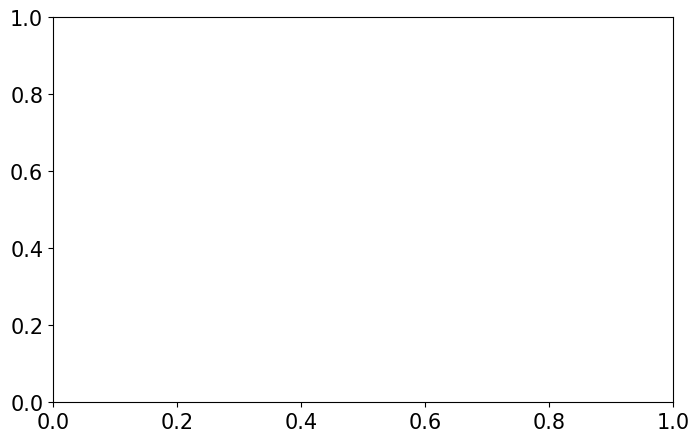

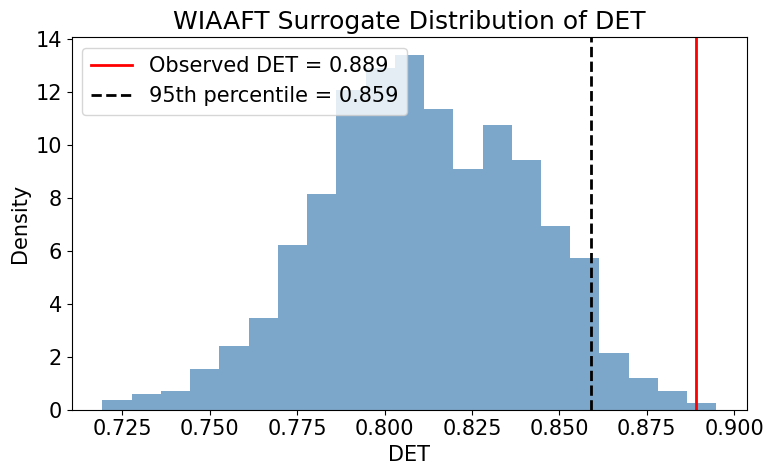

 47%|███████████████████▋                      | 47/100 [21:05<23:32, 26.64s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8892245720017895 
 Recurrence rate: 0.0500093826233815 
Threshold:2.2272000000002756 
 Laminarity:0.3968105065656735 
Shannon Entropy:2.116285589099938 
Rank-order p-value (det):0.006 
Reject null (det) hypothesis:True

 
 

45
10
Mean Nearest Neighbor Distance: 2.0119403907783493
Pseudo-periodic surrogates generated successfullly


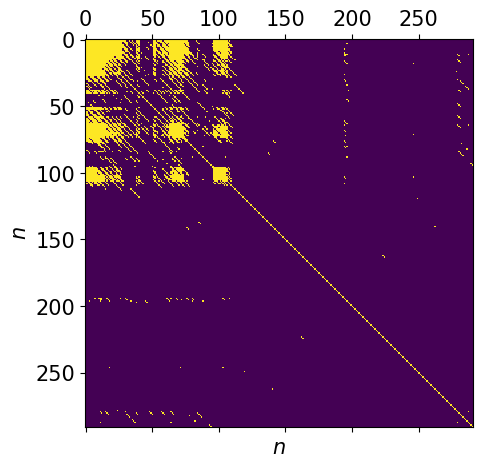

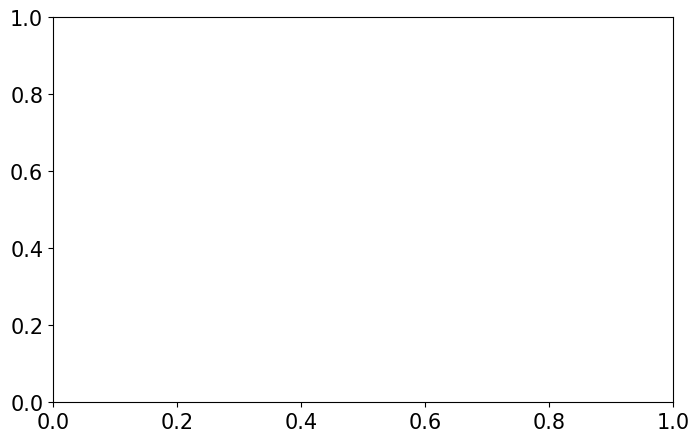

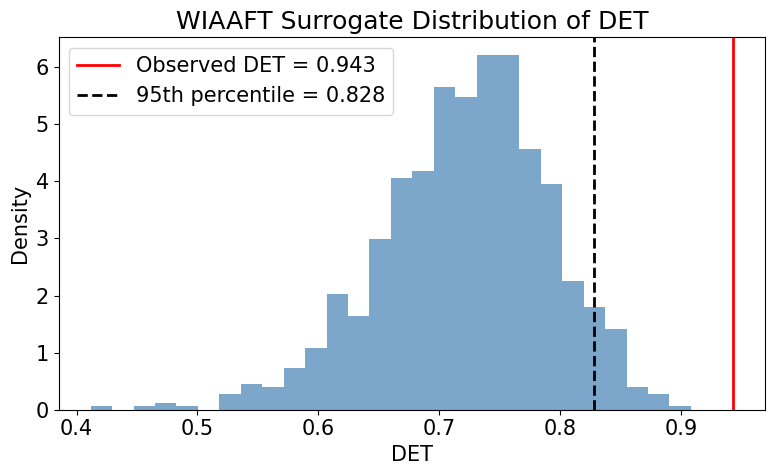

 48%|████████████████████▏                     | 48/100 [21:32<23:12, 26.78s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9427268119590909 
 Recurrence rate: 0.050034836622146646 
Threshold:1.8045999999998177 
 Laminarity:0.7030918102414372 
Shannon Entropy:2.5529384146585157 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

46
8
Mean Nearest Neighbor Distance: 1.6579852983089314
Pseudo-periodic surrogates generated successfullly


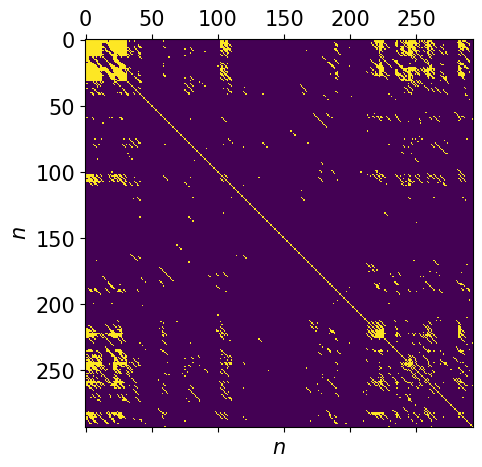

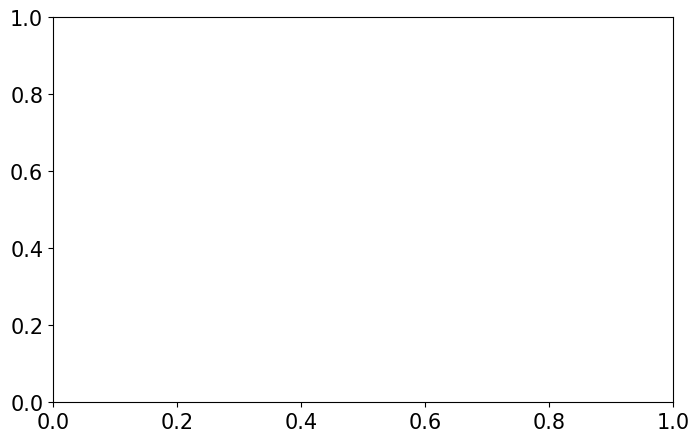

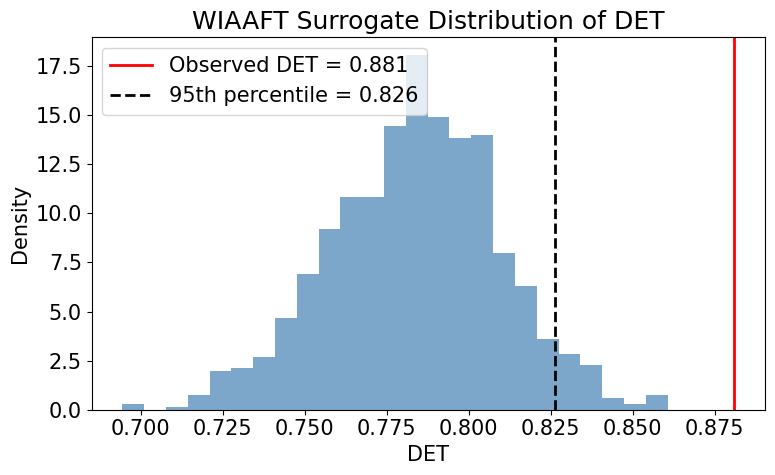

 49%|████████████████████▌                     | 49/100 [22:00<23:05, 27.16s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.8809999999977975 
 Recurrence rate: 0.050006406597630726 
Threshold:2.03489999999987 
 Laminarity:0.5457721872803499 
Shannon Entropy:2.0461583030066532 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

47
6


Not enough points found!


Mean Nearest Neighbor Distance: 1.1970903760810894
Pseudo-periodic surrogates generated successfullly


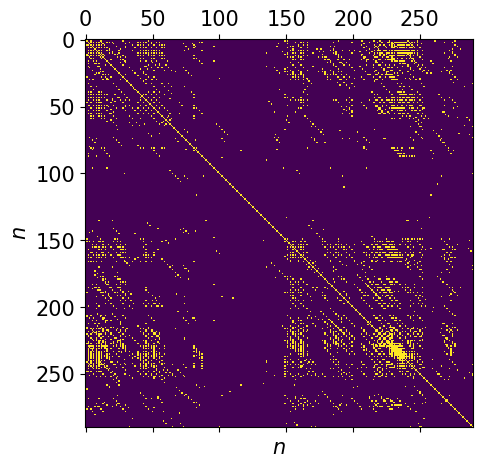

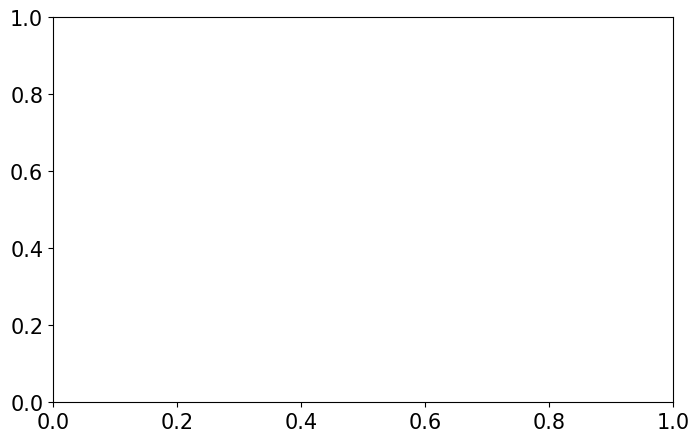

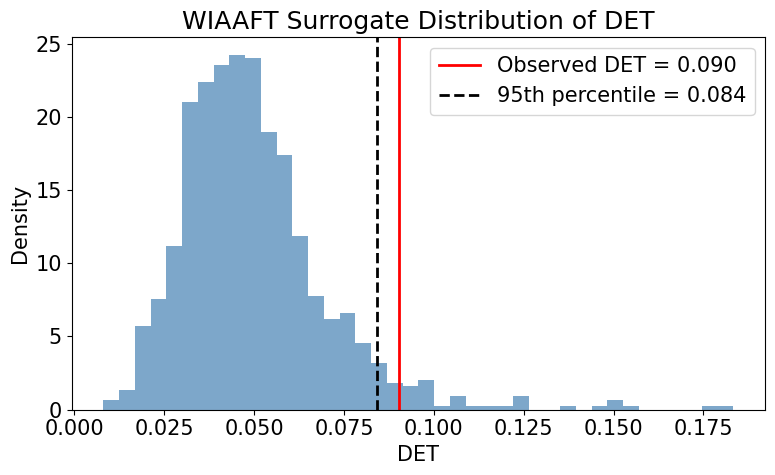

 50%|█████████████████████                     | 50/100 [22:23<21:29, 25.78s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.09039836567903371 
 Recurrence rate: 0.05001189060642093 
Threshold:1.6363999999998362 
 Laminarity:0.23728007608122378 
Shannon Entropy:1.7139464254563381 
Rank-order p-value (det):0.076 
Reject null (det) hypothesis:False

 
 

47
9
Mean Nearest Neighbor Distance: 1.8489533238966405
Pseudo-periodic surrogates generated successfullly


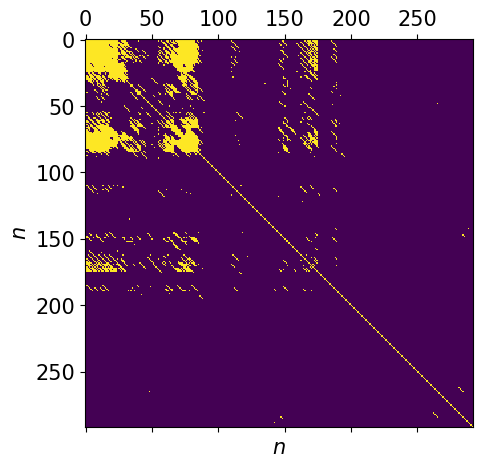

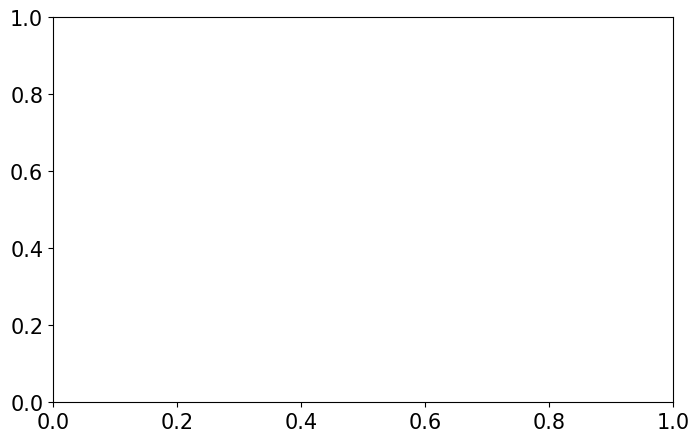

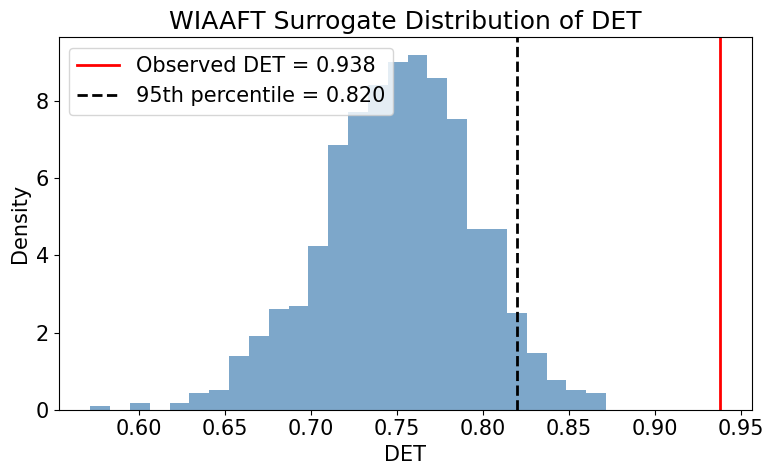

 51%|█████████████████████▍                    | 51/100 [22:49<21:11, 25.94s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9380664652544359 
 Recurrence rate: 0.0500093826233815 
Threshold:1.8698999999998105 
 Laminarity:0.7098968105049017 
Shannon Entropy:2.6184436723858004 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

48
10
Mean Nearest Neighbor Distance: 1.9731840608377658
Pseudo-periodic surrogates generated successfullly


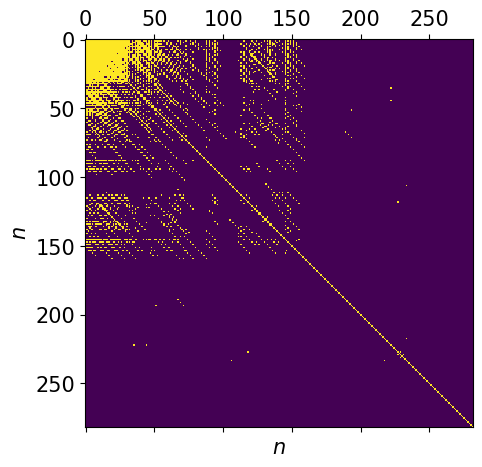

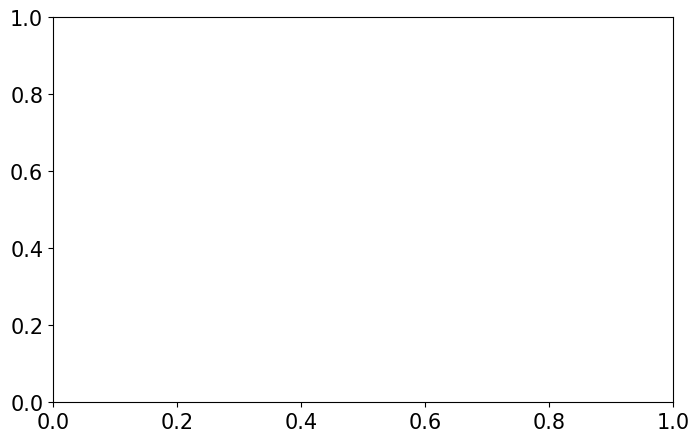

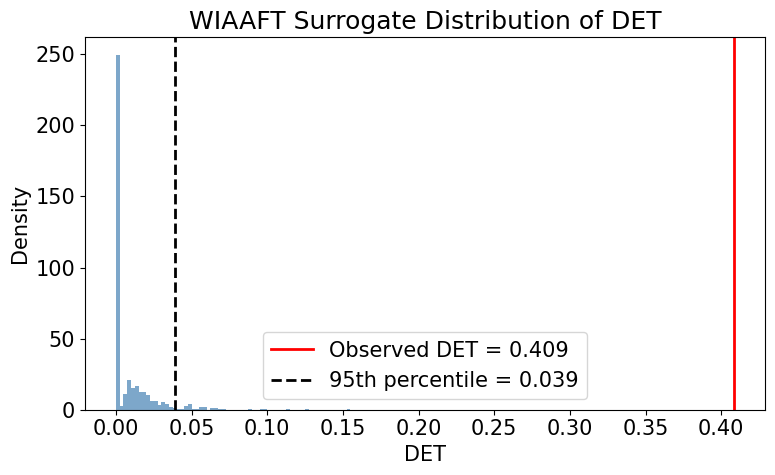

 52%|█████████████████████▊                    | 52/100 [23:17<21:08, 26.42s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.40854978354867816 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9521999999998014 
 Laminarity:0.5500251382590498 
Shannon Entropy:2.8511278043881276 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

49
9
Mean Nearest Neighbor Distance: 1.7610658854614476
Pseudo-periodic surrogates generated successfullly


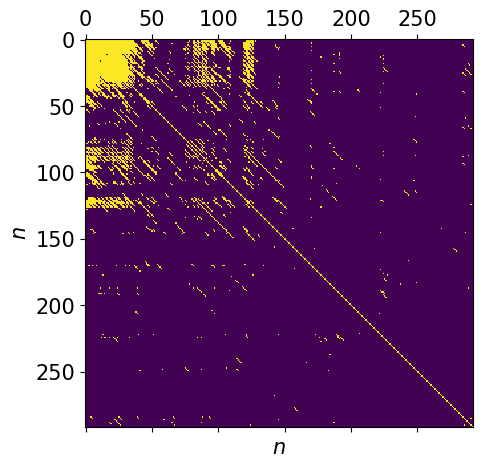

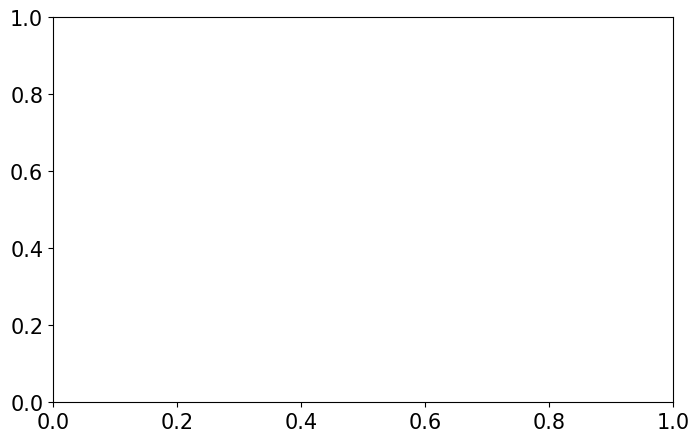

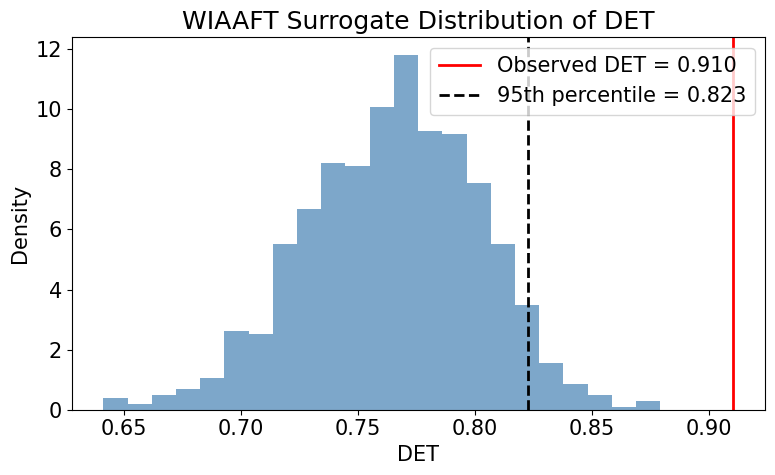

 53%|██████████████████████▎                   | 53/100 [23:44<20:56, 26.73s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9103726082555127 
 Recurrence rate: 0.0500093826233815 
Threshold:1.9605999999998005 
 Laminarity:0.602485928704028 
Shannon Entropy:2.4012844967585667 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

50
10
Mean Nearest Neighbor Distance: 2.064531136724108
Pseudo-periodic surrogates generated successfullly


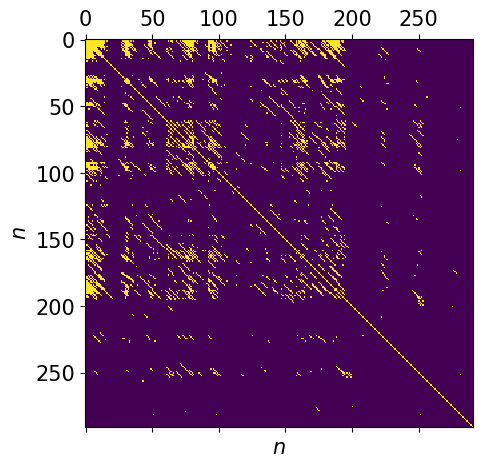

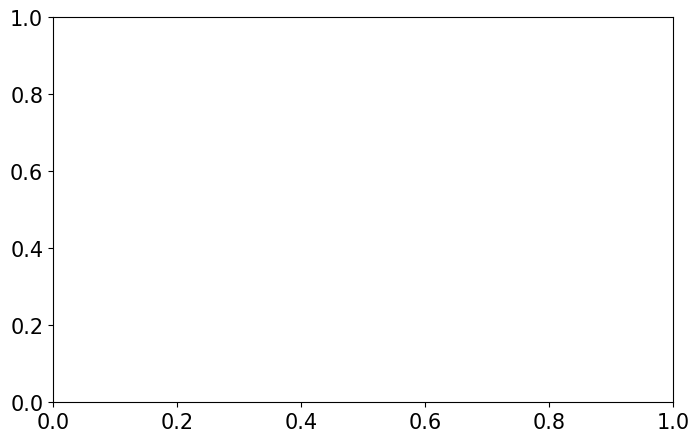

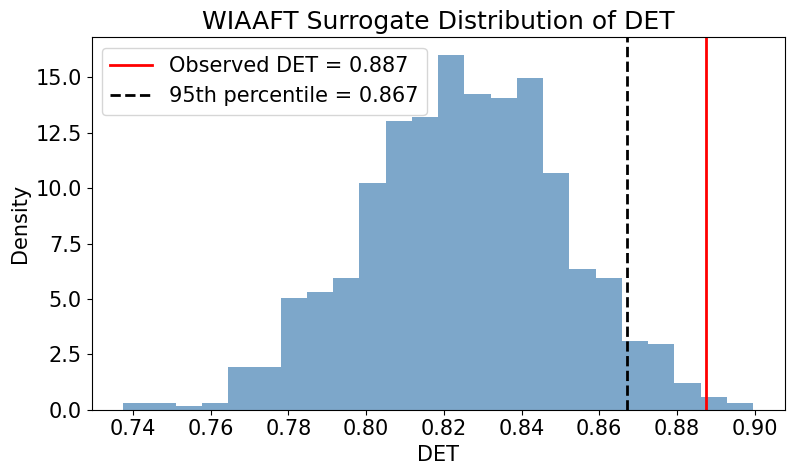

 54%|██████████████████████▋                   | 54/100 [24:18<22:05, 28.83s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.8874809934088002 
 Recurrence rate: 0.050034836622146646 
Threshold:2.5101000000008726 
 Laminarity:0.37573755015252364 
Shannon Entropy:2.023504967725555 
Rank-order p-value (det):0.014 
Reject null (det) hypothesis:True

 
 

51
9
Mean Nearest Neighbor Distance: 1.8537716948656295
Pseudo-periodic surrogates generated successfullly


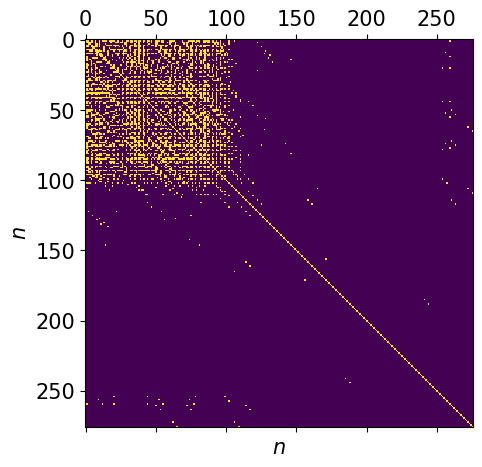

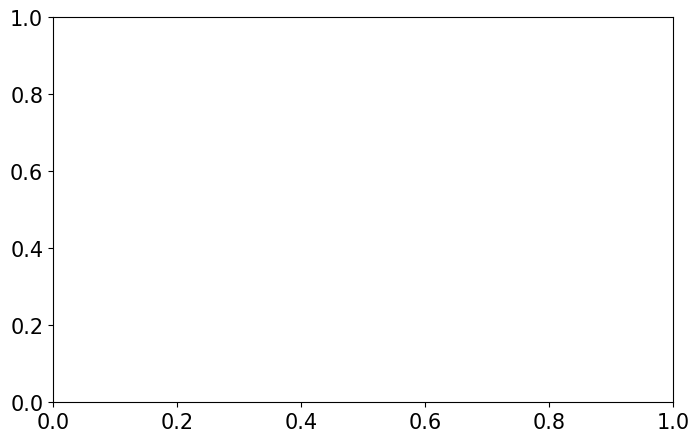

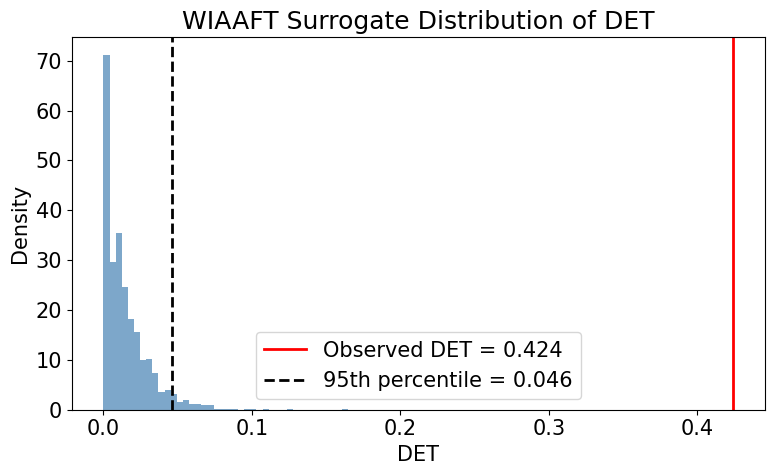

 55%|███████████████████████                   | 55/100 [24:42<20:29, 27.31s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.42444821731628624 
 Recurrence rate: 0.050015752993068686 
Threshold:1.8415999999998136 
 Laminarity:0.5391076115471415 
Shannon Entropy:0.29708594904421315 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

52
10
Mean Nearest Neighbor Distance: 2.0500343732185473
Pseudo-periodic surrogates generated successfullly


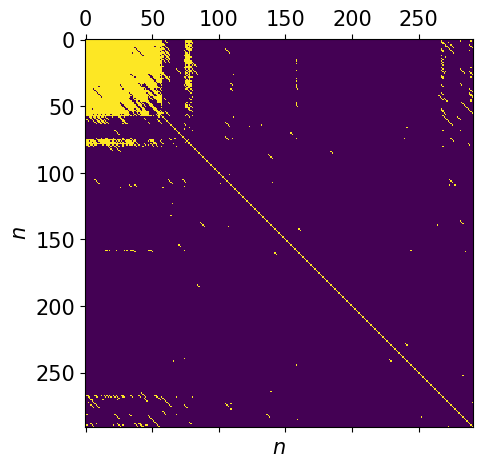

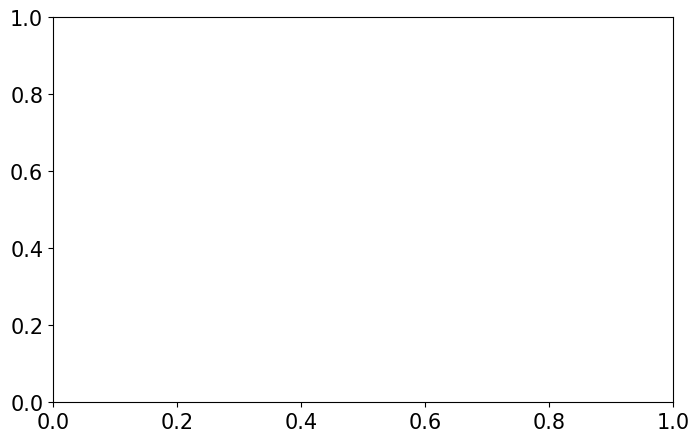

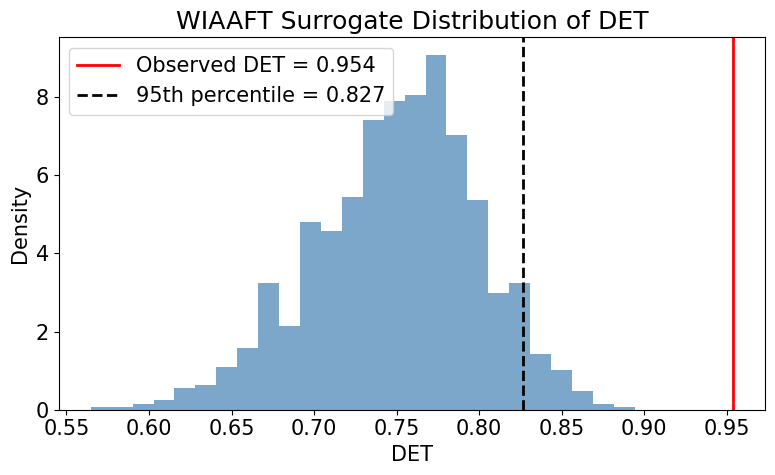

 56%|███████████████████████▌                  | 56/100 [25:10<20:18, 27.69s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9538539553728351 
 Recurrence rate: 0.050011218573233665 
Threshold:2.0262999999998517 
 Laminarity:0.8240850059012419 
Shannon Entropy:2.894304280876645 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

53
9


Not enough points found!


Mean Nearest Neighbor Distance: 1.8584119056702568
Pseudo-periodic surrogates generated successfullly


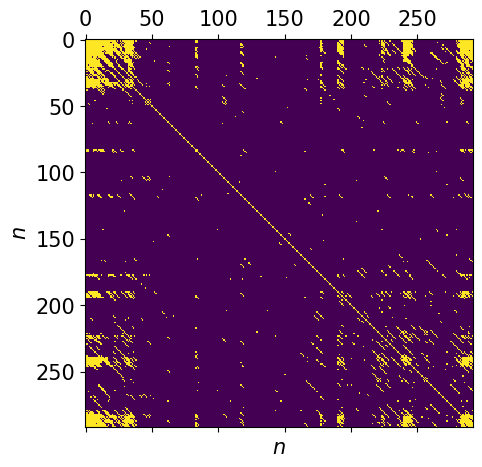

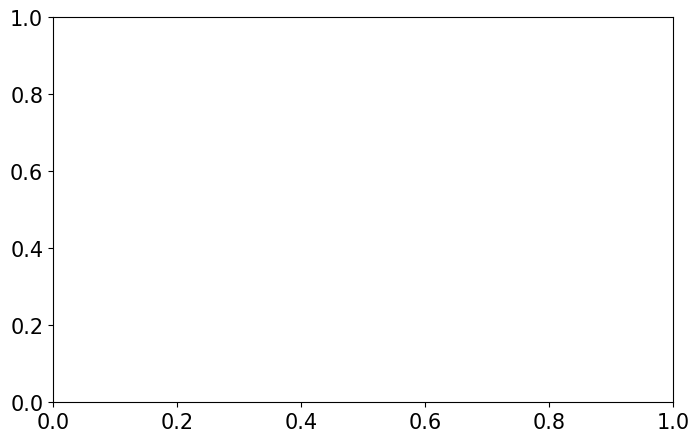

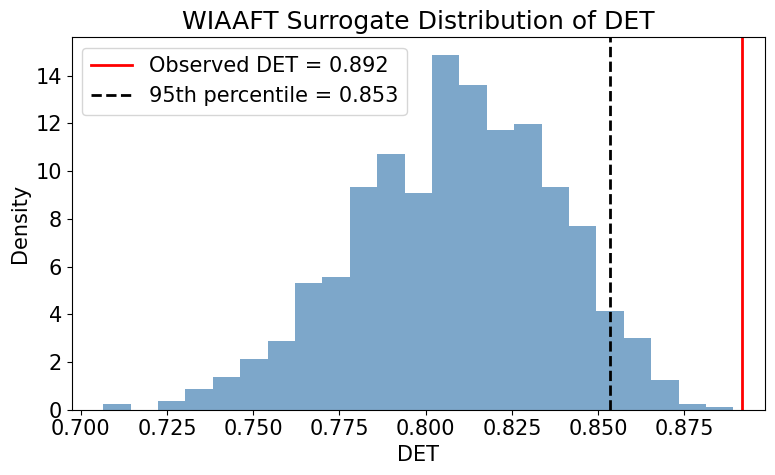

 57%|███████████████████████▉                  | 57/100 [25:42<20:44, 28.95s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.891742195365328 
 Recurrence rate: 0.0500093826233815 
Threshold:2.227800000000277 
 Laminarity:0.5715290806740818 
Shannon Entropy:2.16645826541275 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

54
9
Mean Nearest Neighbor Distance: 1.8102893924986674
Pseudo-periodic surrogates generated successfullly


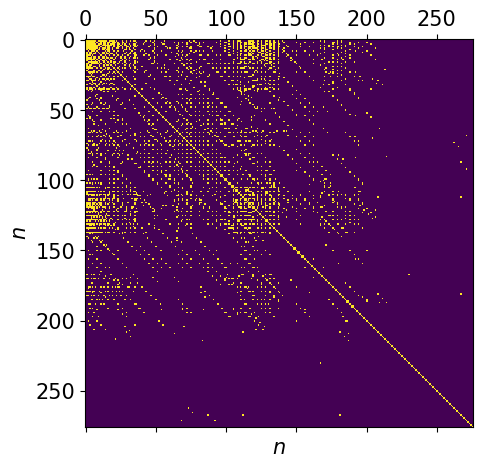

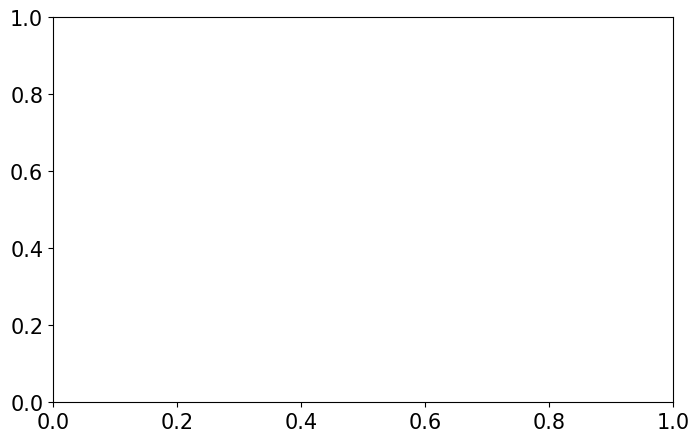

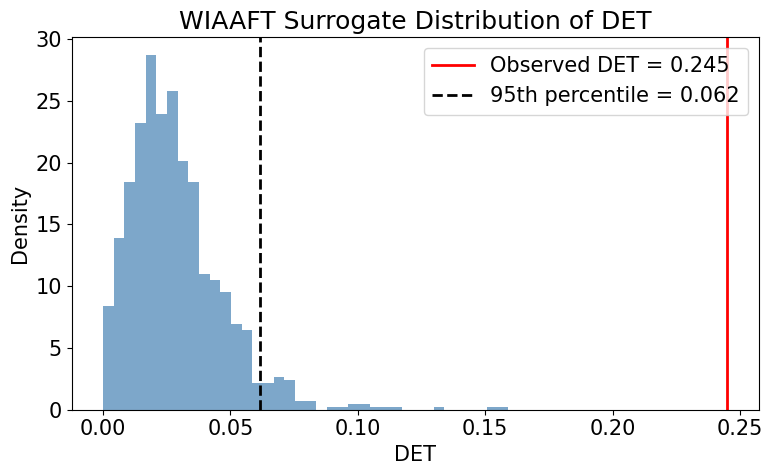

 58%|████████████████████████▎                 | 58/100 [26:09<19:43, 28.18s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.2450481041306026 
 Recurrence rate: 0.050015752993068686 
Threshold:2.0589999999999207 
 Laminarity:0.30026246719081295 
Shannon Entropy:0.5517416046296062 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

55
10
Mean Nearest Neighbor Distance: 1.9987114452888546
Pseudo-periodic surrogates generated successfullly


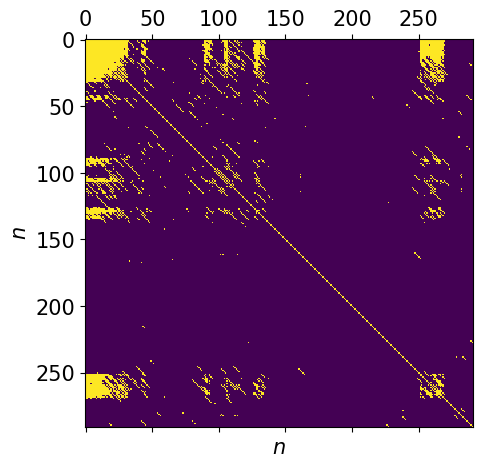

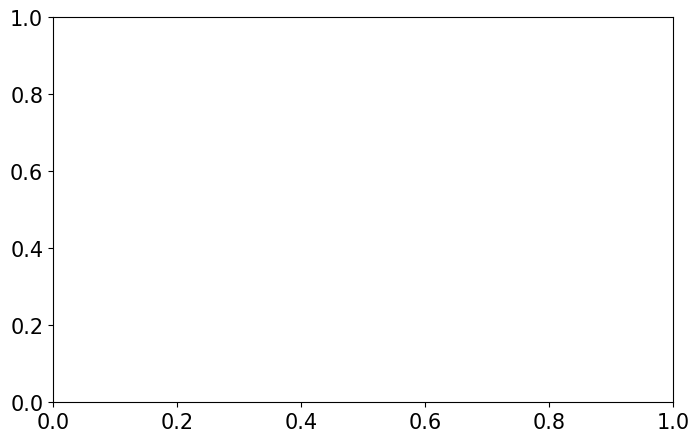

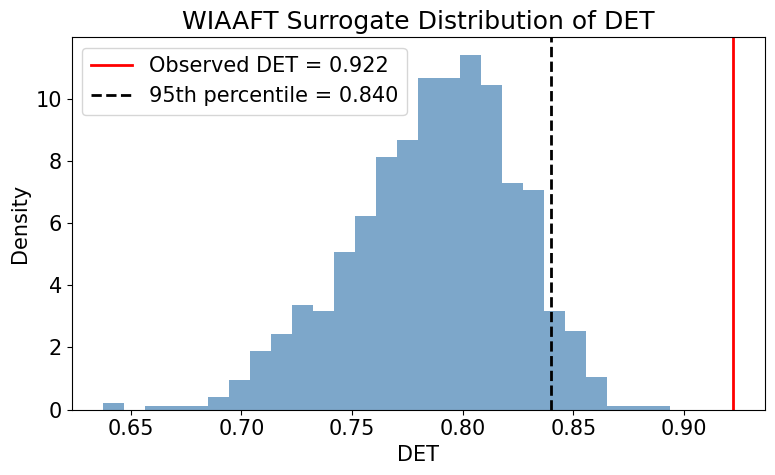

 59%|████████████████████████▊                 | 59/100 [26:39<19:38, 28.74s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9224137931011095 
 Recurrence rate: 0.050011218573233665 
Threshold:2.193800000000205 
 Laminarity:0.6075560802819184 
Shannon Entropy:2.445498469470082 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

56
10
Mean Nearest Neighbor Distance: 1.9468436998930592
Pseudo-periodic surrogates generated successfullly


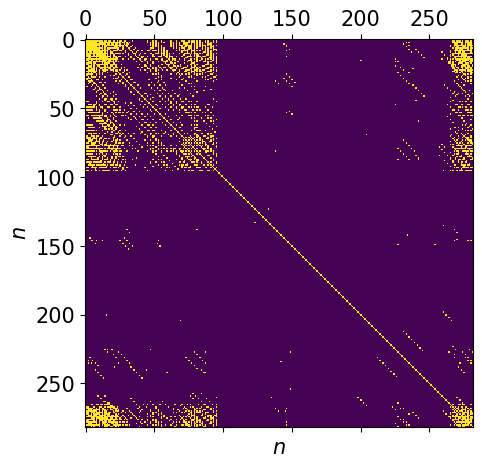

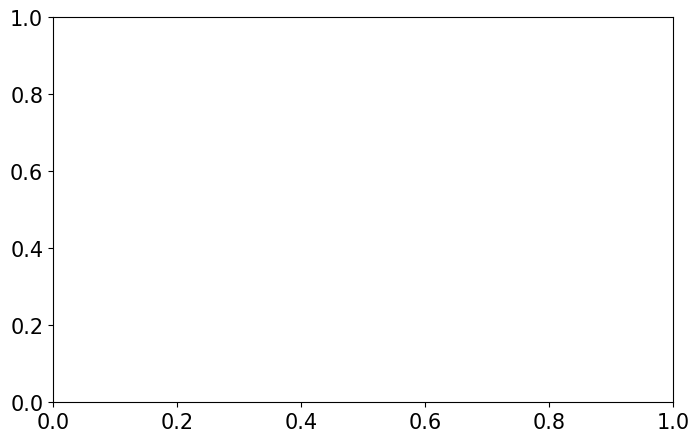

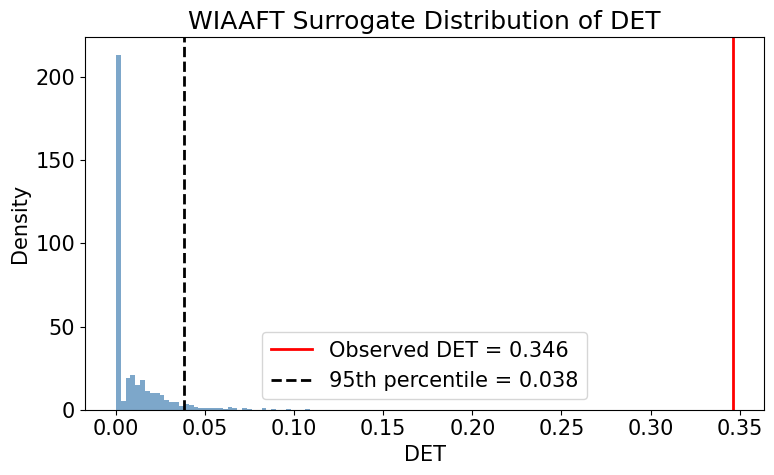

 60%|█████████████████████████▏                | 60/100 [27:06<18:49, 28.24s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.34632034631940933 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9619999999998003 
 Laminarity:0.496480643538219 
Shannon Entropy:2.4410038145578246 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

57
10
Mean Nearest Neighbor Distance: 2.0057923364442187
Pseudo-periodic surrogates generated successfullly


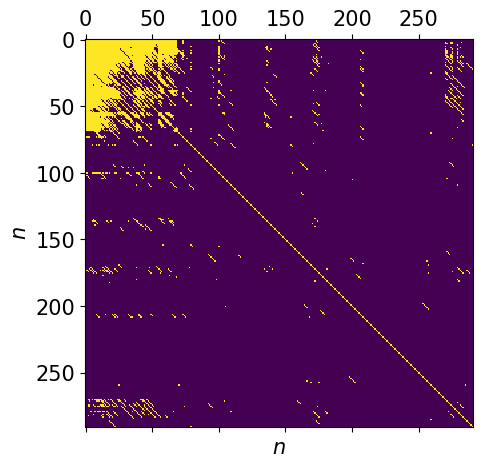

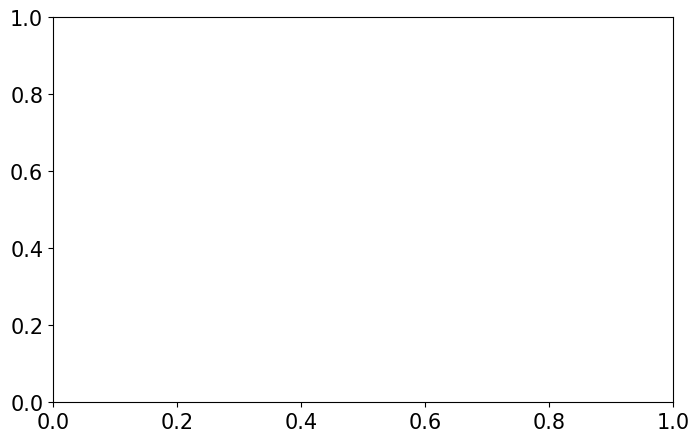

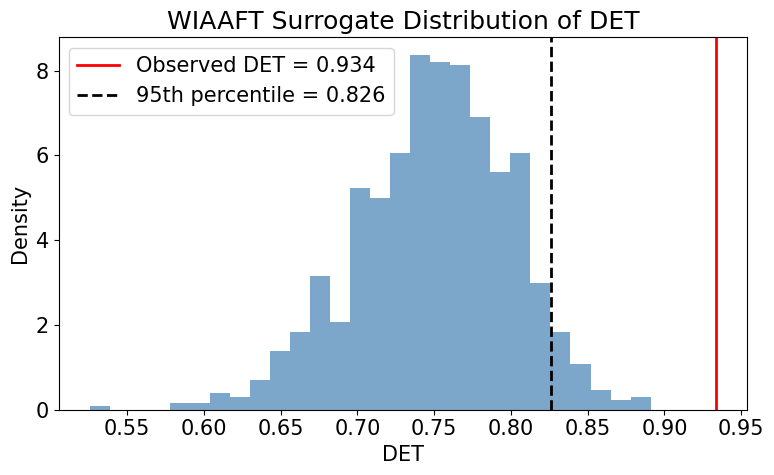

 61%|█████████████████████████▌                | 61/100 [27:35<18:31, 28.50s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9336036492627127 
 Recurrence rate: 0.050034836622146646 
Threshold:1.9947999999997967 
 Laminarity:0.6915270238359889 
Shannon Entropy:2.7435280477032635 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

58
10
Mean Nearest Neighbor Distance: 2.0341252737043565
Pseudo-periodic surrogates generated successfullly


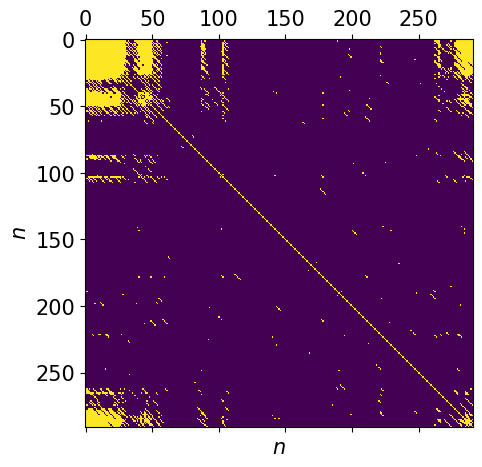

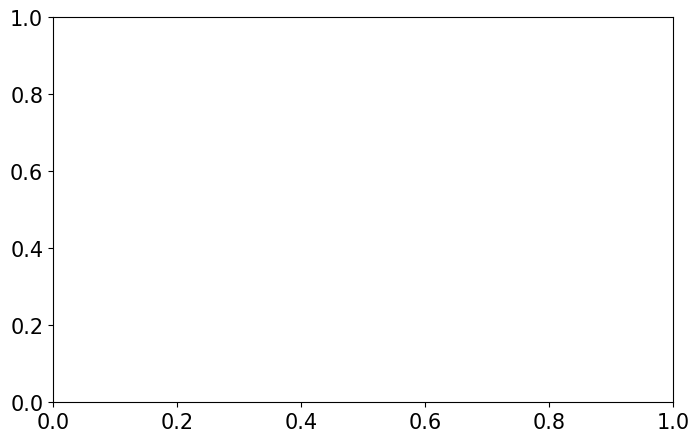

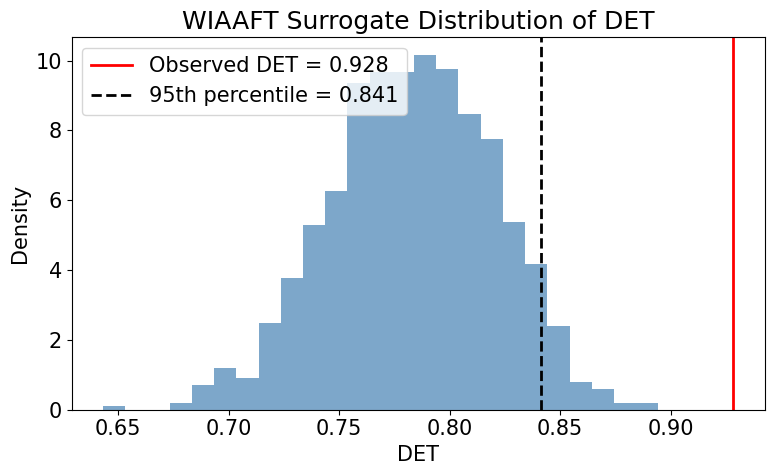

 62%|██████████████████████████                | 62/100 [28:07<18:44, 29.60s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9284989857988628 
 Recurrence rate: 0.050011218573233665 
Threshold:2.249600000000323 
 Laminarity:0.6753246753230807 
Shannon Entropy:2.6053321756523147 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

59
10
Mean Nearest Neighbor Distance: 1.9241904337862836
Pseudo-periodic surrogates generated successfullly


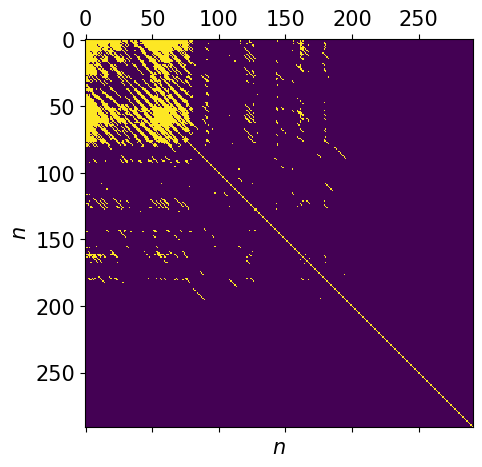

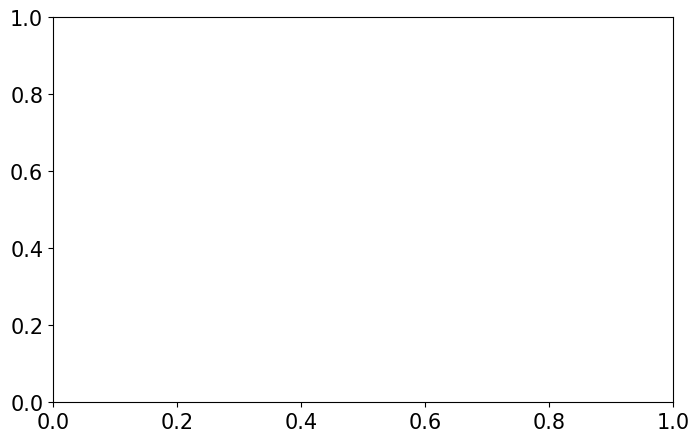

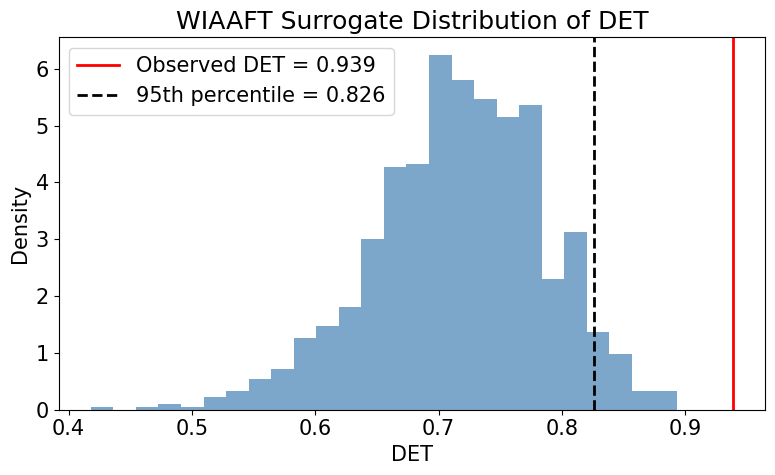

 63%|██████████████████████████▍               | 63/100 [28:34<17:40, 28.65s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9386409736284518 
 Recurrence rate: 0.050011218573233665 
Threshold:1.7498999999998237 
 Laminarity:0.7376623376605959 
Shannon Entropy:2.527631774908235 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

60
9
Mean Nearest Neighbor Distance: 1.8799175688797938
Pseudo-periodic surrogates generated successfullly


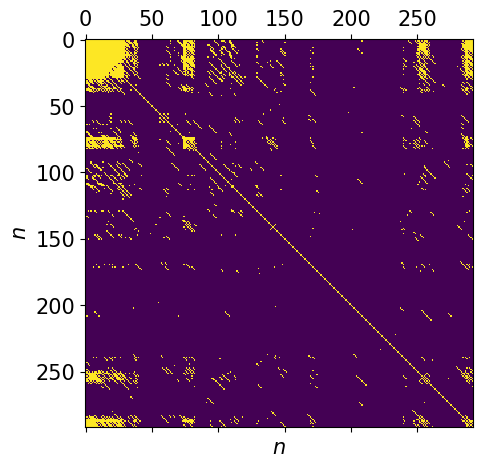

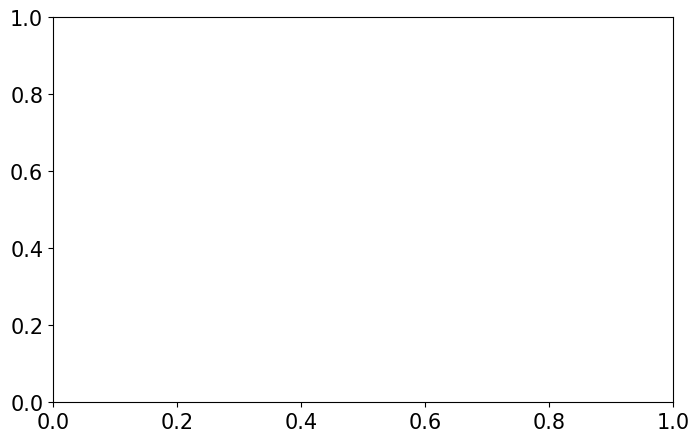

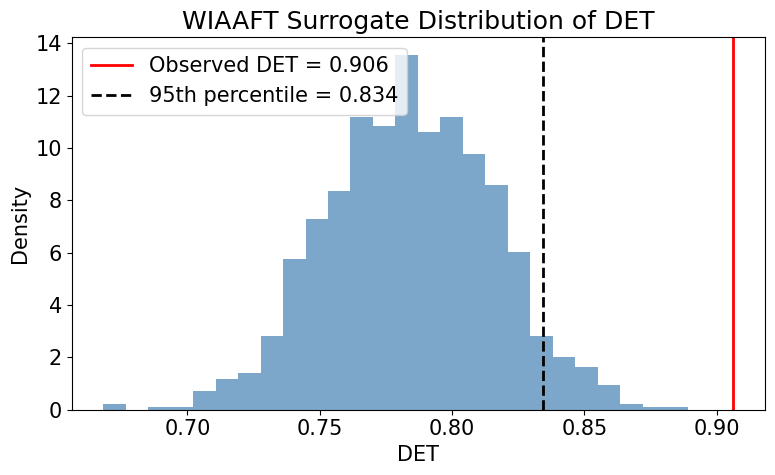

 64%|██████████████████████████▉               | 64/100 [29:04<17:26, 29.08s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9063444108738511 
 Recurrence rate: 0.0500093826233815 
Threshold:2.1551000000001235 
 Laminarity:0.5234521575972715 
Shannon Entropy:2.2391744803841998 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

61
9


Not enough points found!


Mean Nearest Neighbor Distance: 1.8578636982668848
Pseudo-periodic surrogates generated successfullly


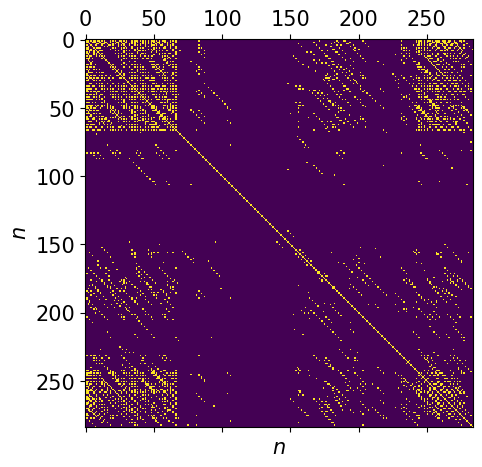

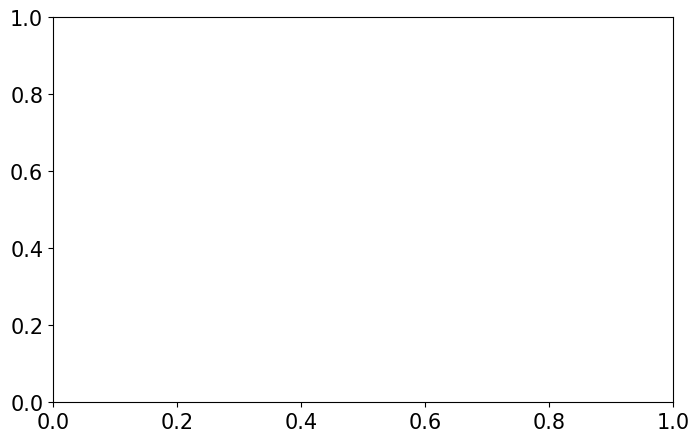

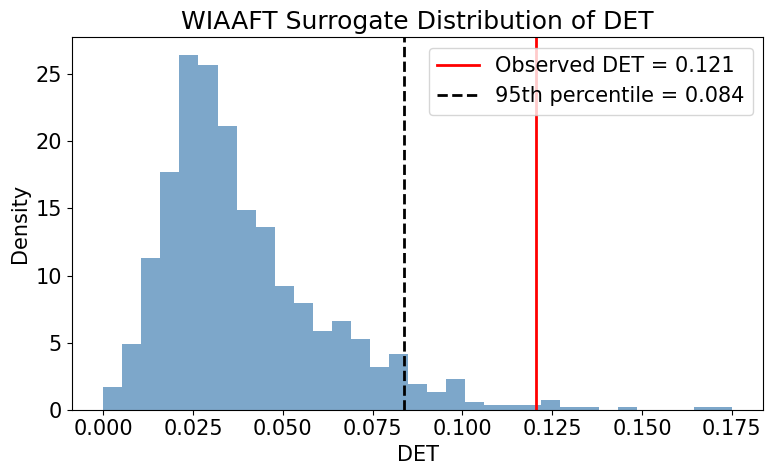

 65%|███████████████████████████▎              | 65/100 [29:34<17:08, 29.38s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.12053333333301192 
 Recurrence rate: 0.050014878000396744 
Threshold:2.228800000000279 
 Laminarity:0.25880019831368667 
Shannon Entropy:1.6580115159199071 
Rank-order p-value (det):0.02 
Reject null (det) hypothesis:True

 
 

62
10
Mean Nearest Neighbor Distance: 2.0599674681944453
Pseudo-periodic surrogates generated successfullly


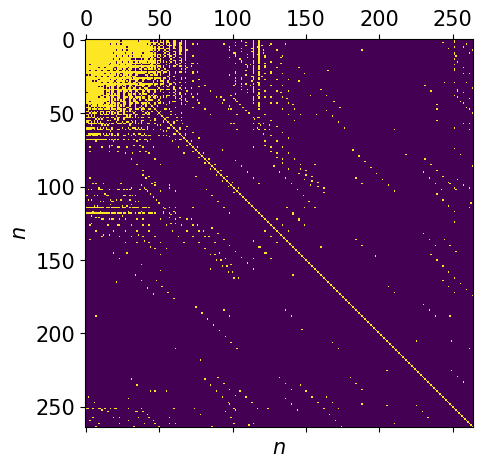

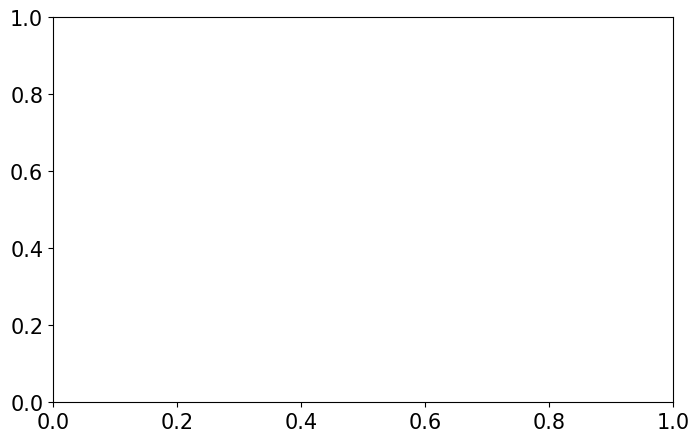

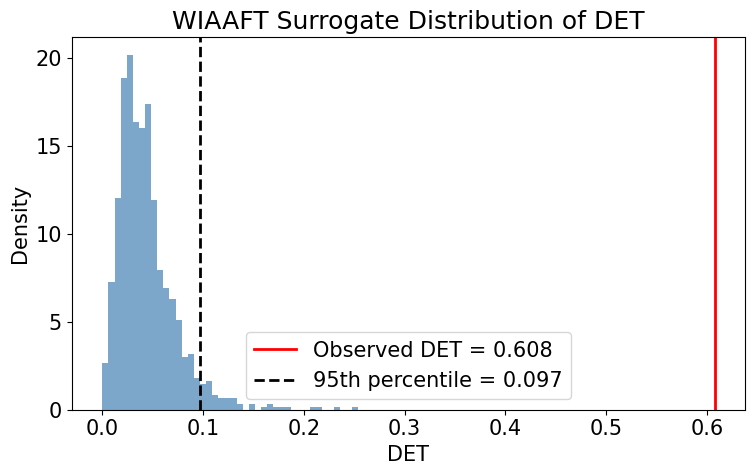

 66%|███████████████████████████▋              | 66/100 [30:03<16:35, 29.29s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.6076970825555317 
 Recurrence rate: 0.050017217630854 
Threshold:2.383300000000605 
 Laminarity:0.5983935742954722 
Shannon Entropy:1.5419215238894528 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

63
10
Mean Nearest Neighbor Distance: 2.0648529224942576
Pseudo-periodic surrogates generated successfullly


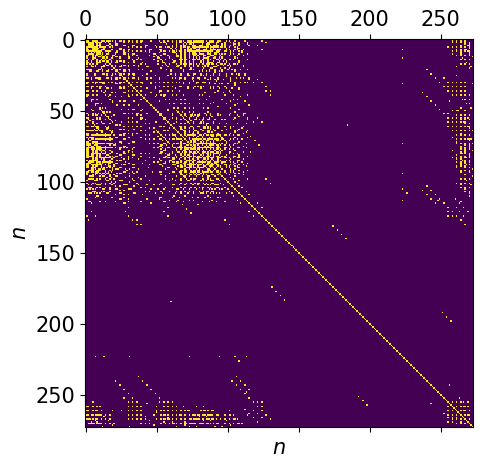

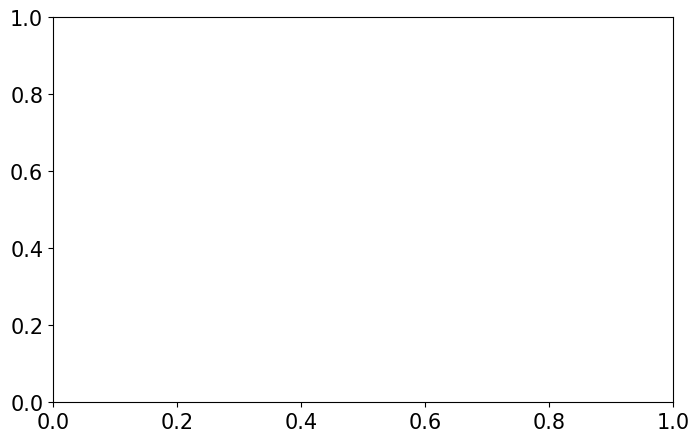

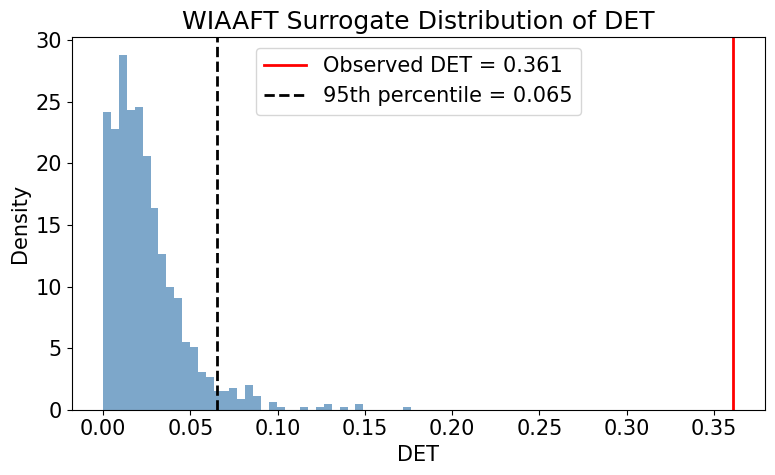

 67%|████████████████████████████▏             | 67/100 [30:31<15:53, 28.89s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.36132020845292034 
 Recurrence rate: 0.050007379677709345 
Threshold:2.179900000000176 
 Laminarity:0.4260799570688863 
Shannon Entropy:0.6583796679221635 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

64
9
Mean Nearest Neighbor Distance: 1.8063027403411978
Pseudo-periodic surrogates generated successfullly


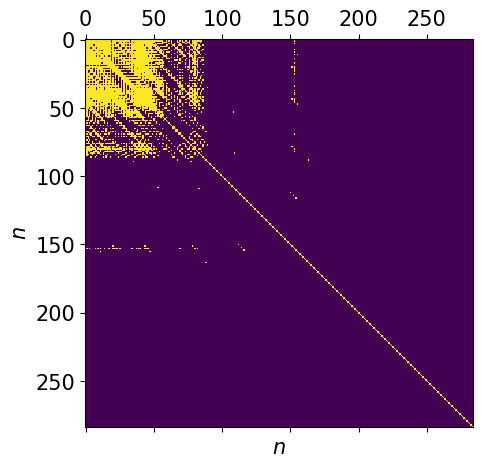

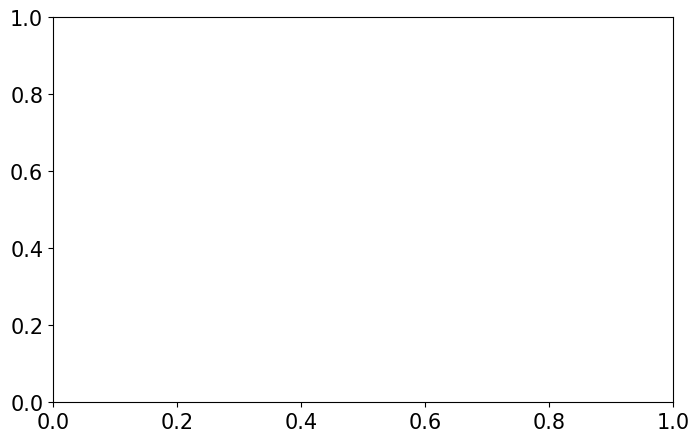

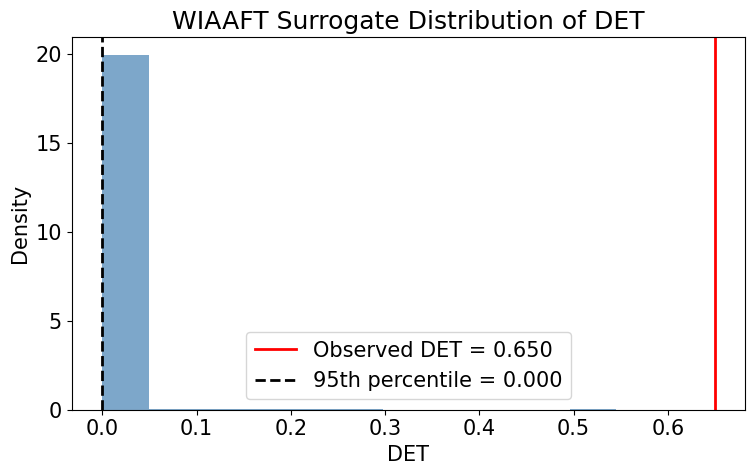

 68%|████████████████████████████▌             | 68/100 [30:49<13:45, 25.79s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.6495999999982678 
 Recurrence rate: 0.050014878000396744 
Threshold:1.1447999999998903 
 Laminarity:0.7491323748122233 
Shannon Entropy:2.8491044850876586 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

65
5


Not enough points found!


Mean Nearest Neighbor Distance: 0.8940753073746995
Pseudo-periodic surrogates generated successfullly


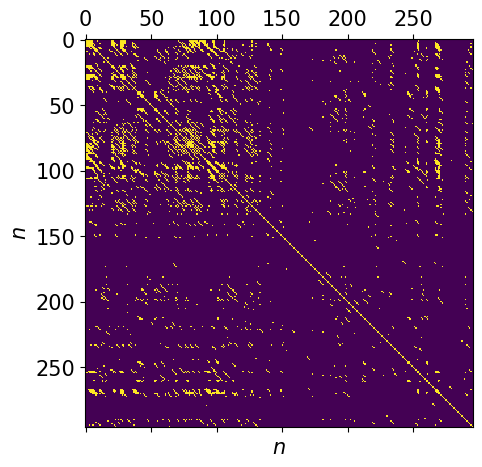

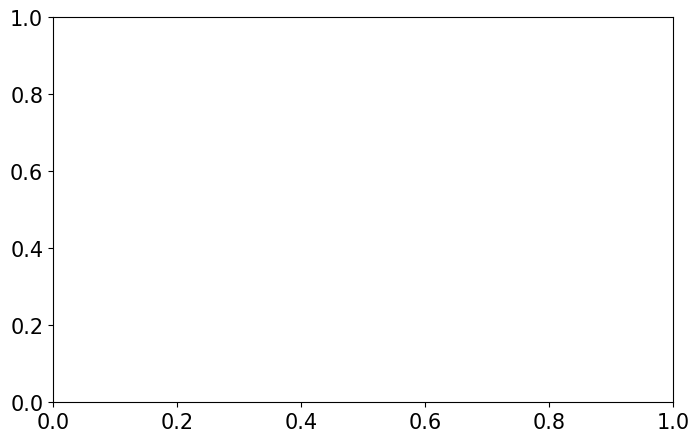

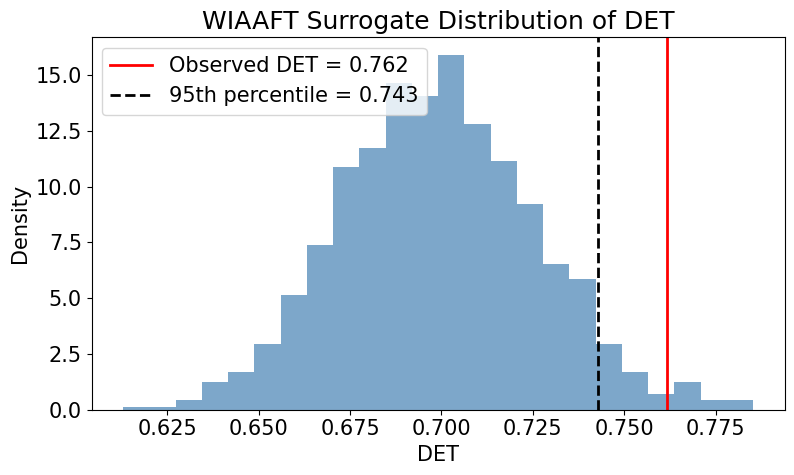

 69%|████████████████████████████▉             | 69/100 [31:09<12:27, 24.11s/it]

RQA  ig Embedding dimensions:5 
 DET of original:0.7616250611826686 
 Recurrence rate: 0.05001369612856099 
Threshold:1.320099999999871 
 Laminarity:0.3425376540384698 
Shannon Entropy:1.4911492913486954 
Rank-order p-value (det):0.032 
Reject null (det) hypothesis:True

 
 

66
10
Mean Nearest Neighbor Distance: 2.077659655172113
Pseudo-periodic surrogates generated successfullly


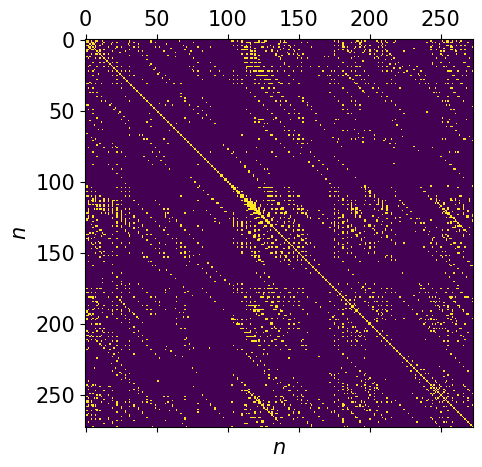

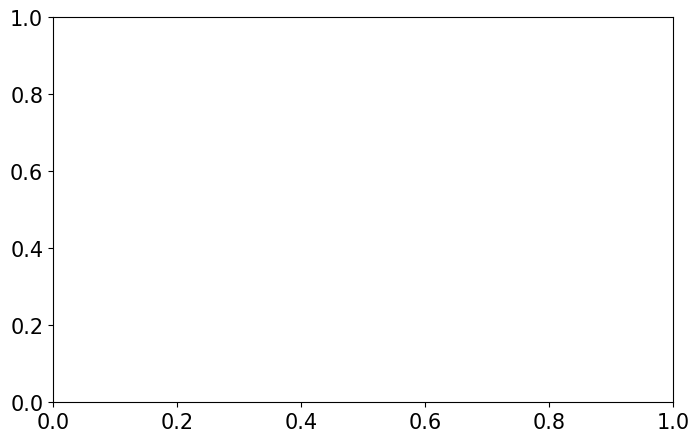

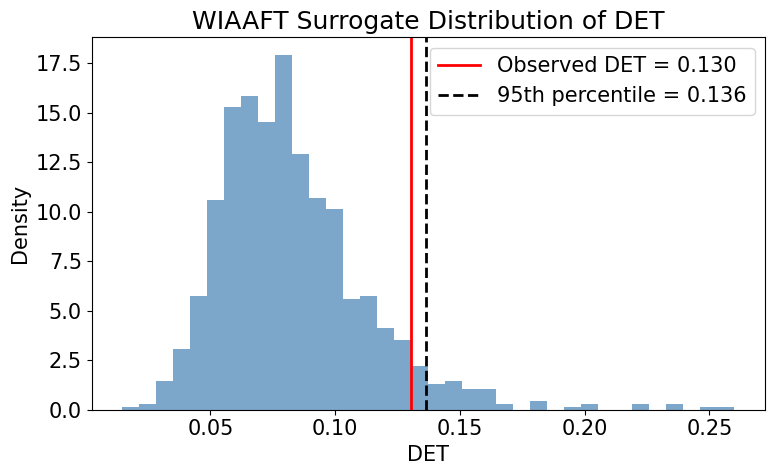

 70%|█████████████████████████████▍            | 70/100 [31:43<13:31, 27.04s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.13028372900946647 
 Recurrence rate: 0.050007379677709345 
Threshold:2.7892000000014616 
 Laminarity:0.23262677756846625 
Shannon Entropy:0.3258772394230109 
Rank-order p-value (det):0.128 
Reject null (det) hypothesis:False

 
 

66
8


Not enough points found!


Mean Nearest Neighbor Distance: 1.6318563329069642
Pseudo-periodic surrogates generated successfullly


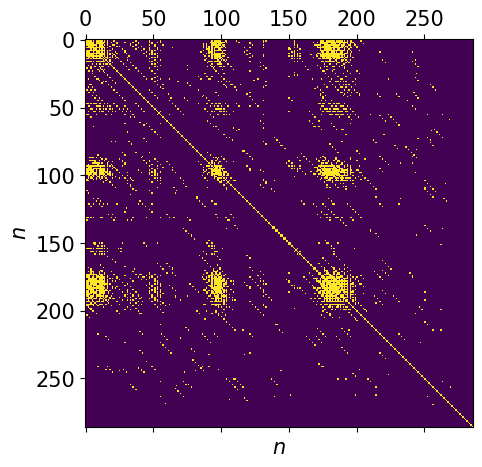

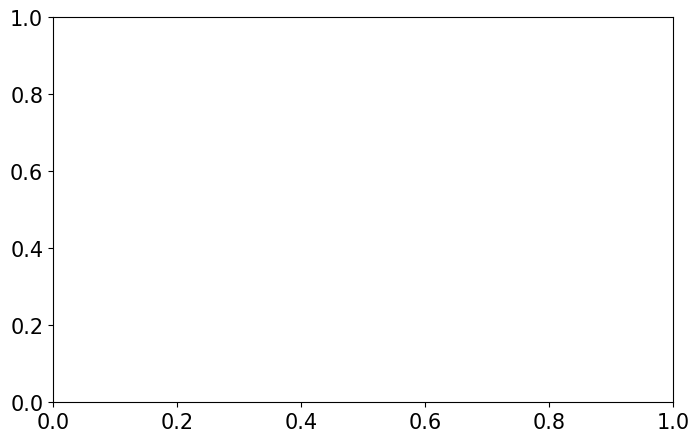

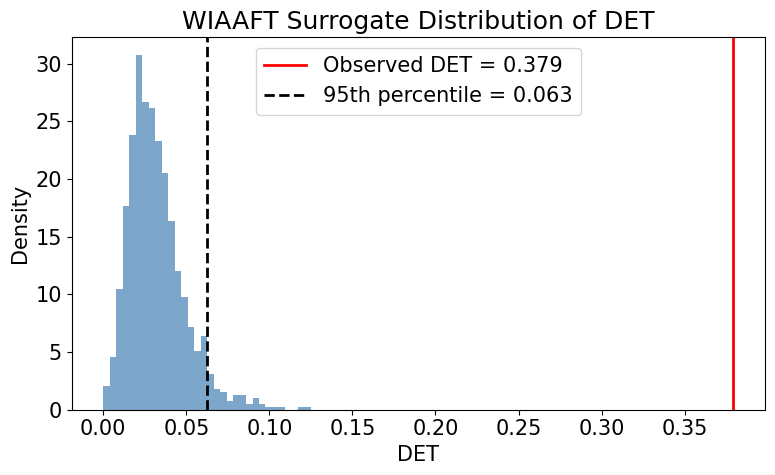

 71%|█████████████████████████████▊            | 71/100 [32:11<13:11, 27.31s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.37940094587393747 
 Recurrence rate: 0.05002689618074233 
Threshold:2.0895999999999852 
 Laminarity:0.4843597262940265 
Shannon Entropy:2.373608895959 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

67
10
Mean Nearest Neighbor Distance: 2.084946316872761
Pseudo-periodic surrogates generated successfullly


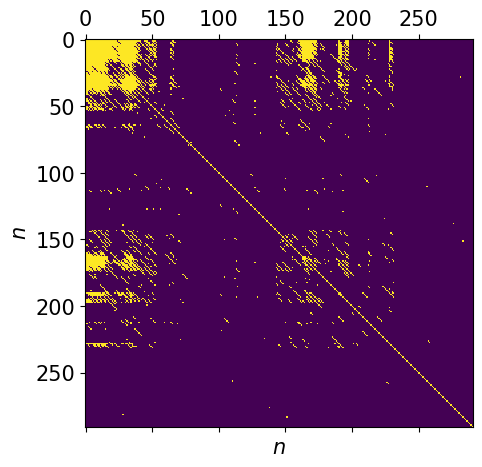

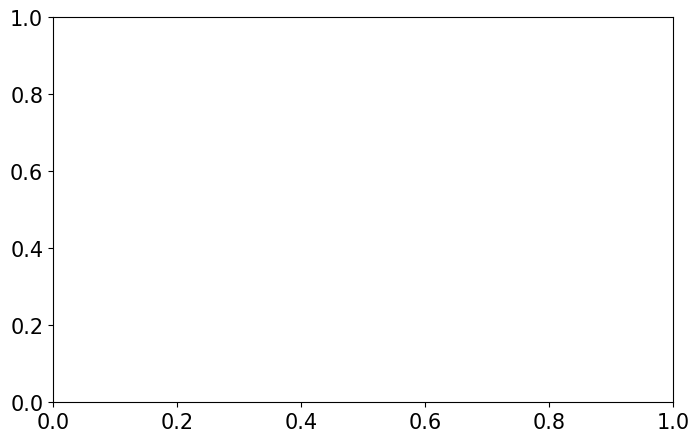

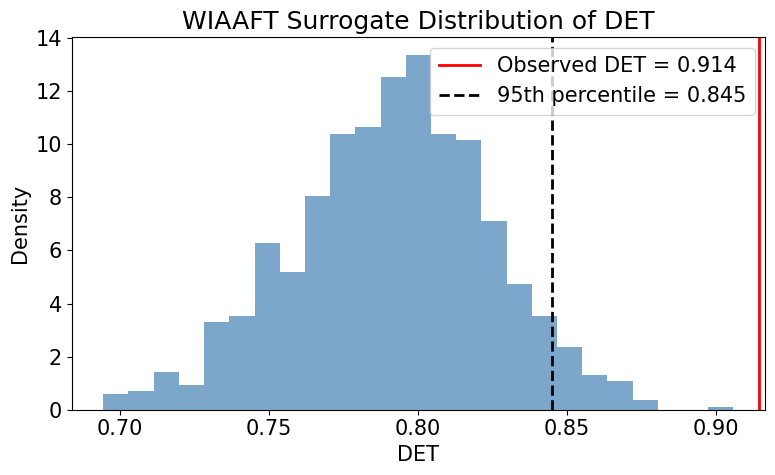

 72%|██████████████████████████████▏           | 72/100 [32:43<13:25, 28.78s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.914387031405992 
 Recurrence rate: 0.05005845467105963 
Threshold:2.323100000000478 
 Laminarity:0.5546119367762335 
Shannon Entropy:2.3675898670441153 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

68
7
Mean Nearest Neighbor Distance: 1.4204873697836429
Pseudo-periodic surrogates generated successfullly


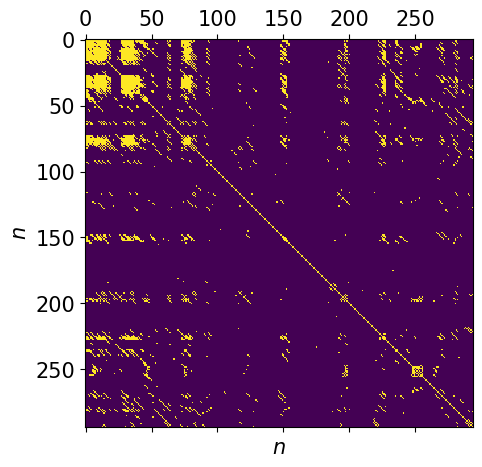

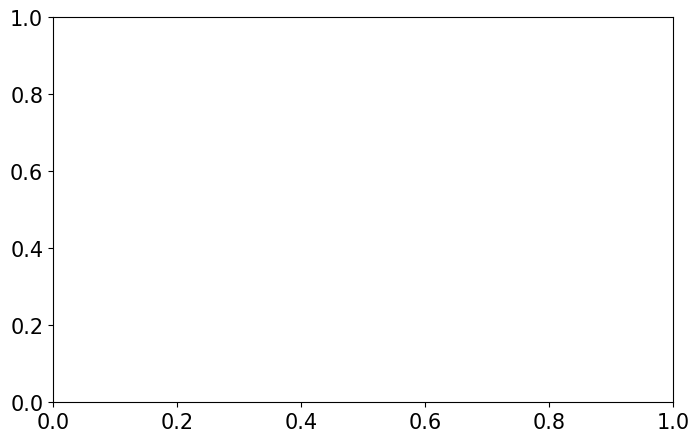

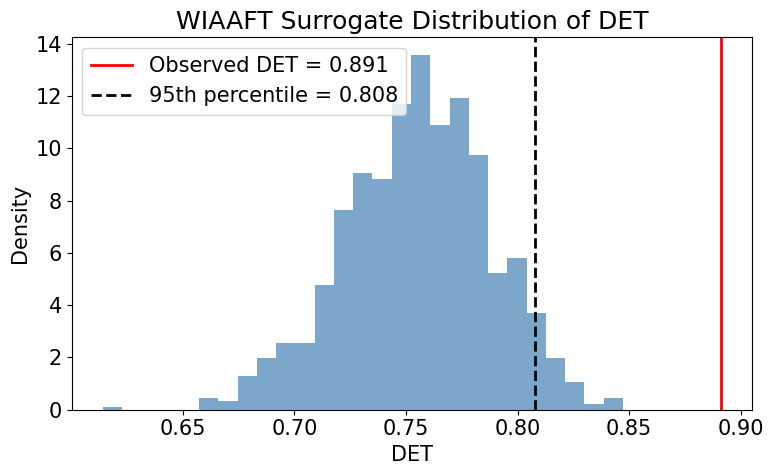

 73%|██████████████████████████████▋           | 73/100 [33:08<12:19, 27.40s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8912611717952055 
 Recurrence rate: 0.05000231385071035 
Threshold:1.6806999999998313 
 Laminarity:0.5120314669122813 
Shannon Entropy:1.941273330246954 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

69
7
Mean Nearest Neighbor Distance: 1.4070071573432135
Pseudo-periodic surrogates generated successfullly


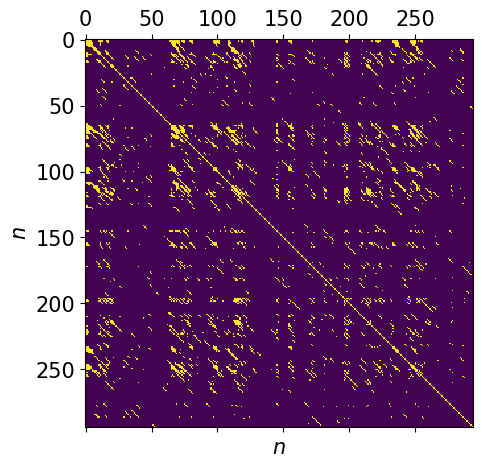

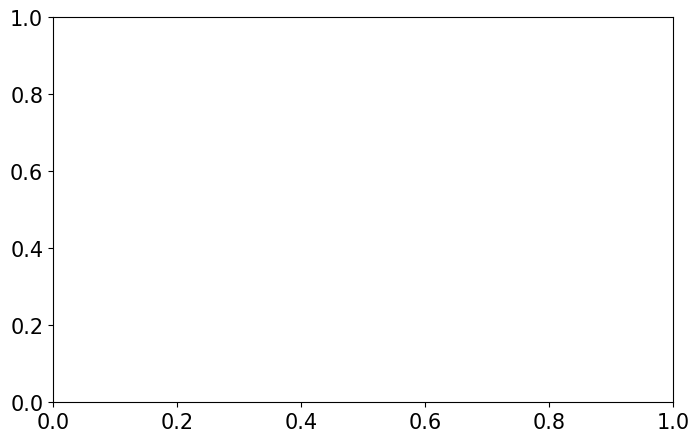

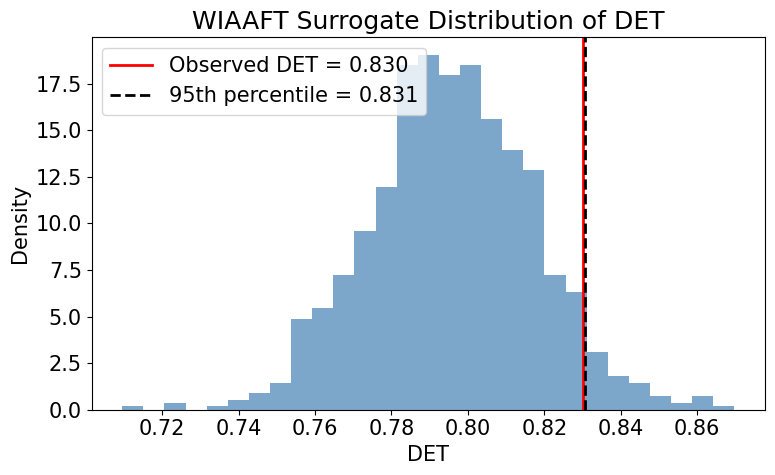

 74%|███████████████████████████████           | 74/100 [33:36<11:57, 27.60s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.830188679243222 
 Recurrence rate: 0.05000231385071035 
Threshold:2.010299999999818 
 Laminarity:0.3831559463202611 
Shannon Entropy:1.625061835334437 
Rank-order p-value (det):0.106 
Reject null (det) hypothesis:False

 
 

69
9
Mean Nearest Neighbor Distance: 1.8852855815320828
Pseudo-periodic surrogates generated successfullly


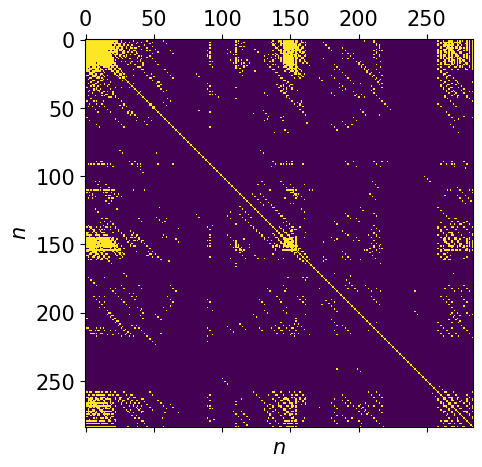

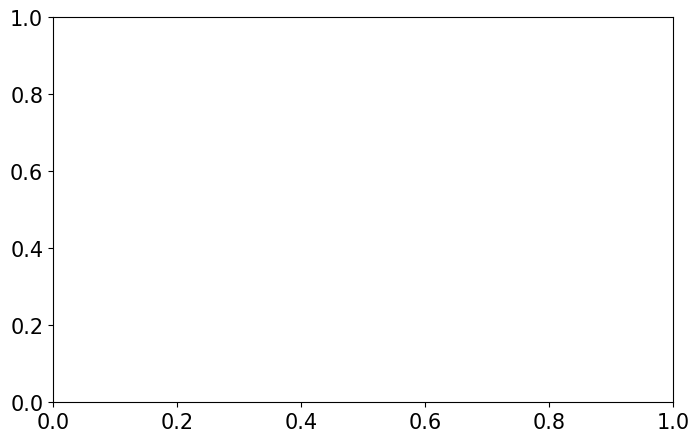

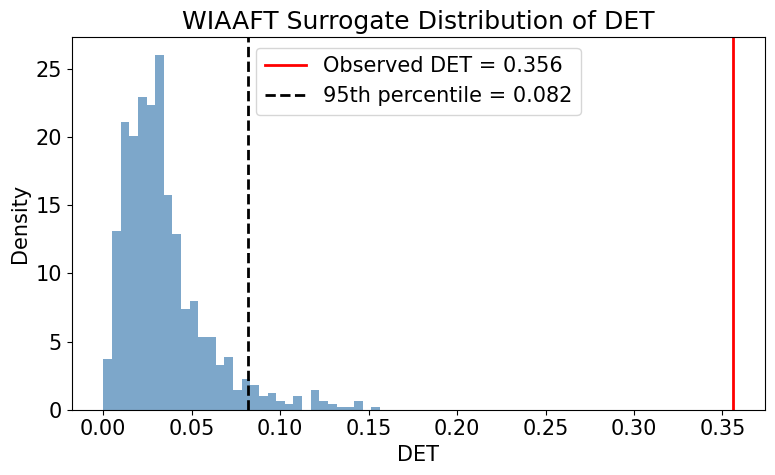

 75%|███████████████████████████████▌          | 75/100 [34:05<11:41, 28.06s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.35626666666571666 
 Recurrence rate: 0.050014878000396744 
Threshold:2.1736000000001625 
 Laminarity:0.4826474962804099 
Shannon Entropy:2.4897563544263437 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

70
7


Not enough points found!


Mean Nearest Neighbor Distance: 1.358040139331509
Pseudo-periodic surrogates generated successfullly


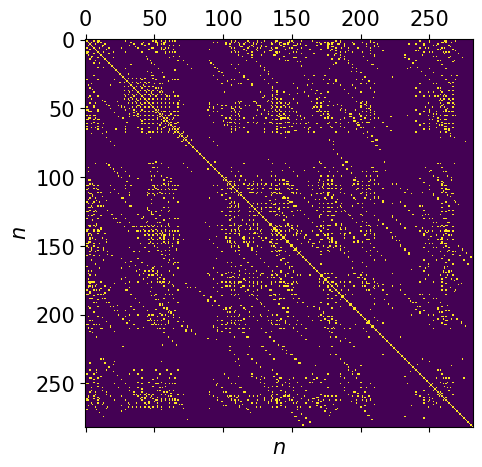

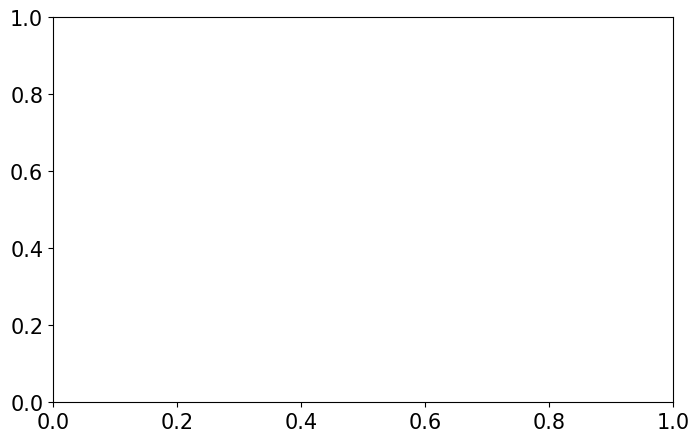

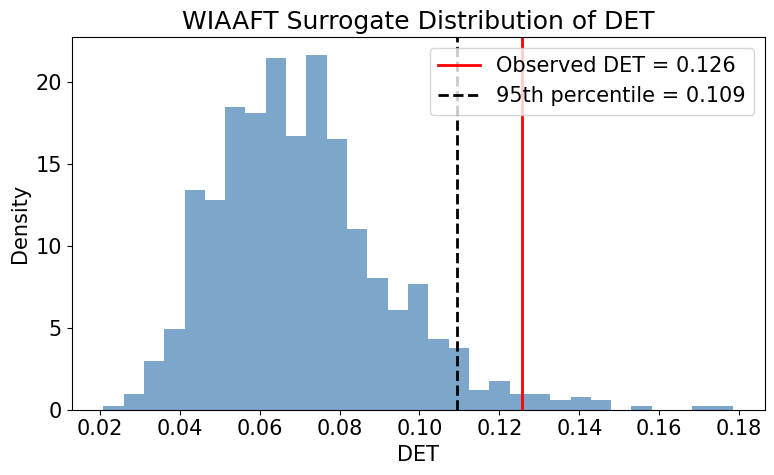

 76%|███████████████████████████████▉          | 76/100 [34:31<11:00, 27.54s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.12554112554078586 
 Recurrence rate: 0.05002263467632413 
Threshold:1.9656999999998 
 Laminarity:0.15108094519821247 
Shannon Entropy:0.04991801434392776 
Rank-order p-value (det):0.044 
Reject null (det) hypothesis:True

 
 

71
9
Mean Nearest Neighbor Distance: 1.8770676966744424
Pseudo-periodic surrogates generated successfullly


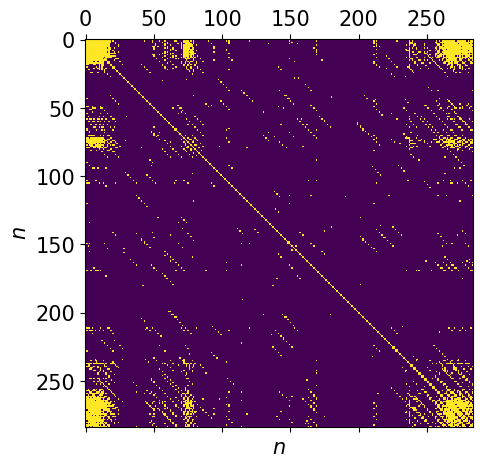

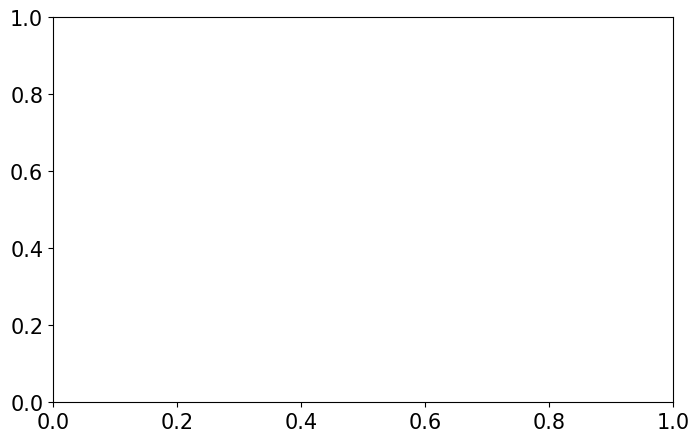

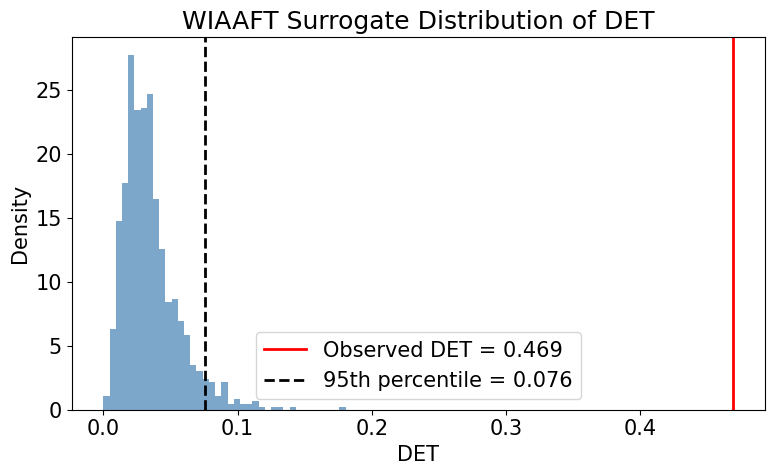

 77%|████████████████████████████████▎         | 77/100 [35:03<11:03, 28.85s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.46933333333208177 
 Recurrence rate: 0.050014878000396744 
Threshold:2.321600000000475 
 Laminarity:0.5632126921156093 
Shannon Entropy:2.5713515186012406 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

72
10
Mean Nearest Neighbor Distance: 1.9693039272524684
Pseudo-periodic surrogates generated successfullly


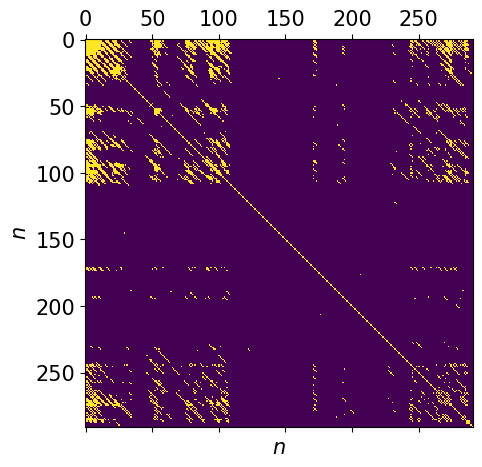

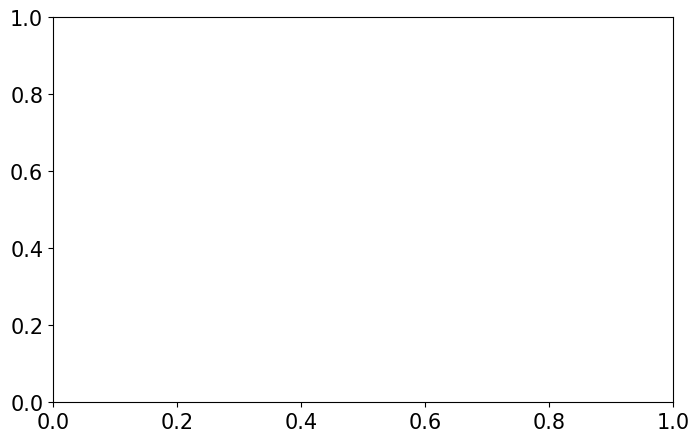

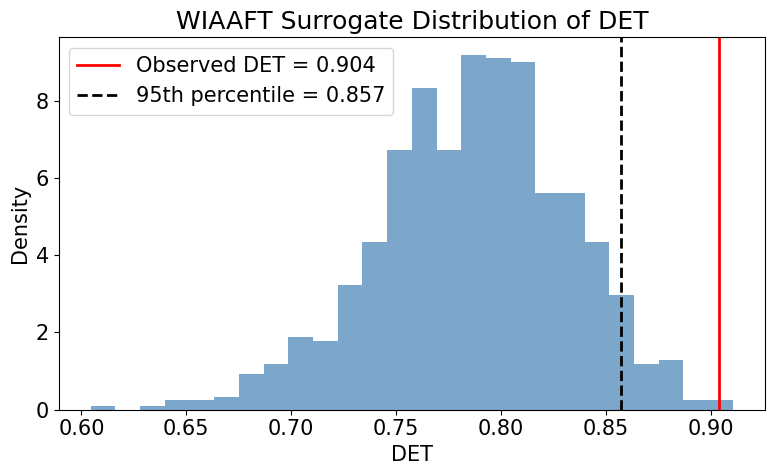

 78%|████████████████████████████████▊         | 78/100 [35:32<10:37, 28.98s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9036999493134726 
 Recurrence rate: 0.050034836622146646 
Threshold:2.0028999999998023 
 Laminarity:0.5057823932015441 
Shannon Entropy:2.1403039406925117 
Rank-order p-value (det):0.006 
Reject null (det) hypothesis:True

 
 

73
9


Not enough points found!


Mean Nearest Neighbor Distance: 1.8088790585384416
Pseudo-periodic surrogates generated successfullly


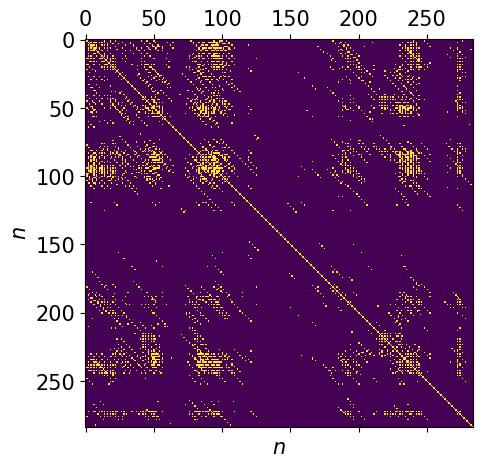

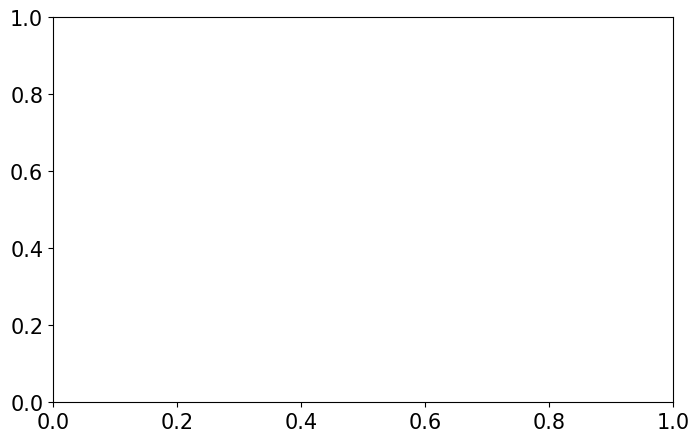

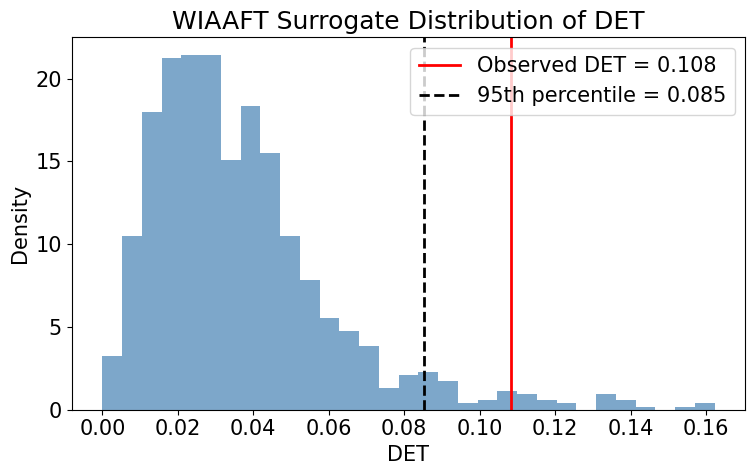

 79%|█████████████████████████████████▏        | 79/100 [36:02<10:11, 29.14s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.1082089552235922 
 Recurrence rate: 0.05003967466772466 
Threshold:2.2054000000002296 
 Laminarity:0.2195242814662549 
Shannon Entropy:1.5949399159822746 
Rank-order p-value (det):0.05 
Reject null (det) hypothesis:False

 
 

73
6


Not enough points found!


Mean Nearest Neighbor Distance: 1.1366617551340017
Pseudo-periodic surrogates generated successfullly


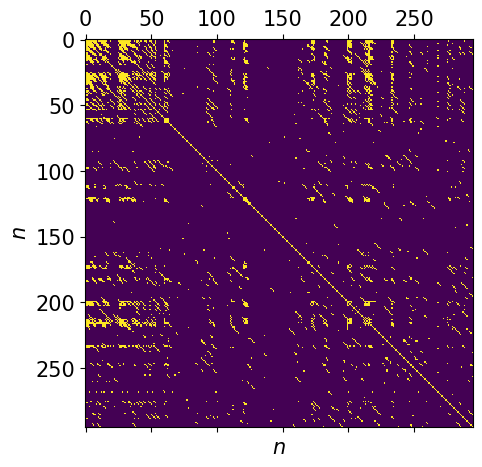

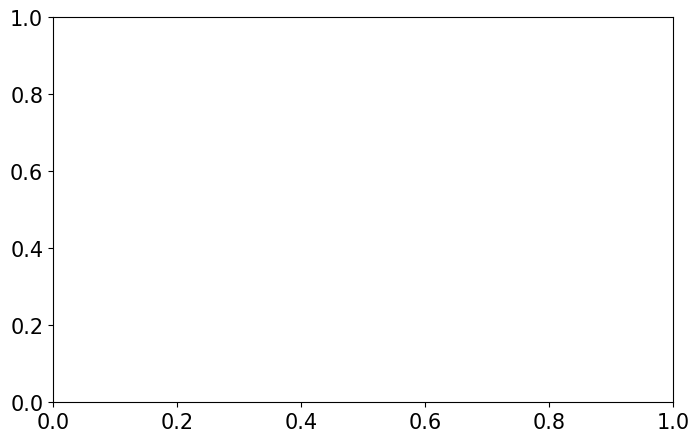

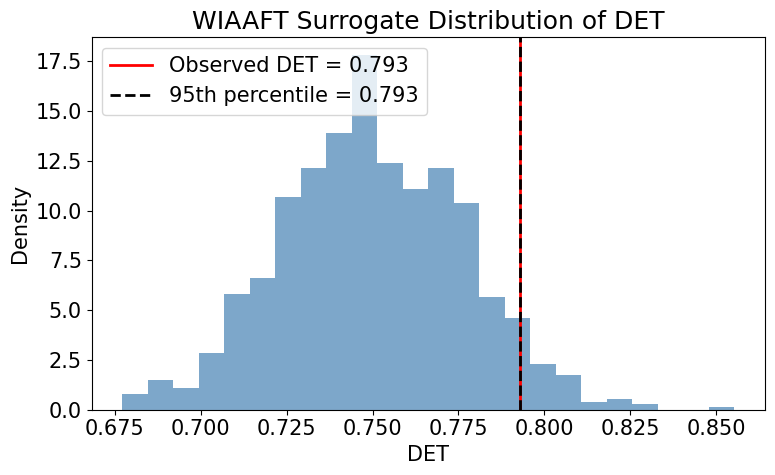

 80%|█████████████████████████████████▌        | 80/100 [36:25<09:05, 27.27s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.7930014785589132 
 Recurrence rate: 0.05002010916403332 
Threshold:1.6552999999998341 
 Laminarity:0.42430507695744474 
Shannon Entropy:1.5696967327479951 
Rank-order p-value (det):0.1 
Reject null (det) hypothesis:False

 
 

73
10
Mean Nearest Neighbor Distance: 1.9159012268909512
Pseudo-periodic surrogates generated successfullly


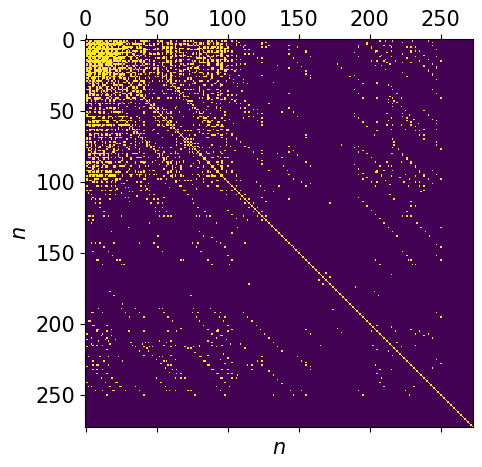

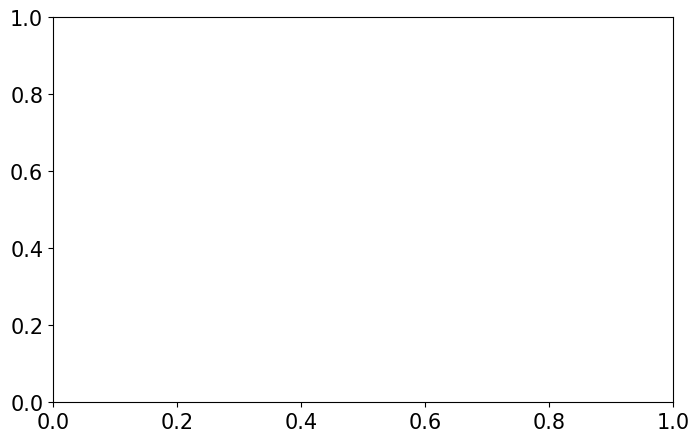

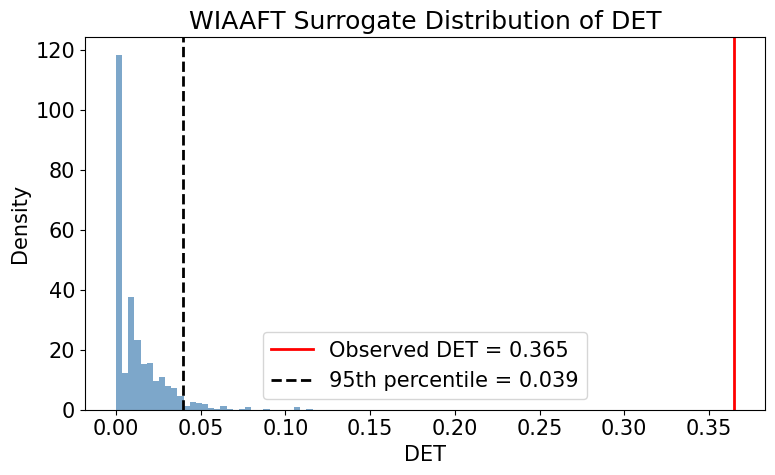

 81%|██████████████████████████████████        | 81/100 [36:52<08:36, 27.20s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.3647944412265061 
 Recurrence rate: 0.050007379677709345 
Threshold:2.117400000000044 
 Laminarity:0.44539844378737486 
Shannon Entropy:0.5420874251680946 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

74
6
Mean Nearest Neighbor Distance: 1.13432385776917
Pseudo-periodic surrogates generated successfullly


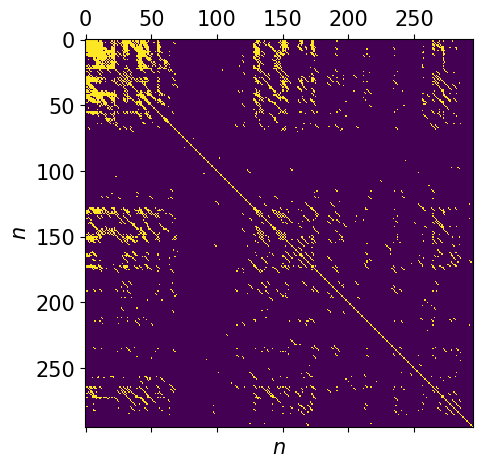

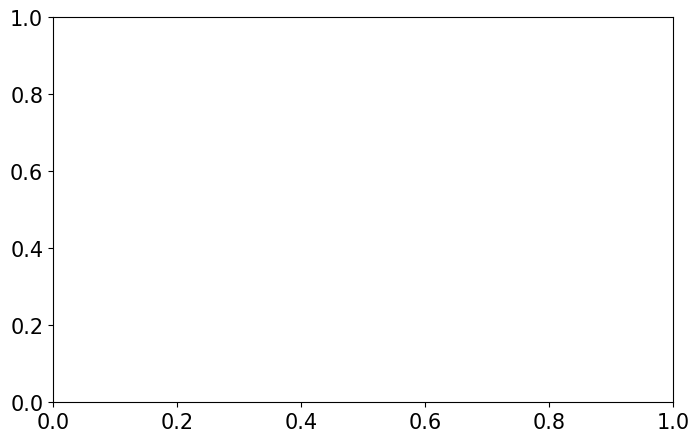

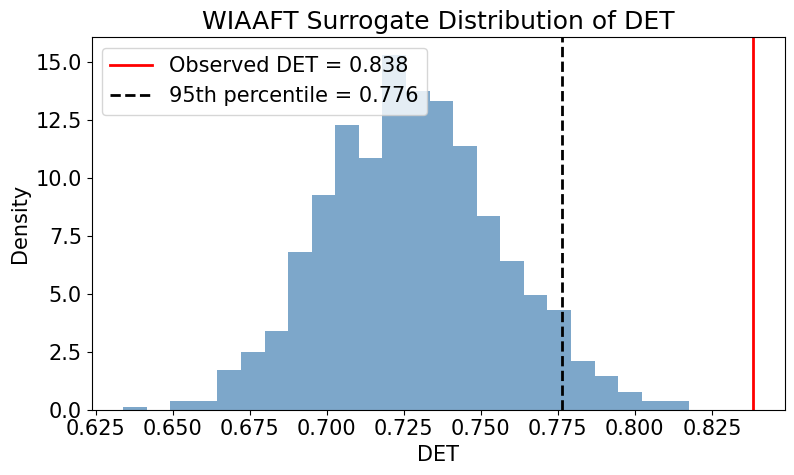

 82%|██████████████████████████████████▍       | 82/100 [37:15<07:48, 26.03s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.838423645318132 
 Recurrence rate: 0.050043091065785694 
Threshold:1.5370999999998471 
 Laminarity:0.45350172215739726 
Shannon Entropy:1.826818958725913 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

75
10
Mean Nearest Neighbor Distance: 2.1222756694833493
Pseudo-periodic surrogates generated successfullly


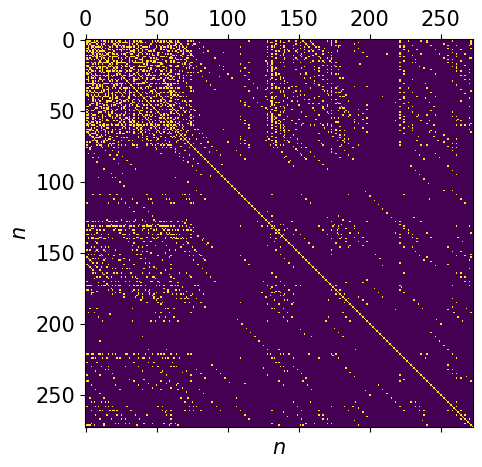

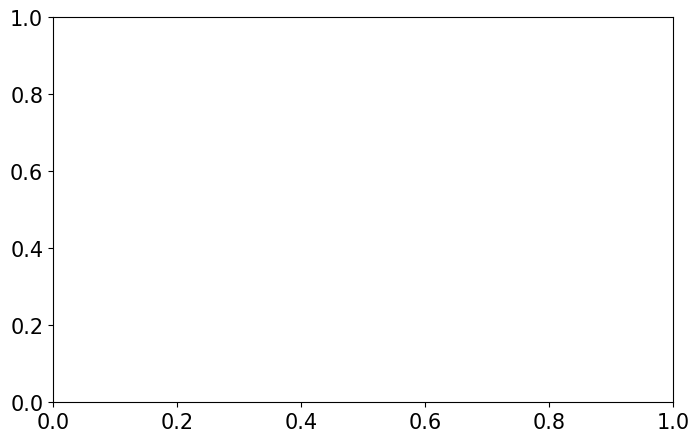

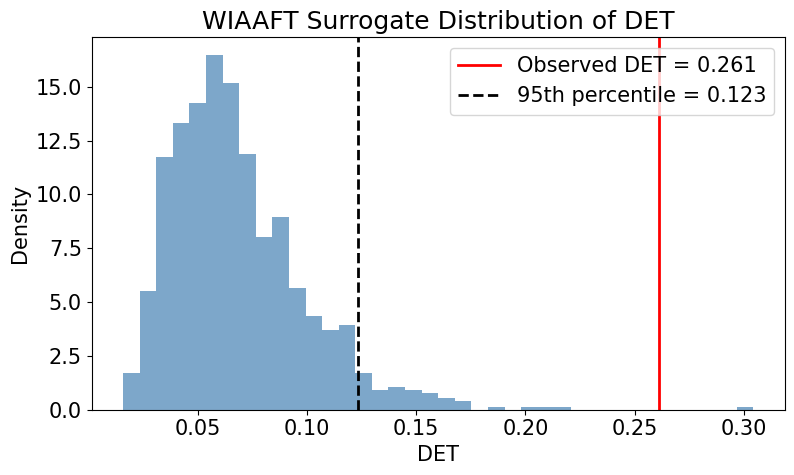

 83%|██████████████████████████████████▊       | 83/100 [37:49<08:00, 28.28s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.2609953703696152 
 Recurrence rate: 0.05003421486937971 
Threshold:2.6404000000011476 
 Laminarity:0.2000536336814158 
Shannon Entropy:0.4674638974196791 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

76
8
Mean Nearest Neighbor Distance: 1.643828836899685
Pseudo-periodic surrogates generated successfullly


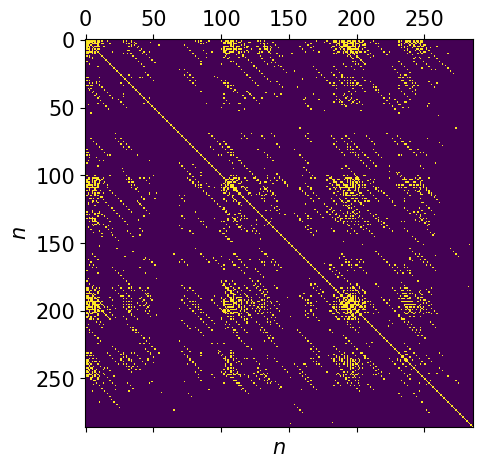

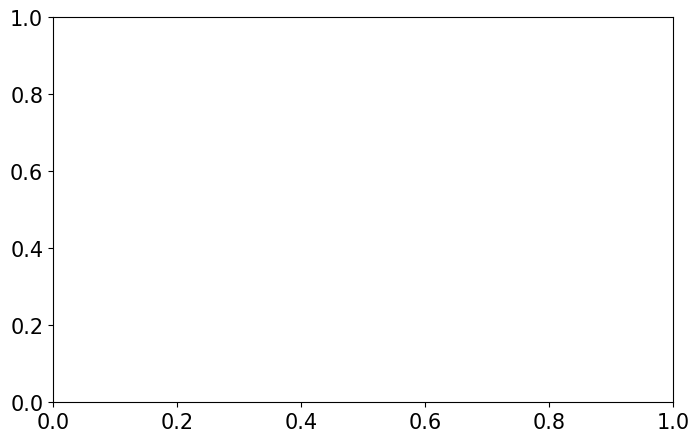

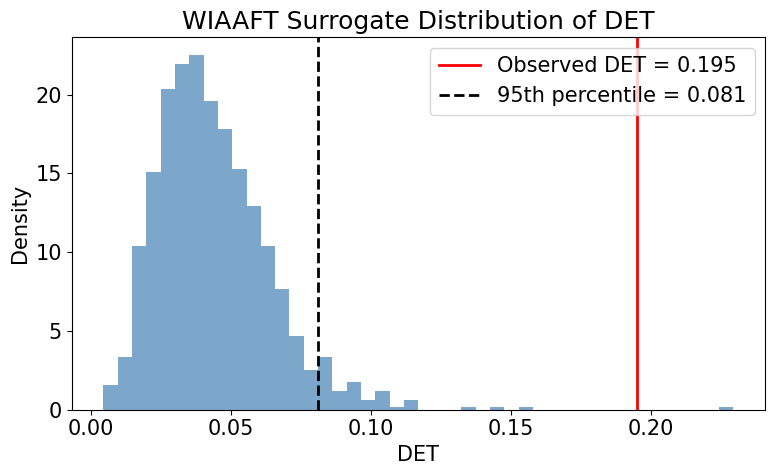

 84%|███████████████████████████████████▎      | 84/100 [38:18<07:39, 28.69s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.1950578338585829 
 Recurrence rate: 0.05000244510734021 
Threshold:2.1693000000001534 
 Laminarity:0.2929095354516066 
Shannon Entropy:1.7417022290515718 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

77
10
Mean Nearest Neighbor Distance: 1.8268190137775215
Pseudo-periodic surrogates generated successfullly


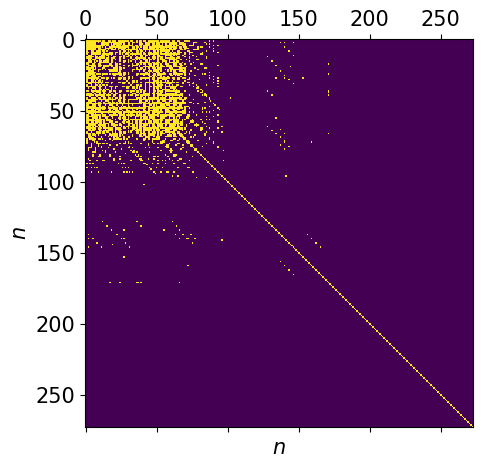

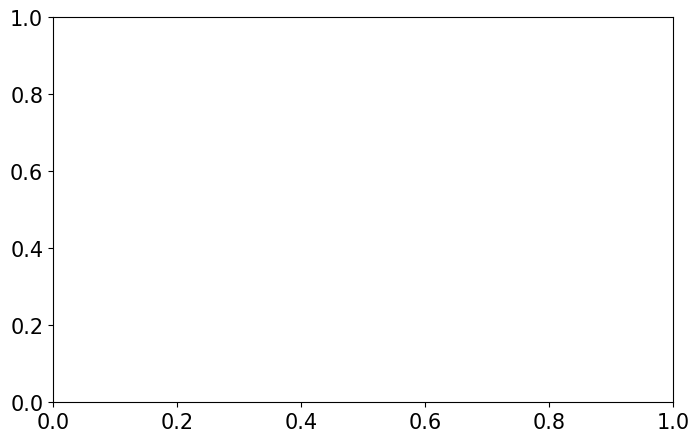

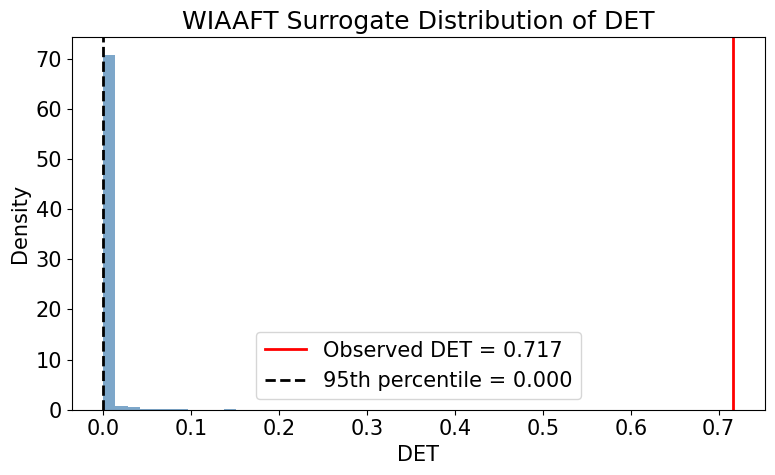

 85%|███████████████████████████████████▋      | 85/100 [38:38<06:28, 25.87s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.7168500289498644 
 Recurrence rate: 0.050007379677709345 
Threshold:1.2128999999998828 
 Laminarity:0.7512744834967768 
Shannon Entropy:1.0672837866756335 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

78
7
Mean Nearest Neighbor Distance: 1.4267945476847517
Pseudo-periodic surrogates generated successfullly


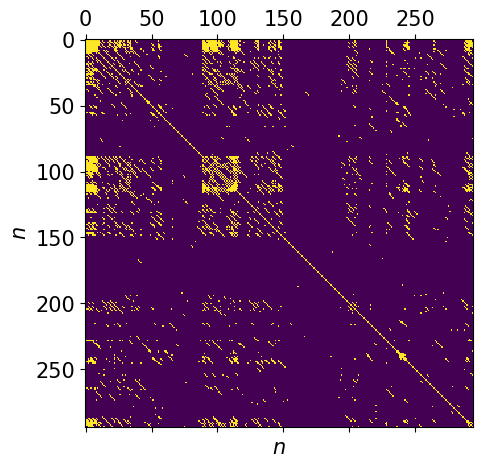

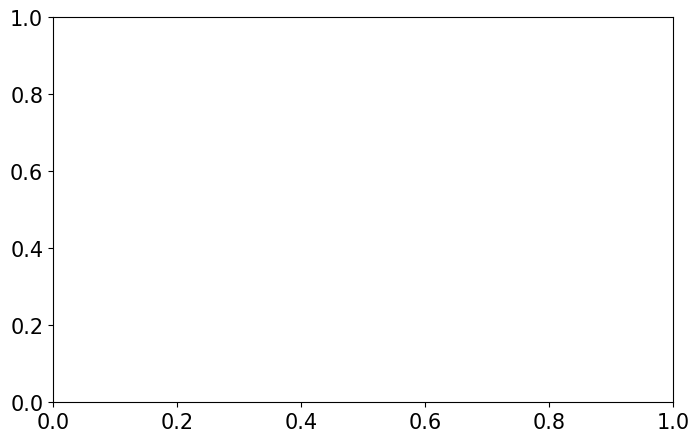

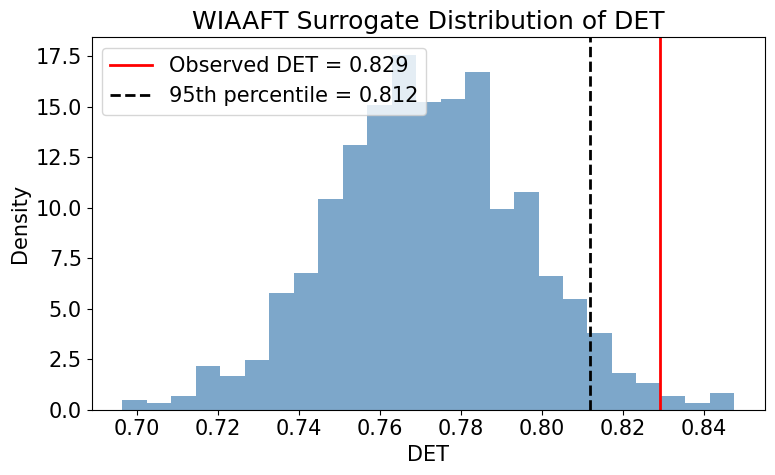

 86%|████████████████████████████████████      | 86/100 [39:05<06:06, 26.21s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.8291956305838402 
 Recurrence rate: 0.05000231385071035 
Threshold:1.8773999999998097 
 Laminarity:0.3322535863018689 
Shannon Entropy:1.8039666683292699 
Rank-order p-value (det):0.024 
Reject null (det) hypothesis:True

 
 

79
9
Mean Nearest Neighbor Distance: 1.8102650599690107
Pseudo-periodic surrogates generated successfullly


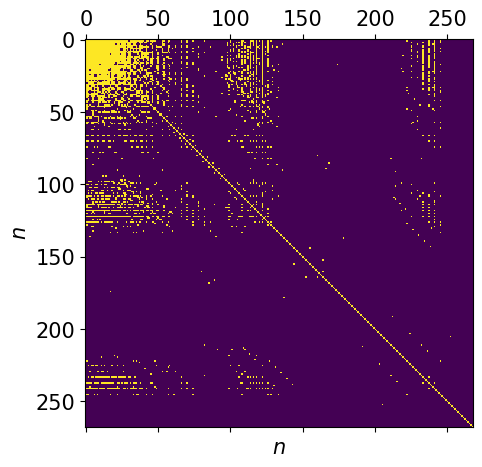

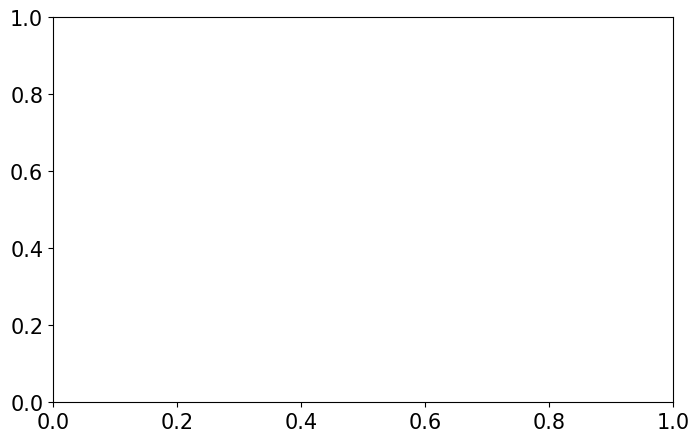

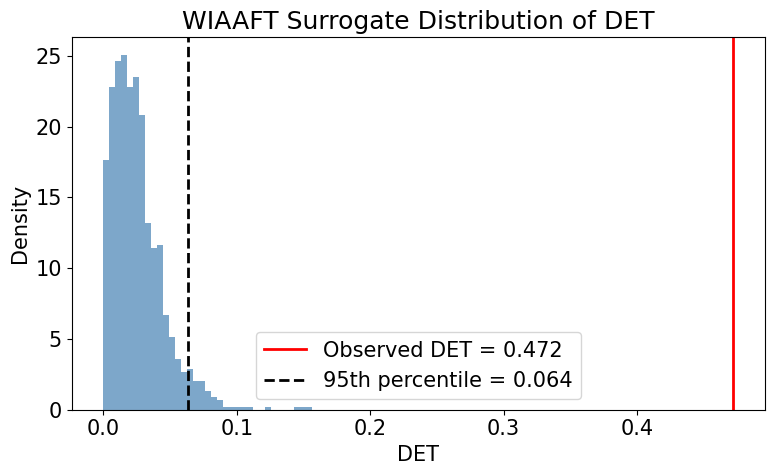

 87%|████████████████████████████████████▌     | 87/100 [39:31<05:39, 26.12s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.4723225030070027 
 Recurrence rate: 0.05001113833815995 
Threshold:2.0390999999998787 
 Laminarity:0.5545657015574762 
Shannon Entropy:1.2687783813599003 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

80
9
Mean Nearest Neighbor Distance: 1.8487927274305198
Pseudo-periodic surrogates generated successfullly


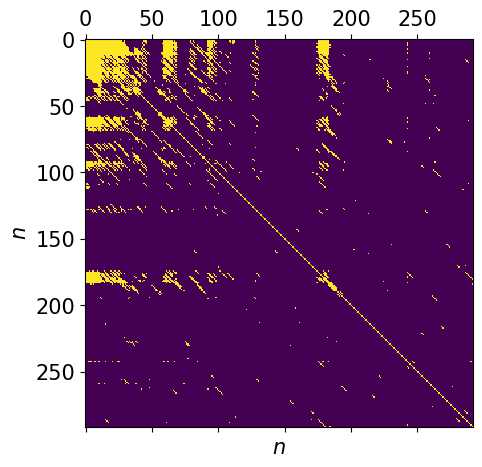

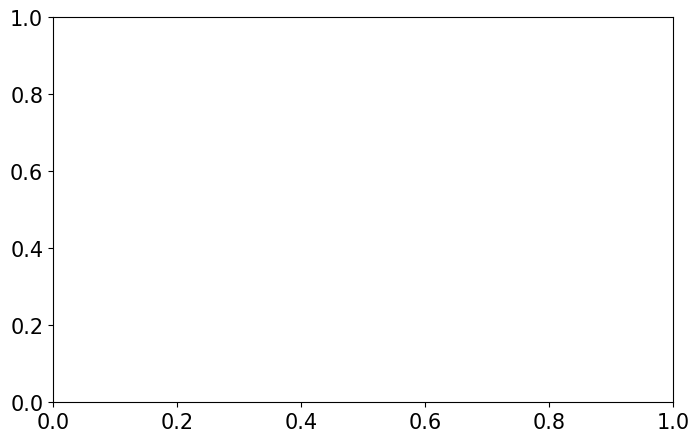

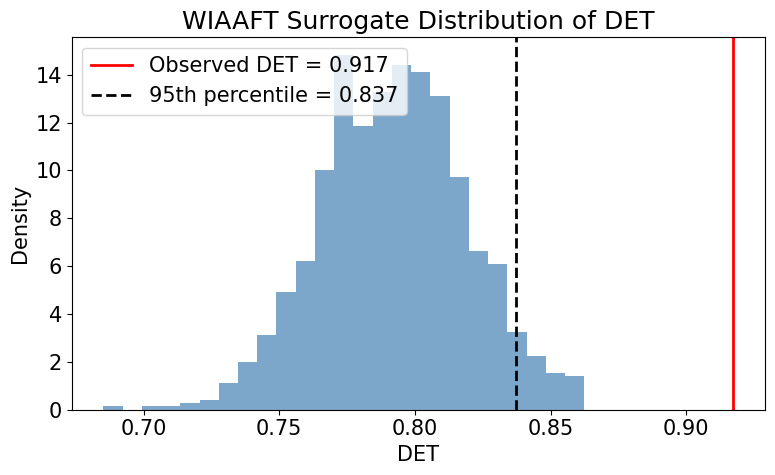

 88%|████████████████████████████████████▉     | 88/100 [40:03<05:37, 28.15s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9174219536734204 
 Recurrence rate: 0.0500093826233815 
Threshold:2.224100000000269 
 Laminarity:0.6468105065650872 
Shannon Entropy:2.419622137281509 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

81
9
Mean Nearest Neighbor Distance: 1.7894559292856254
Pseudo-periodic surrogates generated successfullly


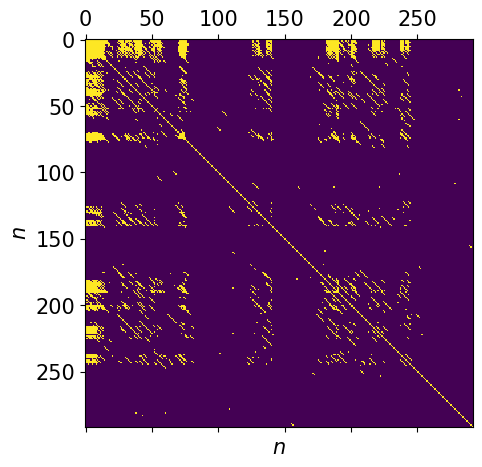

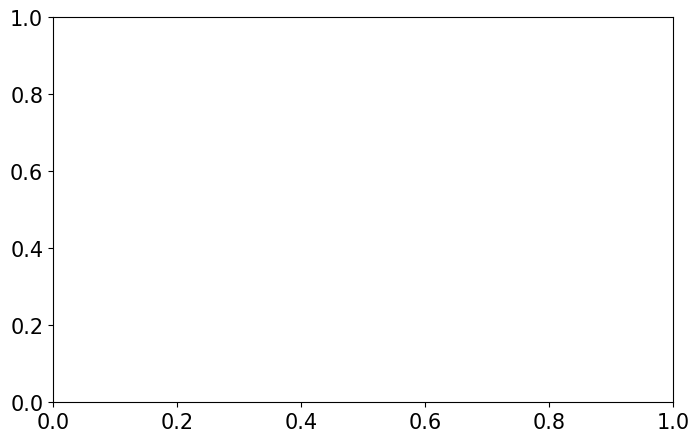

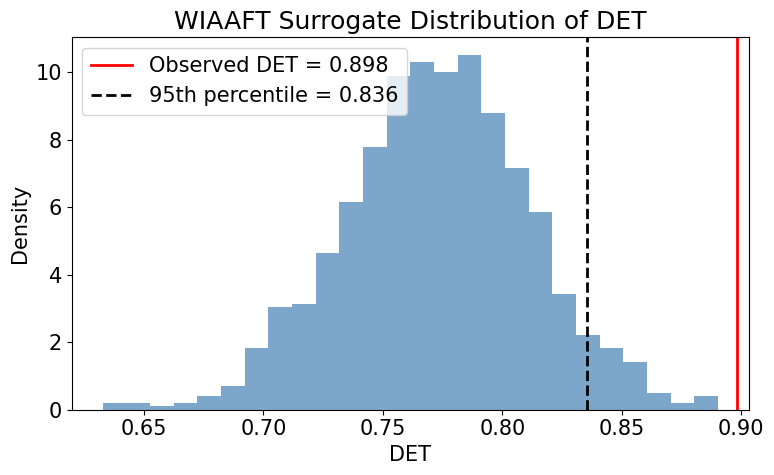

 89%|█████████████████████████████████████▍    | 89/100 [40:34<05:18, 29.00s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8983392048291436 
 Recurrence rate: 0.050032839181835244 
Threshold:2.0180999999998344 
 Laminarity:0.5154711673686933 
Shannon Entropy:2.048543921135092 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

82
10
Mean Nearest Neighbor Distance: 1.988431828056732
Pseudo-periodic surrogates generated successfullly


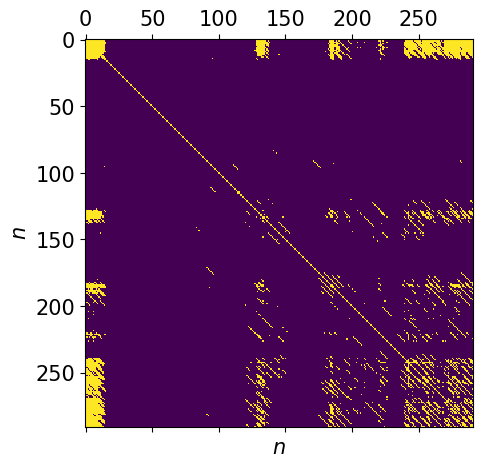

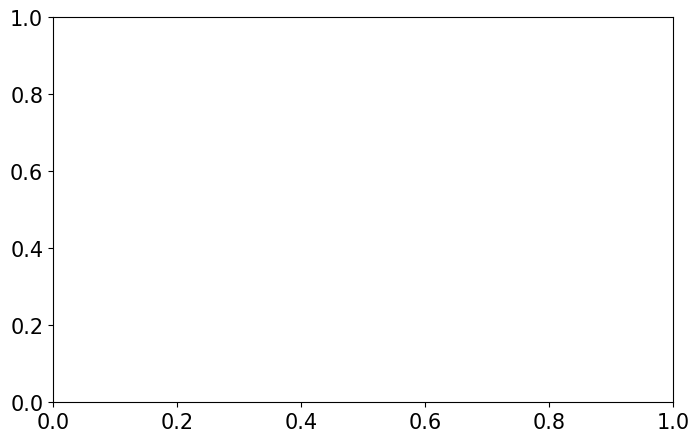

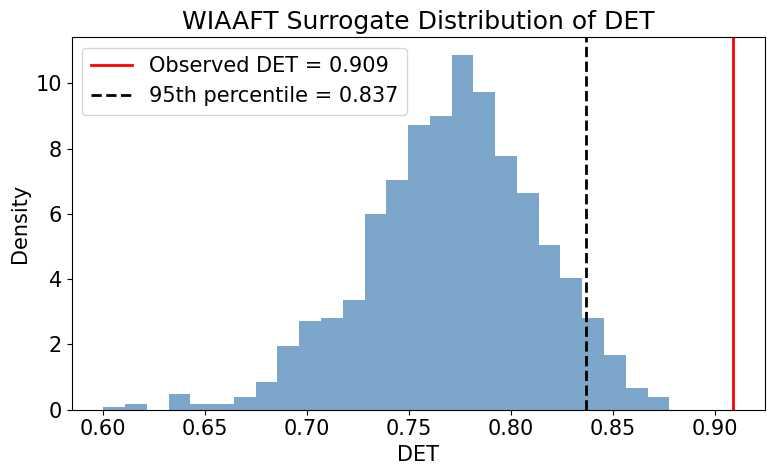

 90%|█████████████████████████████████████▊    | 90/100 [41:07<05:00, 30.04s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.9092292089226439 
 Recurrence rate: 0.050011218573233665 
Threshold:2.1228000000000553 
 Laminarity:0.6011806375428543 
Shannon Entropy:2.356103470650148 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

83
10
Mean Nearest Neighbor Distance: 2.0614280932179447
Pseudo-periodic surrogates generated successfullly


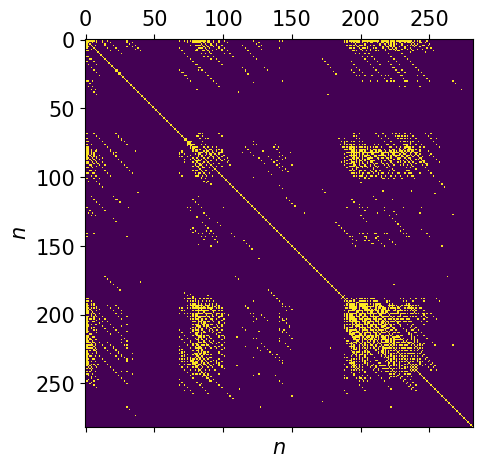

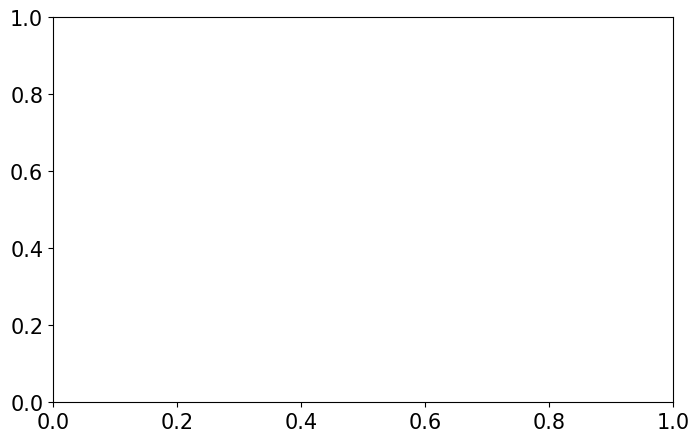

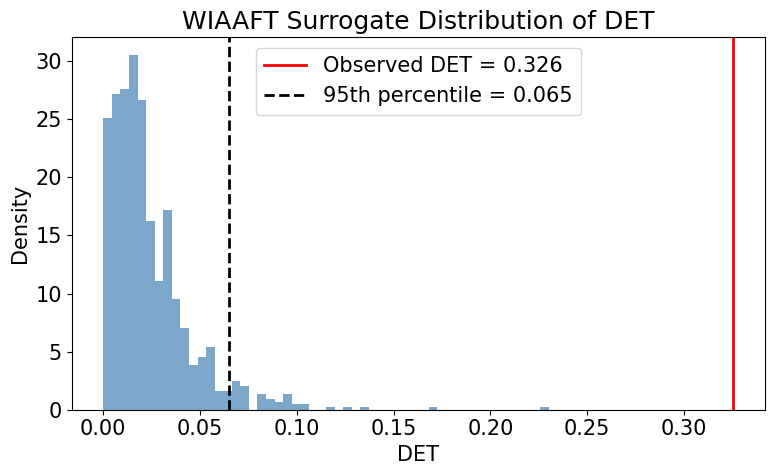

 91%|██████████████████████████████████████▏   | 91/100 [41:40<04:38, 30.95s/it]

RQA  ig Embedding dimensions:10 
 DET of original:0.32558139534795677 
 Recurrence rate: 0.050047784316684274 
Threshold:2.3251000000004822 
 Laminarity:0.42286432160697773 
Shannon Entropy:2.0621060437280896 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

84
8
Mean Nearest Neighbor Distance: 1.61476545338362
Pseudo-periodic surrogates generated successfullly


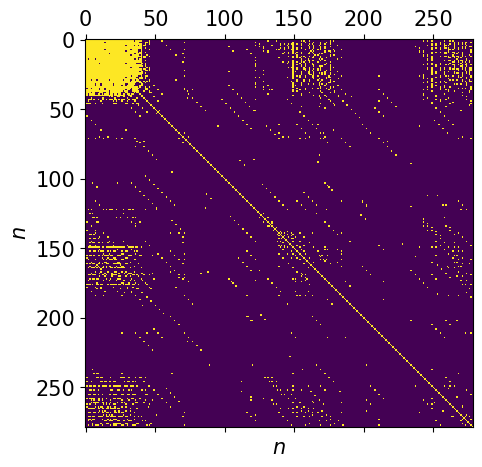

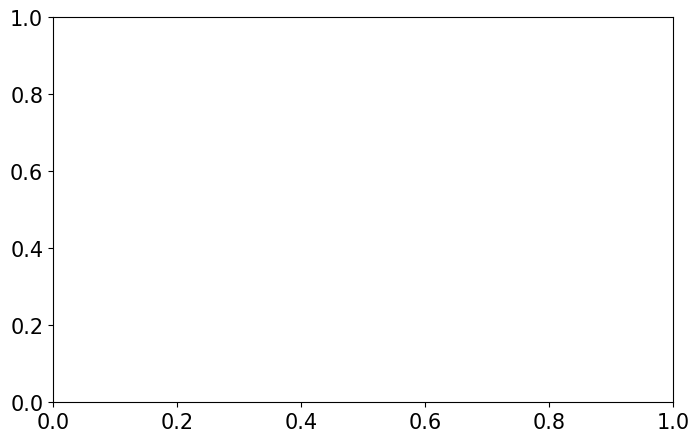

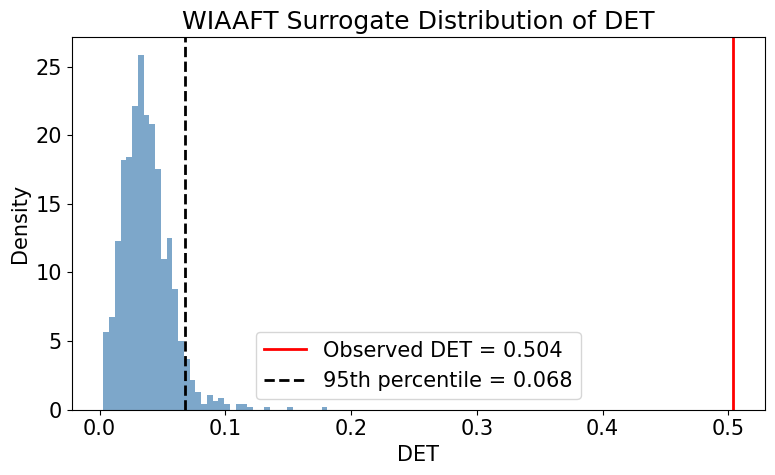

 92%|██████████████████████████████████████▋   | 92/100 [42:07<03:57, 29.73s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.5041505257318646 
 Recurrence rate: 0.050012204365308774 
Threshold:1.9892999999997973 
 Laminarity:0.5345491908540083 
Shannon Entropy:1.4191389057220147 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

85
8
Mean Nearest Neighbor Distance: 1.6233999623998376
Pseudo-periodic surrogates generated successfullly


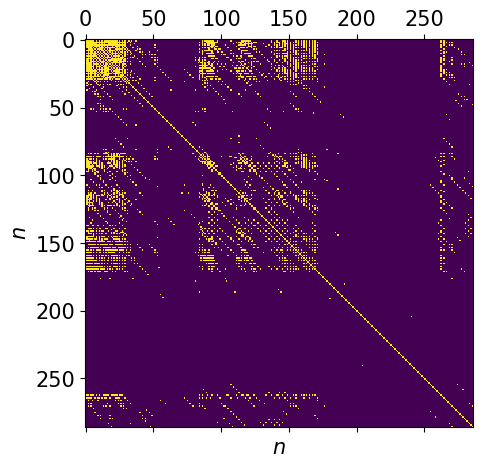

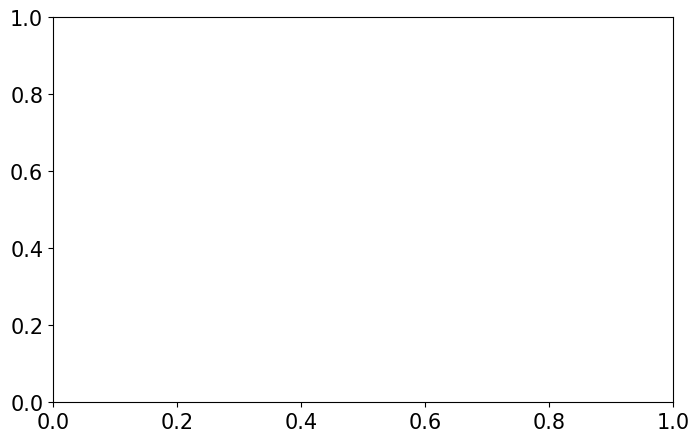

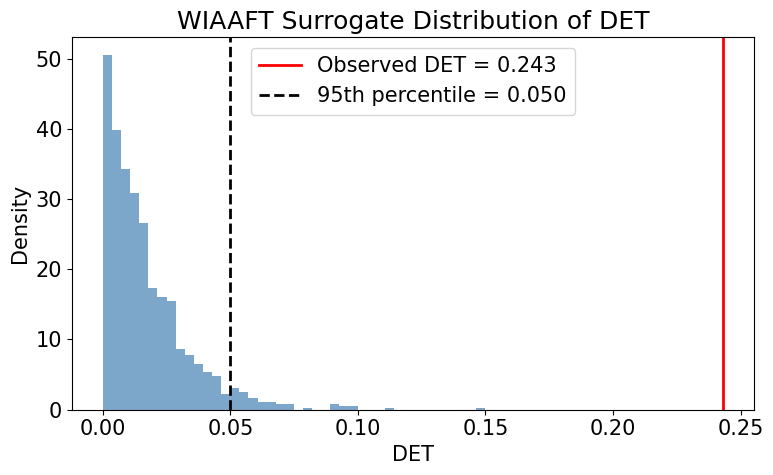

 93%|███████████████████████████████████████   | 93/100 [42:31<03:16, 28.02s/it]

RQA  ig Embedding dimensions:8 
 DET of original:0.24317226890692445 
 Recurrence rate: 0.05005134725414446 
Threshold:1.7081999999998283 
 Laminarity:0.3544211040538485 
Shannon Entropy:2.1607550375568856 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

86
9
Mean Nearest Neighbor Distance: 1.6329215395065073
Pseudo-periodic surrogates generated successfullly


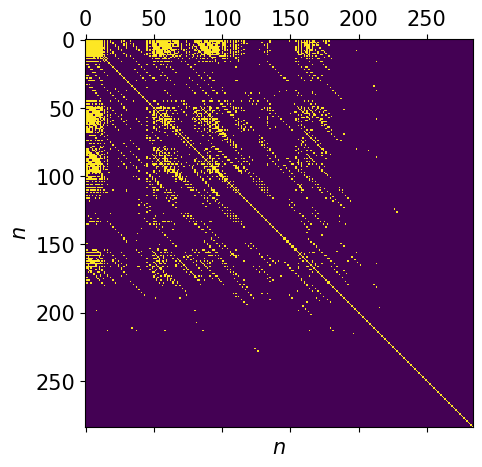

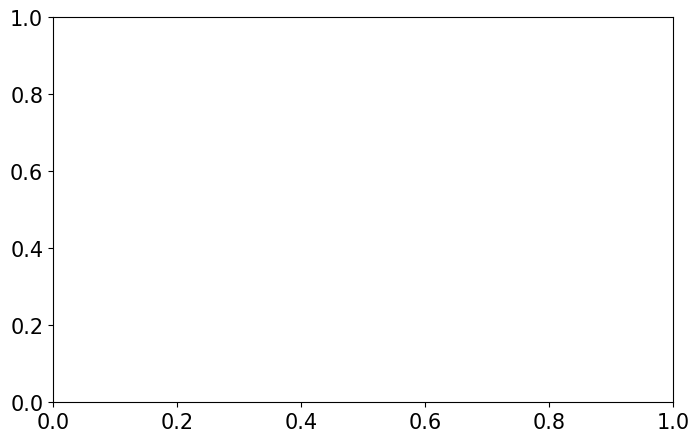

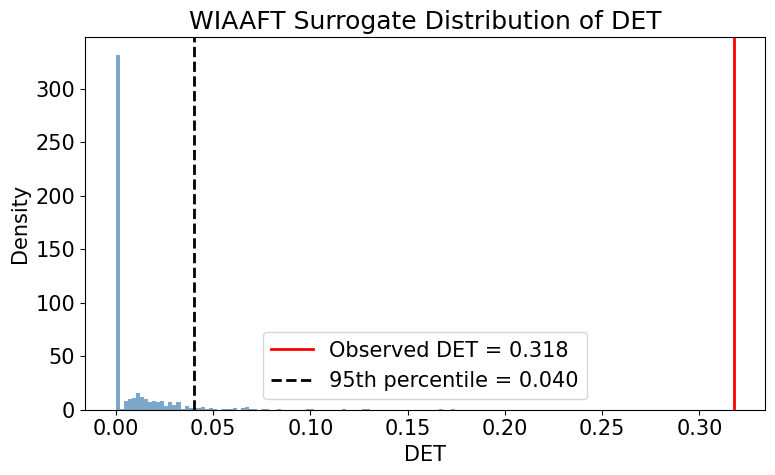

 94%|███████████████████████████████████████▍  | 94/100 [42:52<02:35, 25.88s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.31786666666581903 
 Recurrence rate: 0.050014878000396744 
Threshold:1.3969999999998626 
 Laminarity:0.45116509667711663 
Shannon Entropy:2.3533534647996137 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

87
9
Mean Nearest Neighbor Distance: 1.8226152464869676
Pseudo-periodic surrogates generated successfullly


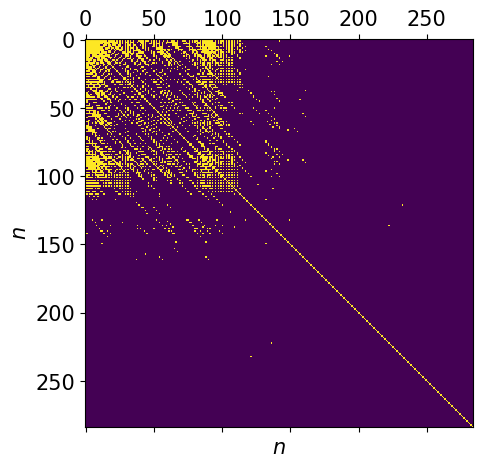

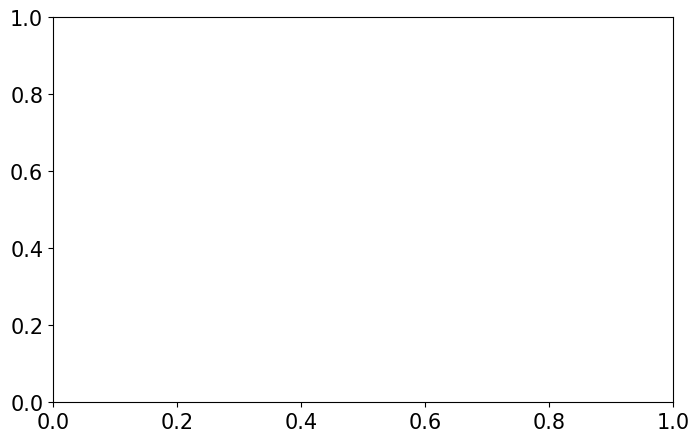

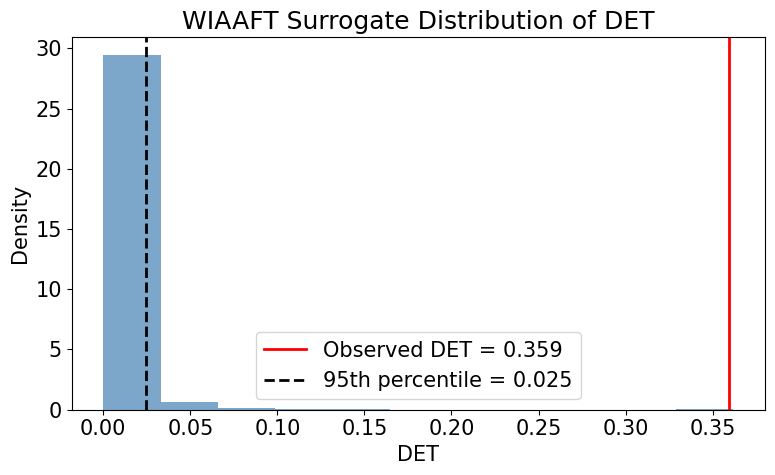

 95%|███████████████████████████████████████▉  | 95/100 [43:13<02:02, 24.59s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.3594666666657081 
 Recurrence rate: 0.050014878000396744 
Threshold:1.446899999999857 
 Laminarity:0.5208230044607813 
Shannon Entropy:2.377064908411592 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

88
9


Not enough points found!


Mean Nearest Neighbor Distance: 1.8225331446335757
Pseudo-periodic surrogates generated successfullly


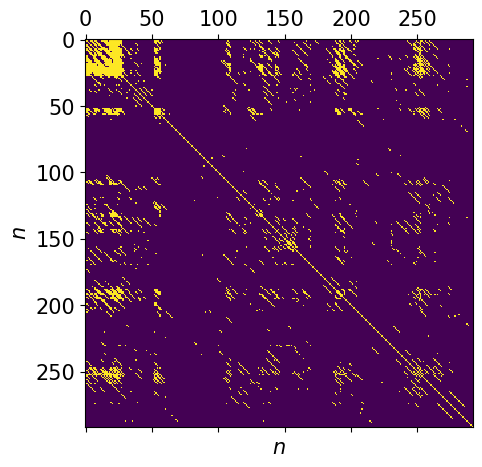

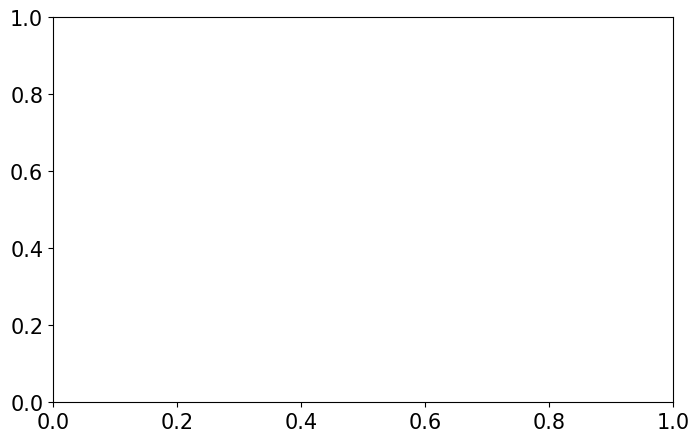

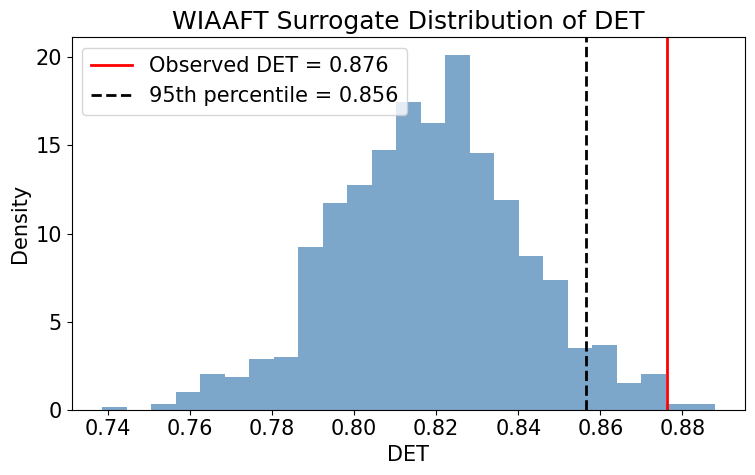

 96%|████████████████████████████████████████▎ | 96/100 [43:47<01:48, 27.19s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.8761329305113894 
 Recurrence rate: 0.0500093826233815 
Threshold:2.407500000000656 
 Laminarity:0.4352720450271218 
Shannon Entropy:2.0859248664496697 
Rank-order p-value (det):0.01 
Reject null (det) hypothesis:True

 
 

89
7


Not enough points found!


Mean Nearest Neighbor Distance: 1.3827992807673
Pseudo-periodic surrogates generated successfullly


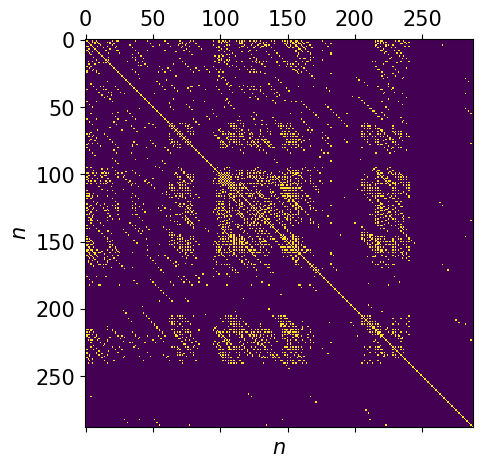

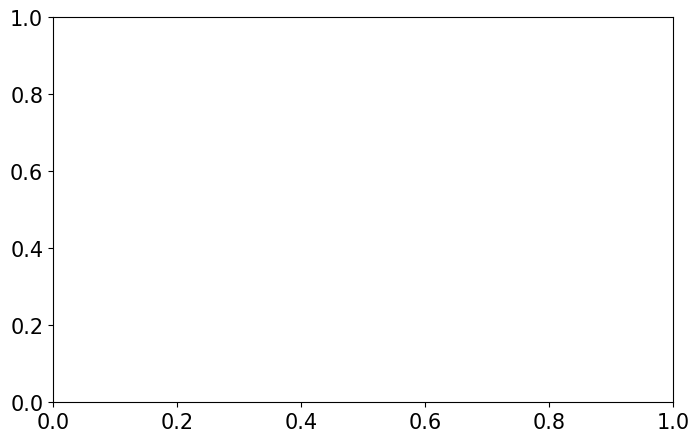

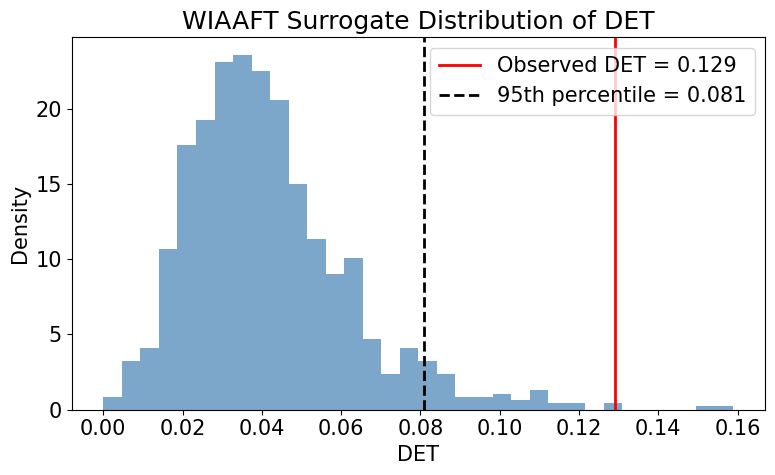

 97%|████████████████████████████████████████▋ | 97/100 [44:11<01:19, 26.41s/it]

RQA  ig Embedding dimensions:7 
 DET of original:0.12901554404111654 
 Recurrence rate: 0.05000964506172839 
Threshold:1.7732999999998211 
 Laminarity:0.16224686595910742 
Shannon Entropy:1.666951592225529 
Rank-order p-value (det):0.01 
Reject null (det) hypothesis:True

 
 

90
9
Mean Nearest Neighbor Distance: 1.7943354596375845
Pseudo-periodic surrogates generated successfullly


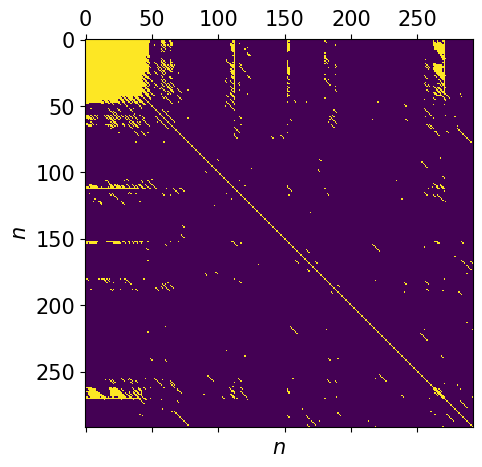

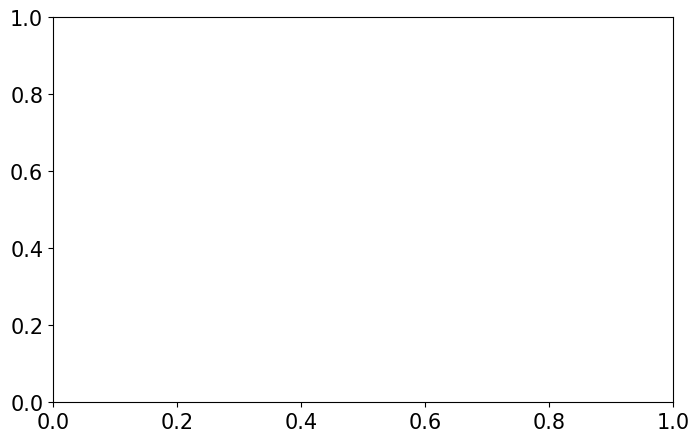

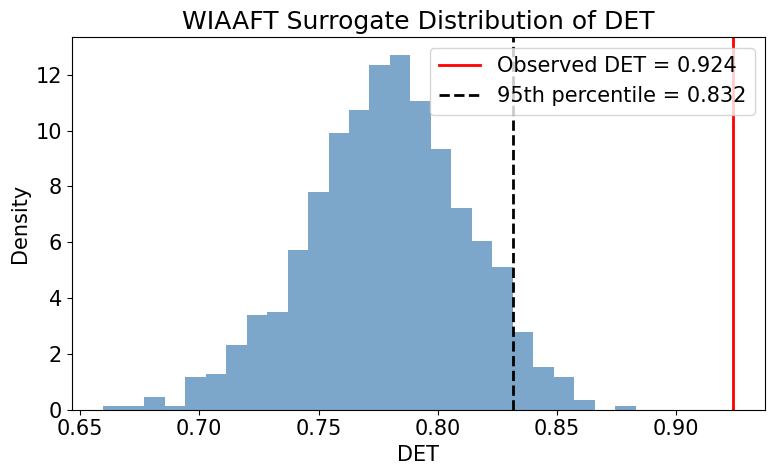

 98%|█████████████████████████████████████████▏| 98/100 [44:42<00:55, 27.60s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.9239677744186204 
 Recurrence rate: 0.0500093826233815 
Threshold:2.137400000000086 
 Laminarity:0.720684803000186 
Shannon Entropy:2.424920723395423 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 

91
6


Not enough points found!


Mean Nearest Neighbor Distance: 1.1381754586900739
Pseudo-periodic surrogates generated successfullly


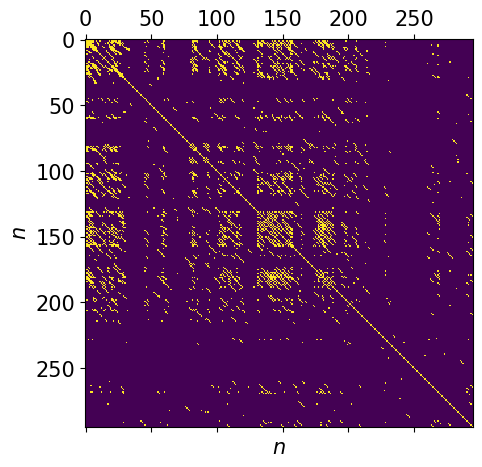

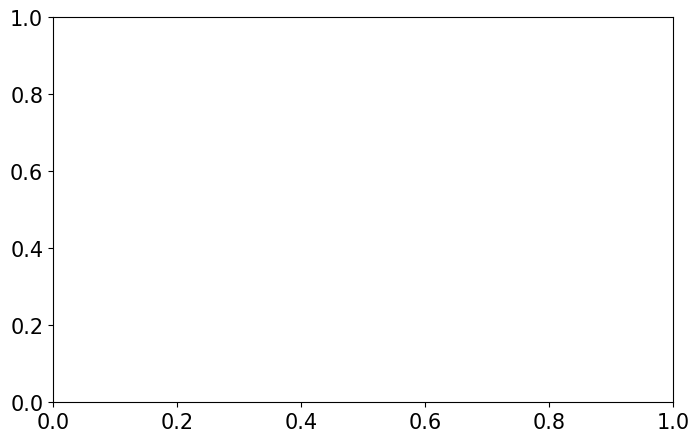

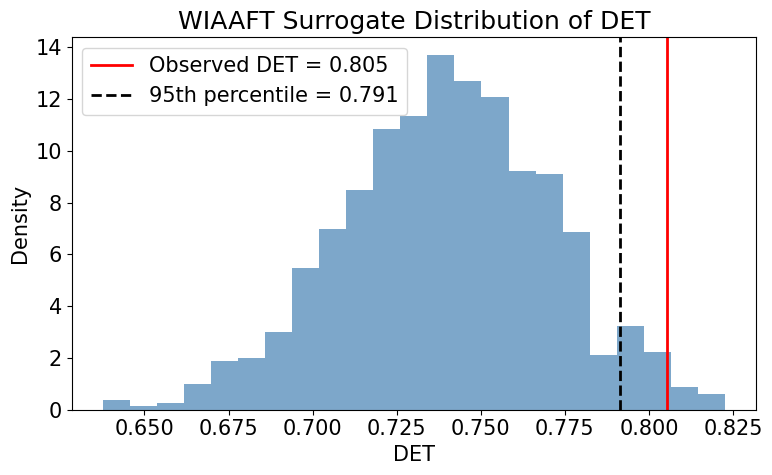

 99%|█████████████████████████████████████████▌| 99/100 [45:04<00:26, 26.11s/it]

RQA  ig Embedding dimensions:6 
 DET of original:0.805322819120736 
 Recurrence rate: 0.05002010916403332 
Threshold:1.538399999999847 
 Laminarity:0.29290144727706663 
Shannon Entropy:1.7085013606910748 
Rank-order p-value (det):0.03 
Reject null (det) hypothesis:True

 
 

92
9


Not enough points found!


Mean Nearest Neighbor Distance: 1.7761277503911412
Pseudo-periodic surrogates generated successfullly


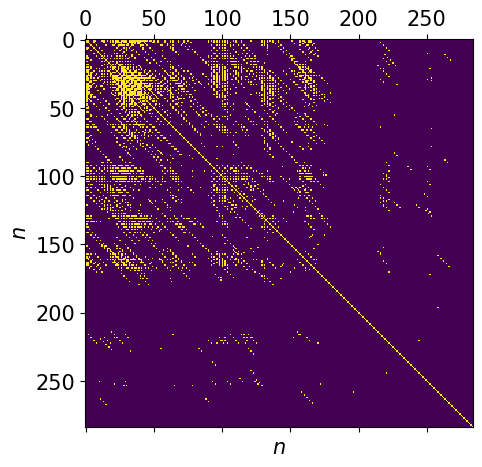

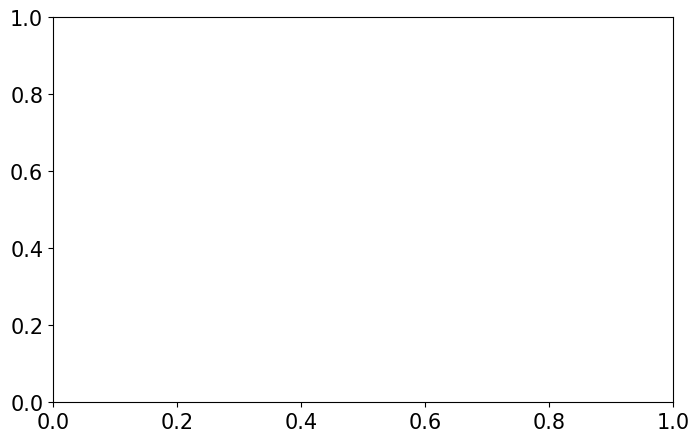

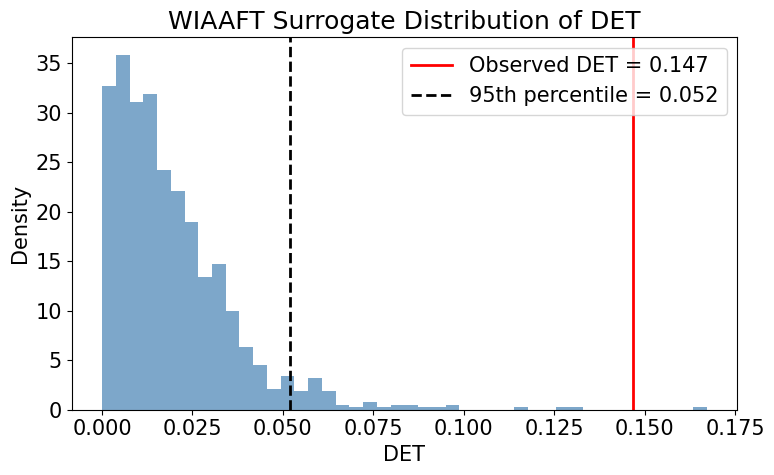

100%|█████████████████████████████████████████| 100/100 [45:32<00:00, 27.33s/it]

RQA  ig Embedding dimensions:9 
 DET of original:0.14666666666627556 
 Recurrence rate: 0.050014878000396744 
Threshold:2.085599999999977 
 Laminarity:0.31011403073795213 
Shannon Entropy:1.8368238381395035 
Rank-order p-value (det):0.004 
Reject null (det) hypothesis:True

 
 

93
rejection rate:0.93


In [12]:
rejection = 0
for e in tqdm(range(0,100)):
    ig(e)
    os.system("./mutual ig -D20 -o files/mutual_ig -V0")
    m_site1 = np.loadtxt("files/mutual_ig", delimiter =' ', usecols =(1) , skiprows=0)
    mn = np.where((m_site1[1:-1] < m_site1[:-2]) & (m_site1[1:-1] < m_site1[2:]))[0] + 1
    if mn.any()>0:
        t_min=mn[0]
    else:
        t_min = np.argmin(m_site1)
    os.system("./false_nearest ig -M1,10 -d{} -o files/ig.fnn -V0".format(t_min))
    res_1 = extract_embedding_dimension("ig")
    dim = res_1['m']
    print(dim)
    k="ig"
    det_j=[]
    embed=[]
    det_surro_ff=[]
    kkk=[]
    lam_j=[]
    ent_j=[]
    lam_surro = []
    ent_surro=[]
    s = lcurve(k)
    tt1=0.001
    dimension=dim
    RR_orig = 0
    while RR_orig < 0.05:
        tt1 = tt1 + 0.0001
        det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
    orig_rp=RecurrencePlot(s, dim=dimension , tau=t_min, metric = "euclidean", threshold=tt1, normalize=True, silence_level = 3)
    det_j.append(det)
    embed.append(dim)
    lam_j.append(lam_orig)
    ent_j.append(entr_orig)
    pylab.matshow(matrix)
    pylab.xlabel("$n$")
    pylab.ylabel("$n$")
    pylab.savefig('test_output/PP/PP_RP_{}.eps'.format(dim), format="eps", dpi=650)
    dist_matrix = orig_rp.euclidean_distance_matrix()
    np.fill_diagonal(dist_matrix, np.inf)
    nearest_neighbor_distances = np.min(dist_matrix, axis=1)
    mean_nn_distance = np.mean(nearest_neighbor_distances)
    print(f"Mean Nearest Neighbor Distance: {mean_nn_distance}")
    noise_rad = 0.7*mean_nn_distance
    subprocess.run(["julia", "PP.jl", str(noise_rad), str(dim), str(t_min), "ig"], text=True, check=True)
    det_ff, lam_ff, entr_ff = sur_test_PP( dim, tt1)
    fig2, axs = plt.subplots(1)
    q95 = np.percentile(det_ff, 95)
    plt.figure(figsize=(8,5))
    plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
    plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
    plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
    plt.xlabel("DET")
    plt.ylabel("Density")
    plt.title("WIAAFT Surrogate Distribution of DET")
    plt.legend()
    plt.tight_layout()
    plt.show()
    fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
    plt.show()
    plt.close() 
    plt.show()
    plt.close()
    r_up = np.sum(det_ff >= det)
    r_down = np.sum(det_ff <= det)
    p_rank = min(1.0, 2.0 * ((min(r_up, r_down) + 1) / (999 + 1)))
    alpha = 0.05
    reject_null1 = p_rank < alpha
    print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
    det_surro_ff.append(det_ff)
    kkk.append(np.full(999, dimension))
    lam_surro.append(lam_ff)
    ent_surro.append(entr_ff)
    if reject_null1 == True:
        rejection = rejection + 1
    print(rejection)


print("rejection rate:{}".format(rejection/(e+1)))

# Lorenz

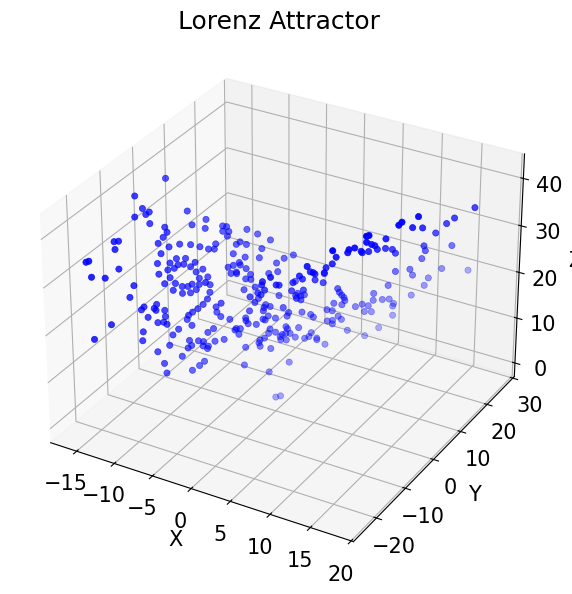

300


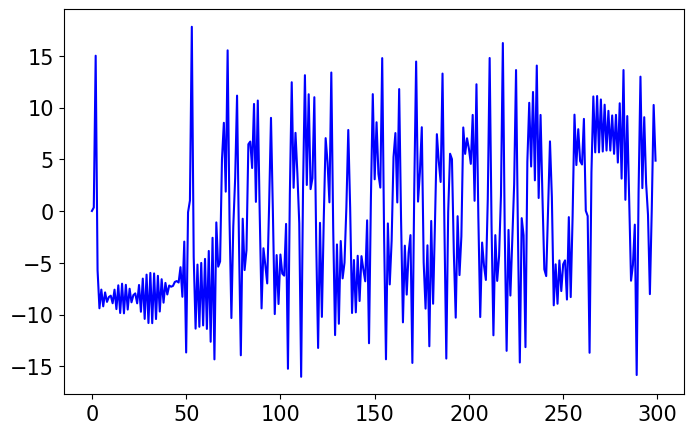

In [12]:
from scipy.integrate import solve_ivp

def lorentz(t, state, s, r, b):
    x, y, z = state
    dxdt = s*(y - x)
    dydt = r*x - y - x*z
    dzdt = x*y - b*z
    return [dxdt, dydt, dzdt]


s=10.0
r=28.0
b=8.0/3.0

# Initial conditions
initial_conditions = [0.01, 0.01, 0.01]

# Time span for the integration
t_span = (0, 100)

# Time points where we want the solution
t_eval = np.linspace(0, 100, 300)

# Solve the system of differential equations
solution = solve_ivp(lorentz, t_span, initial_conditions, t_eval=t_eval, args=(s, r, b))

# Extract the results
x_vals = solution.y[0]
y_vals = solution.y[1]
z_vals = solution.y[2]

# Plot the attractor
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x_vals, y_vals, z_vals, color='blue', lw=0.5)
ax.set_title("Lorenz Attractor")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()
nnn = x_vals
np.savetxt("lorentz", x_vals)
print(len(nnn))
fig2, axs = plt.subplots(1)
axs.plot(nnn, color="blue")
fig2.savefig('lorentz.pdf', format="pdf", dpi=300)

In [13]:
os.system("./mutual lorenz -D20 -o files/mutual_lorenz -V0")
m_site1 = np.loadtxt("files/mutual_lorenz", delimiter =' ', usecols =(1) , skiprows=0)
mn = np.where((m_site1[1:-1] < m_site1[:-2]) & (m_site1[1:-1] < m_site1[2:]))[0] + 1
t_min = mn[0]
os.system("./false_nearest lorenz -M1,10 -d{} -o files/lorenz.fnn -V0".format(t_min))
res_1 = extract_embedding_dimension("lorenz")
dim = res_1['m']
print(res_1['method'])
print(t_min)
print(dim)
    

No saturation detected (minimum FNN fallback)
6
9


WIAAFT surrogate datasets generated


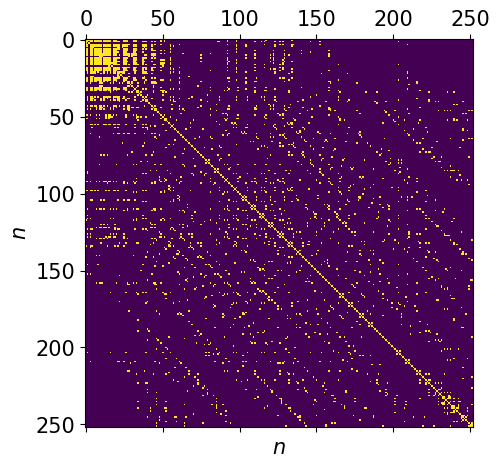

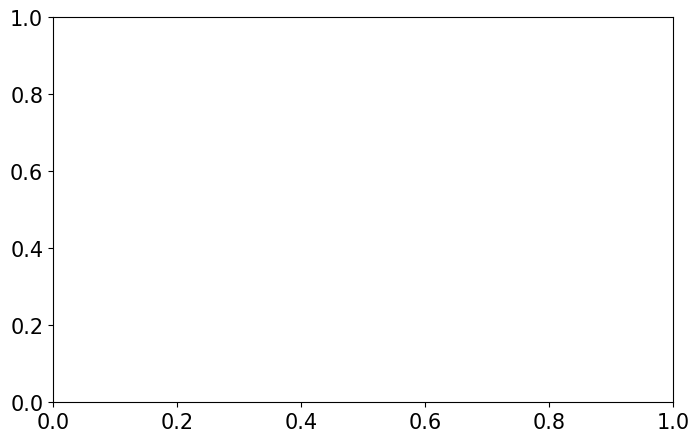

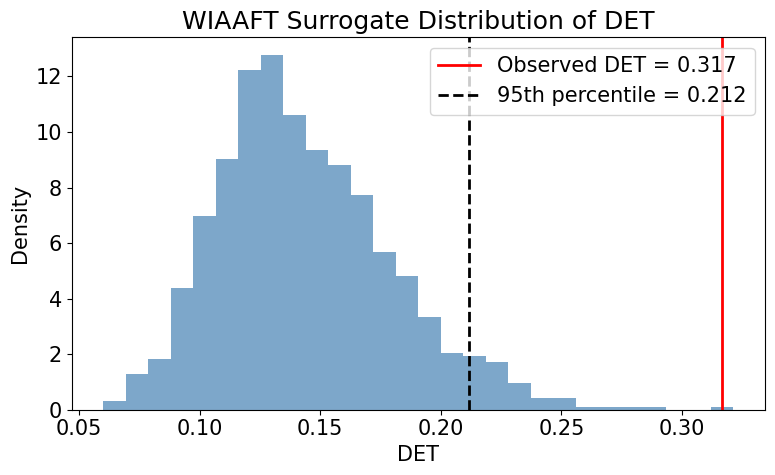

RQA  lorenz Embedding dimensions:9 
 DET of original:0.3166894664831851 
 Recurrence rate: 0.05001259763164525 
Threshold:2.5351000000009254 
 Laminarity:0.2868387909310868 
Shannon Entropy:0.7169428970396614 
Rank-order p-value (det):0.002 
Reject null (det) hypothesis:True

 
 



In [53]:
k="lorenz"
det_j=[]
embed=[]
det_surro_ff=[]
kkk=[]
lam_j=[]
ent_j=[]
lam_surro = []
ent_surro=[]
s = lcurve(k)
subprocess.run(["julia", "WIAAFT_surrogates.jl", "lorenz"], text=True, check=True)
tt1=0.001
dimension=dim
RR_orig = 0
while RR_orig < 0.05:
    tt1 = tt1 + 0.0001
    det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
det_j.append(det)
embed.append(dim)
lam_j.append(lam_orig)
ent_j.append(entr_orig)
pylab.matshow(matrix)
pylab.xlabel("$n$")
pylab.ylabel("$n$")
pylab.savefig('test_output/WIAAFT/WIAAFT_RP_{}.pdf'.format(dim), format="pdf")
det_ff, lam_ff, entr_ff = sur_test_WIAAFT(dim, tt1)
fig2, axs = plt.subplots(1)
q95 = np.percentile(det_ff, 95)
plt.figure(figsize=(8,5))
plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
plt.xlabel("DET")
plt.ylabel("Density")
plt.title("WIAAFT Surrogate Distribution of DET")
plt.legend()
plt.tight_layout()
plt.show()
fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
plt.show()
plt.close()
r = np.sum(det_ff >= det)
p_rank = (r + 1) / (999 + 1)
alpha = 0.05
reject_null1 = p_rank < alpha
print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
det_surro_ff.append(det_ff)
kkk.append(np.full(999, dimension))
lam_surro.append(lam_ff)
ent_surro.append(entr_ff)
    

Mean Nearest Neighbor Distance: 1.5755978218342255
Pseudo-periodic surrogates generated successfullly


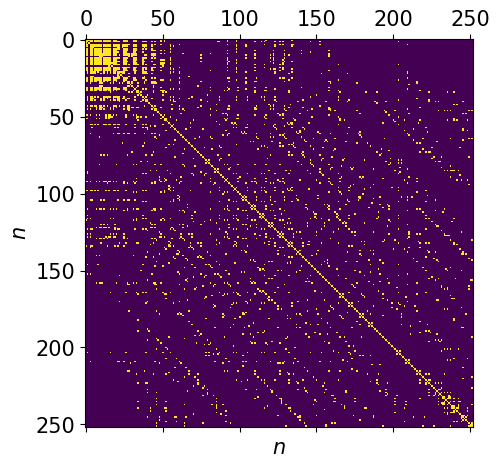

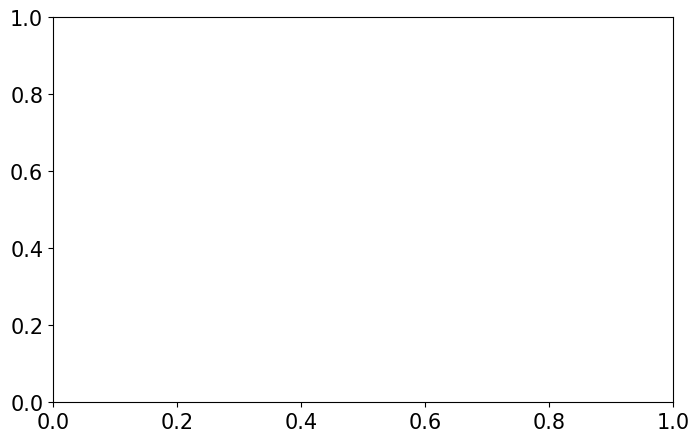

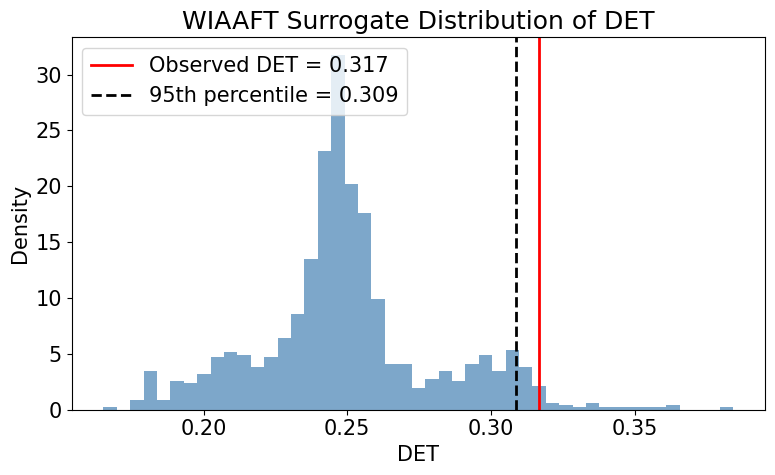

RQA  lorenz Embedding dimensions:9 
 DET of original:0.3166894664831851 
 Recurrence rate: 0.05001259763164525 
Threshold:2.5351000000009254 
 Laminarity:0.2868387909310868 
Shannon Entropy:0.7169428970396614 
Rank-order p-value (det):0.042 
Reject null (det) hypothesis:True

 
 



In [54]:
k="lorenz"
det_j=[]
embed=[]
det_surro_ff=[]
kkk=[]
lam_j=[]
ent_j=[]
lam_surro = []
ent_surro=[]
s = lcurve(k)
tt1=0.001
dimension=dim
RR_orig = 0
while RR_orig < 0.05:
    tt1 = tt1 + 0.0001
    det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
orig_rp=RecurrencePlot(s, dim=dimension , tau=t_min, metric = "euclidean", threshold=tt1, normalize=True, silence_level = 3)
det_j.append(det)
embed.append(dim)
lam_j.append(lam_orig)
ent_j.append(entr_orig)
pylab.matshow(matrix)
pylab.xlabel("$n$")
pylab.ylabel("$n$")
pylab.savefig('test_output/PP/PP_RP_{}.eps'.format(dim), format="eps", dpi=650)
dist_matrix = orig_rp.euclidean_distance_matrix()
np.fill_diagonal(dist_matrix, np.inf)
nearest_neighbor_distances = np.min(dist_matrix, axis=1)
mean_nn_distance = np.mean(nearest_neighbor_distances)
print(f"Mean Nearest Neighbor Distance: {mean_nn_distance}")
noise_rad = 0.7*mean_nn_distance
subprocess.run(["julia", "PP.jl", str(noise_rad), str(dim), str(t_min), "lorenz"], text=True, check=True)
det_ff, lam_ff, entr_ff = sur_test_PP( dim, tt1)
fig2, axs = plt.subplots(1)
q95 = np.percentile(det_ff, 95)
plt.figure(figsize=(8,5))
plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
plt.xlabel("DET")
plt.ylabel("Density")
plt.title("WIAAFT Surrogate Distribution of DET")
plt.legend()
plt.tight_layout()
plt.show()
fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
plt.show()
plt.close() 
plt.show()
plt.close()
r_up = np.sum(det_ff >= det)
r_down = np.sum(det_ff <= det)
p_rank = min(1.0, 2.0 * ((min(r_up, r_down) + 1) / (999 + 1)))
alpha = 0.05
reject_null1 = p_rank < alpha
print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
det_surro_ff.append(det_ff)
kkk.append(np.full(999, dimension))
lam_surro.append(lam_ff)
ent_surro.append(entr_ff)


# Rossler

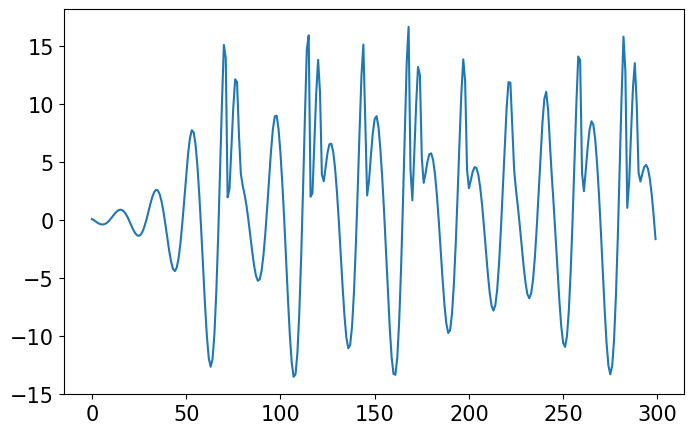

In [14]:
def rossler(t, state, a, b, c):
    x, y, z = state
    dxdt = -y - z
    dydt = x + a*y
    dzdt = b + z*(x - c)
    return [dxdt, dydt, dzdt]

def rossler_create():
# Parameters for the Rössler attractor
    a = 0.38
    b = 2
    c = 9

# Initial conditions
    initial_conditions = [0.1, 0.1, 0.1]

# Time span for the integration
    t_span = (0, 100)

# Time points where we want the solution
    t_eval = np.linspace(0, 100, 300)

# Solve the system of differential equations
    solution = solve_ivp(rossler, t_span, initial_conditions, t_eval=t_eval, args=(a, b, c))

# Extract the results
    x_vals = solution.y[0]
    y_vals = solution.y[1]
    z_vals = solution.y[2]

# Plot the attractor
    #fig = plt.figure(figsize=(10, 7))
    #ax = fig.add_subplot(111, projection='3d')
    #ax.plot(x_vals, y_vals, z_vals, color='blue')
    #ax.set_title("Rössler Attractor")
    #ax.set_xlabel("X")
    #ax.set_ylabel("Y")
    #ax.set_zlabel("Z")
    #plt.show()
    #nnn = (z_vals*z_vals)+(x_vals*x_vals)+(y_vals*y_vals)
    nnn = x_vals
    np.savetxt("rossler", nnn)
    return nnn

nnn = rossler_create()
fig2, axs = plt.subplots(1)
axs.plot(nnn)

In [15]:
os.system("./mutual rossler -D20 -o files/mutual_rossler -V0")
m_site1 = np.loadtxt("files/mutual_rossler", delimiter =' ', usecols =(1) , skiprows=0)
mn = np.where((m_site1[1:-1] < m_site1[:-2]) & (m_site1[1:-1] < m_site1[2:]))[0] + 1
t_min = mn[0]
os.system("./false_nearest rossler -M1,10 -d{} -o files/rossler.fnn -V0".format(t_min))
res_1 = extract_embedding_dimension("rossler")
dim = res_1['m']
print(res_1['method'])
print(t_min)
print(dim)
    

FNN <= 5% with saturation
5
4


WIAAFT surrogate datasets generated


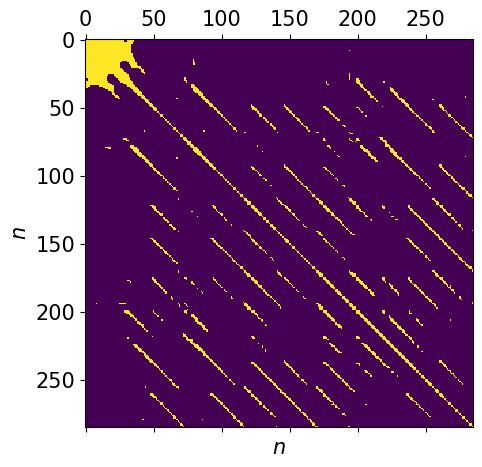

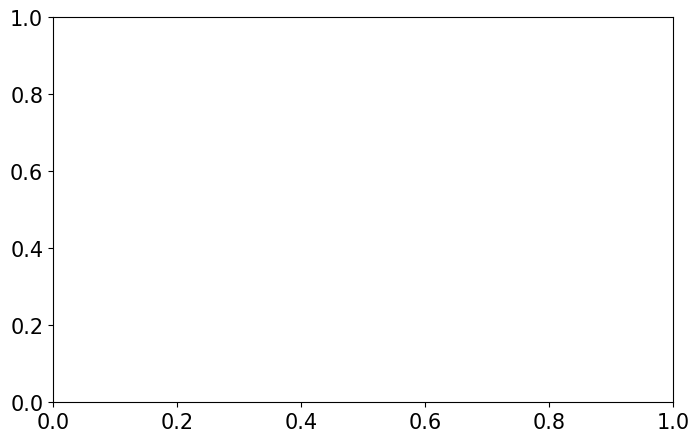

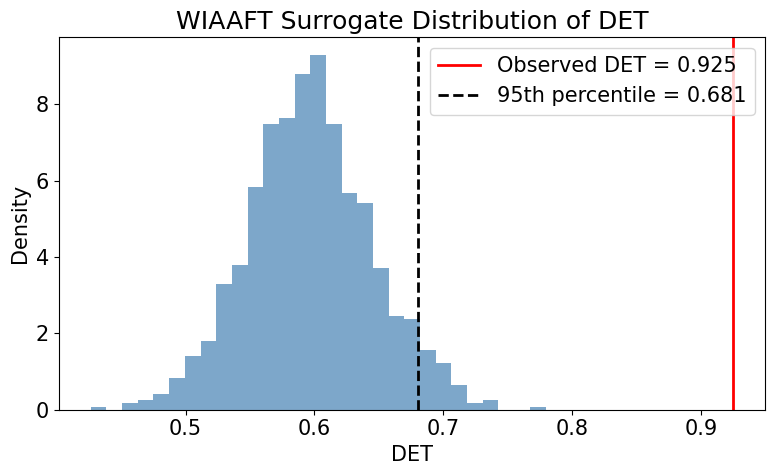

RQA  rossler Embedding dimensions:4 
 DET of original:0.9248279512945347 
 Recurrence rate: 0.05002154509079717 
Threshold:0.8883999999999185 
 Laminarity:0.87472311099957 
Shannon Entropy:2.530516584747737 
Rank-order p-value (det):0.001 
Reject null (det) hypothesis:True

 
 



In [86]:
k="rossler"
det_j=[]
embed=[]
det_surro_ff=[]
kkk=[]
lam_j=[]
ent_j=[]
lam_surro = []
ent_surro=[]
s = lcurve(k)
subprocess.run(["julia", "WIAAFT_surrogates.jl", "rossler"], text=True, check=True)
tt1=0.001
dimension=dim
RR_orig = 0
while RR_orig < 0.05:
    tt1 = tt1 + 0.0001
    det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
det_j.append(det)
embed.append(dim)
lam_j.append(lam_orig)
ent_j.append(entr_orig)
pylab.matshow(matrix)
pylab.xlabel("$n$")
pylab.ylabel("$n$")
pylab.savefig('test_output/WIAAFT/WIAAFT_RP_{}.pdf'.format(dim), format="pdf")
det_ff, lam_ff, entr_ff = sur_test_WIAAFT(dim, tt1)
fig2, axs = plt.subplots(1)
q95 = np.percentile(det_ff, 95)
plt.figure(figsize=(8,5))
plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
plt.xlabel("DET")
plt.ylabel("Density")
plt.title("WIAAFT Surrogate Distribution of DET")
plt.legend()
plt.tight_layout()
plt.show()
fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
plt.show()
plt.close()
r = np.sum(det_ff >= det)
p_rank = (r + 1) / (999 + 1)
alpha = 0.05
reject_null1 = p_rank < alpha
print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
det_surro_ff.append(det_ff)
kkk.append(np.full(999, dimension))
lam_surro.append(lam_ff)
ent_surro.append(entr_ff)
    

Mean Nearest Neighbor Distance: 0.29134333858087097
Pseudo-periodic surrogates generated successfullly


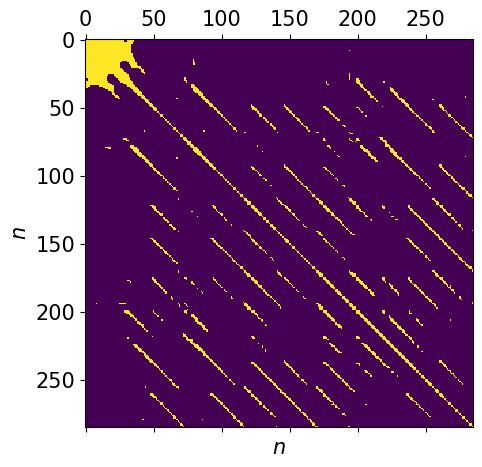

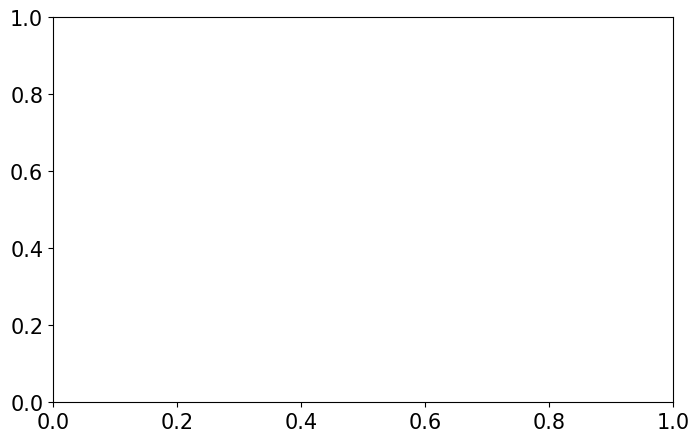

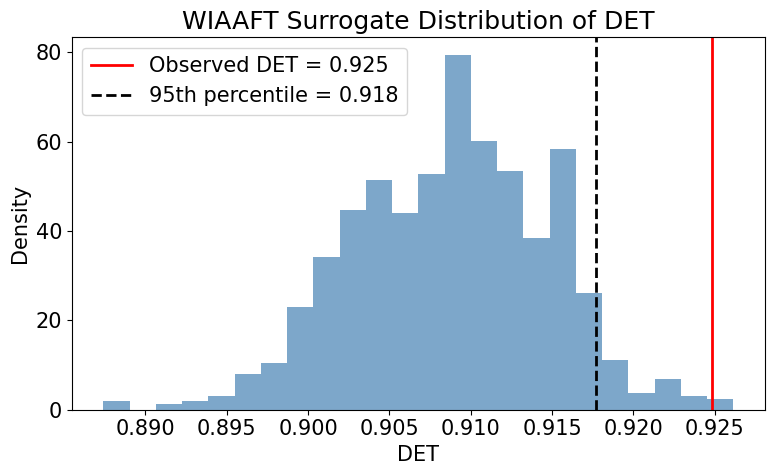

RQA  rossler Embedding dimensions:4 
 DET of original:0.9248279512945347 
 Recurrence rate: 0.05002154509079717 
Threshold:0.8883999999999185 
 Laminarity:0.87472311099957 
Shannon Entropy:2.530516584747737 
Rank-order p-value (det):0.006 
Reject null (det) hypothesis:True

 
 



In [87]:
k="rossler"
det_j=[]
embed=[]
det_surro_ff=[]
kkk=[]
lam_j=[]
ent_j=[]
lam_surro = []
ent_surro=[]
s = lcurve(k)
tt1=0.001
dimension=dim
RR_orig = 0
while RR_orig < 0.05:
    tt1 = tt1 + 0.0001
    det, RR_orig, lam_orig, entr_orig, matrix= RP_RN(s, dim, tt1)
orig_rp=RecurrencePlot(s, dim=dimension , tau=t_min, metric = "euclidean", threshold=tt1, normalize=True, silence_level = 3)
det_j.append(det)
embed.append(dim)
lam_j.append(lam_orig)
ent_j.append(entr_orig)
pylab.matshow(matrix)
pylab.xlabel("$n$")
pylab.ylabel("$n$")
pylab.savefig('test_output/PP/PP_RP_{}.eps'.format(dim), format="eps", dpi=650)
dist_matrix = orig_rp.euclidean_distance_matrix()
np.fill_diagonal(dist_matrix, np.inf)
nearest_neighbor_distances = np.min(dist_matrix, axis=1)
mean_nn_distance = np.mean(nearest_neighbor_distances)
print(f"Mean Nearest Neighbor Distance: {mean_nn_distance}")
noise_rad = 0.7*mean_nn_distance
subprocess.run(["julia", "PP.jl", str(noise_rad), str(dim), str(t_min), "rossler"], text=True, check=True)
det_ff, lam_ff, entr_ff = sur_test_PP( dim, tt1)
fig2, axs = plt.subplots(1)
q95 = np.percentile(det_ff, 95)
plt.figure(figsize=(8,5))
plt.hist(det_ff,bins='auto',density=True,alpha=0.7,color='steelblue')
plt.axvline(det,color='red',linewidth=2,label=f'Observed DET = {det:.3f}')
plt.axvline(q95,color='black',linestyle='--',linewidth=2,label=f'95th percentile = {q95:.3f}')
plt.xlabel("DET")
plt.ylabel("Density")
plt.title("WIAAFT Surrogate Distribution of DET")
plt.legend()
plt.tight_layout()
plt.show()
fig2.savefig('test_output/WIAAFT/surro_{}.eps'.format(dim), format="eps", dpi=650)
plt.show()
plt.close() 
plt.show()
plt.close()
r_up = np.sum(det_ff >= det)
r_down = np.sum(det_ff <= det)
p_rank = min(1.0, 2.0 * ((min(r_up, r_down) + 1) / (999 + 1)))
alpha = 0.05
reject_null1 = p_rank < alpha
print("RQA  {} Embedding dimensions:{} \n" 
                " DET of original:{} \n"
                " Recurrence rate: {} \n" 
                "Threshold:{} \n "
                "Laminarity:{} \n" 
                "Shannon Entropy:{} \n" 
                "Rank-order p-value (det):{} \n"
                "Reject null (det) hypothesis:{}\n"
                "\n \n \n".format(k, dim, det, RR_orig, tt1, lam_orig, entr_orig, 
                                                                  p_rank, reject_null1))
det_surro_ff.append(det_ff)
kkk.append(np.full(999, dimension))
lam_surro.append(lam_ff)
ent_surro.append(entr_ff)
